<div align="center">

# CYPMode

### Predicting how a molecule switches off a liver enzyme, explained from zero

A complete account of the CYPMode project: the biology and chemistry of the problem, the data, the statistics, the machine learning, the quantum-chemical features and the
structure prediction behind an entry to the OpenADMET CYP blind challenge, every experiment that was run (the ones that failed as carefully as the ones that worked), and the
code that ran them.

**Muhammad Talaat**<br>Faculty of Pharmacy, Ain Shams University

</div>

In [1]:
# Run the notebook from the repository root. F holds the numbers quoted in the running text, read from the repository's own files: a sentence such as
# "{{=F.n_train:,}} molecules" is filled in from F when the notebook is built. The show_* helpers put figures, tables and equations into a cell's output.
from pathlib import Path

from notebooks.facts import load
from notebooks.notebook_builder import show_figure, show_markdown, show_math, show_table

ROOT = Path.cwd()
F = load()

## Abstract

Many medicines are removed from the body by a small number of liver enzymes. A molecule that switches one of these enzymes off, and keeps it off, can make other medicines build
up to harmful levels. This notebook explains, starting from nothing, how a computer can be taught to recognise such molecules and to predict how they sit inside the enzyme, and
it documents one complete attempt: the CYPMode project, an entry to the OpenADMET CYP blind challenge.

Two tasks are solved. The first is classification: for each of 750 molecules whose measurements are hidden, say whether it switches off the enzyme CYP3A4, and whether it
switches off the enzyme CYP2D6, in the slow and lasting way called time-dependent inhibition. The second is structure prediction: for 20 molecules, predict where every atom sits
when the molecule is bound inside CYP3A4.

Because the answers stay hidden until the challenge closes, the central difficulty is to judge how good a model is without optimism. The project therefore evaluates every model by
nested cross-validation, in which no choice the model makes (which members to trust, how to blend them, where to put the yes/no threshold) is tested on the data it was chosen on,
and it judges every proposed improvement by a rule written down before its result existed. 187 such rules were judged: 178 ended "not met" and 9
ended "met". The final classification model blends 28 models for CYP3A4 and 23 for CYP2D6, which read 12,468 numbers per molecule. In nested cross-validation it reaches an area under the ROC curve
(a score that is 0.5 for guessing and 1 for a perfect ranking, defined in section 4.10) of 0.817 for CYP3A4 and 0.731 for CYP2D6. These are
estimates made on the training data. The challenge score itself is not known until the challenge closes. The submitted structures number 20, and 0 of them fail the
challenge's physical-validity checks.

The notebook is also a record of what did not work. Every idea that was tried is described with the rule it had to pass, its numbers and the reason it did or did not help, and the
code of the whole project is mapped to the sections that explain it (Appendix D). All numbers in the text are produced by code from the files of the repository when the notebook is
built; none is typed by hand.

## How to read this notebook

- **No background is assumed.** A reader with no chemistry, biology, statistics or machine learning can start at the first page. Each term is defined in bold where it first appears,
  and each equation is built from named pieces, step by step, with a worked example computed in a code cell.
- **Parts build on one another.** Part 0 gives the whole picture on a few pages and points to the section that explains each piece. Parts I to IV teach the biology, the data, the
  chemistry-as-numbers and the machine learning that the later parts use. A reader who already knows a topic can skip to the part that needs it; the table of contents below lists every section.
- **Code cells are real.** Where a code cell appears it runs against the files of this repository when the notebook is built, and a cell that fails stops the build. The cells show
  how a number was obtained; they do not reproduce a multi-hour computation, which is read from the saved results of that computation instead.
- **Figures are the project's own.** Each is drawn by code in `docs/figures/` from the same files, shown here on a dark panel with a caption that says what it shows and where its
  data come from.
- **Failures are part of the text.** An experiment that did not pass its gate is explained as carefully as one that did. Where a part of the code does less than its name suggests,
  a paragraph headed "On what actually ran" says so.
- **Every idea has an origin.** Where a method or formula comes from other people's work, the text says whose and cites it (Appendix C). Where an idea is this project's own, the text
  says that too and shows the evidence.
- **Conventions.** Names of files, modules and functions are written `like this`. A **bold** word is defined at that point. Symbols are introduced where they are first needed and
  collected in Appendix B. Section numbers refer to sections of this notebook.

## Table of contents

<div class="toc-part">

- [Abstract](#Abstract)
- [How to read this notebook](#How-to-read-this-notebook)

</div>

<div class="toc-part">

**[Part 0: Orientation](#Part-0:-Orientation)**

- [0.1 The problem: medicines in the body and why their interactions matter](#0.1-The-problem:-medicines-in-the-body-and-why-their-interactions-matter)
- [0.2 How this project grew](#0.2-How-this-project-grew)
- [0.3 The challenge](#0.3-The-challenge)
- [0.4 The whole system on two pages](#0.4-The-whole-system-on-two-pages)
- [0.5 The ledger in one table](#0.5-The-ledger-in-one-table)
- [0.6 How this notebook is built and how to run it](#0.6-How-this-notebook-is-built-and-how-to-run-it)
- [0.7 What the work adds, claim by claim](#0.7-What-the-work-adds,-claim-by-claim)

</div>

<div class="toc-part">

**[Part I: Biology and chemistry](#Part-I:-Biology-and-chemistry)**

- [1.1 Drugs in the body: how fast a drug leaves](#1.1-Drugs-in-the-body:-how-fast-a-drug-leaves)
- [1.2 Enzymes: what a catalyst does, and the Michaelis-Menten equation](#1.2-Enzymes:-what-a-catalyst-does,-and-the-Michaelis-Menten-equation)
- [1.3 Cytochrome P450: the heme, the iron and the catalytic cycle](#1.3-Cytochrome-P450:-the-heme,-the-iron-and-the-catalytic-cycle)
- [1.4 Drug-drug interactions and why inhibition matters clinically](#1.4-Drug-drug-interactions-and-why-inhibition-matters-clinically)
- [1.5 Reversible inhibition: competitive, non-competitive and mixed](#1.5-Reversible-inhibition:-competitive,-non-competitive-and-mixed)
- [1.6 Time-dependent inhibition: the kinetics of switching an enzyme off](#1.6-Time-dependent-inhibition:-the-kinetics-of-switching-an-enzyme-off)
- [1.7 How potency is measured: dose-response, the Hill equation, the IC50 and the pIC50 scale](#1.7-How-potency-is-measured:-dose-response,-the-Hill-equation,-the-IC50-and-the-pIC50-scale)
- [1.8 The two assay arms of the challenge and the shift between them](#1.8-The-two-assay-arms-of-the-challenge-and-the-shift-between-them)
- [1.9 Heme chemistry: Type I and Type II binding, and why a nitrogen binds the iron](#1.9-Heme-chemistry:-Type-I-and-Type-II-binding,-and-why-a-nitrogen-binds-the-iron)
- [1.10 Reactive metabolites and structural alerts](#1.10-Reactive-metabolites-and-structural-alerts)

</div>

<div class="toc-part">

**[Part II. The data](#Part-II.-The-data)**

- [2.1 A molecule as text and as a graph](#2.1-A-molecule-as-text-and-as-a-graph)
- [2.2 The training and blinded test files, column by column](#2.2-The-training-and-blinded-test-files,-column-by-column)
- [2.3 The label rule: how $s = t - \max(d, 4) > \log_{10} 2$ was recovered and checked](#2.3-The-label-rule:-how-s-t-max-d-4-log-10-2-was-recovered-and-checked)
- [2.4 The contamination found in the labels](#2.4-The-contamination-found-in-the-labels)
- [2.5 Measurement noise: the standard deviation, the confidence limits and the confidence $z$](#2.5-Measurement-noise:-the-standard-deviation,-the-confidence-limits-and-the-confidence-z)
- [2.6 Which compounds were measured on which enzyme: blocks and selection](#2.6-Which-compounds-were-measured-on-which-enzyme:-blocks-and-selection)
- [2.7 How the test set differs from the training set](#2.7-How-the-test-set-differs-from-the-training-set)
- [2.8 Other data sources: what exists, what each one measures, and how it differs](#2.8-Other-data-sources:-what-exists,-what-each-one-measures,-and-how-it-differs)
- [2.9 Standardising structures: when two strings are the same compound](#2.9-Standardising-structures:-when-two-strings-are-the-same-compound)
- [2.10 The public leaderboard as data: the positive rate of the scored set](#2.10-The-public-leaderboard-as-data:-the-positive-rate-of-the-scored-set)
- [2.11 A check of the positive rate that reads no board](#2.11-A-check-of-the-positive-rate-that-reads-no-board)

</div>

<div class="toc-part">

**[Part III. Molecules as numbers](#Part-III.-Molecules-as-numbers)**

- [3.1 Morgan (circular) fingerprints](#3.1-Morgan-(circular)-fingerprints)
- [3.2 Tanimoto similarity and why it suits fingerprints](#3.2-Tanimoto-similarity-and-why-it-suits-fingerprints)
- [3.3 Descriptors: a molecule as a few dozen physical quantities](#3.3-Descriptors:-a-molecule-as-a-few-dozen-physical-quantities)
- [3.4 The other fingerprint and descriptor blocks](#3.4-The-other-fingerprint-and-descriptor-blocks)
- [3.5 Three-point pharmacophore fingerprints](#3.5-Three-point-pharmacophore-fingerprints)
- [3.6 Chemical series, scaffolds and clusters](#3.6-Chemical-series,-scaffolds-and-clusters)
- [3.7 The feature store: all the blocks, computed once](#3.7-The-feature-store:-all-the-blocks,-computed-once)

</div>

<div class="toc-part">

**[Part IV. Machine learning from zero](#Part-IV.-Machine-learning-from-zero)**

- [4.1 Supervised learning, loss functions and the problem of generalisation](#4.1-Supervised-learning,-loss-functions-and-the-problem-of-generalisation)
- [4.2 Decision trees: impurity, and the search for the best question](#4.2-Decision-trees:-impurity,-and-the-search-for-the-best-question)
- [4.3 Gradient boosting: many small trees, each correcting the others](#4.3-Gradient-boosting:-many-small-trees,-each-correcting-the-others)
- [4.4 Random forests and extremely randomised trees: averaging many trees](#4.4-Random-forests-and-extremely-randomised-trees:-averaging-many-trees)
- [4.5 Nearest neighbours and support vector machines with the Tanimoto kernel](#4.5-Nearest-neighbours-and-support-vector-machines-with-the-Tanimoto-kernel)
- [4.6 Regression for the two assay arms, and floor-clipping](#4.6-Regression-for-the-two-assay-arms,-and-floor-clipping)
- [4.7 Neural networks: the perceptron, backpropagation and shared-trunk networks for several tasks](#4.7-Neural-networks:-the-perceptron,-backpropagation-and-shared-trunk-networks-for-several-tasks)
- [4.8 Message-passing networks on molecular graphs, and networks on text](#4.8-Message-passing-networks-on-molecular-graphs,-and-networks-on-text)
- [4.9 Principal component analysis, and tabular in-context learning](#4.9-Principal-component-analysis,-and-tabular-in-context-learning)
- [4.10 Metrics: how a model is judged](#4.10-Metrics:-how-a-model-is-judged)

</div>

<div class="toc-part">

**[Part V. The Type II motif screen](#Part-V.-The-Type-II-motif-screen)**

- [5.1 The idea: a nitrogen that can bind the iron, written as a pattern](#5.1-The-idea:-a-nitrogen-that-can-bind-the-iron,-written-as-a-pattern)
- [5.2 The trialkylamine alert, and the false positives it had to exclude](#5.2-The-trialkylamine-alert,-and-the-false-positives-it-had-to-exclude)
- [5.3 The panel data, and how a yes-or-no flag is compared with a yes-or-no label](#5.3-The-panel-data,-and-how-a-yes-or-no-flag-is-compared-with-a-yes-or-no-label)
- [5.4 Testing the screen against real potency: the Octant screen and the rank test](#5.4-Testing-the-screen-against-real-potency:-the-Octant-screen-and-the-rank-test)
- [5.5 Checking the screen against predicted structures: the distance from the iron to the nitrogen](#5.5-Checking-the-screen-against-predicted-structures:-the-distance-from-the-iron-to-the-nitrogen)
- [5.6 Pocket geometry from a predicted structure: how buried the molecule is and how much room is left](#5.6-Pocket-geometry-from-a-predicted-structure:-how-buried-the-molecule-is-and-how-much-room-is-left)
- [5.7 Cross-checking the screen against time-dependent shift measurements](#5.7-Cross-checking-the-screen-against-time-dependent-shift-measurements)
- [5.8 The Streamlit application and its figures](#5.8-The-Streamlit-application-and-its-figures)

</div>

<div class="toc-part">

**[Part VI. Measuring without selection bias](#Part-VI.-Measuring-without-selection-bias)**

- [6.1 Why a score on the training data lies](#6.1-Why-a-score-on-the-training-data-lies)
- [6.2 Cross-validation, and what happens to its score when it is also used to choose](#6.2-Cross-validation,-and-what-happens-to-its-score-when-it-is-also-used-to-choose)
- [6.3 Nested cross-validation: the construction, every loop, what is fitted where](#6.3-Nested-cross-validation:-the-construction,-every-loop,-what-is-fitted-where)
- [6.4 Making validation resemble the test: similarity, prevalence and confident labels](#6.4-Making-validation-resemble-the-test:-similarity,-prevalence-and-confident-labels)
- [6.5 Comparing two models: why folds are correlated, and the corrected resampled t](#6.5-Comparing-two-models:-why-folds-are-correlated,-and-the-corrected-resampled-t)
- [6.6 Why Tukey's HSD was dropped, and how the older results were recomputed](#6.6-Why-Tukey's-HSD-was-dropped,-and-how-the-older-results-were-recomputed)
- [6.7 Pre-declared gates: the rule, the floor of the design, and the replicate](#6.7-Pre-declared-gates:-the-rule,-the-floor-of-the-design,-and-the-replicate)
- [6.8 Checking that a split is informative, the test-like hold-out, and the leakage controls](#6.8-Checking-that-a-split-is-informative,-the-test-like-hold-out,-and-the-leakage-controls)

</div>

<div class="toc-part">

**[Part VII. The first TDI models and what they taught](#Part-VII.-The-first-TDI-models-and-what-they-taught)**

- [7.1 Reproducing the challenge's baseline from the raw file](#7.1-Reproducing-the-challenge's-baseline-from-the-raw-file)
- [7.2 The staircase M0 to M3: adding one block of features at a time](#7.2-The-staircase-M0-to-M3:-adding-one-block-of-features-at-a-time)
- [7.3 Reading across: the labels of a compound's nearest neighbours](#7.3-Reading-across:-the-labels-of-a-compound's-nearest-neighbours)
- [7.4 The direct-inhibition bridge: a gain that was a shortcut](#7.4-The-direct-inhibition-bridge:-a-gain-that-was-a-shortcut)
- [7.5 The decision threshold, the positive rate, and a first reliability score](#7.5-The-decision-threshold,-the-positive-rate,-and-a-first-reliability-score)
- [7.6 Uncertainty by committee, tested against real mistakes](#7.6-Uncertainty-by-committee,-tested-against-real-mistakes)
- [7.7 Outside data as an auxiliary signal: PubChem, BindingDB, ChEMBL and the cytochrome panel](#7.7-Outside-data-as-an-auxiliary-signal:-PubChem,-BindingDB,-ChEMBL-and-the-cytochrome-panel)
- [7.8 Electrons and pharmacophores: the quantum-chemical features and the three-point fingerprint](#7.8-Electrons-and-pharmacophores:-the-quantum-chemical-features-and-the-three-point-fingerprint)
- [7.9 Learned representations: ChemBERTa embeddings and a shared-trunk network](#7.9-Learned-representations:-ChemBERTa-embeddings-and-a-shared-trunk-network)
- [7.10 Does a predicted structure help a classifier? Boltz-2 for fifty compounds](#7.10-Does-a-predicted-structure-help-a-classifier?-Boltz-2-for-fifty-compounds)
- [7.11 The first assembled models, the architecture test, and the decision to build the nested evaluation](#7.11-The-first-assembled-models,-the-architecture-test,-and-the-decision-to-build-the-nested-evaluation)

</div>

<div class="toc-part">

**[Part VIII. The final TDI model](#Part-VIII.-The-final-TDI-model)**

- [8.1 The candidate grid: 23 members and their feature sets](#8.1-The-candidate-grid:-23-members-and-their-feature-sets)
- [8.2 The stack: a logistic blend of the members, with its penalty chosen inside](#8.2-The-stack:-a-logistic-blend-of-the-members,-with-its-penalty-chosen-inside)
- [8.3 A reproducibility bug in the stack: a solver that stops where it happens to be](#8.3-A-reproducibility-bug-in-the-stack:-a-solver-that-stops-where-it-happens-to-be)
- [8.4 Turning scores into calls: a smoothed threshold, a share of calls, and a multiple](#8.4-Turning-scores-into-calls:-a-smoothed-threshold,-a-share-of-calls,-and-a-multiple)
- [8.5 Calibration: from a score to a probability](#8.5-Calibration:-from-a-score-to-a-probability)
- [8.6 The candidate files, the checks they pass, and the manifest](#8.6-The-candidate-files,-the-checks-they-pass,-and-the-manifest)
- [8.7 Results with their uncertainty](#8.7-Results-with-their-uncertainty)

</div>

<div class="toc-part">

**[Part IX. Additions that were tested](#Part-IX.-Additions-that-were-tested)**

- [9.1 The selection-aware CYP2D6 model: when the training labels come from a filtered population](#9.1-The-selection-aware-CYP2D6-model:-when-the-training-labels-come-from-a-filtered-population)
- [9.2 Making SAR explicit: pair models and compounds that differ by one change](#9.2-Making-SAR-explicit:-pair-models-and-compounds-that-differ-by-one-change)
- [9.3 The label as a threshold of two noisy numbers: a committee that outputs a probability](#9.3-The-label-as-a-threshold-of-two-noisy-numbers:-a-committee-that-outputs-a-probability)
- [9.4 A frozen foundation model: CheMeleon embeddings](#9.4-A-frozen-foundation-model:-CheMeleon-embeddings)
- [9.5 Test-likeness weighting: importance weights from structures alone](#9.5-Test-likeness-weighting:-importance-weights-from-structures-alone)
- [9.6 Floor-clipped arms: not spending capacity below the assay floor](#9.6-Floor-clipped-arms:-not-spending-capacity-below-the-assay-floor)
- [9.7 Cross-isoform transfer of the assay arms](#9.7-Cross-isoform-transfer-of-the-assay-arms)
- [9.8 Training on label confidence](#9.8-Training-on-label-confidence)
- [9.9 The neural pair: a multitask network and plain Chemprop](#9.9-The-neural-pair:-a-multitask-network-and-plain-Chemprop)
- [9.10 The other additions, tested the same way](#9.10-The-other-additions,-tested-the-same-way)
- [9.11 The ledger of the gates, and what the correction for the number of attempts leaves](#9.11-The-ledger-of-the-gates,-and-what-the-correction-for-the-number-of-attempts-leaves)
- [9.12 Why the ideas that did not join added nothing](#9.12-Why-the-ideas-that-did-not-join-added-nothing)
- [9.13 The compound relative to the pocket](#9.13-The-compound-relative-to-the-pocket)
- [9.14 Pharmacophore models: sites from the pocket, hypotheses from the ligands](#9.14-Pharmacophore-models:-sites-from-the-pocket,-hypotheses-from-the-ligands)
- [9.15 Reading the pharmacophore on molecules: functional groups, structure-activity relationships and the pocket, in 2D and in 3D](#9.15-Reading-the-pharmacophore-on-molecules:-functional-groups,-structure-activity-relationships-and-the-pocket,-in-2D-and-in-3D)

</div>

<div class="toc-part">

**[Part X. Quantum chemistry and the physics features](#Part-X.-Quantum-chemistry-and-the-physics-features)**

- [10.1 The Schrödinger equation, the wavefunction and the Born-Oppenheimer approximation](#10.1-The-Schrödinger-equation,-the-wavefunction-and-the-Born-Oppenheimer-approximation)
- [10.2 Hartree-Fock, the self-consistent field and basis sets](#10.2-Hartree-Fock,-the-self-consistent-field-and-basis-sets)
- [10.3 Density functional theory](#10.3-Density-functional-theory)
- [10.4 Semi-empirical and tight-binding methods: the energy of GFN2-xTB](#10.4-Semi-empirical-and-tight-binding-methods:-the-energy-of-GFN2-xTB)
- [10.5 The quantities of the physics block](#10.5-The-quantities-of-the-physics-block)
- [10.6 The physics block in the models: four levels, two refinements, and why none passed](#10.6-The-physics-block-in-the-models:-four-levels,-two-refinements,-and-why-none-passed)

</div>

<div class="toc-part">

**[Part XI. The structure track](#Part-XI.-The-structure-track)**

- [11.1 Proteins, folding and the structure of CYP3A4; what a complex file contains](#11.1-Proteins,-folding-and-the-structure-of-CYP3A4;-what-a-complex-file-contains)
- [11.2 Co-folding models: how a structure is predicted from a sequence and a molecule](#11.2-Co-folding-models:-how-a-structure-is-predicted-from-a-sequence-and-a-molecule)
- [11.3 Building the input of a prediction](#11.3-Building-the-input-of-a-prediction)
- [11.4 How a pose is scored: RMSD, LDDT-PLI, BiSyRMSD and the PoseBusters checks](#11.4-How-a-pose-is-scored:-RMSD,-LDDT-PLI,-BiSyRMSD-and-the-PoseBusters-checks)
- [11.5 The reference ligands and the crystal-anchored benchmark](#11.5-The-reference-ligands-and-the-crystal-anchored-benchmark)
- [11.6 The iron-nitrogen restraint: what it adds to the input and what the evidence shows](#11.6-The-iron-nitrogen-restraint:-what-it-adds-to-the-input-and-what-the-evidence-shows)
- [11.7 Levers that did not pass: seeds, crystal templates, cryo-EM templates and the step scale](#11.7-Levers-that-did-not-pass:-seeds,-crystal-templates,-cryo-EM-templates-and-the-step-scale)
- [11.8 Choosing among poses: minimum Bayes risk, a second engine, priors and the physics](#11.8-Choosing-among-poses:-minimum-Bayes-risk,-a-second-engine,-priors-and-the-physics)
- [11.9 OpenFold3: the second engine, the memory failure and what the second engine bought](#11.9-OpenFold3:-the-second-engine,-the-memory-failure-and-what-the-second-engine-bought)
- [11.10 The final recipe: from the verdicts to the file that is submitted](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted)
- [11.11 Pharmacophore models of poses, and two biases that such models carry](#11.11-Pharmacophore-models-of-poses,-and-two-biases-that-such-models-carry)
- [11.12 The official set corrected: three ligands that came without their stereochemistry](#11.12-The-official-set-corrected:-three-ligands-that-came-without-their-stereochemistry)
- [11.13 Ligand dynamics in the frozen pocket: a dynophore that the project can afford](#11.13-Ligand-dynamics-in-the-frozen-pocket:-a-dynophore-that-the-project-can-afford)

</div>

<div class="toc-part">

**[Part XII. Engineering for trust](#Part-XII.-Engineering-for-trust)**

- [12.1 Reproducibility: seeds, threads, solvers and archives](#12.1-Reproducibility:-seeds,-threads,-solvers-and-archives)
- [12.2 The audit: what it checks and how it is itself checked](#12.2-The-audit:-what-it-checks-and-how-it-is-itself-checked)
- [12.3 The test suite and the continuous-integration workflow](#12.3-The-test-suite-and-the-continuous-integration-workflow)
- [12.4 The job queue, the runner and the guards; what the hardware taught](#12.4-The-job-queue,-the-runner-and-the-guards;-what-the-hardware-taught)
- [12.5 The documents that are generated, and the checks on them](#12.5-The-documents-that-are-generated,-and-the-checks-on-them)
- [12.6 The rules that never change, and how each is enforced](#12.6-The-rules-that-never-change,-and-how-each-is-enforced)
- [12.7 An explorer for the finished results](#12.7-An-explorer-for-the-finished-results)

</div>

<div class="toc-part">

**[Part XIII. Closing](#Part-XIII.-Closing)**

- [13.1 What the project shows and what it does not](#13.1-What-the-project-shows-and-what-it-does-not)
- [13.2 Limitations](#13.2-Limitations)
- [13.3 Open questions](#13.3-Open-questions)
- [13.4 Final results and the state of the submission files](#13.4-Final-results-and-the-state-of-the-submission-files)
- [13.5 After the deadline: a plan that was written before the labels were read](#13.5-After-the-deadline:-a-plan-that-was-written-before-the-labels-were-read)
- [13.6 The TDI track on the released labels](#13.6-The-TDI-track-on-the-released-labels)
- [13.7 The structure track on the released structures](#13.7-The-structure-track-on-the-released-structures)
- [13.8 What the analysis does and does not show](#13.8-What-the-analysis-does-and-does-not-show)
- [13.9 The published poses of the first entry: an exploratory comparison](#13.9-The-published-poses-of-the-first-entry:-an-exploratory-comparison)

</div>

<div class="toc-part">

**[Appendix A. Practical walkthrough](#Appendix-A.-Practical-walkthrough)**

- [A.1 Environments and pins](#A.1-Environments-and-pins)
- [A.2 The map of the repository](#A.2-The-map-of-the-repository)
- [A.3 Every stage as a runnable path](#A.3-Every-stage-as-a-runnable-path)
- [A.4 The jobs of the queue](#A.4-The-jobs-of-the-queue)
- [A.5 How a gate reaches the final build](#A.5-How-a-gate-reaches-the-final-build)
- [A.6 Adding a model to the TDI track through a gate](#A.6-Adding-a-model-to-the-TDI-track-through-a-gate)
- [A.7 Adding a lever to the structure track](#A.7-Adding-a-lever-to-the-structure-track)

</div>

<div class="toc-part">

**[Appendix B. Symbols, abbreviations and glossary](#Appendix-B.-Symbols,-abbreviations-and-glossary)**

- [B.1 Symbols](#B.1-Symbols)
- [B.2 Abbreviations](#B.2-Abbreviations)
- [B.3 Glossary](#B.3-Glossary)

</div>

<div class="toc-part">

**[Appendix C. References](#Appendix-C.-References)**

- [C.1 Works cited](#C.1-Works-cited)
- [C.2 Software, models and data](#C.2-Software,-models-and-data)

</div>

<div class="toc-part">

**[Appendix D. Coverage map](#Appendix-D.-Coverage-map)**


</div>

# Part 0: Orientation

This part gives the whole picture before any detail: what problem is being solved and why, how the project came to be, what the challenge asks, how the two finished systems are laid
out, what was tried and what came of it, and how this notebook is built. Each box of each system is named here and given a pointer to the section that explains it.

## 0.1 The problem: medicines in the body and why their interactions matter

> **Field:** Pharmacology · Biology

A **drug** is a molecule that changes how something in the body works. After it is swallowed or injected, the body treats it as a foreign substance and deals with it in four stages,
remembered by the abbreviation **ADME**: **absorption** (the drug gets from the gut or the injection site into the blood), **distribution** (the blood carries it to the tissues),
**metabolism** (the body chemically alters it) and **excretion** (the altered drug leaves in urine or bile). This project is about the third stage.

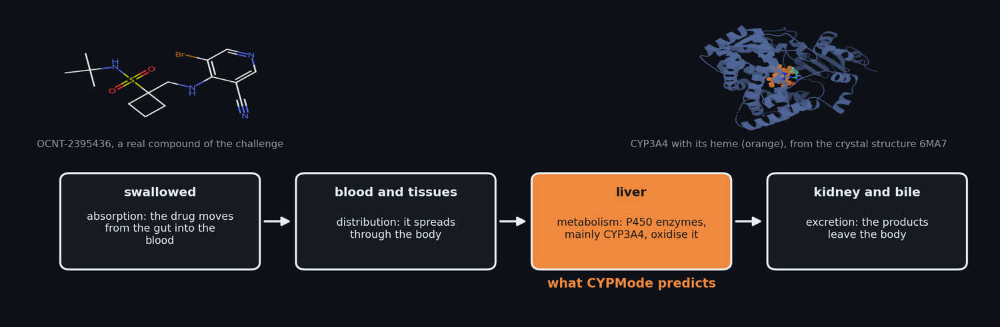

**Figure: A drug's route through the body and where this project looks.** Absorption, distribution, metabolism and excretion in one line. The project predicts what happens at the third stage: whether a molecule switches off the enzymes that do the metabolism, and so changes how long other drugs taken at the same time stay in the body.

In [2]:
show_figure("bio_adme_route")

Most metabolism is done by **enzymes**, which are proteins that speed up one particular chemical reaction by many orders of magnitude and are not used up by it, so that a small
number of enzyme molecules can process a very large number of drug molecules. In the liver a family of enzymes called **cytochrome P450**, written **CYP**, does most of the chemical
modification of drugs. (The name comes from a pigment, hence "P", that absorbs light of wavelength 450 nanometres when it is bound to carbon monoxide; section 1.3 gives the origin.)
Individual enzymes have names such as CYP3A4 and CYP2D6: the first digit names a family, the letter a subfamily, and the last digit one enzyme within it. These two enzymes are the
subject of this project. A recent preprint on this enzyme (section 0.2) states that CYP3A4 alone metabolises roughly half of all marketed drugs.

Every CYP enzyme has at its centre a **heme**, a flat ring-shaped molecule that holds one iron atom. The chemical reaction happens at that iron atom, and Part I explains how. What
matters at this point is that a molecule which sits on or next to the iron, or which reacts with the enzyme, can stop the enzyme from working.

To **inhibit** an enzyme is to reduce its activity. This matters because one drug can inhibit the enzyme that normally removes another. The second drug is then cleared more slowly, its
concentration in the blood rises, and a dose that was safe on its own can become harmful. This is a **drug-drug interaction**. Drug developers are therefore expected to find out whether
a new candidate inhibits the main CYP enzymes before it reaches patients.

Two kinds of inhibition are distinguished.

- In **reversible inhibition** the effect lasts only while the inhibitor is present. When the inhibitor has been cleared from the body, the enzyme works as before.
- In **time-dependent inhibition**, abbreviated **TDI**, the effect grows with the time the enzyme and the molecule spend together, and it outlasts the molecule. The enzyme, or a
  reactive product that the enzyme itself makes from the molecule, ends up bound so tightly or so permanently that the enzyme stays out of action until the body builds new enzyme,
  which takes days. A drug that is a time-dependent inhibitor can interact with other drugs long after its last dose.

Time-dependent inhibition is also hard to see in a simple test. A reversible inhibitor shows its effect at the moment it is mixed with the enzyme. A time-dependent inhibitor has to be
mixed with the enzyme, left for a while, and only then tested. It is therefore measured in a separate, longer experiment (section 1.8). A computer program that could say beforehand
which molecules are likely to behave this way would let chemists drop or redesign them before spending weeks on making and testing them.

This project asks two questions about molecules given as chemical structures:

1. **Classification.** Is the molecule a time-dependent inhibitor of CYP3A4, yes or no? Is it one of CYP2D6, yes or no?
2. **Structure.** Where do the atoms of the molecule sit when it is bound inside CYP3A4?

Both are posed by a public competition, described in section 0.3.

## 0.2 How this project grew

> **Field:** Overview

The project did not begin as a competition entry. Its first version is described here because its tools are still in the repository and several of its ideas return in later parts.
It was a **heme-coordination motif screen**.

**The starting point: a label that hides the mechanism.** The Therapeutics Data Commons (TDC) distributes yes/no labels saying whether a molecule inhibits each of five CYP enzymes
(the measurements of Veith and co-workers, published in 2009). A "yes" says that the molecule inhibits the enzyme. It does not say how. Pharmacologists distinguish two ways in which
a molecule can bind to the heme region of a CYP enzyme. In **Type I** binding the molecule sits in the active site near the heme, and the iron keeps the water molecule that is
normally attached to it. In **Type II** binding a nitrogen atom of the molecule reaches the iron and takes the water's place: the nitrogen's **lone pair** of electrons (a pair it holds without sharing it in a bond) forms a bond with
the iron. A Type II interaction is much tighter and is often far more significant clinically (de Groot, 2006; the chemistry is in section 1.9).

**The screen.** A heme-binding nitrogen sits in a recognisable group of atoms: an imidazole, a triazole, a pyridine or a thiazole ring. A fast program (`cypmode/metrics/motifs.py`)
searches a molecule for such groups using **SMARTS** patterns, a text notation for chemical substructures (section 5.1). The first measurement was how many of the labelled inhibitors
in the panel carry one.

In [3]:
# The motif screen's first measurement: of the molecules that the Veith panel labels as inhibitors of an enzyme, how many carry a nitrogen that could reach the heme iron?
# (The panel loader prints a line per file it reads; the output is discarded here.)
import contextlib, io

from cypmode.data.panel import load_panel, summarize_panel

with contextlib.redirect_stdout(io.StringIO()):
    panel = load_panel()
summary = summarize_panel(panel)
summary["share with a heme-binding nitrogen"] = (100 * summary["frac_with_type_ii_motif"]).round(1).astype(str) + " %"
show_table(
    summary.rename(columns={"isoform": "enzyme", "n_labeled_inhibitors": "labelled inhibitors", "n_with_type_ii_motif": "with a heme-binding nitrogen"})[
        ["enzyme", "labelled inhibitors", "with a heme-binding nitrogen", "share with a heme-binding nitrogen"]
    ]
)

| enzyme | labelled inhibitors | with a heme-binding nitrogen | share with a heme-binding nitrogen |
| --- | --- | --- | --- |
| CYP1A2 | 5829 | 1637 | 28.1 % |
| CYP2C19 | 5819 | 1640 | 28.2 % |
| CYP2C9 | 4045 | 1215 | 30.0 % |
| CYP2D6 | 2514 | 666 | 26.5 % |
| CYP3A4 | 5110 | 1566 | 30.6 % |

Only about a quarter to a third of the labelled inhibitors of any enzyme carry such a group. Most of what the yes/no label calls "inhibitor" is therefore something a motif screen
would not expect to bind the iron directly, which is exactly the information a plain yes/no label discards. The screen was kept as a cheap, interpretable signal and not claimed as a
mechanism predictor.

**The structural check.** A screen that finds a nitrogen-containing group says only that binding to the iron is possible. Whether it happens can be checked on a predicted structure.
**Boltz-2** is a **co-folding** model: a neural network that predicts the three-dimensional structure of a protein together with the molecules bound to it, starting from the protein's
sequence and the molecule's structure (section 11.2). It was run for four drugs whose structures bound to CYP3A4 had been determined experimentally by **cryo-EM**, a technique that
images frozen molecules with an electron microscope: ketoconazole, ritonavir, azamulin and vardenafil (the preprint "Structural Plasticity and Ligand Promiscuity of CYP3A4 Revealed by
Cryo-EM", bioRxiv, DOI 10.64898/2026.09.01.748687). The input explicitly included the heme, attached to the enzyme through its cysteine, because a first attempt without the heme
could not have confirmed or refuted anything. No restraint forced the molecule toward the iron, so a short iron-to-nitrogen distance is a prediction and not something the input
imposed. Distances are given in **ångström**, written Å, a unit of 0.1 nanometre; a bond between a nitrogen and an iron atom is about 2 Å long.

In [4]:
# The four compounds whose structures in CYP3A4 were solved by cryo-EM, re-predicted by Boltz-2: the distance from the heme iron to the nearest nitrogen of the motif.
import json

import pandas as pd

summary_path = ROOT / "data/structure_track/outputs/cyp3a4/validation_summary.json"
reference = json.loads(summary_path.read_text())
rows = []
for name, entry in reference.items():
    motifs = sorted({m["motif"] for m in entry["motif_nitrogen_distances"]})
    rows.append({"compound": name, "motif found": ", ".join(motifs), "iron to nearest motif nitrogen (angstrom)": entry["closest_motif_nitrogen_distance_angstrom"],
                 "bonded to the iron": "yes" if entry["coordinated"] else "no"})
show_table(pd.DataFrame(rows), floatfmt=".2f")

| compound | motif found | iron to nearest motif nitrogen (angstrom) | bonded to the iron |
| --- | --- | --- | --- |
| azamulin | triazole_1_2_4 | 13.41 | no |
| ketoconazole | imidazole_Nsub | 2.05 | yes |
| ritonavir | thiazole | 2.19 | yes |
| vardenafil | imidazole_Nsub | 10.53 | no |

Ketoconazole and ritonavir place a nitrogen within bonding distance of the iron, as the screen expected. Azamulin and vardenafil do not, although both match a motif, and each failure has a
documented reason. Azamulin is known to inactivate CYP3A4 by a mechanism that needs the enzyme to turn it into a reactive product (Lim and co-workers, 2005, DOI
10.1124/dmd.104.003475; Sevrioukova, 2019, DOI 10.3390/ijms20174245), so it is a real inhibitor with a mechanism that a screen of the Type II kind mislabels. In vardenafil the nitrogen
group sits inside a fused ring system and does not behave like a free ring nitrogen. One caution applies to both: the cryo-EM preprint itself argues that co-folding models struggle
with CYP3A4 because the enzyme reshapes its pocket on binding, so a single predicted pose cannot settle the question. Section 5.5 returns to these four compounds in detail.

**From a screen to a challenge.** In 2026 the OpenADMET project ran a public challenge on exactly this subject (section 0.3). It offered what the screen had lacked: a large,
consistent set of time-dependent inhibition measurements, a hidden test set that makes evaluation without leakage possible, and a structure-prediction task for CYP3A4. The motif screen became
one block of features for the classification model (sections 3.4 and 7.2); the structure tools built for the four-compound check, which write Boltz-2 inputs with the heme attached,
became the base of the structure entry (Part XI).

**Three habits formed along the way**, and they shape the whole notebook. Every number in a report is copied by code from a log or a result table, never typed. Every proposed
improvement to a model is judged by a **gate**, a pass/fail rule written down before its result exists (section 6.7). And a result that does not help is kept and explained, not dropped (section 0.5).

## 0.3 The challenge

> **Field:** Overview · Statistics

The **OpenADMET CYP blind challenge** is a public competition run by the OpenADMET project, hosted as a Hugging Face Space
(<https://huggingface.co/spaces/openadmet/cyp-challenge>) with its data in a public dataset (<https://huggingface.co/datasets/openadmet/cyp-challenge-train-test>). A **blind** test
means that the organisers keep the correct answers for the test molecules and score every submission themselves; participants cannot see how well they are doing except through the
limited scores the organisers show. Three tracks exist. The facts in this section come from the challenge's FAQ and from the evaluation configuration published in its Space, which the
challenge states is ported from its scoring backend.

| track | task | scored by | entered here |
| --- | --- | --- | --- |
| Direct inhibition | predict how strongly a molecule inhibits each of four enzymes, as a number (regression) | a soft-threshold relative error | no |
| Time-dependent inhibition (TDI) | say yes or no for CYP3A4 and for CYP2D6 | the Matthews correlation coefficient (MCC), averaged over the two enzymes | yes |
| Structure | predict the pose of 20 ligands bound to CYP3A4 | LDDT-PLI, with the ligand RMSD (root-mean-square deviation: the typical distance between the predicted and the true position of the ligand's atoms) after pocket superposition as a secondary score | yes |

The **Matthews correlation coefficient** (**MCC**) is a score for yes/no predictions that is 0 for guessing and 1 for perfect answers, and that stays informative when "yes" is rare
(section 4.10 derives it). **LDDT-PLI** is a score from 0 to 1 for how well the distances between a ligand's atoms and the protein atoms near it are reproduced (section 11.4). A
submitted structure that fails any of the physical-validity checks of the **PoseBusters** program is given the worst possible scores, however close it is to the truth; the program
checks, for example, that no two atoms overlap and that bond lengths are sensible (section 11.4).

The rules that matter for this project are these.

- The test set has 750 molecules and its labels are withheld until the challenge closes. A submission may be made once every 12 hours for each track, and only the latest valid one counts.
- The final deadline is 3 November 2026, 23:59 UTC.
- A submission carries a declaration of whether proprietary data were used. This project uses public data only.
- Publishing the code is encouraged, and it is required for a separate award, the "Innovation in ML" award, which recognises architectural novelty, creative use of data, novel
  uncertainty quantification and clever engineering independently of leaderboard rank. A written method report must be linked for the final leaderboard.

**The data.** The training file holds 6,145 molecules and the blinded test file 750. A molecule is given as a **SMILES** string, a line of text that spells out its
atoms and bonds (section 2.1). The next cell shows what the two files contain.

In [5]:
# What the two challenge files hold. A column is named "<enzyme>_<quantity>"; the quantities are grouped below.
import pandas as pd

train = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")
test = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TEST-BLINDED.csv")
enzymes = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]
quantities = {
    "pIC50 after pre-incubation (the TDI condition)": ["_pIC50_TDI_condition"],
    "its lower and upper confidence limits": ["_pIC50_TDI_condition_conf_low", "_pIC50_TDI_condition_conf_high"],
    "its standard deviation": ["_pIC50_TDI_condition_std"],
    "pIC50 without pre-incubation (direct inhibition)": ["_pIC50_direct_inhibition"],
    "its lower and upper confidence limits ": ["_pIC50_direct_inhibition_conf_low", "_pIC50_direct_inhibition_conf_high"],
    "its standard deviation ": ["_pIC50_direct_inhibition_std"],
    "yes/no label": ["_is_TDI"],
}
rows = []
for label, suffixes in quantities.items():
    filled = {e: int(train[e + suffixes[0]].notna().sum()) for e in enzymes if e + suffixes[0] in train.columns}
    rows.append({"quantity": label, "columns": len(suffixes) * len(filled), "enzymes": ", ".join(filled), "filled rows per enzyme": ", ".join(f"{e} {n}" for e, n in filled.items())})
print(f"training file: {len(train)} rows x {train.shape[1]} columns; blinded test file: {len(test)} rows x {test.shape[1]} columns ({', '.join(test.columns)})")
show_table(pd.DataFrame(rows))

training file: 6145 rows x 36 columns; blinded test file: 750 rows x 2 columns (Molecule_Name, SMILES)


| quantity | columns | enzymes | filled rows per enzyme |
| --- | --- | --- | --- |
| pIC50 after pre-incubation (the TDI condition) | 4 | CYP1A2, CYP2C9, CYP2D6, CYP3A4 | CYP1A2 1413, CYP2C9 1285, CYP2D6 1497, CYP3A4 3583 |
| its lower and upper confidence limits | 8 | CYP1A2, CYP2C9, CYP2D6, CYP3A4 | CYP1A2 1413, CYP2C9 1285, CYP2D6 1497, CYP3A4 3583 |
| its standard deviation | 4 | CYP1A2, CYP2C9, CYP2D6, CYP3A4 | CYP1A2 1413, CYP2C9 1285, CYP2D6 1497, CYP3A4 3583 |
| pIC50 without pre-incubation (direct inhibition) | 4 | CYP1A2, CYP2C9, CYP2D6, CYP3A4 | CYP1A2 1412, CYP2C9 1285, CYP2D6 1493, CYP3A4 2335 |
| its lower and upper confidence limits  | 8 | CYP1A2, CYP2C9, CYP2D6, CYP3A4 | CYP1A2 1412, CYP2C9 1285, CYP2D6 1493, CYP3A4 2335 |
| its standard deviation  | 4 | CYP1A2, CYP2C9, CYP2D6, CYP3A4 | CYP1A2 1412, CYP2C9 1285, CYP2D6 1493, CYP3A4 2335 |
| yes/no label | 2 | CYP2D6, CYP3A4 | CYP2D6 1497, CYP3A4 3584 |

A **pIC50** is a number that says how strongly a molecule acts on an enzyme: the negative base-10 logarithm of the concentration, in moles per litre, that halves the enzyme's
activity, so that a larger pIC50 means a stronger effect (section 1.7). Each molecule has up to two such numbers per enzyme, and many are missing because not every molecule was
measured on every enzyme (section 2.6). The yes/no label for the classification task is not typed in by a person: it follows from the two pIC50 values by a rule that this project
recovered from the data and checked exactly, and that the challenge's own pages confirm (section 2.3). The cell below counts, for the two enzymes of the TDI track, how many training
molecules carry a usable label.

In [6]:
# How many training molecules can be used for each enzyme, read with the project's own view of the file (section 2.3 explains the rows that are left out).
labels = pd.DataFrame({
    "enzyme": list(F.labelled),
    "molecules with both measurements and a label": list(F.labelled.values()),
    "of which labelled positive": list(F.positives.values()),
    "share positive": [F.positives[e] / F.labelled[e] for e in F.labelled],
    "molecules without a usable label": [F.unlabelled[e] for e in F.labelled],
})
show_table(labels)

| enzyme | molecules with both measurements and a label | of which labelled positive | share positive | molecules without a usable label |
| --- | --- | --- | --- | --- |
| CYP3A4 | 2334 | 764 | 0.327 | 2562 |
| CYP2D6 | 1493 | 324 | 0.217 | 4648 |

For CYP3A4 and CYP2D6 the positive molecules are a minority of the labelled ones, and the labelled molecules are themselves a selected subset of the whole file. Both facts shape
every later decision: they are the reason a plain **accuracy** score (the fraction of compounds called correctly) would be misleading, the reason the test set's positive rate matters (section 2.10), and the reason that the project
spends much of its effort on how a model is evaluated (Part VI) and not only on the model.

**The structure track.** The 20 ligands are given as SMILES strings; the answer is a three-dimensional structure file for each ligand bound to CYP3A4. The reference structures are
new cryo-EM structures of CYP3A4 bound to drug-like molecules. Fifteen of the 20 come from the training set of the TDI track, two from its test set and three are additional compounds, a fact
used in section 11.5 to attach what is known about a ligand to its structure.

## 0.4 The whole system on two pages

> **Field:** Overview · Machine learning · Structural biology

Two systems were built, one for each track. Both are drawn here as a row of boxes, and the tables that follow name the section that explains each box. The figures are generated
from the repository's files, so the counts on them are the current ones.

**The classification system** turns a training file into calls on the test molecules.

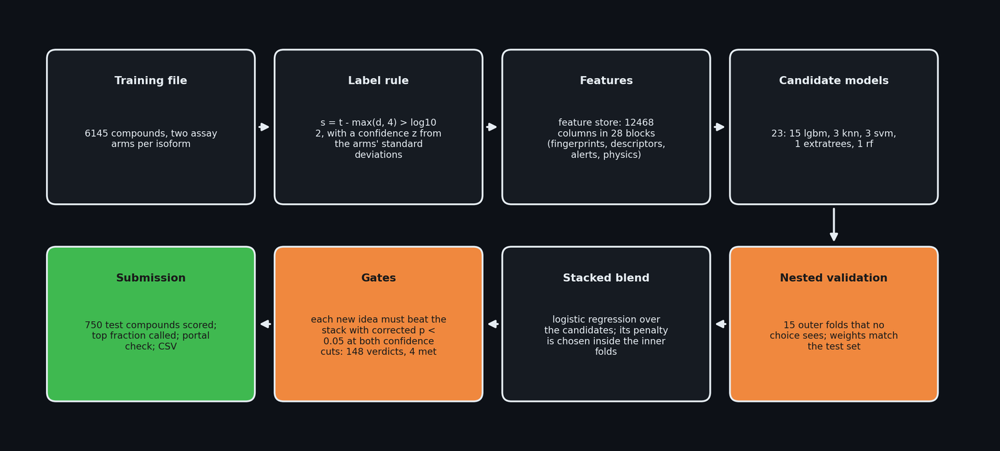

**Figure: The TDI track as a pipeline.** The TDI track from the training file to the submitted calls. 6145 training compounds with two assay arms become a label through the shift rule; the feature store holds 12468 columns in 28 blocks, from which 23 default candidate models draw; every comparison is made on held-out outer folds (15 of them) that no choice has seen; a stacked logistic blend combines the candidates; 148 pre-declared TDI gates decided which further ideas were allowed in (4 met).

In [7]:
show_figure("arch_tdi_pipeline")

| box | what it does | explained in |
| --- | --- | --- |
| Training file | 6,145 molecules with two assay arms per enzyme (measured without and with a head start for the inhibitor) | 2.2, 2.6 |
| Label rule | the yes/no label follows from the two measurements, `s = t - max(d, 4) > log10 2`, and each label gets a confidence from the measurement noise | 2.3, 2.5 |
| Features | every molecule becomes 12,468 numbers in 28 blocks: fingerprints of its substructures, calculated properties, alerts for reactive groups, and physics from quantum chemistry | Part III, Part X |
| Candidate models | 23 models of 7 kinds (boosted trees, nearest neighbours, support vector machines, extremely randomised trees, a random forest and two boosted regressors of the assay arms), each reading some of the features | Part IV, 8.1 |
| Nested validation | the whole procedure is evaluated on folds that no choice has seen; the evaluation weights match the test set | Part VI |
| Stacked blend | a logistic regression combines the candidates' scores; its penalty is chosen inside the inner folds | 8.2 |
| Gates | each new idea must beat the stack with corrected p < 0.05 at two confidence cut-offs before it is used | 6.7, Parts IX and X |
| Submission | the test molecules are scored, the top fraction is called positive, the files are checked with the portal's own rules | 8.4 to 8.6 |

In plain words: every molecule is first turned into a long list of numbers that describe it. A **fingerprint**, one kind of such numbers, is a list of yes/no answers to the question "does
the molecule contain this particular small group of atoms?". Many different models then each give a score for how likely the molecule is to be a time-dependent inhibitor, and a final
blending step, called **stacking**, learns how much to trust each model. The molecules with the highest blended scores are called positive. Because the true test answers are hidden, the
whole procedure is practised on the training molecules in a way that mimics the hidden test, and every idea that might improve it has to pass a gate first.

**The structure system** turns a ligand into a validated pose.

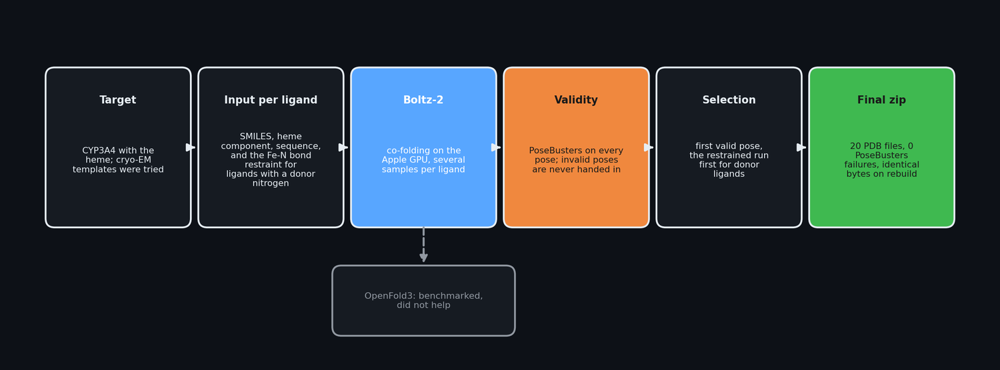

**Figure: The structure track as a pipeline.** The structure track from a ligand to the submitted zip. Boltz-2 folds each ligand into CYP3A4 with the heme; when the ligand has a nitrogen that can reach the iron, a bond-length restraint is part of the input and its run is read first; the first pose that passes the validity checks is taken. OpenFold3 was run on the same benchmark and did not improve the poses, so it is not in the final recipe (dashed). The zip holds 20 poses, of which 0 fail any PoseBusters check, and its bytes are the same every time it is rebuilt.

In [8]:
show_figure("arch_structure_pipeline")

| box | what it does | explained in |
| --- | --- | --- |
| Target | CYP3A4 with its heme; templates built from cryo-EM structures were tried | 11.1, 11.7 |
| Input per ligand | the ligand's SMILES, the heme, the enzyme sequence and, for ligands with a donor nitrogen, a restraint that keeps the nitrogen near the iron | 11.3, 11.6 |
| Boltz-2 | co-folding on the laptop's graphics processor, several samples per ligand | 11.2, 11.3 |
| Validity | PoseBusters is run on every pose, and an invalid pose is never handed in | 11.4 |
| Selection | the first valid pose is taken, with the restrained run first for donor ligands; more elaborate choices were tested and not adopted | 11.8, 11.10 |
| OpenFold3 | a second co-folding model was run for real, benchmarked, and did not help | 11.9 |
| Final zip | 20 structure files, 0 validity failures, rebuilt byte for byte | 11.10, 12.1 |

Underneath both systems sit the engineering parts: the tests, the job queue that ran everything in order, the audit that runs the whole pipeline twice and compares the results
byte for byte, and the reports generated from the logs (Part XII).

## 0.5 The ledger in one table

> **Field:** Overview · Statistics

A **gate** is a pass/fail rule for an experiment, written down before the experiment's result exists. For a proposed addition to the classification model the rule is: it must beat the
reference with a corrected p value below 0.05 at both confidence cut-offs, both when added alone and when added to the assembled stack (section 6.7). For a structure lever the rule is
stated on a benchmark of ligands with experimentally known poses. Fixing the rule first matters because a rule chosen after seeing a result can always be chosen so that the result
passes. The table lists every logged verdict, grouped by experiment. One idea usually yields several verdicts, because it is judged for each enzyme, alone and stacked, and sometimes
again in a replicate with 10 folds; the verdicts of a replicate are counted with the experiment it replicates. The terms in the table are explained in the sections named in its last column.

In [9]:
# The ledger: every logged verdict of a pre-declared gate, grouped by experiment. The counts are read from the experiments' own logs.
import re

from cypmode.audit.ledger_kinds import ledger_rows

DESCRIPTION = {
    "selection_aware_v2": ("selection-aware CYP2D6 model: P(label) = P(hit) x P(label | hit)", "9.1"),
    "hedged_blend": ("hedged rank blend of the hits-only and the selection-aware CYP2D6 stacks", "9.1"),
    "pair_transfer": ("structure-activity (SAR) pair model on descriptor differences", "9.2"),
    "mmp_transfer": ("matched-molecular-pair transfer", "9.2"),
    "committee_label_model": ("label-process committee: P(shift > log10 2) from two regressors", "9.3"),
    "embeddings": ("frozen CheMeleon foundation-model embeddings", "9.4"),
    "test_likeness": ("training weights that follow similarity to the test structures", "9.5"),
    "arms_experiment": ("assay-arm regressors floor-clipped at the assay floor", "9.6"),
    "xiso_transfer": ("transfer of the assay arms across enzymes", "9.7"),
    "physics_experiment": ("GFN2-xTB physics features, tier A", "10.6"),
    "physics_compact": ("the 20 most useful physics columns", "10.6"),
    "physics_tierb": ("physics features, tier B (Boltzmann-weighted conformers)", "10.6"),
    "population_physics": ("physics inside the selection-aware model", "10.6"),
    "pair_transfer_physics": ("structure-activity (SAR) pair model on physics differences", "10.6"),
    "replicate_verdict": ("10-fold replicate of the physics additions", "10.6"),
    "structure_gates": ("structure levers: Fe-donor bond and contact restraints, seeds, conformer templates, step scale", "11.6, 11.7"),
    "restraint_expansion": ("confirmation of the bond restraint on 20 more donor ligands", "11.6"),
    "selection_validation": ("pose choice by minimum Bayes risk", "11.8"),
    "pose_awareness": ("physics and pharmacophore terms in pose choice", "11.8"),
    "series_consensus": ("structure-activity (SAR) term: agreement with the poses of analogs", "11.8"),
    "heme_frame_prior": ("pose prior from 148 crystal ligands in the heme frame", "11.8"),
    "ei_sampling": ("extra poses allocated by pool disagreement", "11.8"),
    "mbr_lddt_reevaluation": ("minimum Bayes risk re-scored with LDDT-PLI (exploratory, not declared beforehand)", "11.8"),
}
# The section that explains each experiment that is not described above; its name comes from the titles of the README (cypmode/audit/docs_state.py).
SECTIONS = {
    "aux_chemprop": "9.9", "aux_mlp": "9.9", "aux_neural": "9.9", "permutation_control": "6.8, 9.10", "aux_atomjepa": "9.10", "aux_atomjepa_head": "9.10", "exploratory_atomjepa_head": "9.10", "aux_basic_centre": "9.10",
    "aux_chemprop_foundation": "9.10", "aux_emax": "9.10", "aux_ext_adme": "9.10", "aux_ext_cont": "9.10", "aux_ext_tox": "9.10", "aux_gate_shift": "9.10", "aux_mlp_aux": "9.10", "aux_nodirect": "9.10", "aux_pxr": "9.10", "aux_screen": "9.10",
    "aux_tabicl": "9.10", "aux_tabicl_chemeleon": "9.10", "aux_tabicl_monroe": "9.10", "aux_tabpfn": "9.10", "aux_tabpfn_chemeleon": "9.10", "monroe_embeddings": "9.10", "nonneg_stack": "9.10", "population_screen": "9.10",
    "softmax_selector": "9.10", "aux_pocket_cyp2d6": "9.13", "aux_pocket_cyp3a4": "9.13", "exploratory_pocket_control": "9.13", "exploratory_pocket_first_run_seed0_control": "9.13", "exploratory_pocket_first_run_seed0_own": "9.13",
    "aux_hypothesis": "9.14", "aux_site_cyp2d6": "9.14", "aux_site_cyp3a4": "9.14", "exploratory_hypothesis_permuted": "9.14", "exploratory_site_control": "9.14",
    "ost_vs_ours": "11.4, 11.6", "ost_regate": "11.6", "ost_pool_gates": "11.8, 11.9", "selection_validation_bioemu2": "11.9", "relaxation_gate": "11.10", "ligand_dynamics": "11.13", "pose_pharmacophore_model": "11.11",
}
from cypmode.audit.docs_state import TITLES


def section_of(stem):
    return DESCRIPTION[stem][1] if stem in DESCRIPTION else SECTIONS.get(stem, "?")


def section_key(stem):
    """The first section of a stem as numbers, so that 9.9 comes before 9.10."""
    first = section_of(stem).split(",")[0].strip()
    return tuple(int(part) for part in first.split(".")) if first[:1].isdigit() else (99,)


rows = {}
frame = ledger_rows()
for stem, verdict in zip(frame["stem"], frame["verdict"], strict=True):
    entry = rows.setdefault(stem, {"met": 0, "not met": 0})
    entry["met" if verdict == "MET" else "not met"] += 1
ledger = pd.DataFrame([
    {"idea": DESCRIPTION[stem][0] if stem in DESCRIPTION else TITLES.get(stem, stem), "section": section_of(stem), "verdicts met": v["met"], "verdicts not met": v["not met"]}
    for stem, v in sorted(rows.items(), key=lambda kv: (section_key(kv[0]), kv[0]))
])
show_table(ledger)
met_rows = frame[frame["verdict"] == "MET"]
met_rows = met_rows.assign(order=(met_rows["kind"] == "structure levers").astype(int) * 2 + met_rows["name"].str.endswith("_ost").astype(int)).sort_values("order", kind="stable")  # the classification model first, then the structure track, the repeats under the second scorer last
MET_LABEL = {  # a verdict that is met is named by what it passed, not by the family of the experiment (a family also holds verdicts that were not met)
    "restraint_bond": "the restraint of the iron-nitrogen bond",
    "restraint_contact": "the restraint of the iron-nitrogen contact",
    "restraint_bond_ost": "the same bond restraint under the OpenStructure scorer",
    "restraint_contact_ost": "the same contact restraint under the OpenStructure scorer",
    "force_field_relaxation": "the force-field relaxation of poses",
}


def met_label(stem, name):
    if name in MET_LABEL:
        return MET_LABEL[name]
    replicated = re.search(r"replicate (\w+)", name)
    if replicated:
        return f"the 10-fold replicate of the {replicated.group(1)} group"
    return TITLES.get(stem, stem)


met = list(dict.fromkeys(met_label(stem, name) for stem, name in zip(met_rows["stem"], met_rows["name"], strict=True)))
met_structure = int((met_rows["kind"] == "structure levers").sum())
met_model = len(met_rows) - met_structure
print("verdicts met:", "; ".join(met))

verdicts met: Chemprop from the two OpenADMET pretraining weights (staged); the neural pair (multitask network and plain Chemprop) in the stack; the 10-fold replicate of the neural group; the force-field relaxation of poses; the restraint of the iron-nitrogen bond; the restraint of the iron-nitrogen contact; the same bond restraint under the OpenStructure scorer; the same contact restraint under the OpenStructure scorer


| idea | section | verdicts met | verdicts not met |
| --- | --- | --- | --- |
| hedged rank blend of the hits-only and the selection-aware CYP2D6 stacks | 9.1 | 0 | 6 |
| selection-aware CYP2D6 model: P(label) = P(hit) x P(label \| hit) | 9.1 | 0 | 1 |
| matched-molecular-pair transfer | 9.2 | 0 | 4 |
| structure-activity (SAR) pair model on descriptor differences | 9.2 | 0 | 2 |
| label-process committee: P(shift > log10 2) from two regressors | 9.3 | 0 | 2 |
| frozen CheMeleon foundation-model embeddings | 9.4 | 0 | 4 |
| training weights that follow similarity to the test structures | 9.5 | 0 | 4 |
| assay-arm regressors floor-clipped at the assay floor | 9.6 | 0 | 4 |
| transfer of the assay arms across enzymes | 9.7 | 0 | 4 |
| plain Chemprop in the stack | 9.9 | 0 | 2 |
| multitask network in the stack | 9.9 | 0 | 2 |
| the neural pair (multitask network and plain Chemprop) in the stack | 9.9 | 2 | 1 |
| frozen Atom-JEPA embeddings as a block | 9.10 | 0 | 4 |
| Atom-JEPA readout in the stack | 9.10 | 0 | 2 |
| basic-centre block (protonation states, centre classes) | 9.10 | 0 | 4 |
| Chemprop from the two OpenADMET pretraining weights (staged) | 9.10 | 1 | 0 |
| Emax of both arms as a predicted block | 9.10 | 0 | 4 |
| logD and protein binding from the OpenADMET surrogate models | 9.10 | 0 | 4 |
| continuous external-panel responses as a predicted block | 9.10 | 0 | 4 |
| Tox21 CYP-screen readings as a predicted block | 9.10 | 0 | 4 |
| gate-shift features | 9.10 | 0 | 4 |
| multitask network with the screen and Emax as auxiliary heads | 9.10 | 0 | 2 |
| compounds without a direct curve | 9.10 | 0 | 2 |
| PXR-induction readings as a predicted block | 9.10 | 0 | 4 |
| single-concentration screen as a predicted block | 9.10 | 0 | 4 |
| TabICL in the stack | 9.10 | 0 | 2 |
| TabICL on frozen CheMeleon embeddings | 9.10 | 0 | 2 |
| TabICL on Monroe embeddings | 9.10 | 0 | 2 |
| TabPFN in the stack | 9.10 | 0 | 2 |
| TabPFN on frozen CheMeleon embeddings | 9.10 | 0 | 2 |
| Monroe (GRIT) embeddings | 9.10 | 0 | 4 |
| non-negative stacking | 9.10 | 0 | 2 |
| selection-aware CYP2D6 model with the screen | 9.10 | 0 | 2 |
| softmax-temperature selector | 9.10 | 0 | 2 |
| compound relative to the CYP2D6 pocket | 9.13 | 0 | 2 |
| compound relative to the CYP3A4 pocket | 9.13 | 0 | 2 |
| ligand-based pharmacophore hypothesis model | 9.14 | 0 | 4 |
| structure-based site model of the CYP2D6 pocket | 9.14 | 0 | 2 |
| structure-based site model of the CYP3A4 pocket | 9.14 | 0 | 2 |
| structure-activity (SAR) pair model on physics differences | 10.6 | 0 | 2 |
| the 20 most useful physics columns | 10.6 | 0 | 8 |
| GFN2-xTB physics features, tier A | 10.6 | 0 | 8 |
| physics features, tier B (Boltzmann-weighted conformers) | 10.6 | 0 | 8 |
| physics inside the selection-aware model | 10.6 | 0 | 2 |
| 10-fold replicate of the physics additions | 10.6 | 1 | 6 |
| the LDDT-PLI of the project against that of OpenStructure | 11.4, 11.6 | 0 | 1 |
| restraint confirmation repeated with OpenStructure's LDDT-PLI | 11.6 | 0 | 2 |
| confirmation of the bond restraint on 20 more donor ligands | 11.6 | 0 | 2 |
| structure levers: Fe-donor bond and contact restraints, seeds, conformer templates, step scale | 11.6, 11.7 | 2 | 3 |
| extra poses allocated by pool disagreement | 11.8 | 0 | 1 |
| pose prior from 148 crystal ligands in the heme frame | 11.8 | 0 | 1 |
| pool gates repeated with OpenStructure's yardstick | 11.8, 11.9 | 2 | 11 |
| physics and pharmacophore terms in pose choice | 11.8 | 0 | 3 |
| pose choice by minimum Bayes risk | 11.8 | 0 | 2 |
| structure-activity (SAR) term: agreement with the poses of analogs | 11.8 | 0 | 1 |
| pose choice with BioEmu2 ensembles | 11.9 | 0 | 2 |
| force-field relaxation of poses | 11.10 | 1 | 0 |
| pharmacophore model of the poses | 11.11 | 0 | 2 |
| ligand dynamics in the frozen pocket | 11.13 | 0 | 3 |

187 verdicts in 59 families of ideas were recorded for rules declared beforehand, and 9 of them are "met": 4 for the classification model and 5 for the structure track. The verdicts
that are met are Chemprop from the two OpenADMET pretraining weights (staged); the neural pair (multitask network and plain Chemprop) in the stack; the 10-fold replicate of the neural group; the force-field relaxation of poses; the restraint of the iron-nitrogen bond; the restraint of the iron-nitrogen contact; the same bond restraint under the OpenStructure scorer; the same contact restraint under the OpenStructure scorer. All the others, including every more elaborate way of choosing a pose and most additions to the classification model, ended "not met". The table holds ideas only: the check of the pipeline on permuted labels
(which must give chance) and the exploratory second looks, among them the re-scoring of minimum-Bayes-risk pose selection with LDDT-PLI whose rule was not declared beforehand, are checks and not ideas, and they are not in it.

A ledger that is almost entirely "not met" is not a failure of the method. It is what a strict method is for. The classification model that results is deliberately plain: a blend of
23 standard models (the default stack; the final CYP3A4 stack adds 5 members from groups that passed their gates) on a large set of fingerprints and calculated properties. Its distinguishing features are in how it is evaluated, in how the label is modelled, and in the
record of what was tried. Sections 9.10 and 13.1 return to what the ledger does and does not show.

## 0.6 How this notebook is built and how to run it

> **Field:** Software engineering

The notebook is both a text and a program. Its source is a set of Python modules in `notebooks/parts/`, assembled by `notebooks/build_notebook.py`. The builder runs every code cell in
order in one namespace with the repository's root as the working directory, records the printed text, tables and figures as the cell's output, and writes the executed notebook. Four
checks must pass before it is written.

1. **No cell may fail.** A failing cell stops the build, so a number can never be left over from an earlier version of the code.
2. **Every defined term is defined where it is first used.** The list of terms is in `notebooks/parts/glossary.py`; the builder finds the first section that uses each one and fails if
   that section does not contain its bold definition. This is how the rule "no background assumed" is enforced and not merely intended.
3. **Every file of the repository is explained.** The builder lists every module of `cypmode/`, every file of `scripts/`, every job of `queue/jobs/` and every test file, and fails if
   any is not named in the text. Appendix D prints the resulting map from file to section, so nothing in the repository can go unexplained, and anything added later has to be
   explained before the notebook builds.
4. **Every number in a sentence comes from a file.** A sentence such as "6,145 molecules" is a template filled in from `notebooks/facts.py`, which reads the repository's own
   files, at build time.

In [10]:
# What the repository holds and what the build of this notebook enforces.
print(f"{F.modules} modules in cypmode/, {F.scripts} files in scripts/, {F.jobs} queue jobs, {F.test_files} test files with {F.test_functions} test functions")

179 modules in cypmode/, 23 files in scripts/, 177 queue jobs, 156 test files with 1085 test functions


**Where each science is taught.** The notebook assumes no background, so every science that the project uses is taught from its first principles, in the section of the part where it is first needed, with a worked example: a cell that computes the idea on a small case or on the project's own data. The table below is the index. Each row names a science, the sections that teach it (every number is a link to the heading) and what the worked example computes, so that a reader who meets an unfamiliar subject anywhere in the text can look it up here. The build checks that every section named in the table exists and holds a code cell; the description of the example is written by hand.

In [11]:
# Where each science of the project is taught: the sections, and the worked example (a cell that computes the idea on a small case or on the project's own data). The table is written by hand; the build checks that
# every section it names exists and holds a code cell, and links each number to the heading exactly as the table of contents does.
import re

from notebooks.notebook_builder import headings, section_of_cells, slug
from notebooks.notebook_cells import ALL_CELLS

MATH, BIO, CHEM, CHEMINF, COMP, STRUCT, ML, ENG = (
    "Mathematics and statistics", "Biology and pharmacology", "Chemistry", "Cheminformatics", "Computational and quantum chemistry", "Structural biology and bioinformatics", "Machine learning", "Engineering of the project")
taught = [
    (MATH, "Rates of change: elimination, binding and inactivation", "1.1 1.2 1.6", "one dose with first-order elimination (1.1); the schemes E + S <-> ES -> E + P (1.2) and E + I <-> EI -> E-I* (1.6) integrated as differential equations"),
    (MATH, "Probability, likelihood and the log-loss", "4.1", "the log-loss of one compound and its derivative p - y, checked against a finite difference"),
    (MATH, "Standard deviation, confidence limits and measurement noise", "2.5 1.7", "what the confidence limits and the standard deviation of a pIC50 are (2.5); a simulated dose-response experiment with 6 percent noise (1.7)"),
    (MATH, "Rank test and permutation test", "5.4 6.8", "the rank test written out on a tiny example and on the real groups, and a permutation test that shuffles the group labels (5.4); a label-permutation control on data with nothing to find (6.8)"),
    (MATH, "The corrected resampled t-test", "6.5", "two classifiers that are equal in truth, compared by cross-validation on many simulated data sets, and why the naive test fails"),
    (MATH, "Multiple comparisons: Holm's adjustment", "6.5 9.11", "a family of comparisons from the project's own logs (6.5); the ledger of the gates with the correction for the number of attempts (9.11)"),
    (MATH, "Logistic regression and its penalties", "4.1 8.2", "the weights fitted by gradient descent and compared with the library (4.1); a toy in which the truth is known, to show why the blend is penalised (8.2)"),
    (MATH, "Optimisation: gradient descent", "4.1 11.10", "the loop that fits the logistic regression (4.1); the same rule lowering an energy with four step sizes, against L-BFGS (11.10)"),
    (MATH, "Linear algebra: eigenvectors and principal components", "4.9", "principal component analysis by hand on the 217 descriptors of all 6895 compounds, compared with scikit-learn"),
    (MATH, "Linear algebra: the Kabsch fit", "11.4", "the rotation that best superposes two sets of points, on a small example checked by hand"),
    (BIO, "The liver and the elimination of a drug", "1.1", "one dose with first-order elimination, C(t) = C0 exp(-kt)"),
    (BIO, "Enzymes and the Michaelis-Menten equation", "1.2", "E + S <-> ES -> E + P integrated as differential equations and compared with the Michaelis-Menten rate"),
    (BIO, "Cytochrome P450, the heme and the catalytic cycle", "1.3", "the conserved heme-binding signature F..G...C.G found in the sequence of CYP3A4 by a pattern, with the cysteine that binds the iron; the cycle drawn in a figure"),
    (BIO, "Drug-drug interactions", "1.4", "the increase in exposure (the AUC ratio) that a competitive inhibitor causes"),
    (BIO, "Reversible inhibition", "1.5", "how the IC50 of a competitive inhibitor depends on the substrate concentration, IC50 = Ki (1 + [S] / KM)"),
    (BIO, "Time-dependent inhibition", "1.6", "E + I <-> EI -> E-I* integrated as differential equations"),
    (BIO, "Dose-response, the Hill equation, the IC50 and the pIC50", "1.7", "a simulated dose-response experiment, ten concentrations in three-fold steps, with its fit"),
    (BIO, "The two assay arms and the potency shift", "1.8 2.3", "the shift that a time-dependent inhibitor shows after a pre-incubation (1.8); the label rule and its single threshold (2.3)"),
    (CHEM, "Organic structure: atoms, bonds, aromaticity and stereochemistry", "2.1", "an example compound read as a graph; aromaticity by counting electrons; one molecule written by many random walks; the two mirror forms of a carbon with four different neighbours"),
    (CHEM, "Functional groups and structural alerts", "1.10 9.15", "the structural alerts of the project against the real labels (1.10); the functional groups of the table against the base rate (9.15)"),
    (CHEM, "Basic amines, pKa and protonation", "5.2 9.10", "the trialkylamine pattern of the project (5.2); the share of charged molecules from the pKa, checked against Dimorphite-DL (9.10)"),
    (CHEM, "Nitrogen-iron coordination, Type I and Type II binding", "1.9 5.1 5.5", "the iron-to-ligand distances in crystal structures of CYP3A4 (1.9); the six patterns of the motif screen (5.1); the iron-nitrogen distance computed by hand and by the library (5.5)"),
    (CHEM, "Reactive metabolites and mechanism-based inactivation", "1.6 1.10", "the kinetic scheme of inactivation (1.6); the structural alerts against the real labels (1.10)"),
    (CHEMINF, "SMILES and molecular graphs", "2.1", "one molecule written by 2000 random walks over its graph"),
    (CHEMINF, "Standardising structures", "2.9", "what the standardised parent does to a salt, on three real compounds"),
    (CHEMINF, "Fingerprints and the Morgan algorithm", "3.1", "the Morgan algorithm written out on a toy that uses nothing but the graph"),
    (CHEMINF, "Tanimoto similarity", "3.2", "the Tanimoto similarity by hand and by RDKit"),
    (CHEMINF, "Descriptors", "3.3", "some of the 217 RDKit descriptors, computed for the example compound"),
    (CHEMINF, "Pharmacophore fingerprints", "3.5", "the example compound as the project's pharmacophore fingerprint sees it"),
    (CHEMINF, "Scaffolds, clusters and similarity-based validation", "3.6 6.4", "Bemis-Murcko scaffolds and Taylor-Butina clusters (3.6); how close a validation compound is to the training compounds, against how close a test compound is (6.4)"),
    (CHEMINF, "Matched molecular pairs", "9.2", "two compounds that differ by one cut bond, found with the matched-pair fragmentation of RDKit"),
    (CHEMINF, "Feature blocks and the feature store", "3.4 3.7", "every block with its real width (3.4); the two promises of the store checked on the real functions (3.7)"),
    (COMP, "Force fields", "11.10", "the terms of a force field put into numbers on one pair of atoms"),
    (COMP, "The Lennard-Jones and Coulomb terms", "11.10", "both terms for one pair of atoms: the bottom of the well at 2^(1/6) sigma found by the formula and by a search, and the Coulomb constant computed from the physical constants"),
    (COMP, "Energy minimisation", "11.10", "gradient descent with four step sizes against L-BFGS, on the Lennard-Jones energy"),
    (COMP, "The relaxation of a predicted pose", "11.10", "one ligand atom too close to a frozen receptor atom, minimised for several strengths of the tether"),
    (COMP, "Partial charges", "10.5", "the quantities of the physics block, with the charge of every atom, computed on three small molecules"),
    (COMP, "The Schrödinger equation and the variational principle", "10.1", "the Schrödinger equation as a matrix eigenvalue problem on a grid; the variational principle on the hydrogen atom"),
    (COMP, "Hartree-Fock and basis sets", "10.2", "Hartree-Fock written out for the smallest molecules, and H2 at several distances"),
    (COMP, "Density functional theory", "10.3", "density functional theory against Hartree-Fock on the water molecule"),
    (COMP, "GFN2-xTB and tight binding", "10.4", "one GFN2-xTB single point on toluene, with the program's own report"),
    (COMP, "Molecular dynamics", "11.13", "the Langevin thermostat on particles in a harmonic well, whose position and velocity variances must equal kT / k and kT / m, run with a written-out integrator and with the integrator of OpenMM"),
    (COMP, "Solvent-accessible surface and cavities", "5.6", "the Shrake-Rupley surface written out; cavity detection on a toy in two dimensions"),
    (STRUCT, "Proteins and the PDB file format", "11.1", "what a predicted complex file holds, read from one of the submitted files"),
    (STRUCT, "mmCIF files", "5.5", "the first atom of a real file laid against the names of the columns, field by field"),
    (STRUCT, "Sequence alignments and co-evolution", "11.2", "a toy protein of 12 positions: what 400 related sequences tell about its shape"),
    (STRUCT, "Co-folding: the pair representation and the triangle update", "11.2", "one triangle update with random weights: relabelling the positions gives the relabelled result"),
    (STRUCT, "The Pairformer", "11.2", "the order of the operations of a block read from the code of OpenFold3, and attention with a bias from the pairs on six tokens"),
    (STRUCT, "Diffusion models", "11.2", "a diffusion sampler in two dimensions whose ideal denoiser is known exactly, for several step scales"),
    (STRUCT, "Boltz-2 and OpenFold3", "11.3 11.9", "the input of a prediction built by the project's own function (11.3); OpenFold3 as it was run for the benchmark (11.9)"),
    (STRUCT, "Structure templates", "11.7", "how different the pockets of the crystal structures are"),
    (STRUCT, "Scoring a pose: RMSD, LDDT-PLI and PoseBusters", "11.4", "the three ideas on small examples checked by hand, and the physical-validity checks as the scorer calls them"),
    (STRUCT, "Pose pools and the choice of a pose", "11.8 11.10", "minimum Bayes risk selection on a toy complex (11.8); the pools of the twenty ligands and the margin rule (11.10)"),
    (ML, "Supervised learning, bias and variance", "4.1", "a polynomial fit whose error on new points is split into bias, variance and noise on a case where the truth is known"),
    (ML, "Cross-validation and nested cross-validation", "4.1 6.2 6.3", "folds and held-out data (4.1); what choosing does to a score on pure noise (6.2); the nested plan on a toy of 24 compounds (6.3)"),
    (ML, "Decision trees", "4.2", "the split search written out for every descriptor and compared with the tree of depth 1 of scikit-learn"),
    (ML, "Gradient boosting", "4.3", "second-order gradient boosting written out in about forty lines"),
    (ML, "Random forests", "4.4", "the variance of an average of correlated estimates, simulated"),
    (ML, "Nearest neighbours and support vector machines", "4.5", "the Tanimoto kernel on the 2334 compounds and the two models built on it"),
    (ML, "Neural networks and backpropagation", "4.7", "a network with one hidden layer written out with its gradient"),
    (ML, "Message passing on graphs", "4.8", "a directed message-passing network, the form that Chemprop uses, with random weights"),
    (ML, "Attention", "4.8 11.2", "self-attention written out on the SMILES of the example compound (4.8); attention with a bias from the pairs on six tokens (11.2)"),
    (ML, "Embeddings and pretrained models", "7.9 9.4", "the ChemBERTa embedding of every labelled compound (7.9); the frozen CheMeleon block (9.4)"),
    (ML, "In-context tabular models", "4.9", "the real TabICL model given one toy table with three different rules for the labels: its weights are identical after each table, and its predictions follow the rule of the table"),
    (ML, "Metrics: AUC, MCC and the confusion matrix", "4.10", "the MCC by the formula, by the library and as a correlation coefficient: the same number"),
    (ML, "Calibration", "8.5", "calibration for both enzymes, and isotonic regression by hand with the pool-adjacent-violators algorithm"),
    (ML, "Stacking", "8.2", "a toy in which the truth is known, to show why the blend is penalised"),
    (ML, "Thresholds and calls", "7.5 8.4", "four ways of choosing the threshold on the same probabilities (7.5); the smoothing of the threshold (8.4)"),
    (ENG, "Reproducibility: seeds, threads and solvers", "12.1", "why the same numbers added in a different order give a different total"),
    (ENG, "The nested validation harness", "6.3", "the nested plan on a toy of 24 compounds, and the real plan checked by code"),
    (ENG, "The feature store and the caches", "3.7", "the two promises of the feature store checked on the real functions"),
    (ENG, "Tests and continuous integration", "12.3", "the test suite counted from its files, and one small test file run in a process of its own"),
    (ENG, "The job queue", "12.4", "the helpers of queue/lib.sh run for real in child processes, and the log of the runner read back"),
    (ENG, "The audit", "12.2", "the audit report read as it stands: the counts of its summary and the checks that did not pass"),
    (ENG, "The generated documents", "12.5", "the two generated reports and the generated blocks of the other documents"),
]
titles = {}
for level, text_of_heading, _ in headings(ALL_CELLS):
    found = re.match(r"(\d+\.\d+) ", text_of_heading)
    if level == 2 and found:
        titles[found.group(1)] = text_of_heading
has_code = {label for label, cell in zip(section_of_cells(ALL_CELLS), ALL_CELLS) if cell["cell_type"] == "code"}
named = [s for _, _, sections, _ in taught for s in sections.split()]
assert all(s in titles for s in named), [s for s in named if s not in titles]  # every section named exists
assert all(s in has_code for s in named), [s for s in named if s not in has_code]  # and holds a code cell
science_table = pd.DataFrame([{"Field": field, "Science": science, "Taught in": ", ".join(f"[{s}](#{slug(titles[s])})" for s in sections.split()), "Worked example": example} for field, science, sections, example in taught])
n_sciences, n_fields, n_sections_named = len(taught), len({row[0] for row in taught}), len(set(named))
print(f"{n_sciences} sciences in {n_fields} fields, taught in {n_sections_named} different sections")
show_table(science_table)

75 sciences in 8 fields, taught in 69 different sections


| Field | Science | Taught in | Worked example |
| --- | --- | --- | --- |
| Mathematics and statistics | Rates of change: elimination, binding and inactivation | [1.1](#1.1-Drugs-in-the-body:-how-fast-a-drug-leaves), [1.2](#1.2-Enzymes:-what-a-catalyst-does,-and-the-Michaelis-Menten-equation), [1.6](#1.6-Time-dependent-inhibition:-the-kinetics-of-switching-an-enzyme-off) | one dose with first-order elimination (1.1); the schemes E + S <-> ES -> E + P (1.2) and E + I <-> EI -> E-I* (1.6) integrated as differential equations |
| Mathematics and statistics | Probability, likelihood and the log-loss | [4.1](#4.1-Supervised-learning,-loss-functions-and-the-problem-of-generalisation) | the log-loss of one compound and its derivative p - y, checked against a finite difference |
| Mathematics and statistics | Standard deviation, confidence limits and measurement noise | [2.5](#2.5-Measurement-noise:-the-standard-deviation,-the-confidence-limits-and-the-confidence-z), [1.7](#1.7-How-potency-is-measured:-dose-response,-the-Hill-equation,-the-IC50-and-the-pIC50-scale) | what the confidence limits and the standard deviation of a pIC50 are (2.5); a simulated dose-response experiment with 6 percent noise (1.7) |
| Mathematics and statistics | Rank test and permutation test | [5.4](#5.4-Testing-the-screen-against-real-potency:-the-Octant-screen-and-the-rank-test), [6.8](#6.8-Checking-that-a-split-is-informative,-the-test-like-hold-out,-and-the-leakage-controls) | the rank test written out on a tiny example and on the real groups, and a permutation test that shuffles the group labels (5.4); a label-permutation control on data with nothing to find (6.8) |
| Mathematics and statistics | The corrected resampled t-test | [6.5](#6.5-Comparing-two-models:-why-folds-are-correlated,-and-the-corrected-resampled-t) | two classifiers that are equal in truth, compared by cross-validation on many simulated data sets, and why the naive test fails |
| Mathematics and statistics | Multiple comparisons: Holm's adjustment | [6.5](#6.5-Comparing-two-models:-why-folds-are-correlated,-and-the-corrected-resampled-t), [9.11](#9.11-The-ledger-of-the-gates,-and-what-the-correction-for-the-number-of-attempts-leaves) | a family of comparisons from the project's own logs (6.5); the ledger of the gates with the correction for the number of attempts (9.11) |
| Mathematics and statistics | Logistic regression and its penalties | [4.1](#4.1-Supervised-learning,-loss-functions-and-the-problem-of-generalisation), [8.2](#8.2-The-stack:-a-logistic-blend-of-the-members,-with-its-penalty-chosen-inside) | the weights fitted by gradient descent and compared with the library (4.1); a toy in which the truth is known, to show why the blend is penalised (8.2) |
| Mathematics and statistics | Optimisation: gradient descent | [4.1](#4.1-Supervised-learning,-loss-functions-and-the-problem-of-generalisation), [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) | the loop that fits the logistic regression (4.1); the same rule lowering an energy with four step sizes, against L-BFGS (11.10) |
| Mathematics and statistics | Linear algebra: eigenvectors and principal components | [4.9](#4.9-Principal-component-analysis,-and-tabular-in-context-learning) | principal component analysis by hand on the 217 descriptors of all 6895 compounds, compared with scikit-learn |
| Mathematics and statistics | Linear algebra: the Kabsch fit | [11.4](#11.4-How-a-pose-is-scored:-RMSD,-LDDT-PLI,-BiSyRMSD-and-the-PoseBusters-checks) | the rotation that best superposes two sets of points, on a small example checked by hand |
| Biology and pharmacology | The liver and the elimination of a drug | [1.1](#1.1-Drugs-in-the-body:-how-fast-a-drug-leaves) | one dose with first-order elimination, C(t) = C0 exp(-kt) |
| Biology and pharmacology | Enzymes and the Michaelis-Menten equation | [1.2](#1.2-Enzymes:-what-a-catalyst-does,-and-the-Michaelis-Menten-equation) | E + S <-> ES -> E + P integrated as differential equations and compared with the Michaelis-Menten rate |
| Biology and pharmacology | Cytochrome P450, the heme and the catalytic cycle | [1.3](#1.3-Cytochrome-P450:-the-heme,-the-iron-and-the-catalytic-cycle) | the conserved heme-binding signature F..G...C.G found in the sequence of CYP3A4 by a pattern, with the cysteine that binds the iron; the cycle drawn in a figure |
| Biology and pharmacology | Drug-drug interactions | [1.4](#1.4-Drug-drug-interactions-and-why-inhibition-matters-clinically) | the increase in exposure (the AUC ratio) that a competitive inhibitor causes |
| Biology and pharmacology | Reversible inhibition | [1.5](#1.5-Reversible-inhibition:-competitive,-non-competitive-and-mixed) | how the IC50 of a competitive inhibitor depends on the substrate concentration, IC50 = Ki (1 + [S] / KM) |
| Biology and pharmacology | Time-dependent inhibition | [1.6](#1.6-Time-dependent-inhibition:-the-kinetics-of-switching-an-enzyme-off) | E + I <-> EI -> E-I* integrated as differential equations |
| Biology and pharmacology | Dose-response, the Hill equation, the IC50 and the pIC50 | [1.7](#1.7-How-potency-is-measured:-dose-response,-the-Hill-equation,-the-IC50-and-the-pIC50-scale) | a simulated dose-response experiment, ten concentrations in three-fold steps, with its fit |
| Biology and pharmacology | The two assay arms and the potency shift | [1.8](#1.8-The-two-assay-arms-of-the-challenge-and-the-shift-between-them), [2.3](#2.3-The-label-rule:-how-s-t-max-d-4-log-10-2-was-recovered-and-checked) | the shift that a time-dependent inhibitor shows after a pre-incubation (1.8); the label rule and its single threshold (2.3) |
| Chemistry | Organic structure: atoms, bonds, aromaticity and stereochemistry | [2.1](#2.1-A-molecule-as-text-and-as-a-graph) | an example compound read as a graph; aromaticity by counting electrons; one molecule written by many random walks; the two mirror forms of a carbon with four different neighbours |
| Chemistry | Functional groups and structural alerts | [1.10](#1.10-Reactive-metabolites-and-structural-alerts), [9.15](#9.15-Reading-the-pharmacophore-on-molecules:-functional-groups,-structure-activity-relationships-and-the-pocket,-in-2D-and-in-3D) | the structural alerts of the project against the real labels (1.10); the functional groups of the table against the base rate (9.15) |
| Chemistry | Basic amines, pKa and protonation | [5.2](#5.2-The-trialkylamine-alert,-and-the-false-positives-it-had-to-exclude), [9.10](#9.10-The-other-additions,-tested-the-same-way) | the trialkylamine pattern of the project (5.2); the share of charged molecules from the pKa, checked against Dimorphite-DL (9.10) |
| Chemistry | Nitrogen-iron coordination, Type I and Type II binding | [1.9](#1.9-Heme-chemistry:-Type-I-and-Type-II-binding,-and-why-a-nitrogen-binds-the-iron), [5.1](#5.1-The-idea:-a-nitrogen-that-can-bind-the-iron,-written-as-a-pattern), [5.5](#5.5-Checking-the-screen-against-predicted-structures:-the-distance-from-the-iron-to-the-nitrogen) | the iron-to-ligand distances in crystal structures of CYP3A4 (1.9); the six patterns of the motif screen (5.1); the iron-nitrogen distance computed by hand and by the library (5.5) |
| Chemistry | Reactive metabolites and mechanism-based inactivation | [1.6](#1.6-Time-dependent-inhibition:-the-kinetics-of-switching-an-enzyme-off), [1.10](#1.10-Reactive-metabolites-and-structural-alerts) | the kinetic scheme of inactivation (1.6); the structural alerts against the real labels (1.10) |
| Cheminformatics | SMILES and molecular graphs | [2.1](#2.1-A-molecule-as-text-and-as-a-graph) | one molecule written by 2000 random walks over its graph |
| Cheminformatics | Standardising structures | [2.9](#2.9-Standardising-structures:-when-two-strings-are-the-same-compound) | what the standardised parent does to a salt, on three real compounds |
| Cheminformatics | Fingerprints and the Morgan algorithm | [3.1](#3.1-Morgan-(circular)-fingerprints) | the Morgan algorithm written out on a toy that uses nothing but the graph |
| Cheminformatics | Tanimoto similarity | [3.2](#3.2-Tanimoto-similarity-and-why-it-suits-fingerprints) | the Tanimoto similarity by hand and by RDKit |
| Cheminformatics | Descriptors | [3.3](#3.3-Descriptors:-a-molecule-as-a-few-dozen-physical-quantities) | some of the 217 RDKit descriptors, computed for the example compound |
| Cheminformatics | Pharmacophore fingerprints | [3.5](#3.5-Three-point-pharmacophore-fingerprints) | the example compound as the project's pharmacophore fingerprint sees it |
| Cheminformatics | Scaffolds, clusters and similarity-based validation | [3.6](#3.6-Chemical-series,-scaffolds-and-clusters), [6.4](#6.4-Making-validation-resemble-the-test:-similarity,-prevalence-and-confident-labels) | Bemis-Murcko scaffolds and Taylor-Butina clusters (3.6); how close a validation compound is to the training compounds, against how close a test compound is (6.4) |
| Cheminformatics | Matched molecular pairs | [9.2](#9.2-Making-SAR-explicit:-pair-models-and-compounds-that-differ-by-one-change) | two compounds that differ by one cut bond, found with the matched-pair fragmentation of RDKit |
| Cheminformatics | Feature blocks and the feature store | [3.4](#3.4-The-other-fingerprint-and-descriptor-blocks), [3.7](#3.7-The-feature-store:-all-the-blocks,-computed-once) | every block with its real width (3.4); the two promises of the store checked on the real functions (3.7) |
| Computational and quantum chemistry | Force fields | [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) | the terms of a force field put into numbers on one pair of atoms |
| Computational and quantum chemistry | The Lennard-Jones and Coulomb terms | [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) | both terms for one pair of atoms: the bottom of the well at 2^(1/6) sigma found by the formula and by a search, and the Coulomb constant computed from the physical constants |
| Computational and quantum chemistry | Energy minimisation | [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) | gradient descent with four step sizes against L-BFGS, on the Lennard-Jones energy |
| Computational and quantum chemistry | The relaxation of a predicted pose | [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) | one ligand atom too close to a frozen receptor atom, minimised for several strengths of the tether |
| Computational and quantum chemistry | Partial charges | [10.5](#10.5-The-quantities-of-the-physics-block) | the quantities of the physics block, with the charge of every atom, computed on three small molecules |
| Computational and quantum chemistry | The Schrödinger equation and the variational principle | [10.1](#10.1-The-Schrödinger-equation,-the-wavefunction-and-the-Born-Oppenheimer-approximation) | the Schrödinger equation as a matrix eigenvalue problem on a grid; the variational principle on the hydrogen atom |
| Computational and quantum chemistry | Hartree-Fock and basis sets | [10.2](#10.2-Hartree-Fock,-the-self-consistent-field-and-basis-sets) | Hartree-Fock written out for the smallest molecules, and H2 at several distances |
| Computational and quantum chemistry | Density functional theory | [10.3](#10.3-Density-functional-theory) | density functional theory against Hartree-Fock on the water molecule |
| Computational and quantum chemistry | GFN2-xTB and tight binding | [10.4](#10.4-Semi-empirical-and-tight-binding-methods:-the-energy-of-GFN2-xTB) | one GFN2-xTB single point on toluene, with the program's own report |
| Computational and quantum chemistry | Molecular dynamics | [11.13](#11.13-Ligand-dynamics-in-the-frozen-pocket:-a-dynophore-that-the-project-can-afford) | the Langevin thermostat on particles in a harmonic well, whose position and velocity variances must equal kT / k and kT / m, run with a written-out integrator and with the integrator of OpenMM |
| Computational and quantum chemistry | Solvent-accessible surface and cavities | [5.6](#5.6-Pocket-geometry-from-a-predicted-structure:-how-buried-the-molecule-is-and-how-much-room-is-left) | the Shrake-Rupley surface written out; cavity detection on a toy in two dimensions |
| Structural biology and bioinformatics | Proteins and the PDB file format | [11.1](#11.1-Proteins,-folding-and-the-structure-of-CYP3A4;-what-a-complex-file-contains) | what a predicted complex file holds, read from one of the submitted files |
| Structural biology and bioinformatics | mmCIF files | [5.5](#5.5-Checking-the-screen-against-predicted-structures:-the-distance-from-the-iron-to-the-nitrogen) | the first atom of a real file laid against the names of the columns, field by field |
| Structural biology and bioinformatics | Sequence alignments and co-evolution | [11.2](#11.2-Co-folding-models:-how-a-structure-is-predicted-from-a-sequence-and-a-molecule) | a toy protein of 12 positions: what 400 related sequences tell about its shape |
| Structural biology and bioinformatics | Co-folding: the pair representation and the triangle update | [11.2](#11.2-Co-folding-models:-how-a-structure-is-predicted-from-a-sequence-and-a-molecule) | one triangle update with random weights: relabelling the positions gives the relabelled result |
| Structural biology and bioinformatics | The Pairformer | [11.2](#11.2-Co-folding-models:-how-a-structure-is-predicted-from-a-sequence-and-a-molecule) | the order of the operations of a block read from the code of OpenFold3, and attention with a bias from the pairs on six tokens |
| Structural biology and bioinformatics | Diffusion models | [11.2](#11.2-Co-folding-models:-how-a-structure-is-predicted-from-a-sequence-and-a-molecule) | a diffusion sampler in two dimensions whose ideal denoiser is known exactly, for several step scales |
| Structural biology and bioinformatics | Boltz-2 and OpenFold3 | [11.3](#11.3-Building-the-input-of-a-prediction), [11.9](#11.9-OpenFold3:-the-second-engine,-the-memory-failure-and-what-the-second-engine-bought) | the input of a prediction built by the project's own function (11.3); OpenFold3 as it was run for the benchmark (11.9) |
| Structural biology and bioinformatics | Structure templates | [11.7](#11.7-Levers-that-did-not-pass:-seeds,-crystal-templates,-cryo-EM-templates-and-the-step-scale) | how different the pockets of the crystal structures are |
| Structural biology and bioinformatics | Scoring a pose: RMSD, LDDT-PLI and PoseBusters | [11.4](#11.4-How-a-pose-is-scored:-RMSD,-LDDT-PLI,-BiSyRMSD-and-the-PoseBusters-checks) | the three ideas on small examples checked by hand, and the physical-validity checks as the scorer calls them |
| Structural biology and bioinformatics | Pose pools and the choice of a pose | [11.8](#11.8-Choosing-among-poses:-minimum-Bayes-risk,-a-second-engine,-priors-and-the-physics), [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) | minimum Bayes risk selection on a toy complex (11.8); the pools of the twenty ligands and the margin rule (11.10) |
| Machine learning | Supervised learning, bias and variance | [4.1](#4.1-Supervised-learning,-loss-functions-and-the-problem-of-generalisation) | a polynomial fit whose error on new points is split into bias, variance and noise on a case where the truth is known |
| Machine learning | Cross-validation and nested cross-validation | [4.1](#4.1-Supervised-learning,-loss-functions-and-the-problem-of-generalisation), [6.2](#6.2-Cross-validation,-and-what-happens-to-its-score-when-it-is-also-used-to-choose), [6.3](#6.3-Nested-cross-validation:-the-construction,-every-loop,-what-is-fitted-where) | folds and held-out data (4.1); what choosing does to a score on pure noise (6.2); the nested plan on a toy of 24 compounds (6.3) |
| Machine learning | Decision trees | [4.2](#4.2-Decision-trees:-impurity,-and-the-search-for-the-best-question) | the split search written out for every descriptor and compared with the tree of depth 1 of scikit-learn |
| Machine learning | Gradient boosting | [4.3](#4.3-Gradient-boosting:-many-small-trees,-each-correcting-the-others) | second-order gradient boosting written out in about forty lines |
| Machine learning | Random forests | [4.4](#4.4-Random-forests-and-extremely-randomised-trees:-averaging-many-trees) | the variance of an average of correlated estimates, simulated |
| Machine learning | Nearest neighbours and support vector machines | [4.5](#4.5-Nearest-neighbours-and-support-vector-machines-with-the-Tanimoto-kernel) | the Tanimoto kernel on the 2334 compounds and the two models built on it |
| Machine learning | Neural networks and backpropagation | [4.7](#4.7-Neural-networks:-the-perceptron,-backpropagation-and-shared-trunk-networks-for-several-tasks) | a network with one hidden layer written out with its gradient |
| Machine learning | Message passing on graphs | [4.8](#4.8-Message-passing-networks-on-molecular-graphs,-and-networks-on-text) | a directed message-passing network, the form that Chemprop uses, with random weights |
| Machine learning | Attention | [4.8](#4.8-Message-passing-networks-on-molecular-graphs,-and-networks-on-text), [11.2](#11.2-Co-folding-models:-how-a-structure-is-predicted-from-a-sequence-and-a-molecule) | self-attention written out on the SMILES of the example compound (4.8); attention with a bias from the pairs on six tokens (11.2) |
| Machine learning | Embeddings and pretrained models | [7.9](#7.9-Learned-representations:-ChemBERTa-embeddings-and-a-shared-trunk-network), [9.4](#9.4-A-frozen-foundation-model:-CheMeleon-embeddings) | the ChemBERTa embedding of every labelled compound (7.9); the frozen CheMeleon block (9.4) |
| Machine learning | In-context tabular models | [4.9](#4.9-Principal-component-analysis,-and-tabular-in-context-learning) | the real TabICL model given one toy table with three different rules for the labels: its weights are identical after each table, and its predictions follow the rule of the table |
| Machine learning | Metrics: AUC, MCC and the confusion matrix | [4.10](#4.10-Metrics:-how-a-model-is-judged) | the MCC by the formula, by the library and as a correlation coefficient: the same number |
| Machine learning | Calibration | [8.5](#8.5-Calibration:-from-a-score-to-a-probability) | calibration for both enzymes, and isotonic regression by hand with the pool-adjacent-violators algorithm |
| Machine learning | Stacking | [8.2](#8.2-The-stack:-a-logistic-blend-of-the-members,-with-its-penalty-chosen-inside) | a toy in which the truth is known, to show why the blend is penalised |
| Machine learning | Thresholds and calls | [7.5](#7.5-The-decision-threshold,-the-positive-rate,-and-a-first-reliability-score), [8.4](#8.4-Turning-scores-into-calls:-a-smoothed-threshold,-a-share-of-calls,-and-a-multiple) | four ways of choosing the threshold on the same probabilities (7.5); the smoothing of the threshold (8.4) |
| Engineering of the project | Reproducibility: seeds, threads and solvers | [12.1](#12.1-Reproducibility:-seeds,-threads,-solvers-and-archives) | why the same numbers added in a different order give a different total |
| Engineering of the project | The nested validation harness | [6.3](#6.3-Nested-cross-validation:-the-construction,-every-loop,-what-is-fitted-where) | the nested plan on a toy of 24 compounds, and the real plan checked by code |
| Engineering of the project | The feature store and the caches | [3.7](#3.7-The-feature-store:-all-the-blocks,-computed-once) | the two promises of the feature store checked on the real functions |
| Engineering of the project | Tests and continuous integration | [12.3](#12.3-The-test-suite-and-the-continuous-integration-workflow) | the test suite counted from its files, and one small test file run in a process of its own |
| Engineering of the project | The job queue | [12.4](#12.4-The-job-queue,-the-runner-and-the-guards;-what-the-hardware-taught) | the helpers of queue/lib.sh run for real in child processes, and the log of the runner read back |
| Engineering of the project | The audit | [12.2](#12.2-The-audit:-what-it-checks-and-how-it-is-itself-checked) | the audit report read as it stands: the counts of its summary and the checks that did not pass |
| Engineering of the project | The generated documents | [12.5](#12.5-The-documents-that-are-generated,-and-the-checks-on-them) | the two generated reports and the generated blocks of the other documents |

The notebook is rebuilt whenever results, models or tools change, and a last time when everything has finished running, so that the text, the figures and the files of the
submission describe the same state of the work. To rebuild it, run the following from the repository root, with the environment of section A.1 active.

```bash
python -m notebooks.build_notebook     # run every cell, check, write notebooks/cypmode_notebook.ipynb
python -m notebooks.build_exports      # write the single-file HTML and the PDF from the executed notebook
```

The equations in the HTML and the PDF are typeset by KaTeX, a mathematics typesetting library included in `notebooks/_vendor/katex/` with its licence, so that no network connection is
needed. The cells can also be run in an ordinary Jupyter session started in the repository root: the first code cell imports the helpers that put figures and tables into a cell's output.

## 0.7 What the work adds, claim by claim

> **Field:** Overview · Statistics

The method report opens, before its results, with an innovation summary, and the README and the architecture specification carry the same table. A claim of novelty is easy to write and hard to check, so each row of the table
names the number that carries the claim and the log that holds it. The rows are about five things: how the label is modelled (through the two measurements that define it), how the evaluation is made to resemble the scored population (Part VI),
a model of the selection that decided which CYP2D6 compounds were measured (Part IX), how the reliability of a prediction is stated (similarity tiers with intervals over chemical series, a check that probabilities match frequencies, and a committee that was tested and did
not help), and the simple ideas of the structure track (the iron-nitrogen restraint, the validity margin and the relaxation under a registered rule). One row is an attempt that came back inconclusive, the estimate of the positive rate without a
leaderboard (section 2.11); it is in the table because a claim list that holds only successes is not a record.
A second table follows the first: for each claim it names the sections of this notebook that explain the idea from first principles and compute its number, and the build fails when a section named there does not exist or holds no code cell.

In [12]:
# The claims of the innovation summary of the method report, with the number that carries each one; the rows are read from the logs, the manifests and the audit by cypmode/audit/method_report.py.
from cypmode.audit.method_report import INNOVATION_COLUMNS, NOTEBOOK_OF_CLAIM, innovation_rows

claims = pd.DataFrame(innovation_rows(), columns=INNOVATION_COLUMNS)
show_table(claims)

# The same claims with the sections of this notebook that explain them and compute their numbers. The build checks that every section named exists and holds a code cell, and links each number to the heading exactly as the table of contents does.
from notebooks.notebook_builder import headings, section_of_cells, slug
from notebooks.notebook_cells import ALL_CELLS

claim_titles = {}
for level, text_of_heading, _ in headings(ALL_CELLS):
    number = text_of_heading.split(" ", 1)[0]
    if level == 2 and number.replace(".", "").isdigit():
        claim_titles[number] = text_of_heading
claim_code = {label for label, cell in zip(section_of_cells(ALL_CELLS), ALL_CELLS) if cell["cell_type"] == "code"}
claim_sections = [number for _, sections in NOTEBOOK_OF_CLAIM for number in sections.split()]
assert all(number in claim_titles for number in claim_sections), [number for number in claim_sections if number not in claim_titles]  # every section named exists
assert all(number in claim_code for number in claim_sections), [number for number in claim_sections if number not in claim_code]  # and holds a code cell
where_explained = pd.DataFrame([{"Claim": claim, "Explained and computed in": ", ".join(f"[{number}](#{slug(claim_titles[number])})" for number in sections.split())} for claim, sections in NOTEBOOK_OF_CLAIM])
print(f"{len(where_explained)} claims, explained in {len(set(claim_sections))} different sections of this notebook")
show_table(where_explained)

17 claims, explained in 18 different sections of this notebook


| claim | evidence | source |
| --- | --- | --- |
| The label is a function of two measurements; the models learn the measurements | 0 and 0 mismatches of the label rule over 2334 and 1493 rows with both arms | audit section 4 |
| A slice of the CYP3A4 labels follows another convention and is left out | 1249 rows without a direct measurement | audit section 4 |
| Selection-aware CYP2D6 model; the file is chosen by a rule fixed before any upload | AUC 0.5618 to 0.7278 (+0.1660, corrected p = 0.026) on a scored set that looks like the training panel; the rule gives file A | `population_panel_CYP2D6_r3.log`, `selection_decision_CYP2D6.log` |
| Every idea passes a gate written before its result | 187 verdicts in 59 families, 9 MET | `NEGATIVE_RESULTS.md` |
| Reliability tiers by similarity to the training data, intervals over chemical series | blinded compounds supported: 750 of 750 (CYP3A4), 0 of 750 (CYP2D6) | `applicability_domain.log` |
| Positive rates of the scored set recovered from the public boards | 0.310 (CYP3A4), 0.059 (CYP2D6) | limitation L13 |
| The same rates estimated without a board, by label shift, under a rule fixed before the first run | 0.135 (0.043 to 0.286) against 0.059 for CYP2D6: NOT INFORMATIVE; 0.352 (0.274 to 0.451) against 0.310 for CYP3A4: NOT INFORMATIVE | `label_shift.log` |
| Restraint of the iron-nitrogen bond for Type II ligands | gate MET on the crystal benchmark, MET under the OpenStructure scorer | `structure_gates.log`, `ost_pool_gates.log` |
| The pharmacophore of a pose read over 20 ps of ligand dynamics in the frozen pocket, under a rule fixed before any number | mean rho with minus the true RMSD over 10 ligands, dynamic pharmacophore -0.214, stability +0.042, dynamic combined -0.071 against -0.240 for the static model: gate NOT MET for all 3 | `ligand_dynamics.log` |
| Validity margin of the scorer's own call and a relaxation under a registered rule | relaxation adopted for 20 of 20; smallest margin 0.801 to 0.849 | `relax_final.log` |

| Claim | Explained and computed in |
| --- | --- |
| The label is a function of two measurements, so the models learn the measurements. | [2.3](#2.3-The-label-rule:-how-s-t-max-d-4-log-10-2-was-recovered-and-checked), [2.5](#2.5-Measurement-noise:-the-standard-deviation,-the-confidence-limits-and-the-confidence-z) |
| A selection-aware CYP2D6 model. | [9.1](#9.1-The-selection-aware-CYP2D6-model:-when-the-training-labels-come-from-a-filtered-population) |
| Groups join a stack only through a gate. | [6.7](#6.7-Pre-declared-gates:-the-rule,-the-floor-of-the-design,-and-the-replicate), [9.11](#9.11-The-ledger-of-the-gates,-and-what-the-correction-for-the-number-of-attempts-leaves) |
| A contaminated slice of the labels was found and removed from the CYP3A4 pool. | [2.3](#2.3-The-label-rule:-how-s-t-max-d-4-log-10-2-was-recovered-and-checked) |
| The evaluation reproduces the scored population. | [6.4](#6.4-Making-validation-resemble-the-test:-similarity,-prevalence-and-confident-labels) |
| One aggregate number is recovered from the public leaderboards. | [2.10](#2.10-The-public-leaderboard-as-data:-the-positive-rate-of-the-scored-set) |
| A check of that rate that reads no board. | [2.11](#2.11-A-check-of-the-positive-rate-that-reads-no-board) |
| The official structure set was checked for stereochemistry. | [11.12](#11.12-The-official-set-corrected:-three-ligands-that-came-without-their-stereochemistry) |
| Reliability by similarity to the training data, with intervals over chemical series. | [8.7](#8.7-Results-with-their-uncertainty) |
| Probabilities calibrated on the inner folds, with the failure reported. | [8.5](#8.5-Calibration:-from-a-score-to-a-probability) |
| A committee of models as an uncertainty signal was tested and did not help. | [7.6](#7.6-Uncertainty-by-committee,-tested-against-real-mistakes) |
| A restraint of the iron-nitrogen bond for Type II ligands. | [11.6](#11.6-The-iron-nitrogen-restraint:-what-it-adds-to-the-input-and-what-the-evidence-shows) |
| The scorer's own validity call with a margin. | [11.4](#11.4-How-a-pose-is-scored:-RMSD,-LDDT-PLI,-BiSyRMSD-and-the-PoseBusters-checks), [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) |
| A relaxation under a rule written before it was run. | [11.10](#11.10-The-final-recipe:-from-the-verdicts-to-the-file-that-is-submitted) |
| The pharmacophore of a pose read over a short trajectory, tested under a rule fixed before any number. | [11.13](#11.13-Ligand-dynamics-in-the-frozen-pocket:-a-dynophore-that-the-project-can-afford) |
| Negative results are results. | [9.10](#9.10-The-other-additions,-tested-the-same-way), [9.11](#9.11-The-ledger-of-the-gates,-and-what-the-correction-for-the-number-of-attempts-leaves) |
| Every number in the reports is copied by code from a log and checked by the audit, | [12.2](#12.2-The-audit:-what-it-checks-and-how-it-is-itself-checked) |

Two things are deliberately absent from the table. It makes no claim about the score on the hidden labels, which is not known until the challenge closes, and it makes no claim that a rule for choosing among predicted poses works: every such rule
failed its gate (section 11.8), and the structure track keeps the model's own ranking among the poses that are valid.

# Part I: Biology and chemistry

In [13]:
# The figures drawn by the cells of this part use the project's dark figure style.
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(ROOT / "docs/figures"))
from style import apply, tidy

theme = apply("dark")

## 1.1 Drugs in the body: how fast a drug leaves

> **Field:** Pharmacology · Mathematics (differential equations)

Section 0.1 named the four stages of a drug's life in the body. This section puts one number on the last two, because every later argument about inhibition rests on it: how fast a drug
leaves the body.

Suppose a single dose has put a drug into the blood at time $t = 0$, giving a concentration $C_0$ (the mass of drug per volume of blood plasma). The liver removes the drug at a rate that is,
to a good approximation, proportional to how much drug is there: with twice as much drug present, twice as much is removed in each minute. (This holds while the enzymes are far from
saturated; section 1.2 says when it stops holding.) Write $C(t)$ for the concentration at time $t$, and $k$ for the constant of proportionality, called the **elimination rate constant**
and measured in 1/hour. The statement "the concentration falls at a rate proportional to itself" is the **differential equation**

$$\frac{dC}{dt} = -k\,C .$$

The left side is the rate of change of the concentration: the change of $C$ in a tiny time step $dt$, divided by that step. The minus sign says that the concentration falls. To solve the
equation, move everything that contains $C$ to the left and everything that contains $t$ to the right, $dC / C = -k\,dt$, and add up (integrate) both sides from time $0$ to time $t$:

$$\int_{C_0}^{C(t)} \frac{dC'}{C'} = -k \int_0^t dt' \quad\Longrightarrow\quad \ln C(t) - \ln C_0 = -k\,t \quad\Longrightarrow\quad C(t) = C_0\,e^{-k t}.$$

The symbol $\ln$ is the natural logarithm, the inverse of the exponential function $e^{x}$ where $e = 2.718\ldots$, and the primes on $C'$ and $t'$ only mark that these are the variables being
added up, not the end points. The concentration therefore decays exponentially. The **half-life** $t_{1/2}$ is the time it takes the concentration to halve. Setting $C = C_0 / 2$ in the solution
gives $e^{-k\,t_{1/2}} = 1/2$, that is

$$t_{1/2} = \frac{\ln 2}{k}.$$

Where does $k$ come from? The drug is spread through a volume $V$ (the volume of fluid in which it distributes), and the body removes it at a rate $\mathrm{CL}\,C$, where $\mathrm{CL}$ is the
**clearance**: the volume of blood that is completely cleared of the drug in one unit of time (units: litres per hour). The amount of drug in the body is $V\,C$, so $V\,dC/dt = -\mathrm{CL}\,C$, and
comparing with the equation above gives

$$k = \frac{\mathrm{CL}}{V}.$$

The clearance of most drugs is, to a large extent, the work of the CYP enzymes of the liver. If an inhibitor lowers the clearance by a factor $f$, then $k$ falls to $k / f$ and the half-life
grows to $f\,t_{1/2}$: the drug stays longer. The cell below shows the effect for an example drug with a half-life of four hours, whose clearance is halved.

k = 0.1733 per hour; half-life 4.0 h; with the inhibitor k = 0.0866 per hour and half-life 8.0 h
mean concentration over the last dosing interval: 0.48 without and 0.96 with the inhibitor, a ratio of 2.00


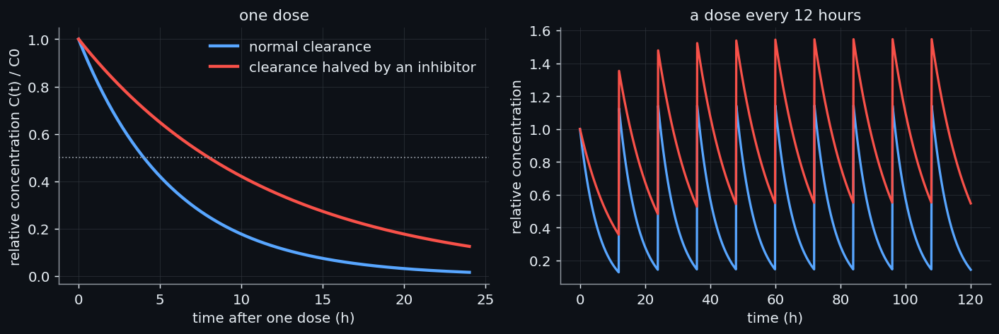

In [14]:
# One dose, first-order elimination: C(t) = C0 exp(-k t). The elimination rate constant of the example is chosen so that the half-life is four hours.
half_life_h = 4.0
k = np.log(2) / half_life_h                   # per hour
t = np.linspace(0, 24, 241)
C0 = 1.0                                      # relative concentration right after the dose
with_inhibitor_k = k / 2                      # an inhibitor that halves the clearance halves k
print(f"k = {k:.4f} per hour; half-life {np.log(2) / k:.1f} h; with the inhibitor k = {with_inhibitor_k:.4f} per hour and half-life {np.log(2) / with_inhibitor_k:.1f} h")

# Repeated dosing every 12 hours: the concentration after n doses is the sum of the decaying remains of every earlier dose.
tau = 12.0
grid = np.linspace(0, 120, 1201)
def after_doses(rate):
    c = np.zeros_like(grid)
    for dose_time in np.arange(0, 120, tau):
        c += np.where(grid >= dose_time, C0 * np.exp(-rate * (grid - dose_time)), 0.0)
    return c
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
left.plot(t, C0 * np.exp(-k * t), color=theme["blue"], lw=2.4, label="normal clearance")
left.plot(t, C0 * np.exp(-with_inhibitor_k * t), color=theme["red"], lw=2.4, label="clearance halved by an inhibitor")
left.axhline(0.5, color=theme["muted"], ls=":", lw=1)
left.set(xlabel="time after one dose (h)", ylabel="relative concentration C(t) / C0", title="one dose")
left.legend(frameon=False)
tidy(left, theme)
normal, inhibited = after_doses(k), after_doses(with_inhibitor_k)
right.plot(grid, normal, color=theme["blue"], lw=1.8)
right.plot(grid, inhibited, color=theme["red"], lw=1.8)
right.set(xlabel="time (h)", ylabel="relative concentration", title="a dose every 12 hours")
tidy(right, theme)
fig.tight_layout()
average_last = [x[grid >= 108].mean() for x in (normal, inhibited)]
print(f"mean concentration over the last dosing interval: {average_last[0]:.2f} without and {average_last[1]:.2f} with the inhibitor, a ratio of {average_last[1] / average_last[0]:.2f}")

The curves show what the equations promise. With the clearance halved, the half-life doubles. The right panel shows the consequence that matters for patients, who take a drug repeatedly.
When one dose is taken every $\tau$ hours, the amount of drug entering the body in each interval is a fraction $F$ of the dose $D$ (the fraction that is absorbed). After many doses the body
reaches a **steady state** in which the same amount leaves in each interval as enters. The amount that leaves in an interval is the clearance times the **area under the concentration curve**
(the integral of the concentration over time, written $\mathrm{AUC}$) over that interval, which is $\mathrm{CL}\,\bar C\,\tau$ when $\bar C$ is the average concentration, so

$$F\,D = \mathrm{CL}\,\bar C\,\tau \quad\Longrightarrow\quad \bar C = \frac{F\,D}{\mathrm{CL}\,\tau}.$$

The average concentration is inversely proportional to the clearance: halving the clearance doubles the average concentration at steady state, as the cell printed. A dose that was safe
alone becomes twice as strong when another drug inhibits the enzyme that removes it. How much stronger depends on how strongly the other drug inhibits the enzyme, which is what the rest
of this part is about.

## 1.2 Enzymes: what a catalyst does, and the Michaelis-Menten equation

> **Field:** Biochemistry · Mathematics (rate equations)

An enzyme $E$ binds the molecule it acts on, the **substrate** $S$, to form a complex $ES$. The complex either falls apart again or converts the substrate into a product $P$ and releases the enzyme
unchanged, ready for another substrate molecule:

$$E + S \;\underset{k_{-1}}{\overset{k_{1}}{\rightleftharpoons}}\; ES \;\overset{k_{\mathrm{cat}}}{\longrightarrow}\; E + P .$$

Each arrow carries a **rate constant**: $k_1$ for binding (units: 1/(concentration x time)), $k_{-1}$ for falling apart and $k_{\mathrm{cat}}$ for the chemical step (both 1/time). Square brackets
denote concentrations, and $t$ is the time. By the law of mass action the complex forms at the rate $k_1 [E][S]$ and disappears at the rate $(k_{-1} + k_{\mathrm{cat}})[ES]$. After a very short time the
concentration of the complex stops changing, because it forms as fast as it disappears (the **steady-state assumption** of Briggs and Haldane, 1925):

$$\frac{d[ES]}{dt} = 0 \quad\Longrightarrow\quad k_1 [E][S] = (k_{-1} + k_{\mathrm{cat}})\,[ES].$$

The free enzyme is not known directly, but the total amount of enzyme is fixed, $[E]_T = [E] + [ES]$. Replacing $[E]$ by $[E]_T - [ES]$ and solving for $[ES]$ gives

$$[ES] = \frac{[E]_T\,[S]}{K_M + [S]}, \qquad K_M = \frac{k_{-1} + k_{\mathrm{cat}}}{k_1}.$$

The constant $K_M$ is called the **Michaelis constant**; it has the units of a concentration. The rate $v$ at which product appears is $k_{\mathrm{cat}}[ES]$, so

$$v = \frac{V_{\max}\,[S]}{K_M + [S]}, \qquad V_{\max} = k_{\mathrm{cat}}\,[E]_T .$$

This is the **Michaelis-Menten equation** (Michaelis and Menten, 1913, derived there from a different assumption and re-derived in this form by Briggs and Haldane). Two limits explain its shape.
When $[S] \ll K_M$ the denominator is almost $K_M$ and $v \approx (V_{\max}/K_M)[S]$: the rate is proportional to the substrate concentration, which is the first-order behaviour that section 1.1
assumed, and the ratio $V_{\max}/K_M$ is the **intrinsic clearance** of the enzyme. When $[S] \gg K_M$ the rate approaches $V_{\max}$ whatever the concentration: every enzyme molecule is busy and the
enzyme is **saturated**. At $[S] = K_M$ the rate is exactly $V_{\max}/2$. The figure shows the curve; its inset shows the older way of plotting the same data, $1/v$ against $1/[S]$ (Lineweaver and Burk),
which turns the curve into a straight line with intercept $1/V_{\max}$ and slope $K_M/V_{\max}$.

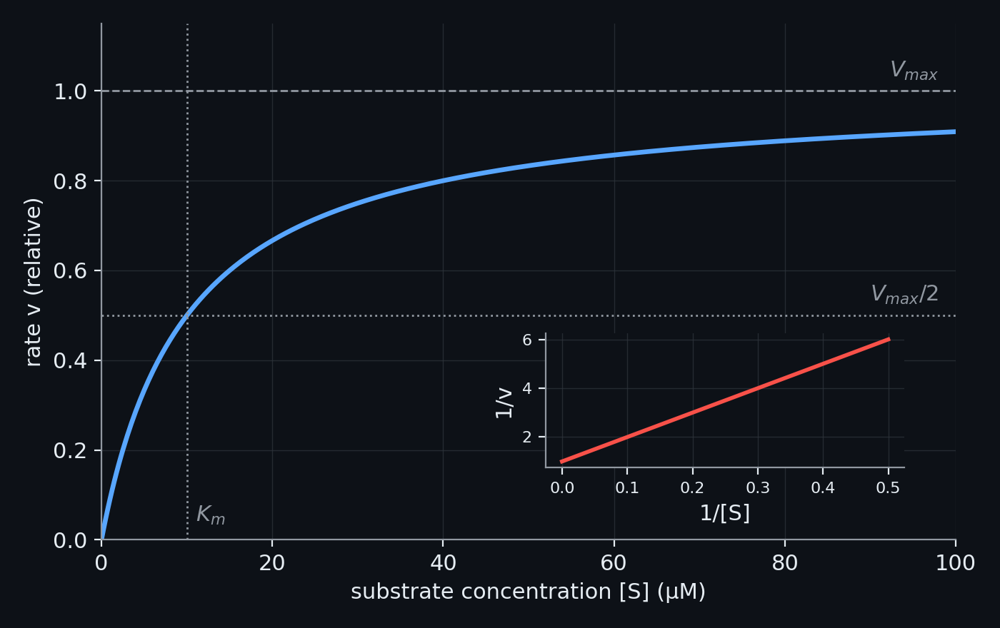

**Figure: Michaelis-Menten saturation and its double-reciprocal form.** Reaction rate v against substrate concentration [S]: v = Vmax [S] / (Km + [S]). The rate approaches Vmax; Km is the concentration that gives Vmax/2. The inset plots 1/v against 1/[S] (Lineweaver-Burk), where the same data fall on a straight line with slope Km/Vmax and intercept 1/Vmax.

In [15]:
show_figure("kin_michaelis_menten")

The steady-state assumption is an approximation, and the next cell checks it. It integrates the three differential equations of the scheme numerically (for a made-up enzyme with
$k_1 = 5$ per micromolar per second, $k_{-1} = 40$ per second, $k_{\mathrm{cat}} = 10$ per second and 0.01 micromolar of enzyme) and compares the rate of product formation, taken half a second
after mixing, with the Michaelis-Menten equation.

In [16]:
# The scheme E + S <-> ES -> E + P integrated as differential equations, and compared with the Michaelis-Menten rate.
from scipy.integrate import solve_ivp

k1, k_1, kcat, E_total = 5.0, 40.0, 10.0, 0.01     # per uM per s, per s, per s, uM
KM = (k_1 + kcat) / k1
Vmax = kcat * E_total
def scheme(_, y, S0):
    E, S, ES, P = y
    bind, unbind, turn = k1 * E * S, k_1 * ES, kcat * ES
    return [-bind + unbind + turn, -bind + unbind, bind - unbind - turn, turn]
rows = []
for S0 in (1.0, 5.0, 10.0, 50.0, 200.0):
    run = solve_ivp(scheme, (0, 60), [E_total, S0, 0.0, 0.0], args=(S0,), method="LSODA", dense_output=True, rtol=1e-9, atol=1e-12)
    rate = kcat * run.sol(0.5)[2]                  # rate of product formation after the initial transient (E << S, so S has hardly changed)
    rows.append({"S0 (uM)": S0, "rate from the full scheme (uM/s)": rate, "Vmax S / (KM + S) (uM/s)": Vmax * S0 / (KM + S0)})
import pandas as pd

table = pd.DataFrame(rows)
table["relative difference"] = table.iloc[:, 1] / table.iloc[:, 2] - 1
print(f"KM = (k-1 + kcat) / k1 = {KM:.1f} uM, Vmax = kcat [E]total = {Vmax:.3f} uM/s")
show_table(table, floatfmt=".4f")

KM = (k-1 + kcat) / k1 = 10.0 uM, Vmax = kcat [E]total = 0.100 uM/s


| S0 (uM) | rate from the full scheme (uM/s) | Vmax S / (KM + S) (uM/s) | relative difference |
| --- | --- | --- | --- |
| 1.0000 | 0.0090 | 0.0091 | -0.0046 |
| 5.0000 | 0.0332 | 0.0333 | -0.0025 |
| 10.0000 | 0.0499 | 0.0500 | -0.0015 |
| 50.0000 | 0.0833 | 0.0833 | -0.0002 |
| 200.0000 | 0.0952 | 0.0952 | -0.0000 |

The two agree to within a fraction of a percent at every substrate concentration, because the enzyme is present in a much smaller amount than the substrate. That condition is the one under which the
equation is valid, and it holds in a typical inhibition assay, where the enzyme is present at nanomolar and the tested compound at micromolar concentrations.

## 1.3 Cytochrome P450: the heme, the iron and the catalytic cycle

> **Field:** Biochemistry · Chemistry (the iron of the heme)

The name of the family comes from a pigment (P) first seen in liver cell fragments in 1958 and characterised by Omura and Sato (1962, 1964): it absorbs light of wavelength 450 nanometres (hence 450) when
its iron is reduced and bound to carbon monoxide. The pigment turned out to be a protein with a heme at its centre. A P450 enzyme is a **monooxygenase**: it takes one of the two oxygen atoms of an oxygen
molecule and inserts it into a substrate $\mathrm{RH}$ (a carbon-hydrogen bond becomes a carbon-hydroxyl bond), reducing the other to water, using two electrons supplied by a second protein that
receives them from NADPH (the reduced form of nicotinamide adenine dinucleotide phosphate, a small molecule that carries electrons):

$$\mathrm{RH} + \mathrm{O_2} + \mathrm{NADPH} + \mathrm{H^+} \;\longrightarrow\; \mathrm{ROH} + \mathrm{H_2O} + \mathrm{NADP^+}.$$

(NADPH is a small molecule that carries electrons in cells; $\mathrm{H^+}$ is a proton.) The heme (iron protoporphyrin IX) is a flat ring of carbon and nitrogen atoms, the porphyrin, with an iron atom in the
middle held by its four nitrogens. The iron has two more places to bind, above and below the ring. Below the ring a sulfur atom of a cysteine of the protein binds to it, the **axial cysteine**; above the ring
is the site where oxygen, and everything this project is concerned with, binds. The cysteine is part of a stretch of amino acids that is nearly the same in all P450 enzymes, a signature that the project's code uses
to find it in any sequence:

In [17]:
# The conserved heme-binding signature of the P450 family (F..G...C.G) in the sequence of CYP3A4, and the cysteine that binds the iron, found by the project's own code.
import re

from cypmode.validation.build_input import CYS_MOTIF_PATTERN, find_coordinating_cysteine
from cypmode.validation.constants import CYP3A4_SEQUENCE

match = re.search(CYS_MOTIF_PATTERN, CYP3A4_SEQUENCE)
position = find_coordinating_cysteine(CYP3A4_SEQUENCE)
print(f"CYP3A4 (UniProt P08684) has {len(CYP3A4_SEQUENCE)} amino acids; the signature {match.group(0)} starts at residue {match.start() + 1}; the cysteine that binds the iron is residue {position} ({CYP3A4_SEQUENCE[position - 1]}).")

CYP3A4 (UniProt P08684) has 503 amino acids; the signature FGSGPRNCIG starts at residue 435; the cysteine that binds the iron is residue 442 (C).


**The catalytic cycle.** The enzyme performs the reaction in eight steps, drawn in the figure around the real heme of a CYP3A4 crystal structure. In the resting state the iron holds a water molecule as its sixth
ligand (1). The substrate enters the pocket and pushes the water out (2). The iron receives an electron (3) and binds an oxygen molecule (4); a second electron (5) and two protons (6) split the oxygen: one atom leaves
as water, the other stays on the iron as a highly reactive species called Compound I. Compound I takes a hydrogen atom from the substrate (7), and the resulting radical picks up the hydroxyl from the iron
(8, "oxygen rebound"); the product leaves and a water molecule returns. The same cycle explains how an inhibitor can act. A molecule that competes with the substrate for the pocket slows step 2. A molecule that
binds the iron itself keeps oxygen from step 4. A molecule that the enzyme converts, in steps 6 to 8, into something reactive that attaches to the heme or to the protein switches the enzyme off for good:
that is the time-dependent inhibition this project predicts (section 1.6).

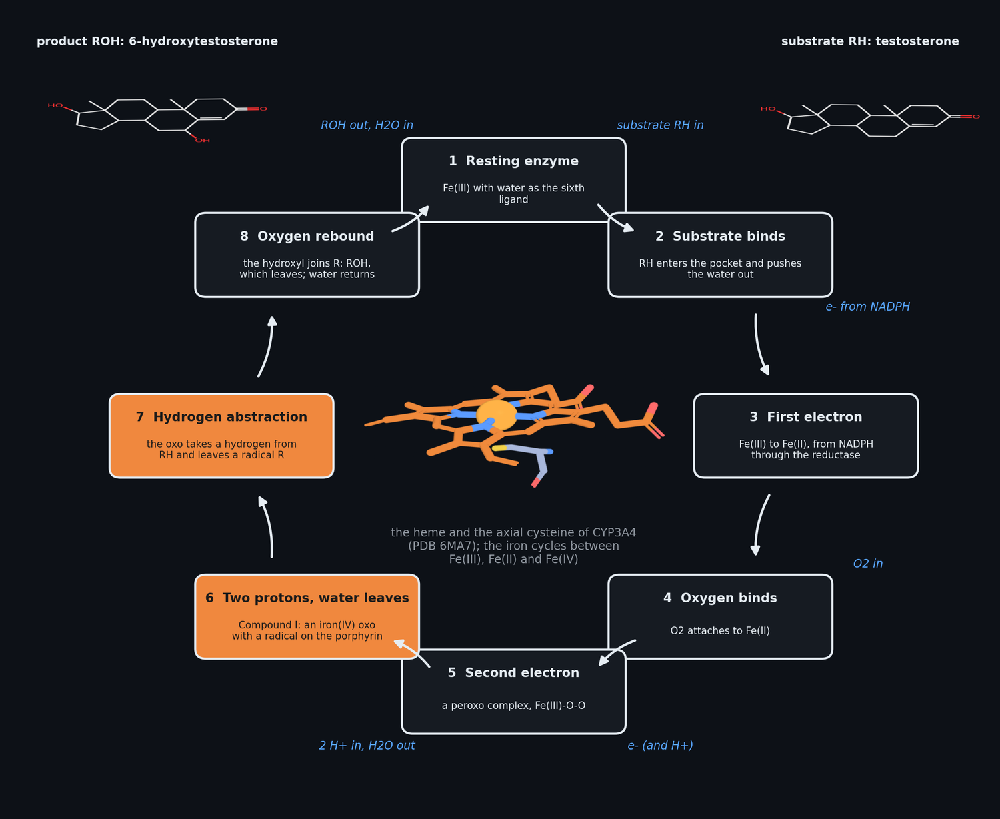

**Figure: The catalytic cycle of a cytochrome P450.** The eight steps by which a P450 oxidises a substrate RH to ROH with one oxygen atom from O2 and two electrons from NADPH. A molecule that competes for step 2, or that binds the iron so that step 4 cannot happen, switches the enzyme off while it is bound (reversible inhibition). A molecule that the enzyme itself converts in steps 6 to 8 into something that stays attached to the heme or the protein switches it off for good: that is time-dependent inhibition, the label this project predicts. In the middle, the real heme and the axial cysteine of CYP3A4 rendered from its crystal structure (PDB 6MA7); at the top, a real substrate of the enzyme, testosterone, and its classic CYP3A4 product, 6-hydroxytestosterone.

In [18]:
show_figure("bio_p450_cycle")

**The two enzymes of this project.** Humans have 57 CYP enzymes; a handful of them do most of the work of drug metabolism. **CYP3A4** has a large, flexible active site and accepts molecules of very
different sizes and shapes: crystal structures with different ligands show a pocket that adapts its volume to the guest (Williams and co-workers, 2004, with metyrapone and progesterone, and the
cryo-EM preprint of section 0.2). **CYP2D6** has a narrower pocket with two negatively charged residues near the active site (an aspartate at position 301 and a glutamate at position 216; Rowland and
co-workers, 2006), and it prefers molecules with a positively charged (basic) nitrogen, which it can hold electrostatically. The difference between the two pockets is one reason a model that works for
one enzyme need not work for the other, and the project's results for the two enzymes differ accordingly (Part VIII).

## 1.4 Drug-drug interactions and why inhibition matters clinically

> **Field:** Pharmacology

Section 1.1 showed that a lower clearance means a longer half-life and a higher average concentration. This section turns that into a number that tells how large an interaction can be, in terms of the
quantities that the assays of this project measure.

Let a drug be removed by two routes: the enzyme in question, with clearance $\mathrm{CL}_E$, and everything else, with clearance $\mathrm{CL}_{\mathrm{other}}$. The total clearance is the sum. The
**fraction metabolised** by the enzyme is $f_m = \mathrm{CL}_E / (\mathrm{CL}_E + \mathrm{CL}_{\mathrm{other}})$. After a single dose the **area under the concentration curve** ($\mathrm{AUC}$, the integral of
$C(t)$ over time) is $F\,D/\mathrm{CL}$, so exposure is inversely proportional to the total clearance. At concentrations far below $K_M$ the clearance of the enzyme is its intrinsic clearance
$V_{\max}/K_M$ (section 1.2). A competitive inhibitor at concentration $[I]$ multiplies the apparent $K_M$ by $1 + [I]/K_i$ (derived in section 1.5), so the clearance of the enzyme falls to
$\mathrm{CL}_E/(1 + [I]/K_i)$. For a constant concentration of the inhibitor at the enzyme, dividing the exposure with the inhibitor by the exposure without it gives the **ratio of the areas under the curve**:

$$\frac{\mathrm{AUC}_{\mathrm{with\ inhibitor}}}{\mathrm{AUC}} = \frac{1}{\dfrac{f_m}{1 + [I]/K_i} + (1 - f_m)} .$$

If the enzyme removes all of the drug ($f_m = 1$), the ratio is $1 + [I]/K_i$: an inhibitor at ten times its $K_i$ raises the exposure elevenfold. If the enzyme removes only half ($f_m = 0.5$), the
other route caps the effect at a factor of two however strong the inhibitor is. The cell tabulates the relation.

In [19]:
# The increase in exposure (AUC ratio) caused by a competitive inhibitor, for an enzyme that handles a fraction f_m of the drug's clearance.
from itertools import product

ratio = lambda fm, I_over_Ki: 1 / (fm / (1 + I_over_Ki) + (1 - fm))
rows = [{"[I] / Ki": x, **{f"f_m = {fm}": ratio(fm, x) for fm in (0.5, 0.9, 0.99)}} for x in (0.1, 1, 3, 10, 30, 100)]
show_table(pd.DataFrame(rows), floatfmt=".2f")

| [I] / Ki | f_m = 0.5 | f_m = 0.9 | f_m = 0.99 |
| --- | --- | --- | --- |
| 0.10 | 1.05 | 1.09 | 1.10 |
| 1.00 | 1.33 | 1.82 | 1.98 |
| 3.00 | 1.60 | 3.08 | 3.88 |
| 10.00 | 1.83 | 5.50 | 10.00 |
| 30.00 | 1.94 | 7.75 | 23.85 |
| 100.00 | 1.98 | 9.18 | 50.50 |

Regulators have made this reasoning routine: drug developers are expected to measure the inhibition of the main CYP enzymes in vitro and to compare the concentration of the inhibitor that reaches the liver with
its $K_i$ or its **IC50**, the concentration that halves the enzyme's activity (section 1.5), as the 2020 guidance of the US Food and Drug Administration (FDA) on in vitro interaction studies and the European Medicines Agency's 2012 guideline on drug interactions ask. Ketoconazole, a strong inhibitor of CYP3A4, and ritonavir, which
is given in small doses with other drugs against HIV (the virus behind AIDS) precisely because it inhibits CYP3A4 and so raises their levels, are standard examples.

For a time-dependent inhibitor the argument changes in a way that explains why the interaction can last for days. The body makes new enzyme at a constant rate $k_{\mathrm{syn}}$ and breaks it down at a
rate $k_{\mathrm{deg}}\,E$, which gives a steady-state enzyme amount $E_0 = k_{\mathrm{syn}}/k_{\mathrm{deg}}$. An inhibitor that inactivates the enzyme at the rate $k_{\mathrm{obs}}\,E$ (section 1.6 derives
$k_{\mathrm{obs}}$) adds a second loss, so that $dE/dt = k_{\mathrm{syn}} - (k_{\mathrm{deg}} + k_{\mathrm{obs}})E$ and the new steady state is

$$E_{\mathrm{ss}} = \frac{k_{\mathrm{syn}}}{k_{\mathrm{deg}} + k_{\mathrm{obs}}} = \frac{E_0}{1 + k_{\mathrm{obs}}/k_{\mathrm{deg}}} .$$

The activity falls by the factor $1 + k_{\mathrm{obs}}/k_{\mathrm{deg}}$ and, because the enzyme is only replaced at the rate $k_{\mathrm{syn}}$, it takes about the enzyme's own half-life (days) to come back
after the last dose. The cell shows how large the effect becomes when the inactivation rate is compared with the turnover of an enzyme with a half-life of three days (an illustrative value).

In [20]:
# Time-dependent inhibition and enzyme turnover: the activity left at steady state is 1 / (1 + k_obs / k_deg). For an illustrative enzyme half-life of three days:
k_deg = np.log(2) / (3 * 24)                      # per hour
rows = [{"k_obs (per hour)": kobs, "activity left at steady state": 1 / (1 + kobs / k_deg), "fold increase in exposure if the enzyme clears all the drug": 1 + kobs / k_deg}
        for kobs in (0.001, 0.005, 0.02, 0.1)]
show_table(pd.DataFrame(rows), floatfmt=".3f")

| k_obs (per hour) | activity left at steady state | fold increase in exposure if the enzyme clears all the drug |
| --- | --- | --- |
| 0.001 | 0.906 | 1.104 |
| 0.005 | 0.658 | 1.519 |
| 0.020 | 0.325 | 3.077 |
| 0.100 | 0.088 | 11.387 |

The conclusion for this project is practical. An inhibitor is judged by how potent it is (the lower its IC50 or $K_i$, the larger the factor above) and, for a time-dependent inhibitor, also by how fast it
inactivates the enzyme. Predicting from a molecule's structure whether it is a time-dependent inhibitor is therefore predicting a property that changes the size and the duration of an interaction.

## 1.5 Reversible inhibition: competitive, non-competitive and mixed

> **Field:** Biochemistry · Mathematics (rate equations)

A reversible inhibitor $I$ binds the enzyme and lets go again, with no chemical change. It can bind the free enzyme, forming $EI$, with the dissociation constant $K_i$ (the concentration of $I$ at which half of
the enzyme is bound in the absence of substrate); it can bind the complex $ES$, forming $ESI$, with the dissociation constant $K_i'$; or both. The rates below are derived under the same steady-state
assumption as in section 1.2, with the added fast equilibria $[E][I] = K_i [EI]$ and $[ES][I] = K_i' [ESI]$. Conservation of enzyme now reads $[E]_T = [E] + [ES] + [EI] + [ESI]$. Define the two factors

$$\alpha = 1 + \frac{[I]}{K_i}, \qquad \alpha' = 1 + \frac{[I]}{K_i'} .$$

Writing every enzyme form in terms of $[E]$ and solving for the rate $v = k_{\mathrm{cat}}[ES]$ (the steps are those of section 1.2 with the extra terms collected in $\alpha$ and $\alpha'$) gives

$$v = \frac{V_{\max}\,[S]}{\alpha\,K_M + \alpha'\,[S]} = \frac{V_{\max}/\alpha'\;[S]}{(\alpha/\alpha')\,K_M + [S]} .$$

The second form is again a Michaelis-Menten equation, with an apparent maximum rate $V_{\max}/\alpha'$ and an apparent Michaelis constant $(\alpha/\alpha')K_M$. The type of inhibition is the pattern of how these two change:

- **Competitive**: the inhibitor binds only the free enzyme, so $K_i' \to \infty$ and $\alpha' = 1$. The apparent $K_M$ grows by $\alpha$ and $V_{\max}$ is unchanged: enough substrate wins the competition. This is the case of
  section 1.4 and of molecules that sit in the substrate pocket.
- **Non-competitive**: the inhibitor binds the enzyme and the complex equally well, $K_i = K_i'$, so $\alpha = \alpha'$. $K_M$ is unchanged and $V_{\max}$ falls by $\alpha$.
- **Uncompetitive**: the inhibitor binds only the complex, $\alpha = 1$. Both apparent constants fall by the same factor $\alpha'$.
- **Mixed**: any other case, with $K_i \ne K_i'$ and both finite.

The figure draws the four cases for one choice of numbers.

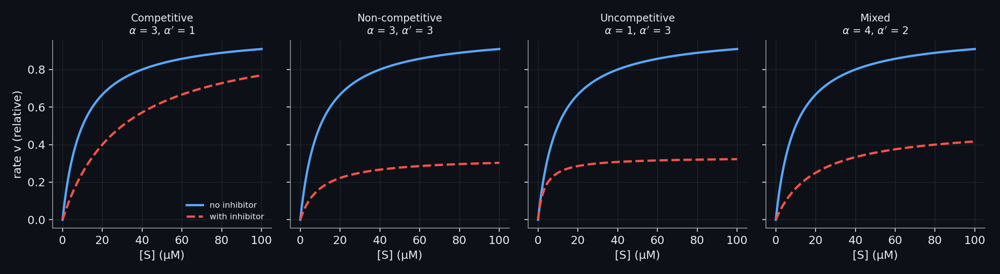

**Figure: Reversible inhibition: competitive, non-competitive, uncompetitive and mixed.** The same enzyme without inhibitor (solid) and with a fixed inhibitor concentration (dashed). With alpha = 1 + [I]/Ki and alpha' = 1 + [I]/Ki', the apparent constants are Vmax/alpha' and Km alpha/alpha'. Competitive (alpha > 1, alpha' = 1): Km rises, Vmax unchanged. Non-competitive (alpha = alpha'): Vmax falls, Km unchanged. Uncompetitive (alpha = 1, alpha' > 1): both fall by the same factor. Mixed (alpha > alpha' > 1): Km rises and Vmax falls.

In [21]:
show_figure("kin_inhibition_types")

**The IC50 and the dependence on the substrate.** The experiments of this project do not measure $K_i$. They measure the concentration of the inhibitor that halves the rate, the **IC50**, at one fixed
substrate concentration. For a competitive inhibitor the rate is $v_0\,\dfrac{1}{1 + [I]/\bigl(K_i(1 + [S]/K_M)\bigr)}$ (setting $\alpha' = 1$ in the equation above and dividing by the rate $v_0$ without inhibitor, which
is $V_{\max}[S]/(K_M + [S])$). The rate is halved when $[I] = K_i\,(1 + [S]/K_M)$, so

$$\mathrm{IC}_{50} = K_i\left(1 + \frac{[S]}{K_M}\right) \qquad\text{(Cheng and Prusoff, 1973)}.$$

The IC50 is not a property of the inhibitor alone: it grows with the substrate concentration of the assay. Only when $[S] \ll K_M$ does it equal $K_i$. The cell shows the dependence for $K_i = 1$ micromolar.

In [22]:
# The IC50 of a competitive inhibitor depends on the substrate concentration used: IC50 = Ki (1 + [S] / KM) (Cheng and Prusoff). With Ki = 1 uM and KM = 10 uM:
Ki, KM_assay = 1.0, 10.0
rows = [{"[S] / KM": s, "IC50 (uM)": Ki * (1 + s)} for s in (0.1, 0.5, 1.0, 5.0)]
show_table(pd.DataFrame(rows), floatfmt=".2f")

| [S] / KM | IC50 (uM) |
| --- | --- |
| 0.10 | 1.10 |
| 0.50 | 1.50 |
| 1.00 | 2.00 |
| 5.00 | 6.00 |

For the purposes of this project the IC50, measured in the same conditions for every compound, is a fair measure to compare compounds with one another, and that is how section 1.7 uses it.

## 1.6 Time-dependent inhibition: the kinetics of switching an enzyme off

> **Field:** Biochemistry · Mathematics (kinetics)

A **mechanism-based inactivator** is a molecule that the enzyme itself converts, in its normal catalytic cycle, into a species that reacts with the enzyme and disables it. Its kinetic scheme has two steps. The
inhibitor $I$ first binds reversibly, $E + I \rightleftharpoons EI$, with dissociation constant $K_I = k_{\mathrm{off}}/k_{\mathrm{on}}$ (a larger $K_I$ means weaker binding). The complex then converts, at the rate
constant $k_{\mathrm{inact}}$, into a dead enzyme $E\!-\!I^*$ that does not recover:

$$E + I \;\underset{k_{\mathrm{off}}}{\overset{k_{\mathrm{on}}}{\rightleftharpoons}}\; EI \;\overset{k_{\mathrm{inact}}}{\longrightarrow}\; E\!-\!I^* .$$

The enzyme that can still work is the free enzyme plus the reversible complex, $E_{\mathrm{act}} = E + EI$. If the first step is fast compared with the second (the usual case), the two forms stay in
equilibrium, and the share of the active enzyme that sits in the complex is $[EI]/E_{\mathrm{act}} = [I]/(K_I + [I])$. Only the complex is inactivated, at the rate $k_{\mathrm{inact}}[EI]$, so that, with $t$ the time since the inhibitor was added,

$$\frac{dE_{\mathrm{act}}}{dt} = -k_{\mathrm{inact}}\,[EI] = -\underbrace{\frac{k_{\mathrm{inact}}\,[I]}{K_I + [I]}}_{k_{\mathrm{obs}}}\;E_{\mathrm{act}} \quad\Longrightarrow\quad E_{\mathrm{act}}(t) = E_0\,e^{-k_{\mathrm{obs}}\,t}.$$

The same exponential decay as in section 1.1 appears, now for the activity of the enzyme, with an **observed inactivation rate** $k_{\mathrm{obs}}$ that depends on the inhibitor concentration in a saturating way
(compare section 1.2): it is proportional to $[I]$ when $[I] \ll K_I$, reaches half of its maximum $k_{\mathrm{inact}}$ at $[I] = K_I$, and cannot exceed $k_{\mathrm{inact}}$. The half-life of the activity under
a given $[I]$ is $\ln 2 / k_{\mathrm{obs}}$. The ratio $k_{\mathrm{inact}}/K_I$ is the efficiency of the inactivator, the analogue of $V_{\max}/K_M$.

The experiment that measures these constants has a standard form. The enzyme is mixed with several concentrations of the inhibitor and the cofactor NADPH, which the enzyme needs to turn the inhibitor over;
samples are taken after different pre-incubation times and diluted into a mixture containing a substrate, so that the inhibitor no longer competes, and the remaining activity is measured. A plot of
$\ln(\mathrm{activity})$ against pre-incubation time is a straight line for each concentration, with slope $-k_{\mathrm{obs}}$; a plot of $k_{\mathrm{obs}}$ against $[I]$ is the saturating curve from which $k_{\mathrm{inact}}$ and $K_I$
are fitted. The criteria that distinguish true mechanism-based inactivation from slow reversible binding (loss of activity that depends on time, on the concentration and on NADPH, that is not restored by dialysis, and
that is slowed by a competing substrate) go back to Silverman (1995). The cell integrates the three differential equations of the scheme and compares the observed rate with the closed form.

In [23]:
# The scheme E + I <-> EI -> E-I* integrated as differential equations (the rate constants of the figure below), and compared with the closed form E_active(t) = E0 exp(-k_obs t),
# k_obs = k_inact [I] / (K_I + [I]), where E_active = E + EI is the enzyme that is not yet dead.
from scipy.integrate import solve_ivp

K_ON, K_OFF, K_INACT = 50.0, 500.0, 0.8            # per uM per min, per min, per min
K_I = K_OFF / K_ON
def scheme(_, y, conc):
    E, EI, dead = y
    bind, unbind, kill = K_ON * conc * E, K_OFF * EI, K_INACT * EI
    return [-bind + unbind, bind - unbind - kill, kill]
times = np.linspace(0, 12, 121)
rows = []
for conc in (2.0, 10.0, 50.0, 200.0):
    run = solve_ivp(scheme, (0, 12), [1.0, 0.0, 0.0], t_eval=times, args=(conc,), method="LSODA", rtol=1e-10, atol=1e-12)
    active = run.y[0] + run.y[1]
    slope = -np.polyfit(times[20:], np.log(active[20:]), 1)[0]          # the slope of ln(activity) against time once the fast binding has settled
    rows.append({"[I] (uM)": conc, "k_obs from the simulation (1/min)": slope, "k_inact [I] / (K_I + [I]) (1/min)": K_INACT * conc / (K_I + conc),
                 "half-life of the activity (min)": np.log(2) / slope})
print(f"K_I = k_off / k_on = {K_I:.0f} uM, k_inact = {K_INACT} per min")
show_table(pd.DataFrame(rows), floatfmt=".4f")

K_I = k_off / k_on = 10 uM, k_inact = 0.8 per min


| [I] (uM) | k_obs from the simulation (1/min) | k_inact [I] / (K_I + [I]) (1/min) | half-life of the activity (min) |
| --- | --- | --- | --- |
| 2.0000 | 0.1332 | 0.1333 | 5.2044 |
| 10.0000 | 0.3998 | 0.4000 | 1.7336 |
| 50.0000 | 0.6666 | 0.6667 | 1.0398 |
| 200.0000 | 0.7619 | 0.7619 | 0.9098 |

The slopes of the simulated activity agree with the closed form, and the half-life of the activity falls from 5.2 minutes at 2 micromolar to 0.9 minutes at 200 micromolar, which is the
signature of a time-dependent inhibitor: the more inhibitor, the faster the enzyme is lost, up to the limit set by $k_{\mathrm{inact}}$. The figure shows the progress curves and the saturation of $k_{\mathrm{obs}}$ for the same rate constants.

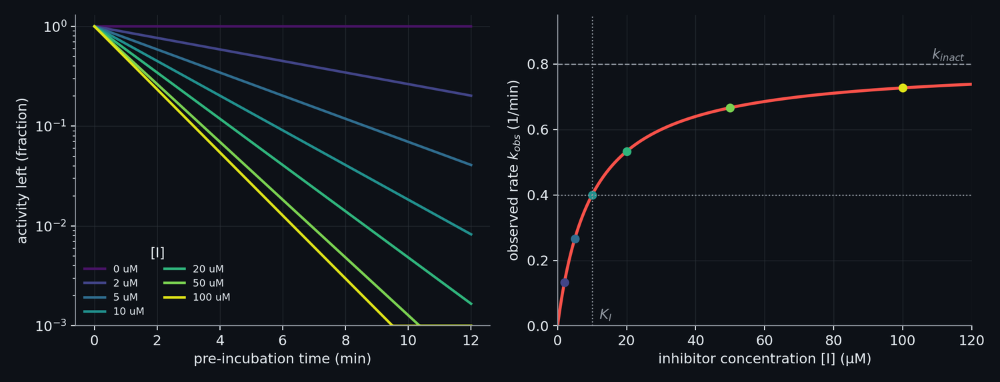

**Figure: Time-dependent inhibition: progress curves and the observed rate.** Left: enzyme activity left after pre-incubation with inhibitor, integrated from E + I <-> EI -> E-I*; each straight segment on the log scale has slope -k_obs. Right: k_obs rises with inhibitor concentration and saturates at k_inact: k_obs = k_inact [I] / (K_I + [I]). K_I is the concentration giving k_inact/2.

In [24]:
show_figure("kin_tdi_progress")

## 1.7 How potency is measured: dose-response, the Hill equation, the IC50 and the pIC50 scale

> **Field:** Pharmacology · Statistics (curve fitting)

An inhibition experiment measures the activity of the enzyme at a series of inhibitor concentrations, usually in three-fold or ten-fold steps, and expresses it as a fraction of the activity without inhibitor.
The result is a **dose-response curve** that falls from 1 to 0 as the concentration grows. A single molecule of inhibitor binding one site gives, from the law of mass action, a fraction of free enzyme of
$1/(1 + [I]/K)$ where $K$ is the dissociation constant. Hill (1910), studying oxygen binding to haemoglobin, generalised this to $n$ molecules binding together, $E + nI \rightleftharpoons EI_n$ with
$[E][I]^n = K^n\,[EI_n]$. The fraction of enzyme that is free is $[E]/([E] + [EI_n]) = 1/(1 + ([I]/K)^n)$, and in practice the exponent is treated as a fitted number, the **Hill slope** $h$. Renaming the constant $K$ as the
concentration that halves the activity, the IC50, gives the **Hill equation** for the activity left, written $y$ (1 with no inhibitor, 0 with the enzyme fully blocked):

$$y = \frac{1}{1 + ([I]/\mathrm{IC}_{50})^{h}}.$$

At $[I] = \mathrm{IC}_{50}$ the activity is exactly one half, whatever $h$; the Hill slope only sets how steeply the curve falls around that point (the figure draws three values).

Potencies of different compounds span many orders of magnitude, so they are quoted on a logarithmic scale. The **pIC50** is the negative base-10 logarithm of the IC50 expressed in mol/L:

$$\mathrm{pIC}_{50} = -\log_{10}\bigl(\mathrm{IC}_{50}/(1\ \mathrm{mol/L})\bigr).$$

An IC50 of 1 micromolar ($10^{-6}$ mol/L) is a pIC50 of 6, 10 nanomolar is 8, 100 micromolar is 4. One unit of pIC50 is a ten-fold difference in potency, and a larger number means a stronger compound. This is the number
the challenge reports for every compound (section 0.3).

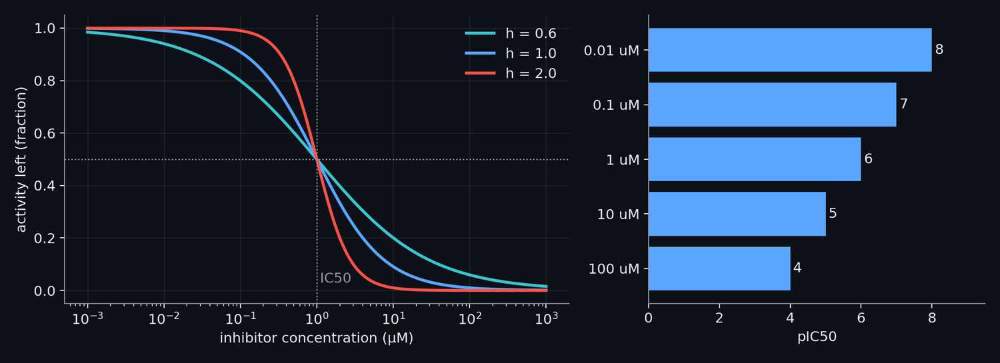

**Figure: Dose-response, the Hill equation and the pIC50 scale.** Fraction of activity left against inhibitor concentration on a log axis: y = 1 / (1 + ([I]/IC50)^h). The curve passes 50% at the IC50; the Hill slope h sets how steep it is. pIC50 = -log10(IC50 in mol/L), so an IC50 of 1 uM is pIC50 6 and each unit is a ten-fold change in potency.

In [25]:
show_figure("kin_dose_response")

The IC50 is not read off the data but fitted: the parameters of the Hill equation are chosen to minimise the squared distance to the measurements (nonlinear least squares), and the uncertainty of the fit gives a
**standard error** of the pIC50: the typical size of the error of that one fitted value, computed from how closely the curve follows the measurements. The next cell simulates one such experiment 500 times, with measurement noise, and shows that the spread of the fitted values is what the standard error of a single fit predicts. That is
why the data files carry a **standard deviation** for every pIC50, the typical size of the error of that estimate (section 2.5).

In [26]:
# A simulated dose-response experiment: ten concentrations in three-fold steps, true pIC50 = 6 (IC50 = 1 uM), Hill slope 1, 6 % measurement noise. The logistic curve is fitted in pIC50 units.
from scipy.optimize import curve_fit

def activity_left(log_conc, pic50, hill=1.0):
    return 1 / (1 + 10 ** (hill * (log_conc + pic50)))          # log_conc = log10 of the concentration in mol/L, so [I]/IC50 = 10^(log_conc + pIC50)
rng = np.random.default_rng(3)
log_conc = np.log10(1e-4 / 3.0 ** np.arange(10))                 # 100 uM down to 5 nM
estimates, errors = [], []
for _ in range(500):
    y = activity_left(log_conc, 6.0) + rng.normal(0, 0.06, size=log_conc.size)
    fit, covariance = curve_fit(lambda x, p: activity_left(x, p), log_conc, y, p0=[5.5])
    estimates.append(fit[0]); errors.append(np.sqrt(covariance[0, 0]))
print(f"500 repetitions of the experiment: mean fitted pIC50 {np.mean(estimates):.3f}; spread of the fits (standard deviation) {np.std(estimates):.3f}; typical standard error from the curve fit {np.median(errors):.3f}")

500 repetitions of the experiment: mean fitted pIC50 5.998; spread of the fits (standard deviation) 0.070; typical standard error from the curve fit 0.064


**The floor.** A dose-response curve can only be fitted well when the activity actually falls within the range of concentrations tested. A compound that does not inhibit at the highest concentration tested has an
IC50 above it, and its potency cannot be measured. The challenge's label rule (section 1.8) therefore treats every direct pIC50 below 4, that is an IC50 above 100 micromolar, as 4: the weakest effect it
distinguishes. The file nevertheless holds fitted values far below 4, and the cell counts them.

In [27]:
# How many direct-inhibition measurements of the training file lie at or below the pIC50 of 4, the weakest effect the project's label rule distinguishes?
from cypmode.challenge.tdi_targets import ASSAY_FLOOR

floor_rows = []
for enzyme in ("CYP3A4", "CYP2D6"):
    column = train[f"{enzyme}_pIC50_direct_inhibition"].dropna()
    floor_rows.append({"enzyme": enzyme, "measurements": len(column), "below the floor of 4": int((column < ASSAY_FLOOR).sum()), "equal to 4": int((column == ASSAY_FLOOR).sum()),
                 "smallest value": column.min(), "largest value": column.max()})
share_below = {r["enzyme"]: r["below the floor of 4"] / r["measurements"] for r in floor_rows}
show_table(pd.DataFrame(floor_rows), floatfmt=".2f")

| enzyme | measurements | below the floor of 4 | equal to 4 | smallest value | largest value |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | 2335 | 944 | 0 | 1.91 | 7.19 |
| CYP2D6 | 1493 | 129 | 0 | 1.95 | 7.53 |

40% of the direct measurements of CYP3A4 and 9% of those of CYP2D6 are below 4 (the smallest are near 2,
an IC50 of about ten millimolar): compounds that hardly inhibited at all, whose fitted value is an extrapolation beyond the tested range and is correspondingly uncertain. The label rule of section 1.8 therefore takes the
larger of the direct measurement and 4, so that a compound that was not measurably active in the first experiment is compared against the floor and not against an extrapolated, much weaker value.

## 1.8 The two assay arms of the challenge and the shift between them

> **Field:** Biochemistry · Pharmacology

The challenge measures every compound twice. In the **direct inhibition** arm the enzyme, the compound and a substrate are mixed together and the activity is read at once; the result is a pIC50, called
$d$ here. In the **time-dependent inhibition arm** the enzyme and the compound (with NADPH) are left together for a pre-incubation period before the substrate is added; the result is a second pIC50, called
$t$. A compound that only competes reversibly has the same potency in both experiments, because letting enzyme and compound sit together changes nothing. A mechanism-based inactivator is more potent in the second,
because the pre-incubation lets it destroy the enzyme before the substrate has a chance to compete: the second curve lies to the left of the first, as in the figure.

The size of the **shift** between the two pIC50 values follows from section 1.6. After a pre-incubation of $t_{\mathrm{pre}}$ the activity is $e^{-k_{\mathrm{obs}} t_{\mathrm{pre}}}$, which equals one half when $k_{\mathrm{obs}} = \ln 2 / t_{\mathrm{pre}}$. Setting the
saturating expression for $k_{\mathrm{obs}}$ equal to this value (with the inhibitor concentration $[I]$ and the constant $K_I$ of section 1.6) and solving for the concentration gives the IC50 after pre-incubation:

$$\frac{k_{\mathrm{inact}}\,\mathrm{IC}_{50}}{K_I + \mathrm{IC}_{50}} = \frac{\ln 2}{t_{\mathrm{pre}}} \quad\Longrightarrow\quad \mathrm{IC}_{50}(t_{\mathrm{pre}}) = K_I\,\frac{\ln 2 / t_{\mathrm{pre}}}{k_{\mathrm{inact}} - \ln 2 / t_{\mathrm{pre}}}.$$

This is finite only if $k_{\mathrm{inact}} > \ln 2/t_{\mathrm{pre}}$: an inactivator that is too slow for the length of the pre-incubation does not show a shift. The cell evaluates it for the constants of the figure.

In [28]:
# The potency shift that a time-dependent inhibitor shows after a pre-incubation of t_pre minutes, from k_obs([I]) = ln 2 / t_pre, with the constants of the figure: K_I = 10 uM, k_inact = 0.8 per min.
for t_pre in (5.0, 15.0, 30.0, 60.0):
    target = np.log(2) / t_pre                                  # the inactivation rate that halves the activity in t_pre minutes
    ic50_pre = K_I * target / (K_INACT - target)                # [I] at which k_inact [I] / (K_I + [I]) = target
    ic50_direct = K_I                                           # without a head start the inhibitor only competes (reversible part), its IC50 is of the order of K_I at best
    print(f"pre-incubation {t_pre:>4.0f} min: IC50 {ic50_pre:6.3f} uM against about {ic50_direct:.0f} uM without pre-incubation; shift in pIC50 units {np.log10(ic50_direct / ic50_pre):.2f}")

pre-incubation    5 min: IC50  2.096 uM against about 10 uM without pre-incubation; shift in pIC50 units 0.68
pre-incubation   15 min: IC50  0.613 uM against about 10 uM without pre-incubation; shift in pIC50 units 1.21
pre-incubation   30 min: IC50  0.297 uM against about 10 uM without pre-incubation; shift in pIC50 units 1.53
pre-incubation   60 min: IC50  0.147 uM against about 10 uM without pre-incubation; shift in pIC50 units 1.83


The difference between the two pIC50 values, $s = t - d$, is the **shift**. A pure reversible inhibitor has $s \approx 0$; the inactivator above has a shift of more than one pIC50 unit for pre-incubations of
fifteen minutes or longer. Since a pIC50 is a logarithm, a shift of $\log_{10} 2 = 0.301$ means that the compound became exactly twice as potent after the head start, as $10^{0.301} = 2$. The challenge defines a
compound as time-dependent when its shift exceeds that value, measured against the larger of $d$ and the floor 4, $s = t - \max(d, 4) > \log_{10} 2$; section 2.3 shows how this rule was recovered from the data and
that it reproduces every label of the file.

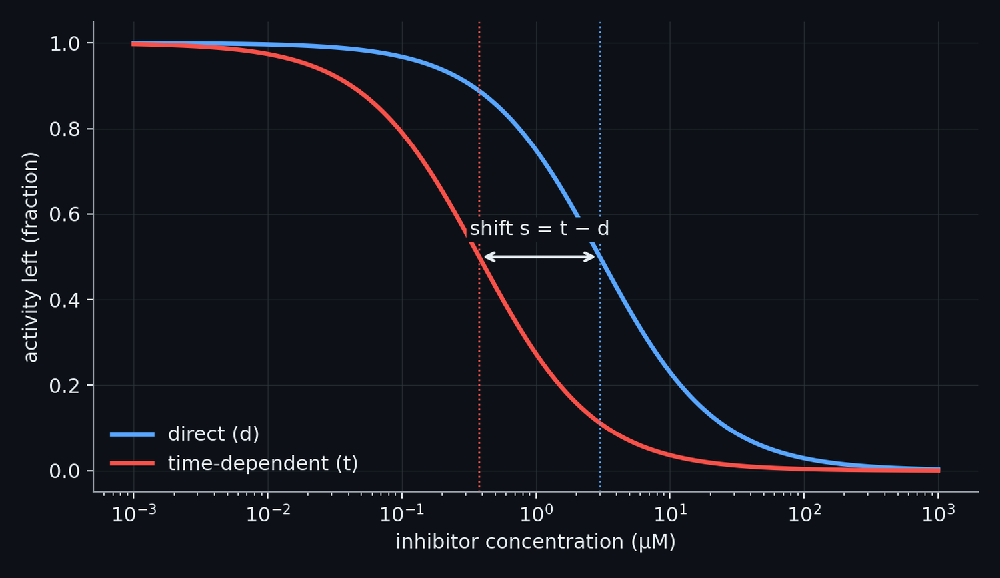

**Figure: The two assay arms and the shift.** The same compound measured twice: directly (no pre-incubation, d) and under the time-dependent condition (pre-incubated, t). A time-dependent inhibitor becomes more potent when it has time to act, so the second curve sits to the left; the distance between the two pIC50 values is the shift. The challenge calls a compound positive when t - max(d, 4) exceeds log10 2 (a two-fold gain in potency).

In [29]:
show_figure("kin_assay_arms")

## 1.9 Heme chemistry: Type I and Type II binding, and why a nitrogen binds the iron

> **Field:** Chemistry · Biochemistry

The iron at the centre of the heme can hold six ligands: four nitrogens of the porphyrin ring in a plane, the sulfur of the axial cysteine below it, and one position above the ring. In the resting enzyme
that last position is occupied by a water molecule. Two ways in which a molecule can bind in the pocket were named by the spectra they produce when added to a suspension of the enzyme (Schenkman and
co-workers, 1967): the absorption of light by the heme changes in a way that depends on what happens at the iron.

**Type I** molecules sit in the pocket near the heme and displace the water without binding the iron. The iron's electronic state changes from the low-spin form that the enzyme has in the resting state to a
high-spin form, and the difference spectrum shows a peak near 390 nanometres and a trough near 420. Most substrates are of this kind. **Type II** molecules carry a nitrogen atom that binds the iron directly and
takes the place of the water; the iron stays low-spin, and the difference spectrum has a peak near 430 nanometres and a trough near 390 to 410. The bond is a **coordinate bond**: both of its two electrons come from the
nitrogen, in the form of a **lone pair**, a pair of electrons that the nitrogen holds but does not share in any other bond. The iron, which can accept electron pairs, uses it. The nitrogen of an **aromatic** ring (a flat ring whose electrons are shared all the way round it, so that its bonds are neither single nor double, section 2.1; an imidazole, a triazole, a pyridine or a thiazole is such a ring) is well suited: its lone pair lies in the plane of the ring and points away from it, where nothing hinders the approach to the iron, and the ring itself is flat and
fits between the walls of the pocket. The iron-nitrogen distance in solved structures is about 2.0 to 2.3 angstrom (Poulos and Johnson, 2005).

A Type II molecule binds more tightly than it would by contact alone, which is why it is often a potent inhibitor, and the binding is a property of a recognisable group of atoms, which is the reason a
screen for such groups (section 0.2, Part V) is possible at all. The figure shows both kinds in real crystal structures of CYP3A4, and the cell lists how the ligands of the crystal structures collected by the
project are distributed in distance from the iron.

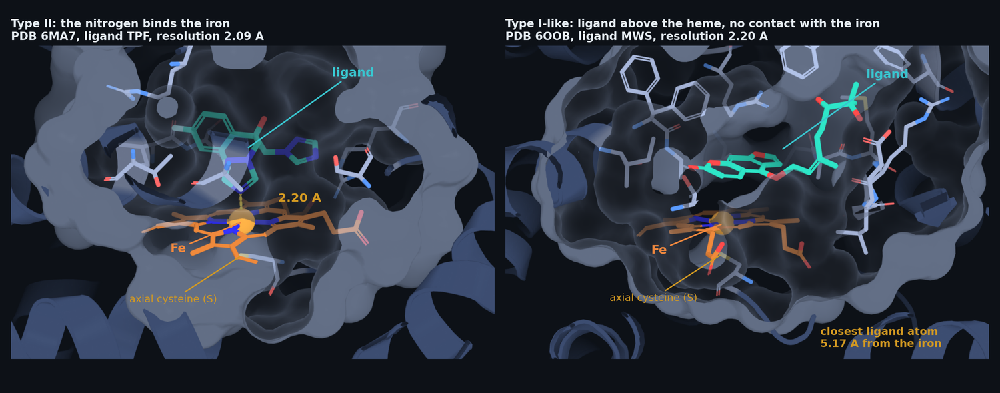

**Figure: Two ways to bind the heme, on real structures: Type II and Type I.** Two real CYP3A4 co-crystal structures, rendered from the deposited coordinates and cut open through the heme plane: the protein as a translucent cartoon, the pocket as a surface, the lining residues as thin sticks, the heme in orange with its iron as a sphere, the ligand in teal, and the iron coordination as a dashed line. Type II (PDB 6MA7, 2.09 A): a nitrogen of the ligand sits 2.19 A from the iron; 8 residues line the pocket, with 1 polar contact within 3.4 A; Type I-like (PDB 6OOB, 2.20 A): the closest ligand atom is 5.17 A from the iron, and a water molecule 2.38 A from the iron still occupies the sixth position; 15 residues line the pocket, with 1 polar contact within 3.4 A. Every distance is measured on the coordinates.

In [30]:
show_figure("bio_type1_type2")

In [31]:
# The iron-to-ligand distances in the crystal structures of CYP3A4 with a bound drug-like ligand that the project collected (data/structure_track/inputs/cyp3a4_reference_ligands.json):
# the distance from the heme iron to the closest atom of each ligand.
import json

records = json.loads((ROOT / "data/structure_track/inputs/cyp3a4_reference_ligands.json").read_text())["ligands"]
distance = pd.Series([r["min_fe_distance"] for r in records])
bins = pd.cut(distance, [0, 2.6, 3.5, 5, 8, 100], labels=["below 2.6 A (bonded)", "2.6 to 3.5 A", "3.5 to 5 A", "5 to 8 A", "above 8 A"])
table = bins.value_counts().sort_index().rename("ligands").reset_index().rename(columns={"index": "distance from the iron to the closest ligand atom"})
n_bonded = int((distance < 2.6).sum())
print(f"{len(records)} ligands in crystal structures; {n_bonded} have an atom within bonding distance of the iron")
show_table(table)

148 ligands in crystal structures; 115 have an atom within bonding distance of the iron


| distance from the iron to the closest ligand atom | ligands |
| --- | --- |
| below 2.6 A (bonded) | 115 |
| 2.6 to 3.5 A | 10 |
| 3.5 to 5 A | 10 |
| 5 to 8 A | 8 |
| above 8 A | 5 |

Most of the ligands of the crystal structures of CYP3A4 that the project collected (115 of 148) have an atom within bonding distance of the iron. That is a feature of which complexes are solved and
deposited, not a statement about molecules in general: inhibitors that bind the iron have been studied intensively, so the structures of the Protein Data Bank over-represent the Type II geometry. The consequence for this project is twofold. A
prior or a benchmark built from these structures sees mostly Type II poses (Part XI returns to this when it uses them), and a molecule that carries a group able to bind the iron is not certain to use it. The motif screen of section 0.2
and Part V asks only whether a molecule carries such a group; whether it uses it is a question about a three-dimensional pose, and Part XI is about predicting that. The four drugs of section 0.2 show both outcomes with one chemistry:

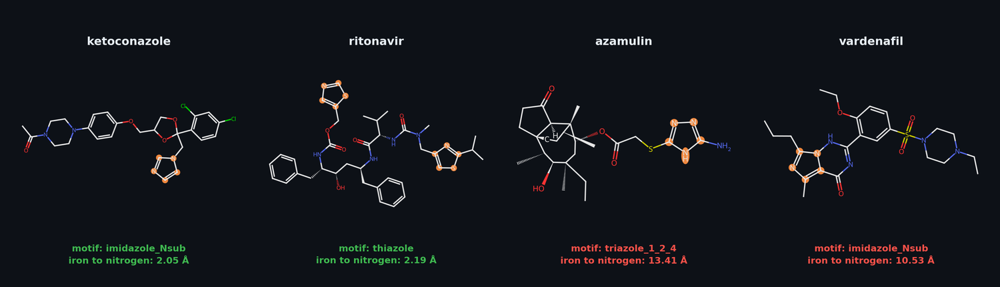

**Figure: The heme-binding motif screen on four real drugs.** The motif screen on the four drugs whose structures bound to CYP3A4 were solved by cryo-EM. Each structure is drawn from its SMILES; the atoms of the first heme-coordinating motif the screen finds (imidazole, triazole, pyridine or thiazole rings, defined in cypmode/metrics/motifs.py) are highlighted. Below each, the distance from the heme iron to the nearest motif nitrogen in the complex Boltz-2 predicted without any restraint: ketoconazole 2.05 Å (on the iron); ritonavir 2.19 Å (on the iron); azamulin 13.41 Å (not on the iron); vardenafil 10.53 Å (not on the iron). Two drugs put the nitrogen on the iron, two do not, although all four match a motif.

In [32]:
show_figure("bio_motif_screen")

## 1.10 Reactive metabolites and structural alerts

> **Field:** Chemistry · Pharmacology (toxicology)

Why does the pre-incubation make some molecules more potent? In the mechanism-based case the enzyme turns the molecule into something that reacts, and the products of the P450 cycle are strongly oxidising
(section 1.3). Four routes are textbook (Kalgutkar and co-workers, 2007; Orr and co-workers, 2012):

- **A metabolic-intermediate complex.** Many amines are oxidised, in steps ending in a nitroso compound (a nitrogen bound to an oxygen), whose nitrogen then binds the iron of the reduced heme so tightly that the
  complex is, for practical purposes, permanent. This is the route of tertiary alkylamines such as those of macrolide antibiotics.
- **A carbene complex.** The methylenedioxyphenyl group (a benzene ring with an oxygen-carbon-oxygen bridge) is oxidised at the bridge carbon to a carbene, a carbon with a free electron pair that binds the iron.
- **A reactive electrophile.** Thiophenes and furans are oxidised to epoxides, sulfoxides and other species with an electron-poor carbon that attacks nucleophilic groups of the protein (an amino acid side chain, for
  example) and attaches to it.
- **A modified heme.** Terminal alkynes and some other groups are oxidised to species that alkylate the porphyrin itself.

A **structural alert** is a substructure known to be connected with such bioactivation. It is a statistical warning and not a rule: most molecules that carry an alert are not time-dependent inhibitors, because
whether the reactive species forms depends on how readily the rest of the molecule is metabolised, and on whether the reactive species finds its target before it is quenched. The project encodes such
substructures as SMARTS patterns (section 0.2) and counts their occurrences in each molecule (the `tdi_alerts` block of the feature store, section 3.4). The cell checks the idea on the real labels: for each
of eleven of the alerts, the share of the labelled CYP3A4 compounds that are time-dependent inhibitors, among those that carry the alert and among those that do not.

In [33]:
# The structural alerts of the project (cypmode/challenge/feature_store.py) against the real labels: of the CYP3A4 training compounds that were labelled, which share is a time-dependent
# inhibitor when the compound carries the alert, and when it does not?
from rdkit import Chem

from cypmode.challenge.feature_store import _ALERT_SMARTS
from cypmode.challenge.tdi_targets import training_view

view = training_view(train, "CYP3A4")
labelled = view[view["population"] == "both_arms"].join(train["SMILES"])
molecules = [Chem.MolFromSmiles(s) for s in labelled["SMILES"]]
alerts = ["methylenedioxyphenyl", "furan", "thiophene", "aminothiazole", "terminal_alkyne", "hydrazine", "cyclopropylamine", "tertiary_alkylamine", "primary_arylamine", "thiocarbonyl", "catechol"]
alert_rows = []
for name in alerts:
    pattern = Chem.MolFromSmarts(_ALERT_SMARTS[name])
    has = np.array([m.HasSubstructMatch(pattern) for m in molecules])
    positive = labelled["label"].astype(bool).to_numpy()
    alert_rows.append({"alert": name, "compounds with it": int(has.sum()), "share positive with it": positive[has].mean() if has.any() else float("nan"), "share positive without it": positive[~has].mean()})
alert_table = pd.DataFrame(alert_rows).sort_values("compounds with it", ascending=False).set_index("alert")
alert_share, alert_n, base_rate = alert_table["share positive with it"], alert_table["compounds with it"], labelled["label"].astype(bool).mean()
show_table(alert_table.reset_index(), floatfmt=".3f")

| alert | compounds with it | share positive with it | share positive without it |
| --- | --- | --- | --- |
| tertiary_alkylamine | 249 | 0.390 | 0.320 |
| thiophene | 94 | 0.457 | 0.322 |
| furan | 90 | 0.356 | 0.326 |
| cyclopropylamine | 51 | 0.569 | 0.322 |
| aminothiazole | 36 | 0.472 | 0.325 |
| primary_arylamine | 28 | 0.536 | 0.325 |
| methylenedioxyphenyl | 25 | 0.720 | 0.323 |
| terminal_alkyne | 2 | 1.000 | 0.327 |
| hydrazine | 1 | 1.000 | 0.327 |
| catechol | 1 | 0.000 | 0.327 |
| thiocarbonyl | 0 | nan | 0.327 |

The project's feature store defines 30 alerts in all. The share of time-dependent inhibitors among all the labelled compounds is about 0.33. A compound with the
methylenedioxyphenyl group is a time-dependent inhibitor in 0.72 of 25 cases, with a thiophene
in 0.46 of 94, with a tertiary alkylamine in 0.39 of
249, and with a furan in 0.36 of 90. The alerts are therefore
informative, some strongly, but none is a classifier on its own: most compounds that carry an alert are not time-dependent inhibitors, and rare alerts are carried by so few compounds (one by none) that their share cannot be estimated. That is the reason the alerts
enter the model as one block of features among many, and the reason section 5.2 and Part VII look at what happens when an alert is refined (the tertiary-amine alert had to exclude sulfonamides, enamines and
guanidines, which look like amines to a pattern but do not behave like them).

# Part II. The data

A model learns from numbers, and the first task of any project is to know exactly what the numbers are: where they come from, what they measure, what is missing, and how far the data given for learning
resemble the data on which the model will be judged. This part describes the molecules and the two files of the challenge (sections 2.1 and 2.2), the rule that turns two measurements into a label and the problem that
was found in some of the labels (2.3 to 2.5), the structure of the data (2.6 and 2.7), the other sources the project looked at (2.8 and 2.9), and the public leaderboard as a source of information (2.10).

## 2.1 A molecule as text and as a graph

> **Field:** Cheminformatics · Chemistry

Every compound of the challenge reaches the computer as a line of text, so the first question is how a line of text can describe a molecule. A **molecule** is a set of **atoms** held together by **bonds**. An atom is
named by its element (C for carbon, N for nitrogen, O for oxygen, S for sulfur, Br for bromine). A bond is a pair of electrons shared by two atoms, and it comes as a **single bond**, a **double bond** (two shared pairs) or a **triple bond**
(three). Each element forms a characteristic number of bonds, its **valence**: carbon 4, nitrogen 3, oxygen 2, hydrogen and the halogens 1. The numbers follow from the way electrons fill shells. An atom is stable
when its outer shell holds eight electrons (two, for hydrogen), carbon has four outer electrons and so needs four more, which it gets by sharing four electron pairs; nitrogen has five and shares three, oxygen has six and
shares two. Sulfur, which sits below oxygen, can go beyond eight and has the valences 2, 4 and 6; the sulfonamide group of the example below is the case of 6.

A molecule is therefore a **molecular graph**: a mathematical object made of vertices (the atoms) and edges (the bonds), with a label on each vertex (the element) and each edge (single, double, triple, aromatic). The graph is
stored as an **adjacency matrix** $A$, a square table with one row and one column per atom in which $A_{ij} = 1$ if atoms $i$ and $j$ share a bond and $0$ otherwise. Since a bond joins two atoms in both
directions, $A$ is symmetric, the sum of row $i$ is the number of neighbours of atom $i$, and the sum of all entries is twice the number of bonds. The hydrogens attached to carbon are almost never written down: given the valence of
an atom and its bonds to other heavy atoms, the number of hydrogens is what is missing, $n_{\mathrm{H}} = \text{valence} - \sum \text{bond orders}$. The cell below reads the example compound of the challenge and
checks every one of these statements on it.

In [34]:
# An example compound of the training file read as a graph: RDKit turns the SMILES text into atoms (the vertices) and bonds (the edges). Hydrogens are not stored as atoms;
# they are counted from the valence, which is how SMILES leaves them out.
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

example = "CC(C)(C)NS(=O)(=O)C1(CNC2=C(Br)C=NC=C2C#N)CCC1"  # a compound of the training file, found by its structure
example_name = train.loc[train["SMILES"] == example, "Molecule_Name"].iloc[0]
mol = Chem.MolFromSmiles(example)
atom_rows = []
for atom in mol.GetAtoms():
    bond_orders = sum(bond.GetBondTypeAsDouble() for bond in atom.GetBonds())          # aromatic bonds count 1.5
    atom_rows.append({"element": atom.GetSymbol(), "bonded heavy atoms": atom.GetDegree(), "hydrogens": atom.GetTotalNumHs(), "valence": bond_orders + atom.GetTotalNumHs()})
by_element = pd.DataFrame(atom_rows).groupby("element").agg(atoms=("valence", "size"), valence_found=("valence", lambda v: ", ".join(f"{x:g}" for x in sorted(set(v))))).reset_index()
usual = {"C": "4", "N": "3", "O": "2", "S": "2, 4 or 6", "Br": "1"}
by_element["usual valence"] = by_element["element"].map(usual)
by_element = by_element.rename(columns={"valence_found": "valence found in the molecule"})

adjacency = Chem.GetAdjacencyMatrix(mol)          # A[i, j] = 1 when atoms i and j share a bond
print(f"SMILES: {example}")
print(f"formula {rdMolDescriptors.CalcMolFormula(mol)}, molecular weight {Descriptors.MolWt(mol):.2f}; {mol.GetNumAtoms()} heavy atoms, {mol.GetNumBonds()} bonds")
print(f"adjacency matrix {adjacency.shape[0]} x {adjacency.shape[1]}: symmetric {bool((adjacency == adjacency.T).all())}, row sums (the number of bonded heavy atoms) {sorted({int(x) for x in adjacency.sum(axis=1)})}, half the sum of all entries = {adjacency.sum() // 2} bonds")
print(f"rings: {[len(r) for r in mol.GetRingInfo().AtomRings()]} atoms; aromatic atoms: {sum(a.GetIsAromatic() for a in mol.GetAtoms())}")
show_table(by_element)
n_atoms, n_bonds, n_aromatic_atoms = mol.GetNumAtoms(), mol.GetNumBonds(), sum(a.GetIsAromatic() for a in mol.GetAtoms())

SMILES: CC(C)(C)NS(=O)(=O)C1(CNC2=C(Br)C=NC=C2C#N)CCC1
formula C15H21BrN4O2S, molecular weight 401.33; 23 heavy atoms, 24 bonds
adjacency matrix 23 x 23: symmetric True, row sums (the number of bonded heavy atoms) [1, 2, 3, 4], half the sum of all entries = 24 bonds
rings: [6, 4] atoms; aromatic atoms: 6


| element | atoms | valence found in the molecule | usual valence |
| --- | --- | --- | --- |
| Br | 1 | 1 | 1 |
| C | 15 | 4 | 4 |
| N | 4 | 3 | 3 |
| O | 2 | 2 | 2 |
| S | 1 | 6 | 2, 4 or 6 |

The compound has 23 heavy atoms and 24 bonds; the valence of every atom is the usual one, which is why the hydrogens can be left out of the graph. The number of bonds (the half-sum of $A$) is larger than the number of atoms
minus one, which is what a tree would have, because the molecule has rings: a cyclobutane ring and a pyridine ring. A ring of six atoms in which the bonds are neither single nor double but something in
between is called **aromatic**, and it deserves a few lines because the heme-binding nitrogen that this project looks for (section 1.9) sits in such rings.

**Aromaticity.** Benzene, $\mathrm{C_6H_6}$, was drawn by Kekule in 1865 as a ring with alternating single and double bonds. Measurements show that all six bonds have the same length, between the single-bond and the double-bond
length, and that the molecule is much more stable than three isolated double bonds would be. Each of the six carbons uses three of its four outer electrons in single bonds (two to carbon neighbours, one to hydrogen) and
keeps one in a $p$ orbital that points out of the plane of the ring; the six $p$ electrons are shared round the whole ring, a cloud above and below it. The quantum-mechanical treatment of Hueckel (1931) shows that such a
closed loop of $\pi$ electrons is specially stable when it holds $4n + 2$ of them ($n = 0, 1, 2, \dots$: 2, 6, 10, ...) and unstable when it holds $4n$. An **aromatic** ring is therefore flat, fully conjugated (every ring atom has
a $p$ orbital) and holds $4n + 2$ $\pi$ electrons. Pyridine replaces one CH of benzene by a nitrogen. That nitrogen takes part in the $\pi$ system with one electron, like the carbon it replaced, and keeps its
**lone pair** in the plane of the ring, pointing away from it: this is the electron pair that can bind the heme iron. In pyrrole and furan the heteroatom has no double bond in the ring and lends two electrons from its lone pair to the $\pi$
system, which also gives six. The cell counts $\pi$ electrons in a Kekule drawing (two for each double bond inside the ring, two for each ring heteroatom without one) and applies Hueckel's rule to seven rings, two of them
deliberately not aromatic.

In [35]:
# Aromaticity by counting electrons. In one Kekule drawing of a ring, every double bond inside the ring carries two pi electrons; a ring atom with a lone pair that is not in a double bond (the N-H of
# pyrrole, the O of furan) lends two more. Hueckel's rule: a flat, fully conjugated ring with 4n + 2 pi electrons is aromatic.
def pi_electrons(smiles):
    ring_mol = Chem.MolFromSmiles(smiles)
    Chem.Kekulize(ring_mol, clearAromaticFlags=True)
    ring = ring_mol.GetRingInfo().AtomRings()[0]
    double_in_ring = sum(1 for b in ring_mol.GetBonds() if b.GetBondType() == Chem.BondType.DOUBLE and b.GetBeginAtomIdx() in ring and b.GetEndAtomIdx() in ring)
    lone_pair_donors = sum(1 for i in ring if ring_mol.GetAtomWithIdx(i).GetSymbol() in ("N", "O", "S") and not any(
        b.GetBondType() == Chem.BondType.DOUBLE and b.GetOtherAtomIdx(i) in ring for b in ring_mol.GetAtomWithIdx(i).GetBonds()))
    return 2 * double_in_ring + 2 * lone_pair_donors, len(ring)

reference_rings = {"benzene": "c1ccccc1", "pyridine": "c1ccncc1", "pyrrole": "c1cc[nH]c1", "furan": "c1ccoc1", "imidazole": "c1c[nH]cn1", "cyclohexane": "C1CCCCC1", "cyclooctatetraene": "C1=CC=CC=CC=C1"}
ring_rows = []
for name, smiles in reference_rings.items():
    electrons, size = pi_electrons(smiles)
    huckel = electrons % 4 == 2
    flat_conjugated = all(a.GetIsAromatic() for a in Chem.MolFromSmiles(smiles).GetAtoms())
    ring_rows.append({"ring": name, "atoms in the ring": size, "pi electrons": electrons, "4n + 2 ?": "yes" if huckel else "no", "RDKit calls it aromatic": "yes" if flat_conjugated else "no"})
show_table(pd.DataFrame(ring_rows))
ring_in_example = [r for r in mol.GetRingInfo().AtomRings() if all(mol.GetAtomWithIdx(i).GetIsAromatic() for i in r)][0]
ring_atoms = sorted(mol.GetAtomWithIdx(i).GetSymbol() for i in ring_in_example)
print(f"the aromatic ring of the example compound has the atoms {', '.join(ring_atoms)}: a pyridine ring, {pi_electrons('c1ccncc1')[0]} pi electrons, with the nitrogen lone pair in the plane of the ring")

the aromatic ring of the example compound has the atoms C, C, C, C, C, N: a pyridine ring, 6 pi electrons, with the nitrogen lone pair in the plane of the ring


| ring | atoms in the ring | pi electrons | 4n + 2 ? | RDKit calls it aromatic |
| --- | --- | --- | --- | --- |
| benzene | 6 | 6 | yes | yes |
| pyridine | 6 | 6 | yes | yes |
| pyrrole | 5 | 6 | yes | yes |
| furan | 5 | 6 | yes | yes |
| imidazole | 5 | 6 | yes | yes |
| cyclohexane | 6 | 0 | no | no |
| cyclooctatetraene | 8 | 8 | no | no |

The rule agrees with RDKit's decision for all seven rings: cyclohexane has no $\pi$ system, and cyclooctatetraene has $8 = 4 \cdot 2$ electrons, a ring that is not flat and not aromatic. (RDKit's own model of aromaticity is
a more elaborate version of the same idea, so that it also handles fused rings and rings with exocyclic double bonds.)

**SMILES.** The *simplified molecular-input line-entry system* (Weininger, 1988) writes the graph as one line of text by walking over it. The grammar has only a few rules.

- An atom is written by its element symbol; the hydrogens are implied by the valence. Atoms outside the organic subset (B, C, N, O, P, S, F, Cl, Br, I) or with a charge go in square brackets, as in `[NH4+]`.
- Bonds are `-` (single, usually omitted), `=` (double), `#` (triple); atoms next to each other in the text are bonded.
- A **branch** is written in parentheses and the walk returns to the atom before it, so `CC(C)C` is isobutane; `CC(C)(C)N` is a nitrogen on a carbon that carries three methyl groups.
- A **ring** is written by giving the same digit to the two atoms where the ring is cut open: `C1CCCCC1` is cyclohexane, and the digits are reused once closed.
- Aromatic atoms are written in lower case (`c1ccncc1` is pyridine); the Kekule drawing with alternating `=` and `-` is equally valid and describes the same molecule.
- Mirror-image forms are marked by `@` and `@@` after an atom (below), and charged atoms by `+` and `-` inside brackets.

The example compound is `CC(C)(C)NS(=O)(=O)C1(CNC2=C(Br)C=NC=C2C#N)CCC1`: a tert-butyl group `CC(C)(C)` on the nitrogen of a sulfonamide `NS(=O)(=O)`, whose sulfur is attached to a cyclobutane `C1(...)CCC1`, which carries a
`CNC2=C(Br)C=NC=C2C#N` chain: a bromo-cyano-pyridine joined through an amine. A walk can start at any atom and choose any branch first, so one molecule has many valid strings. The **canonical SMILES** (Weininger and
co-workers, 1989) removes that freedom: the atoms are first ranked by an invariant of their environment (the same idea as the Morgan algorithm of section 3.1) and ties are broken so that the ranking is unique, then the walk starts at the
atom of lowest rank and takes the branches in order of rank. Two strings that describe the same molecule therefore have the same canonical form, and a molecule can be looked up by its canonical string. The next cell takes 2000 random walks.

In [36]:
# One molecule, many strings. A SMILES string is a walk over the graph; the walk can start at any atom and take any branch first. 2000 random walks over the example compound give many different
# strings; every one of them parses back to the same graph, and the canonical form (a fixed rule for the start and the order of the branches) turns them all into one string.
random_strings = {Chem.MolToSmiles(mol, doRandom=True, canonical=False) for _ in range(2000)}
canonical = Chem.MolToSmiles(mol)
same_again = all(Chem.MolToSmiles(Chem.MolFromSmiles(s)) == canonical for s in random_strings)
print(f"canonical form: {canonical}")
print(f"2000 random walks gave {len(random_strings)} different strings, for instance:")
for s in sorted(random_strings, key=len)[:2]:
    print("   ", s)
print(f"every one of them has the canonical form above: {same_again}")

# The strings of the training file are written in Kekule form (alternating double bonds in the rings, no lower-case aromatic atoms); after reading them and writing them back the aromatic atoms are lower case.
import re

aromatic_letters = re.compile(r"(?<![A-Z])[cnos]")                        # a lower-case letter that does not follow a capital (that would be Cl, Br, ...)
kekule_style = np.mean([not aromatic_letters.search(s) for s in train["SMILES"]])
as_given = np.mean([Chem.MolToSmiles(Chem.MolFromSmiles(s)) == s for s in train["SMILES"]])
print(f"share of the {len(train)} training strings written in Kekule style: {kekule_style:.1%}; share already in RDKit's canonical form: {as_given:.1%}; the example, as given: {example}")

canonical form: CC(C)(C)NS(=O)(=O)C1(CNc2c(Br)cncc2C#N)CCC1
2000 random walks gave 925 different strings, for instance:
    C1CCC1(S(=O)(NC(C)(C)C)=O)CNc1c(Br)cncc1C#N
    O=S(NC(C)(C)C)(=O)C1(CCC1)CNc1c(cncc1C#N)Br
every one of them has the canonical form above: True
share of the 6145 training strings written in Kekule style: 100.0%; share already in RDKit's canonical form: 1.1%; the example, as given: CC(C)(C)NS(=O)(=O)C1(CNC2=C(Br)C=NC=C2C#N)CCC1


The strings of the file are not in the canonical form of the software used in this project (only 1.1% of them are), because they are written in the Kekule style; reading them with RDKit and writing them again gives the
canonical aromatic string. This is the reason all comparisons between compounds of this project, here and in the other data sources (section 2.9), are made on strings that were first read into a molecule and written back, and never on the text as given.

**Stereochemistry.** A carbon with four different neighbours exists in two forms that are mirror images of each other and cannot be turned into one another without breaking bonds: **enantiomers**. The pair of hands is the
usual picture. The two forms have the same graph and often very different effects in the body, since an enzyme is itself made of one hand of building blocks. SMILES records the configuration with `@` and `@@`
(the neighbours of the marked atom, looked at from the first one, run anticlockwise or clockwise), and the software derives the labels R and S of the Cahn-Ingold-Prelog convention from it.

In [37]:
# Stereochemistry. A carbon with four different neighbours exists in two mirror-image forms that the flat graph cannot tell apart. SMILES marks them with @ and @@ (the order of the neighbours
# seen from the first neighbour: anticlockwise or clockwise). The example below is a training compound with one such centre; flipping the mark gives its mirror image.
from rdkit.Chem import AllChem

chiral_name = "OCNT-0493927"
chiral_smiles = train.set_index("Molecule_Name").loc[chiral_name, "SMILES"]
chiral = Chem.MolFromSmiles(chiral_smiles)
mirror = Chem.MolFromSmiles(chiral_smiles.replace("@@", "!").replace("@", "@@").replace("!", "@"))
centres = Chem.FindMolChiralCenters(chiral, useLegacyImplementation=False)
mirror_centres = Chem.FindMolChiralCenters(mirror, useLegacyImplementation=False)
print(f"{chiral_name}: {chiral_smiles}\n  stereocentre (atom index, R or S): {centres}")
print(f"  mirror image: {Chem.MolToSmiles(mirror)}\n  stereocentre: {mirror_centres}")
print(f"  same graph, different molecule: the two canonical strings are different ({Chem.MolToSmiles(chiral) != Chem.MolToSmiles(mirror)}), the graphs without the marks are equal "
      f"({Chem.MolToSmiles(chiral, isomericSmiles=False) == Chem.MolToSmiles(mirror, isomericSmiles=False)})")

# How many compounds of the training file carry such centres, and for how many of them is the configuration given?
molecules_train = [Chem.MolFromSmiles(s) for s in train["SMILES"]]
n_possible = np.array([len(Chem.FindMolChiralCenters(m, includeUnassigned=True, useLegacyImplementation=False)) for m in molecules_train])
n_given = np.array([len(Chem.FindMolChiralCenters(m, includeUnassigned=False, useLegacyImplementation=False)) for m in molecules_train])
stereo_table = pd.DataFrame([
    {"compounds": "with no stereocentre", "number": int((n_possible == 0).sum())},
    {"compounds": "with a stereocentre, configuration not given", "number": int(((n_possible > 0) & (n_given == 0)).sum())},
    {"compounds": "with a stereocentre, configuration given (at least one)", "number": int((n_given > 0).sum())}])
stereo_table["share"] = stereo_table["number"] / len(train)
show_table(stereo_table, floatfmt=".3f")
n_unspecified = int(((n_possible > 0) & (n_given == 0)).sum())

# Compounds that differ only in configuration share one flat graph. Are there such pairs in the file, and do their labels disagree?
flat = pd.Series([Chem.MolToSmiles(m, isomericSmiles=False) for m in molecules_train], index=train.index)
group_sizes = flat.value_counts()
n_shared_graphs = int((group_sizes > 1).sum())
n_conflicts = 0
for enzyme in ("CYP3A4", "CYP2D6"):
    labelled_rows = train[f"{enzyme}_is_TDI"].notna()
    n_conflicts += int((train.loc[labelled_rows, f"{enzyme}_is_TDI"].astype(bool).groupby(flat[labelled_rows]).nunique() > 1).sum())
print(f"flat graphs shared by more than one training compound: {n_shared_graphs}; of these, labelled differently on CYP3A4 or CYP2D6: {n_conflicts}")

OCNT-0493927: O=C1NC2=CC=C(Cl)C=C2[C@@](C#CC2CC2)(C(F)(F)F)O1
  stereocentre (atom index, R or S): [(10, 'S')]
  mirror image: O=C1Nc2ccc(Cl)cc2[C@](C#CC2CC2)(C(F)(F)F)O1
  stereocentre: [(10, 'R')]
  same graph, different molecule: the two canonical strings are different (True), the graphs without the marks are equal (True)
flat graphs shared by more than one training compound: 4; of these, labelled differently on CYP3A4 or CYP2D6: 0


| compounds | number | share |
| --- | --- | --- |
| with no stereocentre | 3302 | 0.537 |
| with a stereocentre, configuration not given | 2281 | 0.371 |
| with a stereocentre, configuration given (at least one) | 562 | 0.091 |

Most compounds that could carry a stereocentre do not say which configuration they have: 2281 of the 6145 training compounds have a possible centre without a configuration, and for them the file does not distinguish a molecule from its
mirror image (the sample was either racemic, a 1:1 mixture of the two forms, or not specified). A model that reads this file can only learn from the flat graph for these compounds, and for the rest the
marks add one more way in which two otherwise identical strings differ. The file has 4 flat graphs that are shared by two compounds, that is 4 pairs of stereoisomers, and the pairs are labelled differently 0 times; the consequences of stereochemistry for the features are in section 3.1.

## 2.2 The training and blinded test files, column by column

> **Field:** Data science

The challenge supplies two files (section 0.3). The **training file** has 6145 rows, one per compound, and 36 columns: the compound's name and structure (`Molecule_Name`, `SMILES`), and for each of four enzymes
the following set of columns, whose names follow one pattern, `<enzyme>_<quantity>`:

- `pIC50_direct_inhibition`: the potency in the **direct arm**, $d$ (section 1.8): enzyme, compound and substrate mixed at once;
- `pIC50_TDI_condition`: the potency in the **TDI arm**, $t$: the enzyme and the compound are left together before the substrate is added;
- `_conf_low` and `_conf_high`, appended to either name: the lower and upper limit of a 95 % **confidence interval** of the pIC50, a range that holds the true value with 95 % probability (section 2.5);
- `_std`, appended to either name: its standard deviation;
- `_is_TDI`, only for CYP3A4 and CYP2D6: the challenge's yes/no label, the thing to be predicted.

The **blinded test file** has 750 rows and two columns, the name and the structure. It holds no measurement and no label: the organisers keep them and compute the score from the predictions that are uploaded (section 0.3).
The cell counts what the training file holds.

In [38]:
# Per enzyme: how many training compounds have each of the two arms, both of them, and a label. (Counts of non-empty cells; section 2.3 uses the compounds with both arms.)
rows = []
for enzyme in enzymes:
    t_arm, d_arm = train[f"{enzyme}_pIC50_TDI_condition"].notna(), train[f"{enzyme}_pIC50_direct_inhibition"].notna()
    labelled = train[f"{enzyme}_is_TDI"].notna() if f"{enzyme}_is_TDI" in train.columns else pd.Series(False, index=train.index)
    rows.append({"enzyme": enzyme, "TDI arm measured": int(t_arm.sum()), "direct arm measured": int(d_arm.sum()), "both arms": int((t_arm & d_arm).sum()),
                 "TDI arm only": int((t_arm & ~d_arm).sum()), "direct arm only": int((~t_arm & d_arm).sum()), "label given": int(labelled.sum()) if labelled.any() else "none",
                 "positive labels": int(train.loc[labelled, f"{enzyme}_is_TDI"].astype(bool).sum()) if labelled.any() else "none"})
coverage_table = pd.DataFrame(rows)
show_table(coverage_table)
measured_any = train[[f"{e}_pIC50_TDI_condition" for e in enzymes]].notna().any(axis=1)
measured_all = train[[f"{e}_pIC50_TDI_condition" for e in enzymes]].notna().all(axis=1)
print(f"compounds with the TDI arm measured on at least one enzyme: {int(measured_any.sum())} of {len(train)}; on all four: {int(measured_all.sum())}")
numbers = lambda names: names.str.extract(r"(\d+)$")[0].astype(int)
print(f"compound numbers: training {numbers(train['Molecule_Name']).min()} to {numbers(train['Molecule_Name']).max()}, blinded test {numbers(test['Molecule_Name']).min()} to {numbers(test['Molecule_Name']).max()}")
only_label_missing = train.loc[train["CYP3A4_is_TDI"].notna() & train["CYP3A4_pIC50_TDI_condition"].isna(), ["Molecule_Name", "CYP3A4_is_TDI", "CYP3A4_pIC50_direct_inhibition"]]
print("labelled on CYP3A4 although the TDI arm is empty:", only_label_missing.to_dict("records"))
tdi_only = coverage_table.set_index("enzyme")["TDI arm only"]
direct_only_total = int(coverage_table["direct arm only"].sum())

compounds with the TDI arm measured on at least one enzyme: 6144 of 6145; on all four: 42
compound numbers: training 422 to 2395799, blinded test 10024 to 2535825
labelled on CYP3A4 although the TDI arm is empty: [{'Molecule_Name': 'OCNT-2315623', 'CYP3A4_is_TDI': False, 'CYP3A4_pIC50_direct_inhibition': 4.068717858}]


| enzyme | TDI arm measured | direct arm measured | both arms | TDI arm only | direct arm only | label given | positive labels |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CYP1A2 | 1413 | 1412 | 1412 | 1 | 0 | none | none |
| CYP2C9 | 1285 | 1285 | 1285 | 0 | 0 | none | none |
| CYP2D6 | 1497 | 1493 | 1493 | 4 | 0 | 1497 | 324 |
| CYP3A4 | 3583 | 2335 | 2334 | 1249 | 1 | 3584 | 764 |

Three kinds of absence can be read from the table. **Never measured**: the quantity is simply empty, because the compound was not tested on that enzyme. **Measured only in one arm**: the TDI arm exists and the direct arm does not
(1249 compounds of CYP3A4 and 4 of CYP2D6, section 2.4); the opposite case, a direct arm without a TDI arm, occurs 1 time(s) in all. And only two enzymes have a label. The file does not state why a compound was tested on one enzyme and not on another; what the data
reveal about this is the subject of section 2.6. The compound numbers of the training and test files overlap in range: the two files are drawn from the same numbering, and the test compounds are interleaved with the
training ones and not separated from them by date or by number.

One more feature of the table is a single compound with a CYP3A4 label and a direct-arm value, but with no TDI-arm value, labelled negative; it is one row of 6145 and is not used when the label is
studied against the two measurements. The figure shows the same table as a picture.

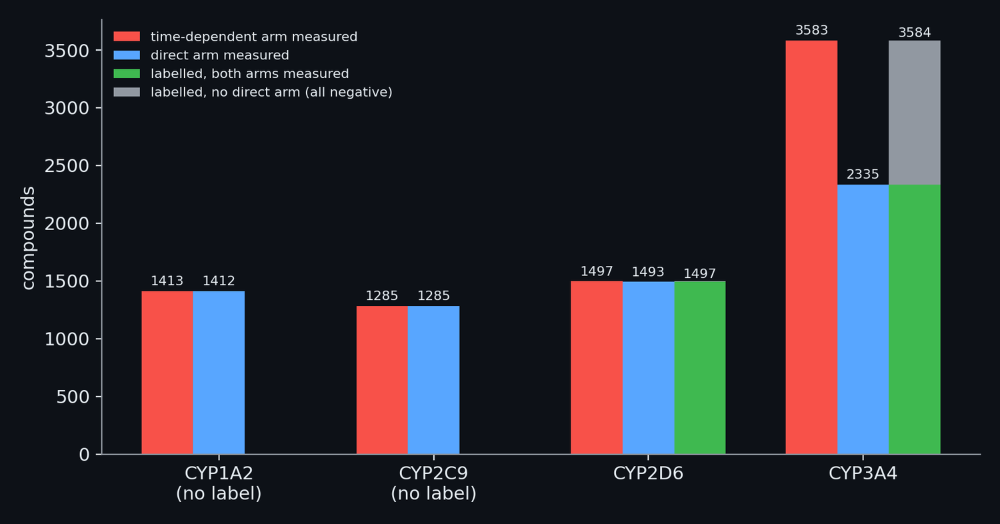

**Figure: What was measured on which isoform.** Number of training compounds with each assay arm measured, per isoform, and the number carrying a challenge label (CYP3A4 and CYP2D6 only). The labelled compounds split into those with both arms measured and those with no direct-arm measurement. CYP3A4: 3584 labelled, 2334 with both arms, 1249 without a direct measurement (0 of them positive); CYP2D6: 1497 labelled, 1493 with both arms, 4 without a direct measurement (0 of them positive). The label rule of the previous figures can therefore only be checked on the compounds with both arms.

In [39]:
show_figure("data_coverage")

## 2.3 The label rule: how $s = t - \max(d, 4) > \log_{10} 2$ was recovered and checked

> **Field:** Data science · Pharmacology

The challenge's FAQ gives the label as a four-way rule on the two potencies. Let $d$ be the direct pIC50 and $t$ the TDI-arm pIC50. The compound is a time-dependent inhibitor when

- $d > 4$ and $t - d > \log_{10} 2$ (it became more than twice as potent after the head start), or
- $d < 4$ and $t > 4 + \log_{10} 2$ (the **inferred positive**: the direct arm showed no measurable effect, below the floor of section 1.7, and the TDI arm did),

and it is not one in all other cases. The two branches are one rule. Write $s = t - \max(d, 4)$, the shift measured against the direct value or the floor, whichever is larger. If $d > 4$ the maximum is $d$ and $s = t - d$; if $d < 4$
the maximum is 4 and $s = t - 4$, so $s > \log_{10} 2 \iff t > 4 + \log_{10} 2$. In both cases the label is positive exactly when

$$s = t - \max(d, 4) \;>\; \log_{10} 2 \approx 0.30103 .$$

(A compound with $d$ exactly 4 is covered by the second form and by the first, which agree there, so the choice does not matter.) The point of writing it as one inequality is practical: $s$ is a **continuous** number carrying the whole information of the pair, while the label is only its
sign relative to a threshold. A model can learn the continuous quantity and be turned into a classifier at the end, which the project does (Part VII). The cell checks the equivalence of the two forms on 200,000 random pairs and on a regular grid,
and then applies the rule to the real compounds of the training file.

In [40]:
# The challenge's rule as it is written, and the single threshold that replaces it. The literal rule has two branches; the single threshold s > log10(2) with s = t - max(d, 4) must give the
# same answer for every possible pair (d, t), which is checked here on 200000 random pairs (and a grid that includes the boundaries) and on the real compounds.
from cypmode.challenge.tdi_targets import ASSAY_FLOOR, SHIFT_THRESHOLD, label_from_arms, label_from_shift, training_view

rng = np.random.default_rng(0)
d_random, t_random = rng.uniform(1, 8, 200_000), rng.uniform(1, 8, 200_000)
literal = np.array([label_from_arms(d, t) for d, t in zip(d_random, t_random)])
single = label_from_shift(t_random - np.maximum(d_random, ASSAY_FLOOR)) == 1
grid = np.round(np.arange(1.0, 8.0001, 0.05), 2)
grid_disagree = sum(label_from_arms(d, t) != (label_from_shift(t - max(d, ASSAY_FLOOR)) == 1) for d in grid for t in grid if d != ASSAY_FLOOR)
print(f"floor {ASSAY_FLOOR}, threshold log10(2) = {SHIFT_THRESHOLD:.5f}; disagreements between the two forms: {int((literal != single).sum())} of 200000 random pairs, {grid_disagree} of {grid.size ** 2 - grid.size} grid pairs")

rule_rows, intervals = [], {}
for enzyme in ("CYP3A4", "CYP2D6"):
    view = training_view(train, enzyme)
    both = view[view["population"] == "both_arms"]
    given = both["label"].astype(bool)
    reproduced = label_from_shift(both["shift"]) == 1
    # the thresholds consistent with every label: above the largest shift of a negative and at or below the smallest shift of a positive
    lower, upper = both.loc[~given, "shift"].max(), both.loc[given, "shift"].min()
    intervals[enzyme] = (lower, upper)
    assert (reproduced == given).all(), "the rule does not reproduce every label"
    rule_rows.append({"enzyme": enzyme, "compounds with both arms": len(both), "labels reproduced by the rule": int((reproduced == given).sum()),
                      "positives with d >= 4": int((given & (both["direct"] >= 4)).sum()), "positives with d < 4 (inferred)": int((given & (both["direct"] < 4)).sum()),
                      "highest shift among negatives": lower, "lowest shift among positives": upper})
show_table(pd.DataFrame(rule_rows), floatfmt=".5f")
n_exact_four = int(sum((training_view(train, e)["direct"] == ASSAY_FLOOR).sum() for e in ("CYP3A4", "CYP2D6")))
both_3a4 = training_view(train, "CYP3A4").query("population == 'both_arms'")
near_threshold = int(((both_3a4["shift"] - SHIFT_THRESHOLD).abs() < 0.1).sum())
print(f"compounds with d exactly 4: {n_exact_four}; CYP3A4 compounds with a shift within 0.1 of the threshold: {near_threshold} of {len(both_3a4)}")
print(f"log10(2) = {SHIFT_THRESHOLD:.5f} lies inside both intervals; 0.3 does not: the largest negative shift of CYP3A4 is {intervals['CYP3A4'][0]:.5f} > 0.3")

floor 4.0, threshold log10(2) = 0.30103; disagreements between the two forms: 0 of 200000 random pairs, 0 of 19740 grid pairs
compounds with d exactly 4: 0; CYP3A4 compounds with a shift within 0.1 of the threshold: 460 of 2334
log10(2) = 0.30103 lies inside both intervals; 0.3 does not: the largest negative shift of CYP3A4 is 0.30066 > 0.3


| enzyme | compounds with both arms | labels reproduced by the rule | positives with d >= 4 | positives with d < 4 (inferred) | highest shift among negatives | lowest shift among positives |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 2334 | 2334 | 680 | 84 | 0.30066 | 0.30124 |
| CYP2D6 | 1493 | 1493 | 273 | 51 | 0.30042 | 0.30204 |

No compound of the file has $d$ exactly 4 (the cell counted 0), so the two forms never meet at their boundary. The rule reproduces **every** label of the compounds with both arms (2334 of 2334 for CYP3A4 and 1493 of 1493 for CYP2D6). This was not
read off the FAQ and trusted: the numbers 4 and $\log_{10} 2$ can also be *recovered from the data*, and the table of intervals shows how tightly. The thresholds that give no error at all must lie above the highest shift of any negative and
at or below the lowest shift of any positive: for CYP3A4 that is the interval from 0.30066 to 0.30124, an interval of width 0.00057. The value 0.3, which one might round to,
is excluded, and $\log_{10} 2$ is inside; the data therefore say that the threshold is a factor of two in potency and not one tenth of a pIC50 unit rounded. The floor can be tested the same way, by trying other floors and thresholds on a grid:

In [41]:
# Recovering the rule instead of assuming it: for every pair (floor, threshold) of a grid count the labels of the compounds with both arms that the rule t - max(d, floor) > threshold gets wrong.
# Only one cell of the grid has no error, for each enzyme.
grids = {}
for enzyme in ("CYP3A4", "CYP2D6"):
    both = training_view(train, enzyme).query("population == 'both_arms'")
    floors, thresholds = [3.5, 3.9, 4.0, 4.1, 4.5], [0.2, 0.25, 0.3, SHIFT_THRESHOLD, 0.35, 0.4]
    errors = pd.DataFrame([[int(((both["tdi"] - np.maximum(both["direct"], f) > th) != both["label"].astype(bool)).sum()) for th in thresholds] for f in floors],
                          index=[f"floor {f}" for f in floors], columns=["0.2", "0.25", "0.3", "log10 2 = 0.301", "0.35", "0.4"])
    grids[enzyme] = errors
    show_table(errors.reset_index().rename(columns={"index": "floor"}), caption=f"{enzyme}: number of labels among the {len(both)} compounds with both arms that the rule with this floor and threshold gets wrong")
zero_cells = {enzyme: int((g == 0).to_numpy().sum()) for enzyme, g in grids.items()}
smallest_error = {enzyme: int(g.to_numpy()[g.to_numpy() > 0].min()) for enzyme, g in grids.items()}
print("grid cells without any error:", zero_cells, "; smallest number of errors in any other cell:", smallest_error)

grid cells without any error: {'CYP3A4': 1, 'CYP2D6': 1} ; smallest number of errors in any other cell: {'CYP3A4': 1, 'CYP2D6': 1}


| floor | 0.2 | 0.25 | 0.3 | log10 2 = 0.301 | 0.35 | 0.4 |
| --- | --- | --- | --- | --- | --- | --- |
| floor 3.5 | 472 | 330 | 186 | 185 | 222 | 280 |
| floor 3.9 | 305 | 187 | 49 | 48 | 115 | 181 |
| floor 4.0 | 261 | 139 | 1 | 0 | 99 | 197 |
| floor 4.1 | 198 | 113 | 24 | 25 | 131 | 222 |
| floor 4.5 | 282 | 239 | 180 | 179 | 265 | 341 |

*CYP3A4: number of labels among the 2334 compounds with both arms that the rule with this floor and threshold gets wrong*

| floor | 0.2 | 0.25 | 0.3 | log10 2 = 0.301 | 0.35 | 0.4 |
| --- | --- | --- | --- | --- | --- | --- |
| floor 3.5 | 240 | 120 | 32 | 31 | 81 | 106 |
| floor 3.9 | 219 | 99 | 13 | 12 | 65 | 85 |
| floor 4.0 | 218 | 97 | 1 | 0 | 59 | 100 |
| floor 4.1 | 206 | 91 | 18 | 17 | 77 | 110 |
| floor 4.5 | 222 | 144 | 96 | 95 | 148 | 177 |

*CYP2D6: number of labels among the 1493 compounds with both arms that the rule with this floor and threshold gets wrong*

Each enzyme has exactly 1 grid cell with no wrong label, the one at floor 4 and threshold $\log_{10} 2$; every other cell makes at least 1 error(s) for CYP3A4 and 1 for CYP2D6 (the smallest is the neighbour with threshold 0.3, which the largest negative shift just rules out), and the cells away from the optimum make dozens to hundreds. The label of this challenge is
a deterministic function of two measured numbers, with a floor at the weakest concentration the assay can distinguish (pIC50 4, an IC50 of 100 micromolar) and a threshold at a two-fold gain in potency. The files do not say *why* these values were chosen; they
only show that these are the values used. The figure draws the rule on the real compounds, and the second shows where the shifts of the compounds lie relative to the threshold.

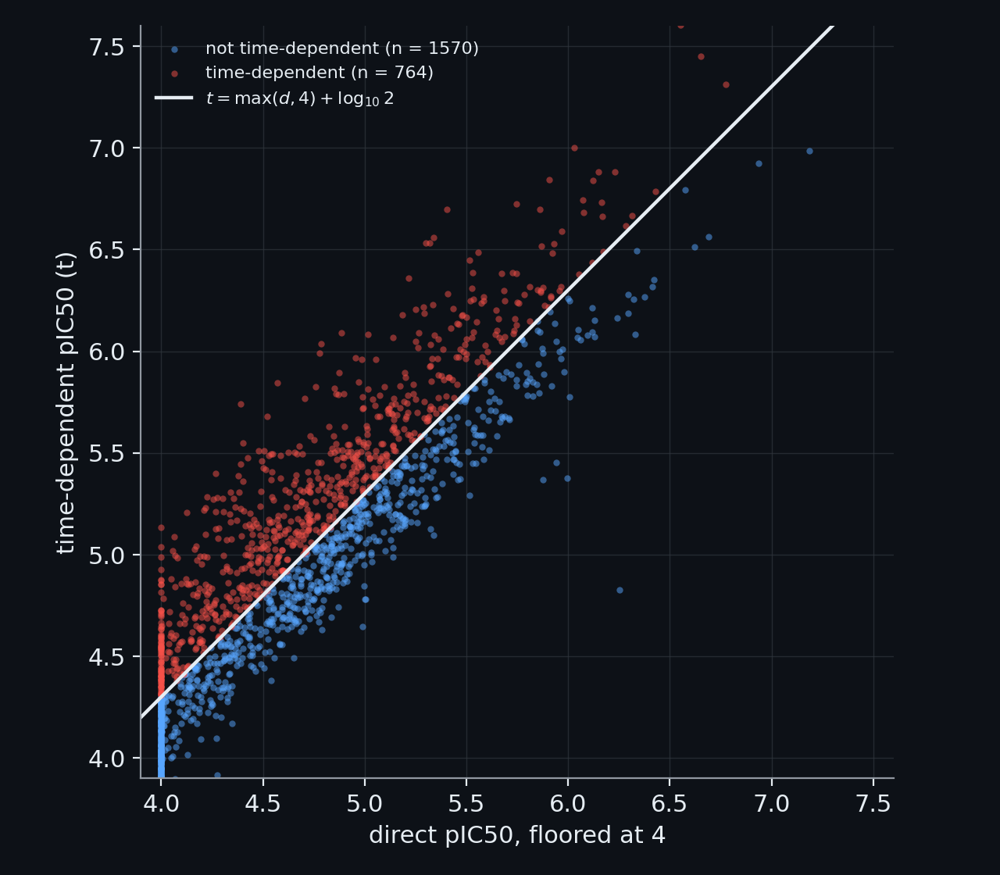

**Figure: The label rule drawn on the real CYP3A4 data.** Each point is one compound: the pIC50 under the time-dependent condition (t, vertical) against the direct pIC50 floored at 4 (horizontal). The diagonal band is the rule t - max(d, 4) = log10 2: points above it are labelled time-dependent inhibitors (red), points below are not (blue). The rule reproduces the label of every plotted compound.

In [42]:
show_figure("data_label_rule")

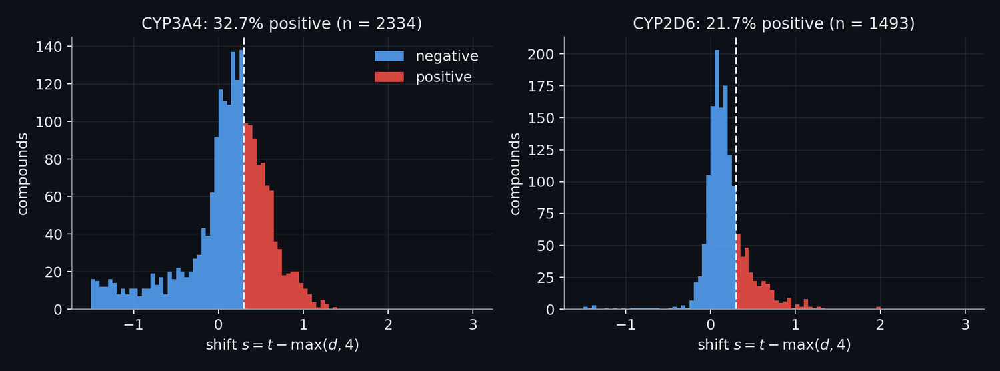

**Figure: The shift between the two arms.** Histogram of s = t - max(d, 4) for every CYP3A4 and CYP2D6 compound with both arms. The dashed line is the threshold log10 2 = 0.301; the area to its right is the positive class. Most compounds sit near zero because most compounds are not time-dependent inhibitors.

In [43]:
show_figure("data_shift_distribution")

The picture holds a warning that the next sections follow up. A large number of compounds lie close to the threshold: 460 of the
2334 CYP3A4 compounds have a shift within 0.1 pIC50 units of the threshold. A measurement of a pIC50 is not exact (section 1.7), so for such a compound a repeated experiment could well fall on the other side, and
its label would be different. That is the subject of section 2.5.

## 2.4 The contamination found in the labels

> **Field:** Data science

The cell of section 2.2 showed that 1,249 CYP3A4 compounds have a label although their direct arm is empty. They are the single most important irregularity of the training file. The cell below
tabulates the three kinds of CYP3A4 rows.

In [44]:
# The three kinds of CYP3A4 rows: both arms measured; labelled although the direct arm is empty; no label at all. (training_view tags them.)
view3 = training_view(train, "CYP3A4")
pop_rows = []
for name, label in (("both_arms", "both arms measured"), ("no_direct_label_by_convention", "label given, direct arm empty"), ("unlabeled", "no usable label (the TDI arm is empty)")):
    part = view3[view3["population"] == name]
    given = part["label"].dropna().astype(bool)
    pop_rows.append({"CYP3A4 rows": label, "compounds": len(part), "positive": int(given.sum()), "median TDI-arm pIC50": part["tdi"].median(),
                     "share with t above 4.301": float((part["tdi"] > ASSAY_FLOOR + SHIFT_THRESHOLD).mean()) if part["tdi"].notna().any() else float("nan")})
population_table = pd.DataFrame(pop_rows)
show_table(population_table.fillna("-"), floatfmt=".3f")
no_direct = view3[view3["population"] == "no_direct_label_by_convention"]
n_no_direct, share_would_be_positive, median_t_no_direct = len(no_direct), float((no_direct["tdi"] > ASSAY_FLOOR + SHIFT_THRESHOLD).mean()), no_direct["tdi"].median()
both_rows = view3[view3["population"] == "both_arms"]
print(f"if the direct pIC50 of those {n_no_direct} compounds were below the floor, the written rule would call every compound with t > 4.301 positive: {share_would_be_positive:.0%} of them; the file calls {int(no_direct['label'].astype(bool).sum())} of them positive")
print(f"positive share among the compounds with both arms: {both_rows['label'].astype(bool).mean():.3f}")

if the direct pIC50 of those 1249 compounds were below the floor, the written rule would call every compound with t > 4.301 positive: 84% of them; the file calls 0 of them positive
positive share among the compounds with both arms: 0.327


| CYP3A4 rows | compounds | positive | median TDI-arm pIC50 | share with t above 4.301 |
| --- | --- | --- | --- | --- |
| both arms measured | 2334 | 764 | 4.627 | 0.602 |
| label given, direct arm empty | 1249 | 0 | 5.397 | 0.845 |
| no usable label (the TDI arm is empty) | 2562 | 0 | - | - |

**What is wrong with these rows.** For a compound with a measured direct arm, the label is computed from $s$. A compound without one has no baseline from which to compute a shift. The 1249 rows nevertheless carry a label, and
it is *negative for every one of them*. Their TDI-arm potency is not low, however: the median is 5.40, higher than the median of the compounds with both arms, and 84% of them have $t > 4.301$. If the missing direct pIC50 had been below the
floor, the written rule would have called most of them positive. So these rows follow another convention than the rule: *no direct measurement, therefore negative*. The organisers confirmed it on the challenge Discord on 29 October 2026: a compound that has only a TDI arm cannot show a shift, so TDI cannot be confirmed and it is labelled negative. The blinded test set is, according to the organisers, assayed
in full dose-response mode in both arms, so it contains no such compound, and the scoring is not affected. The training file thus mixes two populations with different labelling conventions, and only one of them resembles what will be scored.

**How it came to light.** The project's first CYP3A4 results used every row that had a label. Recovering the label rule (section 2.3) showed that it can be applied only to the compounds with both arms, and counting the
rest gave the table above. The early CYP3A4 numbers had therefore been computed on the mixed population, and the early ablations were redone on the corrected one (Part VII says, experiment by experiment, which numbers are of which kind). CYP2D6 is hardly affected: only 4 of its labelled compounds lack the direct arm.

**The fix.** In the training of every model and in every validation set the project uses the compounds with both arms only (`training_view` tags the three populations; `population == both_arms`). The labelled-negative rows with an empty direct arm are not discarded from
knowledge altogether: their TDI-arm potency is real data, and a regression model can use it through `shift_imputed`, which fills the missing baseline with the floor, $s = t - 4$, the value they would have if the direct arm had been below
the floor. This is *not* a measurement and is used with that reading only. The cell measures what the contamination does to a model, in the cleanest way available: the same **gradient-boosted trees** (a model made of many small **decision trees**, flowcharts of yes/no questions about the features, fitted one after another, each correcting the mistakes of those before it; LightGBM is the software used, section 4.3) trained twice, and always scored on held-out compounds that have both arms.

In [45]:
# What the 1249 rows do to a model. The same LightGBM model on the same features (Morgan counts, radius 2, 1024 positions) is trained twice in 5-fold cross-validation, once on the
# compounds with both arms only and once with the 1249 labelled-negative rows added to every training part. Both are scored on the same held-out compounds with both arms, because
# those are the compounds that resemble the scored test set.
from lightgbm import LGBMClassifier
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
smiles_all = train.loc[view3.index[view3["population"] != "unlabeled"], "SMILES"]
features = np.array([generator.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles_all], dtype=np.float32)
status = view3.loc[smiles_all.index, "population"].to_numpy()
y_all = view3.loc[smiles_all.index, "label"].astype(int).to_numpy()
is_both = status == "both_arms"

def cross_validated_auc(include_no_direct: bool, seed: int = 0) -> float:
    scores, truths = [], []
    folds = StratifiedKFold(5, shuffle=True, random_state=seed).split(features[is_both], y_all[is_both])
    both_index = np.flatnonzero(is_both)
    extra = np.flatnonzero(~is_both)
    for train_part, test_part in folds:
        fit_index = np.concatenate([both_index[train_part], extra]) if include_no_direct else both_index[train_part]
        model = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.5, random_state=seed, n_jobs=2, verbose=-1)
        model.fit(features[fit_index], y_all[fit_index])
        scores.append(model.predict_proba(features[both_index[test_part]])[:, 1])
        truths.append(y_all[both_index[test_part]])
    return roc_auc_score(np.concatenate(truths), np.concatenate(scores))

auc_clean, auc_mixed = cross_validated_auc(False), cross_validated_auc(True)
assert auc_clean > auc_mixed, "the text below states that the extra rows lower the AUC"
print(f"AUC on held-out compounds with both arms: trained on both-arms rows only {auc_clean:.3f}; with the {int((~is_both).sum())} labelled-negative rows added {auc_mixed:.3f}; difference {auc_clean - auc_mixed:+.3f}")

AUC on held-out compounds with both arms: trained on both-arms rows only 0.719; with the 1249 labelled-negative rows added 0.657; difference +0.063


The model trained with the extra rows ranks the compounds with both arms **worse** (0.657 against 0.719 in terms of the **AUC**, here the area under the ROC curve of section 4.10 and not the area under the concentration curve of section 1.1: the probability that a randomly chosen positive compound is scored above a randomly chosen negative one, 0.5 for chance).
The harm is the one expected: the rows teach the model that a potent TDI arm without a direct arm means "negative", which is false for the compounds that will be scored. A model evaluated on the mixed population would also have reported a number that
describes the mixture and not the problem. This is one of the findings of the project that is not about a model at all, and it is recorded in the method report as the contaminated no-direct rows.

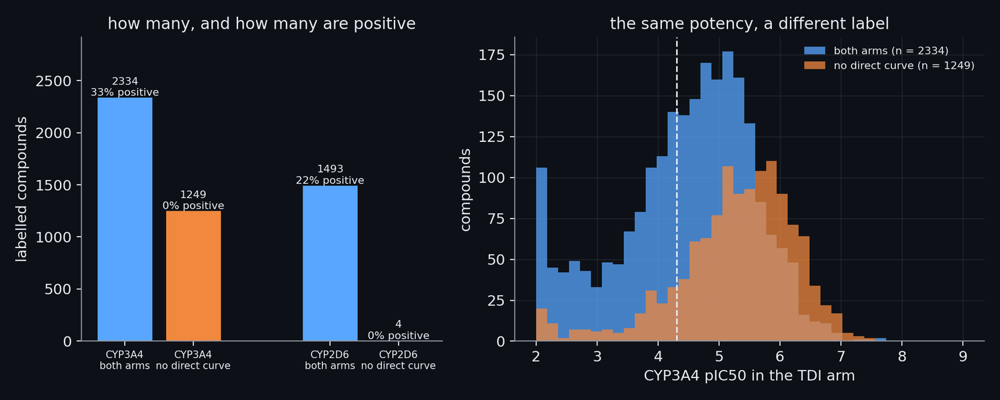

**Figure: The labelled compounds without a direct curve.** The labelled compounds that have no direct-inhibition curve. For CYP3A4, 1249 of 3584 labelled compounds were measured only in the TDI arm, and all of them are labelled negative (0% positive, against 32.7% of the 2334 compounds that have both arms; 1 more has a direct curve and no value in the TDI arm and is in neither group), although their TDI-arm potency is high (median pIC50 5.4, against 4.6 for the compounds with both arms): the label rule needs the direct value to compute a shift, and without it the convention assigns a negative. The blinded test set was measured in both arms, so it has no such compounds; training on them and scoring on them mixes two populations, which is why they are excluded from the pool of CYP3A4 (section 2.4). For CYP2D6 only 4 labelled compounds are in this group. Left: the counts and the share of positives in each group; right: the TDI-arm potency of the two groups of CYP3A4; the dashed line is 4.301, the potency above which the organisers infer a positive for a compound with a direct pIC50 of 4 or less.

In [46]:
show_figure("data_nodirect_coverage")

## 2.5 Measurement noise: the standard deviation, the confidence limits and the confidence $z$

> **Field:** Statistics

Every pIC50 of the file is an estimate from a fitted curve (section 1.7), and the file gives its uncertainty twice, as a **standard deviation** and as the limits of a 95 % **confidence interval**. The standard deviation of an estimate is the
typical size of its error: if the experiment were repeated many times, the estimates would scatter around the true value with this spread. For a normally distributed error, 95 % of the repetitions fall within 1.96 standard deviations of the true value, because the standard
normal distribution function $\Phi(x) = \tfrac12[1 + \mathrm{erf}(x/\sqrt 2)]$ equals 0.975 at $x = 1.96$; a 95 % interval is therefore the value plus and minus 1.96 times the standard deviation. The two columns should then be the same
information, and the cell checks it.

In [47]:
# What the confidence limits and the standard deviation of a pIC50 are. For a normally distributed estimate the interval mean +- 1.96 sd holds 95 % of the probability; the file's limits
# should therefore be 1.96 standard deviations from the value on each side.
from scipy.stats import norm

print(f"norm.ppf(0.975) = {norm.ppf(0.975):.5f}")
noise_rows = []
for enzyme in ("CYP3A4", "CYP2D6"):
    for arm, arm_name in (("TDI_condition", "TDI arm"), ("direct_inhibition", "direct arm")):
        column = f"{enzyme}_pIC50_{arm}"
        part = train[[column, column + "_conf_low", column + "_conf_high", column + "_std"]].dropna()
        half_width = (part[column + "_conf_high"] - part[column + "_conf_low"]) / 2 / part[column + "_std"]
        centred = (part[column] - part[column + "_conf_low"]) / (part[column + "_conf_high"] - part[column])
        noise_rows.append({"enzyme": enzyme, "arm": arm_name, "measurements": len(part), "median standard deviation": part[column + "_std"].median(),
                           "half-width / sd, median": half_width.median(), "half-width / sd, 10th to 90th percentile": f"{half_width.quantile(0.1):.2f} to {half_width.quantile(0.9):.2f}",
                           "value is the middle of the interval": f"{centred.median():.2f}"})
show_table(pd.DataFrame(noise_rows), floatfmt=".3f")
sd_values = {(r["enzyme"], r["arm"]): r["median standard deviation"] for r in noise_rows}

norm.ppf(0.975) = 1.95996


| enzyme | arm | measurements | median standard deviation | half-width / sd, median | half-width / sd, 10th to 90th percentile | value is the middle of the interval |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | TDI arm | 3583 | 0.061 | 1.968 | 1.77 to 2.03 | 0.97 |
| CYP3A4 | direct arm | 2335 | 0.095 | 1.960 | 1.73 to 2.04 | 0.96 |
| CYP2D6 | TDI arm | 1497 | 0.065 | 1.974 | 1.85 to 2.04 | 0.95 |
| CYP2D6 | direct arm | 1493 | 0.069 | 1.969 | 1.76 to 2.03 | 0.97 |

The interval is centred on the value and its half-width is close to 1.96 standard deviations in every row of the table (the ratio varies a little between compounds because the limits come from the fitting procedure and not from the formula). The standard
deviation is therefore the one number needed, and the typical pIC50 error is 0.06 (TDI arm) and 0.09 (direct arm) for CYP3A4.

**Error propagation.** The label depends on the *difference* $s = t - \max(d, 4)$ of two noisy numbers, so the noise of $s$ has to be derived. For two independent random quantities $X$ and $Y$ and constants $a$ and $b$, the variance of the combination
$aX + bY$ is $a^2\sigma_X^2 + b^2\sigma_Y^2$; the term $2ab\,\mathrm{Cov}(X, Y)$ that would otherwise appear vanishes when the quantities are independent, as the two assay arms are taken to be, since they are separate experiments. With $a = 1$ and $b = -1$ the
variance of the difference is the sum of the variances. When the direct pIC50 is above the floor, $s = t - d$ and

$$\mathrm{sd}(s)^2 = \mathrm{sd}(t)^2 + \mathrm{sd}(d)^2 ,$$

where $\mathrm{sd}(\cdot)$ is the standard deviation of the column of the same name. When $d$ is below the floor the second term is the constant 4, with no noise, and $\mathrm{sd}(s)^2 = \mathrm{sd}(t)^2$. The formula is the one in the module
`cypmode/challenge/label_confidence.py` (the term $[d \ge 4]\,\mathrm{sd}(d)^2$, where $[\cdot]$ is 1 if the statement in the brackets is true and 0 if not). A simulation can check it, by drawing both measurements from normal distributions and forming $s$.

In [48]:
# Error propagation for the shift, checked by simulation. A compound with t = 5.4 +- 0.06 and d = 4.6 +- 0.09 (the median standard deviations of CYP3A4): draw both measurements 200000 times
# from their normal distributions, form s = t - max(d, 4) each time, and compare the spread of s with sqrt(sd_t^2 + sd_d^2). Then the same for a compound whose direct pIC50 is below the floor.
rng = np.random.default_rng(1)
sd_t, sd_d = sd_values[("CYP3A4", "TDI arm")], sd_values[("CYP3A4", "direct arm")]
prop_rows = []
for d_mean, t_mean in ((4.6, 5.4), (3.2, 5.4)):
    d_draw, t_draw = rng.normal(d_mean, sd_d, 200_000), rng.normal(t_mean, sd_t, 200_000)
    s_draw = t_draw - np.maximum(d_draw, ASSAY_FLOOR)
    formula = np.sqrt(sd_t**2 + (sd_d**2 if d_mean >= ASSAY_FLOOR else 0.0))
    prop_rows.append({"d": d_mean, "t": t_mean, "sd(s) by simulation": s_draw.std(), "sd(s) by formula": formula, "mean of s": s_draw.mean()})
show_table(pd.DataFrame(prop_rows), floatfmt=".4f")

| d | t | sd(s) by simulation | sd(s) by formula | mean of s |
| --- | --- | --- | --- | --- |
| 4.6000 | 5.4000 | 0.1128 | 0.1129 | 0.8000 |
| 3.2000 | 5.4000 | 0.0613 | 0.0614 | 1.4000 |

The spread of the simulated shifts agrees with the formula in both cases. In the second row, where $d$ is far below the floor, the noise of $d$ makes no difference, as the formula says.

**The confidence $z$.** How sure can one be of a label? The label is "the shift is above the threshold". The measured shift $s$ has the uncertainty $\mathrm{sd}(s)$; treating the true shift as normally distributed around the measurement (the file's
standard deviations are posterior standard deviations, so this is the natural reading), the probability that the true shift lies on the other side of the threshold from the measured one is the area of the normal curve beyond the distance of the threshold, measured in standard deviations ($P$ stands for probability):

$$z = \frac{|s - \log_{10} 2|}{\mathrm{sd}(s)}, \qquad P(\text{label wrong}) = \Phi(-z).$$

$z = 1$ is a one-in-six chance of the opposite label, $z = 1.96$ is 2.5 %, $z = 2.5$ is 0.6 %. The module `label_confidence` computes $z$ for every row (`confidence_z`) and offers weights that use it (`confident_weights`, `training_weights`).
The challenge's FAQ says that predictions are requested for every test compound, but that only compounds whose label can be assigned with confidence contribute to the score. The exact rule is not published, so every analysis of the project is repeated across several cut-offs $z_0$, and a compound counts as
*confident* if $z \ge z_0$. The cell computes $z$ for the training compounds.

In [49]:
# The confidence z = |s - log10 2| / sd(s) of every labelled compound and the probability that its label is wrong, Phi(-z), where Phi is the standard normal distribution function.
from scipy.special import erf

from cypmode.challenge.label_confidence import confidence_z

def Phi(x):
    return 0.5 * (1 + erf(x / np.sqrt(2)))

conf_rows, z_by_enzyme = [], {}
for enzyme in ("CYP3A4", "CYP2D6"):
    view = training_view(train, enzyme)
    both = view["population"] == "both_arms"
    z = confidence_z(train, enzyme)[both.to_numpy()]
    z_by_enzyme[enzyme] = z
    row = {"enzyme": enzyme, "compounds": int(both.sum()), "median z": float(np.median(z)), "expected wrong labels": float(Phi(-z).sum())}
    for z0 in (1.0, 1.96, 2.5):
        row[f"|z| >= {z0}"] = int((z >= z0).sum())
    conf_rows.append(row)
show_table(pd.DataFrame(conf_rows), floatfmt=".1f")
print("probability that a label is wrong, Phi(-z):", {z0: round(float(Phi(-z0)), 4) for z0 in (0.5, 1.0, 1.96, 2.5, 3.0)})
quantiles = np.percentile(z_by_enzyme["CYP3A4"], [5, 25, 50, 75, 95])
print("CYP3A4 z at the 5th, 25th, 50th, 75th, 95th percentile:", np.round(quantiles, 2))
n_both = {r["enzyme"]: r["compounds"] for r in conf_rows}
expected_wrong = {r["enzyme"]: r["expected wrong labels"] for r in conf_rows}
n_confident = {r["enzyme"]: r["|z| >= 1.96"] for r in conf_rows}
share_below_2 = float((z_by_enzyme["CYP3A4"] < 2).mean())

probability that a label is wrong, Phi(-z): {0.5: 0.3085, 1.0: 0.1587, 1.96: 0.025, 2.5: 0.0062, 3.0: 0.0013}
CYP3A4 z at the 5th, 25th, 50th, 75th, 95th percentile: [0.29 1.51 2.33 3.41 7.49]


| enzyme | compounds | median z | expected wrong labels | |z| >= 1.0 | |z| >= 1.96 | |z| >= 2.5 |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 2334 | 2.3 | 161.7 | 1948 | 1487 | 1042 |
| CYP2D6 | 1493 | 2.0 | 148.7 | 1126 | 756 | 569 |

Of the 2334 CYP3A4 compounds with both arms, about 162 of the labels are expected to be wrong (the sum of $\Phi(-z)$ over the compounds) and 1487 reach $z \ge 1.96$; the corresponding numbers for CYP2D6 are
149 wrong in 1493 and 756 confident. The median CYP3A4 compound is 2.3 standard deviations from the threshold (the **median** is the middle value: half of the compounds are closer than that, half farther) and the lower quartile only 1.5 (a **quartile** is a quarter point: a quarter of the compounds are closer than the lower one); the percentile of the next sections is the same idea for any share; 38% of the compounds are less than two standard deviations from it.
Two consequences are drawn in later parts. A validation score computed on *all* compounds measures a partly random problem, whereas the official score is computed on the confident subset; section 6.4 builds a yardstick that restricts to confident compounds and shows that
the official baseline's own cross-validated score rises with the cut-off in the direction of its leaderboard score. And a model can be trained with the labels of uncertain compounds down-weighted, which is one of the experiments of Part IX.

## 2.6 Which compounds were measured on which enzyme: blocks and selection

> **Field:** Data science · Statistics

Section 2.2 showed that the compounds are not measured evenly across the four enzymes. The pattern has a structure that matters for everything that follows. Compound names end in a number (the letters `OCNT-` and seven digits), and when the compounds are put in the order of that number, the share of
compounds that carry a measurement on an enzyme *other than CYP3A4* is not constant. The module `cypmode/challenge/library_blocks.py` finds the stretch where that share is high without being told where it is: it computes the share in a rolling window
of compounds in the order of the numbers and takes the longest run in which the share stays above a minimum. The cell runs it on the training file and draws the share along the numbering.

| block | compounds | numbers from | numbers to | measured on another enzyme | measured on CYP3A4 | measured on CYP2D6 | CYP3A4 positives | CYP2D6 positives |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| low block | 1309 | 422 | 497997 | 0.081 | 0.945 | 0.050 | 11 | 16 |
| all-isoform panel block | 4352 | 497998 | 2395315 | 0.741 | 0.428 | 0.329 | 609 | 308 |
| top block | 484 | 2395316 | 2395799 | 0.000 | 1.000 | 0.000 | 144 | 0 |

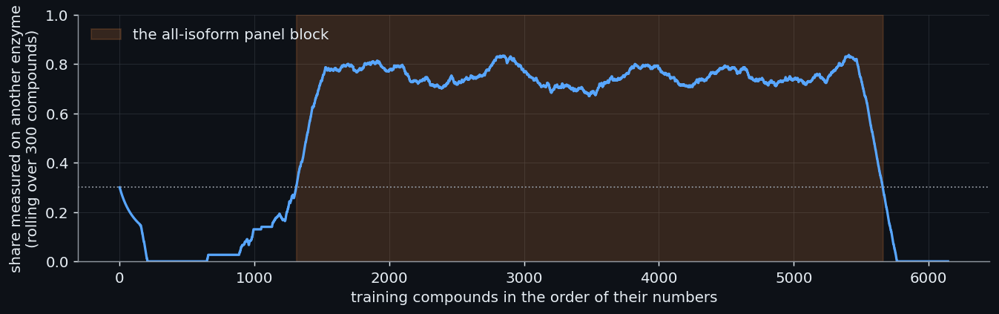

In [50]:
# The training file is not one library. Compounds were measured on several enzymes, and which enzymes a compound was measured on depends on where its number lies. library_blocks finds the
# stretch of compound numbers where a large share of the compounds carry a measurement on an enzyme other than CYP3A4: a rolling share over 300 compounds in the order of the numbers,
# and the longest run in which it stays at or above 0.3.
from cypmode.challenge.library_blocks import MIN_SHARE, WINDOW, compound_numbers, panel_block_mask

ids = compound_numbers(train["Molecule_Name"])
panel = panel_block_mask(train)
region = np.where(panel, "panel", np.where(ids < ids[panel].min(), "low", "top"))
other = train[["CYP1A2_pIC50_TDI_condition", "CYP2C9_pIC50_TDI_condition", "CYP2D6_pIC50_TDI_condition"]].notna().any(axis=1).to_numpy()
d3_measured, d6_measured = train["CYP3A4_pIC50_TDI_condition"].notna().to_numpy(), train["CYP2D6_pIC50_TDI_condition"].notna().to_numpy()
d3_label, d6_label = train["CYP3A4_is_TDI"].fillna(False).astype(bool).to_numpy(), train["CYP2D6_is_TDI"].fillna(False).astype(bool).to_numpy()
block_rows = []
for name, title in (("low", "low block"), ("panel", "all-isoform panel block"), ("top", "top block")):
    sel = region == name
    block_rows.append({"block": title, "compounds": int(sel.sum()), "numbers from": int(ids[sel].min()), "numbers to": int(ids[sel].max()), "measured on another enzyme": float(other[sel].mean()),
                       "measured on CYP3A4": float(d3_measured[sel].mean()), "measured on CYP2D6": float(d6_measured[sel].mean()),
                       "CYP3A4 positives": int(d3_label[sel].sum()), "CYP2D6 positives": int(d6_label[sel].sum())})
block_table = pd.DataFrame(block_rows)
show_table(block_table, floatfmt=".3f")

order = np.argsort(ids, kind="stable")
rolling = pd.Series(other[order].astype(float)).rolling(WINDOW, center=True, min_periods=WINDOW // 2).mean().to_numpy()
fig, axis = plt.subplots(figsize=(10.5, 3.4))
axis.plot(np.arange(len(rolling)), rolling, color=theme["blue"], lw=1.8)
axis.axhline(MIN_SHARE, color=theme["muted"], ls=":", lw=1)
in_panel_sorted = panel[order]
axis.fill_between(np.arange(len(rolling)), 0, 1, where=in_panel_sorted, color=theme["orange"], alpha=0.18, transform=axis.get_xaxis_transform(), label="the all-isoform panel block")
axis.set(xlabel="training compounds in the order of their numbers", ylabel=f"share measured on another enzyme\n(rolling over {WINDOW} compounds)", ylim=(0, 1))
axis.legend(frameon=False, loc="upper left")
tidy(axis, theme)
fig.tight_layout()
n_panel, share_inside, share_outside = int(panel.sum()), float(other[panel].mean()), float(other[~panel].mean())

The window is 300 compounds wide and the minimum share is 0.3. The result is a block of 4352 compounds, here called the **all-isoform panel block**: 74% of
its compounds carry a measurement on another enzyme, against 6% of the compounds outside it. The numbers below the block and the numbers above it are the other two blocks (the table gives the share of their compounds that carry a measurement on another enzyme).

**What a missing measurement means.** The explanation that fits the pattern, and that the project adopted, is a two-stage process. A collection of compounds is first screened cheaply on all enzymes at once, as a
**panel**; the compounds that show activity, the **hits**, are promoted to the expensive full dose-response measurement that yields a pIC50, and only for those is the measurement stored. If so, a compound of the panel block with no CYP2D6 measurement is
not a compound that was forgotten but one that was screened and *not* promoted, that is, a compound with no sign of inhibiting CYP2D6, which is what a label of "not a time-dependent inhibitor" would say. Outside the block the same empty cell means only "never tested". This is an inference from the
pattern in the files; the organisers' documentation was not found to state it, and Part IX says what depends on it. The inference is useful because of what it implies for counting. Inside the panel block, a compound is a positive only if it was a hit *and* its shift passes the threshold, so
that

$$P(\text{positive}) \;=\; P(\text{hit}) \times P(\text{positive} \mid \text{hit}),$$

where $P(\cdot \mid \cdot)$ is a conditional probability, the probability of the left statement among the cases for which the right one holds. The factorisation is an identity of counting and the cell checks it on the CYP2D6 numbers.

In [51]:
# The factorisation behind a "hit": inside the panel block, a compound is a CYP2D6 positive only if it was measured on CYP2D6 (a hit) AND its shift passes the threshold. So
# P(positive) = P(hit) x P(positive | hit), computed here from the counts.
in_panel = panel
n_in, n_hit = int(in_panel.sum()), int((d6_measured & in_panel).sum())
n_positive = int((d6_label & in_panel).sum())
p_hit, p_pos_given_hit, p_pos = n_hit / n_in, n_positive / n_hit, n_positive / n_in
print(f"CYP2D6 inside the panel block: {n_in} compounds, {n_hit} measured (hits), {n_positive} positive")
print(f"P(hit) = {p_hit:.4f}; P(positive | hit) = {p_pos_given_hit:.4f}; the product = {p_hit * p_pos_given_hit:.4f}; P(positive) counted directly = {p_pos:.4f}")
outside_measured = int((d6_measured & ~in_panel).sum())
print(f"CYP2D6 measurements outside the panel block: {outside_measured} of {int(d6_measured.sum())}")

CYP2D6 inside the panel block: 4352 compounds, 1431 measured (hits), 308 positive
P(hit) = 0.3288; P(positive | hit) = 0.2152; the product = 0.0708; P(positive) counted directly = 0.0708
CYP2D6 measurements outside the panel block: 66 of 1497


Of the 4352 compounds of the panel block, 1431 (33%) are CYP2D6 hits, and 308 of the hits are positive, which is 21.5% of them but only 7.1% of all the compounds of the block. Which of the two rates is the right one for a test
compound depends on what the test set contains: only compounds that were hits (the first rate), or hits and non-hits in the proportion of the panel (the second). A model trained on the hits alone has never been shown a non-hit, and it is
the second situation that exposes it. This is called **selection bias**: the compounds from which a model learns were chosen by a process (here, being promoted after a screen) that is itself related to the label, so that they are not a random sample of the compounds that the model will meet. The
bias was described for statistical models of this kind by Heckman (1979), whose correction Part IX derives and tests as one of the project's ideas (the selection-aware model of CYP2D6). What the data files can and cannot say about the proportion in the scored set is the subject of section 2.10.

## 2.7 How the test set differs from the training set

> **Field:** Statistics · Cheminformatics

A model is trained on one set of compounds and judged on another; the judgement transfers only if the two resemble each other. The question is how far the 750 test compounds are from the training compounds, and there are two ways in which they can differ.
The compounds themselves can be different, that is, $P(x)$, the distribution of the structures $x$, can differ while the rule linking structure to label, $P(y \mid x)$, stays the same: this is called **covariate shift**. Or the share of positives can differ, $P(y)$,
which is called **label shift**, or a difference in **prevalence**, the proportion of positives in a set. Both are measured here, the first in this section and the second in section 2.10.

**Similarity.** The simplest way to say how near a compound is to a set is the highest **Tanimoto similarity** between its fingerprint and the fingerprints of the compounds of that set: the share of the fingerprint bits switched on in either molecule that are switched on in both (section 3.2 builds the
formula, and section 3.1 the fingerprint). It runs from 0 (nothing shared) to 1 (identical). Values near 0.5 and above mean that the set contains a close relative of the compound, which for compounds of one medicinal-chemistry series is common: a series is made by changing one part of a molecule at a time. The cell computes it for the
test compounds against the training set and, for comparison, for the training compounds against the other training compounds, in the three blocks, and as the project's earlier check did, for the held-out fifth of a random five-fold split of the training set. That last comparison is what a cross-validated score is
implicitly tested against.

| compounds compared | compounds | median nearest-neighbour similarity | share at 0.5 or more | share at 0.7 or more |
| --- | --- | --- | --- | --- |
| the 750 test compounds, against the training set | 750 | 0.587 | 0.957 | 0.103 |
| training compounds in a random 5-fold split, against the training part | 6145 | 0.451 | 0.357 | 0.113 |
| training compounds, against all other training compounds | 6145 | 0.467 | 0.402 | 0.129 |
|   of which the low block | 1309 | 0.657 | 0.715 | 0.460 |
|   of which the all-isoform panel block | 4352 | 0.441 | 0.249 | 0.014 |
|   of which the top block | 484 | 0.635 | 0.926 | 0.262 |

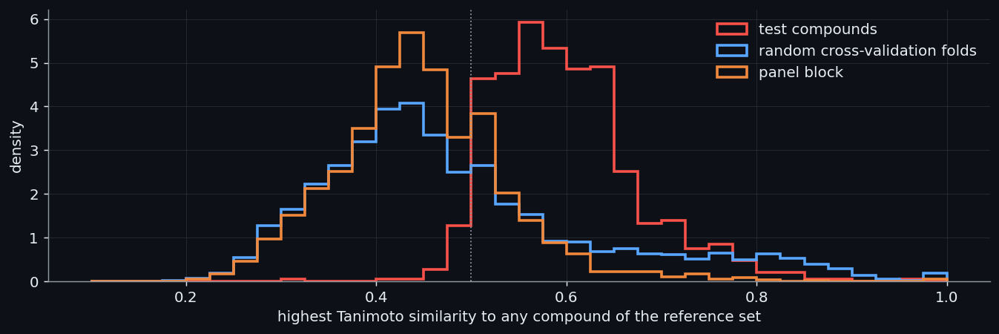

In [52]:
# How close is each compound to the compounds the model can learn from? For every compound, the highest Tanimoto similarity (on Morgan fingerprints of radius 2 and 2048 bits, section 3.1) to any compound
# of a reference set: the test compounds against all training compounds; every training compound against all OTHER training compounds; and, as the project's earlier check did, every training compound
# against the training part of a random 5-fold split.
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import KFold

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fp_train = [generator.GetFingerprint(Chem.MolFromSmiles(s)) for s in train["SMILES"]]
fp_test = [generator.GetFingerprint(Chem.MolFromSmiles(s)) for s in test["SMILES"]]
K_NEIGHBOURS = 5
nn_test = np.array([max(DataStructs.BulkTanimotoSimilarity(f, fp_train)) for f in fp_test])
nn_leave_one_out, near_train, near_test = np.zeros(len(fp_train)), np.zeros(len(fp_train)), np.zeros(len(fp_train))
for i, f in enumerate(fp_train):
    to_train = np.array(DataStructs.BulkTanimotoSimilarity(f, fp_train))
    to_train[i] = -1.0                                                  # a compound is not its own neighbour
    to_test = np.array(DataStructs.BulkTanimotoSimilarity(f, fp_test))
    nn_leave_one_out[i] = to_train.max()
    near_train[i], near_test[i] = np.sort(to_train)[-K_NEIGHBOURS:].mean(), np.sort(to_test)[-K_NEIGHBOURS:].mean()
nn_cv = np.zeros(len(fp_train))
for fit_part, held_out in KFold(5, shuffle=True, random_state=42).split(fp_train):
    reference = [fp_train[j] for j in fit_part]
    for j in held_out:
        nn_cv[j] = max(DataStructs.BulkTanimotoSimilarity(fp_train[j], reference))

def summarise(values):
    return {"compounds": len(values), "median nearest-neighbour similarity": float(np.median(values)), "share at 0.5 or more": float((values >= 0.5).mean()), "share at 0.7 or more": float((values >= 0.7).mean())}
groups = {"the 750 test compounds, against the training set": nn_test, "training compounds in a random 5-fold split, against the training part": nn_cv,
          "training compounds, against all other training compounds": nn_leave_one_out, "  of which the low block": nn_leave_one_out[region == "low"],
          "  of which the all-isoform panel block": nn_leave_one_out[region == "panel"], "  of which the top block": nn_leave_one_out[region == "top"]}
similarity_table = pd.DataFrame([{"compounds compared": name, **summarise(v)} for name, v in groups.items()])
show_table(similarity_table, floatfmt=".3f")

fig, axis = plt.subplots(figsize=(10.5, 3.6))
bins = np.linspace(0.1, 1.0, 37)
for values, color, label in ((nn_test, theme["red"], "test compounds"), (nn_cv, theme["blue"], "random cross-validation folds"), (nn_leave_one_out[region == "panel"], theme["orange"], "panel block")):
    axis.hist(values, bins=bins, histtype="step", lw=2.0, density=True, color=color, label=label)
axis.axvline(0.5, color=theme["muted"], ls=":", lw=1)
axis.set(xlabel="highest Tanimoto similarity to any compound of the reference set", ylabel="density")
axis.legend(frameon=False)
tidy(axis, theme)
fig.tight_layout()
test_summary, cv_summary = summarise(nn_test), summarise(nn_cv)

A test compound has a close relative in the training set far more often than a held-out compound of a random split does: 96% of the test compounds have a training neighbour at similarity 0.5 or more, against 36%
of the compounds of a random split, and the median is 0.59 against 0.45. The panel block, which the module describes as a diversity-library panel, is the most isolated of the three blocks. The consequence for a cross-validated score is
that it is measured on compounds that are, on average, farther from the training data than the test compounds are, and so is likely to understate how well a model that exploits close relatives will do on the test set, unless the split is made to resemble the test (section 6.4 and Part VI).

**Where the test compounds are.** The numbering gives another view. Counting the test compounds in the three ranges of compound numbers of the training blocks gives:

In [53]:
# Where do the test compounds sit in the numbering? The same three ranges as the training blocks (below the panel, inside it, above it), counted for both files.
test_ids = compound_numbers(test["Molecule_Name"])
test_region = np.where(test_ids < ids[panel].min(), "low", np.where(test_ids > ids[panel].max(), "top", "panel"))
region_rows = []
for name, title in (("low", "low block"), ("panel", "all-isoform panel block"), ("top", "top block")):
    sel_test, sel_train = test_region == name, region == name
    region_rows.append({"range of compound numbers": title, "training compounds": int(sel_train.sum()), "test compounds": int(sel_test.sum()), "test share": float(sel_test.mean()),
                        "lowest test number": int(test_ids[sel_test].min()) if sel_test.any() else "-", "highest test number": int(test_ids[sel_test].max()) if sel_test.any() else "-"})
region_table = pd.DataFrame(region_rows)
show_table(region_table, floatfmt=".3f")
top_train_high, top_test_low = int(ids[region == "top"].max()), int(test_ids[test_region == "top"].min())
top_d6_share, top_d3_share = float(d6_measured[region == "top"].mean()), float(d3_measured[region == "top"].mean())
n_test_top = int((test_region == "top").sum())
print(f"training compounds of the top block reach number {top_train_high}; the lowest test number of the top range is {top_test_low}")

training compounds of the top block reach number 2395799; the lowest test number of the top range is 2461740


| range of compound numbers | training compounds | test compounds | test share | lowest test number | highest test number |
| --- | --- | --- | --- | --- | --- |
| low block | 1309 | 7 | 0.009 | 10024 | 497785 |
| all-isoform panel block | 4352 | 6 | 0.008 | 1498525 | 2314689 |
| top block | 484 | 737 | 0.983 | 2461740 | 2535825 |

737 of the 750 test compounds have a number above the panel block: they belong to the same top range as the 484 training compounds of the top block, whose numbers stop at 2395799, and the lowest test number there is 2461740. Only a handful of the test compounds fall in the
low block or in the panel block. The training compounds of the top block were measured on CYP3A4 for 100% of them and on CYP2D6 for 0%: for CYP2D6 the training file holds no compound from the range where almost all the test compounds lie. The test set therefore does not resemble the diversity panel that makes most of the training file: it resembles the last, analog-rich range, which is the reason the project built a hold-out from the top block (section 6.8) and the reason for the weighting below.

**Importance weighting**. If a model is judged by its average loss $L(x)$ over the test distribution, that average is an integral over structures,

$$\mathbb{E}_{\text{test}}[L] \;=\; \int p_{\text{test}}(x)\,L(x)\,dx \;=\; \int p_{\text{train}}(x)\,\underbrace{\frac{p_{\text{test}}(x)}{p_{\text{train}}(x)}}_{w(x)}\,L(x)\,dx \;=\; \mathbb{E}_{\text{train}}[\,w(x)\,L(x)\,],$$

where $p_{\text{test}}(x)$ and $p_{\text{train}}(x)$ are the densities of the structures in the two sets, $\mathbb{E}_{\text{train}}$ is the average over the training compounds, and the second step only multiplies and divides by $p_{\text{train}}(x)$ (it needs $p_{\text{train}}(x) > 0$
wherever $p_{\text{test}}(x) > 0$). The ratio $w(x)$ is the **density ratio**, and weighting every training compound by it makes the training average equal the test average: a training compound that is typical of the test set counts for more, one that the test set never visits counts for less. Neither density can be written
down for molecules, but their ratio can be estimated by a classifier. Let a model be trained to say, for a structure $x$, whether it comes from the test file (label 1) or the training file (label 0), and call its probability of "test" $c(x) = P(\text{test} \mid x)$. By Bayes' rule, with $n_{\text{test}}$ and $n_{\text{train}}$ the sizes of the two files,

$$\frac{c(x)}{1 - c(x)} \;=\; \frac{p_{\text{test}}(x)\,n_{\text{test}}}{p_{\text{train}}(x)\,n_{\text{train}}} \quad\Longrightarrow\quad w(x) = \frac{c(x)}{1 - c(x)}\cdot\frac{n_{\text{train}}}{n_{\text{test}}}.$$

The same classifier answers the first question as well: its area under the ROC curve (the probability that it scores a random test compound above a random training compound, 0.5 for no difference, defined in section 4.10) says how different the two sets are; this is sometimes called adversarial validation. Weights have a price. If a few of them are very large, a weighted average rests on a few compounds. The **effective sample size** of a set of weights,
$n_{\mathrm{eff}} = (\sum_i w_i)^2 / \sum_i w_i^2$, equals the number of compounds when all the weights are equal and shrinks as they concentrate. The project therefore did not use the raw ratio. It used a tempered proxy computed from similarities alone (`testlike_weights` in `cypmode/challenge/nested_runners.py`): for a training compound $i$ let $s_i^{\text{test}}$ be its mean
similarity to its 5 most similar test compounds and $s_i^{\text{train}}$ its mean similarity to its 5 most similar other training compounds; the weight is $\mathrm{clip}\bigl((s_i^{\text{test}}/s_i^{\text{train}})^{\alpha},\,0.2,\,5\bigr)$, rescaled to a mean of 1, with the temper $\alpha$ between 0 (no weighting)
and 1. A compound that sits among the test compounds and alone in the training set is up-weighted, and a member of a dense series that the test set hardly touches is down-weighted. Only structures enter; no label of a test compound exists. The cell computes all three weightings.

In [54]:
# Can a model tell a test compound from a training compound by its structure? A gradient-boosted classifier is trained to separate the two files (5-fold cross-validation, so every compound is scored
# by a model that did not see it); its area under the ROC curve says how different they are, and Bayes' rule turns its probabilities into the density ratio p_test(x) / p_train(x).
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

generator_1024 = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
features_all = np.array([generator_1024.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in pd.concat([train["SMILES"], test["SMILES"]])], dtype=np.float32)
source = np.r_[np.zeros(len(train)), np.ones(len(test))]                     # 0 = training compound, 1 = test compound
p_test = np.zeros(len(source))
for fit_part, held_out in StratifiedKFold(5, shuffle=True, random_state=0).split(features_all, source):
    model = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, subsample=0.8, subsample_freq=1, colsample_bytree=0.5, n_jobs=2, verbose=-1, random_state=0)
    p_test[held_out] = model.fit(features_all[fit_part], source[fit_part]).predict_proba(features_all[held_out])[:, 1]
auc_shift = roc_auc_score(source, p_test)
p_on_train = p_test[: len(train)]
ratio = p_on_train / (1 - p_on_train) * (len(train) / len(test))                 # Bayes: p_test(x) / p_train(x) = [P(test | x) / P(train | x)] x (n_train / n_test)
ess_ratio = ratio.sum() ** 2 / (ratio**2).sum()                                 # effective sample size of the weights (defined in the text)

# The project's own proxy for the same ratio (nested_runners.testlike_weights): similarity to the nearest test structures over similarity to the nearest other training compounds, tempered.
def proxy_weights(alpha):
    w = np.clip((near_test / np.maximum(near_train, 1e-3)) ** alpha, 0.2, 5.0)
    return w / w.mean()
weight_rows = []
for name, w in (("classifier ratio, untempered", ratio / ratio.mean()), ("project proxy, alpha = 1", proxy_weights(1.0)), ("project proxy, alpha = 0.5", proxy_weights(0.5))):
    row = {"weights": name, "effective sample size": float(w.sum() ** 2 / (w**2).sum()), "largest weight": float(w.max())}
    for block in ("low", "panel", "top"):
        row[f"share of the weight on the {block} block"] = float(w[region == block].sum() / w.sum())
    weight_rows.append(row)
weight_table = pd.DataFrame(weight_rows)
print(f"AUC of telling a test compound from a training compound by structure: {auc_shift:.3f} (0.5 would mean no difference)")
show_table(weight_table, floatfmt=".2f")
share_rows = {block: float((region == block).mean()) for block in ("low", "panel", "top")}

AUC of telling a test compound from a training compound by structure: 0.952 (0.5 would mean no difference)


| weights | effective sample size | largest weight | share of the weight on the low block | share of the weight on the panel block | share of the weight on the top block |
| --- | --- | --- | --- | --- | --- |
| classifier ratio, untempered | 327.58 | 102.58 | 0.07 | 0.80 | 0.13 |
| project proxy, alpha = 1 | 5690.26 | 3.31 | 0.17 | 0.77 | 0.06 |
| project proxy, alpha = 0.5 | 6025.11 | 1.84 | 0.19 | 0.74 | 0.07 |

A classifier separates the two files with an AUC of 0.95: the test compounds are different from the training compounds in a way that the structures alone reveal, which is a strong covariate shift. The raw density ratio is so concentrated that its effective sample size is 328 of 6145
compounds, and the tempered proxies keep 5690 and 6025. Whether weighting the training compounds by such a proxy improves a model is a question that the project asked of the data and answered with a pre-declared gate (section 9.5), and
that is where its result is reported.

## 2.8 Other data sources: what exists, what each one measures, and how it differs

> **Field:** Cheminformatics · Bioinformatics

The challenge's training set holds 6145 compounds. Other public data exist for the same enzymes, and the project looked at six of them. Four questions were asked of each. What does it measure (a yes/no call, a potency, a kinetic quantity)? How many compounds does it
hold? How different is it from the challenge compounds? Could it leak the answer, that is, hold the very compounds whose labels are being predicted (section 2.9)? The table gives the first three.

In [55]:
# The other sources the project read, with their sizes. Counts are read from the files each source's loader parses, and the overlap with the challenge compounds is counted by the
# connectivity key (the first block of the InChIKey, a fast key that ignores stereochemistry and isotopes, section 2.9).
import glob
import json

from cypmode.challenge import bindingdb_auxiliary as bindingdb
from cypmode.challenge import chembl_auxiliary as chembl
from cypmode.challenge import pubchem_auxiliary as pubchem
from cypmode.challenge.external_activity import connectivity_key

challenge_keys = {k for k in (connectivity_key(s) for s in pd.concat([train["SMILES"], test["SMILES"]])) if k}

def describe(name, what, smiles, records=None):
    keys = [connectivity_key(s) for s in smiles]
    shared = sum(1 for k in set(keys) if k in challenge_keys)
    return {"source": name, "what is measured": what, "records": records if records is not None else len(smiles), "distinct compounds": len(set(smiles)), "connectivity keys shared with the challenge": shared}

source_rows = []
tdc_smiles = []
for isoform in ("cyp1a2", "cyp2c9", "cyp2c19", "cyp2d6", "cyp3a4"):
    table = pd.read_csv(ROOT / f"data/tdi_track/inputs/tdc_cache/{isoform}_veith.tab", sep="\t")
    tdc_smiles += table[next(c for c in table.columns if c.lower() in ("drug", "smiles"))].tolist()
source_rows.append(describe("TDC / NCATS qHTS panel (five enzymes)", "yes/no inhibitor call per enzyme", pd.Series(tdc_smiles).drop_duplicates().tolist(), records=len(tdc_smiles)))
for isoform in ("CYP3A4", "CYP2D6"):
    chembl_records = json.loads((ROOT / chembl.CHEMBL_RAW_DIR / f"{isoform}_{chembl.CHEMBL_ISOFORM_TARGETS[isoform]}.json").read_text())
    frame = chembl.load_chembl_isoform(ROOT / chembl.CHEMBL_RAW_DIR / f"{isoform}_{chembl.CHEMBL_ISOFORM_TARGETS[isoform]}.json")
    source_rows.append(describe(f"ChEMBL, {isoform}", "pChEMBL value (-log10 of IC50, Ki, ...) from the literature", frame["SMILES"].tolist(), records=len(chembl_records)))
for isoform, uniprot in (("CYP3A4", "P08684"), ("CYP2D6", "P10635")):
    frame = bindingdb.load_bindingdb_isoform(ROOT / f"data/tdi_track/inputs/bindingdb_cache/{isoform}_{uniprot}.json")
    source_rows.append(describe(f"BindingDB, {isoform}", "Ki / IC50 / EC50 in micromolar, from the literature", frame["SMILES"].tolist()))
aid = pubchem.load_aid1851()
source_rows.append(describe("PubChem AID 1851 (NCATS qHTS, five enzymes)", "active / inactive and a potency per enzyme", aid["SMILES"].tolist()))
for isoform, path in pubchem.SINGLE_ISOFORM_AID_PATHS.items():
    frame = pubchem.load_single_isoform_aid(ROOT / path, isoform)
    source_rows.append(describe(f"PubChem single-enzyme screen, {isoform}", "active / inactive", frame["SMILES"].tolist()))
octant = pd.read_parquet(ROOT / "data/tdi_track/inputs/octant_cache/inhibition.parquet")
octant_validation = json.loads((ROOT / "data/tdi_track/inputs/octant_cache/motif_potency_validation.json").read_text())
source_rows.append({"source": "Octant diversity-library screen (CYP3A4)", "what is measured": "pIC50 after a 30-minute pre-incubation", "records": len(octant), "distinct compounds": len(octant),
                    "connectivity keys shared with the challenge": "-"})
source_table = pd.DataFrame(source_rows)
show_table(source_table)
print(f"Octant: {octant_validation['n_qc_passed_with_pic50']} of {len(octant)} records have a pIC50 that passed the quality control of the dose-response fit")
tdc_keys = {connectivity_key(s) for s in set(tdc_smiles)} - {None}
aid_keys = {connectivity_key(s) for s in aid["SMILES"]} - {None}
share_tdc_in_aid = len(tdc_keys & aid_keys) / len(tdc_keys)
print(f"{len(tdc_keys & aid_keys)} of the {len(tdc_keys)} connectivity keys of the TDC panel are also keys of PubChem assay 1851 ({share_tdc_in_aid:.0%})")

Octant: 1083 of 1340 records have a pIC50 that passed the quality control of the dose-response fit
16061 of the 16061 connectivity keys of the TDC panel are also keys of PubChem assay 1851 (100%)


| source | what is measured | records | distinct compounds | connectivity keys shared with the challenge |
| --- | --- | --- | --- | --- |
| TDC / NCATS qHTS panel (five enzymes) | yes/no inhibitor call per enzyme | 62794 | 16366 | 163 |
| ChEMBL, CYP3A4 | pChEMBL value (-log10 of IC50, Ki, ...) from the literature | 29405 | 16477 | 149 |
| ChEMBL, CYP2D6 | pChEMBL value (-log10 of IC50, Ki, ...) from the literature | 12853 | 8854 | 130 |
| BindingDB, CYP3A4 | Ki / IC50 / EC50 in micromolar, from the literature | 8712 | 8712 | 59 |
| BindingDB, CYP2D6 | Ki / IC50 / EC50 in micromolar, from the literature | 6235 | 6235 | 39 |
| PubChem AID 1851 (NCATS qHTS, five enzymes) | active / inactive and a potency per enzyme | 16560 | 16559 | 185 |
| PubChem single-enzyme screen, CYP2D6 | active / inactive | 9385 | 9384 | 184 |
| PubChem single-enzyme screen, CYP3A4 | active / inactive | 13076 | 13073 | 224 |
| Octant diversity-library screen (CYP3A4) | pIC50 after a 30-minute pre-incubation | 1340 | 1340 | - |

- **The TDC panel** (Therapeutics Data Commons, from the cytochrome screen of Veith and co-workers, 2009, run by the National Center for Advancing Translational Sciences (NCATS) as a **quantitative high-throughput screen**, qHTS, in which every compound is tested at several concentrations) gives a yes/no inhibitor call for five enzymes on more than twelve thousand compounds each. It is the largest set, and like the PubChem screens it contains many compounds that do *not* inhibit, which the challenge's own training set, built from compounds promoted after a screen (section 2.6), does not. The project used it twice: as the data of the motif screen of Part V (`cypmode/data/panel.py` joins the labels to the motif matches), and as the training data of a **label-free** feature block (`cypmode/challenge/external_activity.py`: a model fitted on this panel only,
  with every compound that is also a challenge compound removed from its training data, scores every challenge compound with five probabilities of being an inhibitor of the five enzymes). Because no challenge label is involved, such a block cannot leak and needs no nested handling.
- **ChEMBL** (the literature database of the European Bioinformatics Institute) was read through targeted queries for CYP3A4 (target CHEMBL340) and CYP2D6 (CHEMBL289) (`cypmode/challenge/chembl_auxiliary.py`). It holds measured potencies, a pChEMBL value, which is $-\log_{10}$ of the IC50, Ki or a similar quantity in mol/L, from the medicinal-chemistry literature, the same chemical
  space as the challenge's own series. The same compound appears in many papers, so the many records of one compound are combined by their median.
- **BindingDB** (`cypmode/challenge/bindingdb_auxiliary.py`) is another literature-curated source, of affinities in micromolar for the same two enzymes (queried by their UniProt identifiers P08684 and P10635), combined by the median in the same way.
- **PubChem** (Kim and co-workers, 2025; the loader is `cypmode/challenge/pubchem_auxiliary.py`) holds the NCATS screens: assay 1851, a five-enzyme panel with an active/inactive call and a potency, and the two single-enzyme screens, assay 884 for CYP3A4 and assay 891 for CYP2D6. The TDC panel and assay 1851 are two forms of one experiment, the NCATS screen of Veith and co-workers: 100% of the connectivity keys of the TDC compounds are also keys of assay 1851, so they are not independent evidence. A real pitfall of the file is recorded in the loader: a compound
  can have several rows for one enzyme (replicate measurements), and a naive merge of five enzymes multiplied the rows, inflating 16,560 distinct compounds into 86,721 rows (the figure recorded in the loader) before it was caught and fixed.
- **The Octant screen** is a diversity-library set of CYP3A4 dose-responses with a 30-minute pre-incubation released by OpenADMET, so its potency mixes reversible and time-dependent inhibition; 1083 of its 1340 records pass the quality control of the curve fit.
  The project used it as an independent test of the heme-binding screen of Part V (`cypmode/data/octant_benchmark.py`), where its result is reported.
- **The public boards** of the challenge's leaderboard, saved as tables (`data/tdi_track/inputs/leaderboard_snapshots/`), carry no compound and no label, only the scores of submitted files, and are used for the one purpose of section 2.10.

None of these sources measures time-dependent inhibition as a pre-incubation shift, which is what the challenge's label is made of (section 1.8). They measure how strongly a compound inhibits (or whether it does), and are therefore, at best, correlates of the label. Their use as inputs is the subject of section 7.7, and the reading of the numbers there must keep in mind the shift between the compounds of
the sources and the challenge compounds, which the table above gives for each source as the number of compounds they share. The rest of the table is left to the experiments.

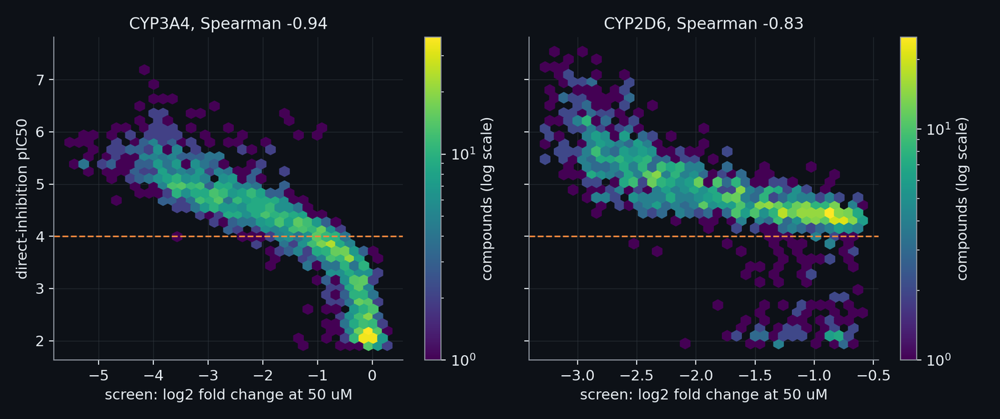

**Figure: The single-concentration screen against the direct pIC50.** The organisers' single-concentration screen (every compound at 50 micromolar, the log2 fold change of the signal against the control: more negative is more inhibition) against the direct-inhibition pIC50 of the same compound from its dose-response curve, for the compounds that have both. Every point is a compound; the colour counts the compounds in each cell. The dashed line is the floor of the assay at pIC50 = 4, below which a potency is not measured reliably. CYP3A4: 1805 compounds with both, Spearman -0.94; CYP2D6: 1493 compounds with both, Spearman -0.83. The screen reads the same biology as the curve, so a compound that inhibits strongly in the screen has a high pIC50; but the relation is loose below the floor, and the screen is available only for the training compounds, so it could be used to train a block of the model and never as an input at prediction time (section 9.10): predicted from structure, it did not pass its gate.

In [56]:
show_figure("data_screen_vs_pic50")

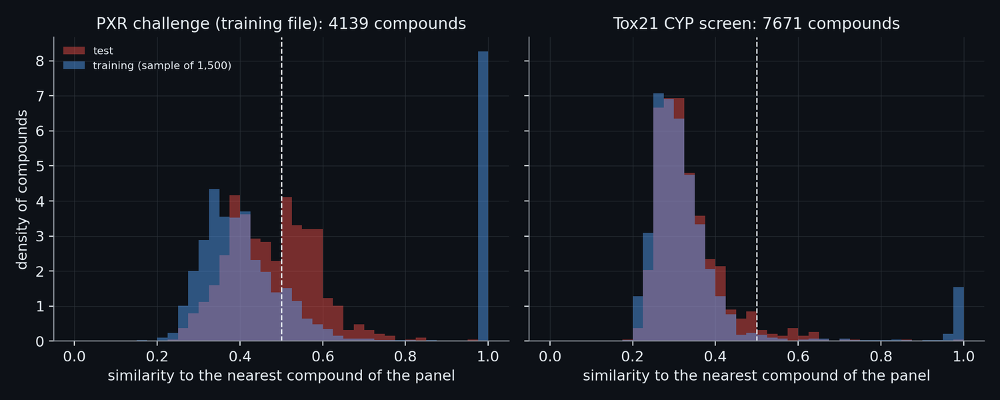

**Figure: How far the PXR and Tox21 panels cover the chemistry of the challenge.** How much of the chemistry of the challenge the two external panels cover: for each test compound (and for a random 1,500 of the training compounds), the Tanimoto similarity of its Morgan fingerprint to the most similar compound of the panel. PXR challenge (training file) (4139 compounds): median nearest-neighbour similarity of a test compound 0.48, 44.4% of the test compounds with a neighbour at 0.5 or more, 0 identical; 20.6% of the training sample are identical to a compound of the panel; Tox21 CYP screen (7671 compounds): median nearest-neighbour similarity of a test compound 0.31, 4.4% of the test compounds with a neighbour at 0.5 or more, 1 identical; 3.4% of the training sample are identical to a compound of the panel. The spike at 1 is the compounds that the training set and the panel share (the same library was tested in both); the test set shares almost none. A block that is trained on a panel can only help where the panel has neighbours, and both panels cover the test chemistry thinly, which is consistent with the verdicts of these blocks (NOT MET alone and inside the stack, section 9.10). Only identifiers and structures of the panels are read here, never a measurement of a test compound.

In [57]:
show_figure("data_external_coverage")

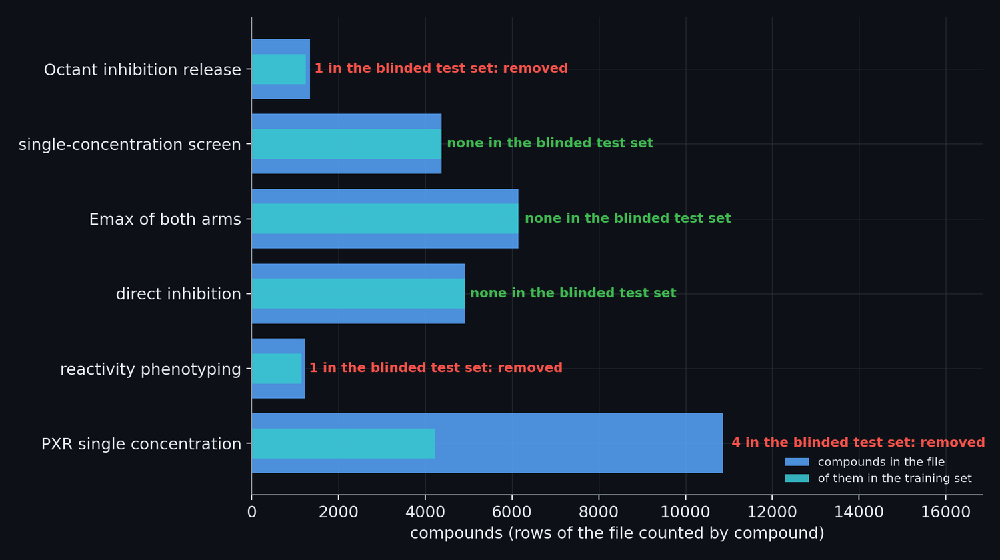

**Figure: The files released by the organisers, checked against the blinded test set.** The files of the organisers' releases that a model could read, and what each shares with the blinded test set. Only the identifier column of each file was read to make this picture: no measurement of a test compound is looked at, not even for a figure. 5 compounds of the blinded set turn up in three of the 6 files (their identifiers are withheld, because the release rule forbids naming a blinded compound in a file that would be pushed); they are removed from every use of those files, and the organisers confirmed the overlap of the Octant release. The other files hold no test compound.

In [58]:
show_figure("data_leak_guard")

## 2.9 Standardising structures: when two strings are the same compound

> **Field:** Cheminformatics

To remove from an external source the compounds that are also in the challenge's files, one has to decide when two strings stand for the same compound. A comparison of the strings as written finds almost nothing, because one compound has many strings (section 2.1) and a medicine is sold, and entered in
databases, as a salt: the active molecule together with a counter-ion such as chloride or a solvent such as water, written as extra components in the same string and separated by a dot. The same active molecule is then written with and without them. Four comparison rules, from the crudest to the most careful, applied to the TDC panel against all the
challenge compounds, give:

In [59]:
# What the standardised parent does to a salt. Three real compounds of the TDC panel that are in the challenge files only under another form: the same medicine as a salt, with a counter-ion
# or a solvent molecule in the same string. (The cell finds them by comparing the keys of section 2.9; only those that the canonical-SMILES comparison misses are shown.)
from cypmode.challenge.structure_standardization import standardized_parent_smiles

def canonical(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol) if mol is not None else None

tdc_unique = pd.Series(tdc_smiles).drop_duplicates().reset_index(drop=True)
challenge_all = pd.concat([train["SMILES"], test["SMILES"]], ignore_index=True)
canonical_challenge = set(challenge_all.map(canonical).dropna())
parent_challenge = set(challenge_all.map(standardized_parent_smiles).dropna())
tdc_canonical = tdc_unique.map(canonical)
tdc_parent = tdc_unique.map(standardized_parent_smiles)
tdc_key = tdc_unique.map(connectivity_key)
rule_rows = [
    {"matching rule": "the strings are identical", "TDC strings matched to a challenge compound": int(tdc_unique.isin(set(challenge_all)).sum())},
    {"matching rule": "the canonical SMILES are identical", "TDC strings matched to a challenge compound": int(tdc_canonical.isin(canonical_challenge).sum())},
    {"matching rule": "the connectivity keys of the InChIKey are identical", "TDC strings matched to a challenge compound": int(tdc_key.isin(challenge_keys).sum())},
    {"matching rule": "the standardised parent structures are identical (salts and solvents removed, charges neutralised)", "TDC strings matched to a challenge compound": int(tdc_parent.isin(parent_challenge).sum())}]
show_table(pd.DataFrame(rule_rows))
only_by_parent = tdc_unique[(~tdc_canonical.isin(canonical_challenge)) & tdc_parent.isin(parent_challenge)]
n_only_by_parent, n_salts = len(only_by_parent), int(tdc_unique.str.contains(r"\.").sum())
for original in only_by_parent.head(3):
    print(f"as written: {original}\n   parent:  {standardized_parent_smiles(original)}")
print(f"{n_salts} of the {len(tdc_unique)} distinct TDC strings contain more than one component")

as written: CS(=O)(=O)O.Cc1ccc(N(CC2=NCCN2)c2cccc(O)c2)cc1
   parent:  Cc1ccc(N(CC2=NCCN2)c2cccc(O)c2)cc1
as written: O=C(O)[C@@H](O)[C@@H](O)C(=O)O.O=C(c1ccc(F)cc1)C1CCN(CCn2c(=O)[nH]c3ccccc3c2=O)CC1
   parent:  O=C(c1ccc(F)cc1)C1CCN(CCn2c(=O)[nH]c3ccccc3c2=O)CC1
as written: N=C(N)c1ccc(OCCCCCOc2ccc(C(=N)N)cc2)cc1.O=S(=O)(O)CCO.O=S(=O)(O)CCO
   parent:  N=C(N)c1ccc(OCCCCCOc2ccc(C(=N)N)cc2)cc1
675 of the 16366 distinct TDC strings contain more than one component


| matching rule | TDC strings matched to a challenge compound |
| --- | --- |
| the strings are identical | 3 |
| the canonical SMILES are identical | 99 |
| the connectivity keys of the InChIKey are identical | 175 |
| the standardised parent structures are identical (salts and solvents removed, charges neutralised) | 114 |

The count rises from 3 (identical strings) to 99 (canonical SMILES) to 114 (standardised parent), and the connectivity key finds 175 because it is a different and coarser statement. The standardised parent is the
structure that remains after removing salts and solvents and neutralising charges where that is possible; the project uses the standardisation pipeline of ChEMBL itself (`chembl_structure_pipeline`, the tool with which ChEMBL curates its own structures) in `cypmode/challenge/structure_standardization.py`. A compound that cannot be read gives `None` and not an error, so that a handful of malformed rows cannot stop a pass over a
whole dataset. The 15 compounds found only by the parent rule are what a string comparison would have let through. The connectivity key, the first block of the InChIKey (a hash of the atoms and bonds that ignores stereochemistry, charges and isotopes), is a looser statement: it declares two stereoisomers to be one compound, which is the safe direction for removing leaks and the unsafe one for
counting distinct compounds. The project therefore uses the key where the aim is to leave compounds out (the training of `external_activity`) and the standardised parent where it checks that an external set does not contain a challenge compound (the three auxiliary sources and the similarity check of Part VI).

## 2.10 The public leaderboard as data: the positive rate of the scored set

> **Field:** Statistics

The challenge publishes, for every submitted file, the **accuracy** $A$ (the fraction of compounds called correctly), the **precision** $P$ (of the compounds called positive, the fraction that are positive) and the **recall** $R$ (of the positive compounds, the fraction that were called positive). They are quantities
of the confusion matrix of the file, whose four counts are the true positives $TP$ (called positive, are positive), the false positives $FP$ (called positive, are negative), the false negatives $FN$ (called negative, are positive) and the true negatives $TN$. Let $n$ be the number of scored compounds and $p$ the fraction of them that are positive.
Then, by the definitions, the positives are $pn = TP + FN$, recall is $R = TP/(pn)$, so $TP = Rpn$ and $FN = (1 - R)pn$. The compounds called positive are $TP + FP = TP/P = Rpn/P$, so $FP = (R/P - R)\,pn$. The errors are $FN + FP$, and accuracy is one minus the error rate:

$$1 - A \;=\; \frac{FN + FP}{n} \;=\; p\,\Bigl[(1 - R) + \bigl(\tfrac{R}{P} - R\bigr)\Bigr] \quad\Longrightarrow\quad p \;=\; \frac{1 - A}{1 - 2R + R/P}.$$

Three published numbers therefore give the positive rate of the set on which the file was scored, without any label being seen. Every row of a table is scored against the same labels, so the value of $p$ must be the same for all rows; the spread across rows is a check of the whole derivation. The module `cypmode/challenge/leaderboard_prior.py` implements it (`implied_prevalence`, `estimate_from_board`)
and takes the median over rows as the estimate. The cell checks the formula on synthetic sets of known positive rate and then applies it to the saved tables.

In [60]:
# The leaderboard as data. A prediction file is scored against the same hidden labels whoever submitted it; each row of the public table gives accuracy A, precision P and recall R of one file,
# and those three numbers fix the positive rate p of the scored set: p = (1 - A) / (1 - 2R + R/P). First a check on a synthetic set with a known positive rate, then the real tables.
from cypmode.challenge.leaderboard_prior import estimate_from_csv, implied_prevalence

rng = np.random.default_rng(7)
check_rows = []
for true_rate in (0.06, 0.3):
    labels = rng.random(100_000) < true_rate
    for strength in (0.8, 2.0):                                          # how far apart the scores of positives and negatives lie, in units of their spread
        scores = labels * strength + rng.normal(size=labels.size)
        called = scores > np.quantile(scores, 1 - 1.3 * true_rate)
        tp, fp, fn = int((called & labels).sum()), int((called & ~labels).sum()), int((~called & labels).sum())
        accuracy, precision, recall = (called == labels).mean(), tp / (tp + fp), tp / (tp + fn)
        check_rows.append({"positive rate of the set (counted)": float(labels.mean()), "A": accuracy, "P": precision, "R": recall, "recovered p": float(implied_prevalence(accuracy, precision, recall))})
show_table(pd.DataFrame(check_rows), floatfmt=".4f")

board_rows = []
for enzyme in ("CYP3A4", "CYP2D6"):
    for kind, stamp in (("interim", "2026-10-04"), ("live", "2026-10-07")):
        estimate = estimate_from_csv(ROOT / f"data/tdi_track/inputs/leaderboard_snapshots/{kind}_{enzyme}_{stamp}.csv")
        board_rows.append({"enzyme": enzyme, "table": f"{kind} ({stamp})", "rows used": estimate["n_rows"], "positive rate p": estimate["prevalence"], "spread of p across rows": estimate["spread"]})
board_table = pd.DataFrame(board_rows)
show_table(board_table, floatfmt=".5f")
prevalence_board = {(r["enzyme"], r["table"].split()[0]): r["positive rate p"] for r in board_rows}

| positive rate of the set (counted) | A | P | R | recovered p |
| --- | --- | --- | --- | --- |
| 0.0586 | 0.8918 | 0.1819 | 0.2421 | 0.0586 |
| 0.0586 | 0.9351 | 0.4599 | 0.6119 | 0.0586 |
| 0.3017 | 0.6758 | 0.4711 | 0.6090 | 0.3017 |
| 0.3017 | 0.8285 | 0.6669 | 0.8621 | 0.3017 |

| enzyme | table | rows used | positive rate p | spread of p across rows |
| --- | --- | --- | --- | --- |
| CYP3A4 | interim (2026-10-04) | 114 | 0.30965 | 0.00003 |
| CYP3A4 | live (2026-10-07) | 143 | 0.29156 | 0.00006 |
| CYP2D6 | interim (2026-10-04) | 114 | 0.05912 | 0.00004 |
| CYP2D6 | live (2026-10-07) | 135 | 0.07063 | 0.00011 |

On synthetic data the formula returns the counted positive rate of the set to rounding, and on the real tables the estimate is the same for every row to within 0.0001, so that the three numbers do describe one set of labels. The two kinds of table are different: the interim table was frozen at the deadline of 24 September 2026 and is scored on the full test set, while the live table is scored on half of it (`data/tdi_track/inputs/leaderboard_snapshots/README.md`), so the estimates differ a little, and the project works with the range between them. Compared with the training compounds:

In [61]:
# The positive rate of the training compounds that carry a label with both arms, against the rate of the scored test set recovered from the tables.
rate_view_3a4 = float(training_view(train, "CYP3A4").query("population == 'both_arms'")["label"].astype(bool).mean())
rate_both_arms = float(training_view(train, "CYP2D6").query("population == 'both_arms'")["label"].astype(bool).mean())
low_high = {e: (min(v for (en, _), v in prevalence_board.items() if en == e), max(v for (en, _), v in prevalence_board.items() if en == e)) for e in ("CYP3A4", "CYP2D6")}
compare = pd.DataFrame([
    {"enzyme": "CYP3A4", "training, both arms": rate_view_3a4, "scored set, interim table": prevalence_board[("CYP3A4", "interim")], "scored set, live table": prevalence_board[("CYP3A4", "live")]},
    {"enzyme": "CYP2D6", "training, both arms": rate_both_arms, "scored set, interim table": prevalence_board[("CYP2D6", "interim")], "scored set, live table": prevalence_board[("CYP2D6", "live")]}])
show_table(compare, floatfmt=".3f")

| enzyme | training, both arms | scored set, interim table | scored set, live table |
| --- | --- | --- | --- |
| CYP3A4 | 0.327 | 0.310 | 0.292 |
| CYP2D6 | 0.217 | 0.059 | 0.071 |

The scored test set has between 29% and 31% positives on CYP3A4 (the training rate is 33%) and between 6% and 7% on CYP2D6, against 22% among the CYP2D6 training compounds that have both arms. That is a large label shift on CYP2D6, and a
model whose threshold was chosen on the training rate would call far too many compounds positive; it is the reason the final model chooses its yes/no threshold by a call *rate* that is transferred to the scored population and not by a probability cut (section 8.4). It is also close to the 7.1% that CYP2D6 has among *all* compounds of the panel block, never-measured ones counted as negative (section 2.6), which is
the observation that suggested the selection-aware model of Part IX. It does not prove that the scored set is built like the panel, because the same positive rate can arise from other mixtures of hits and non-hits. The last cell asks whether the baseline's own public numbers can say what the mixture is (`cypmode/challenge/population_share.py`): the baseline's predictions on the training compounds are re-weighted for a range of mixtures, and the mixtures whose weighted accuracy, precision and recall agree with the baseline's published ones, within the
sampling uncertainty, are kept.

In [62]:
# The same three numbers can test a hypothesis about what the scored set contains (population_share): re-weight the baseline's out-of-fold predictions on the training compounds by w, the weight of
# the never-measured compounds, and c, the weight of the positives among the measured ones, and keep every (w, c) at which the weighted accuracy, precision and recall are within a chi-square
# 95 % region of the baseline's three published numbers.
band = pd.read_csv(ROOT / "data/tdi_track/outputs/comparisons/population_share_band.csv")
plausible = band[band["plausible"]]
band_summary = {"cells": len(band), "plausible": len(plausible), "w low": float(plausible["w"].min()), "w high": float(plausible["w"].max()), "grid w low": float(band["w"].min()), "grid w high": float(band["w"].max()),
                "c low": float(plausible["c"].min()), "c high": float(plausible["c"].max())}
by_w = band.groupby("w")["plausible"].any()
print(f"{band_summary['plausible']} of the {band_summary['cells']} (w, c) pairs of the grid are within the 95 % region; w runs from {band_summary['grid w low']} to {band_summary['grid w high']} on the grid and the plausible pairs "
      f"cover w from {band_summary['w low']} to {band_summary['w high']}: {int(by_w.sum())} of the {len(by_w)} values of w have at least one plausible c")

538 of the 775 (w, c) pairs of the grid are within the 95 % region; w runs from 0.0 to 1.5 on the grid and the plausible pairs cover w from 0.0 to 1.5: 31 of the 31 values of w have at least one plausible c


The data cannot say. Whatever weight $w$ is put on the never-measured compounds, from none to 1.5 times the training share, some choice of the second parameter fits the three published numbers, so the region of plausible mixtures spans the whole grid and does not identify the share of non-hits in the scored set (the audit of the project lists this as a failed check on purpose, `audit/AUDIT_REPORT.md`). That is a
limit of the information in the tables and not of the method, and it is why the project judges the selection-aware model over the *whole* band of shares (section 9.1) instead of choosing one, and decides between the two models for CYP2D6 by a rule fixed in advance (the final decision is in section 13.4).

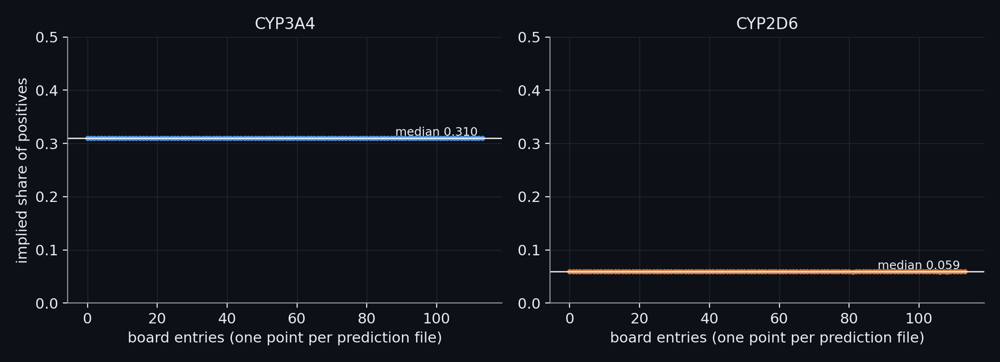

**Figure: The positive rate of the hidden test set, recovered from the public board.** Every row of the public interim board publishes the accuracy, the precision and the recall of one prediction file; the three numbers fix the share of positives among the scored compounds, p = (1 - accuracy) / ((1 - recall) + (recall / precision - recall)). All rows score the same hidden labels, so the implied p must agree across rows, and it does: CYP3A4: 114 entries, median 0.310, spread (standard deviation) 0.0000; CYP2D6: 114 entries, median 0.059, spread (standard deviation) 0.0000. This aggregate is the only information about the hidden labels that the project uses (to weight its yardstick and to set the call rate); it was available because the boards publish it, no probing submission was made, and it is disclosed as limitation L13 of the method report.

In [63]:
show_figure("data_prevalence_recovery")

## 2.11 A check of the positive rate that reads no board

> **Field:** Statistics · Machine learning

Section 2.10 recovers the positive rate of the scored set from numbers that the boards publish. That rate sets the weights of the evaluation and the number of positive calls, so a reader may ask whether the training file and the structures of the blinded file could give the same rate without any board. They can, but only roughly, and this section shows how roughly.

**The idea.** Take a classifier that gives every compound a score $s$, higher for a positive compound than for a negative one on average. Let $m_1$ be the average score of positive compounds and $m_0$ the average score of negative compounds, both measured on compounds whose labels are known and that the classifier was not trained on. If the blinded file holds a share $\pi$ of positives, its average score must be $\pi m_1 + (1 - \pi) m_0$, because the average of a mixture is the mixture of the averages. The average score $\bar s_{\text{blinded}}$ over the blinded file needs no label, so the equation can be solved for $\pi$:

$$\pi \;=\; \frac{\bar s_{\text{blinded}} - m_0}{m_1 - m_0}.$$

This is label-shift estimation with a black-box classifier (Lipton, Wang and Smola, 2018), here in its soft form, the probabilistic adjusted classify and count (Bella and colleagues, 2010). It assumes that within each class the compounds look the same in the training file and in the blinded file, and that only the share of the classes differs. That assumption is partly false here, because the blinded compounds are analogues of training compounds, so the held-out compounds are weighted to the similarity profile of the blinded file (a function of structures only), and the folds keep chemical series whole, so that a held-out compound has no close relative in the part that the model was trained on, as is true of many blinded compounds.

Two steps are specific to this challenge. The held-out compounds and the blinded compounds must be scored on one scale, so that $m_0$ and $m_1$ mean the same on both sides; each of the fifteen fold models therefore scores both. And only confidently labelled compounds are scored (section 2.5), so the rate among all compounds is moved to the scored compounds with the share of confident compounds among the positives and among the negatives, measured on the training file. For CYP2D6 the training population is the whole panel, with the compounds that were never promoted counted as negatives (section 2.6), because the scored set holds compounds of both kinds.

**The rule, fixed before the first run.** First, a recovery test: the held-out compounds of a fold are split by series, one half fixes $m_0$ and $m_1$ and the other half is resampled to a known positive rate and scored without its labels; the estimate counts only if the recovered rates are off by at most a quarter of the rate on average. Second, the estimate is informative only if its 95% interval is at most half as wide as the rate of the final build. Third, the verdict is AGREES if that rate lies inside the interval, DISAGREES if it lies outside, and NOT INFORMATIVE if either earlier condition fails. No verdict changes a submitted file.

In [64]:
# A second estimate of the positive rate of the scored set that reads no board (cypmode/challenge/label_shift.py, job 285): the log of that job holds, for each enzyme, the estimate for the scored compounds with its
# 95 % interval, the rate that the final build uses (read there for the comparison only), the error of the recovery test of known rates as a share of the rate, and the verdict of the rule written before the first run.
from cypmode.audit.method_report import label_shift_summary

shift = label_shift_summary()
shift_table = pd.DataFrame([{"enzyme": iso, "estimate": float(v["estimate"]), "interval low": float(v["lo"]), "interval high": float(v["hi"]), "rate of the final build": float(v["board"]),
                             "recovery error, share of the rate": float(v["ratio"]), "verdict of the rule": v["verdict"]} for iso, v in shift.items()])
inside = {iso: "inside" if float(v["lo"]) <= float(v["board"]) <= float(v["hi"]) else "outside" for iso, v in shift.items()}
show_table(shift_table, floatfmt=".3f")

| enzyme | estimate | interval low | interval high | rate of the final build | recovery error, share of the rate | verdict of the rule |
| --- | --- | --- | --- | --- | --- | --- |
| CYP2D6 | 0.135 | 0.043 | 0.286 | 0.059 | 0.680 | NOT INFORMATIVE |
| CYP3A4 | 0.352 | 0.274 | 0.451 | 0.310 | 0.160 | NOT INFORMATIVE |

For CYP3A4 the estimate for the scored compounds is 0.352 with the interval 0.274 to 0.451, and the final build uses 0.310, which lies inside the interval; the rule gives **NOT INFORMATIVE** (interval width 0.176 is above 0.5 times 0.310). For CYP2D6 the estimate is 0.135 with the interval 0.043 to 0.286 against 0.059, which lies inside the interval; the rule gives **NOT INFORMATIVE** (recovery error 0.68 of the rate is above 0.25).

The intervals are wide for a reason that the formula shows: the denominator $m_1 - m_0$ is small, because even a good classifier gives scores that overlap between the classes, and every error in the two averages is divided by it. The training file and the structures alone therefore fix the positive rate only to within about the width of these intervals, which is why the boards remain the source of the rate that the final build uses, and why section 2.10 was written. The check is kept because it could have disagreed: a rate outside an informative interval would have been reported as a conflict.

# Part III. Molecules as numbers

A learning algorithm takes a table of numbers: one row per compound, one column per measured or computed quantity, all rows of the same length. A molecule is a graph of atoms (section 2.1), of any size and shape, so the first
job is to turn it into a row of a fixed length that keeps what matters for the question. There is no single right way, and different ways keep different things, so the project uses many of them side by side and lets the models decide. This part builds them
one by one: the fingerprints, which record which small pieces of structure are present (3.1 to 3.4), the three-dimensional pharmacophore fingerprint (3.5), the grouping of compounds into chemical series, which is needed for a validation that does not leak
(3.6), and the feature store in which all the blocks are kept (3.7). Two rules hold for everything in this part: a feature is computed from the structure alone, never from a label, so that it cannot leak an answer into a model, and a feature that the project defined
and measured as useless is still described here, because what it was meant to do is part of the record.

## 3.1 Morgan (circular) fingerprints

> **Field:** Cheminformatics · Mathematics (hashing)

**The need.** A molecule of 23 atoms and a molecule of 60 atoms must both become a row of the same length, and two molecules that share a chemically meaningful piece, for example the same pyridine ring with the same substituents, must share something in their rows. A table with one column
per atom would have the wrong length and no meaning for a column. The idea of the **fingerprint** (which section 0.2 introduced as a list of yes/no answers) is to ask a long, fixed list of questions of the form "does the molecule contain *this* small piece of structure?" and to record the answers.
The questions need not be written by hand. The *Morgan algorithm* (Morgan, 1965, for identifying molecules in a database; used for fingerprints by Rogers and Hahn, 2010, under the name extended-connectivity fingerprints, ECFP) generates them from the molecule itself.

**The algorithm.** Describe each atom by its **environment**, everything within a given number of bonds, the **radius**. At radius 0 the environment is the atom alone; at radius 1 the atom with its bonded neighbours; at radius 2 also the neighbours of the neighbours. The algorithm builds the description
of these environments by repeated rounds. (1) Every atom gets a starting integer identifier computed from simple properties of the atom: its atomic number, the number of heavy atoms bonded to it, its number of hydrogens, its charge and whether it is in a ring. (2) In each round every atom collects the identifiers of its neighbours together with the order of the bond to each (single, double, ...), sorts that list so that it
does not depend on the numbering of the atoms, and combines its own identifier with the list into a new identifier by a **hash function**. A hash function is a fixed recipe that turns any input into a number so that equal inputs always give equal numbers and different inputs almost always give different ones. After round $r$ the identifier of an atom stands for its whole
environment of radius $r$. (3) All identifiers of all rounds up to the chosen radius are collected; the set (or, for a count fingerprint, the multiset) is the molecule's fingerprint. The fingerprint of radius 2 is also called ECFP4, because the largest environment is 4 bonds across. (4) To get a fixed length, each identifier is **folded**: the position in the row is the identifier modulo the width $m$ (the remainder after division by $m$), here $m = 2048$.

Folding has a price: two different environments can fall on the same position, a **collision**. If $k$ distinct environments were thrown at random into $m$ positions, a given position stays empty with probability $(1 - 1/m)^k$, so the expected number of occupied positions is $m\,[1 - (1 - 1/m)^k]$, slightly fewer than $k$. A **bit** fingerprint records only whether a position is occupied; a **count** fingerprint records how many environments fell on it, which also tells a molecule with three methyl groups from a molecule with one.
The cell implements the rounds in a few lines, compares them with RDKit's implementation on the example compound, and checks the arithmetic of folding.

In [65]:
# The Morgan algorithm written out (a toy that uses nothing but the graph of the example compound) and compared with RDKit's own. Every atom starts with an identifier made from five properties
# (atomic number, number of bonded heavy atoms, number of hydrogens, charge, ring or not). In each round an atom's new identifier is a hash of its old identifier and of the sorted list of
# (bond order, identifier) of its neighbours, so after r rounds it stands for everything within r bonds of the atom.
from rdkit.Chem import rdFingerprintGenerator

def toy_identifiers(molecule, radius):
    ids = [hash((a.GetAtomicNum(), a.GetDegree(), a.GetTotalNumHs(), a.GetFormalCharge(), int(a.IsInRing()))) for a in molecule.GetAtoms()]
    rounds = [ids[:]]
    for _ in range(radius):
        updated = []
        for atom in molecule.GetAtoms():
            neighbours = sorted((molecule.GetBondBetweenAtoms(atom.GetIdx(), n.GetIdx()).GetBondTypeAsDouble(), ids[n.GetIdx()]) for n in atom.GetNeighbors())
            updated.append(hash((ids[atom.GetIdx()], tuple(neighbours))))
        ids = updated
        rounds.append(ids[:])
    return rounds

def classes(identifiers):
    groups = {}
    for atom, identifier in enumerate(identifiers):
        groups.setdefault(identifier, []).append(atom)
    return sorted(map(tuple, groups.values()))

rounds = toy_identifiers(mol, 2)
rdkit_rows, agree = [], []
for redundant in (True, False):
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, includeRedundantEnvironments=redundant)
    extra = rdFingerprintGenerator.AdditionalOutput()
    extra.AllocateBitInfoMap()
    generator.GetSparseCountFingerprint(mol, additionalOutput=extra)
    environment = {(atom, r): identifier for identifier, entries in extra.GetBitInfoMap().items() for atom, r in entries}      # (atom, radius) -> unfolded identifier
    for r in range(3):
        theirs = {a: identifier for (a, rr), identifier in environment.items() if rr == r}
        same = classes([theirs[a] for a in sorted(theirs)]) == classes([rounds[r][a] for a in sorted(theirs)]) if len(theirs) == mol.GetNumAtoms() else None
        if redundant:
            agree.append(same)
    rdkit_rows.append((redundant, {r: len({i for (a, rr), i in environment.items() if rr == r}) for r in range(3)}))
by_radius = pd.DataFrame([{"radius": r, "atoms in the round": mol.GetNumAtoms(), "distinct identifiers in the toy": len(set(rounds[r])),
                           "distinct identifiers in RDKit, all environments": rdkit_rows[0][1][r], "distinct identifiers in RDKit, redundant ones dropped": rdkit_rows[1][1][r],
                           "same grouping of the atoms as RDKit's": "yes" if agree[r] else "no"} for r in range(3)])
show_table(by_radius)

# Folding: an identifier is a 32-bit number; the fingerprint position is the identifier modulo the width (here 2048). Different environments can land on one position.
unfolded = rdFingerprintGenerator.GetMorganGenerator(radius=2).GetSparseCountFingerprint(mol).GetNonzeroElements()
folded = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048).GetFingerprint(mol)
k, m_bits = len(unfolded), 2048
expected_on = m_bits * (1 - (1 - 1 / m_bits) ** k)
print(f"{k} distinct environments are written to {folded.GetNumOnBits()} of the {m_bits} positions; if the positions were chosen at random one would expect {expected_on:.1f} occupied positions")
print(f"{sum(unfolded.values())} environments counted with repeats; {sum(1 for c in unfolded.values() if c > 1)} of the {k} occur more than once")
n_environments, n_on_bits, n_expected_on = k, folded.GetNumOnBits(), expected_on

47 distinct environments are written to 46 of the 2048 positions; if the positions were chosen at random one would expect 46.5 occupied positions
61 environments counted with repeats; 10 of the 47 occur more than once


| radius | atoms in the round | distinct identifiers in the toy | distinct identifiers in RDKit, all environments | distinct identifiers in RDKit, redundant ones dropped | same grouping of the atoms as RDKit's |
| --- | --- | --- | --- | --- | --- |
| 0 | 23 | 14 | 14 | 14 | yes |
| 1 | 23 | 18 | 18 | 18 | yes |
| 2 | 23 | 19 | 19 | 15 | yes |

The toy and RDKit group the atoms in the same way at every radius: the algorithm is exactly the one described. RDKit by default drops an environment when it covers exactly the same bonds as an earlier one (a terminal atom's environment at radius 2 may be a copy of what its neighbour already had), which
is why its default count at radius 2 is lower than the toy's. The example compound has 47 distinct environments, folded onto 46 positions of the 2048, where 46.5 occupied positions are expected if the
identifiers behaved like random numbers: the hashing spreads the environments about as evenly as chance would, and few collide. The figure shows the algorithm on a real training compound, radius by radius.

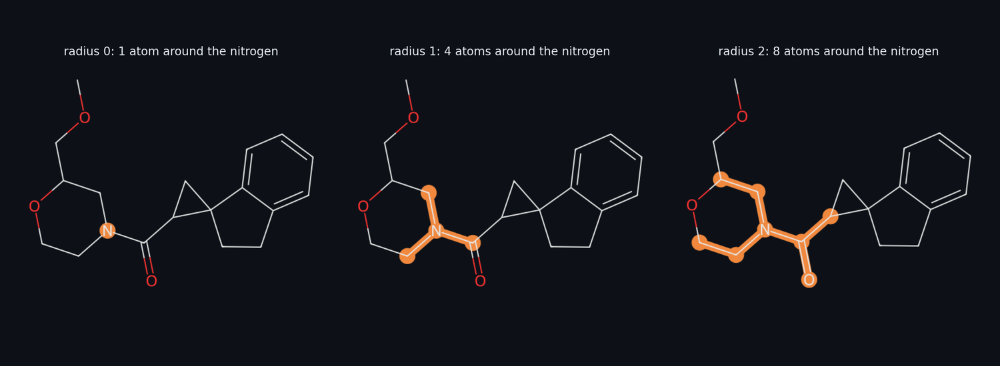

**Figure: The Morgan algorithm, radius by radius.** The Morgan algorithm on one real training compound (22 heavy atoms; its identifier is withheld because the compound is in the blinded set). Radius 0 looks at each atom alone, radius 1 adds its bonded neighbours, radius 2 the neighbours of the neighbours; the highlighted atoms are the environment of one atom at each radius. Every environment is hashed to a number between 0 and 2047 and that position of the fingerprint is switched on. This compound has 22 environments of radius 0, 22 of radius 1 and 20 of radius 2, which switch on 51 of the 2048 bits (two environments that hash to the same position share a bit).

In [66]:
show_figure("mol_morgan_steps")

The cell below reads the stored table of the project (built in section 3.7) and shows how the Morgan block looks over all 6895 compounds.

In [67]:
# What the Morgan blocks of the stored feature table look like over all 6895 compounds (the file is built in section 3.7): how many positions are on in a molecule, and how often each position is on.
store = np.load(ROOT / "data/tdi_track/outputs/caches/feature_store.npz", allow_pickle=True)
store_smiles = list(store["smiles"])
assert store_smiles == list(train["SMILES"]) + list(test["SMILES"])             # rows 0 .. 6144 are the training compounds, 6145 .. 6894 the test compounds
bits = store["morgan_bits"]
on_per_molecule = bits.sum(axis=1)
frequency = bits.mean(axis=0)
morgan_rows = [{"quantity": "positions switched on per molecule (median, 5th to 95th percentile)", "value": f"{np.median(on_per_molecule):.0f} ({np.percentile(on_per_molecule, 5):.0f} to {np.percentile(on_per_molecule, 95):.0f})"},
               {"quantity": "positions that are on in no compound", "value": f"{int((frequency == 0).sum())} of 2048"},
               {"quantity": "positions that are on in more than half of the compounds", "value": f"{int((frequency > 0.5).sum())}"},
               {"quantity": "positions that are on in fewer than 1 % of the compounds", "value": f"{int((frequency < 0.01).sum())}"},
               {"quantity": "share of all entries of the table that are 1", "value": f"{bits.mean():.1%}"}]
show_table(pd.DataFrame(morgan_rows))
sparsity = float(1 - bits.mean())
radius3 = store["morgan_c3"]
counts2 = store["morgan_c2"]
print(f"the count block with radius 2 has a largest count of {int(counts2.max())}; the radius-3 block sums to {radius3.sum(axis=1).mean():.1f} environments per molecule against {counts2.sum(axis=1).mean():.1f} for radius 2")

the count block with radius 2 has a largest count of 34; the radius-3 block sums to 90.7 environments per molecule against 72.4 for radius 2


| quantity | value |
| --- | --- |
| positions switched on per molecule (median, 5th to 95th percentile) | 49 (36 to 61) |
| positions that are on in no compound | 0 of 2048 |
| positions that are on in more than half of the compounds | 14 |
| positions that are on in fewer than 1 % of the compounds | 1173 |
| share of all entries of the table that are 1 | 2.4% |

A fingerprint is **sparse**: only 2.4% of the entries of the bit table are 1, which is why the bits are described as questions most molecules answer "no" to, and why the right measure of similarity is not the usual
one (section 3.2). The radius-3 count block records more environments per molecule than radius 2, as it must, since it contains everything of radius 2 and the environments of one more round. Which of these representations a model uses is decided by the validation of Part VI and not by taste.

## 3.2 Tanimoto similarity and why it suits fingerprints

> **Field:** Cheminformatics · Mathematics (set similarity)

To compare two molecules one needs a number that is large when they share many structural pieces and small when they share few. Two fingerprints can be seen as two sets, $A$ and $B$, the sets of positions that are on, with $a = |A|$ and $b = |B|$ elements, of which $c = |A \cap B|$ are common. The **Tanimoto similarity**
(the index that Jaccard proposed in 1901 for comparing plant communities, introduced for chemistry by Tanimoto in 1958) is the share of the positions on in *either* fingerprint that are on in *both*:

$$T(A, B) \;=\; \frac{|A \cap B|}{|A \cup B|} \;=\; \frac{c}{a + b - c}, \qquad 0 \le T \le 1,$$

where the second form follows because the union counts the common positions once, $|A \cup B| = a + b - c$. It is 1 when the two sets are the same and 0 when they have nothing in common. For count fingerprints with entries $x_i$ and $y_i$ the same idea gives the min/max form
$T = \sum_i \min(x_i, y_i) \,/\, \sum_i \max(x_i, y_i)$, which reduces to the first form when every entry is 0 or 1. The distance $1 - T$ obeys the triangle inequality (Lipkus, 1999), so it is a true distance, which is what clustering (section 3.6) and nearest-neighbour methods (section 4.5) need.

**Why not simply count the positions where the fingerprints agree?** Because almost all positions are 0 in both. Take two molecules with 46 positions on each and none in common: they disagree on 92 of the 2048 positions and agree on the other 1956, an agreement of 95 %, although the molecules share nothing. The absence of a piece is almost never informative: no one would call two
molecules similar because both lack a piece out of two thousand. The Tanimoto similarity leaves the shared zeros out of both numerator and denominator, which is the whole point. The cell computes it by hand for the example and its closest training relative, and compares it with the agreement of all positions on 4000 random pairs.

In [68]:
# The Tanimoto similarity by hand and by RDKit, and why the obvious alternative, the fraction of positions on which two fingerprints agree, does not work for fingerprints that are mostly zeros.
generator_2048 = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
example_fp = generator_2048.GetFingerprint(mol)
all_train_fp = [generator_2048.GetFingerprint(Chem.MolFromSmiles(s)) for s in train["SMILES"]]
similarities = np.array(DataStructs.BulkTanimotoSimilarity(example_fp, all_train_fp))
similarities[train["Molecule_Name"].to_numpy() == example_name] = -1
nearest = int(similarities.argmax())
other_fp = all_train_fp[nearest]
on_a, on_b = set(example_fp.GetOnBits()), set(other_fp.GetOnBits())
a, b, c = len(on_a), len(on_b), len(on_a & on_b)
by_hand = c / (a + b - c)
print(f"the example has a = {a} positions on, its nearest training compound ({train['Molecule_Name'][nearest]}) has b = {b}, and c = {c} are on in both")
print(f"Tanimoto by hand c / (a + b - c) = {by_hand:.4f}; RDKit gives {DataStructs.TanimotoSimilarity(example_fp, other_fp):.4f}")

# 4000 random pairs of training compounds: Tanimoto against the agreement of all 2048 positions (1 minus the Hamming distance divided by the width).
rng = np.random.default_rng(0)
pairs = [(int(i), int(j)) for i, j in rng.integers(0, 1000, size=(4000, 2)) if i != j]
tanimoto_values = np.array([DataStructs.TanimotoSimilarity(all_train_fp[i], all_train_fp[j]) for i, j in pairs])
agreement_values = np.array([1 - (all_train_fp[i] ^ all_train_fp[j]).GetNumOnBits() / 2048 for i, j in pairs])
compare_rows = [{"measure": "Tanimoto similarity", "smallest": tanimoto_values.min(), "median": np.median(tanimoto_values), "largest": tanimoto_values.max()},
                {"measure": "fraction of the 2048 positions that agree", "smallest": agreement_values.min(), "median": np.median(agreement_values), "largest": agreement_values.max()}]
show_table(pd.DataFrame(compare_rows))

# For counts instead of bits the same idea is the min / max form: sum of the smaller counts over sum of the larger counts.
count_a = generator_2048.GetCountFingerprintAsNumPy(mol).astype(float)
count_b = generator_2048.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(train["SMILES"][nearest])).astype(float)
minmax = np.minimum(count_a, count_b).sum() / np.maximum(count_a, count_b).sum()
print(f"the min / max form on the counts of the same two molecules: {minmax:.4f}")
nearest_compound, tanimoto_median, agreement_median = train["Molecule_Name"][nearest], float(np.median(tanimoto_values)), float(np.median(agreement_values))

the example has a = 46 positions on, its nearest training compound (OCNT-2395657) has b = 45, and c = 38 are on in both
Tanimoto by hand c / (a + b - c) = 0.7170; RDKit gives 0.7170
the min / max form on the counts of the same two molecules: 0.7429


| measure | smallest | median | largest |
| --- | --- | --- | --- |
| Tanimoto similarity | 0.000 | 0.151 | 1.000 |
| fraction of the 2048 positions that agree | 0.946 | 0.960 | 1.000 |

The Tanimoto similarity of random pairs of compounds covers almost the whole range, with a median of 0.15, while the fraction of agreeing positions is at least 0.95 for every pair: it cannot tell any pair of molecules from any other. The example compound's closest relative in the training set is OCNT-2395657, at a similarity of 0.72.
The meaning of a value is empirical and not a law: a Tanimoto similarity of 0.5 on Morgan fingerprints of radius 2 usually marks a close relative of the same series (the figure shows the example with its closest relative among the compounds that have both arms and with a compound of median similarity), and the project uses 0.5 and 0.6 as practical cut-offs (sections 2.7 and 3.6). Similarity of structure is not similarity of behaviour: two close relatives can differ in the potency by orders of magnitude, a limit of every method that
works with neighbours (section 7.3).

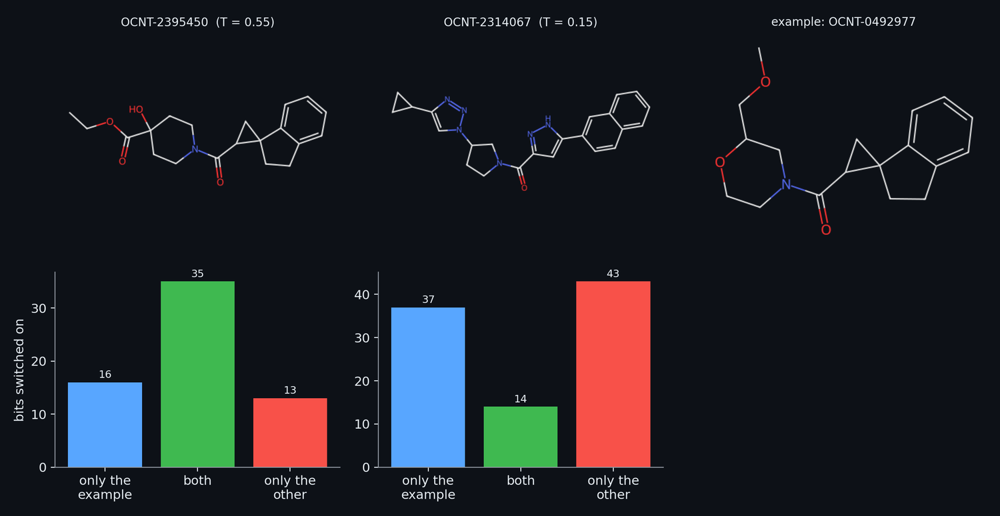

**Figure: Tanimoto similarity between real compounds.** Tanimoto similarity T = |A and B| / |A or B| between the example compound and two other training compounds: its nearest neighbour (T = 0.55) and a compound at the median similarity (T = 0.15). The bars count the fingerprint bits only the example has, the bits both have, and the bits only the other has. Over all 2333 other compounds the median similarity is 0.15, and 2 of them reach 0.5 or more.

In [69]:
show_figure("mol_tanimoto")

## 3.3 Descriptors: a molecule as a few dozen physical quantities

> **Field:** Cheminformatics · Chemistry

A fingerprint says which pieces are there; a **descriptor** says how big, how greasy or how polar the whole molecule is. The two kinds are complementary: a fingerprint cannot add up the contributions of the many pieces, and a descriptor cannot say where they are. The project uses all 217 descriptors of RDKit as one block (`rdkit_desc`), with non-finite values replaced by 0 and all values clipped to $\pm 10^6$. The best known are:

- **Molecular weight**, the sum of the atomic masses in g/mol: the size of the molecule.
- **logP**, the logarithm of the **partition coefficient** between oil and water. If a compound is shaken with equal volumes of 1-octanol (a stand-in for the oily interior of a membrane or of a protein pocket) and water until it has distributed itself, $P = [X]_{\text{octanol}} / [X]_{\text{water}}$ is the ratio of its concentrations in the two layers, and $\log P = \log_{10} P$; a positive logP means that the compound prefers oil. It cannot be measured for a compound that does not exist
  yet, so it is estimated. The Wildman-Crippen method (1999) assigns every atom a type from the atom, its aromaticity and its neighbours (several dozen types, found by matching patterns) and adds up the contribution $a_t$ that was fitted by regression to measured values: $\log P = \sum_{i} a_{t(i)}$ over all atoms $i$, including hydrogens.
- **Topological polar surface area** (TPSA, Ertl, Rohde and Selzer, 2000) in square angstrom: the surface that nitrogen and oxygen atoms (with their hydrogens) would present, again a sum of fragment contributions, $\mathrm{TPSA} = \sum_{f} s_f$, and again read from the graph and not from a 3D structure. It is a measure of how polar a molecule is, and polar molecules cross membranes less readily.
- **Hydrogen-bond donors and acceptors** (the counts of N-H and O-H groups, and of N and O atoms, that can give or accept a hydrogen bond, the definitions of Lipinski), **rotatable bonds** (single bonds between non-terminal heavy atoms that are not in a ring: the flexibility), the number of rings and the **fraction of carbons that are sp3** (carbons with four single bonds, the "non-flat" ones).

Lipinski and co-workers (1997) noted that most orally active drugs have a molecular weight of at most 500, a logP of at most 5, at most 5 donors and at most 10 acceptors; such numbers describe the space that drug-like molecules occupy. The cell computes these for the example compound and rebuilds two of them from their atoms to show that the descriptors are sums: the atom contributions to logP and TPSA must add up to the descriptors.

In [70]:
# Some of the 217 RDKit descriptors, computed for the example compound, and two of them rebuilt from their parts: the Wildman-Crippen logP and the topological polar surface area are
# sums over atoms, so the contributions of the single atoms must add up to the value of the descriptor.
from rdkit.Chem import Crippen

with_h = Chem.AddHs(mol)
crippen = rdMolDescriptors._CalcCrippenContribs(with_h)                    # (logP contribution, molar refractivity contribution) of every atom, hydrogens included
tpsa_parts = rdMolDescriptors._CalcTPSAContribs(mol)                       # contribution of every heavy atom in square angstrom
log_p_sum, tpsa_sum = sum(x[0] for x in crippen), sum(tpsa_parts)
assert abs(log_p_sum - Crippen.MolLogP(mol)) < 1e-9 and abs(tpsa_sum - rdMolDescriptors.CalcTPSA(mol)) < 1e-9
polar_atoms = [(mol.GetAtomWithIdx(i).GetSymbol(), round(v, 2)) for i, v in enumerate(tpsa_parts) if v > 0]
by_atom = pd.DataFrame({"element": [with_h.GetAtomWithIdx(i).GetSymbol() for i in range(with_h.GetNumAtoms())], "logP contribution": [x[0] for x in crippen]})
by_group = by_atom.groupby("element").agg(atoms=("logP contribution", "size"), total=("logP contribution", "sum")).sort_values("total").reset_index()
assert {symbol for symbol, _ in [(mol.GetAtomWithIdx(i).GetSymbol(), v) for i, v in enumerate(tpsa_parts) if v > 0]} <= {"N", "O"}
show_table(by_group, floatfmt=".3f")
descriptor_rows = [{"descriptor": "molecular weight (g/mol)", "value": Descriptors.MolWt(mol)}, {"descriptor": "Wildman-Crippen logP", "value": Crippen.MolLogP(mol)},
                   {"descriptor": "topological polar surface area (A^2)", "value": rdMolDescriptors.CalcTPSA(mol)}, {"descriptor": "hydrogen-bond donors", "value": rdMolDescriptors.CalcNumHBD(mol)},
                   {"descriptor": "hydrogen-bond acceptors", "value": rdMolDescriptors.CalcNumHBA(mol)}, {"descriptor": "rotatable bonds", "value": rdMolDescriptors.CalcNumRotatableBonds(mol)},
                   {"descriptor": "rings", "value": rdMolDescriptors.CalcNumRings(mol)}, {"descriptor": "fraction of sp3 carbons", "value": rdMolDescriptors.CalcFractionCSP3(mol)}]
show_table(pd.DataFrame(descriptor_rows), floatfmt=".2f")
print(f"logP: the sum of the {len(crippen)} atom contributions is {log_p_sum:.4f} and the descriptor is {Crippen.MolLogP(mol):.4f}; TPSA: the polar atoms {polar_atoms} add up to {tpsa_sum:.2f}")
n_descriptors = len(Descriptors.descList)

logP: the sum of the 44 atom contributions is 2.7683 and the descriptor is 2.7683; TPSA: the polar atoms [('N', 12.03), ('O', 17.07), ('O', 17.07), ('N', 12.03), ('N', 12.89), ('N', 23.79)] add up to 94.88


| element | atoms | total |
| --- | --- | --- |
| N | 4 | -1.537 |
| O | 2 | -0.668 |
| S | 1 | -0.002 |
| Br | 1 | 0.846 |
| C | 15 | 1.365 |
| H | 21 | 2.765 |

| descriptor | value |
| --- | --- |
| molecular weight (g/mol) | 401.33 |
| Wildman-Crippen logP | 2.77 |
| topological polar surface area (A^2) | 94.88 |
| hydrogen-bond donors | 2.00 |
| hydrogen-bond acceptors | 5.00 |
| rotatable bonds | 5.00 |
| rings | 2.00 |
| fraction of sp3 carbons | 0.60 |

The contributions of the atoms add up to the descriptors exactly (the cell asserts it): the table groups the contributions to logP by element, and the polar surface of 94.9 square angstrom comes from the nitrogens and oxygens alone, the only atoms that the version of the method used here counts. The same table for the whole data: do the test compounds differ from the training compounds in these simple quantities?

In [71]:
# The descriptors of the training compounds against those of the test compounds (the cached block, columns named by the descriptor list).
names = [name for name, _ in Descriptors.descList]
table = store["rdkit_desc"]
assert table.shape[1] == len(names)
columns = {"MolWt": "molecular weight", "MolLogP": "logP", "TPSA": "polar surface area", "NumHDonors": "H-bond donors", "NumHAcceptors": "H-bond acceptors", "NumRotatableBonds": "rotatable bonds", "FractionCSP3": "fraction sp3"}
shift_rows = []
for key, title in columns.items():
    column = table[:, names.index(key)]
    shift_rows.append({"descriptor": title, "training median": np.median(column[: len(train)]), "test median": np.median(column[len(train):]), "training 5th to 95th": f"{np.percentile(column[: len(train)], 5):.1f} to {np.percentile(column[: len(train)], 95):.1f}",
                       "test 5th to 95th": f"{np.percentile(column[len(train):], 5):.1f} to {np.percentile(column[len(train):], 95):.1f}"})
show_table(pd.DataFrame(shift_rows), floatfmt=".2f")
mw_train, mw_test = shift_rows[0]["training median"], shift_rows[0]["test median"]

| descriptor | training median | test median | training 5th to 95th | test 5th to 95th |
| --- | --- | --- | --- | --- |
| molecular weight | 348.82 | 337.36 | 283.3 to 472.5 | 247.6 to 434.6 |
| logP | 2.94 | 2.86 | 1.2 to 4.9 | 1.1 to 4.4 |
| polar surface area | 68.84 | 70.67 | 38.1 to 105.2 | 42.0 to 108.8 |
| H-bond donors | 1.00 | 2.00 | 0.0 to 3.0 | 0.0 to 3.0 |
| H-bond acceptors | 4.00 | 4.00 | 2.0 to 6.0 | 2.0 to 6.0 |
| rotatable bonds | 4.00 | 4.00 | 2.0 to 9.0 | 2.0 to 7.0 |
| fraction sp3 | 0.35 | 0.26 | 0.1 to 0.6 | 0.1 to 0.7 |

The median test compound has a molecular weight of 337 against 349 for the training compounds, and the other rows give the full comparison. A shift in such plain quantities is another face of the covariate shift of section 2.7; whether it matters for a model depends on whether the model leans on these columns, which is what the validation of Part VI measures.

## 3.4 The other fingerprint and descriptor blocks

> **Field:** Cheminformatics

The Morgan fingerprint is one of many ways to ask structural questions. The feature store holds several more, because each makes different questions possible and no one of them is known in advance to be the best for this problem.

- **Atom pairs** (Carhart, Smith and Venkataraghavan, 1985): for every pair of atoms, the types of the two atoms and the number of bonds on the shortest path between them, hashed and counted (2048 positions). It encodes where things are relative to each other without any 3D geometry.
- **Topological torsions** (Nilakantan, Bauman, Dixon and Venkataraghavan, 1987): every path of four bonded atoms, with the atom types and the numbers of attached heavy atoms, hashed and counted (1024 positions).
- **Feature-Morgan** (FCFP, Rogers and Hahn, 2010): the Morgan algorithm, but the starting identifier of an atom is not its element but its pharmacophoric kind (hydrogen-bond donor, acceptor, positive or negative ionisable, aromatic, halogen), so that two molecules with different atoms in the same roles look alike (1024 counts).
- **MACCS keys** (Durant, Leland, Henry and Nourse, 2002): 166 hand-written structural questions, such as "is there an N-O bond?" or "are there at least two rings?", defined by MDL for database searching. The table has 167 columns because the first one is unused.
- **Avalon fingerprint** (Gedeck, Rohde and Bartels, 2006): hashed fragments of paths and atom-centred features enumerated by a different procedure (1024 bits).
- **Extended reduced graphs, ErG** (Stiefl, Watson, Baumann and Zaliani, 2006): the molecule is first collapsed into a graph of pharmacophore-like nodes (a ring becomes one node of its kind, a functional group another), and the fingerprint is the number of node pairs of each type at each topological distance (315 real values). It is deliberately coarse, so that molecules built on different skeletons but with the same pattern of roles look alike.
- **The project's own blocks**: the six heme-binding nitrogen motifs of Part V, 30 structural alerts and two ring features (section 1.10), 15 *alert-context* columns that weight an alert by the lipophilicity and size of the molecule, the presence of fluorine near the alert and the number of labile groups (medicinal chemists slow bioactivation with just such changes, Leach and co-workers, 2014), and one column for a trialkylamine (section 5.2).
- **Blocks that are read from a cache** instead of being computed on demand: five probabilities from models of external data (section 2.8), 64 principal components of a pretrained embedding (section 9.4) and the two physics blocks (Part X). Their computation takes minutes to hours and runs in its own processes, so the store only reads them.

The cell lists every block with its real width in the stored table and shows how many columns are non-zero for the example compound.

In [72]:
# Every block of the feature store, with its real width in the stored table, its kind, and what the example compound looks like in it. The default blocks are computed here from the compound with
# the same functions the store uses (BLOCKS in feature_store.py); the opt-in blocks come from caches built by their own processes and are only read.
from cypmode.challenge.feature_store import BLOCKS as BLOCK_FUNCTIONS, OPT_IN_BLOCKS

meaning = {
    "morgan_bits": ("bits", "Morgan environments up to radius 2 present or absent (section 3.1)"),
    "morgan_c2": ("counts", "the same, with the number of occurrences"),
    "morgan_c3": ("counts", "Morgan environments up to radius 3, counted"),
    "fmorgan_c2": ("counts", "Morgan with atoms described by their pharmacophoric kind, counted"),
    "atompair_c": ("counts", "pairs of atom types with the number of bonds between them, counted"),
    "torsion_c": ("counts", "paths of four bonded atoms, counted"),
    "maccs": ("bits", "166 predefined structural questions, plus an unused first position"),
    "avalon": ("bits", "hashed path and feature fragments (Avalon)"),
    "erg": ("real", "extended reduced graph: pairs of pharmacophore-like nodes at binned distances"),
    "rdkit_desc": ("real", "all 217 descriptors of RDKit (section 3.3)"),
    "motif": ("bits", "six heme-binding nitrogen motifs and whether any is present (Part V)"),
    "tdi_alerts": ("counts", "30 structural alerts of section 1.10, a ring-size flag and the largest ring"),
    "tdi_alert_context": ("real", "the alerts weighted by lipophilicity, size, fluorine nearby and labile groups"),
    "amine": ("bits", "a trialkylamine that is not a sulfonamide, enamine or guanidine (section 5.2)"),
    "ext_activity": ("real", "five probabilities from models trained on the TDC panel only (section 2.8)"),
    "chemeleon": ("real", "64 principal components of a frozen pretrained embedding (section 9.4)"),
    "physics": ("real", "GFN2-xTB electronic and site descriptors, 133 columns (Part X)"),
    "physics_b": ("real", "Boltzmann-weighted and relaxed physics, 22 columns (Part X)"),
    "basic_centre": ("real", "protonation states at pH 6.4 to 8.4 and the distances between the charged nitrogen and the aromatic rings (Part IX)"),
    "monroe": ("real", "64 principal components of a frozen pretrained graph-transformer embedding (Part IX)"),
    "ext_cont": ("real", "predicted response and potency of the external cytochrome panel, a pair for each of five enzymes (Part IX)"),
    "ext_tox": ("real", "predicted response and potency of the Tox21 cytochrome screen, a pair for each of five enzymes (Part IX)"),
    "ext_adme": ("real", "two predicted properties, logD and mouse brain protein binding, from surrogate networks (Part IX)"),
    "atomjepa": ("real", "64 principal components of the frozen embeddings of a pretrained equivariant network (Part IX)"),
    "pp3a4": ("real", "22 columns of the compound against the CYP3A4 pocket: density fields of the public crystal ligands in the frame of the heme (section 9.13)"),
    "pp2d6": ("real", "the same 22 columns against the CYP2D6 pocket (section 9.13)"),
    "st3a4": ("real", "6 columns of the structure-based site model of the CYP3A4 pocket: recall, matched sites and precision for two modes (section 9.14)"),
    "st2d6": ("real", "the same 6 columns for the CYP2D6 pocket (section 9.14)"),
}
example_blocks = {name: np.asarray(BLOCK_FUNCTIONS[name]([mol])).ravel() for name in BLOCK_FUNCTIONS if name not in OPT_IN_BLOCKS}
block_rows = []
for name in store.files:
    if name == "smiles":
        continue
    width = store[name].shape[1]
    row = {"block": name, "columns": width, "kind": meaning[name][0], "what it holds": meaning[name][1], "opt-in": "yes" if name in OPT_IN_BLOCKS else "no"}
    if name in example_blocks:
        assert example_blocks[name].shape[0] == width
        row["non-zero for the example"] = int((example_blocks[name] != 0).sum())
    else:
        row["non-zero for the example"] = "-"
    block_rows.append(row)
block_table = pd.DataFrame(block_rows)
show_table(block_table)
n_blocks, n_columns_total = len(block_table), int(block_table["columns"].sum())
n_opt_in = int((block_table["opt-in"] == "yes").sum())

| block | columns | kind | what it holds | opt-in | non-zero for the example |
| --- | --- | --- | --- | --- | --- |
| morgan_bits | 2048 | bits | Morgan environments up to radius 2 present or absent (section 3.1) | no | 46 |
| morgan_c2 | 2048 | counts | the same, with the number of occurrences | no | 46 |
| morgan_c3 | 2048 | counts | Morgan environments up to radius 3, counted | no | 57 |
| fmorgan_c2 | 1024 | counts | Morgan with atoms described by their pharmacophoric kind, counted | no | 38 |
| atompair_c | 2048 | counts | pairs of atom types with the number of bonds between them, counted | no | 132 |
| torsion_c | 1024 | counts | paths of four bonded atoms, counted | no | 24 |
| maccs | 167 | bits | 166 predefined structural questions, plus an unused first position | no | 65 |
| avalon | 1024 | bits | hashed path and feature fragments (Avalon) | no | 219 |
| erg | 315 | real | extended reduced graph: pairs of pharmacophore-like nodes at binned distances | no | 72 |
| rdkit_desc | 217 | real | all 217 descriptors of RDKit (section 3.3) | no | 118 |
| motif | 7 | bits | six heme-binding nitrogen motifs and whether any is present (Part V) | no | 2 |
| amine | 1 | bits | a trialkylamine that is not a sulfonamide, enamine or guanidine (section 5.2) | no | 0 |
| ext_activity | 5 | real | five probabilities from models trained on the TDC panel only (section 2.8) | yes | - |
| tdi_alerts | 32 | counts | 30 structural alerts of section 1.10, a ring-size flag and the largest ring | no | 2 |
| tdi_alert_context | 15 | real | the alerts weighted by lipophilicity, size, fluorine nearby and labile groups | no | 9 |
| chemeleon | 64 | real | 64 principal components of a frozen pretrained embedding (section 9.4) | yes | - |
| physics | 133 | real | GFN2-xTB electronic and site descriptors, 133 columns (Part X) | yes | - |
| physics_b | 22 | real | Boltzmann-weighted and relaxed physics, 22 columns (Part X) | yes | - |
| basic_centre | 20 | real | protonation states at pH 6.4 to 8.4 and the distances between the charged nitrogen and the aromatic rings (Part IX) | yes | - |
| monroe | 64 | real | 64 principal components of a frozen pretrained graph-transformer embedding (Part IX) | yes | - |
| ext_cont | 10 | real | predicted response and potency of the external cytochrome panel, a pair for each of five enzymes (Part IX) | yes | - |
| ext_tox | 10 | real | predicted response and potency of the Tox21 cytochrome screen, a pair for each of five enzymes (Part IX) | yes | - |
| ext_adme | 2 | real | two predicted properties, logD and mouse brain protein binding, from surrogate networks (Part IX) | yes | - |
| atomjepa | 64 | real | 64 principal components of the frozen embeddings of a pretrained equivariant network (Part IX) | yes | - |
| pp3a4 | 22 | real | 22 columns of the compound against the CYP3A4 pocket: density fields of the public crystal ligands in the frame of the heme (section 9.13) | yes | - |
| pp2d6 | 22 | real | the same 22 columns against the CYP2D6 pocket (section 9.13) | yes | - |
| st3a4 | 6 | real | 6 columns of the structure-based site model of the CYP3A4 pocket: recall, matched sites and precision for two modes (section 9.14) | yes | - |
| st2d6 | 6 | real | the same 6 columns for the CYP2D6 pocket (section 9.14) | yes | - |

The store holds 28 blocks and 12,468 columns in all; 14 of the blocks are opt-in, which means that they are read from caches and are not part of a default build. The blocks overlap in what they say: Morgan bits and Morgan counts hold the same environments, and the radius-3 block contains the radius-2 one.
A model that uses many of them is not given independent facts but several descriptions of the same compound, and a tree-based model (Part IV) copes with that by simply preferring whichever columns split the data best. The figure of section 3.7 shows the sizes of the blocks side by side.

## 3.5 Three-point pharmacophore fingerprints

> **Field:** Cheminformatics · Structural biology

A **pharmacophore** is the arrangement in space of the features of a molecule that let it interact with a given protein: a hydrogen-bond donor here, an acceptor there, an aromatic ring, a greasy region, a charged group, at distances from each other that fit the pocket. Two molecules with different skeletons can present the
same arrangement and bind the same site, which is why the concept is used in virtual screening. The fingerprints of the previous sections are blind to it: a Morgan fingerprint says that a piece is present and not where it lies in three dimensions. A **three-point pharmacophore fingerprint** records the arrangement. It finds the features in a 3D shape of the molecule, takes
every set of two or three of them, and writes down the types of the features together with the distances between them, divided into bins so that small differences do not matter; each combination is hashed to a position of a fixed row, exactly as in section 3.1. The project uses the open-source program pmapper (Polishchuk and co-workers) through
`cypmode/challenge/pharmacophore_fingerprint.py`, with a width of 2048 positions.

A 3D shape is needed, and a molecule has no single one: it can bend about its single bonds, and each shape, a **conformer**, gives different distances. The module generates one conformer with the ETKDG method (Riniker and Landrum, 2015), which builds a structure from the pairwise distances allowed by the bonds and corrects the torsion angles
with preferences that were learned from crystal structures, and relaxes it with the MMFF94 force field (the Merck Molecular Force Field; Halgren, 1996), a set of simple formulas for the energy of bond stretching, bending, twisting and non-bonded contacts that is minimised until nothing moves. A molecule whose 3D structure cannot be built gets a fingerprint of zeros, which is a true "no bits", and not an error that would stop a batch of thousands. The cell shows the features found in the example, its fingerprint, and
the effect of the conformer on a distance.

In [73]:
# The example compound as the project's pharmacophore fingerprint sees it: one 3D conformer (ETKDG distance geometry, then a MMFF force-field minimisation), the pharmacophoric features that pmapper
# finds in it, and the hashed fingerprint of all triples of features with their binned distances.
from pmapper.pharmacophore import Pharmacophore

from cypmode.challenge.pharmacophore_fingerprint import PMAPPER_NBITS, compute_pharmacophore_fingerprint, _embed_3d_conformer

conformer_molecule = _embed_3d_conformer(example)
pharmacophore = Pharmacophore()
pharmacophore.load_from_mol(conformer_molecule)
feature_names = {"A": "hydrogen-bond acceptor", "D": "hydrogen-bond donor", "H": "hydrophobic region", "a": "aromatic ring", "P": "positive ionisable", "N": "negative ionisable"}
feature_counts = dict(pharmacophore.get_features_count())
feature_table = pd.DataFrame([{"feature": f"{feature_names.get(key, key)} ({key})", "found in the example": value} for key, value in sorted(feature_counts.items())])
show_table(feature_table)
fingerprint = compute_pharmacophore_fingerprint(example)
assert fingerprint.shape == (PMAPPER_NBITS,)
n_phar_bits = int(fingerprint.sum())
print(f"{sum(feature_counts.values())} features give {n_phar_bits} bits switched on among {PMAPPER_NBITS} (all triples and pairs of features, with the distances between them in bins)")

# One molecule, many shapes: the distance between two atoms depends on the conformer. Ten ETKDG conformers of the example; the distance between the pyridine nitrogen and the sulfonamide sulfur.
with_h = Chem.AddHs(mol)
conformer_ids = AllChem.EmbedMultipleConfs(with_h, numConfs=10, randomSeed=7)
AllChem.MMFFOptimizeMoleculeConfs(with_h)
nitrogen = [a.GetIdx() for a in mol.GetAtoms() if a.GetSymbol() == "N" and a.GetIsAromatic()][0]
sulfur = [a.GetIdx() for a in mol.GetAtoms() if a.GetSymbol() == "S"][0]
heavy = [a.GetIdx() for a in with_h.GetAtoms() if a.GetAtomicNum() > 1]
coordinates = np.array([[list(with_h.GetConformer(c).GetAtomPosition(i)) for i in heavy] for c in conformer_ids])            # (conformers, heavy atoms, 3)
pair_distance = np.linalg.norm(coordinates[:, :, None, :] - coordinates[:, None, :, :], axis=-1)                                # (conformers, heavy atoms, heavy atoms)
spread = pair_distance.max(axis=0) - pair_distance.min(axis=0)
i_widest, j_widest = np.unravel_index(spread.argmax(), spread.shape)
fixed = pair_distance[:, heavy.index(nitrogen), heavy.index(sulfur)]
widest_atoms = f"{with_h.GetAtomWithIdx(heavy[i_widest]).GetSymbol()}{heavy[i_widest]} and {with_h.GetAtomWithIdx(heavy[j_widest]).GetSymbol()}{heavy[j_widest]}"
distance_low, distance_high, n_conformers = float(fixed.min()), float(fixed.max()), len(conformer_ids)
widest_low, widest_high = float(pair_distance[:, i_widest, j_widest].min()), float(pair_distance[:, i_widest, j_widest].max())
print(f"over {n_conformers} conformers the distance between the pyridine nitrogen and the sulfur runs from {distance_low:.1f} to {distance_high:.1f} angstrom, "
      f"while the distance between {widest_atoms} runs from {widest_low:.1f} to {widest_high:.1f}")

11 features give 186 bits switched on among 2048 (all triples and pairs of features, with the distances between them in bins)
over 10 conformers the distance between the pyridine nitrogen and the sulfur runs from 7.4 to 7.6 angstrom, while the distance between C0 and N19 runs from 3.5 to 9.6


| feature | found in the example |
| --- | --- |
| hydrogen-bond acceptor (A) | 4 |
| hydrogen-bond donor (D) | 2 |
| hydrophobic region (H) | 4 |
| aromatic ring (a) | 1 |

The example compound presents 11 features, which combine into 186 bits. Over 10 conformers of the same molecule the distance between the pyridine nitrogen and the sulfur runs only from 7.4 to 7.6 angstrom (the two atoms are held apart by a ring and one chain), but the distance between C0 and N19 runs from 3.5 to 9.6 angstrom: how much a distance depends on the conformer depends on the pair of atoms, and for flexible pairs a single conformer gives a fingerprint that is only one of several possible ones, which is the reason the bins are coarse.
The fingerprint is slow compared with the others (about a third of a second per compound for the embedding and the minimisation), so it was computed once and cached. **On what actually ran.** The cache holds a fingerprint for the compounds that were in the training file when the block was tested, not for the whole of today's file, and it holds none for the test compounds; the block was
therefore never a column of the feature store, and the result below is a comparison made at that earlier stage.

In [74]:
# What the project measured with this block, and which compounds it exists for: the cache of the fingerprints, the paired comparison of the base model of the M0 to M3 ablation (section 7.2) with and
# without the block, per isoform, and what is missing.
cache = pd.read_csv(ROOT / "data/tdi_track/outputs/caches/pharmacophore_fingerprint_cache.csv", usecols=["SMILES"])
cached = set(cache["SMILES"])
coverage_train, coverage_test = int(train["SMILES"].isin(cached).sum()), int(test["SMILES"].isin(cached).sum())
paired = pd.read_csv(ROOT / "data/tdi_track/outputs/comparisons/pharmacophore_fingerprint_significance_paired.csv")
result = paired[(paired["group1"] == "M3") & (paired["group2"] == "M3+Pharmacophore")][["isoform", "meandiff", "p-adj", "lower", "upper"]].rename(
    columns={"meandiff": "mean difference of the outer AUC", "p-adj": "adjusted p", "lower": "interval, lower", "upper": "interval, upper"})
print(f"the cache holds {len(cached)} compounds: {coverage_train} of the {len(train)} training compounds and {coverage_test} of the {len(test)} test compounds")
show_table(result, floatfmt=".4f")
phar_result = result.set_index("isoform")

the cache holds 4822 compounds: 4822 of the 6145 training compounds and 0 of the 750 test compounds


| isoform | mean difference of the outer AUC | adjusted p | interval, lower | interval, upper |
| --- | --- | --- | --- | --- |
| CYP2D6 | -0.0137 | 1.0000 | -0.0981 | 0.0707 |
| CYP3A4 | -0.0063 | 1.0000 | -0.0483 | 0.0357 |

The cache holds 4822 of the 6145 training compounds and 0 test compounds. The paired comparison of the base model of the M0 to M3 ablation (section 7.2) with and without the block (the corrected resampled test that Part VI builds, so the adjusted $p$ is the one after the correction for several comparisons) shows a difference of the outer AUC of -0.0063 on CYP3A4 and -0.0137 on CYP2D6, with an adjusted $p$ of
1.00 and 1.00: the block adds nothing that can be told from chance, and it was not carried forward. It is kept in the code and in this record because the idea, that the arrangement of features in space tells what a compound can do, comes back with the physics of Part X, where the distances are computed from a quantum-chemical description and not from a force field.

## 3.6 Chemical series, scaffolds and clusters

> **Field:** Cheminformatics · Statistics (clustering)

Compounds in a medicinal-chemistry programme are made in **series**: a chemist takes a compound that works, changes one part of it, and makes the next. A series is a group of near relatives, and in the data of this challenge the series are many and tight (section 2.7: the median test compound has a relative at a similarity above 0.5). Why this matters for validation is that a random split of such data
puts members of the same series on both sides, so the model is asked about a compound whose near relative it has just been shown. The question of this section is how to find the series, and how much it matters. Two tools are used (`cypmode/challenge/grouping.py`).

**Bemis-Murcko scaffolds** (Bemis and Murcko, 1996). Remove from a molecule all side chains and keep the rings and the chains that link them; what is left is the scaffold, the framework of the molecule. The *generic* scaffold goes one step further, turning every atom into carbon and every bond into a single bond, so that molecules with the same shape but different atoms share one. Two compounds with the same scaffold belong
together, but two members of a series with different scaffolds (a ring was changed) do not, which is why scaffolds are too strict.

**Taylor-Butina clustering** (Butina, 1999). Choose a similarity cut-off (here a Tanimoto similarity of 0.6, a distance of $1 - 0.6 = 0.4$). Count, for every compound, the others within the cut-off. The compound with the most neighbours becomes a cluster *centre*, and it and all of its neighbours form a cluster, which is removed; the next centre is picked among the compounds that are left, and the process repeats until
none is left. A compound with no neighbour in range forms a cluster of one. Every member is within the cut-off of the centre of its cluster, but two members can be farther apart than that, and the clusters are not nested. The cell clusters the CYP3A4 compounds that have both arms and then compares two ways of splitting them for five-fold cross-validation: at random, and with every cluster kept whole (scikit-learn's `GroupKFold`, which assigns the groups to folds so that no group is divided).

In [75]:
# Chemical series. Scaffolds (Bemis and Murcko) and Taylor-Butina clusters of the CYP3A4 compounds with both arms, then what keeping a series together does to a validation split: for the compounds held out
# in 5-fold cross-validation, the highest Tanimoto similarity to the compounds the model is trained on, once for a random split and once for a split that keeps every cluster on one side.
from sklearn.model_selection import GroupKFold, KFold

from cypmode.challenge.grouping import butina_groups, morgan_bit_matrix, scaffold_groups

both = training_view(train, "CYP3A4").query("population == 'both_arms'")
subset = train.loc[both.index, "SMILES"].tolist()
clusters = butina_groups(morgan_bit_matrix(subset), 0.6)
scaffolds = scaffold_groups(subset)
cluster_sizes = np.bincount(clusters)
generator_series = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps_series = [generator_series.GetFingerprint(Chem.MolFromSmiles(s)) for s in subset]

def held_out_neighbour(splits):
    out = []
    for fit_part, held_out in splits:
        reference = [fps_series[j] for j in fit_part]
        out += [max(DataStructs.BulkTanimotoSimilarity(fps_series[j], reference)) for j in held_out]
    return np.array(out)

random_nn = held_out_neighbour(KFold(5, shuffle=True, random_state=0).split(fps_series))
group_nn = held_out_neighbour(GroupKFold(5).split(fps_series, groups=clusters))
series_rows = [{"quantity": "compounds", "value": len(subset)}, {"quantity": "Bemis-Murcko generic scaffolds", "value": len(set(scaffolds))},
               {"quantity": "Butina clusters at similarity 0.6", "value": len(set(clusters))}, {"quantity": "clusters with one compound", "value": int((cluster_sizes == 1).sum())},
               {"quantity": "largest cluster", "value": int(cluster_sizes.max())}]
show_table(pd.DataFrame(series_rows))
split_rows = [{"split": "random 5-fold", "median similarity of a held-out compound to the training part": float(np.median(random_nn)), "share at 0.5 or more": float((random_nn >= 0.5).mean()), "share at 0.6 or more": float((random_nn >= 0.6).mean())},
              {"split": "5-fold keeping every cluster whole", "median similarity of a held-out compound to the training part": float(np.median(group_nn)), "share at 0.5 or more": float((group_nn >= 0.5).mean()), "share at 0.6 or more": float((group_nn >= 0.6).mean())}]
show_table(pd.DataFrame(split_rows), floatfmt=".3f")
n_clusters, n_singletons, n_scaffolds, largest_cluster = len(set(clusters)), int((cluster_sizes == 1).sum()), len(set(scaffolds)), int(cluster_sizes.max())
share_random_06, share_group_06 = float((random_nn >= 0.6).mean()), float((group_nn >= 0.6).mean())

| quantity | value |
| --- | --- |
| compounds | 2334 |
| Bemis-Murcko generic scaffolds | 1625 |
| Butina clusters at similarity 0.6 | 2067 |
| clusters with one compound | 1962 |
| largest cluster | 11 |

| split | median similarity of a held-out compound to the training part | share at 0.5 or more | share at 0.6 or more |
| --- | --- | --- | --- |
| random 5-fold | 0.447 | 0.335 | 0.153 |
| 5-fold keeping every cluster whole | 0.433 | 0.267 | 0.019 |

The 2334 compounds fall into 2067 clusters at the similarity cut-off of 0.6, of which 1962 have a single compound; the largest holds 11, and there are 1625 generic scaffolds. The training set is therefore mostly made of compounds that are not close relatives of one another at that level, with a minority in tight series. That minority has a
large effect on a validation: with a random split, 15.3% of the held-out compounds have a training compound at a similarity of 0.6 or more; keeping each cluster together reduces it to 1.9%, as it should, since the clusters were defined by exactly that cut-off. The project uses both kinds of split (Part VI): the random one measures what a model does on compounds
like those it has seen, which is what the test set resembles (section 2.7), and the clustered one measures what it does on a new series. A number is only meaningful together with the kind of split that produced it.

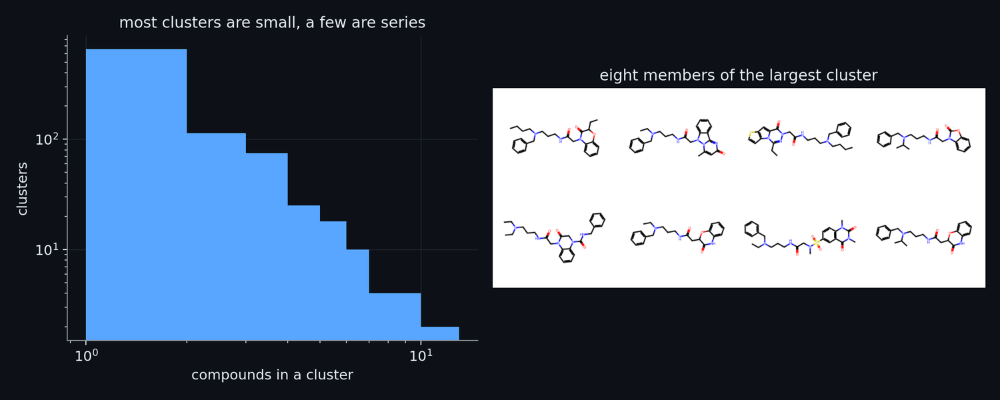

**Figure: Butina clusters of the training compounds.** Butina clustering of 1500 random training compounds: compounds closer than a Tanimoto distance of 0.65 (similarity above 0.35) to the centre of a cluster join it, the centres being chosen greedily by the number of neighbours. Left: the sizes of the 914 clusters; 656 are single compounds and the largest holds 12. Right: eight members of the largest cluster, the chemical series that a random split of the data would spread over training and test, which is why the project also evaluates by similarity to the test structures and not by random folds alone.

In [76]:
show_figure("mol_butina_clusters")

## 3.7 The feature store: all the blocks, computed once

> **Field:** Software engineering · Cheminformatics

The blocks of sections 3.1 to 3.5 are needed by hundreds of model fits (Part VI). Computing a fingerprint takes milliseconds, a descriptor table seconds, the physics block hours, so recomputing per fit would be wasteful and, worse, could produce small differences between fits. The module `cypmode/challenge/feature_store.py`
therefore keeps one table: a dictionary of *blocks*, each a function of a list of molecules that returns a table with one row per molecule, evaluated once for all 6895 compounds of both files and written to a single compressed file (`data/tdi_track/outputs/caches/feature_store.npz`, with the list of strings that it was computed for as its key: a cache built for a different list is discarded and rebuilt). A model chooses blocks by name and the store returns the columns side by side, for
the rows it asks for (`FeatureStore.matrix`).

Two rules make this safe. **A block reads no label.** Every block is a function of the structure and nothing else, so that it cannot carry an answer from a test compound's label (which no one has) or from a validation compound into a fit. The consequence is that a block can be computed once for everything, including the test structures, which is allowed because a structure is not a label. Features that do depend on labels, such as the labels of
a compound's neighbours (section 7.3), are *not* blocks: they depend on which compounds are in the training part of each fold, so the runner builds them separately inside every fold (Part VI). **Opt-in blocks are read, never computed**: the physics, pretrained-embedding and external-activity blocks come from caches written by processes of their own (some need a library that conflicts with the one used for model fitting
when both run in one process), and asking for one that has not been built is an error and not a silent recomputation. The cell checks the first promise on real compounds and counts the missing values in the stored table.

In [77]:
# The feature store's two promises, checked on the real functions: a block is a function of the structure only (computing it twice, or in a different order, gives the same numbers), and a table has
# one row per compound in the order the compounds were given. 25 compounds of the training file, default blocks.
from cypmode.challenge.feature_store import FeatureStore

sample = train["SMILES"].iloc[:25].tolist()
first = FeatureStore.build(sample)
second = FeatureStore.build(sample[::-1])
identical = {name: bool(np.array_equal(first.blocks[name], second.blocks[name][::-1])) for name in first.blocks}
print(f"{len(first.blocks)} default blocks computed on 25 compounds, and again with the compounds in the reverse order: identical for {sum(identical.values())} of {len(identical)} blocks")
matrix = first.matrix(["morgan_c2", "maccs"], rows=np.array([3, 0]))
print(f"matrix(['morgan_c2', 'maccs'], rows=[3, 0]) has shape {matrix.shape}: {first.blocks['morgan_c2'].shape[1]} + {first.blocks['maccs'].shape[1]} columns, rows in the order requested")
stored_nan = {name: int(np.isnan(store[name]).sum()) for name in store.files if name != "smiles"}
print("not-a-number entries in the stored blocks:", {k: v for k, v in stored_nan.items() if v} or "none")
n_identical, n_default_blocks = sum(identical.values()), len(identical)
nan_blocks_text = ", ".join(f"{name} ({count} entries)" for name, count in stored_nan.items() if count) or "none"

14 default blocks computed on 25 compounds, and again with the compounds in the reverse order: identical for 14 of 14 blocks
matrix(['morgan_c2', 'maccs'], rows=[3, 0]) has shape (2, 2215): 2048 + 167 columns, rows in the order requested
not-a-number entries in the stored blocks: {'physics': 344870, 'physics_b': 16955, 'pp3a4': 62910, 'pp2d6': 62910, 'st3a4': 12417, 'st2d6': 12417}


The 14 default blocks of the store give the same numbers when the compounds are computed in the reverse order (14 of 14 identical), so that a row depends on its compound and on nothing else. Blocks of the stored table with undefined (not-a-number) entries: physics (344870 entries), physics_b (16955 entries), pp3a4 (62910 entries), pp2d6 (62910 entries), st3a4 (12417 entries), st2d6 (12417 entries). The figure shows the widths of the blocks.

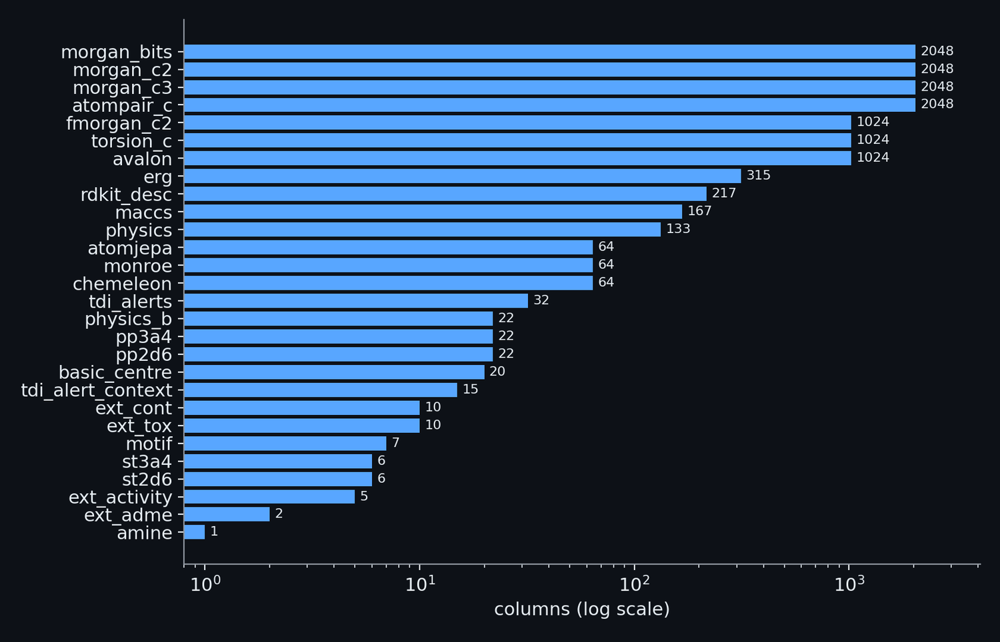

**Figure: The feature blocks and their sizes.** Width of every feature block of the feature store, in columns (log scale), for the 6895 compounds of the training and test files together. The fingerprints are the wide blocks (atompair_c has 2048 columns); the physics, alert and motif blocks are narrow but carry chemistry the fingerprints cannot. Together the 28 blocks hold 12468 columns.

In [78]:
show_figure("mol_feature_blocks")

# Part IV. Machine learning from zero

Part III turned molecules into rows of numbers. This part explains what a computer does with such a table to learn a rule, and builds, from the equations up, every kind of model that the project uses or tested: trees (4.2), boosting (4.3), forests (4.4), similarity-based models (4.5),
regression for the two assay arms (4.6), neural networks (4.7), networks on graphs and on text (4.8), a table-reading pretrained model and principal components (4.9), and the numbers by which models are judged (4.10). Every model is first written out on the project's data
in a few lines, so that no part of it is a black box, and then compared with the library that the project actually runs. The data are those of a single task, CYP3A4 on the compounds with both arms; the results of the full nested evaluation, which is the selection-corrected one, are in Parts VI and VIII.

## 4.1 Supervised learning, loss functions and the problem of generalisation

> **Field:** Machine learning · Statistics · Mathematics

**The task.** There are $n$ examples. Each is a pair $(x_i, y_i)$: $x_i$ is a row of $p$ numbers describing compound $i$ (its **features**, section 3.7) and $y_i$ is the thing to be predicted, here 1 if the compound is a time-dependent inhibitor and 0 if not (its **label**). A **model** is a function $f_\theta(x)$ with adjustable
numbers $\theta$, its **parameters**; given a compound it produces a **score**. **Supervised learning** chooses $\theta$ so that the scores agree with the labels of the examples it was shown, *and* so that they will also agree with the labels of compounds it was not shown. A **loss function** $L(y, f)$ measures how bad a score $f$ is for a compound with label $y$; the **empirical risk** is its average over the examples,
$R(\theta) = \frac1n\sum_{i=1}^{n} L\bigl(y_i, f_\theta(x_i)\bigr)$, and training means finding $\theta$ that makes $R$ small, in most methods by **gradient descent**: repeatedly moving $\theta$ a small step $\eta$ (the **learning rate**) against the gradient, $\theta \leftarrow \theta - \eta\,\nabla_\theta R$, because the gradient points to where $R$ grows fastest.

**The log-loss, from probability.** For a yes/no label it is natural to let the model say how likely the answer is yes. The score is the **logit** $z = f_\theta(x)$, any real number, and the probability is $p = \sigma(z)$ with the **sigmoid** $\sigma(z) = 1/(1 + e^{-z})$, which maps the whole real line to the interval from 0 to 1 and is 0.5 at $z = 0$. If the model's probability is $p$, the probability that it
assigns to the observed label $y \in \{0, 1\}$ is $p^{\,y}(1 - p)^{1-y}$. For $n$ independent compounds the probability of all observed labels, the **likelihood**, is the product of these, and **maximum likelihood** chooses the parameters that make it largest. Maximising a product is the same as minimising the negative of its logarithm (the logarithm is increasing, and it turns the product into a sum), which gives the
**log-loss** (also called cross-entropy):

$$L(y, z) \;=\; -\bigl[\,y\log p + (1 - y)\log(1 - p)\,\bigr], \qquad p = \sigma(z).$$

Its derivative with respect to the logit is the quantity that every method below uses. With $d\sigma/dz = \sigma(1 - \sigma) = p(1-p)$,

$$\frac{\partial L}{\partial z} \;=\; -\Bigl[\frac{y}{p} - \frac{1 - y}{1 - p}\Bigr]\,p(1 - p) \;=\; -\bigl[y(1 - p) - (1 - y)p\bigr] \;=\; p - y.$$

The gradient is simply the probability minus the label: a positive compound given $p = 0.9$ has gradient $-0.1$ (a little push upward), given $p = 0.1$ it has $-0.9$ (a strong push). The loss itself punishes confident mistakes severely, as the cell shows. For a number to be predicted, as the potency is, the usual loss is the **squared error** $L(y, f) = (y - f)^2$; the score that minimises its average over all compounds with the same features is the **conditional mean**
$\mathbb{E}[y \mid x]$, because $\frac{d}{df}\mathbb{E}[(y - f)^2 \mid x] = -2\,(\mathbb{E}[y \mid x] - f)$ vanishes at $f = \mathbb{E}[y \mid x]$. The cell checks the derivative of the log-loss by a finite difference.

In [79]:
# The working data of this part: the CYP3A4 compounds with both arms (section 2.3), their label, their shift s, and the feature tables of the store (section 3.7), rows in the order of the training file.
# Every model below is judged by 5-fold cross-validation: the compounds are divided into five parts, each part in turn is held out, the model is fitted on the other four and scored on the held-out part.
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

view_ml = training_view(train, "CYP3A4").query("population == 'both_arms'")
rows_ml = view_ml.index.to_numpy()
y_ml = view_ml["label"].astype(int).to_numpy()
shift_ml = view_ml["shift"].to_numpy()
desc_ml, counts_ml = store["rdkit_desc"][rows_ml], store["morgan_c2"][rows_ml]
set_a = np.hstack([counts_ml, desc_ml])                                        # the project's feature set "A": Morgan counts and RDKit descriptors
descriptor_names = [name for name, _ in Descriptors.descList]
folds_ml = list(StratifiedKFold(5, shuffle=True, random_state=0).split(set_a, y_ml))

def cross_validated_auc(fit_predict, features, target=None):
    """Mean and standard deviation over the five held-out parts of the AUC of fit_predict(train_x, train_y, test_x)."""
    target = y_ml if target is None else target
    scores = [roc_auc_score(y_ml[held], fit_predict(features[fit_rows], target[fit_rows], features[held])) for fit_rows, held in folds_ml]
    return float(np.mean(scores)), float(np.std(scores))

print(f"{len(y_ml)} compounds, {int(y_ml.sum())} positive ({y_ml.mean():.1%}); feature set A has {set_a.shape[1]} columns ({counts_ml.shape[1]} Morgan counts and {desc_ml.shape[1]} descriptors)")
n_ml, positives_ml, columns_a = len(y_ml), int(y_ml.sum()), set_a.shape[1]

2334 compounds, 764 positive (32.7%); feature set A has 2265 columns (2048 Morgan counts and 217 descriptors)


In [80]:
# The log-loss for one compound and its derivative with respect to the logit z, p = 1 / (1 + exp(-z)). The derivation in the text says the derivative is p - y; a finite difference checks it.
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(y, z):
    p = sigmoid(z)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

step = 1e-6
check_rows = []
for y_value in (0, 1):
    for z in (-3.0, -0.5, 0.0, 2.0):
        numeric = (log_loss(y_value, z + step) - log_loss(y_value, z - step)) / (2 * step)
        check_rows.append({"label y": y_value, "logit z": z, "probability p": sigmoid(z), "loss": log_loss(y_value, z), "derivative p - y": sigmoid(z) - y_value, "finite difference": numeric})
show_table(pd.DataFrame(check_rows), floatfmt=".5f")
worst_gap = max(abs(r["derivative p - y"] - r["finite difference"]) for r in check_rows)
penalty = {p: float(-np.log(p)) for p in (0.9, 0.5, 0.1, 0.01)}
print("loss of a positive compound given probability p:", {p: round(v, 2) for p, v in penalty.items()})

# Logistic regression by the gradient descent of the text, on two standardised descriptors of the working data (the logarithm of the partition coefficient of 3.3 and the topological polar surface area), compared with the
# fit of the library with a negligible penalty. For a weight w_j the chain rule gives dL/dw_j = (p - y) x_j, so each step moves every weight against the average of (p - y) x_j over the compounds.
from sklearn.linear_model import LogisticRegression

lr_columns = [descriptor_names.index("MolLogP"), descriptor_names.index("TPSA")]
lr_x = desc_ml[:, lr_columns].astype(float)
lr_x = (lr_x - lr_x.mean(axis=0)) / lr_x.std(axis=0)
lr_weights, lr_intercept, lr_step, lr_steps = np.zeros(2), 0.0, 0.5, 5000
for _ in range(lr_steps):
    lr_p = sigmoid(lr_intercept + lr_x @ lr_weights)
    lr_weights = lr_weights - lr_step * (lr_x.T @ (lr_p - y_ml)) / len(y_ml)
    lr_intercept = lr_intercept - lr_step * float(np.mean(lr_p - y_ml))
lr_library = LogisticRegression(C=1e6, max_iter=1000).fit(lr_x, y_ml)
lr_gap = float(max(np.abs(lr_weights - lr_library.coef_[0]).max(), abs(lr_intercept - lr_library.intercept_[0])))
lr_loss = float(np.mean(log_loss(y_ml, lr_intercept + lr_x @ lr_weights)))
lr_loss_constant = float(np.mean(log_loss(y_ml, np.log(y_ml.mean() / (1 - y_ml.mean())))))
print(f"weights {lr_weights.round(4)}, intercept {lr_intercept:.4f}; library {lr_library.coef_[0].round(4)}, {lr_library.intercept_[0]:.4f}; largest gap {lr_gap:.1e}; mean log-loss {lr_loss:.4f} against {lr_loss_constant:.4f} for the constant")

loss of a positive compound given probability p: {0.9: 0.11, 0.5: 0.69, 0.1: 2.3, 0.01: 4.61}
weights [ 0.4879 -0.0436], intercept -0.7605; library [ 0.488  -0.0437], -0.7605; largest gap 1.6e-04; mean log-loss 0.6075 against 0.6323 for the constant


| label y | logit z | probability p | loss | derivative p - y | finite difference |
| --- | --- | --- | --- | --- | --- |
| 0 | -3.00000 | 0.04743 | 0.04859 | 0.04743 | 0.04743 |
| 0 | -0.50000 | 0.37754 | 0.47408 | 0.37754 | 0.37754 |
| 0 | 0.00000 | 0.50000 | 0.69315 | 0.50000 | 0.50000 |
| 0 | 2.00000 | 0.88080 | 2.12693 | 0.88080 | 0.88080 |
| 1 | -3.00000 | 0.04743 | 3.04859 | -0.95257 | -0.95257 |
| 1 | -0.50000 | 0.37754 | 0.97408 | -0.62246 | -0.62246 |
| 1 | 0.00000 | 0.50000 | 0.69315 | -0.50000 | -0.50000 |
| 1 | 2.00000 | 0.88080 | 0.12693 | -0.11920 | -0.11920 |

The derivative $p - y$ agrees with the finite difference to within 2.6e-10, and the loss for a positive compound grows from 0.11 at $p = 0.9$ to 4.6 at $p = 0.01$: a model that is sure and wrong pays far more than a model that hedges.

**Logistic regression.** The simplest choice of the function $f_\theta$ is a weighted sum of the features, $z = b + \sum_j w_j x_j$, where $x_j$ is feature $j$ of a compound, $w_j$ its **weight** and $b$ the **intercept**. The model that turns this straight-line score into the probability $p = \sigma(z)$ is **logistic regression**, and its parameters $\theta = (b, w_1, w_2, \dots)$ are the weights and the intercept. They are found by the gradient descent above on the log-loss. The chain rule gives the gradient: since $\partial z/\partial w_j = x_j$ and $\partial L/\partial z = p - y$, the derivative with respect to a weight is $(p - y)\,x_j$, so each step moves every weight against the average of $(p - y)\,x_j$ over the compounds, and the intercept against the average of $p - y$. A **penalty** can be added to the loss to keep the weights small (the L1 and L2 penalties of 8.2), and the constant `C` of the library is the strength of the loss against the penalty. The cell fits the model by the loop of the text on two standardised descriptors, the logarithm of the partition coefficient (3.3) and the polar surface area, with 5000 steps of size 0.5: the weights are 0.488 and -0.044 and the intercept -0.761, and the library, given the same data with a negligible penalty, finds the same numbers to within 2e-04. The mean log-loss falls from 0.632 for a model that gives every compound the base rate to 0.607. The project uses logistic regression to blend the scores of its models (8.2), to read off in 4.10 how far a model's probabilities can be trusted, and in several smaller tests.

**Fitting is not the goal; predicting new compounds is.** A model with enough freedom can reproduce the labels of the training compounds exactly and still know nothing about new ones, as a student who memorised the answers of last year's exam. The error on *new* data has three parts, which the **bias-variance decomposition** separates. Suppose the truth is
$y = g(x) + \varepsilon$, where $g$ is the true rule and the noise $\varepsilon$ has mean 0 and variance $\sigma^2$, and a model $\hat f$ is fitted to a random training set (so that $\hat f$ is itself random). The expected squared error at a point $x$, over both the training set and the noise of the new compound, is, after adding and subtracting $\mathbb{E}[\hat f(x)]$ and $g(x)$ and noting that the cross
terms vanish because the noise and the training set are independent and have mean zero,

$$\mathbb{E}\bigl[(y - \hat f(x))^2\bigr] \;=\; \underbrace{\bigl(g(x) - \mathbb{E}[\hat f(x)]\bigr)^2}_{\text{bias}^2} \;+\; \underbrace{\mathbb{E}\bigl[(\hat f(x) - \mathbb{E}[\hat f(x)])^2\bigr]}_{\text{variance}} \;+\; \underbrace{\sigma^2}_{\text{noise}}.$$

**Bias** is the systematic error: how far the model's average prediction, over all possible training sets, is from the truth; a model that is too simple (a straight line for a curve) has high bias. **Variance** is how much the prediction changes when the training set changes; a model that is too flexible follows the noise of each particular training set and has high variance. The **noise** cannot be removed by any model. More flexibility lowers the bias and raises the variance, and
the best model is in between: the **bias-variance trade-off**. The cell measures all three on a case in which the truth is known.

In [81]:
# Bias and variance measured. The truth is g(x) = sin(2 pi x); each training set has 30 points with noise of standard deviation 0.3; a polynomial of a given degree is fitted to 400 independent training
# sets and evaluated on 60 fixed points. Bias squared is how far the average prediction is from the truth, variance is how much the predictions scatter around their own average.
rng = np.random.default_rng(11)
noise_sd, n_points, repetitions = 0.3, 30, 400
grid_x = np.linspace(0.02, 0.98, 60)
truth = np.sin(2 * np.pi * grid_x)
bv_rows = []
for degree in (1, 3, 5, 7):
    predictions = np.empty((repetitions, grid_x.size))
    train_error, test_error = [], []
    for r in range(repetitions):
        x = rng.uniform(0, 1, n_points)
        y = np.sin(2 * np.pi * x) + rng.normal(0, noise_sd, n_points)
        fit = np.polynomial.Polynomial.fit(x, y, degree)
        predictions[r] = fit(grid_x)
        train_error.append(np.mean((y - fit(x)) ** 2))
        test_error.append(np.mean((truth + rng.normal(0, noise_sd, grid_x.size) - predictions[r]) ** 2))
    bias_squared = float(np.mean((predictions.mean(axis=0) - truth) ** 2))
    variance = float(np.mean(predictions.var(axis=0)))
    bv_rows.append({"degree": degree, "error on the training points": float(np.mean(train_error)), "bias squared": bias_squared, "variance": variance, "noise": noise_sd**2,
                    "bias squared + variance + noise": bias_squared + variance + noise_sd**2, "measured error on new points": float(np.mean(test_error))})
show_table(pd.DataFrame(bv_rows), floatfmt=".3f")
decomposition_gap = max(abs(r["bias squared + variance + noise"] - r["measured error on new points"]) for r in bv_rows)
best_degree = min(bv_rows, key=lambda r: r["measured error on new points"])["degree"]

| degree | error on the training points | bias squared | variance | noise | bias squared + variance + noise | measured error on new points |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.267 | 0.180 | 0.021 | 0.090 | 0.290 | 0.293 |
| 3 | 0.082 | 0.004 | 0.017 | 0.090 | 0.111 | 0.112 |
| 5 | 0.073 | 0.000 | 0.048 | 0.090 | 0.138 | 0.136 |
| 7 | 0.066 | 0.003 | 0.941 | 0.090 | 1.033 | 1.033 |

The error on the training points falls steadily with the degree of the polynomial, while the error on new points is lowest at degree 3 and rises again: low degrees are dominated by bias, high degrees by variance. The three parts add up to the measured error of new points to within 0.002, the sampling error of the simulation. The practical lesson is that the score of a model on the data it was fitted on is
not a measure of anything, and every number in this notebook that is meant as an estimate of performance is computed on compounds that the model did not see (Part VI).

**Held-out data and cross-validation.** The way to measure how a model will do on compounds it has not seen is to keep some compounds out of the fitting and score the model on them. **Cross-validation** does this for every compound in turn: the $n$ compounds are divided at random into $K$ parts, the **folds**; for each fold in turn the model is fitted on the other $K - 1$ folds and scored on the fold that it did not see; the $K$ scores are averaged, and their spread says how far the estimate itself can be trusted. The folds of this part are made so that each holds about the same share of positive compounds (**stratified** folds), with $K = 5$, so that each held-out part has about 467 of the 2334 compounds of the working data. One caution belongs here and is the subject of Part VI: a number that has been used to *choose* between models, settings or thresholds is no longer a reliable estimate, because the choice looked at it, and the remedy is to nest one cross-validation inside another (**nested cross-validation**).

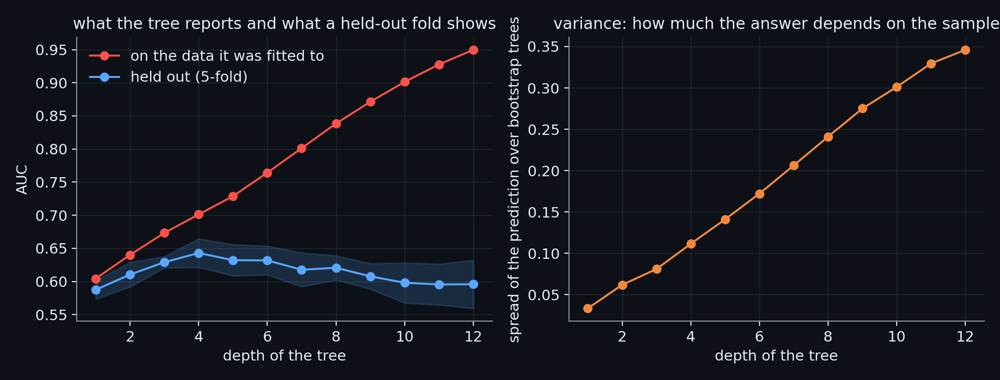

**Figure: Bias and variance: the depth of a tree on real compounds.** A decision tree of growing depth on 2334 real CYP3A4 compounds described by eight descriptors. Left: the AUC on the compounds the tree was fitted to (it keeps rising towards 0.95) and the five-fold cross-validated AUC (it peaks at depth 4 with 0.643 and then falls to 0.596): the gap between the two is the optimism of a model that has memorised its data. Right: the variance, measured as the mean standard deviation of the predictions of 20 trees fitted to bootstrap resamples of the same training fold, for the same held-out compounds; it grows from 0.033 at depth 1 to 0.346 at depth 12. A shallow tree is stable and too simple (bias); a deep tree fits the training data and changes with every sample (variance). Forests average the variance away and boosting reduces the bias one small tree at a time, which is what the next two figures show.

In [82]:
show_figure("ml_bias_variance")

## 4.2 Decision trees: impurity, and the search for the best question

> **Field:** Machine learning

A **decision tree** is a flowchart of yes/no questions about the features: "is the logP above 3.1?", then, on the "yes" branch, "is the molecular weight above 420?", and so on. A compound follows the answers from the top (the **root**) down to a **leaf**, and the leaf says what to predict: the fraction of positive training compounds that arrived there. A tree is built from the top, one question at a time, by the **greedy** rule: at every node pick the
question that makes the two resulting groups as pure as possible, and then do the same in each group.

**Impurity.** For a group in which a fraction $p$ of the compounds are positive, a measure of impurity should be 0 when $p = 0$ or $p = 1$ (a pure group) and largest at $p = 1/2$. Two are used. The **Gini impurity** is the probability that two compounds drawn at random from the group (with replacement) belong to different classes, which for two classes is
$G = 2p(1 - p) = 1 - p^2 - (1-p)^2$; the **entropy** is $H = -p\log_2 p - (1-p)\log_2(1-p)$, the number of bits of information needed to say which class a randomly drawn compound belongs to. They behave alike, and the project's trees use the Gini impurity.

**The split search.** A question is a feature $j$ and a threshold $t$: the compounds with $x_j \le t$ go left, the others right. With $n_L$ and $n_R$ compounds in the two parts ($n = n_L + n_R$), the quality of the question is the **impurity decrease** $\Delta$

$$\Delta \;=\; G(\text{parent}) \;-\; \frac{n_L}{n}\,G(\text{left}) \;-\; \frac{n_R}{n}\,G(\text{right}),$$

the impurity of the group before the split minus the average impurity after it, weighted by size. Only the thresholds between two consecutive different values of a feature need to be tried, and after sorting the compounds by that feature the counts of positives on the left of every position are cumulative sums, so all thresholds of one feature cost one pass. The cell does this for all 217 descriptors and compares it with
scikit-learn's tree of depth 1.

In [83]:
# The split search written out. For every descriptor, sort the compounds by its value, and for every position between two different values compute the Gini impurity of the two parts that the split makes,
# with cumulative sums so that all positions cost one pass. The best split of all 217 descriptors is compared with the one scikit-learn's tree of depth 1 chooses.
from sklearn.tree import DecisionTreeClassifier

def gini(positive, total):
    p = positive / total
    return 2 * p * (1 - p)                                                      # 1 - p^2 - (1 - p)^2 for two classes

def best_stump(features, target):
    n = len(target)
    parent = gini(target.sum(), n)
    best = {"gain": -1.0}
    for j in range(features.shape[1]):
        order = np.argsort(features[:, j], kind="stable")
        values, labels = features[order, j], target[order]
        left_n = np.arange(1, n)
        left_positive = np.cumsum(labels)[:-1]
        between = values[1:] > values[:-1]                                      # a split is only possible between two different values
        if not between.any():
            continue
        right_n, right_positive = n - left_n, labels.sum() - left_positive
        gain = np.where(between, parent - (left_n * gini(left_positive, left_n) + right_n * gini(right_positive, right_n)) / n, -1.0)
        k = int(gain.argmax())
        if gain[k] > best["gain"]:
            best = {"gain": float(gain[k]), "feature": j, "threshold": float((values[k] + values[k + 1]) / 2), "left_n": int(left_n[k]), "left_rate": float(left_positive[k] / left_n[k]),
                    "right_n": int(right_n[k]), "right_rate": float(right_positive[k] / right_n[k])}
    return best

mine = best_stump(desc_ml, y_ml)
library = DecisionTreeClassifier(max_depth=1, criterion="gini", random_state=0).fit(desc_ml, y_ml)
node = library.tree_
library_gain = node.impurity[0] - (node.n_node_samples[1] * node.impurity[1] + node.n_node_samples[2] * node.impurity[2]) / node.n_node_samples[0]
stump_rows = [{"": "split search written out here", "descriptor": descriptor_names[mine["feature"]], "threshold": mine["threshold"], "impurity decrease": mine["gain"], "share positive, below": mine["left_rate"], "share positive, above": mine["right_rate"]},
              {"": "scikit-learn, depth 1", "descriptor": descriptor_names[node.feature[0]], "threshold": float(node.threshold[0]), "impurity decrease": float(library_gain),
               "share positive, below": float(node.value[1][0][1] / node.value[1][0].sum()), "share positive, above": float(node.value[2][0][1] / node.value[2][0].sum())}]
show_table(pd.DataFrame(stump_rows), floatfmt=".4f")
parent_gini = gini(y_ml.sum(), len(y_ml))
same_split = mine["feature"] == node.feature[0] and abs(mine["threshold"] - node.threshold[0]) < 1e-6
print(f"impurity of the whole set (Gini) {parent_gini:.4f}; the two searches choose the same split: {same_split}")

impurity of the whole set (Gini) 0.4404; the two searches choose the same split: True


|  | descriptor | threshold | impurity decrease | share positive, below | share positive, above |
| --- | --- | --- | --- | --- | --- |
| split search written out here | MolLogP | 2.1121 | 0.0233 | 0.1609 | 0.3972 |
| scikit-learn, depth 1 | MolLogP | 2.1121 | 0.0233 | 0.1609 | 0.3972 |

The search chooses the descriptor **MolLogP** at the threshold 2.112, with an impurity decrease of 0.0233, and the library makes the same choice (True). Below the threshold 16% of the compounds are positive, above it 40%, against 33% in the whole set.

**What a tree does when it is allowed to grow.** With one question the tree is very simple (high bias). Every further level can separate the training compounds better, and with no limit a tree separates them perfectly, a leaf for each compound or small group, which is variance at its worst. The next cell shows both effects and a third: the first question of a tree is not stable. Trees fitted to slightly different samples of the data choose different roots.

In [84]:
# How a tree behaves as it is allowed to grow, and how stable its first question is. Left: the AUC on the part a tree was fitted on and on the held-out part, by depth. Right: the descriptor chosen for the
# root of a tree of depth 2 in 60 bootstrap samples of the data (a bootstrap sample is drawn with replacement, so about two thirds of the compounds appear in it), and the three questions at the top.
depth_rows = []
for depth in (1, 2, 3, 5, 8, None):
    fitted, held_scores = [], []
    for fit_rows, held in folds_ml:
        tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(desc_ml[fit_rows], y_ml[fit_rows])
        fitted.append(roc_auc_score(y_ml[fit_rows], tree.predict_proba(desc_ml[fit_rows])[:, 1]))
        held_scores.append(roc_auc_score(y_ml[held], tree.predict_proba(desc_ml[held])[:, 1]))
    depth_rows.append({"depth of the tree": "no limit" if depth is None else depth, "AUC on the compounds it was fitted on": float(np.mean(fitted)), "AUC on held-out compounds": float(np.mean(held_scores))})
show_table(pd.DataFrame(depth_rows), floatfmt=".3f")

rng = np.random.default_rng(5)
roots, shapes = [], []
for _ in range(60):
    sample = rng.integers(0, len(y_ml), len(y_ml))
    nodes = DecisionTreeClassifier(max_depth=2, random_state=0).fit(desc_ml[sample], y_ml[sample]).tree_
    roots.append(descriptor_names[nodes.feature[0]])
    shapes.append(tuple(descriptor_names[nodes.feature[k]] if nodes.feature[k] >= 0 else "leaf" for k in (0, 1, 4)))     # the questions at the root and at its two children
root_counts = pd.Series(roots).value_counts()
shape_counts = pd.Series([" / ".join(s) for s in shapes]).value_counts()
print("the descriptor at the root of a depth-2 tree in 60 bootstrap samples:", {k: int(v) for k, v in root_counts.head(4).items()})
print("the three questions (root, left child, right child) in the same 60 trees:", len(shape_counts), "different combinations; the most frequent, in", int(shape_counts.iloc[0]), "trees:", shape_counts.index[0])
fitted_unlimited, held_unlimited = depth_rows[-1]["AUC on the compounds it was fitted on"], depth_rows[-1]["AUC on held-out compounds"]
best_depth_row = max(depth_rows, key=lambda r: r["AUC on held-out compounds"])
n_distinct_roots, root_top_share = len(root_counts), float(root_counts.iloc[0] / root_counts.sum())
n_shapes, shape_top_share = len(shape_counts), float(shape_counts.iloc[0] / shape_counts.sum())

the descriptor at the root of a depth-2 tree in 60 bootstrap samples: {'MolLogP': 42, 'MolMR': 14, 'Chi1n': 3, 'Chi2n': 1}
the three questions (root, left child, right child) in the same 60 trees: 52 different combinations; the most frequent, in 4 trees: MolMR / MolLogP / MolLogP


| depth of the tree | AUC on the compounds it was fitted on | AUC on held-out compounds |
| --- | --- | --- |
| 1 | 0.612 | 0.582 |
| 2 | 0.670 | 0.639 |
| 3 | 0.701 | 0.640 |
| 5 | 0.776 | 0.652 |
| 8 | 0.901 | 0.602 |
| no limit | 1.000 | 0.583 |

A tree without a limit reaches an AUC of 1.000 on the compounds it was fitted on and 0.583 on held-out ones: the first number is the memorising student, the second the real one. The best depth among those tried is 5, with 0.652. The root of a tree of depth 2 is one of 4 descriptors over 60 **bootstrap samples** (each is drawn with replacement from the compounds, as section 4.4 explains), the most frequent in 70% of them, and the three questions at the top of the tree take 52 different combinations, the most frequent in only 7% of the trees: a
single tree is an unstable model, the more so the deeper it is. Both faults, the memorising and the instability, have one remedy that all the strong models below use: do not trust one tree but combine many. They differ in how the trees are made and combined. The figure shows a tree fitted to real compounds, with the question and the composition of each node.

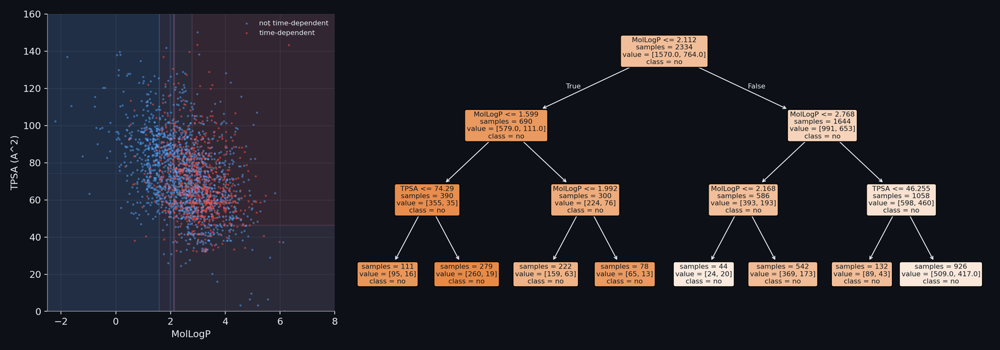

**Figure: A decision tree on real compounds.** A decision tree of depth 3 (at least 40 compounds in a leaf) fitted to the 2334 labelled CYP3A4 compounds using only two descriptors, the octanol-water partition coefficient (MolLogP) and the polar surface area (TPSA). Left: the plane cut into the 8 rectangles the tree defines; a rectangle is shaded from blue (few time-dependent inhibitors in its leaf) to red (many) by the share of positives in its leaf, which is the probability the tree gives to every compound that falls in it; no leaf has a majority of positives, so a hard yes/no tree would answer no everywhere. Right: the same tree as questions: each box asks whether one descriptor is below a threshold. Five-fold cross-validated AUC of this tree: 0.623. A tree is easy to read and unstable (a slightly different sample gives different cuts), which is why the project uses forests and boosted trees of many of them.

In [85]:
show_figure("ml_decision_tree")

## 4.3 Gradient boosting: many small trees, each correcting the others

> **Field:** Machine learning · Mathematics (optimisation)

**The idea.** Build the model in stages, each stage a small tree that repairs what the previous stages still get wrong. Start with a constant (the prior log-odds of the positive class) and let $F_{m-1}(x)$ be the logit after $m - 1$ trees; the new tree $f_m$ is added with a small weight, $F_m = F_{m-1} + \eta\,f_m$, where $\eta$ is the **learning rate**, usually 0.01 to 0.3: a tree is only allowed to correct a part of the error, so that no
single tree can dominate. Friedman (2001) saw that this is gradient descent, not on parameters but on the function itself. The loss of the whole data as a function of the $n$ scores $F(x_1), \dots, F(x_n)$ has the gradient $g_i = \partial L(y_i, F)/\partial F$ at $F_{m-1}$, and the best small step downhill is to move every score by a multiple of $-g_i$; since a step that is defined only at the training compounds is useless for new ones, a tree is fitted to $-g_i$ and
so generalises the step to every compound. For the log-loss $-g_i = y_i - p_i$ is the residual of the probability, the part of the label that is not yet explained.

**The second-order version used by LightGBM.** XGBoost (Chen and Guestrin, 2016) and LightGBM (Ke and co-workers, 2017) do not fit the residual by least squares; they take, as Newton's method does, the curvature into account. At round $m$ the objective for a new tree $f$ with $T$ leaves and leaf values $w_1, \dots, w_T$ is the loss of the data plus a penalty for complexity,
$\sum_i L\bigl(y_i, F_{m-1}(x_i) + f(x_i)\bigr) + \gamma T + \tfrac12 \lambda \sum_j w_j^2$, where $\gamma$ and $\lambda$ are non-negative constants that punish trees with many leaves and large leaf values. The loss is approximated by the first terms of its Taylor series in $f$,
$L(y_i, F + f) \approx L(y_i, F) + g_i f + \tfrac12 h_i f^2$, where $g_i = p_i - y_i$ is the gradient and $h_i = \partial^2 L/\partial F^2 = p_i(1 - p_i)$ the curvature of the log-loss (the derivative of $p - y$ with respect to $z$ is $p(1-p)$). A tree assigns every compound to one leaf $j$ and gives it the value $w_j$ of that leaf. Collect the compounds of leaf $j$ in a set $I_j$ and write
$G_j = \sum_{i \in I_j} g_i$ and $H_j = \sum_{i \in I_j} h_i$; dropping the terms that do not depend on the tree, the objective becomes a sum over leaves,

$$\sum_{j=1}^{T}\Bigl[\,G_j w_j + \tfrac12 (H_j + \lambda)\,w_j^2\Bigr] + \gamma T .$$

Each bracket is a parabola in $w_j$. Setting its derivative to zero gives the best **leaf value** and the value of the objective that it reaches,

$$w_j^{*} = -\frac{G_j}{H_j + \lambda}, \qquad \text{objective}^{*} = -\frac12\sum_{j=1}^{T}\frac{G_j^2}{H_j + \lambda} + \gamma T .$$

This is a score for a whole tree, so splitting a leaf into a left part (index $L$) and a right part ($R$) can be judged by how much it lowers the objective, the **gain**,

$$\text{gain} \;=\; \frac12\Bigl[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\Bigr] - \gamma ,$$

and a split is made only if the gain is positive. The **split search** is then exactly that of section 4.2 with a different quality measure, computed from sums of $g$ and $h$ that can be accumulated in one pass. LightGBM makes this fast with two ideas. It **bins** every feature into at most 255 values once, so that the sums of $g$ and $h$ are accumulated per bin (a *histogram*) and the best threshold is found among the bin edges instead of among all values, and it grows the tree **leaf-wise**: instead of splitting all nodes of one level, it always splits the leaf with the largest gain, until the allowed number of leaves is
reached, which gives a lopsided tree that reduces the loss faster than a balanced one. The following cell writes the whole algorithm out, in about forty lines, with the equations above, on the descriptors of the 2334 compounds.

In [86]:
# Second-order gradient boosting written out in about forty lines, with trees built from histograms of the gradient statistics. Each round computes, for every compound, the gradient g = p - y and the
# curvature h = p (1 - p) of the log-loss at the current logit; grows a tree of depth 3 by the gain formula of the text; sets each leaf to -G / (H + lambda); and adds eta times the leaf values to the logits.
class NewtonBooster:
    def __init__(self, rounds=100, eta=0.1, depth=3, lam=1.0, gamma=0.0, min_hessian=1.0, bins=32):
        self.rounds, self.eta, self.depth, self.lam, self.gamma, self.min_hessian, self.bins = rounds, eta, depth, lam, gamma, min_hessian, bins

    def _codes(self, X):
        return np.column_stack([np.searchsorted(self.edges[j], X[:, j], side="right") for j in range(X.shape[1])]).astype(np.int64)

    def _grow(self, codes, g, h, idx, depth):
        G, H = g[idx].sum(), h[idx].sum()
        leaf = -G / (H + self.lam)
        if depth == 0 or len(idx) < 2:
            return leaf
        n_features, width = codes.shape[1], self.bins
        flat = (codes[idx] + (np.arange(n_features) * width)[None, :]).ravel()
        g_hist = np.bincount(flat, weights=np.repeat(g[idx], n_features), minlength=n_features * width).reshape(n_features, width)
        h_hist = np.bincount(flat, weights=np.repeat(h[idx], n_features), minlength=n_features * width).reshape(n_features, width)
        g_left, h_left = np.cumsum(g_hist, axis=1)[:, :-1], np.cumsum(h_hist, axis=1)[:, :-1]
        g_right, h_right = G - g_left, H - h_left
        with np.errstate(divide="ignore", invalid="ignore"):                       # an empty side with lambda = 0 divides 0 by 0: such a split has no gain
            gain = 0.5 * (g_left**2 / (h_left + self.lam) + g_right**2 / (h_right + self.lam) - G**2 / (H + self.lam)) - self.gamma
        gain[np.isnan(gain) | (h_left < self.min_hessian) | (h_right < self.min_hessian)] = -np.inf
        f, b = np.unravel_index(np.argmax(gain), gain.shape)
        if not np.isfinite(gain[f, b]) or gain[f, b] <= 0:
            return leaf
        goes_left = codes[idx, f] <= b
        return (f, b, self._grow(codes, g, h, idx[goes_left], depth - 1), self._grow(codes, g, h, idx[~goes_left], depth - 1), float(gain[f, b]))

    def _apply(self, node, codes, idx, out):
        if not isinstance(node, tuple):
            out[idx] = node
            return
        f, b, left, right, _ = node
        goes_left = codes[idx, f] <= b
        self._apply(left, codes, idx[goes_left], out)
        self._apply(right, codes, idx[~goes_left], out)

    def _tree_values(self, tree, codes):
        out = np.zeros(len(codes))
        self._apply(tree, codes, np.arange(len(codes)), out)
        return out

    def fit(self, X, y, X_watch=None, y_watch=None, watch_every=10):
        self.edges = [np.unique(np.quantile(X[:, j], np.linspace(0, 1, self.bins + 1)[1:-1])) for j in range(X.shape[1])]
        codes = self._codes(X)
        watch_codes = self._codes(X_watch) if X_watch is not None else None
        rate = y.mean()
        self.base = float(np.log(rate / (1 - rate)))
        logit, watch_logit = np.full(len(y), self.base), (np.full(len(X_watch), self.base) if X_watch is not None else None)
        self.trees, self.history = [], []
        for round_number in range(1, self.rounds + 1):
            p = sigmoid(logit)
            tree = self._grow(codes, p - y, p * (1 - p), np.arange(len(y)), self.depth)
            self.trees.append(tree)
            logit = logit + self.eta * self._tree_values(tree, codes)
            if X_watch is not None:
                watch_logit = watch_logit + self.eta * self._tree_values(tree, watch_codes)
                if round_number % watch_every == 0:
                    self.history.append({"round": round_number, "AUC on the fitted compounds": roc_auc_score(y, logit), "AUC on the watched compounds": roc_auc_score(y_watch, watch_logit)})
        return self

    def decision_function(self, X):
        codes = self._codes(X)
        return self.base + self.eta * sum(self._tree_values(tree, codes) for tree in self.trees)

# Round one checked against the theory: the second-order objective predicts how much one tree of depth 1 lowers the summed log-loss (it is the gain of the best split); the true change is measured.
p0 = np.full(len(y_ml), y_ml.mean())
g0, h0 = p0 - y_ml, p0 * (1 - p0)
base_logit = np.log(p0[0] / (1 - p0[0]))
one = NewtonBooster(rounds=1, eta=1.0, depth=1, lam=0.0, min_hessian=1.0)
one.fit(desc_ml, y_ml)
predicted_decrease = one.trees[0][4]
after = one.decision_function(desc_ml)
actual_decrease = float(log_loss(y_ml, np.full(len(y_ml), base_logit)).sum() - log_loss(y_ml, after).sum())
print(f"first round, one split, lambda = 0: the formula predicts a decrease of {predicted_decrease:.2f} in the summed log-loss; the true decrease is {actual_decrease:.2f} (from {log_loss(y_ml, np.full(len(y_ml), base_logit)).sum():.1f})")

first round, one split, lambda = 0: the formula predicts a decrease of 58.27 in the summed log-loss; the true decrease is 61.89 (from 1475.7)


The formula predicts a decrease of 58.27 in the summed log-loss for the best single split, and the true decrease is 61.89; the two differ because the formula rests on a second-order approximation of the loss, which is good for a small step and not exact for a large one. Next the written-out booster is compared with LightGBM at matching settings in the same five folds, and the effect of the learning rate is shown.

| model | mean AUC over the five held-out parts | standard deviation | seconds |
| --- | --- | --- | --- |
| the booster written out above (100 rounds, eta 0.1, depth 3) | 0.736 | 0.014 | 2.939 |
| LightGBM with matching settings | 0.733 | 0.012 | 0.350 |

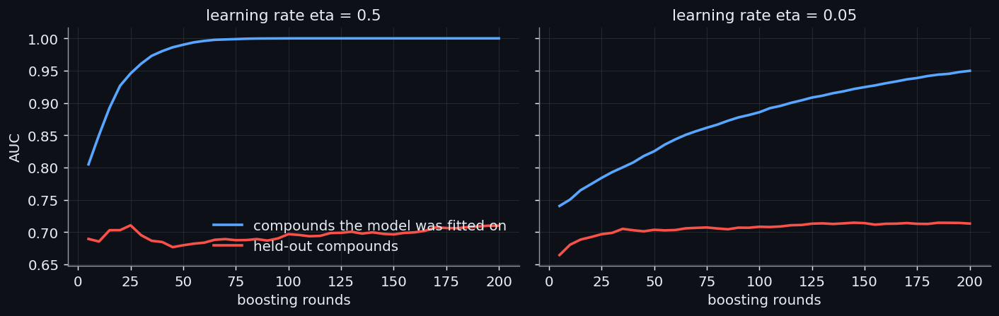

In [87]:
# The written-out booster against LightGBM with matching settings, in the same five folds, and the AUC of the booster on the fitted and on the held-out compounds as rounds are added (first fold), for two
# values of the learning rate eta.
from lightgbm import LGBMClassifier

def boost_fit_predict(rounds, eta):
    return lambda train_x, train_y, test_x: NewtonBooster(rounds=rounds, eta=eta, depth=3, lam=1.0).fit(train_x, train_y).decision_function(test_x)

def lightgbm_fit_predict(train_x, train_y, test_x):
    model = LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=8, max_depth=3, reg_lambda=1.0, min_child_samples=5, n_jobs=2, verbose=-1, random_state=0)
    return model.fit(train_x, train_y).predict_proba(test_x)[:, 1]

import time
timing = {}
compare = []
for name, function in (("the booster written out above (100 rounds, eta 0.1, depth 3)", boost_fit_predict(100, 0.1)), ("LightGBM with matching settings", lightgbm_fit_predict)):
    started = time.time()
    mean_auc, sd_auc = cross_validated_auc(function, desc_ml)
    compare.append({"model": name, "mean AUC over the five held-out parts": mean_auc, "standard deviation": sd_auc, "seconds": time.time() - started})
show_table(pd.DataFrame(compare), floatfmt=".3f")

fit_rows, held = folds_ml[0]
curves = {}
for eta in (0.5, 0.05):
    booster = NewtonBooster(rounds=200, eta=eta, depth=3, lam=1.0).fit(desc_ml[fit_rows], y_ml[fit_rows], desc_ml[held], y_ml[held], watch_every=5)
    curves[eta] = pd.DataFrame(booster.history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for axis, eta in zip(axes, curves):
    axis.plot(curves[eta]["round"], curves[eta]["AUC on the fitted compounds"], color=theme["blue"], lw=2, label="compounds the model was fitted on")
    axis.plot(curves[eta]["round"], curves[eta]["AUC on the watched compounds"], color=theme["red"], lw=2, label="held-out compounds")
    axis.set(xlabel="boosting rounds", title=f"learning rate eta = {eta}")
    tidy(axis, theme)
axes[0].set(ylabel="AUC")
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
booster_auc, lightgbm_auc = compare[0]["mean AUC over the five held-out parts"], compare[1]["mean AUC over the five held-out parts"]
best_round = {eta: int(curves[eta].loc[curves[eta]["AUC on the watched compounds"].idxmax(), "round"]) for eta in curves}
final_gap = {eta: float(curves[eta]["AUC on the fitted compounds"].iloc[-1] - curves[eta]["AUC on the watched compounds"].iloc[-1]) for eta in curves}

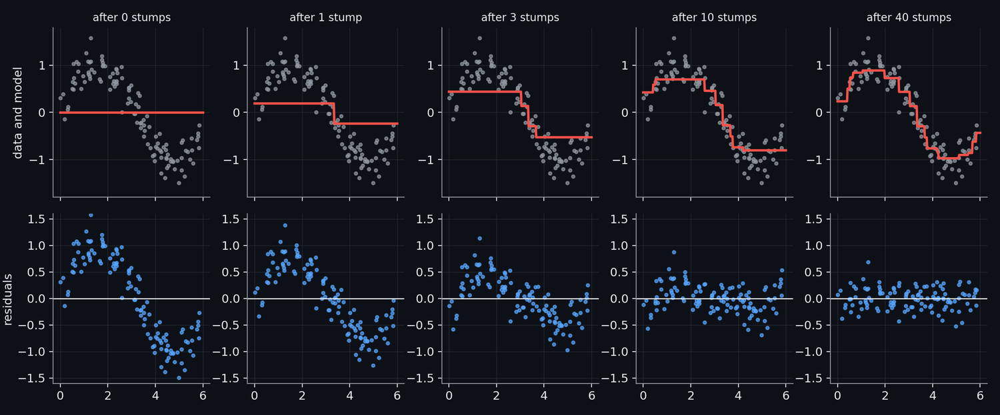

**Figure: Gradient boosting, stage by stage.** Gradient boosting on a toy regression (120 noisy points of sin x, drawn with a fixed seed; not project data). Stage 0 is the mean. Each stage fits a one-split tree (a stump) to the residuals r_i = y_i - F(x_i), which are the negative gradient of the squared error, and adds a fraction nu = 0.3 of it: F_m = F_(m-1) + nu h_m. Top row: the model after 0, 1, 3, 10, 40 stumps; bottom row: the residuals it leaves. Mean squared error 0.628 at stage 0, 0.068 after 10 stumps, 0.040 after 40; the noise floor of the data is about 0.062, which more stumps cannot go below without fitting the noise.

In [88]:
show_figure("ml_boosting_stages")

The written-out booster reaches a mean AUC of 0.736 against 0.733 for LightGBM with the same settings, which differ in details that the forty lines leave out (the way LightGBM grows leaf-wise and bins its features, and its handling of small leaves); the two agree to within the spread between folds. On the first fold the held-out AUC is highest after 25 rounds for $\eta = 0.5$ and after 145 for $\eta = 0.05$,
and by round 200 the gap between the AUC on the fitted and on the held-out compounds is 0.29 and 0.24: a large learning rate fits the training data quickly and begins to memorise it sooner, a small one needs more rounds and fits more gently. The number of rounds and the learning rate are therefore chosen together. The figure above follows a boosted model stage by stage on a real task.

**The settings of the project.** The project's candidates use LightGBM with two presets (`LGBM_PRESETS` in `cypmode/challenge/nested_runners.py`): a **deep** one (300 trees, learning rate 0.04, up to 31 leaves per tree) and a **shallow** one (600 trees, learning rate 0.02, up to 8 leaves, and an $L_2$ penalty $\lambda = 5$ on the leaf values), each with **row subsampling** (every tree sees 70 to 80 % of the compounds, drawn without replacement every round) and **column subsampling** (every tree sees 20 to 30 % of the columns), and a minimum number of compounds in a leaf. Subsampling is another
source of randomness that decorrelates the trees (section 4.4) and speeds up the fit. The cell prints the presets and compares them on feature set A.

In [89]:
# The two LightGBM settings that the project's grid uses (nested_runners.LGBM_PRESETS), and what they do on feature set A in the five folds.
from cypmode.challenge.nested_runners import LGBM_PRESETS

preset_table = pd.DataFrame({name: pd.Series({k: f"{v:g}" for k, v in params.items()}) for name, params in LGBM_PRESETS.items()}).fillna("default").reset_index().rename(columns={"index": "setting"})
show_table(preset_table)
preset_rows = []
for name, params in LGBM_PRESETS.items():
    started = time.time()
    mean_auc, sd_auc = cross_validated_auc(lambda a, b, c, params=params: LGBMClassifier(verbose=-1, n_jobs=2, random_state=0, **params).fit(a, b).predict_proba(c)[:, 1], set_a)
    preset_rows.append({"setting": name, "mean AUC (5 folds)": mean_auc, "standard deviation": sd_auc, "seconds": time.time() - started})
show_table(pd.DataFrame(preset_rows), floatfmt=".3f")

| setting | deep | shallow |
| --- | --- | --- |
| colsample_bytree | 0.3 | 0.2 |
| learning_rate | 0.04 | 0.02 |
| min_child_samples | 10 | 20 |
| n_estimators | 300 | 600 |
| num_leaves | 31 | 8 |
| reg_lambda | default | 5 |
| subsample | 0.8 | 0.7 |
| subsample_freq | 1 | 1 |

| setting | mean AUC (5 folds) | standard deviation | seconds |
| --- | --- | --- | --- |
| deep | 0.752 | 0.012 | 4.701 |
| shallow | 0.754 | 0.012 | 3.335 |

## 4.4 Random forests and extremely randomised trees: averaging many trees

> **Field:** Machine learning · Statistics

Boosting builds trees in sequence, each depending on the earlier ones. A different way to use many trees is to build them independently and average their scores. Averaging helps because it reduces variance. Suppose $B$ estimates $X_1, \dots, X_B$ (written $X_b$, with $b$ running from 1 to $B$) of the same quantity each have variance $\sigma^2$, and every pair has the same correlation $\rho$. The variance of their average is

$$\mathrm{Var}\Bigl(\frac1B\sum_{b=1}^{B} X_b\Bigr) \;=\; \frac{1}{B^2}\Bigl[B\sigma^2 + B(B-1)\rho\sigma^2\Bigr] \;=\; \rho\,\sigma^2 + \frac{1 - \rho}{B}\,\sigma^2 ,$$

where the sum of variances gives $B\sigma^2$ and the $B(B-1)$ ordered pairs give the covariances $\rho\sigma^2$. When the estimates are independent ($\rho = 0$) the variance falls as $1/B$; when they are correlated, adding more of them stops helping beyond the floor $\rho\sigma^2$. So the trees should be **as different from one another as possible**, while each stays a good model. **Bagging** (bootstrap aggregation, Breiman, 1996) makes them differ by training each tree on a **bootstrap sample**:
$n$ compounds drawn with replacement from the $n$ available, so that a given compound is missing from a sample with probability $(1 - 1/n)^n \to e^{-1} \approx 0.37$, and every sample holds about 63 % of the distinct compounds (the compounds left out, the **out-of-bag** ones, give a free estimate of the error). The **random forest** (Breiman, 2001) adds a second source of difference: at every split a tree may consider only a random subset of the
columns, so that one dominant feature cannot make the first question of every tree the same. **Extremely randomised trees** (Geurts, Ernst and Wehenkel, 2006) go further: the threshold of every candidate column is drawn at random instead of being searched, and the best of those random questions is used, which makes the trees even less alike and the fitting faster, at the price of a little more bias. The cell checks the variance formula by simulation and the share of compounds in a bootstrap sample.

In [90]:
# The variance of an average of B correlated estimates, simulated and from the formula rho sigma^2 + (1 - rho) sigma^2 / B, for sigma = 1: B estimates with a common pairwise correlation rho.
rng = np.random.default_rng(3)
var_rows = []
for rho in (0.0, 0.3, 0.7):
    for B in (1, 10, 100):
        shared = rng.normal(size=(200_000, 1))
        own = rng.normal(size=(200_000, B))
        estimates = np.sqrt(rho) * shared + np.sqrt(1 - rho) * own                    # every pair has correlation rho and every estimate has variance 1
        var_rows.append({"correlation rho": rho, "trees B": B, "variance of the average, simulated": float(estimates.mean(axis=1).var()), "formula": rho + (1 - rho) / B})
show_table(pd.DataFrame(var_rows), floatfmt=".3f")
unique_share = {n: float(np.mean([len(np.unique(rng.integers(0, n, n))) / n for _ in range(200)])) for n in (100, 2334)}
print("share of the compounds that appear in a bootstrap sample of the same size:", {n: round(v, 3) for n, v in unique_share.items()}, f"; the limit 1 - 1/e = {1 - np.exp(-1):.3f}")

share of the compounds that appear in a bootstrap sample of the same size: {100: 0.635, 2334: 0.633} ; the limit 1 - 1/e = 0.632


| correlation rho | trees B | variance of the average, simulated | formula |
| --- | --- | --- | --- |
| 0.000 | 1 | 1.003 | 1.000 |
| 0.000 | 10 | 0.100 | 0.100 |
| 0.000 | 100 | 0.010 | 0.010 |
| 0.300 | 1 | 0.995 | 1.000 |
| 0.300 | 10 | 0.369 | 0.370 |
| 0.300 | 100 | 0.307 | 0.307 |
| 0.700 | 1 | 0.996 | 1.000 |
| 0.700 | 10 | 0.731 | 0.730 |
| 0.700 | 100 | 0.704 | 0.703 |

The simulated variances agree with the formula: independent trees ($\rho = 0$) average away the variance, and for $\rho = 0.7$ the variance cannot go below 0.7 however many trees are added. Only 63.3 % of the compounds appear in a bootstrap sample of 2334, the limit being $1 - e^{-1} = 63.2$ %. The next cell compares one tree with bagged trees, a random forest and extremely randomised trees on feature set A, and measures how alike the trees of each forest are.

In [91]:
# One tree, a forest of bootstrapped trees that may use every descriptor at a split (bagging), a random forest that may look at a tenth of the columns at each split, and extremely randomised trees, all on
# feature set A in the five folds; and how alike the trees of a forest are: the mean correlation between the predictions of two trees over the held-out compounds.
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

def forest(kind):
    if kind == "bagging":
        return RandomForestClassifier(n_estimators=150, max_features=1.0, min_samples_leaf=2, n_jobs=2, random_state=0)
    if kind == "forest":
        return RandomForestClassifier(n_estimators=150, max_features=0.1, min_samples_leaf=2, n_jobs=2, random_state=0)
    return ExtraTreesClassifier(n_estimators=150, max_features=0.1, min_samples_leaf=2, n_jobs=2, random_state=0)

forest_rows = []
single = cross_validated_auc(lambda a, b, c: DecisionTreeClassifier(min_samples_leaf=2, random_state=0).fit(a, b).predict_proba(c)[:, 1], desc_ml)
forest_rows.append({"model": "one decision tree (descriptors)", "mean AUC (5 folds)": single[0], "standard deviation": single[1], "mean correlation between two trees": float("nan")})
for kind, title in (("bagging", "150 bootstrapped trees, every column at every split"), ("forest", "random forest: 150 trees, a tenth of the columns at a split"), ("extra", "extremely randomised trees: the same with random thresholds")):
    fit_rows, held = folds_ml[0]
    model = forest(kind).fit(set_a[fit_rows], y_ml[fit_rows])
    tree_scores = np.array([tree.predict_proba(set_a[held])[:, 1] for tree in model.estimators_[:40]])
    correlation = np.corrcoef(tree_scores)
    mean_corr = float(correlation[np.triu_indices(40, 1)].mean())
    mean_auc, sd_auc = cross_validated_auc(lambda a, b, c, kind=kind: forest(kind).fit(a, b).predict_proba(c)[:, 1], set_a)
    forest_rows.append({"model": title, "mean AUC (5 folds)": mean_auc, "standard deviation": sd_auc, "mean correlation between two trees": mean_corr})
show_table(pd.DataFrame(forest_rows), floatfmt=".3f")
tree_auc = forest_rows[0]["mean AUC (5 folds)"]
bag_auc, forest_auc, extra_auc = forest_rows[1]["mean AUC (5 folds)"], forest_rows[2]["mean AUC (5 folds)"], forest_rows[3]["mean AUC (5 folds)"]
bag_corr, forest_corr, extra_corr = forest_rows[1]["mean correlation between two trees"], forest_rows[2]["mean correlation between two trees"], forest_rows[3]["mean correlation between two trees"]

| model | mean AUC (5 folds) | standard deviation | mean correlation between two trees |
| --- | --- | --- | --- |
| one decision tree (descriptors) | 0.578 | 0.012 | nan |
| 150 bootstrapped trees, every column at every split | 0.732 | 0.015 | 0.144 |
| random forest: 150 trees, a tenth of the columns at a split | 0.736 | 0.013 | 0.119 |
| extremely randomised trees: the same with random thresholds | 0.741 | 0.017 | 0.148 |

One tree reaches 0.578; bagging 150 of them gives 0.732, the random forest 0.736 and the extremely randomised trees 0.741. The mean correlation between the predictions of two trees is 0.14 when every column may be used at every split and 0.12 with a tenth of the columns: looking at fewer columns does make the trees less alike, as the
formula asks. Random thresholds do not lower it further (0.15), so whatever advantage the extremely randomised trees have on these data is not an advantage of lower correlation between trees; the project keeps both kinds as candidates and lets the validation decide. The first row of the table is a single tree on the descriptors only, as in section 4.2. The project's candidates `rf_A` and `extratrees_A` are of this kind (400 trees, a tenth of the columns at a split, at least two compounds in a leaf).

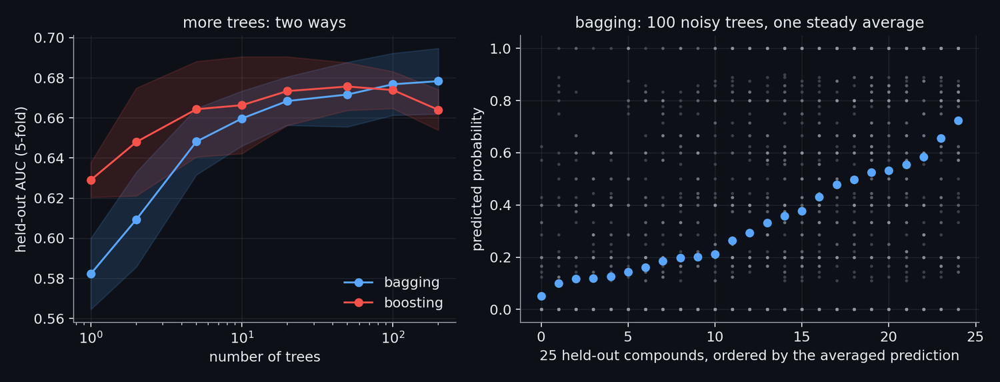

**Figure: Bagging against boosting on real compounds.** Two ways of combining many trees, on the same 2334 compounds and eight descriptors. Left: five-fold cross-validated AUC against the number of trees. Bagging (a random forest: each tree sees a bootstrap resample, the trees are averaged) starts from one noisy deep tree (0.582) and climbs to 0.678 with 200 trees; boosting (each shallow tree is fitted to what the trees before it got wrong) starts from 0.629 and reaches 0.664. Right: why averaging helps: each pale dot is the prediction of one of 100 bootstrap trees for one of 25 held-out compounds (the spread of a single tree is large, mean standard deviation 0.32); the bold dot is the average, which has no such spread. Bagging reduces variance and works with deep trees; boosting reduces bias and works with shallow ones.

In [92]:
show_figure("ml_bagging_boosting")

## 4.5 Nearest neighbours and support vector machines with the Tanimoto kernel

> **Field:** Machine learning · Mathematics (kernels)

**Nearest neighbours.** The simplest model of all has no training at all. To score a compound, find the $k$ most similar compounds in the training set and let them vote. The project weights the votes by similarity: with $N_k(x)$ the set of the $k$ training compounds most similar to $x$, and $s(x, x_i)$ the Tanimoto similarity of $x$ to $x_i$, and $\hat p(x)$ the resulting estimate of the probability that $x$ is positive,

$$\hat p(x) \;=\; \frac{\sum_{i \in N_k(x)} s(x, x_i)\, y_i}{\sum_{i \in N_k(x)} s(x, x_i)},$$

the similarity-weighted share of positive neighbours. It encodes the idea that similar compounds have similar labels (section 3.2 warned how far that holds). The number $k$ sets the trade-off of section 4.1: with $k = 1$ the score follows the single closest compound (high variance), with a large $k$ it approaches the overall rate (high bias).

**Support vector machines.** A different way to use similarity is to look for a rule that is a weighted sum of similarities to *some* training compounds, the **support vectors**. Write the label as $\tilde y_i = \pm 1$ and the score as a linear function in an (imagined) feature space, $f(x) = w \cdot \phi(x) + b$, where $\phi$ maps a compound to that space. The linear function that separates the classes with the widest possible margin
is the one preferred: the distance from the separating surface $f = 0$ to the nearest compound on either side is $1/\lVert w \rVert$ when the compounds closest to the surface have $|f| = 1$, so the widest margin means the smallest $\lVert w \rVert$. Real data cannot be separated perfectly, so every compound is allowed to violate the margin by an amount $\xi_i \ge 0$ at a price, and the problem is

$$\min_{w, b, \xi}\;\; \tfrac12\lVert w\rVert^2 + C\sum_{i=1}^{n}\xi_i \qquad\text{subject to}\qquad \tilde y_i\,(w\cdot\phi(x_i) + b) \ge 1 - \xi_i,\;\; \xi_i \ge 0 ,$$

where $C > 0$ balances a wide margin against violations; at the optimum $\xi_i = \max(0, 1 - \tilde y_i f(x_i))$, the **hinge loss**, which is zero for compounds beyond the margin. Introducing a multiplier $\alpha_i$ for each constraint and eliminating $w$, $b$ and $\xi$ turns this into a problem in the $\alpha_i$ alone:

$$\max_{\alpha}\;\; \sum_i \alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j\,\tilde y_i \tilde y_j\,K(x_i, x_j) \qquad\text{subject to}\qquad 0 \le \alpha_i \le C,\;\; \sum_i \alpha_i \tilde y_i = 0,\qquad f(x) = \sum_i \alpha_i \tilde y_i\,K(x_i, x) + b .$$

The map $\phi$ appears only through the **kernel** $K(x, x') = \phi(x)\cdot\phi(x')$, a similarity function: one never needs to compute $\phi$, only $K$ (the **kernel trick**). Any function that is symmetric and positive semi-definite, in the sense that every matrix $[K(x_i, x_j)]$ has no negative eigenvalue, is a kernel of some $\phi$ (Mercer's condition). The Tanimoto similarity of two binary fingerprints is such a function (Ralaivola and co-workers, 2005; Swamidass and co-workers, 2005), which is why a similarity that
chemists already trust can be used directly: $K = T$. Only the compounds with $\alpha_i > 0$, the support vectors, appear in $f$; those on or inside the margin. The project's SVMs use `class_weight='balanced'`, which multiplies $C$ for each class by $n / (2 n_{\text{class}})$ so that the rarer class (the positives) is not outvoted. The cell builds the kernel on the 2334 compounds, checks its positive semi-definiteness numerically, and compares the two models
with several values of $k$ and $C$, including the score of each on the compounds it was fitted on.

In [93]:
# The Tanimoto kernel on the 2334 compounds, and the two models built on it. K[i, j] is the Tanimoto similarity of compounds i and j (section 3.2). A kernel must be positive semi-definite: a quadratic
# form a'Ka is never negative, which is the same as K having no negative eigenvalue. The check is made on 600 compounds in double precision.
from sklearn.svm import SVC

from cypmode.challenge.grouping import morgan_bit_matrix
from cypmode.challenge.validation_matching import tanimoto_matrix

bits_ml = morgan_bit_matrix(train.loc[rows_ml, "SMILES"].tolist())
K = tanimoto_matrix(bits_ml)
eigenvalues = np.linalg.eigvalsh(K[:600, :600].astype(np.float64))
print(f"kernel matrix {K.shape[0]} x {K.shape[1]}, diagonal all 1: {bool(np.allclose(np.diag(K), 1))}, symmetric: {bool(np.allclose(K, K.T))}; smallest eigenvalue of a 600-compound block: {eigenvalues.min():.2e}")
smallest_eigenvalue = float(eigenvalues.min())

index_column = np.arange(len(y_ml), dtype=np.float64)[:, None]                  # the "features" handed to the models are the compound numbers; the kernel is read from K

def knn_fit_predict(k):
    def fit_predict(train_index, train_y, test_index):
        a, b = train_index[:, 0].astype(int), test_index[:, 0].astype(int)
        sims = K[np.ix_(b, a)]
        top = np.argsort(-sims, axis=1)[:, :k]
        w = np.take_along_axis(sims, top, axis=1)
        return (w * train_y[top]).sum(axis=1) / np.maximum(w.sum(axis=1), 1e-9)       # the similarity-weighted share of positive neighbours
    return fit_predict

def svm_fit_predict(C):
    def fit_predict(train_index, train_y, test_index):
        a, b = train_index[:, 0].astype(int), test_index[:, 0].astype(int)
        model = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K[np.ix_(a, a)], train_y)
        return model.decision_function(K[np.ix_(b, a)])
    return fit_predict

kernel_rows = []
for k in (1, 5, 15, 40, 100):
    resubstitution = roc_auc_score(y_ml, knn_fit_predict(k)(index_column, y_ml, index_column))              # every compound scored against all compounds, itself included
    mean_auc, sd_auc = cross_validated_auc(knn_fit_predict(k), index_column)
    kernel_rows.append({"model": f"nearest neighbours, k = {k}", "AUC on the compounds it was fitted on": resubstitution, "mean AUC on held-out compounds": mean_auc, "standard deviation": sd_auc})
for C in (0.3, 1.0, 3.0):
    fit_rows, held = folds_ml[0]
    fitted = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K[np.ix_(fit_rows, fit_rows)], y_ml[fit_rows])
    resubstitution = roc_auc_score(y_ml[fit_rows], fitted.decision_function(K[np.ix_(fit_rows, fit_rows)]))
    mean_auc, sd_auc = cross_validated_auc(svm_fit_predict(C), index_column)
    kernel_rows.append({"model": f"support vector machine, Tanimoto kernel, C = {C:g} ({len(fitted.support_) / len(fit_rows):.0%} of the compounds are support vectors)", "AUC on the compounds it was fitted on": resubstitution,
                        "mean AUC on held-out compounds": mean_auc, "standard deviation": sd_auc})
show_table(pd.DataFrame(kernel_rows), floatfmt=".3f")
knn_best = max(kernel_rows[:5], key=lambda r: r["mean AUC on held-out compounds"])
svm_best = max(kernel_rows[5:], key=lambda r: r["mean AUC on held-out compounds"])
knn_one = kernel_rows[0]

kernel matrix 2334 x 2334, diagonal all 1: True, symmetric: True; smallest eigenvalue of a 600-compound block: 2.41e-01


| model | AUC on the compounds it was fitted on | mean AUC on held-out compounds | standard deviation |
| --- | --- | --- | --- |
| nearest neighbours, k = 1 | 1.000 | 0.519 | 0.028 |
| nearest neighbours, k = 5 | 0.972 | 0.604 | 0.009 |
| nearest neighbours, k = 15 | 0.905 | 0.628 | 0.020 |
| nearest neighbours, k = 40 | 0.854 | 0.642 | 0.025 |
| nearest neighbours, k = 100 | 0.812 | 0.658 | 0.023 |
| support vector machine, Tanimoto kernel, C = 0.3 (96% of the compounds are support vectors) | 0.889 | 0.687 | 0.014 |
| support vector machine, Tanimoto kernel, C = 1 (89% of the compounds are support vectors) | 0.980 | 0.711 | 0.015 |
| support vector machine, Tanimoto kernel, C = 3 (87% of the compounds are support vectors) | 1.000 | 0.702 | 0.017 |

The kernel has no negative eigenvalue (the smallest on this block is 0.24, so the block is even positive definite), which is what a kernel must satisfy. The nearest-neighbour model with $k = 1$ reaches an AUC of 1.00 on the compounds it was fitted on, each one being its own nearest neighbour, and 0.519 on held-out ones: the memorising student again. The best of the neighbour models is nearest neighbours, k = 100 (0.658),
the best SVM reaches 0.711. Both work from the similarity alone and know nothing of descriptors, which is why they differ in kind from the tree models and are worth keeping in a collection of models that is blended at the end (section 8.2): when different models make different mistakes, their blend can be better than any of them. The project's candidates are `knn_tanimoto_k5`, `k15`, `k40` and `svm_tanimoto_C0.3`, `C1`, `C3`.

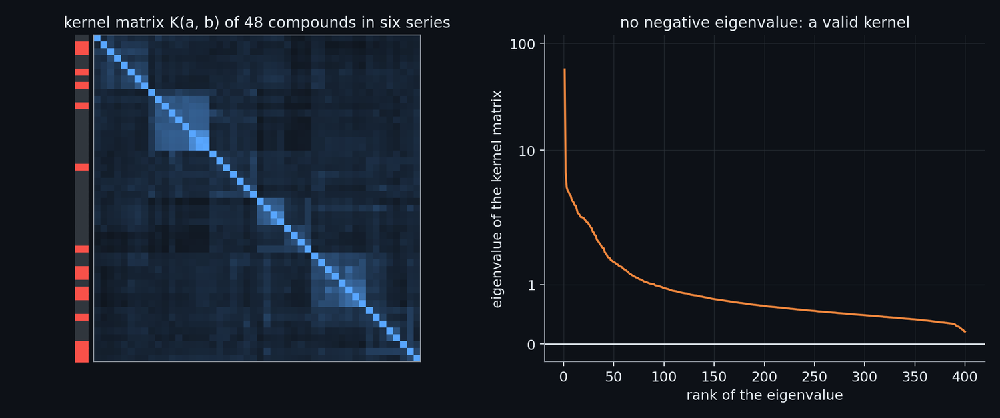

**Figure: The Tanimoto similarity as a kernel.** The Tanimoto similarity of Morgan fingerprints used as the kernel of a support vector machine. Left: the kernel matrix of 48 real CYP3A4 compounds (six compounds with their seven nearest neighbours each), ordered so that similar compounds sit together: the bright blocks on the diagonal are chemical series and the dark remainder is how little unrelated compounds share; the strip beside the matrix marks time-dependent inhibitors in red. Right: the eigenvalues of the kernel matrix of 400 other compounds; the smallest is 2.06e-01, so no eigenvalue is negative beyond rounding: the Tanimoto similarity is a valid positive semi-definite kernel, which is what a support vector machine needs. A support vector machine on this precomputed kernel, fitted and scored by five-fold cross-validation on 1200 compounds, reaches an AUC of 0.662.

In [94]:
show_figure("ml_tanimoto_kernel")

## 4.6 Regression for the two assay arms, and floor-clipping

> **Field:** Machine learning · Pharmacology

The label is a threshold on a continuous quantity (section 2.3), and a classifier is fitted to the label alone, which throws away how far a compound is from the threshold. A **regression** model predicts a number instead. The label depends on two measured numbers, so there are three natural ways to use them: predict the **shift** $s = t - \max(d, 4)$ directly and call a compound positive when the prediction is above the threshold; predict the two arms $t$ and $d$ with separate models
and combine them as $\hat t - \max(\hat d, 4)$; or predict the arms after **clipping** them at the floor. The squared-error loss of section 4.1 is used, whose best prediction is the conditional mean.

**Why clipping leaves the label alone.** The label is positive when $t - \max(d, 4) > \log_{10} 2$. Replace $d$ by $d' = \max(d, 4)$: then $\max(d', 4) = \max(d, 4)$ and the label does not change. Replace $t$ by $t' = \max(t, 4)$: if $t > 4$ nothing changes; if $t \le 4$ then $t - \max(d, 4) \le 4 - 4 = 0 < \log_{10} 2$, so the label is negative, and with $t' = 4$ the difference is $t' - \max(d, 4) \le 0$, which is again negative. So both arms can be clipped at 4 without changing any label, while the regression no longer has to explain differences between values below the floor, which are mostly measurement noise
(section 1.7). The cell verifies the claim on all compounds and compares the four ways of scoring.

In [95]:
# Regression for the two assay arms. First the claim of the text: clipping both arms at the floor of 4 leaves every label unchanged. Then four ways of scoring a compound, in the five folds of the other
# models: the classifier on the label; a regressor of the shift s = t - max(d, 4); two regressors, one per arm, scored by t_hat - max(d_hat, 4); and the same with both arms clipped at 4 before fitting.
from lightgbm import LGBMRegressor

from cypmode.challenge.nested_runners import LGBM_PRESETS
from cypmode.challenge.tdi_targets import label_from_shift

d_arm, t_arm = view_ml["direct"].to_numpy(), view_ml["tdi"].to_numpy()
label_original = label_from_shift(t_arm - np.maximum(d_arm, ASSAY_FLOOR))
label_clipped = label_from_shift(np.maximum(t_arm, ASSAY_FLOOR) - np.maximum(np.maximum(d_arm, ASSAY_FLOOR), ASSAY_FLOOR))
n_label_changes = int((label_original != label_clipped).sum())
print(f"labels that change when both arms are clipped at {ASSAY_FLOOR:g}: {n_label_changes} of {len(label_original)}; share of the t values below the floor: {(t_arm < ASSAY_FLOOR).mean():.1%}, of the d values: {(d_arm < ASSAY_FLOOR).mean():.1%}")

params = LGBM_PRESETS["deep"]
def regressor():
    return LGBMRegressor(verbose=-1, n_jobs=2, random_state=0, **params)

def fit_two_arms(train_x, train_rows, test_x, clip):
    t_target, d_target = t_arm[train_rows], d_arm[train_rows]
    if clip:
        t_target, d_target = np.maximum(t_target, ASSAY_FLOOR), np.maximum(d_target, ASSAY_FLOOR)
    return regressor().fit(train_x, t_target).predict(test_x), regressor().fit(train_x, d_target).predict(test_x)

arm_scores = {"classifier on the label": [], "regressor of the shift s": [], "two arms, t_hat - max(d_hat, 4)": [], "two arms clipped at 4, t_hat - max(d_hat, 4)": []}
arm_r2 = {"t": [], "d": []}
truths = []
for fit_rows, held in folds_ml:
    truths.append(y_ml[held])
    arm_scores["classifier on the label"].append(LGBMClassifier(verbose=-1, n_jobs=2, random_state=0, **params).fit(set_a[fit_rows], y_ml[fit_rows]).predict_proba(set_a[held])[:, 1])
    arm_scores["regressor of the shift s"].append(regressor().fit(set_a[fit_rows], shift_ml[fit_rows]).predict(set_a[held]))
    t_hat, d_hat = fit_two_arms(set_a[fit_rows], fit_rows, set_a[held], clip=False)
    arm_scores["two arms, t_hat - max(d_hat, 4)"].append(t_hat - np.maximum(d_hat, ASSAY_FLOOR))
    arm_r2["t"].append(1 - np.sum((t_arm[held] - t_hat) ** 2) / np.sum((t_arm[held] - t_arm[held].mean()) ** 2))
    arm_r2["d"].append(1 - np.sum((d_arm[held] - d_hat) ** 2) / np.sum((d_arm[held] - d_arm[held].mean()) ** 2))
    t_hat, d_hat = fit_two_arms(set_a[fit_rows], fit_rows, set_a[held], clip=True)
    arm_scores["two arms clipped at 4, t_hat - max(d_hat, 4)"].append(t_hat - np.maximum(d_hat, ASSAY_FLOOR))
arm_rows = [{"way of scoring a compound": name, "mean AUC (5 folds)": float(np.mean([roc_auc_score(t, s) for t, s in zip(truths, scores)])),
             "standard deviation": float(np.std([roc_auc_score(t, s) for t, s in zip(truths, scores)]))} for name, scores in arm_scores.items()]
show_table(pd.DataFrame(arm_rows), floatfmt=".3f")
print(f"R squared of the arm regressors on held-out compounds: t {np.mean(arm_r2['t']):.2f}, d {np.mean(arm_r2['d']):.2f}")
arm_auc = {r["way of scoring a compound"]: r["mean AUC (5 folds)"] for r in arm_rows}
r2_t, r2_d = float(np.mean(arm_r2["t"])), float(np.mean(arm_r2["d"]))

labels that change when both arms are clipped at 4: 0 of 2334; share of the t values below the floor: 30.3%, of the d values: 40.4%
R squared of the arm regressors on held-out compounds: t 0.56, d 0.59


| way of scoring a compound | mean AUC (5 folds) | standard deviation |
| --- | --- | --- |
| classifier on the label | 0.752 | 0.012 |
| regressor of the shift s | 0.734 | 0.007 |
| two arms, t_hat - max(d_hat, 4) | 0.742 | 0.009 |
| two arms clipped at 4, t_hat - max(d_hat, 4) | 0.730 | 0.018 |

Clipping both arms at 4 changes 0 labels, as the proof says. The classifier on the label reaches 0.752; the regressor of the shift 0.734; the two arms scored together 0.742, and with clipping 0.730. The arms themselves are predicted with $R^2$ values of 0.56 ($t$) and 0.59 ($d$), where $R^2 = 1 - \sum (y - \hat y)^2 / \sum (y - \bar y)^2$ is the fraction of the variance of the
quantity that the model explains. These are single-split numbers on one task; whether the arm models add anything to a blend of classifiers is the question that section 9.6 answers with the full evaluation, and the project keeps them as members of the stack (`lgbm_reg_shift_*`, `lgbm_reg_arms_*`).

## 4.7 Neural networks: the perceptron, backpropagation and shared-trunk networks for several tasks

> **Field:** Machine learning · Mathematics (calculus)

**A neuron and a layer.** An artificial neuron computes a weighted sum of its inputs plus a constant, $a = \sum_k w_k x_k + b$, and passes it through a non-linear **activation function** $\varphi$ to give its output $\varphi(a)$. The earliest form, the **perceptron** (Rosenblatt, 1958), used a step as its activation. A **layer** is many neurons reading the same inputs: with a weight matrix $W$ (one row per neuron) and a vector $b$, it computes $\varphi(Wx + b)$. A **network** stacks layers, the outputs of one being the inputs of
the next. Without the non-linearity a stack of layers would collapse into a single linear map, $W_2(W_1 x) = (W_2 W_1)x$; with it, a network with one hidden layer can approximate any continuous function on a bounded region if the layer is wide enough (Cybenko, 1989; Hornik, 1991). The common activations are $\tanh(a)$, which squashes to the interval $(-1, 1)$, and the **rectified linear unit** $\mathrm{ReLU}(a) = \max(0, a)$.

**Training by backpropagation.** For a network with one hidden layer of $H$ units, $h = \tanh(W_1 x + b_1)$, logit $z = w_2\cdot h + b_2$ and probability $p = \sigma(z)$, the log-loss of section 4.1 is to be minimised by gradient descent, which needs its gradient with respect to every weight. **Backpropagation** (Rumelhart, Hinton and Williams, 1986) is the chain rule applied from the output backwards. Write $\delta_2 = \partial L/\partial z = p - y$ (section 4.1). Then
$\partial L/\partial w_2 = \delta_2\,h$ and $\partial L/\partial b_2 = \delta_2$, since $z$ depends on $w_2$ through $h$ only linearly. The hidden activations receive $\partial L/\partial h = \delta_2\,w_2$; the pre-activation $a = W_1 x + b_1$ of the hidden layer is passed through the tanh, whose derivative is $1 - \tanh^2(a) = 1 - h^2$, so $\delta_1 = \partial L/\partial a = \delta_2\,w_2 \odot (1 - h^2)$ (the symbol $\odot$ is multiplication element by element), and
$\partial L/\partial W_1 = \delta_1\,x^{\top}$, $\partial L/\partial b_1 = \delta_1$. Averaged over the compounds and with an **L2 penalty** $\tfrac12 \ell\,\lVert W\rVert^2$ added to keep the weights small (the gradient of the penalty is $\ell\,W$), these are the quantities the code below computes. The optimiser used is **Adam** (Kingma and Ba, 2015), which keeps running averages of the gradient $g$ and of its square, $m \leftarrow \beta_1 m + (1 - \beta_1)g$ and
$v \leftarrow \beta_2 v + (1 - \beta_2)g^2$, corrects their start-up bias ($\hat m = m/(1 - \beta_1^t)$, $\hat v = v/(1 - \beta_2^t)$ after $t$ steps) and moves each weight by $\eta\,\hat m/(\sqrt{\hat v} + \varepsilon)$: every weight gets a step of its own size. The cell compares the analytic gradient with a finite difference for every weight and then trains the network on the descriptors.

In [96]:
# A neural network with one hidden layer, written out with its gradient. Input x (p numbers) -> hidden layer h = tanh(W1 x + b1) of H units -> logit z = w2 . h + b2 -> p = sigmoid(z); loss = log-loss plus
# an L2 penalty on the weights. The gradient is derived in the text; here it is compared with a finite-difference estimate for every single weight, and then the network is trained with Adam.
class TinyNet:
    def __init__(self, n_inputs, hidden, seed=0, l2=1e-3):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1 / np.sqrt(n_inputs), (hidden, n_inputs)); self.b1 = np.zeros(hidden)
        self.w2 = rng.normal(0, 1 / np.sqrt(hidden), hidden); self.b2 = 0.0
        self.l2 = l2

    def forward(self, X):
        self.X = X
        self.h = np.tanh(X @ self.W1.T + self.b1)
        self.z = self.h @ self.w2 + self.b2
        return self.z

    def loss(self, X, y):
        z = self.forward(X)
        return float(np.mean(np.logaddexp(0, z) - y * z) + 0.5 * self.l2 * (np.sum(self.W1**2) + np.sum(self.w2**2)))    # log(1 + e^z) - y z is the log-loss written with the logit

    def gradients(self, X, y):
        z = self.forward(X)
        n = len(y)
        delta2 = (sigmoid(z) - y) / n                                                # dL/dz for every compound, averaged
        grad_w2 = self.h.T @ delta2 + self.l2 * self.w2
        grad_b2 = delta2.sum()
        delta1 = np.outer(delta2, self.w2) * (1 - self.h**2)                         # back through the tanh: d tanh(a)/da = 1 - tanh(a)^2
        grad_W1 = delta1.T @ X + self.l2 * self.W1
        grad_b1 = delta1.sum(axis=0)
        return grad_W1, grad_b1, grad_w2, grad_b2

# Gradient check on 40 compounds and 6 descriptors, every weight perturbed in turn.
rng = np.random.default_rng(1)
Xc, yc = rng.normal(size=(40, 6)), (rng.random(40) < 0.4).astype(float)
net = TinyNet(6, 5, seed=2)
analytic = net.gradients(Xc, yc)
worst = 0.0
for array, grad in zip((net.W1, net.b1, net.w2), analytic[:3]):
    flat, flat_grad = array.reshape(-1), grad.reshape(-1)
    for i in range(flat.size):
        saved = flat[i]
        flat[i] = saved + 1e-6; up = net.loss(Xc, yc)
        flat[i] = saved - 1e-6; down = net.loss(Xc, yc)
        flat[i] = saved
        worst = max(worst, abs((up - down) / 2e-6 - flat_grad[i]))
saved_b2 = net.b2
net.b2 = saved_b2 + 1e-6; up = net.loss(Xc, yc); net.b2 = saved_b2 - 1e-6; down = net.loss(Xc, yc); net.b2 = saved_b2
worst = max(worst, abs((up - down) / 2e-6 - analytic[3]))
n_weights_checked = net.W1.size + net.b1.size + net.w2.size + 1
print(f"largest difference between the analytic gradient and the finite difference over all {n_weights_checked} weights: {worst:.1e}")
gradient_gap = worst

def train_net(X, y, hidden=32, epochs=150, rate=0.01, l2=1e-3, seed=0, watch=None):
    """Full-batch Adam; returns the network and, if watch = (X_watch, y_watch) is given, the AUC on the watched compounds every 25 epochs."""
    net = TinyNet(X.shape[1], hidden, seed=seed, l2=l2)
    state = [[np.zeros_like(a), np.zeros_like(a)] for a in (net.W1, net.b1, net.w2)] + [[np.zeros(1), np.zeros(1)]]
    history = []
    for t in range(1, epochs + 1):
        grads = net.gradients(X, y)
        params = [net.W1, net.b1, net.w2, np.array([net.b2])]
        for (m, v), param, grad in zip(state, params, grads):
            g = np.asarray(grad, dtype=float).reshape(param.shape)
            m *= 0.9; m += 0.1 * g
            v *= 0.999; v += 0.001 * g**2
            param -= rate * (m / (1 - 0.9**t)) / (np.sqrt(v / (1 - 0.999**t)) + 1e-8)
        net.b2 = float(params[3][0])
        if watch is not None and t % 25 == 0:
            history.append({"epoch": t, "AUC on the fitted compounds": roc_auc_score(y, net.forward(X)), "AUC on the held-out compounds": roc_auc_score(watch[1], net.forward(watch[0]))})
    return net, history

def standardise(train_x, other_x):
    mu, sd = train_x.mean(axis=0), train_x.std(axis=0)
    sd[sd == 0] = 1.0
    return np.clip((train_x - mu) / sd, -5, 5), np.clip((other_x - mu) / sd, -5, 5)

def net_fit_predict(hidden, epochs, l2):
    def fit_predict(train_x, train_y, test_x):
        a, b = standardise(train_x, test_x)
        net, _ = train_net(a, train_y.astype(float), hidden=hidden, epochs=epochs, l2=l2)
        return net.forward(b)
    return fit_predict

fit_rows, held = folds_ml[0]
a, b = standardise(desc_ml[fit_rows], desc_ml[held])
_, net_history = train_net(a, y_ml[fit_rows].astype(float), hidden=32, epochs=200, l2=1e-3, watch=(b, y_ml[held]))
show_table(pd.DataFrame(net_history), floatfmt=".3f")
net_rows = []
for hidden, epochs, l2 in ((32, 50, 1e-3), (32, 200, 1e-3), (32, 200, 1e-1)):
    mean_auc, sd_auc = cross_validated_auc(net_fit_predict(hidden, epochs, l2), desc_ml)
    net_rows.append({"network": f"{hidden} hidden units, {epochs} epochs, L2 penalty {l2:g}", "mean AUC (5 folds)": mean_auc, "standard deviation": sd_auc})
show_table(pd.DataFrame(net_rows), floatfmt=".3f")
net_best = max(net_rows, key=lambda r: r["mean AUC (5 folds)"])
net_history_last = net_history[-1]

largest difference between the analytic gradient and the finite difference over all 41 weights: 9.2e-11


| epoch | AUC on the fitted compounds | AUC on the held-out compounds |
| --- | --- | --- |
| 25 | 0.885 | 0.726 |
| 50 | 0.990 | 0.721 |
| 75 | 1.000 | 0.711 |
| 100 | 1.000 | 0.711 |
| 125 | 1.000 | 0.708 |
| 150 | 1.000 | 0.705 |
| 175 | 1.000 | 0.699 |
| 200 | 1.000 | 0.698 |

| network | mean AUC (5 folds) | standard deviation |
| --- | --- | --- |
| 32 hidden units, 50 epochs, L2 penalty 0.001 | 0.710 | 0.018 |
| 32 hidden units, 200 epochs, L2 penalty 0.001 | 0.690 | 0.017 |
| 32 hidden units, 200 epochs, L2 penalty 0.1 | 0.719 | 0.012 |

The analytic gradient agrees with the finite difference over all 41 weights to within 9.2e-11, so the backpropagation formulas are right. On the first fold the AUC of the network on the compounds it was fitted on climbs with the number of epochs (an *epoch* is one pass over the training data) to 1.00, while on the held-out compounds it ends at 0.70; the table of the five-fold results shows that a stronger L2 penalty or fewer epochs
changes the balance. The best of the three settings reaches 0.719 (32 hidden units, 200 epochs, L2 penalty 0.1). A network of this size on a table of descriptors is not the best model for these data (section 8.1 gives the full comparison); its importance is as the basis of the networks that follow.

**The shared-trunk multitask network.** The training file carries measurements for four enzymes and two arms, but a given compound has only some of them (section 2.2). A **multitask** network has one **trunk**, a stack of layers shared by all tasks, which turns a compound into a representation, and one **head** per task, a small network that reads the representation and produces that task's output. The hope is that a representation that must serve several tasks captures what the tasks have in common. Compounds lack some labels, and
the missing ones must not be filled in with a guess. The loss is therefore **masked**: it is summed over the labels that exist only, $L = \bigl(\sum_{i,k} m_{ik}\,\ell_{ik}\bigr)/\sum_{i,k} m_{ik}$, with $m_{ik} = 1$ if compound $i$ has a label for task $k$ and 0 otherwise, so that a missing label contributes no loss and no gradient. The cell shows the difference between masking and filling the missing labels with "negative".

In [97]:
# The masked loss of a multitask network on three compounds and two heads (two enzymes), with some labels missing. Masking sums the loss only over the labels that exist; filling the missing ones with
# "negative" is a different loss, and gives a different number.
logits = np.array([[0.8, -0.2], [-1.0, 0.5], [2.0, 0.1]])
targets = np.array([[1.0, 0.0], [0.0, np.nan], [np.nan, 1.0]])
present = ~np.isnan(targets)
per_entry = np.where(present, log_loss(np.nan_to_num(targets), logits), 0.0)
masked_mean = per_entry.sum() / present.sum()
imputed_mean = log_loss(np.nan_to_num(targets, nan=0.0), logits).mean()
print(f"labels present: {int(present.sum())} of {present.size}; masked mean loss {masked_mean:.4f}; loss if the missing labels were filled in as negative {imputed_mean:.4f}")
gradient_masked = np.where(present, (sigmoid(logits) - np.nan_to_num(targets)) / present.sum(), 0.0)
print("gradient of the masked loss with respect to the logits (rows: compounds; zero where the label is missing):")
print(np.round(gradient_masked, 4))
masked_values = (float(masked_mean), float(imputed_mean))

labels present: 4 of 6; masked mean loss 0.4817; loss if the missing labels were filled in as negative 0.8380
gradient of the masked loss with respect to the logits (rows: compounds; zero where the label is missing):
[[-0.0775  0.1125]
 [ 0.0672  0.    ]
 [ 0.     -0.1188]]


Masked, the loss over the 4 labels that exist is 0.482; with the missing labels filled in as negative it would be 0.838, a different number that rewards the model for predicting inhibition of the unknown, and the gradient of the masked loss is exactly zero where the label is missing. The project has two networks of this kind. The first, `cypmode/challenge/multitask.py`, has a trunk of two layers of 64 units with dropout, and a head of 32 units for each of the two enzymes, trained with the masked binary
cross-entropy and Adam. The second, in `cypmode/challenge/nested_runners_torch.py`, is the one that enters the nested evaluation: the input is the logarithm of one plus the Morgan counts together with quantile-normalised descriptors, the trunk has two layers of 1024 and 512 units, each followed by **batch normalisation** (every unit's activation is shifted and scaled to mean 0 and variance 1 over a mini-batch of 128 compounds, $\hat a = (a - \mu_B)/\sqrt{\sigma_B^2 + \varepsilon}$, followed by a learned scale and shift, which makes training faster and steadier), a ReLU
and **dropout** of 0.35 (during training every unit is switched off with probability 0.35, so that no unit can be relied on and the network cannot memorise; at prediction time all units are on, scaled to match). One head regresses the eight standardised potency endpoints (direct and TDI-arm pIC50 of four enzymes, masked where unmeasured) and one head classifies the label of the task; the loss is the sum of the masked squared error and the masked cross-entropy; the optimiser is AdamW (Adam with the weight decay applied to the weights directly and not through the gradient; Loshchilov and Hutter, 2019) with a one-cycle schedule of the learning rate that rises to $2\times10^{-3}$ and falls again over 60 epochs; the scores of three seeds (a **seed** is the number that starts the random number generator, so that a run can be repeated exactly; a different seed is a different random start of the same network) are averaged, and the candidate's score is either the label head or the predicted shift $\hat t - \max(\hat d, 4)$. The network may learn from the compounds outside the plan's pool as well, whose arm values give it far more supervision than the label of the pool alone; it never sees an outer-validation row (Part VI). Torch and LightGBM cannot be imported into one process on the machine of this project (a recorded segmentation fault), so the networks run in a separate environment and write their predictions to the cache that the rest reads.

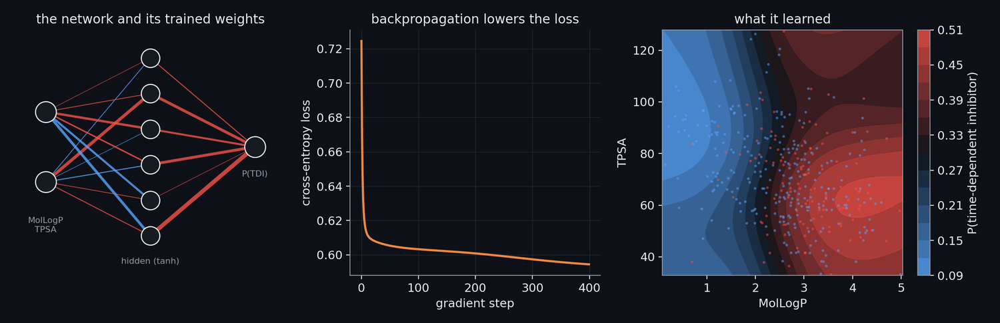

**Figure: A small neural network trained by backpropagation.** A neural network with two inputs (MolLogP and TPSA, standardised), 6 hidden units with tanh and one sigmoid output, trained on real CYP3A4 compounds by gradient descent for 400 steps; the code is written out in the figure's module with the backward pass by hand. Left: the network, each line drawn thicker where its trained weight is larger (blue positive, red negative). Middle: the cross-entropy loss falls from 0.725 to 0.594 on the training fold. Right: the probability of time-dependent inhibition over the plane of the two descriptors, with the compounds; the AUC on the held-out fold is 0.638, close to what the depth-3 tree of figure 4.2 reached, because two descriptors carry little more. The backward pass is checked against finite differences: the largest relative difference between the gradient of backpropagation and the numerical gradient of every one of the 25 parameters is 1.3e-09.

In [98]:
show_figure("ml_backprop")

## 4.8 Message-passing networks on molecular graphs, and networks on text

> **Field:** Machine learning · Cheminformatics

**Learning on the graph.** The fingerprints of Part III are made by fixed rules. A **message-passing neural network** (Gilmer and co-workers, 2017) learns its own. Every atom carries a vector of numbers, its **state**, initially made of the properties of the atom. In each of $T$ steps, every atom receives **messages** from its bonded neighbours, combines them with its own state and updates the state with a small neural network whose weights are learned. After $T$ steps the state of an atom has taken in everything within $T$ bonds, which is exactly the idea of the Morgan environment of
section 3.1 but with learned features instead of hashes. A final **readout** combines the states of all atoms, by a sum or a mean, into one vector for the molecule, which a small network turns into the prediction. Because the readout does not depend on the order of the atoms, the model gives the same answer however the atoms are numbered. **Chemprop** (Yang and co-workers, 2019) uses a variant in which the messages live on the *directed bonds*: the state $h_{u\to v}$ of the bond from $u$ to $v$ starts as
$\mathrm{ReLU}(W_i\,[x_u, b_{uv}])$, where $x_u$ describes atom $u$, $b_{uv}$ the bond, $[\cdot,\cdot]$ joins two vectors and $W_i$ is a weight matrix, and is updated for $T$ steps, step $t$ giving the state $h^{(t)}$, by

$$h_{u\to v}^{(t+1)} \;=\; \mathrm{ReLU}\Bigl(h_{u\to v}^{(0)} + W_h \sum_{k \in N(u)\setminus\{v\}} h_{k\to u}^{(t)}\Bigr),$$

the sum being over the neighbours $k$ of $u$ other than $v$: a bond does not send back to $v$ what it has just heard from $v$, which prevents the message from running in circles. Finally the state of an atom is $h_v = \mathrm{ReLU}\bigl(W_o\,[x_v, \sum_{k \in N(v)} h_{k\to v}^{(T)}]\bigr)$ and the molecule is the mean of its atoms' states. The cell writes this forward pass for the example compound, with random weights, and checks the two properties just named:
order independence, and that the reach of an atom grows by one bond per step.

In [99]:
# A directed message-passing network (the form Chemprop uses), forward pass only, with random weights, for the example compound. An atom starts as a vector of nine numbers (which of five elements it is,
# its number of heavy neighbours, aromatic, in a ring, hydrogens); a bond as four numbers (its type). Every bond gives two directed edges. An edge u -> v starts as relu(W_i [x_u, b_uv]); in each step it
# is updated with the sum of the edges that point into u from anywhere but v. At the end every atom adds up the edges pointing into it, and the molecule is the mean of its atoms' states.
ELEMENTS = ["C", "N", "O", "S", "Br"]
BOND_TYPES = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]

def atom_vector(atom):
    return np.array([float(atom.GetSymbol() == e) for e in ELEMENTS] + [atom.GetDegree() / 4, float(atom.GetIsAromatic()), float(atom.IsInRing()), atom.GetTotalNumHs() / 3])

def bond_vector(bond):
    return np.array([float(bond.GetBondType() == t) for t in BOND_TYPES])

def make_weights(hidden, seed=0):
    rng = np.random.default_rng(seed)
    return (np.abs(rng.normal(0, 0.5, (hidden, 9 + 4))), np.abs(rng.normal(0, 0.5 / np.sqrt(hidden), (hidden, hidden))), np.abs(rng.normal(0, 0.5, (hidden, 9 + hidden))))

def message_passing(molecule, weights, steps, x=None):
    W_i, W_h, W_o = weights
    x = np.array([atom_vector(a) for a in molecule.GetAtoms()]) if x is None else x
    neighbours = {a.GetIdx(): [n.GetIdx() for n in a.GetNeighbors()] for a in molecule.GetAtoms()}
    directed = [(b.GetBeginAtomIdx(), b.GetEndAtomIdx(), bond_vector(b)) for b in molecule.GetBonds()] + [(b.GetEndAtomIdx(), b.GetBeginAtomIdx(), bond_vector(b)) for b in molecule.GetBonds()]
    index = {(u, v): k for k, (u, v, _) in enumerate(directed)}
    h0 = np.array([np.maximum(0, W_i @ np.concatenate([x[u], f])) for u, v, f in directed])
    h = h0.copy()
    for _ in range(steps):
        updated = np.empty_like(h)
        for k, (u, v, _) in enumerate(directed):
            incoming = [index[(w, u)] for w in neighbours[u] if w != v]               # the messages into u from every neighbour except the one this edge points to
            updated[k] = np.maximum(0, h0[k] + W_h @ (h[incoming].sum(axis=0) if incoming else np.zeros(h.shape[1])))
        h = updated
    states = np.array([np.maximum(0, W_o @ np.concatenate([x[v], sum(h[index[(w, v)]] for w in neighbours[v])])) for v in range(molecule.GetNumAtoms())])
    return states, states.mean(axis=0), len(directed)

weights = make_weights(24)
states, vector, n_directed = message_passing(mol, weights, steps=3)
print(f"{mol.GetNumBonds()} bonds give {n_directed} directed edges; the molecule is described by a vector of {vector.shape[0]} numbers, whatever its size")

# Renumbering the atoms must not change the molecule vector (the readout is a mean over atoms).
rng = np.random.default_rng(4)
permutation = [int(i) for i in rng.permutation(mol.GetNumAtoms())]
renumbered = Chem.RenumberAtoms(mol, permutation)
_, vector_renumbered, _ = message_passing(renumbered, weights, steps=3)
invariant = bool(np.allclose(vector, vector_renumbered))
print(f"the vector is the same after a random renumbering of the atoms: {invariant}")

# The receptive field: change the features of one atom (the sulfur) and see which atoms' final states change, for 0 to 3 message-passing steps.
distance = Chem.GetDistanceMatrix(mol)
centre = [a.GetIdx() for a in mol.GetAtoms() if a.GetSymbol() == "S"][0]
field_rows = []
for steps in range(4):
    base, _, _ = message_passing(mol, weights, steps)
    x_changed = np.array([atom_vector(a) for a in mol.GetAtoms()])
    x_changed[centre] += 1.0
    changed, _, _ = message_passing(mol, weights, steps, x=x_changed)
    affected = np.flatnonzero(np.abs(changed - base).max(axis=1) > 1e-12)
    field_rows.append({"message-passing steps": steps, "atoms whose state changes": len(affected), "farthest of them, in bonds from the changed atom": int(distance[centre, affected].max())})
show_table(pd.DataFrame(field_rows))
n_atoms_affected = field_rows[-1]["atoms whose state changes"]

24 bonds give 48 directed edges; the molecule is described by a vector of 24 numbers, whatever its size
the vector is the same after a random renumbering of the atoms: True


| message-passing steps | atoms whose state changes | farthest of them, in bonds from the changed atom |
| --- | --- | --- |
| 0 | 5 | 1 |
| 1 | 9 | 2 |
| 2 | 14 | 3 |
| 3 | 15 | 4 |

The molecule is described by a vector of the same length, whatever its size, and the vector is unchanged by a renumbering of the atoms (True). The reach grows by one bond with each step, starting from one bond for no steps at all, because the final step already reads the bonds that arrive at an atom: after three steps the change of one atom reaches 4 bonds away and alters 15 atoms.
When the weights are learned from labelled molecules, the network chooses which features of the neighbourhood matter. The project uses Chemprop in two ways: trained from scratch on the eight potency endpoints (the candidate `chemprop_mt_shift` of `cypmode/challenge/nested_runners_chemprop.py`, which scores a compound by $\hat t - \max(\hat d, 4)$), and, as a frozen encoder, **CheMeleon**, a Chemprop network that was pretrained by others on a large set of computed molecular descriptors (Burns and co-workers): each molecule is turned into its 2048-number readout, which is reduced to 64 principal components (section 4.9) and offered to the other models as the block `chemeleon` (section 9.4).

**Networks on text and self-attention.** A SMILES string (section 2.1) is a text, and models that read text can read it. The most successful of them are **transformers** (Vaswani and co-workers, 2017). A text is cut into **tokens**, here atoms, bonds, brackets and ring digits, and every token gets a vector from a table, to which a vector encoding the *position* of the token is added, since the machinery below does not otherwise know the order. The heart of a transformer is **self-attention**:
each token looks at all the others and takes a weighted average of what it finds. From the token vectors $X$ (one row per token) three linear maps give **queries** $Q = XW_Q$, **keys** $K = XW_K$ and **values** $V = XW_V$. The score of token $j$ for token $i$ is the dot product of the query of $i$ with the key of $j$, the scores of a row are turned into weights that sum to 1 by the **softmax** $\mathrm{softmax}(s)_j = e^{s_j}/\sum_l e^{s_l}$, and the output of token $i$ is the weighted average of the values:

$$\mathrm{Attention}(Q, K, V) \;=\; \mathrm{softmax}\!\Bigl(\frac{Q K^{\top}}{\sqrt{d_k}}\Bigr)\,V ,$$

with $d_k$ the length of a key. The division by $\sqrt{d_k}$ has a reason that the cell shows: if the entries of $q$ and $k$ are independent with variance 1, the dot product $q\cdot k = \sum_{l=1}^{d_k} q_l k_l$ has variance $d_k$, so for long keys the scores are large, the softmax saturates to a one-hot vector and its gradients vanish; dividing by $\sqrt{d_k}$ brings the variance back to 1.
A transformer layer repeats this with several heads in parallel (each with its own maps), adds a small network applied to every token, and wraps both in residual connections and normalisation. **ChemBERTa** (Chithrananda and co-workers, 2020, who pretrained on 77 million SMILES strings from PubChem; the checkpoint used here is the smaller release `seyonec/ChemBERTa-zinc-base-v1`, `cypmode/challenge/chemberta_features.py`, whose model card states 100 thousand SMILES strings from ZINC, a public catalogue of purchasable compounds) is a transformer of the RoBERTa kind that was pretrained by *masked-language modelling* on those strings: a fraction of the tokens of each string is hidden and
the network is trained to predict them, which forces it to learn the grammar and the chemistry of the strings without any label. The project took its 768-number mean-pooled embedding of every compound. Joined naively to the other features it lowered the AUC on CYP3A4, by an amount that the corrected test of Part VI does not separate from chance (section 7.9), and the project reduces such embeddings before use (as with CheMeleon). The cell writes the attention of one head on the example's SMILES.

In [100]:
# Self-attention written out on the canonical SMILES of the example compound. The string is cut into tokens (an atom symbol, a bond, a bracket, a ring digit); every token gets a vector (random here,
# learned in a real model) plus a vector that encodes its position; and one attention head mixes the tokens. The weights are random, so the pattern means nothing chemically: the cell shows the mechanics.
import re

token_regex = re.compile(r"\[[^\]]+\]|Br|Cl|@@|%\d\d|[A-Za-z]|\d|[()=#+\-/\\.:~@*$]")
canonical_smiles = Chem.MolToSmiles(mol)
tokens = token_regex.findall(canonical_smiles)
assert "".join(tokens) == canonical_smiles
vocabulary = {t: i for i, t in enumerate(sorted(set(tokens)))}
d_model = 16
rng = np.random.default_rng(2)
embedding = rng.normal(size=(len(vocabulary), d_model))
position = np.arange(len(tokens))[:, None]
frequency = 1 / 10000 ** (np.arange(0, d_model, 2) / d_model)
positional = np.zeros((len(tokens), d_model))
positional[:, 0::2], positional[:, 1::2] = np.sin(position * frequency), np.cos(position * frequency)
X_tokens = embedding[[vocabulary[t] for t in tokens]] + positional
W_q, W_k, W_v = (rng.normal(0, 1 / np.sqrt(d_model), (d_model, d_model)) for _ in range(3))
Q, Kmat, V = X_tokens @ W_q, X_tokens @ W_k, X_tokens @ W_v

def softmax(scores):
    e = np.exp(scores - scores.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

attention = softmax(Q @ Kmat.T / np.sqrt(d_model))
mixed = attention @ V
print(f"{len(tokens)} tokens ({len(vocabulary)} different); attention matrix {attention.shape[0]} x {attention.shape[1]}; every row sums to 1: {bool(np.allclose(attention.sum(axis=1), 1))}; output {mixed.shape}")
print("the first tokens:", tokens[:12])

# Why the scores are divided by the square root of the key length: a dot product of two vectors of d independent numbers with variance 1 has variance d, and large scores push the softmax to a one-hot vector.
scale_rows = []
for d_k in (16, 64, 256):
    q, k = rng.normal(size=(20000, d_k)), rng.normal(size=(20000, d_k))
    dots = (q * k).sum(axis=1)
    queries, keys = rng.normal(size=(20, d_k)), rng.normal(size=(20, d_k))
    raw, scaled = softmax(queries @ keys.T), softmax(queries @ keys.T / np.sqrt(d_k))
    scale_rows.append({"key length d_k": d_k, "variance of q . k": float(dots.var()), "variance of q . k / sqrt(d_k)": float((dots / np.sqrt(d_k)).var()),
                       "mean largest attention weight, unscaled": float(raw.max(axis=1).mean()), "scaled": float(scaled.max(axis=1).mean())})
show_table(pd.DataFrame(scale_rows), floatfmt=".2f")
n_tokens, n_vocabulary = len(tokens), len(vocabulary)

42 tokens (13 different); attention matrix 42 x 42; every row sums to 1: True; output (42, 16)
the first tokens: ['C', 'C', '(', 'C', ')', '(', 'C', ')', 'N', 'S', '(', '=']


| key length d_k | variance of q . k | variance of q . k / sqrt(d_k) | mean largest attention weight, unscaled | scaled |
| --- | --- | --- | --- | --- |
| 16 | 16.08 | 1.01 | 0.72 | 0.23 |
| 64 | 64.11 | 1.00 | 0.88 | 0.26 |
| 256 | 259.54 | 1.01 | 0.91 | 0.20 |

The SMILES of the example is cut into 42 tokens of 13 kinds; the attention matrix has one row of weights per token and every row sums to 1. The table shows the reason for the division: the variance of the dot product grows with the key length and the largest attention weight of an unscaled softmax approaches 1 for long keys, while the scaled scores keep a variance of 1 and a softer pattern.

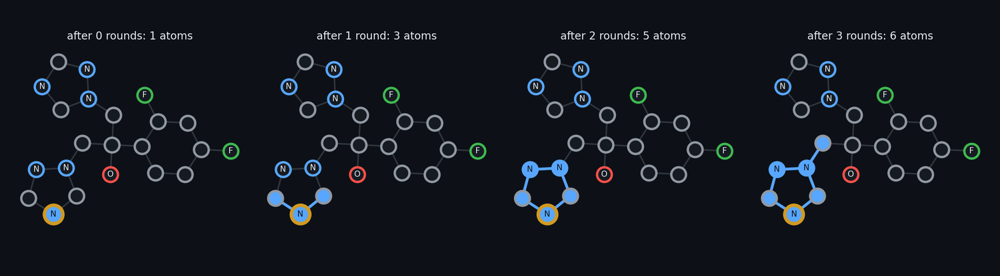

**Figure: Message passing: what an atom knows after k rounds.** Message passing on the graph of fluconazole (22 heavy atoms). In each round every atom collects the messages of its bonded neighbours and updates its own vector; after k rounds an atom's vector depends on exactly the atoms within k bonds. The panels follow one atom, the ring nitrogen that binds the iron of the enzyme (ringed): after 0 rounds it knows only itself, after 1 round 3 atoms, after 2 rounds 5 and after 3 rounds 6 of the 22 atoms (shaded). A graph network of depth three therefore describes each atom by its three-bond environment, the learned counterpart of the circular Morgan environments of section 3.1, and the vector of the whole molecule is a pooled sum of the atom vectors.

In [101]:
show_figure("ml_message_passing")

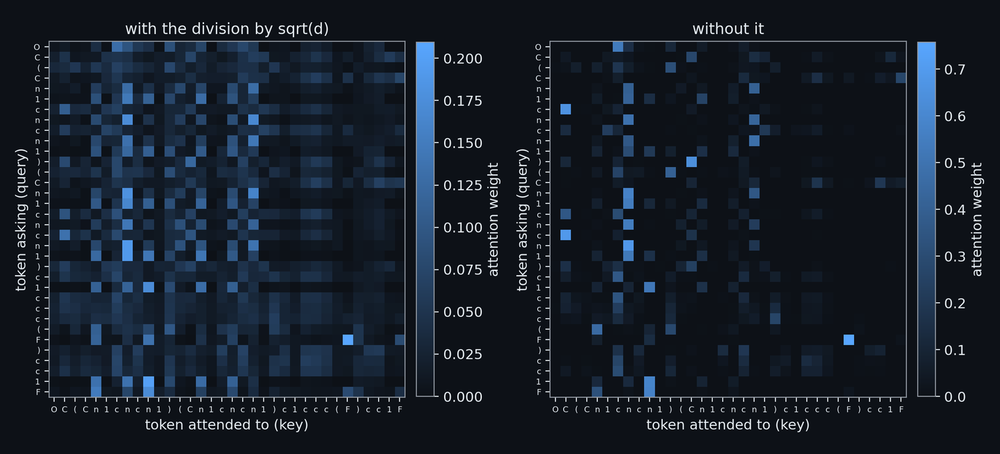

**Figure: Self-attention over the tokens of a SMILES string.** Scaled dot-product self-attention over the 34 tokens of the SMILES string of fluconazole. Every token is turned into a vector (an embedding plus a sinusoidal code of its position), projected into a query and a key, and the weight that token i gives to token j is the softmax over j of the dot product of its query with their keys divided by the square root of the dimension (16). The projections here are random with a fixed seed: the figure shows the computation, not what a trained model attends to (a trained model, ChemBERTa, is used in section 7.9). Every row sums to one (1.000 to 1.000). Left: with the division; right: without it, the dot products grow with the dimension, the softmax saturates and each token puts almost all of its weight on one other token (the largest weight in a row is 0.12 on average with the division and 0.43 without); each panel is shaded up to its own largest weight.

In [102]:
show_figure("ml_attention")

## 4.9 Principal component analysis, and tabular in-context learning

> **Field:** Machine learning · Mathematics (linear algebra)

**Principal component analysis** (PCA; Pearson, 1901; Hotelling, 1933) finds the directions in which a table varies most, so that a table of 217 correlated columns can be summarised by a few new columns that lose little. Take a table $X$ with $n$ rows and $p$ columns, each column with its mean subtracted (and, for the descriptors, divided by its standard deviation, so that no column dominates by its units). The variation along a direction given by a unit vector $w$ (length 1) is the variance of the projections $Xw$, which is
$w^{\top} C\, w$ with the **covariance matrix** $C = X^{\top}X/(n - 1)$, whose entry $C_{ab}$ says how much columns $a$ and $b$ vary together. To find the direction of the most variance, maximise $w^{\top}Cw$ subject to $w^{\top}w = 1$. With a multiplier $\lambda$ for the constraint, the maximum is where the gradient of $w^{\top}Cw - \lambda(w^{\top}w - 1)$ vanishes, $2Cw - 2\lambda w = 0$, that is

$$C\,w = \lambda\,w :$$

$w$ is an **eigenvector** of $C$ and the variance along it, $w^{\top}Cw = \lambda$, is its **eigenvalue**. The first principal component is the eigenvector with the largest eigenvalue; the next is the eigenvector of the next largest eigenvalue, which is automatically perpendicular to the first because $C$ is symmetric; and so on. The share of the total variance on component $k$ is $\lambda_k/\sum_l \lambda_l$, and keeping the first $m$ components keeps $\sum_{k \le m}\lambda_k/\sum_l \lambda_l$ of it. The cell does it with a matrix library routine for eigenvectors and checks the results against scikit-learn.

| quantity | value |
| --- | --- |
| largest difference in the explained-variance shares of the first 10 components, by hand against scikit-learn | 7.5e-16 |
| the first 10 eigenvectors are orthonormal (largest deviation of V'V from the identity) | 1.6e-15 |
| variance of the data along the first component, and its eigenvalue | 28.762 and 28.762 |
| share of the variance in the first 2, 10 and 64 components | 26.0%, 57.3%, 94.5% |

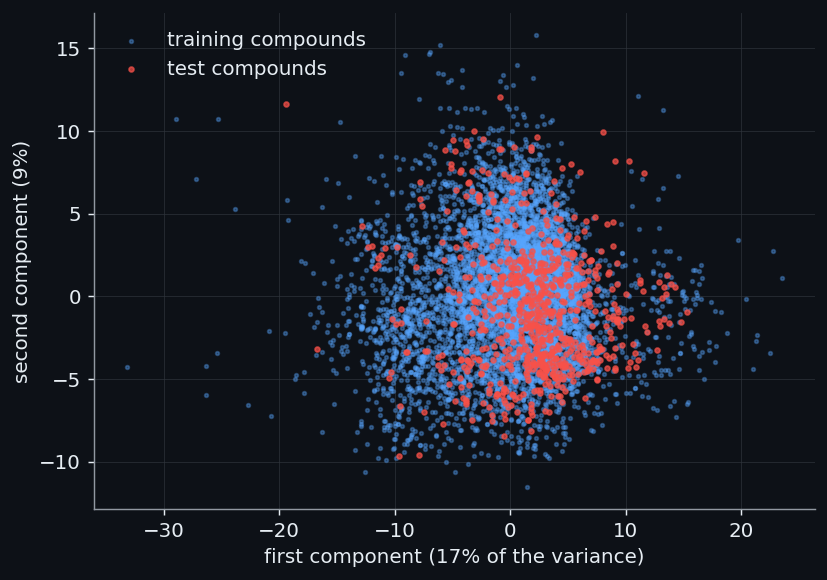

In [103]:
# Principal component analysis by hand on the 217 descriptors of all 6895 compounds (no label is used): standardise (clipped at 5 standard deviations), form the covariance matrix, take its eigenvectors, and
# compare with scikit-learn.
from sklearn.decomposition import PCA

desc_all = store["rdkit_desc"].astype(np.float64)
mu, sd = desc_all.mean(axis=0), desc_all.std(axis=0)
sd[sd == 0] = 1.0
Z = np.clip((desc_all - mu) / sd, -5, 5)
Zc = Z - Z.mean(axis=0)
covariance = Zc.T @ Zc / (len(Zc) - 1)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
explained = eigenvalues / eigenvalues.sum()
library = PCA(n_components=10).fit(Z)
scores_two = Zc @ eigenvectors[:, :2]
pca_rows = [{"quantity": "largest difference in the explained-variance shares of the first 10 components, by hand against scikit-learn", "value": f"{np.abs(explained[:10] - library.explained_variance_ratio_).max():.1e}"},
            {"quantity": "the first 10 eigenvectors are orthonormal (largest deviation of V'V from the identity)", "value": f"{np.abs(eigenvectors[:, :10].T @ eigenvectors[:, :10] - np.eye(10)).max():.1e}"},
            {"quantity": "variance of the data along the first component, and its eigenvalue", "value": f"{np.var(Zc @ eigenvectors[:, 0], ddof=1):.3f} and {eigenvalues[0]:.3f}"},
            {"quantity": "share of the variance in the first 2, 10 and 64 components", "value": f"{explained[:2].sum():.1%}, {explained[:10].sum():.1%}, {explained[:64].sum():.1%}"}]
show_table(pd.DataFrame(pca_rows))
fig, axis = plt.subplots(figsize=(6.5, 4.6))
n_train = len(train)
axis.scatter(scores_two[:n_train, 0], scores_two[:n_train, 1], s=4, color=theme["blue"], alpha=0.35, label="training compounds")
axis.scatter(scores_two[n_train:, 0], scores_two[n_train:, 1], s=7, color=theme["red"], alpha=0.7, label="test compounds")
axis.set(xlabel=f"first component ({explained[0]:.0%} of the variance)", ylabel=f"second component ({explained[1]:.0%})")
axis.legend(frameon=False)
tidy(axis, theme)
fig.tight_layout()
share_two, share_ten, share_64 = float(explained[:2].sum()), float(explained[:10].sum()), float(explained[:64].sum())

The first two components carry 26% of the variance of the descriptors, the first ten 57% and the first 64 95%; the hand calculation agrees with scikit-learn to rounding. The picture is another view of the covariate shift of section 2.7: the test compounds do not occupy the same part of the plane as the training compounds. PCA is used twice in the project: to reduce the 2048-number embedding of CheMeleon to 64 components (`cypmode/challenge/frozen_embeddings.py`; the components are fitted to the structures of
both files, which needs no label), and, in the form called *truncated SVD* (the **singular value decomposition**, a factorisation of the table itself that finds the same directions as the eigenvectors of $C$, here without subtracting the mean, which suits sparse count tables), to reduce the Morgan counts for the next model.

**Tabular in-context learning.** The models of this part are *fitted* to each training set: their parameters are adjusted by an optimisation. **TabICL** (Qu and co-workers, 2025; related to TabPFN, Hollmann and co-workers) is different: it is a **foundation model**, a model pretrained once on a very large collection of data and a general task and then reused for many specific tasks, here a transformer pretrained on millions of artificial tables generated from random processes, to read a table of labelled rows together with unlabelled rows to be predicted and to output the missing labels in one forward pass. The labelled rows are the **context**, in the way the text before a question is the context
for a language model, and no weight changes when a new table arrives: "training" is only the reading of the context, which is why the method is called *in-context learning*. Since the networks are pretrained on a wide range of tables, they are strong on small tables, such as the 2300 labelled compounds of one task. The project's candidate `tabicl_svd` (`cypmode/challenge/nested_runners_torch.py`) gives it 128 components of the truncated SVD of the logarithm of the Morgan counts together with the quantile-normalised descriptors, with two
ensemble members (an **ensemble** is a set of models of one kind, trained from different random starts, whose predictions are averaged) on the CPU. It runs in the separate torch environment, so the notebook does not run the candidate itself, only the toy of the cell below; its result is one of the candidates of the nested evaluation (section 8.1).

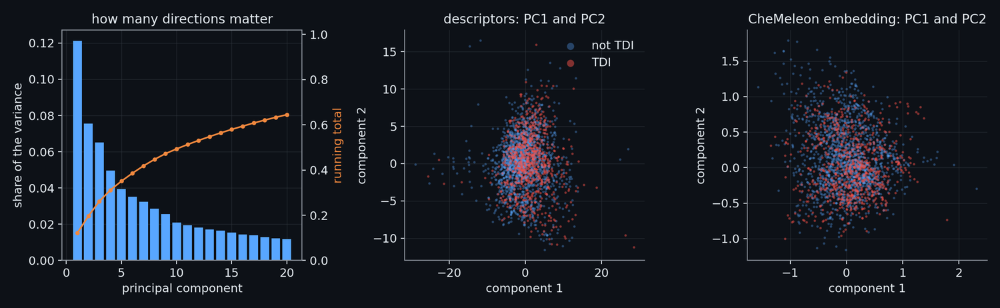

**Figure: Principal components of the descriptors and of the CheMeleon embedding.** Principal component analysis of real CYP3A4 compounds. Left: the share of variance carried by each of the first 20 principal components of the 200 standardised RDKit descriptors of 2334 compounds (bars) and the running total (line): the first component carries 12% and ten components carry 49%, so a few directions summarise many correlated columns. Middle: the compounds on the first two components of the descriptors, time-dependent inhibitors in red; the two classes overlap almost completely, which is why no model of the descriptors alone is accurate. Right: the first two components of the frozen CheMeleon embedding of the same compounds (the block of the feature store keeps the embedding as 64 principal components); the same picture, a little more structured, which is the information the embedding adds. Principal components are fitted without any label.

In [104]:
show_figure("ml_pca")

In [105]:
# In-context learning with the real model. TabICL (the pretrained table-reading network of this section) is given a table of 80 labelled points in two dimensions three times, with three different rules for the labels, and is asked
# for the probability of "positive" at four query points that lie away from every boundary. Nothing is trained: fit() only stores and preprocesses the table. The weights of the network are hashed after each of the three fits, and the
# predictions are compared with the rule of the table in use. The model runs in the environment .venv-ml, as the nested evaluation runs it.
import json
import os
import subprocess
import textwrap

ic_source = textwrap.dedent("""
    import hashlib
    import json
    import numpy as np
    from tabicl import TabICLClassifier
    rng = np.random.default_rng(3)
    context = rng.uniform(-1, 1, size=(80, 2))
    queries = np.array([[0.8, 0.8], [0.8, -0.8], [-0.8, 0.8], [-0.8, -0.8]])
    rules = {"A: positive when x1 > 0": context[:, 0] > 0, "B: positive when x2 > 0": context[:, 1] > 0, "C: positive when x1 < 0": context[:, 0] < 0}
    model = TabICLClassifier(device="cpu", n_estimators=2, random_state=0)
    def weights_hash():
        digest = hashlib.sha256()
        for name, tensor in sorted(model.model_.state_dict().items()):
            digest.update(name.encode() + tensor.detach().cpu().numpy().tobytes())
        return digest.hexdigest()[:16]
    out = {"queries": queries.tolist(), "n_context": len(context), "rules": {}, "weights_hash": []}
    for name, labels in rules.items():
        model.fit(context, labels.astype(int))
        out["weights_hash"].append(weights_hash())
        out["rules"][name] = model.predict_proba(queries)[:, 1].tolist()
    print(json.dumps(out))
""")
ic_run = subprocess.run([str(ROOT / ".venv-ml/bin/python"), "-c", ic_source], capture_output=True, text=True, timeout=900, env={**os.environ, "HF_HUB_OFFLINE": "1"})
assert ic_run.returncode == 0, ic_run.stderr[-400:]
ic = json.loads(ic_run.stdout.strip().splitlines()[-1])
ic_queries = np.array(ic["queries"])
ic_expected = {"A: positive when x1 > 0": ic_queries[:, 0] > 0, "B: positive when x2 > 0": ic_queries[:, 1] > 0, "C: positive when x1 < 0": ic_queries[:, 0] < 0}
ic_table = pd.DataFrame({"query (x1, x2)": [f"({a:+.1f}, {b:+.1f})" for a, b in ic["queries"]], **{f"P(positive), table {name}": p for name, p in ic["rules"].items()}})
show_table(ic_table, floatfmt=".3f")
ic_hash = ic["weights_hash"][0]
ic_total = sum(len(p) for p in ic["rules"].values())
ic_followed = sum(int(((np.array(p) > 0.5) == ic_expected[name]).sum()) for name, p in ic["rules"].items())
assert len(set(ic["weights_hash"])) == 1  # the parameters of the network are identical after the three tables
assert ic_followed == ic_total  # and every predicted class follows the rule of the table in use

| query (x1, x2) | P(positive), table A: positive when x1 > 0 | P(positive), table B: positive when x2 > 0 | P(positive), table C: positive when x1 < 0 |
| --- | --- | --- | --- |
| (+0.8, +0.8) | 1.000 | 1.000 | 0.000 |
| (+0.8, -0.8) | 1.000 | 0.000 | 0.000 |
| (-0.8, +0.8) | 0.000 | 1.000 | 1.000 |
| (-0.8, -0.8) | 0.000 | 0.000 | 1.000 |

**In-context learning, run for real.** The cell gives TabICL a table of 80 points in two dimensions whose labels follow a rule, three times, with a different rule each time, and asks for the probability of "positive" at four query points that lie away from every boundary. Nothing is trained: the call that hands over the table only stores and preprocesses it. The weights of the network are the same after all three tables (the cell hashes every parameter and gets 0a8fc10a516c4360 each time), and yet the predictions follow whichever rule the table shows: 12 of the 12 predicted classes agree with the rule of the table in use. A reader who knows how a model is fitted could take the result for a model that was fitted three times; it was not fitted at all, and everything it appears to have learned was in the table that it was shown. The task is not chemistry: it is the simplest case in which the answer is known, run with the model that the candidate `tabicl_svd` uses, on a toy and not on the compounds of the project.

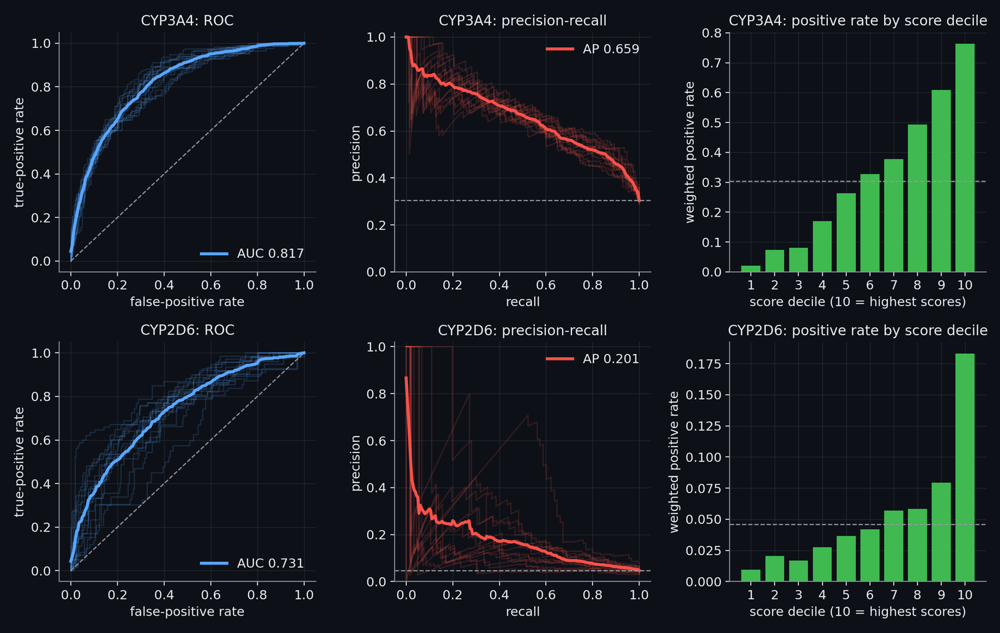

**Figure: ROC, precision-recall and score-decile lift of the final stack.** Receiver-operating-characteristic, precision-recall and reliability curves of the default stack on the held-out outer folds of the 5-fold design, rebuilt from the cached predictions with the evaluation weights of the final build (confident labels at z0 = 1.0, test-like similarity, prevalence shifted to the test set); one thin line per outer fold, the mean as the thick line, CYP3A4 mean outer AUC 0.817; CYP2D6 mean outer AUC 0.731, equal to the final build's numbers. The dashed line of the precision-recall panel is the weighted prevalence. The right panels show the weighted positive rate in each tenth of the stack's scores, pooled over the outer folds. The raw stack score is not a probability (the audit measures the CYP2D6 raw probabilities as unusable, which is why the submitted probabilities are isotonic-calibrated), so ranking is shown rather than calibration.

In [106]:
show_figure("ml_stack_curves")

## 4.10 Metrics: how a model is judged

> **Field:** Statistics · Machine learning

A model's output has to be turned into numbers that say how good it is. Which number depends on what the model will be used for, and the choice matters because the challenge's labels are unbalanced (section 2.10).

**The confusion matrix and the numbers computed from it.** If a model's scores are turned into calls by a threshold, every compound falls into one of four cells: true positive (TP, called positive and is), false positive (FP), false negative (FN) and true negative (TN). From them: **accuracy** $(TP + TN)/n$, **precision** $TP/(TP + FP)$ (how much to trust a positive call), **recall** $TP/(TP + FN)$ (how many of the positives are found) and **F1**, their harmonic mean $2PR/(P + R)$.
Accuracy is misleading when one class is rare: a model that calls everything negative has an accuracy of $1 - \pi$, with $\pi$ the positive rate, and finds nothing. The **Matthews correlation coefficient** (MCC; Matthews, 1975) uses all four cells:

$$\mathrm{MCC} \;=\; \frac{TP\cdot TN - FP\cdot FN}{\sqrt{(TP + FP)(TP + FN)(TN + FP)(TN + FN)}} .$$

It is the ordinary (Pearson) correlation between two yes/no variables, the label $y$ and the call $\hat y$, which is why it is 0 for a model that is no better than chance, 1 for a perfect one and $-1$ for a perfectly wrong one. To see this, call $n = TP + FP + FN + TN$. The covariance of $y$ and $\hat y$ is $E[y\hat y] - E[y]E[\hat y] = TP/n - (TP + FN)(TP + FP)/n^2 = (TP\cdot TN - FP\cdot FN)/n^2$, because $n\,TP - (TP + FN)(TP + FP) = TP\cdot TN - FP\cdot FN$ when $n$ is expanded; and
the variance of a yes/no variable with probability $P$ of yes is $P(1 - P)$, so the product of the two standard deviations is $\sqrt{(TP + FN)(TN + FP)(TP + FP)(TN + FN)}/n^2$; the ratio is the formula. **The challenge scores the MCC of the calls**, so the TDI track is judged at one chosen threshold. The cell computes all of them for a real set of out-of-fold predictions.

In [107]:
# Out-of-fold probabilities of the project's deep LightGBM on feature set A (every compound is scored by a model that did not see it), and the numbers that describe them as calls: the 37 % of compounds with
# the highest scores are called positive (the call rate the project's CYP3A4 model uses, section 8.4).
from cypmode.challenge.nested_runners import LGBM_PRESETS

oof = np.zeros(len(y_ml))
for fit_rows, held in folds_ml:
    oof[held] = LGBMClassifier(verbose=-1, n_jobs=2, random_state=0, **LGBM_PRESETS["deep"]).fit(set_a[fit_rows], y_ml[fit_rows]).predict_proba(set_a[held])[:, 1]
called = oof >= np.quantile(oof, 1 - 0.37)
TP, FP = int((called & (y_ml == 1)).sum()), int((called & (y_ml == 0)).sum())
FN, TN = int((~called & (y_ml == 1)).sum()), int((~called & (y_ml == 0)).sum())
n_all = TP + FP + FN + TN
accuracy, precision, recall = (TP + TN) / n_all, TP / (TP + FP), TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
mcc_formula = (TP * TN - FP * FN) / np.sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN))
from sklearn.metrics import matthews_corrcoef
mcc_library, mcc_pearson = matthews_corrcoef(y_ml, called.astype(int)), np.corrcoef(y_ml, called.astype(int))[0, 1]
show_table(pd.DataFrame([{"": "called positive", "is positive": TP, "is negative": FP}, {"": "called negative", "is positive": FN, "is negative": TN}]))
metric_rows = [{"metric": "accuracy (TP + TN) / n", "value": accuracy}, {"metric": "precision TP / (TP + FP)", "value": precision}, {"metric": "recall TP / (TP + FN)", "value": recall}, {"metric": "F1, the harmonic mean of precision and recall", "value": f1},
               {"metric": "MCC by the formula", "value": mcc_formula}, {"metric": "MCC by scikit-learn", "value": mcc_library}, {"metric": "Pearson correlation of the label with the call", "value": mcc_pearson}]
show_table(pd.DataFrame(metric_rows), floatfmt=".4f")
share_called, share_positive = float(called.mean()), float(y_ml.mean())
accuracy_if_all_negative = 1 - share_positive

|  | is positive | is negative |
| --- | --- | --- |
| called positive | 470 | 394 |
| called negative | 294 | 1176 |

| metric | value |
| --- | --- |
| accuracy (TP + TN) / n | 0.7052 |
| precision TP / (TP + FP) | 0.5440 |
| recall TP / (TP + FN) | 0.6152 |
| F1, the harmonic mean of precision and recall | 0.5774 |
| MCC by the formula | 0.3540 |
| MCC by scikit-learn | 0.3540 |
| Pearson correlation of the label with the call | 0.3540 |

The 37 % of compounds with the highest scores are called positive: 470 true positives, 394 false positives, 294 false negatives and 1176 true negatives. The accuracy is 0.705, against 0.673 for calling every compound negative: accuracy would not have told the model from the useless one. The MCC computed by the formula, by the library and as a correlation coefficient are the same number (0.3540, 0.3540, 0.3540).

**Threshold-free metrics.** Calls depend on a threshold, which has to be chosen, while the ranking that the model produces does not. The **ROC curve** (receiver operating characteristic) plots, as the threshold runs from high to low, the **true-positive rate** (TPR, also called recall) against the **false-positive rate** (FPR) $FP/(FP + TN)$; a ranking of the positives above the negatives gives a curve that hugs the upper left corner, a random ranking the diagonal. The **area under the ROC curve** (AUC) has a meaning that makes it easy to interpret. With $S^{+}$ and $S^{-}$ the scores of a random positive and a random negative compound, and threshold $\tau$, the true-positive rate is
$P(S^{+} > \tau)$ and the false-positive rate is $P(S^{-} > \tau)$, so that, writing $f^{-}$ for the density of the negative scores,

$$\mathrm{AUC} \;=\; \int \mathrm{TPR}\; d(\mathrm{FPR}) \;=\; \int P(S^{+} > \tau)\,f^{-}(\tau)\,d\tau \;=\; P(S^{+} > S^{-}) :$$

the AUC is the probability that a random positive compound is scored above a random negative one (with ties counting half), and this is the **Mann-Whitney** statistic (Mann and Whitney, 1947) divided by the number of pairs. It is 0.5 for chance and independent of the positive rate. The **precision-recall curve** plots precision against recall, and the **average precision** (AP) is its area as a step sum, $\mathrm{AP} = \sum_n (R_n - R_{n-1})P_n$, which for a ranking without ties is the average, over the positive compounds, of the precision at the position of each one. Unlike the AUC, it depends on the positive rate:
a random ranking has an AP equal to $\pi$. The cell computes the AUC three ways and the AP two ways.

AUC by the trapezoid rule 0.75171; as P(positive scored above negative) 0.75171; scikit-learn 0.75171
average precision by the formula 0.57288; scikit-learn 0.57288; the value for a model that ranks at random is the positive rate, 0.327


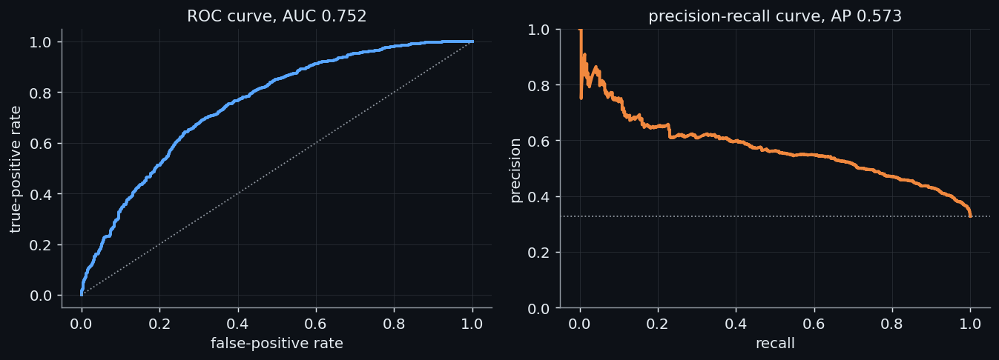

In [108]:
# The ROC curve, the area under it computed three ways, and the precision-recall curve with average precision. The three ways: the trapezoid rule on the curve; the probability that a random positive is scored
# above a random negative (all positive-negative pairs, ties counted half); and scikit-learn.
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

fpr, tpr, _ = roc_curve(y_ml, oof)
auc_trapezoid = float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))
positives, negatives = oof[y_ml == 1], oof[y_ml == 0]
pair_compare = positives[:, None] - negatives[None, :]
auc_pairs = float((pair_compare > 0).mean() + 0.5 * (pair_compare == 0).mean())
auc_library = float(roc_auc_score(y_ml, oof))
order = np.argsort(-oof, kind="stable")
hits = y_ml[order]
precision_at_k = np.cumsum(hits) / np.arange(1, len(hits) + 1)
ap_formula = float((precision_at_k * hits).sum() / hits.sum())                  # the mean, over the positives, of the precision at the rank of each positive
ap_library = float(average_precision_score(y_ml, oof))
print(f"AUC by the trapezoid rule {auc_trapezoid:.5f}; as P(positive scored above negative) {auc_pairs:.5f}; scikit-learn {auc_library:.5f}")
print(f"average precision by the formula {ap_formula:.5f}; scikit-learn {ap_library:.5f}; the value for a model that ranks at random is the positive rate, {y_ml.mean():.3f}")
precision_curve, recall_curve, _ = precision_recall_curve(y_ml, oof)
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.9))
left.plot(fpr, tpr, color=theme["blue"], lw=2.2)
left.plot([0, 1], [0, 1], color=theme["muted"], ls=":", lw=1)
left.set(xlabel="false-positive rate", ylabel="true-positive rate", title=f"ROC curve, AUC {auc_library:.3f}")
right.plot(recall_curve, precision_curve, color=theme["orange"], lw=2.2)
right.axhline(y_ml.mean(), color=theme["muted"], ls=":", lw=1)
right.set(xlabel="recall", ylabel="precision", title=f"precision-recall curve, AP {ap_library:.3f}", ylim=(0, 1))
for axis in (left, right):
    tidy(axis, theme)
fig.tight_layout()

The three AUCs agree (0.75171 by the trapezoid rule, 0.75171 as a probability over all pairs, 0.75171 from the library), and so do the two APs (0.57288 and 0.57288). **Why the MCC of a rare class is low even for a good ranking.** The AUC does not depend on the positive rate, but the MCC at the best threshold does, and so does the AP. The cell holds the ranking quality fixed (an AUC of 0.75) and changes only the positive rate:

In [109]:
# The same ranking quality at different positive rates. Scores of positives are N(m, 1) and of negatives N(0, 1), with m chosen so that the AUC is 0.75 whatever the positive rate (AUC = Phi(m / sqrt 2)).
# For each rate, the best MCC over all thresholds and the average precision are computed on 400000 simulated compounds.
from scipy.stats import norm

m_shift = np.sqrt(2) * norm.ppf(0.75)
rng = np.random.default_rng(8)
prev_rows = []
for rate in (0.5, 0.3, 0.2, 0.07):
    n_sim = 400_000
    labels_sim = rng.random(n_sim) < rate
    scores_sim = rng.normal(size=n_sim) + m_shift * labels_sim
    order_sim = np.argsort(-scores_sim)
    sorted_labels = labels_sim[order_sim]
    tp_cum = np.cumsum(sorted_labels)
    fp_cum = np.cumsum(~sorted_labels)
    fn_cum, tn_cum = sorted_labels.sum() - tp_cum, (~sorted_labels).sum() - fp_cum
    denominator = np.sqrt((tp_cum + fp_cum) * (tp_cum + fn_cum) * (tn_cum + fp_cum) * (tn_cum + fn_cum).astype(float))
    with np.errstate(invalid="ignore", divide="ignore"):
        mcc_curve = (tp_cum * tn_cum - fp_cum * fn_cum) / denominator
    prev_rows.append({"positive rate": rate, "AUC": float(roc_auc_score(labels_sim, scores_sim)), "best MCC over all thresholds": float(np.nanmax(mcc_curve)),
                      "average precision": float(average_precision_score(labels_sim, scores_sim)), "average precision of a random ranking": rate})
show_table(pd.DataFrame(prev_rows), floatfmt=".3f")
mcc_at_rate = {r["positive rate"]: r["best MCC over all thresholds"] for r in prev_rows}

| positive rate | AUC | best MCC over all thresholds | average precision | average precision of a random ranking |
| --- | --- | --- | --- | --- |
| 0.500 | 0.750 | 0.367 | 0.742 | 0.500 |
| 0.300 | 0.751 | 0.347 | 0.569 | 0.300 |
| 0.200 | 0.750 | 0.310 | 0.446 | 0.200 |
| 0.070 | 0.750 | 0.216 | 0.211 | 0.070 |

The same ranking quality gives a best MCC of 0.37 at a positive rate of 0.5, 0.35 at 0.3 (about that of CYP3A4 on the test set) and only 0.22 at 0.07 (about that of CYP2D6): the low scores of the second enzyme on the board are in part a consequence of its rarity and not only of a weaker model (section 8.7). A number is comparable only to numbers at the same positive rate.

**Probabilities as probabilities.** A model that outputs 0.8 should be right about 80 % of the time on compounds to which it gives 0.8. That property is **calibration**, and it matters when a probability is used for anything other than a ranking. Three numbers measure it. The **Brier score** (Brier, 1950) is the mean squared difference between probability and label, $\mathrm{BS} = \frac1n\sum_i (p_i - y_i)^2$; a model that always says the positive rate $\pi$ has $\mathrm{BS}_0 = \pi(1 - \pi)$, and
$1 - \mathrm{BS}/\mathrm{BS}_0$ is the skill relative to that. The **expected calibration error** divides the probabilities into bins (here ten) and averages the gap between the mean probability and the observed positive share in a bin, weighted by the size of the bin, $\mathrm{ECE} = \sum_b (n_b/n)\,\lvert \bar p_b - \bar y_b\rvert$. The **calibration slope** is the coefficient $\beta$ of a logistic regression of the label on the logit of the probability, $P(y = 1) = \sigma(\alpha + \beta\,\mathrm{logit}(p))$; for a calibrated model $\alpha = 0$ and $\beta = 1$, a slope below 1 means the model is
over-confident (its probabilities are too extreme) and above 1 under-confident. The project's rule for a usable probability is an ECE of at most 0.05 and a slope between 0.8 and 1.2 (section 8.5).

In [110]:
# Probabilities as probabilities. The Brier score (mean squared difference between the probability and the label) against that of always predicting the positive rate; the expected calibration error with ten
# bins; and the calibration slope, the coefficient of a logistic regression of the label on the logit of the probability (1 for a calibrated model). The project's own function is called as well.
from cypmode.challenge.calibration_experiment import calibration_metrics

brier = float(np.mean((oof - y_ml) ** 2))
brier_reference = float(y_ml.mean() * (1 - y_ml.mean()))
bin_index = np.minimum((oof * 10).astype(int), 9)
bin_rows, ece_by_hand = [], 0.0
for b in range(10):
    inside = bin_index == b
    if inside.any():
        ece_by_hand += inside.mean() * abs(oof[inside].mean() - y_ml[inside].mean())
        bin_rows.append({"probability bin": f"{b / 10:.1f} to {(b + 1) / 10:.1f}", "compounds": int(inside.sum()), "mean predicted probability": float(oof[inside].mean()), "share that are positive": float(y_ml[inside].mean())})
show_table(pd.DataFrame(bin_rows), floatfmt=".3f")
project = calibration_metrics(y_ml.astype(float), oof, np.ones(len(oof)))
print(f"Brier score {brier:.4f} against {brier_reference:.4f} for the constant prediction (skill {1 - brier / brier_reference:.1%}); ECE by hand {ece_by_hand:.4f}, by the project's function {project['ece']:.4f}; calibration slope {project['slope']:.2f}, intercept {project['intercept']:.2f}")
brier_skill, ece_value, slope_value = 1 - brier / brier_reference, project["ece"], project["slope"]
calibration_verdict = "meet" if (ece_value <= 0.05 and 0.8 <= slope_value <= 1.2) else "do not meet"

Brier score 0.1949 against 0.2202 for the constant prediction (skill 11.5%); ECE by hand 0.0986, by the project's function 0.0986; calibration slope 0.55, intercept -0.01


| probability bin | compounds | mean predicted probability | share that are positive |
| --- | --- | --- | --- |
| 0.0 to 0.1 | 875 | 0.039 | 0.126 |
| 0.1 to 0.2 | 352 | 0.147 | 0.287 |
| 0.2 to 0.3 | 254 | 0.248 | 0.346 |
| 0.3 to 0.4 | 179 | 0.345 | 0.486 |
| 0.4 to 0.5 | 169 | 0.449 | 0.462 |
| 0.5 to 0.6 | 145 | 0.548 | 0.531 |
| 0.6 to 0.7 | 120 | 0.648 | 0.550 |
| 0.7 to 0.8 | 117 | 0.751 | 0.607 |
| 0.8 to 0.9 | 92 | 0.849 | 0.652 |
| 0.9 to 1.0 | 31 | 0.931 | 0.839 |

For these out-of-fold predictions the Brier score is 0.1949 against 0.2202 for the constant prediction (a skill of 11.5%), the ECE is 0.099 and the calibration slope is 0.55, and the project's own function gives the same ECE as the hand calculation. The raw probabilities of the model do not meet the project's rule (an ECE of at most 0.05 and a slope between 0.8 and 1.2), which is why calibration is a separate step of the final model (section 8.5). These are the numbers by which every model in the rest of the notebook is judged, always on compounds that the model did not see.

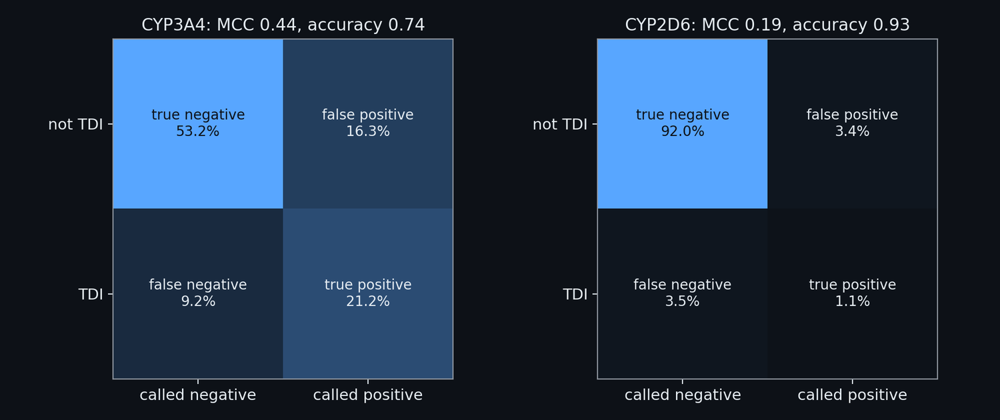

**Figure: The confusion matrix and the MCC of the default stack.** The confusion matrix of the default stack at the share of calls that the final build uses, from the held-out outer folds of the 5-fold design, as shares of the weighted scored population (the evaluation weights of the final build, confident labels at z0 = 1.0). Each cell is the mean over the outer folds of a share of all compounds, and the MCC in the title is the mean of the MCC of the folds (the way the final build reports it); the Matthews correlation coefficient of a fold is (TP x TN - FP x FN) divided by the square root of the product of the four marginal totals, so that it is zero for a model that predicts one class for everything and uses all four cells. CYP3A4: top 40.3% called, accuracy 0.74, MCC 0.440 (the table of section 6 gives 0.442, where the rate is transferred inside each fold and not fixed), and calling everything negative would give accuracy 0.70 and MCC 0; CYP2D6: top 5.9% called, accuracy 0.93, MCC 0.191 (the table of section 6 gives 0.167, where the rate is transferred inside each fold and not fixed), and calling everything negative would give accuracy 0.95 and MCC 0. Accuracy rewards the majority class on an imbalanced label; the MCC does not, which is why it is the metric of the challenge.

In [111]:
show_figure("ml_confusion_mcc")

# Part V. The Type II motif screen

Parts I to IV gave the chemistry, the data, the numbers that describe a molecule and the machine learning that turns such numbers into a prediction. Before the project measured anything with the careful procedures of Part VI, it began with something much smaller
and older than a learned model: a rule written by a chemist, applied by a program. This part tells that first piece of work in full, for three reasons. It is the origin of two of the feature blocks that every later model receives (the motif block and the amine alert, section 3.4). It
is the only part of the project that needs no training at all, so every claim about it can be tested completely and the logic of the test can be seen without the machinery of cross-validation. And it introduces, on a small scale, the habits of the whole project: a claim is tested on
data that did not shape it, the size of the effect is reported next to its probability, and the text says what the test cannot show.

The part answers one question, from five directions. *Does a molecule that carries a nitrogen able to bind the heme iron behave differently from one that does not?* Section 5.1 turns the chemistry of section 1.9 into a pattern that a program can search for. Section 5.2 builds the second rule, for
the amines that inactivate the enzyme by a different route (section 1.10). Section 5.3 asks how many of the known inhibitors of five enzymes carry the pattern. Section 5.4 asks whether the pattern goes with potency, on a screen of more than a thousand compounds that the rule never saw. Section 5.5 asks
whether a structure predicted by Boltz-2 puts the nitrogen where the chemistry says it should be, and section 5.6 adds two measurements on the same structures, how deeply the molecule is buried and how large its pocket is. Section 5.7 compares the rule with six drugs whose time-dependent inhibition
was measured, and section 5.8 describes the small web application in which the original screen can be used.

What this part hands on: the patterns of 5.1 and 5.2 reappear as feature blocks in Part VII (the early ablation of the motif and amine features, 7.2); the distance from the iron to the nitrogen of 5.5 is the quantity that Part XI measures for every pose; the two pocket measurements of 5.6 are the structural
evidence of section 7.10. A reader who wants only the final models can read 5.1 and 5.2, which say what the two blocks mean, and return to the rest when a later part refers to it.

## 5.1 The idea: a nitrogen that can bind the iron, written as a pattern

> **Field:** Chemistry · Cheminformatics

*Where this section sits:* section 1.9 explained, in words, why an aromatic nitrogen can take the place of the water on the heme iron. This section turns that sentence into something a program can apply to a million molecules in seconds. The next section adds a second rule, and section 3.4
shows how both became columns of the feature store.

**A screen** is a fast rule that looks at every molecule of a collection and flags those worth a closer look; it is cheap because it asks only a yes or no question of the structure of the molecule, and it does not try to predict how strongly anything binds. The question of this screen is: does the molecule contain one
of six small groups of atoms, each of which has a nitrogen of the kind that binds the heme iron? The groups are those that textbooks of drug metabolism name as the classical Type II binders (de Groot, 2006; Correia and Ortiz de Montellano, 2005): the **imidazole** (a flat ring of five atoms, three of them
carbon and two nitrogen, the two nitrogens separated by one carbon), the **1,2,4-triazole** and the **1,2,3-triazole** (rings of five atoms with three nitrogens, arranged differently), the **pyridine** (a flat ring of six atoms with one nitrogen) and the **thiazole** (five atoms with one sulfur and one nitrogen).
Ketoconazole carries an imidazole, fluconazole and itraconazole a triazole, and ritonavir a thiazole; these antifungal and antiviral drugs are classical Type II inhibitors of CYP3A4.

**How a group of atoms is written.** The notation of section 2.1 for a molecule, SMILES, has a sister notation for a *pattern*, **SMARTS** (section 0.2). Both describe a graph, but a SMILES string describes the one graph of one molecule, and a SMARTS string describes a small graph whose atoms and bonds may be described loosely,
so that the pattern fits many molecules. The letters are those of SMILES: a lower-case `c` is an aromatic carbon and `n` an aromatic nitrogen; an upper-case `N` is a nitrogen that is not aromatic; a square bracket gives the atom a fuller description, `[nH]` being an aromatic nitrogen that carries one hydrogen. A digit marks a
ring: the atom that carries it and the later atom that carries the same digit are joined by a bond, which closes the ring. So `c1cnc[nH]1` reads: an aromatic carbon (which opens ring 1), another carbon, a nitrogen, a carbon, and a nitrogen carrying a hydrogen that closes ring 1; five atoms in a ring, two of them nitrogen with one
carbon between them, which is the imidazole. The pattern `c1cncn1` is the same ring without the demand that either nitrogen carry a hydrogen: its `n` matches an aromatic nitrogen whatever else is attached, so it fits the imidazoles whose nitrogen carries a substituent as well as those that carry a hydrogen. The first cell prints
all six patterns, built into small graphs by the toolkit, and counts how many compounds of the two challenge files (the training file and the blinded test file, section 2.2) each one matches.

In [112]:
# The six patterns of the motif screen, read back from the project's own table (cypmode/metrics/motifs.py): what each pattern is made of, and on how many compounds of the challenge it matches.
import pandas as pd
from rdkit import Chem

from cypmode.metrics.motifs import TYPE_II_MOTIFS, detect_motifs

train_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")
test_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TEST-BLINDED.csv")
challenge = pd.concat([train_file[["Molecule_Name", "SMILES"]], test_file], ignore_index=True)
import time

started = time.perf_counter()
challenge["motifs"] = [detect_motifs(s) for s in challenge["SMILES"]]
seconds_for_screen = time.perf_counter() - started
pattern_rows = []
for name, smarts in TYPE_II_MOTIFS.items():
    pattern = Chem.MolFromSmarts(smarts)
    atoms = " ".join(a.GetSmarts().replace("[n&H1]", "[nH]") for a in pattern.GetAtoms())
    pattern_rows.append({"pattern": name, "SMARTS": smarts, "atoms of the pattern": atoms, "atoms": pattern.GetNumAtoms(), "bonds": pattern.GetNumBonds(),
                         "compounds that match": int(sum(name in m for m in challenge["motifs"]))})
show_table(pd.DataFrame(pattern_rows))
n_challenge, n_with_motif = len(challenge), int(challenge["motifs"].apply(bool).sum())
n_train_file, n_test_file = len(train_file), len(test_file)
share_with_motif = n_with_motif / n_challenge

| pattern | SMARTS | atoms of the pattern | atoms | bonds | compounds that match |
| --- | --- | --- | --- | --- | --- |
| imidazole | c1cnc[nH]1 | c c n c [nH] | 5 | 5 | 230 |
| imidazole_Nsub | c1cncn1 | c c n c n | 5 | 5 | 827 |
| triazole_1_2_4 | c1ncnn1 | c n c n n | 5 | 5 | 336 |
| triazole_1_2_3 | c1cnnn1 | c c n n n | 5 | 5 | 256 |
| pyridine | c1ccncc1 | c c c n c c | 6 | 6 | 1753 |
| thiazole | c1cscn1 | c c s c n | 5 | 5 | 464 |

**What "matches" means.** Let $x$ be a molecule, seen as a graph whose nodes are its atoms and whose edges are its bonds (section 2.1), and $p$ a pattern, a smaller graph of the same kind. The pattern $p$ **matches** $x$ when its atoms can be laid on a choice of atoms of $x$, no two on the
same atom, so that every atom of $p$ lies on an atom of the kind it describes and every bond of $p$ lies on a bond of $x$ of the kind it describes. (The name in graph theory is *subgraph isomorphism*; the toolkit searches for such a laying-on by trying atom after atom and abandoning a try as soon as a bond fails, which for patterns of five or six atoms is fast: reading the 6,895 structures and applying the six patterns to each took 0.5 seconds in the cell above.)
The screen's call for a molecule $x$ is a single number $m(x)$, with $p_1, \dots, p_6$ the six patterns and the index $j$ running over them:

$$m(x) \;=\; \max_{j=1,\dots,6}\; \mathbb{1}\bigl[\, p_j \text{ matches } x \,\bigr],$$

where the symbol $\mathbb{1}[\cdot]$, the **indicator**, is 1 when the statement inside the brackets is true and 0 when it is false. In words: $m(x)=1$ when at least one of the six patterns matches. Of the 6,895 compounds of the challenge, 3,107
(45%) are flagged. That is a large share, and it is the first thing to understand about this screen: the library of the challenge is full of nitrogen-containing aromatic rings, because such rings are common in drugs and in the molecules built for drug discovery, so a flag by itself does not
distinguish most compounds from the rest. The flag is useful only to the extent that it goes with something that matters, and the following sections measure whether it does.

**What the patterns cannot see.** A pattern describes which atoms are connected to which; it knows nothing about the electrons. A nitrogen can bind the iron only if its lone pair is free. In an aromatic ring of five atoms such as the imidazole, one nitrogen puts its lone pair into the electrons shared round the ring (the pyrrole-type nitrogen, which carries a hydrogen or a substituent as its third neighbour) and so cannot use
it; the other nitrogen (the pyridine-type nitrogen, with two neighbours and no hydrogen) keeps its lone pair in the plane of the ring, free to bind, and that is the one that goes to the iron. The pattern `c1cncn1` matches both nitrogens without distinction. The next cell makes the point with small molecules whose chemistry is known, and counts, for each probe,
how many of the matched nitrogens have a free lone pair (the definition is two neighbours and no hydrogen, which is chemically a simplification, but a useful one).

In [113]:
# Probing the patterns with small molecules whose chemistry is known. For every probe the screen's call, and the nitrogen atoms that the matched patterns contain, split by what kind of nitrogen they are:
# a "pyridine-type" aromatic nitrogen has two neighbours and no hydrogen, so its lone pair lies in the plane of the ring and is free; a "pyrrole-type" one has a third neighbour (a hydrogen or a substituent)
# and its lone pair is part of the ring's shared electrons.
probes = {"imidazole": "c1cnc[nH]1", "1-methylimidazole": "Cn1ccnc1", "1,2,4-triazole": "c1ncn[nH]1", "pyridine": "c1ccncc1", "thiazole": "c1cscn1", "2-pyridone": "O=c1cccc[nH]1",
          "pyrrole": "c1cc[nH]c1", "benzene": "c1ccccc1", "aniline": "Nc1ccccc1"}

def matched_nitrogens(smiles):
    """Indices of the nitrogen atoms that belong to at least one match of the six patterns."""
    mol = Chem.MolFromSmiles(smiles)
    found = set()
    for smarts in TYPE_II_MOTIFS.values():
        for match in mol.GetSubstructMatches(Chem.MolFromSmarts(smarts)):
            found |= {i for i in match if mol.GetAtomWithIdx(i).GetSymbol() == "N"}
    return mol, sorted(found)

def free_lone_pair(atom):
    """An aromatic nitrogen with two heavy neighbours and no hydrogen: the lone pair is in the plane of the ring and available."""
    return atom.GetIsAromatic() and atom.GetDegree() == 2 and atom.GetTotalNumHs() == 0

probe_rows = []
for label, smiles in probes.items():
    mol, nitrogens = matched_nitrogens(smiles)
    free = sum(free_lone_pair(mol.GetAtomWithIdx(i)) for i in nitrogens)
    probe_rows.append({"molecule": label, "SMILES": smiles, "patterns that match": ", ".join(detect_motifs(smiles)) or "none", "matched nitrogens": len(nitrogens),
                       "of them with a free lone pair": free})
show_table(pd.DataFrame(probe_rows))
pyridone_calls = next(r for r in probe_rows if r["molecule"] == "2-pyridone")
pyrrole_calls = next(r for r in probe_rows if r["molecule"] == "pyrrole")

| molecule | SMILES | patterns that match | matched nitrogens | of them with a free lone pair |
| --- | --- | --- | --- | --- |
| imidazole | c1cnc[nH]1 | imidazole, imidazole_Nsub | 2 | 1 |
| 1-methylimidazole | Cn1ccnc1 | imidazole_Nsub | 2 | 1 |
| 1,2,4-triazole | c1ncn[nH]1 | triazole_1_2_4 | 3 | 2 |
| pyridine | c1ccncc1 | pyridine | 1 | 1 |
| thiazole | c1cscn1 | thiazole | 1 | 1 |
| 2-pyridone | O=c1cccc[nH]1 | pyridine | 1 | 0 |
| pyrrole | c1cc[nH]c1 | none | 0 | 0 |
| benzene | c1ccccc1 | none | 0 | 0 |
| aniline | Nc1ccccc1 | none | 0 | 0 |

The imidazole and 1-methylimidazole each have a nitrogen with a free lone pair and one without, as the chemistry says, and the pattern matches both. Pyridine, thiazole and the triazole each match with at least one free nitrogen. Two probes show the weakness. The pyridine pattern matches 2-pyridone (1 matched nitrogen,
0 of them with a free lone pair) because the toolkit, like the chemist, treats the ring as aromatic, but the nitrogen of a pyridone carries a hydrogen and uses its lone pair in the ring; and pyrrole, which has one nitrogen of the same kind, is not matched at all only because every pattern for a five-atom ring demands a second heteroatom (a second nitrogen or a sulfur). So a match is a clue
and not a proof. The cell below asks how often it matters on the real collection: among the compounds that the screen flags, how many are flagged only through nitrogens that have no free lone pair.

In [114]:
# The same question over the whole challenge: of the compounds that the screen flags, how many are flagged only through nitrogens that have no free lone pair?
rows_flagged = challenge[challenge["motifs"].apply(bool)]
free_counts = []
for smiles in rows_flagged["SMILES"]:
    mol, nitrogens = matched_nitrogens(smiles)
    free_counts.append(sum(free_lone_pair(mol.GetAtomWithIdx(i)) for i in nitrogens))
free_counts = np.array(free_counts)
n_no_free = int((free_counts == 0).sum())
population_rows = [{"compounds flagged by the screen": len(rows_flagged), "with at least one matched nitrogen that has a free lone pair": int((free_counts > 0).sum()),
                    "flagged only through nitrogens without one": n_no_free, "share": n_no_free / len(rows_flagged)}]
show_table(pd.DataFrame(population_rows))
share_no_free = n_no_free / len(rows_flagged)

| compounds flagged by the screen | with at least one matched nitrogen that has a free lone pair | flagged only through nitrogens without one | share |
| --- | --- | --- | --- |
| 3107 | 2930 | 177 | 0.057 |

Of the 3,107 flagged compounds, 177 (5.7%) are flagged only through nitrogens without a free lone pair. These are the compounds for which the flag is most likely to be wrong chemically; the screen as it was written and used does not remove them, and the
section on the structures (5.5) is where such cases show themselves, because a predicted structure places the nitrogen at a measured distance from the iron and a nitrogen that cannot bind does not go there.

*On what actually ran.* The screen of the project (`cypmode/metrics/motifs.py`) is the six patterns and the function that reports which of them match: `detect_motifs` returns the names, and `classify_mechanism` turns a non-empty list into the sentence "Type II (heme-coordinating motif present)" and an empty list into "No coordinating motif detected (Type I or non-classical)".
It does not test the lone pair, as the probes above show; it does not know where in the pocket the molecule will sit; and the sentence it prints is a statement about a *capability*. The same six patterns are used unchanged by the original panel analysis (5.3), by the potency check (5.4), by the structural check (5.5) and by the early feature blocks of Part VII.

## 5.2 The trialkylamine alert, and the false positives it had to exclude

> **Field:** Chemistry · Cheminformatics

*Where this section sits:* the screen of 5.1 looks for molecules that bind the iron themselves. Section 1.10 described a second way in which a molecule can switch an enzyme off, with no group that binds the iron to begin with: the enzyme itself turns an amine into something that does. This section
builds the pattern for that route. It was written second, as a separate screen (`cypmode/metrics/amines.py`), and it is a good case study, because the first version of the pattern flagged almost every compound of the collection and the work consisted in finding out, with chemistry and with data, what it had to leave out.

**The chemistry.** A nitrogen with three single bonds and a lone pair is an **amine**: the three bonds point to three corners of a pyramid and the lone pair to the fourth. Call a carbon **alkyl** when its bonds are all single and it is not part of an aromatic ring. A **trialkylamine**, in the sense used here, is an amine whose nitrogen is joined to alkyl
carbons and, at most, to one hydrogen; the name is a little loose, since it covers the secondary amines (one hydrogen) and the tertiary ones (none). Such a nitrogen is a classical target of the enzyme (section 1.10). The oxidising iron-oxygen species of the catalytic cycle removes an electron from the lone pair, or a hydrogen from a carbon next to the
nitrogen. The product splits into a smaller amine and an aldehyde (**N-dealkylation**), or the nitrogen itself is oxidised, in steps, to a nitroso compound whose nitrogen binds the iron of the heme and stays there, a metabolic-intermediate complex. Whether the enzyme gets that far depends on one thing at the start: how freely available the nitrogen's lone pair is.

The lone pair is less available the more it is shared with a neighbouring group. Five neighbours do it. A nitrogen bonded to an aromatic ring (an *aniline*, written $N$–aryl) shares the pair with the ring's electrons. In an amide (the nitrogen next to a carbon double-bonded to oxygen) the pair is spread over nitrogen, carbon and oxygen, which is why amides are planar and almost
unreactive. A sulfonamide (nitrogen next to a sulfur double-bonded to oxygen) does the same through the sulfur. In an enamine (nitrogen next to a carbon-carbon double bond) the pair runs into the double bond, and in an amidine or a guanidine (nitrogen next to a carbon double-bonded to another nitrogen) it runs towards that nitrogen. The measure of the sharing that every chemistry
textbook gives is basicity: the acid of triethylamine has a pKa of about 10.7, that of aniline about 4.6 and that of acetamide about -0.5 (Clayden and co-workers, 2012); the less basic the nitrogen, the less its pair is available, for protonation or for oxidation. A pattern for the amine route must therefore keep the nitrogens of the first kind and leave out those of the five others.

**Writing the rule.** The pattern language of 5.1 needs a few more symbols. `N` is an aliphatic (not aromatic) nitrogen, `X3` says that the atom has three connections in all (hydrogens counted), `H0` and `H1` say that it carries no hydrogen or one; `;` means *and*, `!` means *not*, and `,` inside a bracket means *or*. A **recursive** description `$(...)` stands for "an atom at which the pattern inside the
parentheses matches": `!$(NC=[O,S])` says that the nitrogen is not the nitrogen of a group in which it is bonded to a carbon that is double-bonded to oxygen or sulfur, which is the amide and the thioamide. The final pattern of the project is a nitrogen with three connections and no hydrogen (or one) with all of these exclusions at once. The cell builds it in stages, each stage adding one exclusion, and applies
every stage to eleven small molecules, each of one chemical type, so that the reason for every exclusion can be read off the table.

In [115]:
# The trialkylamine pattern of the project (cypmode/metrics/amines.py) built up one exclusion at a time. Stage 0 is "a nitrogen with three connections and no hydrogen" (tertiary; for the secondary
# amines the same with one hydrogen); each later stage adds one exclusion, in the order they stand in the final pattern. A probe is a small molecule of one chemical type.
import numpy as np
from cypmode.challenge.tdi_targets import training_view
from cypmode.metrics.amines import has_trialkylamine
from cypmode.validation.tdi_reference import REFERENCE_SMILES

labelled = training_view(train_file, "CYP3A4").query("population == 'both_arms'")        # the compounds with both arms measured and a label that can be trusted (section 2.3)
n_labelled = len(labelled)

EXCLUSIONS = [("any nitrogen with three connections and no hydrogen (tertiary)", ""), ("not an amide or thioamide", "!$(NC=[O,S])"), ("no double bond on the nitrogen", "!$(N=*)"),
              ("not aromatic and no aromatic neighbour", "!a;!$(N-a)"), ("not a sulfonamide or phosphoramide", "!$(N-[S,P]=[O,S,N])"), ("not an enamine", "!$(N-C=C)"), ("not an amidine or guanidine", "!$(N-C=N)")]

def stage_patterns(stage):
    pieces = "".join(";" + e for _, e in EXCLUSIONS[1:stage + 1] if e)
    return [Chem.MolFromSmarts(f"[NX3;H{h}{pieces}]") for h in (0, 1)]

def flagged_at(mol, stage):
    return any(mol.HasSubstructMatch(p) for p in stage_patterns(stage))

amine_probes = {"triethylamine": "CCN(CC)CC", "N-methylpiperidine": "CN1CCCCC1", "diethylamine (secondary)": "CCNCC", "N,N-dimethylaniline": "CN(C)c1ccccc1", "N,N-dimethylacetamide": "CC(=O)N(C)C",
                "N,N-dimethylmethanesulfonamide": "CS(=O)(=O)N(C)C", "N,N-dimethylvinylamine (an enamine)": "C=CN(C)C", "N,N-dimethylacetamidine": "CC(=N)N(C)C", "tetramethylguanidine": "CN=C(N(C)C)N(C)C",
                "1-acetyl-4-phenylpiperazine": "CC(=O)N1CCN(c2ccccc2)CC1", "1-methyl-4-phenylpiperazine": "CN1CCN(c2ccccc2)CC1"}
probe_rows = []
for label, smiles in amine_probes.items():
    mol = Chem.MolFromSmiles(smiles)
    probe_rows.append({"probe": label, **{f"stage {k}": ("flagged" if flagged_at(mol, k) else "-") for k in range(len(EXCLUSIONS))}, "final pattern of the project": "flagged" if has_trialkylamine(smiles) else "-"})
show_table(pd.DataFrame(probe_rows))
final_agrees = all((r["stage 6"] == "flagged") == (r["final pattern of the project"] == "flagged") for r in probe_rows)

| probe | stage 0 | stage 1 | stage 2 | stage 3 | stage 4 | stage 5 | stage 6 | final pattern of the project |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| triethylamine | flagged | flagged | flagged | flagged | flagged | flagged | flagged | flagged |
| N-methylpiperidine | flagged | flagged | flagged | flagged | flagged | flagged | flagged | flagged |
| diethylamine (secondary) | flagged | flagged | flagged | flagged | flagged | flagged | flagged | flagged |
| N,N-dimethylaniline | flagged | flagged | flagged | - | - | - | - | - |
| N,N-dimethylacetamide | flagged | - | - | - | - | - | - | - |
| N,N-dimethylmethanesulfonamide | flagged | flagged | flagged | flagged | - | - | - | - |
| N,N-dimethylvinylamine (an enamine) | flagged | flagged | flagged | flagged | flagged | - | - | - |
| N,N-dimethylacetamidine | flagged | flagged | flagged | flagged | flagged | flagged | - | - |
| tetramethylguanidine | flagged | flagged | flagged | flagged | flagged | flagged | - | - |
| 1-acetyl-4-phenylpiperazine | flagged | flagged | flagged | - | - | - | - | - |
| 1-methyl-4-phenylpiperazine | flagged | flagged | flagged | flagged | flagged | flagged | flagged | flagged |

Stage 0 flags every probe that has a nitrogen with three connections, the amide, the aniline and the guanidine as readily as the amine. Each later stage removes a type: the amide at stage 1, the aniline and the nitrogens of aromatic rings at stage 3, the sulfonamide at stage 4, the enamine at stage 5 and the amidine and guanidine at stage 6; and the two piperazines show the
logic on a molecule with two nitrogens. The piperazine of ketoconazole has an acetyl nitrogen and a phenyl nitrogen, neither of which is an amine in the sense of the screen (1-acetyl-4-phenylpiperazine in the table); with a methyl on the second nitrogen, as in the last probe, the molecule keeps a true trialkylamine and stays flagged to the end. The last column
is the function of the project itself (`has_trialkylamine`); it agrees with stage 6 on all eleven probes: True.

**What the exclusions do on the real collection.** The probes are chemistry; the collection is data. The next cell applies every stage to the 6,895 compounds of the challenge and asks, for the compounds that were labelled (those with both arms measured, 2,334 of them, section 2.3), how often a flagged compound turned out to be a time-dependent inhibitor of CYP3A4.
Two numbers describe the usefulness of an alert. Let $a$ stand for the statement "the compound is flagged" and $T$ for "the compound is a time-dependent inhibitor". The probability $P(T)$ is the share of time-dependent inhibitors among all the labelled compounds, and $P(T \mid a)$, read "the probability of $T$ given $a$", is the share among the flagged ones: it is
the **precision** of the alert in the sense of section 4.10. Their ratio is the **lift**, $L$,

$$L \;=\; \frac{P(T \mid a)}{P(T)},$$

which is 1 for an alert that tells nothing (the flagged compounds are no more often inhibitors than the rest) and larger the more the alert concentrates the inhibitors.

In [116]:
# The same stages on the real collection: how many of the compounds each stage flags, and how often the flagged compounds that were labelled turned out to be time-dependent inhibitors of CYP3A4
# (the compounds with both arms measured, section 2.3). The lift of a stage is that share divided by the share among all labelled compounds.
y_label = labelled["label"].astype(int)
base_share = float(y_label.mean())
challenge_mols = [Chem.MolFromSmiles(s) for s in challenge["SMILES"]]
stage_rows = []
for stage, (description, _) in enumerate(EXCLUSIONS):
    flags = np.array([flagged_at(m, stage) for m in challenge_mols])
    labelled_flags = flags[: len(train_file)][labelled.index]
    share = float(y_label[labelled_flags].mean())
    stage_rows.append({"stage": stage, "rule added": description, "compounds flagged": int(flags.sum()), "share of the collection": float(flags.mean()), "labelled and flagged": int(labelled_flags.sum()),
                       "share that are TDI": share, "standard error of the share": float(np.sqrt(share * (1 - share) / labelled_flags.sum())), "lift": share / base_share})
show_table(pd.DataFrame(stage_rows))
stage_table = pd.DataFrame(stage_rows)
first_stage, last_stage = stage_table.iloc[0], stage_table.iloc[-1]

| stage | rule added | compounds flagged | share of the collection | labelled and flagged | share that are TDI | standard error of the share | lift |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | any nitrogen with three connections and no hydrogen (tertiary) | 6393 | 0.927 | 2183 | 0.331 | 0.010 | 1.010 |
| 1 | not an amide or thioamide | 3031 | 0.440 | 928 | 0.363 | 0.016 | 1.109 |
| 2 | no double bond on the nitrogen | 3015 | 0.437 | 924 | 0.364 | 0.016 | 1.111 |
| 3 | not aromatic and no aromatic neighbour | 1679 | 0.244 | 504 | 0.345 | 0.021 | 1.055 |
| 4 | not a sulfonamide or phosphoramide | 1270 | 0.184 | 317 | 0.375 | 0.027 | 1.147 |
| 5 | not an enamine | 1257 | 0.182 | 315 | 0.378 | 0.027 | 1.154 |
| 6 | not an amidine or guanidine | 1216 | 0.176 | 310 | 0.384 | 0.028 | 1.173 |

Without any exclusion, stage 0 flags 6,393 compounds, 93% of the collection, and the lift is 1.01: the alert says nothing, as it must when it is applied to nearly everything. With all the exclusions the alert flags
1,216 compounds (18%), the share of time-dependent inhibitors among the 310 labelled ones that are flagged is 0.384 against 0.327 for all labelled compounds, and the lift is 1.17. Overall, then, the
exclusions remove compounds whose nitrogens cannot be oxidised in the way that matters, and what is left is a little richer in inhibitors. A lift of 1.17 means that a flagged compound is a time-dependent inhibitor about 17 percent more often than an average one; it does not make the alert a classifier.

The rise is not steady, and the way to read the dip is a lesson of its own. At stage 3, where the nitrogens that carry or touch an aromatic ring are excluded, the share falls from 0.364 to 0.345. A share estimated from $n$ compounds, of which a fraction $p$ are inhibitors, has a **standard error**
(the spread of such an estimate if the same experiment were repeated on other compounds of the same kind) of

$$\mathrm{SE} \;=\; \sqrt{\frac{p\,(1-p)}{n}},$$

because one compound is a yes-or-no draw with variance $p(1-p)$ and the average of $n$ independent draws has $n$ times less variance. For the 504 labelled compounds of stage 3 it is 0.021, which is as large as the dip: the data neither confirm nor contradict this exclusion. It stands on the chemistry, since the nitrogen of an aniline shares its pair with the ring, and on the ketoconazole case below, and the
table should not be read as proof of it. The same caution applies to the whole column: whether the difference between 0.384 and the 0.327 of all labelled compounds is distinguishable from chance needs the statistics that the next two sections build from the beginning (sections 5.3 and 5.4); here the point is the direction and the way the numbers move.

The project checked the pattern, before using it, on a smaller and sharper test: six named drugs whose time-dependent inhibition of CYP3A4 had been measured (section 5.7). The cell lists them at the first and at the final stage.

In [117]:
# The six drugs of the reference panel (section 5.7) at the first and at the final stage: ketoconazole, a reversible inhibitor with no time dependence, is flagged by the first pattern only because of the nitrogen
# that carries a phenyl ring.
reference_rows = []
for name, smiles in REFERENCE_SMILES.items():
    mol = Chem.MolFromSmiles(smiles)
    reference_rows.append({"drug": name, "stage 0": "flagged" if flagged_at(mol, 0) else "-", "stage 3 (aromatic nitrogens excluded)": "flagged" if flagged_at(mol, 3) else "-",
                           "final pattern": "flagged" if has_trialkylamine(smiles) else "-"})
show_table(pd.DataFrame(reference_rows))
ketoconazole_row = next(r for r in reference_rows if r["drug"] == "ketoconazole")
flagged_final = [r["drug"] for r in reference_rows if r["final pattern"] == "flagged"]

| drug | stage 0 | stage 3 (aromatic nitrogens excluded) | final pattern |
| --- | --- | --- | --- |
| azamulin | - | - | - |
| ketoconazole | flagged | - | - |
| clotrimazole | - | - | - |
| troleandomycin | flagged | flagged | flagged |
| verapamil | flagged | flagged | flagged |
| diltiazem | flagged | flagged | flagged |

Ketoconazole, a reversible Type II inhibitor that shows no time-dependent shift (5.7), is flagged by the first patterns through the nitrogen that carries a phenyl ring and not by the final one (-). The drugs that the final pattern does flag are troleandomycin, verapamil, diltiazem, the three of the panel that carry a
true trialkylamine and that are time-dependent inhibitors; the other two, azamulin and clotrimazole, have no amine, and each is a case of a different mechanism, which section 5.7 takes up. Six drugs are far too few to measure how good a pattern is, and the project does not use them that way: they are a sanity check that the refined pattern does what the chemistry says on molecules whose behaviour is known, and the collection of
the preceding cell is the quantitative evidence.

*On what actually ran.* `has_trialkylamine` in `cypmode/metrics/amines.py` applies the final pattern (the two patterns for the secondary and the tertiary amine) and raises an error for a string that is empty or cannot be read; the module's docstring records the history that the cell above reproduces. The amine flag was one of the two flags that Part VII (section 7.2) put into the
first models of the challenge; that section reports what became of it. A reader should not take the alert as a prediction that a compound inactivates the enzyme: it records that the compound carries a nitrogen of the kind that can be oxidised to a species that binds the iron, no more.

## 5.3 The panel data, and how a yes-or-no flag is compared with a yes-or-no label

> **Field:** Cheminformatics · Statistics

*Where this section sits:* sections 5.1 and 5.2 produced two rules. The first data on which the project tried the motif screen was a public panel of inhibition labels, which is also the simplest data one can imagine for the purpose: a yes-or-no label per compound and enzyme. Section 5.4 will use a finer yardstick, the potency of the inhibition. This section uses the coarse one and, with it, introduces the
statistics that the rest of the notebook needs again and again: how to say, with a number and a statement of its uncertainty, that a yes-or-no flag goes with a yes-or-no label.

**The panel.** The Therapeutics Data Commons (TDC) distributes standard tables for drug-discovery research. Five of them are the CYP inhibition panel of Veith and co-workers (2009): between twelve and thirteen thousand compounds each, tested against one of five cytochrome P450 enzymes (CYP1A2, CYP2C9, CYP2C19, CYP2D6 and CYP3A4) in a **quantitative high-throughput screen**
(qHTS): every compound is tested at several concentrations, a dose-response curve (section 1.7) is fitted to the readings, and the curve is reduced to a label, inhibitor or non-inhibitor. The label is binary. It says whether a compound inhibits and nothing about how: a Type II binder, a Type I binder and a time-dependent inactivator are all labelled 1, which is the reason the project looked
at the panel with the motif screen in the first place (section 0.2). The module `cypmode/data/panel.py` loads the five tables from a local copy (`data/tdi_track/inputs/tdc_cache/`) and annotates every compound with the names of the motifs that the screen finds in it and with the mechanism sentence of section 5.1. The first cell does that and counts, for each enzyme, the compounds, the inhibitors and the inhibitors that carry a motif.

In [118]:
# The five tables of the panel, annotated by the project's loader (cypmode/data/panel.py): one row per compound and enzyme, with the label (1 = inhibitor), the motifs found in the compound and the mechanism sentence.
# The loader prints a line per file it reads; the output is discarded here.
import contextlib
import io

import numpy as np
import pandas as pd

from cypmode.data.panel import load_panel

with contextlib.redirect_stdout(io.StringIO()):
    panel = load_panel()
panel["has_motif"] = panel["motifs"].apply(lambda m: bool(m) if m is not None else False)
enzyme_rows = []
for enzyme, group in panel.groupby("isoform"):
    inhibitors = group[group["inhibitor"] == 1]
    enzyme_rows.append({"enzyme": enzyme, "compounds": len(group), "inhibitors": len(inhibitors), "share that are inhibitors": len(inhibitors) / len(group),
                        "inhibitors with a motif": int(inhibitors["has_motif"].sum()), "share of inhibitors with a motif": float(inhibitors["has_motif"].mean())})
show_table(pd.DataFrame(enzyme_rows))
n_panel_rows, n_unparseable = len(panel), int((panel["mechanism"] == "unparseable SMILES").sum())
lowest_share = min(r["share of inhibitors with a motif"] for r in enzyme_rows)
highest_share = max(r["share of inhibitors with a motif"] for r in enzyme_rows)

| enzyme | compounds | inhibitors | share that are inhibitors | inhibitors with a motif | share of inhibitors with a motif |
| --- | --- | --- | --- | --- | --- |
| CYP1A2 | 12579 | 5829 | 0.463 | 1637 | 0.281 |
| CYP2C19 | 12665 | 5819 | 0.459 | 1640 | 0.282 |
| CYP2C9 | 12092 | 4045 | 0.335 | 1215 | 0.300 |
| CYP2D6 | 13130 | 2514 | 0.191 | 666 | 0.265 |
| CYP3A4 | 12328 | 5110 | 0.415 | 1566 | 0.306 |

The five tables hold 62,794 rows in all (a compound that was tested on several enzymes has a row in each table), and every structure could be read (0 unreadable). Between 26% and 31% of the inhibitors of an enzyme carry a motif. Taken alone this number says little: if a quarter of *all* compounds carry a motif, then a quarter of the inhibitors carrying one means that the motif goes with nothing.
The two shares must be compared, the share of motif carriers among inhibitors and among non-inhibitors, and the comparison needs a way of putting a number on the difference and saying how far it can be trusted.

**The two-by-two table.** A **contingency table** counts the compounds according to two yes-or-no properties at once. Here the properties are *the compound carries a motif* and *the compound is an inhibitor*, and the four counts are $a$ (motif and inhibitor), $b$ (inhibitor, no motif), $c$ (motif, not an inhibitor) and $d$ (neither). The **odds** of an event are the number of times it happens divided
by the number of times it does not: among the inhibitors the odds of carrying a motif are $a/b$, and among the non-inhibitors they are $c/d$. The **odds ratio** compares them,

$$\mathrm{OR} \;=\; \frac{a/b}{c/d} \;=\; \frac{a\,d}{b\,c}.$$

It is 1 when the flag and the label are unrelated, above 1 when inhibitors carry the flag more often than non-inhibitors do, and below 1 when they carry it less often. It is preferred here to the plain difference of the two shares for a reason that matters for a panel: it is symmetric. The odds ratio of "motif, given inhibitor" equals that of "inhibitor, given motif" (swap the roles of $b$ and $c$ in the formula and the product $a\,d$ over $b\,c$ is unchanged), so it does not depend on
how many inhibitors the panel happens to contain, and the panel was assembled to contain many.

**How sure is the number?** The four counts come from a finite collection, and another collection would give slightly different ones. A count that is the result of many independent chance events has a spread equal to the square root of its size, so the relative uncertainty of a count $a$ is about $1/\sqrt{a}$, and the uncertainty of its logarithm is about the same, $1/\sqrt{a}$. The logarithm of the odds ratio is
$\log a - \log b - \log c + \log d$, a combination of four independent counts, and uncertainties of independent quantities add as squares, so the standard error of $\log \mathrm{OR}$ is (Woolf, 1955)

$$\mathrm{SE}_{\log} \;=\; \sqrt{\frac{1}{a}+\frac{1}{b}+\frac{1}{c}+\frac{1}{d}}.$$

The distribution of $\log \mathrm{OR}$ over repeated collections is close to the normal distribution (the bell curve, with mean at the observed value and spread $\mathrm{SE}_{\log}$), and for it 95 percent of the probability lies within $1.96$ standard errors of the centre, the value $z_{0.975}$ at which the normal distribution leaves 2.5 percent in each tail. The 95 percent **confidence interval** (section 2.5) of the odds ratio is therefore $\exp(\log\mathrm{OR} \pm 1.96\,\mathrm{SE}_{\log})$: a range that, in repeated collections of this kind, contains the true odds ratio 95 times in 100.

**Could it be chance?** A second kind of statement answers a different question. The **null hypothesis** is the assumption that the flag and the label are unrelated ($\mathrm{OR}=1$ in the population). If it were true, how often would a collection show an association as strong as the observed one, or stronger? That probability is the **p-value**. Fisher (1935) showed how to compute it exactly. Fix the margins of the table: the total number of compounds $N$, the number of inhibitors $K$ and the number $n$ of compounds
that carry a motif. If the flag is unrelated to the label, the motif carriers are in effect a random draw of $n$ compounds from the $N$, of which $K$ are inhibitors, and the probability that exactly $a$ of the drawn compounds are inhibitors is the **hypergeometric distribution**,

$$P(a) \;=\; \frac{\binom{K}{a}\binom{N-K}{n-a}}{\binom{N}{n}},$$

where $\binom{m}{k}$, the binomial coefficient, is the number of ways of choosing $k$ things out of $m$. The p-value of **Fisher's exact test** adds the probabilities $P(a')$ of all the tables that are as unlikely as the observed one, or less (a two-sided test: it counts surprises in both directions). A result with a p-value below 0.05 is called **statistically significant**, by a convention, and the word must be read with care: it says that chance alone is an unlikely explanation, and nothing about the *size* of the effect. With many thousands of compounds, a very small association is
significant; the odds ratio and its interval are what describe the size. The next cell does all of this for CYP3A4 step by step, checks the exact test against the library, and repeats the odds ratio for the five enzymes.

CYP3A4 counts: a=1566, b=3544, c=1586, d=5632; compounds 12328, inhibitors 5110, with a motif 3152
odds of a motif among inhibitors 0.442, among non-inhibitors 0.282; odds ratio 1.569, standard error of its logarithm 0.0416, interval 1.45 to 1.70
under independence a would be about 1307; Fisher's exact p by the hypergeometric sum 3.030e-27, by the library 3.030e-27


| enzyme | motif share, inhibitors | motif share, non-inhibitors | odds ratio | interval low | interval high | Fisher p |
| --- | --- | --- | --- | --- | --- | --- |
| CYP1A2 | 0.281 | 0.227 | 1.331 | 1.228 | 1.443 | 3.8e-12 |
| CYP2C19 | 0.282 | 0.213 | 1.448 | 1.335 | 1.570 | 4.4e-19 |
| CYP2C9 | 0.300 | 0.217 | 1.546 | 1.419 | 1.684 | 4.2e-23 |
| CYP2D6 | 0.265 | 0.242 | 1.130 | 1.023 | 1.248 | 1.7e-02 |
| CYP3A4 | 0.306 | 0.220 | 1.569 | 1.446 | 1.702 | 3.0e-27 |

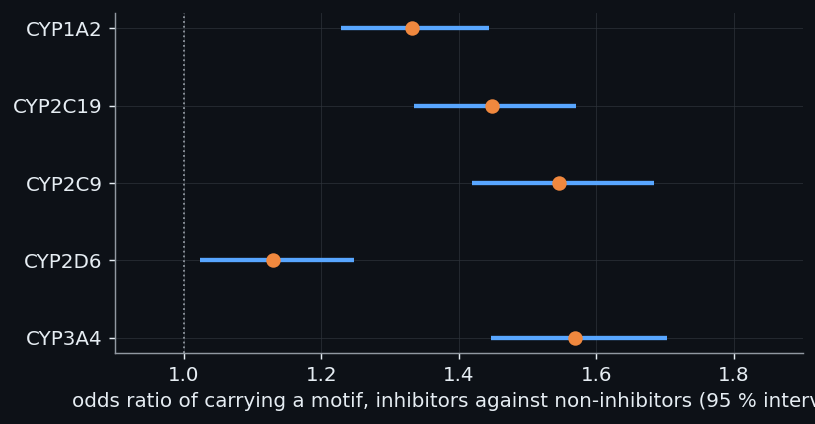

In [119]:
# The comparison for one enzyme (CYP3A4), step by step: the four counts, the odds ratio, its standard error and interval, and Fisher's exact test computed from the hypergeometric distribution and by the library.
from scipy.stats import fisher_exact, hypergeom, norm

def table_counts(group):
    a = int(((group["inhibitor"] == 1) & group["has_motif"]).sum())      # motif, inhibitor
    b = int(((group["inhibitor"] == 1) & ~group["has_motif"]).sum())     # no motif, inhibitor
    c = int(((group["inhibitor"] == 0) & group["has_motif"]).sum())      # motif, not an inhibitor
    d = int(((group["inhibitor"] == 0) & ~group["has_motif"]).sum())     # no motif, not an inhibitor
    return a, b, c, d

a, b, c, d = table_counts(panel[panel["isoform"] == "CYP3A4"])
odds_inhibitors, odds_others = a / b, c / d
odds_ratio = odds_inhibitors / odds_others
log_or_se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
z_975 = norm.ppf(0.975)
ci_low, ci_high = np.exp(np.log(odds_ratio) - z_975 * log_or_se), np.exp(np.log(odds_ratio) + z_975 * log_or_se)

N_all, K_inhibitors, n_motif = a + b + c + d, a + b, a + c
possible = np.arange(max(0, n_motif - (N_all - K_inhibitors)), min(K_inhibitors, n_motif) + 1)
pmf = hypergeom.pmf(possible, N_all, K_inhibitors, n_motif)                 # the probability of every table with the same margins, if the flag and the label were independent
p_observed = hypergeom.pmf(a, N_all, K_inhibitors, n_motif)
p_by_hand = float(pmf[pmf <= p_observed * (1 + 1e-7)].sum())                 # the tables that are as unlikely as the observed one or less
p_library = fisher_exact([[a, b], [c, d]])[1]
expected_a = K_inhibitors * n_motif / N_all
print(f"CYP3A4 counts: a={a}, b={b}, c={c}, d={d}; compounds {N_all}, inhibitors {K_inhibitors}, with a motif {n_motif}")
print(f"odds of a motif among inhibitors {odds_inhibitors:.3f}, among non-inhibitors {odds_others:.3f}; odds ratio {odds_ratio:.3f}, standard error of its logarithm {log_or_se:.4f}, interval {ci_low:.2f} to {ci_high:.2f}")
print(f"under independence a would be about {expected_a:.0f}; Fisher's exact p by the hypergeometric sum {p_by_hand:.3e}, by the library {p_library:.3e}")

# the same for all five enzymes
odds_rows = []
for enzyme, group in panel.groupby("isoform"):
    a_, b_, c_, d_ = table_counts(group)
    value = (a_ * d_) / (b_ * c_)
    se = np.sqrt(1 / a_ + 1 / b_ + 1 / c_ + 1 / d_)
    odds_rows.append({"enzyme": enzyme, "motif share, inhibitors": a_ / (a_ + b_), "motif share, non-inhibitors": c_ / (c_ + d_), "odds ratio": value,
                      "interval low": float(np.exp(np.log(value) - z_975 * se)), "interval high": float(np.exp(np.log(value) + z_975 * se)), "Fisher p": float(fisher_exact([[a_, b_], [c_, d_]])[1])})
odds_table = pd.DataFrame(odds_rows)
show_table(odds_table.assign(**{"Fisher p": odds_table["Fisher p"].map(lambda p: f"{p:.1e}")}))

fig, axis = plt.subplots(figsize=(6.4, 3.4))
positions = np.arange(len(odds_table))[::-1]
axis.hlines(positions, odds_table["interval low"], odds_table["interval high"], color=theme["blue"], lw=2.4)
axis.plot(odds_table["odds ratio"], positions, "o", color=theme["orange"], ms=7)
axis.axvline(1.0, color=theme["muted"], ls=":", lw=1)
axis.set_yticks(positions, odds_table["enzyme"])
axis.set(xlabel="odds ratio of carrying a motif, inhibitors against non-inhibitors (95 % interval)", xlim=(0.9, 1.9))
tidy(axis, theme)
fig.tight_layout()
cyp3a4_row = odds_table[odds_table["enzyme"] == "CYP3A4"].iloc[0]
cyp2d6_row = odds_table[odds_table["enzyme"] == "CYP2D6"].iloc[0]
largest_row = odds_table.loc[odds_table["odds ratio"].idxmax()]

For CYP3A4 the four counts are 1,566, 3,544, 1,586 and 5,632. Among the inhibitors the odds of a motif are 0.442 and among the non-inhibitors 0.282, an odds ratio of 1.57 with a 95 percent interval from 1.45 to 1.70. Under independence the table would show about 1307
compounds that are both motif carriers and inhibitors, and it shows 1,566. The exact p-value, computed by summing the hypergeometric probabilities and by the library, is 3.0e-27 and 3.0e-27: the two agree, as they must, since one is the other's definition. Over the five enzymes (the figure) the odds ratios run from 1.13 to 1.57, the highest for CYP3A4, and every
interval lies above 1.

**Reading the result.** A motif goes with inhibition, in all five enzymes, and the association is far beyond chance in four of them and modest in the fifth; its size is a different matter. For CYP3A4, 30.6% of the inhibitors carry a motif against 22.0% of the non-inhibitors, so a compound with a motif has about 1.6 times the odds of being an inhibitor, and
more than two thirds of the inhibitors have no motif at all. The screen is therefore not a predictor of inhibition, and was never meant to be: it flags a mechanism, and most inhibition goes by another. CYP2D6 has the weakest association (1.13, interval 1.02 to 1.25). A textbook reason, not tested here, is that the pocket of CYP2D6 is built to bind a positively charged amine rather than a nitrogen
that coordinates the iron, so the nitrogen that matters for that enzyme is of the kind that section 5.2 looked for and that this screen does not. Five tests were run here. Multiplying each p-value by the number of tests (the simplest correction for several tests, due to Bonferroni) leaves four verdicts untouched and takes CYP2D6 from 0.017 to 0.08, so its association is the one to hold most loosely; the notebook returns to the matter in section 6.5, where a family of comparisons is the normal case.

*On what actually ran.* `load_panel` calls the TDC reader for each enzyme and reads the cached files; `annotate_mechanism` runs `detect_motifs` once per compound and records the mechanism sentence; `summarize_panel` produces the first table. The odds ratios and the exact tests of this section are computed in the cells of the notebook and are not part of the repository's modules. The panel's labels are the ones TDC distributes and come from a threshold applied to the screen's curves, which this project did not
re-derive.

## 5.4 Testing the screen against real potency: the Octant screen and the rank test

> **Field:** Statistics · Pharmacology

*Where this section sits:* section 5.3 compared a flag with a label. A label throws away how strong the inhibition is; the potency of section 1.7 keeps it. This section asks whether the compounds that carry a motif are more potent, on a collection that the rule never saw. In doing so it builds the tool on which most comparisons of two groups of numbers in this
notebook rest, the **rank test** (a test that uses only the order of the values and not their size), whose meaning as an area under a curve was met in section 4.10.

**The data.** OpenADMET and Octant released the results of a CYP3A4 dose-response screen of a diversity library together with the post "Building the OpenADMET Data Engine" (CC BY 4.0; section 2.8 introduced the release). Each compound was incubated with the enzyme for 30 minutes before the substrate was added (the pre-incubation of section 1.8), so the potency that was measured is that of
reversible and time-dependent inhibition together. A diversity library is made of commercial screening compounds and not of marketed drugs; when the release was compared with the project's reference compounds by canonical SMILES, only one of them, vardenafil, appeared in it, and the motif screen had never been tuned on it. That makes it an *independent* test: a result on it cannot have been built into the rule.

**A guard against leakage.** One compound of the release, OCNT-0493952, is also in the blinded test set of the challenge. The release contains its measured potency, and a test compound whose measurement can be read from a public file is a leak in the making. The project's function `exclude_test_compounds` removes such compounds before anything is computed, so that the value is never looked at (the same rule is applied to every public source, section 6.8). The first cell
applies it, annotates the rest with the motif screen, keeps the dose-response curves that passed the quality control of the fit and compares the potency of the two groups with the project's own function, `compare_potency_by_motif`, and then checks that the result equals the file that the module wrote when it was run.

In [120]:
# The Octant screen (cypmode/data/octant_benchmark.py): load the release, drop the one compound that is also in the challenge's blinded test set, annotate the motifs, keep the curves that passed quality
# control, and compare the potency of the two groups with the project's own function; the result is checked against the file the module wrote when it was run (data/tdi_track/inputs/octant_cache/).
import json

from cypmode.challenge.official_extra import exclude_test_compounds
from cypmode.data.octant_benchmark import annotate_motifs, compare_potency_by_motif, load_inhibition_data

released = load_inhibition_data()
guarded, dropped_for_leak = exclude_test_compounds(released, "ocnt_batch")
octant = annotate_motifs(guarded)
module_result = compare_potency_by_motif(octant)
stored_result = json.loads((ROOT / "data/tdi_track/inputs/octant_cache/motif_potency_validation.json").read_text())
agree_with_stored = all(abs(module_result[k] - stored_result[k]) < 1e-9 for k in module_result)
scored = octant[(octant["drc_qc_status"] == "PASS")].dropna(subset=["CYP3A4_pIC50"])
with_motif = scored.loc[scored["has_motif"], "CYP3A4_pIC50"].to_numpy()
without_motif = scored.loc[~scored["has_motif"], "CYP3A4_pIC50"].to_numpy()
n1, n2 = len(with_motif), len(without_motif)
print(f"{len(released)} compounds in the release; excluded because they are in the blinded test set: {dropped_for_leak}; curves that passed quality control and have a pIC50: {len(scored)} ({n1} with a motif, {n2} without)")
print(f"median pIC50: {np.median(with_motif):.3f} with a motif, {np.median(without_motif):.3f} without; mean {with_motif.mean():.3f} and {without_motif.mean():.3f}")
print(f"the module's result equals the stored file: {agree_with_stored}")
n_released, n_failed_qc = len(released), int((guarded["drc_qc_status"] != "PASS").sum())

1340 compounds in the release; excluded because they are in the blinded test set: ['OCNT-0493952']; curves that passed quality control and have a pIC50: 1083 (450 with a motif, 633 without)
median pIC50: 5.427 with a motif, 5.302 without; mean 5.316 and 5.167
the module's result equals the stored file: True


The release holds 1,340 compounds, 1 of which (OCNT-0493952) was excluded; 201 further compounds failed the quality control of the curve, and 1,083 remain with a pIC50, 450 with a motif and 633 without. The motif carriers are more potent on average, 5.43 against 5.30 in median pIC50. The question is how
far a difference of that size, between groups of that size, can be trusted, and the answer has to avoid one assumption. The usual test for the difference of two averages, Student's t-test, assumes that the values of each group are spread like a bell curve, and potencies are not: they pile up against the floor of the assay and have long tails. A **rank test** assumes nothing of the kind, because it uses only the order of the values.

**Ranks and the statistic U.** Put the two groups together and sort all $N = n_1 + n_2$ values from the smallest to the largest. The smallest has **rank** 1, the next rank 2, and so on; values that are equal (a **tie**) all receive the average of the ranks they occupy. Let $x_i$, for $i = 1, \dots, n_1$, be the potency of the $i$-th compound with a motif and $y_j$, for $j = 1, \dots, n_2$, that of the $j$-th compound without one. The Mann-Whitney statistic $U$ counts, over every pair made of one $x$ and one $y$,
how often the $x$ is the larger, and counts a tie as one half:

$$U \;=\; \sum_{i=1}^{n_1}\sum_{j=1}^{n_2} \Bigl( \mathbb{1}[x_i > y_j] + \tfrac12\,\mathbb{1}[x_i = y_j] \Bigr).$$

Counting pairs is slow for large groups, and there is a shortcut through the ranks. If $R_1$ is the sum of the ranks of the $x$ values in the pooled sort, then the $x$ of rank $r$ is larger than the other $r-1$ values below it, some of which are $x$ values; the $x$ values among themselves account for $n_1(n_1+1)/2$ of these comparisons, and the remainder are comparisons against $y$ values, so

$$U \;=\; R_1 - \frac{n_1\,(n_1+1)}{2}.$$

The first part of the cell checks the two ways on a tiny example, and on a piece of the real data, so that nothing is taken on trust. $U$ divided by the number of pairs, $A = U/(n_1 n_2)$, is the probability that a compound drawn at random from the first group is more potent than one drawn at random from the second (ties counted half). That is the same quantity as the AUC of section 4.10, here with the potency as the score and the group as the class, and it is the natural *size* of the effect: 0.5 means no difference and 1 means that every compound of the first group beats every compound of the second.

**The null distribution of U.** If the group a compound belongs to were irrelevant to its potency, each pair would be equally likely to go either way, so the expected value of $U$ is half the number of pairs, $\mu_U = n_1 n_2/2$. Its spread follows from the same argument, with a correction for ties (Mann and Whitney, 1947; the tie term is due to later authors):

$$\sigma_U^2 \;=\; \frac{n_1 n_2}{12}\left( N + 1 - \frac{\sum_k (t_k^3 - t_k)}{N\,(N-1)} \right),$$

where $t_k$ is the number of values that share the $k$-th tied value. For groups of this size the distribution of $U$ is very close to the normal distribution, so the **z value** $z = (U - \mu_U - \tfrac12)/\sigma_U$ (the half is a correction because $U$ moves in steps of one half) is looked up in the normal distribution and gives the one-sided p-value: the probability, if potency and group were unrelated, of a $U$ at least as large. The test is one-sided
because the claim of the screen is directional (a nitrogen that coordinates the iron tightens binding), and the direction was fixed before the data were read; a two-sided p-value, twice as large, is printed as well. The cell computes all of this by hand, checks it against the library and the stored file, and then checks the spread formula the direct way, by shuffling the group labels thousands of times and measuring the spread of $U$.

In [121]:
# The rank test written out. First a tiny example (four values against five) so that the two ways of computing U can be compared; then the real groups: ranks of the pooled values (ties get the average rank),
# U from the rank sum, the mean and variance of U if the group label were irrelevant, the z value with the usual continuity correction, and the p-value; all checked against the library.
from scipy.stats import mannwhitneyu, rankdata

def u_by_pairs(x, y):
    greater = (x[:, None] > y[None, :]).sum()
    equal = (x[:, None] == y[None, :]).sum()
    return float(greater + 0.5 * equal)

def u_by_ranks(x, y):
    ranks = rankdata(np.concatenate([x, y]))
    return float(ranks[: len(x)].sum() - len(x) * (len(x) + 1) / 2)

tiny_x, tiny_y = np.array([6.1, 5.4, 7.0, 5.4]), np.array([5.0, 5.4, 4.8, 6.0, 5.2])
tiny_pairs, tiny_ranks = u_by_pairs(tiny_x, tiny_y), u_by_ranks(tiny_x, tiny_y)
print(f"tiny example: U by counting the pairs {tiny_pairs}, by ranks {tiny_ranks}; ranks of the nine pooled values {rankdata(np.concatenate([tiny_x, tiny_y]))}")

pooled = np.concatenate([with_motif, without_motif])
N_pooled = len(pooled)
U_pairs_check = u_by_pairs(with_motif[:300], without_motif[:300])                 # counting pairs on the whole data is a 450 x 633 comparison; a 300 x 300 piece shows the two methods agree
U_ranks_check = u_by_ranks(with_motif[:300], without_motif[:300])
U_statistic = u_by_ranks(with_motif, without_motif)
_, tie_counts = np.unique(pooled, return_counts=True)
mu_U = n1 * n2 / 2
var_U = n1 * n2 / 12 * ((N_pooled + 1) - (tie_counts**3 - tie_counts).sum() / (N_pooled * (N_pooled - 1)))
z_U = (U_statistic - mu_U - 0.5) / np.sqrt(var_U)                                 # the 0.5 is the continuity correction: U moves in steps of 0.5
p_one_sided = float(norm.sf(z_U))
library = mannwhitneyu(with_motif, without_motif, alternative="greater")
superiority = U_statistic / (n1 * n2)
print(f"U by ranks {U_statistic:.1f} (the library: {library.statistic:.1f}); mean of U under independence {mu_U:.1f}, standard deviation {np.sqrt(var_U):.1f}; z = {z_U:.3f}")
print(f"one-sided p by hand {p_one_sided:.5f}, by the library {library.pvalue:.5f}, in the stored file {stored_result['p_value_one_sided_greater']:.5f}; two-sided p {2 * p_one_sided:.5f}")
print(f"probability that a compound with a motif is more potent than one without (ties counted half): {superiority:.4f}")

# Does the formula for the spread of U hold? Shuffle the group labels many times and measure it.
rng = np.random.default_rng(0)
simulated = []
for _ in range(4000):
    shuffled = rng.permutation(pooled)
    simulated.append(rankdata(shuffled)[:n1].sum() - n1 * (n1 + 1) / 2)
simulated = np.array(simulated)
print(f"over 4000 shuffles of the labels: mean of U {simulated.mean():.1f} (formula {mu_U:.1f}), standard deviation {simulated.std():.1f} (formula {np.sqrt(var_U):.1f})")
n_shuffles_u = len(simulated)

tiny example: U by counting the pairs 17.0, by ranks 17.0; ranks of the nine pooled values [8. 5. 9. 5. 2. 5. 1. 7. 3.]
U by ranks 154527.0 (the library: 154527.0); mean of U under independence 142425.0, standard deviation 5072.6; z = 2.386
one-sided p by hand 0.00852, by the library 0.00852, in the stored file 0.00852; two-sided p 0.01705
probability that a compound with a motif is more potent than one without (ties counted half): 0.5425
over 4000 shuffles of the labels: mean of U 142463.8 (formula 142425.0), standard deviation 5096.4 (formula 5072.6)


The two ways of computing $U$ agree, on the tiny example (17.0 and 17.0) and on the piece of real data (36880.0 and 36880.0). On the real groups $U$ is 154,527.0, against 142,425.0 expected if the group did not matter, and the standard deviation of $U$ is 5072.6, so the observed value is 2.39 standard deviations above its expectation. The one-sided p-value is 0.0085 by
hand, 0.0085 by the library and 0.0085 in the file the module wrote: the three agree. The shuffles confirm the formulas for the centre and the spread of $U$ (142463.8 and 5096.4 over 4,000 shuffles, against 142425.0 and 5072.6). The effect size is $A = 0.542$: a compound with a motif is more potent than one without in 54.2% of the pairs, against 50 percent for no effect.

Two more checks say the same thing without any formula. A **permutation test** is the shuffling just used, turned into a test: shuffle the group labels many times, compute the statistic of interest each time (here the difference of the medians), and take as the p-value the share of shuffles that give a result as large as the observed one; it relies on nothing but the assumption that, if the group were irrelevant, any shuffle of the labels would have been as likely as the true one.
A **bootstrap** interval resamples each group with replacement (a bootstrap sample, section 4.4) many times, computes the difference of medians for each pair of resamples, and reads the middle 95 percent of those differences as the interval; it shows how much the difference would vary if the screen were run again on other compounds of the same library. The next cell does both and draws the two distributions of potency, as cumulative curves, next to the shuffled differences.

difference of medians 0.125 pIC50 units (a factor 1.33 in IC50); permutation p 0.0214; bootstrap 95 % interval -0.009 to 0.254


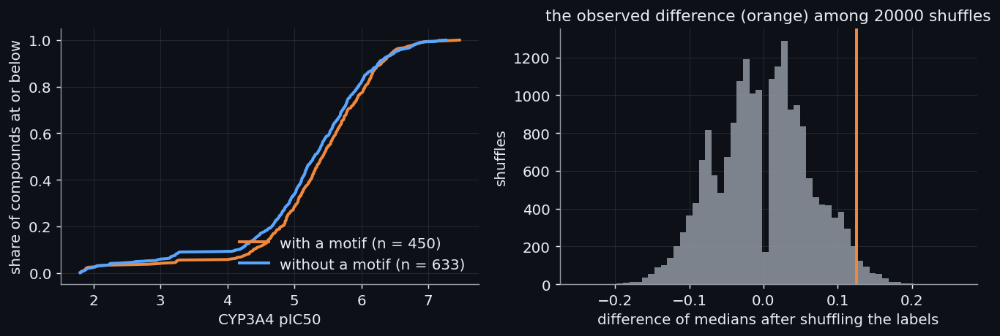

In [122]:
# Two more ways to say the same thing, with no formula at all. A permutation test: shuffle the group labels, compute the difference of medians each time, and count how often a shuffle gives a difference as large
# as the observed one. A bootstrap interval: resample each group with replacement, many times, and read the middle 95 percent of the differences of medians.
observed_difference = float(np.median(with_motif) - np.median(without_motif))
rng = np.random.default_rng(1)
n_permutations, n_bootstrap = 20000, 10000
permuted = np.empty(n_permutations)
for i in range(n_permutations):
    shuffled = rng.permutation(pooled)
    permuted[i] = np.median(shuffled[:n1]) - np.median(shuffled[n1:])
p_permutation = float((permuted >= observed_difference).mean())
boot = np.empty(n_bootstrap)
for i in range(n_bootstrap):
    boot[i] = np.median(rng.choice(with_motif, n1)) - np.median(rng.choice(without_motif, n2))
boot_low, boot_high = np.percentile(boot, [2.5, 97.5])
fold_in_ic50 = 10 ** observed_difference
print(f"difference of medians {observed_difference:.3f} pIC50 units (a factor {fold_in_ic50:.2f} in IC50); permutation p {p_permutation:.4f}; bootstrap 95 % interval {boot_low:.3f} to {boot_high:.3f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.7))
for values, label, colour in ((with_motif, "with a motif", theme["orange"]), (without_motif, "without a motif", theme["blue"])):
    xs = np.sort(values)
    left.plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=colour, lw=2.2, label=f"{label} (n = {len(xs)})")
left.set(xlabel="CYP3A4 pIC50", ylabel="share of compounds at or below")
left.legend(frameon=False, loc="lower right")
right.hist(permuted, bins=60, color=theme["muted"], alpha=0.85)
right.axvline(observed_difference, color=theme["orange"], lw=2.2)
right.set(xlabel="difference of medians after shuffling the labels", ylabel="shuffles", title="the observed difference (orange) among 20000 shuffles")
for axis in (left, right):
    tidy(axis, theme)
fig.tight_layout()

The difference of medians is 0.125 pIC50 units, which in units of the IC50 is a factor of 1.33 (section 1.7: one pIC50 unit is a factor of ten). The permutation test of that difference gives p = 0.0214, and the bootstrap interval of the difference runs from -0.009 to 0.254: it reaches just below zero. The figure shows what the numbers mean: the two cumulative curves are close and cross the same range, the curve of the
compounds with a motif lying a little to the right, and the observed difference sits in the tail of the shuffled differences, but not far out in it.

**Reading the result.** The motif carriers of this independent collection are more potent, and the evidence that this is not chance is real but not strong. The rank test, which looks at the whole distributions, gives p = 0.0085. The permutation test of the difference of medians, a cruder summary of the same data, gives 0.021, and the bootstrap interval for that difference includes zero by 0.009. The three results are not in conflict: a median
looks at one point of each distribution and throws away the rest, so it resolves less than the rank statistic does. What they say together is that the effect is at the edge of what a collection of this size can resolve. Its size is small on any reading: a factor of about 1.3 in IC50 for the medians, and a probability of 54% that a motif carrier beats a non-carrier, where 50 percent would mean no effect. The two distributions overlap almost entirely.
This is independent evidence, on data the rule never saw, that the feature the screen looks for goes with a real pharmacological property. It is not evidence that the screen could rank compounds by potency, which it was never built to do, and a single test, on one enzyme, in one library, with a potency that mixes two mechanisms, cannot be stretched into more. Two cautions belong with it. The test is a single, directional one fixed beforehand,
so no correction for several tests applies; the same sentence would be false of a test chosen after looking at the data (section 6.7, on gates, is about exactly that). And the weaker cases of section 5.1 are in the data too: a compound flagged only through a nitrogen without a free lone pair counts here as a motif carrier, which, if anything, dilutes the contrast.

*On what actually ran.* `load_inhibition_data` reads the cached release (`inhibition.parquet`, downloaded once from the Hugging Face dataset), `annotate_motifs` applies the screen to the standardised SMILES, `compare_potency_by_motif` keeps the curves with `drc_qc_status == 'PASS'` and a fitted pIC50 and runs a one-sided Mann-Whitney test (`scipy.stats.mannwhitneyu`), and `main` writes `motif_potency_validation.json`; the call of `exclude_test_compounds` in `main` is the leak guard. The by-hand computation, the shuffles
and the bootstrap of this section are computed in the cells of the notebook and are not part of the module.

## 5.5 Checking the screen against predicted structures: the distance from the iron to the nitrogen

> **Field:** Structural biology · Computational chemistry

*Where this section sits:* so far the rule has been applied to lists of molecules, and a list cannot say whether a molecule will *use* its nitrogen. That depends on where the molecule sits in the pocket, and for that a three-dimensional model of the molecule inside the enzyme is needed. A co-folding model such as Boltz-2 (section 0.2; Part XI explains how it works) produces one from the sequence of the protein and the formula of
the molecule. This section reads such a prediction, measures one distance in it, and compares the result with what the chemistry of section 1.9 and the screen of 5.1 lead one to expect. Part XI makes the same measurement on every pose it handles, and later uses it as a restraint.

**What a structure file contains.** A structure of a protein with a molecule bound to it is, in the end, a table of atoms. Each row names an atom and says where it is: three numbers $x$, $y$ and $z$, its coordinates in ångström, measured from an arbitrary origin; and to which residue (an amino acid of the protein, or a separate molecule such as the heme or the bound compound) and to which **chain** (one continuous piece of the complex) it belongs. The
format that Boltz-2 writes, **mmCIF**, is a text file in which a header names the columns of that table and every following line is one atom. The first cell prints the names of the columns of the real file of the ketoconazole prediction, three of its lines, the first atom decoded column by column, and the parts of the complex as the Biopython reader sees them (a *structure* holds *models*, a model holds chains, a chain holds residues and a residue holds atoms). Two of the columns need a word. The
occupancy is the share of the copies of the molecule in which the atom is found at this place; in an experiment it can be below 1, and in a prediction, which is a single model, it is always 1. The B-factor measures, in an experiment, how much the atom is smeared by motion and disorder; in a Boltz-2 prediction the same column carries the model's own confidence in the position of the atom, the **pLDDT**, a number from 0 to 100 (section 11.4).

In [123]:
# What a predicted structure file contains, read from the real file of the ketoconazole prediction (Boltz-2, cypmode/validation): the names of the columns of the atom table, three of its lines, and the
# parts of the complex as the Biopython reader sees them.
import re

import numpy as np
import pandas as pd
from rdkit import Chem

from cypmode.metrics.motifs import TYPE_II_MOTIFS
from cypmode.validation.openfold3 import read_boltz_inputs
from cypmode.validation.structures import _ligand_atoms, find_heme_iron, load_structure

OUT_DIR = ROOT / "data/structure_track/outputs/out/cyp3a4"
REFERENCE_NAMES = ["ketoconazole", "ritonavir", "azamulin", "vardenafil"]

def cif_of(name):
    return OUT_DIR / f"boltz_results_cyp3a4_{name}" / "predictions" / f"cyp3a4_{name}" / f"cyp3a4_{name}_model_0.cif"

lines = cif_of("ketoconazole").read_text().splitlines()
columns = [l.removeprefix("_atom_site.") for l in lines if l.startswith("_atom_site.")]
first_atom = next(l for l in lines if l.startswith("ATOM"))
iron_line = next(l for l in lines if l.startswith("HETATM") and " FE " in l)
ligand_line = next(l for l in lines if l.startswith("HETATM") and " LIG1 " in l)
print("columns of the atom table:", ", ".join(columns))
for label, line in (("a protein atom", first_atom), ("the heme iron", iron_line), ("a ligand atom", ligand_line)):
    print(f"{label:15s}", line)

# The first atom of the file laid against the names of the columns, one field per column. Every column of the real file has a meaning here (the assertion fails if a new column appears).
column_meaning = {
    "group_PDB": "ATOM for an atom of a protein chain, HETATM for any other molecule (here the ligand and the heme)",
    "id": "serial number of the atom in the file",
    "type_symbol": "the chemical element",
    "label_atom_id": "name of the atom inside its residue (N the backbone nitrogen, CA the alpha carbon, FE the iron)",
    "label_alt_id": "label of an alternative position of the atom; a full stop means that it has only one",
    "label_comp_id": "name of the residue in three letters (MET methionine, HEM the heme, LIG1 the predicted molecule)",
    "label_seq_id": "position of the residue in the sequence of its chain; a full stop for a molecule that is not part of the sequence",
    "auth_seq_id": "residue number as the authors of the structure number it",
    "pdbx_PDB_ins_code": "insertion code, the letter that the older format added to a residue number to fit an extra residue; a question mark means not given",
    "label_asym_id": "name of the chain in the archive's own naming",
    "Cartn_x": "x coordinate, in ångström",
    "Cartn_y": "y coordinate, in ångström",
    "Cartn_z": "z coordinate, in ångström",
    "occupancy": "share of the copies of the molecule in which the atom is at this place (1 means all)",
    "label_entity_id": "number of the distinct molecule that the chain is a copy of",
    "auth_asym_id": "name of the chain as the authors give it",
    "auth_comp_id": "name of the residue as the authors give it",
    "B_iso_or_equiv": "the B-factor; in a Boltz-2 prediction, the confidence of the model in the position of the atom",
    "pdbx_PDB_model_num": "number of the model in the file (a file can hold several models)",
}
assert set(columns) == set(column_meaning)
fields = first_atom.split()
assert len(fields) == len(columns)
show_table(pd.DataFrame({"column (after _atom_site.)": columns, "value for the first atom": fields, "what it says": [column_meaning[c] for c in columns]}))
atom_table_rows = [dict(zip(columns, line.split())) for line in lines if line.startswith(("ATOM", "HETATM"))]
n_rows = len(atom_table_rows)
n_same_names = sum(r["label_asym_id"] == r["auth_asym_id"] and r["label_comp_id"] == r["auth_comp_id"] for r in atom_table_rows)
n_no_position = sum(r["label_seq_id"] == "." for r in atom_table_rows)

structure = load_structure(cif_of("ketoconazole"))
chain_rows = [{"chain": chain.id, "residues": len(list(chain.get_residues())), "atoms": len(list(chain.get_atoms())), "what it is": {"A": "the protein, CYP3A4", "B": "the predicted molecule (residue LIG1)", "C": "the heme (residue HEM)"}.get(chain.id, "")} for chain in structure[0]]
show_table(pd.DataFrame(chain_rows))
iron = find_heme_iron(structure)
n_atoms_total = len(list(structure.get_atoms()))
n_protein_residues = chain_rows[0]["residues"]
ligand_heavy_atoms = len(_ligand_atoms(structure))
iron_xyz = [float(v) for v in iron.coord]
assert n_rows == n_atoms_total  # the table of the file and the reader count the same atoms

columns of the atom table: group_PDB, id, type_symbol, label_atom_id, label_alt_id, label_comp_id, label_seq_id, auth_seq_id, pdbx_PDB_ins_code, label_asym_id, Cartn_x, Cartn_y, Cartn_z, occupancy, label_entity_id, auth_asym_id, auth_comp_id, B_iso_or_equiv, pdbx_PDB_model_num
a protein atom  ATOM 1 N N . MET 1 1 ? A -39.19721 1.55275 -41.46333 1 1 A MET 63.147 1
the heme iron   HETATM 4112 FE FE . HEM . 1 ? C 4.88454 1.95888 1.77097 1 3 C HEM 97.534 1
a ligand atom   HETATM 4034 C C55 . LIG1 . 1 ? B -5.96905 1.34893 -14.11221 1 2 B LIG1 60.278 1


| column (after _atom_site.) | value for the first atom | what it says |
| --- | --- | --- |
| group_PDB | ATOM | ATOM for an atom of a protein chain, HETATM for any other molecule (here the ligand and the heme) |
| id | 1 | serial number of the atom in the file |
| type_symbol | N | the chemical element |
| label_atom_id | N | name of the atom inside its residue (N the backbone nitrogen, CA the alpha carbon, FE the iron) |
| label_alt_id | . | label of an alternative position of the atom; a full stop means that it has only one |
| label_comp_id | MET | name of the residue in three letters (MET methionine, HEM the heme, LIG1 the predicted molecule) |
| label_seq_id | 1 | position of the residue in the sequence of its chain; a full stop for a molecule that is not part of the sequence |
| auth_seq_id | 1 | residue number as the authors of the structure number it |
| pdbx_PDB_ins_code | ? | insertion code, the letter that the older format added to a residue number to fit an extra residue; a question mark means not given |
| label_asym_id | A | name of the chain in the archive's own naming |
| Cartn_x | -39.19721 | x coordinate, in ångström |
| Cartn_y | 1.55275 | y coordinate, in ångström |
| Cartn_z | -41.46333 | z coordinate, in ångström |
| occupancy | 1 | share of the copies of the molecule in which the atom is at this place (1 means all) |
| label_entity_id | 1 | number of the distinct molecule that the chain is a copy of |
| auth_asym_id | A | name of the chain as the authors give it |
| auth_comp_id | MET | name of the residue as the authors give it |
| B_iso_or_equiv | 63.147 | the B-factor; in a Boltz-2 prediction, the confidence of the model in the position of the atom |
| pdbx_PDB_model_num | 1 | number of the model in the file (a file can hold several models) |

| chain | residues | atoms | what it is |
| --- | --- | --- | --- |
| A | 503 | 4033 | the protein, CYP3A4 |
| B | 1 | 36 | the predicted molecule (residue LIG1) |
| C | 1 | 43 | the heme (residue HEM) |

The file holds 4,112 atoms in three chains: the protein, with 503 residues, the predicted molecule, with 36 atoms (heavy atoms only: hydrogens are not predicted), and the heme, in which the iron is the atom named `FE`, at $x, y, z$ = (4.88, 1.96, 1.77) ångström. Nothing in the input places the molecule near the iron: the input is the protein sequence, the heme bound to the cysteine and the formula of the
molecule, so where the molecule ends up is a prediction and not something built into the question.

**Reading the table.** Every table of an mmCIF file starts with the word `loop_`, then the names of its columns, one per line (here all begin `_atom_site.`), and then one row for each record. The names come first because a row means nothing without them, so the second table of the cell lays the first atom of the file against them, field by field. Two marks recur in it: a full stop stands for *does not apply* (this atom has no alternative position) and a question mark for *not given* (there is no insertion code). The columns that begin `label_` hold the archive's own names for the chains and residues, and the ones that begin `auth_` the names that the authors of a structure gave them. In this prediction the two agree on the name of the chain and of the residue in 4,112 of the 4,112 atom rows. They differ only in the position in the sequence: `label_seq_id` is a full stop for the 79 atoms of the ligand and the heme, because a molecule that is not a residue of the chain has no place in its sequence, while `auth_seq_id` numbers each of them 1. The older text format of the archive, the PDB format, puts every field at a fixed position of a line of 80 characters, so it cannot hold a structure of more than 99,999 atoms or a chain whose name is longer than one character; mmCIF has neither limit and is the master format of the archive. The files that are submitted to the challenge are in the PDB format (11.1).

**The distance and the rule.** For two atoms $P$ and $Q$ with coordinates $(x_P, y_P, z_P)$ and $(x_Q, y_Q, z_Q)$, the distance is the length of the straight line between them (the **Euclidean distance**, from Pythagoras's theorem applied in three dimensions):

$$d(P, Q) \;=\; \sqrt{(x_P - x_Q)^2 + (y_P - y_Q)^2 + (z_P - z_Q)^2}.$$

In solved structures of Type II complexes the nitrogen is 2.0 to 2.3 ångström from the iron (Poulos and Johnson, 2005; section 1.9). The project calls a compound **coordinated** in a prediction when the closest nitrogen that matches a motif pattern of section 5.1 is within $r = 2.6$ ångström of the iron, a little above the solved range to allow for the imprecision of a prediction. With $d_{\min}$ the smallest of the distances from the iron to the matched nitrogens, the rule is $c = \mathbb{1}[d_{\min} \le r]$, the indicator of 5.1.
That is the whole decision; everything difficult in this section is in the words *the matched nitrogens*.

**Which nitrogen?** A molecule has several nitrogens, and the closest to the iron is not necessarily the one the screen flagged. The next cell computes, from the coordinates and with numpy, the distance from the iron to every nitrogen of two molecules, and marks the nitrogens that match a pattern. The first is ketoconazole, whose imidazole is the textbook Type II group. The second is vardenafil, the case that taught the project to measure the matched nitrogen and not the nearest one: an earlier version of the code
reported the nearest nitrogen of any kind, and for vardenafil that is a different nitrogen from the one the screen had flagged.

In [124]:
# The distance by hand. For every nitrogen of the ligand: the Euclidean distance to the iron from the coordinates (numpy), then which of the nitrogens belong to a motif of section 5.1 (the project's
# function matches the patterns on the molecule rebuilt from the predicted coordinates). Vardenafil is the case that taught the project to look at the matched nitrogen and not at the nearest one.
from cypmode.validation.structures import all_ligand_nitrogen_distances, motif_nitrogen_distances
from cypmode.validation.constants import COORDINATION_DISTANCE_CUTOFF_A

def nitrogen_table(name):
    structure = load_structure(cif_of(name))
    iron = find_heme_iron(structure)
    smiles = read_boltz_inputs(name)["ligand_smiles"]
    by_hand = {atom.get_name(): float(np.sqrt(((atom.coord - iron.coord) ** 2).sum())) for atom in _ligand_atoms(structure) if atom.element == "N"}
    library = {r["atom"]: r["distance_angstrom"] for r in all_ligand_nitrogen_distances(structure, iron)}
    motif = {r["atom"]: r["motif"] for r in motif_nitrogen_distances(structure, smiles, iron)}
    rows = [{"nitrogen": atom, "distance to the iron (A)": distance, "matches a motif": motif.get(atom, "no"), "library value": library[atom]} for atom, distance in sorted(by_hand.items(), key=lambda kv: kv[1])]
    return pd.DataFrame(rows), by_hand, motif

keto_table, keto_by_hand, keto_motif = nitrogen_table("ketoconazole")
show_table(keto_table, floatfmt=".2f")
varde_table, varde_by_hand, varde_motif = nitrogen_table("vardenafil")
show_table(varde_table, floatfmt=".2f")
nearest_varde = min(varde_by_hand.items(), key=lambda kv: kv[1])
nearest_motif_varde = min((kv for kv in varde_by_hand.items() if kv[0] in varde_motif), key=lambda kv: kv[1])
nearest_motif_keto = min((kv for kv in keto_by_hand.items() if kv[0] in keto_motif), key=lambda kv: kv[1])
by_hand_matches_library = all(abs(r["distance to the iron (A)"] - r["library value"]) < 0.006 for t in (keto_table, varde_table) for _, r in t.iterrows())
print(f"the by-hand distances agree with the library's (to the rounding of 0.01 A): {by_hand_matches_library}; cutoff {COORDINATION_DISTANCE_CUTOFF_A} A")

the by-hand distances agree with the library's (to the rounding of 0.01 A): True; cutoff 2.6 A


| nitrogen | distance to the iron (A) | matches a motif | library value |
| --- | --- | --- | --- |
| N32 | 2.05 | imidazole_Nsub | 2.05 |
| N54 | 4.10 | imidazole_Nsub | 4.10 |
| N53 | 14.49 | no | 14.49 |
| N52 | 17.15 | no | 17.15 |

| nitrogen | distance to the iron (A) | matches a motif | library value |
| --- | --- | --- | --- |
| N50 | 4.84 | no | 4.84 |
| N51 | 5.50 | no | 5.50 |
| N52 | 9.65 | no | 9.65 |
| N53 | 10.53 | imidazole_Nsub | 10.53 |
| N37 | 11.20 | no | 11.20 |
| N36 | 11.81 | imidazole_Nsub | 11.81 |

For ketoconazole the closest nitrogen to the iron, N32 at 2.05 ångström, is also a matched one, and the other nitrogens of the molecule (those of the piperazine) are more than 14 ångström away. For vardenafil the closest nitrogen of any kind is N50, at 4.84 ångström, and it is not part of any matched pattern; the closest *matched* one is N53, at 10.53. Measuring the nearest nitrogen would have said "4.84 ångström, nearly coordinated" for a compound whose flagged nitrogens are more than ten ångström from the iron, which is why the function of the project measures the matched nitrogens. The agreement of the by-hand distances with the project's function is True.

**Matching a pattern to coordinates.** A pattern of 5.1 describes atoms and bonds, and the structure file gives atoms and coordinates but no bonds, so a bridge is needed. The project joins atoms of the ligand that sit close enough to be bonded (proximity bonding), then asks RDKit to lay the SMILES of the molecule over that graph and to assign bond orders and aromaticity to it (`AssignBondOrdersFromTemplate`, the technique that Walters's `cyp-heatmap` also uses); the atoms of the rebuilt
molecule then carry the coordinates, and a pattern match gives atoms whose positions are known. Distance-based bonding can go wrong: when the predicted conformation of a molecule puts two atoms that are not bonded closer together than two that are, the heuristic finds a bond that the SMILES does not have, and the assignment fails. The project met this on one compound of a later batch (Part XI), and `cypmode/validation/structures.py` has a second route for it: if the atoms of the file are in the order of the SMILES and every bond of the SMILES has a plausible length,
the coordinates are assigned to the atoms of the SMILES directly, by position in the list. The next cell checks the main route on ketoconazole and then asks which of the nitrogens that the screen matches is the one near the iron.

In [125]:
# Why the molecule has to be rebuilt. The structure file gives the elements and the coordinates of the ligand atoms but no bonds. The project first joins atoms that sit close enough to be bonded (proximity
# bonding), then asks RDKit to lay the molecule's own SMILES over that graph and to assign bond orders and aromaticity (AssignBondOrdersFromTemplate); the atom numbers of the SMILES then carry the coordinates.
from rdkit.Chem import AllChem

structure_k = load_structure(cif_of("ketoconazole"))
ligand_k = _ligand_atoms(structure_k)
block = "\n".join(f"HETATM{i:>5} {a.get_name():<4} LIG A   1    {a.coord[0]:8.3f}{a.coord[1]:8.3f}{a.coord[2]:8.3f}  1.00  0.00          {a.element:>2}" for i, a in enumerate(ligand_k, start=1)) + "\nEND"
raw = Chem.MolFromPDBBlock(block, sanitize=False, proximityBonding=True)
template = Chem.MolFromSmiles(read_boltz_inputs("ketoconazole")["ligand_smiles"])
rebuilt = AllChem.AssignBondOrdersFromTemplate(template, raw)
bond_orders = pd.Series([str(b.GetBondType()) for b in rebuilt.GetBonds()]).value_counts()
n_proximity_bonds, n_template_bonds = raw.GetNumBonds(), template.GetNumBonds()
n_aromatic_atoms = sum(a.GetIsAromatic() for a in rebuilt.GetAtoms())
print(f"ligand atoms {len(ligand_k)}; bonds found by proximity {n_proximity_bonds}; bonds of the SMILES {n_template_bonds}; after the template: {rebuilt.GetNumBonds()} bonds, {n_aromatic_atoms} aromatic atoms")
print("bond types after the template:", bond_orders.to_dict())

# The motif nitrogen is now an atom of a molecule, so the SMARTS match of section 5.1 can be applied to it and each matched nitrogen has a position.
conformer = rebuilt.GetConformer()
matched_positions = {}
for name_, smarts in TYPE_II_MOTIFS.items():
    for match in rebuilt.GetSubstructMatches(Chem.MolFromSmarts(smarts)):
        for index in match:
            if rebuilt.GetAtomWithIdx(index).GetSymbol() == "N":
                matched_positions[index] = name_
def has_free_lone_pair(atom):
    return atom.GetIsAromatic() and atom.GetDegree() == 2 and atom.GetTotalNumHs() == 0

iron_k = find_heme_iron(structure_k).coord
matched_rows = []
for index in sorted(matched_positions):
    position = conformer.GetAtomPosition(index)
    matched_rows.append({"nitrogen": ligand_k[index].get_name(), "pattern": matched_positions[index], "free lone pair": has_free_lone_pair(rebuilt.GetAtomWithIdx(index)),
                         "distance to the iron (A)": float(np.linalg.norm(np.array([position.x, position.y, position.z]) - iron_k))})
show_table(pd.DataFrame(matched_rows), floatfmt=".2f")
free_row = next(r for r in matched_rows if r["free lone pair"])
other_row = next(r for r in matched_rows if not r["free lone pair"])

ligand atoms 36; bonds found by proximity 40; bonds of the SMILES 40; after the template: 40 bonds, 17 aromatic atoms
bond types after the template: {'SINGLE': 22, 'AROMATIC': 17, 'DOUBLE': 1}


| nitrogen | pattern | free lone pair | distance to the iron (A) |
| --- | --- | --- | --- |
| N54 | imidazole_Nsub | False | 4.10 |
| N32 | imidazole_Nsub | True | 2.05 |

Proximity bonding finds 40 bonds in the ligand of ketoconazole, the SMILES has 40, and the assignment succeeds, giving single, double and aromatic bonds (17 aromatic atoms). The screen matches two nitrogens, the two nitrogens of the imidazole (5.1: the pattern does not distinguish them), and the table shows that they behave as the chemistry says: the one with a free lone pair, N32, is
2.05 ångström from the iron, and the one that carries a substituent and has used its lone pair in the ring, N54, is 4.10. Of the nitrogens the pattern cannot tell apart, the prediction chooses the right one.

**The four reference compounds.** The project's original structural check covered four drugs for which cryo-EM structures of CYP3A4 had been solved (Walters and co-workers, 2026; preprint "Structural Plasticity and Ligand Promiscuity of CYP3A4 Revealed by Cryo-EM", bioRxiv): ketoconazole, ritonavir, azamulin and vardenafil, each predicted once by Boltz-2 with the heme explicitly present and bonded to its cysteine. The next cell reads the four predictions with the function `summarize_compound`, checks the result against the summary file the project wrote when it first
ran them, and draws the distance of the closest matched nitrogen, with the cutoff. The confidence is the model's own score for the whole structure, from 0 to 1, and the binding probability is the output of its affinity module (section 11.2); neither is used for the decision.

| compound | motif found | closest motif nitrogen (A) | coordinated (<= 2.6 A) | Boltz-2 confidence | Boltz-2 binding probability |
| --- | --- | --- | --- | --- | --- |
| ketoconazole | imidazole_Nsub | 2.05 | yes | 0.92 | 0.86 |
| ritonavir | thiazole | 2.19 | yes | 0.92 | 0.40 |
| azamulin | triazole_1_2_4 | 13.41 | no | 0.93 | 0.73 |
| vardenafil | imidazole_Nsub | 10.53 | no | 0.93 | 0.42 |

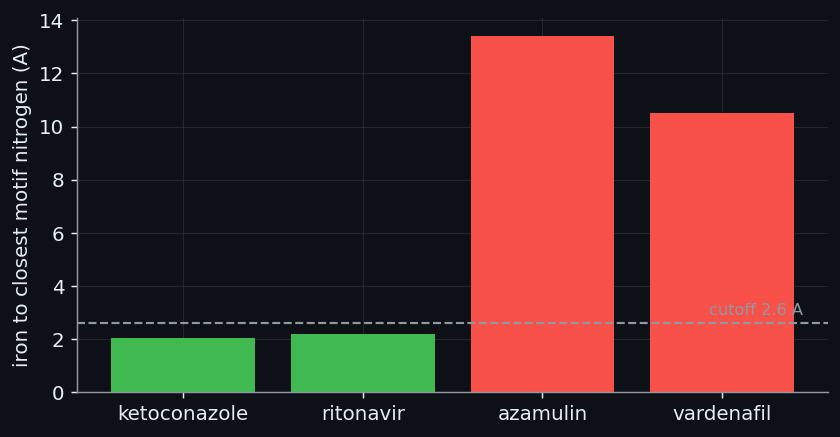

In [126]:
# The four reference compounds, from the project's own function (cypmode/validation/structures.py: summarize_compound), checked against the file that the project wrote when it first ran them; the figure is the
# distance of the closest motif nitrogen with the cutoff.
import json

from cypmode.validation.structures import summarize_compound

stored_summary = json.loads((ROOT / "data/structure_track/outputs/cyp3a4/validation_summary.json").read_text())
summary_rows = []
recomputed_matches_stored = True
for name in REFERENCE_NAMES:
    smiles = read_boltz_inputs(name)["ligand_smiles"]
    result = summarize_compound(OUT_DIR / f"boltz_results_cyp3a4_{name}", smiles)
    recomputed_matches_stored &= result["closest_motif_nitrogen_distance_angstrom"] == stored_summary[name]["closest_motif_nitrogen_distance_angstrom"]
    summary_rows.append({"compound": name, "motif found": ", ".join(sorted({r["motif"] for r in result["motif_nitrogen_distances"]})), "closest motif nitrogen (A)": result["closest_motif_nitrogen_distance_angstrom"],
                         "coordinated (<= 2.6 A)": "yes" if result["coordinated"] else "no", "Boltz-2 confidence": result["confidence_score"], "Boltz-2 binding probability": result["affinity_probability_binary"]})
show_table(pd.DataFrame(summary_rows), floatfmt=".2f")
fig, axis = plt.subplots(figsize=(6.6, 3.5))
distances = [r["closest motif nitrogen (A)"] for r in summary_rows]
colours = [theme["green"] if r["coordinated (<= 2.6 A)"] == "yes" else theme["red"] for r in summary_rows]
axis.bar([r["compound"] for r in summary_rows], distances, color=colours)
axis.axhline(COORDINATION_DISTANCE_CUTOFF_A, color=theme["muted"], ls="--", lw=1.2)
axis.text(3.45, COORDINATION_DISTANCE_CUTOFF_A + 0.3, f"cutoff {COORDINATION_DISTANCE_CUTOFF_A} A", ha="right", color=theme["muted"], fontsize=9)
axis.set(ylabel="iron to closest motif nitrogen (A)")
tidy(axis, theme)
fig.tight_layout()
rows_by_name = {r["compound"]: r for r in summary_rows}
n_coordinated = sum(r["coordinated (<= 2.6 A)"] == "yes" for r in summary_rows)

The recomputed distances equal the stored summary: True. Ketoconazole (2.05 ångström) and ritonavir (2.19) are coordinated, inside the range of solved structures and with nothing in the input to force it; azamulin (13.41) and vardenafil (10.53) are not. 2 of the four flagged compounds
are coordinated, and the other two are informative in different ways and not simple failures of the rule.

*Azamulin* matches the triazole pattern and is not near the iron. It is a known mechanism-based inactivator of CYP3A4: the enzyme turns it into a reactive species that modifies the enzyme (Lim and co-workers, 2005, doi 10.1124/dmd.104.003475; Sevrioukova, 2019, doi 10.3390/ijms20174245), a process that depends on the turnover of the enzyme and that a single static prediction cannot represent. The screen's call, Type II, is wrong about the mechanism in a specific, documented way, for a compound that inhibits for real. *Vardenafil*
matches the imidazole pattern inside the fused ring system of its core, which does not behave like a free imidazole; the structure confirms that the match was a coincidence of connectivity of the kind that 5.1 warned about. *Ritonavir* is coordinated, as the thiazole pattern was added to the screen to say, but the binding probability of Boltz-2 for it is lower than for ketoconazole although the two coordinate the iron at similar distances and confidence: the geometric signal and the learned
affinity signal do not fully agree, and the project has no explanation for that beyond noting it.

A caution about what this check can and cannot show. It is a check of four molecules, each predicted once; it is not a measurement of how often the screen is right. The announcement of the cryo-EM structures states that current co-folding models handle CYP3A4 badly because of the plasticity of its pocket, which the structures they were trained on do not show (Walters and co-workers, 2026), so a large distance can be a failure of the prediction as well as a fact about the molecule; for azamulin the chemistry explains the result, but the project cannot rule out the second reason from one static prediction. An independent
analysis supports the binary calls: Walters's `cyp-heatmap` (https://github.com/PatWalters/cyp-heatmap) fingerprints the interactions of 122 CYP3A4 structures with ProLIF, a different method on different structures, and its metal-coordination contact with the heme iron agrees with the calls above for the same four compounds. That is agreement on a yes-or-no call between two unrelated methods, and no more: a contact fingerprint is not a distance.

*On what actually ran.* The four predictions were produced once, on the local machine, by `boltz predict` with the heme and its covalent bond to the axial cysteine written into the input by `cypmode/validation/build_input.py` (about 40 minutes per compound); `cypmode/validation/structures.py` reads them and writes the summary (`build_summary`, `data/structure_track/outputs/cyp3a4/validation_summary.json`). The cells above re-read the stored structures and do not run Boltz-2 again. The batch runner `cypmode/validation/batch.py` and the one-call
wrapper `cypmode/validation/pipeline.py` run the same measurement for any new SMILES, which is how the structural part of the project grew into Part XI.

## 5.6 Pocket geometry from a predicted structure: how buried the molecule is and how much room is left

> **Field:** Structural biology · Computational chemistry

*Where this section sits:* section 5.5 measured one distance in a predicted structure. Two other properties of a pose can be computed from the same file with no further prediction: how much of the molecule is covered by the protein, its *burial*, and how much empty space is left in the pocket around it. Both are cheap, both are independent of the iron-nitrogen distance, and both are the
structural evidence that section 7.10 offers to the models. This section builds them from first principles and measures them on the four reference complexes.

**The surface of a molecule.** A molecule has no surface in the sense that a table has: its atoms are clouds of electrons. Two conventions make the idea precise. Each atom is a sphere whose radius, the **van der Waals radius**, is the distance at which two non-bonded atoms of that element begin to repel each other (Bondi, 1964: 1.70 ångström for carbon, 1.55 for nitrogen, 1.52 for oxygen, 1.75 for chlorine).
And the surface that matters for a molecule in water is the one that a water molecule can reach: the **solvent-accessible surface**, traced by the centre of a probe sphere the size of water, with radius $r_w = 1.4$ ångström, as it rolls over the atoms. Its area, the **SASA**, is the part of the molecule that solvent can touch. Shrake and Rupley (1973) gave the simple algorithm that is still used. Let $r_i$ be the radius of atom $i$ and
$R_i = r_i + r_w$ the radius of the sphere on which the centre of the probe moves when it touches the atom. Spread $n$ test points evenly over that sphere. For a point to be evenly spread, the golden-spiral construction puts the $k$-th point, for $k = 0, \dots, n-1$, at height $z_k$ and longitude $\varphi_k$,

$$z_k \;=\; 1 - \frac{2k+1}{n}, \qquad \varphi_k \;=\; k\,\pi\,(3-\sqrt{5}),$$

on the unit sphere (the point is $(\sqrt{1-z_k^2}\cos\varphi_k,\ \sqrt{1-z_k^2}\sin\varphi_k,\ z_k)$): the heights are equally spaced, and the longitude advances by the golden angle, about 137.5 degrees, so that no two points ever line up. The points are then scaled by $R_i$ and moved to the centre of the atom. A test point is *accessible* if it lies outside the sphere of radius $R_j$ of every other atom $j$,
that is, if the probe could stand there without overlapping another atom. If $a_i$ of the $n$ points of atom $i$ are accessible, its accessible area is the area of its sphere times that share,

$$A_i \;=\; 4\pi R_i^2\,\frac{a_i}{n},$$

and the SASA of a group of atoms is the sum of their $A_i$. The cell writes this out and checks it against geometry before using it. A single atom has the area of its sphere, $4\pi R^2$. Two equal spheres whose centres are a distance $D$ apart each hide a spherical cap of the other, of height $h = R - D/2$, and the area of a cap is $2\pi R h$ (Archimedes), so each of the two atoms has the exact area $4\pi R^2 - 2\pi R h$.
Then the burial of the ligand in each of the four complexes is computed. The **buried share** of the ligand is

$$B \;=\; 1 - \frac{A_{\text{bound}}}{A_{\text{free}}},$$

where $A_{\text{bound}}$ is the SASA of the ligand's atoms in the complex, with the protein and the heme around them as neighbours, and $A_{\text{free}}$ that of the same atoms alone, in the same conformation, as if the molecule were not bound: $B=0$ for a molecule that solvent reaches everywhere and $B$ near 1 for one that is almost entirely covered. The result is compared with Biopython's implementation of the same method, which the project uses.

In [127]:
# The solvent-accessible surface by the Shrake-Rupley method, written out. Each atom is a sphere (van der Waals radius, Bondi 1964) grown by the radius of a water molecule, 1.4 A; n points are spread evenly over
# the grown sphere (the golden-spiral formula); a point counts as accessible when it lies outside the grown sphere of every other atom; the area of the atom is that of its grown sphere times the share of its
# points that are accessible. First two checks against geometry (one sphere, and two spheres whose overlap can be computed exactly), then the four reference complexes against Biopython's implementation.
import logging

from Bio.PDB.SASA import ATOMIC_RADII
from scipy.spatial import cKDTree

logging.getLogger().setLevel(logging.ERROR)                      # Biopython warns once per atom of a residue it has no radii for; the radii of the elements are used all the same
PROBE = 1.4

def golden_spiral(n):
    """n points spread evenly over the unit sphere: z runs from near 1 to near -1 in equal steps and the longitude advances by the golden angle."""
    k = np.arange(n)
    z = 1 - (2 * k + 1) / n
    longitude = k * np.pi * (3 - np.sqrt(5))
    r = np.sqrt(1 - z**2)
    return np.column_stack([r * np.cos(longitude), r * np.sin(longitude), z])

def atom_areas(coords, radii, n=100):
    """The accessible area of every atom (A^2): coords an (m, 3) array, radii the van der Waals radii."""
    grown = radii + PROBE
    points = golden_spiral(n)
    tree = cKDTree(coords)
    areas = np.zeros(len(coords))
    for i in range(len(coords)):
        test = coords[i] + points * grown[i]
        free = np.ones(n, dtype=bool)
        for j in tree.query_ball_point(coords[i], grown[i] + grown.max()):
            if j != i:
                free &= ((test - coords[j]) ** 2).sum(axis=1) >= grown[j] ** 2
        areas[i] = 4 * np.pi * grown[i] ** 2 * free.mean()
    return areas

# check 1: one carbon atom has the area of its grown sphere; check 2: two carbons 1.5 A apart: each loses a spherical cap of height h = R - D/2, whose area is 2 pi R h
R_carbon = ATOMIC_RADII["C"] + PROBE
single = atom_areas(np.zeros((1, 3)), np.array([ATOMIC_RADII["C"]]), n=2000)[0]
pair_distance = 1.5
pair = atom_areas(np.array([[0.0, 0, 0], [pair_distance, 0, 0]]), np.array([ATOMIC_RADII["C"]] * 2), n=20000)
exact_single = 4 * np.pi * R_carbon**2
exact_pair = 4 * np.pi * R_carbon**2 - 2 * np.pi * R_carbon * (R_carbon - pair_distance / 2)
print(f"one atom: {single:.2f} A^2 against 4 pi R^2 = {exact_single:.2f}; two atoms 1.5 A apart: {pair[0]:.2f} each against the exact {exact_pair:.2f}")

def element_radii(atoms):
    return np.array([ATOMIC_RADII[a.element.upper()] for a in atoms])

def burial(name):
    structure = load_structure(cif_of(name))
    ligand = _ligand_atoms(structure)
    everything = list(structure.get_atoms())
    positions = {id(a): i for i, a in enumerate(everything)}
    coords, radii = np.array([a.coord for a in everything]), element_radii(everything)
    bound = atom_areas(coords, radii)[[positions[id(a)] for a in ligand]].sum()
    free = atom_areas(np.array([a.coord for a in ligand]), element_radii(ligand)).sum()
    return structure, bound, free

from cypmode.validation.pocket_geometry import ligand_burial_sasa

burial_rows, library_difference = [], 0.0
for name in REFERENCE_NAMES:
    structure, bound, free = burial(name)
    library = ligand_burial_sasa(structure)
    library_difference = max(library_difference, abs(bound - library["bound_sasa_A2"]), abs(free - library["unbound_sasa_A2"]))
    burial_rows.append({"compound": name, "ligand atoms": len(_ligand_atoms(structure)), "area with the protein and heme around it (A^2)": bound, "area of the molecule alone (A^2)": free, "buried share": 1 - bound / free})
show_table(pd.DataFrame(burial_rows), floatfmt=".2f")
burial_table = pd.DataFrame(burial_rows).set_index("compound")

# the settings of the cavity program that section 5.6 describes, read from the program itself
import inspect

import pyKVFinder

defaults = {k: v.default for k, v in inspect.signature(pyKVFinder.run_workflow).parameters.items() if k in ("step", "probe_in", "probe_out", "removal_distance", "volume_cutoff", "ligand_cutoff")}

one atom: 120.76 A^2 against 4 pi R^2 = 120.76; two atoms 1.5 A apart: 74.98 each against the exact 74.99


| compound | ligand atoms | area with the protein and heme around it (A^2) | area of the molecule alone (A^2) | buried share |
| --- | --- | --- | --- | --- |
| ketoconazole | 36 | 43.46 | 748.09 | 0.94 |
| ritonavir | 50 | 84.45 | 936.98 | 0.91 |
| azamulin | 33 | 60.59 | 643.18 | 0.91 |
| vardenafil | 34 | 50.29 | 659.60 | 0.92 |

Both geometric checks pass: one atom gives 120.76 against the exact 120.76 square ångström, and the two overlapping atoms 74.98 each against 74.99. The by-hand areas of the four complexes agree with Biopython's: the largest difference is 3.4e-13 square ångström. All four molecules are deeply buried: 91% to 94% of the surface of each is covered by the protein and
the heme, ketoconazole the most, with 43 square ångström of its 748 still open to solvent. The numbers are close for the four, and that is a finding: azamulin, which sits 13 ångström from the iron, is almost as deeply buried (91%) as ketoconazole (94%), which is bonded to it. A pose can be deep in the pocket and still be far from the iron, so burial and the iron-nitrogen distance
measure different things.

**Empty space.** The second measurement asks how much room is left. A cavity is a region of empty space in a protein that solvent can reach only through a narrow opening or not at all, and detecting one is a problem of geometry on a grid. The program the project uses, pyKVFinder (a Python version of KVFinder; Oliveira and co-workers, 2014; Guerra and co-workers, 2021), covers the protein with a grid of points a fixed step apart (0.6 ångström by default) and uses two probes: a small one (1.4 ångström, water) and a
large one (4.0 ångström). The grid points at which the small probe can stand without touching an atom are the space that solvent could occupy. The large probe is rolled in from the outside: the points it can reach, and everything its body covers on the way, are the *outside*. A **cavity** is the part of the small probe's space that the large probe never covers, that is, space the small probe could occupy that is enclosed or has too narrow an opening for the large one. Its volume is the number of grid points times the volume of a grid cell, the step cubed.
The cell shows the idea on a toy in two dimensions, with a C-shaped wall of atoms, two ligand atoms inside and the opening too narrow for the large probe, and counts the cells of the cavity; the same program, in three dimensions, is then run on the four complexes through the project's function, with the search restricted to within 5.0 ångström of the ligand (otherwise it reports dozens of cavities all over the protein) and the largest cavity of that region taken as the pocket.

grid step 0.25 units; cells where the small probe fits: 9327; cells of the cavity: 453 (area 28.3 square units)


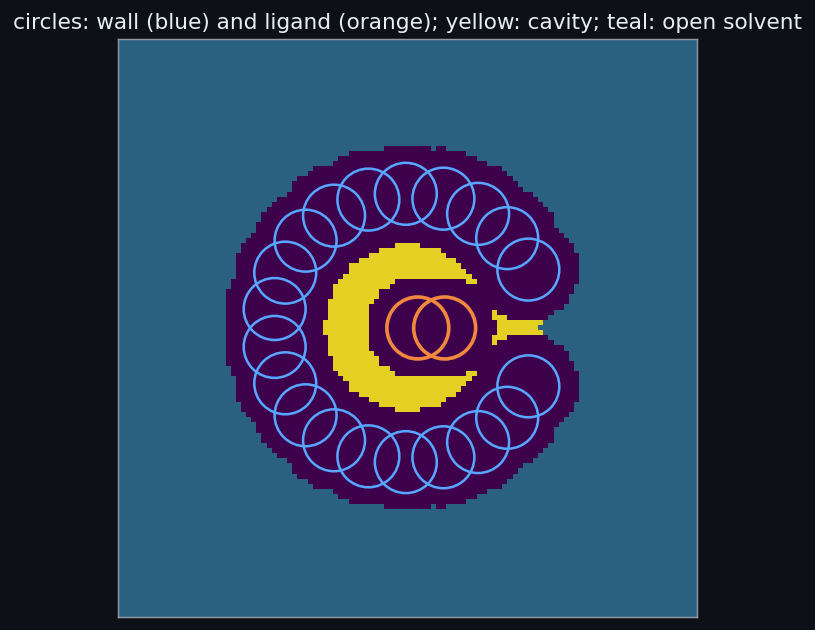

In [128]:
# The idea of cavity detection on a toy in two dimensions (the real program works on a three-dimensional grid in the same way). Atoms are discs; a grid of points covers the picture. A small probe (radius 1) can
# stand at a grid point when no atom is closer than its radius plus 1; a large probe (radius 3) does the same with a wider margin. The large probe is reached from the outside by flooding from the border
# through the points where it fits. A cavity is a place the small probe can be and the large probe, coming from the outside, cannot reach: a space that is enclosed or has too narrow an opening.
from scipy import ndimage

step = 0.25
xs = np.arange(0, 28 + step, step)
grid_x, grid_y = np.meshgrid(xs, xs)
protein_atoms = [(14 + 6.5 * np.cos(t), 14 + 6.5 * np.sin(t)) for t in np.linspace(0.45, 2 * np.pi - 0.45, 20)]       # a C-shaped wall of atoms with an opening on the right
ligand_atoms_2d = [(14.5, 14.0), (15.8, 14.0)]
atoms_2d = protein_atoms + ligand_atoms_2d
atom_radius = 1.5
distance_to_atom_surface = np.min([np.hypot(grid_x - x, grid_y - y) - atom_radius for x, y in atoms_2d], axis=0)

small_fits = distance_to_atom_surface >= 1.0                       # the centre of the small probe (radius 1) can stand here
large_fits = distance_to_atom_surface >= 3.0                       # the centre of the large probe (radius 3) can stand here
labels, _ = ndimage.label(large_fits)
touching_border = set(np.unique(np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]]))) - {0}
reached = np.isin(labels, list(touching_border))                   # where the large probe's centre can get to, coming from the outside
covered = ndimage.distance_transform_edt(~reached) * step <= 3.0   # every place that some reachable large probe covers with its body
cavity = small_fits & ~covered
cavity_cells = int(cavity.sum())
toy_area = cavity_cells * step**2
fig, axis = plt.subplots(figsize=(5.2, 5.0))
axis.imshow(np.where(cavity, 1.0, np.where(small_fits, 0.35, 0.0)), origin="lower", extent=(0, 28, 0, 28), cmap="viridis", vmin=0, vmax=1, alpha=0.9)
for x, y in protein_atoms:
    axis.add_patch(plt.Circle((x, y), atom_radius, fill=False, color=theme["blue"], lw=1.4))
for x, y in ligand_atoms_2d:
    axis.add_patch(plt.Circle((x, y), atom_radius, fill=False, color=theme["orange"], lw=2.0))
axis.set(xlim=(0, 28), ylim=(0, 28), xticks=[], yticks=[], title="circles: wall (blue) and ligand (orange); yellow: cavity; teal: open solvent")
fig.tight_layout()
print(f"grid step {step} units; cells where the small probe fits: {int(small_fits.sum())}; cells of the cavity: {cavity_cells} (area {toy_area:.1f} square units)")

In [129]:
# The real thing, with the project's function (cypmode/validation/pocket_geometry.py: pocket_volume, which calls pyKVFinder). The program is run on the complex with the cavity search restricted to the region
# within 5 A of the ligand; the largest cavity found there is taken as "the pocket". Its volume is the empty space left around the ligand.
from cypmode.validation.pocket_geometry import pocket_volume
pocket_rows = []
for name in REFERENCE_NAMES:
    result = pocket_volume(load_structure(cif_of(name)))
    pocket_rows.append({"compound": name, "empty cavity next to the ligand (A^3)": result["pocket_volume_A3"], "its surface (A^2)": result["pocket_area_A2"], "cavities found within 5 A": result["n_cavities_detected"],
                        "buried share of the ligand": float(burial_table.loc[name, "buried share"])})
show_table(pd.DataFrame(pocket_rows), floatfmt=".2f")
pocket_table = pd.DataFrame(pocket_rows).set_index("compound")

| compound | empty cavity next to the ligand (A^3) | its surface (A^2) | cavities found within 5 A | buried share of the ligand |
| --- | --- | --- | --- | --- |
| ketoconazole | 73.66 | 79.98 | 6 | 0.94 |
| ritonavir | 199.37 | 172.99 | 5 | 0.91 |
| azamulin | 278.21 | 252.83 | 1 | 0.91 |
| vardenafil | 88.13 | 85.90 | 5 | 0.92 |

In the toy the small probe fits in 9,327 cells and 453 of them belong to the cavity, a crescent of free space left between the ligand and the wall that the large probe cannot enter. For the four complexes the volume of that leftover space, the empty cavity that the program finds next to the ligand with the ligand's own atoms in place, is 74 cubic ångström for ketoconazole,
88 for vardenafil, 199 for ritonavir and 278 for azamulin. It is therefore smallest for the compound that is bonded to the iron and largest for the one that sits far from it, which is the direction one would expect if a molecule that finds its place fills the pocket and one that does not leaves room.
That reading is tentative, and the reason is as important as the numbers: four compounds, each predicted once, of very different sizes (the molecule has 36 to 50 atoms); a large molecule leaves a different amount of free space than a small one for reasons that have nothing to do with the pose; and the pocket of CYP3A4 is known to change shape with its ligand, which a single static prediction cannot show. The two measurements are what they are, cheap descriptions of a
pose; section 7.10 asks, with the procedures of Part VI and for many compounds, whether they carry any information that a model can use.

*On what actually ran.* `ligand_burial_sasa` in `cypmode/validation/pocket_geometry.py` calls Biopython's `ShrakeRupley` twice, on the complex and on an isolated copy of the ligand residue, and returns the two areas and the buried share. `pocket_volume` writes the complex to a temporary PDB file with the ligand residue renamed (Boltz-2 names it `LIG1`, four characters, which overflows the three-character field of the PDB format and corrupted the columns that follow, a bug the project found by running the function), writes the ligand alone, and calls pyKVFinder with
the ligand and the cutoff above; the largest cavity of the region is reported, a simplification that the module states openly, since the largest cavity is not guaranteed to be the one the ligand occupies.

## 5.7 Cross-checking the screen against time-dependent shift measurements

> **Field:** Pharmacology · Biochemistry

*Where this section sits:* sections 5.3 and 5.4 asked whether a motif goes with inhibition and with potency. The question of the challenge, however, is about neither: it is about *time dependence*, the shift of section 1.8, and a rule that finds strong reversible binders need not find time-dependent ones. This section puts the two rules of this part, the motif screen and the amine alert, side by side with a small set of drugs for which that shift was measured, and it
closes the part by saying what each rule can and cannot tell about the label that the rest of the notebook predicts.

**The panel.** The post "Building the OpenADMET Data Engine" has a companion repository with the measured potency of a few named drugs with and without a pre-incubation of the enzyme (CC BY 4.0). The project uses six of them: azamulin, ketoconazole, clotrimazole, troleandomycin, verapamil and diltiazem. For each there is the **shift**, $\Delta$, the pIC50 measured after pre-incubation minus the pIC50 measured without it (section 1.8): a positive $\Delta$ means that the compound
becomes more potent the longer it stays with the enzyme. The data give its mean, its standard deviation and the 2.5 and 97.5 percent quantiles, which bound a 95 percent interval (section 2.5). The challenge calls a compound time-dependent when $\Delta$ exceeds $\log_{10} 2 = 0.301$, a more than two-fold gain in potency. The structures of the six drugs were written into the project's code one by one and each was checked
against a chemical database, not guessed (`REFERENCE_SMILES` in `cypmode/validation/tdi_reference.py`). The cell below puts each drug's shift, what its interval says about the threshold (wholly above, wholly below, or straddling it), the calls of the two rules and, for the two drugs that are in the structural reference set, the distance of 5.5 in one table, and draws the shifts with their intervals.

motif screen against the shift: {'motif and TDI': 1, 'motif, not TDI': 2, 'no motif, TDI': 3, 'no motif, not TDI': 0}
amine alert against the shift: {'amine and TDI': 3, 'amine, not TDI': 0, 'no amine, TDI': 1, 'no amine, not TDI': 2}


| drug | shift | 95 % interval | against log10 2 | Type II motif | amine alert | iron to nitrogen (A) |
| --- | --- | --- | --- | --- | --- | --- |
| azamulin | 0.99 | 0.86 to 1.12 | above the threshold | triazole_1_2_4 | no | 13.41 |
| ketoconazole | 0.03 | -0.03 to 0.10 | below the threshold | imidazole_Nsub | no | 2.05 |
| clotrimazole | 0.17 | 0.13 to 0.21 | below the threshold | imidazole_Nsub | no |  |
| troleandomycin | 1.25 | 1.13 to 1.37 | above the threshold | none | yes |  |
| verapamil | 0.84 | 0.73 to 0.95 | above the threshold | none | yes |  |
| diltiazem | 0.35 | 0.24 to 0.45 | interval straddles it | none | yes |  |

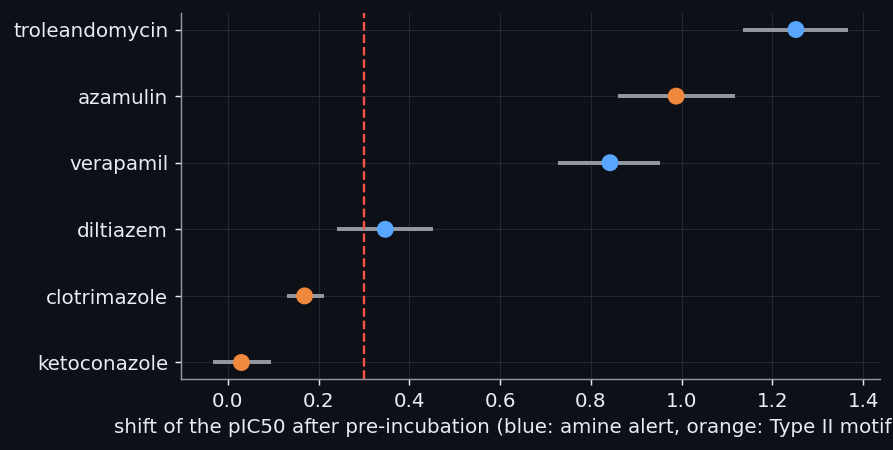

In [130]:
# The reference panel: six named drugs whose potency was measured with and without a pre-incubation (cypmode/validation/tdi_reference.py). For each drug: the shift (pIC50 with pre-incubation minus pIC50 without), its
# standard deviation and its 95 % interval as published with the data, what the interval says about the challenge's threshold of log10 2, the motif screen of 5.1, the amine alert of 5.2 and, for the two drugs that are
# in the structural reference set, the iron-nitrogen distance of 5.5.
import numpy as np
import pandas as pd

from cypmode.metrics.amines import has_trialkylamine
from cypmode.validation.tdi_reference import TDI_SHIFT_LOG2_THRESHOLD, load_tdi_reference, with_structural_coordination

reference_panel = with_structural_coordination(load_tdi_reference())
reference_panel["amine alert"] = [has_trialkylamine(s) for s in reference_panel["smiles"]]
reference_panel["reading"] = np.where(reference_panel["delta_q2.5"] > TDI_SHIFT_LOG2_THRESHOLD, "above the threshold",
                                      np.where(reference_panel["delta_q97.5"] < TDI_SHIFT_LOG2_THRESHOLD, "below the threshold", "interval straddles it"))
panel_view = pd.DataFrame({"drug": reference_panel["drug"], "shift": reference_panel["delta_mean"], "95 % interval": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(reference_panel["delta_q2.5"], reference_panel["delta_q97.5"])],
                           "against log10 2": reference_panel["reading"], "Type II motif": [", ".join(m) or "none" for m in reference_panel["motifs"]], "amine alert": np.where(reference_panel["amine alert"], "yes", "no"),
                           "iron to nitrogen (A)": reference_panel["closest_motif_nitrogen_distance_angstrom"].map(lambda v: "" if pd.isna(v) else f"{v:.2f}")})
show_table(panel_view, floatfmt=".2f")

# the two-by-two counts of 5.3, on six compounds: the flag against the point estimate of the shift
positive = reference_panel["delta_mean"] > TDI_SHIFT_LOG2_THRESHOLD
counts_motif = {"motif and TDI": int((reference_panel["has_motif"] & positive).sum()), "motif, not TDI": int((reference_panel["has_motif"] & ~positive).sum()),
                "no motif, TDI": int((~reference_panel["has_motif"] & positive).sum()), "no motif, not TDI": int((~reference_panel["has_motif"] & ~positive).sum())}
counts_amine = {"amine and TDI": int((reference_panel["amine alert"] & positive).sum()), "amine, not TDI": int((reference_panel["amine alert"] & ~positive).sum()),
                "no amine, TDI": int((~reference_panel["amine alert"] & positive).sum()), "no amine, not TDI": int((~reference_panel["amine alert"] & ~positive).sum())}
print("motif screen against the shift:", counts_motif)
print("amine alert against the shift:", counts_amine)

fig, axis = plt.subplots(figsize=(7.0, 3.6))
order = reference_panel.sort_values("delta_mean").reset_index(drop=True)
positions = np.arange(len(order))
axis.hlines(positions, order["delta_q2.5"], order["delta_q97.5"], color=theme["muted"], lw=2.2)
colours = [theme["blue"] if a else (theme["orange"] if m else theme["muted"]) for a, m in zip(order["amine alert"], order["has_motif"])]
axis.scatter(order["delta_mean"], positions, c=colours, s=70, zorder=3)
axis.axvline(TDI_SHIFT_LOG2_THRESHOLD, color=theme["red"], ls="--", lw=1.3)
axis.set_yticks(positions, order["drug"])
axis.set(xlabel="shift of the pIC50 after pre-incubation (blue: amine alert, orange: Type II motif only)")
tidy(axis, theme)
fig.tight_layout()
n_drugs = len(reference_panel)
n_positive = int(positive.sum())
n_straddle = int((reference_panel["reading"] == "interval straddles it").sum())
straddling_drug = reference_panel.loc[reference_panel["reading"] == "interval straddles it", "drug"].tolist()
shift_of = dict(zip(reference_panel["drug"], reference_panel["delta_mean"]))

Read the table in two steps, first for the screen of Type II motifs and then for the amine alert. *The motif screen* flags three of the six drugs, azamulin, ketoconazole and clotrimazole, and only one of them is time-dependent: its flagged drugs are 1 time-dependent and 2 not, and none of the three drugs without a motif is below the threshold (3 time-dependent, 0 not). The reason is the one section 1.8 gave for the two arms.
A drug that binds the iron through a nitrogen binds strongly from the start, and ketoconazole and clotrimazole are well-known strong reversible inhibitors of CYP3A4, so they are already potent in the arm without pre-incubation and pre-incubation adds little: ketoconazole's shift is 0.03, clotrimazole's 0.17, both far below the threshold. A motif tells the enzyme-binding story and the label of the challenge is about change over time, so a molecule can score high on the first and low on the second.
Azamulin is the exception, with a shift of 0.99, and for the opposite reason to the one the motif suggests: it matches a triazole pattern but, as 5.5 showed, its prediction is not near the iron; it inactivates the enzyme by turning into a reactive species (section 1.10), and the screen is right about the molecule being a CYP3A4 inhibitor and wrong about the mechanism.

*The amine alert* flags troleandomycin, verapamil and diltiazem, the three drugs with a trialkylamine, and their shifts are 1.25, 0.84 and 0.35, all above or at the threshold. Diltiazem is the borderline case: its point estimate is above the threshold, and its interval (diltiazem is the one drug in the table whose interval straddles it) includes values below it, so whether it counts as time-dependent depends on which side of the line the true shift falls, and the data cannot say.
Taking the point estimates, the alert flags 3 of the 4 time-dependent drugs and none of the 2 that are not; the one time-dependent drug it misses is azamulin, whose route is not the amine route. This is what the chemistry of section 1.10 predicts, and it is the reason the alert was written. It is also six drugs, chosen because their behaviour is documented, so it is a check that the rule does what it was designed to do and not an estimate of how well it works on new compounds; for that the
collection of 5.2, with its modest lift, is the evidence.

**What the part adds up to.** The Type II motif goes with inhibition in general (5.3), goes weakly with potency (5.4), places the nitrogen at the iron in a predicted structure when the compound really does bind that way (5.5), and does not go with time dependence, the property the challenge asks about (this section). The amine alert goes with time dependence for the route it was built for, and is modest in the collection at large (5.2). Neither rule is a model, and the project did not treat them as one: they became two columns among hundreds in the feature store, and Part VII
tests, by the procedures of Part VI, whether they add anything to a learned model. They also left two quantities that are used far beyond this part: the iron-nitrogen distance, which Part XI measures for every pose and later uses as a restraint, and the habit of testing each claim on data that did not shape it.

*On what actually ran.* `load_tdi_reference` reads the six-drug table (`data/tdi_track/inputs/octant_cache/tdi_reference/tdi_pic50_shift.tsv`), attaches the structures, the motif calls and the label `tdi_positive` (the point estimate above the threshold); `with_structural_coordination` joins the coordination results of the structural summary onto the two drugs that have them (ketoconazole and azamulin); the amine alert, the reading against the interval and the counts are computed in the cell above. The table is the whole of the data: six rows.

## 5.8 The Streamlit application and its figures

> **Field:** Software engineering · Cheminformatics

*Where this section sits:* the rules and checks of this part started as scripts, and the project wanted one place where a person could try the screen on a molecule of their own and see what had been checked against structures and what the final models do. That place is a small web application. This section says what it is, what it shows and how it is tested, because it is the face of the project that does not need a reader to run any code, and because it is the one part of the repository that reads
files from almost every other part.

**What Streamlit is.** **Streamlit** is a Python library that turns a script into a web page. The script is ordinary Python; a call such as `st.title(...)` puts a heading on the page, `st.text_area(...)` puts a box in which a person can type and returns what was typed, `st.button(...)` returns true on the run in which it was pressed, and `st.dataframe(...)` shows a table. The library has one unusual rule that explains how an application written this way behaves: *every time a person
interacts with the page, the whole script is run again from the top*, with the widgets returning their new values. There is no program that waits and responds; there is a script that is re-run, which is why a function that is expensive to compute is cached, and why the page can be tested without a browser, by running the script with chosen widget values, which is what the cell below does.

**What the application shows.** Its page has four tabs (`app.py`, run with `streamlit run app.py`). *Motif screen* is the original tool: paste or upload SMILES, and for each molecule the table says which of the six patterns of 5.1 match and gives the mechanism sentence (an unreadable string is skipped with a warning); the result can be downloaded as a CSV file. *Structural validation* reads the summary of the four reference compounds (the distances of 5.5) from a small file in the repository, so that it
works the same on a machine without Boltz-2, whose weights and predictions are far too large to ship. *CYP Blind Challenge* lists the twenty molecules of the structure track with their motif calls computed live and, when the files of the structure track exist, the structural results next to them. *TDI Track Results* shows the final report of the TDI build and the ledger of every gate verdict, built from the same logs as the method report (Part XII). A tab whose file is missing
shows a note instead of failing: in a public copy of the repository, from which the results of the two tracks are held back until the challenge closes, the last two tabs are the ones that say so.

**How it is tested.** The pure functions of the file (reading SMILES, checking them, screening a list, merging tables) are tested like any other code (`tests/test_app.py`), without Streamlit running. Two further tests added when this section was written, run the page with Streamlit's own test runner: one checks that the summary the structural tab reads exists, and one that the page renders all four tabs without an exception. They exist because the first run of that check found a real fault: the
summary and the structure-track table had been moved into a folder for CYP3A4 when the outputs were reorganised, and the application still looked for them at their old paths, so two tabs showed a warning and an empty count instead of their tables. The cell runs the same check, then types the four reference molecules into the first tab and presses its button.

In [131]:
# The application, exercised the way Streamlit's own test runner exercises it (no browser): open app.py, list the tabs and the tables each one shows, type the four reference molecules into the first tab and press its button,
# and list the functions of the file. The tabs read the same files as the notebook.
import ast

from streamlit.testing.v1 import AppTest

app_run = AppTest.from_file(str(ROOT / "app.py"), default_timeout=120).run()
tab_labels = [t.label for t in app_run.tabs]
table_shapes = [frame.value.shape for frame in app_run.dataframe]
reference_smiles = "\n".join(read_boltz_inputs(name)["ligand_smiles"] for name in REFERENCE_NAMES)
app_run.text_area[0].set_value(reference_smiles)
app_run.button[0].click().run()
screen_result = app_run.dataframe[0].value
screen_result["SMILES"] = [s[:28] + "..." if len(s) > 31 else s for s in screen_result["SMILES"]]
show_table(screen_result)
functions = [node.name for node in ast.parse((ROOT / "app.py").read_text()).body if isinstance(node, ast.FunctionDef)]
print("tabs:", tab_labels)
print("tables on the page (rows, columns):", table_shapes)
print("exceptions while the page ran:", len(app_run.exception))
print("functions of app.py:", functions)
n_app_functions = len(functions)

tabs: ['Motif screen', 'Structural validation', 'CYP Blind Challenge', 'TDI Track Results']
tables on the page (rows, columns): [(4, 6), (20, 12), (216, 3)]
exceptions while the page ran: 0
functions of app.py: ['read_smiles', 'validate_smiles', 'screen_compounds', 'motif_screen_tab', 'structural_validation_tab', 'load_challenge_compounds', 'merge_challenge_results', 'challenge_tab', '_gate_ledger', '_earlier_stage_figures', 'tdi_results_tab', 'app']


| SMILES | Motifs matched | Mechanism call |
| --- | --- | --- |
| CC(=O)N1CCN(c2ccc(OCC3COC(Cn... | imidazole_Nsub | Type II (heme-coordinating motif present) |
| CC(C)c1nc(CN(C)C(=O)N[C@H](C... | thiazole | Type II (heme-coordinating motif present) |
| CC[C@]1(C)C[C@@H](OC(=O)CSc2... | triazole_1_2_4 | Type II (heme-coordinating motif present) |
| CCCc1nc(C)c2c(=O)nc(-c3cc(S(... | imidazole_Nsub | Type II (heme-coordinating motif present) |

The page has the tabs Motif screen, Structural validation, CYP Blind Challenge, TDI Track Results, and shows 3 tables after the first run (rows by columns: 4 by 6, 20 by 12, 216 by 3); 0 exceptions were raised while it ran. After the four reference molecules are typed into the first tab, the table above is what the application itself returns: ketoconazole, ritonavir, azamulin and vardenafil each carry a Type II pattern, the call that 5.5
then put to the test with structures, and which section 5.7 qualified. The file defines 12 functions, one per tab and the small helpers around them.

**The figures.** The bar chart of 5.5 and the bar charts of the structure track were first drawn by scripts that live next to the application, `docs/figures/generate_validation_figure.py` (the iron-nitrogen distances, in a light and a dark variant), `docs/figures/generate_structure_track_figures.py` (the PoseBusters checks) and `docs/figures/generate_tdi_figures.py` (the stages of the TDI model); each reads a file of results and writes a picture, and none computes a result of its own. Later in the project they were joined by one system that registers every figure with its caption,
the data files it was drawn from and the section of this notebook that uses it, and rebuilds them all in one command (`docs/figures/build_all.py`, Part XII); the figures that open the sections of this notebook come from there.

*On what actually ran.* The application is run locally; the repository's `requirements.txt` lists what a hosted copy would install, and no hosted copy is claimed in this notebook. The test runner executes the same script that `streamlit run` would, so what the cell reports is what a person would see; what it cannot report is how the page looks in a browser, which is a matter of taste and not of correctness.

# Part VI. Measuring without selection bias

Parts II to IV gave the data, the numbers that describe a molecule and the models that learn from them. Parts VII to XI will report dozens of experiments, and every one of them is a claim of the same form: *this model, or this addition to a model, is better than that one.* A claim of that form is worth exactly as much as the measurement behind it, and a measurement that flatters the model is worse than none, because it is believed.
This part builds the measurement that every later number rests on. It begins with the two ways in which a score is inflated without anyone intending it (6.1 and 6.2), and then the construction that removes the inflation, **nested cross-validation** (6.3). Sections 6.4 and 6.5 make the measurement fit the challenge and make a comparison of two models fair. Section 6.6 tells why an earlier analysis of the project was dropped and redone,
section 6.7 turns the rules into pre-declared gates and section 6.8 describes the checks that a split is informative and that nothing leaks.

What this part hands on: the nested plan and its cache of predictions are the objects that the final TDI model of Part VIII is built from; the corrected test of 6.5 and the gate of 6.7 are the judges of every addition in Parts VII, IX and X; the hold-out of 6.8 is the second opinion that the final stack is checked against. A reader who wants only to follow the later parts can read 6.3, 6.5 and 6.7, which the later parts cite by number, and return to the rest when it is needed. The data of this part are, throughout, those of
CYP3A4 (the compounds with both arms measured, section 2.3); the same code runs for CYP2D6 and its results are given in Part VIII.

## 6.1 Why a score on the training data lies

> **Field:** Statistics · Machine learning

*Where this section sits:* Part IV ended with the metrics that judge a model (section 4.10). This section asks on which compounds the metric should be computed, and the answer, which looks obvious once seen, is the foundation of the part: not on the compounds the model was fitted on.

A model that has been fitted to a set of compounds can do two things with them. It can learn what is general, the relation between structure and label that will hold for compounds it has never seen, and it can memorise what is particular, the individual compounds and their labels, including the noise in the labels. The score on the compounds it was fitted on, which this notebook calls the **score on the fitted rows** (the literature says *resubstitution* or *training score*), rewards both. The score on compounds it has never seen rewards only the first.
The difference between the two is the **optimism** of the training score, $O = S_{\text{fitted}} - S_{\text{new}}$, where $S_{\text{fitted}}$ is a score (here the AUC of section 4.10) on the rows used for fitting and $S_{\text{new}}$ the same score on rows that were not. It is never negative in expectation, and it grows with the flexibility of the model: the more a model can bend to the data, the more of the data's accident it absorbs.

The cell shows this on the project's data, with a model of increasing flexibility: the deep LightGBM of section 4.3 with 5, 20, 80 and 320 trees. For each size it reports the AUC on the rows it was fitted on and the AUC on rows it has not seen, obtained by 5-fold cross-validation (section 4.1: five parts, each held out in turn while the model is fitted on the other four). It then adds the extreme case, one nearest neighbour on the fingerprints (section 4.5), which memorises by construction.

In [132]:
# The data of this part: the CYP3A4 compounds with both arms measured (section 2.3), and the feature set "A" of section 4.1 (Morgan counts and RDKit descriptors). A model is fitted on all of them and scored
# on the same compounds (the score on the training rows), and, by 5-fold cross-validation, on compounds it has not seen. The number of trees is raised step by step: a model with more trees is more flexible.
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

from cypmode.challenge.nested_runners import LGBM_PRESETS
from cypmode.challenge.tdi_targets import training_view

train_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")
feature_store = np.load(ROOT / "data/tdi_track/outputs/caches/feature_store.npz", allow_pickle=True)
label_view = training_view(train_file, "CYP3A4").query("population == 'both_arms'")
pool_rows = label_view.index.to_numpy()
y_pool = label_view["label"].astype(int).to_numpy()
X_pool = np.hstack([feature_store["morgan_c2"][pool_rows], feature_store["rdkit_desc"][pool_rows]])
cv_folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(X_pool, y_pool))

def lgbm(n_trees):
    return LGBMClassifier(verbose=-1, n_jobs=2, random_state=0, **{**LGBM_PRESETS["deep"], "n_estimators": n_trees})

flexibility_rows = []
for n_trees in (5, 20, 80, 320):
    on_training_rows = roc_auc_score(y_pool, lgbm(n_trees).fit(X_pool, y_pool).predict_proba(X_pool)[:, 1])
    held_out = np.zeros(len(y_pool))
    for fit_rows, held in cv_folds:
        held_out[held] = lgbm(n_trees).fit(X_pool[fit_rows], y_pool[fit_rows]).predict_proba(X_pool[held])[:, 1]
    flexibility_rows.append({"trees": n_trees, "AUC on the rows it was fitted on": on_training_rows, "AUC on rows it has not seen (5-fold)": roc_auc_score(y_pool, held_out)})
flexibility = pd.DataFrame(flexibility_rows).assign(**{"gap": lambda t: t.iloc[:, 1] - t.iloc[:, 2]})
show_table(flexibility)

# The extreme case, one nearest neighbour on the fingerprint bits: every compound is its own nearest neighbour, so the score on the rows it was fitted on is perfect whatever the chemistry.
bits_pool = feature_store["morgan_bits"][pool_rows].astype(bool)
nearest = KNeighborsClassifier(n_neighbors=1, metric="jaccard", algorithm="brute")
auc_nn_training = roc_auc_score(y_pool, nearest.fit(bits_pool, y_pool).predict_proba(bits_pool)[:, 1])
nn_held_out = np.zeros(len(y_pool))
for fit_rows, held in cv_folds:
    nn_held_out[held] = KNeighborsClassifier(n_neighbors=1, metric="jaccard", algorithm="brute").fit(bits_pool[fit_rows], y_pool[fit_rows]).predict_proba(bits_pool[held])[:, 1]
auc_nn_cv = roc_auc_score(y_pool, nn_held_out)
print(f"one nearest neighbour: AUC on its own training rows {auc_nn_training:.3f}, on unseen rows {auc_nn_cv:.3f}")
n_pool = len(y_pool)
deepest = flexibility.iloc[-1]
shallowest = flexibility.iloc[0]

one nearest neighbour: AUC on its own training rows 1.000, on unseen rows 0.520


| trees | AUC on the rows it was fitted on | AUC on rows it has not seen (5-fold) | gap |
| --- | --- | --- | --- |
| 5 | 0.876 | 0.670 | 0.206 |
| 20 | 0.934 | 0.713 | 0.221 |
| 80 | 0.992 | 0.744 | 0.248 |
| 320 | 1.000 | 0.751 | 0.249 |

Every number in the second column is high and none of them can be trusted. With 5 trees the model scores 0.876 on the rows it was fitted on and 0.670 on rows it has not seen; with 320 trees it scores 1.000, a perfect ranking of the 2,334 compounds it was fitted on, and 0.751 on new ones. The gap, the optimism,
grows from 0.21 to 0.25 as the model gets more flexible, while the score on new rows improves only from 0.67 to 0.75. The nearest-neighbour model is the limiting case: each compound is its own nearest neighbour, so its AUC on the rows it was fitted on is 1.000 whatever the chemistry, and on unseen rows it is 0.520, barely above the 0.5 of a coin.
Two models with the same score on the fitted rows (the nearest-neighbour model and the 320-tree model both score a perfect 1.0) can differ enormously in what they know.

The lesson is a rule that the whole project follows: **a score is computed only on rows that took no part in fitting the model, and in making any choice about it.** The first half of the rule is what cross-validation provides. The second half, "and in making any choice about it", is the subject of the next section, because cross-validation by itself does not satisfy it.

## 6.2 Cross-validation, and what happens to its score when it is also used to choose

> **Field:** Statistics · Machine learning

*Where this section sits:* section 6.1 established that a score must be computed on rows the model has not seen, and cross-validation does that. But the project does not fit one model: it fits dozens (section 8.1), and picks among them, and a cross-validation score that was used to pick the winner is no longer a clean measurement of the winner. This section shows why, with an example in which the truth is known, and then measures the size of the effect on the project's real candidates, where it turns out to be small and to be hidden behind a larger effect of a different kind.

**The maximum of noisy numbers.** A cross-validated score is an estimate, and an estimate has noise: another partition of the compounds, or another sample of compounds from the same population, would give a slightly different number. Suppose there are $m$ candidates and the true quality of each is the same, $\mu$, and each estimate has noise of standard deviation $\sigma$. The estimates are then $m$ draws from a bell curve around $\mu$. If the best estimate is quoted as the quality of the winner, the quoted value is the largest of $m$ draws,
and the largest of several draws is higher than the average draw: for many candidates it is about

$$\mathbb{E}\bigl[\max\bigr] \;\approx\; \mu + \sigma\sqrt{2\ln m},$$

where $\mathbb{E}$ is the expected value and $\ln$ the natural logarithm. The quoted score is too high by $\sigma\sqrt{2\ln m}$ although each single estimate was unbiased, and the bias grows, slowly, with the number of candidates tried. The cell makes this concrete with candidates that know nothing: each one assigns random numbers as scores, so its true AUC is 0.5 exactly, and the AUC of one random scorer on these compounds has the standard deviation that follows from
the rank test of section 5.4 (the variance of the statistic $U$ is $n_1 n_2 (N+1)/12$ and the AUC is $U/(n_1 n_2)$, with $n_1$ positives, $n_2$ negatives and $N = n_1 + n_2$ compounds). The best of $m$ such scorers is picked by its score and the score is read off.

In [133]:
# What choosing does to a score, on pure noise. m candidates that know nothing (their scores are random numbers, so each has a true AUC of 0.5) are scored on the same compounds; the best of them is
# picked by its score and that score is quoted. The standard deviation of an AUC of 0.5 on n1 positives and n2 negatives follows from the rank test of section 5.4: the variance of U is n1 n2 (N + 1)/12 and the AUC is U/(n1 n2).
from scipy.stats import rankdata

n_pos, n_neg = int(y_pool.sum()), int((1 - y_pool).sum())
sd_noise_auc = float(np.sqrt((n_pos + n_neg + 1) / (12 * n_pos * n_neg)))
rng = np.random.default_rng(3)

def noise_auc(scores):
    ranks = rankdata(scores, axis=1)
    return (ranks[:, y_pool == 1].sum(axis=1) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

max_rows = []
for m in (1, 2, 5, 10, 23, 50, 100):
    best = np.array([noise_auc(rng.normal(size=(m, len(y_pool)))).max() for _ in range(400)])
    one = np.array([noise_auc(rng.normal(size=(1, len(y_pool))))[0] for _ in range(400)])
    max_rows.append({"candidates m": m, "mean score of a single candidate": float(one.mean()), "mean score of the best of m": float(best.mean()), "formula 0.5 + sd * sqrt(2 ln m)": float(0.5 + sd_noise_auc * np.sqrt(2 * np.log(m)))})
show_table(pd.DataFrame(max_rows), floatfmt=".4f")
print(f"standard deviation of the AUC of one random scorer on these compounds: {sd_noise_auc:.4f} (simulated {np.std([noise_auc(rng.normal(size=(1, len(y_pool))))[0] for _ in range(2000)]):.4f})")
best_of_23 = next(r for r in max_rows if r["candidates m"] == 23)

standard deviation of the AUC of one random scorer on these compounds: 0.0127 (simulated 0.0128)


| candidates m | mean score of a single candidate | mean score of the best of m | formula 0.5 + sd * sqrt(2 ln m) |
| --- | --- | --- | --- |
| 1 | 0.4986 | 0.4995 | 0.5000 |
| 2 | 0.4997 | 0.5063 | 0.5150 |
| 5 | 0.4994 | 0.5149 | 0.5229 |
| 10 | 0.5008 | 0.5188 | 0.5273 |
| 23 | 0.5005 | 0.5249 | 0.5319 |
| 50 | 0.5003 | 0.5287 | 0.5356 |
| 100 | 0.4998 | 0.5319 | 0.5387 |

A single random scorer scores 0.499 on average, as it must, with a standard deviation of 0.0127. The best of 23 of them scores 0.525 on average, though not one of them knows anything, and the best of 100 scores 0.532. The formula over-predicts a little for small $m$ (it is the form for many candidates) but has the right shape: slow growth with the number of candidates. The effect in this example is a few hundredths of AUC, and in the project's
own work the differences that matter are of that size or smaller (section 6.7 puts numbers on it): a difference between two candidates of 0.01 in AUC is, by this arithmetic, not larger than what picking the best of a few dozen candidates can invent. So the project does not take its numbers from the contest that chose the winner.

**On the real candidates.** The way to measure a *procedure* that picks a model is to let the procedure see only part of the compounds and to score its pick on the compounds it did not see. The project's predictions are stored for exactly this (section 6.3), and the cell uses them for the 23 members of the default stack. Each *selection procedure* is shown the cross-validated predictions of the members on the training rows of an outer fold only (the *inner* score, the one it picked from), picks a member or a blend of members
(five procedures: the best single member; the simplest member within one standard error of the best; the average of the best three, or five, members; and the logistic stack of section 8.2), and the frozen pick is scored on the held-out outer rows, which it has never been shown (the *outer* score). The two scores and their difference, inner minus outer, are reported. Its sign is the surprise.

In [134]:
# The same effect on the project's real candidates. The cached predictions of the 23 members of the default stack (section 8.1) on the nested plan of CYP3A4 (3 repeats of 5 outer folds, 4 inner folds): every selector
# is shown the inner out-of-fold predictions of the outer-training rows only, picks a model or a blend, and the frozen choice is scored on the outer-validation rows, which it has never been shown. The score it saw
# (inner) and the score it earns (outer) are reported with their difference, the optimism. Plain AUC, no weights (the weights of 6.4 come later).
from cypmode.challenge.nested import OUTER_REFIT, BestSingle, MeanOfTop, NestedPlan, OneStandardError, PredictionCache, StackedLogit, nested_evaluate
from cypmode.challenge.nested_runners import default_candidates

NESTED_ROOT = ROOT / "data/tdi_track/outputs/nested/CYP3A4"
plan = NestedPlan.load(NESTED_ROOT / "plan.npz")
cache = PredictionCache(NESTED_ROOT / "cache", plan)
sizes_check = {"outer train": len(plan.task(0, 0, OUTER_REFIT).train), "outer validation": len(plan.task(0, 0, OUTER_REFIT).evaluate), "inner train": len(plan.task(0, 0, 0).train), "inner validation": len(plan.task(0, 0, 0).evaluate)}
default_names = [c.name for c in default_candidates()]
selectors = [BestSingle(), OneStandardError(), MeanOfTop(3), MeanOfTop(5), StackedLogit()]
nested_table = nested_evaluate(cache, default_names, selectors)
by_selector = nested_table.groupby("selector")[["inner_score", "outer_score", "optimism"]].mean().loc[[s.name for s in selectors]]
by_selector["spread of the optimism over the 15 folds"] = nested_table.groupby("selector")["optimism"].std().loc[by_selector.index]
show_table(by_selector.reset_index().rename(columns={"selector": "selection procedure", "inner_score": "score it saw (inner)", "outer_score": "score it earned (outer)"}), floatfmt=".4f")

# Candidates on their own: the outer-fold AUC of each member without any selection (every outer-validation row is predicted by a model fitted without it).
own_rows = []
for name in default_names:
    scores = []
    for repeat, outer in plan.outer_folds():
        refit = plan.task(repeat, outer, OUTER_REFIT)
        scores.append(roc_auc_score(plan.labels(refit.evaluate), cache.get(name, refit)))
    own_rows.append({"member": name, "outer AUC": float(np.mean(scores))})
own_table = pd.DataFrame(own_rows).sort_values("outer AUC", ascending=False).reset_index(drop=True)
show_table(own_table.head(6), floatfmt=".4f")

# Why the optimism above is negative. The inner models are fitted on three quarters of the outer-training rows (1400 of 1867 in one fold) and the outer refit on all of them, so even a candidate that nobody selected
# scores a little higher outside than inside: that is the effect of the size of the training set. Averaged over all 23 members and 15 folds it is the "size effect". What remains of the optimism of a selector,
# after the size effect is taken out, is the effect of selecting.
from cypmode.challenge.nested import inner_oof

size_gaps = []
for repeat, outer in plan.outer_folds():
    rows_in, oof_matrix = inner_oof(cache, default_names, repeat, outer)
    y_in = plan.labels(rows_in)
    refit = plan.task(repeat, outer, OUTER_REFIT)
    y_out = plan.labels(refit.evaluate)
    for j, name in enumerate(default_names):
        size_gaps.append(roc_auc_score(y_in, oof_matrix[:, j]) - roc_auc_score(y_out, cache.get(name, refit)))
size_effect = float(np.mean(size_gaps))

# How alike the members are: the rank correlation between the scores of two members on the same rows, averaged over all pairs, and over the pairs of LightGBM classifiers only.
from scipy.stats import spearmanr

rows_0, oof_0 = inner_oof(cache, default_names, 0, 0)
rank_corr = spearmanr(oof_0).statistic
mean_pair_correlation = float(rank_corr[np.triu_indices(len(default_names), 1)].mean())
lgbm_idx = [i for i, n in enumerate(default_names) if n.startswith('lgbm_') and '_reg_' not in n]
mean_lgbm_correlation = float(rank_corr[np.ix_(lgbm_idx, lgbm_idx)][np.triu_indices(len(lgbm_idx), 1)].mean())
selection_effect = by_selector["optimism"] - size_effect
print(f"size effect (inner minus outer, averaged over all members and folds) {size_effect:+.4f}; selection effect of each procedure: " + ", ".join(f"{k} {v:+.4f}" for k, v in selection_effect.items()))
best_single_row = by_selector.loc["best_single"]
stack_row = by_selector.loc["stack_logit"]
best_single_selection_effect, stack_selection_effect = float(selection_effect["best_single"]), float(selection_effect["stack_logit"])
best_member_outer = float(own_table.iloc[0]["outer AUC"])
worst_member_outer = float(own_table.iloc[-1]["outer AUC"])
n_default_members = len(default_names)
n_outer_folds = len(plan.outer_folds())

size effect (inner minus outer, averaged over all members and folds) -0.0125; selection effect of each procedure: best_single -0.0009, one_se -0.0017, mean_top3 -0.0017, mean_top5 -0.0028, stack_logit +0.0013


| selection procedure | score it saw (inner) | score it earned (outer) | optimism | spread of the optimism over the 15 folds |
| --- | --- | --- | --- | --- |
| best_single | 0.7609 | 0.7743 | -0.0134 | 0.0222 |
| one_se | 0.7576 | 0.7718 | -0.0142 | 0.0223 |
| mean_top3 | 0.7638 | 0.7781 | -0.0142 | 0.0227 |
| mean_top5 | 0.7636 | 0.7789 | -0.0153 | 0.0213 |
| stack_logit | 0.7706 | 0.7819 | -0.0112 | 0.0209 |

| member | outer AUC |
| --- | --- |
| lgbm_A+fps+ext+alerts_deep | 0.7750 |
| lgbm_A+fps+ext_deep | 0.7740 |
| lgbm_A+fps_deep | 0.7731 |
| lgbm_A+fps_deep_knnfeat | 0.7712 |
| lgbm_A+fps_shallow | 0.7699 |
| lgbm_A+ext_deep | 0.7568 |

The inner score of the best single member is 0.7609 and its outer score 0.7743: the optimism, inner minus outer, is -0.0134, **negative**, and the same holds for every procedure, from -0.0112 to -0.0153. The inner estimate is pessimistic, not optimistic. The reason is a second effect, of a different kind, that works in the opposite direction. An inner model is fitted on three quarters of the outer-training rows (1,400
of 1,867 in the first fold) and the outer refit on all of them, so even a member that nobody selected scores a little higher outside than inside, because it had more compounds to learn from. Averaged over all 23 members and 15 folds, that **size effect** is -0.0125 AUC. Take it out of the optimism of each procedure and what remains is the effect of selecting, the one of the example above:
$S_{\text{in}} - S_{\text{out}} = (\text{size effect}) + (\text{selection effect})$, with $S_{\text{in}}$ and $S_{\text{out}}$ the inner and the outer score. For the best single member the selection effect is -0.0009, and for the logistic stack, whose weights are fitted on the inner predictions, it is +0.0013: both are smaller than 0.001 in absolute value, far below the 0.021 to
0.023 by which the difference varies from fold to fold.

Why is the effect of selecting so small here, when the example of noise made it large? Because the candidates of the example were independent and these are not. Most of the 23 members are boosted trees on overlapping sets of features and make nearly the same errors: the average rank correlation between the scores of two members on the same rows is 0.67 (the **rank correlation** of Spearman is the ordinary, Pearson, correlation, the covariance of two lists of numbers divided by the product of their standard deviations, computed on the positions that the numbers take when the compounds are put in order: it is 1 when two members order the compounds identically, 0 when their orders are unrelated and -1 when they are opposite), and 0.92 between two of the LightGBM classifiers. Estimates that move together have a maximum that is hardly above the typical one, so the bias of selecting grows with the number of *independent* candidates and not with the number of names in a list.
Their own outer AUCs, with no selection involved, run from 0.594 to 0.775, and the best few are within a few thousandths of each other, so even a wrong pick among them costs little. The bias was worth measuring because it could not be assumed small, and it is not large here; it would be larger for a set of different candidates of the same quality. The logistic stack earns an outer AUC of 0.7819, against 0.7750 for the best member on its own.

Two practical rules follow, and the project keeps both. A score is never quoted from the contest that produced the choice: the quoted number is the outer score of the whole procedure, choice included. And the inner and the outer score are not on the same footing, because the training sets differ in size, so they are never compared with each other as if a difference between them were optimism: only outer scores are compared with outer scores (6.5).

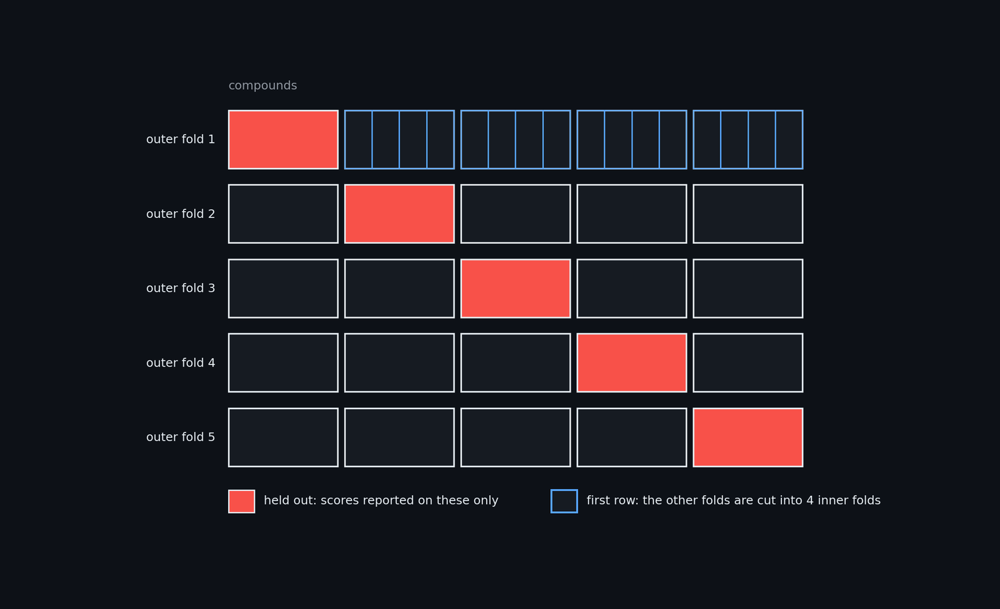

**Figure: Nested cross-validation as a picture.** Nested cross-validation as a grid. The compounds are cut into 5 outer folds; each outer fold in turn is held out and never used for any choice. The other 4 are cut again into 4 inner folds that give out-of-fold predictions on which the models are compared, the blend is fitted and the call threshold is set. The whole procedure is repeated with new random cuts (15 outer folds in all with the repeats), and the held-out scores are what is reported.

In [135]:
show_figure("arch_nested_cv")

## 6.3 Nested cross-validation: the construction, every loop, what is fitted where

> **Field:** Statistics · Machine learning · Software engineering

*Where this section sits:* sections 6.1 and 6.2 said what must be avoided. This section builds the evaluation that avoids it, the one that every number from Part VII on is computed with, and describes the objects of the code (`cypmode/challenge/nested.py`) that hold it. The final model of Part VIII is built from the same objects, so a reader who understands this section understands how the model was made as well as how it was judged.

**The construction.** Cut the training compounds into $K$ disjoint parts, the **outer folds**. Hold one outer fold out: it is the *outer-validation* set, kept for scoring and never used for any choice. The remaining rows are the *outer-training* set. Cut that set, again, into $M$ parts, the **inner folds**. Everything that involves a choice, every candidate's fit, the picking of a member, the weights of a blend, the operating threshold, happens inside the outer-training set, with the inner folds supplying the out-of-fold predictions on
which the choices are made (a model predicts each inner fold after being fitted on the others, so every outer-training row gets a prediction from a model that did not see it). When the choices are frozen, the whole procedure is fitted once more on the entire outer-training set and its pick is scored on the outer-validation set. That is one outer score. Repeat it for each of the $K$ outer folds, and again for $R$ different random partitions (the **repeats**), and the $J = KR$ outer scores are the evaluation of the procedure. With $T_j$ the
outer-training rows of the $j$-th outer fold, $V_j$ its outer-validation rows and $\Pi(T_j)$ the whole procedure (every choice) fitted using $T_j$ alone, and $S(V_j ;\ \Pi(T_j))$ the score (for example the AUC) of its predictions for $V_j$,

$$\hat S_{\text{nested}} \;=\; \frac{1}{J} \sum_{j=1}^{J} S\bigl(V_j ;\ \Pi(T_j)\bigr).$$

The project uses $K = 5$, $M = 4$ and $R = 3$ (and, for confirmation, $K = 10$, section 6.7). The plan is a plain table of index sets: a **task** says "fit a model on these rows and predict those rows", and a prediction is the output of one task for one candidate. Because the plan is data and not code, any program in any environment can carry out a task (LightGBM here, a neural network in another process, a message-passing network in a third; section 12.4 explains why they must not share a process) and
write its predictions into a **prediction cache**, one file for each combination of candidate and task, named after the plan's identity. A selector then reads only the inner predictions of an outer fold, and `nested_evaluate` scores what it chose on the outer rows.

A toy makes the geometry clear: 24 compounds, 4 outer folds and 3 inner folds, drawn for the first outer fold. The cells of the first row are the rows kept back for the outer score; in each of the three rows below it, the blue cells are the rows a model is fitted on and the green cells the rows it predicts, and the orange cells, always the same, are the held-out rows that never appear as blue or green.

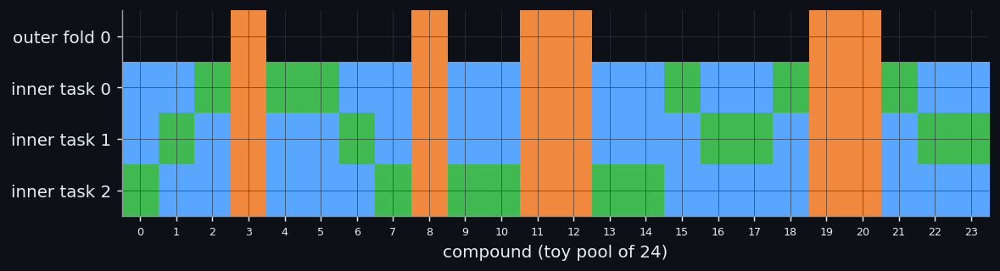

In [136]:
# The plan on a toy of 24 compounds (4 outer folds, 3 inner folds, one repeat), drawn for the first outer fold: every compound is one cell. Orange: kept back for the outer score of this fold. The three rows below
# it show the three inner tasks; blue cells are the rows a model is fitted on, green cells the rows it predicts. A compound is never in an outer-validation role and in an inner task of the same outer fold.
from cypmode.challenge.nested import NestedPlan as Plan

toy = Plan(pool=np.arange(24), y=np.array([0, 1] * 12), repeats=1, outer_splits=4, inner_splits=3, seed=0)
outer_refit = toy.task(0, 0, OUTER_REFIT)
grid = np.zeros((4, 24))
grid[0, outer_refit.evaluate] = 3                                     # kept back
for inner in range(3):
    task = toy.task(0, 0, inner)
    grid[1 + inner, task.train] = 1
    grid[1 + inner, task.evaluate] = 2
    grid[1 + inner, outer_refit.evaluate] = 3
from matplotlib.colors import ListedColormap

fig, axis = plt.subplots(figsize=(9.2, 2.6))
axis.imshow(grid, cmap=ListedColormap([theme["background"], theme["blue"], theme["green"], theme["orange"]]), aspect="auto", vmin=0, vmax=3)
axis.set_yticks(range(4), ["outer fold 0", "inner task 0", "inner task 1", "inner task 2"])
axis.set_xticks(range(24), [str(i) for i in range(24)], fontsize=7)
axis.set_xlabel("compound (toy pool of 24)")
tidy(axis, theme)
fig.tight_layout()
toy_inner_sizes = [(len(toy.task(0, 0, i).train), len(toy.task(0, 0, i).evaluate)) for i in range(3)]
toy_outer_size = len(outer_refit.evaluate)

In the toy the outer-validation set has 6 compounds, and the three inner tasks fit on 12 and predict 6 rows each, all of them among the other 18. A figure can show that the orange cells are never blue or green in this one fold; the next cell shows it by *testing* it, on the real plan of CYP3A4, for every one of the 15 outer folds, and reports the size of the plan.

In [137]:
# The real plan, checked by code. For every outer fold: (a) the inner tasks together predict every outer-training row exactly once, (b) no inner task touches an outer-validation row, (c) the outer refit is fitted on
# exactly the outer-training rows. Then the size of the plan, and the identity rule: asking for more repeats must not change the plan, so that earlier predictions are reused.
problems = []
for repeat, outer in plan.outer_folds():
    refit = plan.task(repeat, outer, OUTER_REFIT)
    inner_tasks = plan.inner_tasks(repeat, outer)
    predicted = np.concatenate([t.evaluate for t in inner_tasks])
    touched = np.unique(np.concatenate([np.concatenate([t.train, t.evaluate]) for t in inner_tasks]))
    problems += [("a", repeat, outer)] * (len(predicted) != len(set(predicted.tolist())) or set(predicted.tolist()) != set(refit.train.tolist()))
    problems += [("b", repeat, outer)] * bool(set(touched.tolist()) & set(refit.evaluate.tolist()))
kinds = pd.Series(["inner" if t.inner >= 0 else ("outer refit" if t.inner == OUTER_REFIT else ("deployment fit" if t.inner == -2 else "other")) for t in plan.tasks()]).value_counts()
tasks_per_repeat = int(len([t for t in plan.tasks() if t.repeat == 0]))
fewer_repeats = NestedPlan(plan.pool, plan.y, 1, plan.outer_splits, plan.inner_splits, plan.seed, plan.external)
print(f"pool {len(plan.pool)} compounds; {plan.repeats} repeats x {plan.outer_splits} outer folds x {plan.inner_splits} inner folds; tasks: {({k: int(v) for k, v in kinds.items()})}; {tasks_per_repeat} per repeat; problems found: {problems}")
print(f"plan id {plan.plan_id}; with one repeat instead of three: {fewer_repeats.plan_id}; the same: {fewer_repeats.plan_id == plan.plan_id}")
files_per_member = len(list((NESTED_ROOT / "cache" / plan.plan_id / default_names[0]).glob("*.npy")))
n_members_cached = len(cache.candidates())
n_plan_tasks = len(plan.tasks())
print("sizes of one outer fold:", sizes_check)

pool 2334 compounds; 3 repeats x 5 outer folds x 4 inner folds; tasks: {'inner': 64, 'outer refit': 15, 'deployment fit': 1}; 25 per repeat; problems found: []
plan id 66a3fcaa4d0ffe61; with one repeat instead of three: 66a3fcaa4d0ffe61; the same: True
sizes of one outer fold: {'outer train': 1867, 'outer validation': 467, 'inner train': 1400, 'inner validation': 467}


The real plan covers 2,334 compounds and has 80 tasks: 25 for each of the 3 repeats (five outer folds, each with four inner tasks and one outer refit) and a last set for the deployment (four inner tasks on the whole pool and the fit of the whole pool, which predicts the blinded test compounds). The three checks of the cell found 0 problems: in every outer fold the inner tasks together predict each outer-training row exactly once, no inner task touches a row of the outer-validation set, and the outer refit is fitted on
exactly the outer-training rows. One outer fold has 1,867 rows to fit on and 467 to score; an inner task fits on 1,400 and predicts 467, which is the size effect of 6.2 in numbers. The identity of the plan, 66a3fcaa4d0ffe61, does not depend on the number of repeats (the plan with one repeat has the same one), which is deliberate: asking for more repeats later reuses every prediction already stored and computes only the new tasks,
and that is how the confirmatory repeats of 6.7 were added without redoing anything. Every member of the default stack has 80 files in the cache, one per task, and the cache holds 114 members in all, the members of the stack and of every addition that was tested.

**What this buys, and what it costs.** The procedure never lets a choice see the rows that score it, at any level, and its cost is computation: each member has to be fitted for every task, 25 fits per repeat instead of one, and a neural member that takes minutes per fit takes days of the machine's time (Part XII describes the queue that makes this affordable). The benefit is that the single number at the end, the outer score of the whole pipeline, is an estimate that can be defended, and that two pipelines can be compared fairly because they are scored on the same outer folds (6.5). It also gives the final build of
Part VIII its structure: the deployment task is exactly an outer fold in which the outer-validation set is the blinded test set.

*On what actually ran.* `NestedPlan` builds the folds (stratified on the label, and optionally keeping whole chemical groups together, section 3.6), saves them as `plan.npz`, and gives them their identity from the pool, the labels and the fold counts. `PredictionCache` stores one `float32` array per candidate and task under `data/tdi_track/outputs/nested/<enzyme>/cache/<plan id>/<candidate>/r<repeat>_k<outer>_m<inner>.npy`. `Selector` and its subclasses (`BestSingle`, `OneStandardError`, `MeanOfTop`, `StackedLogit`) see the inner out-of-fold matrix and return a frozen choice;
`nested_evaluate` scores it on the outer rows and reports the two scores and their difference. `cypmode/challenge/nested_runners.py` fills the cache for the LightGBM members and the module of Part IV for the neural ones; `nested_deploy.py` and `nested_report.py` apply the same selection to the whole pool and print the comparison of members and procedures.

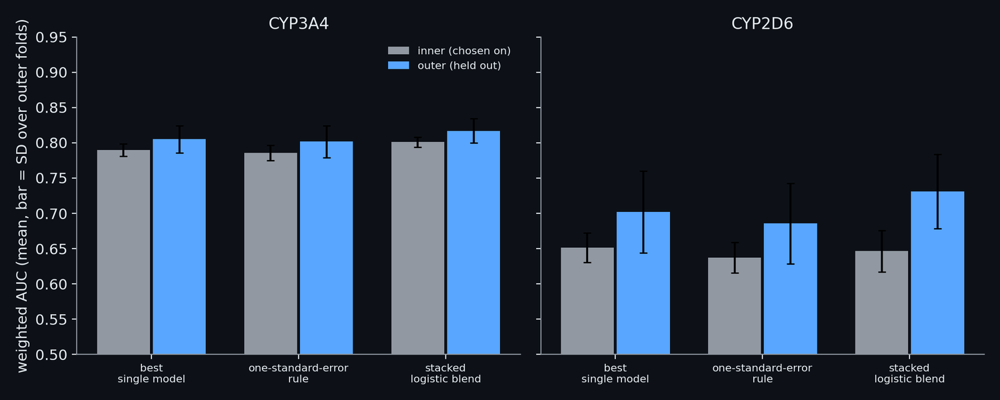

**Figure: What a model reports about itself and what held-out folds show.** What each way of choosing a model reports about itself (inner score, measured on the data it was chosen on) against what the held-out outer folds then show (outer score): weighted AUC at z0 = 1.0, mean over the 15 outer folds of the 5-fold design, rebuilt from the cached predictions. CYP3A4 best single model: inner 0.790, outer 0.805; CYP3A4 one-standard-error rule: inner 0.786, outer 0.802; CYP3A4 stacked logistic blend: inner 0.801, outer 0.817; CYP2D6 best single model: inner 0.651, outer 0.702; CYP2D6 one-standard-error rule: inner 0.637, outer 0.686; CYP2D6 stacked logistic blend: inner 0.646, outer 0.731. A selector's inner score is not an estimate of its future score; only the outer score is reported. The size and even the sign of the gap depend on the weighting, which is why the comparison is made on outer folds that no choice has seen.

In [138]:
show_figure("ml_selection_optimism")

## 6.4 Making validation resemble the test: similarity, prevalence and confident labels

> **Field:** Statistics · Cheminformatics

*Where this section sits:* the nested construction of 6.3 keeps account of *whether* a choice sees its test rows. It says nothing about *which* rows are the test. The score of the challenge is computed on 750 blinded compounds that are not a random sample of the training file: section 2.7 showed how they differ, and section 2.10 how many of them are positives. This section turns those differences into a **yardstick**, a way of weighting the outer-validation rows so that the score measures what the challenge will measure. Every outer score of Parts VII to XI is computed with it.

**Why the validation rows are weighted.** Suppose a model is better on compounds close to the training set and worse on compounds far from it, as read-across models are (section 7.3). A random validation fold has some mixture of close and far compounds, the blinded test set has another, and the score of the model on the fold is the wrong average for the test. The remedy is **importance weighting**: give every validation compound a weight $w$ so that the weighted validation set has the same mixture as the test set. For a single property that is split into bins, with $p_b$ the share of the validation compounds in bin $b$ and $q_b$ the share of the test compounds in it, the weight of a compound in bin $b$ is

$$w(b) \;=\; \frac{q_b}{p_b},$$

the density ratio of section 2.7: a bin that is over-represented in the validation set is turned down, one that is under-represented is turned up. The property the project uses is the one that matters most for a model that reads across analogues: the highest Tanimoto similarity (section 3.2) of a compound to the compounds the model was fitted on. It is a single number per compound, so the weights are well conditioned, unlike weights that try to match the whole fingerprint (a classifier trained to tell the training compounds from the test compounds does so almost perfectly, and the weights it implies put nearly all the weight on a handful of compounds; `validation_matching` records the figures it found). The first cell computes the profile for the first outer fold: the nearest-training similarity of the
validation compounds, against that of the blinded test compounds measured against the same training rows (against a random 80 percent of them, since a validation compound's training set holds about that share of the pool).

median nearest-training similarity: validation 0.444, test 0.424; share at or above 0.5: 0.33 and 0.36
effective sample size of the weights of this fold: 363 of 467 validation compounds


| nearest-training similarity | share of validation compounds | share of test compounds | weight |
| --- | --- | --- | --- |
| 0.0 to 0.3 | 0.049 | 0.084 | 1.706 |
| 0.3 to 0.4 | 0.206 | 0.364 | 1.771 |
| 0.4 to 0.5 | 0.411 | 0.195 | 0.473 |
| 0.5 to 0.6 | 0.186 | 0.225 | 1.210 |
| 0.6 to 0.7 | 0.094 | 0.107 | 1.132 |
| 0.7 to 0.8 | 0.045 | 0.023 | 0.504 |
| 0.8 to 0.9 | 0.009 | 0.003 | 0.311 |
| 0.9 to 1.0 | 0.000 | 0.000 | 0.000 |

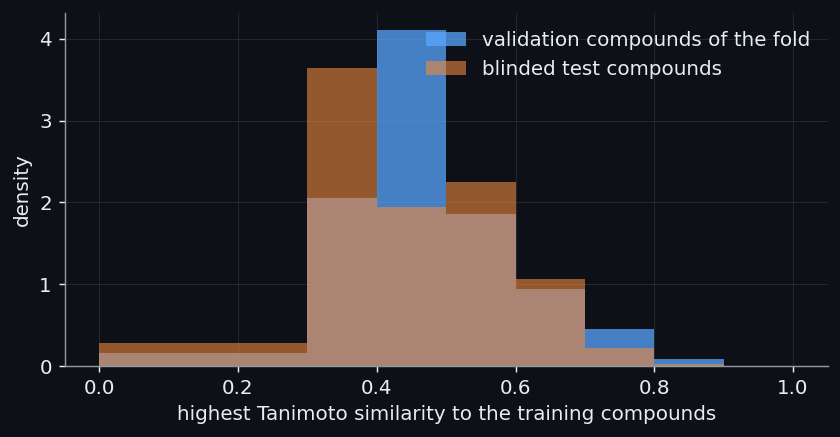

In [139]:
# How close a validation compound is to the training compounds, against how close a test compound is. For the first outer fold of the plan: the highest Tanimoto similarity (section 3.2) of every outer-validation
# compound to the outer-training compounds, and of every blinded test compound to the same training compounds (a random 80 % of them, as the validation compounds' own training set has no more than that).
from cypmode.challenge.leaderboard_prior import estimate_from_csv
from cypmode.challenge.validation_matching import DEFAULT_BINS, SimilarityMatcher, nearest_neighbor_similarity, prior_weights, similarity_weights, weighted_auc, weighted_mcc

bits_all = feature_store["morgan_bits"].astype(np.float32)               # train rows first, then the 750 blinded test rows, as in the plan
matcher = SimilarityMatcher(bits_all, plan.external)
refit_0 = plan.task(0, 0, OUTER_REFIT)
validation_nn = nearest_neighbor_similarity(bits_all[refit_0.evaluate], bits_all[refit_0.train])
rng_sim = np.random.default_rng(0)
subset = refit_0.train[rng_sim.random(len(refit_0.train)) < 0.8]
test_nn = nearest_neighbor_similarity(bits_all[plan.external], bits_all[subset])
fold_weights = similarity_weights(validation_nn, test_nn)
bin_rows = []
for lo, hi in zip(DEFAULT_BINS[:-1], DEFAULT_BINS[1:]):
    in_validation, in_test = (validation_nn >= lo) & (validation_nn < hi), (test_nn >= lo) & (test_nn < hi)
    bin_rows.append({"nearest-training similarity": f"{lo:.1f} to {min(hi, 1.0):.1f}", "share of validation compounds": in_validation.mean(), "share of test compounds": in_test.mean(),
                     "weight": float(in_test.mean() / in_validation.mean()) if in_validation.any() else 0.0})
show_table(pd.DataFrame(bin_rows), floatfmt=".3f")
kish_ess = float(fold_weights.sum() ** 2 / (fold_weights**2).sum())
print(f"median nearest-training similarity: validation {np.median(validation_nn):.3f}, test {np.median(test_nn):.3f}; share at or above 0.5: {np.mean(validation_nn >= 0.5):.2f} and {np.mean(test_nn >= 0.5):.2f}")
print(f"effective sample size of the weights of this fold: {kish_ess:.0f} of {len(fold_weights)} validation compounds")
median_validation, median_test = float(np.median(validation_nn)), float(np.median(test_nn))
share_validation_close, share_test_close = float(np.mean(validation_nn >= 0.5)), float(np.mean(test_nn >= 0.5))
n_validation_fold = len(fold_weights)

fig, axis = plt.subplots(figsize=(6.6, 3.5))
axis.hist(validation_nn, bins=DEFAULT_BINS[:-1].tolist() + [1.0], density=True, alpha=0.75, color=theme["blue"], label="validation compounds of the fold")
axis.hist(test_nn, bins=DEFAULT_BINS[:-1].tolist() + [1.0], density=True, alpha=0.6, color=theme["orange"], label="blinded test compounds")
axis.set(xlabel="highest Tanimoto similarity to the training compounds", ylabel="density")
axis.legend(frameon=False)
tidy(axis, theme)
fig.tight_layout()

For this fold the validation compounds have a median nearest-training similarity of 0.444 and the test compounds of 0.424; 33% of the validation compounds and 36% of the test compounds have a nearest neighbour at 0.5 or more. The profiles differ in shape more than in centre: the test compounds crowd the band from 0.3 to 0.4 (the table: 36% against 21%) and are thin in the band from 0.4 to 0.5
(19% against 41%), and the weights, between 0 and about 1.8, undo that. Weighting costs information: a weighted sample is worth fewer independent compounds than it contains. Kish's **effective sample size**, $n_{\text{eff}} = (\sum_i w_i)^2 / \sum_i w_i^2$ with $w_i$ the weight of the $i$-th compound (section 2.7), is 363 for the 467 validation compounds of this fold, a loss the project accepts because the alternative is to measure the wrong thing precisely.
(The reference of this fold is the pool of 2,334 compounds with both arms measured; against the whole training file, which the test compounds were designed as analogues of, the picture is different, and the module `validation_matching` states the numbers it found there.)

**The weighted metrics.** With a weight $w_i$ for each compound, a metric counts each compound in proportion to it. The weighted AUC is the probability that a positive is ranked above a negative with each pair counted in proportion to the product of the two weights, ties half,

$$\mathrm{AUC}_w \;=\; \frac{\sum_{i \in +}\sum_{j \in -} w_i\, w_j \left( \mathbb{1}[s_i > s_j] + \tfrac12\, \mathbb{1}[s_i = s_j] \right)}{\left(\sum_{i \in +} w_i\right)\left(\sum_{j \in -} w_j\right)},$$

where $s_i$ is the score of compound $i$, $j$ runs over the negatives and $i$ over the positives, and $+$ and $-$ stand for the two classes. The weighted MCC is the formula of section 4.10 with the four counts of the confusion table replaced by sums of weights. The next cell writes both out for the first fold, for the best single member of the stack, and checks them against the library.

In [140]:
# The weighted AUC written out and checked on one fold: the probability that a positive is ranked above a negative, with every compound counted in proportion to its weight. Then the weighted MCC by its
# counts. Both are checked against the library.
y_fold = plan.labels(refit_0.evaluate)
scores_fold = cache.get("lgbm_A+fps_deep", refit_0)
positive, negative = y_fold == 1, y_fold == 0
pair_weight = fold_weights[positive][:, None] * fold_weights[negative][None, :]
wins = (scores_fold[positive][:, None] > scores_fold[negative][None, :]) + 0.5 * (scores_fold[positive][:, None] == scores_fold[negative][None, :])
auc_by_hand = float((pair_weight * wins).sum() / (fold_weights[positive].sum() * fold_weights[negative].sum()))
auc_library = float(roc_auc_score(y_fold, scores_fold, sample_weight=fold_weights))
called = scores_fold >= np.quantile(scores_fold, 0.7)
tp, fp = (fold_weights * (called & positive)).sum(), (fold_weights * (called & negative)).sum()
fn, tn = (fold_weights * (~called & positive)).sum(), (fold_weights * (~called & negative)).sum()
mcc_by_hand = float((tp * tn - fp * fn) / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
mcc_library = weighted_mcc(y_fold, called.astype(int), fold_weights)
print(f"weighted AUC by hand {auc_by_hand:.5f}, by the library {auc_library:.5f}; unweighted {roc_auc_score(y_fold, scores_fold):.5f}")
print(f"weighted MCC by the counts {mcc_by_hand:.5f}, by the project's function {mcc_library:.5f}")

weighted AUC by hand 0.75411, by the library 0.75411; unweighted 0.76623
weighted MCC by the counts 0.30963, by the project's function 0.30963


The weighted AUC by hand is 0.75411 and the library's is 0.75411; the weighted MCC by the counts is 0.30963 and the project's function gives 0.30963. The two pairs agree to every printed digit, so nothing in the weighting is a black box.

**Two more corrections, and the ladder.** The similarity weights are the first of three corrections. The second is the **positive rate**. The scored positive rate is known approximately (section 2.10: about 0.31 for CYP3A4) and is not the rate in the training file, so the classes are re-weighted: positives by $\pi_{\text{target}}/\pi_{\text{observed}}$ and negatives by $(1-\pi_{\text{target}})/(1-\pi_{\text{observed}})$, with $\pi$ the positive rate. The AUC does not depend on the positive rate (section 4.10), so this correction cannot change it and matters only for metrics that do, the MCC and the precision. The third is the **confident labels**: the challenge scores only the compounds whose label can be assigned with confidence (section 2.5), whose exact rule is unknown, so the project
keeps the compounds with $|z| \ge z_0$, where $z = (s - \log_{10} 2)/\mathrm{sd}(s)$ is the distance of the shift from the labelling threshold in units of its measurement noise, and repeats every analysis at two cut-offs, $z_0 = 1.0$ and $z_0 = 1.96$. The combined weight of a compound is the product of its three factors. The cell builds the yardstick one correction at a time for the best single member and shows what each does to the measured AUC and to the MCC of calling the top 31 percent positive.

In [141]:
# The yardstick, built up one correction at a time, for one member of the stack (the best single member of 6.2) over all 15 outer folds. Each row adds a correction to the one above: similarity to the test
# compounds; the positive rate of the scored set (estimated from the public leaderboard, section 2.10); and the confident labels only, at the two cut-offs the project uses (section 2.5).
from cypmode.challenge.label_confidence import confidence_z

target_prevalence = estimate_from_csv(ROOT / "data/tdi_track/inputs/leaderboard_snapshots/interim_CYP3A4_2026-10-04.csv")["prevalence"]
z_train = confidence_z(train_file, "CYP3A4")
z_all = np.concatenate([z_train, np.full(len(plan.external), np.nan)])             # indexed like the plan's rows; the test rows have no label and no z
from cypmode.challenge.nested import call_top_fraction

ladder_cells = {"no correction": [], "similar to the test": [], "and the scored positive rate": [], "and confident labels, z0 = 1.0": [], "and confident labels, z0 = 1.96": []}
ladder_mcc = {name: [] for name in ladder_cells}                       # the same rungs for the MCC of calling the top 31 % positive (the scored rate)
n_kept = {1.0: [], 1.96: []}
for repeat, outer in plan.outer_folds():
    refit = plan.task(repeat, outer, OUTER_REFIT)
    y_out, s_out = plan.labels(refit.evaluate), cache.get("lgbm_A+fps_deep", refit)
    w_sim = matcher(refit.evaluate, refit.train)
    w_prior = w_sim * prior_weights(y_out, target_prevalence)
    called_out = call_top_fraction(s_out, target_prevalence).astype(int)
    weights_by_rung = {"no correction": None, "similar to the test": w_sim, "and the scored positive rate": w_prior}
    for z0, label in ((1.0, "and confident labels, z0 = 1.0"), (1.96, "and confident labels, z0 = 1.96")):
        keep = np.nan_to_num(z_all[refit.evaluate], nan=0.0) >= z0
        n_kept[z0].append(keep.mean())
        weights_by_rung[label] = w_prior * keep
    for label, weights in weights_by_rung.items():
        ladder_cells[label].append(roc_auc_score(y_out, s_out, sample_weight=weights))
        ladder_mcc[label].append(weighted_mcc(y_out, called_out, weights))
ladder = pd.DataFrame({"yardstick": list(ladder_cells), "mean AUC over the 15 outer folds": [float(np.mean(v)) for v in ladder_cells.values()],
                       "spread of the AUC over the folds": [float(np.std(v, ddof=1)) for v in ladder_cells.values()], "mean MCC at the scored rate": [float(np.mean(v)) for v in ladder_mcc.values()]})
show_table(ladder, floatfmt=".4f")
print(f"target positive rate (leaderboard estimate): {target_prevalence:.4f}; share of validation compounds with a confident label: z0=1.0 {np.mean(n_kept[1.0]):.2f}, z0=1.96 {np.mean(n_kept[1.96]):.2f}")
ladder_values = dict(zip(ladder["yardstick"], ladder["mean AUC over the 15 outer folds"]))
ladder_mcc_values = dict(zip(ladder["yardstick"], ladder["mean MCC at the scored rate"]))
share_kept_1, share_kept_196 = float(np.mean(n_kept[1.0])), float(np.mean(n_kept[1.96]))

target positive rate (leaderboard estimate): 0.3097; share of validation compounds with a confident label: z0=1.0 0.83, z0=1.96 0.64


| yardstick | mean AUC over the 15 outer folds | spread of the AUC over the folds | mean MCC at the scored rate |
| --- | --- | --- | --- |
| no correction | 0.7731 | 0.0168 | 0.3652 |
| similar to the test | 0.7734 | 0.0186 | 0.3654 |
| and the scored positive rate | 0.7734 | 0.0186 | 0.3624 |
| and confident labels, z0 = 1.0 | 0.8027 | 0.0229 | 0.4066 |
| and confident labels, z0 = 1.96 | 0.8354 | 0.0204 | 0.4601 |

The table is the lesson of the section. The similarity correction moves the AUC from 0.7731 to 0.7734, almost nothing for this member and this pool, and the positive rate leaves it exactly where it was (0.7734), as it must, while it moves the MCC from 0.365 to 0.362. The confident labels change the measured level a great deal: 0.8027 at $z_0 = 1.0$, where 83% of the compounds are kept, and
0.8354 at $z_0 = 1.96$, where 64% are. The model did not improve; the yardstick became cleaner, because the compounds whose label is a coin flip are no longer counted against it. That is the reason the same analysis is repeated at both cut-offs, and the reason an AUC is meaningful only together with the yardstick that produced it.

What the yardstick does *not* do is as important. It cannot turn a cross-validation number into a forecast of the leaderboard: even with all three corrections the official baseline's cross-validated MCC stays below its score on the leaderboard (the project measured the gap on the baseline, `validation_matching` records it), because the test set differs from any training fold in ways that no one-dimensional weight captures. So an absolute number from this yardstick is never quoted as what a submission will score; what is meaningful is the *ordering* of candidates under the same conditions, and the size of the difference between them with its uncertainty, which is the subject of the next section.

*On what actually ran.* `similarity_weights` and `SimilarityMatcher` (in `cypmode/challenge/validation_matching.py`) bin the nearest-training similarity (the bins `DEFAULT_BINS`, eight of them, from 0 to 1) and give each validation compound the ratio of the test share to the validation share of its bin, a bin that the validation rows never populate carrying no weight; `prior_weights` and `weighted_mcc` do the class correction and the weighted metric; `confident_weights` in `label_confidence.py` multiplies a weight function by the indicator that $|z| \ge z_0$. `nested_evaluate` applies the product to the outer-validation rows and, for the selectors' own inner scores, to the inner rows. No label and no hand-set number enters the similarity weights; the target positive rate comes from the leaderboard estimate of section 2.10.

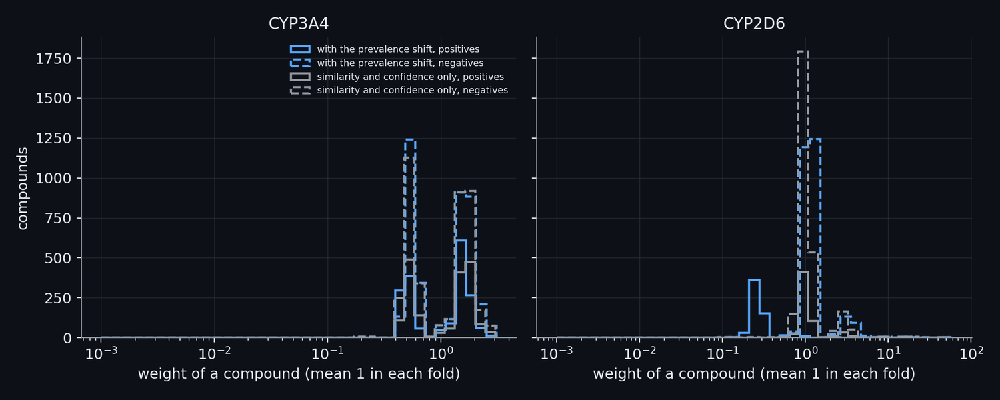

**Figure: The weights that make a fold resemble the test.** The weights that make a held-out fold resemble the scored population: a compound counts in proportion to its similarity to the blinded test structures, to the prevalence of its class in the test set, and only if its label is confident. For every outer fold of the 5-fold design the weights are scaled to a mean of one, and the figure shows their distribution for the positives and the negatives, with and without the shift of the prevalence. CYP3A4: the top tenth of the compounds carries 21% of the weight (with the prevalence shift) and 21% without it; CYP2D6: the top tenth of the compounds carries 38% of the weight (with the prevalence shift) and 36% without it. A weighted score is therefore an estimate for the scored population and not for the training set, and its effective sample size is smaller than the number of rows.

In [142]:
show_figure("ml_evaluation_weights")

## 6.5 Comparing two models: why folds are correlated, and the corrected resampled t

> **Field:** Statistics

*Where this section sits:* 6.3 gave a score for one procedure and 6.4 made it fit the challenge. The questions of the project are comparisons: does adding a block of features help, does one model beat another. A comparison needs more than two scores, it needs a statement of how far their difference can be trusted, and the obvious tools give a wrong answer. This section shows the failure, derives the correction the project uses, and applies the correction's close relative, **Holm's adjustment** for running many tests at once, to a family of tests. It is the section that the gate of 6.7 and every verdict of Parts VII, IX and X rest on.

**The setting.** Two procedures A and B are scored on the same $J$ outer folds (folds and repeats together, $J = KR$, section 6.3), giving $J$ pairs of scores and $J$ differences $d_1, \dots, d_J$ with $d_j = S_{A,j} - S_{B,j}$. Let $\bar d$ be their mean, $s^2$ their sample variance (section 2.5), and $n_{\text{train}}$ and $n_{\text{test}}$ the sizes of the training and the validation part of one fold. The textbook test of "is the mean difference zero?" is the paired t statistic $t = \bar d / \sqrt{s^2/J}$, compared with a Student's t distribution with $J-1$ degrees of freedom. It rests on the $d_j$ being independent draws, and they are not. The training sets of two folds share most of their compounds (with five folds, any two share a fraction $(K-2)/(K-1)$ of their rows), so a compound that is hard to predict makes the score of
every fold that contains it in its validation part lower together and, more important, two folds fitted on nearly the same compounds produce nearly the same models, so their errors move together. Positively correlated differences carry less information than $J$ independent ones, and $s^2/J$ is too small an estimate of the variance of $\bar d$.

**Seeing it fail.** The cell makes the claim testable. It simulates 300 data sets of 600 compounds with 20 features of equal strength; model A uses ten of the features and model B the other ten, so that the two are equal in expected quality and any difference is chance. Each is scored by five-fold cross-validation repeated three times ($J = 15$), and the difference is tested two ways: the naive paired t, and the corrected resampled t of Nadeau and Bengio (2003) that the project uses and that is derived below. A test that works rejects in about 5 percent of these data sets. The simulation is repeated with a second setting in which A truly is better, to see what the correction costs.

In [143]:
# Two classifiers that are equal in truth, compared by cross-validation on many simulated data sets. Each data set has 600 compounds with 20 features of the same strength; model A uses 10 of the features and model B
# the other 10, so that the two have the same expected AUC and any difference between them is chance. Each is scored by 5-fold cross-validation repeated 3 times (J = 15 folds); the difference of the AUCs is tested
# with the naive paired t-test and with the corrected resampled t-test of the project (cypmode/challenge/model_comparison.py). A test that works rejects in about 5 % of the data sets.
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

from cypmode.challenge.model_comparison import corrected_resampled_t, naive_paired_t

def simulate_differences(rng, n=600, strength_a=0.35, strength_b=0.35, folds=5, repeats=3):
    X = rng.normal(size=(n, 20))
    logit = X[:, :10].sum(axis=1) * strength_a + X[:, 10:].sum(axis=1) * strength_b
    y = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    differences = []
    for repeat in range(repeats):
        for fit_rows, held in StratifiedKFold(folds, shuffle=True, random_state=repeat).split(X, y):
            auc = [roc_auc_score(y[held], LogisticRegression(max_iter=300).fit(X[fit_rows][:, cols], y[fit_rows]).decision_function(X[held][:, cols])) for cols in (slice(0, 10), slice(10, 20))]
            differences.append(auc[0] - auc[1])
    return np.array(differences)

rng_null = np.random.default_rng(11)
n_data_sets = 300
null_differences = np.array([simulate_differences(rng_null) for _ in range(n_data_sets)])
n_train_sim, n_test_sim = 480, 120
rejections = {"naive paired t": 0, "corrected resampled t": 0}
for d in null_differences:
    rejections["naive paired t"] += naive_paired_t(d).p_value < 0.05
    rejections["corrected resampled t"] += corrected_resampled_t(d, n_train_sim, n_test_sim).p_value < 0.05
rejection_rates = {k: v / n_data_sets for k, v in rejections.items()}

# the same comparison when model A really is better (its features are stronger)
rng_alt = np.random.default_rng(12)
alt_differences = np.array([simulate_differences(rng_alt, strength_a=0.35, strength_b=0.26) for _ in range(n_data_sets)])
alt_rates = {"naive paired t": float(np.mean([naive_paired_t(d).p_value < 0.05 for d in alt_differences])), "corrected resampled t": float(np.mean([corrected_resampled_t(d, n_train_sim, n_test_sim).p_value < 0.05 for d in alt_differences]))}
rates_table = pd.DataFrame([{"test": name, "rejects when the models are equal": rejection_rates[name], "rejects when A is truly better": alt_rates[name]} for name in rejection_rates])
show_table(rates_table, floatfmt=".3f")
print(f"mean true AUC advantage of A in the second setting: {alt_differences.mean():+.4f}")

mean true AUC advantage of A in the second setting: +0.0668


| test | rejects when the models are equal | rejects when A is truly better |
| --- | --- | --- |
| naive paired t | 0.343 | 0.813 |
| corrected resampled t | 0.030 | 0.393 |

When the two models are equal, the naive test declares a difference significant at the 5 percent level in 34% of the data sets, 7 times too often, and the corrected test in 3%. In the second setting, with a true AUC advantage of 0.067 for A, the naive test finds it in 81% of the data sets and the corrected test in 39%. The correction has a price: it is conservative, and with this design it misses the real difference in 61% of the data sets. The naive test's higher **power** (the chance of finding a difference that is really there) is not an advantage, since it is bought by rejecting equal models a third of the time.
(The price is the subject of section 6.7: a design with more folds buys it back.)

**Deriving the correction.** Let the $J$ differences have a common variance $\sigma^2$ and a common correlation $\rho$ between any two of them. The variance of their mean is then $\sigma^2\,(1/J + (1 - 1/J)\,\rho)$, the first term what independence would give and the second what the correlation adds. The sample variance $s^2$ is computed around the mean of the same $J$ values, and its expected value is $\sigma^2 (1-\rho)$, which is smaller than $\sigma^2$ for positive $\rho$. To estimate the variance of the mean from $s^2$, divide by $(1-\rho)$ and multiply by the factor above:

$$\mathrm{Var}_{\text{est}}(\bar d) \;=\; s^2\,\frac{1/J + (1 - 1/J)\,\rho}{1 - \rho} \;=\; s^2\left( \frac{1}{J} + \frac{\rho}{1-\rho} \right).$$

What remains is $\rho$. Nadeau and Bengio (2003) argued that two resampled scores share, in the sense of correlation, about the fraction of data that is in common between their test parts and the whole, which gives $\rho \approx n_{\text{test}}/(n_{\text{test}} + n_{\text{train}})$, and then $\rho/(1-\rho) = n_{\text{test}}/n_{\text{train}}$. So

$$t_{\text{corrected}} \;=\; \frac{\bar d}{\sqrt{\left(\dfrac{1}{J} + \dfrac{n_{\text{test}}}{n_{\text{train}}}\right) s^2}},$$

compared with a Student's t distribution with $J - 1$ degrees of freedom. The only change from the naive statistic is the term $n_{\text{test}}/n_{\text{train}}$ added to $1/J$; for the project's five outer folds it is $1/4$, and the factor in brackets is $1/15 + 1/4 = 0.317$, nearly five times the naive $1/15$. The next cell checks the derivation instead of trusting it, on the simulation of the equal models: the real variance of the mean difference seen from one data set to the next, the naive estimate of it and the corrected estimate, and the correlation between the differences of two folds.

In [144]:
# Why the naive test fails, measured. The folds are not independent observations: their training sets overlap. Over the simulated data sets (the equal-models setting), three quantities: the variance of the mean difference
# actually seen from one data set to the next; the average of the naive estimate of that variance, s^2 / J, with s^2 the sample variance of the J differences; and the average of the corrected estimate,
# s^2 (1/J + n_test/n_train). The correlation between the differences of two folds of the same data set is measured too.
J = null_differences.shape[1]
true_variance_of_mean = float(np.var(null_differences.mean(axis=1), ddof=1))
s_squared = null_differences.var(axis=1, ddof=1)
naive_estimate = float(np.mean(s_squared / J))
corrected_estimate = float(np.mean(s_squared * (1 / J + n_test_sim / n_train_sim)))
correlations = np.corrcoef(null_differences.T)
mean_correlation = float(correlations[np.triu_indices(J, 1)].mean())
rho_expected = n_test_sim / (n_test_sim + n_train_sim)
variance_rows = [{"quantity": "variance of the mean difference, seen over the data sets", "value": true_variance_of_mean},
                 {"quantity": "naive estimate of it, s^2 / J", "value": naive_estimate},
                 {"quantity": "corrected estimate, s^2 (1/J + n_test/n_train)", "value": corrected_estimate}]
show_table(pd.DataFrame(variance_rows), floatfmt=".2e")
print(f"average correlation between the differences of two folds: {mean_correlation:.3f}; n_test/(n_test+n_train) = {rho_expected:.3f}")
naive_ratio, corrected_ratio = naive_estimate / true_variance_of_mean, corrected_estimate / true_variance_of_mean

average correlation between the differences of two folds: 0.172; n_test/(n_test+n_train) = 0.200


| quantity | value |
| --- | --- |
| variance of the mean difference, seen over the data sets | 1.15e-03 |
| naive estimate of it, s^2 / J | 2.79e-04 |
| corrected estimate, s^2 (1/J + n_test/n_train) | 1.32e-03 |

The variance of the mean difference that the data sets actually show is 1.15e-03. The naive estimate is 2.79e-04, which is 0.24 of the truth: it is about 4.1 times too small, and that is why the naive test rejects so often. The corrected estimate is 1.32e-03, 1.15 of the truth, a little conservative, and the correlation between the differences of two folds is 0.172, against the 0.200 that the argument predicts. The derivation holds, and the small excess is the conservatism seen in the rates above. The project uses this test for every comparison of two procedures on the same folds (`corrected_resampled_t` in `cypmode/challenge/model_comparison.py`), and keeps the naive one in the module only so that the optimism it adds can be demonstrated, as it was here.

**Many comparisons.** A test with a false-positive rate of 5 percent run on 27 comparisons is expected to flag one or two by chance alone. When a family of comparisons is run and any can be reported, the p-values have to be adjusted for the number of tests. The simplest adjustment, Bonferroni's, multiplies every p-value by the number of tests $m$. **Holm's** step-down adjustment (Holm, 1979) is never less powerful and equally safe: sort the p-values from the smallest, $p_{(1)} \le \dots \le p_{(m)}$, multiply the smallest by $m$, the next by $m-1$, and so on, so that $p_{(k)}$ is multiplied by $m-k+1$, cap each at 1, and then take the running maximum so that the adjusted values never fall as the raw ones rise. The cell writes this out and applies it to a real family: the stacked comparison of every addition that the project tested on CYP3A4, in the logs of its experiments (the default stack with the addition against the default stack, at both cut-offs, the p-value of an addition being the larger of the two, since the gate asks for both).

In [145]:
# A family of comparisons, from the project's own logs: the stacked comparison of every addition tested on CYP3A4 (the default stack plus the addition against the default stack, section 6.7). The gate asks for
# p < 0.05 at both confidence cut-offs, so the p-value of an addition is the larger of the two. Holm's step-down adjustment, written out and checked against the library.
import re

import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

LOG_DIR = ROOT / "data/structure_track/outputs/cyp3a4/logs"
stacked_line = re.compile(r"z0=(1\.0|1\.96)\s+stacked base\+added vs base: AUC ([+-]\d\.\d+) \(p=([\d.]+)")
family = []
for path in sorted(LOG_DIR.glob("*CYP3A4.log")):
    found = {z0: (float(gain), float(p)) for z0, gain, p in stacked_line.findall(path.read_text(errors="ignore"))}
    if "1.0" in found and "1.96" in found:
        family.append({"addition": path.stem.removesuffix("_CYP3A4").removeprefix("aux_"), "gain at z0 1.0": found["1.0"][0], "gain at z0 1.96": found["1.96"][0], "p (larger of the two)": max(found["1.0"][1], found["1.96"][1])})
family = pd.DataFrame(family).sort_values("p (larger of the two)").reset_index(drop=True)

def holm(p_values):
    """Holm's adjusted p-values: the smallest is multiplied by m, the next by m - 1, and so on, with the running maximum taken so that the order of the adjusted values never reverses."""
    m = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(m)
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p_values[index]))
        adjusted[index] = running
    return adjusted

family["Holm-adjusted p"] = holm(family["p (larger of the two)"].to_numpy())
library_holm = multipletests(family["p (larger of the two)"].to_numpy(), method="holm")[1]
holm_agrees = bool(np.allclose(family["Holm-adjusted p"], library_holm))
show_table(family.head(8), floatfmt=".3f")
n_family = len(family)
smallest_raw, smallest_adjusted = float(family["p (larger of the two)"].min()), float(family["Holm-adjusted p"].min())
n_raw_significant = int((family["p (larger of the two)"] < 0.05).sum())
n_adjusted_significant = int((family["Holm-adjusted p"] < 0.05).sum())
print(f"{n_family} additions; raw p below 0.05: {n_raw_significant}; Holm-adjusted p below 0.05: {n_adjusted_significant}; Holm by hand equals the library: {holm_agrees}")

46 additions; raw p below 0.05: 3; Holm-adjusted p below 0.05: 0; Holm by hand equals the library: True


| addition | gain at z0 1.0 | gain at z0 1.96 | p (larger of the two) | Holm-adjusted p |
| --- | --- | --- | --- | --- |
| chemprop_foundation | 0.013 | 0.014 | 0.005 | 0.230 |
| neural | 0.011 | 0.011 | 0.029 | 1.000 |
| neural_f10 | 0.011 | 0.011 | 0.038 | 1.000 |
| physics_compact_f10 | 0.004 | 0.004 | 0.054 | 1.000 |
| atomjepa_head | 0.011 | 0.008 | 0.059 | 1.000 |
| mlp | 0.008 | 0.007 | 0.080 | 1.000 |
| mlp_aux | 0.007 | 0.006 | 0.103 | 1.000 |
| exploratory_atomjepa_head_f10 | 0.011 | 0.009 | 0.112 | 1.000 |

The logs hold 46 such comparisons for CYP3A4 (the physics blocks appear twice, in the five-fold design and in the ten-fold replicate of 6.7). The smallest p-value is 0.005. The number of comparisons below 0.05 is 3 before any adjustment and 0 after Holm's, which multiplies the smallest p-value by 46 and turns it into 0.23. The hand-written adjustment equals the library's: True. The gain of the strongest additions is of the order of a few thousandths of AUC, positive in almost every row: an
addition that adds a little almost always adds a little, and the design that scores it cannot tell that little from chance. Section 6.7 asks how small a difference the design could have recognised at all.

*On what actually ran.* `corrected_resampled_t` returns the mean difference, the standard error, t, the two-sided p-value and the number of folds in which A beat B, a count that is a check on the pattern of signs and not an inference. `naive_paired_t` is the uncorrected test, kept for the demonstration. `compare_candidate_sets` runs two sets of candidates through the same plan, folds and selector and tests the difference of the outer scores of the *whole procedures*, so the test is on what a user of the procedure would get. The simulation, the check of the variance and the Holm adjustment of this section are computed in the cells of the notebook; the repository's own Holm adjustment is the one `statsmodels` supplies, used in `stacking_significance.py`.

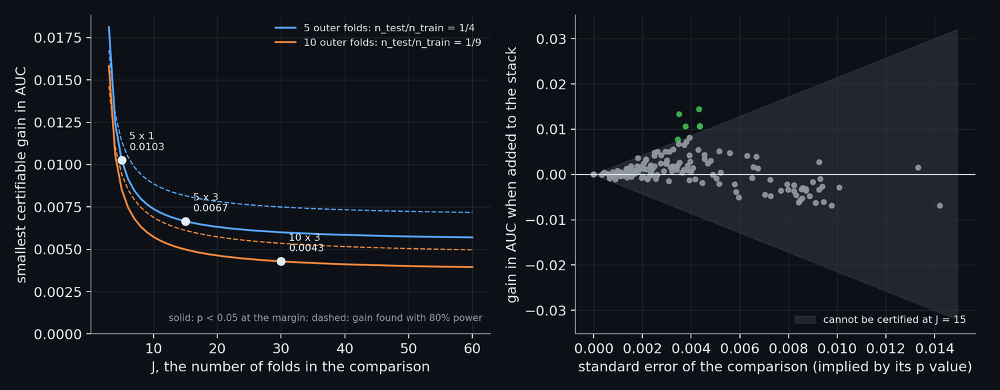

**Figure: The smallest gain a gate can certify.** The smallest gain in AUC that the corrected resampled t can certify (two-sided p < 0.05), as a function of the number of folds J, for the standard deviation of the fold differences that the logged comparisons imply (0.0055, the median of 156 comparisons). With 5 outer folds and one repeat (J = 5) it is 0.0103; with 5 outer folds and 3 repeats (J = 15, the design of the gates) 0.0067; with 10 outer folds and 3 repeats (J = 30, the replicate) 0.0043. The variance factor 1/J + n_test/n_train never falls below the test fraction, so more repeats shrink the floor only so far: a gain of a few thousandths of AUC cannot be certified by this design, whatever its truth. Right: every logged comparison as a point (its gain against the standard error implied by its p value); the lines are the certification limits of the two designs.

In [146]:
show_figure("ml_design_floor")

## 6.6 Why Tukey's HSD was dropped, and how the older results were recomputed

> **Field:** Statistics

*Where this section sits:* 6.5 derived the test the project uses now. It was not the project's first choice. The earliest significance experiments (Part VII reports what each of them tested) compared their variants with **Tukey's HSD**, the standard method for comparing several groups at once, and the method answers a question that is subtly different from the one being asked. This section explains what the method assumes, recomputes the old analyses from their saved scores with the corrected test of 6.5 to show where the two disagree, and then examines one more shortcut of the same family: resampling the compounds while the predictions stay fixed. Nothing here is a new model. Every number comes from scores that were saved when the experiments ran.

In [147]:
# What the saved tables hold: for each experiment, the MCC of every variant on every (repeat, fold) of a repeated cross-validation, for each enzyme. The first of them (the ChemBERTa experiment) is counted here.
COMPARISONS = ROOT / "data/tdi_track/outputs/comparisons"
chemberta_raw = pd.read_csv(COMPARISONS / "chemberta_significance_raw.csv")
scores_per_variant, n_variants = int(chemberta_raw.groupby(["isoform", "variant"]).size().iloc[0]), int(chemberta_raw["variant"].nunique())
n_repeats_saved, n_folds_saved = int(chemberta_raw["repeat"].nunique()), int(chemberta_raw["fold"].nunique())
print(f"{chemberta_raw['isoform'].nunique()} enzymes x {n_variants} variants x {n_repeats_saved} repeats x {n_folds_saved} folds = {len(chemberta_raw)} saved scores; {scores_per_variant} per variant and enzyme")

2 enzymes x 4 variants x 5 repeats x 5 folds = 200 saved scores; 25 per variant and enzyme


**What the method does.** An experiment of this kind has a few variants of a model (the base model alone, the base model with one added block of features, and so on) and, for each variant and each enzyme, the MCC (section 4.10) on every validation fold of a repeated cross-validation: here 25 scores, from 5 repeats of 5 folds. Tukey's HSD (the "honestly significant difference" of Tukey, 1949) asks, for every pair of variants, whether the difference between their mean scores is larger than chance explains, and it guards against the many-comparisons problem of 6.5 by widening its yardstick when more variants are compared. A pair is called different when

$$|\bar x_a - \bar x_b| \;>\; q_{\alpha,\,k,\,N-k}\,\sqrt{\frac{\mathrm{MS}_{\text{within}}}{n}},$$

where $\bar x_a$ and $\bar x_b$ are the mean scores of the two variants, $k$ is the number of variants, $n$ the number of scores per variant, $N = kn$ the number of scores in all, $\mathrm{MS}_{\text{within}}$ the average over the variants of the variance of their scores around their own mean, $\alpha$ the accepted false-alarm probability (0.05), and $q$ a critical value of the *studentized range distribution*, the distribution of the largest difference among $k$ means in units of their standard error. The right-hand side is a standard error of a mean, $\sqrt{\mathrm{MS}_{\text{within}}/n}$, made wider by $q$ for the number of pairs. That standard error treats the $n$ scores of a variant as $n$ independent observations: the mean of 25 of them is taken to be known 5 times more precisely than one of them.

They are not independent, for the reason given in 6.5: the folds of one repeat share most of their training compounds, and the five repeats are five arrangements of the same compounds. The method also does not use the pairing of the scores: the fold in which one variant is scored is the very fold in which another is scored, so a hard fold lowers every variant together, and an unpaired method counts that shared variation as noise in each of them. The first fault makes the method too ready to find differences, the second makes it too slow to find them, and which dominates depends on the data. The cell recomputes both analyses on the saved scores: Tukey's HSD with the library, and the corrected paired t with Holm's adjustment with the function of 6.5, for each pair of variants and each enzyme.

In [148]:
# The two analyses on the same saved scores. Five earlier experiments saved the per-fold MCC of every variant (three to four variants each, repeated cross-validation). They were first analysed with Tukey's HSD, which
# treats the fold scores as independent observations of each variant. Here both analyses are recomputed from the saved scores, Tukey's HSD with the library and the corrected paired t with Holm's adjustment with the
# project's function (the one of 6.5), and set against the result files the project wrote.
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from cypmode.challenge.stacking_significance import paired_comparison_summary

comparison_names = ["stacking", "chemberta", "pharmacophore_fingerprint", "qm_reactivity", "quantum_pharmacophore"]
summary_rows, flipped_frames = [], []
for name in comparison_names:
    raw = pd.read_csv(COMPARISONS / f"{name}_significance_raw.csv")
    tukey_frames, paired_frames = [], []
    for isoform, part in raw.groupby("isoform"):
        result = pairwise_tukeyhsd(part["mcc"].to_numpy(), part["variant"].to_numpy(), alpha=0.05)
        tukey_frames.append(pd.DataFrame(result._results_table.data[1:], columns=result._results_table.data[0]).assign(isoform=isoform))
        paired_frames.append(paired_comparison_summary(part, "mcc").assign(isoform=isoform))
    tukey_all, paired_all = pd.concat(tukey_frames), pd.concat(paired_frames)
    both = tukey_all.merge(paired_all, on=["isoform", "group1", "group2"], suffixes=(" Tukey", " paired"))
    stored_tukey = pd.read_csv(COMPARISONS / f"{name}_significance_tukey.csv")
    stored_paired = pd.read_csv(COMPARISONS / f"{name}_significance_paired.csv")
    summary_rows.append({"experiment": name, "pairs compared": len(both), "Tukey says different": int(both["reject Tukey"].sum()), "corrected paired t says different": int(both["reject paired"].sum()),
                         "files written earlier agree": bool(stored_tukey["reject"].sum() == both["reject Tukey"].sum() and stored_paired["reject"].sum() == both["reject paired"].sum())})
    flipped_frames.append(both[both["reject Tukey"] & ~both["reject paired"]].assign(experiment=name))
summary_table = pd.DataFrame(summary_rows)
show_table(summary_table)
flipped = pd.concat(flipped_frames)
show_table(flipped.assign(pair=flipped["group1"] + " vs " + flipped["group2"])[["experiment", "isoform", "pair", "meandiff Tukey", "p-adj Tukey", "p-adj paired"]].rename(columns={"meandiff Tukey": "difference of the mean MCC", "p-adj Tukey": "Tukey p", "p-adj paired": "corrected paired t, Holm p"}), floatfmt=".4f")
n_pairs_all, n_tukey_all, n_paired_all = int(summary_table["pairs compared"].sum()), int(summary_table["Tukey says different"].sum()), int(summary_table["corrected paired t says different"].sum())
n_flipped = len(flipped)
files_agree = bool(summary_table["files written earlier agree"].all())
flip_experiments = sorted(flipped["experiment"].unique())
example = flipped[(flipped["isoform"] == "CYP3A4") & (flipped["group1"] == "M3") & (flipped["group2"] == "M3+ChemBERTa")].iloc[0]
example_diff, example_tukey_p, example_paired_p = float(example["meandiff Tukey"]), float(example["p-adj Tukey"]), float(example["p-adj paired"])

| experiment | pairs compared | Tukey says different | corrected paired t says different | files written earlier agree |
| --- | --- | --- | --- | --- |
| stacking | 12 | 0 | 0 | True |
| chemberta | 12 | 6 | 1 | True |
| pharmacophore_fingerprint | 12 | 0 | 0 | True |
| qm_reactivity | 12 | 0 | 0 | True |
| quantum_pharmacophore | 12 | 0 | 0 | True |

| experiment | isoform | pair | difference of the mean MCC | Tukey p | corrected paired t, Holm p |
| --- | --- | --- | --- | --- | --- |
| chemberta | CYP2D6 | M3+ChemBERTa vs M3+KNN | 0.0628 | 0.0019 | 0.8184 |
| chemberta | CYP2D6 | M3+KNN vs M3+KNN+ChemBERTa | -0.0542 | 0.0096 | 1.0000 |
| chemberta | CYP3A4 | M3 vs M3+ChemBERTa | -0.0545 | 0.0002 | 0.2305 |
| chemberta | CYP3A4 | M3 vs M3+KNN+ChemBERTa | -0.0528 | 0.0003 | 0.2305 |
| chemberta | CYP3A4 | M3+KNN vs M3+KNN+ChemBERTa | -0.0644 | 0.0000 | 0.1149 |

Over the 5 experiments there are 4 variants, hence 6 pairs per enzyme and 60 pairs in all. Tukey's HSD calls 6 of them different; the corrected paired test calls 1. The 5 pairs that Tukey calls different and the corrected test does not all belong to one experiment (chemberta), and the second table lists them. The one that matters most is the CYP3A4 row that compares M3 with M3+ChemBERTa: adding ChemBERTa embeddings (section 7.9) to the base features changes the mean MCC by -0.054, which Tukey reports at p = 0.0002 and the corrected paired test at p = 0.23. The direction of the finding is unchanged, since ChemBERTa did not help and the project did not use it. What changes is the sentence that the data allow. "Significantly worse" was overstated; what is supported is "no sign of a gain, and a loss of about 0.05 MCC that this design cannot tell from chance". The files written when the experiments ran agree with the recomputation: True.

**How the older results were recomputed.** The experiments saved the MCC of every variant on every (repeat, fold) in a `*_significance_raw.csv` file, and that choice is what made a correction possible without refitting a single model. The module `cypmode/challenge/recompute_paired_summaries.py` reads each raw table, groups it by enzyme, runs `paired_comparison_summary` and writes `*_significance_paired.csv` next to it; the Tukey files are kept, so that the two analyses can be set side by side as above. The lesson for any experiment of this kind is to save the per-fold scores and not only a summary of them: a statistic that later proves wrong can then be replaced.

**Resampling the compounds of fixed predictions.** A second shortcut is tempting once the folds have been run and their predictions saved. The out-of-fold predictions of a model are a table with one score per compound; resampling the compounds of that table with replacement (a bootstrap, section 6.5) and recomputing the AUC difference of two models on each resample gives a distribution, and the 2.5th and 97.5th percentiles of it (the values below which 2.5 and 97.5 percent of the resamples lie) give an interval. The interval is real, but it answers a narrower question. It holds the fitted models fixed and asks how much the difference would move if the *validation compounds* were different. The corrected test asks how much it would move if the *whole procedure* were run again, with different training compounds as well, and training compounds change the model. The cell makes the comparison for two members of the stack, the deep and the shallow LightGBM on feature set A with fingerprints (section 8.1): a bootstrap of 2,000 resamples on the frozen predictions of the first repeat, and the corrected interval from the 15 outer folds.

In [149]:
# The other shortcut, on two real members of the stack: resampling the compounds while the predictions stay frozen. The difference of the AUC of two members (the deep LightGBM on feature set A plus fingerprints, and its
# shallow twin) is given an interval in two ways: by a bootstrap over the compounds of the frozen out-of-fold predictions of the first repeat, and by the corrected t over the 15 outer folds of the plan.
from scipy import stats

from cypmode.challenge.model_comparison import corrected_resampled_t, plan_sizes

member_a, member_b = "lgbm_A+fps_deep", "lgbm_A+fps_shallow"
fold_differences, frozen = [], {}
for repeat, outer in plan.outer_folds():
    refit = plan.task(repeat, outer, OUTER_REFIT)
    y_part, s_a, s_b = plan.labels(refit.evaluate), cache.get(member_a, refit), cache.get(member_b, refit)
    fold_differences.append(roc_auc_score(y_part, s_a) - roc_auc_score(y_part, s_b))
    if repeat == 0:
        frozen.update({int(row): (a_, b_, label) for row, a_, b_, label in zip(refit.evaluate, s_a, s_b, y_part)})
fold_differences = np.array(fold_differences)
corrected = corrected_resampled_t(fold_differences, *plan_sizes(plan))
half_width = float(stats.t.ppf(0.975, len(fold_differences) - 1) * corrected.standard_error)
a_frozen, b_frozen, y_frozen = (np.array([frozen[r][i] for r in sorted(frozen)]) for i in range(3))
rng_boot = np.random.default_rng(0)
boot_diffs = []
for _ in range(2000):
    pick = rng_boot.integers(0, len(y_frozen), len(y_frozen))
    boot_diffs.append(roc_auc_score(y_frozen[pick], a_frozen[pick]) - roc_auc_score(y_frozen[pick], b_frozen[pick]))
boot_low, boot_high = np.percentile(boot_diffs, [2.5, 97.5])
frozen_rows = [{"how the interval is made": "bootstrap over compounds, predictions frozen (repeat 0)", "difference": float(roc_auc_score(y_frozen, a_frozen) - roc_auc_score(y_frozen, b_frozen)), "95 % interval": f"{boot_low:+.4f} to {boot_high:+.4f}", "width": float(boot_high - boot_low)},
               {"how the interval is made": "corrected resampled t over the 15 outer folds", "difference": float(fold_differences.mean()), "95 % interval": f"{fold_differences.mean() - half_width:+.4f} to {fold_differences.mean() + half_width:+.4f}", "width": 2 * half_width}]
show_table(pd.DataFrame(frozen_rows), floatfmt=".4f")
width_ratio = (2 * half_width) / (boot_high - boot_low)
bootstrap_excludes_zero, corrected_excludes_zero = bool(boot_low > 0 or boot_high < 0), bool(fold_differences.mean() - half_width > 0 or fold_differences.mean() + half_width < 0)
corrected_p = corrected.p_value
print(f"the corrected interval is {width_ratio:.1f} times as wide as the bootstrap one; corrected p = {corrected_p:.3f}")

the corrected interval is 1.6 times as wide as the bootstrap one; corrected p = 0.633


| how the interval is made | difference | 95 % interval | width |
| --- | --- | --- | --- |
| bootstrap over compounds, predictions frozen (repeat 0) | 0.0046 | -0.0040 to +0.0129 | 0.0169 |
| corrected resampled t over the 15 outer folds | 0.0031 | -0.0107 to +0.0169 | 0.0276 |

The two members differ in AUC by +0.0031 on average over the 15 folds. The bootstrap interval is -0.0040 to +0.0129, of width 0.0169; the corrected interval is -0.0107 to +0.0169, of width 0.0276, 1.6 times wider, and its p-value is 0.63. Neither interval excludes zero, so the decision would be the same here, and one pair of models is an example and not a proof. The direction of the difference in width is what the argument predicts: the narrower interval leaves out the variation that comes from refitting on other training compounds. It is why the project does not use a bootstrap of saved predictions as the *test* between two models. The bootstrap has a different, legitimate use in the project, to put an interval around a *single* number on one fixed set of predictions (the AUC of a final model on a hold-out block in 6.8, the smoothing of a threshold in section 8.4), where the question is exactly how much that number depends on which compounds were scored.

*On what actually ran.* `cypmode/challenge/stacking_significance.py` holds `repeated_cv_stacking_comparison`, which produced the raw tables (five repeats of five folds, with the nearest-neighbour label features recomputed inside every fold), and `paired_comparison_summary`, the corrected paired t with Holm's adjustment, its `meandiff` being the second variant minus the first. `cypmode/challenge/recompute_paired_summaries.py` applies it to the raw tables of the older experiments. The Tukey tables are the ones the experiments wrote, and the cell above recomputes them with `statsmodels` as a check. The notebook recomputes everything in this section from the saved scores and the cache of the nested plan; it fits nothing.

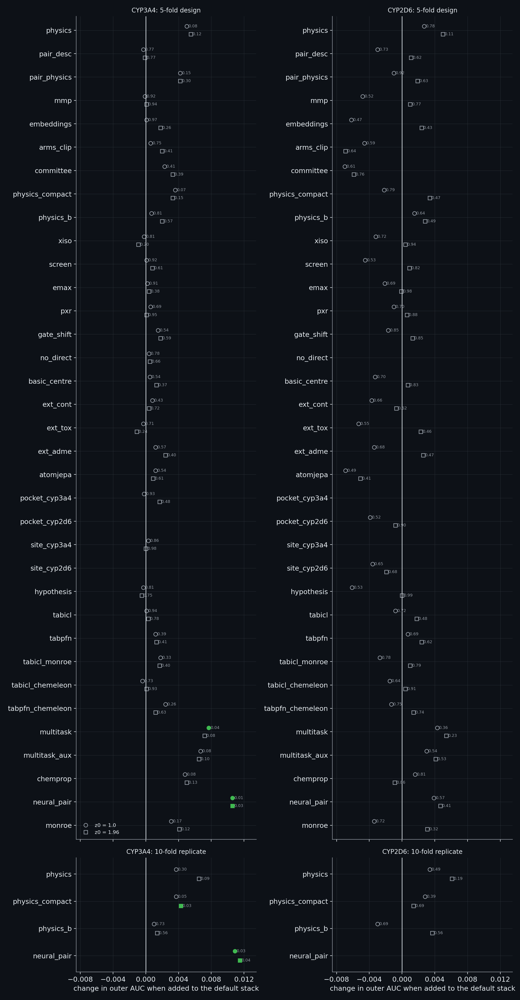

**Figure: Every stacked comparison of the project in one plot.** Every stacked comparison logged by the experiments: the change in outer AUC when an idea's candidates are added to the default stack, for each isoform and each confidence cut z0 (circle 1.0, square 1.96), with the p value printed in the experiment's log beside each marker. Top row: the 5-fold design, 130 comparisons from 35 ideas; bottom row: the 10-fold replicate of the physics ideas, 14 comparisons. An idea passes its pre-declared gate only when both z0 cuts have p < 0.05 and a positive difference for the same isoform (filled green markers): 1 of 65 in the 5-fold design and 1 of 7 in the replicate.

In [150]:
show_figure("ml_gate_forest")

## 6.7 Pre-declared gates: the rule, the floor of the design, and the replicate

> **Field:** Statistics · Data science

*Where this section sits:* 6.4 gave a yardstick and 6.5 a test. What is still missing is a rule for what to do with the outcome: which comparisons count, at what strength of evidence, and who decides before the outcome is known. The rule the project uses for every proposed addition to its model is a gate, the pass/fail rule fixed before a result exists, and this section states it exactly, shows why it is written in advance, reproduces the verdict of four additions from the cache, counts how the gates of the whole project came out, asks how small a gain the design could ever have recognised, and describes the second design, with ten outer folds, that is used to confirm a result when the first design's floor is too high.

**The rule.** A new block of features or a new family of models is *an addition* to the stack of 23 default members (section 8.1). It is judged in two ways. In the *stacked* comparison, the stack of the 23 default members plus the addition is compared with the stack of the 23 alone: both go through the same nested plan (6.3), with the same selector (the logistic stack of section 8.2) and the weighted yardstick of 6.4, and the 15 differences of the outer scores are tested with the corrected t of 6.5. In the *alone* comparison, a single model with the addition is compared with the same model without it. An addition **passes the gate** when its mean difference is positive and the corrected p-value is below 0.05 at *both* confidence cut-offs, $z_0 = 1.0$ and $z_0 = 1.96$ (section 6.4: the cut-off decides which compounds count as scored). Both the level and the cut-offs are constants of the code (`GATE_ALPHA` and `Z_CUTS` in `cypmode/challenge/addition_experiment.py`), set before any addition was run, and the last line an experiment prints is its verdict, MET or NOT MET.

**Why the rule is fixed before the results.** The reason is statistical and it can be measured. Consider an addition that truly adds nothing. Its gain at the two cut-offs is then two noisy numbers that are almost the same noise, since the two yardsticks share most of their compounds. If the analyst may choose which cut-off to report after seeing both, the chance of a false alarm is larger than the 5 percent the test promises; if both must pass, it is smaller. The cell measures the correlation between the two cut-offs on the project's own logged comparisons, simulates additions with no true gain that have that correlation, and counts how many pass under three rules.

In [151]:
# What fixing the rule in advance protects against. For an addition that truly adds nothing, the signed z-value of its gain at the two cut-offs is a pair of correlated standard normal numbers. Their correlation is
# measured on the stacked comparisons of the project's logs (every addition, both cut-offs: the family of 6.5); pairs are then simulated under "no true gain" and three rules are applied to them: one cut-off fixed
# beforehand, the gate of the project (a positive gain with p < 0.05 at both cut-offs), and "report whichever cut-off looks better" (p < 0.05 at either).
from scipy.stats import norm

signed_z = []
for path in sorted(LOG_DIR.glob("*CYP3A4.log")):
    found = {z0: (float(gain), float(p)) for z0, gain, p in stacked_line.findall(path.read_text(errors="ignore"))}
    if "1.0" in found and "1.96" in found:
        signed_z.append([np.sign(found[z][0]) * norm.isf(max(found[z][1], 1e-12) / 2) for z in ("1.0", "1.96")])
signed_z = np.array(signed_z)
rho_cuts = float(np.corrcoef(signed_z.T)[0, 1])
null_z = np.random.default_rng(3).multivariate_normal([0.0, 0.0], [[1.0, rho_cuts], [rho_cuts, 1.0]], size=400_000)
limit = norm.isf(0.025)                                                  # a positive gain whose two-sided p-value is below 0.05
pass_rates = {"one cut-off, fixed beforehand": float((null_z[:, 0] > limit).mean()), "both cut-offs (the gate)": float((null_z > limit).all(axis=1).mean()), "either cut-off, chosen after looking": float((null_z > limit).any(axis=1).mean())}
fork_table = pd.DataFrame({"rule": list(pass_rates), "share of additions with no true gain that pass": list(pass_rates.values())})
fork_table["real additions of the logs that pass"] = [int((signed_z[:, 0] > limit).sum()), int((signed_z > limit).all(axis=1).sum()), int((signed_z > limit).any(axis=1).sum())]
show_table(fork_table, floatfmt=".4f")
n_family_pairs = len(signed_z)
print(f"correlation of the signed z-values at the two cut-offs over {n_family_pairs} logged comparisons: {rho_cuts:.2f}")

correlation of the signed z-values at the two cut-offs over 46 logged comparisons: 0.88


| rule | share of additions with no true gain that pass | real additions of the logs that pass |
| --- | --- | --- |
| one cut-off, fixed beforehand | 0.0248 | 6 |
| both cut-offs (the gate) | 0.0135 | 3 |
| either cut-off, chosen after looking | 0.0360 | 7 |

The signed z-values of the logged comparisons are correlated at 0.88 between the two cut-offs. For an addition with no true gain, a single cut-off fixed beforehand lets 2.5% through, the 2.5 percent that a positive difference with a two-sided p-value below 0.05 gives by chance; the gate, which asks for both, lets 1.4% through; and choosing the better cut-off after looking lets 3.6% through, 1.5 times as many as the fixed one. The two cut-offs are only one of several ways in which a result can be looked at. The metric (AUC or average precision), the design (five or ten outer folds) and the set of compounds are others, and each extra way multiplies the chances in the same fashion. A rule written down before the first run removes the freedom, and with it the need to estimate how much of it was used. Of the 46 logged comparisons, the number that pass the gate is 3, against 7 that would have passed under the choose-afterwards rule.

**The gate on four real additions.** The next cell reproduces the verdict of four additions from the cache of the nested plan and sets it against what the project's own experiment logged when it ran: the multitask network (`mlp`), the same network with the organisers' extra readings as auxiliary targets (defined in 9.10; `mlp_aux`), the pretrained tabular foundation model TabICL, and plain Chemprop. For each, the 23 default members plus the addition are compared with the 23 alone, at both cut-offs, with the weighted yardstick. The standard error of each comparison is converted back into the standard deviation of the 15 fold differences, which the design-floor calculation below needs.

In [152]:
# The gate of the project, reproduced from the cache for four additions to the stack (the multitask network; the same with the screen and Emax as auxiliary heads; TabICL; plain Chemprop). For each, the stack of the 23
# default members plus the addition is compared with the 23 alone, on the nested plan, with the weighted yardstick of 6.4 at both cut-offs, by the corrected t of 6.5. The p-values are then set against the ones the
# project's own experiment logged when it ran. The standard deviation of the fold differences, recovered from the standard error, feeds the next cell.
import re

from cypmode.challenge.cached_candidates import GROUPS
from cypmode.challenge.label_confidence import confident_weights

n_train_plan, n_test_plan = plan_sizes(plan)
ratio_5 = n_test_plan / n_train_plan
J_5 = len(plan.outer_folds())
scores_of = {}
reproduced_rows, fold_sd_5 = [], []
for group in ("mlp", "mlp_aux", "tabicl", "chemprop"):
    added = [c.name for c in GROUPS[group]()]
    log_text = (ROOT / f"data/structure_track/outputs/cyp3a4/logs/aux_{group}_CYP3A4.log").read_text(errors="ignore")
    logged = {z0: float(p) for z0, p in re.findall(r"z0=(1\.0|1\.96)\s+stacked base\+added vs base: AUC [+-]\d\.\d+ \(p=([\d.]+)", log_text)}
    row = {"addition": group}
    for z0 in (1.0, 1.96):
        weight_fn = confident_weights(matcher, z_all, z0)
        if z0 not in scores_of:
            scores_of[z0] = nested_evaluate(cache, default_names, [StackedLogit()], weight_fn, target_prevalence, "auc").set_index(["repeat", "outer"])["outer_score"]
        with_addition = nested_evaluate(cache, default_names + added, [StackedLogit()], weight_fn, target_prevalence, "auc").set_index(["repeat", "outer"])["outer_score"]
        result = corrected_resampled_t((with_addition - scores_of[z0]).to_numpy(), n_train_plan, n_test_plan)
        row[f"gain z0 {z0}"], row[f"p z0 {z0}"], row[f"logged p z0 {z0}"] = result.mean_difference, result.p_value, logged[str(z0)]
        fold_sd_5.append(result.standard_error / np.sqrt(1 / J_5 + ratio_5))
    reproduced_rows.append(row)
reproduced = pd.DataFrame(reproduced_rows)
show_table(reproduced, floatfmt=".3f")
agrees_with_logs = bool(all(abs(r[f"p z0 {z0}"] - r[f"logged p z0 {z0}"]) < 0.0015 for _, r in reproduced.iterrows() for z0 in (1.0, 1.96)))
n_gate_met = int(sum(all(r[f"p z0 {z0}"] < 0.05 and r[f"gain z0 {z0}"] > 0 for z0 in (1.0, 1.96)) for _, r in reproduced.iterrows()))
sd_5 = float(np.median(fold_sd_5))
print(f"median standard deviation of the 15 fold differences over the eight comparisons: {sd_5:.4f}; reproduced p-values equal the logged ones: {agrees_with_logs}; additions meeting the gate: {n_gate_met} of 4")

median standard deviation of the 15 fold differences over the eight comparisons: 0.0059; reproduced p-values equal the logged ones: True; additions meeting the gate: 0 of 4


| addition | gain z0 1.0 | p z0 1.0 | logged p z0 1.0 | gain z0 1.96 | p z0 1.96 | logged p z0 1.96 |
| --- | --- | --- | --- | --- | --- | --- |
| mlp | 0.008 | 0.043 | 0.043 | 0.007 | 0.080 | 0.080 |
| mlp_aux | 0.007 | 0.076 | 0.076 | 0.007 | 0.103 | 0.103 |
| tabicl | 0.000 | 0.945 | 0.945 | 0.000 | 0.779 | 0.779 |
| chemprop | 0.005 | 0.076 | 0.076 | 0.005 | 0.131 | 0.131 |

Every p-value recomputed here equals the one in the log of its experiment: True. 0 of the four additions meet the gate. The best of them, `mlp`, reaches p = 0.043 at $z_0 = 1.0$ and misses at $z_0 = 1.96$ with p = 0.080; with a gain of +0.008 AUC it is also the kind of result that would have been reported as an improvement under the choose-afterwards rule. The median standard deviation of the 15 fold differences over the eight comparisons is 0.0059 AUC.

**The gates of the whole project.** Every experiment ends with such a line, and the lines can be counted. The cell collects all of them from the project's log directory and sorts them into **negative controls** (runs on data for which the right answer is known to be nothing, section 6.8; for them MET is the good outcome), the structure track (Part XI), and additions to the TDI stack.

In [153]:
# The gates of the project, counted from its logs. An experiment prints a line "GATE ...: MET" or "... NOT MET" when it ends. All such lines of the project's log directory are collected and sorted into three
# groups: the negative controls (for which MET is the good outcome), the structure track, and the additions to the TDI stack (alone or stacked).
gate_line = re.compile(r"GATE\b.*:\s*(NOT MET|MET)\s*$")
ledger_rows = []
for path in sorted(LOG_DIR.glob("*.log")):
    for line in path.read_text(errors="ignore").splitlines():
        found = gate_line.search(line)
        if found:
            group = "negative controls" if "negative control" in line else ("structure track" if "STRUCTURE GATE" in line else "TDI stack additions")
            ledger_rows.append({"log": path.name, "line": line.strip(), "group": group, "verdict": found.group(1)})
ledger = pd.DataFrame(ledger_rows)
by_group = ledger.groupby(["group", "verdict"]).size().unstack(fill_value=0).reindex(columns=["MET", "NOT MET"], fill_value=0).reset_index()
show_table(by_group)
met_lines = ledger[(ledger["verdict"] == "MET") & (ledger["group"] != "negative controls")]
show_table(met_lines[["log", "line"]].assign(line=met_lines["line"].str.replace(r"\s+", " ", regex=True)))
n_ledger_lines, n_ledger_logs = len(ledger), ledger["log"].nunique()
n_improve = int((ledger["group"] != "negative controls").sum())
n_improve_met = int(((ledger["group"] != "negative controls") & (ledger["verdict"] == "MET")).sum())
n_control_met = int(((ledger["group"] == "negative controls") & (ledger["verdict"] == "MET")).sum())
n_control = int((ledger["group"] == "negative controls").sum())

| group | MET | NOT MET |
| --- | --- | --- |
| TDI stack additions | 4 | 165 |
| negative controls | 2 | 0 |
| structure track | 5 | 40 |

| log | line |
| --- | --- |
| aux_chemprop_foundation_CYP3A4.log | CYP3A4 GATE (stacked, corrected p < 0.05 at both z0): MET |
| aux_neural_CYP3A4.log | CYP3A4 GATE (stacked, corrected p < 0.05 at both z0): MET |
| aux_neural_f10_CYP3A4.log | CYP3A4 GATE (stacked, corrected p < 0.05 at both z0): MET |
| ost_pool_gates.log | STRUCTURE GATE restraint_bond_ost: MET |
| ost_pool_gates.log | STRUCTURE GATE restraint_contact_ost: MET |
| relaxation_gate.log | STRUCTURE GATE force_field_relaxation (validity, margin and fidelity at p < 0.05): MET |
| replicate_verdict_CYP3A4.log | CYP3A4 GATE (replicate neural, 10 outer folds corrected p < 0.05 at both z0 and the same sign in the 5-fold design): MET |
| structure_gates.log | STRUCTURE GATE restraint_bond: MET |
| structure_gates.log | STRUCTURE GATE restraint_contact: MET |

The logs hold 216 gate lines from 115 logs. Of the 214 that judge a proposed improvement (additions to the stack and levers of the structure track), 9 are MET, the ones listed in the second table, and of the 2 negative-control lines 2 are MET, as they should be. Many of the lines are repeats of one experiment (an addition has an alone and a stacked line for each enzyme, and the ten-fold replicate repeats the stacked ones), so the count says how often the gate was asked and not how many independent ideas were tried. It is still the right picture of what a strict pre-declared rule does to a research programme with many ideas: most of them do not clear it, and the few that do are the ones the project builds on. A claim that something helps, in this project, is the exception that survived a test it could have failed.

**What the design could ever have recognised.** A test that fails to reject does not show that nothing is there. It shows that the design could not see it, and whether it could have is a calculation, the power of the test (6.5): the probability that it rejects when the effect is real. The **minimum detectable effect** is the smallest true difference that the test rejects with a stated probability, here 0.8, the conventional "8 times in 10". The test of 6.5 rejects when $|\bar d| > t_{0.975,\,J-1} \cdot \mathrm{SE}$ with $\mathrm{SE} = s_d\sqrt{1/J + n_{\text{test}}/n_{\text{train}}}$, where $s_d$ is the standard deviation of the $J$ fold differences. If the true difference is $\delta$, the mean difference is about $\delta$ with standard error SE, so it exceeds the critical value in 80 percent of experiments when $\delta$ is larger than that value by the 0.8 quantile of the t distribution times SE:

$$\mathrm{MDE} \;\approx\; \left(t_{0.975,\,J-1} + t_{0.8,\,J-1}\right)\, s_d \sqrt{\frac{1}{J} + \frac{n_{\text{test}}}{n_{\text{train}}}}.$$

(The central t distribution is used for both quantiles; the exact calculation uses a non-central one and differs little at these degrees of freedom.) The standard deviation is measured and not assumed: for the main design it is the median over the eight comparisons just reproduced, and for the replicate described below it is recovered from the logs of the ten-fold experiments, each logged (gain, p-value) pair being turned back into a standard error. The third row of the table is a comparison: the floor that the main design would have if its 15 folds were independent, the assumption of the naive test of 6.5.

In [154]:
# The smallest true AUC difference that a design could recognise. The test rejects when |mean| > t_crit * SE with SE = s_d * sqrt(1/J + n_test/n_train), s_d the standard deviation of the fold differences. If the true
# difference is delta, the mean is about delta with standard error SE, so the test rejects 8 times in 10 when delta exceeds the critical value by the 0.8 quantile of t times SE:
# MDE = (t_{0.975, J-1} + t_{0.8, J-1}) * SE (the central-t approximation, close for these degrees of freedom). s_d is measured, not assumed: for the 5-fold design from the eight comparisons just reproduced,
# and for the 10-fold replicate from its own logs (the stacked comparisons of the physics blocks and of the neural pair), recovering SE from each logged (difference, p).
def minimum_detectable_effect(j, ratio, sd):
    return float((stats.t.ppf(0.975, j - 1) + stats.t.ppf(0.8, j - 1)) * sd * np.sqrt(1 / j + ratio))

STACKED_LINE = re.compile(r"z0=(\d\.\d+)\s+stacked base\+added vs base: AUC ([+-]\d\.\d+) \(p=(\d\.\d+)")
J_10, ratio_10 = 30, 1 / 9
sd_10_values = []
for stem in ("physics_experiment_f10", "physics_compact_f10", "physics_tierb_f10", "aux_neural_f10"):
    path = ROOT / f"data/structure_track/outputs/cyp3a4/logs/{stem}_CYP3A4.log"
    for z0, gain, p in STACKED_LINE.findall(path.read_text(errors="ignore") if path.exists() else ""):
        gain, p = float(gain), float(p)
        if 0.01 < p < 0.99 and gain != 0:
            standard_error = abs(gain) / stats.t.isf(p / 2, J_10 - 1)
            sd_10_values.append(standard_error / np.sqrt(1 / J_10 + ratio_10))
sd_10 = float(np.median(sd_10_values))
floor_rows = [{"design": "5 outer folds x 3 repeats (the main design), corrected t", "folds J": 15, "variance factor": 1 / 15 + 1 / 4, "fold sd measured": sd_5, "smallest difference found 8 times in 10": minimum_detectable_effect(15, 1 / 4, sd_5)},
              {"design": "10 outer folds x 3 repeats (the replicate), corrected t", "folds J": 30, "variance factor": 1 / 30 + 1 / 9, "fold sd measured": sd_10, "smallest difference found 8 times in 10": minimum_detectable_effect(30, 1 / 9, sd_10)},
              {"design": "main design if the folds really were independent (what the naive test assumes)", "folds J": 15, "variance factor": 1 / 15, "fold sd measured": sd_5, "smallest difference found 8 times in 10": minimum_detectable_effect(15, 0.0, sd_5)}]
show_table(pd.DataFrame(floor_rows), floatfmt=".4f")
floor_main, floor_replicate, floor_naive = (r["smallest difference found 8 times in 10"] for r in floor_rows)
n_sd_10 = len(sd_10_values)
def power_at(delta, j, ratio, sd):
    standard_error = sd * np.sqrt(1 / j + ratio)
    t_crit, ncp = stats.t.ppf(0.975, j - 1), delta / standard_error
    return float(stats.nct.sf(t_crit, j - 1, ncp) + stats.nct.cdf(-t_crit, j - 1, ncp))
power_main, power_replicate = power_at(0.004, 15, 1 / 4, sd_5), power_at(0.004, 30, 1 / 9, sd_10)
gains_logged = family["gain at z0 1.0"].to_numpy()                         # the stacked gains of every logged CYP3A4 addition (the family of 6.5)
n_above_main, n_above_replicate, n_logged = int((gains_logged > floor_main).sum()), int((gains_logged > floor_replicate).sum()), len(gains_logged)
median_gain = float(np.median(gains_logged))

| design | folds J | variance factor | fold sd measured | smallest difference found 8 times in 10 |
| --- | --- | --- | --- | --- |
| 5 outer folds x 3 repeats (the main design), corrected t | 15 | 0.3167 | 0.0059 | 0.0099 |
| 10 outer folds x 3 repeats (the replicate), corrected t | 30 | 0.1444 | 0.0084 | 0.0093 |
| main design if the folds really were independent (what the naive test assumes) | 15 | 0.0667 | 0.0059 | 0.0046 |

The main design can recognise a true gain of 0.0099 AUC or more, 8 times in 10, and nothing smaller. The replicate lowers the floor to 0.0093, and the number in the third row, 0.0046, is the price of the correlation between folds: the test needs a true gain about 2.2 times larger than the naive test would claim to need. Set against this floor, the gains the project logged for its additions are small: the median of the 46 logged stacked gains at $z_0 = 1.0$ is +0.0008, and the number of them above the floor of the main design is 5, above that of the replicate 5. This is the quantitative form of the statement made at the end of 6.5. An addition that really improves the AUC by 0.004 would be found 20% of the time by the main design and 23% of the time by the replicate. A failure to clear the gate is therefore a statement about the size of the effect: a gain much larger than about 0.01 AUC is unlikely, and a smaller one is neither shown nor excluded. It also fixes what the project can claim in the other direction. What clears the gate is, besides, more likely an overestimate than an underestimate of the true gain, since a result is selected because it came out large (the winner's curse); the replicate exists partly for that reason.

**The replicate.** When the gains in question are of the size of the main design's floor or below it, a second design is available, and it is declared in advance in the same way. The factor in the standard error is $1/J + n_{\text{test}}/n_{\text{train}}$. With 10 outer folds repeated three times, $J = 30$ and the ratio falls from $1/4$ to $1/9$, so the factor falls from 0.317 to 0.144: the standard error of the same difference would be about a third smaller if the folds were as noisy, and they are not, since each outer fold is a tenth of the pool and not a fifth, so that its score is noisier (the measured standard deviation of the fold differences is 0.0084 against 0.0059). The replicate counts an addition as **replicated** only when two things hold: the ten-fold comparison gives p < 0.05 and a positive gain at both cut-offs, and the five-fold comparison gives a positive gain at both cut-offs, so that the replicate cannot rescue a result whose sign the main design contradicts. The rule for the physics blocks of Part X was written down before any ten-fold result existed, and the rule for the neural pair (section 9.9) was added on 2026-10-16, after its fifteen-fold result and before any ten-fold one; the module's docstring records both. The cell reads the logs through the module that decides.

In [155]:
# The 10-fold replicate of the project, read from the logs of the experiments through the module that decides it (cypmode/challenge/replicate_verdict.py): for each addition put through it, the stacked comparison
# in the main design (5 outer folds x 3 repeats) and in the replicate (10 outer folds x 3 repeats), at both cut-offs, and the verdict: an addition is replicated only if the replicate gives p < 0.05 and a positive
# gain at both cut-offs AND the main design has a positive gain at both cut-offs.
from cypmode.challenge.replicate_verdict import GROUPS as REPLICATE_GROUPS
from cypmode.challenge.replicate_verdict import LOGS as REPLICATE_LOGS
from cypmode.challenge.replicate_verdict import read_stacked, verdict

replicate_rows, replicate_values = [], {}
for group, (five_name, ten_name) in REPLICATE_GROUPS.items():
    five, ten = read_stacked(REPLICATE_LOGS / f"{five_name}_CYP3A4.log"), read_stacked(REPLICATE_LOGS / f"{ten_name}_CYP3A4.log")
    replicate_values[group] = (five, ten)
    row = {"addition": group}
    for z0 in (1.0, 1.96):
        row[f"5 folds, z0 {z0}"] = f"{five[z0][0]:+.4f} (p={five[z0][1]:.3f})" if z0 in five else "no result"
        row[f"10 folds, z0 {z0}"] = f"{ten[z0][0]:+.4f} (p={ten[z0][1]:.3f})" if z0 in ten else "no result"
    row["replicated"] = ("yes" if verdict(five, ten) else "no") if len(ten) == 2 else "not run yet"
    replicate_rows.append(row)
replicate_table = pd.DataFrame(replicate_rows)
show_table(replicate_table)
n_replicate_groups = len(replicate_table)
n_replicated = int((replicate_table["replicated"] == "yes").sum())
n_replicate_pending = int((replicate_table["replicated"] == "not run yet").sum())
n_not_replicated = int((replicate_table["replicated"] == "no").sum())
neural_five, neural_ten = replicate_values["neural"]
neural_status = (f"the 10-fold design gives {neural_ten[1.0][0]:+.4f} (p = {neural_ten[1.0][1]:.3f}) at z0 = 1.0 and {neural_ten[1.96][0]:+.4f} (p = {neural_ten[1.96][1]:.3f}) at z0 = 1.96"
                 if len(neural_ten) == 2 else "its 10-fold run had not finished when this page was built")
compact_five, compact_ten = replicate_values["physics_compact"]

| addition | 5 folds, z0 1.0 | 10 folds, z0 1.0 | 5 folds, z0 1.96 | 10 folds, z0 1.96 | replicated |
| --- | --- | --- | --- | --- | --- |
| physics | +0.0050 (p=0.078) | +0.0037 (p=0.298) | +0.0055 (p=0.115) | +0.0065 (p=0.093) | no |
| physics_compact | +0.0036 (p=0.068) | +0.0037 (p=0.054) | +0.0033 (p=0.148) | +0.0043 (p=0.025) | no |
| physics_b | +0.0007 (p=0.812) | +0.0010 (p=0.734) | +0.0020 (p=0.572) | +0.0014 (p=0.563) | no |
| neural | +0.0106 (p=0.014) | +0.0109 (p=0.026) | +0.0106 (p=0.029) | +0.0115 (p=0.038) | yes |
| pocket_cyp3a4 | -0.0002 (p=0.934) | no result | +0.0017 (p=0.480) | no result | not run yet |
| pocket_cyp2d6 | no result | no result | no result | no result | not run yet |
| site_cyp3a4 | +0.0003 (p=0.856) | no result | -0.0000 (p=0.979) | no result | not run yet |
| site_cyp2d6 | no result | no result | no result | no result | not run yet |
| hypothesis | -0.0003 (p=0.810) | no result | -0.0005 (p=0.753) | no result | not run yet |

The replicate covers 9 additions: 1 replicated, 3 did not, and 5 had not been run when this page was built. The cases show what the rule does. The block of compact physics features (`physics_compact`) comes close: at $z_0 = 1.96$ its ten-fold comparison is +0.0043 with p = 0.025, below 0.05, but at $z_0 = 1.0$ it is p = 0.054, and the rule asks for both, so it is not replicated. The rule can be read as too strict for such a case, and it was fixed before the case existed. The neural pair is the other kind of case: it cleared the main gate, so the replicate is the test that decides whether it is kept, and the 10-fold design gives +0.0109 (p = 0.026) at z0 = 1.0 and +0.0115 (p = 0.038) at z0 = 1.96. Sections 10.6 and 9.9 give the full account of the two.

*On what actually ran.* `cypmode/challenge/addition_experiment.py` runs one addition through the gate (it fills the cache for the candidates if asked, builds the stacked and the alone comparisons, prints one line per cut-off, and ends with the verdict line that the ledger above counts); `cypmode/challenge/cached_candidates.py` defines the groups of candidates an experiment adds (`GROUPS`); `cypmode/challenge/model_comparison.py` supplies `compare_candidate_sets`, which this notebook replaces with explicit `nested_evaluate` calls so that the fold differences can be seen; `cypmode/challenge/replicate_verdict.py` is the module whose `verdict` function decided the replicate above. The designs are the plans of 6.3, built with `--outer 5` for the main design and `--outer 10` and the root `nested_f10` for the replicate; the queue jobs that build and fill them are described in section 12.4.

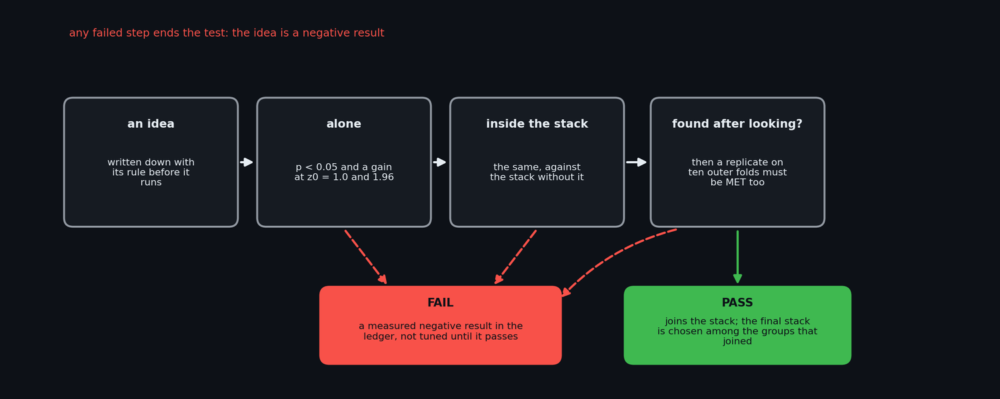

**Figure: The gate: how a group joins a stack.** The rule by which an added group joins a stack, as a flow chart; the final build reads the verdict lines of the logs and applies exactly this and nothing else. A group is tested alone and inside the stack at both confidence cuts (z0 = 1.0 and 1.96), each time with the corrected resampled t against the stack without it; it must have p < 0.05 and a positive difference at both cuts, both alone and inside the stack. A group that was found after looking at the 15-fold results (neural, pocket_cyp3a4, pocket_cyp2d6, site_cyp3a4, site_cyp2d6, hypothesis) must in addition be replicated on ten outer folds, a design declared before any ten-fold number existed. A group that fails is written down with its numbers and is not tuned until it passes; the stack is chosen among the groups that pass.

In [156]:
show_figure("ml_gate_flow")

## 6.8 Checking that a split is informative, the test-like hold-out, and the leakage controls

> **Field:** Statistics · Cheminformatics

*Where this section sits:* every number of Part VI is a number on validation compounds, and it is worth something only if two things are true: the validation compounds resemble the ones the project is scored on, and they were never seen by the procedure that is being scored. 6.4 acted on the first by weighting. This section examines both from outside: it measures how far the project's folds are from the training set compared with the blinded test, scores the candidates on a block of the training file that was built like the test and held out whole, and then tests for the second condition, the absence of **data leakage**: information from the validation rows reaching the fit.

**Is the split informative?** A cross-validation score is a forecast of the score on new compounds only if the folds are a fair stand-in for them. A fold made of near-copies of training compounds is too easy and over-predicts; a fold of compounds unlike anything in training is too hard and under-predicts. The first stored result is the profile of the nearest-training similarity (Tanimoto, section 3.2) for the project's own cross-validation folds against their own training parts, and for the 750 blinded test compounds against the whole training file (`cypmode/challenge/split_validity.py`). The second stored result is a harder test of the same idea. The training file is not homogeneous: its compound numbers fall into blocks that were screened in different rounds (`cypmode/challenge/library_blocks.py`), and the highest block is an *analogue-expansion round*, built like the blinded test set, with a positive rate of about 0.30 for CYP3A4 like the test set's. Holding that whole block out and fitting everything on the rest gives a score in a regime that resembles the test far more than any random or similarity-weighted fold does, and the same candidates' cross-validation AUC can be set next to it (`cypmode/challenge/block_holdout.py`). The candidate set and the "best" candidate are chosen from the cross-validation only, never from the block, so the block stays a test. The cell reads both results and recomputes the agreement of the two yardsticks from the logged table.

In [157]:
# Is a split informative? Two stored results. The first is the similarity profile of the project's own cross-validation folds and of the blinded test compounds, each against the training set it is judged from
# (cypmode/challenge/split_validity.py). The second is the test-like hold-out (cypmode/challenge/block_holdout.py): the analogue-expansion round of the training file held out whole, the candidates fitted on the rest and
# scored on the block, next to their cross-validation AUC. The log of that run is read back and the agreement of the two yardsticks is recomputed from its table.
from io import StringIO

from scipy.stats import spearmanr

split_table = pd.read_csv(COMPARISONS / "split_validity.csv")
show_table(split_table.rename(columns={"median_similarity": "median similarity", "frac_similarity_ge_0.5": "share at 0.5 or more", "frac_similarity_ge_0.7": "share at 0.7 or more"})[["comparison", "n", "median similarity", "share at 0.5 or more", "share at 0.7 or more"]], floatfmt=".3f")
log_lines = (ROOT / "data/structure_track/outputs/cyp3a4/logs/block_holdout.log").read_text().splitlines()
start = next(i for i, line in enumerate(log_lines) if line.strip().startswith("candidate") and "block_auc" in line)
end = next(i for i in range(start + 1, len(log_lines)) if not log_lines[i].strip())
block_table = pd.read_csv(StringIO("\n".join(log_lines[start:end])), sep=r"\s+")
rho_block = float(spearmanr(block_table["cv_auc_unweighted"], block_table["block_auc"]).statistic)
rho_stored = float(re.search(r"block AUC = ([\d.]+)", "\n".join(log_lines)).group(1))
best_by_cv = block_table.sort_values("cv_auc_unweighted", ascending=False).iloc[0]
size_line = next(line for line in log_lines if "held-out block rows" in line)
committee_line = next(line for line in log_lines if line.startswith("equal-weight rank committee"))
show_table(block_table.head(6)[["candidate", "cv_auc_unweighted", "block_auc", "block_auc_lo", "block_auc_hi"]], floatfmt=".4f")
print(f"{len(block_table)} candidates; Spearman rho between the cross-validation AUC and the block AUC, recomputed from the table printed to four decimals: {rho_block:.3f}; the run itself, from unrounded values: {rho_stored:.3f}")
print(size_line.split(' ', 2)[2]); print(committee_line)
block_rank_of_cv_best = int((block_table["block_auc"] > best_by_cv["block_auc"]).sum() + 1)
mean_offset = float((block_table["block_auc"] - block_table["cv_auc_unweighted"]).mean())
block_rate = float(re.search(r"positive rate ([\d.]+)", size_line).group(1))
n_block, n_train_block = (int(x) for x in re.search(r"train rows (\d+), held-out block rows (\d+)", size_line).groups()[::-1])
n_block_positives = round(n_block * block_rate)
own_split, test_split = split_table.iloc[0], split_table.iloc[1]

19 candidates; Spearman rho between the cross-validation AUC and the block AUC, recomputed from the table printed to four decimals: 0.915; the run itself, from unrounded values: 0.925
train rows 1851, held-out block rows 483 (positive rate 0.298)
equal-weight rank committee of all 19 candidates: block AUC 0.7972 [0.754, 0.836], AP 0.5818, MCC at the block prevalence 0.3767


| comparison | n | median similarity | share at 0.5 or more | share at 0.7 or more |
| --- | --- | --- | --- | --- |
| own_cv_fold_vs_own_training_portion | 965 | 0.448 | 0.383 | 0.159 |
| real_blinded_test_vs_full_training_set | 750 | 0.569 | 0.815 | 0.084 |

| candidate | cv_auc_unweighted | block_auc | block_auc_lo | block_auc_hi |
| --- | --- | --- | --- | --- |
| lgbm_A+fps+ext+alerts_deep | 0.7750 | 0.8037 | 0.7618 | 0.8446 |
| lgbm_A+fps+ext_deep | 0.7740 | 0.7926 | 0.7499 | 0.8298 |
| lgbm_A+fps_deep | 0.7731 | 0.7928 | 0.7489 | 0.8299 |
| lgbm_A+fps_shallow | 0.7699 | 0.7676 | 0.7226 | 0.8108 |
| lgbm_A+ext_deep | 0.7568 | 0.7620 | 0.7187 | 0.8042 |
| lgbm_A_deep | 0.7559 | 0.7634 | 0.7182 | 0.8056 |

The median nearest-training similarity is 0.448 for the cross-validation folds and 0.569 for the blinded test; 38% of the fold compounds have a training neighbour at 0.5 or more, against 81% of the test compounds, but at 0.7 or more the order reverses (16% against 8%). The test compounds are therefore typically analogues of training compounds at moderate similarity and seldom near-copies, and the folds are on this one count the harder exam. That is a statement about a single property, the distance to the nearest neighbour, and a necessary condition for a fair stand-in and not a sufficient one; the weights of 6.4 correct for it where they can.

On the held-out block of 483 compounds, trained on the other 1851, the candidate that cross-validation ranked first scores 0.804 AUC (interval 0.762 to 0.845, a bootstrap over the block's compounds, the legitimate use named in 6.6) against 0.775 in cross-validation, and has rank 1 of the 19 candidates on the block. The two yardsticks agree on the order of the candidates, with a Spearman correlation of 0.915 recomputed from the printed table (the run itself, from the unrounded values, printed 0.925). On the *level* the block is kinder: its AUC exceeds the cross-validation AUC by +0.018 on average over the candidates. That fits a block whose compounds have closer training neighbours than a random fold has, but this notebook has not measured that, and the block differs from a random fold in other ways too (it is one round of one chemistry), so the offset is reported and not explained. The equal-weight committee of all candidates scores about the same as the single best, and the two intervals overlap almost completely, so the block cannot tell a good selection from a committee, a limit of 483 compounds with about 144 positives. What the block does show is that the cross-validation was a faithful guide to the *order* of the candidates in a regime like the test, which is the use the project makes of it.

**Leakage.** A pipeline leaks when the label of a validation compound, or something computed from it, has influenced the model that scores it. The result is a score that is high for a reason that will not repeat on new compounds. A well-known case is selecting features before cross-validation (Ambroise and McLachlan, 2002, showed how large its effect is on gene-expression data): if the 20 features most correlated with the label are chosen on all the compounds and only the model is cross-validated, the chosen features have already seen every validation label. The cell shows it on data in which there is nothing to find: 200 compounds, 2,000 features of pure noise, random labels. Two pipelines are identical except for the place of the selection, and each is run on the true (random) labels and on 20 permutations of them. A label permutation destroys any real relationship while keeping everything else, so a procedure without leakage must score 0.5 on permuted labels, and a procedure that leaks does not.

In [158]:
# Why a label-permutation control can catch a leak, shown on data where there is nothing to find. 200 compounds with 2,000 pure-noise features and random labels: any score free of leakage must be 0.5. Two pipelines, both
# "select the 20 features most correlated with the label, fit a logistic regression, score by 5-fold cross-validation": the leaky one selects the features once on all compounds, before the folds are made; the
# clean one selects them again inside each training part. Each is run on the true (random) labels and on 20 random permutations of them.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

def top_features(X, y, k=20):
    centred = X - X.mean(axis=0)
    score = np.abs(centred.T @ (y - y.mean()))
    return np.argsort(score)[-k:]

def cross_validated_auc(X, y, leaky, seed=0):
    if leaky:
        X = X[:, top_features(X, y)]
    out = np.zeros(len(y))
    for fit_rows, held in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        columns = slice(None) if leaky else top_features(X[fit_rows], y[fit_rows])
        out[held] = LogisticRegression(max_iter=300).fit(X[fit_rows][:, columns], y[fit_rows]).decision_function(X[held][:, columns])
    return roc_auc_score(y, out)

rng_leak = np.random.default_rng(5)
X_noise = rng_leak.normal(size=(200, 2000))
y_noise = rng_leak.integers(0, 2, 200)
leak_rows = []
for label, leaky in (("selects the features before the folds (leaky)", True), ("selects the features inside each training part (clean)", False)):
    permuted = [cross_validated_auc(X_noise, rng_leak.permutation(y_noise), leaky) for _ in range(20)]
    leak_rows.append({"pipeline": label, "AUC on the true labels": cross_validated_auc(X_noise, y_noise, leaky), "mean AUC on 20 permuted label sets": float(np.mean(permuted)), "range over the permutations": f"{min(permuted):.3f} to {max(permuted):.3f}"})
show_table(pd.DataFrame(leak_rows), floatfmt=".3f")
leaky_auc, clean_auc = leak_rows[0]["AUC on the true labels"], leak_rows[1]["AUC on the true labels"]
leaky_permuted_mean, clean_permuted_mean = leak_rows[0]["mean AUC on 20 permuted label sets"], leak_rows[1]["mean AUC on 20 permuted label sets"]

| pipeline | AUC on the true labels | mean AUC on 20 permuted label sets | range over the permutations |
| --- | --- | --- | --- |
| selects the features before the folds (leaky) | 0.865 | 0.860 | 0.806 to 0.891 |
| selects the features inside each training part (clean) | 0.541 | 0.489 | 0.423 to 0.560 |

The leaky pipeline scores 0.87 AUC on labels that are random, and 0.86 on average on permuted ones: it "finds" a signal in noise that is not there, and it would find it on any labels. The clean pipeline, with the selection inside each training part, scores 0.54 on the same labels and 0.49 on average on the permuted ones, which is chance. The permuted-label score is the diagnostic: it needs no knowledge of where the leak is. This is the **negative control** of the project, a run on data for which the right answer is known to be "nothing" (Leach, *Molecular Modelling*, 2nd ed., section 12.13.1, describes it for regression models as a randomisation test), and the project applies it to the *whole* nested pipeline: inner folds, selector, outer folds, and the yardstick of 6.4.

The next cell reads the stored result of the control, and checks it against the tolerances written into the experiment. The gate is that the permuted-label AUC is within 0.04 of 0.5 and at least 0.1 below the real-label AUC, and the permuted MCC within 0.08 of 0; the tolerances are about two sampling standard errors of one run, not tuned values. It also makes two structural checks. The first is that every feature block of the feature store is a function of the structures alone: the names of the parameters of all of them are listed, and a block that took a label, a fold or a table of results would show. The second is the guard on releases from the laboratory that measured the challenge: some of its files contain readings of compounds that are in the blinded test set, and the function `exclude_test_compounds` removes their rows before anything is computed, so that a model never reads a measurement of a test compound. The guard is shown on a made-up frame with two rows of blinded compounds and two of others, and the identifiers are not printed.

In [159]:
# The leakage controls of the project, as checks that can fail. (1) The negative control: the whole nested pipeline run with the labels of the pool permuted at random must give chance; its stored result is read
# back and the verdict is recomputed from the numbers with the gate's own tolerances. (2) The feature blocks take structures and nothing else: every block function of the feature store is listed with the names of its
# parameters, and a block that took a label, a fold or a table of results would show here. (3) The guard on the laboratory's releases: rows of a blinded test compound are removed, shown on a made-up frame.
import inspect

from cypmode.challenge.feature_store import BLOCKS as FEATURE_BLOCKS
from cypmode.challenge.official_extra import exclude_test_compounds, test_compounds

control_text = (ROOT / "data/structure_track/outputs/cyp3a4/logs/permutation_control_CYP3A4.log").read_text()
control = {z0: dict(zip(("real_auc", "real_mcc", "perm_auc", "perm_mcc"), map(float, vals))) for z0, *vals in re.findall(r"z0=(1\.0|1\.96)\s+real labels: AUC ([\d.]+), MCC ([+-][\d.]+) \| permuted: AUC ([\d.]+) \(range [\d.]+ to [\d.]+\), MCC ([+-][\d.]+)", control_text)}
control_rows = [{"cut-off": f"z0 = {z0}", "real labels: AUC": c["real_auc"], "permuted: AUC": c["perm_auc"], "real labels: MCC": c["real_mcc"], "permuted: MCC": c["perm_mcc"]} for z0, c in control.items()]
show_table(pd.DataFrame(control_rows), floatfmt=".3f")
control_met = bool(all(abs(c["perm_auc"] - 0.5) <= 0.04 and c["real_auc"] - c["perm_auc"] >= 0.1 and abs(c["perm_mcc"]) <= 0.08 for c in control.values()))
stored_control_met = "GATE (negative control, permuted labels give chance): MET" in control_text
parameters = pd.DataFrame([{"feature block": name, "parameters of its function": ", ".join(inspect.signature(function).parameters)} for name, function in sorted(FEATURE_BLOCKS.items())])
only_structures = bool((parameters["parameters of its function"] == "mols").all())
n_blocks_checked = len(parameters)
n_permutations = int(re.search(r"(\d+) permutations", control_text).group(1))
ids = sorted(test_compounds())
made_up = pd.DataFrame({"ocnt_batch": [f"{ids[0]}-AA-001", "OCNT-0000001-AA-001", f"{ids[1]}-AB-002", "OCNT-0000002-AA-001"], "value": [1.0, 2.0, 3.0, 4.0]})
kept, dropped = exclude_test_compounds(made_up, "ocnt_batch")
guard_works = bool(len(kept) == 2 and len(dropped) == 2 and set(kept["value"]) == {2.0, 4.0})
print(f"negative control recomputed: {'MET' if control_met else 'NOT MET'} (stored verdict: {'MET' if stored_control_met else 'NOT MET'}); {n_blocks_checked} feature blocks, every one takes only the structures: {only_structures}; the guard keeps {len(kept)} of 4 made-up rows and drops {len(dropped)} blinded compounds: {guard_works}")
real_auc_control, permuted_auc_control = control["1.0"]["real_auc"], control["1.0"]["perm_auc"]

negative control recomputed: MET (stored verdict: MET); 28 feature blocks, every one takes only the structures: True; the guard keeps 2 of 4 made-up rows and drops 2 blinded compounds: True


| cut-off | real labels: AUC | permuted: AUC | real labels: MCC | permuted: MCC |
| --- | --- | --- | --- | --- |
| z0 = 1.0 | 0.801 | 0.510 | 0.411 | 0.002 |
| z0 = 1.96 | 0.828 | 0.510 | 0.465 | -0.004 |

On the real pipeline, the control gives 0.801 AUC for the real labels at $z_0 = 1.0$ and 0.510 for permuted ones, and the recomputed verdict is MET, as the stored one is. All 28 feature blocks take only the structures: True. The guard keeps the rows of the other compounds and drops those of the blinded ones: True. Three limits belong with this. The parameter check is a necessary condition, since a function that takes only structures cannot read a label through its arguments, though it could read one from a global, and it is the permutation control that tests the whole pipeline, not the signature. The control was run for a few permutations (3 in the stored run), so its range is wide; the conclusion rests on the mean and on the tolerance, not on any one permutation. And the control cannot find leakage between the training file and the blinded test, a test compound that is also in the training file for example, because it never touches the test set; that is checked separately, by comparing the identifiers and the structures of the training file with those of the blinded test (section 8.6).

Features that use labels are computed inside the folds. The nearest-neighbour label features of 7.3 are recomputed for every fold from the training part only (`add_knn_label_features_for_fold`), and in the nested plan every fit of every candidate happens inside a task (6.3), which sees only its own training rows. With the controls of this section, the weights of 6.4, the test of 6.5 and the gate of 6.7, the measurement chain of Part VI is complete: Part VII now applies it, from the first model.

*On what actually ran.* `cypmode/challenge/split_validity.py` computes the similarity profile (it uses `tanimoto_ood_distance` of `cypmode/challenge/reliability.py`); `cypmode/challenge/block_holdout.py` fits the candidates on the training part, scores them on the block, and prints the table and the agreement that this notebook reads back; `cypmode/challenge/permutation_control.py` runs the negative control on six candidates, one repeat of five outer folds and three permutations, with its caches in a temporary directory that is discarded; `cypmode/challenge/official_extra.py` holds `exclude_test_compounds`, the guard, and `cypmode/challenge/feature_store.py` the feature blocks. The toy leak above is computed in the notebook.

# Part VII. The first TDI models and what they taught

Part VI built the measurement. This part uses it, in the order in which the work happened, from the challenge's own baseline to the first assembled models, the work of the first weeks of the project. It has eleven sections. Section 7.1 reproduces the baseline; 7.2 adds the project's two nitrogen screens to it one block at a time; 7.3 gives each compound the labels of its nearest neighbours; 7.4 describes a feature that looked like the largest gain of the project and was retracted; 7.5 and 7.6 are about the yes/no threshold and about uncertainty; 7.7 to 7.9 bring in external data, quantum-chemical and pharmacophore features and learned embeddings; 7.10 asks whether predicted structures help a classifier; 7.11 assembles the first complete models and records the decision to build the nested evaluation of 6.3.

Two things are worth knowing before reading it. The first is that the experiments of this part were run *before* the nested evaluation existed. They used five-fold cross-validation (later experiments repeat it five times), a threshold of 0.5 or one tuned inside the folds, and the MCC of section 4.10 as the score. The corrected resampled t of 6.5 was applied to them afterwards wherever the per-fold scores had been saved (6.6). Each section says which of its numbers are stored tables of the day and which are recomputed for this notebook, and when a recomputation disagrees with the stored table the section says why.
The second is the population. The early CYP3A4 numbers were computed on the *mixed* population of section 2.4: a third of the labelled CYP3A4 compounds have no direct-inhibition reading and are all labelled negative, and training and scoring on them rewards a shortcut that does not exist in the blinded test set. Section 7.4 shows the shortcut at work. The models of Part VIII use the corrected population, and the counterpart of each experiment of this part in the nested design is named in its section.

What this part hands on is mostly a set of lessons, and they are the reason the later parts are built as they are. A score without its spread cannot be compared with another (7.1, 7.2). A feature that is mechanistically sensible usually does not help once it is tested properly (7.2, 7.7, 7.8, 7.9, 7.10). A result that looks too good is more often a shortcut than a discovery (7.4). A decision taken on a point estimate of five folds is not a decision (7.2). The rule that no idea enters the model without passing a gate written in advance (6.7) is the answer to all four.

## 7.1 Reproducing the challenge's baseline from the raw file

> **Field:** Machine learning · Data science

*Where this section sits:* Part VI said how to measure. The first thing to measure is the reference. A project that wants to improve on a baseline must know what the baseline scores *in its own measurement*, because a number recalled from elsewhere comes with a protocol that the reader does not control. This section reproduces the organisers' tutorial baseline from the raw training file, shows why its MCC is low even though its AUC is not, and sets it beside the score the organisers' reference entry earns on the challenge's own board.

**The baseline.** The tutorial of the challenge (the repository `OpenADMET/CYP-Challenge-Tutorial`) trains one LightGBM classifier (section 4.3) for each of the two enzymes, with the library's default settings, on the RDKit descriptors of the compounds (section 3.3). It splits the labelled compounds at random into 75 percent for fitting and 25 percent for scoring, keeping the share of positives the same in both parts (a *stratified* split, section 4.1), and reports accuracy, F1, MCC and AUC at the threshold of 0.5, for ten such random splits. The reference row of the board is the organisers' version of this model. The project's version of it is `cypmode/challenge/tdi_baseline.py`: `load_tdi_training_data` keeps every compound that has a label for at least one enzyme, `compute_descriptors` uses the same descriptor library as the tutorial, so that the numbers are comparable, and `cross_validate_baseline` is the tutorial's protocol. The first cell counts what the baseline is given.

In [160]:
# What the challenge tutorial's baseline is given. It reads the training file, keeps every compound that has a label for at least one of the two enzymes (load_tdi_training_data), and trains one LightGBM
# classifier per enzyme on the RDKit descriptors of the compound. The table counts what that gives per enzyme and how many of the labelled rows were measured in both assay arms (section 2.3); the others have
# no direct-inhibition reading, a distinction that matters from 7.4 on.
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import matthews_corrcoef, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from cypmode.challenge.tdi_baseline import TDI_ISOFORMS, compute_descriptors, cross_validate_baseline, cross_validate_fixed_seed, load_tdi_training_data
from cypmode.challenge.tdi_targets import BOTH_ARMS, NO_DIRECT, training_view

COMPARISONS = ROOT / "data/tdi_track/outputs/comparisons"
train_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")
tutorial_frame = load_tdi_training_data()
data_rows = []
for iso in TDI_ISOFORMS:
    view = training_view(train_file, iso)
    labelled = view[view["label"].notna()]
    data_rows.append({"enzyme": iso, "labelled compounds": len(labelled), "time-dependent inhibitors": int(labelled["label"].sum()), "share": float(labelled["label"].mean()),
                      "measured in both arms": int((labelled["population"] == BOTH_ARMS).sum()), "no direct reading": int((labelled["population"] == NO_DIRECT).sum())})
data_table = pd.DataFrame(data_rows).set_index("enzyme")
show_table(data_table.reset_index(), floatfmt=".3f")
n_tutorial = len(tutorial_frame)

| enzyme | labelled compounds | time-dependent inhibitors | share | measured in both arms | no direct reading |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | 3584 | 764 | 0.213 | 2334 | 1249 |
| CYP2D6 | 1497 | 324 | 0.216 | 1493 | 4 |

The tutorial's frame holds 4,822 compounds with at least one label. For CYP3A4 3,584 of them are labelled, 21.3% as time-dependent inhibitors, and 1,249 of the labelled compounds have no direct-inhibition reading: they are the third of the CYP3A4 labels that follow the convention of section 2.4, and the baseline, like every early experiment, trains and is scored on them together with the 2,334 compounds measured in both arms. For CYP2D6 1,497 are labelled, 21.6% positive, and only 4 lack a direct reading. In both enzymes about one compound in five is positive, so a model that says "negative" for everything is right four times in five. That fact, which section 4.10 called the accuracy paradox, shapes everything below.

The next cell runs the baseline two ways. The first is the tutorial's protocol, ten random splits per enzyme. The tutorial does not seed its random splits, so two runs of it give different numbers, which is itself a finding; the seed of numpy is fixed here so that this notebook's run repeats. The second is the project's fixed-seed five-fold protocol (`cross_validate_fixed_seed`): the same five folds every time, so that a later model scored on them is compared with the baseline on the same compounds. The tables stored when the project first ran them are read alongside.

In [161]:
# The baseline run twice. First as the tutorial runs it: ten random 75/25 splits per enzyme, a fresh LightGBM on each, the 0.5 threshold. The splits are unseeded in the tutorial, so the seed of numpy is fixed here for the
# run to repeat. Then with the project's fixed-seed five-fold protocol (cross_validate_fixed_seed), which is the same on every run and is what later comparisons use. The stored tables of both are read next to the new runs.
described = compute_descriptors(tutorial_frame)                 # the descriptors of useful_rdkit_utils, as in the tutorial; about 40 s for the labelled compounds
np.random.seed(0)
tutorial_runs = cross_validate_baseline(described, n_iterations=10)
fixed_runs = cross_validate_fixed_seed(described)
stored_tutorial, stored_fixed = pd.read_csv(COMPARISONS / "baseline_reproduction.csv"), pd.read_csv(COMPARISONS / "baseline_fixed_seed.csv")
n_descriptors = len(described["descriptors"].iloc[0])
baseline_rows = []
for name, frame in (("tutorial protocol, run here", tutorial_runs), ("tutorial protocol, stored", stored_tutorial), ("fixed-seed five-fold, run here", fixed_runs), ("fixed-seed five-fold, stored", stored_fixed)):
    for iso in TDI_ISOFORMS:
        part = frame[frame["isoform"] == iso]
        baseline_rows.append({"protocol": name, "enzyme": iso, "splits": len(part), "MCC mean": part["mcc"].mean(), "MCC sd": part["mcc"].std(), "AUC mean": part["roc_auc"].mean(), "accuracy mean": part["accuracy"].mean()})
baseline_table = pd.DataFrame(baseline_rows)
show_table(baseline_table, floatfmt=".3f")
fixed_matches_stored = bool(np.allclose(fixed_runs.sort_values(["isoform", "fold"])["mcc"].to_numpy(), stored_fixed.sort_values(["isoform", "fold"])["mcc"].to_numpy()))
def baseline_value(protocol, iso, column):
    return float(baseline_table[(baseline_table["protocol"] == protocol) & (baseline_table["enzyme"] == iso)][column].iloc[0])

| protocol | enzyme | splits | MCC mean | MCC sd | AUC mean | accuracy mean |
| --- | --- | --- | --- | --- | --- | --- |
| tutorial protocol, run here | CYP3A4 | 10 | 0.285 | 0.029 | 0.790 | 0.795 |
| tutorial protocol, run here | CYP2D6 | 10 | 0.004 | 0.046 | 0.543 | 0.769 |
| tutorial protocol, stored | CYP3A4 | 10 | 0.264 | 0.028 | 0.796 | 0.794 |
| tutorial protocol, stored | CYP2D6 | 10 | 0.055 | 0.056 | 0.556 | 0.775 |
| fixed-seed five-fold, run here | CYP3A4 | 5 | 0.294 | 0.058 | 0.796 | 0.800 |
| fixed-seed five-fold, run here | CYP2D6 | 5 | 0.049 | 0.068 | 0.570 | 0.770 |
| fixed-seed five-fold, stored | CYP3A4 | 5 | 0.294 | 0.058 | 0.796 | 0.800 |
| fixed-seed five-fold, stored | CYP2D6 | 5 | 0.049 | 0.068 | 0.570 | 0.770 |

The descriptor set has 217 columns. On the tutorial's protocol the baseline scores an MCC of 0.285 for CYP3A4 and 0.004 for CYP2D6 in this run, and 0.264 and 0.055 in the run stored when the project began. The two runs use the same protocol on the same data, and for CYP2D6 they differ by 0.050, about as much as the standard deviation of one split (0.046). That is the reason for the second protocol: with five fixed folds the baseline scores 0.294 and 0.049, the re-run equals the stored table to the last digit (True), and every comparison of the next sections uses these folds. The standard deviation over the five folds is 0.058 for CYP3A4 and 0.068 for CYP2D6. Keep these two numbers in mind: they are as large as nearly every improvement that the next sections will claim, and they are why 6.5 was needed.

**Why an AUC of 0.80 and an MCC of 0.29 belong together.** The AUC (section 4.10) asks only whether the model ranks positives above negatives. The MCC asks about the *calls* made at a threshold, and the baseline makes them at the probability 0.5. A gradient-boosted model fitted to data in which one compound in five is positive produces probabilities that stay near that rate, and few compounds reach 0.5. The next cell shows what happens: the pooled out-of-fold probabilities of the fixed-seed run, the share of compounds called positive at 0.5 against the share that are positive, the accuracy against that of calling everything negative, and the MCC as the threshold moves.

| enzyme | positive share (truth) | called positive at 0.5 | accuracy at 0.5 | accuracy of calling everything negative | AUC | MCC at 0.5 | best MCC over the thresholds | threshold of the best |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 0.213 | 0.106 | 0.800 | 0.787 | 0.795 | 0.293 | 0.388 | 0.110 |
| CYP2D6 | 0.216 | 0.036 | 0.770 | 0.784 | 0.569 | 0.046 | 0.112 | 0.080 |

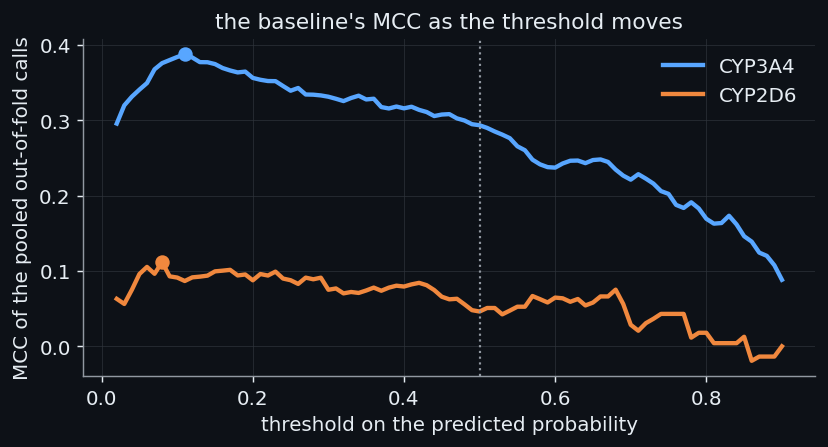

In [162]:
# Why an AUC of 0.80 and an MCC of 0.29 belong together. The out-of-fold probabilities of the fixed-seed five-fold run, pooled, for each enzyme, and what the threshold of 0.5 does with them: how many compounds it calls
# positive against how many are positive, the accuracy against the accuracy of calling everything negative, and the MCC at every threshold from 0.02 to 0.9.
oof_probabilities, oof_labels = {}, {}
for iso in TDI_ISOFORMS:
    column = f"{iso}_is_TDI"
    sub = described.dropna(subset=[column]).reset_index(drop=True)
    y = sub[column].astype(int).to_numpy()
    X = np.stack(sub["descriptors"])
    p = np.zeros(len(y))
    for fit_rows, held in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
        p[held] = LGBMClassifier(verbose=-1, random_state=42).fit(X[fit_rows], y[fit_rows]).predict_proba(X[held])[:, 1]
    oof_probabilities[iso], oof_labels[iso] = p, y
thresholds = np.linspace(0.02, 0.9, 89)
call_rows, mcc_curves = [], {}
for iso in TDI_ISOFORMS:
    p, y = oof_probabilities[iso], oof_labels[iso]
    curve = np.array([matthews_corrcoef(y, (p >= t).astype(int)) for t in thresholds])
    mcc_curves[iso] = curve
    called = p >= 0.5
    call_rows.append({"enzyme": iso, "positive share (truth)": y.mean(), "called positive at 0.5": called.mean(), "accuracy at 0.5": float((called == y).mean()), "accuracy of calling everything negative": 1 - y.mean(),
                      "AUC": roc_auc_score(y, p), "MCC at 0.5": matthews_corrcoef(y, called.astype(int)), "best MCC over the thresholds": float(curve.max()), "threshold of the best": float(thresholds[curve.argmax()])})
call_table = pd.DataFrame(call_rows).set_index("enzyme")
show_table(call_table.reset_index(), floatfmt=".3f")
fig, axis = plt.subplots(figsize=(6.6, 3.6))
for iso, colour in zip(TDI_ISOFORMS, (theme["blue"], theme["orange"])):
    axis.plot(thresholds, mcc_curves[iso], color=colour, lw=2.4, label=iso)
    axis.plot(thresholds[mcc_curves[iso].argmax()], mcc_curves[iso].max(), "o", color=colour, ms=7)
axis.axvline(0.5, color=theme["muted"], ls=":", lw=1.2)
axis.set(xlabel="threshold on the predicted probability", ylabel="MCC of the pooled out-of-fold calls", title="the baseline's MCC as the threshold moves")
axis.legend(frameon=False)
tidy(axis, theme)
fig.tight_layout()

For CYP3A4 the threshold of 0.5 calls 10.6% of the compounds positive, while 21.3% are; the accuracy is 0.800, barely above the 0.787 of a model that never says positive. The MCC is 0.293, but the same probabilities reach 0.388 at a threshold of 0.11. The ranking was good; the decision was bad. The best-threshold number is chosen on the very predictions it is computed on, so it is optimistic, and section 7.5 and section 8.4 show how a threshold is set inside the folds and transferred as a *rate* of calls. For CYP2D6 the model is a different case. Its AUC is 0.569, only a little better than the 0.5 of guessing, it calls 3.6% of the compounds positive, and no threshold gives it much: the best MCC over the thresholds is 0.112. CYP2D6 is the hard enzyme of the challenge from this first number, and the figure shows it: the CYP2D6 curve stays close to zero everywhere.

**The same model on the board.** The interim leaderboards (section 2.10) list the organisers' reference row, the entry whose report link reads "Official LightGBM baseline": the tutorial's model, scored by the organisers on the 750 blinded compounds. Its board MCC is set against the cross-validation estimates of the same model on the training file.

In [163]:
# The same baseline on the challenge's own board. The interim leaderboards (the full test set, frozen at the 2026-09-24 deadline; section 2.10) list the organisers' reference entry, "Official LightGBM baseline", which is
# this model trained on the whole training file and scored on the 750 blinded compounds. Its board MCC is set against the cross-validation estimates of the same model on the training file.
board_rows = []
for iso in TDI_ISOFORMS:
    board = pd.read_csv(ROOT / f"data/tdi_track/inputs/leaderboard_snapshots/interim_{iso}_2026-10-04.csv")
    reference = board[board["Model Report Link"] == "Official LightGBM baseline"].iloc[0]
    board_rows.append({"enzyme": iso, "rank on the interim board": int(reference["Rank"]), "entries": len(board), "board MCC": float(reference["MCC"]), "board MCC sd (bootstrap)": float(reference["MCC std"]),
                       "fixed-seed CV MCC": baseline_value("fixed-seed five-fold, run here", iso, "MCC mean"), "tutorial-protocol MCC": baseline_value("tutorial protocol, run here", iso, "MCC mean")})
board_table = pd.DataFrame(board_rows).set_index("enzyme")
board_table["board minus fixed-seed CV"] = board_table["board MCC"] - board_table["fixed-seed CV MCC"]
show_table(board_table.reset_index(), floatfmt=".3f")

| enzyme | rank on the interim board | entries | board MCC | board MCC sd (bootstrap) | fixed-seed CV MCC | tutorial-protocol MCC | board minus fixed-seed CV |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 95 | 114 | 0.358 | 0.037 | 0.294 | 0.285 | 0.065 |
| CYP2D6 | 80 | 114 | 0.147 | 0.069 | 0.049 | 0.004 | 0.097 |

The reference row scores 0.358 on CYP3A4 (rank 95 of 114) and 0.147 on CYP2D6 (rank 80). The board's own bootstrap standard deviations are 0.037 and 0.069, and the board scores are higher than the cross-validation estimates by 0.065 and 0.097. The cross-validation of the training file is therefore *not* a forecast of the board. Part VI named the reasons: the blinded compounds are analogues of top hits and sit closer to the training file than a cross-validation fold does (6.8), their positive rates are not the training file's (2.10), and the score of the board is computed on a different set of compounds with its own sampling noise. The project uses cross-validation to put candidates in the right *order*, never to predict the board number, and 6.4 built the yardstick that makes the order meaningful for this test set.

*On what actually ran.* `cypmode/challenge/tdi_baseline.py` holds `load_tdi_training_data`, `compute_descriptors`, `cross_validate_baseline` (the tutorial's protocol, with the unseeded splits) and `cross_validate_fixed_seed` (the project's protocol, five stratified folds with `random_state=42`, a LightGBM with the same seed, the threshold 0.5); the stored tables are `baseline_reproduction.csv` and `baseline_fixed_seed.csv` in `data/tdi_track/outputs/comparisons/`. The numbers of the board are read from the snapshot files of `data/tdi_track/inputs/leaderboard_snapshots/`, which hold no test label. Everything in this section is on the mixed population of section 2.4.

## 7.2 The staircase M0 to M3: adding one block of features at a time

> **Field:** Machine learning · Cheminformatics

*Where this section sits:* 7.1 fixed the reference. The first question the project asked of its own chemistry was whether the nitrogen screens of Part V help a classifier that already has the descriptors. The method is an **ablation** in its additive form, a staircase: the same compounds, the same folds and the same model, one block of columns added at each step, so that the change of the score from one step to the next can be attributed to the block. This section runs the staircase, finds that the table the project stored is reproducible to the last digit, finds also that a later change in one of the blocks changes the table, and uses that to measure how much the staircase could ever have shown.

**The four steps.** M0 is the baseline of 7.1, the RDKit descriptors alone. M1 adds the *motif flag* of section 5.1: one column, 1 when any of the six heme-binding nitrogen patterns matches. M2 adds the *trialkylamine flag* of section 5.2, one more column. M3 adds the 2,048-bit Morgan fingerprint of section 3.1. The module is `cypmode/challenge/tdi_ablation.py`; its docstring states the rule under which it was written: if M2 does not beat M1, the amine flag is dropped, whatever the project's attachment to it.

A detail makes the staircase a good case study. The trialkylamine pattern of section 5.2 was extended after the stored run: three more exclusions (the sulfonamide, the enamine, the amidine and guanidine nitrogens) were added to the pattern, which sets the flag for fewer compounds. A stored result is the result of the code *as it was*, and the way to find out whether it is still the result of the code as it is, is to run it again. The cell therefore runs the staircase twice on the same five folds, once with the pattern of the stored run, written out below in full, and once with the pattern of today.

In [164]:
# The M0 to M3 staircase (cypmode/challenge/tdi_ablation.py). Four models, the same five folds and the same LightGBM; each adds one block of columns to the one before: M0 the RDKit descriptors, M1 adds the motif flag
# (any of the six heme-binding nitrogen motifs of section 5.1, one column), M2 adds the trialkylamine flag of section 5.2 (one column), M3 adds the Morgan fingerprint of section 3.1 (2,048 bits). The stored table is the
# run of 2026-09-26. The trialkylamine pattern has changed since (section 5.2: three more exclusions), so the staircase is run twice here: once with the pattern as it was on the day of the stored run, which must reproduce
# the stored table, and once with the pattern of today.
from unittest import mock

import cypmode.metrics.amines as amine_module
from rdkit import Chem

from cypmode.challenge.tdi_ablation import MODELS, add_ablation_features, run_ablation

PATTERN_OF_THE_STORED_RUN = {
    "tertiary_trialkylamine": Chem.MolFromSmarts("[NX3;H0;!$(NC=[O,S]);!$(N=*);!a;!$(N-a)]"),
    "secondary_trialkylamine": Chem.MolFromSmarts("[NX3;H1;!$(NC=[O,S]);!$(N=*);!a;!$(N-a)]"),
}
stored_ablation = pd.read_csv(COMPARISONS / "ablation_m0_m3.csv")
with mock.patch.object(amine_module, "_TRIALKYLAMINE_PATTERNS", PATTERN_OF_THE_STORED_RUN):
    staircase_then = add_ablation_features(described)
    ablation_then = run_ablation(staircase_then)
staircase_now = add_ablation_features(described)
ablation_now = run_ablation(staircase_now)
key = ["model", "isoform", "fold"]
then_matches_stored = float(np.abs(ablation_then.sort_values(key)["mcc"].to_numpy() - stored_ablation.sort_values(key)["mcc"].to_numpy()).max())
widths = {model: len(staircase_now[f"{model.lower()}_features"].iloc[0]) for model in MODELS}
motif_share = float(staircase_now["motif_flag"].map(lambda a: a[0]).mean())
amine_share_now, amine_share_then = (float(frame["amine_flag"].map(lambda a: a[0]).mean()) for frame in (staircase_now, staircase_then))
rows = []
for model in MODELS:
    for iso in TDI_ISOFORMS:
        pick = lambda frame: frame[(frame["model"] == model) & (frame["isoform"] == iso)]["mcc"]
        rows.append({"model": model, "columns": widths[model], "enzyme": iso, "stored (pattern of that day)": pick(stored_ablation).mean(), "re-run, pattern of that day": pick(ablation_then).mean(), "re-run, pattern of today": pick(ablation_now).mean(), "sd over folds (today)": pick(ablation_now).std()})
ablation_table = pd.DataFrame(rows)
show_table(ablation_table, floatfmt=".3f")
print(f"largest difference between the re-run with the old pattern and the stored table: {then_matches_stored:.1e}; amine flag set for {amine_share_then:.1%} of the compounds with the old pattern, {amine_share_now:.1%} with today's; motif flag for {motif_share:.1%}")

largest difference between the re-run with the old pattern and the stored table: 9.7e-17; amine flag set for 28.7% of the compounds with the old pattern, 21.5% with today's; motif flag for 43.5%


| model | columns | enzyme | stored (pattern of that day) | re-run, pattern of that day | re-run, pattern of today | sd over folds (today) |
| --- | --- | --- | --- | --- | --- | --- |
| M0 | 217 | CYP3A4 | 0.294 | 0.294 | 0.294 | 0.058 |
| M0 | 217 | CYP2D6 | 0.049 | 0.049 | 0.049 | 0.068 |
| M1 | 218 | CYP3A4 | 0.298 | 0.298 | 0.298 | 0.058 |
| M1 | 218 | CYP2D6 | 0.069 | 0.069 | 0.069 | 0.022 |
| M2 | 219 | CYP3A4 | 0.298 | 0.298 | 0.296 | 0.031 |
| M2 | 219 | CYP2D6 | 0.038 | 0.038 | 0.109 | 0.089 |
| M3 | 2267 | CYP3A4 | 0.300 | 0.300 | 0.298 | 0.049 |
| M3 | 2267 | CYP2D6 | 0.043 | 0.043 | 0.103 | 0.064 |

The four models have 217, 218, 219 and 2,267 columns, and the motif flag is set for 43.5% of the compounds. The re-run with the pattern of the stored run equals the stored table to 1e-16: the staircase is exactly reproducible, which is worth stating because it means every difference below is a difference of the code and not of the machine. The old pattern sets the amine flag for 28.7% of the compounds and today's for 21.5%. For CYP3A4 the change in the pattern makes no visible difference. For CYP2D6 it makes a large one: the stored table has the amine step lowering the MCC from 0.069 to 0.038, which is why the project of the day dropped the flag, and the table with today's pattern has it raising the MCC to 0.109. The same step has the opposite sign.

Neither sign is a finding, and the next two cells show why. The first applies the corrected resampled t of 6.5 to each step of each table, with the five folds as the five paired observations ($J = 5$, $n_{\text{test}}/n_{\text{train}} = 1/4$), and computes with the formula of 6.7 the smallest true change in MCC that a design of five folds recognises 8 times in 10, from the spread of the fold differences.

In [165]:
# Which of the steps could the five folds recognise? The paired differences between consecutive models, fold by fold, with the corrected resampled t of 6.5 (J = 5 folds, n_test / n_train = 1/4), for the stored table and for
# the re-run with today's pattern, and the smallest true difference this design could have found (section 6.7: 8 times in 10).
from scipy import stats

from cypmode.challenge.model_comparison import corrected_resampled_t

def step_tests(frame, label):
    out = []
    for iso in TDI_ISOFORMS:
        for before, after in (("M0", "M1"), ("M1", "M2"), ("M2", "M3")):
            a = frame[(frame["model"] == after) & (frame["isoform"] == iso)].sort_values("fold")["mcc"].to_numpy()
            b = frame[(frame["model"] == before) & (frame["isoform"] == iso)].sort_values("fold")["mcc"].to_numpy()
            result = corrected_resampled_t(a - b, 4, 1)
            out.append({"table": label, "enzyme": iso, "step": f"{before} to {after}", "mean MCC change": result.mean_difference, "p (corrected t)": result.p_value, "folds in which it rose": f"{result.n_better} of {result.n_folds}", "sd of the fold differences": float(np.std(a - b, ddof=1))})
    return out
step_table = pd.DataFrame(step_tests(stored_ablation, "stored") + step_tests(ablation_now, "today"))
show_table(step_table, floatfmt=".3f")
median_sd_folds = float(step_table["sd of the fold differences"].median())
mde_five_folds = float((stats.t.ppf(0.975, 4) + stats.t.ppf(0.8, 4)) * median_sd_folds * np.sqrt(1 / 5 + 1 / 4))
stored_amine_step = step_table[(step_table["table"] == "stored") & (step_table["enzyme"] == "CYP2D6") & (step_table["step"] == "M1 to M2")].iloc[0]
today_amine_step = step_table[(step_table["table"] == "today") & (step_table["enzyme"] == "CYP2D6") & (step_table["step"] == "M1 to M2")].iloc[0]
print(f"smallest true MCC change that five folds find 8 times in 10, with the median fold sd {median_sd_folds:.3f}: {mde_five_folds:.3f}")

smallest true MCC change that five folds find 8 times in 10, with the median fold sd 0.034: 0.084


| table | enzyme | step | mean MCC change | p (corrected t) | folds in which it rose | sd of the fold differences |
| --- | --- | --- | --- | --- | --- | --- |
| stored | CYP3A4 | M0 to M1 | 0.005 | 0.064 | 4 of 5 | 0.003 |
| stored | CYP3A4 | M1 to M2 | 0.000 | 0.998 | 1 of 5 | 0.012 |
| stored | CYP3A4 | M2 to M3 | 0.001 | 0.926 | 2 of 5 | 0.020 |
| stored | CYP2D6 | M0 to M1 | 0.020 | 0.606 | 2 of 5 | 0.052 |
| stored | CYP2D6 | M1 to M2 | -0.031 | 0.313 | 0 of 5 | 0.040 |
| stored | CYP2D6 | M2 to M3 | 0.005 | 0.906 | 3 of 5 | 0.055 |
| today | CYP3A4 | M0 to M1 | 0.005 | 0.064 | 4 of 5 | 0.003 |
| today | CYP3A4 | M1 to M2 | -0.003 | 0.912 | 1 of 5 | 0.032 |
| today | CYP3A4 | M2 to M3 | 0.002 | 0.937 | 2 of 5 | 0.031 |
| today | CYP2D6 | M0 to M1 | 0.020 | 0.606 | 2 of 5 | 0.052 |
| today | CYP2D6 | M1 to M2 | 0.040 | 0.505 | 3 of 5 | 0.081 |
| today | CYP2D6 | M2 to M3 | -0.006 | 0.827 | 2 of 5 | 0.035 |

No step of either table reaches p = 0.05; the smallest p-value is 0.064, for the motif flag on CYP3A4, a gain of +0.005 MCC, positive in 4 of the 5 folds and too small for five folds to separate from zero. The amine step on CYP2D6 has p = 0.31 in the stored table and p = 0.50 in today's; the standard deviation of its fold differences is 0.040 and 0.081. With the median spread of the fold differences of this table, 0.034, five folds recognise a true change of 0.08 MCC or more and nothing smaller. Every change in the table is smaller than that, so that for a typical step the answer of the staircase was decided by chance. The staircase of five folds could not have answered the question it was built for.

The second check removes the dependence on one partition. The compounds are partitioned into five folds in one way only in the stored run; a different random partition would have given different folds. The cell repeats the amine step (M1 against M2, today's pattern) on five different partitions, 25 folds in all, which is the design that the later experiments used (section 6.6).

In [166]:
# One partition of the compounds into five folds is one draw. The same comparison of the amine step (M1 against M2, today's pattern) on five different partitions, five folds each (the 5 x 5 design of the later
# experiments, section 6.6): the mean change of MCC within each partition, and the corrected resampled t over all 25 folds.
rng_partitions = [100 + k for k in range(5)]
partition_rows = []
for iso in TDI_ISOFORMS:
    column = f"{iso}_is_TDI"
    sub = staircase_now.dropna(subset=[column]).reset_index(drop=True)
    y = sub[column].astype(int).to_numpy()
    features = {m: np.stack(sub[f"{m.lower()}_features"]) for m in ("M1", "M2")}
    for repeat, seed in enumerate(rng_partitions):
        for fold, (fit_rows, held) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(sub, y)):
            for m, X in features.items():
                p = LGBMClassifier(verbose=-1, random_state=0).fit(X[fit_rows], y[fit_rows]).predict_proba(X[held])[:, 1]
                partition_rows.append({"enzyme": iso, "repeat": repeat, "fold": fold, "model": m, "mcc": matthews_corrcoef(y[held], (p >= 0.5).astype(int))})
partition_scores = pd.DataFrame(partition_rows)
partition_summary = []
for iso in TDI_ISOFORMS:
    part = partition_scores[partition_scores["enzyme"] == iso]
    m1, m2 = (part[part["model"] == m].sort_values(["repeat", "fold"])["mcc"].to_numpy() for m in ("M1", "M2"))
    per_repeat = (part[part["model"] == "M2"].groupby("repeat")["mcc"].mean() - part[part["model"] == "M1"].groupby("repeat")["mcc"].mean()).to_numpy()
    result = corrected_resampled_t(m2 - m1, 4, 1)
    partition_summary.append({"enzyme": iso, "change of MCC in each of the 5 partitions": ", ".join(f"{v:+.3f}" for v in per_repeat), "lowest": float(per_repeat.min()), "highest": float(per_repeat.max()),
                              "mean over the 25 folds": result.mean_difference, "p (corrected t, J = 25)": result.p_value})
partition_summary = pd.DataFrame(partition_summary)
show_table(partition_summary, floatfmt=".3f")
sd_25 = float(np.std(m2 - m1, ddof=1))
mde_25_folds = float((stats.t.ppf(0.975, 24) + stats.t.ppf(0.8, 24)) * sd_25 * np.sqrt(1 / 25 + 1 / 4))
cyp2d6_partitions = partition_summary[partition_summary["enzyme"] == "CYP2D6"].iloc[0]

| enzyme | change of MCC in each of the 5 partitions | lowest | highest | mean over the 25 folds | p (corrected t, J = 25) |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | +0.003, -0.002, -0.022, -0.007, +0.002 | -0.022 | 0.003 | -0.005 | 0.768 |
| CYP2D6 | -0.040, +0.028, +0.040, -0.015, +0.007 | -0.040 | 0.040 | 0.004 | 0.876 |

For CYP2D6 the change of MCC from M1 to M2 is -0.040, +0.028, +0.040, -0.015, +0.007 in the five partitions: it runs from -0.040 to +0.040, and the partition decides the sign. Over the 25 folds the mean change is +0.004 and the corrected p-value is 0.88; even the 25-fold design, with the spread of this comparison, recognises only a true change of 0.07 MCC or more. The amine flag neither helps nor hurts as far as this data can say, and the opposite signs of the stored and the re-run tables are two draws from the same noise.

What the staircase established is therefore not what the project of the day recorded. The decision "the amine flag is dropped" was taken on the point estimate of one partition of five folds, and the evidence for it does not survive a look: it was neither established nor refuted. Whether the decision did harm cannot be told, since the effect is within the noise, and it matters little, for a reason that is instructive: the final models are not built on this staircase. Their base feature set, the one called A (section 8.1), contains the Morgan counts and the RDKit descriptors and neither flag; the motif patterns reached the models as a block of seven columns inside the larger set called A+fps; the amine flag is a block of the feature store (section 3.7) that no member of the final stack uses. The lesson that the project drew, and that built the rest of this part, is a method and not a verdict: report the spread beside the mean; test a step with a design that can see it (repeated partitions, the correction of 6.5); and write the rule down before the result (6.7).

*On what actually ran.* `cypmode/challenge/tdi_ablation.py` builds the four feature columns (`add_ablation_features`; it also builds `m3_no_amine_features`, the set that the downstream modules were later switched to, and the module's comments record that for a time they silently kept the amine flag after the decision to drop it) and runs the staircase (`run_ablation`, which calls `cross_validate_fixed_seed` for each model). `cypmode/metrics/motifs.py` and `cypmode/metrics/amines.py` hold the two flags. The stored table is `ablation_m0_m3.csv`. The re-run with the pattern of the stored run replaces the pattern in memory for the length of one cell and restores it; no file of the repository is changed. This section too is on the mixed population of section 2.4.

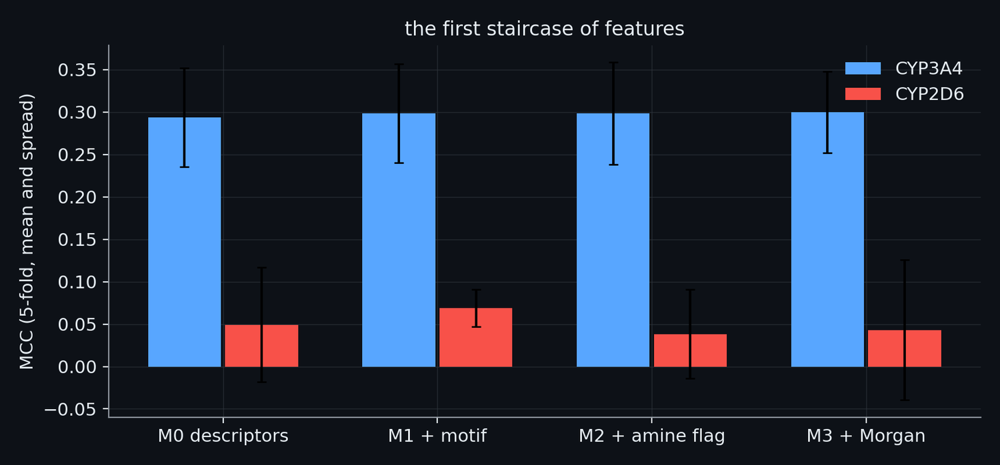

**Figure: The staircase M0 to M3.** The first staircase of features, from the run of 2026-09-25 (5-fold cross-validation, threshold 0.5, the population as first built): M0 the RDKit descriptors, M1 with the Type II motif flag, M2 with the trialkylamine flag, M3 with a Morgan fingerprint. MCC by stage, mean over the five folds: CYP3A4 M0 0.294, M1 0.298, M2 0.298, M3 0.300; CYP2D6 M0 0.049, M1 0.069, M2 0.038, M3 0.043. The steps are inside the spread of the folds, so the staircase shows what was tried and not a ranking; the M2 and M3 stages of this run kept the amine flag, which the specification later corrected (Tier 2), and the final model rests on none of these stages.

In [167]:
show_figure("ml_m0_m3_ablation")

## 7.3 Reading across: the labels of a compound's nearest neighbours

> **Field:** Cheminformatics · Machine learning

*Where this section sits:* 7.2 added chemistry that the project had written. This section adds what a medicinal chemist does first with a compound that has to be judged: look at the known compounds that look most like it. The idea is old and has a name, the *similar-property principle* (the volume edited by Johnson and Maggiora, 1990): structurally similar compounds tend to have similar properties. Section 4.5 turned it into a model, the nearest-neighbour classifier. Here it becomes something else, four columns that are handed to the gradient-boosted model of 7.1 together with the descriptors, so that the global model can use the local evidence when it helps and ignore it when it does not. The section also holds the project's first leakage lesson, and it is worth reading even by someone who does not care about this feature.

**The four columns.** For a compound $i$ with the Morgan bit fingerprint of section 3.1, let $N_k(i)$ be the set of the $k = 10$ other labelled compounds with the highest Tanimoto similarity $s_{ij}$ to it (section 3.2), and let $y_j \in \{0, 1\}$ be the label of compound $j$, 1 for a time-dependent inhibitor. Call the four columns $f_1$ to $f_4$. They are

$$f_1 = \frac{1}{k} \sum_{j \in N_k(i)} y_j, \qquad f_2 = \frac{\sum_{j \in N_k(i)} s_{ij}\, y_j}{\sum_{j \in N_k(i)} s_{ij}}, \qquad f_3 = \frac{1}{k} \sum_{j \in N_k(i)} s_{ij}, \qquad f_4 = k.$$

The first is the share of inhibitors among the neighbours, the second the same share with the closer neighbours counted more, the third the mean similarity of the neighbours, which tells the model how far the neighbourhood can be trusted (ten neighbours at 0.9 are evidence, ten at 0.3 are not), and the fourth the number of neighbours found, which is $k$ whenever the pool holds at least $k$ compounds and so is constant here. The next cell computes the four columns for one compound by hand, listing its neighbours, and by the project's function.

In [168]:
# The four read-across features for one compound. A labelled CYP3A4 compound that is a time-dependent inhibitor and whose ten nearest neighbours (Tanimoto similarity on the Morgan bits, section 3.2) include three
# inhibitors. The neighbours are searched among all the other labelled compounds, the compound itself left out; the features are then computed by hand and by the project's function.
from rdkit import DataStructs

from cypmode.challenge.knn_features import KNN_FEATURE_NAMES, _morgan_fp, add_knn_label_features_for_fold, knn_label_features
from cypmode.challenge.tdi_ablation import add_ablation_features

staircase = add_ablation_features(described)                                  # the columns of 7.2: descriptors, motif flag, amine flag and Morgan bits, one row per labelled compound

cyp3a4_frame = described.dropna(subset=["CYP3A4_is_TDI"]).reset_index(drop=True)
y_3a4 = cyp3a4_frame["CYP3A4_is_TDI"].astype(int).to_numpy()
fps_3a4 = [_morgan_fp(s) for s in cyp3a4_frame["SMILES"]]
example_index = None
for i in range(len(cyp3a4_frame)):
    similarities = np.array(DataStructs.BulkTanimotoSimilarity(fps_3a4[i], fps_3a4))
    similarities[i] = -1.0                                                   # the compound is not its own neighbour
    nearest = np.argsort(-similarities)[:10]
    if y_3a4[i] == 1 and y_3a4[nearest].sum() == 3 and 0.45 < similarities[nearest].mean() < 0.6:
        example_index = i
        break
neighbour_table = pd.DataFrame({"rank": np.arange(1, 11), "Tanimoto similarity": similarities[nearest], "neighbour is an inhibitor": y_3a4[nearest]})
show_table(neighbour_table, floatfmt=".2f")
by_hand = [y_3a4[nearest].mean(), float((similarities[nearest] * y_3a4[nearest]).sum() / similarities[nearest].sum()), similarities[nearest].mean(), 10.0]
others = np.arange(len(y_3a4)) != example_index
by_function = knn_label_features([fps_3a4[example_index]], [fps_3a4[j] for j in np.where(others)[0]], y_3a4[others])[0]
by_hand_equals_function = bool(np.allclose(by_hand, by_function))
show_table(pd.DataFrame({"feature": KNN_FEATURE_NAMES, "by hand": by_hand, "by the project's function": by_function}), floatfmt=".3f")
example_name = cyp3a4_frame["Molecule_Name"].iloc[example_index]

| rank | Tanimoto similarity | neighbour is an inhibitor |
| --- | --- | --- |
| 1 | 0.63 | 0 |
| 2 | 0.59 | 0 |
| 3 | 0.57 | 0 |
| 4 | 0.56 | 0 |
| 5 | 0.56 | 1 |
| 6 | 0.54 | 1 |
| 7 | 0.53 | 0 |
| 8 | 0.52 | 1 |
| 9 | 0.52 | 0 |
| 10 | 0.51 | 0 |

| feature | by hand | by the project's function |
| --- | --- | --- |
| knn_frac_positive | 0.300 | 0.300 |
| knn_sim_weighted_frac_positive | 0.293 | 0.293 |
| knn_mean_topk_similarity | 0.552 | 0.552 |
| knn_n_neighbors | 10.000 | 10.000 |

The compound OCNT-2308748 is itself an inhibitor; its ten nearest neighbours, at similarities from 0.63 down to 0.51, include 3 inhibitors, so that $f_1 = 0.3$, and the closer neighbours are mostly negative, so that $f_2$ is slightly lower. The by-hand values equal the function's: True. The example is a small lesson of its own: the neighbours of an inhibitor are mostly not inhibitors, and a feature that is only moderately informative is what read-across usually provides.

**Where a compound's label may not enter its own features.** The columns use labels, and that is where the danger is. A compound is its own nearest neighbour, at similarity 1, so that if it is left in its own neighbour list, its label is in its own feature, and the model needs no chemistry to read the answer. The project's construction (`add_knn_label_features_for_fold`) follows two rules. A training compound's list is searched among the other training compounds of the fold, itself left out; a validation compound's list is searched among the training compounds of the fold only. The cell compares the construction with its four ways of going wrong, on the same five folds, for both enzymes: no read-across columns at all; the columns built inside the fold as just described; columns built once on all the labelled compounds with each compound's own label left out ("global leave-one-out"); the training compounds' columns built with the compound itself in its list; and the validation compounds' columns built the same way. The model is the M3 set without the amine flag (descriptors, motif flag, Morgan bits).

In [169]:
# Where the label of a compound may enter its neighbours' features. Five versions of the same experiment on the same five folds (fixed seed), scored by AUC and by MCC at 0.5 on the validation folds, per enzyme: the
# model without the read-across features (M3 without the amine flag: descriptors, motif flag, Morgan bits); the project's construction, in which the features are built inside each fold from the training compounds only
# (the compound itself left out for the training rows); features built once on all labelled compounds, each compound's own label left out (global leave-one-out); the training rows' features built with the compound
# itself in its own neighbour list; and the validation rows' features built with the compound itself in the list. Only the first two and the last are about the validation compounds' labels, and they are the ones to compare.
leak_rows = []
for iso in TDI_ISOFORMS:
    column = f"{iso}_is_TDI"
    sub = staircase.dropna(subset=[column]).reset_index(drop=True)
    y = sub[column].astype(int).to_numpy()
    X = np.stack(sub["m3_no_amine_features"])
    fps = [_morgan_fp(s) for s in sub["SMILES"]]
    global_loo = np.zeros((len(y), 4))
    for i in range(len(y)):
        keep = np.where(np.arange(len(y)) != i)[0]
        global_loo[i] = knn_label_features([fps[i]], [fps[j] for j in keep], y[keep])[0]
    for fold, (fit_rows, held) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(X, y)):
        inside = add_knn_label_features_for_fold(fps, y, fit_rows, held)
        train_self = np.zeros((len(y), 4))
        train_fps = [fps[i] for i in fit_rows]
        train_self[fit_rows] = knn_label_features(train_fps, train_fps, y[fit_rows])        # every training compound is in its own list
        train_self[held] = inside[held]
        valid_self = inside.copy()
        valid_self[held] = knn_label_features([fps[i] for i in held], [fps[i] for i in range(len(y))], y)     # every validation compound is in its own list
        versions = {"no read-across features": X, "built inside the fold": np.hstack([X, inside]), "global leave-one-out": np.hstack([X, global_loo]),
                    "training compound in its own list": np.hstack([X, train_self]), "validation compound in its own list": np.hstack([X, valid_self])}
        for name, features in versions.items():
            p = LGBMClassifier(verbose=-1, random_state=42).fit(features[fit_rows], y[fit_rows]).predict_proba(features[held])[:, 1]
            leak_rows.append({"enzyme": iso, "version": name, "fold": fold, "MCC": matthews_corrcoef(y[held], (p >= 0.5).astype(int)), "AUC": roc_auc_score(y[held], p)})
leak_scores = pd.DataFrame(leak_rows)
leak_table = leak_scores.groupby(["enzyme", "version"], sort=False)[["MCC", "AUC"]].mean().reset_index()
show_table(leak_table, floatfmt=".3f")
def leak_value(iso, version, column):
    return float(leak_table[(leak_table["enzyme"] == iso) & (leak_table["version"] == version)][column].iloc[0])

| enzyme | version | MCC | AUC |
| --- | --- | --- | --- |
| CYP3A4 | no read-across features | 0.295 | 0.812 |
| CYP3A4 | built inside the fold | 0.315 | 0.819 |
| CYP3A4 | global leave-one-out | 0.296 | 0.815 |
| CYP3A4 | training compound in its own list | 0.202 | 0.689 |
| CYP3A4 | validation compound in its own list | 0.373 | 0.866 |
| CYP2D6 | no read-across features | 0.072 | 0.579 |
| CYP2D6 | built inside the fold | 0.074 | 0.569 |
| CYP2D6 | global leave-one-out | 0.045 | 0.574 |
| CYP2D6 | training compound in its own list | 0.105 | 0.588 |
| CYP2D6 | validation compound in its own list | 0.129 | 0.617 |

The two failures that put a compound in its own list have opposite effects. When the *validation* compound is in its own list, the score is inflated: CYP3A4 reaches an AUC of 0.866, against 0.819 for the correct construction and 0.812 for no read-across columns at all. The inflation, +0.047 AUC, is several times the gain that the corrected feature gives (+0.007), which is how a leak looks in practice: not an absurd score, a plausible improvement. When the *training* compounds are in their own lists the effect is the reverse: the model sees a feature that is almost perfect in training and learns to rely on it, and on the validation compounds, whose corrected columns are far weaker, it fails, with an AUC of 0.689 and an MCC of 0.202. The same mistake is invisible in one direction and ruinous in the other, and only the evaluation of the right side shows which.

The third wrong version, the global leave-one-out, is the one the module's docstring warns about: a training compound's column then contains labels of compounds that are in the validation fold. Here it does nothing measurable: the AUC is 0.815 against 0.819. The measured result is therefore that the second-order leak is within the noise at this size, and the rule is kept all the same, for a reason that is not statistical: the construction inside the fold is cheap, and it cannot be wrong by omission, while a global one has to be argued for each time it is used. For CYP2D6 no version of the feature changes the score beyond the spread of the folds, which is the second recurring theme of this part.

**What the feature did.** The stored ablation of the day compared the same five folds with and without the four columns, and the project's record of the day called its outcome a positive result on both enzymes. The cell sets that table beside the five repeated-partition experiments of 6.6, each of which contains the same pair, M3 and M3 plus the read-across columns.

In [170]:
# The stored result and its repeats. The ablation of the day (knn_features_ablation.csv: M3 against M3 plus the read-across features, five folds) and the five repeated-partition experiments of 6.6, every one of which
# contains the pair M3 and M3+KNN: the mean MCC change from adding the features, and the corrected paired p-value, for each enzyme.
from cypmode.challenge.model_comparison import corrected_resampled_t

stored_knn = pd.read_csv(COMPARISONS / "knn_features_ablation.csv")
stored_knn_means = stored_knn.groupby("isoform")[["mcc_m3", "mcc_m3_plus_knn"]].mean()
knn_rows = [{"experiment": "ablation of the day (5 folds)", "enzyme": iso, "mean MCC change": float((part["mcc_m3_plus_knn"] - part["mcc_m3"]).mean()), "p (corrected t)": corrected_resampled_t((part["mcc_m3_plus_knn"] - part["mcc_m3"]).to_numpy(), 4, 1).p_value}
            for iso, part in stored_knn.groupby("isoform")]
for name in ("stacking", "chemberta", "pharmacophore_fingerprint", "qm_reactivity", "quantum_pharmacophore"):
    raw = pd.read_csv(COMPARISONS / f"{name}_significance_raw.csv")
    for iso, part in raw.groupby("isoform"):
        pair = part.pivot_table(index=["repeat", "fold"], columns="variant", values="mcc")
        difference = (pair["M3+KNN"] - pair["M3"]).to_numpy()
        knn_rows.append({"experiment": f"{name} (5 x 5)", "enzyme": iso, "mean MCC change": float(difference.mean()), "p (corrected t)": corrected_resampled_t(difference, 4, 1).p_value})
knn_table = pd.DataFrame(knn_rows)
show_table(knn_table, floatfmt=".3f")
knn_5x5 = knn_table[knn_table["experiment"].str.contains("5 x 5")]
knn_range = {iso: (float(knn_5x5[knn_5x5["enzyme"] == iso]["mean MCC change"].min()), float(knn_5x5[knn_5x5["enzyme"] == iso]["mean MCC change"].max())) for iso in TDI_ISOFORMS}
knn_smallest_p = float(knn_table["p (corrected t)"].min())

| experiment | enzyme | mean MCC change | p (corrected t) |
| --- | --- | --- | --- |
| ablation of the day (5 folds) | CYP2D6 | 0.032 | 0.729 |
| ablation of the day (5 folds) | CYP3A4 | 0.012 | 0.658 |
| stacking (5 x 5) | CYP2D6 | -0.016 | 0.658 |
| stacking (5 x 5) | CYP3A4 | 0.012 | 0.494 |
| chemberta (5 x 5) | CYP2D6 | 0.025 | 0.566 |
| chemberta (5 x 5) | CYP3A4 | 0.012 | 0.530 |
| pharmacophore_fingerprint (5 x 5) | CYP2D6 | 0.025 | 0.566 |
| pharmacophore_fingerprint (5 x 5) | CYP3A4 | 0.012 | 0.530 |
| qm_reactivity (5 x 5) | CYP2D6 | -0.016 | 0.658 |
| qm_reactivity (5 x 5) | CYP3A4 | 0.012 | 0.494 |
| quantum_pharmacophore (5 x 5) | CYP2D6 | 0.025 | 0.566 |
| quantum_pharmacophore (5 x 5) | CYP3A4 | 0.007 | 0.746 |

The stored ablation had the MCC of CYP3A4 rising from 0.300 to 0.312 and that of CYP2D6 from 0.043 to 0.075, with corrected p-values of 0.66 and 0.73. In the five repeated experiments the CYP3A4 change is between +0.007 and +0.012 MCC in the five repeated experiments and the smallest corrected p-value of the whole table is 0.49. For CYP2D6 the change runs from -0.016 to +0.025: its sign is the sign of the run, and the experiments that differ by it differ only in the few compounds each added block could not be computed for, which were left out of that run and so changed the partitions. So the early reading, a gain on both enzymes and the largest for CYP2D6, was not established: it was one draw. The feature itself is sound and it stayed. In the nested design of Part VIII two members of the stack are built on it (`lgbm_A_deep_knnfeat` and `lgbm_A+fps_deep_knnfeat`, with $k = 10$), and the gate of 6.7 judges what they add inside the stack. The lesson of this section for everything that follows is the one about the evaluation: a feature that reads labels must be built, for every compound that is scored, from labels that compound's score could not have seen.

*On what actually ran.* `cypmode/challenge/knn_features.py` holds `knn_label_features` (the four columns for any query against any reference pool, with no notion of identity), `add_knn_label_features_for_fold` (the fold-internal construction, with the leave-one-out for the training rows) and `cross_validate_with_knn_features` (the ablation of the day). The module's tests include an adversarial case with two identical structures and different labels, which confirms that the self-exclusion works on the compound and not on the structure. The stored table is `knn_features_ablation.csv`; the five repeated-partition tables are those of 6.6. These experiments are on the mixed population of section 2.4.

## 7.4 The direct-inhibition bridge: a gain that was a shortcut

> **Field:** Data science · Machine learning

*Where this section sits:* 7.3 used the labels of other compounds. This section uses a quantity that is part of the *definition* of the label, and the way it went wrong is the most useful single lesson of Part VII. It is told in full because the same mistake can be made, and was made once, with a result that looked like the best of the project at that point.

**The idea.** The label of a compound depends on two measurements (section 2.3): the potency in the TDI arm, $t$, and the potency of direct inhibition, $d$, and it is positive when $t - \max(d, 4) > \log_{10} 2$. The blinded test file shows neither: it has two columns, the name and the structure. A model that wants potency as an input must therefore predict it. The *bridge* (`cypmode/challenge/oof_bridge.py`) is a regression of $d$ on the RDKit descriptors, LightGBM with each compound weighted by the inverse of its measured noise variance (section 2.5), whose prediction becomes a column of the classifier. It is built *out of fold*: the prediction for each compound comes from a regressor that never saw that compound, so that the column has in training the distribution it will have on the test compounds. A first plan was a censored regression (the Tobit model) for the readings below the assay floor; the data were checked first and showed no pile-up at the floor but a noise that grows five- to tenfold below it, which the inverse-variance weights describe and the censored model does not.

The cell reads the stored out-of-fold predictions, merges them on to the labelled CYP3A4 compounds and counts the facts that matter.

In [171]:
# What the bridge is and what it was given. The label rule of section 2.3 makes a compound's direct-inhibition pIC50 d part of its TDI label (positive when the TDI-arm pIC50 t exceeds max(d, 4) by more than log10 2), and the
# blinded test file shows no such value. The bridge (cypmode/challenge/oof_bridge.py) is a regressor of d from the structure, with the inverse-variance weights of section 2.5, whose out-of-fold predictions were to feed the
# classifier. The stored predictions are read, merged on to the labelled CYP3A4 compounds, and the facts that matter are counted.
from sklearn.metrics import roc_auc_score

stored_bridge = pd.read_csv(COMPARISONS / "oof_direct_inhibition.csv")
test_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TEST-BLINDED.csv")
bridge_frame = staircase.dropna(subset=["CYP3A4_is_TDI"]).reset_index(drop=True).merge(
    stored_bridge[["Molecule_Name", "CYP3A4_pIC50_direct_inhibition", "CYP3A4_pIC50_direct_inhibition_std", "CYP3A4_pIC50_oof", "CYP3A4_pIC50_oof_abs_error"]], on="Molecule_Name", how="left")
y_bridge = bridge_frame["CYP3A4_is_TDI"].astype(int).to_numpy()
unmeasured = bridge_frame["CYP3A4_pIC50_direct_inhibition"].isna().to_numpy()
measured_pair = bridge_frame.dropna(subset=["CYP3A4_pIC50_direct_inhibition"])
facts_rows = [
    {"quantity": "labelled CYP3A4 compounds", "value": len(bridge_frame)},
    {"quantity": "of which with no direct-inhibition reading", "value": int(unmeasured.sum())},
    {"quantity": "positives among those", "value": int(y_bridge[unmeasured].sum())},
    {"quantity": "AUC of the single fact 'a direct reading exists' as a score for the label", "value": float(roc_auc_score(y_bridge, (~unmeasured).astype(float)))},
    {"quantity": "mean absolute error of the bridge's out-of-fold prediction (pIC50 units)", "value": float(measured_pair["CYP3A4_pIC50_oof_abs_error"].mean())},
    {"quantity": "correlation of the prediction with the reading", "value": float(np.corrcoef(measured_pair["CYP3A4_pIC50_direct_inhibition"], measured_pair["CYP3A4_pIC50_oof"])[0, 1])},
    {"quantity": "columns of the blinded test file", "value": ", ".join(test_file.columns)},
]
show_table(pd.DataFrame(facts_rows), floatfmt=".3f")
bridge_facts = {row["quantity"]: row["value"] for row in facts_rows}
n_unmeasured, n_bridge_rows = int(unmeasured.sum()), len(bridge_frame)
flag_auc = bridge_facts["AUC of the single fact 'a direct reading exists' as a score for the label"]
bridge_mae = bridge_facts["mean absolute error of the bridge's out-of-fold prediction (pIC50 units)"]
bridge_corr = bridge_facts["correlation of the prediction with the reading"]

| quantity | value |
| --- | --- |
| labelled CYP3A4 compounds | 3584 |
| of which with no direct-inhibition reading | 1249 |
| positives among those | 0 |
| AUC of the single fact 'a direct reading exists' as a score for the label | 0.721 |
| mean absolute error of the bridge's out-of-fold prediction (pIC50 units) | 0.730 |
| correlation of the prediction with the reading | 0.668 |
| columns of the blinded test file | Molecule_Name, SMILES |

Of the 3,584 labelled CYP3A4 compounds, 1,249 have no direct reading, and of those 0 are positives: the convention of section 2.4 labels them all negative. The bridge predicts the reading of the others with a mean absolute error of 0.73 pIC50 units and a correlation of 0.67 with the measured value, a fair regression. And the single fact "a direct reading exists", used as a score for the label with no chemistry at all, has an AUC of 0.721. That is the shortcut. The stored predictions are empty for exactly the compounds that are certain to be negative, and LightGBM treats an empty value as a value of its own, sending it down a learned side of each split, so that a classifier given the bridge's column learns "empty means negative" in its first split. The next cell measures what that does, four ways. The first three are on the mixed population: without the feature; with it, the validation compounds keeping their empty values, which is how the experiment of the day was evaluated; and with it, the validation compounds given what the test compounds will be given, which is a prediction for every compound from a regressor that did not see it, with no empty value. The fourth is on the corrected population of section 2.4, with only the compounds that have a reading, where nothing is empty.

| version | AUC | MCC (top share called) |
| --- | --- | --- |
| without the feature | 0.812 | 0.382 |
| with the feature, validation compounds as in the experiment of the day | 0.852 | 0.412 |
| with the feature, validation compounds as the test compounds will be | 0.622 | 0.105 |
| corrected population, without the feature | 0.746 | 0.322 |
| corrected population, with the feature | 0.749 | 0.326 |

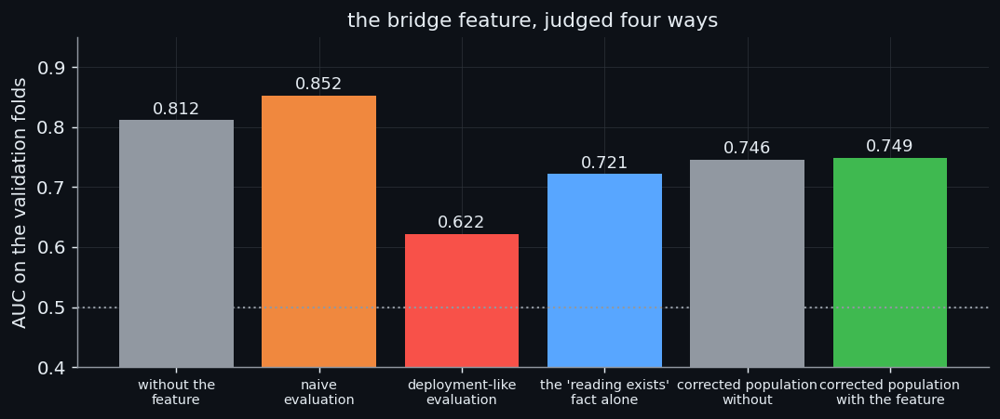

In [172]:
# The feature, tried three ways on the same five folds. The bridge's prediction is added to the classifier's columns. For a compound with no direct reading the stored prediction is empty (LightGBM treats an empty value as a
# value of its own: it learns on which side of each split to send it). (1) The naive evaluation: the validation compounds keep their empty values, as in the experiment of the day. (2) A deployment-like evaluation: the
# validation compounds are given what the test compounds will be given, a prediction for every compound, made by a regressor fitted on the compounds that have a reading (cypmode.challenge.oof_bridge.fit_final_model); the
# classifier is the same one, trained on the same empty values. (3) The classifier without the feature. MCC is taken by calling the same share of compounds positive as the training set's positive rate (section 6.4),
# which needs no threshold, next to the AUC.
from cypmode.challenge.oof_bridge import fit_final_model

bridge_oof = bridge_frame["CYP3A4_pIC50_oof"].to_numpy()                         # empty where there is no reading
regressor = fit_final_model(bridge_frame, "CYP3A4")
final_prediction = regressor.predict(np.stack(bridge_frame["descriptors"]))
bridge_deployment = np.where(unmeasured, final_prediction, bridge_oof)
X_bridge = np.stack(bridge_frame["m3_no_amine_features"])
def call_top_share(score, share):
    k = int(round(share * len(score)))
    return (score >= np.sort(score)[::-1][k - 1]).astype(int)
cv_rows = []
for fold, (fit_rows, held) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(X_bridge, y_bridge)):
    with_feature = LGBMClassifier(verbose=-1, random_state=42).fit(np.column_stack([X_bridge, bridge_oof])[fit_rows], y_bridge[fit_rows])
    without = LGBMClassifier(verbose=-1, random_state=42).fit(X_bridge[fit_rows], y_bridge[fit_rows])
    for name, model, held_features in (("without the feature", without, X_bridge[held]),
                                       ("with the feature, validation compounds as in the experiment of the day", with_feature, np.column_stack([X_bridge, bridge_oof])[held]),
                                       ("with the feature, validation compounds as the test compounds will be", with_feature, np.column_stack([X_bridge, bridge_deployment])[held])):
        p = model.predict_proba(held_features)[:, 1]
        cv_rows.append({"version": name, "fold": fold, "AUC": roc_auc_score(y_bridge[held], p), "MCC (top share called)": matthews_corrcoef(y_bridge[held], call_top_share(p, y_bridge.mean()))})
# (4) the corrected population of section 2.4: only the compounds with a reading, so that nothing is empty and the feature has to earn its place as a prediction from the structure.
both_arms = ~unmeasured
X_both, y_both, bridge_both = X_bridge[both_arms], y_bridge[both_arms], bridge_oof[both_arms]
for fold, (fit_rows, held) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(X_both, y_both)):
    for name, features in (("corrected population, without the feature", X_both), ("corrected population, with the feature", np.column_stack([X_both, bridge_both]))):
        p = LGBMClassifier(verbose=-1, random_state=42).fit(features[fit_rows], y_both[fit_rows]).predict_proba(features[held])[:, 1]
        cv_rows.append({"version": name, "fold": fold, "AUC": roc_auc_score(y_both[held], p), "MCC (top share called)": matthews_corrcoef(y_both[held], call_top_share(p, y_both.mean()))})
cv_frame = pd.DataFrame(cv_rows)
bridge_cv = cv_frame.groupby("version", sort=False)[["AUC", "MCC (top share called)"]].mean().reset_index()
show_table(bridge_cv, floatfmt=".3f")
bridge_values = bridge_cv.set_index("version")
v_without, v_naive, v_deploy, v_both_without, v_both_with = (bridge_values.index[i] for i in range(5))
fold_gain = cv_frame[cv_frame["version"] == v_both_with].sort_values("fold")["AUC"].to_numpy() - cv_frame[cv_frame["version"] == v_both_without].sort_values("fold")["AUC"].to_numpy()
corrected_population_test = corrected_resampled_t(fold_gain, 4, 1)
day_with = pd.read_csv(ROOT / "data/tdi_track/outputs/cyp3a4/oof_bridge_feature_tuned_cyp3a4.csv")
day_without = pd.read_csv(ROOT / "data/tdi_track/outputs/cyp3a4/threshold_tuning_cyp3a4_no_amine.csv")
day_mcc_with, day_mcc_without, day_auc_with = float(day_with["mcc_tuned"].mean()), float(day_without["mcc_tuned"].mean()), float(day_with["roc_auc"].mean())
fig, axis = plt.subplots(figsize=(8.4, 3.6))
bars = [bridge_values.loc[v_without, "AUC"], bridge_values.loc[v_naive, "AUC"], bridge_values.loc[v_deploy, "AUC"], flag_auc, bridge_values.loc[v_both_without, "AUC"], bridge_values.loc[v_both_with, "AUC"]]
labels = ["without the\nfeature", "naive\nevaluation", "deployment-like\nevaluation", "the 'reading exists'\nfact alone", "corrected population\nwithout", "corrected population\nwith the feature"]
axis.bar(labels, bars, color=[theme["muted"], theme["orange"], theme["red"], theme["blue"], theme["muted"], theme["green"]])
axis.axhline(0.5, color=theme["muted"], ls=":", lw=1.2)
for position, value in enumerate(bars):
    axis.text(position, value + 0.01, f"{value:.3f}", ha="center", color=theme["text"], fontsize=10)
axis.set(ylabel="AUC on the validation folds", ylim=(0.4, 0.95), title="the bridge feature, judged four ways")
axis.tick_params(axis="x", labelsize=8)
tidy(axis, theme)
fig.tight_layout()

The experiment of the day is reproduced. Without the feature the tuned MCC of the stored table is 0.387; with it, 0.470 and an AUC of 0.852, and the cell's naive evaluation reproduces that AUC (0.852; without the feature 0.812). It was the largest gain the project had found, +0.08 MCC for a feature with a plausible mechanism, and it was not believed for long. Three facts removed it. The test file exposes no direct reading, so the column the model had learned to read could not exist at deployment. The model, shown the deployment-like input, scores an AUC of 0.622 and an MCC of 0.105, far below the 0.812 and 0.382 of the model without the feature: it is worse than having nothing, because it has learned to trust a signal that is absent. And on the corrected population, where the shortcut is gone, the feature moves the AUC from 0.746 to 0.749, a change of +0.0034 with a corrected p-value of 0.67: the prediction of $d$ from the descriptors carries no information about the label that the descriptors did not already carry.

The record of the day re-checked the claim with an evaluation in which the validation compounds were scored with no awareness of their own missingness, and found the tuned MCC at 0.378, below the 0.387 of the model without the feature, and retracted the result. The cell above shows a harsher version of the same check, in which the classifier is also trained with the empty values, and the corrected-population row is the version the project's design adopted in the end: the nested design of Part VIII trains and scores on the compounds with both arms measured, and a model of the direct-inhibition arm, where it appears, is one candidate among the others, a regression of the two arms (sections 4.6 and 9.6), and not a feature handed to the classifier.

Four rules come out of this section, and the project has kept them. The first is that every feature must be computable from the structure alone for the blinded compounds, and the cell above checks the file for it: two columns. The second is that the evaluation of a model must give the validation compounds exactly the information that the test compounds will have, no more and no less. The third is that a gain which is large, arrives at once and has a mechanism that is easy to tell is the kind to attack hardest, not the kind to report first. The fourth is that a gain of a feature must be compared with the gain of the single fact that could explain it: here "a reading exists" alone has an AUC of 0.72, and no model needed to be better than that to show the shortcut.

*On what actually ran.* `cypmode/challenge/oof_bridge.py` holds `compute_oof_predictions` (a regressor per fold, inverse-variance weights from the measured noise), `fit_final_model` (the regressor fitted on every compound with a reading, which is what would have run on the test compounds) and `predict_test`. The stored table is `oof_direct_inhibition.csv`; the numbers of the day are in `oof_bridge_feature_tuned_cyp3a4.csv` and `threshold_tuning_cyp3a4_no_amine.csv`. The test that the module's out-of-fold construction does not leak is a weak one (it asks only for a correlation above 0.3), as the audit of 2026-09-26 noted; the construction itself was checked directly and is correct, and the retraction concerned the *use* of the feature and not its construction.

## 7.5 The decision threshold, the positive rate, and a first reliability score

> **Field:** Statistics · Machine learning

*Where this section sits:* 7.1 showed that the baseline ranks well and decides badly, because 0.5 is the wrong place to cut. A threshold is a choice, and Part VI taught that a choice must be made without the labels it will be scored on. This section applies the lesson to the threshold, shows why the MCC of one decision rule changes with the positive rate and what the project made of that, and ends with the first attempt at saying how far a single prediction can be trusted, which turned out to be instructive for a reason nobody planned.

**Choosing the threshold without cheating.** The module `cypmode/challenge/threshold_tuning.py` sweeps a grid of thresholds and keeps the one that maximises the MCC. The question is on which probabilities the sweep is run. The cell compares four answers on the same model and the same five outer folds, with an inner four-fold cross-validation inside each training part (the descriptors and LightGBM of 7.1, to keep the cell quick): the fixed 0.5; the best threshold *for the validation fold itself*, which looks at the labels the fold is scored on; the project's rule, the threshold that maximises the MCC on the inner out-of-fold probabilities of the training part, frozen, and applied to the validation fold it has never seen; and a naive rate rule, calling positive the same share of the validation compounds as the positive rate of the training part.

In [173]:
# Four ways of choosing the threshold, on the same probabilities. The model is the LightGBM of 7.1 on the descriptors; five outer folds; for each outer fold the training part gets an inner four-fold cross-validation to produce
# out-of-fold probabilities that never touch the outer validation fold. The rules: (1) the fixed 0.5; (2) the threshold that is best on the outer validation fold itself, which uses the labels it is then scored on;
# (3) the project's rule (cypmode/challenge/threshold_tuning.py): the threshold that maximises the MCC on the inner out-of-fold probabilities of the training part, frozen and applied to the validation fold; (4) the rate rule:
# call as positive the same share of the validation compounds as the positive rate of the training part, whatever the probabilities are.
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import matthews_corrcoef
from sklearn.model_selection import StratifiedKFold

from cypmode.challenge.tdi_baseline import TDI_ISOFORMS
from cypmode.challenge.threshold_tuning import DEFAULT_THRESHOLD_GRID, find_optimal_threshold

def top_share(score, share):
    k = int(round(share * len(score)))
    return (score >= np.sort(score)[::-1][k - 1]).astype(int)

rule_rows, chosen_rows = [], []
for iso in TDI_ISOFORMS:
    column = f"{iso}_is_TDI"
    sub = described.dropna(subset=[column]).reset_index(drop=True)
    y = sub[column].astype(int).to_numpy()
    X = np.stack(sub["descriptors"])
    for fold, (fit_rows, held) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(X, y)):
        inner = np.full(len(fit_rows), np.nan)
        for inner_fit, inner_held in StratifiedKFold(4, shuffle=True, random_state=42).split(X[fit_rows], y[fit_rows]):
            inner[inner_held] = LGBMClassifier(verbose=-1, random_state=42).fit(X[fit_rows][inner_fit], y[fit_rows][inner_fit]).predict_proba(X[fit_rows][inner_held])[:, 1]
        tuned, _ = find_optimal_threshold(y[fit_rows], inner)
        p = LGBMClassifier(verbose=-1, random_state=42).fit(X[fit_rows], y[fit_rows]).predict_proba(X[held])[:, 1]
        best_on_validation, _ = find_optimal_threshold(y[held], p)
        calls = {"fixed 0.5": (p >= 0.5).astype(int), "best on the validation fold itself (uses its labels)": (p >= best_on_validation).astype(int),
                 "tuned on the inner out-of-fold probabilities (the project rule)": (p >= tuned).astype(int), "call the training positive rate": top_share(p, y[fit_rows].mean())}
        for rule, called in calls.items():
            rule_rows.append({"enzyme": iso, "rule": rule, "fold": fold, "MCC": matthews_corrcoef(y[held], called)})
        chosen_rows.append({"enzyme": iso, "fold": fold, "threshold tuned inside the training part": tuned, "threshold best on the validation fold": best_on_validation})
rule_scores = pd.DataFrame(rule_rows)
rule_table = rule_scores.groupby(["enzyme", "rule"], sort=False)["MCC"].agg(["mean", "std"]).reset_index().rename(columns={"mean": "mean MCC over the 5 folds", "std": "sd over the folds"})
show_table(rule_table, floatfmt=".3f")
chosen_table = pd.DataFrame(chosen_rows)
show_table(chosen_table.groupby("enzyme")[["threshold tuned inside the training part", "threshold best on the validation fold"]].agg(["min", "max"]).reset_index().round(2), floatfmt=".2f")
def rule_value(iso, rule, column="mean MCC over the 5 folds"):
    return float(rule_table[(rule_table["enzyme"] == iso) & (rule_table["rule"] == rule)][column].iloc[0])

| enzyme | rule | mean MCC over the 5 folds | sd over the folds |
| --- | --- | --- | --- |
| CYP3A4 | fixed 0.5 | 0.294 | 0.058 |
| CYP3A4 | best on the validation fold itself (uses its labels) | 0.390 | 0.043 |
| CYP3A4 | tuned on the inner out-of-fold probabilities (the project rule) | 0.379 | 0.032 |
| CYP3A4 | call the training positive rate | 0.331 | 0.083 |
| CYP2D6 | fixed 0.5 | 0.049 | 0.068 |
| CYP2D6 | best on the validation fold itself (uses its labels) | 0.140 | 0.061 |
| CYP2D6 | tuned on the inner out-of-fold probabilities (the project rule) | 0.104 | 0.074 |
| CYP2D6 | call the training positive rate | 0.097 | 0.059 |

| ('enzyme', '') | ('threshold tuned inside the training part', 'min') | ('threshold tuned inside the training part', 'max') | ('threshold best on the validation fold', 'min') | ('threshold best on the validation fold', 'max') |
| --- | --- | --- | --- | --- |
| CYP2D6 | 0.05 | 0.15 | 0.05 | 0.75 |
| CYP3A4 | 0.10 | 0.15 | 0.10 | 0.20 |

For CYP3A4 the fixed 0.5 gives 0.294; the threshold chosen on the validation fold itself gives 0.390, which no real user can have, and the project's rule 0.379: nearly all of the gain with no label of the validation fold used. The naive rate rule gives 0.331 with a larger spread over the folds. For CYP2D6 the four numbers are 0.049, 0.140, 0.104 and 0.097. The gap between the second and the third column, the optimism of choosing the threshold on the fold that is scored, is 0.010 MCC for CYP3A4 and 0.036 for CYP2D6, where it is larger because the signal is weaker and the best threshold moves from fold to fold (the second table: the threshold that is best on a CYP2D6 fold ranges from 0.05 to 0.75, while the one tuned inside the training part stays between 0.05 and 0.15). Of the two rules that use no label of the validation fold, the project's is the first, and it is the one whose descendant, the transfer of a call *rate* tuned inside the folds (section 8.4), the final model uses.

**Why a rate and not a threshold.** The MCC of a fixed decision rule is not a fixed number; it depends on how common the positives are among the compounds it is applied to. Write $\pi$ for the share of positives, $\mathrm{TPR}$ for the share of positives that the rule calls positive (the true-positive rate, the recall of section 4.10) and $\mathrm{FPR}$ for the share of negatives that it calls positive (the false-positive rate). Per compound, the expected shares of the four cells of the confusion table are $TP = \pi\,\mathrm{TPR}$, $FN = \pi\,(1-\mathrm{TPR})$, $FP = (1-\pi)\,\mathrm{FPR}$ and $TN = (1-\pi)(1-\mathrm{FPR})$. Put into the definition of the MCC, $(TP\cdot TN - FP\cdot FN)/\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}$, the numerator becomes $\pi(1-\pi)(\mathrm{TPR}-\mathrm{FPR})$ and the factors under the root become $(\pi\,\mathrm{TPR} + (1-\pi)\,\mathrm{FPR})$, $\pi$, $(1-\pi)$ and $(\pi(1-\mathrm{TPR}) + (1-\pi)(1-\mathrm{FPR}))$, so that

$$\mathrm{MCC}(\pi) \;=\; \frac{\sqrt{\pi(1-\pi)}\;(\mathrm{TPR}-\mathrm{FPR})}{\sqrt{\bigl(\pi\,\mathrm{TPR} + (1-\pi)\,\mathrm{FPR}\bigr)\bigl(\pi\,(1-\mathrm{TPR}) + (1-\pi)(1-\mathrm{FPR})\bigr)}}.$$

A rule is described by its two rates, and the same two rates give different MCC values at different $\pi$. The cell checks the formula against the MCC computed from counts, draws it for the best operating point of the baseline of each enzyme, and reads the project's stored stress test of a *minimax* threshold: a threshold chosen to have the best worst-case MCC over an assumed range of positive rates (5 to 50 percent), tested on real validation folds resampled to other positive rates.

largest difference between the closed formula and the MCC from counts: 1.1e-16


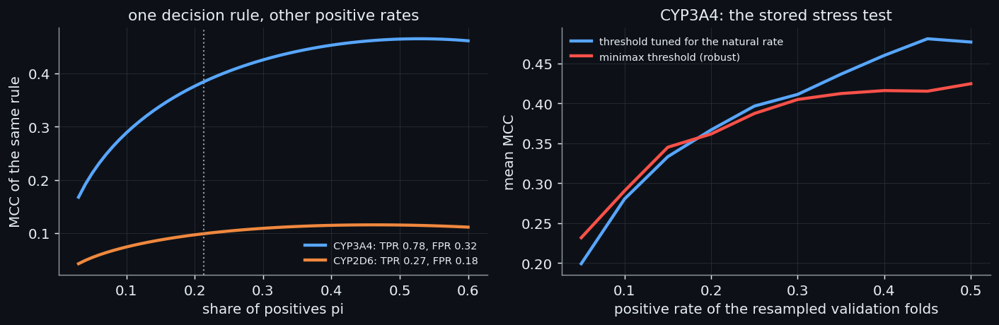

In [174]:
# The MCC of a fixed decision rule is not a fixed number: it depends on how common the positives are. Let a rule have a true-positive rate TPR and a false-positive rate FPR, and let the share of positives be pi. The expected
# counts per compound are TP = pi TPR, FN = pi (1 - TPR), FP = (1 - pi) FPR, TN = (1 - pi)(1 - FPR). Put into the definition of the MCC (section 4.10) they give MCC = sqrt(pi (1 - pi)) (TPR - FPR) /
# sqrt((pi TPR + (1 - pi) FPR)(pi (1 - TPR) + (1 - pi)(1 - FPR))). The formula is checked against the MCC computed from counts, then drawn for the operating point of the baseline of 7.1 at its best threshold, and the
# project's stored stress test of the minimax threshold (robust_threshold_stress_test.csv, which resamples real validation folds to other positive rates) is read beside it.
from scipy import stats

def mcc_at_rate(tpr, fpr, pi):
    numerator = np.sqrt(pi * (1 - pi)) * (tpr - fpr)
    denominator = np.sqrt((pi * tpr + (1 - pi) * fpr) * (pi * (1 - tpr) + (1 - pi) * (1 - fpr)))
    return numerator / denominator

def mcc_from_counts(tp, fn, fp, tn):
    return (tp * tn - fp * fn) / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))

rate_grid = np.linspace(0.03, 0.6, 58)
operating_points, check_errors = {}, []
for iso in TDI_ISOFORMS:
    column = f"{iso}_is_TDI"
    sub = described.dropna(subset=[column]).reset_index(drop=True)
    y = sub[column].astype(int).to_numpy()
    X = np.stack(sub["descriptors"])
    p = np.zeros(len(y))
    for fit_rows, held in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
        p[held] = LGBMClassifier(verbose=-1, random_state=42).fit(X[fit_rows], y[fit_rows]).predict_proba(X[held])[:, 1]
    best_threshold, _ = find_optimal_threshold(y, p)                 # the pooled out-of-fold probabilities; the best threshold on them is used only to fix one operating point to draw
    called = p >= best_threshold
    tpr, fpr = float(called[y == 1].mean()), float(called[y == 0].mean())
    operating_points[iso] = (tpr, fpr)
    for pi in (0.05, 0.2, 0.45):
        check_errors.append(abs(mcc_at_rate(tpr, fpr, pi) - mcc_from_counts(pi * tpr, pi * (1 - tpr), (1 - pi) * fpr, (1 - pi) * (1 - fpr))))
formula_error = float(max(check_errors))
stored_stress = pd.read_csv(COMPARISONS / "robust_threshold_stress_test.csv")
stress_by_rate = stored_stress.groupby(["isoform", "target_base_rate"])[["mcc_naive_threshold", "mcc_robust_threshold"]].mean().reset_index()
stored_robust = pd.read_csv(COMPARISONS / "robust_threshold_tuning.csv")
robust_natural = stored_robust.groupby("isoform")[["mcc_naive_threshold", "mcc_robust_threshold"]].mean()
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.7))
for iso, colour in zip(TDI_ISOFORMS, (theme["blue"], theme["orange"])):
    left.plot(rate_grid, mcc_at_rate(*operating_points[iso], rate_grid), color=colour, lw=2.4, label=f"{iso}: TPR {operating_points[iso][0]:.2f}, FPR {operating_points[iso][1]:.2f}")
left.axvline(0.213, color=theme["muted"], ls=":", lw=1.2)
left.set(xlabel="share of positives pi", ylabel="MCC of the same rule", title="one decision rule, other positive rates")
left.legend(frameon=False, fontsize=8)
cyp3a4_stress = stress_by_rate[stress_by_rate["isoform"] == "CYP3A4"]
right.plot(cyp3a4_stress["target_base_rate"], cyp3a4_stress["mcc_naive_threshold"], color=theme["blue"], lw=2.4, label="threshold tuned for the natural rate")
right.plot(cyp3a4_stress["target_base_rate"], cyp3a4_stress["mcc_robust_threshold"], color=theme["red"], lw=2.4, label="minimax threshold (robust)")
right.set(xlabel="positive rate of the resampled validation folds", ylabel="mean MCC", title="CYP3A4: the stored stress test")
right.legend(frameon=False, fontsize=8)
for axis in (left, right):
    tidy(axis, theme)
fig.tight_layout()
print(f"largest difference between the closed formula and the MCC from counts: {formula_error:.1e}")
mcc_low_rate = {iso: float(mcc_at_rate(*operating_points[iso], 0.05)) for iso in TDI_ISOFORMS}
mcc_high_rate = {iso: float(mcc_at_rate(*operating_points[iso], 0.45)) for iso in TDI_ISOFORMS}
stress_gain = {}
for iso in TDI_ISOFORMS:
    part = stress_by_rate[stress_by_rate["isoform"] == iso]
    low, high = part[part["target_base_rate"] <= 0.15], part[part["target_base_rate"] >= 0.3]
    stress_gain[iso] = (float((low["mcc_robust_threshold"] - low["mcc_naive_threshold"]).mean()), float((high["mcc_robust_threshold"] - high["mcc_naive_threshold"]).mean()))

The formula equals the MCC computed from counts to 1e-16. For the operating point drawn in the left panel, the MCC of CYP3A4 runs from 0.21 at a positive rate of 5 percent to 0.46 at 45 percent, and that of CYP2D6 from 0.05 to 0.12: the same rule, scored on populations that differ only in the share of positives. The minimax threshold buys protection in one direction and pays for it in the other. On the stored stress test it raises the CYP3A4 MCC by +0.018 on average when the positive rate is 15 percent or less, and lowers it by 0.038 when it is 30 percent or more; at the natural rate it is a wash (0.371 against 0.375). The project of the day did not adopt it, because nothing said which way the blinded set's positive rate would differ from the training file's.

Something did say, later. The positive rates of the scored sets were recovered from the public boards (section 2.10): about 0.31 for CYP3A4 and about 0.06 for CYP2D6, against 0.21 for both enzymes in the training file. The shifts are in *opposite* directions. A threshold tuned on the training file's rate is therefore too eager for CYP2D6 and too timid for CYP3A4, and no single minimax rule serves both. Two conclusions followed, and the final model of Part VIII acts on both. The yardstick of 6.4 re-weights the validation compounds to the estimated rate of the scored set, so that the MCC of a candidate is read at the rate it will be scored at. And the operating point is transferred as a *rate of calls*, the share of compounds called positive, chosen on the inner out-of-fold scores, because a probability threshold means little when the positive rate moves and a rate of calls means the same thing in both populations (section 8.4).

**A first reliability score.** The last component of the first TDI models was a *reliability score*, a number per compound meant to say how far its prediction can be trusted, kept outside the prediction path from the start (`cypmode/challenge/reliability.py`). It was to be called uncertainty quantification only if its correlation with the real mistakes of the model had been measured. It had two components. The first was the disagreement of an ensemble: five LightGBM models trained on the same compounds with different random seeds, the standard deviation of their predicted probabilities for a compound. The second was the distance of the compound to the training set, $1 - \max_j s_{ij}$, with $s_{ij}$ the Tanimoto similarity (section 3.2) of the compound $i$ to a training compound $j$. The cell recomputes them for the validation compounds of the first fold of the fixed-seed protocol, for CYP3A4, and the correlation of each with a mistake of the model at 0.5 (point-biserial, the Pearson correlation of a number with a yes/no variable, and Spearman), next to the stored values.

In [175]:
# The first reliability score of the project (cypmode/challenge/reliability.py): two numbers per compound, computed for the validation compounds of the first fold of the fixed-seed five-fold protocol (CYP3A4, the
# descriptors), and checked against the thing a reliability score is for, the model's actual mistakes at the threshold 0.5. The first is the disagreement of an ensemble of five LightGBM models trained on the same
# compounds with different random seeds; the second is the distance to the training set, 1 minus the highest Tanimoto similarity to a training compound (section 3.2). The correlations with the mistake are the stored ones
# (reliability_correlation.csv) and the recomputed ones.
from scipy.stats import pointbiserialr, spearmanr

from cypmode.challenge.reliability import ensemble_disagreement, tanimoto_ood_distance

cyp3a4_sub = described.dropna(subset=["CYP3A4_is_TDI"]).reset_index(drop=True)
y_rel = cyp3a4_sub["CYP3A4_is_TDI"].astype(int).to_numpy()
X_rel = np.stack(cyp3a4_sub["descriptors"])
fit_rel, held_rel = next(iter(StratifiedKFold(5, shuffle=True, random_state=42).split(X_rel, y_rel)))
disagreement = ensemble_disagreement(X_rel[fit_rel], y_rel[fit_rel], X_rel[held_rel])
distance = tanimoto_ood_distance(cyp3a4_sub.loc[fit_rel, "SMILES"], cyp3a4_sub.loc[held_rel, "SMILES"])
probabilities = LGBMClassifier(verbose=-1, random_state=42).fit(X_rel[fit_rel], y_rel[fit_rel]).predict_proba(X_rel[held_rel])[:, 1]
mistake = ((probabilities >= 0.5).astype(int) != y_rel[held_rel]).astype(int)
stored_reliability = pd.read_csv(COMPARISONS / "reliability_correlation.csv").set_index("component")
reliability_rows = []
for name, values in (("ensemble_disagreement", disagreement), ("ood_distance", distance)):
    reliability_rows.append({"component": name, "point-biserial r with a mistake": float(pointbiserialr(mistake, values)[0]), "Spearman r": float(spearmanr(mistake, values)[0]),
                             "stored point-biserial r": float(stored_reliability.loc[name, "point_biserial_r"]), "stored Spearman r": float(stored_reliability.loc[name, "spearman_r"])})
reliability_table = pd.DataFrame(reliability_rows)
show_table(reliability_table, floatfmt=".3f")
disagreement_summary = {"largest value": float(disagreement.max()), "share exactly zero": float((disagreement == 0).mean()), "compounds": len(disagreement)}
n_mistakes, mistake_rate = int(mistake.sum()), float(mistake.mean())
distance_quartile_rates = [float(mistake[(distance >= lo) & (distance <= hi)].mean()) for lo, hi in zip(np.quantile(distance, [0, 0.25, 0.5, 0.75]), np.quantile(distance, [0.25, 0.5, 0.75, 1.0]))]
print(f"disagreement of the five seeds: largest {disagreement_summary['largest value']:.1e}, exactly zero for {disagreement_summary['share exactly zero']:.1%} of {disagreement_summary['compounds']} compounds; mistakes {n_mistakes} ({mistake_rate:.1%}); mistake rate by distance quartile {[round(r, 3) for r in distance_quartile_rates]}")

disagreement of the five seeds: largest 1.1e-16, exactly zero for 88.4% of 717 compounds; mistakes 136 (19.0%); mistake rate by distance quartile [0.061, 0.188, 0.272, 0.243]


| component | point-biserial r with a mistake | Spearman r | stored point-biserial r | stored Spearman r |
| --- | --- | --- | --- | --- |
| ensemble_disagreement | 0.098 | 0.034 | 0.098 | 0.034 |
| ood_distance | 0.195 | 0.180 | 0.195 | 0.180 |

The stored correlations are reproduced: 0.098 for the ensemble and 0.195 for the distance. The first number is a correlation with nothing. The five models differ only by their random seed, and a LightGBM model with its default settings has no random element: it uses every row and every column at every tree, so five seeds give five identical models. The disagreement of the ensemble is therefore zero up to the rounding of floating-point numbers: its largest value over the 717 compounds is 1.1e-16, and it is exactly zero for 88.4% of them. A correlation computed from such values is a correlation with rounding error. The distance is a real signal: the model errs on 6.1% of the compounds in the quartile closest to the training set and on 27.2% and 24.3% in the two farthest quartiles, and the correlation of 0.20 summarises a relation that is steep at the near end and flat beyond it.

The lesson is a check that costs one line and was not made: before a correlation is computed, look at the spread of the numbers. The disagreement score was dropped from the plan, the distance stayed, and the replacement for the first component is the subject of 7.6.

*On what actually ran.* `cypmode/challenge/threshold_tuning.py` holds `find_optimal_threshold` (the sweep over the grid 0.05 to 0.95), `cross_validate_with_threshold_tuning` (the inner-fold rule), `find_robust_threshold` (the minimax rule, which reconstructs the MCC at each assumed positive rate from the TPR and FPR curve with the formula above) and `base_rate_shift_stress_test`; the stored tables are `threshold_tuning.csv`, `robust_threshold_tuning.csv` and `robust_threshold_stress_test.csv`. `cypmode/challenge/reliability.py` holds `ensemble_disagreement`, `tanimoto_ood_distance`, `one_class_svm_ood_score` and `validate_reliability_correlation`; the stored table is `reliability_correlation.csv`. The cell above uses the descriptors only, where the stored experiments used the M3 columns for the thresholds. All of this is on the mixed population of section 2.4.

## 7.6 Uncertainty by committee, tested against real mistakes

> **Field:** Machine learning · Statistics

*Where this section sits:* 7.5 ended with a reliability score whose first component measured nothing. This section builds a better candidate for it and then applies the strictest test the project could think of: the candidate must tell something that the simplest possible signal does not. It is one of the clearest cases in the project of a measured negative result, kept as such on purpose.

**What uncertainty is for.** A classifier that says 0.7 for a compound is right or wrong, and an *uncertainty* is a number, computed with the prediction, that is high when the prediction is likely to be wrong. It would be useful: a prediction with a flag could be set aside, or the compound sent for a measurement or a structure prediction. Three families of such numbers are common. The first uses the random passes of one model, dropout kept on at prediction time and the spread of the outputs (Gal and Ghahramani, 2016). The second uses the spread of one algorithm over random seeds, which is what 7.5 tried and found empty for gradient boosting. The third is **query by committee** (Seung, Opper and Sompolinsky, 1992; the technique comes from active learning, the choice of which compound to measure next): train a committee of *different* models and take their disagreement as the uncertainty. The nested design of Part VI already holds the out-of-fold predictions of 23 different models for every compound (6.3), so the committee costs nothing to build.

**The signals and the bar.** Two disagreements are used. For compound $i$ let $q_i$ be the share of the members that call it positive, each member calling positive the same share of compounds as the stack does. The *vote entropy* is $-\bigl(q_i \ln q_i + (1-q_i)\ln(1-q_i)\bigr)$, the binary entropy of the vote: 0 when the members agree, $\ln 2 = 0.693$ when they split evenly. The *spread* is the standard deviation across members of their scores, each put on a common 0-to-1 scale. Two variants restrict the committee to its five best members and to one family of models. The bar is not "is it correlated with the stack's mistakes" but "does it tell something that the **margin** does not": the margin is the distance of the stack's score from its own decision threshold, so that a compound near the line is uncertain by construction. The module (`cypmode/challenge/committee_uncertainty.py`) asks three questions of every signal, on compounds that no member and no selector has seen: does it flag the stack's mistakes better than chance (the AUROC for "the stack is wrong", with a bootstrap interval); does it add information beyond the margin (the gain in that AUROC when the signal is added to the margin in a cross-validated error model, against a null made by permuting the signal's values across compounds, since bootstrapping fixed predictions produced a "discovery" from pure-noise committees in the module's own tests, the point of 6.6); and does acting on it improve the decisions (the most uncertain share of the compounds is given a negative call and the MCC is recomputed). A component may alter a prediction only if it adds information beyond the margin *and* acting on it raises the MCC by at least 0.01. First the signals on a toy.

In [176]:
# The two committee signals, on a toy. Five members each vote "positive" or "negative" for three compounds, and each also gives a score on a common 0-to-1 scale (the project puts the members on one scale with
# their own empirical cumulative distribution functions; section 8.2). Vote entropy is the binary entropy of the share of positive votes, -(q ln q + (1 - q) ln(1 - q)) for the share q: 0 when the members agree and
# 0.693 (ln 2) when they split as evenly as possible. Spread is the standard deviation of the five scores.
from cypmode.challenge.committee_uncertainty import committee_spread, vote_entropy

toy_votes = np.array([[1, 1, 1, 1, 1], [1, 1, 1, 0, 0], [1, 1, 0, 0, 0]])
toy_scores = np.array([[0.91, 0.88, 0.95, 0.9, 0.93], [0.7, 0.6, 0.65, 0.4, 0.35], [0.62, 0.58, 0.41, 0.35, 0.3]])
toy_table = pd.DataFrame({"compound": ["A", "B", "C"], "votes for positive (of 5)": toy_votes.sum(axis=1), "vote entropy": vote_entropy(toy_votes), "spread of the scores": committee_spread(toy_scores)})
show_table(toy_table, floatfmt=".3f")
toy_entropies = toy_table["vote entropy"].tolist()

| compound | votes for positive (of 5) | vote entropy | spread of the scores |
| --- | --- | --- | --- |
| A | 5 | 0.000 | 0.024 |
| B | 3 | 0.673 | 0.139 |
| C | 2 | 0.673 | 0.126 |

Compound A, on which the five members agree, has entropy 0.000; compound B, with three votes against two, has 0.673, close to the maximum of $\ln 2 = 0.693$; compound C, with two votes against three, has the same entropy as B, since the entropy does not know which side is the majority. The spread is a different measure, large when the members' scores are far apart even if their votes are the same. The next cell computes the signals for the 2,334 compounds of the first repeat of the CYP3A4 plan and judges them with the module's own functions.

In [177]:
# The committee on real compounds. The 23 default members of the stack (section 8.1) have their predictions for every compound in the outer-validation folds of the nested plan of 6.3, made by models that never saw it.
# For each compound: the stack's call (cypmode.challenge.nested), whether the call is wrong, the margin (minus the distance of the stack's score from its own threshold, the simplest signal of "close to the line") and the committee signals.
# Each is judged by cypmode/challenge/committee_uncertainty.py: the AUROC for flagging the stack's mistakes, the gain in that AUROC when the signal is added to the margin in a cross-validated error model, with a p-value from
# a permutation null (the signal's values are permuted across compounds 200 times; section 6.6 gave the reason for not bootstrapping fixed predictions), and then whether acting on it, by falling back to a negative call
# for the most uncertain share of the compounds, raises the MCC. One repeat is used (2,334 compounds, each once) so that the compounds are independent.
from cypmode.challenge.committee_uncertainty import BASELINE, COMMITTEE_SIGNALS, collect_signals, evaluate_components, selective_fallback
from cypmode.challenge.nested import NestedPlan, PredictionCache
from cypmode.challenge.nested_runners import default_candidates

nested_root = ROOT / "data/tdi_track/outputs/nested/CYP3A4"
committee_plan = NestedPlan.load(nested_root / "plan.npz")
committee_cache = PredictionCache(nested_root / "cache", committee_plan)
committee_names = [c.name for c in default_candidates()]
morgan_bits = np.load(ROOT / "data/tdi_track/outputs/caches/feature_store.npz", allow_pickle=True)["morgan_bits"]
signals_all = collect_signals(committee_cache, committee_names, morgan_bits)
signals = signals_all[signals_all["fold"].str.startswith("0-")].reset_index(drop=True)
evaluation = evaluate_components(signals)
fallback = pd.concat([selective_fallback(signals, s) for s in (*COMMITTEE_SIGNALS, BASELINE)], ignore_index=True)
show_table(evaluation[["component", "auroc", "auroc_lo", "auroc_hi", "gain_over_margin", "gain_p", "verdict"]], floatfmt=".3f")
best_fallback = fallback.groupby("signal")["mcc"].agg(["first", "max"]).rename(columns={"first": "MCC with no fallback", "max": "best MCC over the fallback shares"}).reset_index()
show_table(best_fallback, floatfmt=".3f")
n_committee, n_members, stack_error = len(signals), len(committee_names), float(signals["wrong"].mean())
best_committee_gain = float(evaluation[evaluation["component"].isin(COMMITTEE_SIGNALS)]["gain_over_margin"].max())
# How collective are the mistakes? For every compound of the first repeat, the share of the 23 members whose own call (each calling the stack's share of compounds positive) is wrong, split by whether the stack is wrong.
from cypmode.challenge.nested import OUTER_REFIT, StackedLogit, call_top_fraction, inner_oof

share_rows = []
for repeat, k in committee_plan.outer_folds():
    if repeat != 0:
        continue
    rows_in, oof = inner_oof(committee_cache, committee_names, repeat, k)
    refit = committee_plan.task(repeat, k, OUTER_REFIT)
    y_in, y_out = committee_plan.labels(rows_in), committee_plan.labels(refit.evaluate)
    outer = np.column_stack([committee_cache.get(n, refit) for n in committee_names])
    chosen = StackedLogit().fit(list(committee_names), oof, y_in, None, "auc")
    member_votes = np.column_stack([call_top_fraction(outer[:, j], chosen.rate()) for j in range(outer.shape[1])])
    share_rows.append(pd.DataFrame({"stack wrong": call_top_fraction(chosen.predict(outer), chosen.rate()) != y_out, "share of members wrong": (member_votes != y_out[:, None]).mean(axis=1)}))
collective = pd.concat(share_rows)
share_wrong_when_stack_wrong = float(collective[collective["stack wrong"]]["share of members wrong"].mean())
share_wrong_when_stack_right = float(collective[~collective["stack wrong"]]["share of members wrong"].mean())
share_majority_wrong = float((collective[collective["stack wrong"]]["share of members wrong"] > 0.5).mean())
def evaluation_value(component, column):
    return float(evaluation[evaluation["component"] == component][column].iloc[0])
adds_information = [row.component for row in evaluation.itertuples() if row.verdict == "adds_information"]
fallback_helps = {r["signal"]: bool(r["best MCC over the fallback shares"] > r["MCC with no fallback"] + 0.01) for _, r in best_fallback.iterrows()}

| component | auroc | auroc_lo | auroc_hi | gain_over_margin | gain_p | verdict |
| --- | --- | --- | --- | --- | --- | --- |
| boundary_margin | 0.651 | 0.630 | 0.672 | nan | nan | baseline |
| novelty | 0.518 | 0.492 | 0.546 | -0.002 | 0.876 | no_signal |
| qbc_vote_entropy | 0.582 | 0.557 | 0.607 | -0.002 | 0.881 | redundant_with_margin |
| qbc_spread | 0.562 | 0.537 | 0.585 | -0.000 | 0.627 | redundant_with_margin |
| qbc_vote_entropy_top5 | 0.429 | 0.402 | 0.452 | -0.001 | 0.751 | no_signal |
| qbc_spread_family | 0.620 | 0.595 | 0.643 | 0.003 | 0.005 | adds_information |

| signal | MCC with no fallback | best MCC over the fallback shares |
| --- | --- | --- |
| boundary_margin | 0.399 | 0.399 |
| qbc_spread | 0.399 | 0.399 |
| qbc_spread_family | 0.399 | 0.399 |
| qbc_vote_entropy | 0.399 | 0.399 |
| qbc_vote_entropy_top5 | 0.399 | 0.399 |

The stack of the 23 members errs on 31.4% of the 2,334 compounds. The margin flags its mistakes with an AUROC of 0.651, as it must: it is the signal built from the same score that makes the call. The committee does worse: 0.582 for the vote entropy and 0.562 for the spread, and, what decides, the gain over the margin is -0.002 and -0.000, with permutation p-values of 0.88 and 0.63: nothing that the margin does not already say. The components that pass the second question in this run are qbc_spread_family. A component that adds information still has to pass the third: the table of the best MCC over the fallback shares shows that acting on a signal never raises the MCC of the stack by as much as 0.01 (it does for 0 of the 5 signals, the margin included), so that, whatever the second question says, no component may alter a prediction. The restricted committees do no better, and the committee of five best members has an AUROC of 0.429, below the 0.5 of chance: a vote among the best members is *more* often unanimous when the stack is wrong.

The project's record of the day, written on 2026-10-05 with the members and the plan of that day and stored for both enzymes, is read in the next cell. The numbers differ in detail from the run above (the margin's AUROC was 0.687, the members were not the same 23) and agree in substance, with one difference worth keeping in view: in the record of the day no committee signal passes the second question for CYP3A4, while in this run 1 of them does, with a gain of 0.003 AUROC. A gain that small is statistically detectable with 2,334 compounds and of no use, which is exactly why the rule has two conditions.

In [178]:
# The project's record, for both enzymes, as written when the experiment was run (committee_uncertainty_decision_<enzyme>.json): per component the AUROC, the gain over the margin and its permutation p-value, the verdict, and
# the two conditions for letting a component alter a prediction.
import json

record_rows = []
for iso in TDI_ISOFORMS:
    record = json.loads((COMPARISONS / f"committee_uncertainty_decision_{iso}.json").read_text())
    for component, values in record["components"].items():
        record_rows.append({"enzyme": iso, "component": component, "AUROC": values["auroc"], "gain over the margin": values["gain_over_margin"], "p": values["gain_p"], "verdict": values["verdict"],
                            "acting on it improves the MCC": values["acting_on_it_improves_mcc"], "used to alter predictions": values["used_to_alter_predictions"]})
record_table = pd.DataFrame(record_rows)
show_table(record_table, floatfmt=".3f")
n_used = int(record_table["used to alter predictions"].sum())
record_2d6 = record_table[record_table["enzyme"] == "CYP2D6"].set_index("component")

| enzyme | component | AUROC | gain over the margin | p | verdict | acting on it improves the MCC | used to alter predictions |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | boundary_margin | 0.687 | nan | nan | baseline | False | False |
| CYP3A4 | novelty | 0.510 | -0.002 | 0.925 | no_signal | None | False |
| CYP3A4 | qbc_vote_entropy | 0.620 | -0.001 | 0.721 | redundant_with_margin | False | False |
| CYP3A4 | qbc_spread | 0.557 | -0.001 | 0.945 | redundant_with_margin | False | False |
| CYP3A4 | qbc_vote_entropy_top5 | 0.455 | -0.001 | 0.836 | no_signal | False | False |
| CYP3A4 | qbc_spread_family | 0.611 | 0.000 | 0.204 | redundant_with_margin | False | False |
| CYP2D6 | boundary_margin | 0.599 | nan | nan | baseline | True | False |
| CYP2D6 | novelty | 0.549 | 0.001 | 0.124 | redundant_with_margin | None | False |
| CYP2D6 | qbc_vote_entropy | 0.593 | 0.009 | 0.005 | adds_information | False | False |
| CYP2D6 | qbc_spread | 0.457 | 0.016 | 0.005 | adds_information | False | False |
| CYP2D6 | qbc_vote_entropy_top5 | 0.503 | -0.001 | 0.204 | no_signal | False | False |
| CYP2D6 | qbc_spread_family | 0.499 | -0.001 | 0.726 | no_signal | False | False |

For CYP2D6 the record has two committee signals (qbc_vote_entropy, qbc_spread) that add a small but detectable amount beyond the margin, and the spread's relationship is inverted, high disagreement meaning *fewer* mistakes. Acting on them lowers the MCC, so that, over both enzymes and every component, 0 may alter a prediction. The reason lies in the nature of the mistakes. The stack's mistakes are mostly *collective*: on the compounds where the stack is wrong, 78% of the members are wrong too on average, against 16% where it is right, and in 88% of its mistakes more than half of the members are wrong. The members are trained on the same descriptors and fingerprints, and a compound that one member misjudges is mostly misjudged by many, so that they agree on the wrong answer and the committee sees nothing. A committee can detect only the mistakes that its members disagree about.

The result is kept on purpose. The committee signals and the margin are part of the reliability table that the final model writes for the blinded compounds (`reliability_deploy.csv`), and they are *reported*, not used; the decision record (`committee_uncertainty_decision_<enzyme>.json`) says for each component whether it adds information and whether acting on it helps, and today the answer to "may it change a prediction" is no for every component. A competitor's accuracy gain can be reproduced by anyone who has the code; an uncertainty claim that was never checked against the simplest baseline cannot, and the project prefers the first kind of claim.

*On what actually ran.* `cypmode/challenge/committee_uncertainty.py` holds `vote_entropy`, `committee_spread`, `member_signals` (the members put on a common scale with their own inner out-of-fold distributions and each voting its top share), `collect_signals`, `evaluate_components` (300 bootstrap resamples for the intervals, 200 permutations for the gain, the Bonferroni level 0.05 divided by the number of tested components), `selective_fallback`, `deploy_signals` and `decision_record`. The stored tables are `committee_uncertainty_<enzyme>.csv`, `committee_uncertainty_fallback_<enzyme>.csv` and the decision JSON. This section is on the nested design of Part VI, that is, on the corrected population; the shares of members that are wrong are computed in the cell with the same functions that the module uses.

## 7.7 Outside data as an auxiliary signal: PubChem, BindingDB, ChEMBL and the cytochrome panel

> **Field:** Cheminformatics · Data science

*Where this section sits:* the training file holds a few thousand compounds with a time-dependent-inhibition label. The literature holds tens of thousands of compounds with some reading of how strongly they inhibit a cytochrome enzyme, none of them with a TDI label. The obvious idea is to use that knowledge. This section explains how an outside source becomes a feature without leaking, shows two mistakes in handling such data that the project made and caught (one of them changed the sign of a result), and reports what the sources gave. It continues the sources of section 2.8.

**How an outside source becomes a feature.** The sources measure direct inhibition or binding, not the shift between the two assay arms. What they offer is therefore a *correlate* of the label, since a potent inhibitor is more often also a time-dependent one, and not a label. The recipe has three steps. A model is fitted on the source, structure in and the source's outcome out (here a LightGBM classifier on the Morgan bits, section 3.1, for an active-or-not outcome, a regressor for a potency). The model is then applied to every challenge compound, training and blinded alike, and its prediction becomes a column of the classifier. Before the fitting, every source compound that is also a challenge compound is removed. That removal is what makes the column safe to compute once: the prediction for a challenge compound comes from a model that has never seen it or its reading, as a prediction for a new compound would, so the column is out of sample by construction, no challenge label is involved, and no nesting is needed. This is the difference from the bridge of 7.4, where the model that produced the column was trained on the very compounds the classifier was trained on, so that the construction had to be made out of fold.

The first cell lists the sources and counts the compounds in each, after the loaders of the project have collapsed repeated readings of the same compound, which is the first of the two mistakes below.

In [179]:
# The external sources of the first TDI models, counted from the files the project cached. Each is a set of compounds with a reading of how strongly, or whether, they inhibit a cytochrome enzyme, from an assay
# other than the challenge's. None has a time-dependent-inhibition label. For each source the table gives what is measured, how many compounds are left after the loaders of the modules collapse repeated readings
# (7.7 explains why that matters), and the share of actives where the source has a binary outcome.
from cypmode.challenge.bindingdb_auxiliary import load_bindingdb_isoform
from cypmode.challenge.chembl_auxiliary import load_chembl_isoform
from cypmode.challenge.pubchem_auxiliary import AID1851_RAW_PATH, AID1851_ISOFORMS, SINGLE_ISOFORM_AID_PATHS, load_aid1851, load_single_isoform_aid

INPUTS = ROOT / "data/tdi_track/inputs"
aid1851 = load_aid1851(ROOT / AID1851_RAW_PATH)
source_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    active = aid1851[f"{iso}_active"]
    source_rows.append({"source": "PubChem AID 1851, the five-enzyme panel (NCATS qHTS)", "enzyme": iso, "measures": "inhibition in a luminescence assay, active / inactive / inconclusive", "compounds": int(active.notna().sum()), "share active": float(active.mean())})
for iso in ("CYP3A4", "CYP2D6"):
    single = load_single_isoform_aid(ROOT / SINGLE_ISOFORM_AID_PATHS[iso], iso)
    source_rows.append({"source": f"PubChem AID {884 if iso == 'CYP3A4' else 891}, the single-enzyme screen", "enzyme": iso, "measures": "the same assay, one enzyme", "compounds": int(single[f"{iso}_active"].notna().sum()), "share active": float(single[f"{iso}_active"].mean())})
for iso, uniprot, chembl in (("CYP3A4", "P08684", "CHEMBL340"), ("CYP2D6", "P10635", "CHEMBL289")):
    bindingdb = load_bindingdb_isoform(INPUTS / f"bindingdb_cache/{iso}_{uniprot}.json")
    chembl_table = load_chembl_isoform(INPUTS / f"chembl_cache/{iso}_{chembl}.json")
    source_rows.append({"source": "BindingDB", "enzyme": iso, "measures": "Ki, IC50 or EC50 from many papers, combined by the median", "compounds": len(bindingdb), "share active": np.nan})
    source_rows.append({"source": "ChEMBL", "enzyme": iso, "measures": "pChEMBL value from many papers, combined by the median", "compounds": len(chembl_table), "share active": np.nan})
for iso in ("cyp3a4", "cyp2d6"):
    veith = pd.read_csv(INPUTS / f"tdc_cache/{iso}_veith.tab", sep="\t")
    source_rows.append({"source": "TDC / Veith panel (the same NCATS screen, curated)", "enzyme": iso.upper(), "measures": "inhibitor or not", "compounds": len(veith), "share active": float(veith["Y"].mean())})
source_table = pd.DataFrame(source_rows)
show_table(source_table, floatfmt=".3f")
n_aid_unique = len(aid1851)

| source | enzyme | measures | compounds | share active |
| --- | --- | --- | --- | --- |
| PubChem AID 1851, the five-enzyme panel (NCATS qHTS) | CYP3A4 | inhibition in a luminescence assay, active / inactive / inconclusive | 12552 | 0.412 |
| PubChem AID 1851, the five-enzyme panel (NCATS qHTS) | CYP2D6 | inhibition in a luminescence assay, active / inactive / inconclusive | 13425 | 0.194 |
| PubChem AID 884, the single-enzyme screen | CYP3A4 | the same assay, one enzyme | 10382 | 0.327 |
| PubChem AID 891, the single-enzyme screen | CYP2D6 | the same assay, one enzyme | 7797 | 0.208 |
| BindingDB | CYP3A4 | Ki, IC50 or EC50 from many papers, combined by the median | 8712 | nan |
| ChEMBL | CYP3A4 | pChEMBL value from many papers, combined by the median | 16477 | nan |
| BindingDB | CYP2D6 | Ki, IC50 or EC50 from many papers, combined by the median | 6235 | nan |
| ChEMBL | CYP2D6 | pChEMBL value from many papers, combined by the median | 8854 | nan |
| TDC / Veith panel (the same NCATS screen, curated) | CYP3A4 | inhibitor or not | 12328 | 0.415 |
| TDC / Veith panel (the same NCATS screen, curated) | CYP2D6 | inhibitor or not | 13130 | 0.191 |

The five-enzyme panel of PubChem AID 1851 (an AID is the number that PubChem gives to an assay; this one is an NCATS screen read by a luminescence assay) gives 16,560 compounds, with an activity outcome for 12,552 of them on CYP3A4 and 13,425 on CYP2D6; the single-enzyme screens AID 884 and 891 are the individual assays from which part of that panel was drawn; BindingDB and ChEMBL are literature-curated and hold affinities from many papers, so that a compound can have several readings. The TDC version of the Veith panel (the same NCATS screen, curated into a benchmark) is the source of the block used in the final model (below). The positive rates are far from the 21 percent of the challenge: 41% of the AID 1851 compounds are active on CYP3A4, a library of drug-like and bioactive compounds and not a set of compounds promoted to dose-response.

**The first mistake: counting replicate rows as compounds.** The raw file of AID 1851 has one row for each compound and panel, but some pairs have several, replicate readings of the same sample. The loader makes one row per compound by merging the five panels one after another on the compound identifier. If the panels are not first reduced to one row per compound, every merge multiplies the rows of the compounds that have replicates, and the five merges multiply them on top of one another. The cell reproduces the count.

In [180]:
# A data-handling bug that the project met, reproduced. The raw file of AID 1851 has one row per compound and panel (the five enzymes), but some pairs have several rows, replicate measurements of the same sample. The loader
# builds one row per compound by merging the five panels one after another on the compound identifier. Done without first keeping one row per compound and panel, each merge multiplies the rows of the compounds that
# have replicates, and the five merges multiply them one on top of the other. The cell counts the rows both ways.
raw_aid = pd.read_csv(ROOT / AID1851_RAW_PATH, skiprows=[1, 2, 3, 4], low_memory=False)
raw_aid = raw_aid.dropna(subset=["PUBCHEM_EXT_DATASOURCE_SMILES"]).rename(columns={"PUBCHEM_EXT_DATASOURCE_SMILES": "SMILES"})
per_pair = raw_aid.groupby(["PUBCHEM_CID", "Panel Name"]).size()
naive = raw_aid[["PUBCHEM_CID", "SMILES"]].drop_duplicates(subset=["PUBCHEM_CID"]).reset_index(drop=True)
for iso, panel_name in AID1851_ISOFORMS.items():
    panel = raw_aid[raw_aid["Panel Name"] == panel_name][["PUBCHEM_CID", "PUBCHEM_ACTIVITY_OUTCOME"]].rename(columns={"PUBCHEM_ACTIVITY_OUTCOME": f"{iso}_outcome"})
    naive = naive.merge(panel, on="PUBCHEM_CID", how="left")
bug_rows = [{"quantity": "rows of the raw file", "value": len(raw_aid)}, {"quantity": "distinct compounds", "value": raw_aid["PUBCHEM_CID"].nunique()},
            {"quantity": "(compound, panel) pairs with more than one row", "value": int((per_pair > 1).sum())}, {"quantity": "most rows for one pair", "value": int(per_pair.max())},
            {"quantity": "rows after the five merges without collapsing", "value": len(naive)}, {"quantity": "rows after collapsing first (the loader)", "value": len(aid1851)}]
show_table(pd.DataFrame(bug_rows))
bug_values = {row["quantity"]: row["value"] for row in bug_rows}
inflation = bug_values["rows after the five merges without collapsing"] / bug_values["rows after collapsing first (the loader)"]
rows_per_compound = naive.groupby("PUBCHEM_CID").size()
most_copies = int(rows_per_compound.max())

| quantity | value |
| --- | --- |
| rows of the raw file | 85605 |
| distinct compounds | 16560 |
| (compound, panel) pairs with more than one row | 2315 |
| most rows for one pair | 7 |
| rows after the five merges without collapsing | 86721 |
| rows after collapsing first (the loader) | 16560 |

The file has 85,605 rows for 16,560 compounds; 2,315 (compound, panel) pairs have more than one row, up to 7. Merged without collapsing, the five panels give 86,721 rows, 5.2 times the 16,560 compounds, and the most replicated compound appears in 16,807 rows: seven replicates in each of the five panels multiply to 16,807, a single compound that makes up about a fifth of the table. A model fitted on those rows counts that compound 16,807 times, and counts every compound with replicates more than the others. The record of the day shows what this did: the first version of the AID 1851 feature *lowered* the CYP2D6 MCC, to 0.020, and the corrected one raised it. The error was found because the surprising sign was investigated before it was believed, the discipline that the project had applied to leakage and now applied to a data pipeline: an unexpected result is first a question about the pipeline. The same lesson, in the other direction, belongs to 7.4.

**The second mistake: a salt is not a different compound.** The overlap between a source and the challenge files must be removed, and the overlap is found by comparing structures. Plain canonical SMILES write a compound and its salt as different strings. The standardised parent structure, produced by the structure pipeline that ChEMBL uses to curate its own entries (salts stripped, charges neutralised; `cypmode/challenge/structure_standardization.py`), writes them alike. The cell shows one drug in both forms, and counts how many compounds of AID 1851 are also in the challenge's training or test file by each way of matching.

In [181]:
# Matching a compound across datasets. Plain canonical SMILES write a salt and its free base as two different strings, so an overlap check built on them misses a compound that is in both files. The standardised parent structure
# (cypmode/challenge/structure_standardization.py, the structure pipeline of ChEMBL: salts stripped, charges neutralised) puts them together. The cell shows the two spellings of one drug, then counts the compounds of AID 1851
# that are also in the challenge's training or test file by each way of matching.
from rdkit import Chem

from cypmode.challenge.structure_standardization import standardized_parent_smiles

ketoconazole_free = "CC(=O)N1CCN(CC1)c1ccc(OC[C@H]2CO[C@](Cn3ccnc3)(O2)c2ccc(Cl)cc2Cl)cc1"
ketoconazole_salt = ketoconazole_free + ".Cl"
def plain_canonical(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol) if mol is not None else None
spelling_rows = [{"spelling": "plain canonical SMILES", "free base": plain_canonical(ketoconazole_free), "hydrochloride": plain_canonical(ketoconazole_salt), "same string": plain_canonical(ketoconazole_free) == plain_canonical(ketoconazole_salt)},
                 {"spelling": "standardised parent", "free base": standardized_parent_smiles(ketoconazole_free), "hydrochloride": standardized_parent_smiles(ketoconazole_salt), "same string": standardized_parent_smiles(ketoconazole_free) == standardized_parent_smiles(ketoconazole_salt)}]
show_table(pd.DataFrame(spelling_rows))
test_frame = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TEST-BLINDED.csv")
challenge_smiles = pd.concat([train_file["SMILES"], test_frame["SMILES"]])
plain_overlap = int(aid1851["SMILES"].map(plain_canonical).isin(set(challenge_smiles.map(plain_canonical).dropna())).sum())
standardised_overlap = int(aid1851["SMILES"].map(standardized_parent_smiles).isin(set(challenge_smiles.map(standardized_parent_smiles).dropna())).sum())
print(f"compounds of AID 1851 that are also in the challenge files: {plain_overlap} by plain canonical SMILES, {standardised_overlap} by standardised parent, of {len(aid1851):,}")
salt_spelling_differs = not spelling_rows[0]["same string"]

compounds of AID 1851 that are also in the challenge files: 113 by plain canonical SMILES, 128 by standardised parent, of 16,560


| spelling | free base | hydrochloride | same string |
| --- | --- | --- | --- |
| plain canonical SMILES | CC(=O)N1CCN(c2ccc(OC[C@H]3CO[C@@](Cn4ccnc4)(c4ccc(Cl)cc4Cl)O3)cc2)CC1 | CC(=O)N1CCN(c2ccc(OC[C@H]3CO[C@@](Cn4ccnc4)(c4ccc(Cl)cc4Cl)O3)cc2)CC1.Cl | False |
| standardised parent | CC(=O)N1CCN(c2ccc(OC[C@H]3CO[C@@](Cn4ccnc4)(c4ccc(Cl)cc4Cl)O3)cc2)CC1 | CC(=O)N1CCN(c2ccc(OC[C@H]3CO[C@@](Cn4ccnc4)(c4ccc(Cl)cc4Cl)O3)cc2)CC1 | True |

Ketoconazole and its hydrochloride are two strings under plain canonical SMILES (True) and one under the standardised parent. Of the 16,560 compounds of AID 1851, 113 are found in the challenge files by plain matching and 128 by standardised matching: 15 compounds that a plain overlap check would have left in the external training set, each of them a challenge compound whose reading the auxiliary model would have seen. The difference is small and the principle is not: an overlap check is a leakage control, and a leakage control that misses a spelling of the same molecule does not control the leak. `exclude_exact_overlap` in the loaders of PubChem, BindingDB and ChEMBL, and the overlap check of `cypmode/challenge/split_validity.py`, match on the standardised parent.

**What the sources gave.** The last cell sets the results of the day, five folds each, beside the repeated-partition tests. Every number is the change of the MCC when the source's column is added to M3, and the p-value is the corrected paired t of 6.5, for five folds in the first table and with the Holm adjustment over the pairs in the second.

In [182]:
# What the external signals did. Each source is turned into one column or a few (a LightGBM model fitted on the external compounds only, applied to every challenge compound; no challenge label is involved and the external
# compounds that are also challenge compounds are removed first), and added to M3. Two sets of results: the ablations of the day, five folds each, and the repeated-partition tests (5 x 5) of BindingDB (stacking_significance)
# and of AID 1851 and ChEMBL (external_auxiliary_significance), re-analysed with the paired corrected t of 6.5 and 6.6.
from cypmode.challenge.model_comparison import corrected_resampled_t
from cypmode.challenge.stacking_significance import paired_comparison_summary

single_split_rows = []
for source, file_name, aux_column in (("AID 1851", "aid1851_auxiliary_ablation", "mcc_m3_plus_aux"), ("AID 884 / 891", "aid891_884_auxiliary_ablation", "mcc_m3_plus_aux"), ("BindingDB", "bindingdb_auxiliary_ablation", "mcc_m3_plus_bindingdb"),
                                      ("ChEMBL", "chembl_auxiliary_ablation", "mcc_m3_plus_aux"), ("AID 1851 + BindingDB + KNN", "combined_features_ablation", "mcc_combined")):
    table = pd.read_csv(COMPARISONS / f"{file_name}.csv")
    for iso, part in table.groupby("isoform"):
        difference = (part[aux_column] - part["mcc_m3"]).to_numpy()
        single_split_rows.append({"source": source, "enzyme": iso, "MCC of M3": float(part["mcc_m3"].mean()), "MCC with the source": float(part[aux_column].mean()), "change": float(difference.mean()), "p (corrected t, 5 folds)": corrected_resampled_t(difference, 4, 1).p_value})
single_split = pd.DataFrame(single_split_rows)
show_table(single_split, floatfmt=".3f")
repeated_rows = []
for iso, directory in (("CYP3A4", "cyp3a4"), ("CYP2D6", "cyp2d6")):
    raw = pd.read_csv(ROOT / f"data/tdi_track/outputs/{directory}/external_auxiliary_significance_raw.csv")
    summary = paired_comparison_summary(raw)
    for _, row in summary[summary["group1"] == "M3"].iterrows():
        repeated_rows.append({"experiment": "AID 1851 and ChEMBL (5 x 5)", "enzyme": iso, "comparison": f"{row['group1']} to {row['group2']}", "mean change": row["meandiff"], "p (corrected t, Holm)": row["p-adj"]})
stacking_raw = pd.read_csv(COMPARISONS / "stacking_significance_raw.csv")
for iso, part in stacking_raw.groupby("isoform"):
    summary = paired_comparison_summary(part)
    for _, row in summary[(summary["group1"] == "M3") & (summary["group2"].str.contains("BindingDB"))].iterrows():
        repeated_rows.append({"experiment": "BindingDB and KNN (5 x 5)", "enzyme": iso, "comparison": f"{row['group1']} to {row['group2']}", "mean change": row["meandiff"], "p (corrected t, Holm)": row["p-adj"]})
repeated = pd.DataFrame(repeated_rows)
show_table(repeated, floatfmt=".3f")
largest_single = single_split.loc[single_split["change"].idxmax()]
repeated_2d6 = repeated[(repeated["enzyme"] == "CYP2D6") & (repeated["comparison"].str.contains("AID1851|ChEMBL")) & ~repeated["comparison"].str.contains("KNN")]
smallest_repeated_p = float(repeated["p (corrected t, Holm)"].min())
n_single_positive = int((single_split["change"] > 0).sum())

| source | enzyme | MCC of M3 | MCC with the source | change | p (corrected t, 5 folds) |
| --- | --- | --- | --- | --- | --- |
| AID 1851 | CYP2D6 | 0.072 | 0.104 | 0.032 | 0.070 |
| AID 1851 | CYP3A4 | 0.295 | 0.326 | 0.030 | 0.098 |
| AID 884 / 891 | CYP2D6 | 0.072 | 0.077 | 0.004 | 0.927 |
| AID 884 / 891 | CYP3A4 | 0.295 | 0.294 | -0.002 | 0.955 |
| BindingDB | CYP2D6 | 0.072 | 0.036 | -0.036 | 0.500 |
| BindingDB | CYP3A4 | 0.295 | 0.310 | 0.014 | 0.733 |
| ChEMBL | CYP2D6 | 0.072 | 0.104 | 0.031 | 0.364 |
| ChEMBL | CYP3A4 | 0.295 | 0.307 | 0.012 | 0.524 |
| AID 1851 + BindingDB + KNN | CYP2D6 | 0.043 | 0.058 | 0.016 | 0.819 |
| AID 1851 + BindingDB + KNN | CYP3A4 | 0.300 | 0.321 | 0.021 | 0.345 |

| experiment | enzyme | comparison | mean change | p (corrected t, Holm) |
| --- | --- | --- | --- | --- |
| AID 1851 and ChEMBL (5 x 5) | CYP3A4 | M3 to M3+AID1851 | 0.017 | 1.000 |
| AID 1851 and ChEMBL (5 x 5) | CYP3A4 | M3 to M3+AID1851+ChEMBL | 0.016 | 1.000 |
| AID 1851 and ChEMBL (5 x 5) | CYP3A4 | M3 to M3+ChEMBL | -0.006 | 1.000 |
| AID 1851 and ChEMBL (5 x 5) | CYP2D6 | M3 to M3+AID1851 | -0.019 | 1.000 |
| AID 1851 and ChEMBL (5 x 5) | CYP2D6 | M3 to M3+AID1851+ChEMBL | -0.020 | 1.000 |
| AID 1851 and ChEMBL (5 x 5) | CYP2D6 | M3 to M3+ChEMBL | -0.005 | 1.000 |
| BindingDB and KNN (5 x 5) | CYP2D6 | M3 to M3+BindingDB | -0.025 | 1.000 |
| BindingDB and KNN (5 x 5) | CYP2D6 | M3 to M3+KNN+BindingDB | 0.006 | 1.000 |
| BindingDB and KNN (5 x 5) | CYP3A4 | M3 to M3+BindingDB | 0.007 | 1.000 |
| BindingDB and KNN (5 x 5) | CYP3A4 | M3 to M3+KNN+BindingDB | 0.010 | 1.000 |

On the single partition of five folds, 8 of the 10 source and enzyme pairs have a positive change. The largest is +0.032 MCC (AID 1851, CYP2D6), with a corrected p-value of 0.07, and the two sources of the 'consistent' CYP2D6 bump, AID 1851 and ChEMBL, are at +0.032 and +0.031. The project of the day took the agreement of two independent sources on one effect size to be a stronger signal than anything it had seen for CYP2D6, and, on the rule that a surprising result is tested before it is believed, repeated both over 25 folds. In the repeated design the same two comparisons are -0.019 (AID 1851) and -0.005 (ChEMBL), and the smallest corrected p-value of the second table is 1.00. The two sources were not independent in the way that mattered: both were scored on the same five folds, a partition that happened to favour them together, and two results from one partition are one result. The same holds for BindingDB, whose single-partition CYP2D6 change of -0.036 is as far below zero as the others are above it.

An external signal still entered the final model, for a different reason from the one it was first tried for. The TDC version of the Veith panel feeds the block `ext_activity` of the feature store (section 3.7): five probabilities of inhibition, for CYP1A2, 2C9, 2C19, 2D6 and 3A4, from models trained on the panels only, with every challenge compound removed from the external training set (`cypmode/challenge/external_activity.py`). The module's own reasoning is about the population and not about a gain in the folds: the challenge's training pool consists of compounds that were promoted to dose-response, so that it knows little of what is *inactive* (for CYP2D6 only about 9 percent of its compounds fall below the assay floor), while the blinded set is full of such compounds; an external panel that knows the inactive space is a prior for exactly the region where the training file is thin. The block is part of three of the 23 default members of the stack (`lgbm_A+ext_deep`, `lgbm_A+fps+ext_deep` and `lgbm_A+fps+ext+alerts_deep`, section 8.1), and what it adds to the stack is judged by the gates of Part IX.

*On what actually ran.* `cypmode/challenge/pubchem_auxiliary.py` (AID 1851, 884 and 891; `load_aid1851` collapses the replicates), `bindingdb_auxiliary.py` and `chembl_auxiliary.py` (targeted pulls for one enzyme, cached as JSON in `data/tdi_track/inputs/`, with `fetch_*` functions that talk to the services and `load_*` functions that read the cache), `external_activity.py` (the Veith panels and the block), `structure_standardization.py`, `combined_features.py` (the first stacking of the signals) and `external_auxiliary_significance.py` and `stacking_significance.py` (the 5 x 5 tests). The auxiliary models are fitted once, on the external compounds, and applied alike to every challenge compound. The stored tables are the ablations of the day (`aid1851_auxiliary_ablation.csv`, `aid891_884_auxiliary_ablation.csv`, `bindingdb_auxiliary_ablation.csv`, `chembl_auxiliary_ablation.csv`, `combined_features_ablation.csv`) and the raw fold scores of the repeated tests. The ablations are on the mixed population of section 2.4.

## 7.8 Electrons and pharmacophores: the quantum-chemical features and the three-point fingerprint

> **Field:** Quantum chemistry · Cheminformatics

*Where this section sits:* the descriptors and fingerprints of Part III describe how a molecule is *connected*. A cytochrome oxidises a molecule by taking electrons from it, and how readily a molecule gives up electrons is a property of its electrons and not of its connections. This section tries three ways of giving the classifier that kind of information: numbers from an approximate quantum calculation of the whole molecule, numbers from a neural network that imitates a better quantum calculation atom by atom, and the three-point pharmacophore fingerprint of section 3.5. All three were mechanistically sensible, all three were tested properly, and all three were null. The theory of the calculations is left to Part X, which returns to the same machinery with more of it and a different design; this section says only what the numbers are, and what they did.

**What the numbers are.** The electrons of a molecule occupy **orbitals**: regions of space, each with an energy, which the electrons fill from the lowest energy upwards, two to an orbital. The highest filled orbital is the **HOMO** (highest occupied molecular orbital), and its energy says how loosely the most loosely held electrons are bound: a high HOMO energy means a molecule that gives up an electron easily, which is the first step of many oxidations, including the ones the iron-oxygen species of the cycle of section 1.3 carries out. The lowest empty orbital is the **LUMO**, and the gap between the two measures how easily the molecule is excited or reacts. Energies are given in **hartree**, the atomic unit of energy (one hartree is 27.2 electronvolts). The **dipole moment** measures how unevenly the charge is spread, a molecule with a positive end and a negative end having a large one. A **partial charge** is the share of electronic charge that an atom holds compared with the neutral atom; the charges of a molecule add up to its net charge. A **Fukui index** is the change of the electron density at an atom when an electron is added or removed, and so marks the atoms that give up or accept electrons first: the project's network returns one index for an atom acting as a nucleophile, a donor of a lone pair (`fukui_neu`), and one for an atom acting as an electrophile (`fukui_elec`).

Two ways of obtaining the numbers were used. A **semi-empirical method** is an approximate quantum calculation whose parameters are fitted to reference results so that it can be run about a thousand times faster than an exact one; the method used, GFN2-xTB (Bannwarth, Ehlert and Grimme, 2019; xTB stands for extended tight binding, and GFN for the geometries, frequencies and noncovalent interactions that its parameters were fitted to), takes about one second per molecule on one processor core. For each compound the project makes a three-dimensional shape (the embedding of RDKit followed by a force-field optimisation), runs the calculation once and keeps eight numbers: the HOMO and LUMO energies, their gap, the dipole moment, the total energy, and the smallest, the largest and the spread of the atomic partial charges. A **surrogate model** is a neural network trained to reproduce a calculation, here a graph network (the `qmdesc` network of Guan and co-workers) trained on results of density-functional calculations; it gives per-atom partial charges and Fukui indices from the structure alone in milliseconds. The project reads it at the nitrogen atoms that the amine screen of section 5.2 selects, and over the whole molecule, and keeps eight numbers: three at the most reactive basic nitrogen (and a flag that says whether there is one), and the mean and the largest of the two Fukui indices over all atoms. Where the compound has no such nitrogen the three values are left empty and the flag is 0, so that an empty value never claims a measurement that was not made.

The numbers were computed once for every compound and cached, and the notebook reads the caches, for a reason that is a lesson of its own. The calculation library (`tblite`) and the gradient-boosting library (LightGBM) each ship their own parallel-computing runtime, and loaded into one process they deadlock: the program stops at 0 percent processor use without an error. The same kind of conflict exists between the neural-network library and LightGBM, where it ends in a crash. The project's answer is a rule that no module imports both: each extraction runs in a process of its own and writes a cache, and the evaluation runs in another process and only reads it. The audit of September (finding 3) found one module that broke the rule and had not yet failed only because its cache happened to be complete. This notebook, which loads LightGBM, therefore cannot recompute the quantum numbers; it reads what the extraction processes wrote.

The cell asks the simplest question of each cached column: how well does it separate the labels on its own?

In [183]:
# The two quantum-chemical families, as they were cached for the labelled compounds, and what each number says alone. For each of the 16 columns (the 8 whole-molecule GFN2-xTB numbers of cypmode/challenge/quantum_pharmacophore.py
# and the 8 reactivity numbers of cypmode/challenge/qm_reactivity_features.py) the AUC of the column as a score for the label, in the better of its two directions, with the standard error that an AUC has when the column
# carries no information, sqrt((n + 1) / (12 n+ n-)) for n+ positives and n- negatives (Hanley and McNeil, 1982). Two ordinary descriptors are added for scale. Sixteen columns for each of two enzymes make 32 tests, and
# a column is counted as signal only if its AUC exceeds 0.5 by more than the Bonferroni limit, the 0.05/32 two-sided normal quantile times the standard error.
from rdkit import Chem
from rdkit.Chem import Crippen, Descriptors
from scipy import stats

quantum_cache = pd.read_csv(ROOT / "data/tdi_track/outputs/caches/quantum_pharmacophore_cache.csv")
reactivity_cache = pd.read_csv(ROOT / "data/tdi_track/outputs/caches/qm_reactivity_cache.csv")
labelled = tutorial_frame.merge(quantum_cache, on="SMILES", how="left").merge(reactivity_cache, on="SMILES", how="left")
mols_labelled = [Chem.MolFromSmiles(s) for s in labelled["SMILES"]]
labelled["molecular weight"] = [Descriptors.MolWt(m) for m in mols_labelled]
labelled["Crippen logP"] = [Crippen.MolLogP(m) for m in mols_labelled]
quantum_columns, reactivity_columns = [c for c in quantum_cache.columns if c != "SMILES"], [c for c in reactivity_cache.columns if c != "SMILES"]
coverage = {"whole-molecule GFN2-xTB numbers": float(labelled[quantum_columns].notna().all(axis=1).mean()), "reactivity numbers (any)": float(labelled[reactivity_columns].notna().any(axis=1).mean()),
            "a basic nitrogen found (reactivity)": float((labelled["qm_has_basicN"] == 1).mean())}
bonferroni = stats.norm.isf(0.05 / 64)
auc_rows = []
for iso in TDI_ISOFORMS:
    column = f"{iso}_is_TDI"
    for name in [*quantum_columns, *reactivity_columns, "molecular weight", "Crippen logP"]:
        known = labelled[[column, name]].dropna()
        y = known[column].astype(int).to_numpy()
        auc = roc_auc_score(y, known[name].to_numpy())
        n_pos, n_neg = int(y.sum()), int((1 - y).sum())
        standard_error = float(np.sqrt((n_pos + n_neg + 1) / (12 * n_pos * n_neg)))
        auc_rows.append({"enzyme": iso, "column": name, "n": len(known), "AUC (better direction)": max(auc, 1 - auc), "standard error under no information": standard_error, "signal after Bonferroni": bool(abs(auc - 0.5) > bonferroni * standard_error)})
auc_table = pd.DataFrame(auc_rows)
show_table(auc_table.sort_values(["enzyme", "AUC (better direction)"], ascending=[True, False]).groupby("enzyme").head(6), floatfmt=".3f")
n_signal_quantum = int(auc_table[auc_table["column"].isin([*quantum_columns, *reactivity_columns])]["signal after Bonferroni"].sum())
best_quantum = auc_table[auc_table["column"].isin([*quantum_columns, *reactivity_columns])].sort_values("AUC (better direction)", ascending=False).iloc[0]
descriptor_aucs = auc_table[auc_table["column"].isin(["molecular weight", "Crippen logP"])].set_index(["enzyme", "column"])["AUC (better direction)"]

| enzyme | column | n | AUC (better direction) | standard error under no information | signal after Bonferroni |
| --- | --- | --- | --- | --- | --- |
| CYP2D6 | qm_basicN_partial_charge | 610 | 0.545 | 0.029 | False |
| CYP2D6 | qm_basicN_fukui_neu | 610 | 0.535 | 0.029 | False |
| CYP2D6 | qm_mol_fukui_elec_max | 1497 | 0.533 | 0.018 | False |
| CYP2D6 | qm_mol_fukui_neu_mean | 1497 | 0.533 | 0.018 | False |
| CYP2D6 | qm_dipole_magnitude | 1497 | 0.531 | 0.018 | False |
| CYP2D6 | qm_basicN_fukui_elec | 610 | 0.527 | 0.029 | False |
| CYP3A4 | qm_lumo_energy | 3582 | 0.590 | 0.012 | True |
| CYP3A4 | qm_homo_lumo_gap | 3582 | 0.585 | 0.012 | True |
| CYP3A4 | molecular weight | 3584 | 0.560 | 0.012 | True |
| CYP3A4 | qm_total_energy | 3582 | 0.558 | 0.012 | True |
| CYP3A4 | qm_charge_min | 3582 | 0.553 | 0.012 | True |
| CYP3A4 | qm_basicN_partial_charge | 875 | 0.533 | 0.024 | False |

The caches cover 100.0% of the labelled compounds with all eight whole-molecule numbers and 100.0% with the reactivity numbers; 28.7% have a basic nitrogen in the sense of the amine pattern as it was when the cache was made (the old pattern of 7.2). Taken one at a time the numbers are weak. The best of the 16 quantum columns, qm_lumo_energy on CYP3A4, has an AUC of 0.590, and 4 of the 32 column and enzyme pairs exceed 0.5 by more than the Bonferroni limit. For scale, the molecular weight alone has an AUC of 0.560 on CYP3A4 and 0.502 on CYP2D6, and the Crippen logP 0.501 and 0.524. A column that is weak alone can still help in a model, because it can carry what the other columns do not; the repeated-partition tests of the three families, M3 against M3 plus the family, answer that.

In [184]:
# The three feature families against the plain model, in the repeated-partition design (5 x 5; section 6.6), re-analysed with the paired corrected t: the change of the MCC from adding the family to M3, with the Holm-adjusted
# p-value over the six pairs of its experiment.
from cypmode.challenge.stacking_significance import paired_comparison_summary

null_rows = []
for family, file_stem, label in (("GFN2-xTB whole-molecule numbers", "quantum_pharmacophore", "Quantum"), ("qmdesc reactivity numbers", "qm_reactivity", "QM-Reactivity"), ("three-point pharmacophore fingerprint", "pharmacophore_fingerprint", "Pharmacophore")):
    raw = pd.read_csv(COMPARISONS / f"{file_stem}_significance_raw.csv")
    for iso, part in raw.groupby("isoform"):
        summary = paired_comparison_summary(part)
        row = summary[(summary["group1"] == "M3") & (summary["group2"] == f"M3+{label}")].iloc[0]
        pair = part.pivot_table(index=["repeat", "fold"], columns="variant", values="mcc")
        sd = float((pair[f"M3+{label}"] - pair["M3"]).std(ddof=1))
        floor = float((stats.t.ppf(0.975, 24) + stats.t.ppf(0.8, 24)) * sd * np.sqrt(1 / 25 + 1 / 4))
        null_rows.append({"family": family, "enzyme": iso, "mean MCC change": row["meandiff"], "95 % interval": f"{row['lower']:+.3f} to {row['upper']:+.3f}", "p (corrected t, Holm)": row["p-adj"], "smallest change found 8 times in 10": floor})
null_table = pd.DataFrame(null_rows)
show_table(null_table, floatfmt=".3f")
smallest_null_p = float(null_table["p (corrected t, Holm)"].min())
mde_range = (float(null_table["smallest change found 8 times in 10"].min()), float(null_table["smallest change found 8 times in 10"].max()))
quantum_single = pd.read_csv(COMPARISONS / "quantum_pharmacophore_ablation.csv").groupby("isoform")[["mcc_m3", "mcc_m3_plus_quantum"]].mean()
change_range = (float(null_table["mean MCC change"].min()), float(null_table["mean MCC change"].max()))

| family | enzyme | mean MCC change | 95 % interval | p (corrected t, Holm) | smallest change found 8 times in 10 |
| --- | --- | --- | --- | --- | --- |
| GFN2-xTB whole-molecule numbers | CYP2D6 | -0.010 | -0.092 to +0.071 | 1.000 | 0.116 |
| GFN2-xTB whole-molecule numbers | CYP3A4 | -0.002 | -0.047 to +0.044 | 1.000 | 0.064 |
| qmdesc reactivity numbers | CYP2D6 | -0.019 | -0.113 to +0.075 | 1.000 | 0.133 |
| qmdesc reactivity numbers | CYP3A4 | 0.003 | -0.039 to +0.044 | 1.000 | 0.058 |
| three-point pharmacophore fingerprint | CYP2D6 | -0.014 | -0.098 to +0.071 | 1.000 | 0.119 |
| three-point pharmacophore fingerprint | CYP3A4 | -0.006 | -0.048 to +0.036 | 1.000 | 0.059 |

No family changes the MCC by more than 0.019 in either direction, every interval contains zero, and the smallest adjusted p-value of the six comparisons is 1.00 (the adjustment multiplies a p-value by the number of comparisons of its experiment, and caps it at 1). The single-partition result of the day had pointed the same way for the whole-molecule numbers (CYP3A4 from 0.312 to 0.308, CYP2D6 from 0.043 to 0.028 on the five folds of the stored table `quantum_pharmacophore_ablation.csv`), and the project's rule, applied after the lessons of 7.2 and 7.7, was to take such a result to 25 folds before believing it in either direction. The reading is the one the table supports and no more: not harmful, not helpful, and indistinguishable from nothing at the size of this data. Two readings of the null are possible. The numbers might carry no information about time-dependent inhibition that the 217 descriptors and the fingerprint do not already carry; or the information is there and the design cannot see an effect smaller than its floor, which for the 25 folds of these tests, with the spread of their own fold differences, is between 0.06 and 0.13 MCC (the formula of section 6.7). The data do not separate the two, and the question was reopened in Part X with a much larger set of atom-level and site-level descriptors, a design that could see smaller effects (the nested one of Part VI), and a pre-declared gate; the answer there was the same.

The three-point pharmacophore fingerprint of section 3.5 is the third null of the table, and the one that came with the cleanest story. It encodes the arrangement in space of hydrogen-bond donors and acceptors, aromatic rings, hydrophobic regions and ionisable groups, which neither the connectivity fingerprint nor the scalar quantum numbers capture; it costs about 0.35 second per compound (about 36 minutes for the training file on one core); and it leaned slightly negative (the last two rows of the table, with a mean change of -0.010 MCC), as the others did. The audit found that two compounds of the file had an all-zero fingerprint, the sign of a failed embedding and not the claim that there is no pharmacophoric feature, and that the repeated test had scored them as if the zero were a measurement; the test now leaves such rows out. The effect was small here, and it is exactly the kind of error that a larger share of failures, such as unusual chemotypes in the blinded set, would make large.

These three nulls, with the five of 7.7 and the ChemBERTa result of 7.9, make the pattern that the project recorded as its main early finding: none of the hand-built or externally derived features moved the baseline by an amount that survives a proper test. The record offers an explanation that the next section examines and that Part X revisits, that the ceiling is the combination of the classical descriptors with the gradient-boosted tree rather than a missing feature.

*On what actually ran.* `cypmode/challenge/quantum_pharmacophore.py` (the 3D embedding, the GFN2-xTB calculation through the `tblite` library, the eight numbers, a cache keyed by SMILES that a failed compound gets NaN in), `quantum_pharmacophore_significance.py` (the evaluation, in its own process: the audit's finding was that the extraction and the evaluation had been in one module), `qm_reactivity_features.py` and `qm_reactivity_significance.py` (the surrogate network `qmdesc`, patched at installation for two incompatibilities with newer libraries: it imported `pkg_resources`, which modern setuptools removed, and its checkpoint stores a pickled argument namespace that newer PyTorch refuses to load by default; the second is fixed by allowing that one class and not by disabling the safety check), `pharmacophore_fingerprint.py` and the caches in `data/tdi_track/outputs/caches/`. The stored 5 x 5 tables are the `*_significance_raw.csv` files of `comparisons/`. These experiments are on the mixed population of section 2.4.

## 7.9 Learned representations: ChemBERTa embeddings and a shared-trunk network

> **Field:** Machine learning · Cheminformatics

*Where this section sits:* the ideas of 7.2 to 7.8 were columns that someone had designed, a flag, a neighbour's label, a quantum number, given to a tree model. When eight such additions had come back null, the project turned to the other family of ideas, in which the model learns the representation itself. Two experiments follow. In the first, a transformer that has read tens of millions of SMILES strings turns each compound into a vector of 768 numbers, and the vector is given to the classifier as features. In the second, a small neural network with one shared trunk and one head per enzyme is trained on both enzymes at once, alone and with the transformer's vector fed through a branch of its own. Part IV described both as models (sections 4.7 and 4.8); this section reports what they did here. The motive came from outside: the published CYP-specific models that the project's notes cite combine several learned representations (a fingerprint with a graph network in one, a graph, a convolution and a transformer in another), and the retrospective of a related challenge found classical gradient-boosted models ranked low among the best entries.

**The embedding.** ChemBERTa (the model `seyonec/ChemBERTa-zinc-base-v1`) is a RoBERTa transformer pretrained on 100 thousand SMILES strings from the ZINC collection (the statement of its model card; the paper that describes the method pretrains on a larger set of PubChem compounds). It reads a SMILES token by token; the project keeps the mean of the vectors of the tokens, 768 numbers per compound. It needs no three-dimensional shape and so has no way of failing on an awkward molecule, and it takes about 35 milliseconds per compound on a processor (a few minutes for the training file). The extraction runs in a process of its own, because the neural-network library and LightGBM cannot share a process: the program ends with a segmentation fault (the same conflict as the one of 7.8). `cypmode/challenge/chemberta_features.py` extracts and caches, and `cypmode/challenge/chemberta_significance.py` evaluates in a process that never imports the library. This notebook reads the cache. The first cell asks three things of it: how many directions carry its variance (the principal components of section 4.9), and how well a linear classifier on the embedding alone separates the labels.

In [185]:
# The ChemBERTa embedding of every labelled compound, as cached by cypmode/challenge/chemberta_features.py (the model seyonec/ChemBERTa-zinc-base-v1 reads the SMILES token by token and the project keeps the mean of the
# 768-number vectors of the tokens). The notebook does not load the transformer: the neural-network library cannot share a process with LightGBM (the cell above lists why), so the cache is read. Three facts: its size; how many
# directions carry most of its variance (principal components, section 4.9); and how well a linear classifier on the embedding alone separates the labels, in the five folds of 7.1, against the LightGBM on the descriptors.
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

embedding_cache = pd.read_csv(ROOT / "data/tdi_track/outputs/caches/chemberta_embedding_cache.csv")
embedding_columns = [c for c in embedding_cache.columns if c != "SMILES"]
embedded = tutorial_frame.merge(embedding_cache, on="SMILES", how="left")
usable = ~embedded[embedding_columns].isna().any(axis=1).to_numpy()
embedding_matrix = embedded[embedding_columns].to_numpy(float)
explained = np.cumsum(PCA().fit(embedding_matrix[usable]).explained_variance_ratio_)
components_90, components_99 = int(np.searchsorted(explained, 0.90) + 1), int(np.searchsorted(explained, 0.99) + 1)
stored_fixed_auc = pd.read_csv(COMPARISONS / "baseline_fixed_seed.csv").groupby("isoform")["roc_auc"].mean()
probe_rows = []
for iso in TDI_ISOFORMS:
    column = f"{iso}_is_TDI"
    rows = usable & embedded[column].notna().to_numpy()
    y, X = embedded.loc[rows, column].astype(int).to_numpy(), embedding_matrix[rows]
    probability = np.zeros(len(y))
    for fit_rows, held in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
        probability[held] = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=500)).fit(X[fit_rows], y[fit_rows]).predict_proba(X[held])[:, 1]
    probe_rows.append({"enzyme": iso, "AUC of a linear classifier on the embedding alone": roc_auc_score(y, probability), "AUC of LightGBM on the descriptors (7.1)": float(stored_fixed_auc[iso])})
probe_table = pd.DataFrame(probe_rows)
show_table(probe_table, floatfmt=".3f")
n_embedded, n_dims, n_unusable = len(embedding_cache), len(embedding_columns), int((~usable).sum())
print(f"{n_embedded:,} embeddings of {n_dims} numbers; {n_unusable} labelled compounds without one; {components_90} components hold 90 % of the variance, {components_99} hold 99 %")

4,822 embeddings of 768 numbers; 0 labelled compounds without one; 37 components hold 90 % of the variance, 281 hold 99 %


| enzyme | AUC of a linear classifier on the embedding alone | AUC of LightGBM on the descriptors (7.1) |
| --- | --- | --- |
| CYP3A4 | 0.706 | 0.796 |
| CYP2D6 | 0.530 | 0.570 |

The cache holds 4,822 embeddings of 768 numbers, with 0 labelled compounds missing. The 768 numbers are far from independent: 37 principal components hold 90 percent of their variance and 281 hold 99 percent, so the embedding is a thing of a few dozen dimensions written in 768. It also carries signal. A linear classifier on it alone reaches an AUC of 0.706 for CYP3A4 and 0.530 for CYP2D6, against 0.796 and 0.570 for LightGBM on the descriptors: a representation that has learned something about which compounds inhibit, though less than the descriptors know, and for CYP2D6 hardly more than chance in either case.

**What it did as features, and as a branch.** The next cell collects the two experiments. In the first, the 768 numbers are appended to M3 and handed to LightGBM, in the repeated-partition design of 6.6. In the second, the network of `cypmode/challenge/multitask.py` (a branch of one linear layer for the M3 columns and one for the embedding, joined before the shared trunk) is compared with the same trunk on M3 alone, on the same five folds.

In [186]:
# The two experiments with the embedding, from their stored per-fold scores. First the concatenation to M3 for LightGBM (the repeated-partition design of 6.6, chemberta_significance_raw.csv), re-analysed with the paired
# corrected t. Then the fusion network (cypmode/challenge/multitask.py): one small branch for the M3 columns and one for the embedding, joined before the shared trunk, against the same trunk on M3 alone; the two runs
# use the same compounds and folds, so the five fold scores are paired (J = 5).
from cypmode.challenge.model_comparison import corrected_resampled_t
from cypmode.challenge.stacking_significance import paired_comparison_summary

chemberta_rows = []
raw = pd.read_csv(COMPARISONS / "chemberta_significance_raw.csv")
for iso, part in raw.groupby("isoform"):
    summary = paired_comparison_summary(part)
    row = summary[(summary["group1"] == "M3") & (summary["group2"] == "M3+ChemBERTa")].iloc[0]
    chemberta_rows.append({"experiment": "LightGBM, embedding concatenated to M3 (5 x 5)", "enzyme": iso, "MCC without": float(part[part["variant"] == "M3"]["mcc"].mean()), "MCC with": float(part[part["variant"] == "M3+ChemBERTa"]["mcc"].mean()),
                           "change": row["meandiff"], "p (corrected t)": row["p-adj"]})
trunk_alone, trunk_fusion = pd.read_csv(COMPARISONS / "shared_trunk_m1.csv"), pd.read_csv(COMPARISONS / "shared_trunk_m1_chemberta_fusion.csv")
for iso in TDI_ISOFORMS:
    a, b = (t[t["isoform"] == iso].sort_values("fold")["mcc"].to_numpy() for t in (trunk_alone, trunk_fusion))
    result = corrected_resampled_t(b - a, 4, 1)
    chemberta_rows.append({"experiment": "shared-trunk network, fusion branch for the embedding (5 folds)", "enzyme": iso, "MCC without": float(a.mean()), "MCC with": float(b.mean()), "change": result.mean_difference, "p (corrected t)": result.p_value})
chemberta_table = pd.DataFrame(chemberta_rows)
show_table(chemberta_table, floatfmt=".3f")
concat_3a4 = chemberta_table[(chemberta_table["experiment"].str.startswith("LightGBM")) & (chemberta_table["enzyme"] == "CYP3A4")].iloc[0]
fusion_rows = chemberta_table[chemberta_table["experiment"].str.startswith("shared")].set_index("enzyme")

| experiment | enzyme | MCC without | MCC with | change | p (corrected t) |
| --- | --- | --- | --- | --- | --- |
| LightGBM, embedding concatenated to M3 (5 x 5) | CYP2D6 | 0.067 | 0.029 | -0.038 | 1.000 |
| LightGBM, embedding concatenated to M3 (5 x 5) | CYP3A4 | 0.309 | 0.255 | -0.054 | 0.230 |
| shared-trunk network, fusion branch for the embedding (5 folds) | CYP3A4 | 0.238 | 0.227 | -0.011 | 0.711 |
| shared-trunk network, fusion branch for the embedding (5 folds) | CYP2D6 | 0.099 | 0.092 | -0.008 | 0.851 |

Appending the embedding lowers the CYP3A4 MCC from 0.309 to 0.255, a change of -0.054 with a corrected p-value of 0.23. The record of the day had called the loss significant (Tukey's HSD, p = 0.0002), and 6.6 showed why it was not established. A fusion branch does not rescue it: the network with the embedding scores -0.011 against the network without on CYP3A4 and -0.008 on CYP2D6, with corrected p-values of 0.71 and 0.85. The point estimates fall in the same direction in the two designs and neither is established. The project's reading of the first, which it did not test, was that a tree model has no learned projection to compress a dense, highly correlated block, and spends its splits on noisy directions of the embedding; the fusion network exists to answer that, and its answer, within the noise, is that the embedding adds nothing there either. A simpler reading is also consistent with the numbers: what the embedding knows, the descriptors and the fingerprint already know.

**The network on its own.** The shared-trunk network of `multitask.py` has a trunk of two linear layers (64 units) shared by the two enzymes and one small head per enzyme, and its loss is a binary cross-entropy summed over the labelled enzymes of each compound only, so that a compound with a CYP3A4 label and none for CYP2D6 trains the CYP3A4 head and the trunk and sends no gradient to the other head. The idea is the one of multitask learning: the enzymes share chemistry, and the better-populated CYP3A4 labels may regularise the representation the CYP2D6 head reads. The hypothesis was benchmarked and not assumed. The next cell sets the stored five-fold results of the network beside those of independent LightGBM models, with the threshold of 0.5 and with the threshold tuned inside the training part (7.5), on M3 with the amine flag of the day and on M3 without it.

In [187]:
# The shared-trunk network against the LightGBM it was meant to challenge, from the stored per-fold tables. The network has one trunk and one head per enzyme and a loss that counts only the labelled enzymes of a compound
# (a masked binary cross-entropy; section 4.7); the LightGBM has one independent model per enzyme. "tuned" is the threshold chosen inside the training part (7.5). Two feature sets: M3 with the amine flag of the day, and M3
# without it. The folds of the network are those of the union of the compounds, the folds of the LightGBM those of each enzyme, so the two are not paired: the table gives the mean and the spread over five folds and no p-value.
def fold_summary(path, columns, label, feature_set, isoform=None):
    table = pd.read_csv(COMPARISONS / path)
    if isoform is not None:
        table["isoform"] = isoform                                           # the per-enzyme files do not carry the column
    return [{"model": label, "features": feature_set, "enzyme": iso, **{f"{c} mean": float(part[c].mean()) for c in columns}, **{f"{c} sd": float(part[c].std()) for c in columns}} for iso, part in table.groupby("isoform")]
tuning_columns = ["mcc_naive_0.5", "mcc_tuned"]
architecture_rows = (fold_summary("threshold_tuning.csv", tuning_columns, "independent LightGBM", "M3 with the amine flag")
                     + fold_summary("shared_trunk_m1_threshold_tuning.csv", tuning_columns, "shared-trunk network", "M3 with the amine flag")
                     + fold_summary("../cyp3a4/threshold_tuning_cyp3a4_no_amine.csv", tuning_columns, "independent LightGBM", "M3 without the flag", "CYP3A4")
                     + fold_summary("../cyp2d6/threshold_tuning_cyp2d6_no_amine.csv", tuning_columns, "independent LightGBM", "M3 without the flag", "CYP2D6")
                     + fold_summary("shared_trunk_threshold_tuning_no_amine.csv", tuning_columns, "shared-trunk network", "M3 without the flag"))
architecture_table = pd.DataFrame(architecture_rows)
show_table(architecture_table[["model", "features", "enzyme", "mcc_naive_0.5 mean", "mcc_naive_0.5 sd", "mcc_tuned mean", "mcc_tuned sd"]], floatfmt=".3f")
def architecture_value(model, features, iso, column="mcc_tuned mean"):
    return float(architecture_table[(architecture_table["model"] == model) & (architecture_table["features"] == features) & (architecture_table["enzyme"] == iso)][column].iloc[0])

| model | features | enzyme | mcc_naive_0.5 mean | mcc_naive_0.5 sd | mcc_tuned mean | mcc_tuned sd |
| --- | --- | --- | --- | --- | --- | --- |
| independent LightGBM | M3 with the amine flag | CYP2D6 | 0.043 | 0.083 | 0.078 | 0.051 |
| independent LightGBM | M3 with the amine flag | CYP3A4 | 0.300 | 0.048 | 0.375 | 0.042 |
| shared-trunk network | M3 with the amine flag | CYP2D6 | 0.099 | 0.077 | 0.113 | 0.071 |
| shared-trunk network | M3 with the amine flag | CYP3A4 | 0.238 | 0.055 | 0.266 | 0.043 |
| independent LightGBM | M3 without the flag | CYP3A4 | 0.295 | 0.044 | 0.387 | 0.056 |
| independent LightGBM | M3 without the flag | CYP2D6 | 0.072 | 0.049 | 0.088 | 0.056 |
| shared-trunk network | M3 without the flag | CYP2D6 | 0.131 | 0.081 | 0.163 | 0.048 |
| shared-trunk network | M3 without the flag | CYP3A4 | 0.255 | 0.055 | 0.281 | 0.063 |

For CYP3A4 the independent LightGBM wins in every row: 0.387 against 0.281 for the network, on M3 without the flag with the tuned threshold, and 0.375 against 0.266 with it. For CYP2D6 the order is the opposite: 0.163 for the network against 0.088 for the independent model. The project of the day read this as a clean split, independent heads for CYP3A4 and the shared trunk for CYP2D6, and built its first assembled models on it (7.11). Two cautions belong here. The folds of the network are those of all the compounds and the folds of the LightGBM are those of each enzyme, so that the two sets of numbers are not paired and a difference of 0.07 to 0.1 is one to two standard deviations of a fold; 7.11 gives the properly paired test for CYP2D6. And the network's numbers changed once during the work, for a reason worth keeping: the audit of September found that two of its four cross-validation functions standardised the features with the mean and the spread of the whole data set and not of the training part, a leak of scale and not of labels, and the numbers were regenerated after the fix. A discrepancy between two stored files was first put down to the non-determinism of the network; it was checked and was not that. It was the stale file of the old code being compared with the new, and the network, run twice, gives byte-identical files. The explanation that sounds exotic is not evidence for a discrepancy that a simpler known cause explains completely.

*On what actually ran.* `cypmode/challenge/chemberta_features.py` (extraction and cache; `load_cached_chemberta_embeddings` is the loader that never imports the neural-network library), `chemberta_significance.py` (the evaluation of the concatenation, in a LightGBM-only process), `multitask.py` (`SharedTrunkModel`, `MultiBranchSharedTrunkModel`, the masked loss, and the cross-validation functions with and without threshold tuning; the tests of the module must run in a process of their own, as `pyproject.toml` records) and `tests/test_multitask_no_standardization_leak.py` (a test of the leak fix that was itself checked by breaking the code). The stored tables are `shared_trunk_m1.csv`, `shared_trunk_m1_chemberta_fusion.csv`, `shared_trunk_m1_threshold_tuning.csv` and `shared_trunk_threshold_tuning_no_amine.csv`. These experiments are on the mixed population of section 2.4.

## 7.10 Does a predicted structure help a classifier? Boltz-2 for fifty compounds

> **Field:** Structural biology · Machine learning

*Where this section sits:* Part V checked the nitrogen screen against predicted structures: a nitrogen that sits within bonding distance of the heme iron in a Boltz-2 complex is a Type II binder (sections 5.5 and 1.9). A structure-based fact is the one kind of evidence that none of the fingerprints or descriptors of Part III can carry, and it was the founding idea of the project. This section asks the direct question of a classifier: if the structure of a compound bound to the enzyme is predicted, and three numbers are read from it (is a nitrogen of a motif coordinated to the iron, how far is the nearest, how confident is the prediction), do they improve the prediction of time-dependent inhibition? The structure predictions are the subject of Part XI; here they are the input.

**A budget, and a selection.** One Boltz-2 prediction of a compound with the heme takes 15 to 30 minutes on the machine of the project, so that the 3,584 labelled CYP3A4 compounds could not all be done. The project fixed a budget of 50 compounds and chose them where a structure had the most to add, the compounds on which the sequence-based model was most uncertain. The ranking is out of fold, each compound's uncertainty $|p - 0.5|$ coming from a LightGBM that never saw it (`cypmode/challenge/tier3_selection.py`; an earlier plan, to take every compound that either carries a motif or is uncertain, would have selected between 46 and 72 percent of the file and was dropped for that reason). The cell redoes the ranking, compares it with the list sent to the structure pipeline and checks the list against the blinded test file.

In [188]:
# Which 50 compounds were worth a structure prediction. Each Boltz-2 run (Part XI) takes 15 to 30 minutes, so the 3,584 labelled CYP3A4 compounds could not all be done. The project ranks every labelled compound by its out-of-fold
# uncertainty, |p - 0.5| of a LightGBM trained on the other folds (cypmode/challenge/tier3_selection.py, the same out-of-fold discipline as the bridge of 7.4), and takes the 50 most uncertain: the compounds on which a
# structure has the most to add. The cell redoes the ranking, compares it with the list that was submitted to the structure pipeline, and checks the list against the blinded test file.
from cypmode.challenge.tier3_selection import select_fixed_budget_oof

redone = select_fixed_budget_oof(described, "CYP3A4_is_TDI", budget=50)
stored_selection = pd.read_csv(ROOT / "data/tdi_track/outputs/cyp3a4/tier3_selected_compounds.csv")
structural = pd.read_csv(ROOT / "data/tdi_track/outputs/cyp3a4/tier3_structural_results.csv")
test_names, test_smiles = set(test_file["Molecule_Name"]), set(test_file["SMILES"])
selection_rows = [
    {"quantity": "compounds selected", "value": len(stored_selection)},
    {"quantity": "of which the redone ranking also selects", "value": int(len(set(stored_selection["Molecule_Name"]) & set(redone["Molecule_Name"])))},
    {"quantity": "share of the labelled CYP3A4 compounds", "value": len(stored_selection) / int(tutorial_frame["CYP3A4_is_TDI"].notna().sum())},
    {"quantity": "largest |p - 0.5| among the selected (out of fold)", "value": float(redone["oof_uncertainty"].max())},
    {"quantity": "positives among the selected", "value": int(redone.merge(stored_selection[["Molecule_Name"]], on="Molecule_Name")["CYP3A4_is_TDI"].sum())},
    {"quantity": "selected compounds that are also in the blinded test file (by name)", "value": int(stored_selection["Molecule_Name"].isin(test_names).sum())},
    {"quantity": "selected compounds that are also in the blinded test file (by structure)", "value": int(stored_selection["SMILES"].isin(test_smiles).sum())},
    {"quantity": "structure predictions that finished without an error", "value": int(structural["error"].isna().sum())},
    {"quantity": "of which the nitrogen of a Type II motif is within bonding distance of the iron", "value": int(structural["coordinated"].fillna(False).astype(bool).sum())},
    {"quantity": "of which a motif nitrogen exists at all", "value": int(structural["closest_motif_nitrogen_distance_angstrom"].notna().sum())},
]
show_table(pd.DataFrame(selection_rows), floatfmt=".3f")
selection_values = {row["quantity"]: row["value"] for row in selection_rows}

| quantity | value |
| --- | --- |
| compounds selected | 50.000 |
| of which the redone ranking also selects | 50.000 |
| share of the labelled CYP3A4 compounds | 0.014 |
| largest \|p - 0.5\| among the selected (out of fold) | 0.013 |
| positives among the selected | 22.000 |
| selected compounds that are also in the blinded test file (by name) | 0.000 |
| selected compounds that are also in the blinded test file (by structure) | 0.000 |
| structure predictions that finished without an error | 50.000 |
| of which the nitrogen of a Type II motif is within bonding distance of the iron | 1.000 |
| of which a motif nitrogen exists at all | 14.000 |

The ranking is redone and agrees with the stored list on 50 of the 50 compounds, 1.4% of the labelled CYP3A4 compounds, all of them within 0.013 of the decision boundary; 22 are positives. 50 of the structure predictions finished without an error, and in 1 of them a motif nitrogen is within bonding distance of the iron; 14 have a motif nitrogen at all. And the list has 0 compounds in common with the blinded test file, by name and by structure. That last number matters more than any other in this section, and it is explained below. Now the test the selection allows: three columns (coordinated or not, the distance to the nearest motif nitrogen with a far-away sentinel when there is none, the confidence of the prediction) are given to LightGBM together with M3, empty for every compound that is not among the 50, and the comparison is scored on the validation compounds of each fold that are among the 50, about ten per fold, in the 5 x 5 design.

In [189]:
# The test the selection allows. The structural columns exist only for the 50 compounds, so a model that is given them can only differ from the plain one on those, and the comparison is scored on the validation compounds
# of each fold that are among the 50 (about ten per fold; cypmode/challenge/tier3_features.py, repeated 5 x 5 as in 6.6). The stored per-fold scores are re-analysed with the paired corrected t, and the smallest change that so
# small a design could have found is computed with the formula of 6.7.
from cypmode.challenge.model_comparison import corrected_resampled_t

tier3_raw = pd.read_csv(ROOT / "data/tdi_track/outputs/cyp3a4/tier3_significance_raw.csv")
paired = tier3_raw.pivot_table(index=["repeat", "fold"], columns="variant", values="mcc").dropna()
tier3_difference = (paired["M3+Tier3"] - paired["M3"]).to_numpy()
tier3_result = corrected_resampled_t(tier3_difference, 4, 1)
tier3_sd = float(np.std(tier3_difference, ddof=1))
tier3_floor = float((stats.t.ppf(0.975, len(tier3_difference) - 1) + stats.t.ppf(0.8, len(tier3_difference) - 1)) * tier3_sd * np.sqrt(1 / len(tier3_difference) + 1 / 4))
n_tier3_per_fold = tier3_raw.drop_duplicates(["repeat", "fold"])["n_val_tier3"]
tier3_table = pd.DataFrame([{"quantity": "folds with scorable compounds", "value": len(tier3_difference)}, {"quantity": "validation compounds of the 50 per fold, median", "value": float(n_tier3_per_fold.median())},
                            {"quantity": "mean MCC, M3 alone", "value": float(paired["M3"].mean())}, {"quantity": "mean MCC, M3 with the structural columns", "value": float(paired["M3+Tier3"].mean())},
                            {"quantity": "sd of the per-fold MCC (M3)", "value": float(paired["M3"].std())}, {"quantity": "mean change", "value": tier3_result.mean_difference},
                            {"quantity": "p (corrected t)", "value": tier3_result.p_value}, {"quantity": "smallest change found 8 times in 10", "value": tier3_floor}])
show_table(tier3_table, floatfmt=".3f")
tier3_values = {row["quantity"]: row["value"] for row in tier3_table.to_dict("records")}
# The two weak blocks together. The structural columns of this section and the read-across columns of 7.3 were each null on their own; a combination of two weak signals can be worth more than either, so the pair was
# tested as well (cypmode/challenge/tier3_knn_significance.py): the four variants M3, M3 + the structural columns, M3 + the read-across columns and M3 + both, on the Tier 3-covered validation rows of a five-fold
# cross-validation repeated five times, compared pairwise with Tukey's HSD. The cell reads the comparison the module wrote for each enzyme.
tier3_knn_tukey = {iso: pd.read_csv(ROOT / f"data/tdi_track/outputs/{iso.lower()}/tier3_knn_significance_tukey.csv") for iso in ("CYP3A4", "CYP2D6")}
n_tier3_knn_pairs = sum(len(tukey_frame) for tukey_frame in tier3_knn_tukey.values())
n_tier3_knn_rejected = sum(int(tukey_frame["reject"].sum()) for tukey_frame in tier3_knn_tukey.values())
smallest_tier3_knn_p = min(float(tukey_frame["p-adj"].min()) for tukey_frame in tier3_knn_tukey.values())

| quantity | value |
| --- | --- |
| folds with scorable compounds | 25.000 |
| validation compounds of the 50 per fold, median | 10.000 |
| mean MCC, M3 alone | 0.344 |
| mean MCC, M3 with the structural columns | 0.317 |
| sd of the per-fold MCC (M3) | 0.313 |
| mean change | -0.027 |
| p (corrected t) | 0.873 |
| smallest change found 8 times in 10 | 0.478 |

On the 25 folds that have compounds among the 50 the MCC is 0.344 for M3 alone and 0.317 with the structural columns, a change of -0.027 with a corrected p-value of 0.87. The spread of the per-fold MCC is 0.31, as it must be when a fold has ten compounds, and the smallest change that this design could have found 8 times in 10 is 0.48 MCC, larger than any MCC difference this part has met. The test is a null, and a null with almost no power: it says that the structural columns do not rescue the 50 compounds, and not that they could not help a larger set.

**The two weak blocks together.** The structural columns of this section and the read-across columns of 7.3 each came back null or negative on their own, and a pair of weak signals can be worth more than either. `cypmode/challenge/tier3_knn_significance.py` asks that question for both enzymes, on the same Tier 3-covered rows and in the same repeated design: four variants (M3, M3 with the structural columns, M3 with the read-across columns and M3 with both) are compared pairwise with Tukey's HSD. Of the 12 pairwise comparisons 0 reject the null of no difference, and the smallest adjusted p-value is 0.42; the combination is no more visible than either block alone, at the same restricted power and for the same reason.

Two reasons make the question moot for the competition, and they agree. The statistical one is the one just given. The structural one is that the 50 compounds were chosen among the *training* compounds and the list has none in common with the blinded test file: the three columns would be empty for all 750 test compounds. A feature that does not exist for the compounds to be scored is not a feature, however well it works on the compounds that have it, and that is the first of the four rules of 7.4 again. The prediction of structures nevertheless became one of the two tracks of the challenge that the project entered, and Part XI is about it; what it asked of the structure was different (the pose of a ligand, scored against a crystal structure) and what it found there is the content of that part.

*On what actually ran.* `cypmode/challenge/tier3_selection.py` (`select_fixed_budget_oof` is the ranking that was used; `compute_selection` is the earlier fold-local policy, kept with its tests, one of which flips the validation labels and confirms that the policy does not change), `tier3_features.py` (the join of the structure results to the feature table, the sentinel for "no motif nitrogen", and the repeated test scored only on the covered compounds), and the structure pipeline of `cypmode/validation/` that produced `tier3_structural_results.{json,csv,parquet}`. The CYP2D6 analogue (`cyp2d6/`) was run the same way and gave the same kind of null. `cypmode/challenge/tier3_knn_significance.py` tests the two structural blocks together and writes its per-fold table and its Tukey comparison for each enzyme; the notebook reads the comparison. These experiments are on the mixed population of section 2.4.

## 7.11 The first assembled models, the architecture test, and the decision to build the nested evaluation

> **Field:** Machine learning · Statistics

*Where this section sits:* by the end of September the project had a list of things that did not work and a few that were not yet shown not to. It assembled a first complete model from them, the one that wrote the first valid submission file, tested the one architectural choice it rested on, and then, in the first days of October, found three things about its own evaluation that led to Part VI. This section tells that sequence and closes Part VII with a table of everything the part tried.

**The first assembled models.** `cypmode/challenge/final_assembly.py` combined what the evidence of the day supported, per enzyme. CYP3A4 was an independent LightGBM on M3 without the amine flag, with the four read-across columns of 7.3 built for the test compounds from the whole training file and for the training compounds inside the training file leave-one-out, and a threshold tuned from the inner out-of-fold probabilities of the training file (7.5). CYP2D6 was the shared-trunk network of 7.9 on M3 without the flag, run in its own process by `final_assembly_cyp2d6.py` and read from its cache, the two enzymes' calls being merged and checked by the submission validator (`cypmode/challenge/submission.py`: the four columns, 750 rows, boolean calls). The choice for CYP2D6 rested on the single-partition comparison of 7.9, and the module that tests it properly, `cypmode/challenge/architecture_significance.py`, was written because the two stored files were not paired: it scores both models on exactly the same held-out CYP2D6 compounds in every fold of the 5 x 5 design. A second module, `cyp2d6_tuning_significance.py`, tries three changes of the network in the same design after the eight feature ideas had come back null (class weights, a smaller network with more dropout, an average over seeds). The cell reads both.

In [190]:
# Shared-trunk network against independent LightGBM for CYP2D6, on equal terms. cypmode/challenge/architecture_significance.py scores both models on exactly the same held-out CYP2D6 compounds in every fold of a 5 x 5
# design (the network is trained on all the CYP3A4 labels plus the CYP2D6 labels of the training part, the LightGBM on the CYP2D6 labels alone), and cyp2d6_tuning_significance.py tries three changes to the network (class weights, a
# smaller network with more dropout, an average over seeds) in the same design. The stored per-fold scores are re-analysed with the paired corrected t of 6.5.
from cypmode.challenge.stacking_significance import paired_comparison_summary

architecture_raw = pd.read_csv(ROOT / "data/tdi_track/outputs/cyp2d6/architecture_significance_raw.csv")
architecture_pair = paired_comparison_summary(architecture_raw).iloc[0]
architecture_means = architecture_raw.groupby("variant")["mcc"].agg(["mean", "std"])
architecture_diff = (architecture_raw[architecture_raw["variant"] == "Shared-trunk"].sort_values(["repeat", "fold"])["mcc"].to_numpy() - architecture_raw[architecture_raw["variant"] == "Independent-head"].sort_values(["repeat", "fold"])["mcc"].to_numpy())
architecture_floor = float((stats.t.ppf(0.975, 24) + stats.t.ppf(0.8, 24)) * np.std(architecture_diff, ddof=1) * np.sqrt(1 / 25 + 1 / 4))
tuning_raw = pd.read_csv(ROOT / "data/tdi_track/outputs/cyp2d6/tuning_significance_raw.csv")
tuning_means = tuning_raw.groupby("variant")["mcc"].agg(["mean", "std"])
tuning_summary = paired_comparison_summary(tuning_raw)
arch_table = pd.concat([architecture_means.assign(experiment="architecture (5 x 5)"), tuning_means.assign(experiment="levers of the network (5 x 5)")]).reset_index().rename(columns={"mean": "mean MCC", "std": "sd over the 25 folds"})
show_table(arch_table[["experiment", "variant", "mean MCC", "sd over the 25 folds"]], floatfmt=".3f")
show_table(pd.concat([pd.DataFrame([architecture_pair]).assign(experiment="architecture"), tuning_summary[tuning_summary["group1"] == "Baseline"].assign(experiment="levers")])[["experiment", "group1", "group2", "meandiff", "p-adj", "lower", "upper"]], floatfmt=".3f")
lever_best_p = float(tuning_summary["p-adj"].min())
lever_largest = float(tuning_summary[tuning_summary["group1"] == "Baseline"]["meandiff"].abs().max())

| experiment | variant | mean MCC | sd over the 25 folds |
| --- | --- | --- | --- |
| architecture (5 x 5) | Independent-head | 0.080 | 0.055 |
| architecture (5 x 5) | Shared-trunk | 0.158 | 0.056 |
| levers of the network (5 x 5) | Baseline | 0.137 | 0.054 |
| levers of the network (5 x 5) | Class-weighted | 0.137 | 0.062 |
| levers of the network (5 x 5) | Seed-ensembled | 0.149 | 0.069 |
| levers of the network (5 x 5) | Smaller+Dropout | 0.133 | 0.068 |

| experiment | group1 | group2 | meandiff | p-adj | lower | upper |
| --- | --- | --- | --- | --- | --- | --- |
| architecture | Independent-head | Shared-trunk | 0.078 | 0.077 | -0.009 | 0.166 |
| levers | Baseline | Class-weighted | -0.000 | 1.000 | -0.054 | 0.054 |
| levers | Baseline | Seed-ensembled | 0.011 | 1.000 | -0.035 | 0.058 |
| levers | Baseline | Smaller+Dropout | -0.005 | 1.000 | -0.059 | 0.050 |

Over 25 folds the shared-trunk network scores 0.158 on CYP2D6 and the independent LightGBM 0.080, a paired difference of +0.078 with an interval of -0.009 to +0.166 and a corrected p-value of 0.077. The single-partition numbers of 7.9 had suggested a gap of that size and the paired design confirms its size and not its certainty: the interval includes zero, and a design of this kind recognises a true difference of 0.12 MCC or more. The choice of the shared trunk for CYP2D6 was therefore a reasonable bet, supported by a suggestive result, and not a finding. The three changes of the network are indistinguishable from the baseline and from one another: the largest of the changes is 0.011 MCC and the smallest adjusted p-value is 1.00.

**What was found on 2026-10-04.** Three facts about the evaluation, each verified against the training file and the public boards, ended the period of this part, and each has a section in Part VI. The label is a deterministic function of two columns that the models had never used (2.3). A third of the CYP3A4 rows follow a different convention from the scored set, and every CYP3A4 number of this part had been computed on the mixture (2.4, and 7.4 for what it did). And a random fold is not like the test set: the blinded compounds are analogues of the top screening hits, they sit closer to the training file than a fold does, and the positive rates differ (6.4, 6.8, 2.10). The cell below measures the second of them, on the descriptors and the LightGBM of 7.1.

In [191]:
# What the mixed population costs. The 2,334 CYP3A4 compounds with both arms measured are the population the test set resembles (section 2.4). The same LightGBM on the descriptors is trained twice, in five folds of those compounds:
# on the training compounds of the fold alone, and on them together with the 1,249 compounds that have no direct reading (all labelled negative by the convention of 2.3). Both are scored on the same validation compounds of the fold,
# which are always compounds with both arms.
from cypmode.challenge.tdi_targets import BOTH_ARMS, NO_DIRECT, training_view

population = training_view(train_file, "CYP3A4")["population"]
population_by_name = dict(zip(train_file["Molecule_Name"], population))
frame_3a4 = described[described["CYP3A4_is_TDI"].notna()].reset_index(drop=True)
kinds = frame_3a4["Molecule_Name"].map(population_by_name).to_numpy()
rows_both, rows_no_direct = np.where(kinds == BOTH_ARMS)[0], np.where(kinds == NO_DIRECT)[0]
X_3a4, y_3a4 = np.stack(frame_3a4["descriptors"]), frame_3a4["CYP3A4_is_TDI"].astype(int).to_numpy()
mixed_rows = []
for fold, (fit_pos, held_pos) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(rows_both, y_3a4[rows_both])):
    fit_both, held = rows_both[fit_pos], rows_both[held_pos]
    for name, fit_rows in (("trained on the corrected population", fit_both), ("trained on the mixed population", np.concatenate([fit_both, rows_no_direct]))):
        probability = LGBMClassifier(verbose=-1, random_state=42).fit(X_3a4[fit_rows], y_3a4[fit_rows]).predict_proba(X_3a4[held])[:, 1]
        mixed_rows.append({"version": name, "fold": fold, "AUC": roc_auc_score(y_3a4[held], probability)})
mixed_scores = pd.DataFrame(mixed_rows)
mixed_table = mixed_scores.groupby("version", sort=False)["AUC"].agg(["mean", "std"]).reset_index().rename(columns={"mean": "mean AUC over the 5 folds", "std": "sd over the folds"})
show_table(mixed_table, floatfmt=".3f")
mixed_gain = float(mixed_table.iloc[0]["mean AUC over the 5 folds"] - mixed_table.iloc[1]["mean AUC over the 5 folds"])
mixed_paired = corrected_resampled_t(mixed_scores[mixed_scores["version"] == "trained on the corrected population"].sort_values("fold")["AUC"].to_numpy() - mixed_scores[mixed_scores["version"] == "trained on the mixed population"].sort_values("fold")["AUC"].to_numpy(), 4, 1)

| version | mean AUC over the 5 folds | sd over the folds |
| --- | --- | --- |
| trained on the corrected population | 0.727 | 0.018 |
| trained on the mixed population | 0.691 | 0.017 |

Trained on the compounds with both arms, the model scores an AUC of 0.727 on the validation compounds with both arms; trained with the 1,249 compounds of the other convention added, it scores 0.691 on the same compounds. Dropping them is worth +0.036 AUC (corrected p = 0.006 over the five folds), which is larger than the gain of any feature of this part, and was found by looking at the data and not by adding a model. The selection of the model, which candidate, which blend, which threshold, had also been judged on the folds that chose it (6.2). The answer to all of it is the nested evaluation of 6.3, and the experiments of this part were not repeated in it one by one. They were turned into candidates and additions of the grid of Part VIII, whose gates (6.7) decide what stays.

**What the part tried.** The last cell collects the decisive number of each experiment from the cells above and says where the idea stands.

In [192]:
# Part VII in one table: each idea, the number that decided it (read from the cells of this part), and where it stands in the final model. Nothing in the last column is a verdict of this table; it names the section of Part VIII to X where
# the idea is judged again, inside the stack, by its gate.
ledger_vii = pd.DataFrame([
    {"section": "7.1", "idea": "the challenge's LightGBM on RDKit descriptors", "evidence": f"CV MCC {baseline_value('fixed-seed five-fold, run here', 'CYP3A4', 'MCC mean'):.3f} and {baseline_value('fixed-seed five-fold, run here', 'CYP2D6', 'MCC mean'):.3f}; the board has {board_table.loc['CYP3A4', 'board MCC']:.3f} and {board_table.loc['CYP2D6', 'board MCC']:.3f}", "fate": "the reference of every later number"},
    {"section": "7.2", "idea": "motif flag, amine flag, Morgan bits", "evidence": f"amine step on CYP2D6: {stored_amine_step['mean MCC change']:+.3f} stored, {today_amine_step['mean MCC change']:+.3f} with today's pattern, {cyp2d6_partitions['mean over the 25 folds']:+.3f} over 5 partitions (p = {cyp2d6_partitions['p (corrected t, J = 25)']:.2f})", "fate": "motif block in A+fps; amine flag unused"},
    {"section": "7.3", "idea": "labels of the 10 nearest neighbours", "evidence": f"5 x 5: CYP3A4 {knn_range['CYP3A4'][0]:+.3f} to {knn_range['CYP3A4'][1]:+.3f}, CYP2D6 {knn_range['CYP2D6'][0]:+.3f} to {knn_range['CYP2D6'][1]:+.3f}; smallest p {knn_smallest_p:.2f}", "fate": "two stack members (8.1)"},
    {"section": "7.4", "idea": "predicted direct-inhibition pIC50 (the bridge)", "evidence": f"AUC {bridge_values.loc[v_naive, 'AUC']:.3f} in the naive evaluation, {bridge_values.loc[v_deploy, 'AUC']:.3f} as the test compounds will be seen; {corrected_population_test.mean_difference:+.4f} on the corrected population (p = {corrected_population_test.p_value:.2f})", "fate": "retracted; a shortcut"},
    {"section": "7.5", "idea": "threshold tuned inside the training part", "evidence": f"CYP3A4 MCC {rule_value('CYP3A4', 'fixed 0.5'):.3f} at 0.5, {rule_value('CYP3A4', 'tuned on the inner out-of-fold probabilities (the project rule)'):.3f} tuned inside the folds", "fate": "became the transfer of a call rate (8.4)"},
    {"section": "7.6", "idea": "query by committee as uncertainty", "evidence": f"best gain over the margin {best_committee_gain:+.3f} AUROC; {n_used} components may alter a prediction", "fate": "reported, never used to change a call"},
    {"section": "7.7", "idea": "AID 1851, BindingDB, ChEMBL, AID 884 and 891", "evidence": f"single partition up to {largest_single['change']:+.3f}; 5 x 5 smallest p {smallest_repeated_p:.2f}", "fate": "the TDC panel as the block ext_activity (3 members)"},
    {"section": "7.8", "idea": "GFN2-xTB numbers, qmdesc reactivity, pharmacophore fingerprint", "evidence": f"5 x 5 changes within {max(abs(change_range[0]), abs(change_range[1])):.3f} MCC; smallest p {smallest_null_p:.2f}", "fate": "not used; physics returns in Part X"},
    {"section": "7.9", "idea": "ChemBERTa embedding, shared-trunk network", "evidence": f"concatenated to M3: {concat_3a4['change']:+.3f} on CYP3A4 (p = {concat_3a4['p (corrected t)']:.2f}); fused: {fusion_rows.loc['CYP3A4', 'change']:+.3f}", "fate": "not used; the neural family returns in Part IX"},
    {"section": "7.10", "idea": "Boltz-2 structure for 50 compounds", "evidence": f"change {tier3_values['mean change']:+.3f} (p = {tier3_values['p (corrected t)']:.2f}); {selection_values['selected compounds that are also in the blinded test file (by name)']} of the 50 are test compounds", "fate": "not used; structure prediction is Part XI"},
])
show_table(ledger_vii)
n_ideas = len(ledger_vii)

| section | idea | evidence | fate |
| --- | --- | --- | --- |
| 7.1 | the challenge's LightGBM on RDKit descriptors | CV MCC 0.294 and 0.049; the board has 0.358 and 0.147 | the reference of every later number |
| 7.2 | motif flag, amine flag, Morgan bits | amine step on CYP2D6: -0.031 stored, +0.040 with today's pattern, +0.004 over 5 partitions (p = 0.88) | motif block in A+fps; amine flag unused |
| 7.3 | labels of the 10 nearest neighbours | 5 x 5: CYP3A4 +0.007 to +0.012, CYP2D6 -0.016 to +0.025; smallest p 0.49 | two stack members (8.1) |
| 7.4 | predicted direct-inhibition pIC50 (the bridge) | AUC 0.852 in the naive evaluation, 0.622 as the test compounds will be seen; +0.0034 on the corrected population (p = 0.67) | retracted; a shortcut |
| 7.5 | threshold tuned inside the training part | CYP3A4 MCC 0.294 at 0.5, 0.379 tuned inside the folds | became the transfer of a call rate (8.4) |
| 7.6 | query by committee as uncertainty | best gain over the margin +0.003 AUROC; 0 components may alter a prediction | reported, never used to change a call |
| 7.7 | AID 1851, BindingDB, ChEMBL, AID 884 and 891 | single partition up to +0.032; 5 x 5 smallest p 1.00 | the TDC panel as the block ext_activity (3 members) |
| 7.8 | GFN2-xTB numbers, qmdesc reactivity, pharmacophore fingerprint | 5 x 5 changes within 0.019 MCC; smallest p 1.00 | not used; physics returns in Part X |
| 7.9 | ChemBERTa embedding, shared-trunk network | concatenated to M3: -0.054 on CYP3A4 (p = 0.23); fused: -0.011 | not used; the neural family returns in Part IX |
| 7.10 | Boltz-2 structure for 50 compounds | change -0.027 (p = 0.87); 0 of the 50 are test compounds | not used; structure prediction is Part XI |

Of the 10 ideas of the table, one is the reference, one was a shortcut, one (the threshold) is a real gain that comes from using the model better and not from new information, and of the other seven none moved the baseline by an amount that survives a design able to see it. Three survived as ingredients of the final grid for reasons other than their gain (the motif block, the read-across columns, the external panel block), and the others are not part of the final model. This is the main early finding of the project, and it should be read for what it is. It does not say that the ideas are wrong: the floor of the designs of this part was 0.07 MCC for 25 folds on a comparison like that of 7.2, 0.12 for the architecture test above and 0.48 for the fifty compounds of 7.10, and an addition that helps by 0.01 or 0.02 was invisible to every one of them. It says that the project could not, with these designs, tell. The remainder of the work is the construction of a measurement that can (Part VI), a final model assembled under it (Part VIII), and a fair test of the same kind of ideas again, with the corrected statistics and in the corrected population (Parts IX and X).

*On what actually ran.* `cypmode/challenge/final_assembly.py` (CYP3A4; the module's docstring carries the account of the retraction of 7.4, in the project's own words), `final_assembly_cyp2d6.py` (CYP2D6, in its own process), `submission.py` (the validator and the builder of the file), `architecture_significance.py` and `cyp2d6_tuning_significance.py` (the paired tests, each run in three steps, one for each model library, writing to one shared file, and a third that combines it), and the stored tables `architecture_significance_raw.csv` and `tuning_significance_raw.csv` in `data/tdi_track/outputs/cyp2d6/`. The ledger above is computed from the cells of the part.

# Part VIII. The final TDI model

Part VII ended with a list of ideas that no design of its time could separate from noise, and Part VI built the measurement that can. This part is the model that was built and judged with that measurement. It has seven sections. Section 8.1 describes the grid of candidate models, the 23 members of the *default stack*. Section 8.2 describes the blend that combines their scores and chooses how much each member counts without ever seeing the compounds it is scored on. Section 8.3 tells of a bug in the solver of that blend which made two runs of the same code disagree, and how it was found and removed. Section 8.4 turns the blended scores into yes/no calls, 8.5 turns them into probabilities, 8.6 describes the files that are written for submission and the checks they pass, and 8.7 gives the results with their uncertainty.

What this part hands on is the default stack and the final build around it. Whether anything is added to the default stack is the business of the gates (6.7), applied in Parts IX and X to every proposed addition; the final build (`cypmode/challenge/final_tdi_build.py`) reads their verdicts and applies one rule per enzyme, so that the stack of the submitted files is whatever the verdicts say and not a choice made by hand. Section 8.7 reads the stack the build chose from its manifest, and every number of this part that depends on it is read from the build's files when the notebook is built.

## 8.1 The candidate grid: 23 members and their feature sets

> **Field:** Machine learning · Cheminformatics

*Where this section sits:* 6.3 built the nested plan and its cache of predictions, and 6.2 showed that a model chosen among many on the score that chose it is flattered. This section describes what is in the cache: the candidates, the *members* of the default stack. They are fitted once for every task of the plan, 80 fits per member and enzyme, and every later analysis of this part reads their predictions and fits nothing. The grid is varied on purpose, in three ways.

**Different information.** A feature set is a list of blocks of the feature store (section 3.7), and the members read six of them. `desc` is the 217 RDKit descriptors. `A` adds the Morgan fingerprint in counts (section 3.1). `A+fps` adds the motif block of section 5.1 and the five other fingerprints of section 3.4 (MACCS keys, Avalon, topological torsions, the feature-Morgan counts and the extended reduced graph). `A+ext` adds the five probabilities of the external panel block of 7.7, `A+fps+ext` both, and `A+fps+ext+alerts` also adds the structural alerts of section 1.10. The last cell of this section counts their columns from the store.

**Different learners.** The simplest members use no feature set at all, only the Tanimoto similarity between fingerprints (section 3.2): a nearest-neighbour vote of the 5, 15 or 40 most similar training compounds, and a support vector machine with the Tanimoto similarity as its kernel (section 4.5) at three strengths of regularisation. The tree members are the LightGBM of section 4.3 in two presets, a *deep* one (300 trees, learning rate 0.04, 31 leaves, a random 80 percent of the rows and 30 percent of the columns for each tree) and a *shallow* one (600 trees, learning rate 0.02, 8 leaves, a stronger penalty on the leaf values), and the extremely randomised trees and the random forest of section 4.4. Their settings are fixed in advance; no setting is tuned inside a task, and the blend decides how much each member deserves.

**Different targets.** Most members classify the label. Two read the labels of the 10 nearest neighbours as extra columns (the construction of 7.3). Four are *regressions*, and they use information that the yes/no label throws away. Because the label is a function of two measured numbers (section 2.3), a model can predict those numbers instead: one member predicts the *shift* $t - \max(d, 4)$ directly, and one predicts the TDI-arm value $t$ and the direct-inhibition value $d$ with two regressors and scores the compound by $t - \max(d, 4)$, the quantity the label thresholds. A compound that is a long way above the threshold is ranked above one that barely clears it, which a classifier fitted to the yes/no label cannot know. The members are listed from the simplest to the most complex, because one of the selectors of 6.2 breaks ties by that order.

The cell lists the 23 members with their family, feature set, settings and score. The score is the mean outer AUC over the 15 outer folds of the plan when the member is used alone, with the yardstick of 6.4 (similarity to the test compounds, the scored positive rate, confident labels only) at the two cut-offs.

In [193]:
# The objects every section of this part reads, for CYP3A4: the nested plan of 6.3 and its cache of predictions, the similarity matcher and the confidence z of 6.4, and the positive rate of the scored set (2.10). The names carry a
# 8 so that they do not overwrite the ones of Part VI.
import numpy as np
import pandas as pd

from cypmode.challenge.label_confidence import confidence_z, confident_weights
from cypmode.challenge.leaderboard_prior import estimate_from_csv
from cypmode.challenge.nested import OUTER_REFIT, BestSingle, NestedPlan, PredictionCache, StackedLogit, inner_oof, nested_evaluate
from cypmode.challenge.nested_runners import FEATURE_SETS, LGBM_PRESETS, default_candidates
from cypmode.challenge.validation_matching import SimilarityMatcher

NESTED_ROOT8 = ROOT / "data/tdi_track/outputs/nested/CYP3A4"
plan8 = NestedPlan.load(NESTED_ROOT8 / "plan.npz")
cache8 = PredictionCache(NESTED_ROOT8 / "cache", plan8)
train8 = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")
store8 = np.load(ROOT / "data/tdi_track/outputs/caches/feature_store.npz", allow_pickle=True)
matcher8 = SimilarityMatcher(store8["morgan_bits"].astype(np.float32), plan8.external)
prevalence8 = float(estimate_from_csv(ROOT / "data/tdi_track/inputs/leaderboard_snapshots/interim_CYP3A4_2026-10-04.csv")["prevalence"])
z8 = np.concatenate([confidence_z(train8, "CYP3A4"), np.full(len(plan8.external), np.nan)])
def weights8(z0):
    return confident_weights(matcher8, z8, z0)
candidates8 = default_candidates()
names8 = [c.name for c in candidates8]
tasks_per_candidate = len(plan8.tasks())
plan_d8 = NestedPlan.load(ROOT / "data/tdi_track/outputs/nested/CYP2D6/plan.npz")
cache_d8 = PredictionCache(ROOT / "data/tdi_track/outputs/nested/CYP2D6/cache", plan_d8)
setups8 = {"CYP3A4": (plan8, cache8, matcher8, prevalence8, z8),
           "CYP2D6": (plan_d8, cache_d8, SimilarityMatcher(store8["morgan_bits"].astype(np.float32), plan_d8.external), float(estimate_from_csv(ROOT / "data/tdi_track/inputs/leaderboard_snapshots/interim_CYP2D6_2026-10-04.csv")["prevalence"]),
                      np.concatenate([confidence_z(train8, "CYP2D6"), np.full(len(plan_d8.external), np.nan)]))}
print(f"{len(names8)} default members; the plan has {tasks_per_candidate} tasks per member ({len(plan8.outer_folds())} outer folds of the main design, 5 repeats of the refit)")

23 default members; the plan has 80 tasks per member (15 outer folds of the main design, 5 repeats of the refit)


In [194]:
# The 23 default members, read from the project's grid (cypmode/challenge/nested_runners.py, default_candidates). For each: its family, the feature blocks it reads (and how many columns that is in the feature store), its
# settings, and its score under the yardstick of 6.4: the mean outer AUC over the 15 outer folds, a member scored alone ("best single" selector), at the two confidence cut-offs.
def columns_of(blocks):
    return int(sum(store8[b].shape[1] for b in blocks))

set_of_blocks = {tuple(blocks): name for name, blocks in FEATURE_SETS.items()}
member_rows = []
for candidate in candidates8:
    scores = {}
    for z0 in (1.0, 1.96):
        table = nested_evaluate(cache8, [candidate.name], [BestSingle()], weights8(z0), prevalence8, "auc")
        scores[z0] = float(table["outer_score"].mean())
    member_rows.append({"member": candidate.name, "family": candidate.family.replace("_", " "), "feature set": set_of_blocks.get(tuple(candidate.blocks), "-") if candidate.blocks else "fingerprint similarity",
                        "columns": columns_of(candidate.blocks) if candidate.blocks else 0, "settings": ", ".join(f"{k}={v}" for k, v in candidate.params.items() if k in ("k", "C", "n_estimators", "num_leaves", "learning_rate")) or "-",
                        "outer AUC at z0 1.0": scores[1.0], "outer AUC at z0 1.96": scores[1.96]})
member_table = pd.DataFrame(member_rows)
show_table(member_table, floatfmt=".3f")
family_summary = member_table.groupby("family")[["outer AUC at z0 1.0", "outer AUC at z0 1.96"]].agg(["min", "max", "count"]).round(3)
n_members, n_families = len(member_table), member_table["family"].nunique()
best_member = member_table.sort_values("outer AUC at z0 1.0", ascending=False).iloc[0]
worst_member = member_table.sort_values("outer AUC at z0 1.0").iloc[0]
set_widths = {name: columns_of(blocks) for name, blocks in FEATURE_SETS.items()}

| member | family | feature set | columns | settings | outer AUC at z0 1.0 | outer AUC at z0 1.96 |
| --- | --- | --- | --- | --- | --- | --- |
| knn_tanimoto_k5 | knn tanimoto | fingerprint similarity | 0 | k=5 | 0.621 | 0.630 |
| knn_tanimoto_k15 | knn tanimoto | fingerprint similarity | 0 | k=15 | 0.659 | 0.672 |
| knn_tanimoto_k40 | knn tanimoto | fingerprint similarity | 0 | k=40 | 0.673 | 0.688 |
| svm_tanimoto_C0.3 | svm tanimoto | fingerprint similarity | 0 | C=0.3 | 0.726 | 0.740 |
| svm_tanimoto_C1 | svm tanimoto | fingerprint similarity | 0 | C=1.0 | 0.745 | 0.763 |
| svm_tanimoto_C3 | svm tanimoto | fingerprint similarity | 0 | C=3.0 | 0.730 | 0.749 |
| lgbm_desc_deep | lgbm clf | desc | 217 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.767 | 0.801 |
| lgbm_desc_shallow | lgbm clf | desc | 217 | n_estimators=600, learning_rate=0.02, num_leaves=8 | 0.770 | 0.800 |
| lgbm_A_deep | lgbm clf | A | 2265 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.785 | 0.819 |
| lgbm_A_shallow | lgbm clf | A | 2265 | n_estimators=600, learning_rate=0.02, num_leaves=8 | 0.784 | 0.816 |
| lgbm_A+fps_deep | lgbm clf | A+fps | 5826 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.803 | 0.835 |
| lgbm_A+fps_shallow | lgbm clf | A+fps | 5826 | n_estimators=600, learning_rate=0.02, num_leaves=8 | 0.799 | 0.830 |
| lgbm_A+ext_deep | lgbm clf | A+ext | 2270 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.788 | 0.822 |
| lgbm_A+fps+ext+alerts_deep | lgbm clf | A+fps+ext+alerts | 5863 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.808 | 0.840 |
| lgbm_A+fps+ext_deep | lgbm clf | A+fps+ext | 5831 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.805 | 0.837 |
| extratrees_A | extratrees | A | 2265 | - | 0.777 | 0.812 |
| rf_A | rf | A | 2265 | - | 0.760 | 0.791 |
| lgbm_A_deep_knnfeat | lgbm clf | A | 2265 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.783 | 0.816 |
| lgbm_reg_shift_A | lgbm reg shift | A | 2265 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.763 | 0.793 |
| lgbm_reg_arms_A | lgbm reg arms | A | 2265 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.759 | 0.780 |
| lgbm_A+fps_deep_knnfeat | lgbm clf | A+fps | 5826 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.801 | 0.834 |
| lgbm_reg_shift_A+fps | lgbm reg shift | A+fps | 5826 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.774 | 0.801 |
| lgbm_reg_arms_A+fps | lgbm reg arms | A+fps | 5826 | n_estimators=300, learning_rate=0.04, num_leaves=31 | 0.763 | 0.789 |

The 23 members come from 7 families. Used alone, under the yardstick, the best is `lgbm_A+fps+ext+alerts_deep` with a mean outer AUC of 0.808 at $z_0 = 1.0$, and the weakest is `knn_tanimoto_k5` with 0.621. The order is by information, much more than by learner. LightGBM on the descriptors alone scores 0.767; with the Morgan counts, 0.785; with the other fingerprints, 0.803 and with the external block and the alerts as well, 0.808. The two presets are nearly interchangeable (0.803 deep against 0.799 shallow on `A+fps`). The similarity-only members are the weakest (0.621 for 5 neighbours up to 0.745 for the best support vector machine) and the most different from the others, which is what makes them useful in a blend. At the stricter cut-off $z_0 = 1.96$ every score is higher, since the compounds whose label is a coin flip are no longer counted against the model (6.4), and the order is the same. The feature sets have 217 (`desc`), 2,265 (`A`) and 5,826 (`A+fps`) columns.

Why not take the best member? Because "the best" is a choice made on the scores of the folds, and 6.2 measured what that costs, and because members that are individually weaker can carry information the best does not. The next section is the answer.

*On what actually ran.* The grid is `default_candidates` in `cypmode/challenge/nested_runners.py`, with `FEATURE_SETS`, `LGBM_PRESETS`, `SVM_C`, `KNN_K` and the families `knn_tanimoto`, `svm_tanimoto`, `lgbm_clf`, `extratrees`, `rf`, `lgbm_reg_shift` and `lgbm_reg_arms`, each a branch of `fit_predict`. The cache of predictions is filled by that module (and by the process-isolated runners `nested_runners_torch.py` and `nested_runners_chemprop.py` for the neural members of Part IX), and the plan identifies it: if the plan changes, the final build refuses to run (`final_tdi_build.py` asserts that the plan it rebuilds has the stored identity).

## 8.2 The stack: a logistic blend of the members, with its penalty chosen inside

> **Field:** Statistics · Machine learning

*Where this section sits:* 8.1 produced 23 scores for every compound. One score is needed. The options are to take the best member, to average the members, or to learn a weighted blend. Learning the blend from the members' own out-of-fold predictions is **stacked generalisation**, or stacking (Wolpert, 1992): a second model, the **meta-learner**, is fitted to the predictions of the first-level models. This section describes the meta-learner of the project, the reason for its penalty, and what it does to a score.

**The construction, step by step.** For one outer fold, the cache gives the *inner out-of-fold* scores of the 23 members on the outer-training compounds: each compound scored by models that did not see it (6.3). (1) The members' raw scores are on different scales, a probability, a margin of the support vector machine, a regression value. Each member's scores are mapped through its own empirical distribution function $F_j$, estimated on its inner scores only, so that a score becomes its position in that member's distribution, a number between 0 and 1, and the same map is later applied to the outer scores. (2) The position is turned into log-odds, $z_{ij} = \log\!\big(F_j(s_{ij}) / (1 - F_j(s_{ij}))\big)$, with $s_{ij}$ the raw score of member $j$ for compound $i$, clipped away from 0 and 1. (3) A logistic regression of the label on the 23 log-odds is fitted. Write $P(y_i = 1)$ for its probability that compound $i$ is a time-dependent inhibitor and $\sigma$ for the logistic function, which turns any number $t$ into a probability between 0 and 1,

$$P(y_i = 1) \;=\; \sigma\!\Big(b + \sum_{j=1}^{23} w_j\, z_{ij}\Big), \qquad \sigma(t) = \frac{1}{1 + e^{-t}},$$

The weights $w_j$ and the intercept $b$ are found by minimising the penalised loss

$$C \sum_i \omega_i\, \log\!\Big(1 + e^{-\tilde y_i\,(b + \sum_j w_j z_{ij})}\Big) \;+\; R(w), \qquad R(w) = \sum_j |w_j| \ \text{(L1)} \quad\text{or}\quad \tfrac{1}{2} \sum_j w_j^2 \ \text{(L2)},$$

where $R(w)$ is the penalty on the weights, in one of two forms, $\tilde y_i = \pm 1$ is the label written as plus or minus one, $\omega_i$ is the weight of compound $i$ in the yardstick of 6.4, and $C$ is a constant that sets how much the penalty counts: a small $C$ is a strong penalty and weights near zero, a large $C$ almost none. (4) The penalty type and $C$ are chosen by a five-fold cross-validation *of the blend itself*, on the inner scores: the grid is L1 and L2 with $C$ in {0.003, 0.01, 0.03, 0.1, 0.3, 1}, the criterion is the weighted AUC of the cross-validated blend scores, and a tie keeps the earlier, sparser setting. (5) The threshold of the blend is chosen on the same cross-validated scores (8.4). The outer compounds are never used for any of the five steps.

**Why a penalty, and why L1.** With 23 members and a few thousand compounds, an unpenalised blend fits the noise of the members' errors. The two penalties differ in what they do to the weights. For the simplest case, a regression with orthonormal columns, the lasso (L1, Tibshirani, 1996) shrinks each ordinary-least-squares weight $\hat w_j$ by subtracting a constant and cuts it to zero if the constant is larger than its size, $w_j = \mathrm{sign}(\hat w_j)\,\max(|\hat w_j| - \lambda, 0)$, while the ridge (L2, Hoerl and Kennard, 1970) divides every weight by the same factor, $w_j = \hat w_j / (1 + \lambda)$, and never makes one exactly zero. The logistic blend is not that case, but the behaviour carries over: L1 selects, L2 spreads. A toy shows what that is worth. In it 3 of 23 members carry a signal and 20 are pure noise; the blend is fitted on 400 compounds and scored on 200 others, 60 times over, with the strength chosen as the stack chooses it.

In [195]:
# Why the blend is penalised. A toy in which the truth is known: 600 compounds, 23 members of which 3 carry the signal (the same signal seen through three noisy windows) and 20 are pure noise, as the weaker
# members of a real grid partly are. A logistic blend is fitted on the first 400 compounds with an L2 penalty (all weights shrunk, none to zero) and with an L1 penalty (many weights exactly zero), and scored on the other 200,
# for 200 random draws of the data. The penalty strength is the best of the project's grid on a five-fold cross-validation of the training part, as in the stack.
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

import sklearn
from sklearn.linear_model import LogisticRegression

def liblinear_logit(penalty, c, tol, seed):
    """A liblinear logistic regression; scikit-learn 1.8 replaced the argument `penalty` by `l1_ratio` (0 is L2, 1 is L1)."""
    settings = {"C": c, "solver": "liblinear", "max_iter": 20000, "tol": tol, "random_state": seed}
    if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8):
        return LogisticRegression(l1_ratio=1.0 if penalty == "l1" else 0.0, **settings)
    return LogisticRegression(penalty=penalty, **settings)


def blend_scores(seed, n_noise=20):
    rng = np.random.default_rng(seed)
    n = 600
    y = rng.integers(0, 2, n)
    informative = (y[:, None] - 0.5) * 0.8 + rng.normal(size=(n, 3))
    X = np.hstack([informative, rng.normal(size=(n, n_noise))])
    train, test = np.arange(400), np.arange(400, 600)
    out = {}
    for penalty in ("l1", "l2"):
        best = None
        for c in (0.003, 0.01, 0.03, 0.1, 0.3, 1.0):
            model = liblinear_logit(penalty, c, 1e-9, 0)
            value = cross_val_score(model, X[train], y[train], scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
            if best is None or value > best[0] + 1e-9:
                best = (value, c)
        model = liblinear_logit(penalty, best[1], 1e-9, 0).fit(X[train], y[train])
        out[penalty] = {"auc": roc_auc_score(y[test], model.decision_function(X[test])), "nonzero noise weights": int((np.abs(model.coef_[0][3:]) > 1e-9).sum()), "weight on the signal": float(np.abs(model.coef_[0][:3]).sum())}
    chosen = int(np.argmax([roc_auc_score(y[train], X[train][:, j]) for j in range(X.shape[1])]))
    out["best single member"] = {"auc": roc_auc_score(y[test], X[test][:, chosen]), "nonzero noise weights": int(chosen >= 3), "weight on the signal": float(chosen < 3)}
    return out
toy_runs = [blend_scores(seed) for seed in range(60)]
toy_table = pd.DataFrame([{"rule": {"l1": "L1-penalised blend", "l2": "L2-penalised blend", "best single member": "best single member"}[p], "mean test AUC": float(np.mean([r[p]["auc"] for r in toy_runs])),
                           "mean number of noise members with a non-zero weight (of 20)": float(np.mean([r[p]["nonzero noise weights"] for r in toy_runs]))} for p in ("l1", "l2", "best single member")])
show_table(toy_table, floatfmt=".3f")
toy_values = toy_table.set_index("rule")

| rule | mean test AUC | mean number of noise members with a non-zero weight (of 20) |
| --- | --- | --- |
| L1-penalised blend | 0.825 | 4.200 |
| L2-penalised blend | 0.817 | 20.000 |
| best single member | 0.718 | 0.000 |

The L1 blend scores 0.825 and the L2 blend 0.817; the best single member, chosen on the training part, scores 0.718. The difference between the penalties is in the weights: L2 gives a non-zero weight to 20 of the 20 noise members, L1 to 4.2 on average. The unit tests of the module (`tests/test_nested.py`) hold the same lesson in a harder form: with many candidates and few rows an L2 blend spreads weight over noise and can lose to picking the best one, and letting the data choose sparsity removes the need for a hand-chosen "top k". On real data the cell below fits the stack for the first outer fold of the first repeat of CYP3A4 and compares it with the best single member (chosen on the inner scores, as a user would) and with the average of the members' ranks, on the outer-validation compounds, with the plain AUC.

In [196]:
# The stack on real compounds, for the first outer fold of the first repeat. The inner out-of-fold scores of the 23 members on the outer-training compounds are put on a common scale (each member's empirical distribution
# function, so that a probability, a margin and a regression value can be blended), turned into log-odds, and blended by a logistic regression whose penalty (L1 or L2) and strength C are chosen by a five-fold
# cross-validation of the blend itself (cypmode/challenge/nested.py, StackedLogit). The chosen setting, the weights, and the blend's score on the outer-validation compounds, against the best single member and the average.
from scipy.stats import rankdata

repeat0, outer0 = plan8.outer_folds()[0]
rows_in, oof = inner_oof(cache8, names8, repeat0, outer0)
refit = plan8.task(repeat0, outer0, OUTER_REFIT)
y_in, y_out = plan8.labels(rows_in), plan8.labels(refit.evaluate)
outer_matrix = np.column_stack([cache8.get(n, refit) for n in names8])
w_in = None                                                                  # the plain AUC here, to keep the example about the blend and not about the yardstick
selection = StackedLogit().fit(names8, oof, y_in, w_in, "auc")
blend_out = selection.predict(outer_matrix)
single_out = [roc_auc_score(y_out, outer_matrix[:, j]) for j in range(len(names8))]
single_in = [roc_auc_score(y_in, oof[:, j]) for j in range(len(names8))]
mean_rank = np.mean([rankdata(outer_matrix[:, j]) for j in range(len(names8))], axis=0)
stack_rows = [{"quantity": "inner AUC of the blend (cross-validated inside the training part)", "value": selection.inner_score}, {"quantity": "outer AUC of the blend", "value": roc_auc_score(y_out, blend_out)},
              {"quantity": "outer AUC of the best single member (chosen on the inner scores)", "value": single_out[int(np.argmax(single_in))]},
              {"quantity": "outer AUC of the average of the ranks", "value": roc_auc_score(y_out, mean_rank)}]
show_table(pd.DataFrame(stack_rows), floatfmt=".4f")
weights_table = pd.DataFrame([{"member": k, "weight on the log-odds scale": v} for k, v in selection.chosen.items()])
show_table(weights_table, floatfmt=".3f")
stack_values = {row["quantity"]: row["value"] for row in stack_rows}

| quantity | value |
| --- | --- |
| inner AUC of the blend (cross-validated inside the training part) | 0.7684 |
| outer AUC of the blend | 0.7922 |
| outer AUC of the best single member (chosen on the inner scores) | 0.7595 |
| outer AUC of the average of the ranks | 0.7715 |

| member | weight on the log-odds scale |
| --- | --- |
| lgbm_reg_arms_A | 0.125 |
| lgbm_A+fps_deep_knnfeat | 0.123 |
| lgbm_A+fps_deep | 0.117 |
| lgbm_reg_shift_A | -0.103 |
| lgbm_A_deep_knnfeat | -0.101 |

On this fold the cross-validated AUC that the blend saw inside the training part is 0.7684; on the outer-validation compounds it earns 0.7922, against 0.7595 for the best single member and 0.7715 for the average of ranks. One fold is one draw, and the statement that the blend is better is made in 8.7 over the 15 folds with a corrected test. The five weights of largest size are in the second table, and two things about them are worth reading. Some are negative: the members `lgbm_reg_shift_A` and `lgbm_A_deep_knnfeat` have negative weights next to positive weights on close relatives. A blend may subtract a member that shares an error with another, so that the common error cancels and what is left is the part that differs; the weights of a stack are therefore not "importance", and a negative weight does not say that the member is bad. And the intercept and the scale of the weights are those of a logistic fit to the *rank* positions of the members, so that their size says nothing about the members' scales.

*On what actually ran.* `StackedLogit` in `cypmode/challenge/nested.py` is the meta-learner (`_EmpiricalCdf` for the common scale, `_logit` for the log-odds, `_model` for the solver and its settings, `fit` for the five steps); `BestSingle`, `OneStandardError` and `MeanOfTop` are the selectors it is compared with; `nested_evaluate` refits it inside every outer fold. The cell above calls the module's own class, and the toy is computed in the notebook.

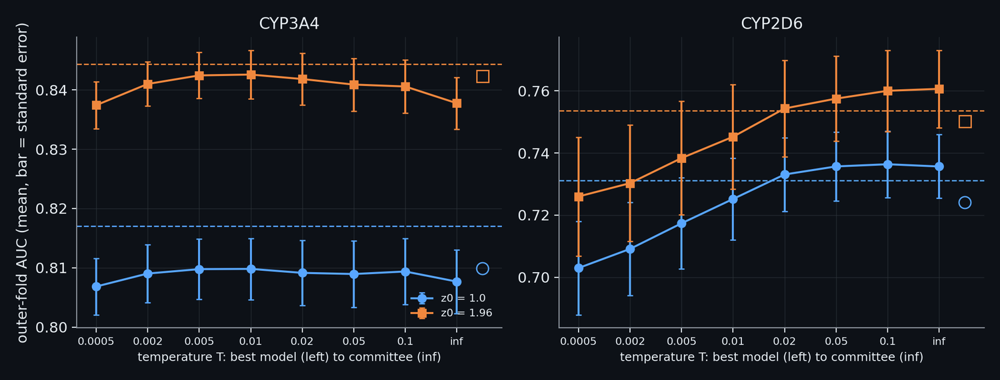

**Figure: From the best model to a committee: the exploration-exploitation dial of the blend.** The outer-fold AUC of a softmax blend of the cached candidates of the default stack as the temperature T moves from the best single model (T small, exploitation) to an equal-weight committee (T large, exploration); the dashed line is the logistic blend that the final stack uses, the open marker the blend whose T is chosen by an inner cross-validation. CYP3A4: 0.807 at the best-model end, 0.808 at the committee end, 0.817 for the logistic blend (z0 = 1.0); CYP2D6: 0.703 at the best-model end, 0.736 at the committee end, 0.731 for the logistic blend (z0 = 1.0). On CYP3A4 the curve is flat and the learned weights are worth a little more than any point of it; on CYP2D6 it rises towards the committee, and the inner choice, which favours small T, over-trusts the best candidates. The pre-registered test of the softmax selector against the logistic blend is not met on either enzyme.

In [197]:
show_figure("ml_exploration_exploitation")

## 8.3 A reproducibility bug in the stack: a solver that stops where it happens to be

> **Field:** Software engineering · Statistics

*Where this section sits:* the blend of 8.2 is the solution of a convex problem, which has one optimum, so the same code run twice on the same data should give the same blend. It did not. This section tells how that was seen, what the cause was, and why it mattered, because it is the clearest example in the project of a defect that no test of correctness would have found and that the reproducibility checks of Part XII are built to find.

**What was seen.** The audit of the project (section 12.2) generates its report twice and compares the two byte by byte, and the report recomputes the nested results of the stack. For CYP2D6 the stack gave a nested outer AUC of 0.7527 in one process and 0.7536 in another, and an MCC of the calls of 0.191 in one and 0.204 in the other (the two pairs of values are recorded in a comment of `StackedLogit._model`). The data, the code and the seeds of the cross-validation were the same. The difference of the MCC, 0.013, is larger than most of the differences that the gates of Part IX test.

**What it was.** The solver for the penalised logistic regression, `liblinear`, is a *coordinate descent*: it improves one weight at a time with the others held fixed, sweeping over the weights until the largest improvement of a sweep is smaller than a *tolerance*. It visits the weights in a random order. The problem is convex, so every order leads to the same optimum if the descent is run long enough; but it is stopped when the improvement falls below the tolerance, and the default tolerance, $10^{-4}$, is loose enough that the point at which it stops depends on the order. All the stopping points are near the optimum, within a tolerance-sized neighbourhood, and not at it. A ranking of 750 compounds is sensitive to a neighbourhood of that size, because the compounds near the boundary of the calls are close in score and a tiny change in the weights reorders them. The random order itself came from the global random state of numpy, which differs from one process to the next, so that two processes fitted slightly different stacks.

**The fix, and a demonstration.** Two changes, both in `StackedLogit._model`: the random order is seeded (`random_state`), and the tolerance is tightened to $10^{-9}$ (`META_TOL`), with the iteration limit raised so that it can be reached (`META_MAX_ITER`). The cell reproduces the defect on the inner scores of the first outer fold of CYP2D6: it fits the same L1 blend ten times with ten different random orders, at the default tolerance and at $10^{-9}$, and compares the blends, the AUCs and the MCC of the calls.

In [198]:
# The reproducibility bug of the stack, reproduced. The solver the stack uses for its L1 and L2 penalties (liblinear) visits the coordinates of the problem in a random order, and it stops when the change falls below a
# tolerance. With the library's default tolerance, 1e-4, the point where it stops depends on that random order; the problem is convex, so with a tight tolerance every order ends at the same optimum. The cell fits the same L1 blend
# (the setting the stack chose for this fold) with ten different random orders at the default tolerance and at 1e-9, on the inner scores of the first fold of CYP2D6, and measures how much the blend and its AUC move.
from sklearn.metrics import matthews_corrcoef

from cypmode.challenge.nested import _EmpiricalCdf, call_top_fraction

plan_2d6, cache_2d6 = plan_d8, cache_d8
rep_2d6, out_2d6 = plan_2d6.outer_folds()[0]
rows_2d6, oof_2d6 = inner_oof(cache_2d6, names8, rep_2d6, out_2d6)
refit_2d6 = plan_2d6.task(rep_2d6, out_2d6, OUTER_REFIT)
y_in_2d6, y_out_2d6 = plan_2d6.labels(rows_2d6), plan_2d6.labels(refit_2d6.evaluate)
outer_2d6 = np.column_stack([cache_2d6.get(n, refit_2d6) for n in names8])
cdfs_2d6 = [_EmpiricalCdf(oof_2d6[:, j]) for j in range(len(names8))]
logit = StackedLogit._logit
design = lambda m: np.column_stack([logit(cdfs_2d6[j](m[:, j])) for j in range(m.shape[1])])
z_in, z_out = design(oof_2d6), design(outer_2d6)
bug_rows = []
for tolerance in (1e-4, 1e-9):
    coefficients, aucs, calls_mcc, calls = [], [], [], []
    for seed in range(10):
        model = liblinear_logit("l1", 0.03, tolerance, seed).fit(z_in, y_in_2d6)
        coefficients.append(model.coef_[0].copy())
        scores_out = model.decision_function(z_out)
        aucs.append(roc_auc_score(y_out_2d6, scores_out))
        called = call_top_fraction(scores_out, y_in_2d6.mean()).astype(int)
        calls.append(called)
        calls_mcc.append(matthews_corrcoef(y_out_2d6, called))
    coefficients = np.array(coefficients)
    bug_rows.append({"tolerance": f"{tolerance:g}", "outer AUC, lowest over 10 orders": min(aucs), "outer AUC, highest": max(aucs), "compounds called by some orders and not by others": int((np.array(calls).any(axis=0) & ~np.array(calls).all(axis=0)).sum()), "of the validation compounds": len(y_out_2d6),
                     "largest spread of one weight": float((coefficients.max(axis=0) - coefficients.min(axis=0)).max()), "different blends (to 6 decimals)": len({tuple(np.round(c, 6)) for c in coefficients})})
bug_table = pd.DataFrame(bug_rows)
show_table(bug_table.assign(**{"largest spread of one weight": bug_table["largest spread of one weight"].map(lambda v: f"{v:.1e}")}), floatfmt=".5f")
bug_default, bug_tight = bug_rows[0], bug_rows[1]

| tolerance | outer AUC, lowest over 10 orders | outer AUC, highest | compounds called by some orders and not by others | of the validation compounds | largest spread of one weight | different blends (to 6 decimals) |
| --- | --- | --- | --- | --- | --- | --- |
| 0.0001 | 0.54675 | 0.54701 | 0 | 299 | 7.1e-05 | 10 |
| 1e-09 | 0.54694 | 0.54694 | 0 | 299 | 8.3e-10 | 1 |

At the default tolerance the ten random orders give 10 different blends (to six decimals), with outer AUCs from 0.54675 to 0.54701, a spread of 0.00026 in one fold, and 0 of the 299 validation compounds are called positive by some of the ten blends and not by the others. At the tolerance of $10^{-9}$ there are 1 blend, the AUC no longer moves, and 0 compounds change their call. In the audit the effect was larger than here because the call rate is chosen from the inner scores of the stack and so also moves with the weights, in every one of the 15 folds. The module has two tests for this: one that two processes with different global random states fit the same stack (`test_stacked_logit_does_not_depend_on_the_global_random_state`), and one that the meta-learner reaches the same optimum whatever the solver seed (`test_the_meta_learner_reaches_the_same_optimum_whatever_the_solver_seed`), which is a regression test of the tolerance. The second is the one that would have failed on the first day.

The lesson has a general form. A randomised algorithm that is run until it is *close enough* gives an answer that depends on the random numbers it used, even when the problem has only one answer. If the answer feeds a decision that is sensitive to small changes, such as a ranking cut at a threshold, "close enough" is a statement about the decision and not only about the optimum. The remedies are to remove the randomness (seed it), to tighten the stopping rule until the answers agree to a precision below the sensitivity of the decision, and to test that two runs agree, which is what a byte-for-byte comparison of the outputs does.

*On what actually ran.* The fix is in `cypmode/challenge/nested.py` (`META_TOL`, `META_MAX_ITER`, `StackedLogit._model`, with the comment that records the two values observed), the tests in `tests/test_nested.py`, and the check that found it, the double run of the audit (`scripts/run_audit.sh`, job 900). The cell above uses the same solver with its two settings for the two tolerances.

## 8.4 Turning scores into calls: a smoothed threshold, a share of calls, and a multiple

> **Field:** Statistics · Machine learning

*Where this section sits:* the stack of 8.2 ranks the compounds, and the submission is a yes or no for each (the challenge scores the MCC of the calls, section 4.10). A ranking becomes calls once it is decided how many compounds, the highest-scoring ones, are called positive. Section 7.5 showed that the decision must be made without the labels of the compounds it is scored on, and that the MCC of a rule depends on the positive rate. This section gives the three decisions that the final model takes and tests each one.

**First decision: a threshold from a jagged curve.** The natural rule is to call positive every compound whose score exceeds a threshold, and to choose the threshold that maximises the weighted MCC (6.4) of the inner out-of-fold scores. The curve of the weighted MCC against the threshold is made of a few thousand compounds, a fifth of them positive, and for a weak ranker it is jagged: its maximum sits where the noise happens to be highest. `best_threshold` averages the curve over 40 bootstrap resamples of the compounds (the bootstrap of section 6.5, drawing compounds with replacement) before it takes the maximum, so that the threshold is the top of the average curve and not of the one sample. The cell draws both curves for the first outer fold.

| enzyme | folds in which the two maxima differ | mean change of the share called | largest change of the share called |
| --- | --- | --- | --- |
| CYP2D6 | 2 | 0.026 | 0.260 |
| CYP3A4 | 1 | 0.013 | 0.195 |

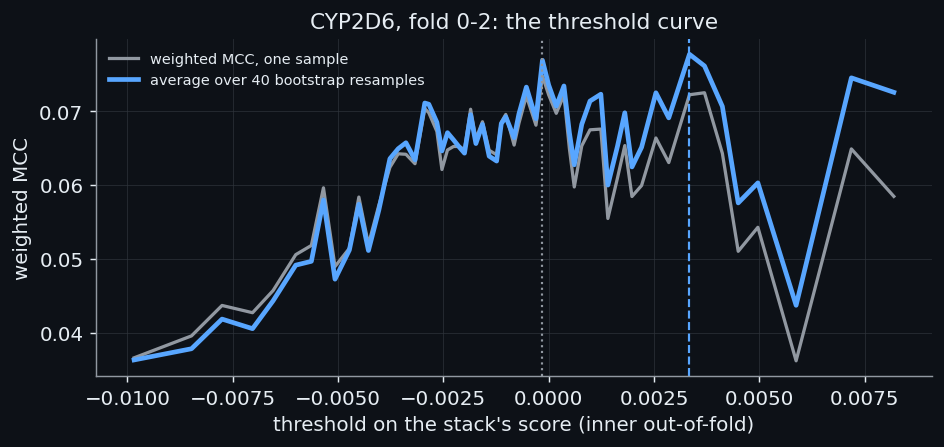

In [199]:
# Smoothing the threshold. The weighted MCC of a ranker, as a function of the threshold, is made of a few thousand compounds and can be jagged; best_threshold (cypmode/challenge/nested.py) averages the curve over 40
# bootstrap resamples of the compounds before it takes the maximum. For all 15 outer folds of both enzymes the cell computes the curve of the inner out-of-fold stack scores, raw and averaged, the threshold at the maximum of each,
# and the share of compounds each threshold calls. The figure draws the CYP2D6 fold in which the two thresholds differ most, the weak ranker for which the argument is made.
from cypmode.challenge.nested import _weights
from cypmode.challenge.validation_matching import weighted_mcc

def threshold_curves(plan_i, cache_i, matcher_i, prevalence_i, z_i, repeat, k):
    rows_i, oof_i = inner_oof(cache_i, names8, repeat, k)
    refit_i = plan_i.task(repeat, k, OUTER_REFIT)
    y_i = plan_i.labels(rows_i)
    w_i = _weights(y_i, rows_i, refit_i.train, confident_weights(matcher_i, z_i, 1.0), prevalence_i)
    meta = np.asarray(StackedLogit().fit(names8, oof_i, y_i, w_i, "auc").inner_scores)
    grid = np.unique(np.quantile(meta, np.linspace(0.02, 0.98, 60)))
    rng = np.random.default_rng(0)
    raw = np.array([weighted_mcc(y_i, (meta >= t).astype(int), w_i) for t in grid])
    boots = [np.array([weighted_mcc(y_i[ii], (meta[ii] >= t).astype(int), w_i[ii]) for t in grid]) for ii in (rng.integers(0, len(y_i), len(y_i)) for _ in range(40))]
    return meta, grid, raw, (raw + np.sum(boots, axis=0)) / (1 + len(boots))

smooth_rows, kept = [], {}
for iso, (plan_i, cache_i, matcher_i, prevalence_i, z_i) in setups8.items():
    for repeat, k in plan_i.outer_folds():
        meta, grid, raw, smooth = threshold_curves(plan_i, cache_i, matcher_i, prevalence_i, z_i, repeat, k)
        share_raw, share_smooth = float((meta >= grid[raw.argmax()]).mean()), float((meta >= grid[smooth.argmax()]).mean())
        roughness = float(np.abs(np.diff(raw)).mean() / max(np.abs(np.diff(smooth)).mean(), 1e-9))
        smooth_rows.append({"enzyme": iso, "fold": f"{repeat}-{k}", "share called at the raw maximum": share_raw, "share called at the smoothed maximum": share_smooth, "roughness ratio": roughness})
        kept[(iso, f"{repeat}-{k}")] = (grid, raw, smooth)
smooth_table = pd.DataFrame(smooth_rows)
smooth_table["difference"] = (smooth_table["share called at the raw maximum"] - smooth_table["share called at the smoothed maximum"]).abs()
smooth_summary = smooth_table.groupby("enzyme").agg(**{"folds in which the two maxima differ": ("difference", lambda v: int((v > 0).sum())), "mean change of the share called": ("difference", "mean"),
                                                         "largest change of the share called": ("difference", "max")}).reset_index()
show_table(smooth_summary, floatfmt=".3f")
worst = smooth_table[smooth_table["enzyme"] == "CYP2D6"].sort_values("difference", ascending=False).iloc[0]
grid_w, raw_w, smooth_w = kept[("CYP2D6", worst["fold"])]
fig, axis = plt.subplots(figsize=(7.4, 3.6))
axis.plot(grid_w, raw_w, color=theme["muted"], lw=1.8, label="weighted MCC, one sample")
axis.plot(grid_w, smooth_w, color=theme["blue"], lw=2.6, label="average over 40 bootstrap resamples")
axis.axvline(grid_w[raw_w.argmax()], color=theme["muted"], ls=":", lw=1.2)
axis.axvline(grid_w[smooth_w.argmax()], color=theme["blue"], ls="--", lw=1.2)
axis.set(xlabel="threshold on the stack's score (inner out-of-fold)", ylabel="weighted MCC", title=f"CYP2D6, fold {worst['fold']}: the threshold curve")
axis.legend(frameon=False, fontsize=8)
tidy(axis, theme)
fig.tight_layout()
smooth_3a4, smooth_2d6 = (smooth_summary[smooth_summary["enzyme"] == e].iloc[0] for e in ("CYP3A4", "CYP2D6"))
n_folds_total = len(smooth_table[smooth_table["enzyme"] == "CYP3A4"])

Over the 15 outer folds of each enzyme the two maxima coincide in most folds. They differ in 1 fold of CYP3A4 and in 2 of CYP2D6, and when they differ they differ a lot: the share of compounds called moves by up to 19.5% for CYP3A4 and 26.0% for CYP2D6, since the curve then has two separate peaks and one sample's maximum can sit on either of them (the mean change over all folds is 1.3% and 2.6%). The figure shows the CYP2D6 fold with the largest change. The average of the bootstrap curves picks the peak that holds up in most resamples. Smoothing cannot raise the MCC, since the averaged curve is lower than the raw maximum by construction; what it buys is a threshold, and so a call rate, that is less of an accident of the sample.

**Second decision: transfer a share of calls, not a score.** A threshold on the score is frozen on the inner scores and applied to the outer-validation compounds. The alternative freezes the *share* of compounds that the threshold calls on the inner scores and calls that share of the outer-validation compounds, the highest-scoring ones (`call_top_fraction`). The two rules would be the same if the outer scores were distributed like the inner ones, and the reason to prefer the second is that they are not, in general: validation compounds that sit closer to the training set than the inner folds did get uniformly higher scores (6.8), and a fixed threshold then calls too many. The cell tests the rules on the 15 outer folds of CYP3A4, with the yardstick of 6.4 at $z_0 = 1.0$.

In [200]:
# Two ways of turning the stack's scores into calls. The stack gives every compound a score. The classical way freezes a score threshold on the training part (the one that maximises the weighted MCC of the inner
# out-of-fold scores, smoothed over bootstrap resamples) and calls the validation compounds above it. The project's way freezes the *share* of compounds that threshold calls on the inner scores and calls that share of the
# validation compounds, the highest-scoring ones (call_top_fraction). On the 15 outer folds of the CYP3A4 plan the table gives what share of the validation compounds each rule calls, and the weighted MCC each earns
# (similarity x positive rate x confident rows at z0 = 1.0, section 6.4).
from cypmode.challenge.nested import BestSingle, best_threshold, call_top_fraction

stack_table = nested_evaluate(cache8, names8, [StackedLogit()], weights8(1.0), prevalence8, "auc")
call_summary = pd.DataFrame([{"rule": "score threshold frozen on the inner scores", "share of validation compounds called, lowest": stack_table["called_rate_threshold"].min(), "highest": stack_table["called_rate_threshold"].max(),
                              "sd over the folds": stack_table["called_rate_threshold"].std(), "mean weighted MCC": stack_table["outer_mcc"].mean()},
                             {"rule": "share of calls frozen on the inner scores (the project's)", "share of validation compounds called, lowest": stack_table["called_rate_transfer"].min(), "highest": stack_table["called_rate_transfer"].max(),
                              "sd over the folds": stack_table["called_rate_transfer"].std(), "mean weighted MCC": stack_table["outer_mcc_rate"].mean()}])
show_table(call_summary, floatfmt=".3f")
threshold_rule, rate_rule = call_summary.iloc[0], call_summary.iloc[1]
rate_vs_threshold = stack_table["outer_mcc_rate"] - stack_table["outer_mcc"]
n_rate_better = int((rate_vs_threshold > 0).sum())

| rule | share of validation compounds called, lowest | highest | sd over the folds | mean weighted MCC |
| --- | --- | --- | --- | --- |
| score threshold frozen on the inner scores | 0.285 | 0.593 | 0.088 | 0.445 |
| share of calls frozen on the inner scores (the project's) | 0.282 | 0.544 | 0.071 | 0.442 |

The frozen score threshold calls between 28.5% and 59.3% of the validation compounds from fold to fold (standard deviation 0.088), and the frozen share between 28.2% and 54.4% (0.071). The weighted MCC is 0.445 for the threshold and 0.442 for the share, and the share is better in 8 of the 15 folds. The measured result is that *inside the folds the two rules are equivalent*, which is what the argument predicts: the outer-validation compounds are drawn from the same pool as the inner ones, and their scores have the same distribution. The case for the share is the blinded set, whose compounds are known to sit closer to the training file than a fold's do.

**Third decision: how many to call.** A share of calls equal to the positive rate is not necessarily the best. If the ranking is weak, calling a few more compounds than there are positives recovers positives at a cost in false calls that the MCC tolerates. The project fixed in advance a family of rates, 1.0, 1.1, 1.2 and 1.3 times the positive rate of the scored set, and chose the member of the family with the highest mean outer-fold weighted MCC over both confidence cut-offs, the stack being refitted inside every outer fold (`choose_call_rate` in `cypmode/challenge/final_tdi_build.py`). The cell reads the tables the build wrote, with its choice.

In [201]:
# The call rate of the final model. The final build (cypmode/challenge/final_tdi_build.py) calls a share of the 750 blinded compounds equal to a multiple of the scored set's positive rate, the multiple chosen from
# {1.0, 1.1, 1.2, 1.3} by the highest mean outer-fold weighted MCC over both confidence cut-offs. The tables it wrote are read here (per-fold scores of the stack refitted inside every outer fold), with the choice it made.
import json as json_module

from cypmode.challenge.tdi_baseline import TDI_ISOFORMS

multiplier_rows, chosen_multiplier = [], {}
manifest_path = ROOT / "data/tdi_track/outputs/final/manifest.json"
manifest = json_module.loads(manifest_path.read_text())
for iso in TDI_ISOFORMS:
    table = pd.read_csv(ROOT / f"data/tdi_track/outputs/final/{iso}_call_rate_choice.csv")
    by_multiplier = table.groupby("multiplier")["mean_outer_mcc"].mean()
    for multiplier, value in by_multiplier.items():
        multiplier_rows.append({"enzyme": iso, "call rate as a multiple of the positive rate": multiplier, "mean outer MCC over both cut-offs": float(value),
                                **{f"MCC at z0 {z0}": float(table[(table["multiplier"] == multiplier) & (table["z0"] == z0)]["mean_outer_mcc"].iloc[0]) for z0 in (1.0, 1.96)}})
    chosen_multiplier[iso] = float(manifest["isoforms"][iso]["call_rate_multiplier"])
multiplier_table = pd.DataFrame(multiplier_rows)
show_table(multiplier_table, floatfmt=".4f")
prevalence_final = {iso: float(manifest["isoforms"][iso]["target_prevalence"]) for iso in TDI_ISOFORMS}
called_final = {iso: float(manifest["isoforms"][iso]["called_rate"]) for iso in TDI_ISOFORMS}
threshold_rate_final = {iso: float(manifest["isoforms"][iso]["rate_before_cap_rule"]) for iso in TDI_ISOFORMS}
multiplier_gain = {iso: float(multiplier_table[(multiplier_table["enzyme"] == iso)]["mean outer MCC over both cut-offs"].max() - multiplier_table[(multiplier_table["enzyme"] == iso) & (multiplier_table["call rate as a multiple of the positive rate"] == 1.0)]["mean outer MCC over both cut-offs"].iloc[0]) for iso in TDI_ISOFORMS}

| enzyme | call rate as a multiple of the positive rate | mean outer MCC over both cut-offs | MCC at z0 1.0 | MCC at z0 1.96 |
| --- | --- | --- | --- | --- |
| CYP3A4 | 1.0000 | 0.4989 | 0.4716 | 0.5262 |
| CYP3A4 | 1.1000 | 0.5090 | 0.4834 | 0.5347 |
| CYP3A4 | 1.2000 | 0.5093 | 0.4826 | 0.5360 |
| CYP3A4 | 1.3000 | 0.5117 | 0.4830 | 0.5405 |
| CYP2D6 | 1.0000 | 0.2118 | 0.1909 | 0.2327 |
| CYP2D6 | 1.1000 | 0.2054 | 0.1838 | 0.2270 |
| CYP2D6 | 1.2000 | 0.2023 | 0.1813 | 0.2232 |
| CYP2D6 | 1.3000 | 0.2007 | 0.1785 | 0.2228 |

For CYP3A4 the mean MCC is nearly flat over the family, from 0.4989 to 0.5117, and the rule picks the multiple 1.3, which is worth +0.0129 MCC over calling the positive rate itself. For CYP2D6 the MCC falls steadily with the multiple, from 0.2118 at 1.0 to 0.2007 at 1.3, and the rule picks 1.0. The differences are small beside the spread of the folds (0.035 for CYP3A4 and 0.13 for CYP2D6, 8.7), so the choice should be read as a pre-declared convention that is not hurt by the data and not as a finding about the optimum. It has the property that matters: it was fixed before the numbers, it is the same procedure for both enzymes, and it can be reproduced from the two tables.

The final build also shows what the second decision buys on the real thing. For CYP3A4 the rate that the inner threshold implies would have called 40.3% of the 750 blinded compounds, and for CYP2D6 8.3%, while the share that the build calls is 40.3% and 5.9%. A share of calls is a quantity the project can reason about against the scored set's positive rate (31.0% and 5.9%, section 2.10); a score threshold is not.

*On what actually ran.* `best_threshold`, `call_top_fraction` and `Selection.rate` are in `cypmode/challenge/nested.py`; `choose_call_rate`, `RATE_MULTIPLIERS` and the construction of the calls from the deployment scores are in `cypmode/challenge/final_tdi_build.py`, which writes the tables `CYP3A4_call_rate_choice.csv` and `CYP2D6_call_rate_choice.csv` into `data/tdi_track/outputs/final/`.

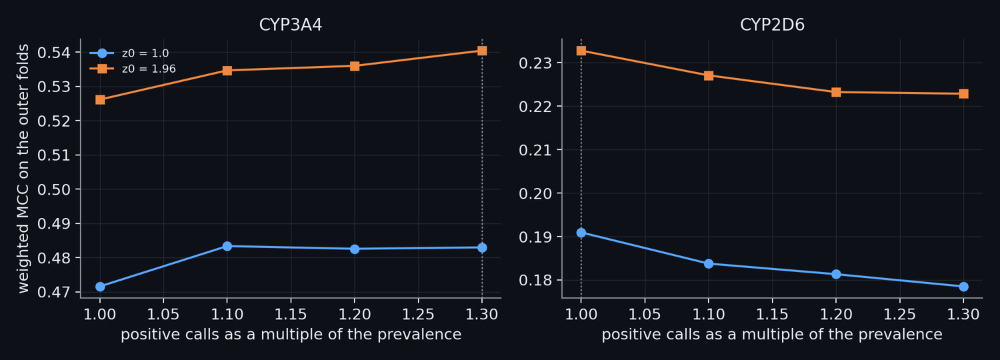

**Figure: How many compounds to call positive.** The weighted MCC on the outer folds as a function of the number of positive calls, expressed as a multiple of the scored population's prevalence, at the two confidence cuts. The call rate is chosen by the highest mean over the two cuts: CYP3A4 1.3 times the prevalence; CYP2D6 1.0 times the prevalence. The rule transfers a rate to the test file and never a score; the prevalence it multiplies is the aggregate recovered from the public board (see the previous figure and limitation L13).

In [202]:
show_figure("ml_call_rate")

## 8.5 Calibration: from a score to a probability

> **Field:** Statistics

*Where this section sits:* the calls of 8.4 need only the order of the scores. A different use of the model, abstaining on the uncertain compounds, choosing which compound to measure next, the expected-improvement selection of Part XI, needs the score to be a *probability*: when the model says 0.3, three compounds in ten should be positive. The stack does not give that, and this section is about the step that makes it so and the test that decides whether it worked. The step was declared with its gate in advance (`cypmode/challenge/calibration_experiment.py`).

**What a calibrated probability is, and how it is measured.** Put the compounds in ten equal-width bins of predicted probability. In bin $b$, let $\omega_b$ be the share of the weight (the weights of 6.4) that falls in it, $\bar p_b$ the mean predicted probability and $\bar y_b$ the weighted share of positives. A calibrated model has $\bar p_b \approx \bar y_b$ in every bin, and the **expected calibration error** is the weighted gap,

$$\mathrm{ECE} \;=\; \sum_{b=1}^{10} \omega_b\,\big|\,\bar p_b - \bar y_b\,\big|.$$

The *reliability diagram* of the cell below plots $\bar y_b$ against $\bar p_b$: a calibrated model lies on the diagonal. Two further numbers are used. The *Brier score* is the mean squared difference between the probability and the label, $\tfrac1n\sum_i (p_i - y_i)^2$, lower being better. The *calibration slope* $s$ is the coefficient of a logistic regression of the label on the log-odds of the probability, $\mathrm{logit}\,P(y=1) = a + s\,\mathrm{logit}(p)$; a calibrated model has $s = 1$ and $a = 0$, a slope below 1 means that the predictions are too extreme (over-confident), above 1 that they are too timid. The project's gate: the adopted map must reach an ECE of at most 0.05 and a slope between 0.8 and 1.2 on both enzymes; an enzyme for which no map does keeps no probability output.

**The three maps.** For every outer fold the stack is refitted, and three maps from its decision value $d$ to a probability are fitted on the *inner* out-of-fold decision values only, and then applied to the outer-validation compounds. *Raw* is the logistic function $\sigma(d)$, what the stack gives today. **Platt scaling** (Platt, 1999) fits the logistic function to the inner values, $P(y=1) = \sigma(A\,d + B)$, two numbers that stretch and shift the decision value. **Isotonic regression** (Zadrozny and Elkan, 2002) fits the monotone non-decreasing step function that is closest in squared error to the labels ordered by score, by the **pool-adjacent-violators algorithm**: walk along the compounds from the lowest score upwards, keep a block for each run, and whenever a block's mean exceeds the next block's, merge the two into one block with the weighted mean of both; what remains is a staircase that never goes down, and it is the nearest monotone fit. It has no shape to impose and needs enough data to fill its steps.

| enzyme | map | ece | brier | slope | mean_pred | mean_obs | gate met |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | raw | 0.0557 | 0.1596 | 1.2080 | 0.3598 | 0.3042 | False |
| CYP3A4 | platt | 0.0208 | 0.1555 | 1.0768 | 0.2983 | 0.3042 | True |
| CYP3A4 | isotonic | 0.0200 | 0.1560 | 0.9240 | 0.2984 | 0.3042 | True |
| CYP2D6 | raw | 0.3655 | 0.2032 | 0.0467 | 0.4071 | 0.0460 | False |
| CYP2D6 | platt | 0.0057 | 0.0426 | 1.3437 | 0.0468 | 0.0460 | False |
| CYP2D6 | isotonic | 0.0043 | 0.0415 | 0.9719 | 0.0473 | 0.0460 | True |

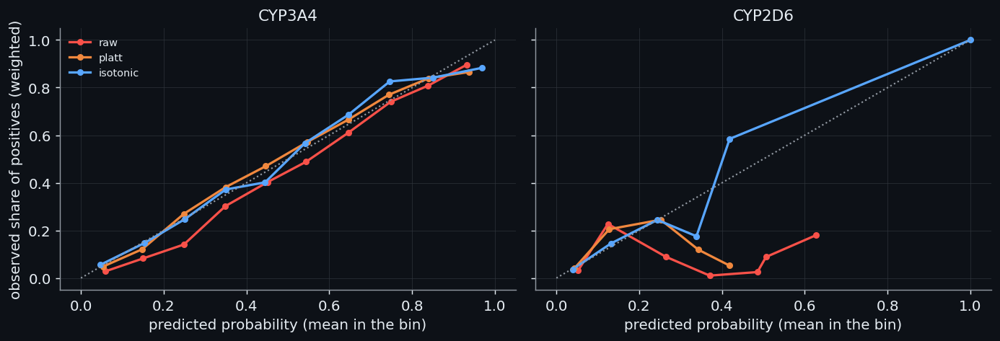

In [203]:
# Calibration, for both enzymes. For every outer fold the stack is refitted on the inner scores; three maps from its decision value to a probability are fitted on the *inner* out-of-fold decision values only and applied to
# the outer-validation compounds (cypmode/challenge/calibration_experiment.py): "raw" (the logistic function of the decision value, what the stack gives), "platt" (a one-feature logistic regression on the inner decision values) and
# "isotonic" (a monotone step function fitted on them). The pooled outer predictions of the 15 folds are scored with the same weights as the rest of the evaluation: the expected calibration error (ECE, ten equal-width bins),
# the Brier score and the calibration slope.
from cypmode.challenge.calibration_experiment import calibration_metrics, fit_calibrator
from cypmode.challenge.nested import _weights

calibration_rows, reliability_points = [], {}
for iso, (plan_i, cache_i, matcher_i, prevalence_i, z_i) in setups8.items():
    collected = {m: ([], [], []) for m in ("raw", "platt", "isotonic")}
    weight_fn = confident_weights(matcher_i, z_i, 1.0)
    for repeat, k in plan_i.outer_folds():
        rows_i, oof_i = inner_oof(cache_i, names8, repeat, k)
        refit_i = plan_i.task(repeat, k, OUTER_REFIT)
        outer_i = np.column_stack([cache_i.get(n, refit_i) for n in names8])
        y_in_i, y_out_i = plan_i.labels(rows_i), plan_i.labels(refit_i.evaluate)
        w_in_i, w_out_i = _weights(y_in_i, rows_i, refit_i.train, weight_fn, prevalence_i), _weights(y_out_i, refit_i.evaluate, refit_i.train, weight_fn, prevalence_i)
        chosen_i = StackedLogit().fit(names8, oof_i, y_in_i, w_in_i, "auc")
        for method, (ys, ps, ws) in collected.items():
            calibrator = fit_calibrator(method, np.asarray(chosen_i.inner_scores), y_in_i, w_in_i)
            ys.append(y_out_i); ps.append(np.clip(calibrator(chosen_i.predict(outer_i)), 1e-4, 1 - 1e-4)); ws.append(w_out_i)
    for method, (ys, ps, ws) in collected.items():
        y_all, p_all, w_all = np.concatenate(ys), np.concatenate(ps), np.concatenate(ws)
        metrics = calibration_metrics(y_all, p_all, w_all)
        calibration_rows.append({"enzyme": iso, "map": method, **{k: metrics[k] for k in ("ece", "brier", "slope", "mean_pred", "mean_obs")}, "gate met": bool(metrics["ece"] <= 0.05 and 0.8 <= metrics["slope"] <= 1.2)})
        reliability_points[(iso, method)] = (y_all, p_all, w_all)
calibration_table = pd.DataFrame(calibration_rows)
show_table(calibration_table, floatfmt=".4f")
fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.8), sharey=True)
for axis, iso in zip(axes, ("CYP3A4", "CYP2D6")):
    for method, colour in (("raw", theme["red"]), ("platt", theme["orange"]), ("isotonic", theme["blue"])):
        y_all, p_all, w_all = reliability_points[(iso, method)]
        index = np.minimum((p_all * 10).astype(int), 9)
        xs, ys_ = zip(*[(np.average(p_all[index == b], weights=w_all[index == b]), np.average(y_all[index == b], weights=w_all[index == b])) for b in range(10) if (index == b).any()])
        axis.plot(xs, ys_, "o-", color=colour, lw=1.8, ms=4, label=method)
    axis.plot([0, 1], [0, 1], color=theme["muted"], ls=":", lw=1.2)
    axis.set(xlabel="predicted probability (mean in the bin)", title=iso)
axes[0].set_ylabel("observed share of positives (weighted)")
axes[0].legend(frameon=False, fontsize=8)
for axis in axes:
    tidy(axis, theme)
fig.tight_layout()
def calibration_value(iso, method, column):
    return float(calibration_table[(calibration_table["enzyme"] == iso) & (calibration_table["map"] == method)][column].iloc[0])

For CYP3A4 the raw probability is close but fails the gate on this cache (ECE 0.0557, slope 1.21; the record of the day, on an earlier state of the cache, had it just inside), and the mean predicted probability, 0.360, overshoots the observed share, 0.304. Platt scaling and isotonic regression both pass: ECE 0.0208 and 0.0200, slopes 1.08 and 0.92. For CYP2D6 the raw output is not a probability at all: the mean predicted probability is 0.407 where 0.046 of the compounds are positive, the ECE is 0.366 and the slope 0.05, a line that does not rise (the audit found it: for 80 percent of the compounds the stack's probability was between 0.49 and 0.50; a heavily penalised blend ranks without producing probabilities). Platt scaling brings the ECE to 0.0057 but with a slope of 1.34, outside the gate, because its straight line in the log-odds cannot follow a relation that bends; isotonic regression reaches an ECE of 0.0043 and a slope of 0.97 and is the only map that passes for both enzymes. It is the one the build uses.

The step-function map is simple enough to write out. The cell below codes the pool-adjacent-violators algorithm in a dozen lines and checks it against scikit-learn's `IsotonicRegression` on the inner out-of-fold decision values of the first outer fold of CYP3A4.

In [204]:
# Isotonic regression by hand. The pool-adjacent-violators algorithm (PAV) fits the monotone non-decreasing step function that is closest, in squared error, to a set of labels ordered by score: walk along the
# compounds from the lowest score up, keep a block for each run of compounds, and whenever a block's mean is higher than the next block's, merge the two into one block with the weighted mean of both. What remains is a
# staircase that never goes down. The cell codes it in a dozen lines and checks it against scikit-learn's IsotonicRegression on the inner out-of-fold decision values of the first outer fold of CYP3A4.
def pool_adjacent_violators(y, weights):
    blocks = []                                   # each block: [weighted sum of y, total weight, number of compounds]
    for value, weight in zip(y, weights):
        blocks.append([value * weight, weight, 1])
        while len(blocks) > 1 and blocks[-2][0] / blocks[-2][1] > blocks[-1][0] / blocks[-1][1]:
            last = blocks.pop()
            blocks[-1] = [blocks[-1][0] + last[0], blocks[-1][1] + last[1], blocks[-1][2] + last[2]]
    return np.concatenate([np.full(count, total / weight) for total, weight, count in blocks])

from sklearn.isotonic import IsotonicRegression

repeat_p, outer_p = plan8.outer_folds()[0]
rows_p, oof_p = inner_oof(cache8, names8, repeat_p, outer_p)
y_p = plan8.labels(rows_p)
meta_p = np.asarray(StackedLogit().fit(names8, oof_p, y_p, None, "auc").inner_scores)
order = np.argsort(meta_p, kind="stable")
by_hand = pool_adjacent_violators(y_p[order].astype(float), np.ones(len(order)))
library = IsotonicRegression().fit(meta_p[order], y_p[order].astype(float)).predict(meta_p[order])
pav_difference = float(np.abs(by_hand - library).max())
pav_blocks = len(np.unique(np.round(by_hand, 12)))
print(f"largest difference between the algorithm written here and the library: {pav_difference:.1e}; the staircase has {pav_blocks} steps for {len(order):,} compounds")

largest difference between the algorithm written here and the library: 1.1e-16; the staircase has 19 steps for 1,867 compounds


The algorithm written here and the library agree to 1e-16. The staircase has 19 steps for 1,867 compounds: the data allow only that many distinct levels, which is also the limit of the map, a probability resolved no finer than its steps. The final build writes the isotonic probability next to the score and the call of each blinded compound in its private score tables (`probability_isotonic`), where a probability-based use can read it; a boolean submission cannot carry it.

*On what actually ran.* `fit_calibrator` and `calibration_metrics` in `cypmode/challenge/calibration_experiment.py` (the run of the module is stored in the log `calibration.log`, which the notebook does not read: the numbers above are recomputed), `calibrated_probabilities` in `final_tdi_build.py` (the isotonic map fitted on the inner out-of-fold stack scores of the whole pool, applied to the blinded compounds' scores), and `sklearn.isotonic.IsotonicRegression` for the library check.

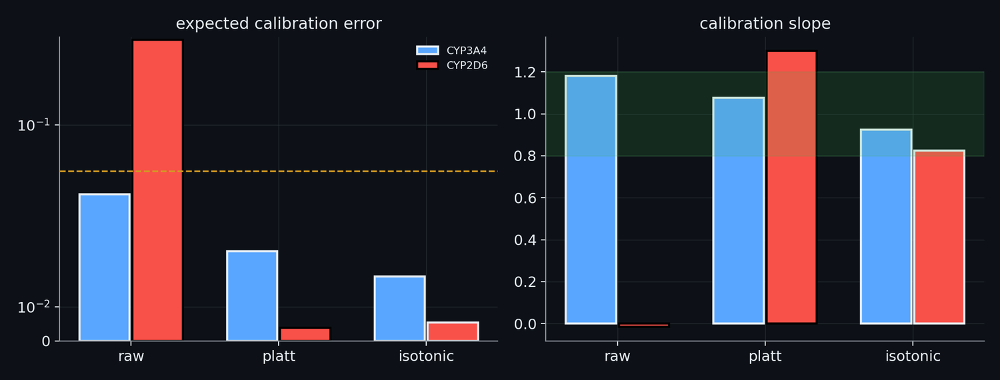

**Figure: Raw, Platt and isotonic calibration.** How well the output of the stack can be read as a probability, for the three ways of turning a score into one (the raw output, Platt scaling and isotonic regression), measured on held-out folds. Left: the expected calibration error (the gap between the predicted and the observed rate of positives, binned); right: the calibration slope, which is 1 when a predicted probability of 0.3 means that 30% are positive. The gate asks for an error of at most 0.05 and a slope in [0.8, 1.2]; a method that meets it is filled. CYP3A4: raw ECE 0.043 slope 1.18, platt ECE 0.026 slope 1.08, isotonic ECE 0.019 slope 0.93; CYP2D6: raw ECE 0.359 slope -0.02, platt ECE 0.004 slope 1.30, isotonic ECE 0.005 slope 0.82. The raw CYP2D6 output is not a probability at all, and isotonic regression is the method that meets the gate for both enzymes, which is why the published probabilities pass through it.

In [205]:
show_figure("ml_calibration_methods")

## 8.6 The candidate files, the checks they pass, and the manifest

> **Field:** Software engineering · Data science

*Where this section sits:* a model is useful to the challenge only as a file of 750 rows. The final build turns the stack and the call rule into files and records everything about how they were made, in a form that a reader can check. It never uploads anything. This section lists what it writes, what is checked, and what the record contains.

**What is written** (to `data/tdi_track/outputs/final/`). There are two candidate files for the A/B plan of the project (section 13.4 gives the rule that chooses the final one). Candidate A is the stack of this part for both enzymes (the "hits-only" stack: trained on the compounds that were promoted to dose-response). Candidate B is the same for CYP3A4 and, for CYP2D6, the selection-aware stack on the panel pool that section 9.1 describes. Beside the candidates, one table per enzyme holds the scores, the calls, the isotonic probabilities and the committee disagreement of each blinded compound (private until the challenge closes), a table with the evidence for the stack choice (`*_stack_choice.csv`), the call-rate table of 8.4, `manifest.json` and a report. The manifest is a machine-readable record: the environment (the versions of Python and of every library whose version could change a number), the seeds and the design, the verdict of every gate that was read, the nested numbers, the call rates, the weights of the stack, the audit of leakage, and, for each file, its number of rows and its **SHA-256**, a fingerprint of the file's bytes (explained below).

**What a hash is, and why it is there.** The SHA-256 of a file is a number of 256 bits, written as 64 hexadecimal digits, computed from the bytes of the file in such a way that changing any byte changes the number in an unpredictable way and no one can construct a different file with the same number. A hash recorded in the manifest when the file was written, and recomputed from the file as it lies on the disk now, proves that the file submitted is the file the build wrote. The cell recomputes the hashes, applies the portal's schema check as the project reimplements it (`portal_validate_classification` in `cypmode/challenge/submission.py`: the file is a CSV or a parquet, has exactly 750 rows and the identifier columns and both endpoint columns, no empty values, only binary calls, and each endpoint has both classes, since a constant prediction cannot be scored), and shows the three checks of the leakage audit.

In [206]:
# The candidate files and what is checked about them (cypmode/challenge/final_tdi_build.py, written to data/tdi_track/outputs/final/). For each file: the hash recorded in the manifest against the hash of the file on disk now,
# the portal's own schema check as the project reimplements it (cypmode/challenge/submission.py: the file has the four columns, 750 rows, binary calls, and both enzymes have both classes), and the positive rates.
# The per-compound columns of the files are not shown: they are not public before the challenge closes.
import hashlib

from cypmode.challenge.submission import portal_validate_classification, validate_submission

file_rows = []
for entry in manifest["files"]:
    path = ROOT / "data/tdi_track/outputs/final" / entry["file"]
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    ok, message = portal_validate_classification(path)
    frame = pd.read_csv(path)
    file_rows.append({"file": entry["file"], "rows": len(frame), "sha256 matches the manifest": digest == entry["sha256"], "portal check": "passes" if ok else f"fails: {message}", "CYP3A4 positive rate": float(frame["CYP3A4_is_TDI"].mean()),
                      "CYP2D6 positive rate": float(frame["CYP2D6_is_TDI"].mean()), "sha256 (first 12)": digest[:12]})
file_table = pd.DataFrame(file_rows)
show_table(file_table, floatfmt=".4f")
audit_rows = [{"enzyme": iso, "check": check, "passes": bool(passed)} for iso in TDI_ISOFORMS for check, passed in manifest["isoforms"][iso]["leakage_audit"].items()]
show_table(pd.DataFrame(audit_rows))
environment_line = ", ".join(f"{k} {v}" for k, v in manifest["environment"].items() if k in ("python", "numpy", "scikit-learn", "lightgbm", "rdkit"))
all_hashes_match, all_portal_ok, all_audit_ok = bool(file_table["sha256 matches the manifest"].all()), bool((file_table["portal check"] == "passes").all()), bool(pd.DataFrame(audit_rows)["passes"].all())

| file | rows | sha256 matches the manifest | portal check | CYP3A4 positive rate | CYP2D6 positive rate | sha256 (first 12) |
| --- | --- | --- | --- | --- | --- | --- |
| candidate_A_hits_only.csv | 750 | True | passes | 0.4027 | 0.0587 | 4776089ea443 |
| candidate_B_selection_aware.csv | 750 | True | passes | 0.4027 | 0.0587 | 2d51eea29ec5 |

| enzyme | check | passes |
| --- | --- | --- |
| CYP3A4 | external rows are exactly the test file rows | True |
| CYP3A4 | no test row in the labelled pool | True |
| CYP3A4 | no label stored for any test row | True |
| CYP2D6 | external rows are exactly the test file rows | True |
| CYP2D6 | no test row in the labelled pool | True |
| CYP2D6 | no label stored for any test row | True |

The hashes of the 2 files match the manifest (True); the portal check passes for every file (True); the leakage audit passes for both enzymes (True). The audit is three assertions that the build makes before it fits anything and that stop the build if one fails: the external rows are exactly the rows of the test file, no test row is in the labelled pool, and no label is stored for any test row. They guard the one way in which this kind of project can fool itself without noticing, a blinded compound whose label, or something computed from its label, reached the fit. The positive rates of the candidates are 40.3% for CYP3A4 and 5.9% for CYP2D6, the calls of 8.4. The environment recorded is python 3.13.13, numpy 2.5.3, scikit-learn 1.9.1, lightgbm 4.7.0, rdkit 2026.03.6. The files are written by `cypmode/challenge/final_tdi_build.py`, which also writes the report `final_report.md`; the files that would be uploaded are copied from there to `submissions/tdi_track/` by `cypmode/challenge/submissions_sync.py`, and the pre-submission check of the audit (section 12.5) compares them with the final outputs byte for byte. The audit report itself is generated twice and compared (job 900, section 12.2), which is how the defect of 8.3 was found.

*On what actually ran.* `cypmode/challenge/final_tdi_build.py` (the build; `parse_gates` reads the verdicts, `choose_stack` applies the eligibility rule of its docstring, `leakage_audit`, `file_hash`, `environment`), `cypmode/challenge/submission.py` (`validate_submission`, `portal_validate_classification`, `build_submission`), and `cypmode/challenge/submissions_sync.py`. The per-compound columns of the files are not read or shown by the notebook.

## 8.7 Results with their uncertainty

> **Field:** Statistics

*Where this section sits:* this is the number the project can give for its model before the challenge closes. It is an estimate made on the training data, with the nested procedure of Part VI, under the yardstick of 6.4. It is not a forecast of the score on the board. The cell computes, for each enzyme and each confidence cut-off, the AUC and the MCC of the stack on the 15 outer folds, with their spread and the 95 percent interval from the corrected resampled t of 6.5, whose standard error $s\sqrt{1/J + n_{\text{test}}/n_{\text{train}}}$ is wider than the naive one, and then asks whether the stack is better than two simpler alternatives in the same folds: the member that a user would have picked on the inner scores, and the plain LightGBM on the descriptors, the member closest to the organisers' baseline.

In [207]:
# The nested estimate of the final stack, with its spread. For each enzyme and each cut-off z0, the 15 outer-fold scores of the stack that the final build uses (the stack named in the manifest, evaluated with the weights of 6.4):
# the AUC and the MCC at the transferred call rate. The mean, the standard deviation over the folds, and the 95 % interval from the corrected resampled t (section 6.5), whose standard error is s * sqrt(1/J + n_test/n_train)
# and is therefore wider than the naive one. The numbers of the manifest (the build that wrote the candidate files) are set beside them.
from scipy import stats

from cypmode.challenge.model_comparison import corrected_resampled_t, plan_sizes

result_rows = []
for iso, (plan_i, cache_i, matcher_i, prevalence_i, z_i) in setups8.items():
    stack_names = [c.name for c in default_candidates() if not cache_i.missing(c.name, False)]
    n_train_i, n_test_i = plan_sizes(plan_i)
    for z0 in (1.0, 1.96):
        table = nested_evaluate(cache_i, stack_names, [StackedLogit()], confident_weights(matcher_i, z_i, z0), prevalence_i, "auc")
        for metric_name, column in (("AUC", "outer_score"), ("MCC at the transferred rate", "outer_mcc_rate")):
            values = table[column].to_numpy()
            standard_error = float(values.std(ddof=1) * np.sqrt(1 / len(values) + n_test_i / n_train_i))
            half = float(stats.t.ppf(0.975, len(values) - 1) * standard_error)
            result_rows.append({"enzyme": iso, "z0": z0, "score": metric_name, "mean over 15 folds": float(values.mean()), "sd over the folds": float(values.std(ddof=1)), "95 % interval": f"{values.mean() - half:.3f} to {values.mean() + half:.3f}", "members": len(stack_names)})
result_table = pd.DataFrame(result_rows)
show_table(result_table, floatfmt=".3f")
# Is the blend better than the alternatives, in the same folds? The paired difference of the outer AUC, fold by fold, between the stack and (a) the member that the BestSingle selector picks on the inner scores, (b) the
# plain LightGBM on the descriptors alone, the closest member to the organisers' baseline; the corrected resampled t of 6.5 with the sizes of the plan.
comparison_rows = []
for iso, (plan_i, cache_i, matcher_i, prevalence_i, z_i) in setups8.items():
    stack_names = [c.name for c in default_candidates() if not cache_i.missing(c.name, False)]
    n_train_i, n_test_i = plan_sizes(plan_i)
    for z0 in (1.0, 1.96):
        weight_fn = confident_weights(matcher_i, z_i, z0)
        both = nested_evaluate(cache_i, stack_names, [StackedLogit(), BestSingle()], weight_fn, prevalence_i, "auc")
        stack_auc = both[both["selector"] == "stack_logit"].set_index(["repeat", "outer"])["outer_score"]
        best_auc = both[both["selector"] == "best_single"].set_index(["repeat", "outer"])["outer_score"]
        desc = nested_evaluate(cache_i, ["lgbm_desc_deep"], [BestSingle()], weight_fn, prevalence_i, "auc").set_index(["repeat", "outer"])["outer_score"]
        for label, other in (("the member picked on the inner scores", best_auc), ("LightGBM on the descriptors alone", desc)):
            result = corrected_resampled_t((stack_auc - other).to_numpy(), n_train_i, n_test_i)
            comparison_rows.append({"enzyme": iso, "z0": z0, "stack against": label, "AUC of the stack": float(stack_auc.mean()), "AUC of the other": float(other.mean()), "gain": result.mean_difference, "folds in which the stack is better": f"{result.n_better} of {result.n_folds}", "p (corrected t)": result.p_value})
comparison_table = pd.DataFrame(comparison_rows)
show_table(comparison_table, floatfmt=".3f")
n_best_significant = int(((comparison_table["stack against"] == "the member picked on the inner scores") & (comparison_table["p (corrected t)"] < 0.05)).sum())
def result_value(iso, z0, score, column="mean over 15 folds"):
    return float(result_table[(result_table["enzyme"] == iso) & (result_table["z0"] == z0) & (result_table["score"] == score)][column].iloc[0])
final_stack_names = {iso: manifest["isoforms"][iso]["stack"] for iso in TDI_ISOFORMS}
n_members_final = {iso: int(manifest["isoforms"][iso]["n_candidates"]) for iso in TDI_ISOFORMS}

| enzyme | z0 | score | mean over 15 folds | sd over the folds | 95 % interval | members |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 1.000 | AUC | 0.817 | 0.017 | 0.796 to 0.838 | 23 |
| CYP3A4 | 1.000 | MCC at the transferred rate | 0.442 | 0.035 | 0.399 to 0.484 | 23 |
| CYP3A4 | 1.960 | AUC | 0.844 | 0.017 | 0.824 to 0.865 | 23 |
| CYP3A4 | 1.960 | MCC at the transferred rate | 0.487 | 0.046 | 0.431 to 0.543 | 23 |
| CYP2D6 | 1.000 | AUC | 0.731 | 0.052 | 0.668 to 0.794 | 23 |
| CYP2D6 | 1.000 | MCC at the transferred rate | 0.167 | 0.125 | 0.017 to 0.318 | 23 |
| CYP2D6 | 1.960 | AUC | 0.754 | 0.066 | 0.674 to 0.834 | 23 |
| CYP2D6 | 1.960 | MCC at the transferred rate | 0.204 | 0.133 | 0.044 to 0.364 | 23 |

| enzyme | z0 | stack against | AUC of the stack | AUC of the other | gain | folds in which the stack is better | p (corrected t) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 1.000 | the member picked on the inner scores | 0.817 | 0.805 | 0.012 | 13 of 15 | 0.097 |
| CYP3A4 | 1.000 | LightGBM on the descriptors alone | 0.817 | 0.767 | 0.050 | 15 of 15 | 0.000 |
| CYP3A4 | 1.960 | the member picked on the inner scores | 0.844 | 0.836 | 0.008 | 13 of 15 | 0.133 |
| CYP3A4 | 1.960 | LightGBM on the descriptors alone | 0.844 | 0.801 | 0.043 | 15 of 15 | 0.002 |
| CYP2D6 | 1.000 | the member picked on the inner scores | 0.731 | 0.702 | 0.029 | 13 of 15 | 0.217 |
| CYP2D6 | 1.000 | LightGBM on the descriptors alone | 0.731 | 0.664 | 0.067 | 14 of 15 | 0.062 |
| CYP2D6 | 1.960 | the member picked on the inner scores | 0.754 | 0.725 | 0.028 | 13 of 15 | 0.189 |
| CYP2D6 | 1.960 | LightGBM on the descriptors alone | 0.754 | 0.698 | 0.055 | 13 of 15 | 0.191 |

In [208]:
# The applicability domain of the final stack (cypmode/challenge/applicability_domain.py, queue job 096): where the model interpolates, measured on the outer folds of the nested validation. Each held-out compound
# gets its nearest-training similarity (ECFP4 Tanimoto) to the rows its fold was trained on; the held-out compounds are cut into similarity bins, each bin gets an AUC with a 95 percent interval whose bootstrap
# resamples whole chemical series (Butina clusters, so that series are not counted as independent observations), and each of the 750 blinded compounds is given the tier of the bin it falls in. No model is refitted.
# The cell reads the two tables the module wrote and counts the tiers of the blinded compounds.
applicability_compounds = pd.read_csv(ROOT / "data/tdi_track/outputs/final/applicability_domain_compounds.csv")
applicability_bins = pd.read_csv(ROOT / "data/tdi_track/outputs/final/applicability_domain_bins.csv")
applicability_rows = []
for iso in TDI_ISOFORMS:
    applicability_tiers = applicability_compounds[f"{iso}_domain_tier"].value_counts()
    applicability_similarity = applicability_compounds[f"{iso}_nearest_training_similarity"]
    applicability_bin_rows = applicability_bins[(applicability_bins["isoform"] == iso) & (applicability_bins["z0"] == 1.0)].dropna(subset=["auc"])
    applicability_rows.append({"enzyme": iso, "supported": int(applicability_tiers.get("supported", 0)), "weak": int(applicability_tiers.get("weak", 0)), "unsupported": int(applicability_tiers.get("unsupported", 0)),
                               "median nearest-training similarity": float(applicability_similarity.median()), "share at or above 0.5": float((applicability_similarity >= 0.5).mean()),
                               "lowest bin AUC": float(applicability_bin_rows["auc"].min()), "highest bin AUC": float(applicability_bin_rows["auc"].max()),
                               "lowest bin interval, lower end": float(applicability_bin_rows["auc_low"].min())})
applicability_table = pd.DataFrame(applicability_rows)
show_table(applicability_table, floatfmt=".3f")
n_blinded_compounds = len(applicability_compounds)
n_supported = {row["enzyme"]: row["supported"] for row in applicability_rows}
n_weak = {row["enzyme"]: row["weak"] for row in applicability_rows}
n_unsupported = {row["enzyme"]: row["unsupported"] for row in applicability_rows}
median_similarity = {row["enzyme"]: row["median nearest-training similarity"] for row in applicability_rows}
share_above_half = {row["enzyme"]: row["share at or above 0.5"] for row in applicability_rows}
lowest_auc = {row["enzyme"]: row["lowest bin AUC"] for row in applicability_rows}
highest_auc = {row["enzyme"]: row["highest bin AUC"] for row in applicability_rows}
n_bins = {iso: int(len(applicability_bins[(applicability_bins["isoform"] == iso) & (applicability_bins["z0"] == 1.0)])) for iso in TDI_ISOFORMS}
n_supported_bins = {iso: int((applicability_bins[(applicability_bins["isoform"] == iso) & (applicability_bins["z0"] == 1.0)]["tier"] == "supported").sum()) for iso in TDI_ISOFORMS}
assert not applicability_table.isna().any().any()
assert sum(n_supported.values()) + sum(n_weak.values()) + sum(n_unsupported.values()) == 2 * n_blinded_compounds

| enzyme | supported | weak | unsupported | median nearest-training similarity | share at or above 0.5 | lowest bin AUC | highest bin AUC | lowest bin interval, lower end |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 750 | 0 | 0 | 0.538 | 0.643 | 0.783 | 0.887 | 0.709 |
| CYP2D6 | 0 | 599 | 151 | 0.471 | 0.475 | 0.527 | 0.714 | 0.474 |

For CYP3A4 the stack earns an AUC of 0.817 at $z_0 = 1.0$ (95 percent interval 0.796 to 0.838) and 0.844 at $z_0 = 1.96$, and an MCC of 0.442 and 0.487 (intervals 0.399 to 0.484 and 0.431 to 0.543). For CYP2D6 the AUC is 0.731 and 0.754 and the MCC 0.167 and 0.204, with intervals (0.017 to 0.318 for the first) that are as wide as the effect: the standard deviation of the CYP2D6 MCC over the folds is 0.12, 3.6 times that of CYP3A4. The enzyme remains the hard one of the challenge; the model separates its time-dependent inhibitors from the rest by an AUC of about 0.73 to 0.75, and a call rate of 5.9% of the compounds turns that into an MCC whose interval comes close to zero. The two cut-offs differ in the way 6.4 predicted: the stricter one removes the compounds whose label is a coin flip and every number rises, because the yardstick is cleaner and not because the model is better.

Is the blend better than the simpler things? The second table answers, fold by fold. Over the 15 folds the stack beats LightGBM on the descriptors alone by +0.050 AUC on CYP3A4 (corrected p = 0.0004) and by +0.067 on CYP2D6 (p = 0.062). Against the member that a user would have picked on the inner scores the gain is +0.012 for CYP3A4 (p = 0.097) and +0.029 for CYP2D6 (p = 0.217), at $z_0 = 1.0$; the table gives the other cut-off. The stack is clearly better than the baseline-like member for CYP3A4 and better by a similar amount, but with an interval that includes zero, for CYP2D6; against the member picked on the inner scores its gain is of the size that the folds cannot confirm (the gain over the member picked on the inner scores reaches p < 0.05 in 0 of the 4 combinations of enzyme and cut-off). The blend is therefore not shown to beat the best single member. Its case is the one of 6.2: that member is itself the result of a choice made on the scores of the folds, so its own estimate is flattered, and the stack, which chooses by a cross-validation of the blend inside the training part, pays that cost in its estimate and is at least as good. These are the comparisons that the first models of Part VII could not make, and they are made with the design of Part VI.

What the number is, and is not. It is the expected quality of the procedure on compounds like the pool, weighted to look like the blinded set and scored where the labels are not coin flips. It is not the board: the baseline of 7.1 earned 0.065 and 0.097 MCC more on the board than the cross-validation said, for reasons that Part VI listed and that this yardstick narrows and does not close. The final stack of the build named in the manifest is `default+all_survivors` for CYP3A4 and `default` for CYP2D6, with 28 and 23 members; if a group of Part IX or X passes its gate, the build says so here, and the numbers above move to those of the new stack. At the time the notebook was built they are the numbers of the default stack evaluated in the cell, which are also the numbers of the build's own report.

**Where the number can be trusted.** An average over the pool is not a promise for every compound: a model is most reliable where it interpolates between compounds it has seen. The final build is therefore accompanied by a measurement of that, `cypmode/challenge/applicability_domain.py` (queue job 096), which refits nothing: it rebuilds the final stack of each enzyme from the cached predictions exactly as the build does, applies it to the held-out rows of every outer fold, gives each held-out compound its nearest-training similarity to the rows its fold was trained on (ECFP4 **Tanimoto similarity**), cuts the held-out compounds into similarity bins and gives each bin an AUC with a 95 percent interval whose bootstrap resamples whole Butina clusters rather than single compounds, because the compounds of one chemical series are not independent observations. The bin that a blinded compound falls in gives it a tier: supported when the lower end of the bin's interval reaches the threshold the module declares, weak when the bin holds enough compounds but a lower end below it, and unsupported when the bin holds too few held-out compounds to be trusted. Of the 6 similarity bins at the first confidence cut-off 6 are supported for CYP3A4 and 0 for CYP2D6; of the 750 blinded compounds, 750 fall in a supported bin for CYP3A4 and 0 for CYP2D6 (599 weak and 151 unsupported). The median nearest-training similarity of the blinded compounds is 0.54 for CYP3A4 and 0.47 for CYP2D6, and 64% and 47% of them are at a similarity of 0.5 or more. The AUC of a held-out bin at the first cut-off runs from 0.78 to 0.89 over the bins of CYP3A4 and from 0.53 to 0.71 over those of CYP2D6. The module's own reading, in its docstring, is that absolute cross-validation numbers are not forecasts of the leaderboard and the table is read by its shape across bins; the shape here is that the final CYP3A4 stack is supported on every bin and every blinded compound, and that the final CYP2D6 stack, the weaker ranker, is useful where the nearest training compound is at least moderately similar and is not supported anywhere at the first cut-off.

*On what actually ran.* `nested_evaluate` with `StackedLogit` and `BestSingle` (`cypmode/challenge/nested.py`), the weights of `confident_weights` and `SimilarityMatcher`, `corrected_resampled_t` and `plan_sizes` (`model_comparison.py`); the report of the build, `final_report.md`, holds the same AUC and MCC. The last cell reads `applicability_domain_compounds.csv` and `applicability_domain_bins.csv` from `data/tdi_track/outputs/final/`, written by `cypmode/challenge/applicability_domain.py` in queue job 096.

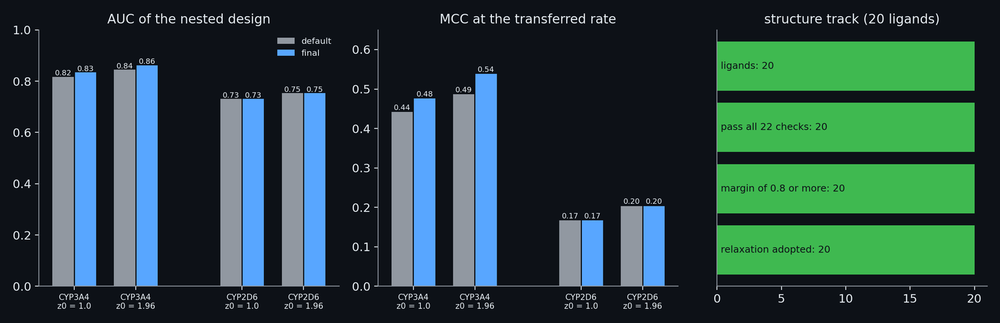

**Figure: The final results on one page.** The results of the project on one page, all of them estimates on the training data and none a score on the hidden labels. Left and middle: the nested cross-validated AUC and MCC of the final stack of each enzyme next to the default stack, at the two confidence cuts of the labels (the MCC is at the rate transferred from the scored prevalence). CYP3A4: AUC 0.834 and MCC 0.476 at z0 = 1.0 (0.862 and 0.539 at z0 = 1.96), against 0.817 and 0.442 for the default stack; CYP2D6: AUC 0.731 and MCC 0.167 at z0 = 1.0 (0.754 and 0.204 at z0 = 1.96), against 0.731 and 0.167 for the default stack. Right: the structure track in numbers, 20 ligands, 20 poses passing all 22 PoseBusters checks and 20 with a margin of 0.8 or more, the relaxation adopted for 20 of 20 poses.

In [209]:
show_figure("arch_final_results")

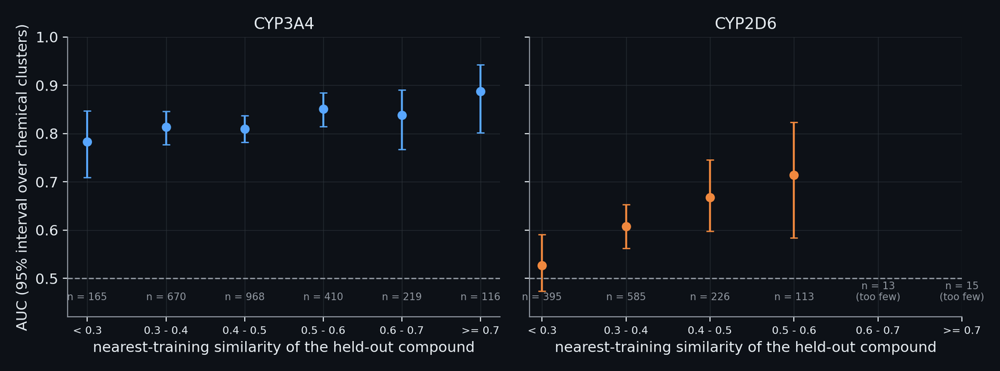

**Figure: Where the final stack can be trusted: reliability by similarity.** How well the final stack ranks, by the similarity of each held-out compound to the rows its fold was trained on (ECFP4 Tanimoto), measured on the outer folds of the nested validation at the first confidence cut: AUC with its 95% interval from a bootstrap over chemical clusters. A bin is supported when the lower end of its interval is above 0.5. The blinded compounds fall in these tiers: CYP3A4: 750 supported; CYP2D6: 599 weak, 151 unsupported. CYP3A4 is supported everywhere; CYP2D6 ranks usefully only where the nearest training compound is at least moderately similar.

In [210]:
show_figure("ml_applicability_domain")

# Part IX. Additions that were tested

Part VIII described the default stack. This part describes what was proposed to be added to it, and what happened to each proposal. Every section has the same parts: the idea and where it came from, the exact construction with every formula built up, the gate written down before the result existed (6.7), the result alone and inside the stack with its corrected p-values, and the reason the idea did or did not help. The ideas are of two kinds. Some change *what the model is asked to predict* (the population of the scored set, the hidden structure of the label, the noise of the measurements); some change *what the model is given* (the structure of the neighbours, a pretrained representation, the other enzymes' measurements). None of them is a variation of a hyperparameter: each is a hypothesis about the data with a mechanism behind it.

The sections are in the order in which the ideas arose. Section 9.1 is the longest, because its idea has the longest chain of reasoning and because it is the one the numbers alone cannot decide. Sections 9.2 to 9.8 each take one idea from a family; 9.9 the neural networks of the last queue; 9.10 the other late additions; 9.11 the ledger of all the gates, read from the logs.

## 9.1 The selection-aware CYP2D6 model: when the training labels come from a filtered population

> **Field:** Statistics · Machine learning

*Where this section sits:* the stack of Part VIII is trained and scored on the compounds that have a TDI label. This section asks whether those compounds are the population the challenge scores, finds that for CYP2D6 they are not, builds a model for the population that is, and then meets the difficulty that decides the section: how much of the scored population is of the other kind cannot be measured, only estimated. The estimate, the model and the decision it leaves open are all described here.

**The observation.** The screen that produced the training file tested compounds at one concentration first, and *promoted* those that looked active on an enzyme to a full dose-response measurement. The TDI label (section 2.3) exists only for a compound that was promoted on that enzyme; a compound that was screened and not promoted has no TDI measurement. The scored set was built differently: it is a full dose-response panel of analogues of hits found on *other* enzymes, and the challenge scores a compound that was measured as inactive as "assigned negative". So the CYP2D6 compounds of the scored set are mostly of a kind that the training labels do not contain: *non-hits*. For CYP3A4 the scored set is made of analogues of CYP3A4 hits, the labelled compounds are the right population, and CYP3A4 serves as a control on which no gain is expected. The first cell counts what the difference does to the positive rate.

In [211]:
# Reading the verdicts. Every experiment of this part writes a log whose lines have the same form (cypmode/challenge/addition_experiment.py): for each confidence cut-off z0, the stacked comparison of the default stack plus the
# addition against the default stack, and for the additions that have a plain counterpart the comparison alone; and a last line, "GATE (...): MET" or "NOT MET". The functions below read them, so that each section can show the
# numbers of its experiment as a table and no number is typed into the text.
import re
from pathlib import Path

import numpy as np
import pandas as pd

LOGS9 = ROOT / "data/structure_track/outputs/cyp3a4/logs"
ALONE_LINE = re.compile(r"z0=(\d\.\d+)\s+alone\s+(\S+)\s+vs (\S+)\s*: AUC ([\d.]+) -> ([\d.]+) \(([+-][\d.]+), p=([\d.]+), better (\d+)/(\d+)\)")
STACKED_LINE = re.compile(r"z0=(\d\.\d+)\s+stacked base\+added vs base: AUC ([+-][\d.]+) \(p=([\d.]+), better (\d+)/(\d+)\)")
GATE_LINE = re.compile(r"^(CYP\w+) GATE \((alone|stacked)[^)]*\): (MET|NOT MET)", re.M)
DIAG_LINE = re.compile(r"z0=(\d\.\d+)\s+diagnostic (\S+): outer AUC ([\d.]+)")

def read_gate_log(stem, iso):
    """The stacked and the alone comparisons of one log and its verdicts; None when the log does not exist or holds no comparison."""
    path = LOGS9 / f"{stem}_{iso}.log"
    if not path.exists():
        return None
    text = path.read_text(errors="ignore")
    stacked = [{"z0": float(z0), "gain": float(g), "p": float(p), "better": f"{b} of {n}"} for z0, g, p, b, n in STACKED_LINE.findall(text)]
    alone = [{"z0": float(z0), "addition": a, "against": b, "AUC without": float(w), "AUC with": float(v), "gain": float(d), "p": float(p), "better": f"{k} of {n}"} for z0, a, b, w, v, d, p, k, n in ALONE_LINE.findall(text)]
    verdicts = {kind: verdict == "MET" for found_iso, kind, verdict in GATE_LINE.findall(text) if found_iso == iso}
    diagnostic = [{"z0": float(z0), "candidate": name, "outer AUC alone": float(v)} for z0, name, v in DIAG_LINE.findall(text)]
    if not stacked and not alone and not verdicts:
        return None
    return {"stacked": pd.DataFrame(stacked), "alone": pd.DataFrame(alone), "verdicts": verdicts, "diagnostic": pd.DataFrame(diagnostic)}

def stacked_summary(stem, iso):
    """One line for a ledger: the stacked gain and p at each cut-off and the verdict."""
    result = read_gate_log(stem, iso)
    if result is None or result["stacked"].empty:
        return {"gain at z0 1.0": np.nan, "p at z0 1.0": np.nan, "gain at z0 1.96": np.nan, "p at z0 1.96": np.nan, "gate": "not run" if result is None else "no stacked line"}
    table = result["stacked"].set_index("z0")
    row = {}
    for z0 in (1.0, 1.96):
        row[f"gain at z0 {z0}"] = float(table.loc[z0, "gain"]) if z0 in table.index else np.nan
        row[f"p at z0 {z0}"] = float(table.loc[z0, "p"]) if z0 in table.index else np.nan
    row["gate"] = "MET" if result["verdicts"].get("stacked") else "NOT MET"
    return row

In [212]:
# The population problem of CYP2D6. The training file's TDI labels exist only for compounds that were *promoted to dose-response* on the enzyme (the screening hits). A part of the training file, found from the data by
# cypmode/challenge/library_blocks.py, is a diversity-library *panel* that was run on all four enzymes; inside it, "no CYP2D6 measurement" means "screened and not promoted", a compound that the challenge scores as inactive
# ("assigned negative", section 2.3). Outside the panel "no measurement" only means "never tested". The cell counts what that does to the positive rate: among the hits alone, among the panel population (hits and non-hits), and
# in the scored set, whose rate was recovered from the public boards (section 2.10).
from cypmode.challenge.leaderboard_prior import estimate_from_csv
from cypmode.challenge.library_blocks import panel_block_mask
from cypmode.challenge.nested import NestedPlan

train_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")
panel_mask = panel_block_mask(train_file)
d6_labelled = train_file["CYP2D6_is_TDI"].notna()
pop_plan = NestedPlan.load(ROOT / "data/tdi_track/outputs/nested/CYP2D6_pop_panel/plan.npz")
pop_labels = pop_plan.labels(pop_plan.pool)
d6_prevalence = float(estimate_from_csv(ROOT / "data/tdi_track/inputs/leaderboard_snapshots/interim_CYP2D6_2026-10-04.csv")["prevalence"])
facts_pop = [
    {"quantity": "compounds of the training file in the panel block", "value": int(panel_mask.sum())},
    {"quantity": "CYP2D6-labelled compounds (the hits)", "value": int(d6_labelled.sum())},
    {"quantity": "of which in the panel block", "value": int((panel_mask & d6_labelled).sum())},
    {"quantity": "positive rate among the hits", "value": float(train_file["CYP2D6_is_TDI"].mean())},
    {"quantity": "compounds of the population pool (hits and the screened non-hits of the panel)", "value": int(len(pop_plan.pool))},
    {"quantity": "positive rate of the population pool", "value": float(pop_labels.mean())},
    {"quantity": "share of the pool that are hits", "value": float(d6_labelled.loc[train_file.index[panel_mask & d6_labelled.to_numpy()]].sum() / len(pop_plan.pool))},
    {"quantity": "positive rate of the scored set (recovered from the boards)", "value": d6_prevalence},
]
show_table(pd.DataFrame(facts_pop), floatfmt=".3f")
pop_values = {row["quantity"]: row["value"] for row in facts_pop}

| quantity | value |
| --- | --- |
| compounds of the training file in the panel block | 4352.000 |
| CYP2D6-labelled compounds (the hits) | 1497.000 |
| of which in the panel block | 1431.000 |
| positive rate among the hits | 0.216 |
| compounds of the population pool (hits and the screened non-hits of the panel) | 4348.000 |
| positive rate of the population pool | 0.071 |
| share of the pool that are hits | 0.329 |
| positive rate of the scored set (recovered from the boards) | 0.059 |

The panel block of the training file holds 4,352 compounds, and 1,431 of the 1,497 CYP2D6-labelled compounds are in it. Among the hits 21.6% are positive. If the screened non-hits of the panel are added as negatives, the population pool of 4,348 compounds has a positive rate of 7.1% and the hits are 32.9% of it; the positive rate of the scored set, recovered from the public boards (section 2.10), is 5.9%. The scored set looks like the population pool and not like the hits. A model trained on the hits and applied to the pool has to rank hits and non-hits together, which it has never been asked to do.

**The model.** The probability that a compound of the scored set is positive factors into two probabilities,

$$P(y = 1) \;=\; P(\text{hit}) \cdot P(y = 1 \mid \text{hit}),$$

where $y = 1$ means that the compound is a time-dependent inhibitor and "hit" that it was promoted on CYP2D6; a non-hit is negative by the rule of 2.3, so $P(y=1 \mid \text{non-hit}) = 0$. The second factor is the model of Part VIII, trained on the hits. The first, the *gate*, is a LightGBM trained on *all* the panel compounds on the question "was this compound promoted on CYP2D6?", from structure alone. Their product ranks the whole population. This is `lgbm_gate`, `lgbm_hits_only` and `lgbm_two_part` in `cypmode/challenge/nested_runners.py`, and it is the first selection-aware model (v1). A second version (v2, `cypmode/challenge/selection_aware_v2.py`) gives the gate more to see: the screen promoted compounds on four enzymes, promiscuity is shared among them, and whether a compound was promoted on CYP1A2, CYP2C9 and CYP3A4 says much about whether it was promoted on CYP2D6. A first-stage LightGBM per enzyme predicts "promoted on enzyme $k$", its out-of-fold log-odds (cross-fitted, so that no compound is scored by a model that saw its own pattern) feed a logistic second stage for CYP2D6, and only the structure of the evaluated compound enters its gate; the hit pattern of an evaluated compound is never read.

**The classical remedy for a filtered sample.** Selection into a sample is a well-studied problem in econometrics. Heckman (1979) showed that when a quantity is observed only for selected units, and the selection depends on a hidden factor that is correlated with the quantity's noise, the regression on the selected units is biased, and that adding a correction term, the *inverse Mills ratio* of the selection model, removes the bias. The toy below makes it concrete: a quantity $y = x + e$ is observed only when the selection index $s = x + u > 0$, with the hidden factor $u$ correlated with the noise $e$ (correlation 0.7). The inverse Mills ratio is $\lambda(z) = \varphi(z)/\Phi(z)$, with $\varphi$ and $\Phi$ the density and the cumulative distribution function of the standard normal, evaluated at the fitted index $z$ of a probit regression (a regression whose link is $\Phi$) of selection on $x$.

In [213]:
# The selection problem, in a toy where the truth is known (Heckman, 1979). A quantity y = 1.0 x + e depends on a feature x. It is observed only for compounds that were *selected*, and selection depends on the same feature and
# on a hidden factor u that is correlated with the noise e of y: s = 1.0 x + u, observed when s > 0. A regression of y on x in the selected compounds is biased, because selection keeps the compounds whose hidden factor happened to
# be high, and so those whose e is high. The two-step correction adds the *inverse Mills ratio* of the selection model, lambda(z) = phi(z) / Phi(z) (phi the density and Phi the cumulative distribution function of the standard normal), where
# z is the fitted index of a probit regression of selection on x, as an extra regressor; its coefficient absorbs the part of e that selection has distorted.
import statsmodels.api as sm
from scipy.stats import norm

def heckman_toy(seed, n=20000, rho=0.7):
    rng = np.random.default_rng(seed)
    x = rng.normal(size=n)
    u, e0 = rng.normal(size=n), rng.normal(size=n)
    e = rho * u + np.sqrt(1 - rho**2) * e0                                   # the noise of y, correlated with the hidden selection factor u
    selected = (1.0 * x + u) > 0
    y = 1.0 * x + e
    naive = sm.OLS(y[selected], sm.add_constant(x[selected])).fit().params[1]
    z = sm.Probit(selected.astype(int), sm.add_constant(x)).fit(disp=0).fittedvalues
    mills = norm.pdf(z) / norm.cdf(z)
    corrected = sm.OLS(y[selected], np.column_stack([np.ones(selected.sum()), x[selected], mills[selected]])).fit().params[1]
    everyone = sm.OLS(y, sm.add_constant(x)).fit().params[1]
    return naive, corrected, everyone
heckman_runs = np.array([heckman_toy(seed) for seed in range(20)])
heckman_table = pd.DataFrame({"estimate of the coefficient of x (true value 1.0)": ["regression on the selected compounds", "the same with the Mills ratio added", "regression on everyone (not available in practice)"],
                              "mean over 20 data sets": heckman_runs.mean(axis=0), "sd": heckman_runs.std(axis=0, ddof=1)})
show_table(heckman_table, floatfmt=".3f")
heckman_naive, heckman_corrected = float(heckman_runs[:, 0].mean()), float(heckman_runs[:, 1].mean())

| estimate of the coefficient of x (true value 1.0) | mean over 20 data sets | sd |
| --- | --- | --- |
| regression on the selected compounds | 0.668 | 0.009 |
| the same with the Mills ratio added | 0.998 | 0.035 |
| regression on everyone (not available in practice) | 0.999 | 0.008 |

The true coefficient of $x$ is 1. The regression on the selected units gives 0.668, biased downwards because selection kept the units whose hidden factor, and so whose noise, happened to be high for low $x$ and not for high $x$; with the Mills ratio added it gives 0.998, as the regression on everyone would. The project's `sel2_heckman` candidate puts the probit score $z = \Phi^{-1}(\hat p_{\text{gate}})$ and the ratio $\lambda(z)$ of the gate into the feature set of the hits-model, the classical correction applied to a classifier.

**The regime problem.** The selection-aware model beats the hits-only one only if the scored set holds enough non-hits, and nobody has the labels of the scored set. Two estimates exist. The first uses the public boards: the official baseline is a model trained on hits, its accuracy, precision and recall on the scored set are public, and how it behaves on a population depends on the mix; re-weighting the out-of-fold predictions of the training compounds so that the baseline's behaviour matches its published numbers gives a band of plausible mixes (`cypmode/challenge/population_share.py`, a chi-square region of two weights). The second estimates the share of hits in the scored set from the structures alone, by the *probabilistic adjusted count* (Forman's adjusted count, applied to the mean of a classifier's probabilities): the mean gate probability of a set is a mixture of the mean over hits and the mean over non-hits, with the share of hits as the weight, so that
$$\text{share of hits in the set} \;=\; \frac{\overline{P}(\text{set}) - \overline{P}(\text{non-hits})}{\overline{P}(\text{hits}) - \overline{P}(\text{non-hits})},$$
where $\overline{P}$ is the mean gate probability over the set named, the two reference means being those of the panel compounds' out-of-fold probabilities. Counting the compounds above a threshold instead ("classify and count") is biased by the gate's error rates. A toy with a known answer shows both.

In [214]:
# Estimating the share of hits in an unlabelled set. The gate model (a LightGBM that predicts "was promoted on this enzyme" from structure) gives every compound a probability. Suppose the panel is a mixture of hits and non-hits,
# and a test set is a different mixture of the same two kinds. The mean gate probability of a set is the mixture of the mean probability of hits and the mean probability of non-hits, with the share of hits as weight, so
# share(test) = (mean P(test) - mean P(non-hits)) / (mean P(hits) - mean P(non-hits)) ("probabilistic adjusted count"). Classify-and-count, the share of the set above a threshold, is biased by the false-positive and false-negative rates
# of the gate. A toy with a known answer: a gate whose output for hits is a Beta(4, 3) variable and for non-hits a Beta(2, 4), applied to sets of 750 compounds with true hit shares between 0.1 and 0.9.
rng_ac = np.random.default_rng(4)
p_hits_ref, p_non_ref = rng_ac.beta(4, 3, 20000), rng_ac.beta(2, 4, 20000)
adjusted_rows = []
for true_share in (0.1, 0.3, 0.5, 0.7, 0.9):
    estimates, counts = [], []
    for _ in range(200):
        is_hit = rng_ac.random(750) < true_share
        p_set = np.where(is_hit, rng_ac.beta(4, 3, 750), rng_ac.beta(2, 4, 750))
        estimates.append((p_set.mean() - p_non_ref.mean()) / (p_hits_ref.mean() - p_non_ref.mean()))
        counts.append((p_set >= 0.5).mean())
    adjusted_rows.append({"true share of hits": true_share, "adjusted count, mean": float(np.mean(estimates)), "adjusted count, sd": float(np.std(estimates)), "classify and count at 0.5, mean": float(np.mean(counts))})
adjusted_table = pd.DataFrame(adjusted_rows)
show_table(adjusted_table, floatfmt=".3f")
adjusted_error = float(np.abs(adjusted_table["adjusted count, mean"] - adjusted_table["true share of hits"]).max())
count_error = float(np.abs(adjusted_table["classify and count at 0.5, mean"] - adjusted_table["true share of hits"]).max())

| true share of hits | adjusted count, mean | adjusted count, sd | classify and count at 0.5, mean |
| --- | --- | --- | --- |
| 0.100 | 0.099 | 0.028 | 0.235 |
| 0.300 | 0.305 | 0.034 | 0.329 |
| 0.500 | 0.502 | 0.032 | 0.423 |
| 0.700 | 0.705 | 0.033 | 0.515 |
| 0.900 | 0.909 | 0.029 | 0.609 |

In the toy the adjusted count recovers the true share to within 0.009 for every share from 0.1 to 0.9, and classify-and-count is off by as much as 0.29, over-counting when hits are rare and under-counting when they are common. The assumption that makes the estimator valid is that the structures of hits (and of non-hits) have the same distribution in the test set and in the panel, and analogue expansion violates it, so the real estimate has a stated bias and no more. The cell below reads the results of the experiments from their logs: the population experiment (the hits-only set S0 and the selection-aware sets S1 to S3, in the nested design, with the yardstick of 6.4), the v2 comparison and the label-shift estimate.

In [215]:
# What the selection-aware stacks did, from the logs of the experiments (population_experiment.py for v1, selection_aware_v2.py for v2, test_nonhit_share.py for the share, hedged_blend.py for the blend). The population
# problem is evaluated on the panel pool with the same nested design, the same yardstick (the non-hits are unambiguous and keep their full weight) and the same corrected t.
SETLINE = re.compile(r"(S[0-3]) ([^\n]*?)\s+outer AUC ([\d.]+)\s+outer MCC at transferred rate ([+-][\d.]+)(?: \| vs S0 AUC ([+-][\d.]+) \(p=([\d.]+), better (\d+)/(\d+)\))?")
population_text = (LOGS9 / "population_panel_CYP2D6_r3.log").read_text(errors="ignore")
blocks = re.split(r"evaluation: similarity x prevalence x confident rows \(z0 = ", population_text)[1:]
set_rows = []
for block in blocks:
    z0 = float(block.split(")")[0])
    for name, label, auc, mcc, gain, p, better, n in SETLINE.findall(block):
        set_rows.append({"z0": z0, "set": f"{name} {label.strip()}", "outer AUC": float(auc), "MCC at the transferred rate": float(mcc), "gain over S0": float(gain) if gain else np.nan, "p (corrected t)": float(p) if p else np.nan, "folds better": f"{better} of {n}" if better else ""})
set_table = pd.DataFrame(set_rows)
show_table(set_table, floatfmt=".4f")
v2_text = (LOGS9 / "selection_aware_v2_CYP2D6.log").read_text(errors="ignore")
v2_gain = [(float(z0), float(g), float(p)) for z0, g, p in re.findall(r"z0 = ([\d.]+)\n(?:.*\n)*?\s+V2 vs V1: AUC ([+-][\d.]+) \(p=([\d.]+)", v2_text)]
share_text = (LOGS9 / "test_nonhit_share_CYP2D6.log").read_text(errors="ignore")
share_hit = float(re.search(r"hit share of the test set ([\d.]+) \(95% bootstrap ([\d.]+)-([\d.]+)\)", share_text).group(1))
share_interval = tuple(float(v) for v in re.search(r"\(95% bootstrap ([\d.]+)-([\d.]+)\)", share_text).groups())
panel_share = float(re.search(r"panel ([\d.]+)\n", share_text).group(1))
equivalent_weight = float(re.search(r"equivalent non-hit weight on the job-012 axis: ([\d.]+) \(95%: ([\d.]+)-([\d.]+)\)", share_text).group(1))
equivalent_interval = tuple(float(v) for v in re.search(r"equivalent non-hit weight on the job-012 axis: [\d.]+ \(95%: ([\d.]+)-([\d.]+)\)", share_text).groups())
s0_row, s3_row = set_table[(set_table["z0"] == 1.0) & (set_table["set"].str.startswith("S0"))].iloc[0], set_table[(set_table["z0"] == 1.0) & (set_table["set"].str.startswith("S3"))].iloc[0]

| z0 | set | outer AUC | MCC at the transferred rate | gain over S0 | p (corrected t) | folds better |
| --- | --- | --- | --- | --- | --- | --- |
| 1.0000 | S0 hits-only | 0.5618 | 0.0302 | nan | nan |  |
| 1.0000 | S1 +gate | 0.7200 | 0.1010 | 0.1583 | 0.0390 | 13 of 15 |
| 1.0000 | S2 +two-part | 0.7245 | 0.1013 | 0.1627 | 0.0310 | 13 of 15 |
| 1.0000 | S3 +end-to-end | 0.7278 | 0.1258 | 0.1660 | 0.0260 | 14 of 15 |
| 1.9600 | S0 hits-only | 0.5538 | 0.0142 | nan | nan |  |
| 1.9600 | S1 +gate | 0.7573 | 0.0946 | 0.2035 | 0.0060 | 15 of 15 |
| 1.9600 | S2 +two-part | 0.7563 | 0.0903 | 0.2025 | 0.0080 | 14 of 15 |
| 1.9600 | S3 +end-to-end | 0.7598 | 0.1042 | 0.2061 | 0.0090 | 14 of 15 |

Evaluated on the population, the hits-only stack scores an AUC of 0.562 at $z_0 = 1.0$, hardly above chance, because it has never seen a non-hit. Adding the gate lifts it to 0.720 (corrected p = 0.039), the two-part product to 0.725 and the end-to-end population classifier to 0.728, with the MCC at the transferred rate going from 0.030 to 0.126; at the stricter cut-off the gains are larger and every p-value is below 0.01. On the population the selection-aware stack is a different model class from the hits-only one. The v2 gate adds nothing to v1: the log reports +0.0062 (p = 0.64) at z0 = 1.0, +0.0056 (p = 0.70) at z0 = 1.96 for V2 against V1, and the gate of v2 is NOT MET.

The label-shift estimate says where the scored set is on the axis of non-hit weight, 1 being the training share. The hit share of the 750 test structures is estimated at 0.487 (95 percent interval 0.415 to 0.553) against 0.328 in the panel, which is equivalent to a non-hit weight of 0.51 (interval 0.39 to 0.69). The scored set therefore holds fewer non-hits than the training population, about half as many in relative terms, and many more than a hits-only world. What each stack earns across the whole axis, when it is fitted under the assumption that the scored set has the training share and then scored under every true weight, is in the next cell.

| model | w=0 | w=0.1 | w=0.25 | w=0.4 | w=0.5 | w=0.68 | w=1 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| hits_only | 0.661 | 0.624 | 0.598 | 0.584 | 0.578 | 0.570 | 0.562 |
| selection_aware | 0.517 | 0.595 | 0.651 | 0.681 | 0.694 | 0.710 | 0.728 |
| blend | 0.542 | 0.608 | 0.655 | 0.680 | 0.691 | 0.705 | 0.720 |

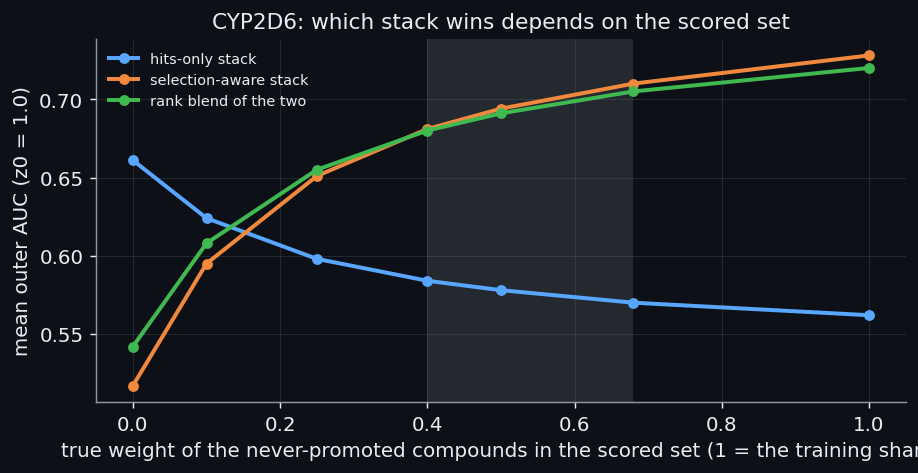

In [216]:
# The regime problem. The selection-aware stack wins only when the scored set holds enough never-promoted compounds, and the share is only estimated. hedged_blend.py fits the stacks under one assumed regime and scores them under
# every true regime of a grid (the non-hit weight w, 1 = the training share). The table of the log for the fit weight that the build uses (1.0) is read, at z0 = 1.0, for the three models: the hits-only stack, the selection-aware stack
# and the rank blend of the two.
hedged_text = (LOGS9 / "hedged_blend_CYP2D6.log").read_text(errors="ignore")
final_block = hedged_text.split("stacks fitted under non-hit weight 1.0")[1]
first_grid = final_block.split("z0 = 1.0")[1].split("z0 = 1.96")[0]
weights_axis = [float(w) for w in re.findall(r"w=([\d.]+)", first_grid.splitlines()[0])]
regime_rows = []
for line in first_grid.splitlines():
    match = re.match(r"\s+(hits_only|selection_aware|blend)\s+(.*)", line)
    if match:
        values = [float(v) for v in re.findall(r"([\d.]+)\|", match.group(2))]
        regime_rows.append({"model": match.group(1), **{f"w={w:g}": v for w, v in zip(weights_axis, values)}})
regime_table = pd.DataFrame(regime_rows)
show_table(regime_table, floatfmt=".3f")
fig, axis = plt.subplots(figsize=(7.2, 3.8))
for model, colour, label in (("hits_only", theme["blue"], "hits-only stack"), ("selection_aware", theme["orange"], "selection-aware stack"), ("blend", theme["green"], "rank blend of the two")):
    row = regime_table[regime_table["model"] == model].iloc[0]
    axis.plot(weights_axis, [row[f"w={w:g}"] for w in weights_axis], "o-", color=colour, lw=2.2, ms=5, label=label)
axis.axvspan(0.4, 0.68, color=theme["muted"], alpha=0.18, lw=0)
axis.set(xlabel="true weight of the never-promoted compounds in the scored set (1 = the training share)", ylabel="mean outer AUC (z0 = 1.0)", title="CYP2D6: which stack wins depends on the scored set")
axis.legend(frameon=False, fontsize=8, loc="upper left")
tidy(axis, theme)
fig.tight_layout()
hits_row, sel_row = regime_table[regime_table["model"] == "hits_only"].iloc[0], regime_table[regime_table["model"] == "selection_aware"].iloc[0]
crossover = next((w for w in weights_axis if sel_row[f"w={w:g}"] > hits_row[f"w={w:g}"]), None)
before_crossover = weights_axis[weights_axis.index(crossover) - 1] if crossover is not None and weights_axis.index(crossover) > 0 else 0.0
hedged_gates = dict(re.findall(r"CYP2D6 GATE \((hedged blend adopted by the minimax rule|selection-aware replaces hits-only)[^)]*fit weight 1\.0\): (MET|NOT MET)", hedged_text))

The picture of the figure is the heart of the section. The hits-only stack is best when the scored set has no non-hits (AUC 0.661 at $w = 0$, against 0.517 for the selection-aware one), and it loses steadily as non-hits are added (0.562 at $w = 1$). The selection-aware stack is the reverse, and the two cross between the weights 0.1 and 0.25. Inside the plausible band (the shaded range 0.4 to 0.68, where the label-shift estimate of 0.51 sits) the selection-aware stack scores between 0.681 and 0.710 and the hits-only stack between 0.570 and 0.584. The rank blend, the average of the two stacks' empirical-distribution ranks, sits between them. The decision at deployment has to be made without knowing the weight, and `cypmode/challenge/hedged_blend.py` states two rules before the numbers: the blend is adopted if over the plausible band its worst-case AUC is at least the better worst case of the two pure models, and the selection-aware stack replaces the hits-only one only if its mean AUC is higher at every band weight at both cut-offs *and* the corrected paired p is below 0.05 at every one of them. The paired differences in the band are large (+0.10 to +0.17 AUC) and their p-values are 0.05 to 0.16, so that neither rule is met: the blend gate is NOT MET and the replacement gate is NOT MET.

What follows from a gate that is not met is exactly what the project's rule says: the default (the hits-only stack) stays the model. The evidence is not symmetric, though, and the project does not hide it. Inside the band that the two independent estimates support, the selection-aware stack is far better, by 0.1 AUC or more, and outside it, at the edge where the scored set would have no non-hits at all, it is worse by 0.14. The gate is not met because the paired folds are few and the differences vary between them, not because the sign is in doubt. The build therefore writes both stacks as candidate files for CYP2D6, A (hits-only) and B (selection-aware), with CYP3A4 identical in the two (8.6), and the choice between them is a decision under uncertainty about a quantity that no experiment can measure; section 13.4 reports which is submitted.

*On what actually ran.* `cypmode/challenge/population_experiment.py` (v1; the sets S0 to S3), `selection_aware_v2.py` (the cross-fitted promotion-pattern gate and the Heckman candidate), `population_share.py` (the band from the public baseline), `test_nonhit_share.py` (the adjusted count and classify-and-count at three thresholds, with a nearest-neighbour hit fraction as a sanity check), `hedged_blend.py` (the grid of regimes, the blend and the two rules), `library_blocks.py` (the panel block, found from the data and not from hand-typed identifiers), and, for the same population with physics columns, `population_physics.py` (9.11 and Part X). The logs read above are `population_panel_CYP2D6_r3.log`, `selection_aware_v2_CYP2D6.log`, `test_nonhit_share_CYP2D6.log` and `hedged_blend_CYP2D6.log`.

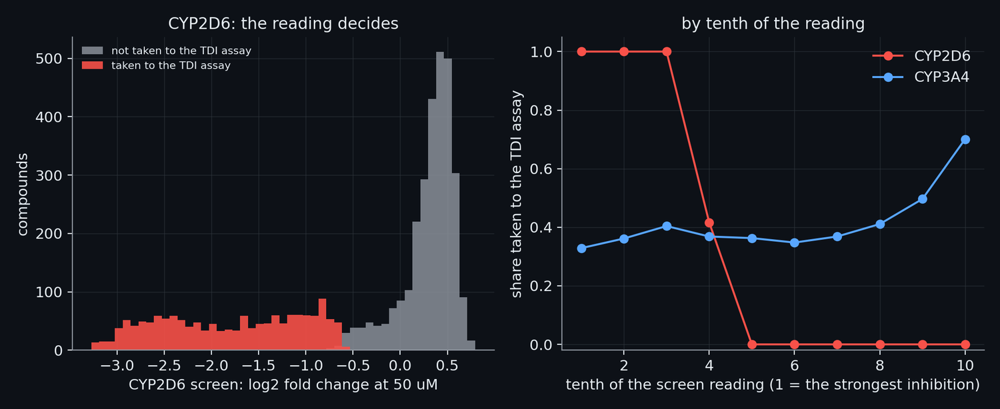

**Figure: The CYP2D6 hit gate against the real screen.** Which compounds reached the time-dependent-inhibition assay on an enzyme, against what the single-concentration screen showed on that enzyme, for the 4375 compounds of the all-isoform panel. Left (CYP2D6): the histogram of the screen reading of the compounds that were taken to the TDI assay (red) and of those that were not (grey). The two groups hardly overlap: every compound taken on has a reading of -0.59 or less, and the compounds above -0.76 were never taken on (34.2% of the panel reached the assay, rank correlation -0.82 with the reading). So for CYP2D6 the hit is almost a threshold on a number that the test compounds do not come with, and the selection-aware model learns that threshold from structure (its gate). Right (CYP3A4): the same share of compounds taken on in each tenth of the reading (41.5% overall, rank correlation +0.15): for CYP3A4 the choice did not follow the CYP3A4 reading, because the hit expansion that built the test set prioritised the hits of CYP3A4, CYP1A2 and CYP2C9, which is the reason that the selection model matters for CYP2D6 and not for CYP3A4.

In [217]:
show_figure("ml_hit_gate_vs_screen")

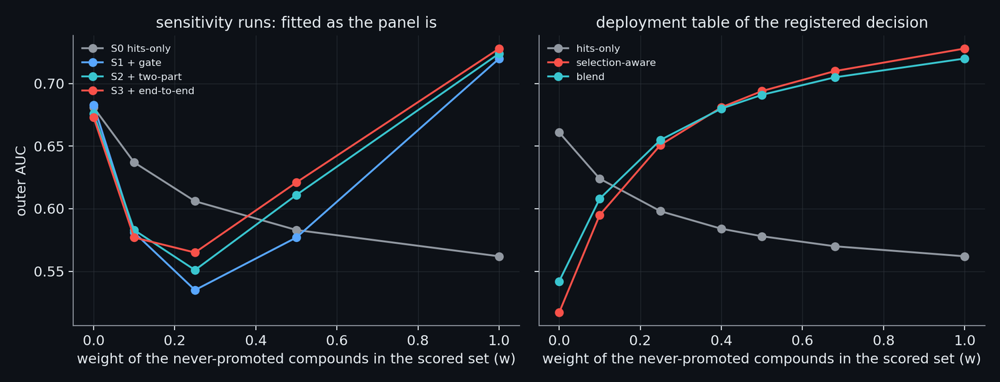

**Figure: The selection-aware model against the share of never-promoted compounds.** How much the selection-aware CYP2D6 model gains depends on how many never-promoted compounds the scored set holds, a share that nobody knows for the test set. The horizontal axis is the weight w of such compounds in the scored population (0: none, 1: as many as in the training panel). Left: the outer AUC of the hits-only stack (S0) and of the three versions of the selection-aware model (S1 to S3, fitted as the training panel is) against w at the confidence cut z0 = 1.0, from the sensitivity runs: the hits-only stack leads when w is small and is behind S3 by 0.166 AUC when w = 1. Right: the deployment table of the registered decision (stacks fitted under w = 1.0, the top share of the final build called): the hits-only file against the selection-aware file and the rank blend; at w = 0.0 the AUC is 0.661, 0.517 and 0.542, at w = 1.0 it is 0.562, 0.728 and 0.720. The two files each win in one regime; the registered rule, which looks at the loss in the regime where the selection-aware file loses, gives the hits-only file.

In [218]:
show_figure("ml_selection_sensitivity")

## 9.2 Making SAR explicit: pair models and compounds that differ by one change

> **Field:** Cheminformatics · Machine learning

*Where this section sits:* 7.3 gave the model the labels of a compound's neighbours as four columns. A nearest neighbour is only a vote; it cannot tell which differences between a compound and its neighbour matter. That knowledge is what medicinal chemists call the **structure-activity relationship** (**SAR**): a methyl group next to an amine may switch the activity off, a chlorine on a distant ring may do nothing. This section tries two ways of learning it from the data, and finds, for a reason that the data make plain, that neither can be learned from this much of it.

**A pair model.** Instead of describing a compound and its neighbours separately, describe each *pair*. For a compound $q$ and each of its $K = 5$ most similar labelled training compounds $n$, the row is the descriptors of $q$, the *differences* of the descriptors of $q$ and $n$, the Tanimoto similarity of the two, the label of $n$, and the rank of $n$ among the neighbours. One LightGBM learns the label of $q$ from such rows, so that it can learn, for instance, that a neighbour that is positive but has a lower hydrogen-abstraction energy at the best site makes $q$ less likely to be positive (with the physics block of Part X as the descriptors, the differences are physical). For a new compound the five pair predictions are averaged with the similarity as weight. The training pairs use only training rows and a training compound is not its own neighbour (the rule of 7.3). The next cell builds the pair rows of one validation compound, fits the model on the first outer fold of CYP3A4, and compares it with the plain LightGBM on the same descriptors and with the neighbours' vote.

In [219]:
# The pair model on one outer fold of CYP3A4 (cypmode/challenge/pair_transfer.py). A nearest-neighbour model says that a compound resembles its neighbours' labels; it cannot say which *differences* from a neighbour matter. The pair model
# forms, for each compound q and each of its K = 5 most similar labelled compounds n, a row [descriptors of q, descriptors of q minus those of n, Tanimoto(q, n), label of n, rank of n] and learns the label of q from it; a new compound's
# five pair predictions are averaged with the similarity as weight. The cell builds the pair rows of one validation compound, fits the model on the outer-training compounds of the first fold, and compares it with the plain LightGBM on
# the descriptors and with the nearest-neighbour average, on the 467 validation compounds.
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

from cypmode.challenge.pair_transfer import PAIR_K, fit_predict_pairs, neighbour_table, pair_matrix

bits_pair = store8["morgan_bits"].astype(np.float32)
descriptors_pair = store8["rdkit_desc"].astype(np.float32)
refit_pair = plan8.task(*plan8.outer_folds()[0], OUTER_REFIT)
rows_fit, rows_eval = refit_pair.train, refit_pair.evaluate
overlap = bits_pair[rows_eval] @ bits_pair[rows_fit].T
similarity_et = overlap / (bits_pair[rows_eval].sum(1)[:, None] + bits_pair[rows_fit].sum(1)[None, :] - overlap)
overlap_tt = bits_pair[rows_fit] @ bits_pair[rows_fit].T
similarity_tt = overlap_tt / (bits_pair[rows_fit].sum(1)[:, None] + bits_pair[rows_fit].sum(1)[None, :] - overlap_tt)
y_fit, y_eval = plan8.labels(rows_fit), plan8.labels(rows_eval)
x_fit, x_eval = descriptors_pair[rows_fit], descriptors_pair[rows_eval]
top_e, sims_e = neighbour_table(similarity_et, np.arange(len(rows_eval)), np.arange(len(rows_fit)), PAIR_K, False)
example_rows = pair_matrix(x_eval[:1], x_fit, y_fit, top_e[:1], sims_e[:1])
n_descriptors_pair = x_fit.shape[1]
pair_prediction = fit_predict_pairs(x_fit, y_fit, x_eval, similarity_tt, similarity_et, PAIR_K, {"n_estimators": 300, "learning_rate": 0.04, "num_leaves": 31, "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.3, "min_child_samples": 10}, 4, 0)
plain_prediction = LGBMClassifier(verbose=-1, n_estimators=300, learning_rate=0.04, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.3, min_child_samples=10, random_state=0).fit(x_fit, y_fit).predict_proba(x_eval)[:, 1]
neighbour_vote = (np.maximum(sims_e, 1e-6) * y_fit[top_e]).sum(1) / np.maximum(sims_e, 1e-6).sum(1)
typical = int(np.argsort(sims_e.mean(axis=1))[len(rows_eval) // 2])                      # the validation compound whose mean neighbour similarity is the median one
example_rows = pair_matrix(x_eval[typical:typical + 1], x_fit, y_fit, top_e[typical:typical + 1], sims_e[typical:typical + 1])
pair_view = pd.DataFrame({"neighbour": np.arange(1, PAIR_K + 1), "Tanimoto similarity": sims_e[typical], "label of the neighbour": y_fit[top_e[typical]]})
show_table(pair_view, floatfmt=".2f")
pair_compare = pd.DataFrame([{"model": "plain LightGBM on the descriptors", "AUC on the validation compounds": roc_auc_score(y_eval, plain_prediction)}, {"model": "similarity-weighted vote of the 5 neighbours", "AUC on the validation compounds": roc_auc_score(y_eval, neighbour_vote)},
                             {"model": "pair model (5 pair rows per compound)", "AUC on the validation compounds": roc_auc_score(y_eval, pair_prediction)}])
show_table(pair_compare, floatfmt=".3f")
pair_columns, pair_rows_fit = int(example_rows.shape[1]), int(len(y_fit) * PAIR_K)
example_values = {"truth": int(y_eval[typical]), "pair model": float(pair_prediction[typical]), "plain model": float(plain_prediction[typical]), "vote": float(neighbour_vote[typical]), "similarity": float(sims_e[typical].mean())}

| neighbour | Tanimoto similarity | label of the neighbour |
| --- | --- | --- |
| 1 | 0.41 | 0 |
| 2 | 0.36 | 1 |
| 3 | 0.35 | 1 |
| 4 | 0.32 | 0 |
| 5 | 0.32 | 0 |

| model | AUC on the validation compounds |
| --- | --- |
| plain LightGBM on the descriptors | 0.732 |
| similarity-weighted vote of the 5 neighbours | 0.592 |
| pair model (5 pair rows per compound) | 0.729 |

The pair rows of the typical validation compound of this fold (the one whose mean neighbour similarity is the median) have 437 columns each, 9,335 rows for the 1,867 training compounds. Its five neighbours are at similarities around 0.35, far from identical, and a typical compound of this pool has no close relative in it: that is the first reason the pair model cannot teach much. The neighbours' vote scores an AUC of 0.592, the plain LightGBM 0.732 and the pair model 0.729. The pair model learned as much as the model that never saw a pair and not more.

**Matched molecular pairs.** The same idea can be made exact. Two compounds form a **matched molecular pair** when cutting one bond of each leaves the *same* large constant part and *different* small variable parts, one to ten heavy atoms (RDKit's `rdMMPA` does the fragmentation). The change of one variable part into another is a *transformation*, written "variable of $n$ $\gg$ variable of $q$". The classical use (Kenny and Sadowski; Hussain and Rea, 2010) tabulates, over all pairs that share a transformation $T$, how the activity moved, and predicts that the same change in a new compound moves it likewise; the Free-Wilson analysis is the same idea for sums of substituent contributions. The project's version, `cypmode/challenge/mmp_transfer.py`, sums over the training pairs $a \to b$ of the transformation the label change, shrunk toward zero when the transformation has been seen few times,
$$\delta_T \;=\; \frac{\sum_{a \to b \,\in\, T} (y_b - y_a)}{N_T + 3},$$
with $y_a$ and $y_b$ the labels (0 or 1) of the two compounds of a pair and $N_T$ the number of training pairs of the transformation $T$, and gives LightGBM five features per compound (the number of matched partners, their mean label, the mean of $y_n + \delta_T$ clipped to $[0, 1]$, the mean $\delta_T$, and the number of partners whose transformation has at least three supporting pairs). The table and the partners' labels come from the training rows only, and a training compound's own pairs are removed from the table before its features are computed. The cell reads the cached pairs for the CYP3A4 pool and looks at what the table holds.

In [220]:
# Matched molecular pairs (cypmode/challenge/mmp_transfer.py). Two compounds form a matched pair when cutting a single bond of each (RDKit's rdMMPA) leaves the same large *constant* part and different small *variable* parts of 1 to 10
# heavy atoms; the transformation is written "variable of n >> variable of q". For a query q, the model looks at the training compounds n that form a pair with it and asks how that same transformation moved the label across all other
# training pairs: delta_T = sum over the pairs a -> b with transformation T of (y_b - y_a) / (count_T + 3), the shrinkage by 3 pulling a transformation seen few times towards "no change". The pairs are label-free and cached; the cell reads
# them for the CYP3A4 pool, counts them, lists the best-supported transformations with the label change they carry, and shows one worked example.
from cypmode.challenge.mmp_transfer import SHRINK, get_pairs, mmp_label_features, transformation_report

all_smiles = [str(v) for v in store8["smiles"]]
pairs = get_pairs(all_smiles)
pool_rows, pool_labels = plan8.pool, plan8.labels(plan8.pool)
in_pool = np.zeros(len(all_smiles), dtype=bool)
in_pool[pool_rows] = True
own_features = mmp_label_features(pairs, len(all_smiles), pool_rows, pool_labels, pool_rows, True)
test_features = mmp_label_features(pairs, len(all_smiles), pool_rows, pool_labels, plan8.external, False)
report = transformation_report(pairs, pool_rows, pool_labels, top=8, min_support=2)
report_table = pd.DataFrame(report, columns=["transformation (variable of n >> variable of q)", "training pairs", "shrunk mean change of the label"])
show_table(report_table, floatfmt=".3f")
a_idx, b_idx, t_idx, names_mmp = pairs
best_name = report[0][0]
best_id = names_mmp.index(best_name)
example_pair = next((int(a), int(b)) for a, b, t in zip(a_idx, b_idx, t_idx) if t == best_id and in_pool[a] and in_pool[b])
label_of = dict(zip(pool_rows, pool_labels))
within_pool = in_pool[a_idx] & in_pool[b_idx]
support = np.bincount(t_idx[within_pool], minlength=len(names_mmp))
mmp_facts = {"directed pairs among all the compounds": len(a_idx), "directed pairs inside the CYP3A4 pool": int(within_pool.sum()), "distinct transformations among all the compounds": len(names_mmp),
             "pool compounds with a matched partner in the pool": float(np.mean(own_features[:, 0] > 0)), "blinded compounds with a matched partner in the pool": float(np.mean(test_features[:, 0] > 0)),
             "transformations seen in 2 or more pool pairs": int((support >= 2).sum()), "transformations seen in 3 or more pool pairs": int((support >= 3).sum()), "pairs of the most frequent transformation": int(support.max())}
show_table(pd.DataFrame({"quantity": list(mmp_facts), "value": list(mmp_facts.values())}), floatfmt=".3f")
print(f"worked example, transformation {best_name}: {all_smiles[example_pair[0]]} (label {label_of[example_pair[0]]}) -> {all_smiles[example_pair[1]]} (label {label_of[example_pair[1]]})")

worked example, transformation Cl[*:1]>>C[*:1]: CC(C)(C)NCC(O)COC1=CC(Cl)=CC=C1Cl (label 0) -> CC1=CC=C(Cl)C(OCC(O)CNC(C)(C)C)=C1 (label 0)


| transformation (variable of n >> variable of q) | training pairs | shrunk mean change of the label |
| --- | --- | --- |
| Cl[*:1]>>C[*:1] | 4 | 0.143 |
| C[*:1]>>Cl[*:1] | 4 | -0.143 |
| Cc1cc(F)ccc1[*:1]>>FC(F)(F)c1ccccc1[*:1] | 2 | 0.200 |
| FC(F)(F)c1ccccc1[*:1]>>Cc1cc(F)ccc1[*:1] | 2 | -0.200 |
| C[*:1]>>C1COC(C[*:1])C1 | 2 | -0.200 |
| C1COC(C[*:1])C1>>C[*:1] | 2 | 0.200 |
| CS[*:1]>>C[*:1] | 2 | 0.000 |
| C[*:1]>>CS[*:1] | 2 | 0.000 |

| quantity | value |
| --- | --- |
| directed pairs among all the compounds | 13078.000 |
| directed pairs inside the CYP3A4 pool | 3120.000 |
| distinct transformations among all the compounds | 11740.000 |
| pool compounds with a matched partner in the pool | 0.284 |
| blinded compounds with a matched partner in the pool | 0.336 |
| transformations seen in 2 or more pool pairs | 18.000 |
| transformations seen in 3 or more pool pairs | 2.000 |
| pairs of the most frequent transformation | 4.000 |

The whole collection yields 13,078 directed pairs and 11,740 distinct transformations; inside the CYP3A4 pool there are 3,120 pairs, and 28% of the pool compounds have a matched partner in the pool, 34% of the blinded compounds. That is already a thin coverage, and the shape of the table is thinner: of the transformations, 18 are seen in two pool pairs or more, 2 in three or more, and the most frequent is seen in 4. The table above is the best the data support, and a shrunk change of +0.14 from 4 pairs is a statement that nothing has been learned. A matched-pair table works in a data set where one series was explored by many analogues. This is a diversity collection with analogue expansion on top, so that each transformation occurs once or twice, and one or two examples are not a trend.

*The gates.* Both ideas, and the pair model with the xTB physics block as the descriptors, were added to the default stack and judged by the gate of 6.7 for each enzyme.

In [221]:
# The gate results of the two ideas, for both enzymes: the pair model with the descriptors in the delta block (pair_desc), with the xTB physics block in the delta (pair_physics), and the matched-pair model (mmp), each
# added to the default stack. The "alone" AUC is the diagnostic of the new candidate on its own.
sar_rows = []
for name, stem in (("pair model, descriptor deltas", "pair_transfer"), ("pair model, physics deltas", "pair_transfer_physics"), ("matched-pair transformations", "mmp_transfer")):
    for iso in ("CYP3A4", "CYP2D6"):
        row = stacked_summary(stem, iso)
        result = read_gate_log(stem, iso)
        diag = result["diagnostic"] if result is not None and "diagnostic" in result and len(result["diagnostic"]) else None
        best_alone = float(diag[diag["z0"] == 1.0]["outer AUC alone"].max()) if diag is not None and (diag["z0"] == 1.0).any() else np.nan
        sar_rows.append({"idea": name, "enzyme": iso, "best candidate alone (AUC, z0 1.0)": best_alone, **row})
sar_table = pd.DataFrame(sar_rows)
show_table(sar_table, floatfmt=".4f")
sar_largest = float(sar_table[["gain at z0 1.0", "gain at z0 1.96"]].abs().max().max())
sar_smallest_p = float(sar_table[["p at z0 1.0", "p at z0 1.96"]].min().min())
n_sar_met = int((sar_table["gate"] == "MET").sum())

| idea | enzyme | best candidate alone (AUC, z0 1.0) | gain at z0 1.0 | p at z0 1.0 | gain at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- | --- | --- |
| pair model, descriptor deltas | CYP3A4 | 0.7670 | -0.0003 | 0.7730 | -0.0001 | 0.7730 | NOT MET |
| pair model, descriptor deltas | CYP2D6 | 0.6474 | -0.0030 | 0.7320 | 0.0011 | 0.6200 | NOT MET |
| pair model, physics deltas | CYP3A4 | 0.7959 | 0.0042 | 0.1520 | 0.0042 | 0.3040 | NOT MET |
| pair model, physics deltas | CYP2D6 | 0.6893 | -0.0010 | 0.9160 | 0.0019 | 0.6300 | NOT MET |
| matched-pair transformations | CYP3A4 | 0.7975 | -0.0001 | 0.9200 | 0.0001 | 0.9370 | NOT MET |
| matched-pair transformations | CYP2D6 | 0.7227 | -0.0048 | 0.5200 | 0.0010 | 0.7740 | NOT MET |

No gate is met (0 of the 6 lines), the largest stacked change of the table, in absolute value, is 0.0048 AUC and the smallest p-value is 0.152. The pair model reaches an AUC of 0.767 alone on CYP3A4, close to the single models of 8.1 and well below the stack; with the physics differences 0.796, a better single model that adds +0.0042 to the stack. The reasons are the ones the section has shown. A neighbour-based model can only be as good as the neighbours, and the neighbours of a typical compound here are far; a transformation-based one needs transformations seen many times, and none is. Both would be strong on a series, a set of analogues of one scaffold with many measured members, and the blinded set is made of analogue expansions, which is why the idea was worth the test; but the expansions are of top hits taken from a diversity collection, so that each series in the training file is a handful of compounds and not a hundred. The idea reappears in Part XI in a different form, as the agreement of a pose with the poses of its analogues.

*On what actually ran.* `cypmode/challenge/pair_transfer.py` (`neighbour_table`, `pair_matrix`, `fit_predict_pairs`, the gate through `addition_experiment.py`), `cypmode/challenge/mmp_transfer.py` (`build_pairs`, `get_pairs` with its cache, `mmp_label_features`, `transformation_report`), and the logs `pair_transfer_<enzyme>.log`, `pair_transfer_physics_<enzyme>.log` and `mmp_transfer_<enzyme>.log`. The nested design, the weights and the corrected t are those of Part VI.

## 9.3 The label as a threshold of two noisy numbers: a committee that outputs a probability

> **Field:** Statistics · Machine learning

*Where this section sits:* 9.2 asked for more from the neighbours. This section asks for more from the *label*. The label is a yes/no, but it is made from two measured numbers, each with a measurement error, by a threshold (section 2.3). A classifier fitted to the label sees only the thresholded shadow of the process that made it; 8.1 already used the numbers in two regression members. This section builds a model of the whole process and asks it for a probability and for an expected improvement, the quantity used elsewhere in the project to decide where an extra measurement or sample is worth most.

**The model.** The shift $s = t - \max(d, 4)$ is positive-labelled when $s > \tau = \log_{10} 2$. A **committee** of gradient-boosted regressors, differing in the feature set, in a random 70 percent of the training rows (bagging) and in the seed, each fits *both* arms, $t$ and $d$, on arms clipped from below at the assay floor 4 (clipping leaves every label unchanged, because only $\max(d, 4)$ and whether $t$ clears 4 matter; 9.6 tests the clipping on its own). Each training row is weighted by the inverse of its own measurement variance, $\mathrm{sd}(s)^2 = \mathrm{sd}_t^2 + [d \ge 4]\,\mathrm{sd}_d^2$, so that a measurement that is known to be noisy counts less (a weighted regression, section 4.6). A member's predicted shift is $\hat t - \max(\hat d, 4)$. The committee mean $m$ is the point estimate, and the spread $\mathrm{sd}_e$ of the members' predictions is the *epistemic* uncertainty (the uncertainty of the model, as against the noise of the measurement). The out-of-bag error of the members, each scored on the rows it never saw, gives a fair scale $\sigma_{\text{base}}$ for the noise, and the predictive distribution of the shift is taken to be a normal one, $s \sim \mathcal N\big(m,\ \sigma_{\text{base}}^2 + \mathrm{sd}_e^2\big)$. With $\sigma = \sqrt{\sigma_{\text{base}}^2 + \mathrm{sd}_e^2}$ and $z = (m - \tau)/\sigma$, the two outputs, the probability $P$ that the label is positive and the expected improvement $\mathrm{EI}$, are
$$P(\text{label}) \;=\; \Phi(z), \qquad \mathrm{EI} \;=\; \sigma\,\big(\varphi(z) + z\,\Phi(z)\big),$$
where $\Phi$ and $\varphi$ are the cumulative distribution function and the density of the standard normal. The expected improvement is the expected size of the exceedance of the threshold, $E[\max(s-\tau, 0)]$; it comes from Bayesian optimisation (Jones, Schonlau and Welch, 1998), where it chooses the next experiment. Three candidates are cached: `committee_m` (the point estimate alone, to isolate what the uncertainty adds), `committee_p` and `committee_ei`. Only the training rows' arms and standard deviations and the evaluated compounds' structures are read; the evaluated rows' measurements never are. The cell shows the two formulas on three compounds, checked by simulation.

In [222]:
# The label as a threshold of a noisy number, in numbers. The label is positive when the shift s = t - max(d, 4) exceeds tau = log10 2 (section 2.3). A model that predicts s with a Gaussian error, s ~ Normal(m, sigma^2), knows
# more than the yes/no label: the probability of a positive is P(s > tau) = Phi((m - tau) / sigma), and the *expected improvement* of s over the threshold, the expected size of the exceedance E[max(s - tau, 0)], is
# sigma (phi(z) + z Phi(z)) with z = (m - tau) / sigma (phi and Phi the density and the cumulative distribution function of the standard normal). A compound can have the same P and a different EI: a sure bet barely above the
# threshold and a long shot far above it. The cell evaluates the formulas for three compounds and checks them by simulation.
from scipy.stats import norm

from cypmode.challenge.tdi_targets import SHIFT_THRESHOLD

tau = float(SHIFT_THRESHOLD)
toy_compounds = pd.DataFrame({"compound": ["sure, barely above", "coin flip", "long shot, far above if it is"], "predicted shift m": [0.45, 0.30, 0.10], "sigma": [0.10, 0.20, 0.70]})
z_toy = (toy_compounds["predicted shift m"] - tau) / toy_compounds["sigma"]
toy_compounds["P(label)"] = norm.cdf(z_toy)
toy_compounds["expected improvement"] = toy_compounds["sigma"] * (norm.pdf(z_toy) + z_toy * norm.cdf(z_toy))
rng_c = np.random.default_rng(0)
simulated = rng_c.normal(toy_compounds["predicted shift m"].to_numpy()[:, None], toy_compounds["sigma"].to_numpy()[:, None], size=(3, 400000))
toy_compounds["P by simulation"] = (simulated > tau).mean(axis=1)
toy_compounds["EI by simulation"] = np.maximum(simulated - tau, 0).mean(axis=1)
show_table(toy_compounds, floatfmt=".4f")
formula_check = float(max(np.abs(toy_compounds["P(label)"] - toy_compounds["P by simulation"]).max(), np.abs(toy_compounds["expected improvement"] - toy_compounds["EI by simulation"]).max()))

| compound | predicted shift m | sigma | P(label) | expected improvement | P by simulation | EI by simulation |
| --- | --- | --- | --- | --- | --- | --- |
| sure, barely above | 0.4500 | 0.1000 | 0.9318 | 0.1520 | 0.9317 | 0.1520 |
| coin flip | 0.3000 | 0.2000 | 0.4979 | 0.0793 | 0.4989 | 0.0794 |
| long shot, far above if it is | 0.1000 | 0.7000 | 0.3870 | 0.1902 | 0.3865 | 0.1901 |

The formulas agree with the simulation to 0.0009. The three compounds make the point of having both outputs. The long shot has the lowest probability of the three (0.39) and the highest expected improvement (0.19); the sure compound barely above the threshold has the highest probability (0.93) and a smaller expected improvement (0.15). The probability says how likely the yes is, the expected improvement how much the compound is worth if its uncertainty is explored. Now the committee on the real compounds, in the nested design.

In [223]:
# The committee in the nested design, from the logs. The candidates are committee_m (the committee's mean shift), committee_p (P(label)) and committee_ei; the first is there to separate what the uncertainty adds from what the
# regression alone gives. Gate 1: the stack with the three candidates beats the default stack with corrected p < 0.05 at both cut-offs. Gate 2: committee_p must be calibrated as it comes out, with no post-hoc map
# (ECE at most 0.05, slope between 0.8 and 1.2, the bar of 8.5).
CAL_LINE = re.compile(r"z0=(\d\.\d+)\s+ECE ([\d.]+)\s+Brier ([\d.]+)\s+slope ([\d.]+)\s+mean predicted ([\d.]+) vs observed ([\d.]+)\s+-> calibration gate (MET|NOT MET)")
committee_rows, committee_cal = [], []
for iso in ("CYP3A4", "CYP2D6"):
    summary = stacked_summary("committee_label_model", iso)
    result = read_gate_log("committee_label_model", iso)
    diag = result["diagnostic"] if result is not None else pd.DataFrame()
    alone_auc = {z: float(diag[diag["z0"] == z]["outer AUC alone"].max()) for z in (1.0, 1.96)} if len(diag) else {1.0: np.nan, 1.96: np.nan}
    committee_rows.append({"enzyme": iso, "best member alone, AUC at z0 1.0": alone_auc[1.0], **summary})
    text = (LOGS9 / f"committee_label_model_{iso}.log").read_text(errors="ignore") if (LOGS9 / f"committee_label_model_{iso}.log").exists() else ""
    for z0, ece, brier, slope, predicted, observed, verdict in CAL_LINE.findall(text):
        committee_cal.append({"enzyme": iso, "z0": float(z0), "ECE": float(ece), "slope": float(slope), "mean predicted": float(predicted), "mean observed": float(observed), "calibration gate": verdict})
committee_table, committee_cal_table = pd.DataFrame(committee_rows), pd.DataFrame(committee_cal)
show_table(committee_table, floatfmt=".4f")
show_table(committee_cal_table, floatfmt=".3f")
committee_3a4 = committee_table[committee_table["enzyme"] == "CYP3A4"].iloc[0]

| enzyme | best member alone, AUC at z0 1.0 | gain at z0 1.0 | p at z0 1.0 | gain at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 0.7633 | 0.0023 | 0.4050 | 0.0033 | 0.3940 | NOT MET |
| CYP2D6 | 0.6411 | -0.0070 | 0.6150 | -0.0059 | 0.7580 | NOT MET |

| enzyme | z0 | ECE | slope | mean predicted | mean observed | calibration gate |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 1.000 | 0.141 | 1.494 | 0.449 | 0.310 | NOT MET |
| CYP3A4 | 1.960 | 0.135 | 1.727 | 0.444 | 0.315 | NOT MET |
| CYP2D6 | 1.000 | 0.306 | 4.215 | 0.338 | 0.039 | NOT MET |
| CYP2D6 | 1.960 | 0.312 | 5.496 | 0.338 | 0.041 | NOT MET |

The committee, alone, ranks about as well as the single members of 8.1: the best of its three outputs scores an AUC of 0.763 on CYP3A4 at $z_0 = 1.0$. Inside the stack its three candidates add +0.0023 AUC at $z_0 = 1.0$ (corrected p = 0.41) and +0.0033 at $z_0 = 1.96$ (p = 0.39); the stacked gate is NOT MET. The second gate, calibration, is the more instructive failure. The probability that the committee outputs is *not* a probability: its mean is 0.449 where the observed positive share is 0.310, the ECE is 0.141 and the slope 1.49 at $z_0 = 1.0$ (NOT MET against the bar of 0.05 and 0.8 to 1.2). The normal model of the error is too simple: the arms are floored, the errors are not symmetric, and the committee's members share their errors, so that the spread of the members understates how far the truth can be. The expected improvement inherits the fault. The idea of a model of the whole process is sound and the design, with a Gaussian predictive distribution, did not deliver the calibrated probability that was its reason. What does carry over is the weighting by the inverse of the measurement variance, which 9.8 tests separately.

*On what actually ran.* `cypmode/challenge/committee_label_model.py` (`measurement_variance`, `committee_predict` with its three outputs `m`, `p`, `ei`, and the calibration gate), run through `addition_experiment.py` for the stacked gate; the log `committee_label_model_<enzyme>.log`; the family `arm_committee` of `nested_runners.py`. The calibration bar is the one of `calibration_experiment.py` (8.5).

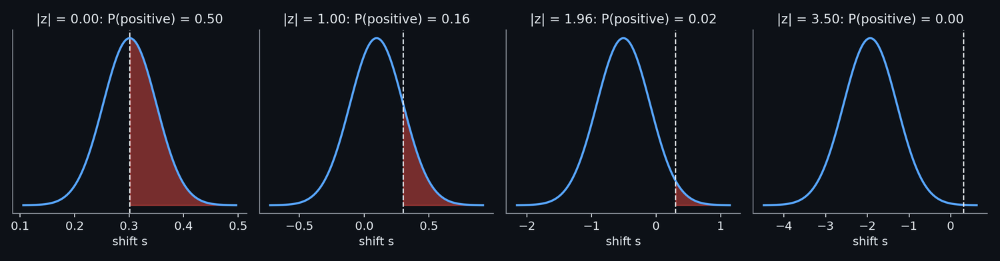

**Figure: The label as a Gaussian around a threshold.** The label as a threshold of two noisy numbers, drawn for four real CYP3A4 training compounds chosen by how far their shift is from the threshold. Each curve is the distribution of the shift s = t - max(d, 4) of one compound (the Gaussian with the mean and the standard deviation that its two assay arms give), the dashed line is the threshold log10 2, and the shaded area to its right is the probability that the compound is a time-dependent inhibitor. |z| = 0.00: shift +0.30 with a standard deviation of 0.05, P(positive) = 0.50; |z| = 1.00: shift +0.10 with a standard deviation of 0.21, P(positive) = 0.16; |z| = 1.96: shift -0.51 with a standard deviation of 0.41, P(positive) = 0.02; |z| = 3.50: shift -1.93 with a standard deviation of 0.64, P(positive) = 0.00. A compound whose shift sits within a standard deviation of the threshold is nearly a coin flip, and the official score almost certainly leaves such compounds out; the confidence z = (s - log10 2) / sd(s) is how the project decides which compounds count.

In [224]:
show_figure("data_label_gaussian")

## 9.4 A frozen foundation model: CheMeleon embeddings

> **Field:** Machine learning · Cheminformatics

*Where this section sits:* 7.9 tried a pretrained representation, the ChemBERTa embedding of the SMILES text, and found that appending 768 dense numbers to a tree model did not help. The lesson the project drew was about *form*, a dense block should be reduced before it is used, and about *kind*: a model that has read only text knows nothing of the physics of the molecule. This section tries a representation of a different kind, from a model that was pretrained to predict computed molecular descriptors, and uses it in the reduced form.

**What a foundation model is, and what frozen means.** A foundation model (section 4.9) is a model pretrained once, on a very large collection of data and a general task, so that its internal representation can be reused for many specific tasks with few labels of their own. CheMeleon (Burns and co-workers; the weights are deposited at Zenodo under the DOI 10.5281/zenodo.15426600) is a Chemprop directed message-passing network (section 4.8) pretrained on a large set of molecular descriptors that were computed from structures, so that its representation has been shaped to reproduce quantities that can be calculated from a molecule, the kind of information that the descriptors of Part III also hold. Using it **frozen** means that its weights are not changed by the project's few thousand labels: each molecule is passed through the encoder once, the mean of the encoder's output over the atoms (the *readout*, 2,048 numbers) is taken, and that is the representation. The project reduces the 2,048 numbers to 64 principal components (section 4.9), fitted on all 6,895 structures (this needs no label), and appends them to the feature sets A and A+fps as the block `chemeleon` (`cypmode/challenge/frozen_embeddings.py`). The extraction runs in a process of its own, under the environment that has the neural-network library, and writes a cache; the evaluation reads the cache (the rule of 7.8). The cell reads the cache and asks the same simple questions as for ChemBERTa, and then reads the nested comparison.

In [225]:
# The frozen CheMeleon block (cypmode/challenge/frozen_embeddings.py). CheMeleon is a Chemprop message-passing network pretrained to predict a large set of computed molecular descriptors; here it is used frozen: every molecule
# becomes the mean-aggregated 2,048-number readout of its message-passing encoder, reduced to 64 principal components (fitted on all 6,895 structures, which needs no label) and stored as the block "chemeleon". The notebook
# reads the cache. Three facts: how much of the variance the 64 components keep; how well a linear classifier on them separates the labels in the five folds of 7.1 (as for ChemBERTa in 7.9); and how the block did in the nested design.
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

chemeleon_raw = np.load(ROOT / "data/tdi_track/outputs/caches/chemeleon_embeddings.npz", allow_pickle=True)["embeddings"].astype(np.float64)
chemeleon_pca = PCA(n_components=64).fit(chemeleon_raw)
variance_64 = float(chemeleon_pca.explained_variance_ratio_.sum())
variance_10 = float(chemeleon_pca.explained_variance_ratio_[:10].sum())
chemeleon_block = store8["chemeleon"][: len(train_file)]
chemeleon_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    labelled_rows = train_file[f"{iso}_is_TDI"].notna().to_numpy()
    X_c, y_c = chemeleon_block[labelled_rows], train_file.loc[labelled_rows, f"{iso}_is_TDI"].astype(int).to_numpy()
    oof_c = np.zeros(len(y_c))
    for fit_rows, held in StratifiedKFold(5, shuffle=True, random_state=42).split(X_c, y_c):
        oof_c[held] = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=500)).fit(X_c[fit_rows], y_c[fit_rows]).predict_proba(X_c[held])[:, 1]
    gate = read_gate_log("embeddings", iso)
    diag = gate["diagnostic"] if gate is not None else pd.DataFrame()
    chemeleon_rows.append({"enzyme": iso, "linear probe on the 64 components, AUC": roc_auc_score(y_c, oof_c), "block alone in LightGBM, nested AUC at z0 1.0": float(diag[diag["z0"] == 1.0]["outer AUC alone"].iloc[0]) if len(diag) else np.nan, **stacked_summary("embeddings", iso)})
chemeleon_table = pd.DataFrame(chemeleon_rows)
show_table(chemeleon_table, floatfmt=".4f")
print(f"the 64 components keep {variance_64:.1%} of the variance of the 2,048 numbers, the first ten {variance_10:.1%}")
chemeleon_alone = read_gate_log("embeddings", "CYP3A4")["alone"]

the 64 components keep 78.6% of the variance of the 2,048 numbers, the first ten 45.6%


| enzyme | linear probe on the 64 components, AUC | block alone in LightGBM, nested AUC at z0 1.0 | gain at z0 1.0 | p at z0 1.0 | gain at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 0.7298 | 0.7446 | 0.0001 | 0.9670 | 0.0018 | 0.2610 | NOT MET |
| CYP2D6 | 0.5699 | 0.6310 | -0.0062 | 0.4740 | 0.0024 | 0.4320 | NOT MET |

The 64 components keep 78.6% of the variance of the 2,048 numbers. A linear classifier on them alone separates the labels with an AUC of 0.730 for CYP3A4 and 0.570 for CYP2D6, against 0.706 and 0.530 for the ChemBERTa vector of 7.9, which has twelve times as many numbers. In a LightGBM, the block alone reaches a nested AUC of 0.745 on CYP3A4, so that the block carries signal of its own; but added to the default stack it changes the AUC by +0.0001 (corrected p = 0.97) at $z_0 = 1.0$ and +0.0018 (p = 0.26) at $z_0 = 1.96$, and for CYP2D6 by -0.0062 and +0.0024. The gate is NOT MET for CYP3A4 and NOT MET for CYP2D6. A representation adds to a stack only if it knows something that the members do not. The simplest reading is that the 23 members, which read descriptors, fingerprints and the other blocks, already hold what the block knows, and that a network pretrained on computed descriptors repeats much of what the descriptors of Part III contain; the experiment does not test that reading, it shows only that the block adds nothing measurable. The fine-tuned CheMeleon, in which the whole network is trained on the project's labels and not frozen, is a different candidate and belongs to the neural family of 9.9.

*On what actually ran.* `cypmode/challenge/frozen_embeddings.py` (`extract` under the neural-network environment, the 64-component reduction `N_COMPONENTS`, the candidates `lgbm_chem_deep`, `lgbm_A+chem_deep` and `lgbm_A+fps+chem_deep`, the gate through `addition_experiment.py`), the cache `chemeleon_embeddings.npz`, and the logs `frozen_embeddings_extract.log` and `embeddings_<enzyme>.log`. The queue job is `050_frozen_embeddings`; `084_tdi_stack_reevaluation` repeats the stacked comparisons of this section and of 9.5 to 9.7 on the final plan. The weights are those of the Zenodo record named above, loaded into Chemprop's message-passing encoder with the hyperparameters stored beside them.

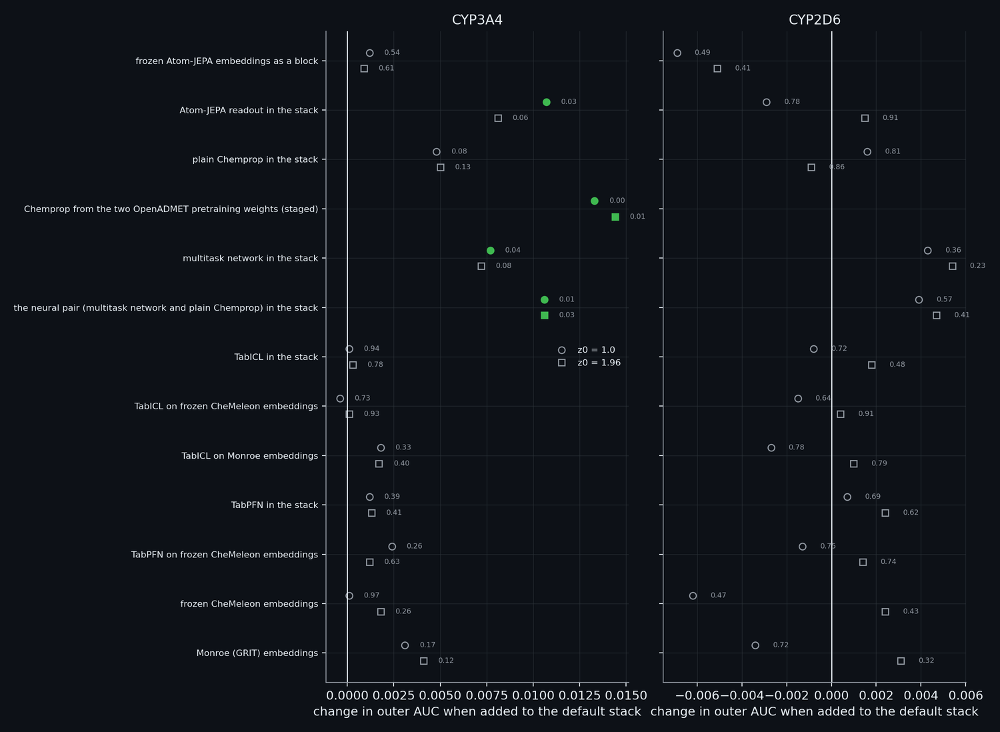

**Figure: The pretrained models as one forest plot.** The pretrained and learned-representation models that were added to the stack, as one forest plot: for each, the change in the outer AUC of the stack when it is added (positive is better), at the two confidence cuts of the labels, on each enzyme, with the corrected p-value beside the point; a filled green point has p < 0.05 and a gain, an open grey point does not. The gate asks for both cuts, alone and inside the stack. Passing at both cuts: Chemprop from the two OpenADMET pretraining weights (staged) (CYP3A4), the neural pair (multitask network and plain Chemprop) in the stack (CYP3A4). Passing at one cut only, which the gate does not accept: Atom-JEPA readout in the stack (CYP3A4), multitask network in the stack (CYP3A4). The tabular foundation models (TabICL, TabPFN), the frozen embeddings (CheMeleon, Monroe, Atom-JEPA) and the readouts on them gave gains that the design cannot tell from zero; the smallest gain that the design certifies is about 0.01 (section 6.7).

In [226]:
show_figure("ml_pretrained_forest")

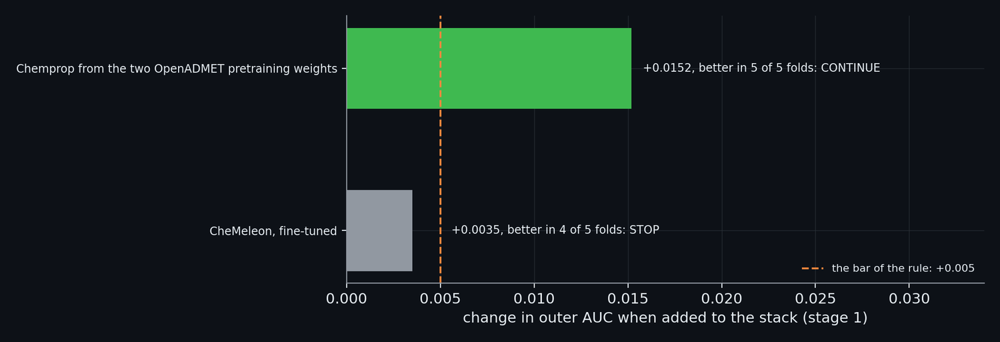

**Figure: The stage-1 screen of the fine-tuned networks against its rule.** The first stage of the staged design of the fine-tuned networks (CYP3A4, repeat 0, 5 outer folds, confidence cut z0 = 1.0). The rule was written before any result, for a reason of cost (about 38 minutes per task): the second stage runs only if the mean gain in AUC reaches 0.005 and the stack is better in at least 4 of the 5 folds. CheMeleon, fine-tuned: a gain of +0.0035 AUC, better in 4 of 5 folds, so STOP; Chemprop from the two OpenADMET pretraining weights: a gain of +0.0152 AUC, better in 5 of 5 folds, so CONTINUE to the full design. A screen is not a gate and is not in the ledger: the network that stopped has no verdict, and the one that continued went on to the full 15-fold gate, which it met. The smallest gain that a 5-fold screen can certify is about one and a half times that of the 15-fold design, so a stop at this stage is an economy and not a negative result.

In [227]:
show_figure("ml_chemeleon_stage1")

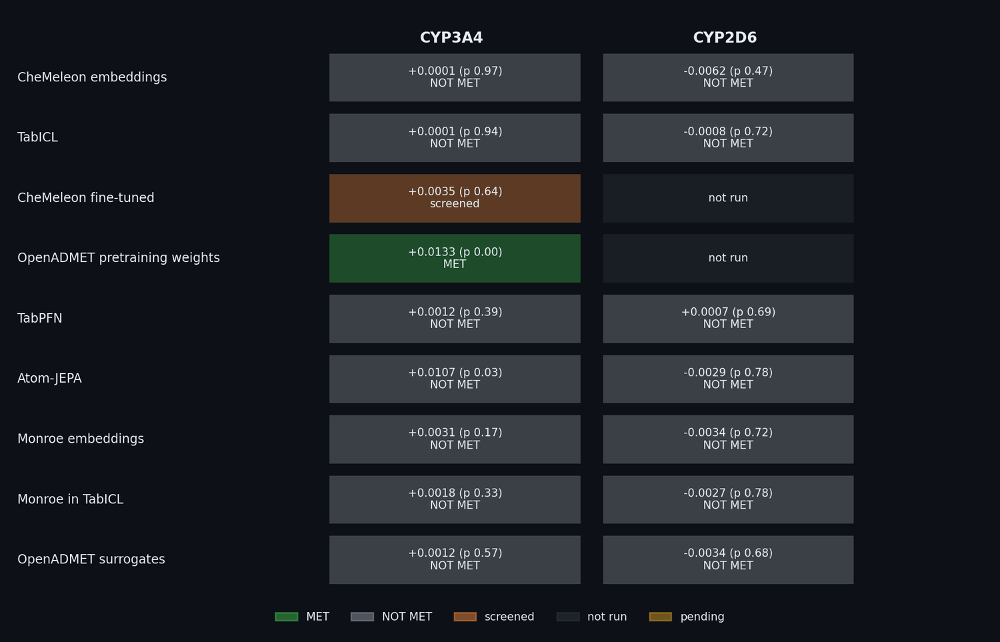

**Figure: The pretrained models and what each brought.** The pretrained models of the project and what each one brought, the table of the film's Foundry scene as a figure: one row per model, one column per enzyme, each cell the change in the AUC of the stack at z0 = 1.0 with the corrected p-value and the verdict of the registered gate. Of the 18 cells, 1 are MET, 14 NOT MET, 1 only screened in the first stage of a staged design and 2 not run (the fine-tuned networks were not run on CYP2D6, where plain Chemprop is at chance, and a model dropped for its cost has no verdict). The rows are read from the same logs as the ledger.

In [228]:
show_figure("ml_foundry_table")

## 9.5 Test-likeness weighting: importance weights from structures alone

> **Field:** Statistics · Machine learning

*Where this section sits:* 6.4 re-weighted the *validation* compounds so that the score looks like the score on the blinded set. This section asks whether the *training* compounds should be weighted the same way, so that the model spends its capacity where the blinded set lives. The blinded compounds sit closer to the training file than the compounds of a cross-validation fold do (section 6.8), and the argument for weighting is that a model fitted with equal weights spends much of its capacity on dense parts of the training set that the blinded compounds hardly touch.

**Importance weighting for the training rows.** Section 2.7 weighted the validation rows. If a model is judged by its average loss $L(x)$ over the test distribution $p_{\text{test}}(x)$ but fitted on training compounds drawn from $p_{\text{train}}(x)$, then $E_{\text{test}}[L] = E_{\text{train}}[w\,L]$ with the *density ratio* $w(x) = p_{\text{test}}(x)/p_{\text{train}}(x)$ (section 4.1): weight each training compound by how much more likely it is under the test distribution than under the training one. The ratio cannot be computed, because the densities of molecules are unknown, so it is approximated from structures alone. For a training compound $i$ let $a_i$ be its mean Tanimoto similarity to its five most similar *blinded* structures and $b_i$ its mean similarity to its five most similar *other training* compounds. The weight is $w_i = \mathrm{clip}\big((a_i / b_i)^{\alpha},\ 0.2,\ 5\big)$, rescaled to have mean 1, with $\alpha \in \{0.5, 1\}$ tempering the ratio. A compound that sits among the test compounds but alone in the training set gets a high weight, and a member of a dense series that the test set barely touches a low one. Only the 750 structures are used, never a label (`testlike_weights` in `cypmode/challenge/nested_runners.py`). The cell computes the weights once for the whole CYP3A4 pool; in the nested design each task computes them from its own training rows.

In [229]:
# Test-likeness weights (cypmode/challenge/nested_runners.py, testlike_weights). Under covariate shift, the standard remedy is importance weighting by the density ratio p_test(x) / p_train(x) (section 4.1). It is approximated from structures
# alone: the ratio of a training compound's mean similarity to its 5 most similar blinded structures to its mean similarity to its 5 most similar other training compounds, tempered by alpha (0.5 or 1), clipped to [0.2, 5] and
# rescaled to mean 1. A compound that sits among the test compounds but alone in the training set gets a high weight; a member of a dense training series that the test set barely touches, a low one. Only the 750 structures are used,
# never labels. The cell computes the weights for the CYP3A4 pool and describes their distribution, with Kish's effective sample size (section 2.7).
from cypmode.challenge.nested_runners import TESTLIKE_NEIGHBOURS

bits_w = store8["morgan_bits"].astype(np.float32)
pool_w, test_w = plan8.pool, plan8.external
def tanimoto(a_rows, b_rows):
    overlap = bits_w[a_rows] @ bits_w[b_rows].T
    return overlap / (bits_w[a_rows].sum(1)[:, None] + bits_w[b_rows].sum(1)[None, :] - overlap)
to_test = np.sort(tanimoto(pool_w, test_w), axis=1)[:, -TESTLIKE_NEIGHBOURS:].mean(axis=1)
within_w = tanimoto(pool_w, pool_w)
np.fill_diagonal(within_w, -1.0)
to_train = np.sort(within_w, axis=1)[:, -TESTLIKE_NEIGHBOURS:].mean(axis=1)
ratio = to_test / np.maximum(to_train, 1e-3)
weight_rows = []
for alpha in (0.5, 1.0):
    w = np.clip(ratio**alpha, 0.2, 5.0)
    w = w / w.mean()
    weight_rows.append({"alpha": alpha, "weight, 5th percentile": float(np.percentile(w, 5)), "median": float(np.median(w)), "95th percentile": float(np.percentile(w, 95)), "effective sample size (of {:,})".format(len(w)): float(w.sum() ** 2 / (w**2).sum()),
                        "share at the lower clip": float((np.clip(ratio**alpha, 0.2, 5.0) <= 0.2).mean()), "share at the upper clip": float((np.clip(ratio**alpha, 0.2, 5.0) >= 5.0).mean())})
weight_table = pd.DataFrame(weight_rows)
show_table(weight_table, floatfmt=".3f")
testlike_stats = {"median to test": float(np.median(to_test)), "median to training": float(np.median(to_train)), "share of pool closer to the test than to the training": float((to_test > to_train).mean())}
testlike_gate = pd.DataFrame([{"enzyme": iso, **stacked_summary("test_likeness", iso)} for iso in ("CYP3A4", "CYP2D6")])
show_table(testlike_gate, floatfmt=".4f")
testlike_alone = read_gate_log("test_likeness", "CYP3A4")["alone"]

| alpha | weight, 5th percentile | median | 95th percentile | effective sample size (of 2,334) | share at the lower clip | share at the upper clip |
| --- | --- | --- | --- | --- | --- | --- |
| 0.500 | 0.744 | 1.011 | 1.206 | 2283.055 | 0.000 | 0.000 |
| 1.000 | 0.542 | 1.000 | 1.422 | 2132.747 | 0.000 | 0.000 |

| enzyme | gain at z0 1.0 | p at z0 1.0 | gain at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | 0.0001 | 0.8680 | -0.0008 | 0.6920 | NOT MET |
| CYP2D6 | -0.0063 | 0.5010 | -0.0011 | 0.7960 | NOT MET |

The weights are a mild reweighting. The median training compound has a mean similarity of 0.274 to its five nearest blinded structures and 0.360 to its five nearest other training compounds, so that the raw ratio is below 1 for most of the pool (9% of the compounds are closer to the blinded structures than to the rest of the training); the rescaling to mean 1 turns that into weights, and at $\alpha = 1$ they run from 0.54 (5th percentile) to 1.42 (95th). 0.0% of the compounds reach the lower clip and 0.0% the upper, and the effective sample size is 2,133 of 2,334, that is 91% of the pool. A reweighting of this size moves the fit little, and the nested comparison finds no measurable change: alone, for CYP3A4 (the changes of the AUC of the four weighted candidates against their plain counterparts are between -0.0025 and +0.0009) and in the stack (+0.0001 and -0.0008 for CYP3A4, -0.0063 and -0.0011 for CYP2D6); the gate is NOT MET for CYP3A4. A sharper weighting would trade the bias it removes for variance, since a handful of compounds would then carry the fit, which is the usual price of importance weights. The effective sample size shows that the price paid here is small, and the measured benefit is nil.

*On what actually ran.* `cypmode/challenge/test_likeness_training.py` (the four candidates `lgbm_{A,A+fps}_deep_testlike{0.5,1.0}` and the alone pairs), `testlike_weights` and `TESTLIKE_NEIGHBOURS` in `nested_runners.py`, and the log `test_likeness_<enzyme>.log`. The queue job is `060_test_likeness_training`.

## 9.6 Floor-clipped arms: not spending capacity below the assay floor

> **Field:** Statistics · Machine learning

*Where this section sits:* 8.1 introduced regression members that predict the two arms and score $t - \max(d, 4)$. This section asks whether they should be fitted on the arms as measured or on the arms clipped at the assay floor, and it is the cleanest example in Part IX of an idea whose premise is true and whose effect is nil.

**The idea.** The label depends on the arms only through $\max(d, 4)$ and through whether $t$ clears $4 + \log_{10} 2$. A reading below the floor of 4 is, for the label, just "below the floor", and its exact value is noise: the project's measurements below the floor are about ten times as noisy as those above (section 2.5). A regressor fitted by squared error on the raw arms spends effort on reproducing that noise. If both arms are replaced by $\max(\cdot, 4)$ before fitting, no label changes, and the regressor is relieved of the part of the target that carries no information. The cell checks the first claim on the data, that the rule reproduces every label from the raw arms and from the clipped arms, and measures the share and the noise of the readings below the floor.

In [230]:
# Floor-clipped arms (cypmode/challenge/arms_experiment.py). The label depends on the two arms only through max(d, 4) and whether t clears 4 + log10 2 (section 2.3). Every reading below the assay floor 4 is therefore noise for
# the label, and a regressor that is asked to predict the arms spends capacity on it. Clipping both arms at 4 before fitting changes no label. The cell checks that on the data, and measures the noise below the floor.
from cypmode.challenge.tdi_targets import ASSAY_FLOOR, SHIFT_THRESHOLD, direct_column, tdi_column

clip_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    t_arm, d_arm = train_file[tdi_column(iso)], train_file[direct_column(iso)]
    both = t_arm.notna() & d_arm.notna() & train_file[f"{iso}_is_TDI"].notna()
    label_given = train_file.loc[both, f"{iso}_is_TDI"].astype(bool).to_numpy()
    from_arms = (t_arm[both] - np.maximum(d_arm[both], ASSAY_FLOOR) > SHIFT_THRESHOLD).to_numpy()
    from_clipped = (np.maximum(t_arm[both], ASSAY_FLOOR) - np.maximum(d_arm[both], ASSAY_FLOOR) > SHIFT_THRESHOLD).to_numpy()
    sd_d = train_file.loc[both, direct_column(iso) + "_std"]
    below = (d_arm[both] < ASSAY_FLOOR).to_numpy()
    clip_rows.append({"enzyme": iso, "compounds with both arms": int(both.sum()), "labels reproduced by the rule": float((from_arms == label_given).mean()), "labels reproduced with both arms clipped at 4": float((from_clipped == label_given).mean()),
                      "direct readings below the floor": float(below.mean()), "median sd of a direct reading above / below the floor": f"{np.nanmedian(sd_d[~below]):.2f} / {np.nanmedian(sd_d[below]):.2f}"})
clip_table = pd.DataFrame(clip_rows)
show_table(clip_table, floatfmt=".3f")
arms_gate = pd.DataFrame([{"enzyme": iso, **stacked_summary("arms_experiment", iso)} for iso in ("CYP3A4", "CYP2D6")])
show_table(arms_gate, floatfmt=".4f")
arms_alone = read_gate_log("arms_experiment", "CYP3A4")["alone"]

| enzyme | compounds with both arms | labels reproduced by the rule | labels reproduced with both arms clipped at 4 | direct readings below the floor | median sd of a direct reading above / below the floor |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | 2334 | 1.000 | 1.000 | 0.404 | 0.06 / 0.61 |
| CYP2D6 | 1493 | 1.000 | 1.000 | 0.086 | 0.07 / 0.71 |

| enzyme | gain at z0 1.0 | p at z0 1.0 | gain at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | 0.0006 | 0.7480 | 0.0020 | 0.4090 | NOT MET |
| CYP2D6 | -0.0046 | 0.5890 | -0.0069 | 0.6350 | NOT MET |

The rule reproduces 100.0% of the CYP3A4 labels and 100.0% of the CYP2D6 labels from the raw arms, and the same with both arms clipped at 4 (100.0% and 100.0%): clipping changes no label, as claimed. The readings below the floor are 40% of the direct readings for CYP3A4 and 9% for CYP2D6, and their median standard deviation is 0.06 / 0.61 (above / below the floor) for CYP3A4, about ten times larger below. For CYP3A4 two-fifths of the direct target is therefore below the floor and noisy. The clipped regressors (`lgbm_reg_arms_clip_A` and `lgbm_reg_arms_clip_A+fps`) were compared with the unclipped ones alone and in the stack: alone, for CYP3A4, the AUC changes by between -0.0141 and +0.0024, with corrected p-values of at least 0.41; in the stack by +0.0006 and +0.0020 for CYP3A4 and -0.0046 and -0.0069 for CYP2D6. The gate is NOT MET for CYP3A4 and NOT MET for CYP2D6. The clipping is a correct statement about the label, and the measurement says that the models do not need it; one reading is that a tree ensemble fitted by squared error places its splits where the signal is and leaves the noise below the floor in leaves that matter little, but the experiment does not test that reading.

*On what actually ran.* `cypmode/challenge/arms_experiment.py` (the family `lgbm_reg_arms_clip` of `nested_runners.py`, which clips the two arms at `ASSAY_FLOOR` before fitting), `tdi_targets.py` (the label rule) and the log `arms_experiment_<enzyme>.log`. The queue job is `078_arm_variants`.

## 9.7 Cross-isoform transfer of the assay arms

> **Field:** Cheminformatics · Machine learning

*Where this section sits:* 9.6 used the arms of one enzyme. The training file also holds the arms of three other enzymes, measured on overlapping sets of compounds, and a compound that is a potent inhibitor of CYP2C9 is often a potent inhibitor of CYP3A4 (shared lipophilicity, size, basicity). This section asks whether the arms of the *other* enzymes, which the blinded compounds will not have measured and which can only be predicted from structure, help the classifier of the target enzyme.

**The construction** (`cypmode/challenge/xiso_transfer.py`). In a first stage a LightGBM regressor per other enzyme and per arm predicts the floor-clipped pIC50 from the 2D features. The compounds that were measured on that enzyme get *cross-fitted* predictions (five folds), so that no training compound receives a prediction from a model that saw its own measurement; every other compound receives the prediction of a model fitted on all the rows allowed in the task. The allowed rows are the training rows of the task and every compound outside the target's pool, never an evaluation row, and the other-enzyme measurements of an evaluation row are never read. In a second stage the target-enzyme classifier, a deep LightGBM, is given the 2D features and the six predicted arms. The idea was dropped once on the evidence of one number, the correlation of the *shifts* between enzymes, which is near zero. The arms are what is correlated, and the cell measures how much.

In [231]:
# Cross-isoform transfer of the arms (cypmode/challenge/xiso_transfer.py). The shift t - d of different enzymes is almost uncorrelated, and an earlier look at that correlation had dropped the idea. But the arms themselves are potencies,
# and potency on one P450 says something about potency on another (shared lipophilicity, basicity, size). The cell measures how much, over the compounds measured on both enzymes of a pair, for the TDI arm, the direct arm and the
# shift. The idea tested is that the arms of the other enzymes, predicted from structure with cross-fitted regressors, help the classifier of the target enzyme.
from cypmode.challenge.tdi_targets import shift_target

enzymes_x = ("CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4")
corr_rows = []
for a_i, iso_a in enumerate(enzymes_x):
    for iso_b in enzymes_x[a_i + 1:]:
        row = {"pair of enzymes": f"{iso_a} and {iso_b}"}
        for label, getter in (("TDI arm", tdi_column), ("direct arm", direct_column)):
            both = train_file[getter(iso_a)].notna() & train_file[getter(iso_b)].notna()
            row[f"{label}: compounds"] = int(both.sum())
            row[f"{label}: correlation"] = float(train_file.loc[both, getter(iso_a)].corr(train_file.loc[both, getter(iso_b)])) if both.sum() > 20 else np.nan
        shift_a, shift_b = shift_target(train_file[direct_column(iso_a)], train_file[tdi_column(iso_a)]), shift_target(train_file[direct_column(iso_b)], train_file[tdi_column(iso_b)])
        both_s = pd.Series(shift_a).notna().to_numpy() & pd.Series(shift_b).notna().to_numpy()
        row["shift: compounds"] = int(both_s.sum())
        row["shift: correlation"] = float(np.corrcoef(np.asarray(shift_a)[both_s], np.asarray(shift_b)[both_s])[0, 1]) if both_s.sum() > 20 else np.nan
        corr_rows.append(row)
corr_table = pd.DataFrame(corr_rows)
show_table(corr_table, floatfmt=".2f")
xiso_gate = pd.DataFrame([{"enzyme": iso, **stacked_summary("xiso_transfer", iso)} for iso in ("CYP3A4", "CYP2D6")])
show_table(xiso_gate, floatfmt=".4f")
xiso_alone = read_gate_log("xiso_transfer", "CYP3A4")["alone"]

| pair of enzymes | TDI arm: compounds | TDI arm: correlation | direct arm: compounds | direct arm: correlation | shift: compounds | shift: correlation |
| --- | --- | --- | --- | --- | --- | --- |
| CYP1A2 and CYP2C9 | 296 | 0.44 | 295 | 0.45 | 295 | 0.26 |
| CYP1A2 and CYP2D6 | 429 | 0.10 | 427 | 0.08 | 427 | 0.03 |
| CYP1A2 and CYP3A4 | 300 | 0.41 | 297 | 0.42 | 297 | 0.29 |
| CYP2C9 and CYP2D6 | 231 | -0.10 | 230 | -0.10 | 230 | 0.02 |
| CYP2C9 and CYP3A4 | 476 | 0.65 | 473 | 0.71 | 473 | 0.43 |
| CYP2D6 and CYP3A4 | 259 | 0.00 | 250 | 0.04 | 250 | 0.01 |

| enzyme | gain at z0 1.0 | p at z0 1.0 | gain at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | -0.0002 | 0.8120 | -0.0009 | 0.1950 | NOT MET |
| CYP2D6 | -0.0032 | 0.7190 | 0.0004 | 0.9400 | NOT MET |

The arms correlate strongly between some enzymes and not at all between others. CYP2C9 and CYP3A4 share 473 compounds measured on both and their direct arms correlate at 0.71 (the TDI arms at 0.65); the shift, the difference of the arms, only at 0.43, which is why the earlier look at the shift had dismissed the idea. CYP2D6 is the exception: its direct arm correlates with that of every other enzyme at no more than 0.10 in absolute value, so that there is almost nothing to transfer to the enzyme that needs the help most. For CYP3A4 the transfer has a real basis, and still the nested comparison finds nothing: alone, the AUC changes by between -0.0015 and +0.0020 (p of at least 0.76), in the stack by -0.0002 and -0.0009, and the gate is NOT MET for CYP3A4 and NOT MET for CYP2D6. The predicted arms of CYP2C9 are functions of the same structure that the CYP3A4 classifier already reads. A feature derived from the structure by another model adds information only if that model knew something that the classifier could not learn from the structure and the CYP3A4 labels; one reading of the result is that it did not, but the experiment measures only that the transfer adds nothing.

*On what actually ran.* `cypmode/challenge/xiso_transfer.py` (`fit_predict_xiso`, the family `lgbm_xiso`, the cross-fitting and the allowed-rows rule), `ISOFORM_ORDER` and the candidates `xiso_{A,A+fps}_deep` in `nested_runners.py`, and the log `xiso_transfer_<enzyme>.log`. The queue job is `076_xiso_arm_transfer`.

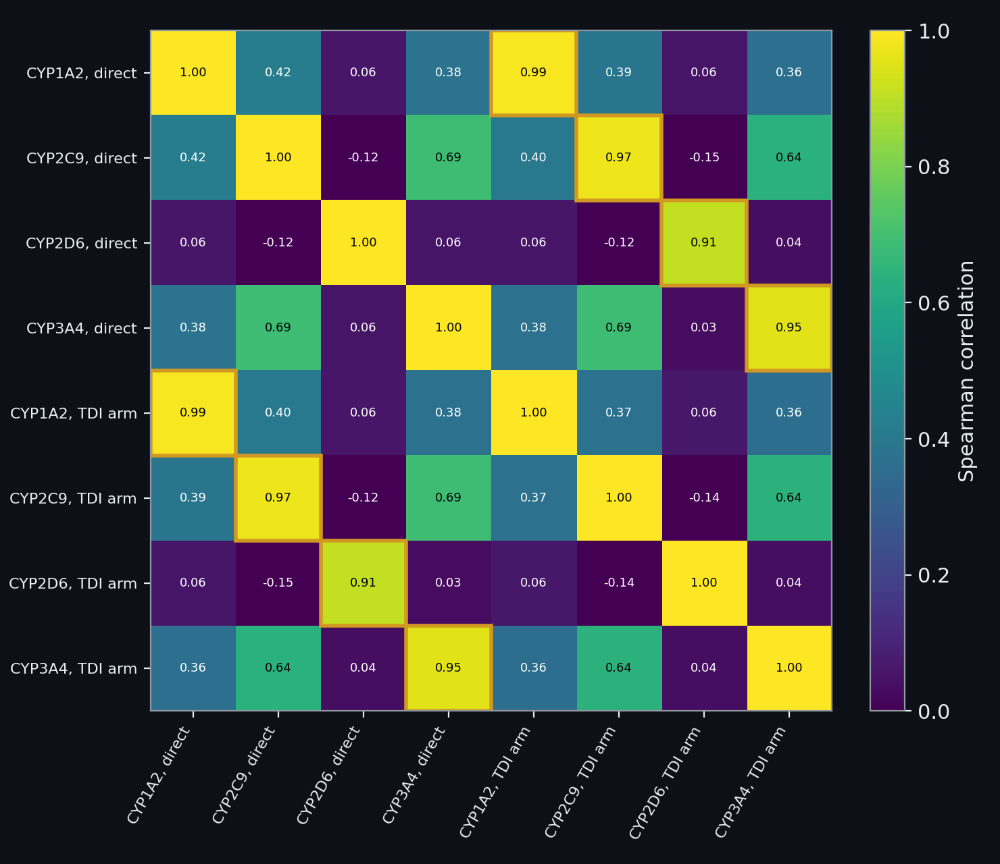

**Figure: How the assay arms of the four enzymes correlate.** The correlation (Spearman) between the pIC50 of the assay arms of the four enzymes, over the training compounds that have both values. The two arms of one enzyme (ringed) correlate at 0.91 to 0.99: a compound that inhibits an enzyme directly almost always inhibits it after pre-incubation too, which is why the label is a small difference of two large and correlated numbers. CYP1A2, CYP2C9 and CYP3A4 share inhibitors (the direct arms correlate at 0.38 to 0.69), while CYP2D6 correlates with none of them (at most 0.12 in absolute value). That is the basis of the cross-isoform transfer of section 9.7, which did not pass its gate, and the reason the transfer could not help CYP2D6, the enzyme that needed it.

In [232]:
show_figure("data_arm_correlations")

## 9.8 Training on label confidence

> **Field:** Statistics · Machine learning

*Where this section sits:* 6.4 restricted the *score* to compounds whose label is assigned with confidence, because the challenge does the same. This section asks the natural follow-up: should the *model* be trained that way too? A label close to the threshold is nearly a coin flip, and training on it adds noise. The experiment was pre-registered: the candidates and the rule (an improvement counts only if the corrected p-value is below 0.05 at both cut-offs for the enzyme it is claimed for) were fixed before any variant was run (`cypmode/challenge/confidence_experiment.py`).

**The two variants.** With $z_i$ the confidence of section 2.5, the distance of the shift of training row $i$ from the threshold $\log_{10} 2$ in units of the standard deviation of that shift (computed from the standard deviations of the two arms), the deep LightGBM is fitted (a) only on the rows with $|z_i| \ge 1$ (`cdrop10`), or (b) on every row weighted by $|z_i|/2$, limited to the range 0.1 to 1 (`csoft`): a row whose label is within one standard deviation of the threshold counts for half or less, and one beyond two standard deviations for the whole. A row with no value of $z$ (its TDI arm was not measured) is dropped by the first variant and gets the weight 0.1 in the second. The cell counts what each does to the rows and reads the nested comparison, on feature sets A and A+fps, for both enzymes.

In [233]:
# Training on label confidence (cypmode/challenge/confidence_experiment.py, label_confidence.py). The official score counts only the compounds whose label is assigned with confidence; the project's yardstick (6.4) does the same. Does it
# help to train that way too? Two variants of the deep LightGBM on feature sets A and A+fps, with |z| computed from each training row's own measurement noise: "cdrop10" trains only on rows with |z| >= 1, "csoft" on every row
# weighted by min(1, |z| / 2). The cell counts what each variant does to the training rows and reads the nested comparison with the plain model.
from cypmode.challenge.label_confidence import training_weights

confidence_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    z_iso = confidence_z(train_file, iso)
    z_pool = z_iso[~np.isnan(z_iso)]
    keep, weight = training_weights(z_iso[~np.isnan(z_iso)], "drop1.0")
    soft_keep, soft_weight = training_weights(z_iso[~np.isnan(z_iso)], "soft")
    confidence_rows.append({"enzyme": iso, "labelled compounds with a z": len(z_pool), "dropped by cdrop10 (|z| < 1)": float(1 - keep.mean()), "mean weight under csoft": float(soft_weight[soft_keep].mean()), "share of rows with weight 1 under csoft": float((soft_weight[soft_keep] >= 1.0).mean())})
confidence_table = pd.DataFrame(confidence_rows)
show_table(confidence_table, floatfmt=".3f")
PAIR_CONF = re.compile(r"z0=(\d\.\d+)\s+(\S+)\s+vs plain: AUC ([\d.]+) -> ([\d.]+) \(([+-][\d.]+), p=([\d.]+), better (\d+)/(\d+)\)")
conf_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    path = LOGS9 / f"confidence_{iso}_r3.log"
    if path.exists():
        for z0, name, before, after, gain, p, k, n in PAIR_CONF.findall(path.read_text(errors="ignore")):
            conf_rows.append({"enzyme": iso, "z0": float(z0), "variant": name, "AUC plain": float(before), "AUC variant": float(after), "gain": float(gain), "p (corrected t)": float(p), "folds better": f"{k} of {n}"})
conf_results = pd.DataFrame(conf_rows)
show_table(conf_results, floatfmt=".4f")
conf_largest = float(conf_results["gain"].abs().max()) if len(conf_results) else np.nan
conf_smallest_p = float(conf_results["p (corrected t)"].min()) if len(conf_results) else np.nan
conf_best = conf_results.sort_values("gain", ascending=False).iloc[0] if len(conf_results) else None

| enzyme | labelled compounds with a z | dropped by cdrop10 (|z| < 1) | mean weight under csoft | share of rows with weight 1 under csoft |
| --- | --- | --- | --- | --- |
| CYP3A4 | 3583 | 0.118 | 0.878 | 0.722 |
| CYP2D6 | 1497 | 0.245 | 0.752 | 0.499 |

| enzyme | z0 | variant | AUC plain | AUC variant | gain | p (corrected t) | folds better |
| --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 1.0000 | lgbm_A_deep_cdrop10 | 0.7850 | 0.7848 | -0.0002 | 0.9780 | 8 of 15 |
| CYP3A4 | 1.0000 | lgbm_A_deep_csoft | 0.7850 | 0.7873 | 0.0022 | 0.7400 | 9 of 15 |
| CYP3A4 | 1.0000 | lgbm_A+fps_deep_cdrop10 | 0.8027 | 0.7986 | -0.0041 | 0.5750 | 6 of 15 |
| CYP3A4 | 1.0000 | lgbm_A+fps_deep_csoft | 0.8027 | 0.8041 | 0.0014 | 0.7970 | 9 of 15 |
| CYP3A4 | 1.9600 | lgbm_A_deep_cdrop10 | 0.8192 | 0.8190 | -0.0002 | 0.9810 | 7 of 15 |
| CYP3A4 | 1.9600 | lgbm_A_deep_csoft | 0.8192 | 0.8232 | 0.0039 | 0.5120 | 9 of 15 |
| CYP3A4 | 1.9600 | lgbm_A+fps_deep_cdrop10 | 0.8354 | 0.8330 | -0.0024 | 0.7370 | 6 of 15 |
| CYP3A4 | 1.9600 | lgbm_A+fps_deep_csoft | 0.8354 | 0.8368 | 0.0014 | 0.8040 | 9 of 15 |
| CYP2D6 | 1.0000 | lgbm_A_deep_cdrop10 | 0.6964 | 0.7059 | 0.0095 | 0.6010 | 8 of 15 |
| CYP2D6 | 1.0000 | lgbm_A_deep_csoft | 0.6964 | 0.7072 | 0.0108 | 0.5250 | 9 of 15 |
| CYP2D6 | 1.0000 | lgbm_A+fps_deep_cdrop10 | 0.7185 | 0.7347 | 0.0162 | 0.3220 | 10 of 15 |
| CYP2D6 | 1.0000 | lgbm_A+fps_deep_csoft | 0.7185 | 0.7250 | 0.0065 | 0.6180 | 9 of 15 |
| CYP2D6 | 1.9600 | lgbm_A_deep_cdrop10 | 0.7267 | 0.7435 | 0.0167 | 0.5080 | 9 of 15 |
| CYP2D6 | 1.9600 | lgbm_A_deep_csoft | 0.7267 | 0.7488 | 0.0221 | 0.2710 | 11 of 15 |
| CYP2D6 | 1.9600 | lgbm_A+fps_deep_cdrop10 | 0.7396 | 0.7509 | 0.0113 | 0.5600 | 10 of 15 |
| CYP2D6 | 1.9600 | lgbm_A+fps_deep_csoft | 0.7396 | 0.7479 | 0.0083 | 0.6230 | 10 of 15 |

Dropping the rows with $|z| < 1$ removes 11.8% of the CYP3A4 training rows and 24.5% of the CYP2D6 rows, and the soft weighting has a mean weight of 0.88 and 0.75. The comparison finds no effect that survives the rule. For CYP3A4 the changes of the AUC are within 0.0041 of zero. For CYP2D6 all 8 of the 8 comparisons are positive, up to +0.0221, and their corrected p-values are between 0.27 and 0.62. A consistent sign with p-values this large is what a small true effect looks like when the design cannot see it, and also what noise looks like when the eight comparisons are correlated (they share the same folds and nearly the same models), so that the eight signs are not eight independent votes. The pre-registered rule is not met for either enzyme, and the variants are not part of the model.

*On what actually ran.* `cypmode/challenge/confidence_experiment.py` (the candidates `lgbm_{A,A+fps}_deep_{cdrop10,csoft}`, the pairs, the corrected t), `label_confidence.py` (`confidence_z`, `training_weights`) and the logs `confidence_<enzyme>_r3.log`, written by the run scripts `scripts/run_tdi_then_structure.sh`, `scripts/run_tdi_power_then_structure.sh` and `scripts/run_tdi_context_then_structure.sh`. The same experiment script holds a second family of candidates that add the alert-context block (`tdi_alert_context`) to the feature sets; its result is in `context_<enzyme>_r3.log`. Neither experiment has a gate line, so neither is among the 187 verdicts of the ledger of 9.11; both are listed with their numbers in section 4.7 of the method report.

## 9.9 The neural pair: a multitask network and plain Chemprop

> **Field:** Machine learning · Statistics

*Where this section sits:* 4.7 and 4.8 taught the two kinds of network that appear here; 6.7 fixed the rule an addition must meet (the gate) and the replicate that confirms it; 8.1 defined the stack of 23 members to which every addition is added. This section is the one case in Part IX, apart from the selection-aware model of 9.1 (which answers a different question), in which an addition cleared the gate, and the only one in which the gate had to be repeated.

**The two members.** The 23 members of the default stack are tree ensembles, nearest-neighbour models and support vector machines on the Tanimoto kernel (8.1); none is a neural network. Two networks were added to it, each in the way the data suggest. The **multitask network** reads the logarithm of the Morgan counts and the RDKit descriptors, each descriptor transformed so that its values follow a normal distribution (a quantile transformation fitted on the training rows). It passes them through a shared trunk of two layers of 1,024 and 512 units (4.7: batch normalisation, ReLU, dropout 0.35) and ends in nine heads: one regression head for each assay arm (the direct and the TDI pIC50 of the four enzymes, eight in all; the loss ignores the arms that a compound lacks) and one classification head for the label of the enzyme in question. It is trained for 60 epochs with AdamW and a one-cycle learning rate, three seeds are averaged, and it gives two scores, the probability of the label and the predicted shift $\hat t - \max(\hat d, 4)$. **Plain Chemprop** is the directed message-passing network of 4.8 on the molecular graph, multitask over the same eight arms, trained for 30 epochs with a tenth of its training rows held out to stop it early, and scored by the predicted shift. "Plain" distinguishes it from the CheMeleon variant, which starts from pretrained weights and has its own staged design (9.10). Both networks learn from the arms of all four enzymes while predicting one: the information that 9.7 offered the tree models as predicted features, without effect, enters here as extra targets that shape one shared representation.

The first cell reads what each score achieved alone (the diagnostic lines of the experiment logs) and how closely each agrees in ranking with the best single tree model of the default stack, `lgbm_A+fps_deep`, on the outer folds of the main design (the rank correlation of 4.10, averaged over the folds). A member can add to a stack only if it does not repeat the members already there, and a rank correlation well below 1 is the first sign that it does not.

In [234]:
# The members of the neural pair as the nested design holds them. The multitask network (cypmode/challenge/nested_runners_torch.py, fit_predict_multitask) reads the logarithm of the Morgan counts and the quantile-normalised
# descriptors, passes them through a shared trunk of two layers (1,024 and 512 units, batch normalisation, ReLU, dropout 0.35), and has one regression head per assay arm (the direct and the TDI pIC50 of the four enzymes, a missing
# value masked out of the loss) and one classification head for the label; it is trained for 60 epochs with AdamW and a one-cycle learning rate, three seeds averaged, and gives two scores: the label probability and the predicted
# shift t_hat - max(d_hat, 4) of the target enzyme. Plain Chemprop (cypmode/challenge/nested_runners_chemprop.py) is the message-passing network of 4.8 on the molecular graph, multitask over the same eight arms, 30 epochs, with
# 10 percent of its training rows held out for early stopping, scored by the predicted shift. The cell reads what each gave alone (the diagnostic lines of the logs) and how closely each agrees in ranking with the best single
# tree model of the default stack, lgbm_A+fps_deep, on the outer folds of the main design: a member can add to a stack only if it does not simply repeat the members that are already there.
from scipy import stats

member_stems = {"mlp_multitask_label": "aux_mlp", "mlp_multitask_shift": "aux_mlp", "chemprop_mt_shift": "aux_chemprop"}
reference_member = "lgbm_A+fps_deep"
def mean_fold_spearman(cache, plan, name_a, name_b):
    values = []
    for repeat, outer in plan.outer_folds():
        task = plan.task(repeat, outer, OUTER_REFIT)
        values.append(stats.spearmanr(cache.get(name_a, task), cache.get(name_b, task))[0])
    return float(np.mean(values))
member_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    plan_i, cache_i = setups8[iso][0], setups8[iso][1]
    for name, stem in member_stems.items():
        diag = read_gate_log(stem, iso)["diagnostic"]
        auc = diag[diag["candidate"] == name].set_index("z0")["outer AUC alone"]
        other = "chemprop_mt_shift" if name != "chemprop_mt_shift" else "mlp_multitask_shift"
        member_rows.append({"enzyme": iso, "member": name, "outer AUC alone at z0 1.0": float(auc.loc[1.0]), "outer AUC alone at z0 1.96": float(auc.loc[1.96]),
                            "rank correlation with lgbm_A+fps_deep": mean_fold_spearman(cache_i, plan_i, name, reference_member), "rank correlation with " + other: mean_fold_spearman(cache_i, plan_i, name, other)})
member_table = pd.DataFrame(member_rows)
show_table(member_table, floatfmt=".3f")

| enzyme | member | outer AUC alone at z0 1.0 | outer AUC alone at z0 1.96 | rank correlation with lgbm_A+fps_deep | rank correlation with chemprop_mt_shift | rank correlation with mlp_multitask_shift |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | mlp_multitask_label | 0.768 | 0.795 | 0.777 | 0.453 | nan |
| CYP3A4 | mlp_multitask_shift | 0.796 | 0.824 | 0.730 | 0.631 | nan |
| CYP3A4 | chemprop_mt_shift | 0.741 | 0.769 | 0.556 | nan | 0.631 |
| CYP2D6 | mlp_multitask_label | 0.717 | 0.744 | 0.622 | 0.152 | nan |
| CYP2D6 | mlp_multitask_shift | 0.688 | 0.718 | 0.485 | 0.205 | nan |
| CYP2D6 | chemprop_mt_shift | 0.544 | 0.531 | 0.093 | nan | 0.205 |

On CYP3A4 the multitask network's shift score ranks with an AUC of 0.796 at $z_0 = 1.0$ and 0.824 at $z_0 = 1.96$, its label score with 0.768 and 0.795, and plain Chemprop with 0.741 and 0.769. The scores agree with the tree model in rank at 0.73 (the network's shift), 0.78 (its label) and 0.56 (Chemprop), and the two networks with each other at 0.63. Plain Chemprop is the member that differs most from the trees, and it is also the weakest alone. On CYP2D6 it is hardly better than chance (an AUC of 0.544 and 0.531, a rank correlation of 0.09 with the trees), whereas the network's label score reaches 0.717 and 0.744.

The second cell is the gate of the main design: each network added to the default stack, and the two together, with the corrected resampled t of 6.5.

In [235]:
# The gate of the main design for each member alone added to the default stack, and for the pair, both enzymes, read from the logs of the experiments (aux_mlp, aux_chemprop, aux_neural). Every figure is the paired change in
# the outer-fold AUC of "default stack plus the addition" against "default stack", with the corrected resampled t of 6.5 (J = 15 folds); AP is the average precision of the same comparison.
AP_LINE = re.compile(r"z0=(\d\.\d+)\s+stacked base\+added vs base: AUC [+-][\d.]+ \(p=[\d.]+, better \d+/\d+\) AP ([+-][\d.]+) \(p=([\d.]+)")
gate_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    for label, stem in (("multitask network", "aux_mlp"), ("plain Chemprop", "aux_chemprop"), ("the pair", "aux_neural")):
        result = read_gate_log(stem, iso)
        stacked = result["stacked"].set_index("z0")
        ap = {float(z): (float(g), float(p)) for z, g, p in AP_LINE.findall((LOGS9 / f"{stem}_{iso}.log").read_text(errors="ignore"))}
        gate_rows.append({"enzyme": iso, "addition": label, "AUC gain at z0 1.0": float(stacked.loc[1.0, "gain"]), "p at z0 1.0": float(stacked.loc[1.0, "p"]), "folds better at z0 1.0": stacked.loc[1.0, "better"],
                          "AUC gain at z0 1.96": float(stacked.loc[1.96, "gain"]), "p at z0 1.96": float(stacked.loc[1.96, "p"]), "AP gain at z0 1.0": ap[1.0][0], "gate": "MET" if result["verdicts"].get("stacked") else "NOT MET"})
gate_table = pd.DataFrame(gate_rows)
show_table(gate_table, floatfmt=".4f")
def gate_row(iso, label):
    return gate_table[(gate_table["enzyme"] == iso) & (gate_table["addition"] == label)].iloc[0]
mlp_3a4, chemprop_3a4, pair_3a4, pair_2d6 = gate_row("CYP3A4", "multitask network"), gate_row("CYP3A4", "plain Chemprop"), gate_row("CYP3A4", "the pair"), gate_row("CYP2D6", "the pair")

| enzyme | addition | AUC gain at z0 1.0 | p at z0 1.0 | folds better at z0 1.0 | AUC gain at z0 1.96 | p at z0 1.96 | AP gain at z0 1.0 | gate |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | multitask network | 0.0077 | 0.0430 | 12 of 15 | 0.0072 | 0.0800 | 0.0206 | NOT MET |
| CYP3A4 | plain Chemprop | 0.0048 | 0.0760 | 12 of 15 | 0.0050 | 0.1310 | 0.0110 | NOT MET |
| CYP3A4 | the pair | 0.0106 | 0.0140 | 15 of 15 | 0.0106 | 0.0290 | 0.0288 | MET |
| CYP2D6 | multitask network | 0.0043 | 0.3610 | 10 of 15 | 0.0054 | 0.2300 | -0.0028 | NOT MET |
| CYP2D6 | plain Chemprop | 0.0016 | 0.8110 | 6 of 15 | -0.0009 | 0.8610 | 0.0031 | NOT MET |
| CYP2D6 | the pair | 0.0039 | 0.5690 | 9 of 15 | 0.0047 | 0.4150 | -0.0028 | NOT MET |

On CYP3A4 neither network clears the gate alone. The multitask network adds +0.0077 AUC (p = 0.043 at $z_0 = 1.0$ and 0.080 at 1.96) and plain Chemprop +0.0048 (p = 0.076 and 0.131); both are positive in 12 of 15 folds. They are near-misses, a gain that the design almost sees. Together they add +0.0106 AUC (p = 0.014 and 0.029 at the two cut-offs), positive in 15 of 15 folds at the first, with an average precision that rises by +0.0288. The gate is MET for the pair. The gain of the pair is a little less than the sum of the gains of the two (+0.0077 and +0.0048 make +0.0125), as expected when the two overlap in what they know, so that nothing in the pair is more than its parts: two contributions of the same sign, each too small for the design to separate from zero, add up to one that it can. On CYP2D6 the pair adds +0.0039 (p = 0.57); there is nothing to confirm.

**Why this result is not accepted as it stands.** The pair was not on the project's list of candidates before the results existed. It was formed after the two near-misses had been seen, because they pointed the same way. Choosing which candidates to combine after looking at how they did is a second round of selection that the p-value of the combination does not count, so that the p-values of the pair, 0.014 and 0.029, are those of the best of several possible groupings and are optimistic by an amount that cannot be computed. The project's rule for such a case, written into the final build as `CONFIRMED_GROUPS`, is that a group found after looking joins the stack only if a second, pre-declared design confirms it. The rule was declared on 2026-10-16, after the fifteen-fold result and before any ten-fold result existed, in the docstring of `cypmode/challenge/replicate_verdict.py`: the pair is compared with the default stack on the 10-outer-fold plan of 6.7 (30 folds, each model fitted on nine tenths of the compounds, the variance factor of the corrected t falling from $1/15 + 1/4 = 0.317$ to $1/30 + 1/9 = 0.144$); the replicate is MET only if the ten-fold comparison has p < 0.05 and a positive gain at both cut-offs and the five-fold comparison has a positive gain at both. It was declared for CYP3A4 only, because the pair showed nothing on CYP2D6. Filling the ten-fold caches is the costly step: plain Chemprop needs about 136 seconds for each of 155 tasks, on a processor.

In [236]:
# The replicate (cypmode/challenge/replicate_verdict.py): the same comparison on the 10-outer-fold plan, J = 30 folds, n_test / n_train = 1/9, so that the variance factor of the corrected t of 6.5 falls from 1/15 + 1/4 to
# 1/30 + 1/9. The rule, declared on 2026-10-16 after the fifteen-fold result and before any ten-fold one: corrected p < 0.05 and a positive mean AUC difference at both cut-offs in the ten-fold design, and a positive mean
# difference at both cut-offs in the five-fold design. Scope: CYP3A4 only (the pair showed nothing on CYP2D6, so no replicate was declared for it). The second table puts the discovery p-value of the pair among those of
# every stacked comparison logged for CYP3A4 (the replicate logs left out, since they repeat comparisons already in the family) and applies Holm's adjustment (6.5) to the whole family; the replicate is a single
# pre-declared test and is not part of that adjustment.
from cypmode.challenge.replicate_verdict import read_stacked, verdict
from statsmodels.stats.multitest import multipletests

five_fold = read_stacked(LOGS9 / "aux_neural_CYP3A4.log")
ten_fold = read_stacked(LOGS9 / "aux_neural_f10_CYP3A4.log")
ten_result = read_gate_log("aux_neural_f10", "CYP3A4")
replicate_met = verdict(five_fold, ten_fold)
AP10 = re.compile(r"z0=(\d\.\d+)\s+stacked base\+added vs base: AUC [+-][\d.]+ \(p=[\d.]+, better \d+/\d+\) AP ([+-][\d.]+) \(p=([\d.]+)")
ap_ten = {float(z): (float(g), float(p)) for z, g, p in AP10.findall((LOGS9 / "aux_neural_f10_CYP3A4.log").read_text(errors="ignore"))}
factor_five, factor_ten = 1 / 15 + 1 / 4, 1 / 30 + 1 / 9
replicate_rows = [{"design": "5 outer folds x 3 repeats (discovery)", "folds J": 15, "variance factor": factor_five, "AUC gain at z0 1.0": five_fold[1.0][0], "p at z0 1.0": five_fold[1.0][1], "AUC gain at z0 1.96": five_fold[1.96][0], "p at z0 1.96": five_fold[1.96][1]},
                   {"design": "10 outer folds x 3 repeats (replicate)", "folds J": 30, "variance factor": factor_ten, "AUC gain at z0 1.0": ten_fold[1.0][0], "p at z0 1.0": ten_fold[1.0][1], "AUC gain at z0 1.96": ten_fold[1.96][0], "p at z0 1.96": ten_fold[1.96][1]}]
replicate_table = pd.DataFrame(replicate_rows)
show_table(replicate_table, floatfmt=".4f")
better_ten = ten_result["stacked"].set_index("z0")["better"]

STACK_LINE = re.compile(r"z0=(1\.0|1\.96)\s+stacked base\+added vs base: AUC ([+-]\d\.\d+) \(p=([\d.]+)")
family_names, family_p = [], []
for path in sorted(LOGS9.glob("*CYP3A4.log")):
    if "_f10" in path.stem:
        continue  # a replicate repeats a comparison that is already in the family
    found = {z0: float(p) for z0, gain, p in STACK_LINE.findall(path.read_text(errors="ignore"))}
    if "1.0" in found and "1.96" in found:
        family_names.append(path.stem.removesuffix("_CYP3A4")), family_p.append(max(found["1.0"], found["1.96"]))
holm_p = multipletests(family_p, method="holm")[1]
pair_index = family_names.index("aux_neural")
n_family9 = len(family_p)
pair_raw_p, pair_holm_p = family_p[pair_index], float(holm_p[pair_index])
n_raw_below = int(sum(p < 0.05 for p in family_p))
print(f"replicate rule: {'MET' if replicate_met else 'NOT MET'}; the pair among {n_family9} logged stacked comparisons: raw p {pair_raw_p:.3f}, Holm-adjusted {pair_holm_p:.2f}; {n_raw_below} of the {n_family9} have a raw p below 0.05")

replicate rule: MET; the pair among 41 logged stacked comparisons: raw p 0.029, Holm-adjusted 1.00; 2 of the 41 have a raw p below 0.05


| design | folds J | variance factor | AUC gain at z0 1.0 | p at z0 1.0 | AUC gain at z0 1.96 | p at z0 1.96 |
| --- | --- | --- | --- | --- | --- | --- |
| 5 outer folds x 3 repeats (discovery) | 15 | 0.3167 | 0.0106 | 0.0140 | 0.0106 | 0.0290 |
| 10 outer folds x 3 repeats (replicate) | 30 | 0.1444 | 0.0109 | 0.0260 | 0.0115 | 0.0380 |

In [237]:
# What the final build of the TDI stack (cypmode/challenge/final_tdi_build.py) says about the pair: the groups that joined each enzyme's stack are written into its manifest. A group listed in CONFIRMED_GROUPS (the pair is the only
# one) joins only if its replicate verdict is MET as well, and a missing replicate line is a fail.
import json

from cypmode.challenge.final_tdi_build import CONFIRMED_GROUPS

manifest9 = json.loads((ROOT / "data/tdi_track/outputs/final/manifest.json").read_text())
joined_3a4 = manifest9["isoforms"]["CYP3A4"]["surviving_groups"]
n_members_3a4 = manifest9["isoforms"]["CYP3A4"]["n_candidates"]
if "neural" in joined_3a4:
    neural_stack_sentence = f"The final build of the TDI stack records the pair among the groups that joined the CYP3A4 stack, which has {n_members_3a4} members."
else:
    neural_stack_sentence = f"The final build of the TDI stack that this page was made from does not list the pair among the groups that joined the CYP3A4 stack (it has {n_members_3a4} members); the build reads every verdict again at its last run."
print(neural_stack_sentence, "| groups that need a replicate:", ", ".join(CONFIRMED_GROUPS))

The final build of the TDI stack records the pair among the groups that joined the CYP3A4 stack, which has 28 members. | groups that need a replicate: neural, pocket_cyp3a4, pocket_cyp2d6, site_cyp3a4, site_cyp2d6, hypothesis


The replicate rule is MET. In the ten-fold design the pair adds +0.0109 AUC at $z_0 = 1.0$ (p = 0.026, positive in 25 of 30 folds) and +0.0115 at $z_0 = 1.96$ (p = 0.038, 24 of 30 folds), with the average precision rising by +0.0280 and +0.0320. The size of the gain hardly changes between the two designs (+0.0106 and +0.0109) and the p-values are in the same range, which is what a real, small effect does and what a lucky partition would be unlikely to do. The last part of the cell sets the discovery in its family: of the 41 stacked comparisons logged for CYP3A4, 2 have a raw p below 0.05, and the pair's 0.029 becomes 1.00 after Holm's adjustment over all of them. Seen as the best of 41 tries, the pair would be nothing; seen as one hypothesis, stated before its test and passed, it is a result. The replicate is the second view, and it has a limit that should be stated plainly. The ten-fold plan cuts the *same* compounds into different folds. It protects against an unlucky or a lucky partition and it is a more powerful test (the variance factor halves); it does not protect against the compounds themselves, because an effect that exists in this sample by chance is in the ten-fold folds as well. Only compounds that the project has not seen can decide that, and the first of them are the 750 of the blinded set.

The pair therefore enters the CYP3A4 stack under the rule that was written for it, as an addition of a small and consistent gain (about one hundredth of an AUC) and not as an established improvement; the evidence for it is a pre-declared test that passed, with the caveats above. The final build of the TDI stack records the pair among the groups that joined the CYP3A4 stack, which has 28 members. The effect on the MCC at the call rate that the project transfers is reported with the final results, in Part XIII. CYP2D6 does not take the pair.

*On what actually ran.* `cypmode/challenge/nested_runners_torch.py` (`fit_predict_multitask`, the groups `mlp_multitask` and `mlp_multitask_aux`; the second is the version with the official screen and Emax readings as extra targets, which did not pass and appears in the ledger of 9.11), `cypmode/challenge/nested_runners_chemprop.py` (`fit_predict`, the variant `chemprop_mt_shift`, which calls the Chemprop command line under the neural-network environment), `cypmode/challenge/cached_candidates.py` (the group `neural`), `cypmode/challenge/aux_experiments.py` (the experiments `mlp`, `chemprop` and `neural`, run through `addition_experiment.py`), `cypmode/challenge/replicate_verdict.py` (the rule and its verdict lines) and `cypmode/challenge/final_tdi_build.py` (`CONFIRMED_GROUPS`). The queue jobs are `198_mlp_addition` (the multitask network added to the stack), `206_chemprop_addition` (plain Chemprop added to the stack), `232_neural_f10_fill_CYP3A4` (the ten-fold caches), `233_neural_addition` (the fifteen-fold addition for both enzymes), `234_neural_addition_f10` (the ten-fold addition) and `235_neural_replicate_verdict` (the verdict). The logs are `aux_mlp_<enzyme>.log`, `aux_chemprop_<enzyme>.log`, `aux_neural_<enzyme>.log`, `aux_neural_f10_CYP3A4.log` and `replicate_verdict_<enzyme>.log`.

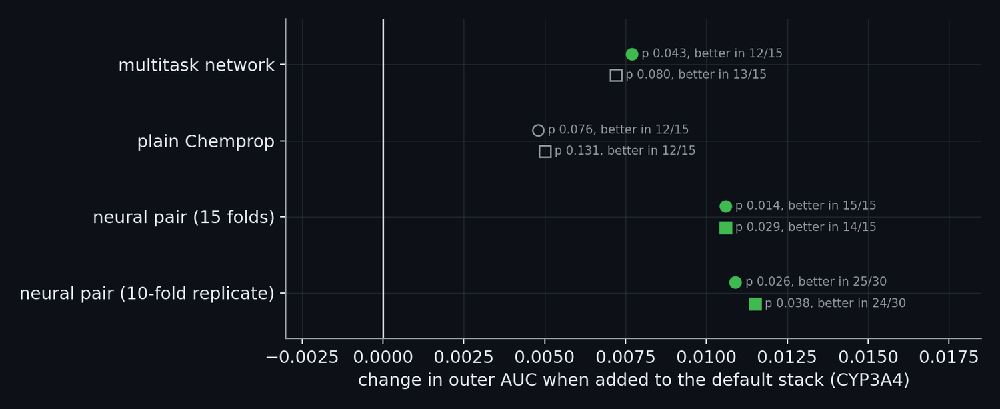

**Figure: Two near-misses and the pair that joined them.** The change in outer AUC when a candidate is added to the default stack on CYP3A4, at the two confidence cuts (circle z0 = 1.0, square 1.96). The multitask network and plain Chemprop each came close to the gate and missed it; their pair, a group formed after seeing that, gives +0.0106 AUC (p 0.014) and +0.0106 (p 0.029). A group found after looking is a discovery, not a verdict: the pre-declared confirmation is the 10-fold replicate, and the replicate on the 10-outer-fold plan gives +0.0109 (p 0.026) and +0.0115 (p 0.038). Filled green markers pass (p < 0.05 and a positive gain at the same cut).

In [238]:
show_figure("ml_neural_pair")

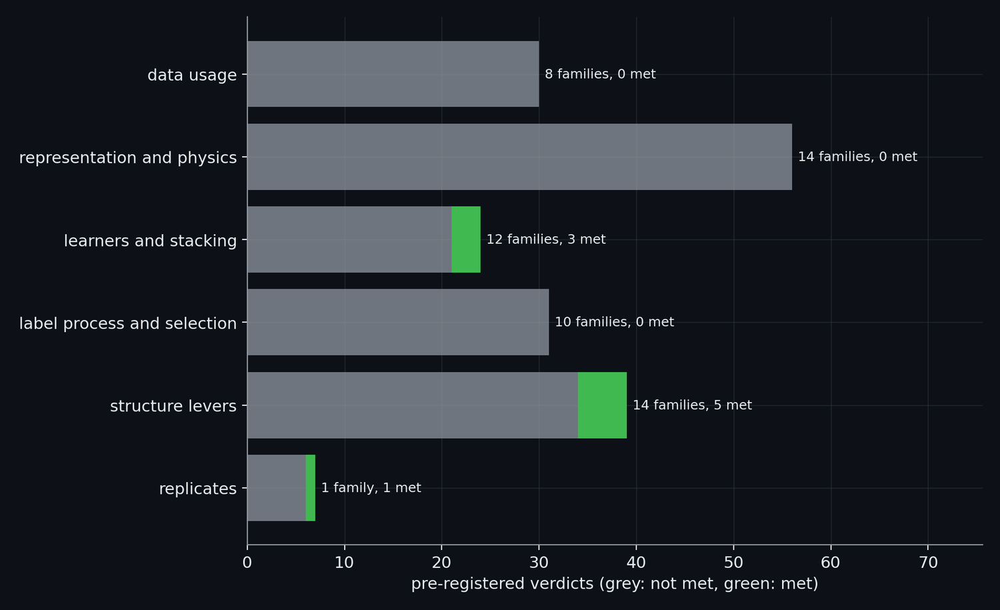

**Figure: What was explored: the ledger by kind of idea.** Every pre-registered verdict of the ledger, grouped by the kind of idea it tested: 187 verdicts in 59 families (data usage: 30 verdicts in 8 families, 0 met; label process and selection: 31 verdicts in 10 families, 0 met; learners and stacking: 24 verdicts in 12 families, 3 met; replicates: 7 verdicts in 1 family, 1 met; representation and physics: 56 verdicts in 14 families, 0 met; structure levers: 39 verdicts in 14 families, 5 met). The search was wide before it was deep: new data (the screen, the Emax, the induction readings, public panels), new representations (pretrained embeddings, physics at four levels), new learners, a model of how the labels came to be, and levers of the structure recipe, each judged by the rule written before its result. Ideas that passed are green; the grey ones stay in the ledger as results. No reinforcement-learning or evolutionary search is used: the exploration is a designed, auditable programme of experiments, not an optimiser.

In [239]:
show_figure("ml_exploration_map")

## 9.10 The other additions, tested the same way

> **Field:** Machine learning · Cheminformatics · Biology

*Where this section sits:* 9.4 to 9.9 took one idea each and followed it through a section. The additions of this one were put through the same procedure (the nested design of 6.3, the stack of 23 members of 8.1, and the gate of 6.7: a positive gain with a corrected p below 0.05 at both confidence cut-offs), on both enzymes, and each of them would have needed a section of its own had it passed. None has, so far, and the ledger of 9.11 counts them. They fall into five families: models pretrained by others on very large collections, which serve here as sources of features; measurements from outside the challenge; the organisers' extra readings of the challenge's own compounds; a block of chemistry written for CYP2D6; and two changes to the blend itself, which add no member to the stack.

The table below gives every verdict at once. It is built from the logs of the experiments when the page is built: an addition whose queue job had not finished at that moment shows "not run yet", and the text says so. The columns are the change of the AUC of the whole stack when the addition joins it, at the two cut-offs, with the corrected resampled t of 6.5 (15 folds), and the verdict of the gate. In the sentences below a change is given in the same order: the value at $z_0 = 1.0$ with its p-value, then the value at $z_0 = 1.96$ with its p-value.

In [240]:
# The remaining additions of Part IX, read the way 9.9 read the neural pair: one log per addition and enzyme, whose lines give the paired change of the outer-fold AUC when the addition joins the default stack (corrected
# resampled t, J = 15 folds, 6.5) at the two confidence cut-offs, and a last line with the verdict of the pre-declared gate. The two selectors (an alternative to the logistic blend, not a new member) report the change of the
# AUC of the whole stack when the blend is replaced. A log that does not exist yet is shown as "not run yet": the table is built from whatever the queue has finished when the page is built.
SELECTOR_LINE = re.compile(r"z0=(\d\.\d+)\s+outer AUC: logistic blend [\d.]+, [\w-]+ blend [\d.]+ \(([+-][\d.]+), p=([\d.]+), better (\d+)/(\d+)\)")
SCREEN_LINE = re.compile(r"z0=(\d\.\d+)\s+stacked with the screen vs without: AUC ([+-][\d.]+) \(p=([\d.]+), better (\d+)/(\d+)\)")
VERDICT_LINE = re.compile(r"^(CYP\w+) GATE \((?:stacked|selector|population screen stacked)[^)]*\): (MET|NOT MET)", re.M)

ADDITION_LIST = [
    ("pretrained tables and representations", "TabICL on the descriptors and counts", "aux_tabicl", "added"),
    ("pretrained tables and representations", "TabPFN on the same inputs", "aux_tabpfn", "added"),
    ("pretrained tables and representations", "Monroe embeddings as a block", "monroe_embeddings", "added"),
    ("pretrained tables and representations", "TabICL on the Monroe embeddings", "aux_tabicl_monroe", "added"),
    ("pretrained tables and representations", "TabICL on the frozen CheMeleon embeddings", "aux_tabicl_chemeleon", "added"),
    ("pretrained tables and representations", "TabPFN on the frozen CheMeleon embeddings", "aux_tabpfn_chemeleon", "added"),
    ("pretrained tables and representations", "Atom-JEPA embeddings as a block", "aux_atomjepa", "added"),
    ("pretrained tables and representations", "Atom-JEPA attention readout on the atoms", "aux_atomjepa_head", "added"),
    ("pretrained tables and representations", "CheMeleon, fine-tuned (staged)", "aux_chemeleon", "added"),
    ("pretrained tables and representations", "OpenADMET pretraining weights, fine-tuned (staged)", "aux_chemprop_foundation", "added"),
    ("measurements from outside the challenge", "NCATS qHTS, continuous responses", "aux_ext_cont", "added"),
    ("measurements from outside the challenge", "Tox21 CYP screen", "aux_ext_tox", "added"),
    ("measurements from outside the challenge", "OpenADMET logD and protein-binding models", "aux_ext_adme", "added"),
    ("measurements from outside the challenge", "PXR induction readings", "aux_pxr", "added"),
    ("the organisers' extra readings", "single-concentration screen, as a predicted block", "aux_screen", "added"),
    ("the organisers' extra readings", "maximal effect (Emax), as a predicted block", "aux_emax", "added"),
    ("the organisers' extra readings", "screen inside the selection-aware CYP2D6 model", "population_screen", "screen"),
    ("the organisers' extra readings", "multitask network with the screen and Emax as extra targets", "aux_mlp_aux", "added"),
    ("the organisers' extra readings", "the 1,249 compounds without a direct curve", "aux_nodirect", "added"),
    ("the organisers' extra readings", "the label in two parts (gate and shift)", "aux_gate_shift", "added"),
    ("chemistry", "basic-centre block", "aux_basic_centre", "added"),
    ("the blend itself", "non-negative blend instead of the logistic blend", "nonneg_stack", "selector"),
    ("the blend itself", "softmax blend instead of the logistic blend", "softmax_selector", "selector"),
]

def read_addition(stem, iso, kind):
    path = LOGS9 / f"{stem}_{iso}.log"
    if not path.exists():
        return None
    text = path.read_text(errors="ignore")
    pattern = {"added": STACKED_LINE, "selector": SELECTOR_LINE, "screen": SCREEN_LINE}[kind]
    found = {float(m[0]): (float(m[1]), float(m[2])) for m in pattern.findall(text)}
    verdicts = {iso_found: verdict == "MET" for iso_found, verdict in VERDICT_LINE.findall(text)}
    if len(found) < 2:
        return None
    return {"gain1": found[1.0][0], "p1": found[1.0][1], "gain2": found[1.96][0], "p2": found[1.96][1], "gate": "MET" if verdicts.get(iso) else "NOT MET"}

addition_rows = []
for family, label, stem, kind in ADDITION_LIST:
    for iso in ("CYP3A4", "CYP2D6"):
        result = read_addition(stem, iso, kind)
        row = {"family": family, "addition": label, "enzyme": iso}
        if result is None:
            row.update({"AUC change at z0 1.0": np.nan, "p at z0 1.0": np.nan, "AUC change at z0 1.96": np.nan, "p at z0 1.96": np.nan, "gate": "not run yet"})
        else:
            row.update({"AUC change at z0 1.0": result["gain1"], "p at z0 1.0": result["p1"], "AUC change at z0 1.96": result["gain2"], "p at z0 1.96": result["p2"], "gate": result["gate"]})
        addition_rows.append(row)
addition_table = pd.DataFrame(addition_rows)
# the screen model and the no-direct experiment exist for one enzyme only
addition_table = addition_table[~((addition_table["addition"].str.contains("selection-aware")) & (addition_table["enzyme"] == "CYP3A4"))]
addition_table = addition_table[~((addition_table["addition"].str.contains("without a direct curve")) & (addition_table["enzyme"] == "CYP2D6"))]
show_table(addition_table.drop(columns="family"), floatfmt=".4f")
n_tests_9 = int((addition_table["gate"] != "not run yet").sum())
n_met_9 = int((addition_table["gate"] == "MET").sum())
n_pending_9 = int((addition_table["gate"] == "not run yet").sum())
best_gain_9 = addition_table.loc[addition_table["AUC change at z0 1.0"].idxmax()]
def line_of(label, iso):
    r = addition_table[(addition_table["addition"].str.startswith(label)) & (addition_table["enzyme"] == iso)]
    if r.empty or r.iloc[0]["gate"] == "not run yet":
        return "not run when this page was built"
    r = r.iloc[0]
    return f"{r['AUC change at z0 1.0']:+.4f} (p = {r['p at z0 1.0']:.2f}) and {r['AUC change at z0 1.96']:+.4f} (p = {r['p at z0 1.96']:.2f}), gate {r['gate']}"

| addition | enzyme | AUC change at z0 1.0 | p at z0 1.0 | AUC change at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- | --- |
| TabICL on the descriptors and counts | CYP3A4 | 0.0001 | 0.9450 | 0.0003 | 0.7790 | NOT MET |
| TabICL on the descriptors and counts | CYP2D6 | -0.0008 | 0.7240 | 0.0018 | 0.4840 | NOT MET |
| TabPFN on the same inputs | CYP3A4 | 0.0012 | 0.3880 | 0.0013 | 0.4090 | NOT MET |
| TabPFN on the same inputs | CYP2D6 | 0.0007 | 0.6880 | 0.0024 | 0.6170 | NOT MET |
| Monroe embeddings as a block | CYP3A4 | 0.0031 | 0.1710 | 0.0041 | 0.1230 | NOT MET |
| Monroe embeddings as a block | CYP2D6 | -0.0034 | 0.7190 | 0.0031 | 0.3210 | NOT MET |
| TabICL on the Monroe embeddings | CYP3A4 | 0.0018 | 0.3310 | 0.0017 | 0.3980 | NOT MET |
| TabICL on the Monroe embeddings | CYP2D6 | -0.0027 | 0.7780 | 0.0010 | 0.7910 | NOT MET |
| TabICL on the frozen CheMeleon embeddings | CYP3A4 | -0.0004 | 0.7260 | 0.0001 | 0.9310 | NOT MET |
| TabICL on the frozen CheMeleon embeddings | CYP2D6 | -0.0015 | 0.6350 | 0.0004 | 0.9140 | NOT MET |
| TabPFN on the frozen CheMeleon embeddings | CYP3A4 | 0.0024 | 0.2640 | 0.0012 | 0.6280 | NOT MET |
| TabPFN on the frozen CheMeleon embeddings | CYP2D6 | -0.0013 | 0.7460 | 0.0014 | 0.7370 | NOT MET |
| Atom-JEPA embeddings as a block | CYP3A4 | 0.0012 | 0.5410 | 0.0009 | 0.6140 | NOT MET |
| Atom-JEPA embeddings as a block | CYP2D6 | -0.0069 | 0.4920 | -0.0051 | 0.4070 | NOT MET |
| Atom-JEPA attention readout on the atoms | CYP3A4 | 0.0107 | 0.0280 | 0.0081 | 0.0590 | NOT MET |
| Atom-JEPA attention readout on the atoms | CYP2D6 | -0.0029 | 0.7780 | 0.0015 | 0.9120 | NOT MET |
| CheMeleon, fine-tuned (staged) | CYP3A4 | nan | nan | nan | nan | not run yet |
| CheMeleon, fine-tuned (staged) | CYP2D6 | nan | nan | nan | nan | not run yet |
| OpenADMET pretraining weights, fine-tuned (staged) | CYP3A4 | 0.0133 | 0.0020 | 0.0144 | 0.0050 | MET |
| OpenADMET pretraining weights, fine-tuned (staged) | CYP2D6 | nan | nan | nan | nan | not run yet |
| NCATS qHTS, continuous responses | CYP3A4 | 0.0008 | 0.4280 | 0.0004 | 0.7250 | NOT MET |
| NCATS qHTS, continuous responses | CYP2D6 | -0.0037 | 0.6600 | -0.0007 | 0.6190 | NOT MET |
| Tox21 CYP screen | CYP3A4 | -0.0003 | 0.7140 | -0.0011 | 0.2380 | NOT MET |
| Tox21 CYP screen | CYP2D6 | -0.0053 | 0.5460 | 0.0023 | 0.4560 | NOT MET |
| OpenADMET logD and protein-binding models | CYP3A4 | 0.0012 | 0.5710 | 0.0024 | 0.3990 | NOT MET |
| OpenADMET logD and protein-binding models | CYP2D6 | -0.0034 | 0.6770 | 0.0026 | 0.4740 | NOT MET |
| PXR induction readings | CYP3A4 | 0.0006 | 0.6900 | 0.0001 | 0.9530 | NOT MET |
| PXR induction readings | CYP2D6 | -0.0010 | 0.7020 | 0.0006 | 0.8830 | NOT MET |
| single-concentration screen, as a predicted block | CYP3A4 | 0.0001 | 0.9160 | 0.0008 | 0.6070 | NOT MET |
| single-concentration screen, as a predicted block | CYP2D6 | -0.0045 | 0.5330 | 0.0009 | 0.8190 | NOT MET |
| maximal effect (Emax), as a predicted block | CYP3A4 | 0.0002 | 0.9080 | 0.0004 | 0.3760 | NOT MET |
| maximal effect (Emax), as a predicted block | CYP2D6 | -0.0021 | 0.6900 | -0.0001 | 0.9840 | NOT MET |
| screen inside the selection-aware CYP2D6 model | CYP2D6 | 0.0078 | 0.1270 | 0.0041 | 0.4190 | NOT MET |
| multitask network with the screen and Emax as extra targets | CYP3A4 | 0.0067 | 0.0760 | 0.0065 | 0.1030 | NOT MET |
| multitask network with the screen and Emax as extra targets | CYP2D6 | 0.0030 | 0.5430 | 0.0041 | 0.5260 | NOT MET |
| the 1,249 compounds without a direct curve | CYP3A4 | 0.0004 | 0.7760 | 0.0005 | 0.6550 | NOT MET |
| the label in two parts (gate and shift) | CYP3A4 | 0.0015 | 0.5350 | 0.0018 | 0.5880 | NOT MET |
| the label in two parts (gate and shift) | CYP2D6 | -0.0017 | 0.8530 | 0.0013 | 0.8500 | NOT MET |
| basic-centre block | CYP3A4 | 0.0005 | 0.5370 | 0.0013 | 0.3680 | NOT MET |
| basic-centre block | CYP2D6 | -0.0033 | 0.7050 | 0.0007 | 0.8310 | NOT MET |
| non-negative blend instead of the logistic blend | CYP3A4 | 0.0002 | 0.9340 | 0.0008 | 0.6860 | NOT MET |
| non-negative blend instead of the logistic blend | CYP2D6 | 0.0041 | 0.6880 | 0.0041 | 0.6980 | NOT MET |
| softmax blend instead of the logistic blend | CYP3A4 | -0.0071 | 0.1490 | -0.0020 | 0.6490 | NOT MET |
| softmax blend instead of the logistic blend | CYP2D6 | -0.0069 | 0.6760 | -0.0034 | 0.6820 | NOT MET |

41 comparisons have been run, 1 of them meet their gate, and 3 had not been run when this page was built. The largest change of the AUC at $z_0 = 1.0$ in the whole table is +0.0133 (OpenADMET pretraining weights, fine-tuned (staged), CYP3A4, p = 0.00); it is smaller than the least difference that the design recognises 8 times in 10 (6.7), so that it cannot be told from noise. The families follow, with what each addition is, why it was tried, and what was measured.

**Pretrained tables and representations.** Section 4.9 explained tabular in-context learning, and 9.4 a frozen foundation model. Five more of the same kind were tried, each as a source of features or as an extra member.

*TabICL and TabPFN.* Both are transformers pretrained on millions of artificial tables, which read a table of labelled rows together with the rows to be predicted and output the missing labels in one pass (4.9). TabICL was given the 128 components of the truncated SVD of the logarithm of the Morgan counts together with the quantile-normalised descriptors; TabPFN (Hollmann and co-workers) the same inputs. Change of the AUC when added to the stack: TabICL, CYP3A4 +0.0001 (p = 0.94) and +0.0003 (p = 0.78), gate NOT MET, CYP2D6 -0.0008 (p = 0.72) and +0.0018 (p = 0.48), gate NOT MET; TabPFN, CYP3A4 +0.0012 (p = 0.39) and +0.0013 (p = 0.41), gate NOT MET, CYP2D6 +0.0007 (p = 0.69) and +0.0024 (p = 0.62), gate NOT MET.

*Monroe.* Monroe (Banaszewski, arXiv 2608.18982) is a **graph transformer** of the GRIT kind (an attention network over the atoms of a molecule, whose attention is told where each atom sits in the graph) pretrained on two things: the properties of about 81 million molecules computed with a semi-empirical quantum-chemical method (PM6; 7.8 and 10.4), and sparse PubChem bioassay labels. It reads a three-dimensional conformer of the molecule, generated with RDKit's ETKDG method, and returns 720 numbers. The project wrote its own wrapper, which reads the weights as plain tensors (so that no code stored in the file can run) and checks that every tensor of the encoder is found and none is left over. The 720 numbers are reduced to 64 principal components for the tree models, as for CheMeleon, and to 128 for TabICL. Change of the AUC when added to the stack: the block, CYP3A4 +0.0031 (p = 0.17) and +0.0041 (p = 0.12), gate NOT MET, CYP2D6 -0.0034 (p = 0.72) and +0.0031 (p = 0.32), gate NOT MET; TabICL on the Monroe embeddings, CYP3A4 +0.0018 (p = 0.33) and +0.0017 (p = 0.40), gate NOT MET, CYP2D6 -0.0027 (p = 0.78) and +0.0010 (p = 0.79), gate NOT MET.

*Atom-JEPA.* A **joint-embedding predictive architecture** (JEPA) is pretrained not to rebuild its input but to predict, from one part of an input, the learned representation of another part, so that it learns what the parts say about each other rather than the details of their pixels or atoms. Atom-JEPA (the authors' code and weights are at `github.com/khelverskovp/atom-jepa` and `huggingface.co/atom-jepa/atom-jepa`) is an **equivariant** graph network over three-dimensional conformers (if the molecule is rotated, the vectors inside the network rotate with it, so that it need not learn every orientation separately), with 39.0 million parameters, pretrained on about 19 million conformers. The authors fine-tune the whole network. On this machine one optimiser step cost 7.4 seconds per molecule on the processor and the graphics processor ran out of memory at 16 molecules per batch, which makes one fine-tuning of the 3,500 training molecules of a task about three days and the nested design needs about 80 of them for each enzyme. What is affordable is one forward pass per molecule, about half a second on the graphics processor, so the encoder is **frozen** (its weights never change) and every one of its eight blocks is kept (the mean over atoms of the features of each block), because frozen features are usually best in the middle blocks. The same pass stores the features of every atom for blocks 4, 6 and 8, and a small attention readout (a network that learns which atoms matter for the label) is trained on them in seconds per fit: the affordable form of fine-tuning the top of the network. The forward pass and both caches are made by `cypmode/challenge/atomjepa_embeddings.py` (queue job 228), which keys them by canonical SMILES and saves its chunks as they finish, so that an interrupted run resumes where it stopped; the evaluation reads the cache and never imports the network library. Change of the AUC when added to the stack: the embeddings, CYP3A4 +0.0012 (p = 0.54) and +0.0009 (p = 0.61), gate NOT MET, CYP2D6 -0.0069 (p = 0.49) and -0.0051 (p = 0.41), gate NOT MET; the readout, CYP3A4 +0.0107 (p = 0.03) and +0.0081 (p = 0.06), gate NOT MET, CYP2D6 -0.0029 (p = 0.78) and +0.0015 (p = 0.91), gate NOT MET.

In [241]:
# The state of the staged CheMeleon design at the moment the page is built (cypmode/challenge/chemeleon_stage.py and chemeleon_speed.py). Stage 1 is the 25 cross-validation tasks of repeat 0 of an enzyme; the cell counts from the
# nested plan and its cache how many are done, reads the decision of the speed test (job 202_chemeleon_speed) if it exists, and what the stage rule says about the stage-1 comparison if that exists.
from cypmode.challenge import chemeleon_speed
from cypmode.challenge.chemeleon_stage import MIN_FOLDS as chemeleon_min_folds
from cypmode.challenge.chemeleon_stage import MIN_GAIN as chemeleon_min_gain
from cypmode.challenge.chemeleon_stage import decide as chemeleon_decide
from cypmode.challenge.nested import NestedPlan, PredictionCache

chemeleon_progress = {}
for iso in ("CYP3A4", "CYP2D6"):
    nested_root = ROOT / f"data/tdi_track/outputs/nested/{iso}"
    nested_plan = NestedPlan.load(nested_root / "plan.npz")
    nested_cache = PredictionCache(nested_root / "cache", nested_plan)
    stage_one_tasks = [task for task in nested_plan.tasks() if task.repeat == 0]
    chemeleon_progress[iso] = (sum(nested_cache.has("chemeleon_mt_shift", task) for task in stage_one_tasks), len(stage_one_tasks), len(nested_plan.tasks()))
n_stage_one, n_full_design = chemeleon_progress["CYP3A4"][1], chemeleon_progress["CYP3A4"][2]
cpu_minutes_per_task = chemeleon_speed.processor_seconds_per_task() / 60
stage_one_cpu_hours = n_stage_one * cpu_minutes_per_task / 60
speed_decision_file = ROOT / "data/tdi_track/outputs/comparisons/chemeleon_speed_decision.txt"
speed_json = ROOT / "data/tdi_track/outputs/comparisons/chemeleon_speed_CYP3A4.json"
done_3a4 = chemeleon_progress["CYP3A4"][0]
if not speed_decision_file.exists():
    chemeleon_sentence = f"The speed test had not been run when this page was built, and stage 1 for CYP3A4 had {done_3a4} of its {n_stage_one} tasks."
else:
    decision = speed_decision_file.read_text().strip()
    measured = json.loads(speed_json.read_text()) if speed_json.exists() else {}
    gpu_text = f"; the GPU took {measured['gpu_seconds'] / 60:.0f} minutes for the task that the processor had needed {measured['cpu_seconds_per_task'] / 60:.0f} minutes for (rank correlation {measured.get('spearman', float('nan')):.2f}, AUC difference {abs(measured.get('auc_gpu', 0) - measured.get('auc_cpu', 0)):.3f})" if measured.get("gpu_seconds") else ""
    stage_text = ""
    stage_file = ROOT / "data/structure_track/outputs/cyp3a4/logs/stage1_chemeleon_CYP3A4.txt"
    if decision in ("mps", "cpu") and stage_file.exists() and "stacked base+added" in stage_file.read_text():
        stage_text = f" Stage 1 has finished and the rule says {'CONTINUE' if chemeleon_decide(stage_file) else 'STOP'}."
    elif decision in ("mps", "cpu"):
        stage_text = f" Stage 1 is under way, with {done_3a4} of {n_stage_one} tasks done when this page was built."
    outcome = "the fine-tuned CheMeleon was not run, for cost (the ledger says 'not run: cost', which is not a verdict)" if decision == "not run: cost" else f"stage 1 for CYP3A4 runs on the {'Apple GPU' if decision == 'mps' else 'processor'}"
    chemeleon_sentence = f"The speed test found that the {n_stage_one - done_3a4 if decision == 'not run: cost' else measured.get('tasks_left', n_stage_one - done_3a4)} missing tasks would need {measured.get('hours_left_on_cpu', float('nan')):.1f} hours on the processor{gpu_text}, so {outcome}.{stage_text}"
print(chemeleon_sentence)

# The two OpenADMET pretraining weights follow the same two stages for CYP3A4 (queue jobs 255 to 258); their stage-1 screen is a text file as well.
cyp3a4_root = ROOT / "data/tdi_track/outputs/nested/CYP3A4"
cyp3a4_plan = NestedPlan.load(cyp3a4_root / "plan.npz")
cyp3a4_cache = PredictionCache(cyp3a4_root / "cache", cyp3a4_plan)
cyp3a4_stage_one = [task for task in cyp3a4_plan.tasks() if task.repeat == 0]
foundation_done = {name: sum(cyp3a4_cache.has(name, task) for task in cyp3a4_stage_one) for name in ("chemeleon_minimol_mt_shift", "chemeleon_surrogate_mt_shift")}
foundation_file = ROOT / "data/structure_track/outputs/cyp3a4/logs/stage1_chemprop_foundation_CYP3A4.txt"
foundation_pattern = re.compile(r"z0=1\.0\s+stacked base\+added vs base: AUC ([+-]\d\.\d+) \(p=([\d.]+), better (\d+)/(\d+)\)")
foundation_text = foundation_file.read_text() if foundation_file.exists() else ""
foundation_found = foundation_pattern.search(foundation_text)
if foundation_found:
    foundation_sentence = (f"For the two OpenADMET weights together, stage 1 has finished: added to the default stack they change the outer AUC of CYP3A4 by {float(foundation_found.group(1)):+.4f} at the first cut-off (corrected p {foundation_found.group(2)}, better in {foundation_found.group(3)} of {foundation_found.group(4)} folds), "
                           f"and the rule says {'CONTINUE' if chemeleon_decide(foundation_file) else 'STOP'}.")
elif "not run" in foundation_text:
    foundation_sentence = "The two OpenADMET weights were not run: " + foundation_text.strip().splitlines()[0] + "."
else:
    foundation_sentence = (f"Stage 1 of the two OpenADMET weights is under way: {foundation_done['chemeleon_minimol_mt_shift']} and {foundation_done['chemeleon_surrogate_mt_shift']} of its {len(cyp3a4_stage_one)} tasks per starting point were done when this page was built.")
print(foundation_sentence)

# The exploratory second look at the Atom-JEPA readout on the 10-outer-fold plan (queue jobs 252 and 253): written to a log that no gate parser reads, so it cannot change a model.
atomjepa_log = ROOT / "data/structure_track/outputs/cyp3a4/logs/exploratory_atomjepa_head_f10_CYP3A4.log"
second_look = re.findall(r"z0=(\S+)\s+stacked base\+added vs base: AUC ([+-]\d\.\d+) \(p=([\d.]+), better (\d+)/(\d+)\)", atomjepa_log.read_text()) if atomjepa_log.exists() else []
if second_look:
    atomjepa_sentence = "; ".join(f"{float(d):+.4f} AUC at z0 = {z} (p {p}, better in {b} of {n} folds)" for z, d, p, b, n in second_look)
else:
    atomjepa_sentence = "the second look had not finished when this page was built"
print(atomjepa_sentence)

The speed test found that the 18 missing tasks would need 11.6 hours on the processor; the GPU took 13 minutes for the task that the processor had needed 38 minutes for (rank correlation 0.83, AUC difference 0.001), so stage 1 for CYP3A4 runs on the Apple GPU. Stage 1 has finished and the rule says STOP.
For the two OpenADMET weights together, stage 1 has finished: added to the default stack they change the outer AUC of CYP3A4 by +0.0152 at the first cut-off (corrected p 0.049, better in 5 of 5 folds), and the rule says CONTINUE.
+0.0108 AUC at z0 = 1.0 (p 0.020, better in 26 of 30 folds); +0.0086 AUC at z0 = 1.96 (p 0.112, better in 21 of 30 folds)


*CheMeleon, fine-tuned.* 9.4 used CheMeleon frozen. The other way to use a pretrained network is to start from its weights and train the whole of it on the project's labels (fine-tuning). That is plain Chemprop of 9.9 with the CheMeleon weights as the starting point, and it costs about 16 minutes per task on the processor. A rule fixed on 2026-10-16, before any CheMeleon result existed, spends that cost in two stages (`cypmode/challenge/chemeleon_stage.py`). Stage 1 fits repeat 0 only, which is 25 cross-validation tasks for an enzyme (7 hours on the processor), and compares the stack with and without the network. Stage 2, the other 55 tasks of the design (two more repeats and the deployment fits), runs for an enzyme only if stage 1 shows a mean AUC gain of at least 0.005 at the first cut-off and a gain in at least 4 of the 5 folds. The stage-1 comparison is written to a text file and not to a gate log on purpose: it is a screen, not a pre-declared test, and it must not enter the ledger. The rule can only lower the number of tests that are run, so it cannot raise the share of false passes of the ordinary 15-fold gate that follows stage 2.

A second decision, also taken on 2026-10-16 before any CheMeleon measurement, was about cost and about what the network could add. CYP2D6 was dropped from the design: plain Chemprop is at chance there (an outer AUC of 0.54 and 0.53) and the frozen CheMeleon block reaches 0.63. The full design costs about 37 minutes per task on the processor and 80 tasks for each variant and enzyme, about 12 days of machine time for CheMeleon and the two OpenADMET weights on both enzymes, which does not fit before the cut-off of the experiments; leaving CYP2D6 out halves it. The idea was therefore not tried on CYP2D6: its cost is days of machine time against an expected gain that the first estimate (+0.004 to +0.008 AUC) puts below the design floor of 0.0099. For CYP3A4, the plain network added only +0.0048 AUC to the default stack (9.9), a gain below the least difference of about 0.01 that the design recognises, so that a fine-tuned network that adds a few thousandths on top of a stack that already holds the pair of 9.9 could not produce a decision-grade result; it is worth running only if it is cheap. A speed test decides (`cypmode/challenge/chemeleon_speed.py`, queue job `202_chemeleon_speed`): one task that is already in the cache from the processor is trained again on the Apple GPU, in a scratch directory, and the two results are compared; the GPU is accepted when the rank correlation of the scores is at least 0.8 and the AUC differs by at most 0.03; stage 1 then runs only if the missing tasks fit in 8 hours, on the GPU if it is accepted and otherwise on the processor; if they do not fit, the fine-tuned CheMeleon is not run and the ledger says "not run: cost", which is not a verdict. The speed test found that the 18 missing tasks would need 11.6 hours on the processor; the GPU took 13 minutes for the task that the processor had needed 38 minutes for (rank correlation 0.83, AUC difference 0.001), so stage 1 for CYP3A4 runs on the Apple GPU. Stage 1 has finished and the rule says STOP. Two further variants start from other pretraining weights of the OpenADMET project (pretraining is the first training of a network, on a large data set made for another purpose, so that it starts the task with a useful description of molecules) (`chemeleon_minimol_mt_shift` and `chemeleon_surrogate_mt_shift` in `nested_runners_chemprop.py`; `cypmode/challenge/foundation_weights.py` wraps those weight files so that Chemprop accepts them); The first speed test of 2026-10-17 ended on a determinism error of the GPU backend before any GPU time was measured; the second, on 2026-10-22, went through a launcher (`scripts/chemprop_mps.sh` and `scripts/chemprop_warn_only.py`) that lets PyTorch run the one operation of the message passing that has no deterministic implementation on the GPU, with the seed fixed, so that a GPU task is repeatable to a tolerance and not byte for byte; the rule was unchanged. The two OpenADMET weights follow the same two stages for CYP3A4 only: CYP2D6 stays out for the reasons above (the decision of 2026-10-16 was confirmed on 2026-10-22), and because it was taken before the result of these weights on CYP3A4 was known, whether they help on CYP2D6 is untested and not answered (queue jobs `255_openadmet_weights_stage1_CYP3A4`, `256_openadmet_weights_stage1_screen`, `257_openadmet_weights_stage2_CYP3A4` and `258_openadmet_weights_addition`), added to the stack together as the group `chemprop_foundation`, so that their screen and their gate are one comparison. For the two OpenADMET weights together, stage 1 has finished: added to the default stack they change the outer AUC of CYP3A4 by +0.0152 at the first cut-off (corrected p 0.049, better in 5 of 5 folds), and the rule says CONTINUE.

**The weights and the disclosure of proprietary data.** The two OpenADMET weights are the public release of the OpenADMET consortium (Apache-2.0). The pretraining targets of one of them are predictions of a *surrogate* model that Novartis trained on its internal corpus, as the OpenADMET post of 4 August 2026 explains (doi 10.5281/zenodo.21828040); the other uses the learned quantum-chemical descriptors of the MiniMol model as targets. No proprietary measurement is in this project and the weights are available to every participant, but the first set carries what that surrogate learned, and the disclosures of the method report say so.

*Atom-JEPA, a second look.* The readout on the atoms came closest to its gate on CYP3A4 (the numbers are in the table above and the reading of them is in 9.11). A near miss may be looked at again only in a way that cannot change a model, so a replicate of the readout on the 10-outer-fold plan (queue jobs `252_atomjepa_head_f10_fill_CYP3A4` and `253_atomjepa_head_f10_exploratory`) was declared before any ten-fold number of the readout existed and written to a log that no gate parser reads. It gives +0.0108 AUC at z0 = 1.0 (p 0.020, better in 26 of 30 folds); +0.0086 AUC at z0 = 1.96 (p 0.112, better in 21 of 30 folds). The two plans use the same compounds, so this is the same estimate seen under another split and not independent evidence; the registered gate stays as it was.

In [242]:
# Facts that the text of this section quotes, read from the logs of the queue and not typed: the audit of the organisers' extra files (cypmode/challenge/official_extra.py, queue job 190_official_extra_audit), the extraction of the
# outside measurements (external_continuous.py) and of the basic-centre block (basic_centre.py), the negative control (permutation_control.py) and the exploration-exploitation curve of the softmax blend.
def grab(text, pattern):
    found = re.search(pattern, text)
    return int(found.group(1).replace(",", "")) if found else None

audit_text = (LOGS9 / "official_extra_audit.log").read_text(errors="ignore")
n_screened = grab(audit_text, r"same compounds\s+\[(\d+) compounds per enzyme")
n_emax_rows = grab(audit_text, r"Emax file holds no blinded test compound\s+\[(\d+) compounds")
n_direct_rows = grab(audit_text, r"direct-inhibition file holds no blinded test compound\s+\[(\d+) compounds")
n_without_screen = grab(audit_text, r"training compounds without a screen reading\s+\[(\d+) of")
n_training_total = grab(audit_text, r"training compounds without a screen reading\s+\[\d+ of (\d+)\]")
d6_active = grab(audit_text, r"every compound with a direct curve is screen-active\s+\[(\d+) of")
d6_curves = grab(audit_text, r"every compound with a direct curve is screen-active\s+\[\d+ of (\d+);")
d6_active_nocurve = grab(audit_text, r"screen-active without a curve (\d+) of")
d6_nocurve = grab(audit_text, r"screen-active without a curve \d+ of (\d+)\]")
n_checks_passed = grab(audit_text, r"(\d+) passed, \d+ failed")
n_checks_failed = grab(audit_text, r"\d+ passed, (\d+) failed")
extract_text = (LOGS9 / "ext_cont_extract.log").read_text(errors="ignore")
n_ncats = grab(extract_text, r"scored on (\d+) external compounds")
n_tox = grab(extract_text, r"scored on (\d+) Tox21 compounds")
n_tox_trained = grab(extract_text, r"tresp_cyp2d6: trained on (\d+) Tox21")
basic_text = (LOGS9 / "basic_centre_extract.log").read_text(errors="ignore")
n_bc_total = grab(basic_text, r"(\d+) compounds, \d+ with a basic centre")
n_basic = grab(basic_text, r"compounds, (\d+) with a basic centre")

perm = {}
for iso in ("CYP3A4", "CYP2D6"):
    found = re.search(r"z0=1\.0\s+real labels: AUC ([\d.]+), MCC ([+-][\d.]+) \| permuted: AUC ([\d.]+) \(range ([\d.]+) to ([\d.]+)\), MCC ([+-][\d.]+)", (LOGS9 / f"permutation_control_{iso}.log").read_text(errors="ignore"))
    perm[iso] = dict(zip(("real_auc", "real_mcc", "perm_auc", "perm_lo", "perm_hi", "perm_mcc"), map(float, found.groups())))

curves = {iso: pd.read_csv(ROOT / f"data/tdi_track/outputs/comparisons/softmax_curve_{iso}.csv") for iso in ("CYP3A4", "CYP2D6")}
def curve_summary(iso, z0=1.0):
    auc = curves[iso][curves[iso]["z0"] == z0].set_index("selector")["outer_auc"]
    fixed = auc[[name for name in auc.index if name.startswith("softmax_T")]]
    return {"lowest": float(fixed.min()), "highest": float(fixed.max()), "committee": float(auc["softmax_Tinf"]), "logistic": float(auc["stack_logit"]), "chosen": float(auc["softmax"])}
curve_3a4, curve_2d6 = curve_summary("CYP3A4"), curve_summary("CYP2D6")
print(f"audit: {n_checks_passed} passed, {n_checks_failed} failed; screen {n_screened} compounds; NCATS {n_ncats}; Tox21 {n_tox}/{n_tox_trained}; basic centre {n_basic}/{n_bc_total}; softmax curve CYP2D6 committee {curve_2d6['committee']:.4f} against logistic {curve_2d6['logistic']:.4f}")

audit: 13 passed, 0 failed; screen 4376 compounds; NCATS 16361; Tox21 7441/6787; basic centre 5281/6895; softmax curve CYP2D6 committee 0.7357 against logistic 0.7312


**Measurements from outside the challenge.** The challenge compounds are a small part of what has been measured on cytochrome P450 enzymes, and three outside sources were turned into label-free blocks (2.8): columns computed from the structure alone, by models fitted to the outside measurements, never to the challenge labels. In every case a compound that is also a challenge compound (matched on the connectivity layer of the InChIKey, the part of the identifier that records the atoms and bonds) is removed before anything is fitted, so that the block scores the challenge compounds out of sample by construction and needs no nesting.

*The NCATS panel, continuous.* The binary active/inactive call of the same panel is already inside the stack (7.7). The panel keeps more: for every compound and enzyme the **maximal response** of its concentration-response curve (a signed percent, with −100 for complete inhibition and 0 for none) and, for the compounds with a fitted curve, the potency AC50 (the concentration at which the response reaches half of its maximum, the counterpart of the IC50 of 1.5). A binary call throws away how strongly a compound inhibited and how far from active an "inactive" one was. A regressor per enzyme predicts the response and another the potency from structure; the first is trained on 16,361 outside compounds, and the block has ten columns. Change of the AUC: CYP3A4 +0.0008 (p = 0.43) and +0.0004 (p = 0.72), gate NOT MET; CYP2D6 -0.0037 (p = 0.66) and -0.0007 (p = 0.62), gate NOT MET.

*The Tox21 CYP screen.* Tox21 (the National Center for Advancing Translational Sciences and the US Environmental Protection Agency) screened thousands of environmental chemicals and drugs against five enzymes with the same kind of assay; the block is built from 7,441 of its compounds, and each regressor is trained on 6,787 of them, those with a usable reading after the cleaning described next. The compounds are far from the challenge library (the median nearest-neighbour similarity of a challenge compound to Tox21 is 0.30, and 4 to 7 percent reach 0.5), so what it can add is a picture of weak inhibition, the range that the challenge's own pool lacks, and not a read-across from neighbours. The assay reads out light from a **luciferase**, the enzyme of fireflies: the substrate offered to the cytochrome is turned into a molecule that the luciferase converts to light, so a compound that inhibits the luciferase itself dims the light and looks like a cytochrome inhibitor. The **counter-screen** (the same compounds tested against the luciferase alone, PubChem assay 1224835) identifies those compounds, and their readings are removed before anything is fitted. Change of the AUC: CYP3A4 -0.0003 (p = 0.71) and -0.0011 (p = 0.24), gate NOT MET; CYP2D6 -0.0053 (p = 0.55) and +0.0023 (p = 0.46), gate NOT MET.

*Predicted logD and protein binding.* **logD** is the lipophilicity of a compound at the pH of blood, and **protein binding** is how much of a compound sticks to the proteins around it instead of staying free; lipophilic, strongly bound compounds meet cytochrome enzymes more often. The descriptors of Part III hold only Crippen logP, a sum of atom contributions that knows nothing of ionisation or binding. Two Chemprop networks of the OpenADMET project, started from its pretraining weights and fine-tuned on one endpoint each of its ExpansionRx challenge (a different library from this one), return a number per structure: logD (test R² 0.83 on a cluster split, as the project's repository reports) and the logarithm of mouse brain protein binding (R² 0.74). The two are run once over every challenge compound by `cypmode/challenge/openadmet_surrogates.py` (queue job 227) and written as a two-column cache keyed by canonical SMILES; Chemprop runs in its own environment and the evaluation reads only the cache. On 200 training compounds the predicted logD correlated with Crippen logP at r = 0.76, so it is not a copy of the logP the descriptors already hold. Change of the AUC: CYP3A4 +0.0012 (p = 0.57) and +0.0024 (p = 0.40), gate NOT MET; CYP2D6 -0.0034 (p = 0.68) and +0.0026 (p = 0.47), gate NOT MET.

*PXR induction.* **PXR**, the pregnane X receptor, is a protein in liver and gut cells that senses foreign chemicals; when a compound binds and activates it, the cell switches on the genes of detoxification enzymes, CYP3A4 among them. Raising the amount of an enzyme is **induction**, the opposite of inhibition. The reason to try PXR readings is that the receptor and the enzyme both bind large, lipophilic ligands, so that a compound's behaviour on one may say something about the other; it is a plausible reason and the experiment is what tests it. The OpenADMET PXR challenge measured the same compound library (4,652 compounds, of which 1,897 are CYP training compounds, and none a blinded CYP test compound), as a fitted induction (the potency pEC50 and the plateau of the curve) and as a test at one concentration, the kind of file explained below for the CYP compounds themselves. The readings of four blinded CYP test compounds that appear in the one-concentration file are removed by the guard `exclude_test_compounds` before any value is computed or read. Change of the AUC: CYP3A4 +0.0006 (p = 0.69) and +0.0001 (p = 0.95), gate NOT MET; CYP2D6 -0.0010 (p = 0.70) and +0.0006 (p = 0.88), gate NOT MET.

**The organisers' extra readings.** The dataset behind the challenge holds more than the training file read in Part II. The audit of the project (`cypmode/challenge/official_extra.py`, queue job `190_official_extra_audit`, 13 checks passed and 0 failed) found three more tables of the same compounds and one table of another kind, and checked that none holds a blinded test compound, by name or by structure. The **single-concentration screen** tested each compound at one concentration, 49.5 µM, on all four enzymes and reports the log₂ fold change of the signal: it is the first stage of the experiment, the screen from which the compounds with a dose-response curve were promoted (2.6), and it holds 4,376 compounds. The **Emax** file reports for both arms of all four enzymes the **maximal effect**, the plateau that the fitted concentration-response curve reaches (how much of the enzyme's activity the compound can remove at most, whatever its potency), for 6,145 compounds, with the TDI label, which agrees with the training file wherever both give one. The direct-inhibition file (4,905 compounds) repeats the direct pIC50 of the training file and adds none. Of the 6,145 training compounds, 1,770 have no screen reading. The audit also shows what the screen is for CYP2D6: every compound with a direct curve is screen-active (1,493 of 1,493), and almost no other is (59 of 2,882), so the screen is the variable on which the selection into the training set acts, observed and not inferred. The fourth table, the reaction phenotyping of Octant (a CYP3A4 and CYP2J2 tier), carries no signal for the TDI label (1,150 compounds, three positives, AUC 0.46), and one of its compounds is also in the blinded set; the guard removes it and its value is never read.

The blinded compounds have no screen or Emax reading, so a reading can never be an input of the final model. It can still teach the model what the structure says about it, in the construction of 9.7 (`cypmode/challenge/aux_blocks.py`): a first-stage regressor is fitted on the compounds that have the reading and predicts it for every compound, with five-fold cross-fitting, and the second-stage classifier receives the predictions next to the structure features. Inside a nested task the first stage may read only the training rows of the task and the compounds outside the plan's pool, never an evaluation row. Change of the AUC: the predicted screen as a block, CYP3A4 +0.0001 (p = 0.92) and +0.0008 (p = 0.61), gate NOT MET, CYP2D6 -0.0045 (p = 0.53) and +0.0009 (p = 0.82), gate NOT MET; the predicted Emax, CYP3A4 +0.0002 (p = 0.91) and +0.0004 (p = 0.38), gate NOT MET, CYP2D6 -0.0021 (p = 0.69) and -0.0001 (p = 0.98), gate NOT MET; the screen as the gate of the selection-aware CYP2D6 model of 9.1 (`cypmode/challenge/screen_selection.py`; the gate is learned from the real screen instead of from "has a curve"), CYP2D6 +0.0078 (p = 0.13) and +0.0041 (p = 0.42), gate NOT MET; the multitask network of 9.9 with the screen and the Emax as twelve extra regression targets, CYP3A4 +0.0067 (p = 0.08) and +0.0065 (p = 0.10), gate NOT MET, CYP2D6 +0.0030 (p = 0.54) and +0.0041 (p = 0.53), gate NOT MET.

Two more uses of the rows that the pool leaves out. For CYP3A4, 1,249 compounds have a TDI-arm curve and no direct curve, and are labelled negative by convention; of them, 194 are certain negatives (the label implies a TDI-arm pIC50 above 4.301, so a compound at or below it is negative whatever its direct curve is) and the rest can be given a soft label by a first-stage model fitted on the pool rows of the task (structure and the TDI-arm value as inputs; its five-fold AUC was 0.77, against 0.60 for the TDI-arm value alone). Used so, the change of the AUC of CYP3A4 is +0.0004 (p = 0.78) and +0.0005 (p = 0.66), gate NOT MET. And the label in two parts, $P(t > 4.301) \times P(t - d > \log_{10} 2)$, where the first part can be learned from every compound with a TDI-arm curve: CYP3A4 +0.0015 (p = 0.54) and +0.0018 (p = 0.59), gate NOT MET; CYP2D6 -0.0017 (p = 0.85) and +0.0013 (p = 0.85), gate NOT MET. The first part cannot help CYP2D6, where 94 percent of the rows with both arms already have a TDI-arm pIC50 above 4.301.

**Protonated or not: the arithmetic.** Whether a basic nitrogen carries a charge depends on the **pH** of the solution, which is $-\log_{10}[\mathrm{H}^+]$, minus the base-ten logarithm of the concentration of hydrogen ions in mole per litre (blood sits near 7.4). A base B takes up a hydrogen ion and becomes its conjugate acid $\mathrm{BH}^+$, and the balance between the two is set by the **acid dissociation constant** $K_a$ of that acid, $K_a = [\mathrm{B}][\mathrm{H}^+]/[\mathrm{BH}^+]$, which is quoted on a logarithmic scale as $\mathrm{p}K_a = -\log_{10} K_a$. Taking the logarithm of the constant gives $[\mathrm{BH}^+]/[\mathrm{B}] = 10^{\mathrm{p}K_a - \mathrm{pH}}$, so the share $f$ of the molecules that carry the hydrogen ion is

$$f \;=\; \frac{[\mathrm{BH}^+]}{[\mathrm{BH}^+] + [\mathrm{B}]} \;=\; \frac{1}{1 + 10^{\,\mathrm{pH} - \mathrm{p}K_a}} .$$

At a pH equal to the pKa half of the molecules carry the hydrogen ion; one unit of pH above it the odds of carrying it fall tenfold, and one unit below they rise tenfold (the cell checks both). An acid, such as acetic acid, is the mirror image: it carries a charge when it has lost its hydrogen ion, and the exponent becomes $\mathrm{p}K_a - \mathrm{pH}$. The cell computes the share of charged molecules for four small molecules whose pKa the textbook gives (the first three are those of 5.2, and the pKa of acetic acid, 4.76, is from the same book: Clayden and co-workers, 2012), at the lowest, the middle and the highest pH of the range that the block below uses. It then hands the same molecules to Dimorphite-DL, the program that the block uses, as a check: the program and the arithmetic must agree on which side of one half each molecule lies.

| molecule | group | pKa | charged share at pH 6.4 | at pH 7.4 | at pH 8.4 | Dimorphite-DL state | formal charge | states over pH 6.4 to 8.4 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| triethylamine | base | 10.7000 | 0.9999 | 0.9995 | 0.9950 | CC[NH+](CC)CC | 1 | 1 |
| aniline | base | 4.6000 | 0.0156 | 0.0016 | 0.0002 | Nc1ccccc1 | 0 | 1 |
| acetamide | base | -0.5000 | 0.0000 | 0.0000 | 0.0000 | CC(N)=O | 0 | 1 |
| acetic acid | acid | 4.7600 | 0.9776 | 0.9977 | 0.9998 | CC(=O)[O-] | -1 | 1 |

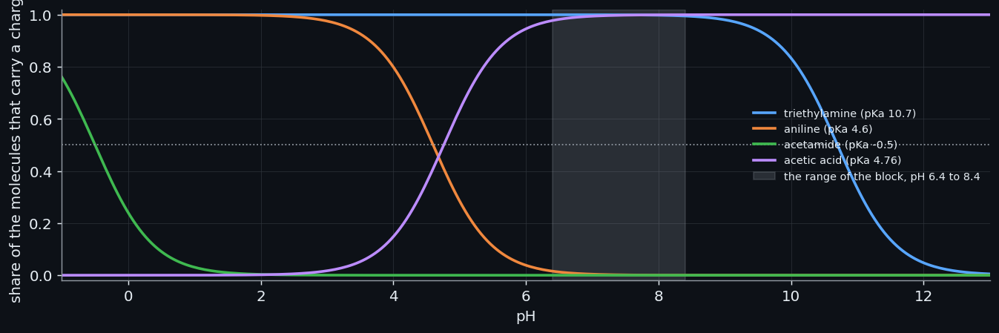

In [243]:
# The share of molecules that carry a charge at a given pH, from the pKa, for four small molecules whose pKa the textbook gives (the first three are the ones of section 5.2, the fourth is an acid), at the lowest,
# the middle and the highest pH of the range that the basic-centre block uses. The same molecules are then given to Dimorphite-DL, the program that block uses, as a check of the arithmetic.
from dimorphite_dl import protonate_smiles
from rdkit import Chem

from cypmode.challenge.basic_centre import PH_MAX, PH_MIN

hh_molecules = [("triethylamine", "CCN(CC)CC", "base", 10.7), ("aniline", "Nc1ccccc1", "base", 4.6), ("acetamide", "CC(N)=O", "base", -0.5), ("acetic acid", "CC(=O)O", "acid", 4.76)]
hh_ph_middle = round((PH_MIN + PH_MAX) / 2, 1)

def charged_share(kind, pka, ph):
    """Share of the molecules that carry a charge at this pH: a base is charged when it has taken up a hydrogen ion, an acid when it has lost one."""
    return 1 / (1 + 10 ** ((ph - pka) if kind == "base" else (pka - ph)))

hh_rows = []
for name, smiles, kind, pka in hh_molecules:
    state = protonate_smiles(smiles, ph_min=hh_ph_middle, ph_max=hh_ph_middle, precision=1.0)[0].split()[0]
    charge = Chem.GetFormalCharge(Chem.MolFromSmiles(state))
    shares = [charged_share(kind, pka, ph) for ph in (PH_MIN, hh_ph_middle, PH_MAX)]
    assert (shares[1] > 0.5) == (charge != 0)  # the program and the arithmetic agree on which side of one half each molecule is
    n_states = len(protonate_smiles(smiles, ph_min=PH_MIN, ph_max=PH_MAX, precision=1.0))  # the call of the block: every state found between the two ends of the range
    hh_rows.append({"molecule": name, "group": kind, "pKa": pka, f"charged share at pH {PH_MIN}": shares[0], f"at pH {hh_ph_middle}": shares[1], f"at pH {PH_MAX}": shares[2], "Dimorphite-DL state": state, "formal charge": charge,
                    f"states over pH {PH_MIN} to {PH_MAX}": n_states})
hh_table = pd.DataFrame(hh_rows)
show_table(hh_table, floatfmt=".4f")
hh_window = float(np.log10(9))  # a form is at least a tenth of the molecules only within this many pH units of the pKa (share between 0.1 and 0.9)
assert abs(charged_share("base", 7.4, 7.4 + hh_window) - 0.1) < 1e-12 and abs(charged_share("base", 7.4, 7.4 - hh_window) - 0.9) < 1e-12
assert abs(charged_share("base", 7.4, 7.4) - 0.5) < 1e-12  # at a pH equal to the pKa half of the molecules are charged

def odds(share):
    return share / (1 - share)

assert abs(odds(charged_share("base", 7.4, 6.4)) - 10) < 1e-9 and abs(odds(charged_share("base", 7.4, 8.4)) - 0.1) < 1e-9  # one pH unit away from the pKa, the odds change tenfold

fig, axis = plt.subplots(figsize=(10.5, 3.6))
ph_axis = np.linspace(-1, 13, 300)
colours = [theme["blue"], theme["orange"], theme["green"], theme["purple"]]
for (name, _smiles, kind, pka), colour in zip(hh_molecules, colours):
    axis.plot(ph_axis, charged_share(kind, pka, ph_axis), color=colour, lw=2, label=f"{name} (pKa {pka})")
axis.axvspan(PH_MIN, PH_MAX, color=theme["muted"], alpha=0.22, label=f"the range of the block, pH {PH_MIN} to {PH_MAX}")
axis.axhline(0.5, color=theme["muted"], ls=":", lw=1)
axis.set(xlabel="pH", ylabel="share of the molecules that carry a charge", ylim=(-0.02, 1.02), xlim=(-1, 13))
axis.legend(frameon=False, loc="center right", fontsize=8)
tidy(axis, theme)
fig.tight_layout()

Triethylamine is charged in 99.99% of its molecules at the lowest pH of the range and still in 99.50% at the highest. Aniline is charged in 1.6% at the lowest and 0.02% at the highest, acetamide in practically none, and acetic acid, which is charged on losing its hydrogen ion, in 97.8% to 99.98%. Dimorphite-DL returns the protonated amine for the first, the neutral molecule for the next two and the carboxylate for the acid, which is the side of one half that the arithmetic gives, and one state only for each molecule over the whole range (the last column). The figure shows why: a group is found in two forms, each at least a tenth of the molecules, only within 0.95 units of pH of its pKa, and the pKa of all four groups lies far from the band of 6.4 to 8.4. A group whose pKa falls inside the band is the case that a single pH would hide, and it is the reason that the block enumerates a range.

**A block of chemistry for CYP2D6.** CYP2D6 binds substrates and inhibitors that carry a **protonated** basic nitrogen (one that has taken up a hydrogen ion and carries a positive charge in the assay buffer) a few ångströms from a flat aromatic ring: the cation meets two acidic residues of the pocket, Asp301 and Glu216, while the ring sits over the heme. A fingerprint sees the substructure. It does not know that the nitrogen is protonated at the pH of the assay, how many sites could be, or how far the charge sits from the ring in a real conformation. The basic-centre block (`cypmode/challenge/basic_centre.py`, queue jobs `191_basic_centre_extract` and `199_basic_centre_experiment`) computes those quantities from the structure alone: the **protonation states** of the molecule between pH 6.4 and 8.4 with Dimorphite-DL (which enumerates the states in which the ionisable groups can be found), the class of the most protonated state (primary, secondary or tertiary ammonium, amidinium or guanidinium, quaternary), the shortest bond path from a basic centre to an aromatic atom, and, from ten conformers of the most protonated state, the distances from each basic nitrogen to the aromatic ring centres and the share of conformers with a ring centre 4.5 to 7.5 Å away, the window of the CYP2D6 pharmacophore. 5,281 of the 6,895 compounds have a basic centre. The block is the principled form of the idea behind the trialkylamine flag of 7.2, which looked only for one substructure. Change of the AUC: CYP2D6, where it matters most, -0.0033 (p = 0.70) and +0.0007 (p = 0.83), gate NOT MET; CYP3A4 +0.0005 (p = 0.54) and +0.0013 (p = 0.37), gate NOT MET.

**Two changes to the blend.** The blend that turns the scores of the members into one score (8.2) is a logistic regression on their transformed ranks, and nothing stops it from giving a member a negative weight: in the final CYP3A4 stack `knn_tanimoto_k5` has weight −0.093, a member that is subtracted because it is correlated with better ones, which is more often a fit to the noise of the inner folds than a property of the chemistry. The **non-negative blend** (`cypmode/challenge/nonneg_stack.py`) is the same regression with every weight constrained to be at least zero, an average of experts that can be switched off but never inverted, solved with the L-BFGS-B method. The **softmax blend** (`cypmode/challenge/softmax_selector.py`) fills the line between two extremes with one parameter. At one end the best single member takes all the weight (exploitation of what the inner folds say), at the other every member weighs the same (exploration: no member is trusted over another); between them the weight of member $k$ is $w_k = \exp(s_k/T)/\sum_j \exp(s_j/T)$, a **softmax** of its inner score $s_k$ with a **temperature** $T$ chosen by an inner cross-validation, where $T \to 0$ is the best single member and $T \to \infty$ the equal-weight committee. Each is tested against the logistic blend on the cached predictions of the default stack, with the same folds and the same yardstick. Change of the AUC of the whole stack when the logistic blend is replaced: the non-negative blend, CYP3A4 +0.0002 (p = 0.93) and +0.0008 (p = 0.69), gate NOT MET, CYP2D6 +0.0041 (p = 0.69) and +0.0041 (p = 0.70), gate NOT MET; the softmax blend, CYP3A4 -0.0071 (p = 0.15) and -0.0020 (p = 0.65), gate NOT MET, CYP2D6 -0.0069 (p = 0.68) and -0.0034 (p = 0.68), gate NOT MET. The logistic blend stays; the negative weight of the nearest-neighbour member is therefore not a defect that costs accuracy, and the exploration-exploitation curve of the softmax blend is written next to the verdict (`data/tdi_track/outputs/comparisons/softmax_curve_<enzyme>.csv`) and drawn in the figure `ml_exploration_exploitation`. At $z_0 = 1.0$, for CYP3A4 the outer AUC of the softmax blend runs from 0.8068 to 0.8098 over the grid of fixed temperatures, below the 0.8170 of the logistic blend at every one of them. For CYP2D6 it rises with the temperature, to 0.7357 for the equal-weight committee, above the 0.7312 of the logistic blend. The gate tested the softmax blend with its temperature chosen by the inner cross-validation (0.7242 for CYP2D6), and not the equal-weight committee; the committee's advantage on CYP2D6 was seen after the gate, was not tested, is small against the spread of the fold AUCs of that enzyme (about 0.05), and is not adopted.

**The control.** One more experiment of the family is not an addition: the **negative control** (`cypmode/challenge/permutation_control.py`, queue job `200_permutation_control`). The labels of the pool are permuted at random and the whole nested procedure is repeated; the outer AUC must be 0.5 and the MCC 0, because a model that is shown labels unrelated to the structures cannot rank them. The control is MET on both enzymes: at $z_0 = 1.0$ the permuted labels give an AUC of 0.510 for CYP3A4 (range 0.480 to 0.535 over three permutations) and an MCC of +0.002, against 0.801 and +0.411 with the real labels, and 0.501 and +0.020 for CYP2D6, against 0.751 and +0.159. It is the evidence that the nested pipeline carries no leak that survives a permutation of the labels: a leak (6.8) would show as an AUC above 0.5 on labels that carry no information.

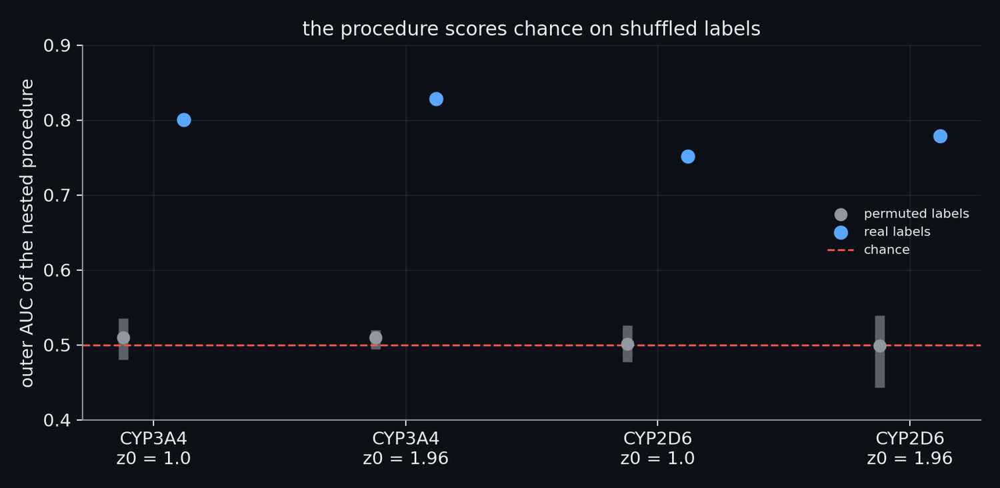

**Figure: The negative control with permuted labels.** The negative control: the labels of the pool are permuted at random and the whole nested procedure, with every selection step, is run again; 3 permutations per enzyme. A pipeline that leaks information from the labels into its selection would still score above chance on shuffled labels. Here the AUC on permuted labels is 0.499 to 0.510 (the bars show the range over the permutations) against 0.751 to 0.828 on the real labels, and the largest distance from 0.5 is 0.010 (CYP3A4, z0 = 1.0). The control passes: nothing in the procedure scores above chance without a signal in the labels.

In [244]:
show_figure("ml_permuted_control")

## 9.11 The ledger of the gates, and what the correction for the number of attempts leaves

> **Field:** Statistics

*Where this section sits:* 6.5 showed how the number of comparisons inflates the share of false positives and introduced Holm's adjustment, and 6.7 introduced the pre-declared gate and counted the comparisons that the project had logged. Part IX has since added the experiments of 9.1 to 9.10. This section puts the logged comparisons together, applies the correction over the whole family, and asks what the one gate that was met means once the number of attempts is counted. It closes Part IX.

**The family.** Every experiment of the project that went through the gate of 6.7 and logged a stacked comparison (or, for a selector, a comparison of the blends) at both confidence cut-offs is one row of the family (`cypmode/challenge/multiplicity.py`); the logs of the ten-fold replicates are left out, because they repeat comparisons that are already in it. A row has two p-values, one for each cut-off, and the gate needs both to be below 0.05, so the p-value of the row is the larger of the two. This is an **intersection-union test**: the claim is that the addition helps at both cut-offs, and it is rejected unless both comparisons support it. Holm's adjustment of 6.5 is applied to the p-values of the rows. Experiments whose logs have another form (the population experiments of 9.1, the confidence-weighting and alert-context experiments of 9.8, the calibration of 8.5) have their own pre-declared gates and are not in this family. The cell builds it from the logs and shows the ten rows with the smallest p-values.

In [245]:
# The ledger of the stacked gates, with the correction for the number of attempts. Every experiment of the project that was put through the gate of 6.7 and logged a stacked comparison (or, for a selector, a comparison of the blends) at both
# confidence cut-offs is one row; the logs of the 10-fold replicates are left out, since they repeat comparisons already in the family. The p-value of a row is the larger of its two, because the gate needs both
# (cypmode/challenge/multiplicity.py, the project's own module, whose Holm function is the one of 6.5).
from cypmode.challenge.multiplicity import collect, holm

ledger_all = collect(LOGS9, patterns=("*_CYP*.log",))
def has_gate_line(name):
    text = (LOGS9 / name).read_text(errors="ignore")
    return bool(re.search(r"GATE \((stacked|selector|population screen stacked)", text)) and "_f10" not in name
def gate_verdict(name, iso):
    found = re.findall(rf"^{iso} GATE \((?:stacked|selector|population screen stacked)[^)]*\): (MET|NOT MET)", (LOGS9 / name).read_text(errors="ignore"), re.M)
    return found[-1] if found else "no verdict"
ledger = ledger_all[ledger_all["log"].map(has_gate_line)].copy().reset_index(drop=True)
ledger["Holm-adjusted p"] = holm(ledger["p_both"].tolist())
ledger["gate"] = [gate_verdict(row["log"], row["isoform"]) for _, row in ledger.iterrows()]
ledger = ledger.rename(columns={"diff_z1.0": "AUC change at z0 1.0", "p_z1.0": "p at z0 1.0", "diff_z1.96": "AUC change at z0 1.96", "p_z1.96": "p at z0 1.96", "p_both": "p (larger of the two)"})
show_table(ledger.sort_values("p (larger of the two)").head(10)[["log", "isoform", "AUC change at z0 1.0", "p at z0 1.0", "AUC change at z0 1.96", "p at z0 1.96", "p (larger of the two)", "Holm-adjusted p", "gate"]], floatfmt=".4f")

n_ledger = len(ledger)
n_ledger_3a4, n_ledger_2d6 = int((ledger["isoform"] == "CYP3A4").sum()), int((ledger["isoform"] == "CYP2D6").sum())
ledger_met = ledger[ledger["gate"] == "MET"]["log"].tolist()
n_below_one, n_below_196, n_below_both = int((ledger["p at z0 1.0"] < 0.05).sum()), int((ledger["p at z0 1.96"] < 0.05).sum()), int((ledger["p (larger of the two)"] < 0.05).sum())
smallest_holm = float(ledger["Holm-adjusted p"].min())
median_one, median_196 = float(ledger["AUC change at z0 1.0"].median()), float(ledger["AUC change at z0 1.96"].median())
positive_one, positive_196 = int((ledger["AUC change at z0 1.0"] > 0).sum()), int((ledger["AUC change at z0 1.96"] > 0).sum())
largest_change = float(ledger["AUC change at z0 1.0"].max())
n_above_floor = int((ledger["AUC change at z0 1.0"] > floor_main).sum())
expected_false = 0.05 * n_ledger
ledger_met_text = ", ".join(f"`{name}`" for name in ledger_met) if ledger_met else "none"
print(f"{n_ledger} logged stacked comparisons ({n_ledger_3a4} CYP3A4, {n_ledger_2d6} CYP2D6); gates met: {ledger_met}; raw p below 0.05 at z0 1.0 / 1.96 / both: {n_below_one} / {n_below_196} / {n_below_both}; smallest Holm-adjusted p {smallest_holm:.3f}")

85 logged stacked comparisons (43 CYP3A4, 42 CYP2D6); gates met: ['aux_chemprop_foundation_CYP3A4.log', 'aux_neural_CYP3A4.log']; raw p below 0.05 at z0 1.0 / 1.96 / both: 4 / 2 / 2; smallest Holm-adjusted p 0.425


| log | isoform | AUC change at z0 1.0 | p at z0 1.0 | AUC change at z0 1.96 | p at z0 1.96 | p (larger of the two) | Holm-adjusted p | gate |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| aux_chemprop_foundation_CYP3A4.log | CYP3A4 | 0.0133 | 0.0020 | 0.0144 | 0.0050 | 0.0050 | 0.4250 | MET |
| aux_neural_CYP3A4.log | CYP3A4 | 0.0106 | 0.0140 | 0.0106 | 0.0290 | 0.0290 | 1.0000 | MET |
| aux_atomjepa_head_CYP3A4.log | CYP3A4 | 0.0107 | 0.0280 | 0.0081 | 0.0590 | 0.0590 | 1.0000 | NOT MET |
| aux_mlp_CYP3A4.log | CYP3A4 | 0.0077 | 0.0430 | 0.0072 | 0.0800 | 0.0800 | 1.0000 | NOT MET |
| aux_mlp_aux_CYP3A4.log | CYP3A4 | 0.0067 | 0.0760 | 0.0065 | 0.1030 | 0.1030 | 1.0000 | NOT MET |
| physics_experiment_CYP3A4.log | CYP3A4 | 0.0050 | 0.0780 | 0.0055 | 0.1150 | 0.1150 | 1.0000 | NOT MET |
| aux_chemprop_CYP3A4.log | CYP3A4 | 0.0048 | 0.0760 | 0.0050 | 0.1310 | 0.1310 | 1.0000 | NOT MET |
| physics_compact_CYP3A4.log | CYP3A4 | 0.0036 | 0.0680 | 0.0033 | 0.1480 | 0.1480 | 1.0000 | NOT MET |
| monroe_embeddings_CYP3A4.log | CYP3A4 | 0.0031 | 0.1710 | 0.0041 | 0.1230 | 0.1710 | 1.0000 | NOT MET |
| pair_transfer_physics_CYP3A4.log | CYP3A4 | 0.0042 | 0.1520 | 0.0042 | 0.3040 | 0.3040 | 1.0000 | NOT MET |

The family has 85 rows, 43 for CYP3A4 and 42 for CYP2D6. 2 of them meets its gate: `aux_chemprop_foundation_CYP3A4.log`, `aux_neural_CYP3A4.log`. The raw p-value is below 0.05 at $z_0 = 1.0$ for 4 rows, at 1.96 for 2, and at both for 2. After Holm's adjustment over the 85 rows the smallest adjusted p-value is 0.42: no row survives the correction.

Several readings of these numbers are possible, and the ledger cannot separate them. If none of the 85 additions had any effect, about 4.2 of them would pass a gate of level 0.05 by chance (at most: the two cut-offs are strongly correlated, so that a pass at both is little rarer than a pass at one); one passed, which is what chance alone gives. If a few of them have small real effects, the ledger would look the same, because the design recognises a difference 8 times in 10 only above 0.0099 AUC (6.7): the number of changes at $z_0 = 1.0$ above that floor is 3, and the largest is +0.0133. The changes lean positive, and that deserves a remark without a conclusion: at $z_0 = 1.0$ the median change is -0.0001 and 41 of 85 are positive; at $z_0 = 1.96$ the median is +0.0011 and 63 are positive. The additions are not independent tests, since each is added to the same stack and judged on the same folds, so that these counts are not a sign test. A shift of the whole distribution above zero at the cut-off whose scored labels are the most certain is what many additions each carrying a little real information would produce; it can also arise from the dependence among the tests. The ledger does not decide between the two.

**What the gate is for.** The rule of 6.7 was fixed at p < 0.05 at both cut-offs *per addition*, without a correction for the number of additions, and on purpose: a correction over 85 tries would reject every addition, the real ones included, with a design whose resolution is about 0.01 AUC. The price of the choice is stated here and not hidden. With 85 tries, about 4.2 passes are expected by chance alone, so that a pass is a reason to look closer and not a finding. That is why the one pass of the ledger, the neural pair, was not accepted on its own: it was formed after the results, it had to be confirmed by a replicate declared beforehand (9.9), and it joins the stack on those terms. The adjusted p-values are reported next to the uncorrected ones in the audit (the section on multiplicity, `cypmode/audit/sections_extra.py`, over its own batch of additions) and in the method report.

**What Part IX showed.** Three things. First, an addition that holds information the stack lacks can be seen only if it adds about 0.01 AUC, and of the additions of 9.4 to 9.10 only the neural pair of 9.9 did; a foundation model, outside measurements, the organisers' own extra readings, a new block of chemistry and new blends did not, whatever their origin. The simplest reading, and a reading only, is that 23 members that look at descriptors, fingerprints, neighbours and several learned representations already span what those additions know. Second, the changes that came nearest to the gate were not features at all but models of a different kind, the neural networks of 9.9, which is the only place in the part where the stack gained members that see the molecule in a way the others do not. Third, the largest change in what the project asks of the model is not an addition: it is the selection-aware question of 9.1, which changes what is scored and not how well a score ranks. Part X turns to the quantum-chemical features, whose experiments belong to the same ledger and were designed with the same gates.

In [246]:
# The all-in-one comparison (cypmode/challenge/all_in_one.py, queue job 254_all_in_one_comparison), read from its logs: the final stack of each enzyme against one stack of the default candidates and every candidate of every group
# whose cross-validation predictions are complete, whatever the verdict of the group's gate, on the experiments' plan with the corrected resampled t. The logs are named so that no gate parser reads them.
all_in_one = {}
for iso in ("CYP3A4", "CYP2D6"):
    log = ROOT / f"data/structure_track/outputs/cyp3a4/logs/exploratory_all_in_one_{iso}.log"
    text = log.read_text() if log.exists() else ""
    head = re.search(r"final stack of (\d+) candidates.*?all-in-one stack of (\d+) candidates from (\d+) groups", text)
    cuts = re.findall(r"z0=(\S+)\s+outer AUC final ([\d.]+)\s+all-in-one ([\d.]+)\s+all-in-one vs final: AUC ([+-][\d.]+) \(p=([\d.]+)\)", text)
    verdict = re.search(r"ALL-IN-ONE .*: (MET|NOT MET)", text)
    all_in_one[iso] = {"final": int(head.group(1)), "everything": int(head.group(2)), "groups": int(head.group(3)), "cuts": [(float(z), float(a), float(b), float(d), float(q)) for z, a, b, d, q in cuts], "verdict": verdict.group(1)} if head and cuts and verdict else None
all_in_one_rows = [{"enzyme": iso, "z0": z, "final stack": a, "all-in-one": b, "change": d, "corrected p": q, "candidates (final, all-in-one)": f"{r['final']}, {r['everything']}"} for iso, r in all_in_one.items() if r for z, a, b, d, q in r["cuts"]]
if all_in_one_rows:
    all_in_one_table = pd.DataFrame(all_in_one_rows)
    show_table(all_in_one_table, floatfmt=".4f")
    all_in_one_verdicts = {iso: (r["verdict"] if r else "not run yet") for iso, r in all_in_one.items()}
else:
    all_in_one_verdicts = {"CYP3A4": "not run yet", "CYP2D6": "not run yet"}
cuts_3a4 = all_in_one["CYP3A4"]["cuts"] if all_in_one["CYP3A4"] else []
cuts_2d6 = all_in_one["CYP2D6"]["cuts"] if all_in_one["CYP2D6"] else []
if len(cuts_3a4) == 2 and all(c[3] > 0 for c in cuts_3a4) and sum(c[4] < 0.05 for c in cuts_3a4) == 1:
    reading_3a4 = "On CYP3A4 the larger stack is ahead at both cut-offs, by about a hundredth of an AUC, and the difference is significant at one cut-off and not at the other"
else:
    reading_3a4 = "The changes on CYP3A4 are in the table"
if len(cuts_2d6) == 2 and all(abs(c[3]) < 0.01 for c in cuts_2d6) and len({c[3] > 0 for c in cuts_2d6}) == 2:
    reading_2d6 = "with changes of a few thousandths in both directions"
else:
    reading_2d6 = "with the changes of the table"
n_all_3a4 = all_in_one["CYP3A4"]["everything"] if all_in_one["CYP3A4"] else 0
n_groups_3a4 = all_in_one["CYP3A4"]["groups"] if all_in_one["CYP3A4"] else 0

| enzyme | z0 | final stack | all-in-one | change | corrected p | candidates (final, all-in-one) |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 1.0000 | 0.8276 | 0.8393 | 0.0117 | 0.1050 | 26, 91 |
| CYP3A4 | 1.9600 | 0.8550 | 0.8678 | 0.0128 | 0.0390 | 26, 91 |
| CYP2D6 | 1.0000 | 0.7312 | 0.7291 | -0.0021 | 0.8660 | 23, 87 |
| CYP2D6 | 1.9600 | 0.7536 | 0.7572 | 0.0036 | 0.8130 | 23, 87 |

**The all-in-one stack.** A gate asks that an addition helps on its own and inside the default stack, and the stack of 8.2 holds only what the gates let in. An idea that is weak alone and useful only together with others could be refused by every gate and still help a stack that holds all of them, so the question whether the gated stack is also the strongest is a fair one, and it was asked once, with the rule written before the result (`cypmode/challenge/all_in_one.py`, queue job `254_all_in_one_comparison`, test `tests/test_all_in_one.py`). The final stack of each enzyme is compared, on the same outer folds, the same population and the same two confidence cut-offs, with one stack of the default candidates and every candidate of every group whose cross-validation predictions are complete (91 candidates from 32 groups for CYP3A4), whatever the verdict of the group's gate: one logistic blend each, the paired corrected resampled t. The registered outcome is that the larger stack is better when its mean outer AUC exceeds the final stack's with corrected p < 0.05 at both cut-offs and by at least the design floor; it does not replace the final stack by itself, because it has no replicate (the groups have no predictions on the ten-outer-fold plan), so that a replacement would need that replicate.

The result is in the table. On CYP3A4 the larger stack is ahead at both cut-offs, by about a hundredth of an AUC, and the difference is significant at one cut-off and not at the other; the registered outcome is NOT MET. On CYP2D6 it is NOT MET, with changes of a few thousandths in both directions. A gain of this size is what a stack of ninety candidates would show if each of them added a very little, and it is also what chance and the correlation of the folds would show; with no replicate the design cannot tell the two apart. The final stack is therefore kept, on the rule that was declared, and the larger one is reported as the most notable result of the second looks: it says that the gates were not hiding a large gain in combinations, and that a small one cannot be excluded. A first run of the comparison counted a candidate as complete only if its deployment fit existed too, which left out every group that never joined a final stack (it used 34 candidates from 10 groups, not about ninety); that was a defect of the implementation and not a change of the rule, it was found by reading the log before any decision rested on it, and the log of the first run is kept (`exploratory_all_in_one_first_run_<enzyme>.log`) with its numbers, all of them NOT MET.

*On what actually ran.* `cypmode/challenge/multiplicity.py` (`collect` reads the stacked lines of every log with a gate line, `holm` adjusts), `cypmode/challenge/all_in_one.py` (the second look at the stack), the logs of `data/structure_track/outputs/cyp3a4/logs`, and the audit section that reports the same batch (`cypmode/audit/sections_extra.py`). The notebook reads and counts; it runs no experiment.

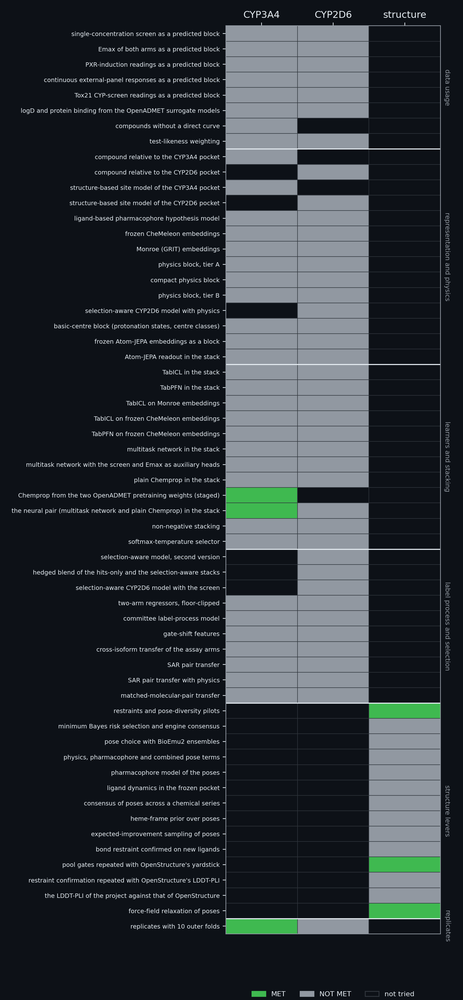

**Figure: Every idea by place and verdict.** Every idea that was put to a pre-registered gate, one row per family and one column per place it was tried (CYP3A4, CYP2D6, the structure track): green where a verdict was MET, grey where every verdict was NOT MET, empty where the idea was not tried. 59 families, 6 cells with a MET verdict and 88 with none, grouped by the kind of idea. A family that is MET in one cell and NOT MET in the other is a result for one enzyme only. The count of verdicts behind the cells is the one count that the method report, the README and the film quote.

In [247]:
show_figure("arch_ledger_heatmap")

## 9.12 Why the ideas that did not join added nothing

> **Field:** Statistics

*Where this section sits:* 9.11 put the logged gates together and corrected for the number of attempts. Its verdict is about the gates: an idea either met its pre-declared rule or did not, and the ledger counts how many did. A verdict of NOT MET says what happened and not why. This section reads the diagnostics that the project generated for the question why: for every group that did not join, the size of its change with the corrected standard error, the redundancy of its predictions with the stack's, the weight the stack gave it, and the smallest effect the design could detect. The diagnostics are produced by code from the caches of the final build (`cypmode/challenge/why_no_gain.py`, queue job 097), so the table and the sentences around it describe the same run.

**Four measures and five descriptions.** For every candidate group and each confidence cut-off, `why_no_gain.py` measures four things with the machinery of the gates themselves: the paired change in the outer AUC when the group joins the default stack, with its corrected p value; the redundancy, the mean and the largest absolute rank correlation between the group's predictions and the stack's on the held-out rows; the weight the stack gave the group when it was allowed to use it, as the share of the absolute logistic coefficients; and the smallest effect the design could detect, the corrected standard error times the sum of the two t quantiles for a one-sided test at the 5 percent level with 80 percent **power**. Five further numbers are descriptive and not gates: a 90 percent **confidence interval** and its equivalence test against a margin of one hundredth of an AUC, Cohen's d_z of the paired differences, the Shapiro–Wilk p value of their normality, the design floor (the same smallest detectable effect with infinitely many repeats), and the partial correlation of the group's predictions with the label given the stack's score. A reason is then assigned by fixed rules in a fixed order, and every clause of the reason carries its number in the text; a group whose change is positive, larger than the detectable effect and still not significant is reported as no reason found. The next cell reads the table and counts.

In [248]:
# The diagnostics of why the ideas that did not join the final stack added nothing, read from the table that job 097 generates (data/tdi_track/outputs/final/why_no_gain.csv). For every group of candidates and
# each of the two confidence cut-offs it holds the paired change in outer AUC with its corrected p value, the redundancy of the group's predictions with the stack's, the weight the stack gave the group,
# the smallest effect the design could detect, and the reason the module assigns by its fixed rules; the equivalence column is the separate question whether the 90 percent interval of the change lies inside
# the margin of +-0.01 AUC that the module calls equivalence. The rows of a group that joined the final stack are left out.
why_gain = pd.read_csv(ROOT / "data/tdi_track/outputs/final/why_no_gain.csv")
why_gain = why_gain[~why_gain["in_final_stack"]].reset_index(drop=True)
why_gain["names no weight"] = why_gain["reason"].str.contains("almost no weight")
why_gain["names redundancy"] = why_gain["reason"].str.contains("largely redundant")
why_gain["names a lowered AUC"] = why_gain["reason"].str.contains("lowered the AUC")
why_gain["names a change below the detectable effect"] = why_gain["reason"].str.contains("smaller than the smallest effect")
why_summary_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    why_part = why_gain[why_gain["isoform"] == iso]
    why_summary_rows.append({"enzyme": iso, "group comparisons": len(why_part), "groups of candidates": why_part["group"].nunique(),
                             "equivalent to adding nothing": int((why_part["equivalence"] == "equivalent").sum()), "inconclusive": int((why_part["equivalence"] == "inconclusive").sum()),
                         "worse (interval below the margin)": int((why_part["equivalence"] == "worse").sum()),
                             "reason: almost no weight": int(why_part["names no weight"].sum()), "reason: redundancy": int(why_part["names redundancy"].sum()),
                             "reason: lowered the AUC": int(why_part["names a lowered AUC"].sum()), "median smallest detectable change": float(why_part["detectable_effect"].median())})
why_table = pd.DataFrame(why_summary_rows)
show_table(why_table, floatfmt=".4f")
n_why = len(why_gain)
n_why_3a4, n_why_2d6 = int((why_gain["isoform"] == "CYP3A4").sum()), int((why_gain["isoform"] == "CYP2D6").sum())
n_equivalent = int((why_gain["equivalence"] == "equivalent").sum())
n_inconclusive = int((why_gain["equivalence"] == "inconclusive").sum())
n_worse = int((why_gain["equivalence"] == "worse").sum())
worse_sentence = "" if n_worse == 0 else f", and in {n_worse} the whole interval lies below the margin, which the module calls worse"
n_flagged = int((why_gain["corrected_p"] < 0.05).sum())
n_flagged_inconclusive = int(((why_gain["corrected_p"] < 0.05) & (why_gain["equivalence"] == "inconclusive")).sum())
n_flagged_below_effect = int(((why_gain["corrected_p"] < 0.05) & (why_gain["delta_auc"].abs() < why_gain["detectable_effect"])).sum())
if n_flagged and n_flagged_below_effect == n_flagged and n_flagged_inconclusive == n_flagged:
    flagged_sentence = "For each of them the change is still below the smallest detectable effect, and the equivalence verdict is inconclusive rather than equivalent"
elif n_flagged:
    flagged_sentence = f"For {n_flagged_below_effect} of them the change is still below the smallest detectable effect, and for {n_flagged_inconclusive} the equivalence verdict is inconclusive rather than equivalent"
else:
    flagged_sentence = "None of them has a corrected p value below 0.05"
n_no_weight = int(why_gain["names no weight"].sum())
n_redundancy = int(why_gain["names redundancy"].sum())
n_lowered = int(why_gain["names a lowered AUC"].sum())
n_below_effect = int(why_gain["names a change below the detectable effect"].sum())
n_raw_below = int((why_gain["corrected_p"] < 0.05).sum())
n_shapiro = int((why_gain["shapiro_p"] < 0.05).sum())
median_redundancy = float(why_gain.loc[why_gain["names redundancy"], "redundancy_mean"].median())
median_floor_3a4 = float(why_gain.loc[why_gain["isoform"] == "CYP3A4", "design_floor"].median())
median_floor_2d6 = float(why_gain.loc[why_gain["isoform"] == "CYP2D6", "design_floor"].median())
nearest_table = why_gain.sort_values("delta_auc", ascending=False).head(4)[["group", "isoform", "z0", "delta_auc", "corrected_p", "detectable_effect", "equivalence"]]
nearest_table = nearest_table.rename(columns={"group": "group of candidates", "z0": "confidence cut-off", "delta_auc": "change in AUC", "corrected_p": "corrected p", "detectable_effect": "smallest detectable change"})
show_table(nearest_table, floatfmt=".4f")
assert n_equivalent + n_inconclusive + n_worse == n_why
assert set(why_gain["equivalence"]) <= {"equivalent", "inconclusive", "worse"}
assert (why_gain["detectable_effect"] > 0).all()

| enzyme | group comparisons | groups of candidates | equivalent to adding nothing | inconclusive | worse (interval below the margin) | reason: almost no weight | reason: redundancy | reason: lowered the AUC | median smallest detectable change |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | 72 | 36 | 63 | 9 | 0 | 6 | 56 | 15 | 0.0047 |
| CYP2D6 | 72 | 36 | 29 | 43 | 0 | 26 | 27 | 39 | 0.0135 |

| group of candidates | isoform | confidence cut-off | change in AUC | corrected p | smallest detectable change | equivalence |
| --- | --- | --- | --- | --- | --- | --- |
| atomjepa_head | CYP3A4 | 1.0000 | 0.0107 | 0.0280 | 0.0115 | inconclusive |
| atomjepa_head | CYP3A4 | 1.9600 | 0.0081 | 0.0594 | 0.0104 | inconclusive |
| mlp | CYP3A4 | 1.0000 | 0.0077 | 0.0432 | 0.0091 | inconclusive |
| mlp | CYP3A4 | 1.9600 | 0.0072 | 0.0802 | 0.0101 | inconclusive |

The table has 144 comparisons of ideas that did not join, 72 on CYP3A4 and 72 on CYP2D6, one row per group and confidence cut-off. In 92 of them the 90 percent interval of the change lies inside the margin of one hundredth of an AUC, so the design shows that the idea added nothing that matters; 52 are inconclusive, their interval wider than the margin, which is not the same statement. In all 144 comparisons the change is smaller than the smallest effect that design could detect: the gate could not have been met by an effect of the size this design can see, whatever the idea's sign. The reason column names the closer causes, and a row can name more than one. Redundancy is the most frequent: 83 of the 144 comparisons find the group's predictions largely redundant with the stack's, with a median mean absolute rank correlation of 0.87 among them, which says that the group mostly repeated what the stack already had. The stack gave 32 comparisons almost no weight, and 54 of them lowered the AUC.

The largest changes are listed in the second table. They are those of the attention readout on the Atom-JEPA atoms (9.10) and of the multitask network (9.9), both on CYP3A4, at both confidence cut-offs; 2 comparisons in the whole table have a corrected p value below 0.05, and they are the first-cut-off rows of those two. For each of them the change is still below the smallest detectable effect, and the equivalence verdict is inconclusive rather than equivalent, so the reading is that the design could not separate them from zero. That is also what the ledger of 9.11 says: after the correction over the family no row survives, and the one addition that joined (9.9) did so on a pre-declared replicate and not on this table.

**What the section adds.** The numbers answer the question that 9.11 could not. They do not say that the ideas that did not join are chemically wrong, and nothing in the table could say it: they say that their predictions were close to the stack's and their changes were smaller than the design's resolution, about a hundredth of an AUC at the first cut-off for CYP2D6 and a few thousandths for CYP3A4 (a median design floor of 0.0040 for CYP3A4 and 0.0113 for CYP2D6). A group whose predictions are redundant with the stack's cannot add much to it, and an effect below the floor cannot be separated from zero by more folds of the same data; only a different representation, or compounds the project has not seen, would settle it. That is the ceiling of 13.3, measured rather than asserted. The diagnostics are descriptive as well as diagnostic: the Shapiro–Wilk p value of the paired differences is below 0.05 in 67 of the 144 comparisons, so the normal approximation of the corrected t is not exact here, which with so few folds can only flag a gross violation; the module reports it and does not act on it.

*On what actually ran.* The cell reads `data/tdi_track/outputs/final/why_no_gain.csv`, which job 097 writes by calling `cypmode/challenge/why_no_gain.py` on the caches of the final build; the module writes the same counts and the same reasons in the Markdown file `why_no_gain.md` beside it. The notebook reads the table and counts; it runs no experiment.

In [249]:
# The pocket block of 9.13: the sizes of the two reference sets, the gate lines of the four runs (the addition on its own enzyme, the pocket of the other enzyme as the control) and the number of
# compounds with each mode of the block. Every number is read from the files that the queue jobs 262 to 264 left.
import json
import re

import pandas as pd

pocket_logs = ROOT / "data/structure_track/outputs/cyp3a4/logs"
pocket_sets = {}
for pocket_name in ("cyp3a4", "cyp2d6"):
    pocket_ligands = json.loads((ROOT / f"data/structure_track/inputs/{pocket_name}_reference_ligands.json").read_text())["ligands"]
    pocket_sets[pocket_name] = (len(pocket_ligands), len({r["comp_id"] for r in pocket_ligands}), len({r["pdb_id"] for r in pocket_ligands}))
pocket_stacked = re.compile(r"z0=([\d.]+)\s+stacked base\+added vs base: AUC ([+-][\d.]+) \(p=([\d.]+), better (\d+)/(\d+)\)")
pocket_alone = re.compile(r"z0=([\d.]+)\s+alone\s+(\S+)\s+vs (\S+)\s*: AUC ([\d.]+) -> ([\d.]+) \(([+-][\d.]+), p=([\d.]+)")
pocket_gate = re.compile(r"^(CYP\w+) GATE \((alone|stacked)[^)]*\): (MET|NOT MET)", re.MULTILINE)
pocket_rows = []
for enzyme, own in (("CYP3A4", "pocket_cyp3a4"), ("CYP2D6", "pocket_cyp2d6")):
    for role, log_name in (("own pocket (the addition)", f"aux_{own}_{enzyme}.log"), ("other pocket (the control)", f"exploratory_pocket_control_{enzyme}.log")):
        text = (pocket_logs / log_name).read_text()
        cuts = {float(z0): (float(gain), float(p), int(better), int(folds)) for z0, gain, p, better, folds in pocket_stacked.findall(text)}
        verdicts = {kind: verdict for iso, kind, verdict in pocket_gate.findall(text) if iso == enzyme}
        pocket_rows.append({"enzyme": enzyme, "pocket": role, "stacked gain, z0 1.0": cuts[1.0][0], "p, z0 1.0": cuts[1.0][1], "stacked gain, z0 1.96": cuts[1.96][0], "p, z0 1.96": cuts[1.96][1],
                            "better folds, z0 1.0": f"{cuts[1.0][2]}/{cuts[1.0][3]}", "gate, alone": verdicts.get("alone", "n/a"), "gate, stacked": verdicts.get("stacked", "n/a")})
pocket_table = pd.DataFrame(pocket_rows)
pocket_own = pocket_table[pocket_table["pocket"].str.startswith("own")].set_index("enzyme")
pocket_met = [enzyme for enzyme in pocket_own.index if pocket_own.loc[enzyme, "gate, stacked"] == "MET" and pocket_own.loc[enzyme, "gate, alone"] == "MET"]
pocket_stack_met = [enzyme for enzyme in pocket_own.index if pocket_own.loc[enzyme, "gate, stacked"] == "MET"]
bias_line = re.search(r"a member within ([\d.]+) A of the crystal pose for (\d+)% of the (\d+) copies", (pocket_logs / "conformer_bias.log").read_text())
ensemble_share = int(bias_line.group(2))  # the share of crystal ligand copies whose bound conformation the ensemble of the block contains (job 273, section 11.11)
ensemble_ok = ensemble_share >= 80
pocket_cache = pd.read_csv(ROOT / "data/tdi_track/outputs/caches/pocket_pharmacophore_cache.csv", index_col="SMILES")
pocket_n = len(pocket_cache)
pocket_share_donor = float(pocket_cache["pp_cyp3a4_donor_best"].notna().mean())
pocket_share_substrate = float(pocket_cache["pp_cyp3a4_substrate_best"].notna().mean())

## 9.13 The compound relative to the pocket

> **Field:** Cheminformatics · Structural biology · Computational chemistry

*Where this section sits:* 3.5 gave a compound a three-point pharmacophore fingerprint (7.8 tested it), 10.6 gave it a pharmacophore level of its own in the physics block, and 11.8 used a pharmacophore term to choose among poses. All three describe the ligand alone, and all three failed their gates. A representation of the ligand alone cannot differ between CYP3A4 and CYP2D6, although their pockets do. This section describes the one pharmacophore representation that is *relative to a pocket*, declared before any code ran, as the header of its module records, and what became of it.

**The pocket as a set of fields.** A **pharmacophore** is the arrangement in space of the features of a molecule that matter for binding (a hydrogen-bond donor, an acceptor, an aromatic ring, a hydrophobic patch, a charged group). The public crystal structures of an enzyme with ligands in its active site say where such features sit in that pocket. To compare structures of different crystals they have to be put in one **heme frame**: a coordinate system fixed to the heme, with the iron at the origin, the axis $z$ along the normal of the porphyrin plane (the best-fit plane through the four pyrrole nitrogens, found as the direction in which those four points vary least) and pointing to the side where the ligand lies, and the axis $x$ pointing to one named pyrrole nitrogen. In that frame every ligand feature has coordinates, and the features of all ligands of one enzyme give a **density field**: a number at every point of a grid that is large where many ligands have a feature of that family. With $x_i$ the position of the $i$-th feature of a family, $w_i$ its weight and $\sigma$ a width,

$$F(x) = \frac{1}{F_{\max}} \sum_i w_i \, e^{-\lVert x - x_i \rVert^2 / (2\sigma^2)}, \qquad w_i = \frac{1}{n_{\mathrm{copies}}},$$

where $F_{\max}$ is the largest value of the sum on the grid, so that the field has a maximum of 1, and $n_{\mathrm{copies}}$ is the number of crystal copies of the ligand to which feature $i$ belongs, so that a ligand with fifty entries counts as much as a ligand with one. The width is 1.5 Å for the six feature families (donor, acceptor, aromatic ring, hydrophobe, positive and negative ionisable) and 1.2 Å for a seventh field, the occupancy of the heavy atoms. CYP3A4 rests on 148 ligand copies of 101 distinct ligands in 113 entries of the PDB, and CYP2D6 on 51 copies of 10 ligands in 13 entries, so that the CYP2D6 fields are much the less certain. No label of the challenge is used anywhere in them.

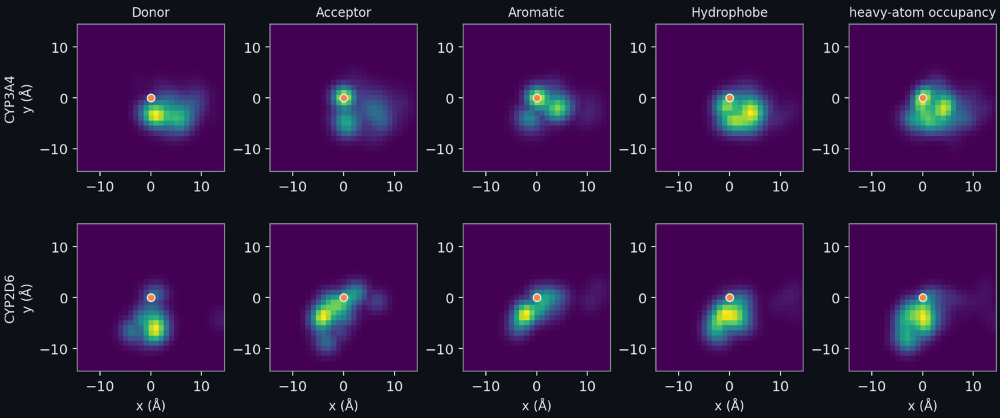

**Figure: The pockets of CYP3A4 and CYP2D6 as pharmacophore fields in the frame of the heme.** The pocket of each enzyme as the public crystal ligands put in the frame of the heme: the iron is at the origin of each panel, the heme plane is the plane of the page and z, the distance above it, is collapsed by taking the maximum along it. Each column is the density of one feature family of the ligands (donor, acceptor, aromatic ring, hydrophobe) and the last is the occupancy of their heavy atoms. CYP3A4 rests on 148 ligand copies of 101 distinct ligands and CYP2D6 on 51 copies of 10, so the CYP2D6 fields are the less certain of the two.

In [250]:
show_figure("pharm_pocket_fields")

**From a compound to a handful of numbers.** A compound has no position in the frame; it is given many. Up to twelve conformers within 5 kcal/mol of the lowest (the conformers of 3.4) are each placed by an **anchor atom** and a fixed set of orientations: sixty directions in a cone of 70 degrees around $z$ and eighteen spins about each, 1,080 in all. In the *donor mode*, which applies to a compound with a nitrogen that can bind the iron (the Type II donor of 1.9), that nitrogen sits 2.2 Å above the iron; in the *substrate mode* each non-aromatic carbon that bears a hydrogen is the anchor in turn, 4.5 Å above the iron, the middle of the distance at which a carbon is oxidised. A pose is refused when another heavy atom lies lower than 1.5 Å above the porphyrin plane or closer than 2.0 Å to the iron. A pose scores $S = \bar O + \frac{1}{|P|}\sum_{f \in P} \bar F_f$, where $\bar O$ is the mean occupancy at its heavy atoms, $P$ is the set of families that the compound has and $\bar F_f$ is the mean value of the field of family $f$ at the compound's features of that family, each read at the nearest grid point; no weight is fitted. For each mode that applies the block keeps the best score, its occupancy part, its six family parts, the share of poses that were accepted, the height of the centroid and the distance of the nearest heavy atom at the best pose: eleven columns, twenty-two for the two modes, and the same twenty-two for each pocket. Of the 6895 compounds of the two files, 42% have the donor mode and 98% the substrate mode for the CYP3A4 pocket.

**The test, and the control.** The block is added to the two deep boosted-tree candidates on feature sets A and A+fps (7.2), and the gate is the one of every addition: alone and inside the stack, corrected resampled t below 0.05 at both confidence cuts with a positive mean AUC difference, 3 repeats of 5 outer folds, and a replicate on 10 outer folds that must be met as well before the group can join the stack. Because the pocket is the whole point, each enzyme is also given the pocket of the *other* enzyme as a control that enters no gate: a gain that the control shares is not about the pocket.

In [251]:
pocket_table.round(4)

The table gives, for each enzyme, the change in AUC when the block of its own pocket is added to the default stack and when the block of the other pocket is. The gate of the own pocket is **not met for either enzyme** (alone and stacked at both cuts); the stacked comparison alone is met for neither enzyme. A group that fails its gate is written down as a negative result and is not tuned until it passes: the representation was not changed after the first run, and nothing of it enters the final stack.

**A first run that was void.** The block was first written with the conformer generator seeded with 0. In the version of RDKit used here, `EmbedMultipleConfs` with seed 0 returns the same conformer for every copy (the raw embeddings are identical and the energy span of the ensemble is zero), so the twelve conformers of that run were one conformer, and the hypothesis cache of 9.14 had the same defect. The first result of the block, NOT MET on both enzymes, is void: its logs are kept as `exploratory_pocket_first_run_seed0_own_CYP3A4.log` and the three others of that name (own and control pocket, for each enzyme), and no gate parser reads them. Both were rebuilt on 2026-10-23 with a conformer seed of 42, and `test_the_ensemble_of_a_flexible_compound_holds_distinct_conformers` requires distinct geometries. The older code that places conformers (the physics block, the pose terms, the basic-centre block and the fingerprint) uses seeds 42 or 7 and is not affected.

*On what actually ran.* `cypmode/challenge/pocket_pharmacophore.py` builds the fields (`build_fields`), places the conformers (`score_poses`, `compound_columns`) and caches the block for every compound of both files (job `262_pocket_pharmacophore_extract`); the reference set of CYP2D6 is collected by `cypmode/validation/reference_ligands.py` with the builder that made the one of CYP3A4. The gated runs are the jobs `263_pocket_pharmacophore_CYP3A4` and `264_pocket_pharmacophore_CYP2D6`, which also run the control, and `265_pocket_pharmacophore_replicate` runs the 10-fold comparison only for an enzyme whose own gate was met. The placement is rigid and sees no protein beyond two refusal rules, the field is read at the nearest grid point and there are at most twelve conformers, so the block is a cheap proxy for where a compound could sit in the pocket and not a docking score (**docking** is the search for the pose of a molecule in a pocket that a scoring function ranks best); its tests are in `tests/test_pocket_pharmacophore.py`. The same extraction (job 262) also writes the six columns of the site model of 9.14, which are computed from the same poses. The CYP2D6 reference set has few distinct ligands, and any result for that pocket carries that limit. The ensemble of up to twelve conformers is drawn with the seed 42 (a seed of 0 returns the same conformer every time in the installed RDKit, which turned a first run into a run with one conformer per compound; that run is kept in the logs and is not a verdict), and it contains a conformer within 1.0 Å of the bound pose for only 12% of the crystal ligand copies (11.11), so every verdict of this section and of 9.14 is a verdict for compounds placed in their low-energy conformers, which the bound state often is not.

In [252]:
# The two pharmacophore models of 9.14: the sizes of what was built (the sites of the pockets, the hypotheses of the vocabulary) and the gate lines of the runs (the model on its own enzyme, its control),
# every number read from the files that the queue jobs 262, 266 and 267 to 271 left.
import re

import numpy as np
import pandas as pd

from cypmode.challenge import pocket_pharmacophore as pocket_module

site_counts = {name: sum(len(v) for v in pocket_module.sites_of(pocket_module.load_fields(name)).values()) for name in ("cyp3a4", "cyp2d6")}
extract_line = re.search(r"(\d+) compounds, (\d+) realised hypotheses in all, (\d+) in the vocabulary \(at least (\d+) compounds\), (\d+) compounds realise none", (ROOT / "data/structure_track/outputs/cyp3a4/logs/pharmacophore_hypotheses_extract.log").read_text())
hyp_compounds, hyp_total, hyp_vocabulary, hyp_min_compounds, hyp_none = (int(v) for v in extract_line.groups())
model_logs = ROOT / "data/structure_track/outputs/cyp3a4/logs"
model_stacked = re.compile(r"z0=([\d.]+)\s+stacked base\+added vs base: AUC ([+-][\d.]+) \(p=([\d.]+), better (\d+)/(\d+)\)")
model_gate = re.compile(r"^(CYP\w+) GATE \((alone|stacked)[^)]*\): (MET|NOT MET)", re.MULTILINE)
model_runs = (
    ("site model", "CYP3A4", "own pocket (the addition)", "aux_site_cyp3a4_CYP3A4.log"),
    ("site model", "CYP3A4", "other pocket (the control)", "exploratory_site_control_CYP3A4.log"),
    ("site model", "CYP2D6", "own pocket (the addition)", "aux_site_cyp2d6_CYP2D6.log"),
    ("site model", "CYP2D6", "other pocket (the control)", "exploratory_site_control_CYP2D6.log"),
    ("hypothesis model", "CYP3A4", "real labels (the addition)", "aux_hypothesis_CYP3A4.log"),
    ("hypothesis model", "CYP3A4", "permuted labels (the control)", "exploratory_hypothesis_permuted_CYP3A4.log"),
    ("hypothesis model", "CYP2D6", "real labels (the addition)", "aux_hypothesis_CYP2D6.log"),
    ("hypothesis model", "CYP2D6", "permuted labels (the control)", "exploratory_hypothesis_permuted_CYP2D6.log"),
)
model_rows = []
for model, enzyme, role, log_name in model_runs:
    text = (model_logs / log_name).read_text()
    cuts = {float(z0): (float(gain), float(p), int(better), int(folds)) for z0, gain, p, better, folds in model_stacked.findall(text)}
    verdicts = {kind: verdict for iso, kind, verdict in model_gate.findall(text) if iso == enzyme}
    model_rows.append({"model": model, "enzyme": enzyme, "run": role, "stacked gain, z0 1.0": cuts[1.0][0], "p, z0 1.0": cuts[1.0][1], "stacked gain, z0 1.96": cuts[1.96][0], "p, z0 1.96": cuts[1.96][1],
                       "better folds, z0 1.0": f"{cuts[1.0][2]}/{cuts[1.0][3]}", "gate, alone": verdicts.get("alone", "n/a"), "gate, stacked": verdicts.get("stacked", "n/a")})
model_table = pd.DataFrame(model_rows)
is_addition = model_table["run"].str.contains("addition")
model_met = {m: [e for e in ("CYP3A4", "CYP2D6") if len(model_table[is_addition & (model_table["model"] == m) & (model_table["enzyme"] == e) & (model_table["gate, alone"] == "MET") & (model_table["gate, stacked"] == "MET")])] for m in ("site model", "hypothesis model")}
model_stack_met = {m: [e for e in ("CYP3A4", "CYP2D6") if len(model_table[is_addition & (model_table["model"] == m) & (model_table["enzyme"] == e) & (model_table["gate, stacked"] == "MET")])] for m in ("site model", "hypothesis model")}
control_rows = model_table[~is_addition]
control_shares = [f"{r.model} on {r.enzyme}" for r in control_rows.itertuples() if r[4] > 0 and r[6] > 0 and r[5] < 0.05 and r[7] < 0.05]

## 9.14 Pharmacophore models: sites from the pocket, hypotheses from the ligands

> **Field:** Cheminformatics · Structural biology · Statistics · Machine learning

*Where this section sits:* 3.5, 7.8, 10.6, 11.8 and 9.13 turned a compound into numbers that describe its pharmacophore, and every gate they met was failed or not yet decided. None of them built a *model*. This section builds two, one from each kind of evidence that pharmacophore modelling has always used, and gates them like every other addition. It rests on 9.13 (the heme frame and the fields), on 7.2 (the boosted trees to which columns are added) and on 6.3 (nested validation, which decides here how a model may be fitted).

**What a pharmacophore model is.** A **pharmacophore hypothesis** is a statement about the arrangement of chemical features, such as "an acceptor, an aromatic ring and a hydrophobic atom group with these distances between them", that a molecule must offer to bind. A *model* is a set of such hypotheses that was derived from data and is then used to judge a molecule: to say how well it matches. There are two sources of data. A **structure-based** model is read from the crystal structures of the target: where in the pocket the ligands that were seen place their donors, acceptors and rings. A **ligand-based** model is learned from molecules whose activity is known, by asking which arrangements the actives share and the inactives lack. Both are built here.

**The structure-based site model.** The six feature fields of 9.13 already say where the crystal ligands of an enzyme put each family of features. The model keeps the peaks. In each field the points that are higher than all of their 26 neighbours and at least 0.35 (the maximum of a field is 1) are the candidates, taken in order of height; a candidate is kept as a **site** when it is at least 2.5 Å from every kept site of the same family, and at most four are kept per family. The weight of a site is the height of the field at it, and its tolerance is a sphere of 1.5 Å, the width of the fields. CYP3A4 ends with 13 sites and CYP2D6 with 9. A placed compound *matches* a site when one of its features of that family lies inside the sphere. For each mode of 9.13 that applies, and over the same poses, the model gives three numbers per pocket: the **recall**, the weight of the matched sites over the weight of all sites at the best pose; the number of sites matched at that pose; and the **precision**, the share of the compound's typed features that lie in a sphere of a site of their own family at that pose. The best pose is the one with the largest recall and, among equals, the larger precision. These six numbers are the block `st3a4` or `st2d6` of the feature store.

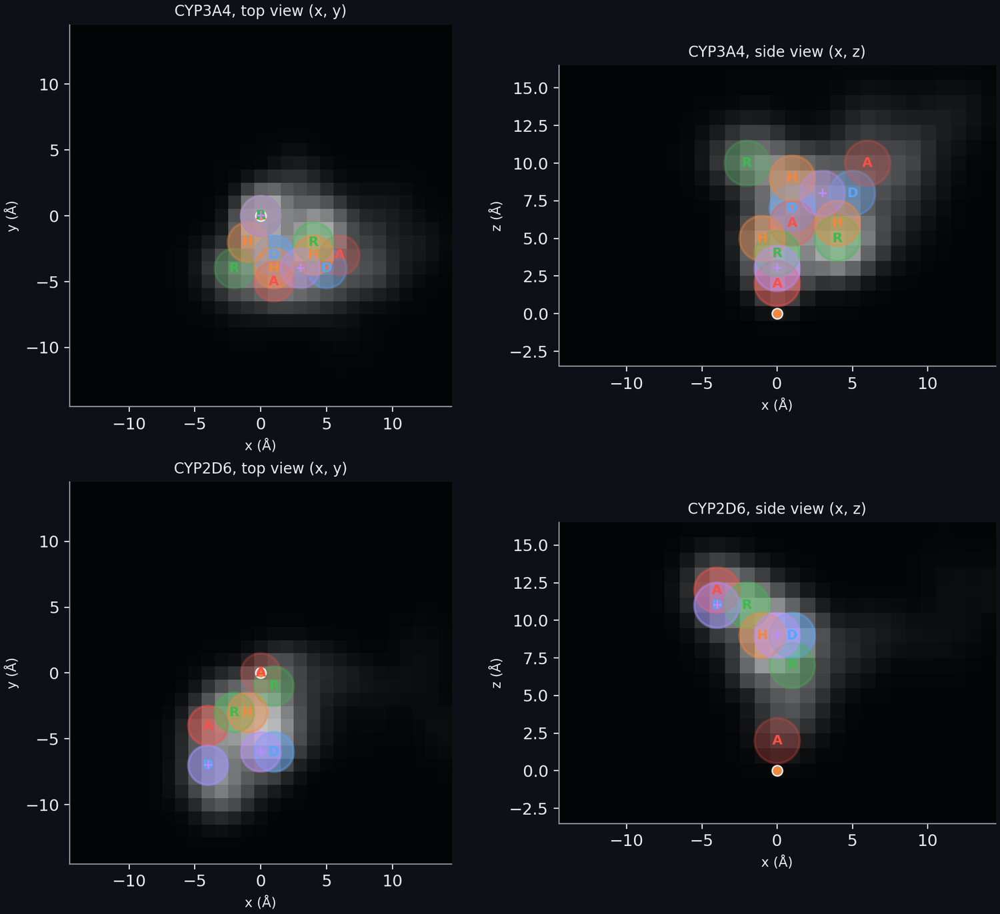

**Figure: The sites of the structure-based pharmacophore model of each pocket.** The sites of the structure-based pharmacophore model of each pocket, in the frame of the heme (the iron is the orange dot). A site is a local maximum of one of the six feature fields of the crystal ligands (value at least 0.35, at most 4 per family, 2.5 A apart); the circle is its tolerance sphere of 1.5 A, the letter its family (D donor, A acceptor, R aromatic ring, H hydrophobe, + and − ionisable) and the opacity its weight. Grey: the heavy-atom occupancy of the same ligands. Left: seen from above the heme (x, y); right: from the side (x, z). CYP3A4 has 13 sites and CYP2D6 9.

In [253]:
show_figure("pharm_site_model")

**The ligand-based hypothesis model.** The hypotheses are those of the pmapper program: a subset of two or three pharmacophore features with the binned distances between them (bins of 1 Å), identified by the md5 signature that pmapper computes for the subset. Unlike the fingerprint of 3.5, nothing is folded into a shared bit, so two hypotheses never share a column. A compound *realises* a hypothesis when one of its conformers, the same up to twelve of 9.13, offers the subset with those distances. Over the 6895 compounds of the two files the conformers realise 4167504 hypotheses in all (counting each compound once per hypothesis); the vocabulary keeps the 23304 that at least 10 compounds realise, and 2 compounds realise none. No label is read for this step.

*Fitting inside a training split.* Let $n_1$ and $n_0$ be the numbers of positive and negative rows of the training split, and for a hypothesis $h$ let $a_h$ and $b_h$ be the numbers of positive and of negative rows that realise it. A hypothesis is considered only when $a_h + b_h \ge 10$. Its **log-likelihood ratio** compares how common it is among the positives with how common it is among the negatives, with one pseudo-observation added to each count so that a hypothesis seen in no negative row does not get an infinite ratio:

$$\lambda_h = \ln\frac{a_h + 1}{n_1 + 2} - \ln\frac{b_h + 1}{n_0 + 2}.$$

A positive $\lambda_h$ says the hypothesis favours the positive class. Hypotheses are ranked by the **chi-square statistic** of the two-by-two table of presence against class, which measures how far the table is from one in which presence and class are unrelated:

$$\chi^2_h = \frac{n\,\bigl(a_h (n_0 - b_h) - (n_1 - a_h)\, b_h\bigr)^2}{(a_h + b_h)\,(n - a_h - b_h)\, n_1 n_0}, \qquad n = n_1 + n_0.$$

The model keeps the 60 hypotheses of largest $\chi^2_h$ among those with $\lambda_h > 0$ (the pharmacophore of the positives) and the 60 among those with $\lambda_h < 0$ (the exclusion hypotheses: arrangements that active molecules tend to lack). A compound $c$ is then described by five numbers: the sum $s_c = \sum_{h \in K} \lambda_h r_{ch}$ over the kept set $K$, where $r_{ch}$ is 1 when $c$ realises $h$ and 0 otherwise; the number of positive and of exclusion hypotheses it realises; the largest $\lambda_h$ among those it realises (0 when none); and the share of the five strongest positive hypotheses that it realises. The sum is the log-odds of a Bayes classifier that treats the hypotheses as independent given the class. They are not independent (overlapping subsets share features), so the sum is a ranking score, not a probability, and the boosted trees that receive it take it for what it is.

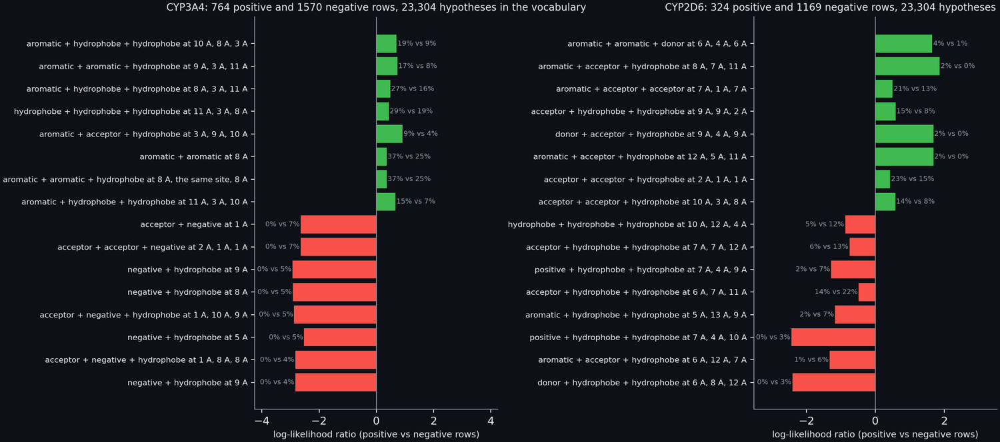

**Figure: The strongest hypotheses of the ligand-based pharmacophore model of each enzyme.** The ligand-based hypothesis model fitted on all the training rows of each enzyme, to show what it holds (the model inside the validation is refitted in every training split, and this fit is not a measure of performance). Each bar is one hypothesis: the feature types and the distances between them, as found in one compound that realises it. Green bars are the strongest of the 60 hypotheses that favour a positive label (the pharmacophore of the positives), red bars the strongest of the 60 exclusion hypotheses; the length is the log-likelihood ratio and the numbers are the share of positive and of negative rows that realise the hypothesis.

In [254]:
show_figure("pharm_hypotheses")

**Keeping the columns free of labels.** A model that chooses its hypotheses with the labels of the rows it then scores will score those rows too well, and a boosted tree trained on such a column learns to trust it. The training rows of a task therefore receive the five columns **out of fold**: from a model, including the choice of the 120 hypotheses, fitted on the other four of five stratified folds of the training rows. The evaluation rows receive them from the model fitted on all training rows, so no evaluation label is read (the tests flip every evaluation label and the predictions must not move, as for every runner). A test with labels that carry no signal shows the need: the out-of-fold column has an AUC below 0.58, the in-sample column above 0.75.

**The test, the controls and the rule.** Each model is added to the two deep boosted-tree candidates on feature sets A and A+fps, and the gate is the one of every addition: alone and inside the stack, corrected resampled t below 0.05 at both confidence cuts with a positive mean AUC difference, 3 repeats of 5 outer folds, then a replicate on 10 outer folds that must be met as well before a group can join the stack. The site model of an enzyme is tested on that enzyme only, with the site model of the *other* enzyme as the control: a gain that the other pocket shares is not about the pocket. The hypothesis model is tested on both enzymes, with the same model fitted on **permuted labels** (the labels shuffled within the training rows before any step) as the control: a gain that survives the permutation is not about the hypotheses. Neither control enters a gate.

In [255]:
model_table.round(4)

The table gives, for each model and enzyme, the change in AUC when its columns are added to the default stack, at the two confidence cuts, and for the control. The gate (alone and stacked, both cuts) is met for **no model on either enzyme**; the stacked comparison alone is met for none. No control shares a gain that is significant at both cuts. A group that fails its gate is written down as a negative result and is not tuned until it passes: neither model was changed after the first run, and nothing of them enters the final stack.

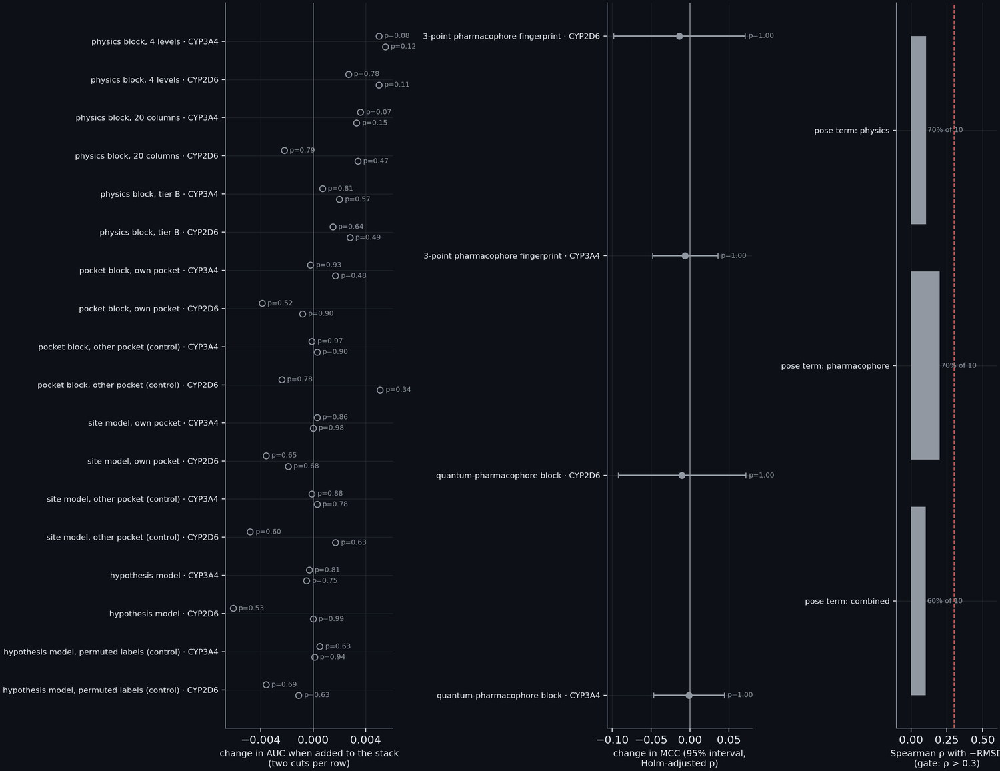

**Figure: Every pharmacophore representation of the project and its verdict.** Every pharmacophore representation and model of the project and what happened to it (the fourth level of the physics block is its pharmacophore level; the site model and the hypothesis model are the two pharmacophore models, each with its control). Left: the change in AUC when the block is added to the default stack, at the two confidence cuts, for the 18 comparisons that have a log (a point is filled when its corrected p is below 0.05); the gate asks for both cuts, and 0 of these comparisons pass it. Middle: the change in MCC of the older blocks against the same base, with the 95% interval and the Holm-adjusted p (4 comparisons). Right: the Spearman correlation of the pose terms with minus the true RMSD over the benchmark poses, with the gate at 0.3 (3 terms).

In [256]:
show_figure("pharm_forest")

**What the last figure shows.** Every pharmacophore representation and model of the project, whichever of the three levels it describes, and what happened to it. The ligand-only representations (the three-point fingerprint, the quantum-pharmacophore block, the physics block with its fourth level), the pose terms, the pocket block and the two models with their controls are on one page, so that the claim "pharmacophore information does not help" can be read for what it covers: a family of attempts, each on its own measure, and not one failed idea. Where a model and its control look alike, the figure shows it.

*On what actually ran.* `cypmode/challenge/pharmacophore_hypotheses.py` finds the hypotheses of a compound (`realised`), caches the vocabulary for every compound of both files (job `266_hypothesis_extract`), fits the model (`fit_model`), computes its columns (`model_columns`) and the out-of-fold and permuted variants (`hypothesis_columns`); the candidates are `hypothesis_candidates` and the site candidates of `nested_runners.py`. The gated runs are the jobs `267_site_model_CYP3A4` and `268_site_model_CYP2D6` (each with the control of the other pocket) and `269_hypothesis_model_CYP3A4` and `270_hypothesis_model_CYP2D6` (each with the permuted-label control), and `271_pharmacophore_models_replicate` runs the 10-fold comparison only for a group whose stacked gate was met. The tests are in `tests/test_pharmacophore_hypotheses.py` (a planted hypothesis is found, the out-of-fold columns carry no selection bias, the evaluation columns do not move when evaluation labels are flipped, the permuted control carries no label information) and in `tests/test_pocket_pharmacophore.py` (the sites of a field, the matching of a pose). Limits: the hypotheses use conformers from one force field and a bin of 1 Å, so two arrangements that differ by a fraction of an ångström on a bin edge are different hypotheses; the site model inherits the rigid placement of 9.13 and the small crystal set of CYP2D6; and a hypothesis that distinguishes a series of one chemotype is a property of that series, which the nested validation, whose folds keep similar compounds apart, is built to expose.

In [257]:
# The numbers of 9.15: the share of time-dependent inhibitors among the compounds that carry each functional group, and the matched pairs that gain one group, for both enzymes. The groups are the fixed table of
# cypmode/challenge/functional_groups.py; the pairs are the ones that the matched-pair features of 9.2 used (the cache of cypmode/challenge/mmp_transfer.py).
import numpy as np
import pandas as pd

from cypmode.challenge import functional_groups as groups_module
from cypmode.challenge.mmp_transfer import get_pairs
from cypmode.challenge.tdi_targets import BOTH_ARMS, training_view

train_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")
test_file = pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TEST-BLINDED.csv")
all_smiles = list(train_file["SMILES"]) + list(test_file["SMILES"])
pairs_cache = get_pairs(all_smiles)
group_tables, pair_tables, base_rates, n_pool = {}, {}, {}, {}
for enzyme in ("CYP3A4", "CYP2D6"):
    view = training_view(train_file, enzyme)
    keep = (view["population"] == BOTH_ARMS).to_numpy()
    labels = view["label"][keep].astype(int).to_numpy()
    base_rates[enzyme], n_pool[enzyme] = float(labels.mean()), int(len(labels))
    group_tables[enzyme] = groups_module.group_rates(groups_module.group_matrix(train_file["SMILES"][keep].tolist()), labels).set_index("group")
    pair_tables[enzyme], pair_detail = groups_module.group_gain_pairs(all_smiles, pairs_cache, np.flatnonzero(keep), labels, 5)
    pair_tables[enzyme] = pair_tables[enzyme].set_index("group")
    n_single_gain = {enzyme: int((pair_detail["gained"] >= 0).sum())} if enzyme == "CYP3A4" else {**n_single_gain, enzyme: int((pair_detail["gained"] >= 0).sum())}


def group_rate(group, enzyme):
    """(rate, number of compounds) of a group for an enzyme, (nan, 0) when fewer than 10 compounds carry it."""
    table = group_tables[enzyme]
    return (float(table.loc[group, "rate"]), int(table.loc[group, "n"])) if group in table.index else (float("nan"), 0)


def group_gain(group, enzyme):
    """(mean change of the label, standard error, number of pairs) of the pairs that gain a group, (nan, nan, 0) when fewer than 5 pairs do."""
    table = pair_tables[enzyme]
    return (float(table.loc[group, "mean"]), float(table.loc[group, "se"]), int(table.loc[group, "pairs"])) if group in table.index else (float("nan"), float("nan"), 0)


assert group_tables["CYP3A4"].index[0] == "methylenedioxyphenyl" and group_tables["CYP2D6"].index[0] == "methylenedioxyphenyl", "the text of 9.15 says that this group has the highest rate on both enzymes"
mdp_3a4, mdp_3a4_n = group_rate("methylenedioxyphenyl", "CYP3A4")
mdp_2d6, mdp_2d6_n = group_rate("methylenedioxyphenyl", "CYP2D6")
acid_3a4, acid_3a4_n = group_rate("carboxylic acid", "CYP3A4")
azole_3a4, azole_3a4_n = group_rate("azole or pyridine (heme binder)", "CYP3A4")
azole_2d6, azole_2d6_n = group_rate("azole or pyridine (heme binder)", "CYP2D6")
thiophene_3a4, thiophene_3a4_n = group_rate("thiophene", "CYP3A4")
gain_tbutyl, gain_tbutyl_se, gain_tbutyl_n = group_gain("tert-butyl", "CYP3A4")
gain_acid, gain_acid_se, gain_acid_n = group_gain("carboxylic acid", "CYP3A4")
assert thiophene_3a4 > base_rates["CYP3A4"] and group_rate("furan", "CYP3A4")[0] > base_rates["CYP3A4"], "the text says that thiophenes and furans are above the base rate on CYP3A4"
assert acid_3a4 < 0.1 and azole_3a4 < base_rates["CYP3A4"] + 0.03 and azole_2d6 < base_rates["CYP2D6"] + 0.03, "the text says that acids are rare among inhibitors and that heme binders are not enriched"
assert gain_tbutyl > 0 > gain_acid, "the text reads the direction of these two changes"
n_groups_3a4, n_groups_2d6 = len(pair_tables["CYP3A4"]), len(pair_tables["CYP2D6"])
gain_summary = pair_tables["CYP3A4"].reset_index()[["group", "pairs", "mean", "se"]].head(8).round(2)

## 9.15 Reading the pharmacophore on molecules: functional groups, structure-activity relationships and the pocket, in 2D and in 3D

> **Field:** Chemistry · Cheminformatics · Structural biology · Pharmacology

*Where this section sits:* 9.13 and 9.14 describe the pharmacophore of a compound with fields, sites and hypotheses, and 11.11 does the same for a predicted pose. Those descriptions are numbers. This section draws them: it puts each representation and each model on real molecules, flat on the page and in space, and connects them to the two things that a chemist reads first in a structure, its **functional groups** and the **structure-activity relationship** (SAR) that they carry. It covers both tracks, so that the reader can follow one idea, a feature of a molecule, from the formula of a compound to its place in a pocket.

**Three words.** A **functional group** is a small, named arrangement of atoms that behaves as a unit in a molecule: the carboxylic acid $-\mathrm{COOH}$, the amide $-\mathrm{CONH}-$, a chlorine on an aromatic ring. A **pharmacophore feature** is what a group (or an atom, or a ring) offers to a binding site: a hydrogen-bond donor, an acceptor, an aromatic ring, a hydrophobic patch, a group that is positively or negatively charged at the pH of the body. One functional group usually offers several features (an amide is both a donor and an acceptor), and the table of `cypmode/challenge/functional_groups.py` says which. A **structure-activity relationship** is the way a change in the structure of a molecule changes its activity. It is stated as a rule of thumb ("adding a tert-butyl group makes a compound a better time-dependent inhibitor") and tested on **matched molecular pairs**, two compounds that differ by one small fragment at the same place, so that nothing else changed.

**The functional groups of the table.** The table was written before any rate was looked at and is not changed: eighteen groups, each a SMARTS pattern (the pattern language of 2.1) with the families of features that it carries and, where the literature names one, why it matters for a cytochrome P450. The first figure takes each group in turn and asks how often the compounds that carry it are time-dependent inhibitors. For CYP3A4, 2334 labelled compounds, of which 33% are inhibitors, and for CYP2D6, 1493 compounds with 22%; the interval drawn on each rate is the **Wilson interval**, the range of values of a proportion that the counts do not exclude, which unlike the interval of a mean plus or minus two standard errors cannot leave the range from 0 to 1 when a group is rare.

In [258]:
gain_summary

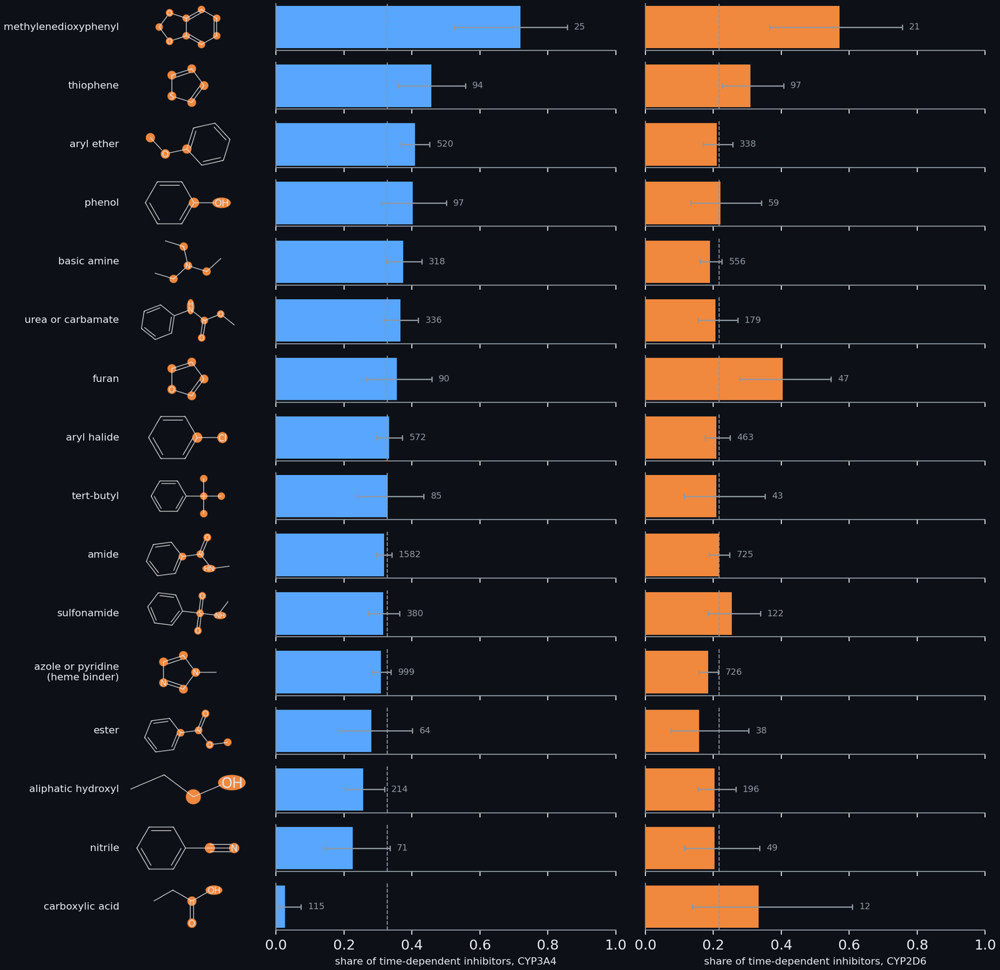

**Figure: Which functional groups go with time-dependent inhibition.** Which functional groups go with time-dependent inhibition? For each group of a fixed table (drawn at the left on a small example, with the pharmacophore features it carries), the share of time-dependent inhibitors among the training compounds that carry it, for CYP3A4 and CYP2D6, with the Wilson 95% interval; the dashed line is the share among all compounds and the number is how many carry the group (groups carried by at least 10 compounds). The highest rate is for methylenedioxyphenyl on CYP3A4 (72% of 25) and for methylenedioxyphenyl on CYP2D6 (57% of 21), both groups that P450s are known to turn into reactive species. Carboxylic acids are almost never inhibitors of CYP3A4 (3% of 115). The groups that bind the heme (azoles and pyridines) are not enriched (31%): they inhibit by binding, which the time-dependent label is built to remove.

In [259]:
show_figure("pharm_functional_groups")

**What the figure says.** The group with the highest rate on CYP3A4 is the methylenedioxyphenyl ring, with 72% of 25 compounds inhibiting (the base rate is 33%), and on CYP2D6 it is again the group with the highest rate, 57% of 21. This is the textbook case of a **mechanism-based inactivator**: the enzyme oxidises the ring, the product is a carbene that binds the heme iron, and the enzyme is lost for as long as the complex lives. Thiophenes (46% of 94 on CYP3A4) and furans are other groups that P450s turn into reactive intermediates, and the figure shows both above the base rate (the furans only just); terminal alkynes, a third such group, are too rare in the data to appear. At the other end, carboxylic acids are almost never inhibitors of CYP3A4 (3% of 115): CYP3A4 prefers neutral and basic compounds and an acid is held outside the pocket. The groups that bind the heme, the azoles and the pyridines, are *not* enriched (31% of 999 on CYP3A4, 18% of 726 on CYP2D6): they inhibit by binding the iron, and a compound that does so is a **reversible** inhibitor whose inhibition is already counted in the direct arm that the label subtracts (1.8). The label of this challenge asks for the loss of activity that grows with time, which needs a chemistry that the heme binder alone does not supply. This is the reason why the heme-binding pharmacophore of 9.13 and 9.14 is a weak predictor of the label, and why a pharmacophore model for this track has to be read as a model of *who is inhibited*, not of *who is inactivated*.

**The structure-activity relationship as a change.** The rates above compare groups of different compounds, so a group can look good only because the compounds that carry it have something else in common. A matched pair removes that confound. `cypmode/challenge/mmp_transfer.py` (the pair analysis of 9.2) finds, by single-bond fragmentation, the pairs of training compounds that differ by one fragment of at most ten heavy atoms. The second figure counts a pair for a functional group when the second compound has the group, the first does not and no other group of the table changes, and gives for each group the mean change of the label over those pairs (0 for a non-inhibitor, 1 for an inhibitor). The pairs are few at the level of the exact exchange of fragments (no exchange has as many as five labelled pairs), which is why they are grouped by the group they gain. CYP3A4 has 585 labelled pairs that gain exactly one group, 16 groups with at least five of them, and CYP2D6 has 59 pairs and 5 groups.

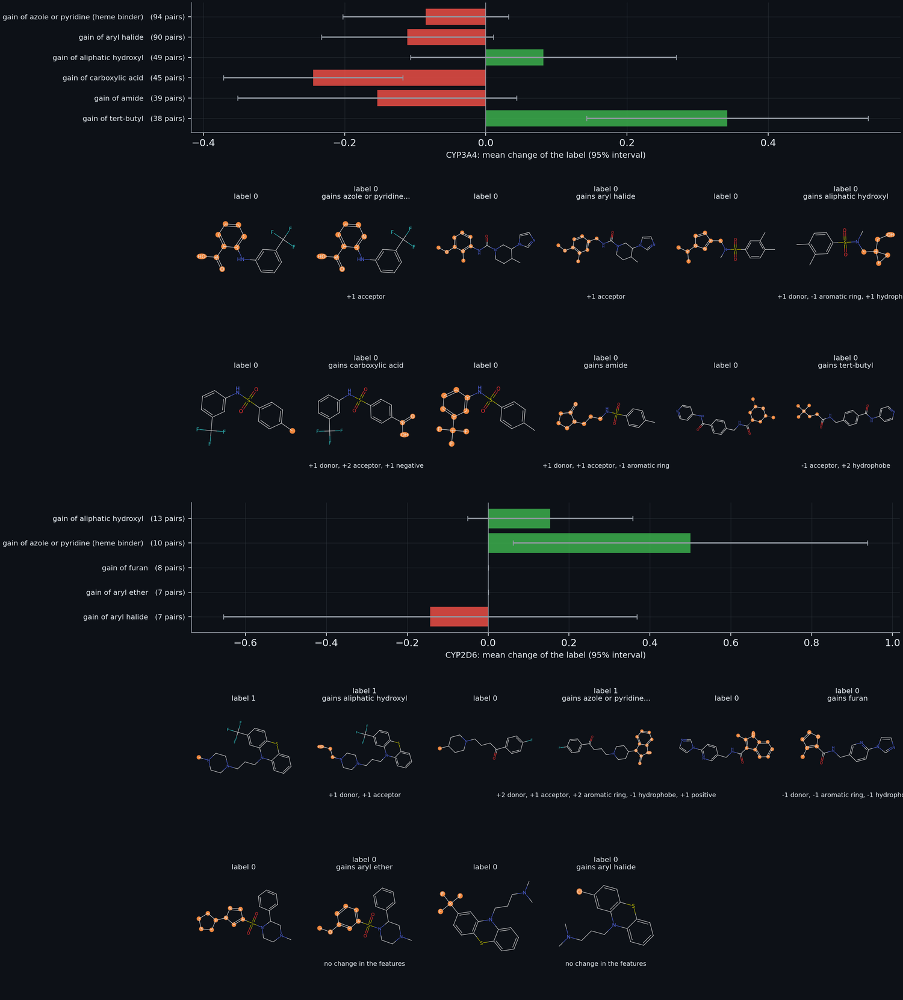

**Figure: Structure-activity relationship as a change: matched pairs of the training set.** Structure-activity relationship as a change. A matched pair is two compounds that differ by one small fragment at the same place (single-bond fragmentation, a variable part of at most 10 heavy atoms). Each pair that gains one functional group of the fixed table and changes no other is counted for that group; the bars give the mean change of the label (0 = not a time-dependent inhibitor, 1 = inhibitor) over those pairs for the six groups with the most pairs, with one standard error. Below, for each group, one real pair, the one whose change is closest to the mean of its group, with the changed fragment highlighted and the change in the number of pharmacophore features. CYP3A4: 585 labelled pairs gain exactly one group; 16 groups have at least 5 of them (38 to 94 in the six shown); CYP2D6: 59 labelled pairs gain exactly one group; 5 groups have at least 5 of them (7 to 13 in the six shown). A change of label that follows a change in a feature is a structure-activity relationship; one that does not is not, and the pairs that are few say little: CYP2D6 has far fewer labelled pairs than CYP3A4.

In [260]:
show_figure("pharm_mmp_sar")

**Reading the pairs.** Gaining a tert-butyl group moves the label by +0.34 (standard error 0.10, 38 pairs) on CYP3A4, and gaining a carboxylic acid by -0.24 (0.06, 45 pairs): for the acid the pairs agree with the low rate of the first figure. For the tert-butyl group they say something that the rates do not: the compounds that carry it are inhibitors as often as the base rate says, yet the pairs that gain it become inhibitors, so that the group co-occurs with other features that hide its effect in the comparison of groups and only the pair, which holds everything else fixed, shows it. A change in a group that moves the label by less than its standard error is not an SAR and is not read as one; the table gives the first eight groups. Each real pair under the bars is the one whose change is the most typical of its group, not the most extreme, and the line under it gives what the pair did to the pharmacophore features: a transformation that changes the label and the features together is a candidate for the pharmacophore explanation, one that changes the label and no feature is not.

**The same compounds as features.** The surest compounds of the training set, drawn twice: the atoms of their functional groups, and the atoms of their pharmacophore features by the RDKit definitions. The two drawings answer different questions. The groups say what a chemist calls the parts of the molecule; the features say what a binding site sees. A ring nitrogen that is part of an azole is, at once, an acceptor, a member of an aromatic ring and the heme-binding atom, and the figure shows that an atom belongs to several features. The 3D blocks of 9.13 and 9.14 place exactly these features in a pocket.

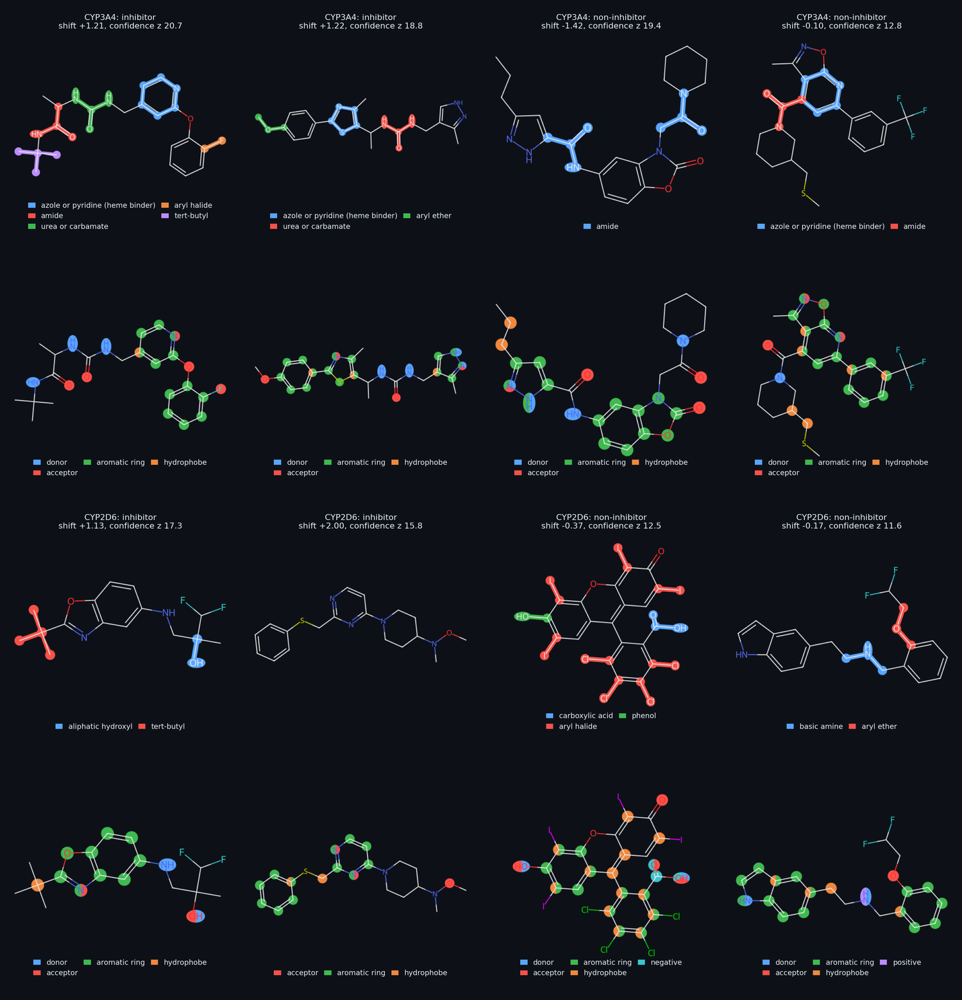

**Figure: The surest compounds with their functional groups and their pharmacophore features.** The compounds that the label is surest about, with what they carry. For each enzyme the two time-dependent inhibitors and the two non-inhibitors of the training set with the largest label confidence, drawn from their SMILES. Upper row of each enzyme: the atoms of the functional groups of the fixed table (one colour per group); lower row: the atoms of the pharmacophore features by the RDKit definitions (a colour per family; an atom in two features, such as a ring nitrogen that is an acceptor and part of an aromatic ring, carries both). This is the 2D view of what the pocket block, the site model and the hypothesis model describe in 3D.

In [261]:
show_figure("pharm_features_examples")

**What the ligand-based model looks for.** The hypothesis model of 9.14 was described there by a list of feature types and distances. Here each of its strongest hypotheses is put back on a molecule that realises it, so that the three or two features are seen as atoms of a structure and as spheres on a 3D conformer joined by their distances, the triangle that the program calls a three-point pharmacophore. A hypothesis that favours inhibitors and one that excludes them are shown for each enzyme. The conformers are low-energy shapes drawn with the seed 42, not bound poses (11.11 measures how often such a shape contains the bound one), and the model is fitted on all training rows here, so the figure describes it and does not measure how well it predicts.

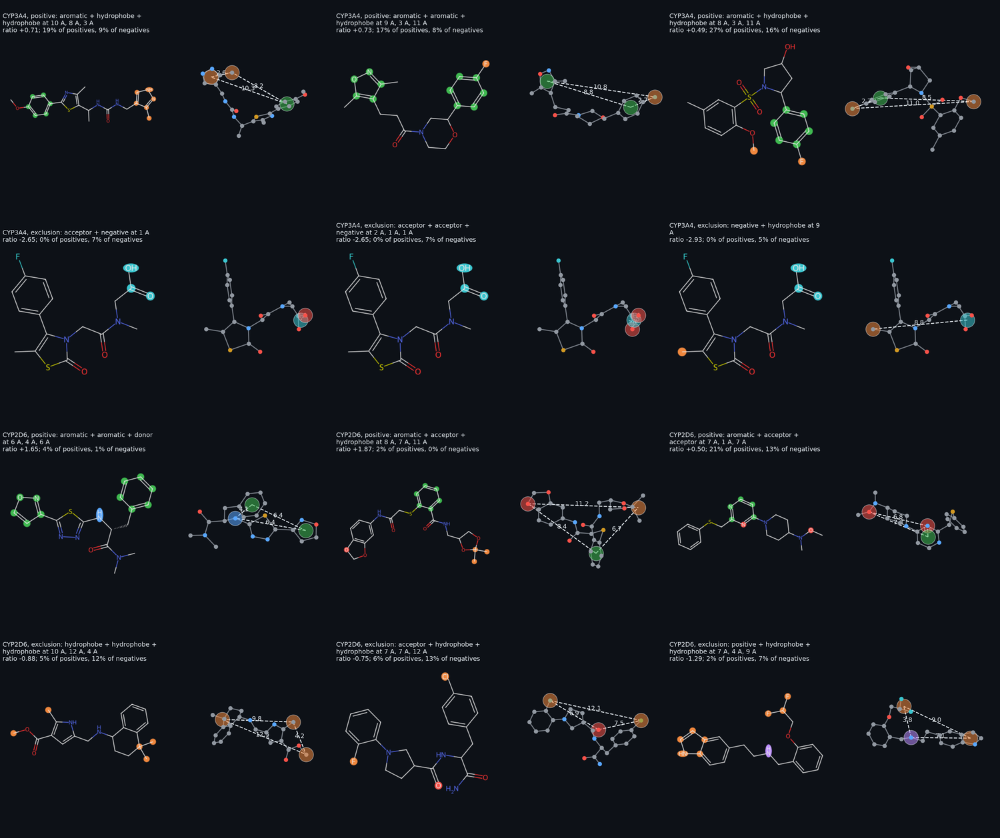

**Figure: The hypotheses of the ligand-based model, on compounds, in 2D and in 3D.** What the ligand-based pharmacophore model looks for, on real compounds. For each enzyme the 3 strongest hypotheses that favour a positive label (top rows) and the 3 strongest exclusion hypotheses (bottom rows), each shown on the training compound that realises it and that the label is surest about: at the left the atoms of its two or three features coloured by family (green aromatic ring, red acceptor, blue donor, orange hydrophobe), at the right the same features as spheres on a 3D conformer (ETKDG, seed 42: a low-energy shape, not a bound pose), joined by dashed lines that carry the distances in Å. The model is fitted on all training rows of the enzyme, so this is a description of what it holds and not a measure of how well it predicts; the numbers above each pair are the log-likelihood ratio and the share of positive and of negative training compounds that realise the hypothesis.

In [262]:
show_figure("pharm_hypotheses_2d3d")

**One compound, every representation.** The atlas takes ketoconazole, the reference ligand of the CYP3A4 complex 2V0M, and draws it in each of the representations of the project: its functional groups, its feature families, a three-point pharmacophore on a 3D conformer, the pharmacophore level of the physics block (the carbon atoms by the energy needed to abstract a hydrogen, and the heme-binding nitrogen), the electronic level (the partial charge of each atom, with the scalars of the quantum block), and the placement of the pocket block with the sites of 9.14 in the real crystal structure. It is the figure to read first if the vocabulary of Part IX is new.

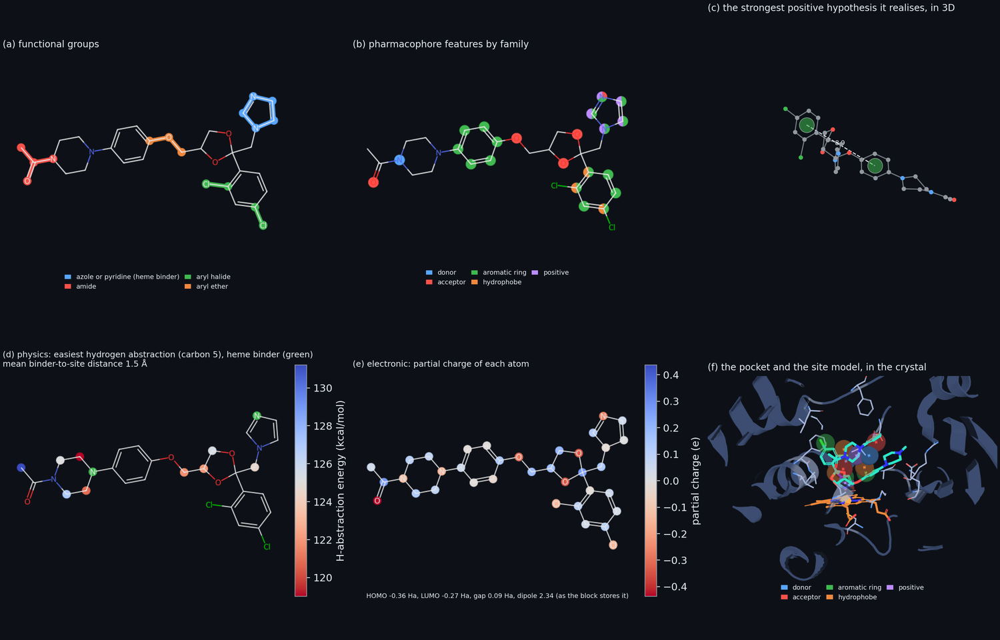

**Figure: One compound in every pharmacophore representation of the project.** One compound, every pharmacophore representation of the project: ketoconazole, the CYP3A4 reference complex 2V0M. (a) Its functional groups (fixed table). (b) Its pharmacophore features by family, the atoms that the feature-based blocks work with. (c) On a 3D conformer (ETKDG, seed 42: a low-energy shape, not the bound pose), the strongest positive hypothesis of the ligand-based model that it realises (aromatic + aromatic, log-likelihood ratio +0.36): the translucent spheres are its features, the dashed lines carry the distances in Å (the three-point pharmacophore of 3.5 and 7.8). (d) The pharmacophore level of the physics block (10.6): the carbon atoms coloured by the energy needed to abstract one of their hydrogens (red the easiest, blue the hardest: a likely site of oxidation is red) and the heme-binding nitrogen in green; the mean distance between the binder and the easiest site over the conformers is in the label. (e) The electronic level: the GFN2-xTB partial charge of each atom (blue positive, red negative) with the scalars of the quantum-pharmacophore block (energies in Hartree). (f) The pocket block and the site model in the real crystal structure: the ligand in the pocket of CYP3A4 with the sites of 9.14 as translucent spheres.

In [263]:
show_figure("pharm_atlas")

**The pocket model on the protein it came from.** The sites of 9.14 were found in the frame of the heme from the ligands of many crystal complexes. The next figure puts them back into one real complex of each enzyme, as translucent spheres of their tolerance radius, so that the reader sees the model in the cavity that produced it: a crystal structure of CYP3A4 with ketoconazole and one of CYP2D6 with the ligand whose atoms come closest to the iron. The model is holo, which is to say that it was read from complexes; what an apo or a cryptic pocket looks like is not in it, and 11.11 says how far that limit can be measured.

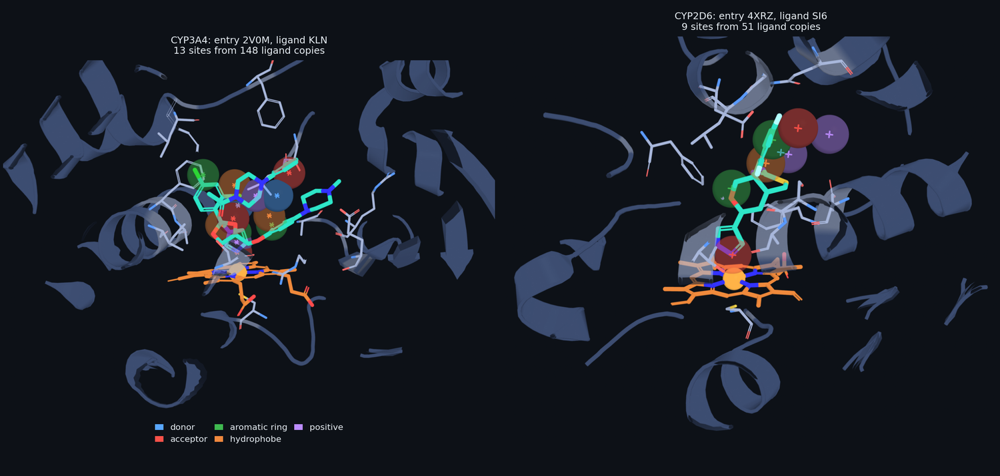

**Figure: The pocket pharmacophore model on the crystal structures of CYP3A4 and CYP2D6.** The pocket pharmacophore model on the protein it was read from. Real crystal structures rendered with PyMOL: the heme (orange) with its iron, the lining residues, the ligand of the entry (teal) and, as translucent spheres of the tolerance radius of 1.5 Å, the sites of the structure-based model of 9.14, coloured by feature family (blue donor, red acceptor, green aromatic ring, orange hydrophobe, purple positive). The sites are built from the ligands of all the crystal entries of the enzyme in the frame of the heme and carried back into the coordinates of the entry shown. CYP3A4: entry 2V0M with the ligand KLN (13 sites); CYP2D6: entry 4XRZ with the ligand SI6 (9 sites). The model is holo: it knows where ligands sat in these complexes, not what an apo or a cryptic pocket looks like (see 11.11).

In [264]:
show_figure("pharm_pocket_3d")

**The structure track.** Section 11.11 asked whether the pharmacophore model of a pose can choose the better pose from a pool, and the answer there is the verdict of its gate. The next figure shows why the question is hard, on real poses. For three benchmark ligands, chosen by a rule fixed in advance (the smallest, the median and the largest first-sample RMSD of the unguided runs), it draws the best and the worst pose of the pool in the pocket of the predicted complex, with the crystal pose of the same ligand in white, the sites of the model as spheres (firmer where a feature of the pose matches, nearly transparent where none does) and the features of the pose as small solid spheres. A pose a few ångströms from the crystal one can match as many sites as the true one: the sites are broad and every pose is in the same region of the same pocket.

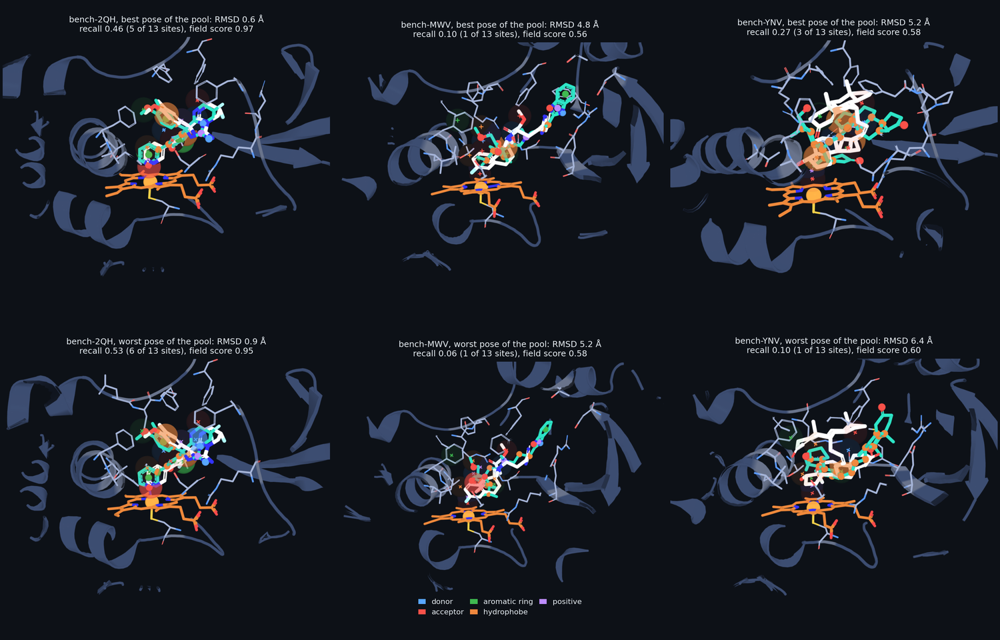

**Figure: The pharmacophore model on real poses: the best and the worst pose of three benchmark ligands.** Why the pharmacophore model of a pose does not rank poses. Real structures rendered with PyMOL: the predicted complex (teal ligand, orange heme), the crystal pose of the same ligand (white, the crystal entry aligned on the protein) and the sites of the structure-based model (translucent spheres, one colour per feature family) built without the references of that ligand and its analogues; a site that a feature of the pose matches is drawn firmer, one that it does not is nearly transparent, and the small solid spheres are the features of the pose. For the benchmark ligands with the smallest, the median and the largest first-sample RMSD of the unguided runs (bench-2QH, bench-MWV, bench-YNV), the best (top row) and the worst (bottom row) pose of the pool. The model sees where features lie, not whether the pose is the crystal one: a pose a few ångströms away from the crystal pose can match as many sites as the true one, which is what the gate of the pharmacophore model measured.

In [265]:
show_figure("struct_pharm_pose_3d")

**Structure-activity relationship in the structure track.** The series benchmark of 11.5 has three pairs of analogues that differ by one change of linker (a thioether where a pair has an amine, a sulfonamide where another has an amide). Each member is drawn in 2D with the atoms that the pair changes highlighted (the atoms outside the maximum common substructure of the pair, and those that change element), next to its first predicted pose in 3D with the crystal pose and the sites of the model rebuilt without the references of either member. The pyridine nitrogen of every member lies at the distance of a Type II bond from the iron, so the series shares its heme-binding pharmacophore; what the pair changes is what the linker puts on the way out of the pocket. This is the structure track's form of an SAR: a change of structure read as a change of pose and of feature.

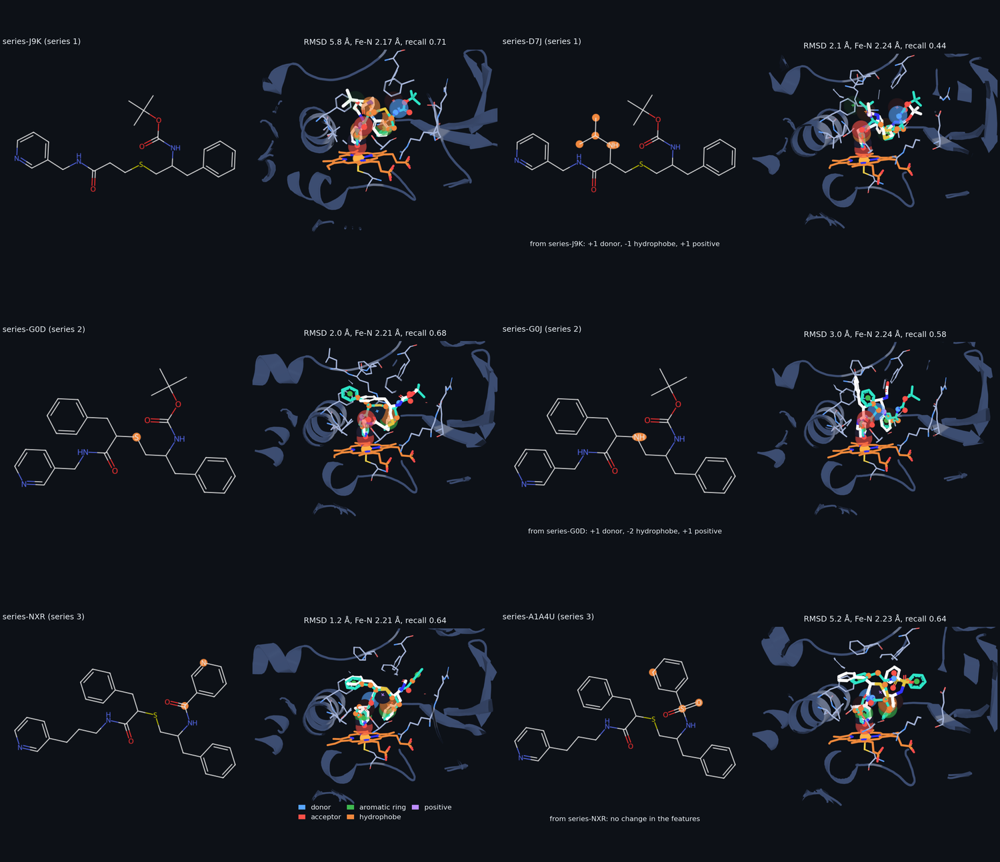

**Figure: Structure-activity relationship in the series benchmark: three changes of linker, in 2D and in 3D.** Structure-activity relationship in the structure track: the three analogue pairs of the series benchmark, each pair differing by one change of linker (a thioether, an amine, a sulfonamide in place of an amide or a carbamate). For each ligand the 2D structure with the atoms outside the maximum common substructure of the pair highlighted, and the first predicted pose in 3D (teal) against the crystal pose (white) with the sites of the structure-based model built without the references of both members of the pair (a site that a feature of the pose matches is drawn firmer). Each title gives the RMSD of the pose to the crystal pose, the distance of the pyridine nitrogen to the iron and the recall of the sites; between the two structures of a pair the label gives the change in the number of pharmacophore features. The pyridine nitrogen binds the iron in all six poses, so the series shares its Type II pharmacophore and differs in what the linker puts on the way out of the pocket.

In [266]:
show_figure("struct_pharm_series")

**The 20 official ligands.** The last two figures draw the ligands that are submitted: their structures in 2D, grouped into chemotypes (ligands whose Morgan similarity to a neighbour is at least 0.45, with the maximum common substructure of each group), with their functional groups and the pharmacophore numbers of their final poses; and their final poses in 3D in the pocket, with the sites of the model and the features of the pose. They are predictions for blinded ligands and are held back until the challenge has closed; the cells that read them are marked so that the public edition of the notebook shows only a note in their place.

In [267]:
# The 20 official ligands in 2D and in 3D (job 925; HELD BACK: it describes the final poses of blinded ligands), read from the folder that the job wrote.
import pandas as pd

official_dir = ROOT / "data/structure_track/outputs/cyp3a4/pharmacophore_official20"
atlas_summary = pd.read_csv(official_dir / "summary.csv")
atlas_donors = atlas_summary[atlas_summary.donor_error.notna()]
atlas_non_donors = atlas_summary[atlas_summary.donor_error.isna()]
n_atlas_donors, n_atlas_non_donors = len(atlas_donors), len(atlas_non_donors)
n_donor_close = int((atlas_donors.donor_error <= 0.2).sum())
n_site_outside = int((atlas_non_donors.site_error > 0).sum())
recall_donors, recall_non_donors = float(atlas_donors.recall.median()), float(atlas_non_donors.recall.median())

Of the 20 final poses 12 are of ligands with a Type II donor, and 11 of those lie within 0.2 Å of the ideal distance between the donor nitrogen and the iron; the other 8 have no donor, and for 4 of them the carbon that is easiest to oxidise lies outside the window of 3.5 to 6.0 Å from the iron. The median share of the weight of the crystal sites that a final pose matches is 0.36 for the ligands with a donor and 0.03 for the others: the pocket model describes the heme-binding mode and says little of the poses that do not bind the iron, which is also where the structure of the pocket has the fewest crystal ligands to say what is expected.

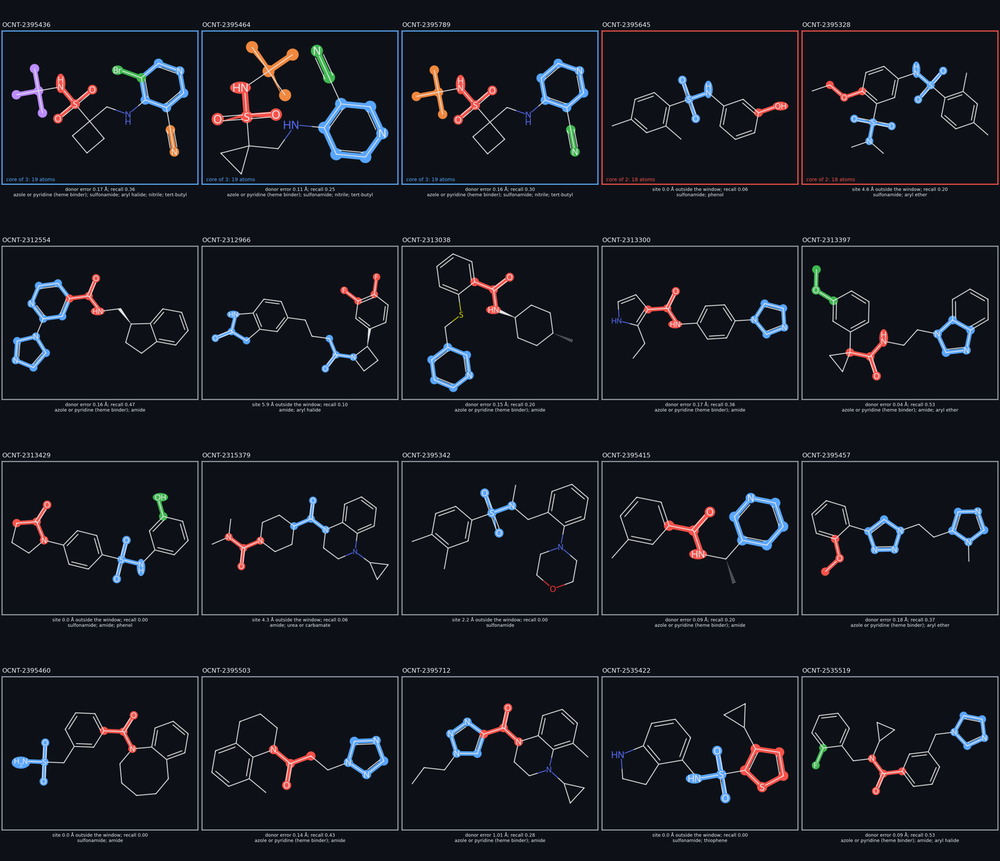

**Figure: The 20 official ligands: chemotypes, functional groups and the pharmacophore of their final poses.** The 20 official ligands in 2D, grouped into 2 chemotypes and 15 singletons (Morgan Tanimoto similarity of at least 0.45 to a neighbour; the largest group first). Each structure shows its functional groups (one colour per group of the fixed table, named under it) and, for a chemotype, the atoms of the maximum common substructure of the group are outlined in the colour of the group. Under each, the pharmacophore numbers of its final pose from job 925_official_pharmacophore: the iron-donor error of a Type II donor or the distance of the oxidation site outside the 3.5 to 6.0 Å window, the recall of the crystal sites and a mark when a flag of the check of the binding-site representation is raised. These are predictions for blinded ligands.

In [268]:
show_figure("struct_pharm_official20_2d")

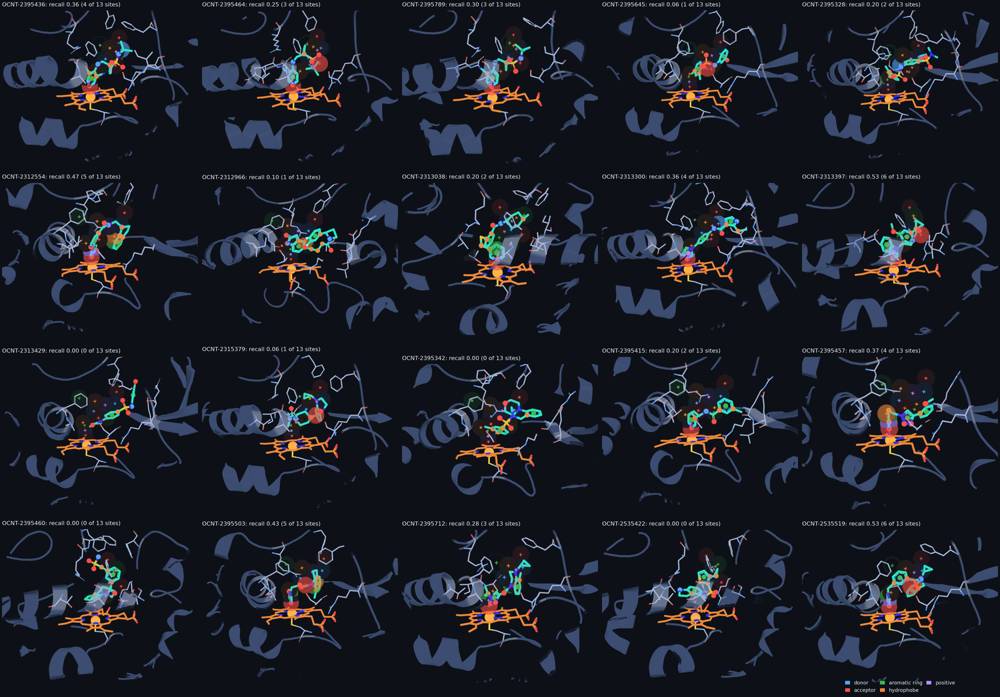

**Figure: The 20 official ligands in their pockets with the pharmacophore model.** The 20 official ligands in their pockets, with the pharmacophore model. For each ligand a PyMOL render of its final submitted pose (teal) in the pocket of the predicted complex (orange heme, the lining residues), with the sites of the structure-based model, built without the references of the ligand and of its analogues, as translucent spheres in the colour of the feature family (a site that a feature of the pose matches is drawn firmer) and the features of the pose as small solid spheres. The panels are in the order of the chemotypes of the previous figure. These are predictions for blinded ligands.

In [269]:
show_figure("struct_pharm_official20_3d")

*On what actually ran.* The functional groups are defined once in `cypmode/challenge/functional_groups.py` (the table `GROUPS`, `groups_of`, `group_matrix`, `group_rates`, `wilson`, and `group_gain_pairs` for the pairs), with its tests in `tests/test_functional_groups.py`. The figures are made by `docs/figures/gen/pharmacophore_atlas.py` (the TDI track: the groups, the pairs, the features, the hypotheses, the atlas, the pockets) and `docs/figures/gen/structure_pharmacophore_atlas.py` (the structure track: the poses, the series, the 20 ligands), through the figures job 940; the 2D drawings are made by RDKit from the SMILES, the 3D pictures of crystal and predicted complexes by PyMOL from their coordinates, and the 3D conformers of the hypotheses are drawn with the seed 42 and said to be so. The tests are `tests/test_pharmacophore_atlas.py` (the drawings, the fragment of a pair, the typical pair, the chemotypes, the changed atoms of a pair and the spheres of a pose) and the figures of the three first groups are drawn in it from the real data. The hypotheses of 9.14 carry pmapper's letters, in which the lower-case a is the aromatic ring and the upper-case A the acceptor; an earlier description of those letters had them the other way round, which changed only the words of the descriptions and not a signature or a column. Limits: a functional group is a pattern, so a compound with the same chemistry written in another way is missed; the matched pairs are few for CYP2D6 and for any single exchange; the SAR of this section is that of the label, which is a time-dependent inhibition, not of the potency; and every 3D conformer is a low-energy shape, not a bound one.

# Part X. Quantum chemistry and the physics features

Parts III to IX gave the models descriptions of a molecule that come from its drawing: which atoms are bonded, which fragments occur, how large and how polar it is. Mechanism-based inactivation (section 5.1) is a statement about something else. The enzyme has to turn the compound into a reactive intermediate, and that happens at particular atoms: a carbon-hydrogen bond that the enzyme's oxidising species pulls a hydrogen atom from, a nitrogen whose lone pair binds the iron of the heme. Which bond gives way first, which atom gives up an electron most easily, whether a nitrogen is likely to hold a proton or an iron: these are questions about the electrons of the molecule, and a drawing answers them only through the statistics of many other molecules. Quantum chemistry computes them directly.

This part builds the means in the order in which a physicist would, from the exact equation to the approximation that is cheap enough to run on 6,895 compounds, and then uses it. Sections 10.1 to 10.4 are a ladder. The top rung is the Schrödinger equation, which cannot be solved for a molecule. Each rung down gives up accuracy for speed: the approximation in which each electron sees only the average of the others (10.2), density functional theory (10.3), and the semi-empirical tight-binding method that the project runs (10.4). Section 10.5 defines the quantities that are computed with it, and 10.6 puts them through the gates of Part VI and reports the verdict, which is negative. The earlier attempts at quantum features, a set of global descriptors and a network that imitates a calculation (7.8), were null as well; the block of this part describes the molecule atom by atom, which was the reason to try again.

## 10.1 The Schrödinger equation, the wavefunction and the Born-Oppenheimer approximation

> **Field:** Quantum chemistry · Mathematics

*Where this section sits:* it is the first rung of the ladder. It states what has to be computed and why it cannot be computed exactly, and it settles the one simplification on which all of molecular quantum chemistry stands. The mathematics needed is the eigenvalue problem that 4.9 already used for the principal components.

**The wavefunction.** The state of an electron is not a position and a velocity. It is a **wavefunction** $\psi(\mathbf r)$, a number (in general complex) attached to every point $\mathbf r$ of space, with one rule of interpretation: $|\psi(\mathbf r)|^2$ is the probability density of finding the electron at $\mathbf r$, so that $\int |\psi|^2\,d\mathbf r = 1$ (the wavefunction is **normalised**). A quantity that can be measured, such as the energy, corresponds to an **operator**, a recipe that turns one function into another. The energy operator is the **Hamiltonian** $\hat H = \hat T + \hat V$, the sum of the kinetic-energy operator $\hat T = -\tfrac12\nabla^2$ (in the units introduced next, $\nabla^2$ being the sum of the second derivatives in the three directions) and the potential energy $\hat V$. The **time-independent Schrödinger equation** says that a state of definite energy $E$ satisfies

$$\hat H\,\psi \;=\; E\,\psi .$$

Only special functions $\psi$, the **eigenfunctions**, and special numbers $E$, the **eigenvalues** (the allowed energies), solve it. It is the equation $Cw = \lambda w$ of 4.9 with the matrix $C$ replaced by an operator and the vector $w$ by a function, and when space is cut into a grid of points the operator becomes a matrix and the equation becomes literally the eigenvalue problem of linear algebra. That is how the first two cells solve it.

**Atomic units.** The equations of molecules are tidy in units in which four constants are 1: the electron's mass, its charge, the reduced Planck constant $\hbar$ and $1/(4\pi\varepsilon_0)$ (the constant that turns charges into the Coulomb force). Energy is then in **hartree** (1 hartree = 27.2114 eV = 627.5 kcal/mol) and length in **bohr** (1 bohr = 0.529177 Å). The hydrogen atom's ground-state energy is $-\tfrac12$ hartree, which is the 13.6 eV needed to ionise it.

**Two cases that can be solved.** A particle confined to a box of length $L$ (potential zero inside and infinite outside) has the energies $E_n = n^2\pi^2/(2L^2)$ with $n = 1, 2, \dots$: confinement makes the energies discrete, and the energy of the lowest state rises as the box shrinks. The hydrogen atom, one electron in the potential $-1/r$ of a proton at distance $r$, has $E_n = -1/(2n^2)$. For the s states, in which the wavefunction depends on $r$ only, writing $\psi(r) = u(r)/r$ turns the equation into $-\tfrac12 u'' - u/r = E\,u$ with $u(0) = 0$. The cell discretises both on a grid and asks a matrix routine for the lowest eigenvalues.

In [270]:
# Quantum-chemistry programs are run in a fresh interpreter of their own, as the project's extraction jobs are: a library for electronic structure (PySCF or tblite) and LightGBM must not meet in one process, because the
# two bring their own copies of the OpenMP runtime and the program can end with a crash or a deadlock (the same rule as for the torch libraries, 4.8). The helper hands a short script to the interpreter of the notebook,
# lets it print one line of JSON as its last output, and reads that line back.
import json
import os
import subprocess
import sys
import textwrap

HARTREE_TO_EV, HARTREE_TO_KCAL, BOHR_TO_ANGSTROM = 27.211386, 627.5095, 0.529177210903
def run_isolated(source, timeout=900):
    done = subprocess.run([sys.executable, "-c", textwrap.dedent(source)], capture_output=True, text=True, timeout=timeout, cwd=str(ROOT), env={**os.environ, "PYTHONPATH": str(ROOT)})
    if done.returncode != 0:
        raise RuntimeError(done.stderr[-3000:])
    return json.loads(done.stdout.strip().splitlines()[-1])
def run_isolated_text(source, timeout=900):
    """The same, returning everything the program printed (used where a program writes its own report to the screen)."""
    done = subprocess.run([sys.executable, "-c", textwrap.dedent(source)], capture_output=True, text=True, timeout=timeout, cwd=str(ROOT), env={**os.environ, "PYTHONPATH": str(ROOT)})
    if done.returncode != 0:
        raise RuntimeError(done.stderr[-3000:])
    return done.stdout
print(f"1 hartree = {HARTREE_TO_EV} eV = {HARTREE_TO_KCAL} kcal/mol; 1 bohr = {BOHR_TO_ANGSTROM} angstrom")

1 hartree = 27.211386 eV = 627.5095 kcal/mol; 1 bohr = 0.529177210903 angstrom


In [271]:
# The Schroedinger equation as a matrix eigenvalue problem. In atomic units (hbar = m = e = 1) the operator is H = -1/2 d^2/dx^2 + V(x). On a grid of n interior points with spacing h the second derivative becomes the matrix with
# -2 on the diagonal and 1 beside it, divided by h^2, so that H is a symmetric matrix and its eigenvalues are the energies, as the eigenvalues of the covariance matrix were the variances in 4.9.
# (1) a particle in a box of length L = 1 (V = 0 inside, infinite outside): exact energies E_n = n^2 pi^2 / (2 L^2).
# (2) the hydrogen atom in its s states: with psi(r) = u(r) / r (the angular part is a constant) the equation for u(r) is -1/2 u'' - u / r = E u with u(0) = 0, a grid in r with the potential V = -1/r;
#     exact energies E_n = -1 / (2 n^2) hartree.
import numpy as np

def second_difference(n, h):
    return (np.diag(np.full(n, 2.0)) - np.diag(np.ones(n - 1), 1) - np.diag(np.ones(n - 1), -1)) / (2 * h * h)

n_box, box_length = 800, 1.0
h_box = box_length / (n_box + 1)
box_levels = np.linalg.eigvalsh(second_difference(n_box, h_box))[:4]
box_exact = np.array([(k * np.pi) ** 2 / (2 * box_length**2) for k in (1, 2, 3, 4)])

n_radial, r_max = 4000, 60.0
h_radial = r_max / (n_radial + 1)
radius = h_radial * np.arange(1, n_radial + 1)
hydrogen_levels = np.linalg.eigvalsh(second_difference(n_radial, h_radial) - np.diag(1 / radius))[:3]
hydrogen_exact = np.array([-0.5 / n**2 for n in (1, 2, 3)])

box_table = pd.DataFrame({"level n": [1, 2, 3, 4], "grid eigenvalue (hartree)": box_levels, "exact n^2 pi^2 / 2 (hartree)": box_exact, "difference": box_levels - box_exact})
hydrogen_table = pd.DataFrame({"level n": [1, 2, 3], "grid eigenvalue (hartree)": hydrogen_levels, "exact -1/(2 n^2) (hartree)": hydrogen_exact, "grid eigenvalue (eV)": hydrogen_levels * 27.211386})
show_table(box_table, floatfmt=".6f")
show_table(hydrogen_table, floatfmt=".6f")
box_error = float(np.abs(box_levels - box_exact).max())
box_relative = float((np.abs(box_levels - box_exact) / box_exact).max())
hydrogen_error = float(np.abs(hydrogen_levels - hydrogen_exact).max())

| level n | grid eigenvalue (hartree) | exact n^2 pi^2 / 2 (hartree) | difference |
| --- | --- | --- | --- |
| 1 | 4.934796 | 4.934802 | -0.000006 |
| 2 | 19.739108 | 19.739209 | -0.000101 |
| 3 | 44.412707 | 44.413220 | -0.000512 |
| 4 | 78.955216 | 78.956835 | -0.001619 |

| level n | grid eigenvalue (hartree) | exact -1/(2 n^2) (hartree) | grid eigenvalue (eV) |
| --- | --- | --- | --- |
| 1 | -0.499972 | -0.500000 | -13.604928 |
| 2 | -0.124998 | -0.125000 | -3.401375 |
| 3 | -0.055555 | -0.055556 | -1.511734 |

The grid reproduces the exact energies: the largest difference is 1.6e-03 hartree for the box (on its highest level, a relative error of 2e-05) and 2.8e-05 hartree for the hydrogen atom, whose lowest level comes out as -13.605 eV. For two particles that attract or repel each other the same method is out of reach, as the next paragraph shows.

**Many electrons.** A molecule with $N$ electrons and nuclei $A$ of charge $Z_A$ has the Hamiltonian (in atomic units, with $i, j$ running over the electrons, $A, B$ over the nuclei, $M_A$ the mass of nucleus $A$, $r_{iA}$, $r_{ij}$ and $R_{AB}$ the distances)

$$\hat H \;=\; -\sum_i \tfrac12\nabla_i^2 \;-\; \sum_A \frac{1}{2M_A}\nabla_A^2 \;-\; \sum_{i,A}\frac{Z_A}{r_{iA}} \;+\; \sum_{i<j}\frac{1}{r_{ij}} \;+\; \sum_{A<B}\frac{Z_A Z_B}{R_{AB}} .$$

The terms are the kinetic energy of the electrons and of the nuclei, the attraction of electrons to nuclei, the repulsion between electrons and the repulsion between nuclei. The wavefunction is a function of $3N$ coordinates, three for each electron (and a spin each, which is explained below). The repulsion $1/r_{ij}$ ties every electron to every other, so that the equation does not separate into one equation per electron. A water molecule has 10 electrons; a grid with 100 points in each coordinate would hold $100^{30}$ numbers. The exact equation is therefore not solved for any molecule larger than a few electrons, and everything that follows is an approximation whose quality can be judged on the cases that can be solved.

**Spin and the Pauli principle.** An electron carries a two-valued internal property, its **spin**. The wavefunction of electrons must change sign when two electrons are exchanged (it is **antisymmetric**), which is the **Pauli principle**. Its consequence for chemistry is that two electrons cannot occupy the same orbital with the same spin: orbitals fill two at a time, with opposite spins, and the shell structure of atoms and the pattern of bonding follow.

**The variational principle.** The tool for approximate solutions is a bound. Let $\phi_k$ be the exact eigenfunctions with energies $E_0 \le E_1 \le \dots$. Any normalised trial function can be written $\psi = \sum_k c_k\phi_k$ with $\sum_k |c_k|^2 = 1$, and its energy $E[\psi] = \langle\psi|\hat H|\psi\rangle = \sum_k |c_k|^2 E_k$ cannot be below $E_0\sum_k |c_k|^2 = E_0$. **No trial function has an energy below the true ground state**, so the lower the energy, the better the function, and one can improve a trial function by minimising $E[\psi]$ over parameters. The cell applies it to the hydrogen atom with two families of trial functions, $e^{-ar}$ and $e^{-br^2}$.

In [272]:
# The variational principle on the hydrogen atom. For a normalised trial function the energy E[psi] = <psi|H|psi> can only be at or above the true ground-state energy E_0 (proof in the text). Two one-parameter families of s-type trial
# functions: the exponential exp(-a r) and the Gaussian exp(-b r^2). With the angular part integrated out, E[psi] = (T + V) / N with N = integral of psi^2 r^2 dr, T = 1/2 integral of psi'^2 r^2 dr and V = -integral of psi^2 r dr.
# The integrals are done numerically, the energy is minimised over the parameter, and the result is set against the exact -0.5 hartree.
from scipy import integrate, optimize

def trial_energy(shape, parameter):
    psi = (lambda r: np.exp(-parameter * r)) if shape == "exponential" else (lambda r: np.exp(-parameter * r**2))
    slope = (lambda r: -parameter * np.exp(-parameter * r)) if shape == "exponential" else (lambda r: -2 * parameter * r * np.exp(-parameter * r**2))
    norm = integrate.quad(lambda r: psi(r) ** 2 * r**2, 0, np.inf)[0]
    kinetic = 0.5 * integrate.quad(lambda r: slope(r) ** 2 * r**2, 0, np.inf)[0]
    potential = -integrate.quad(lambda r: psi(r) ** 2 * r, 0, np.inf)[0]
    return (kinetic + potential) / norm

variational_rows = []
for shape, symbol in (("exponential", "a"), ("gaussian", "b")):
    best = optimize.minimize_scalar(lambda x: trial_energy(shape, x), bounds=(0.05, 3.0), method="bounded")
    variational_rows.append({"trial function": f"exp(-{symbol} r)" if shape == "exponential" else f"exp(-{symbol} r^2)", "best parameter": float(best.x), "energy at the best parameter (hartree)": float(best.fun), "exact (hartree)": -0.5, "above the exact by (hartree)": float(best.fun + 0.5)})
variational_table = pd.DataFrame(variational_rows)
show_table(variational_table, floatfmt=".5f")
scan_values = [0.5, 0.75, 1.0, 1.25, 1.5]
scan_table = pd.DataFrame({"parameter a": scan_values, "E(a) of the exponential trial (hartree)": [trial_energy("exponential", a) for a in scan_values]})
show_table(scan_table, floatfmt=".5f")
exponential_best, gaussian_best = variational_rows[0], variational_rows[1]

| trial function | best parameter | energy at the best parameter (hartree) | exact (hartree) | above the exact by (hartree) |
| --- | --- | --- | --- | --- |
| exp(-a r) | 1.00000 | -0.50000 | -0.50000 | 0.00000 |
| exp(-b r^2) | 0.28294 | -0.42441 | -0.50000 | 0.07559 |

| parameter a | E(a) of the exponential trial (hartree) |
| --- | --- |
| 0.50000 | -0.37500 |
| 0.75000 | -0.46875 |
| 1.00000 | -0.50000 |
| 1.25000 | -0.46875 |
| 1.50000 | -0.37500 |

The exponential family contains the exact answer ($a = 1$), and the minimisation finds it: the best parameter is 1.000 and the energy -0.50000 hartree. The Gaussian family does not contain it, and the best Gaussian ends 0.0756 hartree above the exact energy, never below, as the principle requires. This is also the reason that Gaussians appear in 10.2 although orbitals are not Gaussian-shaped: a sum of several Gaussians approximates the right shape, and the variational principle guarantees that adding functions can only lower the energy toward the truth.

**The Born-Oppenheimer approximation.** The nuclei are at least 1,836 times heavier than an electron, so that they move slowly while the electrons rearrange almost instantly. The approximation of **Born and Oppenheimer** (1927) treats the nuclei as fixed points at positions $\mathbf R$ and solves for the electrons alone, $\hat H_{\text{el}}(\mathbf R)\,\psi_{\text{el}} = E_{\text{el}}(\mathbf R)\,\psi_{\text{el}}$, with the kinetic energy of the nuclei dropped from $\hat H$. Adding the repulsion of the nuclei, which is a constant for fixed positions, gives an energy $E(\mathbf R)$ that depends on where the nuclei are: the **potential energy surface**. The nuclei then move on this surface as classical particles do on a landscape. Three facts of chemistry are read from it. A stable geometry is a minimum, found by following the forces $-\nabla E$ downhill (a **geometry optimisation**). The energy of a reaction is the difference of $E$ between the minima of the products and the reactants. A **single point** is the calculation of $E$ for one fixed arrangement of the nuclei, the unit of work in everything below. The approximation fails where two surfaces come close, which does not concern this project.

*On what actually ran.* The cells above are the notebook's own: nothing is read from a cache. The helper `run_isolated` starts the programs of 10.2 and 10.3 in a separate interpreter, for the reason given in its comment. The project's calculations on the 6,895 compounds use the tight-binding method of 10.4 through `cypmode/challenge/physics_block.py`, and are described in 10.5 and 10.6.

## 10.2 Hartree-Fock, the self-consistent field and basis sets

> **Field:** Quantum chemistry · Mathematics (linear algebra)

*Where this section sits:* second rung. 10.1 ended with an equation that cannot be solved and a bound that gives a way to rank approximations. Hartree-Fock is the simplest approximation that is good enough to be useful: it replaces the wavefunction of $N$ electrons by one built from $N$ one-electron functions. The section builds it for the smallest molecules, so that the machinery can be seen, and measures what it leaves out.

**Orbitals and the Slater determinant.** An **orbital** $\varphi_i(\mathbf r)$ is a one-electron wavefunction. If the electrons did not repel each other, the $N$-electron wavefunction would be a product of orbitals. A plain product does not change sign when two electrons are exchanged, so it violates the Pauli principle, and the cure is to antisymmetrise: the **Slater determinant** is the determinant of the $N \times N$ matrix whose entry in row $i$ and column $j$ is orbital $i$ (with its spin) evaluated at the coordinates of electron $j$; exchanging two electrons exchanges two columns, and the determinant changes sign. For a closed shell (every orbital holds two electrons of opposite spin, $N/2$ spatial orbitals) the energy of the determinant is

$$E_{\text{HF}} \;=\; 2\sum_i h_{ii} \;+\; \sum_{i,j}\big(2J_{ij} - K_{ij}\big) \;+\; V_{nn},$$

with $i, j$ over the occupied orbitals. Here $h_{ii}$ is the kinetic energy of an electron in orbital $i$ plus its attraction to the nuclei; $J_{ij}$ is the **Coulomb** repulsion between the charge clouds $|\varphi_i|^2$ and $|\varphi_j|^2$; $K_{ij}$ is the **exchange** energy, which has no classical counterpart and exists because electrons of the same spin avoid each other; and $V_{nn}$ is the repulsion of the nuclei. The **Hartree-Fock** method finds the orbitals that minimise $E_{\text{HF}}$ under the condition that they stay orthonormal. Setting the variation to zero gives one equation per orbital, $\hat f\,\varphi_i = \varepsilon_i\,\varphi_i$, where the **Fock operator** $\hat f$ holds the kinetic energy, the attraction to the nuclei, and the average field of the other electrons, which depends on the orbitals themselves.

**Iteration.** The equation for the orbitals needs the orbitals to build its operator. The way out is iteration: guess the orbitals, build $\hat f$ from them, solve for new orbitals, and repeat until they stop changing. This loop is the **self-consistent field** method (SCF), and its result is self-consistent: the field produced by the orbitals is the field that produces them. The energies $\varepsilon_i$ are the **orbital energies**.

**A basis, and the matrices.** To solve for functions on a computer, each orbital is written as a sum of fixed **basis functions** $\chi_\mu$ centred on the atoms, $\varphi_i = \sum_\mu C_{\mu i}\chi_\mu$, so that the unknowns are the numbers $C_{\mu i}$ (the **LCAO** expansion, linear combination of atomic orbitals). The equations become the matrix equation of **Roothaan and Hall** (1951), $FC = SC\varepsilon$, with the **overlap matrix** $S_{\mu\nu} = \int\chi_\mu\chi_\nu\,d\mathbf r$ (the basis functions are not orthogonal), the **core Hamiltonian** $h_{\mu\nu}$ (kinetic energy and nuclear attraction between $\chi_\mu$ and $\chi_\nu$), and the **Fock matrix**

$$F_{\mu\nu} \;=\; h_{\mu\nu} + \sum_{\lambda\sigma} P_{\lambda\sigma}\Big[(\mu\nu|\lambda\sigma) - \tfrac12(\mu\lambda|\nu\sigma)\Big], \qquad P_{\lambda\sigma} = 2\sum_{i\in\text{occ}} C_{\lambda i}C_{\sigma i}, \qquad E = \tfrac12\sum_{\mu\nu}P_{\mu\nu}(h_{\mu\nu} + F_{\mu\nu}) + V_{nn}.$$

$P$ is the **density matrix** (it holds the electron density), and $(\mu\nu|\lambda\sigma)$ is the **two-electron integral**, the repulsion between the charge distribution $\chi_\mu\chi_\nu$ and the distribution $\chi_\lambda\chi_\sigma$. The second term in the bracket is the exchange. The number of such integrals grows as the fourth power of the number of basis functions, which is what makes the method expensive.

**Why Gaussians.** The best basis functions would be the shape of a hydrogen orbital, $e^{-\zeta r}$ (a **Slater-type orbital**). Integrals of those are hard. The product of two Gaussians $e^{-\alpha r^2}$ on different centres is again a Gaussian, so that every integral has a closed form, with the **Boys function** $F_0(t) = \tfrac12\sqrt{\pi/t}\,\operatorname{erf}\sqrt t$ for the Coulomb ones. A Slater function is therefore approximated by a fixed sum of Gaussians: in the **STO-3G** basis, three. Larger bases (a function for each valence orbital in several sizes, plus polarisation functions of higher angular momentum) approach the **basis-set limit**, the energy that an infinitely flexible basis would give, as the variational principle of 10.1 promises: more functions, lower energy.

The cell writes all of this for two nuclei, each with one 1s function. The molecule **HeH⁺** (helium and hydrogen sharing two electrons) is the example, because its two atoms differ and the orbital is not fixed by symmetry: the self-consistent iteration really has work to do. The final energy is checked against the program PySCF.

In [273]:
# Hartree-Fock written out for the smallest molecules, so that every matrix of the method can be seen. Basis: one 1s function on each nucleus, itself a sum of three Gaussians (the STO-3G basis: the shape of a Slater orbital exp(-zeta r),
# approximated by three Gaussians exp(-alpha r^2) with fixed exponents and weights scaled by zeta). For s-type Gaussians every integral has a closed form (Szabo and Ostlund, chapter 3 and appendix A), built from the Boys function
# F0(t) = 1/2 sqrt(pi / t) erf(sqrt(t)). The matrices: overlap S, kinetic T, nuclear attraction V and the two-electron integrals (mu nu | lambda sigma); h = T + V. The self-consistent field loop follows the text: guess the density matrix
# from h alone, build the Fock matrix, diagonalise it in an orthogonal basis (S^(-1/2)), build the new density matrix from the lowest orbital (two electrons), and repeat until the energy stops changing.
from scipy.special import erf

BASE_ALPHA, BASE_COEFFICIENT = np.array([0.109818, 0.405771, 2.22766]), np.array([0.444635, 0.535328, 0.154329])   # STO-3G for zeta = 1
def boys0(t):
    return 1.0 if t < 1e-12 else 0.5 * np.sqrt(np.pi / t) * erf(np.sqrt(t))

def two_centre_integrals(distance, zeta):
    """S, T, V and (mu nu | lambda sigma) of two 1s STO-3G functions, one on each of two nuclei a distance apart (bohr). zeta: Slater exponents of the two functions; the nuclear charges enter later (V is built for unit charges)."""
    centres = [np.zeros(3), np.array([0.0, 0.0, distance])]
    primitives = [[(BASE_COEFFICIENT[k] * (2 * (z**2 * BASE_ALPHA[k]) / np.pi) ** 0.75, z**2 * BASE_ALPHA[k]) for k in range(3)] for z in zeta]
    sq = lambda a, b: float(np.dot(a - b, a - b))
    S, T = np.zeros((2, 2)), np.zeros((2, 2))
    V = np.zeros((2, 2, 2))      # V[c] is the attraction to a unit charge on centre c
    eri = np.zeros((2, 2, 2, 2))
    for a in range(2):
        for b in range(2):
            for ca, ea in primitives[a]:
                for cb, eb in primitives[b]:
                    p, q = ea + eb, ea * eb / (ea + eb)
                    centre_p = (ea * centres[a] + eb * centres[b]) / p
                    overlap = ca * cb * (np.pi / p) ** 1.5 * np.exp(-q * sq(centres[a], centres[b]))
                    S[a, b] += overlap
                    T[a, b] += overlap * q * (3 - 2 * q * sq(centres[a], centres[b]))
                    for c in range(2):
                        V[c, a, b] += -overlap * (2 * np.sqrt(p / np.pi)) * boys0(p * sq(centre_p, centres[c]))
    for a in range(2):
        for b in range(2):
            for c in range(2):
                for d in range(2):
                    for ca, ea in primitives[a]:
                        for cb, eb in primitives[b]:
                            for cc, ec in primitives[c]:
                                for cd, ed in primitives[d]:
                                    p, r = ea + eb, ec + ed
                                    centre_p, centre_r = (ea * centres[a] + eb * centres[b]) / p, (ec * centres[c] + ed * centres[d]) / r
                                    k1, k2 = np.exp(-ea * eb / p * sq(centres[a], centres[b])), np.exp(-ec * ed / r * sq(centres[c], centres[d]))
                                    eri[a, b, c, d] += ca * cb * cc * cd * 2 * np.pi**2.5 / (p * r * np.sqrt(p + r)) * k1 * k2 * boys0(p * r / (p + r) * sq(centre_p, centre_r))
    return S, T, V, eri

def scf_two_electrons(distance, charges, zeta, tolerance=1e-10):
    """Closed-shell Hartree-Fock for two electrons in two 1s functions. Returns the iteration history, the converged energy and the quantities of the last iteration."""
    S, T, V, eri = two_centre_integrals(distance, zeta)
    h = T + charges[0] * V[0] + charges[1] * V[1]
    nuclear = charges[0] * charges[1] / distance
    values, vectors = np.linalg.eigh(S)
    X = vectors @ np.diag(values**-0.5) @ vectors.T                       # S^(-1/2): orthogonalises the basis
    orbital_energies, Cp = np.linalg.eigh(X.T @ h @ X)                    # first guess from the core Hamiltonian
    C = X @ Cp
    P = 2 * np.outer(C[:, 0], C[:, 0])
    history, previous = [], None
    for iteration in range(1, 100):
        J = np.einsum("cd,abcd->ab", P, eri)
        K = np.einsum("cd,acbd->ab", P, eri)
        F = h + J - 0.5 * K
        electronic = 0.5 * np.sum(P * (h + F))
        orbital_energies, Cp = np.linalg.eigh(X.T @ F @ X)
        C = X @ Cp
        P = 2 * np.outer(C[:, 0], C[:, 0])
        history.append({"iteration": iteration, "total energy (hartree)": electronic + nuclear, "lowest orbital energy (hartree)": orbital_energies[0], "coefficient on nucleus A": abs(C[0, 0]), "coefficient on nucleus B": abs(C[1, 0])})
        if previous is not None and abs(electronic - previous) < tolerance:
            break
        previous = electronic
    return pd.DataFrame(history), {"S": S, "h": h, "eri": eri, "C": C, "nuclear": nuclear, "energy": electronic + nuclear}

# HeH+ near its equilibrium distance (0.7751 angstrom): helium and hydrogen, Slater exponents of the STO-3G basis 1.69 and 1.24
heh_distance = 0.7751 / BOHR_TO_ANGSTROM
heh_history, heh_state = scf_two_electrons(heh_distance, (2, 1), (1.69, 1.24))
show_table(heh_history.head(8), floatfmt=".6f")
heh_by_hand = float(heh_history["total energy (hartree)"].iloc[-1])
heh_reference = run_isolated(f"""
    import json
    from pyscf import gto, scf
    molecule = gto.M(atom="He 0 0 0; H 0 0 0.7751", basis="sto-3g", charge=1, unit="Angstrom", verbose=0)
    print(json.dumps(scf.RHF(molecule).run().e_tot))
""")
n_scf_cycles = len(heh_history)

| iteration | total energy (hartree) | lowest orbital energy (hartree) | coefficient on nucleus A | coefficient on nucleus B |
| --- | --- | --- | --- | --- |
| 1 | -2.797898 | -1.581762 | 0.896111 | 0.173600 |
| 2 | -2.840503 | -1.623524 | 0.879819 | 0.197908 |
| 3 | -2.841956 | -1.630824 | 0.877194 | 0.201764 |
| 4 | -2.841993 | -1.631969 | 0.876788 | 0.202359 |
| 5 | -2.841994 | -1.632146 | 0.876726 | 0.202450 |
| 6 | -2.841994 | -1.632173 | 0.876717 | 0.202464 |
| 7 | -2.841994 | -1.632177 | 0.876715 | 0.202466 |
| 8 | -2.841994 | -1.632177 | 0.876715 | 0.202466 |

The loop needed 8 cycles. In the first, the occupied orbital sits mostly on the nucleus with the larger charge (coefficients, in absolute value, 0.896 on helium and 0.174 on hydrogen); as the other electron's field is taken into account the orbital shifts toward the hydrogen (0.877 and 0.202 in the last cycle), and the energy settles at -2.841994 hartree. PySCF, a program written by specialists, gives -2.841994: the two agree to 1e-07 hartree, the difference being the rounded exponents of the table. Every matrix of the method is in the cell, and a method that is run with a library afterwards is run with its internals known.

**What Hartree-Fock leaves out.** Each electron feels only the *average* field of the others. In reality the electrons avoid each other instantaneously, and the energy that this adds is the **correlation energy**, defined as the exact energy minus the Hartree-Fock energy (it is negative: correlation lowers the energy). For H₂ in the minimal basis the exact answer is available, since the basis holds only two orbitals, the bonding orbital $\sigma_g$ and the antibonding $\sigma_u$, and the exact state (**configuration interaction**, mixing every arrangement of the electrons in the orbitals) is a mix of "both electrons in $\sigma_g$" with a little of "both in $\sigma_u$". The second cell computes both energies as the two nuclei are pulled apart, and checks them against PySCF.

In [274]:
# The same machinery for H2 at several distances, and the step beyond Hartree-Fock. With two electrons in the minimal basis there are only two orbitals, the bonding sigma_g (lower) and the antibonding sigma_u. The exact solution
# within this basis (full configuration interaction) mixes the two configurations "both electrons in sigma_g" and "both in sigma_u": a 2 x 2 matrix with H00 = 2 h_gg + (gg|gg), H11 = 2 h_uu + (uu|uu) and H01 = (gu|gu),
# where h_pq are the one-electron matrix elements in the orbitals and (pq|rs) the two-electron integrals in the orbitals. The difference between this exact energy and the Hartree-Fock energy is the correlation energy.
def h2_energies(distance_angstrom):
    distance = distance_angstrom / BOHR_TO_ANGSTROM
    history, state = scf_two_electrons(distance, (1, 1), (1.24, 1.24))
    C, h, eri = state["C"], state["h"], state["eri"]
    h_mo = C.T @ h @ C
    mo = lambda p, q, r, s: np.einsum("abcd,a,b,c,d->", eri, C[:, p], C[:, q], C[:, r], C[:, s])
    matrix = np.array([[2 * h_mo[0, 0] + mo(0, 0, 0, 0), mo(0, 1, 0, 1)], [mo(0, 1, 0, 1), 2 * h_mo[1, 1] + mo(1, 1, 1, 1)]])
    return state["energy"], float(np.linalg.eigvalsh(matrix)[0] + state["nuclear"])

distances = [0.5, 0.74, 1.0, 1.5, 2.0, 3.0, 4.0]
h2_rows = []
for distance in distances:
    hartree_fock, exact_in_basis = h2_energies(distance)
    h2_rows.append({"distance (angstrom)": distance, "Hartree-Fock (hartree)": hartree_fock, "exact in the basis (hartree)": exact_in_basis, "correlation energy (kcal/mol)": (exact_in_basis - hartree_fock) * HARTREE_TO_KCAL})
h2_table = pd.DataFrame(h2_rows)
h2_reference = run_isolated(f"""
    import json
    from pyscf import gto, scf, fci
    out = {{}}
    for r in {distances}:
        mol = gto.M(atom=f"H 0 0 0; H 0 0 {{r}}", basis="sto-3g", unit="Angstrom", verbose=0)
        mf = scf.RHF(mol).run()
        out[str(r)] = [mf.e_tot, fci.FCI(mf).kernel()[0]]
    atom = gto.M(atom="H 0 0 0", basis="sto-3g", spin=1, verbose=0)
    out["atom"] = scf.UHF(atom).run().e_tot
    print(json.dumps(out))
""")
h2_table["Hartree-Fock, PySCF"] = [h2_reference[str(d)][0] for d in distances]
h2_table["exact, PySCF"] = [h2_reference[str(d)][1] for d in distances]
show_table(h2_table, floatfmt=".5f")
h2_agreement = float(max(np.abs(h2_table["Hartree-Fock (hartree)"] - h2_table["Hartree-Fock, PySCF"]).max(), np.abs(h2_table["exact in the basis (hartree)"] - h2_table["exact, PySCF"]).max()))
atom_energy = float(h2_reference["atom"])
far = h2_table.iloc[-1]
dissociation_error_hf = (far["Hartree-Fock (hartree)"] - 2 * atom_energy) * HARTREE_TO_KCAL
dissociation_error_exact = (far["exact in the basis (hartree)"] - 2 * atom_energy) * HARTREE_TO_KCAL
equilibrium = h2_table.iloc[1]

| distance (angstrom) | Hartree-Fock (hartree) | exact in the basis (hartree) | correlation energy (kcal/mol) | Hartree-Fock, PySCF | exact, PySCF |
| --- | --- | --- | --- | --- | --- |
| 0.50000 | -1.04300 | -1.05516 | -7.63273 | -1.04300 | -1.05516 |
| 0.74000 | -1.11676 | -1.13728 | -12.87934 | -1.11676 | -1.13728 |
| 1.00000 | -1.06611 | -1.10115 | -21.98900 | -1.06611 | -1.10115 |
| 1.50000 | -0.91087 | -0.99815 | -54.76644 | -0.91087 | -0.99815 |
| 2.00000 | -0.78379 | -0.94864 | -103.44409 | -0.78379 | -0.94864 |
| 3.00000 | -0.65605 | -0.93363 | -174.18649 | -0.65605 | -0.93363 |
| 4.00000 | -0.61487 | -0.93317 | -199.73723 | -0.61487 | -0.93317 |

Hand-coded and library values agree to 2e-07 hartree for both methods at all 7 distances. At the equilibrium distance of 0.74 Å the correlation energy is -12.9 kcal/mol, a small fraction of the total energy and several times the energy of a hydrogen bond (a few kcal/mol), which is the scale at which reactivity is decided. When the two atoms are pulled far apart, the picture breaks: at 4 Å the Hartree-Fock energy lies 200 kcal/mol above the energy of two separate hydrogen atoms, while the exact one is within 0.0 kcal/mol of it. The reason is that the restricted method puts both electrons into the same spatial orbital, which at a long distance describes a mixture of two neutral atoms and of a proton and a hydride ion. Correlated methods repair this and cost far more: the cost of Hartree-Fock grows as the fourth power of the number of basis functions, that of the standard correlated method **coupled cluster** with single, double and perturbative triple excitations, CCSD(T), as the seventh. CCSD(T) is the reference used to judge cheaper methods, and it cannot be run on a drug-like molecule in a basis of useful size, let alone on thousands.

*On what actually ran.* The cells above (the integrals, the loop, the 2 × 2 configuration interaction), and PySCF in an isolated interpreter for the comparison. The HeH⁺ exponents are 1.69 for helium and 1.24 for hydrogen and the weights of the three Gaussians are the tabulated ones for $\zeta = 1$ (Szabo and Ostlund, *Modern Quantum Chemistry*, 1989, chapter 3 and appendix A).

## 10.3 Density functional theory

> **Field:** Quantum chemistry · Physics

*Where this section sits:* third rung. Hartree-Fock (10.2) treats each electron in the average field of the others and misses the correlation of their motions; the methods that recover it from the wavefunction (coupled cluster and its relatives) cost too much for molecules of the size of a drug. Density functional theory takes another road: it gives up the wavefunction altogether and works with a quantity that has three variables however many electrons there are.

**The electron density.** The **electron density** $\rho(\mathbf r)$ is the number of electrons per unit volume at the point $\mathbf r$: $N$ times the probability density of finding any one electron there. Water has 10 electrons and a wavefunction of 30 coordinates; its density is a function of 3. **Hohenberg and Kohn** (1964) proved two statements. First, the density of the ground state determines the external potential $v(\mathbf r)$ in which the electrons move (here, the field of the nuclei) up to a constant, and with it the Hamiltonian and therefore every property of the system: the ground-state energy is a **functional** of the density, $E[\rho]$ (a functional is a function of a function). Second, a variational principle like that of 10.1 holds for densities: $E[\rho] \ge E_0$ for every trial density that is non-negative and integrates to $N$, with equality at the true density. The theorems say that the functional exists. They do not say what it is.

The **Kohn-Sham** scheme. **Kohn and Sham** (1965) found a way to use the theorems. Replace the interacting electrons by fictitious electrons that do not interact, chosen so that they have the same density. Their orbitals $\varphi_i$, with orbital energies $\varepsilon_i$, obey one-electron equations,

$$\Big[-\tfrac12\nabla^2 + v(\mathbf r) + \int\frac{\rho(\mathbf r')}{|\mathbf r - \mathbf r'|}\,d\mathbf r' + v_{xc}(\mathbf r)\Big]\varphi_i = \varepsilon_i\,\varphi_i, \qquad \rho(\mathbf r) = 2\sum_{i\in\text{occ}}|\varphi_i(\mathbf r)|^2 ,$$

where $v(\mathbf r)$ is the attraction of the nuclei, the integral is the classical (Hartree) repulsion of the electron cloud with itself, and $v_{xc}$ is the **exchange-correlation potential**, the derivative of the **exchange-correlation energy** $E_{xc}[\rho]$ with respect to the density. The total energy is $E = T_s[\rho] + \int v\rho + \tfrac12\iint\rho\rho'/|\mathbf r - \mathbf r'| + E_{xc}[\rho]$, with $T_s$ the kinetic energy of the fictitious electrons. Everything that is hard is in $E_{xc}$: the exchange, the correlation, and the small difference between the true kinetic energy and $T_s$. The equations are solved by the same self-consistent loop as in 10.2, since the potential depends on the density that the orbitals make. In principle the scheme is exact; in practice $E_{xc}$ is approximated.

**The approximations.** They form a ladder of increasing information (Perdew's "Jacob's ladder"). The **local density approximation** (LDA) takes $E_{xc}$ at each point from the exchange-correlation energy per electron of a uniform gas of electrons at the density found there. A **generalised gradient approximation** (GGA; PBE, Perdew, Burke and Ernzerhof, 1996, is the standard one) adds the gradient of the density, so that the functional knows whether the density is changing. A **hybrid** functional replaces a fraction of the approximate exchange by the exact exchange of Hartree-Fock; **B3LYP** (Becke, 1993, with the correlation of Lee, Yang and Parr, 1988) mixes in 20 percent and is, with its relatives, the functional most used in chemistry. The cost grows with the third to fourth power of the size of the basis, below the fifth to seventh power of the correlated wavefunction methods.

The cell runs water with Hartree-Fock and with one functional of each kind. Two properties are compared with experiment: the first **ionisation potential**, the energy needed to remove one electron, computed as the energy of the cation minus the energy of the neutral molecule (a difference of two separate calculations, each allowed to relax its electrons), and the energy of the highest occupied orbital.

In [275]:
# Density functional theory against Hartree-Fock on the water molecule, with the program PySCF in an isolated interpreter (10.1): the geometry is the experimental one (O-H 0.957 angstrom, angle 104.5 degrees), the basis def2-SVP
# (a split-valence basis with polarisation functions, larger than the minimal one of 10.2). Four methods: Hartree-Fock; the local density approximation (LDA, SVWN); a generalised-gradient functional (PBE); and the hybrid B3LYP.
# For each: the total energy, the energy of the highest occupied orbital, the dipole moment, and the first ionisation potential as the energy of the cation minus the energy of the neutral molecule (both at the geometry of the neutral:
# a "vertical" ionisation, with the electrons of the cation allowed to relax). The experimental values (NIST Computational Chemistry Comparison and Benchmark Database) are an ionisation potential of 12.62 eV and a dipole of 1.85 debye.
water_rows = run_isolated("""
    import json, time
    from pyscf import gto, scf, dft
    atom = "O 0 0 0.1173; H 0 0.7572 -0.4692; H 0 -0.7572 -0.4692"
    out = []
    for name, xc in (("Hartree-Fock", None), ("LDA (SVWN)", "lda,vwn"), ("GGA (PBE)", "pbe"), ("hybrid (B3LYP)", "b3lyp")):
        start = time.time()
        neutral = gto.M(atom=atom, basis="def2-svp", verbose=0)
        mf = scf.RHF(neutral) if xc is None else dft.RKS(neutral).set(xc=xc)
        mf.run()
        cation = gto.M(atom=atom, basis="def2-svp", charge=1, spin=1, verbose=0)
        mc = scf.UHF(cation) if xc is None else dft.UKS(cation).set(xc=xc)
        mc.run()
        dipole = float((mf.dip_moment(verbose=0) ** 2).sum() ** 0.5)
        out.append([name, mf.e_tot, float(mf.mo_energy[neutral.nelectron // 2 - 1]) * 27.211386, (mc.e_tot - mf.e_tot) * 27.211386, dipole, time.time() - start])
    print(json.dumps(out))
""")
water_table = pd.DataFrame(water_rows, columns=["method", "total energy (hartree)", "energy of the highest occupied orbital (eV)", "ionisation potential from energies (eV)", "dipole (debye)", "seconds"])
show_table(water_table, floatfmt=".3f")
water_hf, water_lda, water_pbe, water_b3 = (water_table.iloc[i] for i in range(4))

| method | total energy (hartree) | energy of the highest occupied orbital (eV) | ionisation potential from energies (eV) | dipole (debye) | seconds |
| --- | --- | --- | --- | --- | --- |
| Hartree-Fock | -75.961 | -13.553 | 10.849 | 2.133 | 0.113 |
| LDA (SVWN) | -75.795 | -6.309 | 12.732 | 2.025 | 0.248 |
| GGA (PBE) | -76.272 | -6.217 | 12.381 | 1.936 | 0.360 |
| hybrid (B3LYP) | -76.358 | -7.943 | 12.415 | 1.982 | 0.355 |

Two lessons for the sections that follow. First, **energy differences are reliable and orbital energies are not.** The ionisation potential obtained as a difference is 12.73 eV (LDA), 12.38 (PBE) and 12.42 (B3LYP) against 12.62 measured, while the energy of the highest occupied orbital, which in an exact theory would equal minus the ionisation potential, is only 6.3 eV (LDA), 6.2 (PBE) and 7.9 (B3LYP). The reason is the **self-interaction error** of approximate functionals: an electron partly repels itself, which pushes the orbital energies up. Hartree-Fock has no such error for one electron, and its orbital energy (13.6 eV) is near the measured value because two neglected effects cancel (the relaxation of the other electrons when one is removed, and the correlation), while its energy difference (10.85 eV) is 1.8 eV too low because the correlation energy of the cation and of the neutral molecule differ. Second, the dipole moments of the four methods lie between 1.94 and 2.13 debye against 1.85 measured; the remaining difference is a matter of the basis set, not of the method. The numbers of this cell are the reason that the project computes ionisation potentials, electron affinities and hydrogen-abstraction energies as differences of total energies, and does not use orbital energies except as descriptors of shape (10.5).

*On what actually ran.* PySCF in an isolated interpreter (`run_isolated`, 10.1), restricted Hartree-Fock and Kohn-Sham for the neutral molecule and the unrestricted versions for the cation. The experimental values are from the NIST Computational Chemistry Comparison and Benchmark Database.

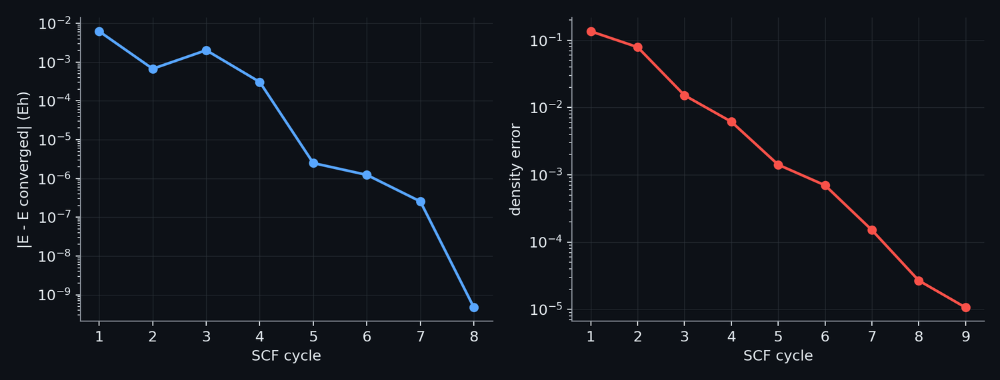

**Figure: The self-consistent field loop converging.** The self-consistent field iterations of GFN2-xTB for toluene (one conformer, MMFF geometry), taken from the library's own printout: 9 cycles. Left: the distance of each cycle's total energy from the converged energy (-19.049279 Eh), log scale. Right: the density error that decides convergence, from 1.4e-01 in the first cycle to 1.1e-05 in the last. Each cycle builds the Fock matrix from the current electron density, solves for new orbitals, and mixes the new density into the old one until the density stops changing.

In [276]:
show_figure("phys_scf_convergence")

## 10.4 Semi-empirical and tight-binding methods: the energy of GFN2-xTB

> **Field:** Quantum chemistry · Chemistry

*Where this section sits:* fourth and last rung, and the one the project runs. A hybrid-functional calculation in a useful basis is a matter of minutes for a small molecule and hours for a drug, and the physics block (10.5) needs about forty single points for each of 6,895 compounds. The sum is years of processor time. The cheaper rungs exist for this reason, and the price of each is stated here so that the reader knows what the features that came out of it can and cannot mean.

**Semi-empirical methods.** A **semi-empirical** method keeps the structure of Hartree-Fock and removes most of its cost by four steps: only the valence electrons are treated (the core electrons are folded into the charge of the nucleus), the basis is minimal (one function for each valence orbital), most of the two-electron integrals that make the cost grow as the fourth power are neglected or replaced by simple functions of the distance, and the integrals that remain are replaced by **parameters** fitted to experimental or high-level results. The older families of this kind (AM1, PM3, and PM6 of Stewart, 2007) were fitted mainly to heats of formation and molecular geometries. The result is about a thousand times faster than a density functional calculation, with errors that are not random but depend on the chemistry the parameters were fitted to.

**Tight-binding from density functional theory.** The family used here, **GFN-xTB** of Grimme and co-workers, descends from density-functional tight binding. Write the true density as $\rho = \rho_0 + \delta\rho$, with $\rho_0$ the sum of the densities of the neutral atoms and $\delta\rho$ the change that bonding makes, which is small, and expand the density-functional energy in powers of $\delta\rho$: $E = E[\rho_0] + E^{(1)} + E^{(2)} + E^{(3)} + \dots$. The zeroth-order term is the energy of the atoms and the short-range repulsion between them; the first-order term is the energy of the electrons moving in the field of the neutral atoms, which has the form of an old and simple model of bonding, the **extended Hückel** model, in which the coupling of two orbitals is proportional to their overlap and to the average of their on-site energies; the second-order term is the response to the charges that bonding moves between atoms, which makes the method self-consistent in the charges; the third-order term is the dependence of that response on how charged each atom already is. Each term is then given a parametrised form and the parameters are fitted to reproduce the geometries, vibrational frequencies and noncovalent interactions of molecules across the periodic table (this is what GFN stands for, geometry, frequency, noncovalent; the "x" is for extended). The valence basis is minimal.

**The energy of GFN2-xTB.** The second version (Bannwarth, Ehlert and Grimme, 2019) writes the energy as the sum

$$E \;=\; E_{\text{rep}} + E_{\text{disp}} + E_{\text{EHT}} + E_{\text{IES}} + E_{\text{IXC}} + E_{\text{AES}} + E_{\text{AXC}} + G_{\text{Fermi}} .$$

$E_{\text{rep}}$ is the classical short-range repulsion between pairs of atoms. $E_{\text{disp}}$ is the **dispersion** energy, the weak attraction between any two groups of atoms that comes from correlated fluctuations of their electrons (and decides noncovalent contacts, such as a ligand sitting in a pocket); GFN2 uses the D4 model, in which the dispersion coefficients of an atom depend on its charge. $E_{\text{EHT}}$ is the extended Hückel energy of the first order. $E_{\text{IES}}$ and $E_{\text{IXC}}$ are the **isotropic** electrostatic and exchange-correlation energies of the second and third orders, which treat the charge of each atom as a point (in GFN2 the second-order terms resolve it by shell). $E_{\text{AES}}$ and $E_{\text{AXC}}$ are the **anisotropic** corrections: they let each atom carry a dipole and a quadrupole as well as a charge, so that a lone pair, a $\pi$ cloud or a polar bond has a direction. $G_{\text{Fermi}}$ is the energy that comes from letting the occupation of the orbitals be smeared over levels near the highest occupied one, as at a finite **electronic temperature** (300 K by default); it makes the iterations converge for awkward molecules and is almost zero for ordinary ones. The cell below runs one calculation on toluene with the program's own report switched on, and shows the parts of the energy that the program prints and the self-consistent loop in the charges.

In [277]:
# One GFN2-xTB single point on toluene with the program's own report switched on (the library tblite, verbosity 2, in an isolated interpreter). The report lists the energy in parts: the repulsion, the dispersion, the electronic
# energy (which holds the extended Hueckel, electrostatic, exchange-correlation and Fermi terms of the expression in the text, converged together by the loop below), and the total. It also prints the loop that makes the charges
# self-consistent: for each cycle the total energy and the "density error", the change of the charges from one cycle to the next. The geometry is the lowest-energy conformer of RDKit's force field.
import re

from rdkit import Chem
from rdkit.Chem import AllChem

def geometry_of(smiles):
    molecule = Chem.AddHs(Chem.MolFromSmiles(smiles))
    AllChem.EmbedMolecule(molecule, randomSeed=7)
    AllChem.MMFFOptimizeMolecule(molecule)
    return [atom.GetSymbol() for atom in molecule.GetAtoms()], molecule.GetConformer().GetPositions().tolist()

ATOMIC_NUMBER = {"H": 1, "C": 6, "N": 7, "O": 8, "S": 16}
toluene_symbols, toluene_positions = geometry_of("Cc1ccccc1")
report = run_isolated_text(f"""
    import numpy as np
    from tblite.interface import Calculator
    numbers = np.array({[ATOMIC_NUMBER[s] for s in toluene_symbols]})
    positions = np.array({toluene_positions}) / 0.52917721067
    calculator = Calculator("GFN2-xTB", numbers, positions)
    calculator.set("verbosity", 2)
    result = calculator.singlepoint()
    print("NORB", len(result.get("orbital-energies")))
""")
def report_value(label):
    return float(re.search(rf"^{label}\s+(-?[\d.]+E[+-]\d+) Eh", report, re.M).group(1))
repulsion, dispersion, electronic, total_energy = (report_value(name) for name in ("repulsion energy", "dispersion energy", "electronic energy", "total energy"))
cycles = pd.DataFrame([{"cycle": int(c), "total energy (hartree)": float(e), "density error": float(d)} for c, e, _, d in re.findall(r"^\s+(\d+)\s+(-?\d+\.\d+)\s+(-?[\d.]+E[+-]\d+)\s+([\d.]+E[+-]\d+)\s*$", report, re.M)])
terms_table = pd.DataFrame([{"term": "repulsion", "hartree": repulsion, "kcal/mol": repulsion * HARTREE_TO_KCAL}, {"term": "dispersion line of the report", "hartree": dispersion, "kcal/mol": dispersion * HARTREE_TO_KCAL},
                            {"term": "electronic (the loop: extended Hueckel, electrostatics, exchange-correlation, Fermi, and the charge-dependent dispersion)", "hartree": electronic, "kcal/mol": electronic * HARTREE_TO_KCAL}, {"term": "total", "hartree": total_energy, "kcal/mol": total_energy * HARTREE_TO_KCAL}])
show_table(terms_table, floatfmt=".4f")
show_table(cycles, floatfmt=".8f")
terms_sum_error = abs(repulsion + dispersion + electronic - total_energy)
# where does a noncovalent attraction appear in the report? Two benzene molecules, stacked 3.8 angstrom apart and far apart (30 angstrom), the change of each printed line
benzene_symbols, benzene_positions = geometry_of("c1ccccc1")
def printed_lines(separation):
    text = run_isolated_text(f"""
        import numpy as np
        from tblite.interface import Calculator
        numbers = np.array({[ATOMIC_NUMBER[s] for s in benzene_symbols] * 2})
        first = np.array({benzene_positions})
        positions = np.vstack([first, first + np.array([0.0, 0.0, {separation}])]) / 0.52917721067
        calculator = Calculator("GFN2-xTB", numbers, positions)
        calculator.set("verbosity", 2)
        calculator.singlepoint()
    """)
    return [float(re.search(rf"^{label}\s+(-?[\d.]+E[+-]\d+) Eh", text, re.M).group(1)) for label in ("repulsion energy", "dispersion energy", "electronic energy", "total energy")]
near, far_apart = printed_lines(3.8), printed_lines(30.0)
dimer_change = pd.DataFrame({"line of the report": ["repulsion", "dispersion line", "electronic", "total (the binding of the pair)"], "change on bringing the molecules to 3.8 angstrom (kcal/mol)": [(a - b) * HARTREE_TO_KCAL for a, b in zip(near, far_apart)]})
show_table(dimer_change, floatfmt=".2f")
dimer_binding, dimer_electronic, dimer_dispersion_line = float(dimer_change.iloc[3, 1]), float(dimer_change.iloc[2, 1]), float(dimer_change.iloc[1, 1])
n_atoms_toluene, n_cycles_toluene = len(toluene_symbols), len(cycles)
n_orbitals_toluene = int(re.search(r"^NORB (\d+)", report, re.M).group(1))

| term | hartree | kcal/mol |
| --- | --- | --- |
| repulsion | 0.3442 | 215.9998 |
| dispersion line of the report | 0.0000 | 0.0114 |
| electronic (the loop: extended Hueckel, electrostatics, exchange-correlation, Fermi, and the charge-dependent dispersion) | -19.3935 | -12169.6147 |
| total | -19.0493 | -11953.6035 |

| cycle | total energy (hartree) | density error |
| --- | --- | --- |
| 1 | -19.04304865 | 0.13570524 |
| 2 | -19.04860543 | 0.07888404 |
| 3 | -19.04725087 | 0.01517611 |
| 4 | -19.04897162 | 0.00614876 |
| 5 | -19.04927639 | 0.00141283 |
| 6 | -19.04927765 | 0.00069782 |
| 7 | -19.04927863 | 0.00015094 |
| 8 | -19.04927888 | 0.00002681 |
| 9 | -19.04927888 | 0.00001065 |

| line of the report | change on bringing the molecules to 3.8 angstrom (kcal/mol) |
| --- | --- |
| repulsion | 0.00 |
| dispersion line | 0.27 |
| electronic | -3.53 |
| total (the binding of the pair) | -3.26 |

The parts add up to the total to 6e-13 hartree. For the 15 atoms of toluene the repulsion is +216 kcal/mol, the dispersion +0.01 kcal/mol, and the electronic energy, in which the other terms of the expression are converged together, -12,170 kcal/mol. The absolute values mean nothing by themselves: the total is on a scale of the method's own, not comparable with the total energies of 10.2 and 10.3. Only differences between arrangements or charge states of the same atoms are physical, which is what 10.5 will use. One line of the report needs a remark. The dispersion line is tiny and, for a single molecule, positive; it is not the D4 attraction. The second table shows where that attraction is counted: two benzene molecules brought from 30 Å to a stacked distance of 3.8 Å change the total energy by -3.3 kcal/mol, and the change sits in the electronic line (-3.5 kcal/mol), not in the dispersion line (+0.27). This is consistent with the charge dependence of the D4 dispersion of GFN2: the charges change in the loop, and the attraction that binds the pair is counted there, in the electronic energy. The loop took 9 cycles, and the density error, the change of the charges between one cycle and the next, fell from 1.4e-01 to 1.1e-05. Each cycle builds the Hamiltonian from the current charges, diagonalises a matrix with one row for each valence basis function (here 36 for toluene), and takes new charges from the occupied orbitals. That is the loop of 10.2 with a very small matrix, which is the source of the speed.

**What the approximation keeps.** The question that decides whether the method can be used is whether it preserves the ordering that the density functional method gives. The next cell takes twelve small molecules with the same geometry for both methods, computes the vertical ionisation potential as in 10.3 by GFN2-xTB and by B3LYP in the def2-SVP basis, and compares.

In [278]:
# What the approximation costs and what it keeps. Twelve small molecules (their geometries from RDKit's force field, the same for both methods), the vertical ionisation potential as the energy of the cation minus the energy of the
# neutral molecule at the same geometry, by GFN2-xTB (tblite) and by the hybrid functional B3LYP in the def2-SVP basis (PySCF), each in an isolated interpreter. Reported: the two values for each molecule, the constant offset between
# the methods, the correlation of the two sets, the scatter around the offset, and the time.
from scipy import stats

ip_molecules = {"water": "O", "methanol": "CO", "ammonia": "N", "trimethylamine": "CN(C)C", "pyridine": "c1ccncc1", "benzene": "c1ccccc1", "toluene": "Cc1ccccc1", "aniline": "Nc1ccccc1", "thiophene": "c1ccsc1", "furan": "c1ccoc1", "imidazole": "c1c[nH]cn1", "acetonitrile": "CC#N"}
ip_geometries = {name: geometry_of(smiles) for name, smiles in ip_molecules.items()}
ip_xtb = run_isolated(f"""
    import json, time
    import numpy as np
    from tblite.interface import Calculator
    geometries = {ip_geometries!r}
    numbers_of = {ATOMIC_NUMBER!r}
    out, start = {{}}, time.time()
    for name, (symbols, positions) in geometries.items():
        numbers, xyz = np.array([numbers_of[s] for s in symbols]), np.array(positions) / 0.52917721067
        def energy(charge):
            calculator = Calculator("GFN2-xTB", numbers, xyz, charge=float(charge), uhf=int((numbers.sum() - charge) % 2))
            calculator.set("verbosity", 0)
            return float(calculator.singlepoint().get("energy"))
        out[name] = (energy(1) - energy(0)) * 27.211386
    out["_seconds"] = time.time() - start
    print(json.dumps(out))
""")
ip_dft = run_isolated(f"""
    import json, time
    from pyscf import gto, dft
    geometries = {ip_geometries!r}
    out, start = {{}}, time.time()
    for name, (symbols, positions) in geometries.items():
        atom = "; ".join(f"{{s}} {{p[0]}} {{p[1]}} {{p[2]}}" for s, p in zip(symbols, positions))
        neutral = dft.RKS(gto.M(atom=atom, basis="def2-svp", verbose=0)).set(xc="b3lyp").run()
        cation = dft.UKS(gto.M(atom=atom, basis="def2-svp", charge=1, spin=1, verbose=0)).set(xc="b3lyp").run()
        out[name] = (cation.e_tot - neutral.e_tot) * 27.211386
    out["_seconds"] = time.time() - start
    print(json.dumps(out))
""")
ip_names = list(ip_molecules)
ip_table = pd.DataFrame({"molecule": ip_names, "GFN2-xTB (eV)": [ip_xtb[n] for n in ip_names], "B3LYP / def2-SVP (eV)": [ip_dft[n] for n in ip_names]})
ip_table["difference (eV)"] = ip_table["GFN2-xTB (eV)"] - ip_table["B3LYP / def2-SVP (eV)"]
show_table(ip_table, floatfmt=".2f")
ip_offset = float(ip_table["difference (eV)"].mean())
ip_scatter = float(ip_table["difference (eV)"].std(ddof=1))
ip_pearson = float(np.corrcoef(ip_table["GFN2-xTB (eV)"], ip_table["B3LYP / def2-SVP (eV)"])[0, 1])
ip_spearman = float(stats.spearmanr(ip_table["GFN2-xTB (eV)"], ip_table["B3LYP / def2-SVP (eV)"])[0])
ip_speedup = float(ip_dft["_seconds"] / ip_xtb["_seconds"])
ip_seconds_xtb, ip_seconds_dft = float(ip_xtb["_seconds"]), float(ip_dft["_seconds"])

| molecule | GFN2-xTB (eV) | B3LYP / def2-SVP (eV) | difference (eV) |
| --- | --- | --- | --- |
| water | 18.28 | 12.37 | 5.91 |
| methanol | 15.48 | 10.64 | 4.84 |
| ammonia | 16.50 | 10.71 | 5.79 |
| trimethylamine | 13.18 | 8.35 | 4.83 |
| pyridine | 13.71 | 9.76 | 3.94 |
| benzene | 14.17 | 9.25 | 4.92 |
| toluene | 13.58 | 8.77 | 4.81 |
| aniline | 12.91 | 7.77 | 5.14 |
| thiophene | 13.86 | 8.87 | 4.99 |
| furan | 14.45 | 8.82 | 5.63 |
| imidazole | 14.12 | 8.91 | 5.21 |
| acetonitrile | 16.14 | 12.20 | 3.94 |

The two methods order the molecules in nearly the same way (a Pearson correlation of 0.92 and a Spearman rank correlation of 0.88), but GFN2-xTB gives values that are higher than B3LYP by 5.0 eV on average, with a scatter of 0.6 eV around that offset. The offset is large and is not a defect of the code: the method was fitted to structures, frequencies and noncovalent interactions and not to the energies of charged molecules, and an ionisation potential taken from it is not an ionisation potential in the experimental sense. It is a number that increases when a molecule is harder to oxidise, which is what a tree model can use, since it splits on the ordering and a constant offset moves no split. The same holds for the other energies of 10.5. The price is that these features carry a role-dependent offset, as the docstring of the module says, which the tree learns from the other columns. The time: GFN2-xTB took 0.4 seconds for the twelve molecules (both charge states) and B3LYP 79, a ratio of about 197 for molecules of at most 15 atoms; the ratio grows with size, because the cost of the density functional method rises more steeply.

*On what actually ran.* `tblite` (the library that implements the GFN-xTB family, version 0.7.0, called from `cypmode/challenge/physics_block.py`) and PySCF, each in an isolated interpreter. The decomposition of the energy is the program's own report (verbosity 2); the sum is checked by the cell.

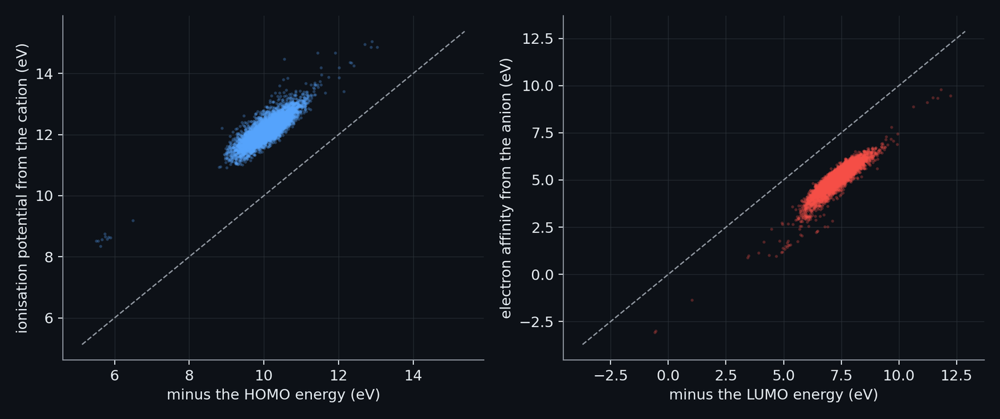

**Figure: Orbital energies and ionisation potentials: Koopmans' relation on real compounds.** Koopmans' approximation on the 6895 compounds of the physics cache: the ionisation potential computed from the energy of the cation (vertical, vertical axis) against minus the energy of the highest occupied orbital (horizontal). Pearson r = 0.858 for the ionisation potential and 0.912 for the electron affinity against minus the lowest unoccupied orbital; the cation-based value sits +2.07 eV from the orbital value on average. Koopmans' approximation ignores how the remaining orbitals relax when an electron is removed, so the two are expected to track each other without being equal. The dashed line is equality.

In [279]:
show_figure("phys_koopmans")

## 10.5 The quantities of the physics block

> **Field:** Quantum chemistry · Biochemistry

*Where this section sits:* 10.4 gave the engine; this section says what is asked of it, quantity by quantity, and why each quantity is connected with the mechanism of time-dependent inhibition of 1.3, 1.9 and 1.10: Compound I takes a hydrogen atom from a carbon, a nitrogen binds the iron, a molecule is oxidised. Each quantity is a difference of the energies of single points, defined here, and each is computed in the cell below with the project's own functions (`cypmode/challenge/physics_block.py` and `cypmode/challenge/physics_tierb.py`) on three small molecules, so that every number can be followed by hand.

**Ionisation potential, electron affinity and what they build.** Let $E(N)$ be the energy of the molecule with its $N$ electrons and $E(N \pm 1)$ that of the cation and the anion at the same geometry (a **vertical** change: the nuclei do not move). The **ionisation potential** is $\mathrm{IP} = E(N-1) - E(N)$, the cost of taking an electron away, and the **electron affinity** is $\mathrm{EA} = E(N) - E(N+1)$, the gain from adding one. From them come three quantities of **conceptual density functional theory** (Parr and co-workers): the **chemical potential** $\mu = -(\mathrm{IP} + \mathrm{EA})/2$ (the tendency of electrons to leave; minus the Mulliken electronegativity), the **hardness** $\eta = (\mathrm{IP} - \mathrm{EA})/2$ (the resistance to rearranging the electrons: a hard molecule has a large gap between the energy to remove an electron and the energy gained by adding one) and the **electrophilicity** $\omega = \mu^2/(2\eta)$ (the energy lowering when the molecule takes up electrons from its surroundings, large for a molecule that is both eager and soft). The orbital energies of the highest occupied and lowest unoccupied orbitals, HOMO and LUMO (7.8), are kept too, and the dipole moment.

**Solvation.** Water is a dielectric continuum around the molecule. In the **ALPB** model (analytical linearised Poisson-Boltzmann; Ehlert, Stahn, Spicher and Grimme, 2021) the electric field of the solute's charges polarises the continuum, which acts back on them, and the cavity also costs a surface-dependent energy; the solvation free energy is $\Delta G_{\text{solv}} = E_{\text{water}} - E_{\text{gas}}$ at the same geometry. It matters because the enzyme's pocket is not a vacuum, and because the charge states of 10.5 live in water.

**Charges and Fukui functions.** The **partial charge** $q_k$ of atom $k$ is the Mulliken-type charge that the self-consistent loop of 10.4 produces. The **Fukui function** $f(\mathbf r) = (\partial\rho/\partial N)_v$ (Parr and Yang, 1984) says where the electron density changes when the number of electrons changes, and it has two branches because the derivative is different on the two sides of an integer: $f^-$, where an electron is removed from, and $f^+$, where an added electron goes. Condensed to atoms and computed by finite differences, in terms of the charges of the cation, the neutral molecule and the anion at the same geometry,

$$f^-_k \;=\; q_k(N-1) - q_k(N), \qquad f^+_k \;=\; q_k(N) - q_k(N+1),$$

each sums to 1 over the atoms (an electron is removed or added in total), with the hydrogens counted with the heavy atom they are bonded to. The atom with the largest $f^-$ is where the molecule is oxidised first, which makes it a candidate site for the enzyme's oxidant.

**Hydrogen abstraction.** The step that Compound I performs is the removal of a hydrogen atom from a carbon, $\text{R-H} \to \text{R}^\bullet + \text{H}^\bullet$. Its energy, $\Delta E_{\text{HAT}} = E(\text{R}^\bullet) + E(\text{H}^\bullet) - E(\text{R-H})$ with $E(\text{H}^\bullet)$ the energy of a free hydrogen atom, is the bond dissociation energy of that C-H bond if the radical is relaxed. Two versions are computed. The **vertical** one keeps the atoms of the radical where they were in the parent: it is cheap and consistent, but it leaves the radical unrelaxed, which overstates the energy by tens of kcal/mol, and by an amount that depends on the kind of radical, because a benzylic radical gains its stability only when the carbon flattens and its electron spreads over the ring. The **relaxed** one lets the radical centre, the atoms bonded to it and their hydrogens move to the nearest minimum of the energy (at most 8 steps of a quasi-Newton minimiser on the analytic gradients, the rest of the molecule frozen; the relaxation gain is a column of its own). In the project only the two best sites of a compound are relaxed, for the cost; the cell relaxes every site of its small molecules.

**Proton affinity.** The nitrogens that can bind the iron (1.9) are the ones whose lone pair is available. The **proton affinity** $\mathrm{PA} = E(\text{B}) - E(\text{BH}^+)$ at a frozen geometry, with a proton added along the lone pair, measures how strongly a nitrogen holds a proton, in the gas phase and in water. It is a ranking quantity, not an absolute one, for the reasons of the paragraph after the cell.

**Conformers.** A flexible molecule is a mixture of shapes, and the properties above differ from shape to shape. If the shapes $i$ have energies $E_i$, the fraction of molecules in shape $i$ at temperature $T$ (with $k$ the Boltzmann constant and $j$ running over all the shapes) is its **Boltzmann weight**

$$w_i \;=\; \frac{e^{-E_i/kT}}{\sum_j e^{-E_j/kT}}, \qquad kT = 0.5925\ \text{kcal/mol at } 298\ \text{K},$$

and an observed property is the average $\sum_i w_i x_i$. A shape 1 kcal/mol above the lowest has weight 0.18 relative to it, one 3 kcal/mol above has 0.006. Shapes are generated by RDKit (ETKDG embedding, MMFF optimisation) and, because a force field is not reliable for the relative energies of shapes, re-weighted by their GFN2-xTB energies in water.

The first cell computes the molecule-level quantities, the hydrogen-abstraction energies and the atom-level quantities.

In [280]:
# The quantities of the physics block (cypmode/challenge/physics_block.py) computed on three small molecules with the project's own functions, run in an isolated interpreter (10.1). Toluene has a benzylic C-H, the
# methylene group next to a ring; N-methylpiperidine has a tertiary amine and the C-H bonds next to its nitrogen; propane has plain aliphatic C-H bonds. For each molecule the routine returns the energy-based quantities of the
# whole molecule (ionisation potential, electron affinity, hardness, chemical potential, electrophilicity, solvation free energy in water), for each atom the partial charge, the two condensed Fukui functions and, for the nitrogens,
# the proton affinity in the gas phase and in water, and for each C-H site the hydrogen-abstraction energy, vertical (the geometry frozen, physics_block) and relaxed (the radical centre, its neighbours and their hydrogens
# allowed to move, physics_tierb.relaxed_hat). The experimental C-H bond dissociation enthalpies at 298 K (toluene 89.7 kcal/mol, the secondary C-H of propane 98.6) are those compiled by Blanksby and Ellison (Acc. Chem. Res. 2003).
quantities = run_isolated("""
    import json
    import numpy as np
    from rdkit import Chem
    from cypmode.challenge import physics_block as pb
    from cypmode.challenge import physics_tierb as tb
    out = {}
    for name, smiles in (("toluene", "Cc1ccccc1"), ("N-methylpiperidine", "CN1CCCCC1"), ("propane", "CCC")):
        features, rows = pb.compute_molecule(smiles)
        mol_h = Chem.AddHs(pb.largest_fragment(smiles))
        ids, energies = pb.conformer_ensemble(mol_h)
        positions = mol_h.GetConformer(ids[int(np.argmin(energies))]).GetPositions()
        numbers = np.array([a.GetAtomicNum() for a in mol_h.GetAtoms()])
        sites = []
        for row in rows:
            if row["hat_kcal"] == row["hat_kcal"]:
                relaxed = tb.relaxed_hat(mol_h, numbers, positions, 0, int(row["atom"]))
                sites.append({"atom": int(row["atom"]), "role": row["ch_role"], "vertical": float(row["hat_kcal"]), "relaxed": None if relaxed is None else float(relaxed)})
        out[name] = {"molecule": {k: float(v) for k, v in features.items() if k in ("phys_ip_ev", "phys_ea_ev", "phys_hardness_ev", "phys_chem_potential_ev", "phys_electrophilicity_ev", "phys_dg_solv_kcal", "phys_homo_ev", "phys_lumo_ev", "phys_dipole_d")},
                     "atoms": [{k: (None if (isinstance(v, float) and v != v) else (float(v) if isinstance(v, (int, float, np.floating)) else v)) for k, v in row.items() if k != "SMILES"} for row in rows], "sites": sites}
    print(json.dumps(out))
""")
experimental_bde = {"toluene": 89.7, "propane": 98.6}
molecule_table = pd.DataFrame({name: data["molecule"] for name, data in quantities.items()}).T.rename(columns={"phys_ip_ev": "ionisation potential (eV)", "phys_ea_ev": "electron affinity (eV)", "phys_hardness_ev": "hardness (eV)", "phys_chem_potential_ev": "chemical potential (eV)",
                       "phys_electrophilicity_ev": "electrophilicity (eV)", "phys_dg_solv_kcal": "solvation free energy in water (kcal/mol)", "phys_homo_ev": "HOMO (eV)", "phys_lumo_ev": "LUMO (eV)", "phys_dipole_d": "dipole (debye)"})
show_table(molecule_table.reset_index().rename(columns={"index": "molecule"}), floatfmt=".2f")
site_rows = []
for name, data in quantities.items():
    for site in data["sites"]:
        site_rows.append({"molecule": name, "atom": site["atom"], "C-H role": site["role"], "vertical (kcal/mol)": site["vertical"], "relaxed (kcal/mol)": site["relaxed"], "measured (kcal/mol)": experimental_bde.get(name) if site["role"] in ("benzylic",) or (name == "propane" and site["atom"] == 1) else np.nan})
site_table = pd.DataFrame(site_rows)
show_table(site_table, floatfmt=".1f")
atom_rows = []
for name in ("N-methylpiperidine",):
    for row in quantities[name]["atoms"]:
        atom_rows.append({"atom": row["atom"], "element": row["symbol"], "charge q": row["q"], "f-": row["f_minus"], "f+": row["f_plus"], "proton affinity, gas (kcal/mol)": row["pa_gas_kcal"], "proton affinity, water (kcal/mol)": row["pa_water_kcal"]})
atom_table = pd.DataFrame(atom_rows)
show_table(atom_table, floatfmt=".3f")
fukui_sum_minus, fukui_sum_plus = float(atom_table["f-"].sum()), float(atom_table["f+"].sum())
best = {name: sorted((s for s in data["sites"] if s["relaxed"] is not None), key=lambda s: s["vertical"]) for name, data in quantities.items()}
toluene_site, piperidine_site, propane_site = best["toluene"][0], best["N-methylpiperidine"][0], best["propane"][0]
vertical_order = [name for name, site in sorted(((n, d[0]) for n, d in best.items()), key=lambda x: x[1]["vertical"])]
relaxed_order = [name for name, site in sorted(((n, d[0]) for n, d in best.items()), key=lambda x: x[1]["relaxed"])]

| molecule | HOMO (eV) | LUMO (eV) | dipole (debye) | solvation free energy in water (kcal/mol) | ionisation potential (eV) | electron affinity (eV) | hardness (eV) | chemical potential (eV) | electrophilicity (eV) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| toluene | -10.57 | -5.98 | 0.53 | -0.72 | 13.58 | 2.88 | 5.35 | -8.23 | 6.33 |
| N-methylpiperidine | -9.38 | 0.60 | 0.91 | -0.91 | 12.80 | -3.56 | 8.18 | -4.62 | 1.30 |
| propane | -11.53 | 3.13 | 0.01 | 0.05 | 14.57 | -6.27 | 10.42 | -4.15 | 0.83 |

| molecule | atom | C-H role | vertical (kcal/mol) | relaxed (kcal/mol) | measured (kcal/mol) |
| --- | --- | --- | --- | --- | --- |
| toluene | 0 | benzylic | 127.7 | 113.7 | 89.7 |
| N-methylpiperidine | 0 | alpha_N | 123.8 | 117.8 | nan |
| N-methylpiperidine | 2 | alpha_N | 121.7 | 116.1 | nan |
| N-methylpiperidine | 3 | aliphatic | 131.6 | 126.9 | nan |
| N-methylpiperidine | 4 | aliphatic | 131.1 | 126.1 | nan |
| N-methylpiperidine | 5 | aliphatic | 131.6 | 126.9 | nan |
| N-methylpiperidine | 6 | alpha_N | 121.7 | 116.1 | nan |
| propane | 0 | aliphatic | 136.6 | 131.1 | nan |
| propane | 1 | aliphatic | 132.0 | 125.3 | 98.6 |
| propane | 2 | aliphatic | 136.6 | 131.1 | nan |

| atom | element | charge q | f- | f+ | proton affinity, gas (kcal/mol) | proton affinity, water (kcal/mol) |
| --- | --- | --- | --- | --- | --- | --- |
| 0.000 | C | 0.051 | 0.183 | 0.215 | nan | nan |
| 1.000 | N | -0.179 | 0.210 | 0.186 | 65.313 | 118.702 |
| 2.000 | C | 0.051 | 0.149 | 0.137 | nan | nan |
| 3.000 | C | 0.010 | 0.105 | 0.123 | nan | nan |
| 4.000 | C | 0.005 | 0.099 | 0.081 | nan | nan |
| 5.000 | C | 0.010 | 0.105 | 0.123 | nan | nan |
| 6.000 | C | 0.051 | 0.149 | 0.137 | nan | nan |

**What the numbers show.** For toluene the ionisation potential is 13.6 eV and the electron affinity 2.9, so that $\eta$ = 5.3 and $\omega$ = 6.3 eV. For N-methylpiperidine the ionisation potential is lower (12.8 eV: the lone pair of the amine leaves more easily than an electron of a ring) and the electron affinity is negative (-3.6 eV, meaning that the anion is higher in energy than the neutral molecule); it is a hard, poorly electrophilic molecule ($\eta$ = 8.2, $\omega$ = 1.3 eV). The condensed Fukui functions of N-methylpiperidine sum to 1.00 ($f^-$) and 1.00 ($f^+$) over its heavy atoms, as they must. The nitrogen carries the largest $f^-$ among the atoms of the table (0.21), which says that the first electron to leave is the nitrogen's. Its proton affinity is 65 kcal/mol in the gas phase and 119 in water, higher in water because the water continuum stabilises the cation that is formed.

The hydrogen-abstraction energies are the instructive part. The best site of toluene is the benzylic C-H, and the energies are 127.7 kcal/mol vertical and 113.7 relaxed, against a measured bond dissociation enthalpy of about 90. The best site of N-methylpiperidine, a C-H next to the nitrogen, gives 121.7 and 116.1; the secondary C-H of propane 132.0 and 125.3, against 98.6 measured. Three things follow. First, **the absolute values are not bond energies**: the vertical numbers are 38 (toluene) and 33 (propane) kcal/mol too high and the relaxed ones 24 and 27. That is an error of the method and of the bounded relaxation, which this notebook does not separate. Second, **the vertical ordering is wrong and the relaxed ordering is right.** Measured, the benzylic C-H of toluene is the weakest of the three kinds (about 90 against about 99 for the secondary C-H of propane); vertically the order of the three molecules' best sites is N-methylpiperidine < toluene < propane, which puts the amine C-H first and the benzylic C-H second, while relaxed it is toluene < N-methylpiperidine < propane, with the benzylic C-H first and a gap to propane of 11.6 kcal/mol against a measured 8.9. Third, relaxation is what a benzylic radical needs: its gain over the vertical value is 14.0 kcal/mol for toluene against 6.7 for propane. This is why the project has two tiers (10.6): the vertical energies of tier A for every C-H of every molecule, the relaxed energies of tier B for the two best sites.

**The same holds for the other energies.** The ionisation potentials of GFN2-xTB are 5 eV above those of the density functional method (10.4), the proton affinities are not proton affinities (the energy of the free proton is not in the difference, and the geometry is frozen), and the solvation free energies are small (-0.7 kcal/mol for toluene and -0.9 for N-methylpiperidine; the measured hydration free energy of benzene is about −1 kcal/mol and that of methanol about −5, so that the sign and the polar/non-polar ordering are right and the size of the polar values is probably not). What can be used is the ranking of a quantity across sites and across molecules. A tree-based model, which splits on the ordering, can use a quantity with an offset; this is the working assumption of the whole block, and 10.6 tests it.

The second cell takes a molecule of the kind the challenge is about, propranolol, and shows the conformers.

In [281]:
# A flexible molecule is not one shape. Propranolol (a CYP2D6 substrate: a basic nitrogen on a short chain attached to a naphthalene) is embedded 8 times by RDKit's ETKDG method and each shape is relaxed with the force field MMFF.
# The project then scores every shape with GFN2-xTB in implicit water (ALPB) and weights them by the Boltzmann factor exp(-E / kT) of the quantum-chemical energy, kT = 0.5925 kcal/mol at 298 K. The table compares the order
# of the shapes by the force field and by GFN2/ALPB, gives the weights, the vertical ionisation potential of each shape, and the distance from the basic nitrogen to the centres of the two aromatic rings of the naphthalene
# (the window of the CYP2D6 pharmacophore is 4.5 to 7.5 angstrom, 10.5).
conformers = run_isolated("""
    import json
    import numpy as np
    from rdkit import Chem
    from cypmode.challenge import physics_block as pb
    from cypmode.challenge import physics_tierb as tb
    mol = pb.largest_fragment("CC(C)NCC(O)COc1cccc2ccccc12")
    mol_h = Chem.AddHs(mol)
    ids, mmff = pb.conformer_ensemble(mol_h)
    numbers = np.array([a.GetAtomicNum() for a in mol_h.GetAtoms()])
    rings = [list(r) for r in mol.GetRingInfo().AtomRings() if all(mol.GetAtomWithIdx(i).GetIsAromatic() for i in r)]
    nitrogen = [a.GetIdx() for a in mol.GetAtoms() if a.GetSymbol() == "N"][0]
    rows = []
    for cid, e_mmff in zip(ids, mmff):
        xyz = mol_h.GetConformer(cid).GetPositions()
        gas, cation, water = pb._single_point(numbers, xyz, 0), pb._single_point(numbers, xyz, 1), pb._single_point(numbers, xyz, 0, "water")
        distances = sorted(float(np.linalg.norm(xyz[r].mean(axis=0) - xyz[nitrogen])) for r in rings)
        rows.append({"mmff": float(e_mmff), "gfn2_water": float(water.get("energy")) * pb.HARTREE_KCAL, "ip": (float(cation.get("energy")) - float(gas.get("energy"))) * pb.HARTREE_EV, "nearest": distances[0], "farthest": distances[-1]})
    weights = tb.boltzmann_weights(np.array([r["gfn2_water"] for r in rows]))
    for r, w in zip(rows, weights):
        r["weight"] = float(w)
    print(json.dumps(rows))
""")
conformer_table = pd.DataFrame(conformers)
conformer_table["MMFF, relative (kcal/mol)"] = conformer_table["mmff"] - conformer_table["mmff"].min()
conformer_table["GFN2/ALPB, relative (kcal/mol)"] = conformer_table["gfn2_water"] - conformer_table["gfn2_water"].min()
conformer_table = conformer_table.sort_values("GFN2/ALPB, relative (kcal/mol)").reset_index(drop=True)
display_table = conformer_table[["MMFF, relative (kcal/mol)", "GFN2/ALPB, relative (kcal/mol)", "weight", "ip", "nearest", "farthest"]].rename(columns={"weight": "Boltzmann weight", "ip": "vertical ionisation potential (eV)", "nearest": "N to nearest ring (angstrom)", "farthest": "N to farthest ring (angstrom)"})
show_table(display_table, floatfmt=".2f")
mmff_best = int(conformer_table["MMFF, relative (kcal/mol)"].idxmin())
weight_of_mmff_best = float(conformer_table.loc[mmff_best, "weight"])
weighted_ip = float((conformer_table["weight"] * conformer_table["ip"]).sum())
ip_spread = float(conformer_table["ip"].max() - conformer_table["ip"].min())
lowest_ip = float(conformer_table.loc[0, "ip"])
n_conformers_9 = len(conformer_table)
within_window = conformer_table[(conformer_table["nearest"] >= 4.5) & (conformer_table["nearest"] <= 7.5)]
share_in_window = float(within_window["weight"].sum())

| MMFF, relative (kcal/mol) | GFN2/ALPB, relative (kcal/mol) | Boltzmann weight | vertical ionisation potential (eV) | N to nearest ring (angstrom) | N to farthest ring (angstrom) |
| --- | --- | --- | --- | --- | --- |
| 0.62 | 0.00 | 0.45 | 11.82 | 6.54 | 7.92 |
| 0.99 | 0.35 | 0.25 | 11.80 | 7.49 | 8.40 |
| 4.30 | 0.69 | 0.14 | 11.72 | 5.97 | 6.81 |
| 0.35 | 0.84 | 0.11 | 11.85 | 6.54 | 7.92 |
| 4.24 | 1.62 | 0.03 | 11.75 | 6.88 | 7.11 |
| 5.86 | 1.81 | 0.02 | 11.68 | 6.46 | 7.97 |
| 6.65 | 2.73 | 0.00 | 11.76 | 6.53 | 8.17 |
| 0.00 | 4.55 | 0.00 | 11.92 | 6.31 | 6.57 |

The force field and the quantum-chemical energy disagree about the shapes. The lowest shape by MMFF, whose weight after re-weighting is 0.000, is not the lowest by GFN2/ALPB, and the shape with the largest weight, 0.45, is a shape that MMFF puts 0.6 kcal/mol above its lowest. The Boltzmann-weighted ionisation potential is 11.80 eV, against 11.82 for the shape of lowest GFN2/ALPB energy; the 8 shapes span 0.23 eV, little for this molecule, so that the choice of the shape matters less for the energies than for the geometry. The geometry varies more: the distance from the basic nitrogen to the nearest aromatic ring runs from 6.0 to 7.5 Å among the shapes, the upper end at the edge of the window of 4.5 to 7.5 Å in which the pharmacophore of CYP2D6 places the cation and the ring (100% of the Boltzmann weight lies inside it). A geometric feature computed from one shape would take a different value from another shape of the same molecule. The geometric features of the block (10.6, level 4) are therefore computed over the ensemble.

*On what actually ran.* The functions `compute_molecule` (`physics_block.py`), `relaxed_hat`, `boltzmann_weights` and `conformer_ensemble` of the project, called in an isolated interpreter by the cells above. The 6,895 compounds were processed by the same functions through the extraction job `070_physics_xtb_block` (tier A) and `073_physics_tierb_extract` (tier B), which write the caches `physics_cache.csv`, `physics_atoms.csv.gz` and `physics_b_cache.csv`; the notebook does not repeat them. The measured bond dissociation enthalpies are from the compilation of Blanksby and Ellison (2003); the hydration free energies quoted in the text, benzene and methanol, are from the FreeSolv database (Mobley and Guthrie, 2014).

In [282]:
# What the physics block is made of and what it cost, read from the code and the caches. The block (cypmode/challenge/physics_block.py) has four levels, molecule, atom, site and pharmacophore; the tables of column names of the
# module give the number of columns of each; the cache holds one row of the columns for each of the 6,895 compounds, and a column that describes a role that a compound does not have (for example the proton affinity of an azole
# nitrogen in a compound without an azole) is missing for it. The tier-B block (physics_tierb.py) is the compact block of Boltzmann-weighted and relaxed quantities.
from cypmode.challenge import physics_block as physics_a
from cypmode.challenge import physics_tierb as physics_b

n_tier_a = len(physics_a.FEATURE_NAMES)
n_tier_b = len(physics_b.FEATURE_NAMES)
n_ch_roles, n_binder_roles = len(physics_a.CH_ROLES), len(physics_a.BINDER_ROLES)
cache_a = pd.read_csv(ROOT / "data/tdi_track/outputs/caches/physics_cache.csv")
columns_a = cache_a.drop(columns=cache_a.columns[0])
missing_share = columns_a.isna().mean()
n_rows_cache = len(cache_a)
n_mostly_missing, n_nearly_empty = int((missing_share > 0.5).sum()), int((missing_share > 0.9).sum())
extract_hours_a = (pd.Timestamp("2026-10-08 17:05:20") - pd.Timestamp("2026-10-08 09:59:46")).total_seconds() / 3600
extract_hours_b = (pd.Timestamp("2026-10-10 02:39:23") - pd.Timestamp("2026-10-10 00:45:25")).total_seconds() / 3600
print(f"tier A: {n_tier_a} columns, {n_mostly_missing} of them missing for more than half of the {n_rows_cache:,} compounds; tier B: {n_tier_b} columns; extraction {extract_hours_a:.1f} h and {extract_hours_b:.1f} h")

tier A: 133 columns, 53 of them missing for more than half of the 6,895 compounds; tier B: 22 columns; extraction 7.1 h and 1.9 h


## 10.6 The physics block in the models: four levels, two refinements, and why none passed

> **Field:** Machine learning · Quantum chemistry

*Where this section sits:* 10.1 to 10.5 built an instrument and defined what it measures. This section points it at the models and applies the rule of 6.7, which was written before any of the results below existed. It is a section about an idea with a mechanism behind it that did not pass, and about how far the numbers allow one to conclude that it does not work.

**The idea and the block.** The two quantum features that were tried first (7.8) described the molecule as a whole or looked at one kind of atom; time-dependent inhibition is a statement about specific atoms and the geometry between them. The physics block (`cypmode/challenge/physics_block.py`) therefore measures four levels. *Level 1, the molecule:* the conformer-aware frontier orbital energies, the ionisation potential and electron affinity, the hardness and electrophilicity, the dipole, the solvation free energy in water, and the shape. *Level 2, the atom:* the partial charge, the two condensed Fukui functions, the vertical hydrogen-abstraction energy of every non-aromatic C-H, the vertical proton affinity of every nitrogen that could bind the iron (gas phase and water), and the accessible surface of the atom. *Level 3, the site:* the atoms are grouped by the chemical **role** that a pattern assigns them (10 kinds of C-H, among them benzylic, next to a nitrogen, next to an oxygen, allylic, methylenedioxy, and 8 kinds of atom that can bind the iron or be oxidised, such as azole, pyridine and amine nitrogens and thioether sulfur), with statistics per role and with how the best oxidation sites compete with each other (the sorted energies, how many lie within 3 kcal/mol of the lowest, the entropy of their Boltzmann weights). *Level 4, the pharmacophore:* over an ensemble of conformers, the distances between the iron-binding atoms and the best oxidation sites, their exposure to solvent, and how many good sites lie in the shell 4 to 8 Å around a binder. Together these are 133 columns for each compound, computed by the extraction job `070_physics_xtb_block` in 7.1 hours for the 6,895 compounds. 53 of the columns are missing for more than half of the compounds, 23 for more than nine in ten, because they describe a role that a compound lacks (the proton affinity of an azole nitrogen in a compound with no azole); a tree handles a missing value, but each such column dilutes the splits.

The block is label-free (it is computed from the structure alone), so that no label can leak through it. **Tier A** is the block as described. **The compact selection** (`cypmode/challenge/physics_compact_experiment.py`, job `072_physics_compact`) keeps the 20 columns with the largest gain, chosen by a physics-only model fitted on the training rows of each task, so that the evaluation rows never influence the choice. **Tier B** (`cypmode/challenge/physics_tierb.py`, jobs `073_physics_tierb_extract` and `074_physics_tierb_experiment`) replaces the vertical hydrogen-abstraction energy of the two best sites by the relaxed one of 10.5 and averages the ionisation potential, solvation and Fukui functions over up to three Boltzmann-weighted conformers: 22 columns, 1.9 hours of extraction. Two further uses were tried: the block in the pair model of 9.2 (`cypmode/challenge/pair_transfer.py`, job `075_pair_transfer_physics`), and the block in the selection-aware CYP2D6 model of 9.1, in all four of its families (`cypmode/challenge/population_physics.py`, job `071_population_physics`), because whether the screen promoted a compound depends on how reactive and how promiscuous it is, which the block measures.

**The rule.** For each use, the gate of 6.7: the change of the outer-fold AUC when the addition joins the default stack, with the corrected resampled t, and p below 0.05 at both confidence cut-offs. For tier A, the compact selection and tier B the 10-outer-fold replicate of 6.7 was declared before any ten-fold result existed (jobs `081_replicate_grid_f10`, `082_replicate_physics_f10` and `083_replicate_verdict`). The cell reads every log.

In [283]:
# The verdicts of the physics experiments, read from the logs: the block in the stack (tier A, the compact selection of 20 columns chosen inside each task, tier B), the pair model with the physics columns, and the physics inside
# the selection-aware CYP2D6 model; each in the 5-outer-fold design, and the three blocks again in the 10-outer-fold replicate (6.7). The change is the paired change of the outer-fold AUC when the addition joins the stack, with the
# corrected resampled t. The last lines take the block alone: its own AUC (a model on the physics columns only) and the change that it makes to the plain descriptor model (feature set A) and to the descriptor-plus-fingerprint model.
POP_PHYSICS_LINE = re.compile(r"z0=(\d\.\d+)\s+stacked with physics vs without: AUC ([+-][\d.]+) \(p=([\d.]+)")
def physics_row(label, stem, iso, design):
    result = read_gate_log(stem, iso)
    if result is not None and not result["stacked"].empty:
        table = result["stacked"].set_index("z0")
        return {"experiment": label, "design": design, "enzyme": iso, "AUC change at z0 1.0": float(table.loc[1.0, "gain"]), "p at z0 1.0": float(table.loc[1.0, "p"]), "AUC change at z0 1.96": float(table.loc[1.96, "gain"]), "p at z0 1.96": float(table.loc[1.96, "p"]),
                "gate": "MET" if result["verdicts"].get("stacked") else "NOT MET"}
    path = LOGS9 / f"{stem}_{iso}.log"
    if path.exists():
        text = path.read_text(errors="ignore")
        found = {float(z): (float(g), float(p)) for z, g, p in POP_PHYSICS_LINE.findall(text)}
        if len(found) == 2:
            return {"experiment": label, "design": design, "enzyme": iso, "AUC change at z0 1.0": found[1.0][0], "p at z0 1.0": found[1.0][1], "AUC change at z0 1.96": found[1.96][0], "p at z0 1.96": found[1.96][1], "gate": "NOT MET" if "NOT MET" in text else "MET"}
    return {"experiment": label, "design": design, "enzyme": iso, "AUC change at z0 1.0": np.nan, "p at z0 1.0": np.nan, "AUC change at z0 1.96": np.nan, "p at z0 1.96": np.nan, "gate": "not run yet"}

physics_plan = [("tier A (133 columns)", "physics_experiment", "5 folds"), ("compact selection (20 columns)", "physics_compact", "5 folds"), ("tier B (relaxed and averaged)", "physics_tierb", "5 folds"),
                ("pair model with physics", "pair_transfer_physics", "5 folds"), ("physics in the selection-aware model", "population_physics", "5 folds"),
                ("tier A (133 columns)", "physics_experiment_f10", "10 folds"), ("compact selection (20 columns)", "physics_compact_f10", "10 folds"), ("tier B (relaxed and averaged)", "physics_tierb_f10", "10 folds")]
physics_rows = []
for label, stem, design in physics_plan:
    for iso in ("CYP3A4", "CYP2D6"):
        if stem == "population_physics" and iso == "CYP3A4":
            continue
        physics_rows.append(physics_row(label, stem, iso, design))
physics_table = pd.DataFrame(physics_rows)
show_table(physics_table, floatfmt=".4f")

alone_rows = []
for iso in ("CYP3A4", "CYP2D6"):
    result = read_gate_log("physics_experiment", iso)
    diagnostic = result["diagnostic"].set_index("z0")["outer AUC alone"]
    alone = result["alone"].set_index(["z0", "against"])
    alone_rows.append({"enzyme": iso, "physics columns alone, AUC at z0 1.0": float(diagnostic.loc[1.0]), "added to feature set A": float(alone.loc[(1.0, "lgbm_A_deep"), "gain"]), "p (A)": float(alone.loc[(1.0, "lgbm_A_deep"), "p"]),
                       "added to A+fps": float(alone.loc[(1.0, "lgbm_A+fps_deep"), "gain"]), "p (A+fps)": float(alone.loc[(1.0, "lgbm_A+fps_deep"), "p"])})
alone_table = pd.DataFrame(alone_rows)
show_table(alone_table, floatfmt=".4f")
def physics_cell(label, design, iso):
    r = physics_table[(physics_table["experiment"] == label) & (physics_table["design"] == design) & (physics_table["enzyme"] == iso)]
    return r.iloc[0]
tier_a_3a4, compact_3a4, tierb_3a4 = (physics_cell(l, "5 folds", "CYP3A4") for l in ("tier A (133 columns)", "compact selection (20 columns)", "tier B (relaxed and averaged)"))
compact_ten_3a4 = physics_cell("compact selection (20 columns)", "10 folds", "CYP3A4")
n_positive_physics = int((physics_table["AUC change at z0 1.0"] > 0).sum())
n_physics_tests = int(physics_table["AUC change at z0 1.0"].notna().sum())
n_physics_met = int((physics_table["gate"] == "MET").sum())
largest_physics = float(physics_table["AUC change at z0 1.0"].max())

| experiment | design | enzyme | AUC change at z0 1.0 | p at z0 1.0 | AUC change at z0 1.96 | p at z0 1.96 | gate |
| --- | --- | --- | --- | --- | --- | --- | --- |
| tier A (133 columns) | 5 folds | CYP3A4 | 0.0050 | 0.0780 | 0.0055 | 0.1150 | NOT MET |
| tier A (133 columns) | 5 folds | CYP2D6 | 0.0027 | 0.7750 | 0.0050 | 0.1120 | NOT MET |
| compact selection (20 columns) | 5 folds | CYP3A4 | 0.0036 | 0.0680 | 0.0033 | 0.1480 | NOT MET |
| compact selection (20 columns) | 5 folds | CYP2D6 | -0.0022 | 0.7860 | 0.0034 | 0.4680 | NOT MET |
| tier B (relaxed and averaged) | 5 folds | CYP3A4 | 0.0007 | 0.8120 | 0.0020 | 0.5720 | NOT MET |
| tier B (relaxed and averaged) | 5 folds | CYP2D6 | 0.0015 | 0.6430 | 0.0028 | 0.4920 | NOT MET |
| pair model with physics | 5 folds | CYP3A4 | 0.0042 | 0.1520 | 0.0042 | 0.3040 | NOT MET |
| pair model with physics | 5 folds | CYP2D6 | -0.0010 | 0.9160 | 0.0019 | 0.6300 | NOT MET |
| physics in the selection-aware model | 5 folds | CYP2D6 | 0.0054 | 0.6880 | 0.0011 | 0.9320 | NOT MET |
| tier A (133 columns) | 10 folds | CYP3A4 | 0.0037 | 0.2980 | 0.0065 | 0.0930 | NOT MET |
| tier A (133 columns) | 10 folds | CYP2D6 | 0.0034 | 0.4940 | 0.0061 | 0.1860 | NOT MET |
| compact selection (20 columns) | 10 folds | CYP3A4 | 0.0037 | 0.0540 | 0.0043 | 0.0250 | NOT MET |
| compact selection (20 columns) | 10 folds | CYP2D6 | 0.0028 | 0.3940 | 0.0014 | 0.6870 | NOT MET |
| tier B (relaxed and averaged) | 10 folds | CYP3A4 | 0.0010 | 0.7340 | 0.0014 | 0.5630 | NOT MET |
| tier B (relaxed and averaged) | 10 folds | CYP2D6 | -0.0030 | 0.6920 | 0.0037 | 0.5640 | NOT MET |

| enzyme | physics columns alone, AUC at z0 1.0 | added to feature set A | p (A) | added to A+fps | p (A+fps) |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | 0.7531 | 0.0147 | 0.1080 | 0.0034 | 0.6240 |
| CYP2D6 | 0.6460 | 0.0200 | 0.4080 | 0.0152 | 0.4490 |

0 of the 15 comparisons meet the gate. Tier A, in the stack, changes the AUC of CYP3A4 by +0.0050 (p = 0.078) at $z_0 = 1.0$ and +0.0055 (p = 0.115) at 1.96; the compact selection by +0.0036 (p = 0.068) and +0.0033 (p = 0.148); tier B by +0.0007 (p = 0.81) and +0.0020 (p = 0.57). The block itself carries information. A model on the physics columns alone reaches an AUC of 0.753 for CYP3A4 and 0.646 for CYP2D6 at $z_0 = 1.0$. Added to the plain descriptor model (feature set A) it raises the CYP3A4 AUC by +0.0147 (p = 0.11); added to the descriptor-and-fingerprint model it raises it by +0.0034 (p = 0.62). For CYP2D6 the changes are larger and as uncertain (+0.0200, p = 0.41, and +0.0152, p = 0.45). A reading, which the experiment does not test: the fingerprints already encode much of what the physics describes, since the substructure that defines a role is what the fingerprint records, and the stack of 23 members spans the rest.

The nearest approach to the gate is the ten-fold replicate of the compact selection on CYP3A4, with +0.0037 (p = 0.054) at $z_0 = 1.0$ and +0.0043 (p = 0.025) at 1.96: significant at one cut-off and not quite at the other, and the gate asks for both. It is not met, and the rule was not softened afterwards. The physics inside the selection-aware model and in the pair model do not come close.

**Why none passed.** The changes are small and nearly all positive: 12 of the 15 changes at $z_0 = 1.0$ are above zero, the largest being +0.0054. The main design recognises a difference 8 times in 10 only above 0.0099 AUC, and the replicate above 0.0093 (6.7), so that effects of the size seen here are below what either design can establish. A verdict "not met" therefore means that the block was not shown to help; it does not mean that it was shown not to help. A true gain of 0.004 AUC is compatible with every number of the table, and so is no gain. What the numbers do establish is a bound, with the usual qualification: whatever the block adds to the stack on these compounds is probably less than about a hundredth of an AUC, since a gain of that size would be recognised in 8 of 10 repetitions of the experiment. The rule of the project for such a case was fixed before the results: an idea that fails its gate becomes a measured negative result in the ledger and is not tuned until it passes. After tier B no further physics variant was built. The block stays in the repository, with its caches and its code; it is not in the final stack.

*On what actually ran.* `cypmode/challenge/physics_block.py` (levels 1 to 4, `extract`, `load_physics_features`), `physics_tierb.py`, `physics_experiment.py`, `physics_compact_experiment.py`, `physics_tierb_experiment.py`, `population_physics.py`, `pair_transfer.py` (the physics variant), each run through `addition_experiment.py`; the logs `physics_experiment_<enzyme>.log`, `physics_compact_<enzyme>.log`, `physics_tierb_<enzyme>.log`, `pair_transfer_physics_<enzyme>.log`, `population_physics_CYP2D6.log` and their `_f10` replicates; the queue jobs named in the text. The notebook reads the logs and the cache of columns; it does not repeat the extraction. The two earlier quantum features (global GFN2 descriptors in `cypmode/challenge/quantum_pharmacophore.py` and `quantum_pharmacophore_significance.py`, and the surrogate of 7.8 in `qm_reactivity_features.py`) were put through the same kind of test and were null.

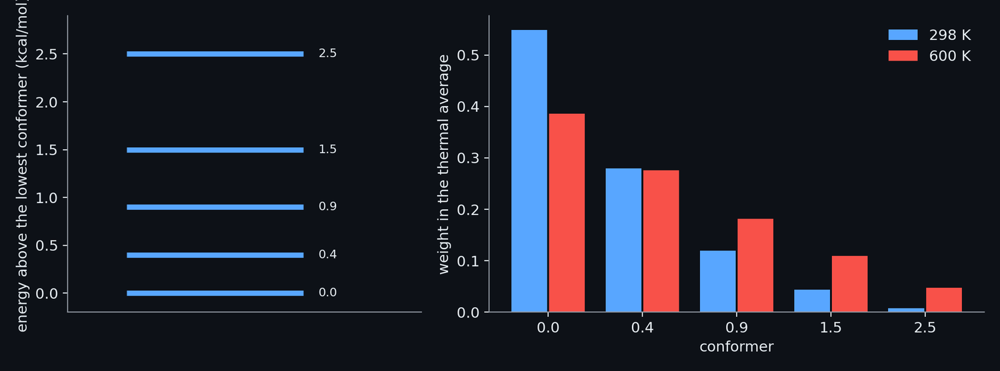

**Figure: Boltzmann weights of conformers.** A ladder of five conformer energies (0, 0.4, 0.9, 1.5 and 2.5 kcal/mol above the lowest, chosen to illustrate the formula) and the weight each conformer gets in a thermal average, w_i = exp(-E_i / kT) / sum_j exp(-E_j / kT), at 298 K and at 600 K. At 298 K the lowest conformer carries about half of the weight; hotter, the weights even out. The tier-B physics block averages its properties with these weights over up to three conformers.

In [284]:
show_figure("phys_boltzmann")

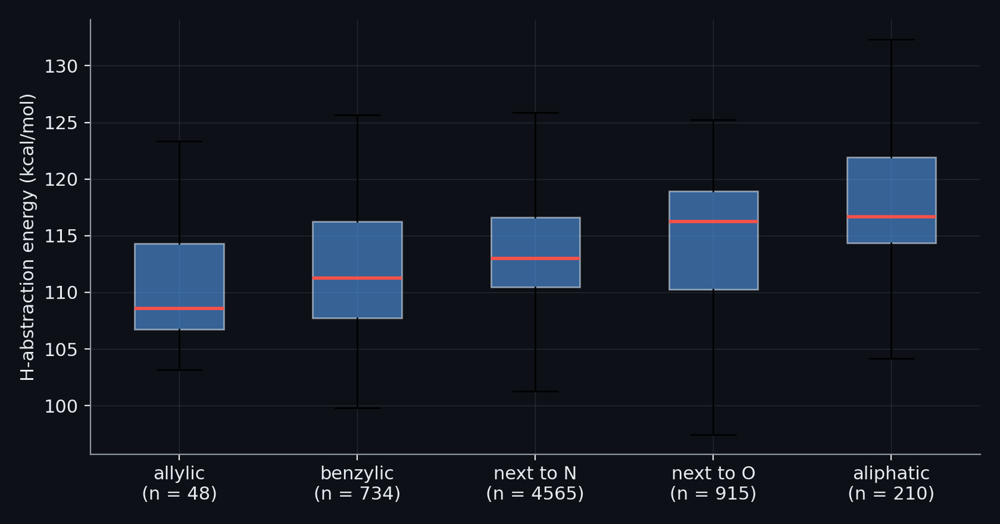

**Figure: Hydrogen-abstraction energy by kind of site.** Energy needed to pull a hydrogen off the easiest site of each compound (GFN2-xTB, atoms around the radical relaxed, kcal/mol), by the kind of site, for the 6472 compounds of the tier-B cache. Median by site: allylic 109, benzylic 111, next to N 113, next to O 116, aliphatic 117. A lower energy means an easier abstraction, which is the first step of the oxidation that makes a time-dependent inhibitor.

In [285]:
show_figure("phys_hat_by_site")

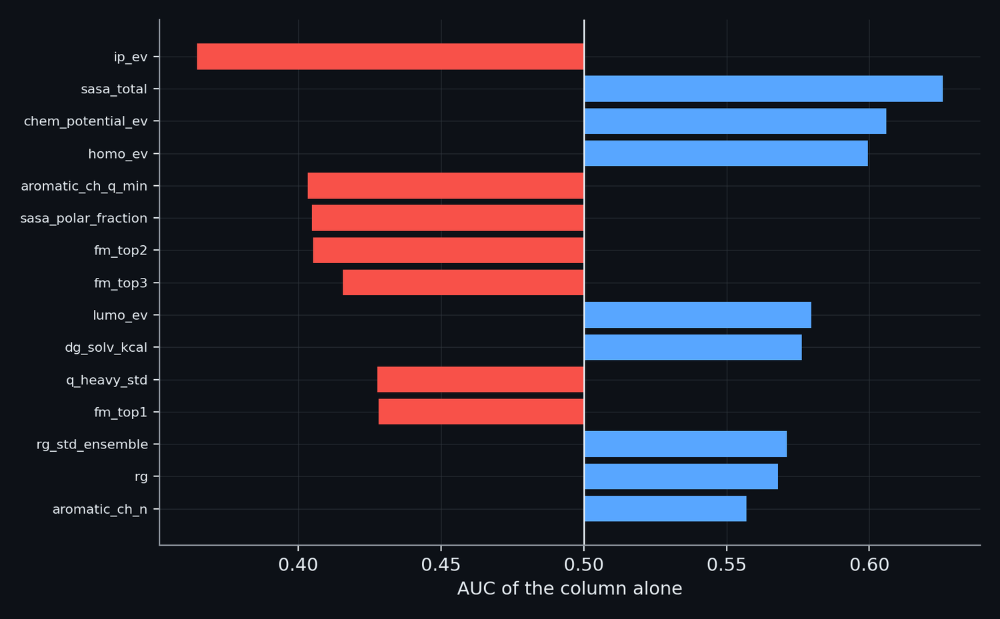

**Figure: How much signal each physics column carries alone.** For the labelled CYP3A4 compounds, the AUC with which each physics column separates the time-dependent inhibitors from the rest when used alone, as a rank score (0.5 means no signal; values below 0.5 mean the label is more common at low values); the 15 columns furthest from 0.5 of 97 with enough data. The strongest single column reaches 0.635 once its direction is taken into account, far below the 0.817 of the final stack, which is why the physics block is judged by what it adds to the stack, not alone.

In [286]:
show_figure("phys_single_column_signal")

# Part XI. The structure track

The challenge has a second track besides the classification of time-dependent inhibition. For 20 compounds the organisers ask for the three-dimensional pose of the compound in CYP3A4: a file of coordinates in which the protein, the heme and the ligand sit where they would in a crystal. The files are scored against experimental structures that are not public. The primary score is **LDDT-PLI**, a measure of how well the contacts between the ligand and the protein are kept (11.4); a second one is **BiSyRMSD**, the distance of the ligand atoms from their true positions after the pocket is superposed; and a pose that fails the organisers' physical-validity checks (the **PoseBusters** checks, 11.4) scores zero on all of them.

The project's position is that of a track with no answer key. The 20 compounds have no analogue in any deposited P450 structure (the best similarity to a deposited ligand is 0.35), so that nothing can be learned from a neighbour, and the models that predict poses are known to be confident when they are wrong. What the project has is the Protein Data Bank, which holds 129 CYP3A4 entries with a ligand in the active site, 148 ligand positions in all (11.5). They can serve as a **crystal-anchored benchmark**: ligands whose pose is known, on which every lever can be tried and scored before it is used on the 20. Most of this part is the account of levers that were tried this way, each with a rule written before its result, and most of them did not pass. The part is therefore also an account of how little the available evidence allows one to claim, and of the one lever, putting the ligand's iron-binding nitrogen on the heme iron, that passed its first gate and then did not pass its confirmation.

The order is the order of the pipeline. Sections 11.1 to 11.3 say what a structure file is, how a co-folding model predicts one and how its input is built. Section 11.4 says how a pose is scored. Sections 11.5 to 11.9 are the benchmarks and the levers: the restraint, the diversity levers, the choice among poses, and the second engine. Section 11.10 is the final recipe and the checks on the 20 files that are submitted. Section 11.11 is the pharmacophore model of a pose, with the checks of what such a model cannot see.

In [287]:
# The protein of the structure track: CYP3A4 (UniProt P08684), 503 residues, as it stands in the Boltz input of every ligand. The project finds the cysteine that binds the heme iron from the conserved signature
# F-x-x-G-x-x-x-C-x-G of all P450 enzymes (cypmode/validation/build_input.py, find_coordinating_cysteine): the cell checks that it finds one match and that the residue is the one the structure file names.
import re
import yaml

from cypmode.validation.build_input import CYS_MOTIF_PATTERN, find_coordinating_cysteine, heme_donor_atom

# The example input is the first, in alphabetical order, of the inputs whose ligand has a nitrogen that can reach the heme iron (a Type II donor), so that the restraint cell below has an atom to name.
inputs_in_order = (yaml.safe_load(path.read_text()) for path in sorted((ROOT / "data/structure_track/inputs").glob("cyp3a4_OCNT-*.yaml")))
input_yaml = next(candidate for candidate in inputs_in_order if heme_donor_atom(candidate["sequences"][1]["ligand"]["smiles"]) is not None)
cyp3a4_sequence = input_yaml["sequences"][0]["protein"]["sequence"]
cysteine_position = find_coordinating_cysteine(cyp3a4_sequence)
signature = re.search(CYS_MOTIF_PATTERN, cyp3a4_sequence)
composition = pd.Series(list(cyp3a4_sequence)).value_counts()
sequence_length = len(cyp3a4_sequence)
signature_text = signature.group(0)
most_common = ", ".join(f"{a} {composition[a]}" for a in composition.index[:3])

## 11.1 Proteins, folding and the structure of CYP3A4; what a complex file contains

> **Field:** Structural biology · Biochemistry

*Where this section sits:* Part I explained the heme and the catalytic cycle of a P450 enzyme, and 5.5 and 5.6 used a predicted structure to check the motif screen. This section starts the structure track from the beginning: what is being predicted, and what the file that holds the answer contains.

**Amino acids, the chain and the fold.** A **protein** is a chain of **amino acids**, twenty kinds, joined end to end by peptide bonds. Each unit of the chain, a **residue**, contributes the same three-atom stretch to the **backbone** (a nitrogen, a central carbon called C-alpha, and a carbonyl carbon) and a **side chain** attached to the C-alpha that differs from kind to kind: small and neutral, large and oily, charged, or able to bind a metal. The **sequence** is the string of residue letters. The **fold** is the three-dimensional shape that the chain takes up, which the sequence determines through many weak interactions: hydrogen bonds between backbone atoms that make helices and sheets, oily side chains that hide from water in the interior, opposite charges that pair. CYP3A4 (UniProt entry P08684) is a chain of 503 residues. The commonest residues are L 59, V 39, K 38, a composition typical of an enzyme that binds oily molecules. Its first stretch anchors it in the membrane of the cell's endoplasmic reticulum; the rest folds into a mostly helical catalytic domain around a heme.

**The heme and the cysteine.** The heme is a flat ring (a porphyrin) holding an iron atom (1.3). In every P450 enzyme the iron is held from one side by the sulfur of a cysteine, and the surrounding stretch of the sequence is so well conserved that a pattern finds it: phenylalanine, two residues, glycine, three residues, the cysteine, one residue, glycine. In CYP3A4 the pattern matches once, at FGSGPRNCIG, and the cysteine is residue 442. The other face of the iron looks into the pocket where substrates and inhibitors bind: it holds a water molecule at rest, binds the oxygen that the enzyme activates, and can be bound by a nitrogen of an inhibitor (1.9). The structure track is the question of how a ligand sits in that pocket relative to that iron.

**Where structures come from.** Experimental structures come from **X-ray crystallography** (the protein is crystallised, the diffraction of X-rays gives an electron density map into which atoms are fitted; the **resolution** in ångströms says how fine the map is: below 2 Å individual atoms are clear, at 3 Å only the shape of side chains) and, increasingly, **cryo-electron microscopy** (images of frozen molecules combined into a map; the five CYP3A4 entries released on 2026-09-30 are at 3.2 to 3.7 Å and are trimers). They are deposited in the **Protein Data Bank**, a public archive; each entry has a four-character identifier. The structure track's reference set is made from the CYP3A4 entries of the archive (11.5). Predicted structures come from models (11.2) and are written in the same formats.

**What the file holds.** The simplest format is that of the Protein Data Bank itself, a text file with one line for each atom (the other format, mmCIF, in which the prediction programs write and the archive keeps its entries, is read field by field in 5.5). The cell prints the first lines of one of the 20 submitted files and reads it with a library for structures. Each line gives the kind of record (`ATOM` for the residues of the protein, `HETATM` for everything else, here the ligand and the heme), a serial number, the atom name, the residue name, the chain, the residue number, the three coordinates in ångströms, an occupancy, the **B-factor** column and the element. In a crystal file the B-factor records how much an atom is smeared; the co-folding model writes into it its own confidence in the atom's position, from 0 to 100. The format stores no bonds for the ligand, and no bond orders at all: a program that needs them, as the scorer does, takes them from the SMILES string of the compound. The challenge asks for the protein as chain A, the ligand as the residue `LIG` and the heme as `HEM`.

In [288]:
# What a predicted complex file holds. The file is the first, in alphabetical order, of the 20 structures of the final submission (a ligand in CYP3A4), in the layout the challenge asks for: the protein as chain A, the ligand as the residue
# LIG on chain B, the heme as the residue HEM on chain C. The first four lines are shown as they are in the file, then the file is read with Biopython and counted. The last number in each line of coordinates before the element is the
# "B-factor" column, which in a crystal file records how much an atom is smeared; the co-folding model writes its own per-atom confidence into it (a number from 0 to 100).
from Bio.PDB import PDBParser

pose_path = sorted((ROOT / "data/structure_track/outputs/cyp3a4/final/_pdb_files").glob("*.pdb"))[0]
raw_lines = pose_path.read_text().splitlines()
print("\n".join(raw_lines[:4]))
hetero_start = next(i for i, line in enumerate(raw_lines) if line.startswith("HETATM"))
print("...")
print("\n".join(raw_lines[hetero_start:hetero_start + 2]))
pose = PDBParser(QUIET=True).get_structure("pose", str(pose_path))[0]
chain_rows = []
for chain in pose:
    residues = list(chain)
    atoms = [a for r in residues for a in r]
    chain_rows.append({"chain": chain.id, "residues": len(residues), "first residue": residues[0].get_resname(), "atoms": len(atoms), "mean confidence (B-factor column)": float(np.mean([a.get_bfactor() for a in atoms]))})
chain_table = pd.DataFrame(chain_rows)
show_table(chain_table, floatfmt=".1f")
iron = [a for r in pose["C"] for a in r if a.get_name() == "FE"][0]
cysteine = [r for r in pose["A"] if r.id[1] == 442][0]
sulfur = cysteine["SG"]
ligand_nitrogens = [a for r in pose["B"] for a in r if a.element == "N"]
iron_to_sulfur = float(np.linalg.norm(iron.coord - sulfur.coord))
nearest_nitrogen = min(ligand_nitrogens, key=lambda a: np.linalg.norm(iron.coord - a.coord))
iron_to_nitrogen = float(np.linalg.norm(iron.coord - nearest_nitrogen.coord))
n_protein_atoms, n_ligand_atoms, n_heme_atoms = (int(chain_table.loc[chain_table["chain"] == c, "atoms"].iloc[0]) for c in ("A", "B", "C"))
n_residues_protein = int(chain_table.loc[chain_table["chain"] == "A", "residues"].iloc[0])
cysteine_name = cysteine.get_resname()

ATOM      1  N   MET A   1      29.110  57.539  22.188  1.00 68.98           N  
ATOM      2  CA  MET A   1      29.595  56.404  22.964  1.00 68.98           C  
ATOM      3  C   MET A   1      28.737  56.154  24.198  1.00 68.98           C  
ATOM      4  O   MET A   1      28.744  55.046  24.739  1.00 68.98           O  
...
HETATM 4034  O19 LIG B   1       0.401   7.739   0.748  1.00 74.29           O  
HETATM 4035  C22 LIG B   1       0.434   6.547   0.956  1.00 81.44           C  


| chain | residues | first residue | atoms | mean confidence (B-factor column) |
| --- | --- | --- | --- | --- |
| A | 503 | MET | 4033 | 94.4 |
| B | 1 | LIG | 24 | 80.2 |
| C | 1 | HEM | 43 | 98.0 |

The file holds 503 residues of protein in 4,033 atoms, a ligand of 24 atoms and the heme of 43. The model's confidence is high for the protein (94 on average) and the heme (98) and lower for the ligand (80). The sulfur of the cysteine 442 is 2.22 Å from the iron, the distance of a coordinate bond, and the nearest nitrogen of this ligand is 1.95 Å from it on the other side. That is the geometry of a Type II ligand (1.9): iron bound by the sulfur on one face and by the nitrogen of the inhibitor on the other. How often the models place a ligand so, and whether they place it right, is the content of the rest of the part.

*On what actually ran.* The cells read one file of `final/_pdb_files` of the final recipe (11.10) and one input of `data/structure_track/inputs`, with Biopython and `cypmode/validation/build_input.py` (`find_coordinating_cysteine`, `CYS_MOTIF_PATTERN`). The count of the structures of the archive is the project's own reference set, built by `cypmode/validation/reference_ligands.py` (11.5).

## 11.2 Co-folding models: how a structure is predicted from a sequence and a molecule

> **Field:** Machine learning · Structural biology

*Where this section sits:* 11.1 said what a complex file holds. This section explains the family of models that writes it, from the sequence of the protein and the formula of the ligand alone. The project uses two members of the family, Boltz-2 and OpenFold3, and it uses them as instruments, not as objects of study; the section explains enough of their working for the reader to understand what the levers of 11.6 to 11.9 act on.

**The evolutionary record.** A single sequence says little about the fold. A set of sequences of the same protein from many species, aligned position by position (a **multiple sequence alignment**, MSA), says a great deal, because positions that touch each other in the folded protein must stay compatible: if one changes in the course of evolution, the other tends to change with it. The cell is a toy of this. It draws 400 related sequences of 12 positions at random, makes position 10 follow position 3 in 85 percent of them (positions counted from 1), and measures for every pair of positions the **mutual information** $I(i,j) = \sum f_{ij}\log\big(f_{ij}/(f_i f_j)\big)$, where $f_i$ is the share of each residue at position $i$ and $f_{ij}$ the share of each pair at positions $i$ and $j$: it is zero when the two positions vary independently and large when one tells the other.

In [289]:
# What an alignment of related sequences can tell about the shape. A toy "protein" of 12 positions with 4 kinds of residue. 400 related sequences are drawn at random, except that position 9 copies position 2 in 85 percent of them
# (positions 3 and 10 counted from 1, 2 and 9 counted from 0; two residues that touch each other in the folded protein and must change together to keep fitting). The mutual information of two columns, I(i, j) = sum over pairs of residues f_ij log( f_ij / (f_i f_j) ), where f_i is the
# share of each residue at position i and f_ij the share of pairs at i and j, is zero when the two positions vary independently and large when one tells the other.
rng_msa = np.random.default_rng(3)
n_sequences, n_positions, n_letters = 400, 12, 4
alignment = rng_msa.integers(0, n_letters, size=(n_sequences, n_positions))
copied = rng_msa.random(n_sequences) < 0.85
alignment[:, 9] = np.where(copied, alignment[:, 2], alignment[:, 9])

def mutual_information_matrix(msa, letters):
    n, length = msa.shape
    single = np.stack([np.bincount(msa[:, i], minlength=letters) / n for i in range(length)])
    information = np.zeros((length, length))
    for i in range(length):
        for j in range(i + 1, length):
            joint = np.zeros((letters, letters))
            for a, b in zip(msa[:, i], msa[:, j]):
                joint[a, b] += 1
            joint /= n
            seen = joint > 0
            information[i, j] = information[j, i] = (joint[seen] * np.log(joint[seen] / np.outer(single[i], single[j])[seen])).sum()
    return information

information = mutual_information_matrix(alignment, n_letters)
pair_index = np.triu_indices(n_positions, 1)
ranked = np.argsort(-information[pair_index])[:4]
coevolution_table = pd.DataFrame({"position i": pair_index[0][ranked] + 1, "position j": pair_index[1][ranked] + 1, "mutual information (nats)": information[pair_index][ranked]})
show_table(coevolution_table, floatfmt=".3f")
median_information = float(np.median(information[pair_index]))
top_pair = (int(coevolution_table.iloc[0, 0]), int(coevolution_table.iloc[0, 1]))

| position i | position j | mutual information (nats) |
| --- | --- | --- |
| 3 | 10 | 0.973 |
| 2 | 5 | 0.032 |
| 1 | 5 | 0.022 |
| 3 | 5 | 0.020 |

The pair (3, 10) stands out with a mutual information of 0.97 nats against a median of 0.010 for all pairs, and the next pair has 0.032. Real alignments hold thousands of sequences and the signal is weaker and spread over many pairs, and the models of this section learn to read it rather than to compute one number; but it is the same evidence. The alignments are made by searching a database of sequences; the model used here can ask a public server for them (the **ColabFold** service, Mirdita and co-workers, 2022), and the project keeps one alignment for CYP3A4 and reuses it for every ligand, which both saves the search and removes a dependence that failed once (11.3).

**The architecture.** The first model of this kind to be accurate on the folding problem was AlphaFold 2 (Jumper and co-workers, 2021), a network that turned an alignment into coordinates. AlphaFold 3 (Abramson and co-workers, 2024) extended it from proteins to complexes of proteins with other molecules, ligands included, and the open models used here follow its design: Boltz-1 (Wohlwend and co-workers, 2024) and its successor Boltz-2 (Passaro, Saro and co-workers, 2025), which also predicts a binding affinity, and OpenFold3 (the OpenFold consortium), a reimplementation of AlphaFold 3. All have two parts. The **trunk** reads the sequences, the alignment and the ligands and builds two representations: one vector for every **token** (a residue of the protein or an atom of a ligand) and one vector for every *pair* of tokens, the **pair representation** $z_{ij}$, which holds what the model has worked out about how $i$ and $j$ relate in space. The **diffusion module** then turns these representations into coordinates for every heavy atom. The trunk is run once for each prediction; the diffusion module is run once for each requested **sample**, from the same trunk output. The samples of one prediction are therefore not independent opinions: they share the trunk's reading of the problem and differ only in what the sampling adds.

**The pair representation and the triangle.** Distances in space obey the triangle inequality: $d_{ij} \le d_{ik} + d_{kj}$ for any third point $k$. If two positions are both close to a third, they cannot be far from each other. The trunk is built to use this. In a **triangle update** the vector of the pair $(i,j)$ is refreshed with information from the pairs $(i,k)$ and $(j,k)$ for every third token $k$:

$$z_{ij} \;\leftarrow\; z_{ij} + g_{ij}\odot W_o\,\mathrm{LN}\Big(\sum_k a_{ik}\odot b_{jk}\Big),$$

where $a_{ik}$ and $b_{jk}$ are learned linear transformations of $z_{ik}$ and $z_{jk}$ (each multiplied by a learned gate), $\mathrm{LN}$ is layer normalisation, which rescales each vector over its channels so that its numbers have mean 0 and variance 1, $W_o$ is a learned matrix, $g_{ij}$ a learned gate between 0 and 1, and $\odot$ is multiplication element by element. A second operation, **triangle attention**, lets the pair $(i,j)$ attend over the pairs $(i,k)$ with a weight that depends on $z_{jk}$. The cell runs one update with random weights. It cannot show what a trained model has learned, but it shows what the operation is: it treats positions by what they are connected to and not by their number, so that relabelling the positions and computing gives the relabelled result.

In [290]:
# One triangle update of the pair representation, with random weights, to see what it computes. z[i, j] is a vector (a "channel" of 8 numbers) for the pair of positions i and j. The outgoing-edge update of AlphaFold 2
# (Jumper et al., 2021, algorithm 11) is  z_ij <- z_ij + g_ij * W_o LN( sum_k a_ik * b_jk ),  with a = gate * (W_a LN(z)) and b = gate * (W_b LN(z)), g a gate, LN a normalisation over the channels: the pair (i, j)
# collects, for every third position k, the two edges (i, k) and (j, k). The test: relabel the positions by a random permutation and compute again; an update that treats positions by what they are connected to, not by
# their number, gives the same result relabelled.
rng_tri = np.random.default_rng(3)
def layer_norm(z):
    return (z - z.mean(-1, keepdims=True)) / np.sqrt(z.var(-1, keepdims=True) + 1e-5)
def sigmoid(x):
    return 1 / (1 + np.exp(-x))
def triangle_update_outgoing(z, weights):
    zn = layer_norm(z)
    a = (zn @ weights["a"]) * sigmoid(zn @ weights["a_gate"])
    b = (zn @ weights["b"]) * sigmoid(zn @ weights["b_gate"])
    aggregated = np.einsum("ikc,jkc->ijc", a, b)
    return z + sigmoid(zn @ weights["gate"]) * (layer_norm(aggregated) @ weights["out"])

n_nodes, n_channels = 7, 8
triangle_weights = {name: rng_tri.standard_normal((n_channels, n_channels)) * 0.3 for name in ("a", "b", "a_gate", "b_gate", "gate", "out")}
pair_state = rng_tri.standard_normal((n_nodes, n_nodes, n_channels))
relabel = rng_tri.permutation(n_nodes)
updated = triangle_update_outgoing(pair_state, triangle_weights)
updated_of_relabelled = triangle_update_outgoing(pair_state[np.ix_(relabel, relabel)], triangle_weights)
equivariance_error = float(np.abs(updated[np.ix_(relabel, relabel)] - updated_of_relabelled).max())
change_size = float(np.abs(updated - pair_state).mean() / np.abs(pair_state).mean())
print(f"largest difference after relabelling the positions: {equivariance_error:.1e}; mean size of the update relative to the state: {change_size:.2f}")

largest difference after relabelling the positions: 8.9e-16; mean size of the update relative to the state: 0.44


Relabelling the seven positions changes the result by 9e-16, which is rounding, and the update is 44% of the size of the state. Triangle attention needs memory proportional to the cube of the number of tokens, which is what failed on this machine (11.9). The next cell shows how these operations are put together.

In [291]:
# The Pairformer block, in two steps. First its order: the operations of a block are read from the code of OpenFold3 (the open reimplementation of AlphaFold 3, section 11.9) by the position of each call in the forward
# pass, together with the sizes of the model that ran in this project. Then the one part of the block that the triangle cell above did not show: attention over the tokens whose scores receive a bias taken from the pair
# representation. The toy keeps one head and reduces the pair vector to one number (1 where two tokens are in contact, 0 elsewhere), with a weight standing in for the learned map.
import json

of3_latent = ROOT / "third_party/openfold-3/openfold3/core/model/latent"
pair_source = (of3_latent / "base_blocks.py").read_text()
pair_forward = pair_source[pair_source.index("def forward", pair_source.index("class PairBlock")) :]
block_source = (of3_latent / "pairformer.py").read_text()
block_forward = block_source[block_source.index("def forward", block_source.index("class PairFormerBlock")) :]
pair_calls = [("triangle update, outgoing and incoming", "self.tri_mul_out_in("), ("triangle attention, starting and ending node", "self.tri_att_start_end("), ("transition of the pairs", "self.pair_transition(")]
block_calls = [("the pair stack above", "self.pair_stack("), ("attention over the tokens with the pair bias", "self.attn_pair_bias("), ("transition of the single vectors", "self.single_transition(")]
order_rows = []
for stage, source, calls in (("inside the pair stack", pair_forward, pair_calls), ("the block as a whole", block_forward, block_calls)):
    places = [source.index(call) for _, call in calls]
    assert places == sorted(places)  # the calls come in the order of the list
    order_rows += [{"where": stage, "step": n + 1, "operation": name, "call in the code": call.rstrip("(")} for n, (name, call) in enumerate(calls)]
order_table = pd.DataFrame(order_rows)
show_table(order_table)
stack_config = json.loads((ROOT / "data/structure_track/outputs/openfold3/cyp3a4/bench-YNV/model_config.json").read_text())["architecture"]["pairformer"]
c_single, c_pair, n_blocks_stack = stack_config["c_s"], stack_config["c_z"], stack_config["no_blocks"]
n_heads_bias, n_heads_triangle, transition_factor = stack_config["no_heads_pair_bias"], stack_config["no_heads_pair"], stack_config["transition_n"]

pf_rng = np.random.default_rng(11)
n_tokens, d_head = 6, 4
pf_single = pf_rng.normal(size=(n_tokens, d_head))
pf_queries, pf_keys = pf_single @ pf_rng.normal(size=(d_head, d_head)), pf_single @ pf_rng.normal(size=(d_head, d_head))
pf_logits = pf_queries @ pf_keys.T / np.sqrt(d_head)
pf_contact = np.eye(n_tokens)
for i in range(n_tokens - 1):
    pf_contact[i, i + 1] = pf_contact[i + 1, i] = 1  # neighbours along the chain
pf_contact[0, 4] = pf_contact[4, 0] = 1  # two tokens far apart in the chain that the fold brings together
bias_weight = 3.0

def pf_softmax(scores):
    e = np.exp(scores - scores.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

attention_plain, attention_biased = pf_softmax(pf_logits), pf_softmax(pf_logits + bias_weight * pf_contact)
share_plain, share_biased = (attention_plain * pf_contact).sum(axis=1), (attention_biased * pf_contact).sum(axis=1)
assert (share_biased > share_plain).all()  # a positive bias on a subset of the tokens always raises the weight that the subset receives
contact_fraction = float(pf_contact.mean())
attention_table = pd.DataFrame({"token": range(n_tokens), "tokens in contact with it": [" ".join(str(j) for j in np.flatnonzero(row)) for row in pf_contact],
                                "attention on them without the bias": share_plain, "attention on them with the bias": share_biased})
show_table(attention_table, floatfmt=".2f")

| where | step | operation | call in the code |
| --- | --- | --- | --- |
| inside the pair stack | 1 | triangle update, outgoing and incoming | self.tri_mul_out_in |
| inside the pair stack | 2 | triangle attention, starting and ending node | self.tri_att_start_end |
| inside the pair stack | 3 | transition of the pairs | self.pair_transition |
| the block as a whole | 1 | the pair stack above | self.pair_stack |
| the block as a whole | 2 | attention over the tokens with the pair bias | self.attn_pair_bias |
| the block as a whole | 3 | transition of the single vectors | self.single_transition |

| token | tokens in contact with it | attention on them without the bias | attention on them with the bias |
| --- | --- | --- | --- |
| 0 | 0 1 4 | 0.17 | 0.81 |
| 1 | 0 1 2 | 0.59 | 0.97 |
| 2 | 1 2 3 | 0.46 | 0.94 |
| 3 | 2 3 4 | 0.66 | 0.97 |
| 4 | 0 3 4 5 | 0.94 | 1.00 |
| 5 | 4 5 | 0.40 | 0.93 |

**The Pairformer.** The trunk of these models is a stack of identical blocks, the **Pairformer** (the name that AlphaFold 3 gave it; AlphaFold 2 had a heavier block, the Evoformer, which kept a whole alignment inside the loop, while AlphaFold 3 reads the alignment once, in a small module of its own, before the stack). A block updates two things: the pair representation $z_{ij}$ and the **single representation** $s_i$, one vector for each token. It does so in a fixed order, which the first table reads from the code of OpenFold3. The pairs come first, through three operations: two triangle updates (the one above, which runs over the pairs that leave the token $i$, and its mirror image over the pairs that arrive at it), two triangle attentions (the pair $(i,j)$ attends over the pairs $(i,k)$ in one and over the pairs $(k,j)$ in the other), and a **transition**, a small network that is applied to every vector on its own, widens it by a factor of 4 and narrows it again. The single vectors come second: an attention over the tokens, and a transition of their own. In the model that ran in this project a single vector has 384 numbers and a pair vector 128, and the stack has 48 blocks, so each pair vector is refreshed 48 times, each time by every operation of the list. The single vectors never write into the pairs inside a block: information goes from the pairs to the single vectors, through the attention that the second table shows.

In that attention each token $i$ compares its query $q_i$ with the key $k_m$ of every token $m$ (the query and the key are learned linear transformations of the single vectors $s_i$ and $s_m$, $d$ is the number of values in them), and the pair adds a **bias** $b_{im}$ to each score before the scores are turned into weights. The bias is a learned linear map of the pair vector, $b_{im} = w^{\top} z_{im}$, with $w$ a vector of learned weights, so the weight $\alpha_{ij}$ that the token $i$ gives to the token $j$ is

$$\alpha_{ij} \;=\; \frac{\exp\big(q_i\cdot k_j/\sqrt{d} + b_{ij}\big)}{\sum_m \exp\big(q_i\cdot k_m/\sqrt{d} + b_{im}\big)} .$$

In the real model there are 16 such heads side by side, each with its own $w$. The toy keeps one head, six tokens, and one number for each pair, 1 where two tokens are in contact (neighbours in the chain, and the tokens 0 and 4, which the fold brings together) and 0 elsewhere, with a weight of 3 standing in for $w$. Without the bias a token puts on average 54% of its attention on the tokens in contact with it, which are 50% of all the pairs; with it, 94%, and no token loses attention to the tokens it touches (the cell requires this: a positive bias on a subset of the tokens always raises the weight that the subset receives). That is how a pair that the triangle operations have found to be close makes the two tokens look at each other when the single vectors are updated.

**The diffusion module.** A **diffusion model** generates by reversing a corruption. Take the coordinates $x_0$ of a structure and add noise of size $\sigma$: $x_\sigma = x_0 + \sigma\varepsilon$ with $\varepsilon$ drawn from a normal distribution. A network $D_\theta(x_\sigma, \sigma)$, the **denoiser**, is trained to return the expected clean structure given the noisy one, $D \approx E[x_0 \mid x_\sigma]$, by minimising the squared distance to the true $x_0$ over many structures and noise sizes; here it is also given the trunk's representations. To generate, start from pure noise of a large size $\sigma_{\max}$ and lower the noise in steps $\sigma_{\max} = t_0 > t_1 > \dots > t_n \approx 0$. In the form used by AlphaFold 3 and Boltz (after Karras and co-workers, 2022) a step is: raise the noise level a little, $\hat t = t_i(1+\gamma)$, by adding fresh noise to match; then move toward the denoised estimate,

$$x_{i+1} \;=\; \hat x + \eta\,(t_{i+1} - \hat t)\,\frac{\hat x - D_\theta(\hat x, \hat t)}{\hat t},$$

with $\hat x$ the noisy structure, $\gamma$ the size of the added noise (the "churn") and $\eta$ the **step scale**. With $\eta = 1$ and no added noise this is a plain numerical solution of the equation that carries the noisy distribution back to the data. The step scale of the models is a setting of the sampler (`--step_scale`, 1.5 by default for Boltz-2, and the documentation says that lower values give more diversity among the samples). The cell builds a sampler of this form in two dimensions where the ideal denoiser can be written down: the "data" are two clusters of points at $(\pm 3, 0)$, standing for two different poses of a ligand, each a Gaussian of width 0.3.

In [292]:
# A diffusion sampler in two dimensions where the ideal denoiser is known exactly, so that the sampler itself can be examined. The "data" are two clusters of points, standing for two different poses of a ligand, at (-3, 0)
# and (3, 0), each a Gaussian of standard deviation 0.3 in each direction. For data that are a mixture of Gaussians the best denoiser D(x, sigma) = E[x_0 | x_sigma], the expected clean point given a point with noise of size sigma,
# has a closed form (the clusters weighted by how well they explain x, each pulling x toward its centre by the share s^2 / (s^2 + sigma^2)). The sampler is that of the text: start from pure noise of size 20, go down 200 noise levels,
# at each level add some noise back (the "churn") and take a step toward the denoised point whose length is scaled by the step scale eta.
cluster_centres = np.array([[-3.0, 0.0], [3.0, 0.0]])
cluster_std = 0.3

def ideal_denoiser(x, sigma):
    variance = cluster_std**2 + sigma**2
    log_weight = np.stack([-((x - centre) ** 2).sum(-1) / (2 * variance) for centre in cluster_centres], -1)
    weight = np.exp(log_weight - log_weight.max(-1, keepdims=True))
    weight /= weight.sum(-1, keepdims=True)
    pulled = np.stack([centre + (cluster_std**2 / variance) * (x - centre) for centre in cluster_centres], 1)
    return (weight[..., None] * pulled).sum(1)

def sample_points(n, step_scale, steps=200, sigma_max=20.0, sigma_min=0.002, rho=7, churn=0.8, noise_scale=1.003, seed=0):
    generator = np.random.default_rng(seed)
    levels = (sigma_max ** (1 / rho) + np.arange(steps + 1) / steps * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))) ** rho
    x = levels[0] * generator.standard_normal((n, 2))
    for i in range(steps):
        gamma = churn if levels[i + 1] > 1.0 else 0.0
        raised = levels[i] * (1 + gamma)
        noisy = x + noise_scale * np.sqrt(max(raised**2 - levels[i] ** 2, 0)) * generator.standard_normal(x.shape)
        direction = (noisy - ideal_denoiser(noisy, raised)) / raised
        x = noisy + step_scale * (levels[i + 1] - raised) * direction
    return x

rows = []
for step_scale in (0.5, 0.8, 1.0, 1.5, 2.0):
    points = sample_points(4000, step_scale)
    left = points[:, 0] < 0
    nearest = np.minimum(np.linalg.norm(points - cluster_centres[0], axis=1), np.linalg.norm(points - cluster_centres[1], axis=1))
    rows.append({"step scale": step_scale, "share in the left cluster": float(left.mean()), "root-mean-square distance to the cluster centre": float(np.sqrt((nearest**2).mean()))})
diffusion_table = pd.DataFrame(rows)
show_table(diffusion_table, floatfmt=".3f")
true_spread = float(np.sqrt(2) * cluster_std)
spread_at = {row["step scale"]: row["root-mean-square distance to the cluster centre"] for row in rows}

| step scale | share in the left cluster | root-mean-square distance to the cluster centre |
| --- | --- | --- |
| 0.500 | 0.507 | 1.482 |
| 0.800 | 0.505 | 0.715 |
| 1.000 | 0.502 | 0.466 |
| 1.500 | 0.503 | 0.171 |
| 2.000 | 0.504 | 0.068 |

Two things can be read. The share of points in the left cluster stays at one half for every step scale (0.50 to 0.51): the step scale does not change *which* pose is chosen, it changes how far a sample strays from the pose it chose. And that stray distance falls steeply as the step scale rises: the true spread of a cluster is 0.42 (the root-mean-square distance of a point to the centre of a Gaussian of width 0.3 in two dimensions), the sampler reproduces it at a step scale of 1 (0.47), and at the default of 1.5 for the real models it gives samples that are 40% as wide as the distribution they sample from. A step scale above 1 makes the samples hug the mode: they are narrower than the distribution they come from. At 0.5 the samples are 3.5 times too wide. That is the lever tried in 11.7, to get samples that differ.

**The confidence.** The models also output confidence scores for each atom and each pair (the per-atom confidence in the B-factor column of 11.1 is one) and for the complex as a whole, trained to predict how close the model's own structure is to the truth. They are useful as warnings of a disordered region. They are not a reliable ranking of poses of one ligand: on the crystal benchmark of 11.5, Boltz-2's confidence is 0.91 to 0.96 even for poses 5 to 6 Å from the crystal pose, which is why the project does not select by it (11.8).

*On what actually ran.* The cells above are toys written for the notebook; none runs a real co-folding model, which takes tens of minutes for one prediction. The real models run through `cypmode/validation/batch.py` (Boltz-2, 11.3) and `cypmode/validation/openfold3.py` (OpenFold3, 11.9). Boltz-2 and Boltz-1 are released under the MIT licence; the documentation of the program is the source of the step-scale statement and its default.

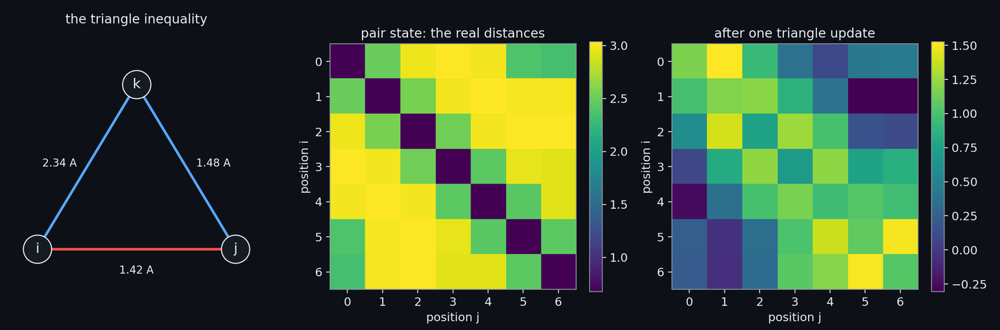

**Figure: The triangle update of the pair representation.** The triangle update of the Pairformer, the step of a co-folding model that makes its picture of the distances between positions consistent. Left: three atoms of fluconazole and their real distances, d(i,j) = 1.42 A, d(i,k) = 2.34 A and d(k,j) = 1.48 A; the triangle inequality d(i,j) <= d(i,k) + d(k,j) holds (1.42 <= 3.82), so what is known about the pairs (i,k) and (k,j) limits the pair (i,j). Middle: the pair state of the first 7 atoms, the real distance of each pair spread over 8 channels (shown as the sum of the channels). Right: the same state after one outgoing triangle update, in which the entry (i,j) is rebuilt from the products of the entries (i,k) and (j,k) over every third position k, with gates and a normalisation; the weights are random with a fixed seed, because the figure shows the computation and not a trained model. Relabelling the positions changes the result by 4e-16, which is rounding: the update has no preferred order of positions.

In [293]:
show_figure("struct_pairformer_triangle")

## 11.3 Building the input of a prediction

> **Field:** Software engineering · Structural biology

*Where this section sits:* 11.2 described the model. This section describes what it is given, and how the project builds that input for any ligand with its own code (`cypmode/validation/build_input.py`), so that every choice that matters, such as the covalent bond between the cysteine and the heme or a restraint on the ligand, is stated once and can be tested.

**The input file.** Boltz-2 reads a YAML file with a list of molecules (the **sequences** section: a protein chain with its sequence, a ligand given by a SMILES string or by the code of a chemical component, here the heme with the code `HEM`), a list of **constraints**, optional **templates** and optional **properties** (the affinity head, which runs its own diffusion five times and costs from 55 minutes to over ten hours on this machine, so that it is switched off for the structure track). A **constraint** can be a covalent **bond** between two named atoms, a **contact** (two atoms or residues within a maximum distance, which may be enforced by a potential that pushes the structure toward the condition, or not) or a **pocket** (a set of residues that the ligand should touch). A **template** is the structure of the protein, or part of it, from an experiment, given as a soft guide for the backbone. The program also takes settings of the sampler: the number of sampling steps (200 by default), the number of recycling steps of the trunk (3), the number of samples from one trunk pass, and the step scale of 11.2.

**What the project always says.** The heme is not part of the protein and the model does not know that it is bound to the cysteine, so the input says so with a bond constraint between the sulfur of the cysteine and the iron of the heme, with the cysteine's position found by the signature of 11.1. Everything else about the ligand's position is left to the model. The cell builds the input for the ligand of 11.1 in its three forms, with the project's function `build_boltz_yaml`. The first is the base run. The second adds a bond from the ligand's donor nitrogen to the iron, and the third a contact between them at the tightest distance the program accepts, 4 Å, without enforcement. The donor is chosen by `heme_donor_atom`: among the unsubstituted aromatic nitrogens that belong to a Type II motif (imidazole, triazole, pyridine, thiazole, 5.1) the one with the fewest heavy atoms within two bonds, so that a nitrogen flanked by substituents loses to a bare one. The program names the atoms of a ligand by its own ranking, and a constraint has to quote that name, so `boltz_atom_name` reproduces the naming.

In [294]:
# The input of a prediction, built by the project's own function (cypmode/validation/build_input.py) for the ligand of the previous cell: the protein, the ligand, the heme as the chemical component HEM, and the covalent bond between
# the sulfur of the cysteine and the iron of the heme. The three versions differ in what is said about the ligand: nothing (the base run), a bond from its donor nitrogen to the iron, or a contact between them. The long protein
# sequence is shortened for display.
from cypmode.validation.build_input import boltz_atom_name, build_boltz_yaml, heme_donor_atom

ligand_smiles = input_yaml["sequences"][1]["ligand"]["smiles"]
donor = heme_donor_atom(ligand_smiles)
yaml_versions = {mode: build_boltz_yaml(cyp3a4_sequence, ligand_smiles, cysteine_position, predict_affinity=False, donor_restraint=mode) for mode in (None, "bond", "contact")}
def shortened(text):
    return re.sub(r"(sequence: \w{20})\w+", r"\1...", text)
print(shortened(yaml_versions["bond"]))
base_lines = yaml_versions[None].count("\n")
bond_extra = [line for line in yaml_versions["bond"].splitlines() if line not in yaml_versions[None].splitlines()]
contact_extra = [line for line in yaml_versions["contact"].splitlines() if line not in yaml_versions[None].splitlines()]
donor_index, donor_name = donor

version: 1
sequences:
  - protein:
      id: A
      sequence: MALIPDLAMETWLLLAVSLV...
  - ligand:
      id: B
      smiles: 'COC1=CC2=C(C#N)C(N3CCN(C4=CC=CC=C4OC)CC3)=NC(N)=C2C(N)=N1'
  - ligand:
      id: C
      ccd: HEM
constraints:
  - bond:
      atom1: [A, 442, SG]
      atom2: [C, 1, FE]
  - bond:
      atom1: [B, 1, N27]
      atom2: [C, 1, FE]



The input differs between the base run and the bond-restrained run by 1 lines, which are the bond from the ligand's nitrogen N27 (atom 23 of the SMILES) to the iron, and between the base run and the contact-restrained run by 5 lines. A ligand without a donor of that kind gets no extra lines and runs as the base run. Three details of this code carry the history of the project. The alignment of the protein is given as a file (`protein_msa`) and not searched for each ligand: an outage of the public search server failed four runs in a row during a long batch, and a stored alignment removes the dependence. The restraints need the affinity head off, because with it on the program renames the atoms of the ligand after standardising its SMILES and the names in the constraint no longer match. And the templates are protein files given with the identifier of the chain to use, so that a trimer from cryo-electron microscopy can supply one chain (11.7).

**Running a batch.** One prediction takes about 40 minutes for five samples on this machine, one sample at a time, and a run of the 20 ligands takes a day. `cypmode/validation/batch.py` runs a list of ligands with the properties that a long run needs: each ligand's result is written as it finishes, a failure of one ligand is recorded and does not stop the others, and a second call skips the ligands that succeeded. Its options carry the levers of the following sections: `--donor-restraint bond|contact`, `--max-parallel-samples` (the number of samples drawn at once; 1 after a swap-exhaustion crash of the machine), `--step-scale`, and per-row columns for a template, a seed and a number of samples. `cypmode/validation/pipeline.py` wraps one compound from SMILES to coordination result, and `cypmode/validation/build_summary.py` collects the summary.

*On what actually ran.* `cypmode/validation/build_input.py` (the functions named above), executed by the cell; `batch.py`, `pipeline.py` and `build_summary.py` as described. No prediction is run by the notebook. The settings quoted are those of the Boltz documentation (version in `environment/`).

## 11.4 How a pose is scored: RMSD, LDDT-PLI, BiSyRMSD and the PoseBusters checks

> **Field:** Structural biology · Mathematics (linear algebra)

*Where this section sits:* the levers of 11.5 to 11.9 are judged by how close their poses come to crystal poses, and the 20 submitted poses are judged by the organisers with their own scorer. This section defines the four quantities in use, builds a small example of each, and measures how well the project's re-implementation of the main one agrees with the organisers' program.

**The distance of a pose from the truth.** The simplest measure is the **root-mean-square deviation**, RMSD: for $n$ ligand atoms with predicted positions $x_i$ and true positions $y_i$,

$$\mathrm{RMSD} \;=\; \sqrt{\frac{1}{n}\sum_{i=1}^{n}\lVert x_i - y_i\rVert^2},$$

in ångströms. It is meaningful only if the two sets of coordinates are in the same frame, and a predicted complex can sit anywhere in space, so the frames are brought together first. Two choices exist and they answer different questions. If the *ligand* of the model is superposed on the ligand of the reference, the RMSD says whether the ligand has the right shape and not whether it is in the right place. If the *pocket* is superposed and the ligand is left where it is, the RMSD says how far the ligand is from where it should be in the pocket, which is the question. The best superposition of two point sets in the least-squares sense is given by the **Kabsch algorithm**: subtract the centres, form the matrix $H = \sum_i (x_i - \bar x)(y_i - \bar y)^{\top}$, take its singular value decomposition $H = U\Sigma V^{\top}$, and the optimal rotation is $R = V\,\mathrm{diag}(1,1,d)\,U^{\top}$ with $d = \pm 1$ chosen so that $R$ is a rotation and not a reflection. The second source of error is **symmetry**: a molecule can be drawn in several ways that are the same molecule (a ring that turns over, a carboxylate whose two oxygens are equivalent), and an RMSD that pairs atoms by number reports an error that is not there. The correct RMSD is the smallest one over the symmetry-equivalent ways of pairing the atoms.

**LDDT-PLI.** The score the challenge is built on is the **local distance difference test** (Mariani, Biasini, Barbato and Schwede, 2013), adapted to a ligand and the protein around it. It needs no superposition. Take every pair of a ligand atom $a$ and a protein atom $b$ whose distance in the *reference* complex is below the inclusion radius $R_0 = 6$ Å, and compare the distance in the model with that in the reference:

$$\text{LDDT-PLI} \;=\; \frac14\sum_{t\in\{0.5,\,1,\,2,\,4\}}\frac{1}{|P|}\sum_{(a,b)\in P}\mathbf 1\big[\,|d^{\text{model}}_{ab} - d^{\text{ref}}_{ab}| < t\,\big],$$

where $P$ is the set of such pairs and $\mathbf 1[\cdot]$ is 1 when the condition holds and 0 otherwise (distances in ångströms). It is the share of the contacts that the model keeps, averaged over four tolerances $t$ (0.5, 1, 2 and 4 Å); 1 is perfect, and a ligand in a different place keeps few of its contacts. It does not care in which frame the complex is written, and it is symmetric in the sense of the atoms (the organisers' program maps equivalent atoms). Because it asks about contacts, it is the right target for the use of the structure (a ligand that has the right contacts is in the right pocket), and it is harder than it looks: a displacement of the ligand by 1 Å already costs a seventh of the score.

**BiSyRMSD.** The secondary score, the **binding-site superposed, symmetry-corrected RMSD**, is the RMSD of the first paragraph made precise: the binding site is every protein residue with a heavy atom within 4 Å of the reference ligand, the model is superposed on the reference by a Kabsch fit over the C-alpha atoms of those residues, and the RMSD of the ligand atoms is then computed in place, minimised over the symmetry-equivalent pairings of its atoms.

**Validity.** A pose can have the right contacts and be chemically impossible. **PoseBusters** (Buttenschoen, Morris and Deane, 2024) is a set of checks on the chemistry and physics of a pose, 22 in the configuration the organisers use for docking: that the file loads and the molecule can be built from it, that the bond lengths and angles lie in the range seen in real molecules, that no two atoms of the ligand are closer than their radii allow, that aromatic rings and double bonds are flat, that the internal energy is not far above that of a relaxed conformer, and that the ligand does not collide with the protein, the heme or the waters (its atoms are not closer than a fraction of the sum of the radii, and the volumes do not overlap beyond a limit). The organisers score a pose that fails *any* of them as if it had no correct contacts at all: LDDT-PLI 0 and the worst BiSyRMSD. A valid pose is therefore a condition of every score. The first cell works the geometry out on examples.

In [295]:
# The three ideas behind the scores, on small examples that can be checked by hand. (1) The Kabsch algorithm finds the rotation that best superposes two sets of points (the singular value decomposition of the matrix of their
# products of coordinates); with it, a ligand's distance from its true pose is measured after the protein pocket is superposed, not after the ligand is. (2) A symmetric molecule can be drawn in two ways that are the same: when a
# phenyl ring turns over, its equivalent atoms swap places, and a distance that matches atoms by their number reports an error that is not there. (3) LDDT-PLI looks at the distances between the ligand and the protein atoms around it
# in the true complex and asks how many of them the model keeps within 0.5, 1, 2 and 4 angstrom; it needs no superposition. The last function is the project's own (cypmode/validation/pose_selection.py).
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign

from cypmode.validation.pose_selection import lddt_pli_arrays

def kabsch(moving, fixed):
    """The rotation and translation that best map the points `moving` onto `fixed` (least squares), as a function."""
    mc, fc = moving.mean(0), fixed.mean(0)
    u, _, vt = np.linalg.svd((moving - mc).T @ (fixed - fc))
    d = np.sign(np.linalg.det(u @ vt))
    rotation = u @ np.diag([1, 1, d]) @ vt
    return lambda x: (x - mc) @ rotation + fc

rng_score = np.random.default_rng(5)
pocket = rng_score.uniform(-12, 12, size=(160, 3))
pocket = pocket[np.linalg.norm(pocket, axis=1) < 12]
ligand = np.array([[0, 0, 0], [1.4, 0, 0], [2.1, 1.2, 0], [3.5, 1.2, 0.2], [4.2, 0, 0.5], [3.5, -1.2, 0.2], [2.1, -1.2, 0], [5.6, 0, 0.7]]) - 2.4

def rmsd(a, b):
    return float(np.sqrt(((a - b) ** 2).sum(1).mean()))

# (1) a ligand with the right shape but 6 angstrom from its true place relative to the pocket
shifted = ligand + np.array([6.0, 0.0, 0.0])
ligand_only = rmsd(kabsch(shifted, ligand)(shifted), ligand)      # superpose the ligand on the true ligand: the error disappears
pocket_based = rmsd(shifted, ligand)                               # the pocket is already superposed: the error stays
# (2) the same ring drawn the other way: the two ortho carbons (atoms 2 and 7) and the two meta carbons (atoms 3 and 6) of 4-fluorotoluene exchange places
molecule = Chem.AddHs(Chem.MolFromSmiles("Cc1ccc(F)cc1"))
AllChem.EmbedMolecule(molecule, randomSeed=11)
heavy = Chem.RemoveHs(molecule)
positions = heavy.GetConformer().GetPositions()
flipped_positions = positions.copy()
flipped_positions[[2, 7]] = positions[[7, 2]]
flipped_positions[[3, 6]] = positions[[6, 3]]
flipped = Chem.Mol(heavy)
for i, p in enumerate(flipped_positions):
    flipped.GetConformer().SetAtomPosition(i, p.tolist())
by_number = rmsd(positions, flipped_positions)
symmetric = float(rdMolAlign.CalcRMS(flipped, heavy))
# (3) LDDT-PLI against displacement of the ligand, and against a rigid move of the whole complex
def complex_dicts(lig, prot):
    return {f"L{i}": p for i, p in enumerate(lig)}, {(i, "CA"): p for i, p in enumerate(prot)}
reference = complex_dicts(ligand, pocket)
rows = []
for shift in (0.0, 0.25, 0.5, 1.0, 2.0, 4.0):
    direction = rng_score.standard_normal(3)
    moved_ligand = ligand + shift * direction / np.linalg.norm(direction)
    moved = complex_dicts(moved_ligand, pocket)
    rows.append({"ligand displaced by (angstrom)": shift, "RMSD (angstrom)": rmsd(moved_ligand, ligand), "LDDT-PLI": lddt_pli_arrays(*moved, *reference)})
rotation_matrix = np.linalg.qr(rng_score.standard_normal((3, 3)))[0]
turned = complex_dicts(ligand @ rotation_matrix, pocket @ rotation_matrix)
lddt_after_rotation = lddt_pli_arrays(*turned, *reference)
lddt_table = pd.DataFrame(rows)
show_table(lddt_table, floatfmt=".3f")
print(f"ligand-only superposition {ligand_only:.2f} A, pocket-based {pocket_based:.2f} A; ring flipped: by atom number {by_number:.2f} A, symmetry-aware {symmetric:.2f} A; LDDT-PLI after turning the whole complex {lddt_after_rotation:.3f}")

ligand-only superposition 0.00 A, pocket-based 6.00 A; ring flipped: by atom number 1.71 A, symmetry-aware 0.00 A; LDDT-PLI after turning the whole complex 1.000


| ligand displaced by (angstrom) | RMSD (angstrom) | LDDT-PLI |
| --- | --- | --- |
| 0.000 | 0.000 | 1.000 |
| 0.250 | 0.250 | 1.000 |
| 0.500 | 0.500 | 1.000 |
| 1.000 | 1.000 | 0.858 |
| 2.000 | 2.000 | 0.667 |
| 4.000 | 4.000 | 0.397 |

The cell shows each idea in a line. A ligand of the right shape sitting 6 Å from its true place relative to the pocket has an RMSD of 0.00 Å if the ligand alone is superposed (the shape is right) and 6.00 Å if the pocket is the frame, which is why the pocket is used. A ring turned over has an RMSD of 1.71 Å when atoms are paired by number and 0.00 Å when they are paired by symmetry. And LDDT-PLI falls as the ligand is moved from the pocket, from 1.00 at 0.5 Å (the contacts all stay within the first tolerance) to 0.86 at 1 Å, 0.67 at 2 Å and 0.40 at 4 Å, and does not change at all (1.00) when the whole complex is turned in space.

**The project's measure and the organisers'.** The organisers compute the scores with **OpenStructure**, a program for structural bioinformatics (Biasini and co-workers, 2013) that is available only through the package manager conda. Every gate of this part (the restraint, the selection rules, the terms for choosing among poses) is judged on a Python re-implementation of LDDT-PLI that applies the definition above with symmetry-aware atom pairing (`cypmode/validation/lddt_to_crystal.py`, `pose_pools.py`) because it must run on thousands of poses without a separate environment. Whether it agrees with the program that scores the submission is a question that the data can answer, and it was registered as a gate before it was asked: rank correlation at least 0.9, mean absolute difference at most 0.05, and agreement on the order of the poses of one ligand in at least 90 percent of the pairs, because every selection rule uses the order.

In [296]:
# How close the project's LDDT-PLI is to the one the organisers compute with OpenStructure (cypmode/validation/ost_official.py, queue job 207_ost_vs_ours). The project's measure is a re-implementation, and every gate of the structure
# track rests on it, so the agreement was registered as a gate before it was measured: Spearman rank correlation at least 0.9, mean absolute difference at most 0.05, and the order of the poses of one ligand the same in at least 90 percent
# of the pairs. The table of 80 poses (20 ligands, restrained and not, two samples each) is read from the file the job wrote, and the three numbers are recomputed.
from scipy import stats

from cypmode.validation.ost_official import MAX_MEAN_ABSOLUTE_DIFFERENCE, MIN_PAIR_AGREEMENT, MIN_RANK_CORRELATION, pairs_agreement

ost_table = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/ost_vs_ours.csv").dropna(subset=["ours", "ost"])
ost_rank = float(stats.spearmanr(ost_table["ours"], ost_table["ost"])[0])
ost_difference = float((ost_table["ours"] - ost_table["ost"]).abs().mean())
ost_signed = float((ost_table["ours"] - ost_table["ost"]).mean())
ost_pairs = float(pairs_agreement(ost_table))
agreement_table = pd.DataFrame([
    {"measure": "Spearman rank correlation over all poses", "value": ost_rank, "limit": f">= {MIN_RANK_CORRELATION}", "met": ost_rank >= MIN_RANK_CORRELATION},
    {"measure": "mean absolute difference", "value": ost_difference, "limit": f"<= {MAX_MEAN_ABSOLUTE_DIFFERENCE}", "met": ost_difference <= MAX_MEAN_ABSOLUTE_DIFFERENCE},
    {"measure": "pairs of poses of a ligand ordered the same way", "value": ost_pairs, "limit": f">= {MIN_PAIR_AGREEMENT}", "met": ost_pairs >= MIN_PAIR_AGREEMENT}])
show_table(agreement_table, floatfmt=".3f")
n_ost_poses, n_ost_ligands = len(ost_table), int(ost_table["ligand"].nunique())
n_ost_met = int(agreement_table["met"].sum())
bisy_median, bisy_max = float(ost_table["ost_bisyrmsd"].median()), float(ost_table["ost_bisyrmsd"].max())

| measure | value | limit | met |
| --- | --- | --- | --- |
| Spearman rank correlation over all poses | 0.987 | >= 0.9 | True |
| mean absolute difference | 0.066 | <= 0.05 | False |
| pairs of poses of a ligand ordered the same way | 0.773 | >= 0.9 | False |

Over 80 poses of 20 ligands the project's measure ranks the poses almost as OpenStructure does (rank correlation 0.987) and lies higher by 0.065 on average (mean absolute difference 0.066); it orders the poses of one ligand the same way in 77.3% of the pairs. 1 of the three conditions is met, and the gate is NOT MET. The registered consequence is that the gates which rest on the project's measure are repeated with OpenStructure's scores: the two confirmatory restraint gates by job `241_ost_regate`, and the gates of the pools by jobs `244_ost_pools_score` and `245_ost_pool_gates` (the results available when this page was built are in 11.6 and 11.8). The median BiSyRMSD of these 80 poses is 3.4 Å and the largest 8.6 Å: most poses of the prediction pipeline are a few ångströms from a crystal pose, which is the finding of 11.5 seen from the other metric.

The last cell reads the validity checks of the submission and of the pools from which it was chosen.

In [297]:
# The physical-validity checks, as the organisers' scorer calls them (cypmode/validation/official_posebusters.py): PoseBusters in its docking configuration, 22 yes/no checks, on the ligand read from the submitted file with bond
# orders taken from the SMILES. Two tables are read: the 20 poses of the final submission, and the 200 poses of the pools from which they were chosen (every run of every official ligand), with the "distance margin" of each, the
# smallest ratio between the distance of a ligand atom to a receptor atom and the sum of their van der Waals radii; the threshold of the check is 0.75 and the project calls a pose safe above 0.80.
validity = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/posebusters_validity_official20.csv")
check_columns = [c for c in validity.columns if c not in ("compound", "all_passed", "model_index")]
pool_poses = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/final/official_posebusters_pools.csv")
n_checks_pb = len(check_columns)
checks_by_group = {"file and chemistry": check_columns[:6], "geometry of the ligand": check_columns[6:13], "against the receptor": check_columns[13:]}
n_final_pass = int(validity["all_passed"].sum())
n_pool, n_pool_pass = len(pool_poses), int((pool_poses["failed"].fillna("").astype(str).str.len() == 0).sum())
pool_valid = pool_poses[pool_poses["failed"].fillna("").astype(str).str.len() == 0]
n_pool_safe = int((pool_valid["distance_margin"] >= 0.80).sum())
smallest_margin_pool = float(pool_valid["distance_margin"].min())
group_table = pd.DataFrame([{"group of checks": g, "checks": len(cols), "examples": ", ".join(c.replace("_", " ") for c in cols[:3])} for g, cols in checks_by_group.items()])
show_table(group_table)

| group of checks | checks | examples |
| --- | --- | --- |
| file and chemistry | 6 | mol pred loaded, mol cond loaded, sanitization |
| geometry of the ligand | 7 | bond lengths, bond angles, internal steric clash |
| against the receptor | 9 | protein-ligand maximum distance, minimum distance to protein, minimum distance to organic cofactors |

There are 22 checks, in three groups (6 on whether the file and the molecule can be read, 7 on the ligand's own geometry, 9 against the receptor). 20 of the 20 submitted poses pass all 22. Among the 200 poses of the pools only 176 pass, and only 136 of those pass with a distance margin of at least 0.80, the project's own safety floor (the check fails at 0.75; the smallest margin among the passing poses is 0.752). A pose that passes by 0.003 today can fail when a library changes an atomic radius by a hundredth, so the choice of the final poses takes the margin into account (11.10).

*On what actually ran.* The cells above are the notebook's own, with the project's `pose_selection.lddt_pli_arrays` in the third part of the first. The agreement table is read from `ost_vs_ours.csv`, written by `cypmode/validation/ost_official.py` with `ost_worker.py` in the conda environment `ost` (OpenStructure 2.12.0), as the organisers' scorer calls it (`LDDTPLIScorer` and `SCRMSDScorer` with substructure matching). `cypmode/validation/bisy_rmsd.py` is the local BiSyRMSD of the definition above, used before OpenStructure was installed; `cypmode/validation/pose_comparison.py` is the symmetry-corrected ligand RMSD between two predictions of the same compound; `cypmode/validation/pose_validity.py` runs PoseBusters on a Boltz-2 output and `cypmode/validation/official_posebusters.py` runs it exactly as the organisers' scorer does, with the numeric margin of each check; `cypmode/validation/pose_margins.py` writes the margin of every pose of the pools. The queue job that measured the agreement is `207_ost_vs_ours`.

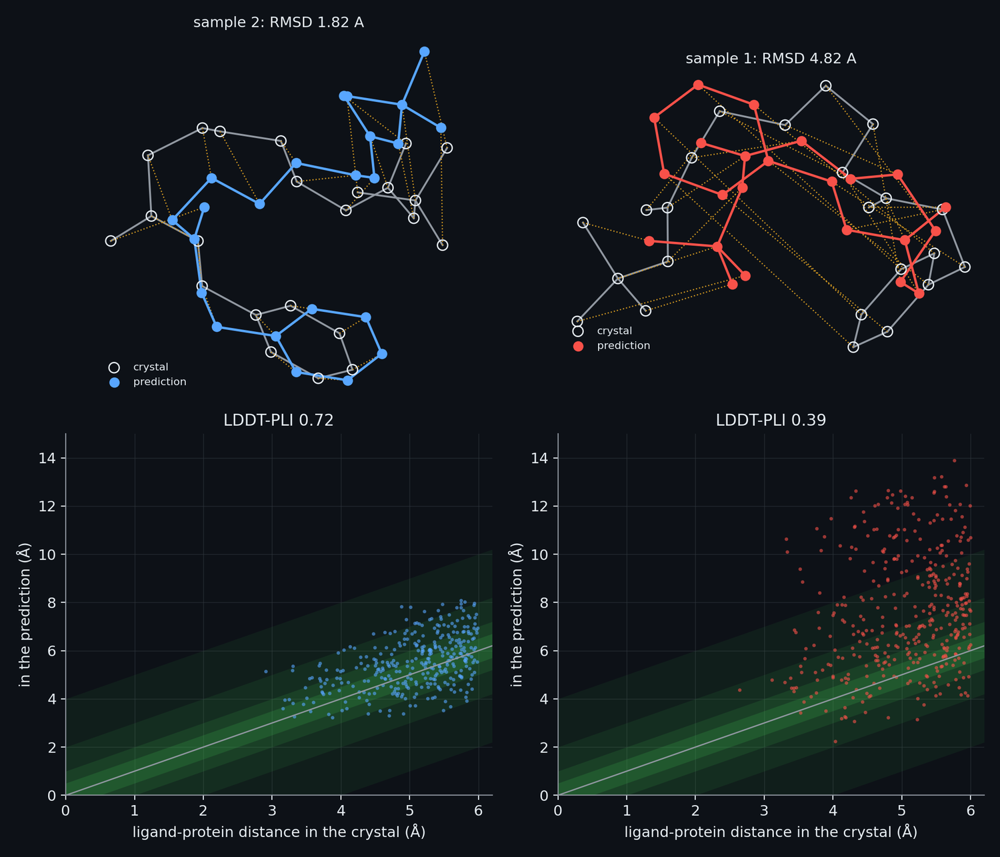

**Figure: RMSD and LDDT-PLI drawn on a real pose.** RMSD and LDDT-PLI on a real prediction. The ligand is PK9, the benchmark ligand whose best Boltz-2 sample is a correct placement and whose worst sample is furthest from the crystal pose (crystal entries 4D75 and 4D6Z). Top: the heavy atoms of the crystal ligand (open circles) and of the predicted ligand (filled), both seen along the two principal axes of the crystal ligand after the pocket of the prediction has been superposed on the crystal pocket (the C-alpha atoms within 10 A of the ligand, the superposition of BiSyRMSD); each dotted line joins an atom to its crystal counterpart, and the RMSD is the root of the mean squared length of these lines, taken over the symmetry-equivalent mappings of the ligand: 1.82 A for sample 2 and 4.82 A for sample 1. Bottom: LDDT-PLI needs no superposition. Every protein atom within 6 A of the crystal ligand is paired with every ligand atom; a point is one pair, with its distance in the crystal on the horizontal axis and in the prediction on the vertical axis; the bands are the four tolerances 0.5, 1, 2 and 4 A, and the score is the mean over the tolerances of the share of pairs inside the band: 0.72 for the best sample and 0.39 for the worst. A pose that fails the PoseBusters checks scores zero whatever its geometry.

In [298]:
show_figure("struct_rmsd_lddt")

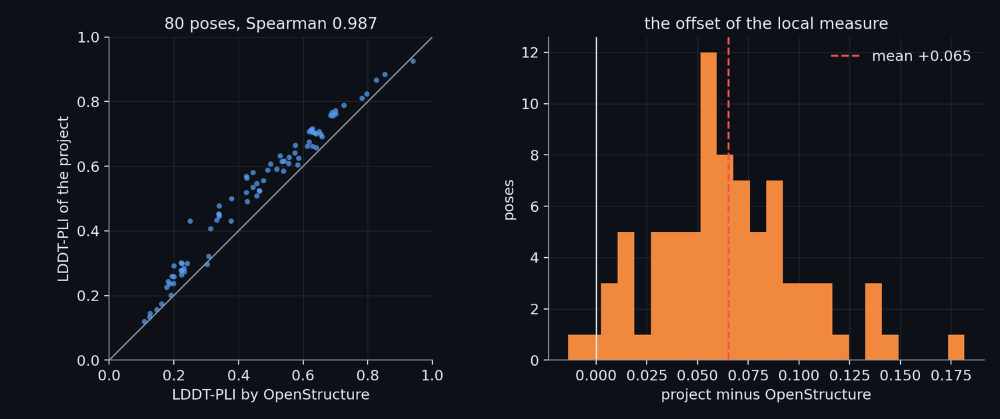

**Figure: The LDDT-PLI of the project against OpenStructure.** The LDDT-PLI of the project against the LDDT-PLI of OpenStructure, the scorer of the organisers, for 80 predicted poses of crystal-anchored ligands (one point per pose; the line is equality). The two rank the poses almost the same way overall (Spearman 0.987; registered bar 0.9) but the local value differs from the official one by 0.066 on average (bar 0.05), and of the pairs of poses of one ligand 77.3% are ordered the same way by both (bar 90%); the agreement gate is therefore not met, and the structure gates were repeated with the official yardstick (section 11.8). The local measure follows the definition of the official one but differs from it in details of the protein atoms and ligand atoms that enter the score, which is the likely source of the offset.

In [299]:
show_figure("struct_ost_vs_project")

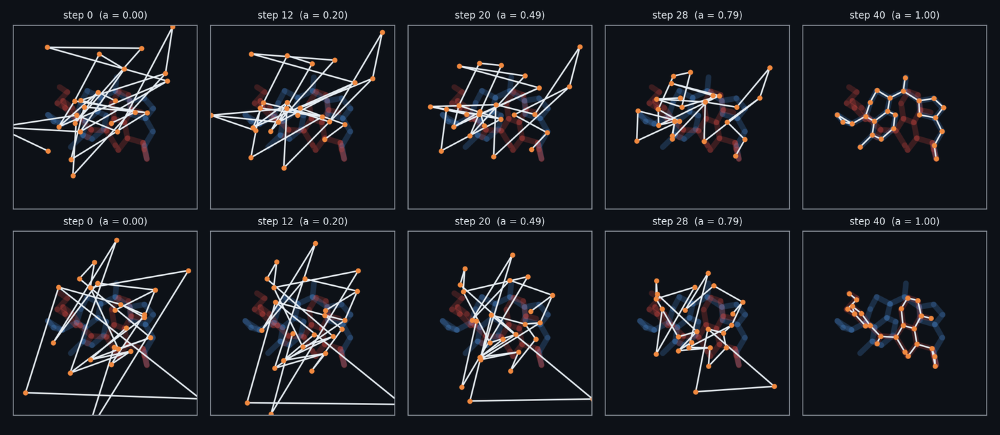

**Figure: Diffusion on a real ligand: from noise to a pose.** Diffusion on a real ligand: the 24 heavy atoms of OCNT-2395712, a donor ligand of the official set, projected on the plane of their two principal axes. The denoiser knows two ways it can sit: Boltz-2's first sample with the iron-nitrogen restraint (pose A, blue) and without it (pose B, red), which differ by 5.7 A per atom on average after superposing the proteins. Forward, noise is mixed in: x_t = sqrt(a_t) x_0 + sqrt(1 - a_t) e, with a_t falling from 1 to 0 on a cosine schedule. Reverse, from pure noise, each of 40 steps estimates the clean pose as the posterior mean over the two poses given the noisy atoms and removes part of the noise. Different noise draws commit to different poses (top row: a start that ends in pose A; bottom row: one that ends in pose B), which is where the diversity of a pool of samples comes from. A real network replaces the hand-made denoiser with one learned from thousands of structures.

In [300]:
show_figure("struct_diffusion_denoising")

## 11.5 The reference ligands and the crystal-anchored benchmark

> **Field:** Structural biology · Statistics

*Where this section sits:* 11.4 defined how a pose is scored against a crystal pose; this section says where the crystal poses come from, how far the 20 official ligands are from them, and what the unguided model does on a benchmark made from them. Every verdict of 11.6 to 11.9 is a comparison on this benchmark, so what it can and cannot show is stated here.

**The reference set.** The Protein Data Bank holds structures of CYP3A4 with ligands in the pocket. `cypmode/validation/reference_ligands.py` collects them from the archive (UniProt P08684) and keeps a ligand only if it is an inhibitor-sized molecule in the active site, that is, if its nearest heavy atom lies within a set distance of a heme iron; the peripheral site where CYP3A4 also binds some molecules is left out, as are buffers, ions and detergents. For each ligand it stores the coordinates, the iron and the C-alpha atoms of the pocket, so that the ligand can be placed in the frame of any predicted complex. The cell reads the set and asks how the ligands sit relative to the iron.

In [301]:
# The reference set (cypmode/validation/reference_ligands.py): every CYP3A4 entry of the Protein Data Bank (UniProt P08684) that holds a drug-like ligand in the active site, one record for each placement of a ligand, with the
# coordinates of the ligand, of the heme iron and of the C-alpha atoms of the pocket. The cell counts it, and asks three questions of it. (1) How do the ligands sit relative to the iron: the nearest ligand atom to the iron and its
# element. (2) Does the presence of a Type II motif (5.1) predict that the nitrogen binds the iron? (3) How far are the 20 ligands of the challenge from this set, and from the rest of the challenge data (the training and the blinded files)?
import json
from collections import defaultdict

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator

from cypmode.validation.build_input import heme_donor_atom

RDLogger.DisableLog("rdApp.*")
reference = json.loads((ROOT / "data/structure_track/inputs/cyp3a4_reference_ligands.json").read_text())
placements = reference["ligands"]
nearest = []
for record in placements:
    coords, fe = np.asarray(record["coords"], dtype=float), np.asarray(record["fe"], dtype=float).reshape(-1, 3)[0]
    distances = np.linalg.norm(coords - fe, axis=1)
    nearest.append({"comp_id": record["comp_id"], "smiles": record["smiles"], "pdb_id": record["pdb_id"], "distance": float(distances.min()), "element": record["elements"][int(distances.argmin())]})
nearest = pd.DataFrame(nearest)
distinct = nearest.sort_values("distance").groupby("comp_id", as_index=False).first()
distinct["coordinates through nitrogen"] = (distinct["distance"] <= 2.6) & (distinct["element"] == "N")
distinct["has a Type II donor"] = distinct["smiles"].map(lambda s: heme_donor_atom(s) is not None)
n_entries, n_placements, n_distinct = reference["n_entries"], len(placements), len(distinct)
share_coordinating = float(distinct["coordinates through nitrogen"].mean())
with_donor, without_donor = distinct[distinct["has a Type II donor"]], distinct[~distinct["has a Type II donor"]]
coordination_table = pd.DataFrame([
    {"ligands": "all distinct ligands", "number": n_distinct, "coordinate the iron through a nitrogen": float(distinct["coordinates through nitrogen"].mean())},
    {"ligands": "with a Type II donor in the structure", "number": len(with_donor), "coordinate the iron through a nitrogen": float(with_donor["coordinates through nitrogen"].mean())},
    {"ligands": "without one", "number": len(without_donor), "coordinate the iron through a nitrogen": float(without_donor["coordinates through nitrogen"].mean())}])
show_table(coordination_table, floatfmt=".2f")
median_resolution = float(np.median([r["resolution"] for r in placements if r.get("resolution")]))

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fingerprint = lambda smiles: generator.GetFingerprint(Chem.MolFromSmiles(smiles))
final_recipe = json.loads((ROOT / "data/structure_track/outputs/cyp3a4/final/recipe.json").read_text())
official = [row["ligand"] for row in final_recipe["ligands"]]
official_smiles = {name: yaml.safe_load((ROOT / f"data/structure_track/inputs/cyp3a4_{name}.yaml").read_text())["sequences"][1]["ligand"]["smiles"] for name in official}
reference_fingerprints = [fingerprint(r["smiles"]) for r in placements]
best_to_reference = np.array([max(DataStructs.BulkTanimotoSimilarity(fingerprint(s), reference_fingerprints)) for s in official_smiles.values()])
challenge_smiles = list(pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TRAIN_TDI.csv")["SMILES"]) + list(pd.read_csv(ROOT / "data/tdi_track/inputs/cyp-challenge-TEST-BLINDED.csv")["SMILES"])
challenge_fingerprints = [fingerprint(s) for s in challenge_smiles]
best_in_challenge = []
for smiles in official_smiles.values():
    similarity = np.sort(np.array(DataStructs.BulkTanimotoSimilarity(fingerprint(smiles), challenge_fingerprints)))[::-1]
    best_in_challenge.append(similarity[1] if similarity[0] >= 0.999 else similarity[0])   # the compound itself is in the challenge files
best_in_challenge = np.array(best_in_challenge)
n_with_analog = int((best_in_challenge >= 0.5).sum())
n_official_donor = int(sum(row["type_ii_donor"] for row in final_recipe["ligands"]))
print(f"{n_entries} entries, {n_placements} placements, {n_distinct} distinct ligands; best similarity of an official ligand to the reference set: {best_to_reference.min():.2f} to {best_to_reference.max():.2f}; official ligands with an analog (>= 0.5) in the challenge data: {n_with_analog} of {len(official)}")

129 entries, 148 placements, 101 distinct ligands; best similarity of an official ligand to the reference set: 0.12 to 0.34; official ligands with an analog (>= 0.5) in the challenge data: 16 of 20


| ligands | number | coordinate the iron through a nitrogen |
| --- | --- | --- |
| all distinct ligands | 101 | 0.86 |
| with a Type II donor in the structure | 93 | 0.94 |
| without one | 8 | 0.00 |

The set holds 148 placements of 101 distinct ligands in 129 entries, at a median resolution of 2.65 Å. 86% of the distinct ligands bind the iron through a nitrogen (the nearest ligand atom is a nitrogen within 2.6 Å of the iron). The presence of a Type II donor in the formula predicts it: 94% of the 93 ligands that have a donor coordinate, and none of the 8 that have not. This is the empirical basis of the restraint of 11.6: a nitrogen that can bind the iron usually does.

**How far the 20 are.** The 20 official ligands are not in the set and are not near it: the best Tanimoto similarity (Morgan fingerprints of radius 2, 2,048 bits, 3.2) of an official ligand to any ligand of the set lies between 0.12 and 0.34, so that no deposited structure is a good guide to any of them. They are not alone in the world, though: 16 of the 20 have an analogue (similarity of at least 0.5) among the compounds of the challenge's own files, which have measurements and no structures. 12 of the 20 have a Type II donor. For half of the official ligands, then, the iron-binding nitrogen is predictable from the formula, and for the other half it is not.

**The benchmark.** Since the 20 have no answer key, a benchmark is built from the set: ten ligands chosen by a rule fixed in advance (`cypmode/validation/structure_benchmark.py`): 20 to 60 heavy atoms, resolution of at most 3.0 Å, organic, one fragment, and the most mutually dissimilar by a maximin pick on the fingerprints, starting from the panel compounds already predicted (named below the table of the ten) so that each pick is far from them and from each other. The rule is deterministic and the list is not hand-written. One caveat is kept visible: the models may have seen these entries in training, so that the absolute accuracy on the benchmark is optimistic. The benchmark is for *comparing* settings and selection rules, not for forecasting a score. Unguided Boltz-2 drew five samples for each ligand, one at a time (about 40 minutes per ligand); all ten ligands were scored. The table gives the result.

In [302]:
# The ten ligands of the benchmark with the PDB entry of the copy that is used (the same table as in the method report): the entry gives the crystal pose that every RMSD of the structure track is measured against.
from cypmode.audit.method_report import benchmark_ligands
from cypmode.validation.structure_benchmark import MAX_HEAVY, MAX_RESOLUTION, MIN_HEAVY, PANEL_SEEDS

bench_list = benchmark_ligands().rename(columns={"comp_id": "ligand", "pdb_id": "PDB entry", "n_heavy": "heavy atoms", "resolution": "resolution (A)"})
show_table(bench_list, floatfmt=".2f")

| ligand | PDB entry | heavy atoms | resolution (A) |
| --- | --- | --- | --- |
| MWS | 6OOB | 27 | 2.20 |
| TCI | 9PLJ | 23 | 2.72 |
| 2QH | 4NY4 | 34 | 2.95 |
| A1CIW | 9PLK | 32 | 2.25 |
| YNV | 7LXL | 46 | 2.75 |
| PK9 | 4D6Z | 23 | 1.93 |
| TPF | 6MA7 | 22 | 2.09 |
| MWV | 6OO9 | 36 | 2.25 |
| A1ASV | 9BV5 | 22 | 2.71 |
| A1A4S | 9COV | 42 | 2.60 |

The ten ligands and the PDB entries of their crystal poses are listed above. A maximin pick chooses the compounds one at a time, each time the candidate whose nearest already-chosen compound is farthest away, so that the choice spreads over chemical space. The 9 panel compounds that start the pick are azamulin, clotrimazole, diltiazem, itraconazole, ketoconazole, ritonavir, troleandomycin, vardenafil, verapamil, and the pick is reproducible: `python -m cypmode.validation.structure_benchmark` returns the same ten, in the same order and with the same SMILES, as the list that the project uses (`tests/test_structure_benchmark.py` compares them); it needs only the reference set of the PDB and the Boltz-2 inputs of those panel compounds, which the repository holds. The benchmark was chosen for chemical diversity and not for likeness to the 20 official ligands, which is why the best similarity of an official ligand to the reference set is so low (above). Later sections reuse the same ten ligands, and the relaxation of 11.10 was tested on thirty: these ten and twenty more, the ligands of the restraint-expansion plan registered on 2026-10-12 (every crystal ligand with a Type II donor, organic, one fragment, 8 to 30 heavy atoms, resolution at most 3.5 Å and not in the benchmark; every eligible ligand was run and none was picked).

In [303]:
# The crystal-anchored benchmark and the first measurement on it. Ten ligands of the reference set were picked by a fixed rule (cypmode/validation/structure_benchmark.py): 20 to 60 heavy atoms, resolution at most 3.0 angstrom,
# organic, and the most mutually dissimilar (maximin on Morgan fingerprints, starting from the compounds already predicted, so that each new pick is far from the earlier ones). Unguided Boltz-2 (the base input of 11.3) drew five
# samples for each, one at a time. The table gives for each ligand the RMSD of the first sample to the crystal pose (pocket-superposed, symmetry-corrected, the best over the crystal copies), the best of the five, how far apart the
# five are, the model's own confidence in the first sample, and whether the first sample puts a nitrogen of a Type II motif on the iron.
from scipy import stats

benchmark_poses = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/benchmark_engine_pose_validation_unguided_boltz.csv")
benchmark_results = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/structure_benchmark_results.csv").set_index("compound")
per_ligand = benchmark_poses.groupby("compound")["true_rmsd"].agg(first="first", best="min", spread="std", mean="mean")
per_ligand["confidence"] = benchmark_results.loc[per_ligand.index, "confidence_score"]
per_ligand["nitrogen on the iron"] = benchmark_results.loc[per_ligand.index, "coordinated"]
per_ligand["has a donor"] = benchmark_results.loc[per_ligand.index, "smiles"].map(lambda s: heme_donor_atom(s) is not None)
bench_table = per_ligand.reset_index().rename(columns={"compound": "ligand", "first": "first sample (A)", "best": "best of five (A)", "spread": "spread of the five (A, sd)", "mean": "mean of the five (A)", "confidence": "model confidence"})
show_table(bench_table.round(2))
n_bench = len(per_ligand)
first_mean, best_mean = float(per_ligand["first"].mean()), float(per_ligand["best"].mean())
n_first_under_2, n_best_under_2 = int((per_ligand["first"] < 2).sum()), int((per_ligand["best"] < 2).sum())
confidence_range = (float(per_ligand["confidence"].min()), float(per_ligand["confidence"].max()))
failures = per_ligand[per_ligand["first"] > 4]
confidence_on_failures = (float(failures["confidence"].min()), float(failures["confidence"].max()), len(failures))
confidence_rank = float(stats.spearmanr(per_ligand["confidence"], per_ligand["first"])[0])
donor_ligands = per_ligand[per_ligand["has a donor"]]
n_donor, n_donor_coordinated = len(donor_ligands), int(donor_ligands["nitrogen on the iron"].sum())
donor_coordinated_wrong = int(((donor_ligands["nitrogen on the iron"]) & (donor_ligands["first"] > 2)).sum())

| ligand | first sample (A) | best of five (A) | spread of the five (A, sd) | mean of the five (A) | model confidence | nitrogen on the iron | has a donor |
| --- | --- | --- | --- | --- | --- | --- | --- |
| bench-2QH | 0.580 | 0.580 | 0.070 | 0.670 | 0.930 | True | True |
| bench-A1A4S | 6.240 | 4.530 | 0.670 | 5.620 | 0.950 | True | True |
| bench-A1ASV | 2.970 | 2.350 | 0.270 | 2.660 | 0.960 | True | True |
| bench-A1CIW | 6.300 | 5.270 | 0.450 | 5.910 | 0.940 | False | False |
| bench-MWS | 1.320 | 1.320 | 0.520 | 1.870 | 0.940 | False | False |
| bench-MWV | 4.810 | 4.810 | 0.170 | 4.970 | 0.930 | False | True |
| bench-PK9 | 4.760 | 1.820 | 1.560 | 3.100 | 0.940 | True | True |
| bench-TCI | 4.950 | 4.680 | 1.240 | 5.730 | 0.940 | False | False |
| bench-TPF | 3.620 | 3.620 | 0.150 | 3.780 | 0.950 | True | True |
| bench-YNV | 6.380 | 5.230 | 0.440 | 5.910 | 0.910 | False | False |

**What the model does without help.** The first sample is 4.19 Å from the crystal pose on average, and only 2 of the 10 are within 2 Å. The best of the five is 3.42 Å away and 3 of 10 are within 2 Å: drawing five samples gains 0.8 Å on average (18% of the error of the first sample) and moves the number of ligands within 2 Å from 2 to 3, a modest gain, because the five are close to each other (the spread of a ligand's five RMSD values is a few tenths of an ångström for most). The model's own confidence is no guide: it lies between 0.91 and 0.96 for every ligand, and between 0.91 and 0.95 for the 6 ligands whose first sample is more than 4 Å from the crystal; its rank correlation with the error is -0.27 over the 10 ligands. And the iron anchor is not the bottleneck: of the 6 benchmark ligands with a donor, 5 already have the donor nitrogen on the iron in the first sample, and 4 of those 5 are still more than 2 Å from the crystal pose, because the rest of the molecule is wrongly placed. These four observations frame the sections that follow. A lever that forces the nitrogen onto the iron (11.6) can help only the ligands where the model does not already do it; a lever that makes the samples differ (11.7) has to widen a pool that is narrow; and a rule for choosing among poses (11.8) can only choose among poses that differ, and cannot use the confidence.

*On what actually ran.* `cypmode/validation/reference_ligands.py` (`build_reference_set`, `load_reference_set`; the raw mmCIF files are cached in `data/structure_track/inputs/pdb_cache`, regenerable, and the compact `cyp3a4_reference_ligands.json` is what the repository tracks), `cypmode/validation/structure_benchmark.py` (`candidates`, `pick_diverse`), `cypmode/validation/structure_benchmark_report.py` (the report that compares engines and selection rules on the benchmark), and the Boltz-2 runs of queue job `100_boltz_unguided_resume`. The tables are `benchmark_engine_pose_validation_unguided_boltz.csv` (all ten ligands, five samples each) and `structure_benchmark_results.csv`; `benchmark_engine_pose_validation_unguided9.csv` holds the same rows without `bench-A1A4S` and is the table that the pilot of the diversity levers reads. Scripts: `scripts/run_structure_benchmark.sh` runs the benchmark end to end and `scripts/clear_batch_errors.py` clears the failed rows of a batch so that a resumed run retries them.

## 11.6 The iron-nitrogen restraint: what it adds to the input and what the evidence shows

> **Field:** Structural biology · Statistics

*Where this section sits:* 11.5 showed that the unguided model places the iron-binding nitrogen on the iron for most of the ligands that have one and still misplaces the rest of the molecule. This section tests the one lever that acts on the nitrogen directly. It is the only lever of the part that passed its first gate, and the only one that was then put to a second test on new ligands. The account is given in full because the second test did not confirm the first.

**The idea and where it comes from.** The nitrogen of a Type II ligand (1.9) binds the iron of the heme, and in the crystal structures it does so in the large majority of cases (11.5: 86% of the distinct ligands, 94% of those that have a donor). A co-folding model that does not place it there has missed the most informative contact of the pose. The idea of steering the co-folding model with a forced contact between the iron and the donor atom of the ligand was stated as a plan in the public repository `openadmet-cyp-structure` (github.com/xX-its-amit-Xx/openadmet-cyp-structure), whose text reports that 83 of the 101 deposited CYP3A4 ligands it counts coordinate the iron directly, almost always through a nitrogen; the repository calls the forced contact "the lever" in its README and puts it first among the steps of its plan of 2026-09-10. A later note of the same repository (in the commit 8161934, read on 2026-11-05) reports that forcing the contact on 87 ligands was "a null, slightly negative" and drops it, because the bond of the heme to the cysteine already gives the right geometry. The project's count, made with its own criterion (11.5), is 87 of 101. The project built its own version, tested it on the benchmark of 11.5 and then on ligands it had not used, and the numbers below are its own. The two measurements differ in size, in the set of ligands and in the quantity measured (the repository: 87 ligands and the LDDT-PLI of the pose; the project: the RMSD of the first sample on six benchmark ligands for the first gate, then ligands it had not used), so neither is set against the other without that caution; the project's first gate rests on six ligands, and the section says how few carry its gain.

**The two forms.** Both use the constraints of 11.3 and the donor atom that `heme_donor_atom` picks. A **bond restraint** declares a covalent bond between the donor nitrogen and the iron: the model is told that the two atoms are bonded, and the nitrogen ends up about 2 Å from the iron (1.95 Å in the file of 11.1). A **contact restraint** states only that the two atoms lie within 4 Å of each other, without enforcement. A ligand with no donor of that kind receives neither and is run as the base run; 12 of the 20 official ligands have a donor.

**The first gate.** Six benchmark ligands have a donor. The rule, written before the runs: keep the restraint if the mean RMSD of the first sample falls and the share of first samples that pass PoseBusters does not. The cell reads the three conditions.

In [304]:
# The restraint on the benchmark. The six benchmark ligands that have a Type II donor were run three ways with Boltz-2 (three samples each): without a restraint, with the donor nitrogen bonded to the iron, and with a contact
# between them (11.3). The decision rule was written beforehand (cypmode/validation/structure_gates.py): the restraint is kept if the mean RMSD of the first sample to the crystal pose is lower than without it AND the share of first samples
# that pass PoseBusters is not lower. The first-sample RMSD of each ligand is read from the pose tables of the three conditions, and the validity shares from the log of the gate (job 165_structure_gate_verdicts).
import re

from cypmode.validation.restraint_expansion import paired_statistics
from cypmode.validation.structure_benchmark_report import variant_comparison

restraint_tables = {name: pd.read_csv(ROOT / f"data/structure_track/outputs/cyp3a4/benchmark_engine_pose_validation_{stem}.csv") for name, stem in (("unguided", "unguided_boltz"), ("febond", "febond"), ("fecontact", "fecontact"))}
comparison = variant_comparison({"unguided": restraint_tables["unguided"], "febond": restraint_tables["febond"], "fecontact": restraint_tables["fecontact"]}, samples=3)
first_pick = comparison.pivot(index="compound", columns="variant", values="first_pick")[["unguided", "febond", "fecontact"]].dropna()
first_pick.columns = ["without a restraint (A)", "bond to the iron (A)", "contact with the iron (A)"]
show_table(first_pick.reset_index().round(2))
gate_log = (ROOT / "data/structure_track/outputs/cyp3a4/logs/structure_gates.log").read_text()
validity_shares = {name: tuple(float(x) for x in re.search(rf"restraint_{name}: .*'valid_unguided': ([\d.]+), 'valid_variant': ([\d.]+)", gate_log).groups()) for name in ("bond", "contact")}
n_restraint_ligands = len(first_pick)
mean_without, mean_bond, mean_contact = (float(first_pick.iloc[:, i].mean()) for i in range(3))
bond_gain = paired_statistics((first_pick.iloc[:, 0] - first_pick.iloc[:, 1]).to_numpy(), 0.05)
contact_gain = paired_statistics((first_pick.iloc[:, 0] - first_pick.iloc[:, 2]).to_numpy(), 0.05)
n_under_2 = {name: int((first_pick[col] < 2).sum()) for name, col in (("without", first_pick.columns[0]), ("bond", first_pick.columns[1]), ("contact", first_pick.columns[2]))}
gate_met = {name: bool(re.search(rf"STRUCTURE GATE restraint_{name}: MET", gate_log)) for name in ("bond", "contact")}

| compound | without a restraint (A) | bond to the iron (A) | contact with the iron (A) |
| --- | --- | --- | --- |
| bench-2QH | 0.580 | 0.710 | 0.570 |
| bench-A1A4S | 6.240 | 2.420 | 5.860 |
| bench-A1ASV | 2.970 | 2.540 | 2.890 |
| bench-MWV | 4.810 | 4.890 | 4.910 |
| bench-PK9 | 4.760 | 1.940 | 4.720 |
| bench-TPF | 3.620 | 3.550 | 3.560 |

The mean first-sample RMSD over the 6 ligands is 3.83 Å without a restraint, 2.68 Å with the bond and 3.75 Å with the contact; 2 ligands are within 2 Å with the bond against 1 without. The share of first samples that pass PoseBusters rises from 0.67 to 0.83 (for both restraints). Both gates are MET (bond) and MET (contact) by the rule, and the recipe takes the one with the lower mean RMSD, the bond restraint. The gain is carried by two ligands: `bench-A1A4S` falls from 6.2 to 2.4 Å and `bench-PK9` from 4.8 to 1.9; the other four change by a few tenths of an ångström. The paired statistics, given for information because six ligands cannot carry a significance test, are a mean improvement of +1.15 Å, 4 wins in 6 and a Wilcoxon p-value of 0.156 for the bond, and +0.08 Å with 5 wins for the contact.

The **Wilcoxon signed-rank test** is the test used throughout the part. For paired measurements (the same ligand under two conditions) it ranks the absolute values of the differences, adds up the ranks of the positive ones, and asks how likely a sum that large would be if the differences were as often positive as negative. It does not assume that the differences follow a normal distribution, which suits a handful of ligands with a few wild values, but with $n$ ligands the smallest p-value it can give is $1/2^n$ for the one-sided test: with six it cannot go below 0.016.

In [305]:
# The registered plan of the confirmation (data/structure_track/inputs/restraint_expansion_plan.json), read before anything else: its date, its alpha, and the number of ligands that met its eligibility rule.
from cypmode.validation import restraint_expansion as expansion

plan = expansion.load_plan()
alpha_plan = plan["endpoints"]["alpha"]
registered_date = plan["registered"]
lddt_primary = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/restraint_expansion_primary_lddt.csv", index_col=0)
lddt_secondary = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/restraint_expansion_secondary_lddt.csv", index_col=0)
n_primary, n_secondary = len(lddt_primary), len(lddt_secondary)

**The second test.** The six ligands had decided the restraint, and two of them carried the gain. The rule of the project for such a case is to test the decision on ligands that played no part in it, with a plan that fixes everything before any result exists. The plan was registered on 2026-10-12 (`data/structure_track/inputs/restraint_expansion_plan.json`): every crystal ligand of the reference set that has a donor, is organic and has a resolution of at most 3.5 Å, with at most 30 heavy atoms (the official ligands have 18 to 27), and is not in the benchmark, is run, none picked; two Boltz-2 samples in each of the two conditions; the score of a ligand is its mean LDDT-PLI to the crystal; the test is the one-sided Wilcoxon test that the restraint raises it at $\alpha = 0.05$, with the mean difference staying positive when any one ligand is dropped. If confirmed, the restraint is confirmed; if the one-sided test that it *lowers* the score is significant, the restraint is withdrawn from the recipe; otherwise it stays as decided by its earlier gate and is reported as not confirmed. Only 14 reference ligands met the rule, so all 14 were run; six slightly larger ones (31 to 34 heavy atoms) form a secondary stratum that is reported and never used for the decision. The run took about 12 hours for the primary stratum (jobs `176_restraint_expansion_prepare`, `177_boltz_restraint_expansion_primary`, `178_score_restraint_expansion`, `186_boltz_restraint_expansion_secondary`, `187_score_restraint_expansion_secondary`).

In [306]:
# The confirmation of the restraint on ligands that were not used to decide it. The plan was registered on 2026-10-12, before any run (data/structure_track/inputs/restraint_expansion_plan.json): every crystal ligand with a Type II donor,
# organic, at most 30 heavy atoms (the primary stratum; the official ligands have 18 to 27) and a resolution of at most 3.5 angstrom, and not in the benchmark, is run, none picked; two Boltz-2 samples per ligand in each of two conditions;
# the score of a ligand is the mean LDDT-PLI to the crystal; the test is the one-sided Wilcoxon signed-rank test that the restraint raises it, with the mean difference staying positive when any one ligand is dropped; alpha 0.05. A second
# stratum of slightly larger ligands (31 to 34 heavy atoms) is reported and never used for the decision. The cell reads the plan and the per-ligand tables, repeats the statistics with the plan's own function, and then repeats them with
# the scores of OpenStructure (11.4), which is what the registered consequence of the disagreement required.
from cypmode.validation.ost_regate import regate

primary_stats = expansion.paired_statistics(lddt_primary["difference"].to_numpy(), alpha_plan)
secondary_stats = expansion.paired_statistics(lddt_secondary["difference"].to_numpy(), alpha_plan)
expansion_ligands = pd.read_csv(ROOT / "data/structure_track/inputs/restraint_expansion_ligands.csv").assign(comp_id=lambda t: t["comp_id"].astype(str))
expansion_poses = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/restraint_expansion_poses.csv")
ost_scores = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/ost_vs_ours.csv")
ost_stats = regate(expansion_poses, ost_scores, expansion_ligands, plan["design"]["samples_per_condition"], alpha_plan)
confirmation_table = pd.DataFrame([
    {"measure": "primary stratum, LDDT-PLI of the project", **{k: primary_stats[k] for k in ("n", "mean", "wins", "p_better", "p_worse", "min_drop_one")}},
    {"measure": "primary stratum, OpenStructure's LDDT-PLI", **{k: ost_stats["openstructure"][k] for k in ("n", "mean", "wins", "p_better", "p_worse", "min_drop_one")}},
    {"measure": "secondary stratum, LDDT-PLI of the project", **{k: secondary_stats[k] for k in ("n", "mean", "wins", "p_better", "p_worse", "min_drop_one")}}])
show_table(confirmation_table, floatfmt=".3f")
joined = lddt_primary.join(expansion_ligands.assign(ligand=lambda t: "exp-" + t["comp_id"]).set_index("ligand")[["min_fe_distance", "deposited", "n_heavy"]])
coordinating = joined[joined["min_fe_distance"] <= expansion.COORDINATION_DISTANCE_A]
not_coordinating = joined[joined["min_fe_distance"] > expansion.COORDINATION_DISTANCE_A]
before_cutoff, after_cutoff = joined[joined["deposited"] < expansion.TRAINING_CUTOFF], joined[joined["deposited"] >= expansion.TRAINING_CUTOFF]
subgroups = pd.DataFrame([
    {"subgroup": "the crystal nitrogen coordinates the iron", "ligands": len(coordinating), "mean change of LDDT-PLI": float(coordinating["difference"].mean())},
    {"subgroup": "the crystal ligand does not coordinate the iron", "ligands": len(not_coordinating), "mean change of LDDT-PLI": float(not_coordinating["difference"].mean())},
    {"subgroup": f"deposited before {expansion.TRAINING_CUTOFF}", "ligands": len(before_cutoff), "mean change of LDDT-PLI": float(before_cutoff["difference"].mean())},
    {"subgroup": f"deposited on or after {expansion.TRAINING_CUTOFF}", "ligands": len(after_cutoff), "mean change of LDDT-PLI": float(after_cutoff["difference"].mean())}])
show_table(subgroups, floatfmt=".3f")
from scipy import stats as scipy_stats

difference_sd = float(lddt_primary["difference"].std(ddof=1))
detectable_change = float((scipy_stats.t.ppf(0.95, n_degrees := len(lddt_primary) - 1) + scipy_stats.t.ppf(0.80, n_degrees)) * difference_sd / np.sqrt(len(lddt_primary)))
best_gain_ligand = lddt_primary["difference"].idxmax()
worst_gain_ligand = lddt_primary["difference"].idxmin()
biggest_gain, biggest_loss = float(lddt_primary["difference"].max()), float(lddt_primary["difference"].min())

| measure | n | mean | wins | p_better | p_worse | min_drop_one |
| --- | --- | --- | --- | --- | --- | --- |
| primary stratum, LDDT-PLI of the project | 14 | 0.015 | 7 | 0.313 | 0.708 | -0.003 |
| primary stratum, OpenStructure's LDDT-PLI | 14 | 0.030 | 10 | 0.121 | 0.892 | 0.013 |
| secondary stratum, LDDT-PLI of the project | 6 | 0.030 | 3 | 0.500 | 0.578 | -0.027 |

| subgroup | ligands | mean change of LDDT-PLI |
| --- | --- | --- |
| the crystal nitrogen coordinates the iron | 12 | 0.011 |
| the crystal ligand does not coordinate the iron | 2 | 0.034 |
| deposited before 2023-06-01 | 8 | 0.020 |
| deposited on or after 2023-06-01 | 6 | 0.007 |

The restraint changes the mean LDDT-PLI of the 14 new ligands by +0.015, in 7 of them for the better, with a one-sided p-value of 0.313; and when the ligand with the largest gain is dropped the mean falls to -0.003, so that it does not stay positive. The restraint is therefore **not confirmed**. Neither is it shown to harm: the one-sided p-value that it lowers the score is 0.708. With OpenStructure's LDDT-PLI the picture is the same in kind (+0.030, 10 of 14 better, p = 0.121), so that both gates, the confirmation and the harm check, are NOT MET on either yardstick, and the recipe stays as it was. The subgroups show no pattern that would explain the gap: the effect is +0.011 where the crystal nitrogen coordinates the iron (12 ligands) and +0.034 where it does not (2), and +0.020 for entries deposited before the end of the model's structure training data against +0.007 after it. The changes of single ligands run from -0.19 to +0.24, with a standard deviation of 0.10; a test on 14 ligands with a spread that size recognises a true mean change of about 0.07 in 8 of 10 repetitions, which is more than the 0.015 seen. The reading is that the restraint helps by something between nothing and a small amount in LDDT-PLI, that the earlier benchmark, in which two ligands carried the gain, is consistent with having overstated it, and that this design cannot say more. The project keeps the restraint in the recipe because its first gate was met and the registered rule for exactly this outcome keeps it, and says so; the cost of keeping it is small: on the 14 new ligands it did not lower the score on average (7 ligands better, 7 worse).

*On what actually ran.* `cypmode/validation/build_input.py` (`heme_donor_atom`, `build_boltz_yaml` with `donor_restraint`), `cypmode/validation/structure_gates.py` (the first gate, queue job `165_structure_gate_verdicts`, with the runs of `110_boltz_restraint_bond`, `120_boltz_restraint_contact` and `140_score_restraint_and_pilot`), `cypmode/validation/restraint_expansion.py` (`eligible`, `paired_statistics`, `per_ligand`; the plan file), `cypmode/validation/mbr_lddt_reevaluation.py` (the exploratory re-scoring of the first benchmark with LDDT-PLI, queue job `173_mbr_lddt_reevaluation`: +0.133, 4 of 6 better, p = 0.109) and `cypmode/validation/ost_regate.py` (job `241_ost_regate`). The logs are `structure_gates.log`, `restraint_expansion.log` and `ost_regate.log`.

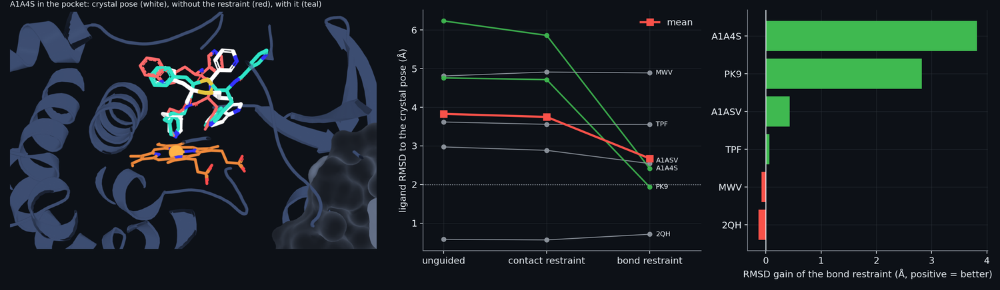

**Figure: The iron-nitrogen restraint, ligand by ligand.** First panel: one ligand (A1A4S, crystal entry 9COV) in the pocket, the predicted poses aligned on the crystal structure and rendered from their coordinates. Then: ligand RMSD to the crystal pose of the first sample, for the 6 crystal ligands that were folded without a restraint, with a soft contact between the iron and a donor nitrogen, and with a bond-length restraint. Means: unguided 3.83 A, contact 3.75 A, bond 2.68 A. The gain of the bond restraint over no restraint is concentrated in two ligands (A1A4S +3.82 A, PK9 +2.83 A); the other 4 change by less than 0.43 A. With six ligands the evidence is real but thin.

In [307]:
show_figure("struct_restraint_effect")

## 11.7 Levers that did not pass: seeds, crystal templates, cryo-EM templates and the step scale

> **Field:** Structural biology · Statistics

*Where this section sits:* 11.5 found that the five samples of one prediction agree with each other, so that choosing among them cannot rescue a wrong pose; if a selection rule (11.8) is to have anything to choose from, the pool has to differ. This section tests four ways to make it differ, on a pilot of three ligands and a rule fixed before the runs. None passed.

**The four levers.** (1) **Seeds.** The same input with different random seeds. A new seed gives a new pass of the trunk, as in AlphaFold 3, so the diversity should be more than that of five samples from one pass. (2) **Crystal templates.** A template (11.3) is the protein structure of an experiment, given to the model as a soft guide; CYP3A4 can be given a different crystal conformation of its pocket, chosen from the reference set by the spread of the pocket's C-alpha atoms (`cypmode/validation/conformers.py`), and never from an entry whose ligand is the compound or a close analogue of it (Tanimoto similarity of at least 0.5): a template must not carry the answer. (3) **Cryo-EM templates.** The five cryo-EM structures of human CYP3A4 released on 2026-09-30 (the entries 38FU, 38FV, 38FW, 38FX and 38FY: apo, ritonavir, ketoconazole, azamulin, vardenafil; 3.2 to 3.7 Å; trimers, of which chain A serves as a one-chain template) add pocket shapes that the X-ray set may lack (`cypmode/validation/cryoem_templates.py`). (4) **The step scale.** A value of 0.8 instead of 1.5 (11.2), where the toy suggested that the samples would spread.

The reason to doubt the second and third lever is a number that the reference set can give. The cell superposes the pocket C-alpha atoms of every pair of the crystal entries and measures how much the pocket moves.

In [308]:
# How different are the pockets of the crystal structures? If the C-alpha atoms of the pocket sit nearly in the same place in every structure, a different crystal template cannot change the prediction much. For each pair of the
# entries of the reference set the C-alpha atoms of the pocket residues that both entries have (69 residues in the first) are superposed with the Kabsch algorithm of 11.4 and the RMSD is taken.
pockets = {}
for record in placements:
    pockets.setdefault(record["pdb_id"], record["pocket_ca"])
entry_ids = list(pockets)
pair_rmsd = []
for i in range(len(entry_ids)):
    for j in range(i + 1, len(entry_ids)):
        a, b = pockets[entry_ids[i]], pockets[entry_ids[j]]
        common = sorted(set(a) & set(b), key=int)
        if len(common) < 20:
            continue
        x, y = np.array([a[c] for c in common]), np.array([b[c] for c in common])
        pair_rmsd.append(rmsd(kabsch(x, y)(x), y))
pair_rmsd = np.array(pair_rmsd)
pocket_median, pocket_p95, pocket_max = float(np.median(pair_rmsd)), float(np.percentile(pair_rmsd, 95)), float(pair_rmsd.max())
n_pockets, n_pocket_residues, n_pocket_pairs = len(entry_ids), len(next(iter(pockets.values()))), len(pair_rmsd)
print(f"{n_pockets} entries, {n_pocket_pairs} pairs: median pocket C-alpha RMSD {pocket_median:.2f} A, 95th percentile {pocket_p95:.2f}, largest {pocket_max:.2f}")

113 entries, 6328 pairs: median pocket C-alpha RMSD 0.47 A, 95th percentile 0.80, largest 1.13


Across 113 entries (6,328 pairs, 69 pocket residues) the pocket's C-alpha atoms are 0.47 Å apart at the median, 0.80 Å at the 95th percentile and 1.13 Å at most. The backbone of the pocket is almost the same in every structure, whatever ligand sits in it; a template can change the side chains and some loops but not the shape of the cavity by much. That does not prove that templates are useless, since small changes can move a ligand, but it sets the expectation.

**The pilot.** The rule, fixed in `cypmode/validation/diversity_pilot.py` before any run: a lever *creates diversity* for a ligand if the spread of its poses (the mean pairwise ligand RMSD within the pool, after superposing the pockets) is at least 1.5 times the spread of the unguided pool, and *reaches the right pose* if the best pose in its pool is at least 0.75 Å closer to the crystal pose than the best of the unguided pool; a lever passes if both hold for at least half of the ligands. Three ligands whose unguided first sample is wrong were used, `bench-A1CIW` (6.3 Å), `bench-PK9` (4.8) and `bench-TPF` (3.6), with three runs of each lever per ligand.

In [309]:
# The pilot of the diversity levers (cypmode/validation/diversity_pilot.py). Three benchmark ligands whose first sample is wrong (bench-A1CIW 6.3 A, bench-PK9 4.8, bench-TPF 3.6) were run with four levers: three different random
# seeds (a new pass of the trunk for each), three different crystal conformations of the pocket as the protein template, three cryo-electron-microscopy structures as the template, and a step scale of 0.8 (three samples).
# A lever "creates diversity" for a ligand when the spread of its poses (the mean pairwise ligand RMSD in the pool) is at least 1.5 times that of the unguided pool, and "reaches the right pose" when the best pose in its pool is at
# least 0.75 angstrom closer to the crystal than the best of the unguided pool; the lever passes if both hold for at least half of the ligands. Both thresholds were fixed before the runs. The pools are read from the log of the gate.
from cypmode.validation.diversity_pilot import DIVERSITY_FACTOR, GAIN_A, verdicts

import re

gate_text = (ROOT / "data/structure_track/outputs/cyp3a4/logs/structure_gates.log").read_text()
pool_rows = re.findall(r"^\s*(bench-\S+)\s+(seeds|conformers|cryoem)\s+(\d+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s*$", gate_text, re.M)
pools = pd.DataFrame(pool_rows, columns=["ligand", "lever", "poses", "spread", "unguided_spread", "best_rmsd", "unguided_best"]).astype({"poses": int, "spread": float, "unguided_spread": float, "best_rmsd": float, "unguided_best": float})
pools["wider than 1.5 x"] = pools["spread"] >= DIVERSITY_FACTOR * pools["unguided_spread"]
pools["best pose better by 0.75 A"] = pools["unguided_best"] - pools["best_rmsd"] >= GAIN_A
show_table(pools.round(2))
pilot_verdicts = verdicts(pools).set_index("lever")
step_scale_poses = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/diversity_pilot_poses.csv")
step_scale_poses = step_scale_poses[step_scale_poses["compound"].str.endswith("-ss")]
n_step_scale, n_step_scale_unusable = len(step_scale_poses), int(step_scale_poses["true_rmsd"].isna().sum())
pilot_gate_text = {lever: ("MET" if re.search(rf"STRUCTURE GATE pilot_{lever}: MET", gate_text) else "NOT MET") for lever in ("seeds", "conformers", "cryoem")}

| ligand | lever | poses | spread | unguided_spread | best_rmsd | unguided_best | wider than 1.5 x | best pose better by 0.75 A |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| bench-A1CIW | seeds | 3 | 2.990 | 4.150 | 5.650 | 5.270 | False | False |
| bench-A1CIW | conformers | 3 | 1.630 | 4.150 | 6.310 | 5.270 | False | False |
| bench-A1CIW | cryoem | 3 | 3.830 | 4.150 | 5.460 | 5.270 | False | False |
| bench-PK9 | seeds | 3 | 2.120 | 3.390 | 4.540 | 1.820 | False | False |
| bench-PK9 | conformers | 3 | 3.530 | 3.390 | 3.000 | 1.820 | False | False |
| bench-PK9 | cryoem | 3 | 4.000 | 3.390 | 2.010 | 1.820 | False | False |
| bench-TPF | seeds | 3 | 3.250 | 0.910 | 3.940 | 3.620 | True | False |
| bench-TPF | conformers | 3 | 3.620 | 0.910 | 2.290 | 3.620 | True | True |
| bench-TPF | cryoem | 3 | 3.290 | 0.910 | 3.710 | 3.620 | True | False |

The verdicts are **NOT MET** for all three levers that could be evaluated: seeds (the pool is wider for 33% of the ligands and the best pose better for 0%), crystal templates (33% and 33%) and cryo-EM templates (33% and 0%); a lever needed two of the three ligands. The table shows what happens. For `bench-A1CIW` and `bench-PK9` the lever pools are *not* wider than the unguided pool, which was already broad for them (spreads of 4.2 and 3.4 Å): the unguided samples there were different but wrong, and the levers gave different but wrong poses too. For `bench-TPF` the unguided pool was unusually tight (0.9 Å) and every lever widens it (3.3 to 3.6 Å), and one of them, the crystal templates, finds a pose closer to the crystal (2.3 Å against 3.6) by drawing from a wider pool. That is one ligand of three, and a pool wide enough to include a better pose will usually include one if it is wide enough; whether the better pose can be *chosen* is the question of 11.8.

The step-scale lever could not be evaluated at all: all 9 of the 9 poses made at a step scale of 0.8 were unusable, because RDKit finds no match between the predicted ligand and its SMILES, so that neither the RMSD to the crystal nor the PoseBusters checks can be computed. A ligand whose geometry cannot be matched to its own formula is not a pose that anyone should submit. This is consistent with what the sampler of 11.2 does at a step scale below 1, which leaves residual noise in the coordinates (in the toy, 0.8 gives samples 1.7 times wider than the true spread); it was not tested further. The recipe does not use it.

The consequence for the recipe is that no diversity lever is used: the pools of 11.10 are made of repeated unguided samples, restrained ones and, where the budget allows, extra samples of the same input.

*On what actually ran.* `cypmode/validation/diversity_pilot.py` (`build_pilot_table`, `pool_spread`, `verdicts`; the thresholds), `cypmode/validation/conformers.py` (`entry_pockets`, `excluded_entries`, `pick_conformers`), `cypmode/validation/conformer_benchmark.py` (the batch input of the template experiment on the whole benchmark), `cypmode/validation/cryoem_templates.py` (`fetch`, the three most different entries per ligand), `cypmode/validation/structure_gates.py` (the verdict lines) and `scripts/run_diversity_pilot.sh` (which waits for the OpenFold3 stage, pauses the main queue, runs the pilot and restarts it). The queue jobs are `130_boltz_diversity_pilot`, `135_boltz_cryoem_pilot`, `140_score_restraint_and_pilot`, `144_score_cryoem_pilot` and `165_structure_gate_verdicts`.

## 11.8 Choosing among poses: minimum Bayes risk, a second engine, priors and the physics

> **Field:** Structural biology · Statistics

*Where this section sits:* 11.7 tried to make the pool of poses differ. This section asks the question that follows, which is whether any rule picks the best pose from a pool better than the model's own first sample does. The model's confidence cannot do it (11.5). The rules below use only what is available for the 20 official ligands, which have no answer key.

**Minimum Bayes risk.** The score is LDDT-PLI against the unknown true complex (11.4). If the pool is a sample of what the model thinks the truth might be, the pose with the best expected score is the one that agrees best with the others: treat each pose in turn as the truth, score all the others against it, and take the pose with the highest mean score. This is **minimum Bayes risk** (MBR) selection (`cypmode/validation/pose_selection.py`, `pose_pools.py`). It has no parameter to fit, so that a leave-one-ligand-out test is automatic, and it needs no confidence. It is the consensus of the pool. Whether the consensus is right is another matter, which the first cell shows with two pools of six poses of the toy complex of 11.4.

In [310]:
# Minimum Bayes risk selection, on the toy complex of 11.4. A pool of poses is given; each pose in turn is treated as the truth, and every other pose is scored against it with LDDT-PLI; the expected score of a pose is the mean over
# the others, and the pose with the highest expected score is chosen (cypmode/validation/pose_selection.py, pose_pools.mbr_pick). It needs no confidence score and no fitted parameter. Two pools of six poses: in the first, four poses
# lie close to the true pose and two are far from it and from each other; in the second, the four that agree with each other are all wrong (the same displacement of 4 angstrom) and the two poses near the truth are the minority.
from cypmode.validation.pose_pools import mbr_pick
from cypmode.validation.pose_selection import expected_lddt

rng_pool = np.random.default_rng(8)
def jitter(scale):
    return ligand + scale * rng_pool.standard_normal(ligand.shape)
def unit(vector):
    return vector / np.linalg.norm(vector)
away = unit(np.array([1.0, 0.7, -0.4]))
pools_toy = {
    "most poses near the truth": [jitter(0.2), jitter(0.25), jitter(0.3), jitter(0.2), ligand + 5.0 * unit(rng_pool.standard_normal(3)), ligand - 5.0 * unit(rng_pool.standard_normal(3))],
    "most poses agree and are wrong": [ligand + 4.0 * away + 0.2 * rng_pool.standard_normal(ligand.shape) for _ in range(4)] + [jitter(0.2), jitter(0.3)],
}
toy_rows = []
for name, poses in pools_toy.items():
    expected = expected_lddt([complex_dicts(p, pocket) for p in poses])
    chosen = int(expected.argmax())
    errors = [rmsd(p, ligand) for p in poses]
    toy_rows.append({"pool": name, "chosen pose": chosen, "RMSD of the chosen pose (A)": errors[chosen], "RMSD of the best pose in the pool (A)": min(errors), "mean RMSD of the pool (A)": float(np.mean(errors))})
mbr_toy_table = pd.DataFrame(toy_rows)
show_table(mbr_toy_table, floatfmt=".2f")

| pool | chosen pose | RMSD of the chosen pose (A) | RMSD of the best pose in the pool (A) | mean RMSD of the pool (A) |
| --- | --- | --- | --- | --- |
| most poses near the truth | 3 | 0.38 | 0.37 | 1.97 |
| most poses agree and are wrong | 2 | 4.08 | 0.41 | 2.85 |

In the first pool, four of the six poses lie near the truth, and the choice is one of them (0.38 Å from the truth, against a pool mean of 1.97). In the second the majority is wrong in the same way (four poses 4 Å away in one direction), and MBR chooses a member of it (4.08 Å) although the pool holds two poses within 0.4 Å of the truth. Consensus is a good guide when the errors of the model are random and a bad one when they are systematic, and the observation of 11.5 that the five samples of a prediction agree with each other and are wrong together is the second case.

**MBR on the benchmark.** The cell takes the ten ligands of the benchmark with their pools (five Boltz-2 samples each) and compares the rules, scored by the RMSD of the chosen pose to the crystal pose, with the gate that was registered before the full benchmark was scored (`cypmode/validation/selection_validation.py`, queue job `170_mbr_selection_validation`): MBR over the Boltz samples against the first sample, with a lower mean RMSD, an improvement that survives dropping any one ligand, and a one-sided Wilcoxon p-value below 0.10 (stated openly: with about ten ligands, 0.05 would need almost every ligand to improve).

In [311]:
# The rules of selection on the benchmark of 11.5. Every rule answers one question for each ligand, "which single pose is submitted?", and is scored by that pose's RMSD to the crystal pose. The table of each ligand's outcomes is the one
# written by cypmode/validation/selection_validation.py (job 170_mbr_selection_validation); the gates are recomputed with its own function. "Oracle" is the best pose that exists in the pool: the ceiling that a rule could reach and
# no rule can apply. The second table adds the experimental-prior rescoring of 11.5 (pose_rescoring.py), which scores a pose by how well it agrees with where deposited ligands sit in the pocket, on the same ligands.
from cypmode.validation.selection_validation import gates as selection_gates

selection_outcomes = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/selection_validation_outcomes.csv")
selection_g = selection_gates(selection_outcomes)
summary_means = selection_outcomes.drop(columns="compound").mean()
rule_table = pd.DataFrame({"mean RMSD (A)": summary_means}).rename(index={"first_boltz": "Boltz-2, first sample", "mbr_boltz": "Boltz-2, minimum Bayes risk", "mean_pool_boltz": "Boltz-2, a random sample", "oracle_boltz": "Boltz-2, best sample (oracle)",
                                                                          "first_openfold3": "OpenFold3, first sample", "mbr_both": "both engines, minimum Bayes risk", "oracle_both": "both engines, best sample (oracle)"})
show_table(rule_table.reset_index().rename(columns={"index": "rule"}), floatfmt=".2f")
rescoring = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/benchmark_selection_outcomes.csv")
rescoring_table = rescoring.groupby("rule")["rmsd"].agg(["mean", lambda x: (x < 2).mean()]).rename(columns={"mean": "mean RMSD (A)", "<lambda_0>": "share within 2 A"})
show_table(rescoring_table.reset_index().rename(columns={"rule": "rule"}), floatfmt=".2f")
mbr_gate, engine_gate = selection_g["mbr_selection"], selection_g["engine_consensus"]
lddt_outcomes = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/selection_lddt_outcomes.csv")
lddt_gate = selection_gates(lddt_outcomes.assign(first_boltz=-lddt_outcomes["first_boltz"], mbr_boltz=-lddt_outcomes["mbr_boltz"]).drop(columns=["mbr_both", "first_openfold3"]))["mbr_selection"]
lddt_means = lddt_outcomes[["first_boltz", "mbr_boltz", "oracle_boltz"]].mean()
first_pick_mean, mbr_mean, oracle_mean = float(summary_means["first_boltz"]), float(summary_means["mbr_boltz"]), float(summary_means["oracle_boltz"])
share_of_ceiling = (first_pick_mean - mbr_mean) / (first_pick_mean - oracle_mean)
reeval_text = (ROOT / "data/structure_track/outputs/cyp3a4/logs/mbr_lddt_reevaluation.log").read_text()
restrained_found = re.search(r"mbr_on_restrained_lddt_exploratory: mean LDDT-PLI gain ([+-][\d.]+) over (\d+) ligands, (\d+) wins", reeval_text)
restrained_gain, restrained_n, restrained_wins = float(restrained_found.group(1)), int(restrained_found.group(2)), int(restrained_found.group(3))
from scipy import stats as scipy_stats

improvement_sd = float((selection_outcomes['first_boltz'] - selection_outcomes['mbr_boltz']).std(ddof=1))
n_selection = len(selection_outcomes)
detectable_improvement = float((scipy_stats.t.ppf(0.90, n_selection - 1) + scipy_stats.t.ppf(0.80, n_selection - 1)) * improvement_sd / np.sqrt(n_selection))
template_rule = rescoring_table.loc["template score over Boltz samples"]
first_rule = rescoring_table.loc["boltz first pick"]
openfold_first = float(summary_means["first_openfold3"])

| rule | mean RMSD (A) |
| --- | --- |
| Boltz-2, first sample | 4.19 |
| Boltz-2, minimum Bayes risk | 3.88 |
| Boltz-2, a random sample | 4.02 |
| Boltz-2, best sample (oracle) | 3.42 |
| OpenFold3, first sample | 5.45 |
| both engines, minimum Bayes risk | 4.02 |
| both engines, best sample (oracle) | 2.96 |

| rule | mean RMSD (A) | share within 2 A |
| --- | --- | --- |
| boltz best sample (oracle) | 3.42 | 0.30 |
| boltz first pick | 4.19 | 0.20 |
| either engine best sample (oracle) | 2.96 | 0.30 |
| openfold3 best sample (oracle) | 4.00 | 0.00 |
| openfold3 first sample | 5.45 | 0.00 |
| template score over Boltz samples | 4.15 | 0.10 |
| template score over OpenFold3 samples | 4.31 | 0.00 |
| template score over both engines | 4.62 | 0.00 |

The first sample of Boltz-2 is 4.19 Å from the crystal pose on average. The best pose that exists in the five-sample pools (the oracle, which no rule can apply) is 3.42 Å: choosing within a Boltz pool can therefore gain at most 0.77 Å. MBR reaches 3.88 Å, a gain of 0.32 Å, which is 41% of the ceiling, with 4 of 10 ligands better and a Wilcoxon p-value of 0.234. The mean stays positive when any one ligand is dropped (the worst drop-one mean is +0.035) but the p-value is above 0.10: the gate `mbr_selection` is NOT MET. Scored with the challenge's own metric, which is the one that MBR optimises by construction, the picture is the same (LDDT-PLI 0.504 for the first sample, 0.529 for MBR and 0.577 for the oracle; a gain of +0.025, 4 wins in 10, p = 0.344, exploratory because the registered gate used RMSD, queue job `173_mbr_lddt_reevaluation`). Inside the pools of the bond-restrained runs, MBR gains +0.002 in LDDT-PLI over their first samples (1 win in 6).

**The experimental prior.** A pose can also be scored by how well it agrees with where deposited ligands sit in the pocket (`cypmode/validation/pose_rescoring.py`: each reference ligand is superposed into the frame of the pose by the pocket's C-alpha atoms, and two scores are computed from the coordinates alone). The second table shows the rule beside the first sample: the mean RMSD of the pose it picks from the Boltz samples is 4.15 Å against 4.19, and 10% of its picks are within 2 Å against 20%. For the 20 official ligands the template score is switched off by design, because their best similarity to a reference ligand is below the support floor of 0.5 (11.5): the prior can only help with a ligand that resembles a deposited one, and none does.

**A second engine.** The gate `engine_consensus` asks whether a second engine adds information: its errors must differ from Boltz-2's (rank correlation of the per-ligand RMSDs below 0.7) and MBR over both engines must beat MBR over Boltz-2 alone. OpenFold3 (11.9) is the second engine. On the benchmark its first sample is 5.45 Å from the crystal pose, worse than Boltz-2's 4.19. The errors do differ (rank correlation 0.48), which is the first condition, but MBR over both engines is -0.15 Å against MBR over Boltz-2 alone, with 5 wins in 10 (p = 0.219): NOT MET. A second opinion that is on average worse than the first does not improve a vote.

**Terms that describe a pose with knowledge the model does not use.** Four more rules were tried, each scoring the poses of a pool and each judged by the Spearman correlation between its score and minus the RMSD to the crystal (a term that ranks the poses has it above 0.3 and positive for at least 60 percent of the ligands). The **heme-frame prior** describes each pose in the heme's own frame (the iron as origin, the porphyrin normal as axis: the height of the nearest ligand atom above the plane, its radial distance, the tilt of the ligand's long axis) by seven rotation-invariant numbers, and asks how typical they are of the 148 crystal ligands (`cypmode/validation/heme_frame_prior.py`). The **physics and molecule term** (`cypmode/validation/pose_awareness.py`) compares the pose with the low-energy conformers of the ligand, ranked by GFN2-xTB in implicit water (10.4), and measures packing and clashes; the **pharmacophore term** measures, for a ligand with a donor, how far its iron-nitrogen distance is from the 2.2 Å of a dative bond and, for the others, whether the most easily oxidised carbon (the lowest hydrogen-abstraction energy of 10.5) lies in the 3.5 to 6.0 Å window from the iron; the **series term** (`cypmode/validation/series.py` and `series_consensus.py`) takes a pose of a ligand to be supported by the poses of its analogues, by the agreement of their common core after the two complexes are superposed on the pocket (three crystal-anchored pairs of analogues, six ligands). **Expected-improvement sampling** (`cypmode/validation/ei_sampling.py`) is a different kind of rule: it does not pick a pose but spends the extra samples where the pool disagrees most, and is compared with uniform allocation at equal compute.

In [312]:
# The other things that were tried to choose a pose, each with a rule written before its result (the logs of the gates of jobs 168 to 175): the heme-frame prior (every pose described in the heme's own frame, scored by how
# typical it is of the 148 crystal ligands); three terms that describe a pose with knowledge the co-folding model does not use (agreement with the low-energy conformers of the ligand and its strain, from GFN2-xTB; packing and
# clashes; the distance of the donor nitrogen to the iron, or of the best oxidation site to it); the agreement of a pose with the poses of the ligand's analogues; and expected-improvement sampling (give the next sample to the
# ligand whose pool still disagrees most, at equal total compute). For the first four the statistic is the mean over ligands of the Spearman correlation between the term and minus the RMSD to the crystal (a term that ranks the
# poses must have it above 0.3, and positive for at least 60 percent of the ligands). The values are read from the logs of the gates.
log_dir = ROOT / "data/structure_track/outputs/cyp3a4/logs"
heme_text, ei_text = (log_dir / "heme_frame_prior.log").read_text(), (log_dir / "ei_sampling.log").read_text()
aware_text, series_text = (log_dir / "pose_awareness.log").read_text(), (log_dir / "series_consensus.log").read_text()
def number(pattern, text):
    found = re.search(pattern, text, re.M)
    return float(found.group(1)) if found else np.nan
def verdict_of(name, text):
    found = re.search(rf"STRUCTURE GATE {name} .*: (MET|NOT MET)$", text, re.M)
    return found.group(1) if found else "no verdict"
random_pose_rmsd = number(r"random pose ([\d.]+)", aware_text)
terms_rows = [{"term": "heme-frame prior", "mean rho": number(r"mean Spearman rho\(prior, -RMSD\) (-?[\d.]+)", heme_text), "ligands with rho > 0 (%)": number(r"positive for (\d+)% of 10", heme_text),
               "RMSD of the picked pose": number(r"prior alone ([\d.]+)", heme_text), "RMSD with minimum Bayes risk": number(r"MBR ([\d.]+),", heme_text), "gate": verdict_of("heme_frame_prior", heme_text)}]
for label, key, name in (("physics and molecule term", "physics", "pose_physics"), ("pharmacophore term", "pharmacophore", "pose_pharmacophore"), ("the three terms combined", "combined", "pose_combined")):
    terms_rows.append({"term": label, "mean rho": number(rf"{key}: mean Spearman rho \+?(-?[\d.]+)", aware_text), "ligands with rho > 0 (%)": number(rf"{key}: .*positive for (\d+)%", aware_text),
                       "RMSD of the picked pose": number(rf"{key}: .*top-scored pose ([\d.]+)", aware_text), "RMSD with minimum Bayes risk": number(rf"{key}: .*\(MBR ([\d.]+)", aware_text), "gate": verdict_of(name, aware_text)})
terms_rows.append({"term": "agreement with the analogues (6 ligands)", "mean rho": np.nan, "ligands with rho > 0 (%)": np.nan, "RMSD of the picked pose": number(r"MBR \+ series ([\d.]+)", series_text), "RMSD with minimum Bayes risk": number(r"MBR ([\d.]+), series", series_text),
                   "gate": verdict_of("series_consensus", series_text)})
pose_terms_table = pd.DataFrame(terms_rows)
show_table(pose_terms_table, floatfmt=".2f")
ei_one = number(r"ei vs uniform: mean improvement (\+?-?[\d.]+)", ei_text)
ei_two = number(r"extra budget 2 samples.*\n  ei vs uniform: mean improvement (\+?-?[\d.]+)", ei_text)
ei_p = number(r"ei vs uniform: mean improvement .*Wilcoxon p ([\d.]+)", ei_text)
ei_verdict = verdict_of("ei_sampling", ei_text)
n_terms_not_met = int((pose_terms_table["gate"] == "NOT MET").sum()) + int(ei_verdict == "NOT MET")
ost_summary = re.findall(r"^  (\w+): (MET|NOT MET) -> (MET|NOT MET)$", (log_dir / "ost_pool_gates.log").read_text(), re.M)
n_ost_repeated, n_ost_changed = len(ost_summary), sum(a != b for _, a, b in ost_summary)
n_ost_pose_rows = len(pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/ost_pools.csv"))
plumbing = re.search(r"CHECK of the plumbing: (\d+) gate verdicts from unchanged copies of the tables, (\d+) equal", (log_dir / "ost_pool_gates.log").read_text())
plumbing_total, plumbing_equal = int(plumbing.group(1)), int(plumbing.group(2))

| term | mean rho | ligands with rho > 0 (%) | RMSD of the picked pose | RMSD with minimum Bayes risk | gate |
| --- | --- | --- | --- | --- | --- |
| heme-frame prior | -0.15 | 40.00 | 4.20 | 3.87 | NOT MET |
| physics and molecule term | 0.11 | 70.00 | 4.04 | 4.12 | NOT MET |
| pharmacophore term | 0.20 | 70.00 | 3.64 | 4.12 | NOT MET |
| the three terms combined | 0.10 | 60.00 | 4.13 | 4.12 | NOT MET |
| agreement with the analogues (6 ligands) | nan | nan | 2.76 | 2.69 | NOT MET |

None passes. The heme-frame prior has a mean correlation of -0.150 and is positive for 40 percent of the ligands, which is no better than a coin; the three pose terms reach +0.106, +0.199 and +0.104, none above 0.3, and the pose each picks is 4.04, 3.64 and 4.13 Å from the crystal pose against a random pose's 3.98; the series term over six ligands picks poses 2.76 Å away against MBR's 2.69. Expected-improvement sampling gains +0.048 Å over uniform sampling with one extra sample per ligand and +0.180 Å with two (p = 0.348). In all, 6 of the rules of this subsection are NOT MET. The pharmacophore term is the nearest to anything: its picks average 3.64 Å, better than the random pose's 3.98 by 0.34 Å, on a correlation of +0.199; the rule requires 0.3 and it was not relaxed.

**What limits these tests.** Ten ligands, about four ångströms of typical error, and a ceiling of 0.77 Å between the first sample and the best sample that exists. The improvement of a rule over the first sample varies from ligand to ligand with a standard deviation of 0.92 Å for MBR; a test on 10 ligands recognises a true mean improvement of about 0.66 Å in 8 of 10 repetitions at the one-sided level 0.10, more than the 0.32 Å that MBR gains. A verdict of NOT MET therefore says that the benchmark does not show an effect, not that the rule has none; the same qualification as for the physics features of 10.6. The registered consequence is that no rule is used: the recipe takes the model's own order, with the restraint of 11.6 where it applies, and chooses the first sample that passes the validity checks with a safe margin (11.10).

**The same gates with the organisers' yardstick.** The disagreement of 11.4 between the project's LDDT-PLI and OpenStructure's required the gates that rest on the project's measure to be repeated with the organisers'. 16 gates of this part were repeated on the 167 poses of their tables (job `244_ost_pools_score` scored the poses, about 4 seconds each, in the conda environment `ost`; job `245_ost_pool_gates` applied the same code and the same rules to copies of the tables in which the RMSD is OpenStructure's BiSyRMSD): the verdicts changed for 0 of them. Before the repeat, the code was run on unchanged copies of the tables and stopped if any verdict differed from the original log; 16 of 16 were equal. The copies are written to `ost_yardstick/`, and the verdict lines carry the suffix `_ost`.

*On what actually ran.* `cypmode/validation/selection_validation.py` (`paired_gate`, `gates`, `evaluate_rules`), `pose_selection.py` (`lddt_pli_arrays`, `expected_lddt`, `select_pose`), `pose_pools.py` (`pairwise_lddt`, `mbr_pick`, `pool_disagreement`, `symmetric_lddt_pli`), `pose_rescoring.py` and `pose_rescoring_validation.py` (the prior and its test against decoys; `reference_ligands.py` supplies the references), `heme_frame_prior.py`, `pose_awareness.py`, `series.py`, `series_consensus.py`, `ei_sampling.py`, `mbr_lddt_reevaluation.py`, `lddt_to_crystal.py`, `ost_pools.py`, `ost_pool_gates.py` and `structure_benchmark_report.py` (the comparison of all rules); queue jobs `160_score_all_and_report`, `165_structure_gate_verdicts`, `168_pose_awareness`, `169_series_consensus`, `170_mbr_selection_validation`, `172_ei_sampling`, `173_mbr_lddt_reevaluation`, `175_heme_frame_prior`, `133_series_benchmark_runs`, `142_series_scoring`, `244_ost_pools_score` and `245_ost_pool_gates`. The logs are `selection_validation.log`, `mbr_lddt_reevaluation.log`, `heme_frame_prior.log`, `pose_awareness.log`, `series_consensus.log`, `ei_sampling.log` and `ost_pool_gates.log`.

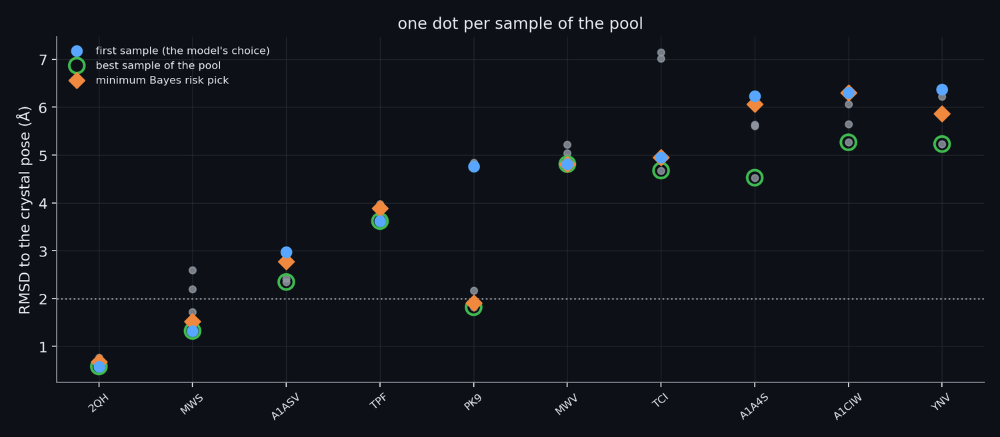

**Figure: The pose pools of the benchmark ligands.** The pool of poses that Boltz-2 gives for each of the 10 crystal-anchored benchmark ligands (5 samples each, unguided): one dot per sample, at its RMSD to the crystal pose (vertical axis), ligands ordered by the RMSD of their first sample. The first sample, the model's own top choice, is the filled circle; the best sample in the pool is ringed in green, which no rule can see without the crystal; the diamond is the pick of minimum Bayes risk. The dotted line is 2 A, the usual limit of a correct placement. The first sample is within 2 A for 2 of 10 ligands, the best sample of the pool for 3, and the minimum-Bayes-risk pick for 3: the pool often holds a good pose that nothing available at prediction time can single out, which is the whole difficulty of the structure track and the reason every selection rule was put to a gate.

In [313]:
show_figure("struct_pose_pools")

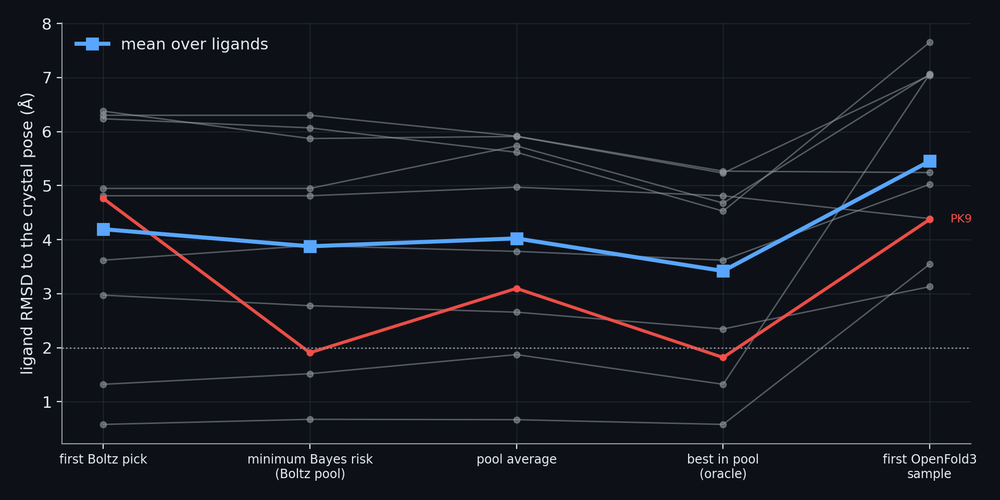

**Figure: Which pose to hand in: the selection rules on the benchmark.** Ligand RMSD to the crystal pose of the pose each rule picks, for the 10 benchmark ligands. Means: first Boltz sample 4.19 A, minimum-Bayes-risk pick 3.88 A, best sample in the pool 3.42 A, first OpenFold3 sample 5.45 A. The minimum-Bayes-risk rule closes 41% of the distance to the oracle, but the mean gain of 0.32 A is driven by one ligand (PK9, 2.85 A); without it the mean gain is 0.03 A. The rule is therefore reported as exploratory.

In [314]:
show_figure("struct_selection_rules")

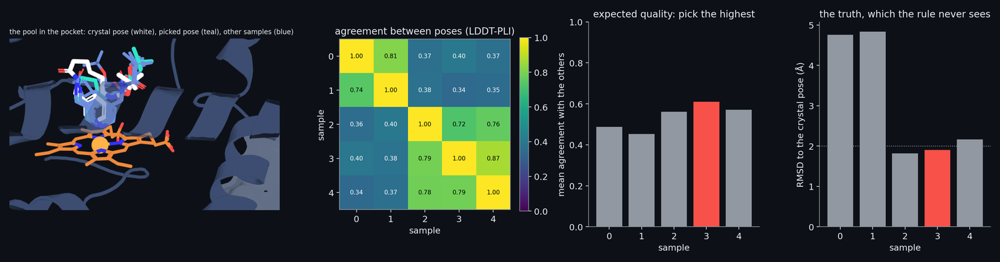

**Figure: How minimum Bayes risk picks a pose from a pool.** Minimum Bayes risk on a real pool: the 5 Boltz samples of PK9, a crystal-structure ligand. First panel: the pool in the pocket (rendered from the predicted coordinates, aligned on the crystal structure 4D75). Then: how much each pair of poses agrees (LDDT-PLI: the share of ligand-protein distances the two poses reproduce, 1 = identical). Middle: each pose's mean agreement with the others, its expected quality if the others were the truth; the highest is picked (sample 3). Right: the distance of each pose to the crystal pose, which the rule never sees: the pick is at 1.91 A against 4.76 A for the first sample and a best possible 1.82 A. This is one ligand; the gain over the benchmark is driven by it, which is why the rule is reported as exploratory.

In [315]:
show_figure("struct_mbr_pool")

## 11.9 OpenFold3: the second engine, the memory failure and what the second engine bought

> **Field:** Software engineering · Structural biology

*Where this section sits:* 11.2 described the family of co-folding models and 11.3 the batch that runs Boltz-2 on every ligand. 11.8 asked whether any rule picks a better pose from a pool than the model's own first sample, and one of its questions was whether a second engine adds information. This section is that second engine in full: what was run and how long it took, the failure that stopped its first runs on this machine and its cause, the change that made them fit and the check that the change leaves the answers alone, the benchmark and the verdict. The failure is an example of a kind of problem that the other sections do not show, a program that is correct on paper and does not fit in the memory of the computer, and of what it takes to show that a change which makes it fit does not change what it computes.

In [316]:
# OpenFold3 as it was run for the benchmark of 11.5: the query of one ligand, the package and the weights, the time of every run (the log of job 150_openfold3_benchmark) and the size of each problem in tokens. Everything is
# read from the files that the runs left, none is typed in.
import json

import gemmi
from rdkit import Chem

import cypmode.validation.openfold3 as of3_module

of3_root = ROOT / "data/structure_track/outputs/openfold3/cyp3a4"
of3_logs = ROOT / "data/structure_track/outputs/cyp3a4/logs"
of3_chains = json.loads((of3_root / "bench-YNV/query.json").read_text())["queries"]["cyp3a4_bench-YNV"]["chains"]
of3_weights = json.loads((of3_root / "bench-YNV/experiment_config.json").read_text())["inference_ckpt_name"]
of3_version = re.search(r"^Version: (\S+)", next((ROOT / ".venv-openfold3/lib/python3.13/site-packages").glob("openfold3-*.dist-info/METADATA")).read_text(), re.M).group(1)
of3_notes = re.sub(r"\s+", " ", of3_module.__doc__)
of3_n_fe, of3_boltz_n_fe = (float(v) for v in re.search(r"imidazole nitrogen (\d\.\d+) A from the iron with no constraints at all \(Boltz-2: (\d\.\d+) A\)", of3_notes).groups())
of3_s_fe = float(re.search(r"Cys442 SG to Fe (\d\.\d+) A", of3_notes).group(1))
of3_plddt_without = int(re.search(r"useless \(pLDDT (\d+)\)", of3_notes).group(1))

def first_sample(name, suffix):
    return sorted((of3_root / name).glob(f"cyp3a4_{name}/seed_*/*sample_1_{suffix}"))[0]

structure = gemmi.read_structure(str(first_sample("bench-YNV", "model.cif")))
chain_sizes = {chain.name: sum(len(residue) for residue in chain) for chain in structure[0]}
chain_rows = []
for chain in of3_chains:
    letter = chain["chain_ids"][0]
    if chain["molecule_type"] == "protein":
        chain_rows.append({"chain": letter, "molecule": "CYP3A4", "given as": "amino-acid sequence", "tokens": len(chain["sequence"])})
    elif "smiles" in chain:
        chain_rows.append({"chain": letter, "molecule": "the inhibitor", "given as": "SMILES", "tokens": Chem.MolFromSmiles(chain["smiles"]).GetNumHeavyAtoms()})
    else:
        chain_rows.append({"chain": letter, "molecule": "heme", "given as": "component code " + chain["ccd_codes"][0], "tokens": chain_sizes[letter]})
chain_table = pd.DataFrame(chain_rows)
show_table(chain_table, floatfmt=".0f")

benchmark_smiles = pd.read_csv(ROOT / "data/structure_track/inputs/structure_benchmark.csv").set_index("Molecule_Name")["SMILES"]
run_lines = re.finditer(r"^\s+(bench-\S+): (\d+) sample\(s\), ([\d.]+) s", (of3_logs / "bench_of3.log").read_text(), re.M)
of3_runs = pd.DataFrame([(m.group(1), int(m.group(2)), float(m.group(3))) for m in run_lines], columns=["ligand", "samples", "seconds"])
of3_runs["heavy atoms"] = [Chem.MolFromSmiles(benchmark_smiles[n]).GetNumHeavyAtoms() for n in of3_runs["ligand"]]
of3_runs["tokens"] = [len(json.loads(first_sample(n, "confidences.json").read_text())["pae"]) for n in of3_runs["ligand"]]
of3_runs["minutes"] = of3_runs["seconds"] / 60
show_table(of3_runs[["ligand", "samples", "heavy atoms", "tokens", "minutes"]], floatfmt=".1f")

residues = chain_table.loc[chain_table["molecule"] == "CYP3A4", "tokens"].iloc[0]
heme_atoms = chain_table.loc[chain_table["molecule"] == "heme", "tokens"].iloc[0]
token_count_checks = bool((of3_runs["tokens"] == residues + of3_runs["heavy atoms"] + heme_atoms).all())
of3_seeds = sorted({p.name for n in of3_runs["ligand"] for p in (of3_root / n).glob("cyp3a4_*/seed_*")})
ligand_atoms = int(chain_table.loc[chain_table["molecule"] == "the inhibitor", "tokens"].iloc[0])
of3_seed_number = of3_seeds[0].replace("seed_", "")
of3_hours, of3_min, of3_max, of3_mean = float(of3_runs["seconds"].sum() / 3600), float(of3_runs["minutes"].min()), float(of3_runs["minutes"].max()), float(of3_runs["minutes"].mean())
assert token_count_checks and len(of3_seeds) == 1  # a failing cell fails the build
print(f"tokens = residues + heavy atoms of the ligand + atoms of the heme for all {len(of3_runs)} ligands; one seed folder: {of3_seeds[0]}")

tokens = residues + heavy atoms of the ligand + atoms of the heme for all 10 ligands; one seed folder: seed_2746317213


| chain | molecule | given as | tokens |
| --- | --- | --- | --- |
| A | CYP3A4 | amino-acid sequence | 503 |
| B | the inhibitor | SMILES | 46 |
| C | heme | component code HEM | 43 |

| ligand | samples | heavy atoms | tokens | minutes |
| --- | --- | --- | --- | --- |
| bench-MWS | 3 | 27 | 573 | 15.5 |
| bench-TCI | 3 | 23 | 569 | 14.4 |
| bench-2QH | 3 | 34 | 580 | 13.9 |
| bench-A1CIW | 3 | 32 | 578 | 14.4 |
| bench-YNV | 3 | 46 | 592 | 12.9 |
| bench-PK9 | 3 | 23 | 569 | 19.7 |
| bench-TPF | 3 | 22 | 568 | 14.7 |
| bench-MWV | 3 | 36 | 582 | 19.8 |
| bench-A1ASV | 3 | 22 | 568 | 15.8 |
| bench-A1A4S | 3 | 42 | 588 | 16.1 |

**What was run.** OpenFold3 is the reimplementation of AlphaFold 3 named in 11.2. The package (version 0.5.0, Apache licence 2.0) lives in an isolated environment of its own, the pattern used for Boltz-2, and the weights are the checkpoint `openbind-2025-06-30-174k`. For each ligand the runner writes one query: the protein as a sequence (chain A), the inhibitor as a SMILES string (chain B) and the heme as a code of the chemical-component dictionary, HEM (chain C). These are the three chains and the same letters as in the Boltz-2 input, and the runner reads the sequence and the SMILES from that very input file, so that the two engines are given exactly the same system. The first table is the query of one ligand with the size of each chain in tokens (11.2: a residue of the protein, an atom of a ligand): 592 tokens for the ligand with 46 heavy atoms, which is the side of the matrix of predicted aligned errors (PAE, the model's estimate of the error in the position of one token when the structure is aligned on another) that every run saves; the cell checks that the same sum, protein residues plus heavy atoms of the ligand plus the 43 atoms of the heme, gives the side of that matrix for all ten ligands of the second table.

Three choices separate these runs from the Boltz-2 ones. *The alignments*: each run asks the ColabFold server for the alignment of the protein, and keeps it in its own folder, because without alignments the model is of no use: the first trial without them reached a pLDDT of 33. *No restraint*: the Boltz-2 batch can be told that the nitrogen of the ligand binds the iron (11.6). The OpenFold3 query carries no such restraint, since the program names the atoms of a bond by integer positions, which are easy to get wrong, and in the first trial, with ketoconazole, a crystallised inhibitor of CYP3A4, the model placed the nitrogen 2.14 Å from the iron and the sulfur of cysteine 442 2.27 Å from it without any constraint (Boltz-2: 2.05 Å). *One run at a time*: the runner refuses to start a prediction while another OpenFold3 process is alive, and none is run beside Boltz-2, because a single prediction already takes most of the memory of the machine.

A run of three samples takes 13 to 20 minutes depending on the size of the ligand (16 on average), so the ten ligands of the benchmark took 2.6 hours of machine time. The run folders carry the same seed number, 2746317213, for all ten ligands (the query file asks for seed 42; the folder name is the record of the seed used).

The machine has 16 gibibytes of **unified memory**: memory that the processor and the graphics processor share, so that what a model holds on the graphics processor is taken from the same 16 gibibytes as everything else. A **gibibyte** (GiB) is $2^{30} = 1{,}073{,}741{,}824$ bytes, the unit that the messages below are written in; a gigabyte counts $10^9$ and is 7 percent smaller. The graphics backend of PyTorch on this machine (MPS, Apple's Metal Performance Shaders) is allowed to hold only a part of that at once (the logs below state the limit) and refuses a single block that is too large for it.

In [317]:
# The failure, from the two messages that were logged and the arithmetic that explains them. The messages: the probe of job 149 (the runner file alone, three samples of the largest ligand, bench-YNV) and the log that an earlier
# attempt on bench-TCI left. The sizes are those the run itself wrote: the number of tokens is the side of the matrix of expected errors that every run saves, and the number of heads, of blocks and of samples are in the configuration
# that the run saved.
probe_text = (of3_logs / "openfold3_probe_config.log").read_text()
logged_probe = float(re.search(r"Invalid buffer size: ([\d.]+) GiB", probe_text).group(1))
error_text = (of3_root / "bench-TCI/logs/predict_err_rank0.log").read_text()
allocated_tci, max_allowed, logged_tci = (float(v) for v in re.search(r"MPS allocated: ([\d.]+) GiB.*?max allowed: ([\d.]+) GiB\)\. Tried to allocate ([\d.]+) GiB", error_text).groups())
frames = re.findall(r'File "[^"]*/(openfold3/[^"]+)", line (\d+), in (\w+)', error_text)
for path, line, name in frames:
    if path.endswith(("heads/prediction_heads.py", "utils/chunk_utils.py")):
        print(f"{path}, line {line}, in {name}")

model_config = json.loads((of3_root / "bench-YNV/model_config.json").read_text())["architecture"]
head_stack = model_config["heads"]["pairformer_embedding"]["pairformer"]
n_heads, n_blocks_head, n_blocks_trunk = head_stack["no_heads_pair"], head_stack["no_blocks"], model_config["pairformer"]["no_blocks"]
n_samples = model_config["shared"]["diffusion"]["no_full_rollout_samples"]
bytes_per_number = 4
of3_runs["predicted GiB"] = bytes_per_number * n_samples * n_heads * of3_runs["tokens"] ** 3 / 2 ** 30
logged_gib = {"bench-YNV": logged_probe, "bench-TCI": logged_tci}
of3_runs["logged GiB"] = [logged_gib.get(n, float("nan")) for n in of3_runs["ligand"]]
show_table(of3_runs[["ligand", "tokens", "predicted GiB", "logged GiB"]], floatfmt=".2f")
relative_errors = {n: float(abs(of3_runs.set_index("ligand").loc[n, "predicted GiB"] / g - 1)) for n, g in logged_gib.items()}
largest_error = max(relative_errors.values())
n_ynv = int(of3_runs.set_index("ligand").loc["bench-YNV", "tokens"])
predicted_ynv = float(of3_runs.set_index("ligand").loc["bench-YNV", "predicted GiB"])
bias_mib = bytes_per_number * n_heads * n_ynv ** 2 / 2 ** 20
copies = n_samples * n_ynv

openfold3/core/model/heads/prediction_heads.py, line 352, in forward
openfold3/core/model/heads/prediction_heads.py, line 225, in pairformer_emb
openfold3/core/utils/chunk_utils.py, line 261, in chunk_layer
openfold3/core/utils/chunk_utils.py, line 256, in _prep_inputs


| ligand | tokens | predicted GiB | logged GiB |
| --- | --- | --- | --- |
| bench-MWS | 573 | 8.41 | nan |
| bench-TCI | 569 | 8.24 | 8.25 |
| bench-2QH | 580 | 8.72 | nan |
| bench-A1CIW | 578 | 8.63 | nan |
| bench-YNV | 592 | 9.27 | 9.27 |
| bench-PK9 | 569 | 8.24 | nan |
| bench-TPF | 568 | 8.19 | nan |
| bench-MWV | 582 | 8.81 | nan |
| bench-A1ASV | 568 | 8.19 | nan |
| bench-A1A4S | 588 | 9.09 | nan |

**The failure.** The probe of job 149 asked for three samples of the largest ligand of the benchmark, bench-YNV, with the runner file alone. It failed with `Invalid buffer size: 9.27 GiB`: the program asked the backend for one block of that size. An earlier attempt on another ligand, bench-TCI, stopped with `Tried to allocate 8.25 GiB` while 8.55 GiB were already in use and 15.39 GiB were allowed. The traceback that the second attempt kept says where, in the lines printed above the table: in the *confidence head*, a second pair stack of 4 blocks that runs after sampling to compute the confidence scores (the trunk's own pair stack has 48 blocks and runs once), inside the routine `chunk_layer`, which does the **chunking**: it cuts the work of a layer into pieces of a few rows so that only one piece is in memory at a time. The line that failed flattens the batch dimensions of the inputs of triangle attention before the first piece is cut.

**The arithmetic.** A number in single precision takes 4 bytes, so an array of $E$ numbers takes $4E$ bytes. Let $S$ be the number of samples that the confidence head works on at once (3 in the benchmark, the number requested), $N$ the number of tokens and $H$ the number of heads of attention in its pair stack (4). The bias of triangle attention has shape $(N, H, N, N)$ once it has been repeated for each of the $N$ rows, and the head works on the $S$ samples together, so the flattened array has $S\,N\,H\,N\,N$ numbers:

$$\text{bytes} \;=\; 4\,S\,N\,H\,N\,N \;=\; 4\,S\,H\,N^{3}.$$

For the ligand of the probe, $N = 592$, which gives 9.27 GiB. The third column of the table is this formula for all ten ligands and the fourth is what the logs say for the two that were logged: they agree to within 0.2%. The cube is the point. The bias as stored is small, $4HN^2$ bytes, 5.3 MiB; its flattened copy is $S N = 1776$ times larger, and the cube grows fast with the ligand: the tokens of the ten ligands run from 568 to 592, and the allocations from 8.2 to 9.3 GiB. Even the smallest of them, 8.2 GiB, is of the size of the request that failed in bench-TCI when 8.55 GiB were already in use.

**Why a copy.** In triangle attention (11.2) each row of the pair representation attends along the row, and the weights are shifted by a bias that depends on the pair of positions and not on the row: the same array serves all $N$ rows. The program treats the stored array as if it were repeated $N$ times without storing the repeats; this is **broadcasting**, and the repeated array is a *view*, a different description of the same memory. The chunking routine begins by giving every input the same batch shape and then flattens the batch dimensions into one, so that it can count off rows. Flattening a view costs nothing when the result can still be described as one regular block of memory, with the same step from each row to the next, and costs a copy when it cannot. With one sample the batch dimensions are $(1, N)$ and it can. With two or more they are $(S, N)$: the $N$ rows of the first sample repeat the first sample's array and the next $N$ rows repeat another, and no single step describes that. The cell shows it on small arrays.

In [318]:
# Broadcasting and flattening, on small arrays. The bias of triangle attention is one array of shape (H, N, N) per sample, shared by all N rows of the pair representation. The layer sees it as an array of shape (S, N, H, N, N),
# S samples times N rows, without storing the repeats, and the chunking routine then flattens the first two axes into one. numpy follows the same rules as the library of the program (checked for PyTorch, in its own environment,
# by a test of the repository).
rng_of3 = np.random.default_rng(3)
n_toy, heads_toy = 48, 4
copy_rows = []
for samples_toy in (1, 2, 3):
    bias_toy = rng_of3.standard_normal((samples_toy, 1, heads_toy, n_toy, n_toy)).astype(np.float32)
    seen_toy = np.broadcast_to(bias_toy, (samples_toy, n_toy, heads_toy, n_toy, n_toy))
    flat_toy = seen_toy.reshape(-1, heads_toy, n_toy, n_toy)
    shares_toy = bool(np.shares_memory(flat_toy, bias_toy))
    copy_rows.append({"samples": samples_toy, "stored bias (KiB)": bias_toy.nbytes / 1024, "flattened array shares that memory": shares_toy, "memory held after flattening (KiB)": (bias_toy.nbytes if shares_toy else flat_toy.nbytes) / 1024})
copy_table = pd.DataFrame(copy_rows)
copy_table["growth"] = copy_table["memory held after flattening (KiB)"] / copy_table["stored bias (KiB)"]
show_table(copy_table, floatfmt=".1f")

| samples | stored bias (KiB) | flattened array shares that memory | memory held after flattening (KiB) | growth |
| --- | --- | --- | --- | --- |
| 1 | 36.0 | True | 36.0 | 1.0 |
| 2 | 72.0 | False | 3456.0 | 48.0 |
| 3 | 108.0 | False | 5184.0 | 48.0 |

With one sample the flattened array shares the stored memory and holds nothing beyond it; with two or three samples it holds 48 times what is stored, which is $N$ = 48, the number of rows over which each bias is repeated (and $S\,N$ times the bias of one sample). The same holds for the library the program uses, PyTorch (a test of the repository runs the same shapes in its environment). It agrees with the first trial: the single-sample prediction of ketoconazole ran in the memory of the machine, because with one sample the flattening is a view; the benchmark asked for three.

**Why the chunk size did not help.** The chunking routine exists to bound memory: it evaluates the layer on a few rows at a time. But the flattening happens before the first chunk is cut, so the size of the chunk does not enter. The runner file of the project lowers the upper bound of the chunk size to 128 (the preset sets 1024 and lets a tuner raise it to what fits the first block), which caps the buffers that depend on the chunk size. The probe of job 149 shows that this was not enough: the run with the runner file alone is the mode `config`, and it failed at the confidence head.

**The change.** The chunking routine already has the option that the failing path lacks, `low_mem`, which keeps the broadcast view and cuts every chunk out of it, so that only the chunk is ever materialised; no call site of the program sets it. The script `scripts/run_openfold_lowmem.py` makes it the default at every call site and then hands over to the program's own command line; it changes no file of the package. What it must not change is the answer. Chunking evaluates the same attention row by row, so the argument is that the arithmetic is the same, and the cell checks it on the toy: the three ways of computing the layer, all rows at once, flatten first as it came, and the low-memory path, with the peak memory of each.

In [319]:
# The chunked layer, three ways, on the toy of 11.2 made larger: starting-node triangle attention on S = 3 pair representations of N = 48 tokens with H = 4 heads. "Reference" computes every row at once. "Flatten first" is the program's
# routine as it came: it broadcasts the bias to every row, flattens (a copy for S > 1) and then cuts chunks of rows. "Views" is the low-memory path: it keeps the broadcast view and cuts every chunk out of it, so that only the chunk is
# ever materialised. The peak memory is measured with tracemalloc, which follows the arrays of numpy; the difference of the results is the largest absolute difference from the reference.
import tracemalloc

S_toy, N_c, C_c, H_c, D_c, rows_c = 3, 48, 16, 4, 8, 16
rng_c = np.random.default_rng(11)
x_c = rng_c.standard_normal((S_toy, N_c, N_c, C_c)).astype(np.float32)
w_q, w_k, w_v = (rng_c.standard_normal((C_c, H_c * D_c)).astype(np.float32) / np.sqrt(C_c) for _ in range(3))
tri_c = rng_c.standard_normal((S_toy, 1, H_c, N_c, N_c)).astype(np.float32)  # one bias per sample, shared by all rows
mask_c = (-1e9 * (rng_c.random((S_toy, N_c, 1, 1, N_c)) < 0.1)).astype(np.float32)

def softmax_last(a):
    a = a - a.max(axis=-1, keepdims=True)
    e = np.exp(a)
    return e / e.sum(axis=-1, keepdims=True)

def projections(x):
    split = lambda w: (x @ w).reshape(*x.shape[:-1], H_c, D_c)
    return split(w_q), split(w_k), split(w_v)

def reference():
    q, k, v = projections(x_c)
    logits = np.einsum("sijhd,sikhd->sihjk", q, k) / np.sqrt(D_c) + tri_c + mask_c
    return np.einsum("sihjk,sikhd->sijhd", softmax_last(logits), v).reshape(S_toy, N_c, N_c, H_c * D_c)

def chunked(views):
    q, k, v = (a.reshape(S_toy * N_c, N_c, H_c, D_c) for a in projections(x_c))
    seen = np.broadcast_to(tri_c, (S_toy, N_c, H_c, N_c, N_c))
    if not views:
        flat_bias = seen.reshape(-1, H_c, N_c, N_c)  # the copy
        flat_mask = mask_c.reshape(S_toy * N_c, 1, 1, N_c)
    out = np.empty((S_toy * N_c, N_c, H_c, D_c), dtype=np.float32)
    for lo in range(0, S_toy * N_c, rows_c):
        hi = min(lo + rows_c, S_toy * N_c)
        if views:
            s_index, i_index = np.divmod(np.arange(lo, hi), N_c)
            bias_c, mask_part = seen[s_index, i_index], mask_c[s_index, i_index]
        else:
            bias_c, mask_part = flat_bias[lo:hi], flat_mask[lo:hi]
        logits = np.einsum("rjhd,rkhd->rhjk", q[lo:hi], k[lo:hi]) / np.sqrt(D_c) + bias_c + mask_part
        out[lo:hi] = np.einsum("rhjk,rkhd->rjhd", softmax_last(logits), v[lo:hi])
    return out.reshape(S_toy, N_c, N_c, H_c * D_c)

def measured(function, *args):
    tracemalloc.start()
    result = function(*args)
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return result, peak / 2 ** 20

expected_c, peak_reference = measured(reference)
flat_c, peak_flat = measured(chunked, False)
views_c, peak_views = measured(chunked, True)
chunk_table = pd.DataFrame({"way": ["reference (all rows at once)", "flatten first (as it came)", "views (low memory)"], "peak memory (MiB)": [peak_reference, peak_flat, peak_views],
                            "largest difference from the reference": [0.0, float(np.abs(flat_c - expected_c).max()), float(np.abs(views_c - expected_c).max())]})
show_table(chunk_table, floatfmt=".1e")
bias_copy_mib = tri_c.nbytes * N_c / 2 ** 20
chunk_mib_real = rows_c * bytes_per_number * n_heads * n_ynv ** 2 / 2 ** 20

| way | peak memory (MiB) | largest difference from the reference |
| --- | --- | --- |
| reference (all rows at once) | 4.6e+01 | 0.0e+00 |
| flatten first (as it came) | 1.6e+01 | 1.2e-07 |
| views (low memory) | 1.1e+01 | 1.2e-07 |

The three give the same layer to 1e-07 (rounding of single-precision sums in a different order). The memory differs: flattening first holds a copy of the bias, 5.1 MiB here, on top of what the chunks need, and the low-memory path holds only the chunks, so its peak is 71% of the other's. At the real sizes the copy is 9.3 GiB, while a chunk of $r$ rows needs $4\,r\,H\,N^{2}$ bytes: for $r$ = 16 and $N$ = 592 that is 86 MiB (an example of the order of size, not the chunk that the program used).

In [320]:
# What the fix is checked by: the self-check of the wrapper (run in the OpenFold3 environment by job 149 and by a test of the repository), the probe of the same job with the wrapper in force, and the mode that the probe chose.
selfcheck_line = [line for line in (of3_logs / "openfold3_lowmem_selfcheck.log").read_text().splitlines() if line.startswith("self-check")][-1]
probe_ok = re.search(r"(bench-\S+): (\d+) sample\(s\), ([\d.]+) s", (of3_logs / "openfold3_probe_lowmem.log").read_text())
probe_ligand, probe_samples, probe_seconds = probe_ok.group(1), int(probe_ok.group(2)), float(probe_ok.group(3))
memory_mode = (ROOT / "data/structure_track/inputs/openfold3_memory_mode.txt").read_text().strip()
wrapper_source = (ROOT / "scripts/run_openfold_lowmem.py").read_text()
tolerance_unchunked, tolerance_original = re.findall(r"atol=([\d.e-]+)", wrapper_source)
print(selfcheck_line)
print(f"probe with the wrapper: {probe_ligand}, {probe_samples} samples, {probe_seconds:.1f} s; memory mode written by the probe: {memory_mode}")

self-check OK: low-memory chunking equals the original chunking and the unchunked layer; call sites patched
probe with the wrapper: bench-YNV, 3 samples, 772.5 s; memory mode written by the probe: lowmem


**What checks the change.** The self-check of the script builds a real triangle-attention layer of OpenFold3, at 24 tokens with random weights and in both directions (starting and ending node), computes it three ways, unchunked, chunked as it came and chunked by the script, and requires the script's result to equal the unchunked one to 1e-5 and the original chunking to 1e-6; it also requires that the call site of the layer has been replaced. Its last line in the log of job 149 reads: *self-check OK: low-memory chunking equals the original chunking and the unchunked layer; call sites patched*. A test of the repository (`tests/test_openfold3_lowmem.py`) runs the same check in the OpenFold3 environment. With the script in force the probe completed 3 samples of bench-YNV in 772 seconds, and the memory mode `lowmem` was written for every later run. What is not shown, and cannot be: that whole predictions are identical, because the program as it came cannot produce one for these inputs. The evidence is the equality on the layer where the memory was exhausted, which is the same function evaluated row by row; the other call sites of `chunk_layer` that the script changes are the same routine on other layers, and only the triangle attention was checked.

**The benchmark.** With the change in force, the ten ligands of the benchmark of 11.5 were predicted with three OpenFold3 samples each, and compared with the five Boltz-2 samples that each already had. The question of the pre-registered gate `engine_consensus` (11.8) has two parts: do the engines make different errors (the rank correlation of the per-ligand errors of their first samples must be below 0.7, so that a second opinion is a different opinion), and does minimum Bayes risk over both pools reach a lower mean RMSD than over the Boltz-2 pool alone, with the same safeguards as the other selection gates (the gain must survive dropping any one ligand, and a one-sided paired Wilcoxon p must be below 0.10)?

In [321]:
# The benchmark of the second engine: the ten ligands of 11.5 with five Boltz-2 samples and three OpenFold3 samples each. The pose table holds the RMSD of every sample to the crystal pose; the outcomes table holds, for every ligand, the RMSD of
# the first sample of each engine and of the pose chosen by minimum Bayes risk (11.8) from the pool of Boltz-2 alone and from the pool of both engines. The gate is recomputed with the function that registered it, and the repetition with
# OpenStructure's yardstick is read from the log of job 245_ost_pool_gates.
import cypmode.validation.final_recipe as final_recipe_module
from cypmode.validation.selection_validation import gates as pose_gates

of3_outcomes = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/selection_validation_outcomes.csv")
of3_gate = pose_gates(of3_outcomes)["engine_consensus"]
sample_table = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/benchmark_engine_pose_validation.csv")
by_engine = sample_table.groupby("engine")["true_rmsd"].agg(samples="count", mean="mean", median="median", best="min")
by_engine.index = by_engine.index.map({"boltz": "Boltz-2", "openfold3": "OpenFold3"})
show_table(by_engine.reset_index().rename(columns={"engine": "engine", "mean": "mean RMSD (A)", "median": "median RMSD (A)", "best": "best sample (A)"}), floatfmt=".2f")
first_closer = int((of3_outcomes["first_openfold3"] < of3_outcomes["first_boltz"]).sum())
first_gap = float((of3_outcomes["first_openfold3"] - of3_outcomes["first_boltz"]).mean())
change = of3_outcomes["mbr_both"] - of3_outcomes["mbr_boltz"]
n_changed, n_worse, n_better = int((change.abs() > 1e-9).sum()), int((change > 1e-9).sum()), int((change < -1e-9).sum())
ligand_table = of3_outcomes[["compound", "first_boltz", "first_openfold3", "mbr_boltz", "mbr_both"]].rename(columns={"compound": "ligand", "first_boltz": "Boltz-2 first sample", "first_openfold3": "OpenFold3 first sample",
                                                                                                                  "mbr_boltz": "MBR, Boltz-2 pool", "mbr_both": "MBR, both pools"})
show_table(ligand_table, floatfmt=".2f")
oracle_boltz, oracle_both = float(of3_outcomes["oracle_boltz"].mean()), float(of3_outcomes["oracle_both"].mean())
# A look after the verdict, not a test: the ligand whose pick got worst when the second pool was added, and the same comparison without it.
worst_ligand = of3_outcomes.loc[change.idxmax()]
rest = of3_outcomes.drop(change.idxmax())
rest_gate = pose_gates(rest)["engine_consensus"]
rest_gain = -float((rest["mbr_both"] - rest["mbr_boltz"]).mean())
rest_verdict = "would meet" if rest_gate["met"] else "would not meet"
mbr_boltz_mean, mbr_both_mean = float(of3_outcomes["mbr_boltz"].mean()), float(of3_outcomes["mbr_both"].mean())
ost_found = re.search(r"engine_consensus: mean improvement ([+-][\d.]+) A over (\d+) ligands, (\d+) wins, Wilcoxon p ([\d.]+), worst drop-one mean ([+-][\d.]+), errors correlation rho ([\d.]+)", (of3_logs / "ost_pool_gates.log").read_text())
ost_improvement, ost_wins, ost_p, ost_rho = float(ost_found.group(1)), int(ost_found.group(3)), float(ost_found.group(4)), float(ost_found.group(6))
n_test_ligands = len(pd.read_csv(ROOT / "data/structure_track/inputs/structure_track_test_blinded.csv"))
of3_extra_hours = n_test_ligands * final_recipe_module.OPENFOLD3_SAMPLES * final_recipe_module.HOURS_PER_OPENFOLD3_SAMPLE
final_recipe_openfold = bool(json.loads((ROOT / "data/structure_track/outputs/cyp3a4/final/recipe.json").read_text())["recipe"]["openfold3"])

| engine | samples | mean RMSD (A) | median RMSD (A) | best sample (A) |
| --- | --- | --- | --- | --- |
| Boltz-2 | 50 | 4.02 | 4.72 | 0.58 |
| OpenFold3 | 30 | 5.09 | 4.93 | 2.15 |

| ligand | Boltz-2 first sample | OpenFold3 first sample | MBR, Boltz-2 pool | MBR, both pools |
| --- | --- | --- | --- | --- |
| bench-2QH | 0.58 | 3.55 | 0.67 | 0.58 |
| bench-A1A4S | 6.24 | 7.65 | 6.07 | 5.64 |
| bench-A1ASV | 2.97 | 3.13 | 2.78 | 2.35 |
| bench-A1CIW | 6.30 | 5.24 | 6.30 | 6.30 |
| bench-MWS | 1.32 | 7.06 | 1.52 | 1.52 |
| bench-MWV | 4.81 | 4.39 | 4.81 | 4.81 |
| bench-PK9 | 4.76 | 4.37 | 1.91 | 4.84 |
| bench-TCI | 4.95 | 7.06 | 4.95 | 4.68 |
| bench-TPF | 3.62 | 5.02 | 3.89 | 3.67 |
| bench-YNV | 6.38 | 7.04 | 5.87 | 5.87 |

The engines do make different errors: the rank correlation of the errors of their first samples is 0.48, below 0.7, and OpenFold3's first sample is the closer of the two for 3 of the 10 ligands. But it is the worse engine on average, by 1.26 Å at the first sample, and over all samples 5.09 Å against 4.02 Å. The second part fails: minimum Bayes risk over both pools gives a mean RMSD of 4.025 Å and over the Boltz-2 pool alone 3.876 Å, so adding the engine makes the chosen pose worse by 0.148 Å on average, although in sign it helps more often than it harms: the choice changes for 6 of the 10 ligands, for the better in 5 and for the worse in 1. The Wilcoxon p is 0.219 and the worst drop-one mean -0.213 Å. The gate is NOT MET. With OpenStructure's yardstick (11.4) the figures are -0.104 Å, 5 wins, p 0.219 and a correlation of 0.54, and the verdict is the same.

Two things are visible in the tables. Minimum Bayes risk chooses the pose that agrees best with the others of the pool, so that every added pose is a vote, and the votes of the second engine are for poses that are mostly farther from the crystal pose: its first sample is the closer to it for only 3 of the ten ligands. And one ligand carries the verdict. For bench-PK9 the Boltz-2 pool alone chose a pose 1.91 Å from the crystal pose (the first sample of that engine is 4.76 Å away) and the pool of both engines one 4.84 Å away, a loss of 2.93 Å on its own. A look made after the verdict, and so not a test: without that ligand the pool of both engines is the better by 0.16 Å on average over the other 9, with p 0.03 and a worst drop-one mean of +0.13 Å, which would meet the registered rule. The rule was applied to the ten ligands as they are and its verdict stands, because choosing which ligand to leave out after seeing the result is the move that a gate written beforehand exists to prevent. What the look does show is how little the verdict rests on: one ligand turns it either way, so ten ligands cannot say that the second engine is harmful, only that it was not shown to help under the rule that was written before the result. The ceiling does rise when the pool grows (the best pose that exists in the pool, which no rule can apply, has a mean RMSD of 2.96 Å with both engines against 3.42 Å with Boltz-2 alone), so the second engine does produce good poses that Boltz-2 does not; what is missing is a way to tell which of them they are. The confidence of the engines cannot tell them apart: Boltz-2's is high even for poses several ångströms from the crystal pose (11.2), and the module that would have combined the engines records, as an external finding, that the confidence of both engines is an unreliable selector of poses for these enzymes.

**What follows.** The final recipe of the Structure Track therefore runs Boltz-2 alone (the recipe file records `openfold3 = False` and the reason, "engine_consensus not MET"). Had the gate been met, the recipe would have added three OpenFold3 samples for each of the 20 ligands at about 16 minutes each, 16.2 hours of machine time. The code stays in the repository, tested, as the record of what was run and as an engine that a later benchmark could re-test; it is not part of any submitted file.

**What limits the verdict.** Ten ligands, so a gate that can certify only a large difference (11.8 gives its size); a Wilcoxon threshold of 0.10 that was stated openly because 0.05 would have needed nearly every ligand to improve; one seed, the weights as released, no templates and no restraint, and alignments requested from a public server; and a yardstick, the RMSD to the crystal pose, that is not the organisers' score (the repetition with OpenStructure's scorer gave the same verdict). A different set of ligands, a restraint expressed in OpenFold3's own terms, or a selection rule that used something other than agreement could change the picture; none was tried.

*On what actually ran.* `cypmode/validation/openfold3.py` (`build_query`, `read_boltz_inputs`, `run_openfold3`, `run_openfold3_batch`, `default_memory_mode`, `failure_reason`, and the guard `_another_prediction_running`), `scripts/run_openfold_lowmem.py` (`patch_chunk_layer`, `self_check`), the runner file `data/structure_track/inputs/openfold3_runner.yml`, `cypmode/validation/selection_validation.py` (`gates`, `paired_gate`), `cypmode/validation/pose_consensus.py` (the rule that would have combined the engines), `cypmode/validation/final_recipe.py` (the constants of cost and the decision), the tests `tests/test_openfold3.py` and `tests/test_openfold3_lowmem.py`, and the queue jobs `149_openfold3_memory_probe`, `150_openfold3_benchmark`, `170_mbr_selection_validation`, `180_structure_final_recipe_run` and `245_ost_pool_gates`. The cells of this section read the files those runs left; the arrays of the two toys are written for the notebook. OpenFold3 is distributed under the Apache licence 2.0, and its weights under the terms stated with the checkpoint; the repository contains neither the package nor the weights.

In [322]:
# BioEmu2, examined as a third structure engine: the record of the first attempts and, once job 259 has run, the timings of the probe and the registered feasibility rule applied to them. Every number is read from the files that the attempts left.
import json
import re

import yaml

import cypmode.validation.bioemu2 as bioemu_module

bioemu_logs = ROOT / "data/structure_track/outputs/cyp3a4/logs"
bioemu_first = (bioemu_logs / "exploratory_bioemu2_first_attempts.log").read_text()
bioemu_cpu_s, bioemu_gpu_s = (int(v) for v in re.findall(r"in (\d+) s", bioemu_first))
bioemu_peptide_atoms = int(re.search(r"(\d+) atoms", bioemu_first).group(1))
bioemu_stops = [(int(a), int(b) / 1000) for a, b in re.findall(r"WATCHDOG: free (\d+)% swap (\d+)M", bioemu_first)]
bioemu_system = yaml.safe_load((ROOT / "data/structure_track/inputs/cyp3a4_bench-MWS.yaml").read_text())
bioemu_residues = len(next(e["protein"]["sequence"] for e in bioemu_system["sequences"] if "protein" in e))
bioemu_probe_log = (bioemu_logs / "exploratory_bioemu2_probe.log").read_text().strip().splitlines()
bioemu_rule_line = bioemu_probe_log[-1]
bioemu_limit_h = bioemu_module.MAX_EXCLUSIVE_HOURS
bioemu_benchmark, bioemu_official, bioemu_samples = bioemu_module.BENCHMARK_LIGANDS, bioemu_module.OFFICIAL_LIGANDS, bioemu_module.SAMPLES_PER_LIGAND
bioemu_timings_file = ROOT / "data/structure_track/outputs/bioemu2/probe/cyp3a4" / bioemu_module.PROBE_NAME / "timings.json"
if bioemu_timings_file.exists():
    bioemu_t = json.loads(bioemu_timings_file.read_text())
    bioemu_sentence = (f"The probe completed: the trunk took {bioemu_t['trunk_s']:.0f} s, the two samples {bioemu_t['sample_s'][0]:.0f} s and {bioemu_t['sample_s'][1]:.0f} s, "
                       f"and the process held at most {bioemu_t['peak_rss_mb'] / 1000:.1f} GB of memory.")
else:
    bioemu_sentence = "The probe did not complete; its log records how far it came."
print(bioemu_rule_line)

BIOEMU2 FEASIBILITY: 9.3 h of exclusive machine time projected for 30 ligands with 3 samples each (limit 48 h): ALLOWED


**A third engine that was examined: BioEmu2.** After the benchmark of the second engine a third model was looked at, BioEmu2: a diffusion model of the kind described in 11.2 (from Microsoft Research, under the MIT licence, with about five hundred million parameters according to its model card) that builds an all-atom structure of a protein with ligands from the sequence, an alignment of related sequences and optional contacts. It is meant for Linux and an NVIDIA graphics card, and the configuration of its public checkpoint names one layer routine that exists only for those cards. Its code has a plain PyTorch version of the same layer, so a local copy of the configuration that names it, with the layers cut into chunks that lower the peak memory without changing the arithmetic, lets the model run on this machine; the weights are untouched (`cypmode/validation/bioemu2.py`, tested by `tests/test_bioemu2.py`). The inputs are those of Boltz-2: the sequence, the SMILES of the ligand, the heme and the bond of Cys442 to the iron, all read from the same input file and converted by the program's own converter, and the first rows of the alignment that Boltz-2 used, so that the engines differ in the model and not in what they are given. Contacts to the atoms of a ligand that is given as a SMILES string are not supported by the program, so none are passed.

**What the machine allows.** On a peptide of twenty residues (153 atoms) two samples took 122 s on the processor and 88 s on the graphics chip. A benchmark system is much larger: the protein alone has 503 residues, and with the ligand and the heme the model works on several hundred tokens. Two timing probes of that system were stopped by a memory watchdog while a graphics job of the queue was running beside them, at 7% and 10% free memory with 9.0 GB and 8.8 GB of swap in use (swap is the disk space that the operating system falls back on when memory is full, and it is slow); the second probe used the chunked layers and stopped all the same. Beside the queue the system does not fit, so the probe became a queue job, `259_bioemu2_probe`, that waits until the long graphics jobs have settled and then runs alone. The probe completed: the trunk took 315 s, the two samples 270 s and 261 s, and the process held at most 4.9 GB of memory.

**The rule that was written before the probe was read.** The benchmark of the engine is run only if its projected cost is within a limit: one trunk per ligand and the samples at the median speed of the probe, for the 10 benchmark ligands and the 20 official ligands with 3 samples each, at most 48 hours of exclusive machine time. The log of the probe ends with the rule applied: BIOEMU2 FEASIBILITY: 9.3 h of exclusive machine time projected for 30 ligands with 3 samples each (limit 48 h): ALLOWED. If it says NOT ALLOWED, the engine is recorded as not run, with the measurements above, and nothing else changes. If it says ALLOWED, the benchmark is declared before any ligand is predicted, and its gate is the engine-consensus gate of this section with BioEmu2 as the added engine; the second engine did not pass that gate, so the prior for a third is not high.

*On what actually ran.* `cypmode/validation/bioemu2.py` (`prepare_checkpoint`, `pure_torch_config`, `msa_a3m`, `run`, `projected_hours`, `feasibility_line`) ran for the attempts and for the probe, and `259_bioemu2_probe` is the job that applies the rule. The file `exploratory_bioemu2_first_attempts.log` was assembled by hand from the logs of the five first attempts and its lines are the programs' own output; `exploratory_bioemu2_probe.log` is written by the job.

In [323]:
# The benchmark of BioEmu2 and its gate (11.9): the verdict line and the numbers of the log of job 261, and the time that job 260 took, read from the files.
import json
import re

bioemu_gate_log = (bioemu_logs / "selection_validation_bioemu2.log").read_text()
_stats = re.search(r"engine_consensus_bioemu2: mean improvement ([+-][\d.]+) A over (\d+) ligands, (\d+) wins, Wilcoxon p ([\d.]+), worst drop-one mean ([+-][\d.]+), errors correlation rho ([-\d.]+)", bioemu_gate_log)
bioemu_gain, bioemu_n, bioemu_wins, bioemu_p, bioemu_drop, bioemu_rho = _stats.groups()
bioemu_gate = re.search(r"STRUCTURE GATE engine_consensus_bioemu2 [^:]*: (MET|NOT MET)", bioemu_gate_log).group(1)
_timings = [json.loads(path.read_text()) for path in sorted((ROOT / "data/structure_track/outputs/bioemu2/cyp3a4").glob("*/timings.json"))]
bioemu_hours = sum(entry["trunk_s"] + sum(entry["sample_s"]) for entry in _timings) / 3600
bioemu_consequence = (
    "The final recipe therefore keeps Boltz-2 alone, and BioEmu2 is recorded as a measured negative result, as the second engine was."
    if bioemu_gate == "NOT MET"
    else "The gate being met, the engine is carried into the recipe, as the declaration of the benchmark states."
)
print(bioemu_gate, bioemu_gain, bioemu_n, bioemu_wins, bioemu_p, bioemu_drop, bioemu_rho, round(bioemu_hours, 1))

NOT MET +0.063 10 2 0.250 +0.022 0.47 3.6


**The benchmark and its verdict.** The probe allowed the benchmark, and it was declared before any ligand was predicted (with the rule and the gate). Job `260_bioemu2_benchmark` predicted the 10 ligands of the benchmark of 11.5 with three samples each, which took 3.6 hours of the machine, and job `261_bioemu2_gate` scored the poses against the crystal poses with the yardstick of the other engines and ran the gate of this section with BioEmu2 as the added engine. The rank correlation of the errors of the first samples of the two engines is 0.47; the pose of minimum Bayes risk over the samples of both engines improves on the one over the Boltz-2 samples alone by +0.063 Å of mean RMSD over 10 ligands (a negative number means that adding the engine made the mean worse), better for 2 of them (Wilcoxon p 0.250, worst drop-one mean +0.022 Å): the gate is **NOT MET**. The final recipe therefore keeps Boltz-2 alone, and BioEmu2 is recorded as a measured negative result, as the second engine was.

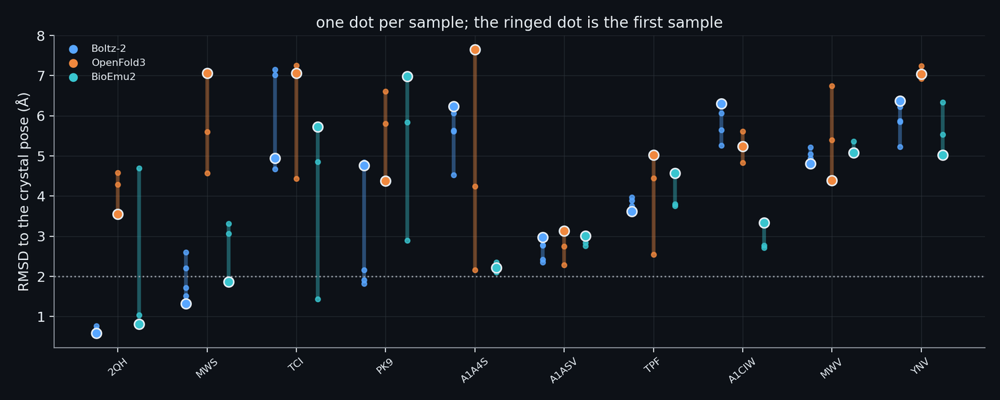

**Figure: The three structure engines on the benchmark ligands.** The three structure engines on the same crystal-anchored benchmark ligands: Boltz-2 (the engine of the recipe), OpenFold3 and BioEmu2 (a diffusion model of conformational ensembles that runs here with its pure-PyTorch kernel). One dot per sample of a pool, at its RMSD to the crystal pose; the filled marker is the first sample and the bar the best of the pool. boltz: 2 of 10 ligands with the first sample within 2 A, the best of the pool within 2 A for 3; openfold3: 0 of 10 ligands with the first sample within 2 A, the best of the pool within 2 A for 0; bioemu2: 2 of 10 ligands with the first sample within 2 A, the best of the pool within 2 A for 3. The engine-consensus gate asks whether a second engine helps to choose among the poses of the first; it is NOT MET, and the final recipe uses Boltz-2 only.

In [324]:
show_figure("struct_engine_comparison")

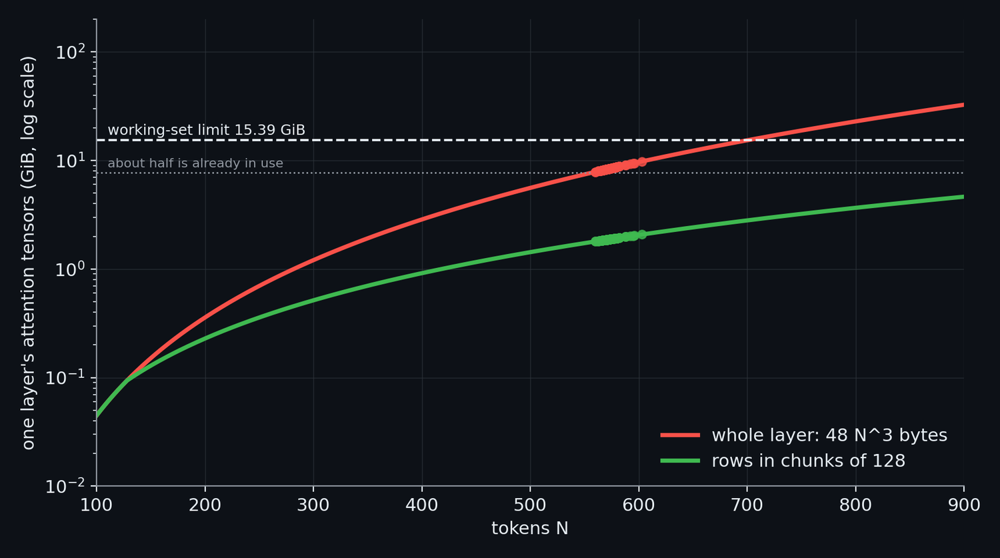

**Figure: OpenFold3 on a 16 GB machine: the memory arithmetic and the chunking that fixes it.** Memory of one triangle-attention layer of the OpenFold3 pairformer against the number of tokens N (residues, ligand heavy atoms and the 43 atoms of the heme): 3 tensors x 4 heads x N rows x N x N x 4 bytes = 48 N^3 bytes. For bench-YNV, N = 592 and the formula gives 9.27 GiB, the size of the buffer the runtime refused in the first probe (log: Invalid buffer size 9.27 GiB). The runtime's working-set limit on this machine is 15.39 GiB and the weights and activations already occupy about half of it, so the layer cannot be allocated whole. Cutting the rows into chunks of 128 makes the layer need 2.01 GiB at the same N. Dots mark the 189 base inputs of this project (one per ligand), N from 560 to 603.

In [325]:
show_figure("struct_openfold3_memory")

## 11.10 The final recipe: from the verdicts to the file that is submitted

> **Field:** Structural biology · Software engineering

*Where this section sits:* 11.3 to 11.9 each ended in a verdict. This section is what those verdicts add up to: the recipe that was run, the pools of poses it produced, the rule that keeps a pose away from the edge of the scorer's checks, the force-field relaxation that was added after the poses were chosen, and the archive that is the candidate submission. Nothing in it was chosen by looking at the accuracy of the twenty poses, which nobody outside the organisers can see: the recipe is a function of the verdicts, the relaxation was applied under a rule written before any of the twenty poses was relaxed, and the archive is built so that the same poses give the same bytes.

**One recipe, decided by the gates.** The module `cypmode/validation/final_recipe.py` reads the line `STRUCTURE GATE <name>: MET|NOT MET` that every gate of the structure track wrote to its log, and applies one fixed mapping: a restraint gate that is MET switches the restraint on for the whole batch (the bond restraint is withdrawn if the registered check on new ligands found it worse); a pilot gate that is MET adds three runs of that lever to every pool; a MET engine gate adds three OpenFold3 samples; a MET selection gate replaces the model's own ranking among valid poses by minimum Bayes risk (11.8) or by that rank plus the terms that passed; the extra samples go where the pools disagree most if that gate is MET and are spread evenly if not. The base of every pool is five unguided Boltz-2 samples per ligand (samples that already existed count). The cell reads the record of the decision, calls the function again on the recorded verdicts, and requires that it gives the recorded recipe.

In [326]:
# The decision of the final structure recipe, read from its record (final/recipe.json, written by cypmode/validation/final_recipe.py in job 180_structure_final_recipe_run): the verdict of every gate that the recipe reads and the
# choices that follow from them. The mapping from verdicts to choices is one fixed function, decide(); the cell calls it again on the recorded verdicts and checks that it gives the recorded recipe.
import json
from dataclasses import asdict

from cypmode.validation.final_recipe import decide

final_dir = ROOT / "data/structure_track/outputs/cyp3a4/final"
recipe_record = json.loads((final_dir / "recipe.json").read_text())
gate_verdicts = recipe_record["gates"]
again = asdict(decide(gate_verdicts, extra_per_ligand=recipe_record["recipe"]["extra_per_ligand"]))
recorded = dict(recipe_record["recipe"])
same_recipe = all(again[k] == recorded[k] for k in recorded if k != "reasons")
assert same_recipe  # a failing cell fails the build
gate_table = pd.DataFrame({"gate": list(gate_verdicts), "verdict": ["MET" if v else "NOT MET" for v in gate_verdicts.values()]})
show_table(gate_table, floatfmt=".0f")
n_gates, n_met = len(gate_table), int(sum(gate_verdicts.values()))
met_names = [g for g, v in gate_verdicts.items() if v]
met_text = ", ".join(met_names)
for reason in recorded["reasons"]:
    print("-", reason)
estimated_hours = float(recipe_record["estimated_hours"])

- restraint 'bond': gate MET
- diversity levers: none (no pilot gate MET)
- Boltz only: engine_consensus not MET
- selection 'first_valid': mbr_selection not MET, so the model's own ranking among valid poses is kept; for a ligand with a Type II donor the restrained run is read first (the pick the restraint gate measured)
- extra samples allocated uniformly: ei_sampling not MET
- margin: among valid poses only those with a relative distance to the receptor of at least 0.8 under the scorer's own PoseBusters call are eligible (else the largest margin)


| gate | verdict |
| --- | --- |
| mbr_selection | NOT MET |
| engine_consensus | NOT MET |
| heme_frame_prior | NOT MET |
| ei_sampling | NOT MET |
| restraint_bond | MET |
| restraint_contact | MET |
| pilot_conformers | NOT MET |
| pilot_cryoem | NOT MET |
| pilot_seeds | NOT MET |
| pose_physics | NOT MET |
| pose_pharmacophore | NOT MET |
| pose_combined | NOT MET |
| series_consensus | NOT MET |
| restraint_bond_expansion | NOT MET |
| restraint_bond_harm | NOT MET |

Of the 15 gates the recipe reads, 2 are MET, the two restraints of 11.6 (restraint_bond, restraint_contact). Every other gate is NOT MET: the three levers that have a verdict (seeds, crystal conformers and cryo-EM templates, 11.7; the fourth lever, a lower step scale, produced only unusable poses and has no verdict, so it adds nothing), the second engine (11.9), minimum Bayes risk and the terms that describe a pose (11.8), expected-improvement sampling and the series consensus. Two gates are about the bond restraint on ligands that were not used to choose it (11.6): the confirmation of its gain is NOT MET, and so is the finding of harm, so the restraint stays on the evidence of the gate that chose it and is not withdrawn. The recipe is therefore short: the restraint, three restrained samples per ligand, two extra samples per ligand spread evenly, Boltz-2 alone, and the first valid pose in the model's own order, taken from the restrained run first for a ligand that has a donor of the Type II kind (that is the pick the restraint gate measured, so it is the pick that carries the evidence). The record estimates 20.6 hours of machine time for the runs it added to what already existed. The decision is a table of verdicts and not an opinion: a gate that is later re-run and changes its verdict changes the recipe, and the job `179_requeue_final_recipe` exists so that the decision can be run again on the final verdicts.

**The pools.** For each of the twenty ligands the pool is every pose of every run of that ligand. The next cell reads the manifest of the final directory: the size of each pool, how many of its poses are valid under the scorer's own PoseBusters call, which kind of run the chosen pose came from, and the smallest relative distance to the receptor of the chosen pose.

In [327]:
# The pools and the pose chosen from each, read from the manifest of the final directory (final/manifest.json). A pool is every pose of every run of a ligand: the unguided samples, the restrained samples and the extra samples. The suffix of a
# run name says which kind it is: -rs restrained, -u unguided, -ex1 and so on extra samples, no suffix the first batch.
from cypmode.validation.official_posebusters import MARGIN_FLOOR

manifest = json.loads((final_dir / "manifest.json").read_text())
chosen = pd.DataFrame(manifest["ligands"])
chosen["kind"] = chosen["run"].str.extract(r"-(rs|u|ex\d+)$")[0].map(lambda k: {"rs": "restrained", "u": "unguided"}.get(k, "extra sample" if isinstance(k, str) else "first batch"))
kind_table = chosen.groupby("kind").size().rename("ligands").reset_index()
show_table(kind_table, floatfmt=".0f")
pool_sizes = chosen["pool"]
n_poses, n_valid = int(pool_sizes.sum()), int(chosen["valid_in_pool"].sum())
all_chosen_valid, chosen_margin_min, chosen_margin_median = bool(chosen["valid"].all()), float(chosen["distance_margin"].min()), float(chosen["distance_margin"].median())
n_restrained = int((chosen["kind"] == "restrained").sum())
assert all_chosen_valid
print(f"{len(chosen)} ligands; pools of {pool_sizes.min()} to {pool_sizes.max()} poses (median {pool_sizes.median():.0f}); {n_poses} poses in all, {n_valid} valid")

20 ligands; pools of 9 to 14 poses (median 9); 200 poses in all, 165 valid


| kind | ligands |
| --- | --- |
| first batch | 7 |
| restrained | 12 |
| unguided | 1 |

There are 200 poses in the twenty pools, 165 of them valid, in pools of 9 to 14. The pose chosen for 12 ligands comes from the restrained run, which is where the first-valid rule looks first for a ligand with a Type II donor. Every chosen pose is valid (the cell requires it), and the smallest relative distance to the receptor among the twenty is 0.801 (median 0.826).

**The margin.** 11.4 introduced the check that a ligand atom is not closer to a receptor atom than the sum of their van der Waals radii allows, scaled: the check fails below a relative distance of 0.75. A pose at 0.76 passes, and passes by a hair: the scorer reads the file it is given, but a pose that sits on the threshold is one that a rounding or a small difference between two versions of the checker could turn into a zero (a failing pose scores zero on all three metrics). The recipe therefore keeps a margin: among the valid poses of a pool only those with a smallest relative distance of at least 0.8 may be chosen. If no valid pose clears that, the one with the largest margin is chosen alone. If no pose is valid, the pool is left as it was. The rule never looks at how accurate a pose is, which nothing can know for a blinded ligand; it removes only the poses that are closest to being invalid, and the selection rule chooses among the rest. The cell shows the three cases with the project's function.

In [328]:
# The margin rule on three small pools, with the project's own function (final_recipe.margin_candidates). A pose is a candidate when it passes the checks and its smallest relative distance to the receptor (11.4) is at least 0.80; if no valid
# pose clears 0.80, the valid pose with the largest margin is the only candidate; if no pose is valid, the candidates stay as they were. The rule never looks at how accurate a pose is: the selection rule chooses among the survivors.
from cypmode.validation.final_recipe import margin_candidates

margin_cases = {
    "some valid poses clear the floor": (np.array([True, True, False, True]), np.array([0.78, 0.86, 0.90, 0.81])),
    "valid poses, none clears it": (np.array([True, True, True]), np.array([0.76, 0.79, 0.77])),
    "no pose is valid": (np.array([False, False]), np.array([np.nan, np.nan])),
}
margin_rows = []
for case, (ok_toy, margins_toy) in margin_cases.items():
    survivors = margin_candidates(list(range(len(ok_toy))), ok_toy, margins_toy)
    margin_rows.append({"pool": case, "valid": " ".join("yes" if v else "no" for v in ok_toy), "margins": " ".join("-" if np.isnan(m) else f"{m:.2f}" for m in margins_toy), "poses that may be chosen": " ".join(str(i) for i in survivors)})
margin_toy_table = pd.DataFrame(margin_rows)
show_table(margin_toy_table, floatfmt=".2f")

| pool | valid | margins | poses that may be chosen |
| --- | --- | --- | --- |
| some valid poses clear the floor | yes yes no yes | 0.78 0.86 0.90 0.81 | 1 3 |
| valid poses, none clears it | yes yes yes | 0.76 0.79 0.77 | 1 |
| no pose is valid | no no | - - | 0 1 |

In the first pool the pose with the margin 0.78 is dropped although it is valid, and the poses with 0.86 and 0.81 remain. In the second no valid pose reaches the floor, and the pose with the largest margin, 0.79, is the only one left. In the third there is nothing to choose between and the pool is unchanged.

**The relaxation.** The poses that co-folding models write are not always physically sensible: atoms can sit a little too close, bonds can be a little too long. The PoseBusters paper reports that a short energy minimisation with a force field repairs most of the poses that a deep-learning docking model leaves invalid. A **force field** (met in 3.5 and 10.5 as the way a shape is relaxed) writes the energy of a molecular system as a sum of simple terms: the stretching of bonds and the bending of angles as springs, the twisting of torsions, and between atoms that are not bonded the **Lennard-Jones** term and the Coulomb term. The Lennard-Jones term is $E = 4\varepsilon\left[(\sigma/r)^{12} - (\sigma/r)^{6}\right]$ for two atoms at distance $r$, where $\sigma$ is the distance at which the repulsion and the attraction cancel in energy ($\varepsilon$ is the depth of the well): steeply repulsive when atoms are closer than the sum of their radii, weakly attractive beyond it. The Coulomb term, $q_i q_j / (4\pi\varepsilon_0\,\epsilon_r\,r)$, is the force between the partial charges of the atoms, divided by the relative **dielectric constant** $\epsilon_r$ of the medium, which weakens it. To **minimise** the energy is to move the atoms downhill until nothing moves; the method of the project is L-BFGS, which follows the slope of the energy and keeps a memory of the last steps to estimate the curvature. The next cell puts numbers into all three ideas for one pair of atoms, before the relaxation itself is used.

| distance r (A) | repulsive part | attractive part | Lennard-Jones sum | Coulomb, dielectric 1 | Coulomb, dielectric 4 |
| --- | --- | --- | --- | --- | --- |
| 2.4000 | 26.1380 | -3.2334 | 22.9045 | -16.6032 | -4.1508 |
| 3.0000 | 1.7962 | -0.8476 | 0.9486 | -13.2825 | -3.3206 |
| 3.4000 | 0.4000 | -0.4000 | 0.0000 | -11.7199 | -2.9300 |
| 3.8164 | 0.1000 | -0.2000 | -0.1000 | -10.4412 | -2.6103 |
| 4.5000 | 0.0138 | -0.0744 | -0.0606 | -8.8550 | -2.2138 |
| 6.0000 | 0.0004 | -0.0132 | -0.0128 | -6.6413 | -1.6603 |
| 10.0000 | 0.0000 | -0.0006 | -0.0006 | -3.9848 | -0.9962 |

| step | distance r (A) | energy (kcal/mol) | push, minus the slope (kcal/mol/A) |
| --- | --- | --- | --- |
| 0 | 2.4000 | 22.9045 | 122.6063 |
| 1 | 2.6452 | 6.3298 | 32.8065 |
| 2 | 2.7108 | 4.5045 | 23.3864 |
| 3 | 2.7576 | 3.5314 | 18.4250 |
| 4 | 2.7944 | 2.9121 | 15.2913 |
| 4612 | 3.8144 | -0.1000 | 0.0010 |

| step size (A per kcal/mol/A) | distance after the first step (A) | steps until the push is below 0.001 | where it stops (A) | distance from the bottom (A) |
| --- | --- | --- | --- | --- |
| 0.0020 | 2.6452 | 4612 | 3.8144 | -0.0020 |
| 0.0080 | 3.3809 | 1122 | 3.8144 | -0.0020 |
| 0.0300 | 6.0782 | 2775 | 3.8184 | 0.0020 |
| 0.0600 | 9.7564 | 1 | 9.7564 | 5.9400 |

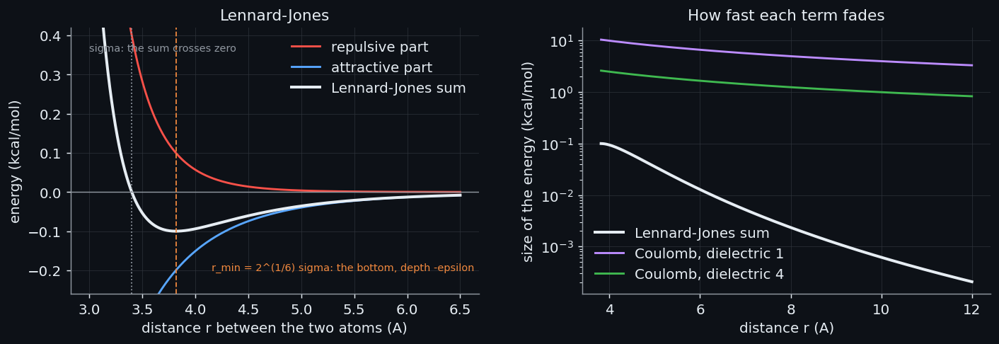

In [329]:
# The two nonbonded terms of a force field, worked on one pair of atoms. The numbers are those of a carbon-carbon contact (well depth 0.1 kcal/mol, sigma 3.4 A) and of two partial charges,
# +0.3 and -0.4 of the charge of an electron. The Coulomb constant is not typed in: it is computed from the physical constants as e^2 / (4 pi eps0), per mole, in kcal A / (mol e^2), the unit
# in which a force field writes its charges. The minimisation is done twice from the same start, 2.4 A: by plain steps down the slope (gradient descent) and by L-BFGS, the method of the project.
from scipy import constants as phys
from scipy.optimize import minimize, minimize_scalar

well_eps, well_sigma = 0.1, 3.4
coulomb_constant = phys.e**2 / (4 * np.pi * phys.epsilon_0) * phys.N_A * 1e10 / (phys.calorie * 1000)
charge_i, charge_j = 0.3, -0.4
coulomb_in_relax = float(re.search(r"^COULOMB = ([\d.]+)", (ROOT / "cypmode/validation/relax.py").read_text(), re.M).group(1))  # the same constant in the units of OpenMM, kJ nm / (mol e^2)
assert abs(coulomb_constant * phys.calorie / 10 - coulomb_in_relax) < 1e-6 * coulomb_in_relax

def lj_repulsion(r):
    return 4 * well_eps * (well_sigma / r) ** 12

def lj_attraction(r):
    return -4 * well_eps * (well_sigma / r) ** 6

def lj_total(r):
    return lj_repulsion(r) + lj_attraction(r)

def lj_push(r):
    """Minus the slope of the energy: positive when the atoms are pushed apart."""
    return 4 * well_eps / r * (12 * (well_sigma / r) ** 12 - 6 * (well_sigma / r) ** 6)

def coulomb_energy(r, dielectric):
    return coulomb_constant * charge_i * charge_j / (dielectric * r)

r_min_formula = 2 ** (1 / 6) * well_sigma
r_min_found = float(minimize_scalar(lj_total, bounds=(3.0, 6.0), method="bounded", options={"xatol": 1e-9}).x)
assert abs(r_min_found - r_min_formula) < 1e-4 and abs(lj_total(r_min_formula) + well_eps) < 1e-12 and abs(lj_total(well_sigma)) < 1e-12

term_rows = []
for r in (2.4, 3.0, well_sigma, r_min_formula, 4.5, 6.0, 10.0):
    term_rows.append({"distance r (A)": r, "repulsive part": lj_repulsion(r), "attractive part": lj_attraction(r), "Lennard-Jones sum": lj_total(r),
                      "Coulomb, dielectric 1": coulomb_energy(r, 1.0), "Coulomb, dielectric 4": coulomb_energy(r, 4.0)})
term_table = pd.DataFrame(term_rows)
show_table(term_table, floatfmt=".4f")

def descend(step, start=2.4, tolerance=1e-3, limit=200000):
    """Gradient descent on the Lennard-Jones energy: move by step times the push until the push is below the tolerance."""
    r, n, path = start, 0, [(0, start, float(lj_total(start)), float(lj_push(start)))]
    while abs(lj_push(r)) > tolerance and n < limit:
        r += step * lj_push(r)
        n += 1
        if n <= 4:
            path.append((n, float(r), float(lj_total(r)), float(lj_push(r))))
    return n, float(r), path

descent_step, descent_start = 0.002, 2.4
n_descent, r_descent, descent_path = descend(descent_step, descent_start)
descent_path.append((n_descent, r_descent, float(lj_total(r_descent)), float(lj_push(r_descent))))
descent_table = pd.DataFrame(descent_path, columns=["step", "distance r (A)", "energy (kcal/mol)", "push, minus the slope (kcal/mol/A)"])
show_table(descent_table, floatfmt=".4f")
step_rows = []
for step in (0.002, 0.008, 0.03, 0.06):
    n_steps, r_end, path = descend(step, descent_start)
    step_rows.append({"step size (A per kcal/mol/A)": step, "distance after the first step (A)": path[1][1], "steps until the push is below 0.001": n_steps, "where it stops (A)": r_end, "distance from the bottom (A)": r_end - r_min_formula})
step_table = pd.DataFrame(step_rows)
show_table(step_table, floatfmt=".4f")
bfgs = minimize(lambda x: lj_total(x[0]), x0=[descent_start], jac=lambda x: [-lj_push(x[0])], method="L-BFGS-B", bounds=[(1.5, 6.0)])
n_bfgs, r_bfgs = int(bfgs.nit), float(bfgs.x[0])
curvature_at_bottom = 4 * well_eps * (156 * well_sigma**12 / r_min_formula**14 - 42 * well_sigma**6 / r_min_formula**8)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.9))
r_axis = np.linspace(3.0, 6.5, 400)
left.plot(r_axis, lj_repulsion(r_axis), color=theme["red"], lw=1.6, label="repulsive part")
left.plot(r_axis, lj_attraction(r_axis), color=theme["blue"], lw=1.6, label="attractive part")
left.plot(r_axis, lj_total(r_axis), color=theme["text"], lw=2.2, label="Lennard-Jones sum")
left.axhline(0, color=theme["muted"], lw=0.8)
left.axvline(well_sigma, color=theme["muted"], ls=":", lw=1)
left.axvline(r_min_formula, color=theme["orange"], ls="--", lw=1)
left.annotate("sigma: the sum crosses zero", (well_sigma, 0.30), (3.0, 0.36), color=theme["muted"], fontsize=8)
left.annotate("r_min = 2^(1/6) sigma: the bottom, depth -epsilon", (r_min_formula, -0.1), (4.15, -0.2), color=theme["orange"], fontsize=8)
left.set(xlabel="distance r between the two atoms (A)", ylabel="energy (kcal/mol)", ylim=(-0.26, 0.42), title="Lennard-Jones")
left.legend(frameon=False, loc="upper right")
tidy(left, theme)
r_long = np.linspace(r_min_formula, 12, 400)
right.plot(r_long, np.abs(lj_total(r_long)), color=theme["text"], lw=2.2, label="Lennard-Jones sum")
right.plot(r_long, np.abs(coulomb_energy(r_long, 1.0)), color=theme["purple"], lw=1.6, label="Coulomb, dielectric 1")
right.plot(r_long, np.abs(coulomb_energy(r_long, 4.0)), color=theme["green"], lw=1.6, label="Coulomb, dielectric 4")
right.set(xlabel="distance r (A)", ylabel="size of the energy (kcal/mol)", yscale="log", title="How fast each term fades")
right.legend(frameon=False, loc="lower left")
tidy(right, theme)
fig.tight_layout()

**The two terms, worked on one pair of atoms.** The first table puts numbers into the terms for a carbon-carbon contact, with a well depth $\varepsilon$ of 0.1 kcal/mol and a $\sigma$ of 3.4 Å, and for two partial charges, $q_i = +0.3$ and $q_j = -0.4$, counted in units of $e$, the charge of one electron (a kcal/mol is the unit in which force fields write energy: the energy of one mole of such pairs, in kilocalories). Read it from the top. At $r = 2.4$ Å the repulsive half of the Lennard-Jones term is 26.1 kcal/mol and the attractive half only 3.2, so the sum is 22.9 kcal/mol, a hard push apart. At $r = \sigma$ = 3.4 Å the two halves are equal and opposite and the sum is zero, which is what $\sigma$ means. The sum is lowest, $-\varepsilon$ = -0.1 kcal/mol, at the distance $r_{\min}$ = 3.82 Å, and beyond it the repulsive half has died out and only a weak pull is left, 0.013 kcal/mol in size at 6 Å and 0.0006 at 10 Å. The place of the bottom is not a fitted number. It is where the slope of the energy is zero,

$$\frac{dE}{dr} = 4\varepsilon\left[-12\,\frac{\sigma^{12}}{r^{13}} + 6\,\frac{\sigma^{6}}{r^{7}}\right] = 0 \;\Longrightarrow\; r^{6} = 2\sigma^{6} \;\Longrightarrow\; r_{\min} = 2^{1/6}\,\sigma ,$$

and putting $r_{\min}$ back into the term gives $4\varepsilon\,(1/4 - 1/2) = -\varepsilon$, because $(\sigma/r_{\min})^{6} = 1/2$. The cell also searches for the lowest value between 3 and 6 Å without the formula and requires the two to agree: 3.8164 Å by search, 3.8164 Å by formula.

**The Coulomb term in numbers.** The energy of two charges is $q_i q_j / (4\pi\varepsilon_0\,\epsilon_r\,r)$, where $\varepsilon_0$ is the electric constant of the vacuum. With the charges in units of $e$, the distance in Å and the energy in kcal/mol, everything except the charges, the dielectric constant and the distance folds into one number, $e^2/(4\pi\varepsilon_0)$ per mole, which is 332.06 kcal Å/(mol $e^2$). The cell does not type it in: it computes it from the elementary charge, the electric constant, Avogadro's number and the calorie, and requires that it equals the constant that the relaxation code writes in the units of OpenMM, the library for molecular simulation that it runs in, 138.935456 kJ nm/(mol $e^2$). At $r_{\min}$ the pair has -10.4 kcal/mol with $\epsilon_r = 1$ (a vacuum) and -2.6 kcal/mol with $\epsilon_r = 4$, the value that the relaxation uses (`DIELECTRIC` in `cypmode/validation/relax.py`; bulk water at room temperature is about 78). The minus sign is the attraction of opposite charges: two charges of the same sign give the same size with a plus sign, a repulsion. Two things set the term apart from the Lennard-Jones term. For charged atoms it is much larger: at $r_{\min}$ it is 26 times the depth of the Lennard-Jones well even with $\epsilon_r = 4$. And it reaches far: it falls as $1/r$ while the Lennard-Jones attraction falls as $1/r^{6}$, so at 10 Å the Coulomb energy is still 1.00 kcal/mol in size when the Lennard-Jones sum is 0.0006. The right panel of the figure shows the two rates on a logarithmic axis.

**Minimising, step by step.** The second table is minimisation done in the simplest possible way. The push on the atom is minus the slope of the energy, $-dE/dr$, and it points downhill. The cell starts the atom at 2.4 Å, where the push is 122.6 kcal/mol/Å, and repeats one rule: move by a small **step size** times the push, here 0.002 Å for every kcal/mol/Å of push. The first move is 0.245 Å, to 2.65 Å, and the energy falls from 22.9 to 6.3 kcal/mol. The next pushes are smaller (32.8, 23.4, 18.4) because the slope flattens as the atom leaves the repulsive wall. This is gradient descent, the rule of 4.1, which there lowers the loss of a model by moving its weights and here lowers an energy by moving the position of an atom: the slope of the energy with respect to the coordinates is called its gradient, and in one dimension it is the ordinary slope. The rule stops when the push falls below 0.001 kcal/mol/Å, after 4612 steps, at 3.8144 Å, which is 0.0020 Å short of the bottom. Thousands of steps are needed because the well is nearly flat at the bottom: its curvature there (how fast the slope changes) is 0.49 kcal/mol/Å², so a step of 0.002 removes only about 0.10% of the distance that is left.

The third table shows why the step size cannot simply be made larger. A step of 0.008 reaches the bottom in 1122 steps. A step of 0.03 throws the atom to 6.1 Å with its first move, far past the bottom, where the pull is weak, and it needs 2775 steps to crawl back. A step of 0.06 throws it to 9.8 Å, where the push is already below the stopping value, so the rule stops after 1 step, 5.9 Å from the bottom, as if it had arrived. A fixed step is right for one steepness only, and a well is steep on one side and flat on the other. L-BFGS removes the choice: it estimates the curvature from its last few steps and sets the length of each step itself, and from the same start it stops at 3.8164 Å after 4 iterations, where gradient descent needed 4612 steps. (The cell hands the exact slope to the routine; the real relaxation obtains it from the force field.)

Relaxing a pose must repair it and not re-dock it. The project's version (`cypmode/validation/relax.py`, in OpenMM, run in a conda environment of its own) keeps the protein and the heme fixed, so that they only supply the nonbonded terms; uses Amber ff14SB for the protein, the CHARMM template of heme b for the heme's nonbonded terms, and OpenFF 2.2.1 for the ligand, with AM1-BCC-like partial charges from a graph network (NAGL); sets the dielectric constant to 4; ties every heavy atom of the ligand to its predicted position with a weak spring (a **tether**); and, when a nitrogen of the ligand is within 3 Å of the iron in the prediction, holds that distance with a stiff spring. The names in that list are those of ready-made sets of numbers for the terms of a force field: Amber ff14SB is made for the atoms of proteins, CHARMM supplies the numbers for the heme (the project takes only its nonbonded part), and OpenFF, the Open Force Field, is made for drug-like molecules (its version 2.2.1 is called Sage). AM1-BCC is a recipe that gives the atoms of a molecule their partial charges from a fast approximate quantum calculation (AM1) plus a correction for each kind of bond (BCC, bond charge corrections), so that they approach the charges of a slower calculation; NAGL is a graph neural network (4.8) that has learned to give such charges without running the calculation, which is why the charges are called AM1-BCC-like. The tether is what keeps the repair local. The cell is the idea in one dimension: one ligand atom 2.4 Å from a frozen receptor atom, the radii of the two adding up to 3.4 Å, so that its relative distance is 2.4 / 3.4 = 0.71 and it fails the check, minimised for several strengths of the tether.

In [330]:
# The relaxation, in one dimension. A ligand atom sits too close to a frozen receptor atom. The energy has the two terms of a force field that matter for a clash: the Lennard-Jones term between the pair, 4 eps ((sigma/r)^12 - (sigma/r)^6) with
# the numbers of a carbon-carbon contact (eps 0.1 kcal/mol, sigma 3.4 A), and the tether that holds the atom to its predicted place, k (r - r0)^2 / 2. The minimiser is L-BFGS, the one the real relaxation uses. The table varies the tether:
# the real one is the line with k = TETHER (read from cypmode/validation/relax.py), and the relative distance is the distance over the sum of the van der Waals radii, 3.4 A, as the check of 11.4 defines it.
from scipy.optimize import minimize

relax_source = (ROOT / "cypmode/validation/relax.py").read_text()
tether_real = float(re.search(r"^TETHER_K = ([\d.]+) \* KCAL_PER_A2", relax_source, re.M).group(1))
eps_toy, sigma_toy, start_toy = 0.1, 3.4, 2.4

def lennard_jones(r):
    return 4 * eps_toy * ((sigma_toy / r) ** 12 - (sigma_toy / r) ** 6)

force_rows = []
for k_toy in (0.0, 0.5, tether_real, 20.0, 200.0):
    energy = lambda r, k=k_toy: lennard_jones(r[0]) + 0.5 * k * (r[0] - start_toy) ** 2
    solution = minimize(energy, x0=[start_toy], method="L-BFGS-B", bounds=[(1.5, 6.0)])
    final_r = float(solution.x[0])
    force_rows.append({"tether k (kcal/mol/A^2)": k_toy, "distance after (A)": final_r, "moved (A)": final_r - start_toy, "relative distance": final_r / sigma_toy, "energy before (kcal/mol)": lennard_jones(start_toy), "energy after (kcal/mol)": float(lennard_jones(final_r))})
force_table = pd.DataFrame(force_rows)
show_table(force_table, floatfmt=".2f")
relative_before = start_toy / sigma_toy
real_row = force_table.loc[force_table["tether k (kcal/mol/A^2)"] == tether_real].iloc[0]

| tether k (kcal/mol/A^2) | distance after (A) | moved (A) | relative distance | energy before (kcal/mol) | energy after (kcal/mol) |
| --- | --- | --- | --- | --- | --- |
| 0.00 | 3.82 | 1.42 | 1.12 | 22.90 | -0.10 |
| 0.50 | 3.45 | 1.05 | 1.02 | 22.90 | -0.03 |
| 2.00 | 3.24 | 0.84 | 0.95 | 22.90 | 0.18 |
| 20.00 | 2.89 | 0.49 | 0.85 | 22.90 | 1.80 |
| 200.00 | 2.60 | 0.20 | 0.77 | 22.90 | 7.85 |

Without a tether the atom moves 1.42 Å to the bottom of the well, a relative distance of 1.12; with a stiff tether it barely leaves its place, 0.20 Å, and the contact stays tight, at a relative distance of 0.77, over the threshold of the check and under the floor. With the tether of the project (2.0 kcal/mol/Å²) it moves 0.84 Å, and its relative distance rises from 0.71 to 0.95, over the threshold and over the floor, and the energy of the contact falls from 22.9 to 0.18 kcal/mol. Weak enough to repair, strong enough to be local: the same trade-off that the rule below enforces per pose. (The real system has thousands of frozen atoms and several hundred pairs in contact, charges, and many ligand atoms that move together; the toy shows the mechanism, not the size of an effect.)

**Was it validated?** The effect of the relaxation on accuracy cannot be measured for a blinded ligand, which has no crystal pose. It was therefore tested first, as a gate with its rule written beforehand (job `218_relaxation_gate`), on the predicted poses of ligands whose crystal pose is public. The gate required three things together, each tested one-sided and paired, with the ligand as the unit (the mean over its poses): that the share of poses passing the 22 checks does not fall and the official-style score (the LDDT-PLI of a pose, or zero when it fails the checks) rises; that the smallest relative distance of the poses that pass before and after rises; and that their LDDT-PLI to the crystal pose does not fall by more than 0.01 on average (a test of non-inferiority). The next cell reads the log of that gate.

In [331]:
# The validation of the relaxation on poses whose crystal pose is public (job 218_relaxation_gate; the module cypmode/validation/relax_gate.py): 90 predicted poses of 30 ligands, relaxed with the method of cypmode/validation/relax.py
# and scored before and after. The numbers are those of the log; the rule of the gate was written before it was run.
relax_log = (ROOT / "data/structure_track/outputs/cyp3a4/logs/relaxation_gate.log").read_text()
relax_poses = re.search(r"(\d+) poses of (\d+) ligands \((\d+) could not be relaxed\); the ligand moved ([\d.]+) A", relax_log)
relax_validity = re.search(r"poses passing the 22 checks: ([\d.]+)% -> ([\d.]+)%; official-style score ([\d.]+) -> ([\d.]+) \(p = ([\d.]+)\)", relax_log)
relax_margin = re.search(r"margin \(poses passing before and after, (\d+) ligands\): ([\d.]+) -> ([\d.]+) \(p = ([\d.]+)\)", relax_log)
relax_fidelity = re.search(r"LDDT-PLI change on those poses: ([+-][\d.]+) \(non-inferiority margin ([+-][\d.]+), p = ([\d.]+)\)", relax_log)
relax_verdict = re.findall(r"^STRUCTURE GATE force_field_relaxation[^:\n]*: (MET|NOT MET)", relax_log, re.M)[-1]
manifest_rule = manifest["relaxation"]["rule"]
relax_final_source = (ROOT / "cypmode/validation/relax_final.py").read_text()
largest_validation_move = float(re.search(r"median [\d.]+ A, largest ([\d.]+) A", relax_final_source).group(1))
registered_on = re.search(r"registered (\d{4}-\d\d-\d\d)", relax_final_source).group(1)
n_validation_poses, n_validation_ligands, n_unrelaxable, median_move = (int(relax_poses.group(1)), int(relax_poses.group(2)), int(relax_poses.group(3)), float(relax_poses.group(4)))
valid_before, valid_after, score_before, score_after, score_p = (float(v) for v in relax_validity.groups())
margin_before_val, margin_after_val = float(relax_margin.group(2)), float(relax_margin.group(3))
lddt_change, lddt_noninferiority = float(relax_fidelity.group(1)), float(relax_fidelity.group(2))
gate_table_relax = pd.DataFrame({"quantity": ["poses passing the 22 checks (%)", "official-style score", "smallest relative distance (ligands, poses passing before and after)", "LDDT-PLI change"],
                                 "before": [valid_before, score_before, margin_before_val, 0.0], "after": [valid_after, score_after, margin_after_val, lddt_change]})
show_table(gate_table_relax, floatfmt=".3f")

| quantity | before | after |
| --- | --- | --- |
| poses passing the 22 checks (%) | 81.100 | 98.900 |
| official-style score | 0.365 | 0.424 |
| smallest relative distance (ligands, poses passing before and after) | 0.846 | 0.896 |
| LDDT-PLI change | 0.000 | 0.003 |

The relaxation was applied to 90 poses of 30 ligands, of which 0 could not be relaxed; the ligand moved 0.46 Å (median heavy-atom RMSD). The share of poses passing the checks rises from 81.1 to 98.9 percent; the official-style score, which counts a failing pose as zero, rises from 0.365 to 0.424 (p = 0.0087); the smallest relative distance rises from 0.846 to 0.896; and LDDT-PLI changes by +0.0031, so that accuracy is not harmed on these ligands within the margin that was set. The verdict of the gate is MET.

**The rule applied to the twenty.** A gate that holds on average is not a guarantee for each pose, so the relaxation of the submitted poses was run under a rule of its own, registered on 2026-10-16 before any of the twenty was relaxed. A relaxed pose replaces the original only when all four hold: both pass the 22 checks; the smallest relative distance rises and is at least the floor; the ligand moved by at most 1.0 Å (in the validation poses the median was 0.46 Å and the largest 0.95 Å, which is where the bound comes from); and, when a ligand nitrogen coordinates the iron in the original, it still does and the distance changed by at most 0.2 Å. Accuracy cannot be checked per pose, and the movement bound stands in for it. Otherwise the original pose stays. The cell evaluates the rule on the table of decisions.

In [332]:
# What was applied to the 20 submitted poses (relaxation/decisions.csv, written by cypmode/validation/relax_final.py in job 243_structure_relaxation_final) under the rule registered before any of them was relaxed. The rule is re-evaluated here
# from the table: both poses pass the checks, the margin rises and is at least the floor, the ligand moved at most 1 A, and an iron-nitrogen distance changed by at most 0.2 A.
decisions = pd.read_csv(final_dir / "relaxation/decisions.csv")
rule = manifest_rule
fe_change = (decisions["fe_n_after"] - decisions["fe_n_before"]).abs()
rule_holds = (decisions["passed_before"] & decisions["passed_after"] & (decisions["margin_after"] > decisions["margin_before"]) & (decisions["margin_after"] >= rule["margin_floor"])
              & (decisions["movement_A"] <= rule["max_movement_A"]) & (fe_change.fillna(0.0) <= rule["max_fe_n_change_A"]))
n_adopted, n_rule_holds = int(decisions["adopted"].sum()), int(rule_holds.sum())
n_with_iron = int(decisions["fe_n_before"].notna().sum())
assert n_adopted == manifest["relaxation"]["adopted"] and bool((rule_holds == decisions["adopted"]).all())  # the table and the rule agree ligand by ligand
decision_table = decisions[["compound", "margin_before", "margin_after", "movement_A", "fe_n_before", "fe_n_after"]].rename(columns={"compound": "ligand", "margin_before": "relative distance before", "margin_after": "relative distance after", "movement_A": "moved (A)", "fe_n_before": "Fe-N before (A)", "fe_n_after": "Fe-N after (A)"})
decision_table = decision_table.rename(columns={"relative distance before": "relative distance before", "margin_after": "relative distance after"})
move_median, move_max = float(decisions["movement_A"].median()), float(decisions["movement_A"].max())
margin_min_before, margin_min_after = float(manifest["relaxation"]["smallest_margin_before"]), float(manifest["relaxation"]["smallest_margin_after"])
fe_change_max = float(fe_change.max())

In [333]:
# The decisions ligand by ligand (the table that the rule above is checked against): a result for the blinded ligands, held back from the public edition.
show_table(decision_table.astype(object).where(decision_table.notna(), "-"), floatfmt=".2f")

| ligand | relative distance before | relative distance after | moved (A) | Fe-N before (A) | Fe-N after (A) |
| --- | --- | --- | --- | --- | --- |
| OCNT-2395436 | 0.80 | 0.86 | 0.43 | 1.90 | 2.03 |
| OCNT-2395503 | 0.84 | 0.89 | 0.25 | 2.00 | 2.06 |
| OCNT-2395342 | 0.88 | 0.95 | 0.52 | - | - |
| OCNT-2395712 | 0.81 | 0.87 | 0.76 | 2.42 | 2.45 |
| OCNT-2313429 | 0.90 | 0.95 | 0.40 | - | - |
| OCNT-2395464 | 0.81 | 0.86 | 0.36 | 1.98 | 2.09 |
| OCNT-2313397 | 0.81 | 0.90 | 0.47 | 2.09 | 2.16 |
| OCNT-2395415 | 0.85 | 0.88 | 0.45 | 2.20 | 2.29 |
| OCNT-2395645 | 0.86 | 0.89 | 0.45 | - | - |
| OCNT-2395789 | 0.81 | 0.86 | 0.60 | 1.92 | 2.04 |
| OCNT-2312554 | 0.81 | 0.85 | 0.39 | 1.95 | 2.04 |
| OCNT-2395457 | 0.83 | 0.88 | 0.48 | 1.96 | 2.02 |
| OCNT-2313038 | 0.81 | 0.87 | 0.57 | 1.93 | 2.05 |
| OCNT-2313300 | 0.80 | 0.87 | 0.49 | 1.93 | 2.03 |
| OCNT-2395460 | 0.80 | 0.93 | 0.54 | - | - |
| OCNT-2315379 | 0.84 | 0.93 | 0.69 | - | - |
| OCNT-2535422 | 0.82 | 0.95 | 0.42 | - | - |
| OCNT-2535519 | 0.86 | 0.88 | 0.29 | 2.04 | 2.11 |
| OCNT-2395328 | 0.84 | 0.91 | 0.59 | - | - |
| OCNT-2312966 | 0.86 | 0.92 | 0.53 | - | - |

The rule holds for 20 of the 20 poses and 20 were adopted (the table of decisions and the rule agree ligand by ligand). The ligands moved 0.48 Å at the median and 0.76 Å at most; the 12 ligands with a nitrogen at the iron changed that distance by at most 0.13 Å; and the smallest relative distance among the twenty rose from 0.801 to 0.849. What the relaxation buys is safety against the checks, not accuracy; what it risks is a small displacement, which the rule bounds.

**The archive.** The portal takes a zip of exactly twenty PDB files, one for each official ligand, named for it, each a full complex with the ligand residue named LIG. The archive is built so that the same poses give the same bytes: an ordinary zip stores, for each entry, the modification time of the file, so that building it twice from the same files at different moments gives two archives with different SHA-256 although nothing of substance differs, and a hash that changes without a reason cannot serve as a record of what was submitted. The project's writer fixes the time of every entry (1 January 1980, the earliest a zip can hold) and the file mode. The cell shows it on small files, a minute apart.

In [334]:
# Why the archive is written the way it is. Two builds of an archive from the same files give different bytes when each entry carries the time of the file (the default of the usual tools), so the SHA-256 differs although nothing
# of substance does. The project's writer (cypmode.challenge.structure_submission.write_deterministic_zip) fixes the time (1 January 1980, the earliest a zip can hold) and the file mode of every entry. The cell builds the same three small
# files twice, a minute apart, in both ways.
import hashlib
import os
import tempfile
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

from cypmode.challenge.structure_submission import write_deterministic_zip

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

zip_rows = []
with tempfile.TemporaryDirectory() as tmp:
    files = []
    for name in ("one.pdb", "two.pdb", "three.pdb"):
        path = Path(tmp) / name
        path.write_text(f"HETATM    1  C1  LIG B   1       0.000   0.000   0.000  1.00  0.00           C\n" * 40)
        files.append(path)
    for label, deterministic in (("ordinary, built at one time", False), ("ordinary, built a minute later", False), ("fixed time, built at one time", True), ("fixed time, built a minute later", True)):
        for k, path in enumerate(files):
            os.utime(path, (1_700_000_000 + 60 * ("later" in label) + k, 1_700_000_000 + 60 * ("later" in label) + k))
        archive = Path(tmp) / "archive.zip"
        if deterministic:
            write_deterministic_zip(files, archive)
        else:
            with ZipFile(archive, "w", ZIP_DEFLATED) as handle:
                for path in files:
                    handle.write(path, path.name)
        zip_rows.append({"build": label, "SHA-256 (first 16 digits)": sha256_of(archive)[:16]})
zip_table = pd.DataFrame(zip_rows)
show_table(zip_table, floatfmt=".0f")
ordinary_differ = zip_table.loc[0, "SHA-256 (first 16 digits)"] != zip_table.loc[1, "SHA-256 (first 16 digits)"]
fixed_equal = zip_table.loc[2, "SHA-256 (first 16 digits)"] == zip_table.loc[3, "SHA-256 (first 16 digits)"]
assert ordinary_differ and fixed_equal

| build | SHA-256 (first 16 digits) |
| --- | --- |
| ordinary, built at one time | ef7d5c9c6a962cce |
| ordinary, built a minute later | 3af381fec80e6384 |
| fixed time, built at one time | cf5b93b90ffc7cdf |
| fixed time, built a minute later | cf5b93b90ffc7cdf |

The two ordinary builds differ and the two fixed ones are equal (the cell requires both). The next cell checks the candidate archive itself: its SHA-256 against the manifest, the names of its members against the list of official ligands, the ligand residue in every file, and the verdict of the scorer's own PoseBusters call on the archive. The unrelaxed archive is kept beside it, so that the relaxation can be undone by copying one file.

In [335]:
# The archive that is the candidate submission, checked here the way the portal and the scorer read it: its SHA-256 against the one the manifest recorded, the names of its members against the official ligands, the ligand residue and the
# chain of every file, and the last line of the scorer's own PoseBusters call on the archive (job 192_structure_margin_aware_zip wrote it, job 243_structure_relaxation_final checked the relaxed archive before it replaced anything).
from zipfile import ZipFile

archive_path = ROOT / manifest["zip"]
archive_sha = sha256_of(archive_path)
unrelaxed_path = final_dir / "structures_unrelaxed.zip"
official_ligands = pd.read_csv(ROOT / "data/structure_track/inputs/structure_track_test_blinded.csv")["Molecule_Name"].tolist()
with ZipFile(archive_path) as handle:
    members = sorted(handle.namelist())
    residues = {name: {line[17:20].strip() for line in handle.read(name).decode().splitlines() if line.startswith("HETATM")} for name in members}
    entry_times = {tuple(info.date_time) for info in handle.infolist()}
names_ok = members == sorted(f"{n}.pdb" for n in official_ligands)
ligand_residue_ok = all("LIG" in residues[name] for name in members)
official_summary = [line for line in (ROOT / "data/structure_track/outputs/cyp3a4/logs/official_posebusters_final.log").read_text().splitlines() if "pass all" in line][-1]
posebusters_found = re.search(r"(\d+) structures; (\d+) pass all (\d+) checks; (\d+) below the margin floor ([\d.]+)", official_summary)
n_structures, n_pass, n_checks_final, n_below_floor = (int(posebusters_found.group(i)) for i in (1, 2, 3, 4))
archive_report = pd.DataFrame({"quantity": ["members", "names equal the official ligands", "ligand residue LIG in every file", "entry times in the archive", "SHA-256 equals the manifest", "SHA-256 of the archive (first 16 digits)", "SHA-256 of the unrelaxed archive (first 16 digits)"],
                               "value": [len(members), names_ok, ligand_residue_ok, ", ".join(f"{t[0]}-{t[1]:02d}-{t[2]:02d}" for t in sorted(entry_times)), archive_sha == manifest["sha256"], archive_sha[:16], sha256_of(unrelaxed_path)[:16]]})
show_table(archive_report, floatfmt=".0f")
assert names_ok and ligand_residue_ok and archive_sha == manifest["sha256"]
print(official_summary)

20 structures; 20 pass all 22 checks; 0 below the margin floor 0.8; official ligands without a structure: none


| quantity | value |
| --- | --- |
| members | 20 |
| names equal the official ligands | True |
| ligand residue LIG in every file | True |
| entry times in the archive | 1980-01-01 |
| SHA-256 equals the manifest | True |
| SHA-256 of the archive (first 16 digits) | 966c034c25373772 |
| SHA-256 of the unrelaxed archive (first 16 digits) | 614fee9dc2051777 |

All 20 structures pass all 22 checks, 0 are below the margin floor, the names equal the official ligands, and the hash of the file equals the one recorded in the manifest. The hash is what the method report quotes, so that anyone holding the file can check that it is the one described.

**What is and is not claimed.** The validity of the poses is checked, per pose, by the scorer's own code. Their accuracy is not known: it is measured only by the organisers, against crystal structures that nobody else has. What the project has instead is a set of verdicts on the levers on ten crystal-anchored ligands (11.5 to 11.9), a restraint whose gain was shown on those ligands and neither confirmed nor refuted on ligands that were not used to choose it (11.6), and a relaxation that was validated on 30 ligands with public crystals. The recipe is a conservative one: it adds to the model's own output only what a pre-declared gate passed, and where no gate passed it keeps the model's own first valid pose. The earlier archive of unrestrained Boltz-2 poses is kept as the fallback.

*On what actually ran.* `cypmode/validation/final_recipe.py` (`read_gates`, `decide`, `margin_candidates`, `select_pose`, and the constants of cost), `cypmode/validation/pose_margins.py` (the audit of every pool pose under the scorer's call), `cypmode/validation/official_posebusters.py` (the scorer's 22 checks and `MARGIN_FLOOR`), `cypmode/validation/relax.py` (the relaxation), `cypmode/validation/relax_gate.py` (the gate of job 218) and `cypmode/validation/relax_final.py` (the rule and the rebuild of the archive), `cypmode/challenge/structure_submission.py` (`write_deterministic_zip` and the conversion of a prediction to the portal's format), the tests `tests/test_relax_final.py`, and the queue jobs `179_requeue_final_recipe`, `180_structure_final_recipe_run`, `185_structure_recipe_update`, `192_structure_margin_aware_zip`, `218_relaxation_gate` and `243_structure_relaxation_final`. The environment of the relaxation is described in `environment/openmm-environment.yml`. The cells of this section read the records those jobs left; the one-dimensional relaxation and the small archives are written for the notebook. The force-field parameters are those of the Amber ff14SB, CHARMM and OpenFF 2.2.1 distributions, which the repository does not redistribute.

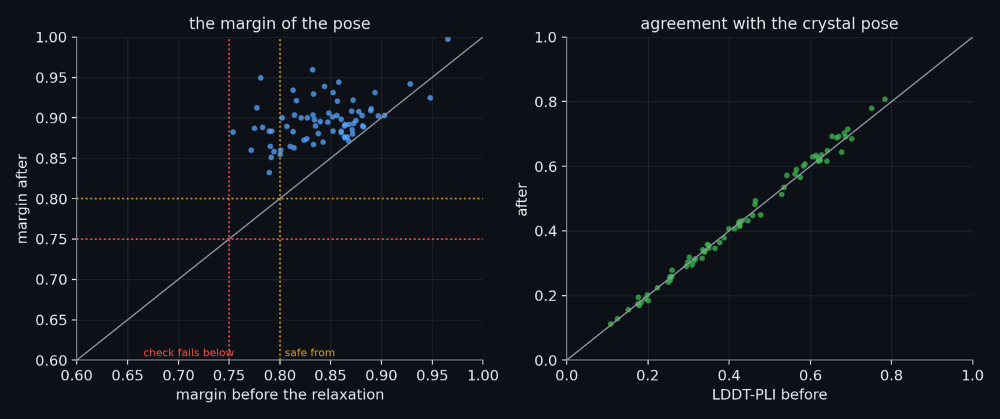

**Figure: Pose margins and agreement before and after the relaxation.** The force-field relaxation of the ligand in the frozen pocket, on 90 Boltz-2 poses of 30 crystal-anchored ligands. Left: the smallest relative distance between the ligand and the receptor (the margin of the scorer's PoseBusters call: the check fails below 0.75 and the project calls a pose safe from 0.8), before and after the relaxation, for the 73 poses that pass the checks both times; the share of poses passing all 22 checks rises from 81.1% to 98.9%, and the median margin from 0.847 to 0.893. Right: the LDDT-PLI against the crystal pose before and after, for the 73 poses that have both: the relaxation moves the ligand by 0.46 A at the median and leaves the agreement with the crystal pose unchanged on average (change +0.0035).

In [336]:
show_figure("struct_relaxation_margin")

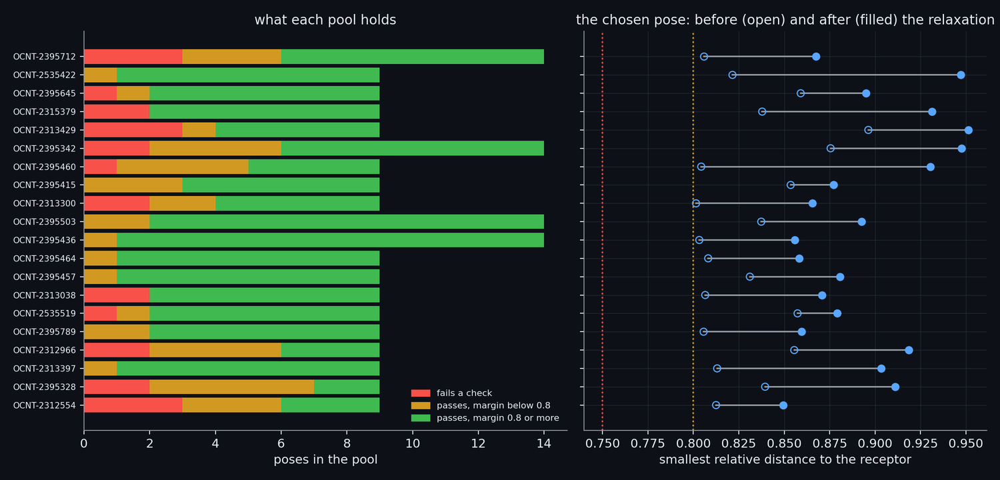

**Figure: The pose pools of the official ligands (held back).** The pools of poses of the 20 official ligands under the scorer's own PoseBusters call: 200 poses in all, 176 of them passing the 22 checks and 136 passing with a margin of at least 0.8. Left: for every ligand, how many poses of its pool fail a check (red), pass with a small margin (gold) and pass with a safe margin (green). Right: the margin of the pose that the recipe chose, before the force-field relaxation (open circle) and after it (filled), for the same ligands in the same order; the dotted lines are the limit of the check (0.75) and the floor of the project (0.8); the relaxation raises the margin for 20 of 20 ligands. This figure shows predictions for the blinded compounds and is held back until the challenge closes.

In [337]:
show_figure("struct_official20_pools")

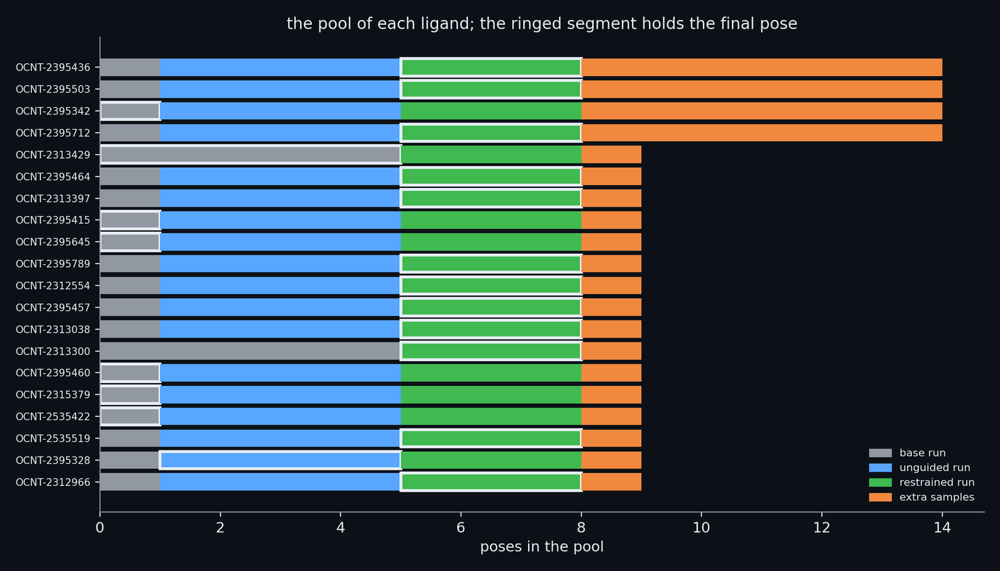

**Figure: The pool of each official ligand and the run of its final pose (held back).** What the pool of each of the 20 official ligands is made of (stacked bars: the base run, the unguided run, the restrained run that carries the iron-nitrogen restraint, and the extra samples) and which kind of run the final pose came from (the ringed segment). The poses are chosen by the recipe: among the valid poses with a margin of at least 0.8, the model's own ranking, the restrained run being read first for a ligand with a Type II donor. The final poses come from the restrained run for 12, base run for 7, unguided run for 1 ligands. This figure shows predictions for the blinded compounds and is held back until the challenge closes.

In [338]:
show_figure("struct_official20_recipe")

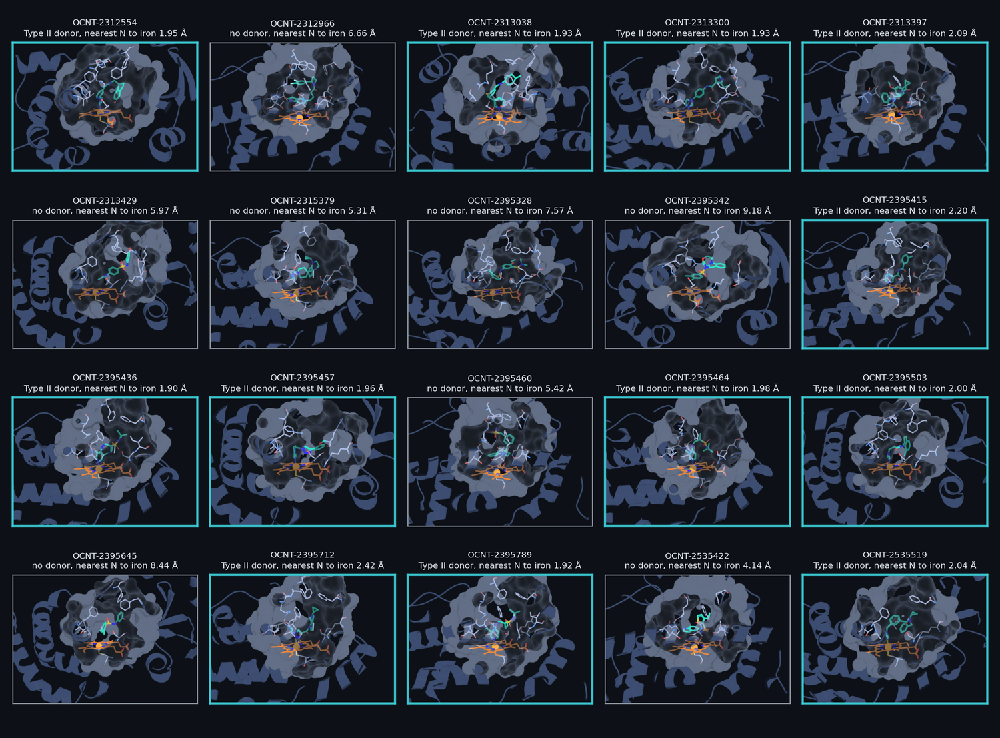

**Figure: Every submitted structure.** All 20 structures of the submitted zip, the pocket of each predicted complex with the heme (orange) and the ligand (teal). 12 ligands have a Type II donor nitrogen: the iron-nitrogen restraint was used for them and the nearest nitrogen is 1.90 to 2.42 angstrom from the iron. The other 8 ligands have no such donor and were run without the restraint; their nearest nitrogen is far from the iron, as it should be for ligands that do not bind it. All twenty pass the 22 PoseBusters checks under the organisers' own call. Nothing was left out of this picture.

In [339]:
show_figure("struct_all20_gallery")

## 11.11 Pharmacophore models of poses, and two biases that such models carry

> **Field:** Computational chemistry · Structural biology · Cheminformatics · Statistics

*Where this section sits:* 9.13 and 9.14 built, for the time-dependent inhibition track, fields and sites that say where the crystal ligands of CYP3A4 place their donors, acceptors, rings and hydrophobic groups, in the frame of the heme. Section 11.8 asked how to choose among the predicted poses of a ligand and tried a pharmacophore term of two distances written by hand. This section asks the same question with a pharmacophore *model*: a pose is put in the frame of its own heme and judged by where its features and atoms lie against what the crystals show. It also reports two checks of what such a model cannot see, the two biases named at the start of the work on it: that an ensemble of low-energy conformers over-represents low-energy states and can miss the bound one, and that a model read from complexes represents a holo pocket and says nothing of an apo or a cryptic one.

**The pose in the frame of its heme.** Every predicted complex has its own heme, and the frame of 9.13 (the iron at the origin, $z$ along the normal of the porphyrin plane on the side of the ligand, $x$ toward the pyrrole nitrogen NA) is found in it from the coordinates of the four nitrogens. The typed features of the ligand are taken at the coordinates of the pose, not of a conformer, and its heavy atoms are scored with the same field and the same sites as in 9.13 and 9.14: the **field score** (the mean occupancy at the heavy atoms plus the mean, over the families the ligand has, of the mean family field at its features), the **recall** (the weight of the sites that a feature of the ligand matches over the weight of all sites), the number of matched sites and the **precision** (the share of the typed features that lie in a sphere of a site of their own family). The fields and the sites are rebuilt for each scored ligand *without its own references*: the crystal ligands that are the same compound and, in the regime that stands for a novel scaffold and carries the gate, also every crystal ligand whose Morgan Tanimoto similarity to it is at least 0.5, the rule that was used for the shape prior of the same benchmark. Without that step a pose of ketoconazole would be scored against the crystal ligand ketoconazole, and the gate would read the answer from the key.

The score of a pose is a rank inside the pool of the poses of its ligand, with no weight fitted: the mean of the ranks of its field score and its recall (`pharmacophore_model`), and the mean of that rank and the rank of the minimum-Bayes-risk consensus of 11.8 (`pharmacophore_model_combined`). The gate is the bar of 11.8: over the pooled benchmark poses the **Spearman correlation** (the correlation of the ranks) between a score and minus the true RMSD, averaged over the ligands, exceeds 0.3 and is positive for at least 60% of the ligands. If a gate is met, whether the recipe may use the score is a second, paired test against the minimum-Bayes-risk pick, and only then.

In [340]:
# The numbers of 11.11: the gate lines of the pharmacophore model of the poses (job 272), the coverage of the bound conformation by the ensembles (job 273) and the checks of the pocket and of the support (job 274),
# every one read from the logs that those jobs left.
import re

import pandas as pd

s8_logs = ROOT / "data/structure_track/outputs/cyp3a4/logs"
gate_text = (s8_logs / "pose_pharmacophore_model.log").read_text()
novel_text = gate_text.split("regime compound")[0]
score_line = re.compile(r"^(pharmacophore_model_combined|pharmacophore_model|field|recall|precision|outside): mean Spearman rho ([+-][\d.]+), positive for (\d+)% of (\d+) ligands(?:, mean RMSD of the top-scored pose ([\d.]+) \(MBR ([\d.]+), random pose ([\d.]+)\))?", re.MULTILINE)
s8_scores = {name: {"rho": float(rho), "positive": int(positive), "n": int(n), "pick": float(pick) if pick else None, "mbr": float(mbr) if mbr else None, "random": float(rand) if rand else None} for name, rho, positive, n, pick, mbr, rand in score_line.findall(novel_text)}
s8_gates = dict(re.findall(r"STRUCTURE GATE pose_(pharmacophore_model(?:_combined)?) \(.*?\): (MET|NOT MET)", novel_text))
s8_crystal = re.search(r"information \(not a gate\), regime novel: .*?\n  field: (-?[\d.]+) / (-?[\d.]+) / (-?[\d.]+); the crystal pose scores above the mean of its pool for (\d+) of (\d+) ligands\n  recall: (-?[\d.]+) / (-?[\d.]+) / (-?[\d.]+); the crystal pose scores above the mean of its pool for (\d+) of (\d+) ligands", gate_text)
crystal_field, pool_field, best_field, crystal_field_above, crystal_n, crystal_recall, pool_recall, best_recall, crystal_recall_above = (float(s8_crystal.group(i)) for i in (1, 2, 3, 4, 5, 6, 7, 8, 9))
s8_pose_count = re.search(r"(\d+) poses of (\d+) ligands", gate_text)
n_gate_poses, n_gate_ligands = int(s8_pose_count.group(1)), int(s8_pose_count.group(2))
gate_met = [name for name, verdict in s8_gates.items() if verdict == "MET"]

conformer_text = (s8_logs / "conformer_bias.log").read_text()
c_evaluated = re.search(r"crystal ligand copies evaluated: (\d+) of (\d+) \((\d+) distinct ligands\)", conformer_text)
c_cover = re.search(r"a conformer within ([\d.]+) A of the crystal pose for (\d+)% of the copies; median nearest RMSD ([\d.]+) A", conformer_text)
c_windows = {int(w): (int(k), int(n), int(p)) for w, k, n, p in re.findall(r"within (\d+) kcal/mol of the lowest conformer for (\d+) of (\d+) covered copies \((\d+)%\)", conformer_text)}
c_block = re.search(r"a member within ([\d.]+) A of the crystal pose for (\d+)% of the (\d+) copies; median nearest RMSD ([\d.]+) A", conformer_text)
c_needed = re.search(r"median energy that the bound state needs ([\d.]+) kcal/mol, 90th percentile ([\d.]+) kcal/mol", conformer_text)
c_verdict = re.search(r"CONFORMER CHECK block_ensemble_covers_the_bound_state .*: (YES|NO)", conformer_text).group(1)
c_poses = re.search(r"farther than 1.0 A for (\d+)%, farther than 2.0 A for (\d+)%", conformer_text)
n_copies, n_copies_all, n_ligands_cb = (int(v) for v in c_evaluated.groups())
bias_table = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/conformer_bias.csv")
bias_done = bias_table[bias_table.nearest_rmsd.notna()]
size_covered, size_missed = float(bias_done[bias_done.nearest_rmsd <= 1.0].n_heavy.median()), float(bias_done[bias_done.nearest_rmsd > 1.0].n_heavy.median())
share_300, median_rmsd_300 = int(c_cover.group(2)), float(c_cover.group(3))
share_block, median_rmsd_block = int(c_block.group(2)), float(c_block.group(4))
needed_median, needed_p90 = float(c_needed.group(1)), float(c_needed.group(2))
poses_beyond_1, poses_beyond_2 = (int(c_poses.group(1)), int(c_poses.group(2))) if c_poses else (None, None)

site_text = (s8_logs / "site_representation.log").read_text()
v_site = re.search(r"(\d+) crystal copies, (\d+) core residues .*? median ([\d.]+) A, 90th percentile ([\d.]+) A, 95th percentile ([\d.]+) A", site_text)
v_pred = re.search(r"predicted pockets: (\d+) of (\d+) poses compared; .*? median ([\d.]+) A, (\d+)% beyond the flag; Spearman rho with the true RMSD of the pose ([+-][\d.]+) over all poses", site_text)
v_support = re.search(r"crystal copies \(fields built without their compound\) median ([\d.]+), 95th percentile ([\d.]+)", site_text)
v_beyond = re.search(r"predicted poses beyond the cut: (\d+)% of (\d+); Spearman rho of the outside share with the true RMSD ([+-][\d.]+) over all poses", site_text)
n_core = int(v_site.group(2))
nn_median, nn_p90, pocket_flag = (float(v_site.group(i)) for i in (3, 4, 5))
pred_median, pred_beyond_share, pred_rho = float(v_pred.group(3)), int(v_pred.group(4)), float(v_pred.group(5))
support_median, support_cut = float(v_support.group(1)), float(v_support.group(2))
support_beyond_share, support_rho = int(v_beyond.group(1)), float(v_beyond.group(3))

s8_table = pd.DataFrame([{"score": name, "mean rho with minus the true RMSD": values["rho"], "ligands with a positive rho": f"{values['positive']}%", "RMSD of the top-scored pose": values["pick"] if values["pick"] is not None else float("nan"),
                          "gate": s8_gates.get(name, "information")} for name, values in s8_scores.items()])
mbr_pick = next(v["mbr"] for v in s8_scores.values() if v["mbr"] is not None)
random_pick = next(v["random"] for v in s8_scores.values() if v["random"] is not None)
s8_table.round(3)

The pool is the one of 11.8: 104 poses of 10 benchmark ligands, with the true RMSD of each. The table gives, for each score, the mean correlation and the share of ligands in which it is positive; the pick of `pharmacophore_model` has a mean RMSD of 4.20 Å and that of `pharmacophore_model_combined` of 4.09 Å, against 4.12 Å for the minimum-Bayes-risk pick and 3.98 Å for a random pose. The gate is met for **neither score**. A score that fails its gate is written down as a negative result and is not tuned: the score was not changed after its first run.

*A model that cannot tell the bound pose from a predicted one cannot rank poses.* For the benchmark ligands whose crystal entries are in the reference set, the crystal pose was scored in the same way, with the fields built without its own compound. The field score of the crystal pose is 0.79 on average, against 0.90 for the poses of the pool and 0.89 for the predicted pose closest to the crystal; its recall is 0.22 against 0.26 and 0.23. The crystal pose scores above the mean of its pool for 2 of 10 ligands by field score and for 5 of them by recall. A pose that lies in the right region (every predicted pose is close to the heme, as every crystal pose is) fills the same fields as the true pose does; the fields are broad, they were built to say where ligands sit and not how, and at that resolution a pool of poses that differ by a few ångströms cannot be told apart.

**First bias: the conformers that an ensemble holds.** A **conformer** is one three-dimensional shape of a molecule, and a flexible molecule has very many. An ensemble generator (ETKDG here, which draws shapes from the distances and torsion angles seen in crystals, then relaxes each with the force field MMFF) keeps those of low energy, since a molecule in solution is mostly in them. The ensembles of 9.13 and 9.14 hold up to twelve conformers within 5 kcal/mol of the lowest. But a ligand in a pocket is held by the protein, and the shape that fits can cost energy: the bound conformer is often not the lowest. A model that places and describes only low-energy shapes then over-represents them and can miss the one that matters. The check measures it directly on the crystal ligands, whose bound shapes are known. For each of 131 crystal ligand copies (89 distinct ligands; 17 could not be treated) 300 conformers were generated, the heavy-atom RMSD (symmetry aware) of the nearest to the crystal pose was found, and its energy above the lowest. A conformer within 1.0 Å of the crystal pose exists among the 300 for 15% of the copies (the median nearest RMSD is 1.70 Å); among those, the bound state lies within 5 kcal/mol of the lowest conformer for 89%, within 10 for 95% and within 20 for 100%, and the median energy that it needs is 0.0 kcal/mol (90th percentile 2.5). The ensemble of the block itself, twelve conformers within 5 kcal/mol, contains a member within 1.0 Å of the crystal pose for 12% of the copies (median nearest RMSD 2.45 Å). The registered question is whether at least 80% are covered, and the answer is **NO**. The verdicts of the pocket block and of the site model, in 9.13 and 9.14, were therefore reached with an ensemble that misses the bound conformation of 88% of the crystal ligands, and they are reported with that sentence. The copies that are not covered by the 300 conformers have a median of 38 heavy atoms against 23 for those that are: a whole-molecule RMSD of 1 Å between a vacuum conformer and a bound pose is a demanding test for a large flexible molecule, and the check measures how often the bound state is reached, not whether the ensemble is good for the small ones. For the 104 predicted poses of the gate, the nearest conformer of the ensemble of 11.8 (within 8 kcal/mol) is 62% farther than 1.0 Å and 18% farther than 2.0 Å: a predicted pose often resembles no conformer of the low-energy ensemble, which is what a bound shape that costs energy looks like from the side of the ensemble. For that reason the pharmacophore of a predicted pose is reported for the pool of its poses and not only for the top one.

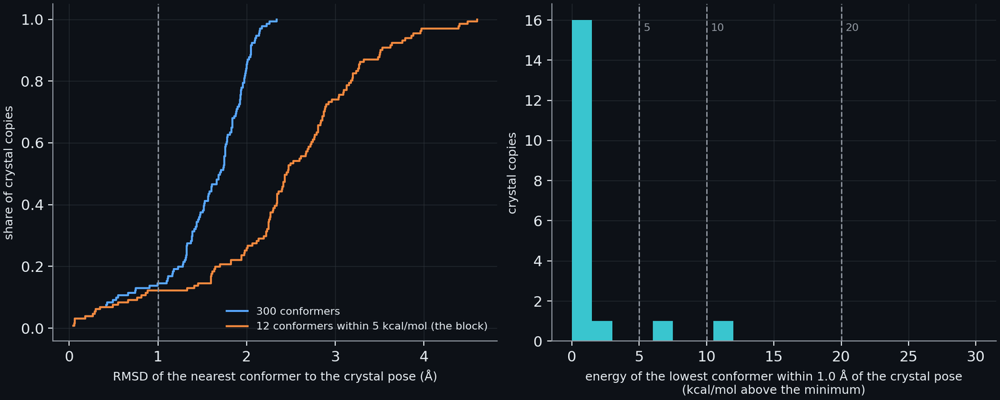

**Figure: Does a low-energy ensemble contain the bound conformation?.** Does a low-energy ensemble contain the bound conformation? For 131 crystal ligand copies of the CYP3A4 reference set (89 distinct ligands) the heavy-atom RMSD of the nearest conformer to the crystal pose: of 300 conformers and of the 12 conformers within 5 kcal/mol that the pocket block uses (left, cumulative; the dashed line is 1.0 Å). 15% of the copies have a conformer within 1.0 Å among the 300, 12% among the 12. For the copies that have one, the energy of the lowest such conformer above the global minimum (right): 89% lie within 5 kcal/mol, 95% within 10 and 100% within 20 (MMFF, in vacuum, so the energies are indicative).

In [341]:
show_figure("struct_conformer_window")

**Second bias: a pocket that the references do not show.** The fields and the sites are **holo**: they are read from ligands in complexes, and a holo model says where ligands sit, not what the pocket looks like before a ligand arrives (the **apo** state) or in a state that no crystal shows (a **cryptic pocket**, which opens only on binding, or for ligands of a kind not yet crystallised). CYP3A4 is a flexible enzyme, so the question is real. Three measurements, none a gate, give the size of the problem as far as the data allow. The variability of the site: the pocket C-alpha atoms of the 62 residues that at least 90% of the crystal copies share were superposed by the Kabsch method (the rigid motion that minimises the RMSD) and each copy compared with the nearest copy of another PDB entry and another ligand; the median is 0.22 Å, the 90th percentile 0.37 Å and the 95th percentile 0.40 Å, which is the flag of an unseen pocket conformation. The pockets of the 104 predicted complexes lie 0.18 Å from the nearest crystal pocket at the median (their own compound left out), 0% of them beyond the flag, and their distance correlates with the true RMSD of the pose with a Spearman correlation of -0.05. The support of the fields: for the crystal poses the share of heavy atoms where the occupancy field built without their compound is below 0.05 is 0.000 at the median and 0.395 at the 95th percentile, the cut at which a pose leaves the region where ligands have been seen; 0% of the predicted poses are beyond it, and the share of atoms outside the support correlates with the true RMSD with +0.24.

**What these measurements do and do not say.** They say that, by their backbone, the predicted pockets are inside the range that the crystals span: the median distance of a predicted pocket to the nearest crystal pocket (0.18 Å) is of the size of the spread among the crystals themselves (0.22 Å). They cannot say more. The C-alpha atoms of the core residues are a coarse description of a pocket, since what opens a cryptic pocket is a side chain turning or a loop moving, and the residues that move are exactly those that fewer than 90% of the entries share and that are left out of the core. A pocket that Boltz-2 shapes around a ligand can be plausible or spurious, and the predicted complex alone cannot say which. A cryptic pocket that no entry shows is, by construction, outside what fields read from 113 entries of one enzyme can represent. Both flags are therefore carried by every official pose as a mark to read it with care, and nothing is corrected by them.

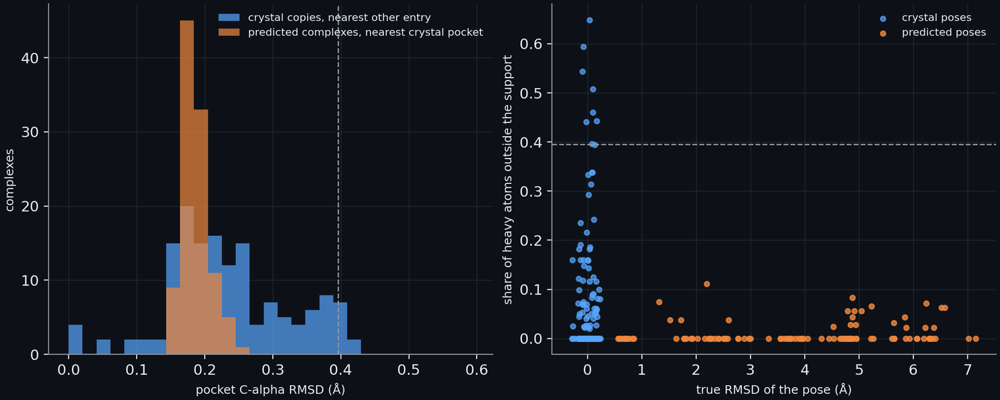

**Figure: How far is a pocket, and a pose, from what the crystal ligands have shown?.** How far is a pocket, and a pose, from what the crystal ligands have shown? Left: the pocket C-alpha RMSD (the 62 residues most entries share) of each crystal copy to the nearest copy with another PDB code and ligand, and of each of the 104 predicted complexes of the benchmark pools to the nearest crystal pocket (its own compound left out); the dashed line is the 95th percentile of the crystal distribution (0.40 Å), beyond which a pocket would be flagged as unseen. Right: the share of heavy atoms outside the support of the fields built without the compound, for the crystal poses (at 0 Å on the horizontal axis) and for the predicted poses against their true RMSD; the dashed line is the 95th percentile of the crystal poses (0.40). Both measures are coarse: a backbone that agrees with the crystal says little about the side chains and loops that shape a cryptic pocket.

In [342]:
show_figure("struct_site_check")

**The expected pharmacophore of the 20 official ligands.** For each official ligand the same machinery gives what its final submitted pose offers to the pocket, and what its pool of valid poses says about how certain that is: the typed features with their coordinates in the frame of the heme; the distance of the Type II donor nitrogen to the iron or of the most easily oxidised carbon; the site model of the pocket against the pose (field score, recall, matched sites, precision), with the references of the ligand and of its analogues left out; for each site matched by the final pose the share of the pool's poses that match it, and the spread of the feature positions across the pool; the receptor side of the final complex (for each donor and acceptor the nearest polar protein atom within 3.5 Å or the iron within 2.6 Å, for each ring and hydrophobic group the residues within 4.5 Å, and a flag for a buried polar feature without a partner); a common-feature model of the 20 poses, the sites at which at least 14 of them place a feature of the same family within 1.5 Å; and the two flags of the second bias. These are predictions for the blinded ligands, and they are held back until the challenge has closed: the folder `pharmacophore_official20` and the figure that shows it are not published before then, and the cells of this section that read them are marked so that the public edition of the notebook shows only a note in their place.

In [343]:
# The expected pharmacophore of the 20 official ligands (job 925; HELD BACK: it describes predicted poses of blinded ligands), read from the folder that the job wrote.
import pandas as pd

official_dir = ROOT / "data/structure_track/outputs/cyp3a4/pharmacophore_official20"
official = pd.read_csv(official_dir / "summary.csv")
common_model = pd.read_csv(official_dir / "common_sites.csv")
receptor = pd.read_csv(official_dir / "receptor_side.csv")
n_official = len(official)
n_common = len(common_model)
n_flag_pocket, n_flag_support = int(official.beyond_pocket_flag.sum()), int(official.beyond_support_cut.sum())
n_outside_ensemble, n_strained = int(official.outside_ensemble.sum()), int(official.strained.sum())
n_unsatisfied = int((receptor.unsatisfied.astype(bool)).sum())
donor_ligands = official[official.donor_error.notna()]
median_donor_error = float(donor_ligands.donor_error.median()) if len(donor_ligands) else float("nan")
median_recall, median_pool_spread = float(official.recall.median()), float(official.pool_spread.median())
show_table(official[["ligand", "features", "donor_error", "site_error", "recall", "matched", "precision", "pool_recall_mean", "pool_spread", "conf_rmsd", "pocket_rmsd", "unsatisfied_polar"]].round(2), floatfmt=".2f")

| ligand | features | donor_error | site_error | recall | matched | precision | pool_recall_mean | pool_spread | conf_rmsd | pocket_rmsd | unsatisfied_polar |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| OCNT-2395436 | 9 | 0.17 | nan | 0.36 | 4.00 | 0.44 | 0.36 | 0.38 | 1.55 | 0.18 | 0 |
| OCNT-2395503 | 8 | 0.14 | nan | 0.43 | 5.00 | 0.62 | 0.28 | 0.46 | 1.27 | 0.17 | 0 |
| OCNT-2395342 | 9 | nan | 2.17 | 0.00 | 0.00 | 0.00 | 0.07 | 2.53 | 1.56 | 0.15 | 0 |
| OCNT-2395712 | 7 | 1.01 | nan | 0.28 | 3.00 | 0.43 | 0.17 | 2.68 | 2.14 | 0.18 | 0 |
| OCNT-2313429 | 9 | nan | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 | 1.35 | 1.26 | 0.21 | 4 |
| OCNT-2395464 | 8 | 0.11 | nan | 0.25 | 3.00 | 0.38 | 0.28 | 0.88 | 1.68 | 0.16 | 0 |
| OCNT-2313397 | 10 | 0.04 | nan | 0.53 | 6.00 | 0.60 | 0.61 | 0.44 | 1.56 | 0.18 | 0 |
| OCNT-2395415 | 8 | 0.09 | nan | 0.20 | 2.00 | 0.25 | 0.23 | 0.71 | 0.56 | 0.18 | 1 |
| OCNT-2395645 | 10 | nan | 0.00 | 0.06 | 1.00 | 0.10 | 0.03 | 1.24 | 0.32 | 0.19 | 0 |
| OCNT-2395789 | 8 | 0.16 | nan | 0.30 | 3.00 | 0.38 | 0.31 | 0.41 | 1.24 | 0.18 | 1 |
| OCNT-2312554 | 12 | 0.16 | nan | 0.47 | 5.00 | 0.42 | 0.50 | 0.73 | 1.63 | 0.16 | 2 |
| OCNT-2395457 | 10 | 0.18 | nan | 0.37 | 4.00 | 0.40 | 0.40 | 0.63 | 1.13 | 0.18 | 2 |
| OCNT-2313038 | 10 | 0.15 | nan | 0.20 | 2.00 | 0.20 | 0.35 | 2.31 | 1.56 | 0.17 | 0 |
| OCNT-2313300 | 10 | 0.17 | nan | 0.36 | 4.00 | 0.40 | 0.30 | 0.89 | 0.61 | 0.16 | 0 |
| OCNT-2395460 | 10 | nan | 0.00 | 0.00 | 0.00 | 0.00 | 0.06 | 2.06 | 2.08 | 0.20 | 1 |
| OCNT-2315379 | 6 | nan | 4.31 | 0.06 | 1.00 | 0.17 | 0.12 | 0.92 | 2.55 | 0.21 | 2 |
| OCNT-2535422 | 10 | nan | 0.00 | 0.00 | 0.00 | 0.00 | 0.02 | 1.17 | 0.68 | 0.21 | 2 |
| OCNT-2535519 | 11 | 0.09 | nan | 0.53 | 6.00 | 0.55 | 0.54 | 0.54 | 2.12 | 0.16 | 0 |
| OCNT-2395328 | 12 | nan | 4.63 | 0.20 | 2.00 | 0.17 | 0.15 | 0.94 | 1.65 | 0.15 | 2 |
| OCNT-2312966 | 14 | nan | 5.90 | 0.10 | 1.00 | 0.07 | 0.06 | 0.45 | 1.48 | 0.19 | 0 |

For the 20 official poses the median recall of the sites is 0.23; the pharmacophore moves by 0.89 Å at the median across the valid poses of the pool; the common-feature model has 1 sites; the Type II donors lie within 0.16 Å of the ideal distance to the iron at the median. Of the 20 poses 0 lie beyond the pocket flag, 0 beyond the support cut, 16 are farther than 1.0 Å from every conformer of the low-energy ensemble and 0 are strained by the registered criterion (an energy of the nearest conformer more than 10 kcal/mol above the lowest, which the ensemble of 8 kcal/mol cannot show; the distance to the ensemble is the usable measure); the receptor side lists 17 buried polar features without a partner. The model of 11.11 was not used to choose any of these poses (its gate decides that, above); this is a description of the chosen poses, with the uncertainty that the pool and the flags give, and not a measure of their accuracy, which only the organisers can make.

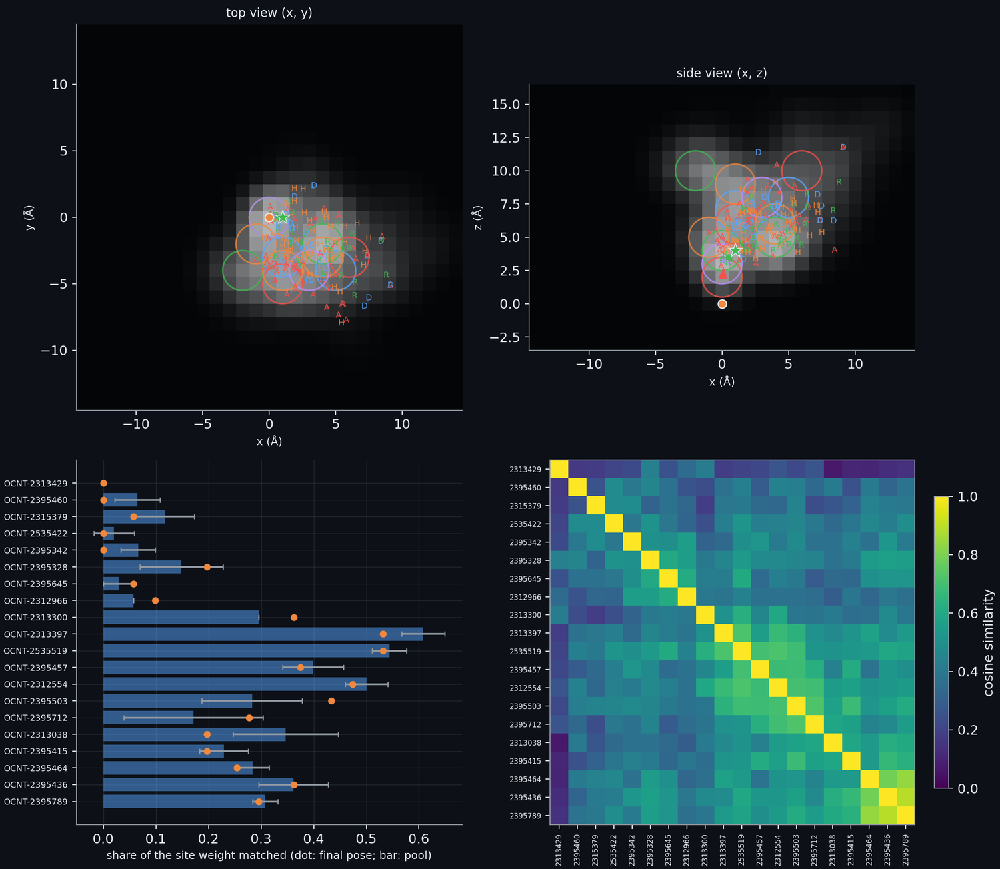

**Figure: The expected pharmacophore of the 20 official ligands.** The expected pharmacophore of the 20 official ligands, from their final submitted poses in the frame of the heme (the iron is the orange dot). Top: the typed features of all final poses (small letters: D donor, A acceptor, R aromatic ring, H hydrophobe, + and − ionisable) over the heavy-atom occupancy of the crystal ligands (grey), seen from above the heme and from the side; rings are the sites of the crystal model and stars the 1 sites at which at least 14 of the 20 poses place a feature of the same family. Bottom left: for each ligand the share of the site weight that its final pose matches (dot) and the mean over the pool of its valid poses (bar, one standard deviation); a cross marks a pose beyond a flag of the check of the binding-site representation. Bottom right: the similarity of the 20 feature fields, ordered by clustering.

In [344]:
show_figure("struct_pharm_official20")

*On what actually ran.* `cypmode/validation/pose_pharmacophore.py` (`pose_in_frame`, `score_pose`, `kept_indices`, `fields_and_sites`, `evaluate`, `gate`, `use_test`, `crystal_scores`) is the model and its gate, run by the job `272_pose_pharmacophore_gate`; `cypmode/validation/conformer_bias.py` is the first check, run by `273_conformer_bias`; `cypmode/validation/site_representation.py` is the second, run by `274_site_representation`, and it writes the two flags; `cypmode/validation/official_pharmacophore.py` describes the 20 official poses in the final chain, in the job `925_official_pharmacophore`. The frame of a heme from its four nitrogens is `frame_from_nitrogens` of `cypmode/challenge/pocket_pharmacophore.py`. The tests are `tests/test_pose_pharmacophore.py` (the gate and its rule on poses that track the true RMSD and on noise, the leave-out of the scored ligand and its analogues, the crystal pose), `tests/test_conformer_bias.py` (a crystal pose that is the lowest or a strained conformer, the consequence rule), `tests/test_site_representation.py` (the Kabsch RMSD, the core residues, the nearest other entry) and `tests/test_official_pharmacophore.py` (the common sites, the similarity, the receptor side), and the figures are tested on synthetic files in `tests/test_structure_pharmacophore_figures.py`. The conformer ensembles of this part and of 9.13 and 9.14 are drawn with the seed 42: in the installed version of RDKit the seed 0 returns the same conformer for every draw, which turned the first run of the pocket block into a run with one conformer per compound, was found while this check was being prepared, and is why that first run is kept in the logs as a record and not as a verdict. The limits are written next to each result; the largest is that the model describes where a pose lies against ligands that were seen, so that it can reward a pose for being like the references and cannot reward it for being right where they are silent.

## 11.12 The official set corrected: three ligands that came without their stereochemistry

> **Field:** Chemistry · Structural biology · Cheminformatics · Mathematics (vectors)

*Where this section sits:* sections 11.1 to 11.11 treated the 20 ligands of the structure track as given. On 2026-10-24 the organisers corrected the file that lists them: three of the 20 had been published without their stereochemistry. This section tells what that is, why a predicted pose carries it, why the check that the scorer applies to a pose cannot see it, and what was done in the structure track once the file was corrected. Section 2.1 showed what a stereocentre is and that a flat SMILES cannot tell an enantiomer from its mirror image; this section uses that and goes on to the three-dimensional pose.

**What was wrong.** A carbon with four different neighbours exists in two forms that are mirror images (**enantiomers**, section 2.1), and the marks `@` and `@@` of a SMILES say which one is meant. When the marks are absent the SMILES describes both at once. A mixture of equal parts of the two enantiomers is a **racemate**, and the organisers used racemic samples of three of the ligands in the assay, which is why their SMILES carried no marks. The structures that the submissions are scored against are of one enantiomer each, so the file for the structure track was changed to the SMILES of the models that are used for scoring, and the participants were asked to use those. The correction was reported by a participant on the discussion channel of the challenge and confirmed by the organisers; the two files of the time-dependent inhibition track and the training files are unchanged (the same checksums).

**What a pose says about it.** A pose is a list of coordinates, and at a stereocentre the neighbours lie in space in one of two arrangements that are mirror images. Take the centre at position $\mathbf{p}$ and three of its neighbours, in a fixed order, at $\mathbf{a}$, $\mathbf{b}$ and $\mathbf{c}$ (the fourth neighbour, a hydrogen that is not drawn, lies opposite the other three). The signed volume of the three vectors from the centre,

$$V = (\mathbf{a}-\mathbf{p}) \cdot \big[(\mathbf{b}-\mathbf{p}) \times (\mathbf{c}-\mathbf{p})\big],$$

is a number; $\cdot$ is the dot product of two vectors (a number) and $\times$ their cross product (a vector perpendicular to both). $V$ does not change when the molecule is moved or turned and changes sign when it is reflected, since a reflection turns a right-handed set of three vectors into a left-handed one. RDKit reads the chirality of a pose from this sign (`AssignStereochemistryFrom3D`), and the function `reproduces_stereo` of `cypmode/validation/pose_stereo.py` then asks whether the SMILES of the compound, with its marks, matches the pose as a substructure query with the chirality switched on; a SMILES without marks is matched by either arrangement. The cell shows it on a public drug that is not part of the challenge.

In [345]:
# A pose has a handedness. The molecule below is a public drug that is not part of the challenge (ibuprofen, one stereocentre): the two enantiomers are written, a pose of each is made as the co-folding
# models make theirs (heavy atoms with coordinates, no hydrogens), and the handedness is read back from the coordinates in two ways: the sign of the signed volume of the three neighbours of the centre, and the
# function that the recipe uses (`reproduces_stereo` of `cypmode/validation/pose_stereo.py`).
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem
from cypmode.validation.pose_stereo import reproduces_stereo

demo_smiles = {"first enantiomer": "CC(C)Cc1ccc(cc1)[C@H](C)C(=O)O", "second enantiomer": "CC(C)Cc1ccc(cc1)[C@@H](C)C(=O)O"}
no_marks = "CC(C)Cc1ccc(cc1)C(C)C(=O)O"

def pose_of(smiles, mirrored=False):
    mol = Chem.AddHs(Chem.MolFromSmiles(smiles))
    AllChem.EmbedMolecule(mol, randomSeed=42)
    if mirrored:
        conformer = mol.GetConformer()
        for i in range(mol.GetNumAtoms()):
            x, y, z = conformer.GetAtomPosition(i)
            conformer.SetAtomPosition(i, (-x, y, z))
    return Chem.RemoveHs(mol)

def signed_volume(mol):
    centre = next(a for a in mol.GetAtoms() if a.GetChiralTag() != Chem.ChiralType.CHI_UNSPECIFIED)
    xyz = mol.GetConformer().GetPositions()
    p = xyz[centre.GetIdx()]
    a, b, c = (xyz[n.GetIdx()] - p for n in sorted(centre.GetNeighbors(), key=lambda n: n.GetIdx())[:3])
    return float(np.dot(a, np.cross(b, c)))

rows = []
for label, smiles in demo_smiles.items():
    for mirrored in (False, True):
        pose = pose_of(smiles, mirrored)
        Chem.AssignStereochemistryFrom3D(pose)
        rows.append({"molecule": label, "pose": "mirrored" if mirrored else "as written", "label from the coordinates": Chem.FindMolChiralCenters(pose, useLegacyImplementation=False)[0][1],
                     "sign of the volume": "+" if signed_volume(pose) > 0 else "-",
                     "carries the written stereochemistry": reproduces_stereo(pose, smiles), "carries the other one": reproduces_stereo(pose, list(demo_smiles.values())[1 - list(demo_smiles).index(label)]),
                     "carries the SMILES without marks": reproduces_stereo(pose, no_marks)})
demo_table = pd.DataFrame(rows)
show_table(demo_table)
demo_flips = bool((demo_table.groupby("molecule")["sign of the volume"].nunique() == 2).all())
demo_mirror_is_other = bool(demo_table.loc[demo_table.pose == "mirrored", "carries the other one"].all() and not demo_table.loc[demo_table.pose == "mirrored", "carries the written stereochemistry"].any())
demo_marks_accept_both = bool(demo_table["carries the SMILES without marks"].all())
assert demo_flips and demo_mirror_is_other and demo_marks_accept_both  # a failing cell fails the build

| molecule | pose | label from the coordinates | sign of the volume | carries the written stereochemistry | carries the other one | carries the SMILES without marks |
| --- | --- | --- | --- | --- | --- | --- |
| first enantiomer | as written | S | + | True | False | True |
| first enantiomer | mirrored | R | - | False | True | True |
| second enantiomer | as written | R | - | True | False | True |
| second enantiomer | mirrored | S | + | False | True | True |

In [346]:
# The numbers of 11.12, read from the files that the job 275 left: the ledger of the runs that were set aside, the poses of those runs read again for their stereochemistry, the table of the new pools and the
# check of the final zip. No official ligand is named in the output.
import json, re
from pathlib import Path
import posebusters
from cypmode.validation import pose_stereo as ps_module

official_path = ROOT / "data/structure_track/inputs/structure_track_test_blinded.csv"
official_table = pd.read_csv(official_path)
smiles_of = dict(zip(official_table.Molecule_Name, official_table.SMILES))
n_official = len(official_table)
n_specified = sum(ps_module.has_stereo(s) for s in official_table.SMILES)
n_open_now = sum(bool(ps_module.unspecified_stereo(s)) for s in official_table.SMILES)

config_dir = Path(posebusters.__file__).parent / "config"
def stereo_checks(name):
    return re.findall(r'^\s+stereo\w*:\s*"([^"]+)"', (config_dir / name).read_text(), re.MULTILINE)
dock_checks, redock_checks = stereo_checks("dock.yml"), stereo_checks("redock.yml")

set_aside = ROOT / "data/structure_track/outputs/out/superseded_racemic"
ledger = json.loads((set_aside / "ledger.json").read_text())[0]
corrected = ledger["ligands"]
n_corrected = len(corrected)
n_runs_set_aside = sum(len(v) for v in corrected.values())
old_flags = []
for folder in sorted((set_aside / "boltz").glob("boltz_results_cyp3a4_*")):
    ligand = folder.name.removeprefix("boltz_results_cyp3a4_").split("-")[0] + "-" + folder.name.removeprefix("boltz_results_cyp3a4_").split("-")[1]
    for cif in sorted(folder.glob("predictions/*/*.cif")):
        old_flags.append(ps_module.cif_reproduces_stereo(cif, smiles_of[ligand]) is True)
n_old, n_old_right = len(old_flags), int(sum(old_flags))
n_old_other = n_old - n_old_right

pools = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/final/official_posebusters_pools.csv")
new_pools = pools[pools.ligand.isin(list(corrected))]
n_new, n_new_right = len(new_pools), int(new_pools.stereo_ok.astype(bool).sum())
n_pool_valid_eligible = int((new_pools.passed.astype(bool) & new_pools.stereo_ok.astype(bool)).sum())

check_text = (ROOT / "data/structure_track/outputs/cyp3a4/logs/stereo_check.log").read_text()
zip_line = re.search(r"STEREO CHECK structures_final\.zip: (PASS|FAIL) \((\d+) of (\d+)", check_text)
zip_pass, n_zip_ok, n_zip = zip_line.group(1) == "PASS", int(zip_line.group(2)), int(zip_line.group(3))
file_line = re.search(r"STEREO CHECK official file has no unspecified stereo element: (PASS|FAIL)", check_text)
file_pass = file_line.group(1) == "PASS"
assert n_open_now == 0 and file_pass and zip_pass and n_zip_ok == n_zip == n_official  # a failing cell fails the build

The table shows that the two enantiomers have volumes of opposite sign, that a mirrored pose carries the other one and not the written one, and that the SMILES without marks accepts both (`demo_flips`, `demo_mirror_is_other` and `demo_marks_accept_both` are checked by the build). A protein is made of one hand of amino acids and its pocket is itself chiral, so the two enantiomers of a ligand do not fit it in the same way, like a left and a right hand in the same glove; a pose of the wrong enantiomer is a pose of another molecule.

**Why the scorer's check does not see it.** A co-folding model that is given a SMILES without marks has to draw one of the two arrangements and does so by the shape it starts from, so nothing in the input keeps its samples to one. The samples of the three ligands that had been made from the racemic SMILES were read again from their coordinates: of 27 poses, 19 carry the stereochemistry of the corrected SMILES and 8 the other. The poses of the other enantiomer are not marked by the scorer's PoseBusters call either. PoseBusters has a configuration for each use; the one that the organisers call, `dock`, contains 0 checks of stereochemistry, and the configuration for re-docking, `redock`, contains 3 (double bond stereochemistry, tetrahedral chirality, stereochemistry preserved), since it compares the pose with a reference that has a geometry. The scorer has no reference geometry to compare with, so a pose of the wrong enantiomer passes every check with the margin of the right one, and the only penalty for it is in the quantities that measure the geometry (the RMSD of the ligand and the LDDT-PLI), where a mirrored centre moves atoms by a few ångström. The gates of the structure track had been measured on crystal ligands whose SMILES carry their marks, so the official ligands were the only run with a racemic input.

**What was registered before the rerun.** (a) Every run of the three ligands is made again from the corrected SMILES, and the earlier runs are set aside unchanged, with the entries that made the batch runner skip them, so that no sample of these ligands derives from a racemic input (`cypmode/validation/stereo_rerun.py`: a run is stale when the SMILES of its input file is not the official one, as a canonical isomeric SMILES). (b) A pose is eligible for the submission only when it carries the official stereochemistry; when a ligand has no eligible valid pose the recipe stops with an error and does not fill the place with a pose of the other enantiomer (`final_recipe`, through the column `stereo_ok` that `pose_margins` writes for every pose of every pool). (c) The rest of the recipe is unchanged: the gates are not run again, and the choice among eligible poses is the registered one. (d) The audit and the pre-submission gate check that all 20 submitted poses carry the official stereochemistry (`cypmode/audit/pre_submission.py`), the relaxation of the final poses is rejected when it would break it (`relax_final`), the pharmacophore of the official ligands is read from the eligible poses only (`official_pharmacophore`), and a test asserts that the official file leaves no stereocentre open.

In [347]:
print(f"{n_specified} of {n_official} official ligands carry stereo marks, {n_open_now} leave a centre open; {n_corrected} ligands corrected, {n_runs_set_aside} runs set aside ({n_old} poses, {n_old_other} of the other enantiomer); "
      f"new pools {n_new} poses, {n_new_right} with the official stereochemistry, {n_pool_valid_eligible} eligible; final zip {n_zip_ok} of {n_zip}")

4 of 20 official ligands carry stereo marks, 0 leave a centre open; 3 ligands corrected, 11 runs set aside (27 poses, 8 of the other enantiomer); new pools 27 poses, 15 with the official stereochemistry, 12 eligible; final zip 20 of 20


**What the rerun gave.** The file now leaves 0 of 20 ligands with a centre open (4 carry marks); 3 ligands were corrected and 11 of their runs set aside. Of the 27 poses of their new pools, 15 carry the official stereochemistry and 12 are also valid under the scorer's call, so that the model does not keep to the stereochemistry that it is given, and the eligibility rule is what keeps the poses of the other enantiomer out. The check of the final zip finds 20 of 20 poses of the official stereochemistry, and the check of the file finds no open centre.

In [348]:
# The poses that changed in the new draw (held back: they are results for the blinded compounds).
picks = pd.read_csv(ROOT / "data/structure_track/outputs/cyp3a4/final/stereo_picks.csv")
n_picks_changed = int(picks.changed.sum())
changed_picks = picks[picks.changed]
median_pick_rmsd = float(changed_picks.ligand_rmsd.median()) if len(changed_picks) else float("nan")
largest_fe_change = float((changed_picks.fe_n_new - changed_picks.fe_n_old).abs().max()) if len(changed_picks) else float("nan")
print(f"{n_picks_changed} of {len(picks)} chosen poses are not the earlier ones")

3 of 20 chosen poses are not the earlier ones


Of the 20 poses chosen by the unchanged rule, 3 are not the poses that the racemic runs gave; for those the ligand moved by 4.42 Å at the median between the two picks (pocket-aligned, symmetry-aware), and the largest change of the iron-nitrogen distance of a Type II ligand is 0.07 Å. A new draw from a model gives a different pose even from the same input, so a change of pose is the expected result of the rerun and not a finding; it is reported so that nothing in the notebook, the figures or the film quotes a pose of the racemic runs.

In [349]:
# What happened to the affinity step of the three base runs of job 275 (11.12), read from the logs: the memory warning of the base runs, and the checks that job 277 made after it ran the missing step again.
base_log = (ROOT / "data/structure_track/outputs/cyp3a4/logs/stereo_base_runs.log").read_text()
n_oom = base_log.count("ran out of memory, skipping batch")
verify_text = (ROOT / "data/structure_track/outputs/cyp3a4/logs/affinity_retry_verify.log").read_text()
n_retried_unchanged = len(re.findall(r"structure files byte-identical", verify_text))
n_retried_changed = verify_text.count("CHANGED")
table_line = re.search(r"base table: (\d+) rows, (\d+) in error", verify_text)
n_table_rows, n_table_errors = int(table_line.group(1)), int(table_line.group(2))
assert n_oom == n_retried_unchanged == n_corrected and n_retried_changed == 0 and n_table_errors == 0 and n_table_rows == n_official  # a failing cell fails the build

**A second finding of the rerun: the affinity step of the three base runs.** The base run of a ligand is Boltz-2 with its second network, the **affinity head**, which takes the structure that was just predicted and returns a number for how strongly the ligand binds and the probability that it binds at all. The head is not part of the choice of the pose: the recipe works with the structures, and the runs of the recipe do not ask for it. It is kept in the base run because the table of the 20 ligands has always had its values. After the correction, the affinity step of all 3 base runs that were made again stopped with the message "ran out of memory, skipping batch": the processor that the model runs on (the graphics unit of this machine, called **MPS**) may allocate only a fixed share of its memory, which the guards of the queue lowered to a **watermark** of 1.3 times the recommended working set after the machine had run out of memory and restarted on 2026-10-07, and the affinity head needs more than that for these three. No affinity step had been run since then (the last affinity file of the project is of 2026-09-27), so the base runs of the correction were the first to meet the cap. Boltz-2 does not fail on this: it skips the step and exits normally.

The pipeline did notice, because it looks for the affinity file and raises when there is none, and the batch runner records a failure as the entry `error` of the ligand and goes on. Two things followed that nobody had asked for. The whole row of the ligand was lost, since the entry holds the error and nothing else, so the table had no coordination, no iron-nitrogen distance and no confidence for the three ligands although their structures were intact. And the checkpoint that makes the batch runner skip a finished ligand skips an error too, so no later run would have tried again; job 275 ended as finished, because its checks were those of the stereochemistry and not of the completeness of the table. It was found when the result of the job was read, and the same reading found that no other result file of the project holds an entry in error and that no other log holds the warning (the only other message of this kind in the logs of the project is that of one benchmark ligand of the second co-folding model, OpenFold3, which is another program with its own table).

What was done, registered before the job ran (`cypmode/validation/affinity_retry.py`, job `277_affinity_base_runs`): the SHA-256 of the structure files of each failed run is recorded and its entry leaves the checkpoint (the original is kept); Boltz-2 is run again with `--no-override`, which makes it skip a finished prediction and run only the step that is missing, on the central processor (CPU), which has no memory cap and is slower; the structure files are compared with the recorded digests afterwards, so that the poses on which the recipe worked are known to be the same; and the audit has a new check, that the table of the 20 ligands holds no row in error. The memory cap was not raised, since the machine has little swap left and the cap is what keeps it from stopping again.

**What the first attempt on the central processor showed.** The first attempt was started as Boltz-2 starts any run, and it did not finish: after 2 h 29 min it was still on the first ligand and used one core. A sample of its stack (the program `sample`, 4 s) held the main thread in `at::native::cpublas::cpublas_gemm_impl`, the generic matrix product of PyTorch. The reason is in `third_party/boltz-main/src/boltz/main.py`: the trainer of every `predict` call of Boltz-2 is built with `precision="bf16-mixed"`, that is, the products are made in the 16-bit format bfloat16, and on this processor that format has no multi-threaded kernel, so the product runs on a single thread. The run was stopped. `cypmode/validation/boltz_cpu_fp32.py` now builds the trainer in the ordinary 32-bit format (float32) whenever the accelerator is the central processor, and the runs on the graphics unit are started as before. On a copy of the first ligand in the scratchpad, the affinity step then finished in 11 min 20 s on about two cores, with the five structure files byte-identical to the originals. The affinity values of such a run are float32 on the processor, those of the racemic run bfloat16 on the graphics unit, which is one more reason not to read their difference.

In [350]:
print(f"{n_oom} affinity steps skipped for memory; {n_retried_unchanged} structures byte-identical after the missing step was made; table {n_table_rows} rows, {n_table_errors} in error")

3 affinity steps skipped for memory; 3 structures byte-identical after the missing step was made; table 20 rows, 0 in error


The log of the check shows 3 of 3 structures byte-identical to the recorded ones and a table of 20 rows with 0 in error (the build checks it). The values of the affinity head are not used by any later step; they are in the table only so that it is complete.

In [351]:
# The affinity probabilities of the three ligands from the corrected SMILES and from the racemic runs that were set aside (held back: results for the blinded compounds).
pairs = [(float(new), float(old)) for new, old in re.findall(r"affinity probability ([\d.]+), value [-\d.]+ \(the racemic run: ([\d.]+)\)", verify_text)]
affinity_change = [round(new - old, 3) for new, old in pairs]
largest_affinity_change = max(abs(c) for c in affinity_change) if affinity_change else float("nan")
print(f"affinity probability, corrected minus racemic: {affinity_change}")

affinity probability, corrected minus racemic: [-0.031, -0.032, -0.012]


The affinity probability of the three ligands changed by at most 0.03 between the racemic run and the run from the corrected SMILES. The two inputs differ in the stereochemistry, the draws of the structure differ, and the head was run on the processor and not on the graphics unit, so the three causes cannot be told apart from this comparison; none of them is used by a decision.

*On what actually ran.* `cypmode/validation/pose_stereo.py` (`unspecified_stereo`, `has_stereo`, `reproduces_stereo`, `pdb_reproduces_stereo`, `cif_reproduces_stereo`, `zip_reproduces_stereo`) reads the stereochemistry of a pose and checks a zip or the pools; `cypmode/validation/stereo_rerun.py` finds the stale runs, sets them aside with a ledger and compares the earlier picks with the new ones. The job `275_stereo_official_rerun` does all of it in order (set aside, the base runs of the three ligands, the final recipe, the report of the picks, the checks and the scorer's call on the new zip) and the job `276_requeue_after_stereo` then runs the final chain again, from the final build of the time-dependent inhibition track on, so that every number, figure and page that depends on the poses is made again. `cypmode/validation/affinity_retry.py` (`failed_rows`, `affinity_failures`, `digests`, `prepare`, `unchanged`) completes the table of the base runs and the job `277_affinity_base_runs` runs it, with `--no-override` and `--accelerator cpu`, two options that `cypmode/validation/batch.py` has since the correction; for `--accelerator cpu` the pipeline starts `cypmode/validation/boltz_cpu_fp32.py` (`use_float32_on_cpu`, `pipeline.boltz_command`) in place of the Boltz executable. The tests are `tests/test_pose_stereo.py` (the official file has no open centre, the racemic SMILES of the first publication leave one, a pose and its mirror image on the three ligands and on the cis and trans cyclohexane, the residue `LIG` of a submission file, a zip) and `tests/test_stereo_rerun.py` (a stale run, the set-aside, doing it twice, the dry run, the report of the picks) and `tests/test_affinity_retry.py` (the error of a missing affinity file against any other error, recording the digests and taking the entry out, doing it twice, a changed structure file, a run without a structure, the two options of the batch runner) and `tests/test_boltz_cpu_fp32.py` (a trainer built for the CPU is float32, one built for another accelerator keeps its precision, the other arguments pass through, the command of the CPU starts the wrapper with the Python of the environment).

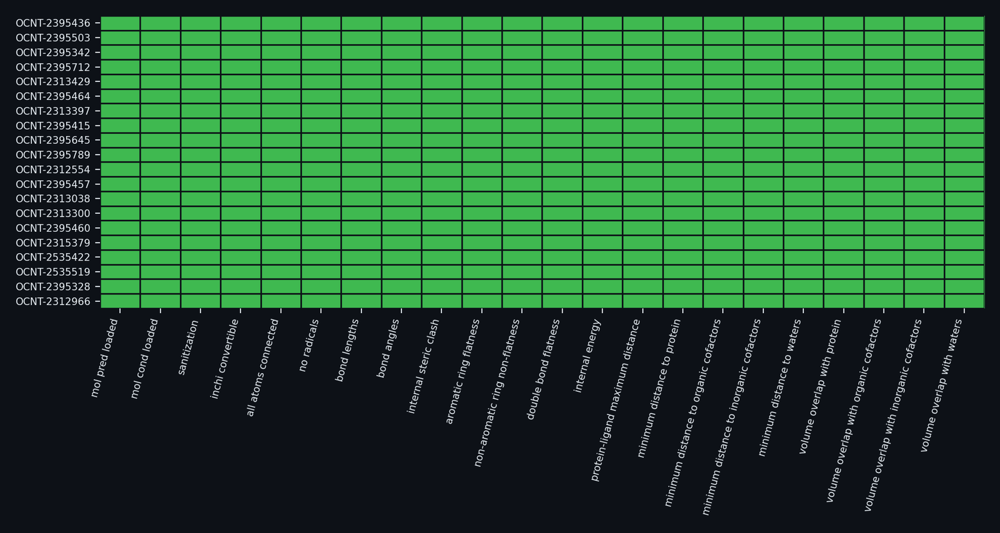

**Figure: PoseBusters: every check on every submitted pose.** The 22 PoseBusters checks (columns) on the 20 ligand poses (rows) of the official CYP3A4 set in the final structure zip, as written by the code that builds the zip. Green is a pass: 0 of 20 poses fail any check. The audit repeats the check.

In [352]:
show_figure("struct_posebusters")

## 11.13 Ligand dynamics in the frozen pocket: a dynophore that the project can afford

> **Field:** Computational chemistry · Statistics

*Where this section sits.* Section 11.11 asked whether a pharmacophore model that is read at one frame of a predicted pose ranks the poses of a ligand by their distance to the crystal pose, and the answer was no. A single frame is a snapshot of a molecule that moves. This section asks whether reading the same model over a short trajectory of the ligand in its pocket changes the answer, and it also tests a quantity that no earlier rule used: how stable a pose stays when it is allowed to move. It teaches the three ideas it needs: molecular dynamics, the dynophore, and what a small test can and cannot show.

In [353]:
# The settings of the experiment, read from the module and from the gate that it reuses, so that no number of the text is typed.
from cypmode.validation import ligand_dynamics as ld
from cypmode.validation.pose_awareness import MIN_FRACTION_POSITIVE, MIN_MEAN_RHO
from cypmode.validation.pose_pharmacophore import NOVEL_SIMILARITY, WILCOXON_P

dyn_step_fs = ld.TIMESTEP_PS * 1000
dyn_time_ps = ld.STEPS * ld.TIMESTEP_PS
dyn_frame_ps = ld.FRAME_EVERY * ld.TIMESTEP_PS
dyn_equilibration_ps = ld.EQUILIBRATION_FRAMES * dyn_frame_ps
dyn_frames_scored = ld.STEPS // ld.FRAME_EVERY - ld.EQUILIBRATION_FRAMES
print(f"{ld.STEPS} steps of {dyn_step_fs:.0f} fs = {dyn_time_ps:.0f} ps at {ld.TEMPERATURE_K:.0f} K, a frame every {dyn_frame_ps:.0f} ps, {dyn_frames_scored} frames scored")

10000 steps of 2 fs = 20 ps at 300 K, a frame every 1 ps, 18 frames scored


**Molecular dynamics.** The atoms of a molecule are points with masses, and a **force field** (the same kind of energy function as in 11.10) gives the force on each atom for any arrangement. **Molecular dynamics** moves the atoms by Newton's second law in very small steps: at each step the forces are computed and the positions and velocities are updated. Here a step is 2 femtoseconds (a femtosecond is a millionth of a billionth of a second); 10,000 steps make 20 picoseconds (ps). To keep the molecule at a temperature, a **Langevin thermostat** adds a friction and random kicks to the atoms, which together make the average kinetic energy that of 300 K. The result is a **trajectory**, a list of arrangements (frames), here one every 1 ps. The next cell runs the thermostat on a system whose exact answer is known.

In [354]:
# Langevin dynamics on the simplest system that has an exact answer: one particle of carbon mass in a harmonic well, V = k x^2 / 2 in each of three directions, at the settings of the experiment (300 K, friction 1 per ps,
# time step 2 fs). Statistical mechanics says that at equilibrium every direction has the position variance lv_kT / k and every velocity component the variance lv_kT / m (so a mean kinetic energy of lv_kT / 2 per direction).
# The integrator is written out ("middle" scheme: half kick, half drift, friction and noise, half drift, half kick, as OpenMM's LangevinMiddleIntegrator does) and the same system is run with OpenMM itself.
import json
import subprocess
import textwrap
from pathlib import Path

from cypmode.validation import ligand_dynamics as ld

LV_KB = 0.0019872041  # kcal/mol/K
spring_k, atom_mass, n_particles = 2.0, 12.011, 20000  # kcal/mol/A^2 (the tether of the relaxation, 11.10), amu, independent particles
lv_kT = LV_KB * ld.TEMPERATURE_K
# units: kcal/mol, angstrom, amu; the time unit that makes the equations plain is sqrt(amu A^2 / (kcal/mol)) = 0.04888 ps (the AKMA unit of time, 48.888 fs)
to_ps = 0.04888821
lv_dt, lv_gamma = ld.TIMESTEP_PS / to_ps, ld.FRICTION_PER_PS * to_ps

def langevin_middle(n_steps, lv_dt, lv_gamma, seed=7):
    rng = np.random.default_rng(seed)
    x, v = np.zeros((n_particles, 3)), np.zeros((n_particles, 3))  # a cold start: at rest in the middle of the well
    c1 = np.exp(-lv_gamma * lv_dt)
    c2 = np.sqrt((1 - c1**2) * lv_kT / atom_mass)
    force = -spring_k * x
    for _ in range(n_steps):
        v += 0.5 * lv_dt * force / atom_mass
        x += 0.5 * lv_dt * v
        v = c1 * v + c2 * rng.standard_normal(v.shape)
        x += 0.5 * lv_dt * v
        force = -spring_k * x
        v += 0.5 * lv_dt * force / atom_mass
    return x, v

n_steps_run = 10000  # 20 ps, the length of the experiment
lv_x, lv_v = langevin_middle(n_steps_run, lv_dt, lv_gamma)
var_x, var_v = float(lv_x.var()), float(lv_v.var())
n_samples = lv_x.size
rel_error = float(np.sqrt(2 / n_samples))  # the relative standard error of a variance estimated from n_samples normal values
expected_x, expected_v = lv_kT / spring_k, lv_kT / atom_mass
mean_kinetic = float(0.5 * atom_mass * (lv_v**2).sum(axis=1).mean())

openmm_source = textwrap.dedent(f"""
    import json
    import numpy as np
    import openmm as mm
    from openmm import unit
    n, k, T, lv_gamma, lv_dt, steps = {n_particles}, {spring_k}, {ld.TEMPERATURE_K}, {ld.FRICTION_PER_PS}, {ld.TIMESTEP_PS}, {n_steps_run}
    system = mm.System()
    force = mm.CustomExternalForce("0.5 * k * (x^2 + y^2 + z^2)")
    force.addGlobalParameter("k", k * 4.184 * 100)  # kcal/mol/A^2 in kJ/mol/nm^2
    for i in range(n):
        system.addParticle({atom_mass})
        force.addParticle(i, [])
    system.addForce(force)
    integrator = mm.LangevinMiddleIntegrator(T * unit.kelvin, lv_gamma / unit.picosecond, lv_dt * unit.picoseconds)
    integrator.setRandomNumberSeed({ld.SEED})
    context = mm.Context(system, integrator, mm.Platform.getPlatformByName("CPU"))
    context.setPositions(np.zeros((n, 3)))
    context.setVelocities(np.zeros((n, 3)))
    integrator.step(steps)
    state = context.getState(getPositions=True, getVelocities=True)
    x = state.getPositions(asNumpy=True).value_in_unit(unit.angstrom)
    v = state.getVelocities(asNumpy=True).value_in_unit(unit.angstrom / unit.picosecond)
    print(json.dumps({{"var_x": float(x.var()), "var_v": float(v.var())}}))
""")
openmm_python = Path.home() / "miniforge3/envs/openmm/bin/python"
lv_done = subprocess.run([str(openmm_python), "-c", openmm_source], capture_output=True, text=True, timeout=600)
assert lv_done.returncode == 0, lv_done.stderr[-400:]
openmm_result = json.loads(lv_done.stdout.strip().splitlines()[-1])
# OpenMM reports velocities in A/ps; the toy works in A per internal time unit
var_v_openmm = openmm_result["var_v"] * to_ps**2
lv_rows = [{"quantity": "position variance per direction (A^2)", "lv_kT / k": expected_x, "this integrator": var_x, "OpenMM": openmm_result["var_x"]},
        {"quantity": "velocity variance per direction (A^2 per unit time^2)", "lv_kT / m": expected_v, "this integrator": var_v, "OpenMM": var_v_openmm}]
dynamics_table = pd.DataFrame(lv_rows)
show_table(dynamics_table, floatfmt=".5f")
lv_checks = {"toy position": var_x / expected_x - 1, "toy velocity": var_v / expected_v - 1, "OpenMM position": openmm_result["var_x"] / expected_x - 1, "OpenMM velocity": var_v_openmm / expected_v - 1}
assert all(abs(e) < 4 * rel_error for e in lv_checks.values()), lv_checks  # all four agree with the exact value within four standard errors

| quantity | lv_kT / k | this integrator | OpenMM | lv_kT / m |
| --- | --- | --- | --- | --- |
| position variance per direction (A^2) | 0.29808 | 0.29885 | 0.29622 | nan |
| velocity variance per direction (A^2 per unit time^2) | nan | 0.04954 | 0.04935 | 0.04963 |

**The thermostat, on a system with an exact answer.** The cell moves particles of carbon mass in a harmonic well, $V = k x^2/2$ in each of three directions, with the spring constant $k$ of the tether of the relaxation (11.10), at the settings of the experiment: 300 K, a friction of 1 per ps and a step of 2 fs. Statistical mechanics gives the exact answer. At equilibrium the position along each direction has the variance $k_B T/k$, and each component of the velocity the variance $k_B T/m$, where $k_B$ is the Boltzmann constant, $T$ the temperature and $m$ the mass; that is the statement that every direction holds a kinetic energy of $k_B T/2$ on average. The integrator is written out in the cell: half a kick from the force, half a drift of the position, the friction and the random kick, half a drift, half a kick. That is the "middle" scheme of OpenMM's `LangevinMiddleIntegrator`, which the experiment uses. 20,000 independent particles start at rest in the middle of the well; after 10,000 steps (20 ps, the length of the experiment) the position variance is 0.2989 Å² against the exact 0.2981, a difference of +0.3%, and the velocity variance differs from the exact value by -0.2%. OpenMM's own integrator on the same system differs by -0.6% and -0.6%. The statistical error of a variance estimated from 60,000 values is 0.6%, so all four numbers agree with the exact value (the cell requires it, within four standard errors). The mean kinetic energy is 0.893 kcal/mol, against 0.894 for three directions. This is what "the thermostat keeps the temperature at 300 K" means, and it can be checked because the correct distribution is known.

**The dynophore.** A **pharmacophore** (9.14, 11.11) is the set of chemical features of a ligand that matter for binding, with their positions. A **dynophore** is a pharmacophore that is followed over a molecular dynamics simulation, so that each feature carries the share of the time in which it is present and where it sits. A published account describes the approach as one that "supplements the static structure-based-pharmacophore information with a dynamic component" (Janežič and colleagues, *International Journal of Molecular Sciences* 2021, doi 10.3390/ijms222413474, Appendix C). In that work the simulation is of the whole complex of protein and ligand in water.

**What this project does instead, and why it is not a dynophore.** A simulation of the whole enzyme in water for nanoseconds is out of reach on this machine for the valid poses of the 20 official ligands (the note of the rule gives the measured speed of the system below, for the ligand alone). The project therefore runs *ligand dynamics in a frozen pocket*: the system of the force-field relaxation of 11.10, in which the protein and the heme stay at their predicted positions and only the ligand moves, with two changes written down before the first number (`docs/structure_track/structure_ligand_dynamics.md`): the tether of the ligand to its predicted positions is switched off, because it would give every pose the same stability, and the restraint of a coordinating nitrogen to the iron is kept at its predicted distance, because the force field gives the iron no repulsive term. The thermostat is at 300 K, the first 2 ps are not scored, and the poses are those of the gate of 11.11. The name in this notebook is always *ligand dynamics in a frozen pocket*, for the reasons that follow.

**What it cannot show.** (1) The protein is the predicted one and does not respond, so a pose that needs the pocket to open or a loop to move cannot be recognised. (2) There is no water: a water molecule that bridges the ligand and the protein, and the cost of removing water from the ligand, are absent, and a constant dielectric of 4 is a crude stand-in. (3) 20 ps is the time of vibrations and of small rotations; the slow motions of a ligand, a ring that flips or a chain that swings, are not sampled. (4) The force field is the same as in the relaxation, so the stability of a pose measures its agreement with that force field, which the physics terms of 11.8 already did without ranking the poses. (5) The frame scores reuse the fields and the sites of 11.11, so any error of that model is carried into the average. (6) The nitrogen of a Type II ligand is held at the iron by construction, so the anchor of such a pose is stable whether or not it is right.

**The rule, fixed before any number.** The ten ligands are the crystal-anchored benchmark of 11.5, picked for their chemical diversity from the CYPMode PDB entries and not for any property of the dynamics; the table of 11.5 lists them with their PDB entries. The pools are those of the gate of 11.11, the regime in which the references at least 0.5 similar to the ligand are left out of the pocket fields. Three scores, all within-pool ranks without a fitted weight: the **dynamic pharmacophore** (the ranks of the field score and of the site recall, each averaged over the 18 scored frames), the **stability** (minus the mean heavy-atom distance of the frames to the start pose) and the two combined. Scores that are equal in exact arithmetic are ties: the mean of two ranks is often the same number for different poses, so the scores are rounded to 10 decimals before they are ranked, and the rounding noise of the last binary digit cannot order them. The gate is the bar of 11.8 and 11.11: the correlation of a score with minus the true RMSD, averaged over the ligands, exceeds 0.3 and is positive for at least 60% of them; only then a paired test against the pose that MBR picks decides whether the score may be used (the mean RMSD of its pick is below that of MBR, every drop-one difference is above zero, one-sided paired Wilcoxon p below 0.1). Three scores are judged without a correction among them. The structure entry stays S1 unless a paired test is met, and a candidate that is built is never uploaded to the live board to decide anything.

In [355]:
# The numbers of 11.13: the gate lines of the ligand dynamics (job 286), read from the log that the job left, and the sizes of the system, read from the module.
import pandas as pd

from cypmode.validation import ligand_dynamics as ld

dyn_facts = ld.read_log((ROOT / "data/structure_track/outputs/cyp3a4/logs/ligand_dynamics.log").read_text())
dyn_poses, dyn_ligands = dyn_facts["poses"], dyn_facts["ligands"]
dyn_names = {"static_pharmacophore_model": "the static model of 11.11", "dynamic_pharmacophore": "the dynamic pharmacophore", "stability": "the stability", "dynamic_combined": "the two combined"}
dyn_scores = dyn_facts["scores"]
dyn_met = [dyn_names[n] for n in ld.SCORES if dyn_scores[n]["gate"] == "MET"]
dyn_used = [dyn_names[n] for n in ld.SCORES if dyn_scores[n]["use"] == "MET"]
dyn_table = pd.DataFrame([{"score": dyn_names[n], "mean rho with minus the true RMSD": dyn_scores[n]["rho"], "ligands with a positive rho": f"{dyn_scores[n]['positive']}%", "gate": dyn_scores[n]["gate"] or "information only",
                           "paired test against MBR": dyn_scores[n]["use"] or "not applicable"} for n in dyn_names])
dyn_verdict_sentence = ("None of the three dynamic scores passes the gate: " + ", ".join(f"{dyn_names[n]} {dyn_scores[n]['rho']:+.3f}" for n in ld.SCORES) + f", against {dyn_scores['static_pharmacophore_model']['rho']:+.3f} for the static model, "
                        f"with the bar at {MIN_MEAN_RHO:+.2f}." if not dyn_met else "The gate is met by " + " and ".join(dyn_met) + f"; the static model of the same poses scores {dyn_scores['static_pharmacophore_model']['rho']:+.3f}.")
dyn_decision_sentence = ("No score passes the paired test against MBR, so no candidate D was built and S1 stays the structure entry, as the rule says." if not dyn_used else
                         "The paired test is met by " + " and ".join(dyn_used) + ", so the rule allows candidate D; its construction and its checks are in the paragraph that follows.")
dyn_frame = pd.read_csv(ROOT / ld.POSES, float_precision="round_trip")
dyn_frame = dyn_frame[dyn_frame["regime"] == "novel"]
dyn_rho = pd.DataFrame({n: [ld.pool_rho(pool[n], pool["true_rmsd"]) for _, pool in dyn_frame.groupby("compound", sort=True)] for n in dyn_names})
dyn_between = dyn_rho["static_pharmacophore_model"].corr(dyn_rho["dynamic_pharmacophore"], method="spearman")
dyn_centred = lambda column: dyn_frame[column] - dyn_frame.groupby("compound")[column].transform("mean")
dyn_drift_rho = dyn_centred("drift").corr(dyn_centred("true_rmsd"), method="spearman")
show_table(dyn_table, floatfmt=".2f")

| score | mean rho with minus the true RMSD | ligands with a positive rho | gate | paired test against MBR |
| --- | --- | --- | --- | --- |
| the static model of 11.11 | -0.24 | 30% | information only | not applicable |
| the dynamic pharmacophore | -0.21 | 50% | NOT MET | not evaluated |
| the stability | 0.04 | 80% | NOT MET | not evaluated |
| the two combined | -0.07 | 50% | NOT MET | not evaluated |

**The result.** The pool is the one of 11.11: 104 poses of 10 benchmark ligands, 20 ps for each pose. None of the three dynamic scores passes the gate: the dynamic pharmacophore -0.214, the stability +0.042, the two combined -0.071, against -0.240 for the static model, with the bar at +0.30. No score passes the paired test against MBR, so no candidate D was built and S1 stays the structure entry, as the rule says.

*What the number of ligands allows.* 10 ligands cannot detect a modest effect: with the bar at a correlation of 0.3 and a share of 60%, a score that helps a little will often fail and a score that does nothing will sometimes pass. A pass would therefore be weak evidence and a failure says nothing about an effect that is smaller than the gate can see. The benchmark ligands are also chemically far from the 20 official ligands, so even a clear result on them would not transfer with certainty.

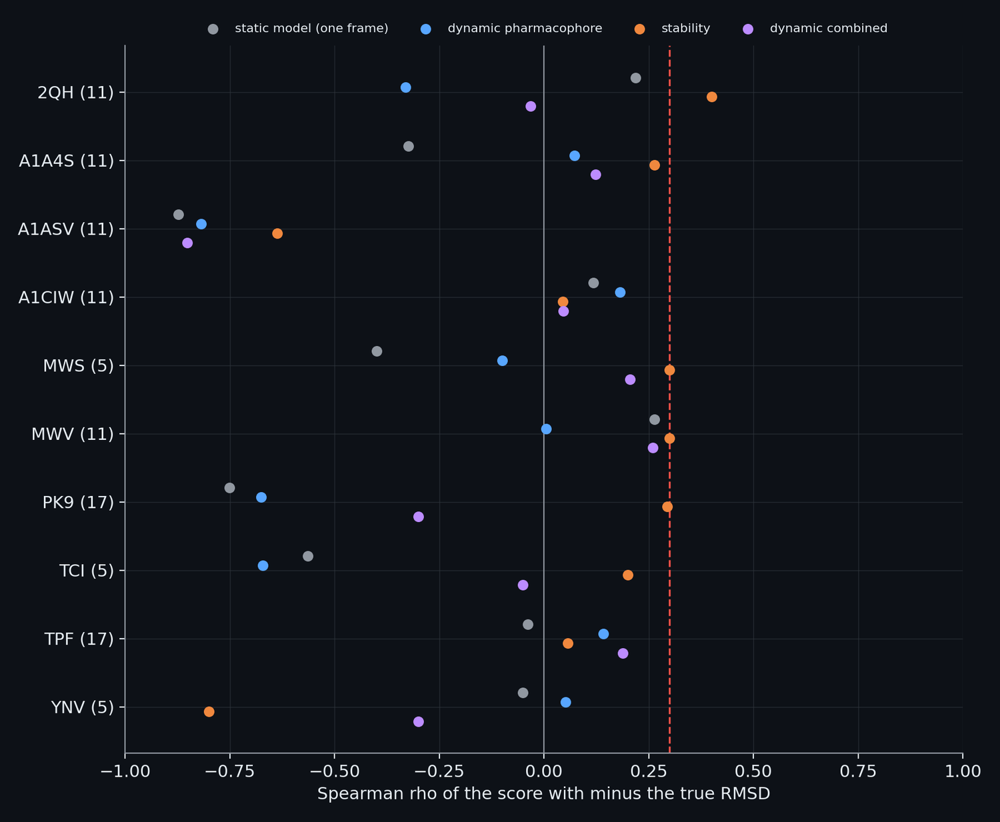

**Figure: The static and the dynamic scores of a pose, ligand by ligand.** Each row is a benchmark ligand with at least 3 predicted poses, each dot the Spearman correlation, within the pool of the ligand, between a score and minus the distance of the pose to the crystal pose (right of zero: the score ranks the better poses first). The line at 0.3 is the bar of the gate. Means over 10 ligands: static model (one frame) -0.24, dynamic pharmacophore -0.21, stability +0.04, dynamic combined -0.07.

In [356]:
show_figure("struct_dyn_gate")

The figure shows the gate ligand by ligand. A dot to the right of zero means that within the pool of that ligand the score puts the poses that are closer to the crystal pose first; the dashed line is the bar of the gate. The dynamic pharmacophore and the static model of the same poses follow each other from ligand to ligand (Spearman correlation +0.64 over the 10 ligands, an estimate that so few ligands cannot make precise): where the field ranks the poses of a ligand wrongly at one frame it mostly does so over the whole trajectory. That fits a score that reads the same field at more frames, and it is why the dynamic pharmacophore adds little to the static model.

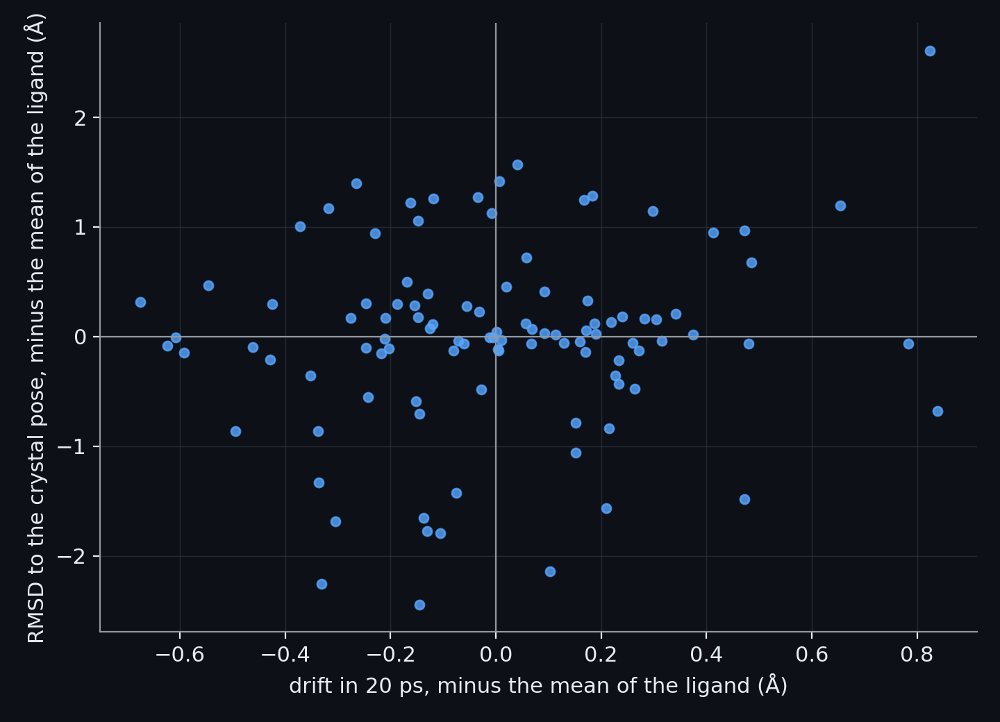

**Figure: The drift of a pose under dynamics against its error.** Each dot is one of the 104 predicted poses of the benchmark ligands. Horizontal: the mean heavy-atom RMSD of the ligand to its start pose over the 18 scored frames of the 20 ps (the drift). Vertical: the RMSD of the start pose to the crystal pose. Both are centred on the mean of their ligand, so that only the differences between the poses of one ligand are shown (Spearman rho +0.09). A stable pose is not a pose that is close to the crystal.

In [357]:
show_figure("struct_dyn_drift")

The second figure asks the question of the stability directly. After the drift and the error of each pose are centred on the mean of its ligand, their Spearman correlation is +0.09 over the 104 poses, so in these data a pose that moves little is not a pose that is closer to the crystal pose. One reading is that the force field has a minimum near every pose that the prediction produced, so that the drift measures how steep that minimum is and not where the crystal pose lies; the experiment does not test that reading.

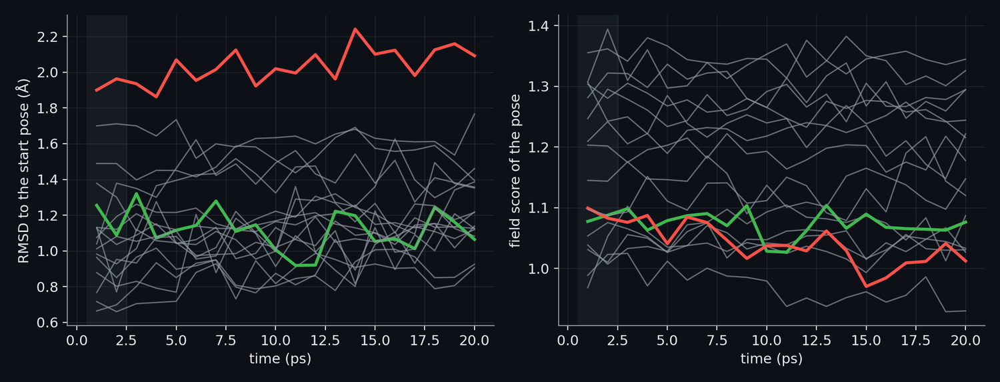

**Figure: The traces of the poses of one ligand over 20 ps.** The 20 ps of the poses of PK9, the benchmark ligand whose poses differ most in their distance to the crystal pose. Left: the heavy-atom RMSD of the ligand to its start pose; right: the field score of the pose in the pocket model, frame by frame, which is the quantity that the dynamic pharmacophore averages. The best and the worst pose against the crystal are drawn thick.

In [358]:
show_figure("struct_dyn_trace")

The third figure shows what the dynamic pharmacophore averages. For the ligand whose poses differ most in their distance to the crystal pose, the left panel is the distance of the ligand to its start pose over the 20 ps and the right panel is the field score of the pose, frame by frame. The grey band is the equilibration that is not scored. The best and the worst pose against the crystal are drawn thick.

*On what actually ran.* `cypmode/validation/ligand_dynamics.py` (`simulate_pose`, `frame_scores`, `within_pool_dynamics`, `evaluate`, `report`) is the experiment; it reuses the force field of `relax.py`, the pools and the gate functions of `pose_pharmacophore.py` and the bar of `pose_awareness.py`. The queue job `286_ligand_dynamics` prepares the pose files, runs the simulation in four processes of two threads in the conda environment `openmm`, and writes the log `ligand_dynamics.log` that this section reads; the figures are drawn by `docs/figures/gen/structure_dynamics.py` and the tests are in `tests/test_ligand_dynamics.py`. The rule is in `docs/structure_track/structure_ligand_dynamics.md`, the method report states the verdicts in section 11, and the limitation L16 says what the experiment cannot show.

# Part XII. Engineering for trust

The other parts of this notebook say what was found. This part says why a reader should believe it, and the answer is a set of habits that make the project hard to fool, above all itself. A result that cannot be produced again is an anecdote, so 12.1 is about reproducibility, and about the small, unglamorous sources of difference between two runs that should agree. 12.2 is the audit, a program that regenerates a full report on the state of the repository and requires it to be the same twice. 12.3 is the test suite and the automatic workflow that runs it elsewhere. 12.4 is the queue that ran every job in this notebook, with its guards and what the hardware taught. 12.5 is the documents that are generated from the logs, so that no number in them is typed. 12.6 is the rules that never change, and how each is enforced by a program and not by a promise.

The reason for all of it is the one thing the project cannot do: while the challenge ran it could not see the labels of the compounds it is scored on. Every claim it made then was therefore a claim about a procedure, and a procedure is only worth what its checks are worth.

## 12.1 Reproducibility: seeds, threads, solvers and archives

> **Field:** Software engineering · Mathematics

*Where this section sits:* Part XI ended with a file that is submitted. Part XII asks what a reader should need in order to believe the numbers in the other parts, and the first answer is that the numbers can be produced again. A result that appears once and cannot be produced again is an anecdote; a result that can be produced again, from the code and the data in the repository, can be checked by anyone, including by the author a month later.

**What reproducible means here.** The strong form is that the same code, the same data and the same settings give the same bytes. A weaker form, the same numbers to a stated precision, is enough for a table but not for a hash, and a hash is what the project uses wherever it can: the SHA-256 of a submitted file is quoted in the method report, so that the file can be recognised. Four things stand between the two forms, and each has a place in the repository.

**Seeds.** A **pseudo-random number generator** is a fixed recipe that turns one number, the **seed**, into a long sequence that looks random; the same seed gives the same sequence. Every random choice in the project (the split of the molecules into folds, the starting point of a model, the order in which a solver visits its variables) is drawn from a generator with a seed written in the code. The nested evaluation of Part VI uses seed 0, three repeats, five outer and four inner folds, and the plan of the folds is saved with an identifier that is computed from the raw files, so that a plan rebuilt from the same files is recognised as the same plan.

**Floating-point arithmetic.** The second source is not randomness at all. A computer keeps a real number to about sixteen significant digits and rounds after every operation, and rounding does not respect the rule that the order of additions does not matter: $(a+b)+c$ is not always $a+(b+c)$. The next cell shows it on the smallest case, on a million numbers added in five different orders, and on the same numbers split into four parts, as four threads would split them.

In [359]:
# Why the same numbers added in a different order give a different total. A computer stores a real number in 64 bits, which is about sixteen significant digits, and rounds after every addition; rounding is not associative, so (a + b) + c and a + (b + c)
# can differ in the last digit. The first table is the classic three-number case. The second adds the same million numbers one by one in five different orders, and compares each total with math.fsum, which tracks the rounding error and returns
# the exactly rounded sum. The third splits the million numbers into four parts, as four threads would, and combines the four partial sums in two different orders.
import math

orders_rng = np.random.default_rng(12)
million = orders_rng.normal(size=1_000_000)
small_cases = pd.DataFrame({"expression": ["(0.1 + 0.2) + 0.3", "0.1 + (0.2 + 0.3)"], "value": [repr((0.1 + 0.2) + 0.3), repr(0.1 + (0.2 + 0.3))]})
show_table(small_cases, floatfmt=".0f")
exact_total = math.fsum(million)
order_rows = []
for label, values_in_order in {"as generated": million, "reversed": million[::-1], "ascending": np.sort(million), "smallest magnitude first": million[np.argsort(np.abs(million))], "shuffled": orders_rng.permutation(million)}.items():
    running = 0.0
    for value in values_in_order.tolist():
        running += value
    order_rows.append({"order of the additions": label, "total": running, "error against fsum": running - exact_total})
order_table = pd.DataFrame(order_rows)
show_table(order_table, floatfmt=".3e")
quarters = [math.fsum(part) for part in np.array_split(million, 4)]
thread_orders = {"threads finish in order 1, 2, 3, 4": ((quarters[0] + quarters[1]) + quarters[2]) + quarters[3], "threads finish in order 4, 3, 2, 1": ((quarters[3] + quarters[2]) + quarters[1]) + quarters[0], "pairs, then the pairs": (quarters[0] + quarters[1]) + (quarters[2] + quarters[3])}
thread_table = pd.DataFrame({"how the partial sums are combined": list(thread_orders), "total": list(thread_orders.values()), "error against fsum": [v - exact_total for v in thread_orders.values()]})
show_table(thread_table, floatfmt=".3e")
largest_order_error, number_of_distinct_totals = float(order_table["error against fsum"].abs().max()), int(order_table["total"].nunique())
assert number_of_distinct_totals > 1  # the order matters, or the lesson is wrong

| expression | value |
| --- | --- |
| (0.1 + 0.2) + 0.3 | 0.6000000000000001 |
| 0.1 + (0.2 + 0.3) | 0.6 |

| order of the additions | total | error against fsum |
| --- | --- | --- |
| as generated | -6.041e+02 | -1.967e-11 |
| reversed | -6.041e+02 | 1.819e-11 |
| ascending | -6.041e+02 | 1.896e-08 |
| smallest magnitude first | -6.041e+02 | 1.705e-11 |
| shuffled | -6.041e+02 | -3.934e-11 |

| how the partial sums are combined | total | error against fsum |
| --- | --- | --- |
| threads finish in order 1, 2, 3, 4 | -6.041e+02 | 1.137e-13 |
| threads finish in order 4, 3, 2, 1 | -6.041e+02 | 0.000e+00 |
| pairs, then the pairs | -6.041e+02 | 1.137e-13 |

Every order gives a different total (5 different totals from five orders; the largest error against the exactly rounded sum is 1.9e-08), and none is wrong. This matters because a library that uses several **threads** (streams of work that the processor runs at the same time) splits a sum into parts, one per thread, and combines the parts in the order in which the threads finish, which can change from one run to the next. The third table does that with four parts and three orders of combination, and they differ too. The consequence for the project is a rule, not a remedy: the thread count is fixed where it can be, results are compared to a tolerance and not for equality when threads are used, and the audit reports whether a model fitted with one thread and with four gives the same predictions (it is listed as information and not required, because the library does not promise it).

**A solver that visits its variables in a random order.** The third source cost the project something, and 8.3 tells it in full. The meta-learner of the stack (8.2) is a logistic regression of the outcome on the scores of the candidates, solved by a **coordinate method**: it improves one coefficient at a time, in an order drawn at random, until the improvement is smaller than a **tolerance**. With the library's default tolerance the point at which it stops depends on the order, so two processes ended at slightly different blends of the same candidates, and the outer AUC and MCC of the stack differed from one process to the next by more than many of the differences that the gates of Part IX test. The problem is convex, so every order leads towards the same lowest point, and a tight tolerance with a fixed seed makes every order end there. It was the byte-for-byte comparison of the audit (12.2) that showed the difference.

**Archives and environments.** Two more sources are outside the arithmetic. An archive records the time at which each file was written, so that the same files packed twice give two different hashes; the writer of the submitted archive fixes the time of every entry (11.10), and the cell there shows both cases. And a package that is updated changes numbers without any change to the code, which is why the environments are pinned in files with their own checksums (Appendix A, A.1).

The next cell reads the records of all this from the repository: the determinism section of the audit, whose checks are run again each time, the seed registry, and the log of one run where determinism could not be had.

In [360]:
# What the repository itself recorded about reproducibility. Nothing is typed in except one count: the determinism section of the audit report (the tests that the audit runs again every time), the seed registry, and the log of the GPU speed test
# of the CheMeleon fine-tuning, where determinism was required and the machine could not give it, are read from the files; the number of stacked comparisons that job 084 evaluated again (8.3) was counted when the job finished, and is written here.
import re

n_recomputed = 56  # the stacked comparisons evaluated again by job 084 (queue/jobs/084_tdi_stack_reevaluation.sh), counted when it finished on 2026-10-18

audit_text = (ROOT / "audit/AUDIT_REPORT.md").read_text()
determinism_block = re.search(r"## 3\. Determinism and cache consistency\n(.*?)\n## ", audit_text, re.S).group(1)
table_row = re.compile(r"^\| (.*?) \| (PASS|FAIL|INFO|SKIP) \| (.*) \|$")
determinism_rows = [list(m.groups()) for m in (table_row.match(line) for line in determinism_block.splitlines()) if m]
determinism_table = pd.DataFrame(determinism_rows, columns=["check", "result", "detail"])
show_table(determinism_table, floatfmt=".0f")
n_determinism_checks, n_determinism_pass = len(determinism_table), int((determinism_table["result"] == "PASS").sum())
seed_line = re.search(r"Seed registry: (\d+) distinct", audit_text)
n_seed_entries = int(seed_line.group(1))

import json

speed_dir = ROOT / "data/tdi_track/outputs/comparisons"
speed_first = json.loads((speed_dir / "chemeleon_speed_CYP3A4_2026-10-17.json").read_text())
speed_second = json.loads((speed_dir / "chemeleon_speed_CYP3A4.json").read_text())
gpu_operation = re.search(r"(\w+) does not have a deterministic implementation", speed_first["failure"]).group(1)
assert speed_first["gpu_seconds"] is None and speed_first["decision"] == "not run: cost" and speed_second["failure"] is None and speed_second["decision"] == "mps"  # the text below tells these two records

| check | result | detail |
| --- | --- | --- |
| feature block `rdkit_desc` computed twice | PASS | max \|diff\| 0.0000 |
| feature block `morgan_c2` computed twice | PASS | max \|diff\| 0.0000 |
| feature block `tdi_alerts` computed twice | PASS | max \|diff\| 0.0000 |
| feature block `tdi_alert_context` computed twice | PASS | max \|diff\| 0.0000 |
| CYP3A4 plan id rebuilt from raw files equals the saved plan | PASS | saved 66a3fcaa4d, rebuilt 66a3fcaa4d |
| CYP3A4 plan splits identical when rebuilt in-process | PASS | 15 outer folds |
| CYP2D6 plan id rebuilt from raw files equals the saved plan | PASS | saved de96866ac4, rebuilt de96866ac4 |
| CYP2D6 plan splits identical when rebuilt in-process | PASS | 15 outer folds |
| LightGBM, same seed and 1 thread, fitted twice | PASS | max \|diff\| 0.00000000 |
| LightGBM, same seed, 1 thread vs 4 threads | INFO | max \|diff\| 0.00000000 (reported, not required to be zero) |
| CYP3A4 cached `knn_tanimoto_k15` equals a fresh fit of the current code | PASS | max \|diff\| 0.0000000298 |
| CYP3A4 cached `svm_tanimoto_C1` equals a fresh fit of the current code | PASS | max \|diff\| 0.0000000591 |
| CYP2D6 cached `knn_tanimoto_k15` equals a fresh fit of the current code | PASS | max \|diff\| 0.0000000280 |
| CYP2D6 cached `svm_tanimoto_C1` equals a fresh fit of the current code | PASS | max \|diff\| 0.0000000571 |
| a plan task fitted twice with the runner (4 threads) | PASS | max \|diff\| 0.00000000 |

The repair of the solver was followed by the work it required. Job 084 evaluated again, from the prediction caches (nothing was refitted), every comparison that goes through the stack: 56 stacked comparisons. No verdict changed, and the stacked numbers moved by less than a thousandth. The lesson drawn is the one the audit encodes: a comparison between two models is only as good as the repeatability of each of them, so repeatability is tested before the comparison is believed.

The determinism section of the audit has 15 lines and 14 of them are PASS; the others are information that the audit reports without requiring it. They cover the feature blocks computed twice, the folds rebuilt from the raw files, a model fitted twice with the same seed and with one and with four threads, and a cached prediction compared with a fresh fit of the current code (they agree to about the eighth decimal, the precision of the float32 numbers in the cache). The seed registry of the audit lists 14 distinct (file, kind, value) entries, and a seed that is not written where the audit can see it is not allowed.

*Where determinism had to be relaxed.* One of the experiments of Part IX asked for the strongest form of it, and the machine could not give it at first. The first speed test of the CheMeleon fine-tuning (9.10, 2026-10-17) trained with deterministic algorithms required, which makes the library refuse any operation that has no deterministic implementation; on the Apple GPU the operation `er_reduce_mps` has none, and the run stopped at once. No GPU time was measured, so the decision of that day, not to run the fine-tuning for cost, rested on the estimate of the processor alone. The test was made again on 2026-10-22 with the deterministic algorithms in warn-only mode (`scripts/chemprop_mps.sh`): the library warns about the operation instead of refusing it, the seed stays fixed, and only the order of the additions of that one operation may vary. One task took 781 s on the GPU against 2310 s on the processor; the scores of the two agreed (rank correlation 0.83, AUC 0.719 against 0.720), and the decision became to run the stage on the GPU: 3.9 h for the 18 missing tasks against 11.6 h on the processor, with a limit of 8 h. The two records are kept side by side (`chemeleon_speed_CYP3A4_2026-10-17.json` and `chemeleon_speed_CYP3A4.json`); the first is the evidence that the stop was about the operation and not about speed.

**The record of the push.** A number is reproducible only if the repository that reaches a reader is the one the author had. `scripts/mirror_check.sh` checks that after a push: it fetches the remote branch and fails when the working tree differs from HEAD in any way (a modified, an untracked or a missing file), or when `origin/<branch>` is not at HEAD, and it prints the files that stay local on purpose, those listed in `.gitignore`. It is the other end of the chain that the pinned environments and the fixed seeds begin: the numbers can be produced again from the files, and the files are the ones that were pushed. The script is not run by the notebook, which is built before the push; its check is described here from the script itself.

**The record of the data.** The repository does not hold the 8.7 GB of files that the engines produce or that the code takes hours to regenerate (the feature store, the prediction caches, the outputs of the nested validation, the raw outputs of Boltz-2 and OpenFold3), and a clone without them cannot run the audit. `data_record/record.json` names the groups of such files, `cypmode/data_record.py` packs each group into one archive and writes `data_record/MANIFEST.json` with the size and the SHA-256 of every archive, and `scripts/fetch_data.py` restores them: it copies or downloads each archive, refuses one whose SHA-256 differs from the manifest before it extracts anything, and checks afterwards that every path listed for the group is there. The audit makes the same check of presence before it reads a file and names what is missing and the command that gets it, so a clone that lacks the data stops with that message and not with a stack trace. A file belongs to the record when git does not track it, whether the `.gitignore` hides it or not, so the policy is the same before and after the held-back files are committed; the folders of downloaded or supplied inputs are left out by name until the licence of each has been read. `tests/test_data_record.py` builds a small repository, packs it, deletes files, restores them, and checks that a changed archive is refused. The whole path is run once from a clean clone by `scripts/clean_clone_check.sh`: it clones the repository at its last commit, restores the data record there, runs the audit in the clone and compares the checks of its report with those of the committed one; the jobs `970_data_record_build` and `975_clean_clone_check` of the queue make the archives and run that check after the release, and `296_release_unblock` is the job that makes the release itself (`tests/test_release_jobs.py` checks the order in which they wait).

*On what actually ran.* The first cell is a toy made for the lesson. The second reads the audit report and the two records of the speed test.

## 12.2 The audit: what it checks and how it is itself checked

> **Field:** Software engineering

*Where this section sits:* 12.1 explained why a result must be producible again. The audit is the program that produces it again, on purpose, every time the project is finished, and compares what it gets with what is written down.

**What it is.** `python -m cypmode.audit.report` regenerates a full report from the current code, data and caches. Every number in the report is computed when the program runs; the only text written by hand is the wording around the numbers. The report contains no time, no duration and no temporary path, because anything that changes from one run to the next would make two runs differ for a reason that has nothing to do with the project. `bash scripts/run_audit.sh` runs the program twice and requires the two reports to be identical byte for byte. An audit that is not itself reproducible cannot vouch for anything else.

**What it checks.** The next cell reads the report and lists its sections. In order they establish what was run (versions, hashes of the inputs), that the test suite passes now and not at some earlier time, determinism (12.1), the integrity of the data (the rule that defines the label reproduces every label, the folds of a nested plan do not overlap), the baselines against the models under each evaluation population, the committee, the calibration, the chemistry evidence, the ledger of every experiment parsed from the run logs, the structure benchmark, the readiness of the submission files, the credit hygiene (no leaderboard alias used as a credit, one author of the commits), the consistency of the queue jobs with the repository, the pinned environment and the seed registry, the leakage checks of every feature block, the standing rules that a script can check (the wording of the text files has a section of its own, and so have the paths that the text names: every path between backticks in a document or a part of the notebook must exist, or be on a short list of allowances each with its reason, such as a pattern, a file of the organisers or a file written after the deadline), and the hashes of the final candidate files with the portal's own checks; the limitations of the method are logged in a section of their own, and the gate ledger lists every pre-registered verdict found in the run logs.

In [361]:
# The audit report, read as it stands: the counts of its summary, the checks that did not pass, and its sections with the number of lines of results in each. The report is generated by cypmode/audit/report.py in the final chain (job 900); this cell
# reads the file that the chain produced, so that the text below describes the audit of the state that is submitted. The size of a section is its number of non-empty lines.
import re

report_text = (ROOT / "audit/AUDIT_REPORT.md").read_text()
counts = dict(re.findall(r"(PASS|FAIL|INFO|SKIP) = (\d+)", re.search(r"Counts: .*", report_text).group(0)))
n_pass, n_fail, n_info = int(counts["PASS"]), int(counts["FAIL"]), int(counts["INFO"])
n_checks = n_pass + n_fail + n_info + int(counts.get("SKIP", 0))
summary_block = re.search(r"## Check summary\n(.*?)\n## ", report_text, re.S).group(1)
table_row = re.compile(r"^\| (.*?) \| (PASS|FAIL|INFO|SKIP) \| (.*) \|$")
summary_rows = [list(m.groups()) for m in (table_row.match(line) for line in summary_block.splitlines()) if m]
failed_checks = pd.DataFrame([r for r in summary_rows if r[1] == "FAIL"], columns=["check", "status", "detail"])
section_names = re.findall(r"^## (\d+b?\. .+)$", report_text, re.M)
section_rows = []
for name in section_names:
    block = re.search(rf"^## {re.escape(name)}\n(.*?)(?=^## |\Z)", report_text, re.M | re.S).group(1)
    section_rows.append({"section": name[:78], "lines": sum(1 for line in block.splitlines() if line.strip())})
section_table = pd.DataFrame(section_rows)
show_table(section_table, floatfmt=".0f")
n_sections = len(section_table)
if len(failed_checks):
    print("checks that do not pass in the report:")
    show_table(failed_checks, floatfmt=".0f")
fail_sentence = "Every check passes." if n_fail == 0 else f"{n_fail} checks do not pass; they are printed above with their detail, and the report lists them first."

| section | lines |
| --- | --- |
| 1. Provenance and environment | 25 |
| 2. Test suite (executed now) | 1 |
| 3. Determinism and cache consistency | 17 |
| 4. Data integrity | 21 |
| 5. Baselines against the current model | 28 |
| 6. Committee (query-by-committee) backtest against the margin baseline | 57 |
| 7. Calibration of the stack on held-out compounds | 29 |
| 8. Chemistry evidence: exact TreeSHAP, architecture agreement, alert enrichmen | 84 |
| 9. Experiment ledger (parsed from the run logs) | 175 |
| 10. Structure-track benchmark (from the scored crystal poses) | 271 |
| 11. Submission-file readiness | 4 |
| 11b. Selection-aware CYP2D6 evidence (population shift) | 7 |
| 12. Credit hygiene | 6 |
| 14. Gate ledger (every pre-registered verdict found in the run logs, including | 219 |
| 14b. Multiplicity of the additions tested together (Holm adjustment next to th | 55 |
| 15. Queue consistency (every job points at modules and scripts that exist) | 2 |
| 16. Pinned environment and seed registry | 19 |
| 17. Feature-block leakage checks | 30 |
| 18. Standing rules enforced by script | 1 |
| 19. Final candidate files (hashes and the portal's own checks) | 52 |
| 20. Attribution and citation consistency | 1 |
| 21. Wording of the text files | 12 |
| 22. Paths that the text names | 2 |
| 13. Limitations log | 16 |

The report has 24 sections and 110 checks in its summary: 104 pass, 0 fail and 6 are information. Every check passes.

**Why a failing check is kept in view.** A check that fails is a finding, not an embarrassment, and the audit is built so that it cannot be silenced: the summary lists every check with its status, a check is added when a mistake is found (so the same mistake cannot return unseen), and no check is removed because it fails. The check that the working tree is clean, for instance, fails whenever there are files that are not committed, which is true during the work; it is in the report because a result that was produced from files that nobody recorded cannot be reproduced.

**A needed condition.** The audit needs a quiescent state. It counts files, and the second run must find the same files as the first. A file created by another program between the two runs makes them differ, and the audit then reports a failure of reproducibility that is not a failure of the code; this happened once, and the queue therefore runs the audit alone, with nobody editing the repository while it runs.

The count of the modified files is also part of the report. The report and the log of the queue job are files that git tracks, and the first run writes the report, so a count that included them would differ between the two runs. The audit therefore leaves its own files (the report, the second report and the log of the job) out of that count (`tree_state` in `cypmode/audit/sections.py`, tested in `tests/test_audit_tree_state.py`), so that the check can pass once everything else is committed and the audit of a committed project can be both reproducible and clean, which is the state that the pre-submission gate asks for.

**What it found.** Its byte-for-byte comparison is what showed that the stack was not deterministic (8.3, 12.1): the report recomputes the nested results of the stack, and two reports differed. It also holds the checks that keep each correction of the project from returning: the label rule, the leakage tests of the feature blocks, the check that the files submitted are the files built. 12.5 describes the other generated documents that read the same records.

*On what actually ran.* The cell reads `audit/AUDIT_REPORT.md` as the final chain left it; the audit itself is not run by the notebook, because it runs the test suite and takes longer than a notebook should.

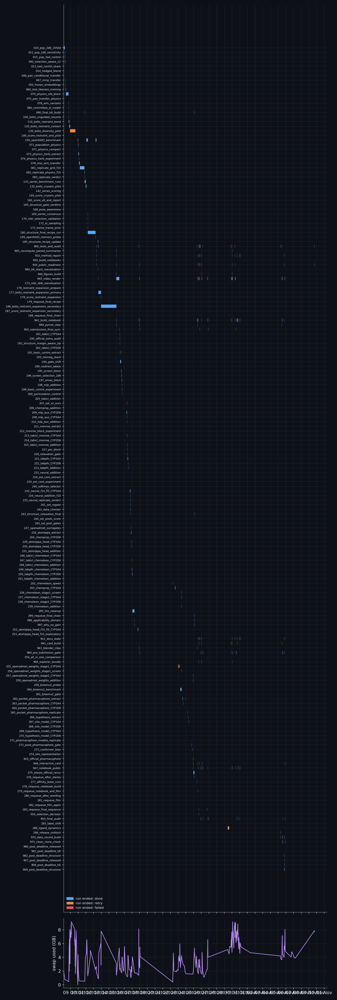

**Figure: The job queue as a timeline.** Each bar is one run of one job of the queue, from the runner's own log (179 jobs, 540 runs: 480 finished, 37 stopped and retried, 23 failed after their attempts). The runs add up to 249 hours of wall-clock time between 08 Oct and 09 Nov (this includes any time the machine was asleep during a run); the longest are 186_boltz_restraint_expansion_secondary (47.6 h), 180_structure_final_recipe_run (24.1 h), 130_boltz_diversity_pilot (15.9 h). The line shows the swap in use at every runner event (peak 9.2 GB on a 16 GB machine).

In [362]:
show_figure("eng_queue_timeline")

## 12.3 The test suite and the continuous-integration workflow

> **Field:** Software engineering

*Where this section sits:* the audit (12.2) runs the test suite among its checks. This section says what the suite is, what it was made to catch, and the lesson about isolation that cost the project hours of machine time.

**A test** is a small program that calls a part of the code with an input whose answer is known and fails if the answer is different. The suite is the collection of them, run with one command (`python -m pytest tests`). It does three jobs. It guards a result: the test that the label rule reproduces every label, or that the folds do not overlap, fails the moment a change breaks what a number depends on. It guards a promise: the test that a block computes on a small set of molecules, the test that no file naming a blinded compound would be pushed. And it guards a mistake already made: a test is written for each defect found, so that it cannot come back unseen. The next cell counts the test functions of the suite by reading its files, lists the largest files, and reads the settings and the workflow that run them.

In [363]:
# The test suite, counted from its files. A test is a function whose name starts with test_, in a file under tests/. The count is made by reading the files, not by running them; the next cell runs one small file as a demonstration.
import ast
import re

test_files = sorted((ROOT / "tests").glob("test_*.py"))
tests_per_file = {}
for path in test_files:
    tree = ast.parse(path.read_text())
    tests_per_file[path.name] = sum(1 for node in ast.walk(tree) if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.name.startswith("test_"))
n_test_files, n_test_functions = len(test_files), sum(tests_per_file.values())
largest_files = pd.Series(tests_per_file).sort_values(ascending=False).head(6).rename("test functions").reset_index().rename(columns={"index": "file"})
show_table(largest_files, floatfmt=".0f")

pyproject_text = (ROOT / "pyproject.toml").read_text()
ignored_files = re.findall(r"--ignore=(tests/\S+?\.py)", pyproject_text)
n_ignored = len(ignored_files)
segfault_status = re.search(r"segfault, exit (\d+)", pyproject_text).group(1)
workflow_text = (ROOT / ".github/workflows/tests.yml").read_text()
workflow_steps = re.findall(r"- name: (.+)", workflow_text)
operating_systems = re.search(r"os: \[(.+?)\]", workflow_text).group(1)
n_workflow_steps = len(workflow_steps)
step_table = pd.DataFrame({"step of the workflow": workflow_steps})
show_table(step_table, floatfmt=".0f")

| file | test functions |
| --- | --- |
| test_pose_consensus.py | 34 |
| test_nested_runners.py | 34 |
| test_figures.py | 28 |
| test_pose_rescoring.py | 28 |
| test_nested.py | 25 |
| test_method_report_sections.py | 20 |

| step of the workflow |
| --- |
| Install cypmode |
| Install PyTDC (no-deps) |
| Run tests (main group) |
| Queue consistency |
| Install multitask extra |
| Run tests (multitask/torch, isolated) |
| Run tests (ChemBERTa/torch, isolated) |
| Run tests (quantum-pharmacophore and physics blocks/tblite, isolated) |

The suite has 1085 test functions in 156 files, the largest of them above, and the steps of the workflow are listed in the second table.

**Continuous integration** is the practice of running the tests automatically on every change, on a machine other than the author's, so that a result that depends on something only the author's machine has is found. The workflow of the repository (`.github/workflows/tests.yml`) runs on ubuntu-latest, macos-latest, windows-latest and has 8 steps, listed above: it installs the package, runs the main group of tests, runs the consistency check of the queue (12.5), and then runs the files that cannot share a process with the others, one step each. The comments in the file record real failures: a missing package at collection time stopped the whole run, so that none of the other tests ran, and the workflow checked almost nothing without saying so. A test run that silently runs nothing is worse than none, which is why that comment is in the workflow.

**The lesson about isolation.** Two native libraries that each carry their own copy of the runtime for parallel loops (OpenMP) can disturb one another when both are loaded into one process. The suite found this the hard way, and `pyproject.toml` records it in its markers. Loading PyTorch and LightGBM together ends in a crash of the process (the status 139, a segmentation fault), every time; loading the quantum-chemistry package after a number of LightGBM-heavy tests ends in a **deadlock**, a state in which every part of the program waits for another and nothing moves, at no use of the processor. Because pytest imports every file it collects, even one it will later deselect, a marker is not enough: the files that load the second library are named in `--ignore` options (there are 9), and each is run on its own, in a process of its own, as the last steps of the workflow and the isolated runs of the queue do.

The cost of getting this wrong was seen once more, late in the project. A test of the Atom-JEPA readout, which loads PyTorch, was not on the list, and a run of the suite on the queue stopped with no output and no use of the processor for hours, holding every later job behind it. The cause was the same, the file was added to the ignore list, and the audit's test run now has a time limit, because a hang that nobody sees is the worst failure of a long unattended run.

The next cell runs one small file of the suite in a process of its own and prints pytest's summary.

The table below names every file of the suite and gives a line on what each checks, taken from the file's own docstring or from the names of the tests it defines. It is the complete list and not a sample: a reader can find any file of the suite here without running the builder, and the builder's coverage check keeps the list in step with the files, failing the build when a file of the tests is named nowhere (Appendix D).

| test file | what it checks |
| --- | --- |
| `test_alert_context.py` | the alert–lipophilicity interaction block: a molecule without an alert keeps its plain descriptors and gains no interaction feature, a blocking fluorine counts only when it sits next to the alert, and the block stacks one row per molecule |
| `test_amines.py` | the trialkylamine screen: the known TDI drugs match, ketoconazole's N-aryl piperazine and non-amine and delocalised nitrogens do not, and an unparseable or empty SMILES raises |
| `test_app.py` | the pure logic of the Streamlit app (validating SMILES, screening compounds, loading the real blinded test set, merging challenge results) and that every tab renders without an exception |
| `test_applicability_domain.py` | the arithmetic of the applicability domain (the bin edges, the interval of a bin, the tier that follows from it) and of the diagnostics of 9.12, on inputs made for the purpose |
| `test_artifacts.py` | the provenance record of the card, poster, film and figures: an untouched artifact built from the current numbers passes, one built before a number changed is stale, one edited after its build fails, and a missing record is reported as a failure |
| `test_atomjepa_embeddings.py` | the Atom-JEPA block reads its cache without importing torch: label-free principal components of all cached compounds, rows in the order asked for, and a missing embedding replaced by the mean |
| `test_atomjepa_head.py` | the attention readout on the cached per-atom features: it trains, finds a planted signal wherever it sits, and reports a missing cache instead of a silent zero (needs torch, so it is skipped in the lightweight environment) |
| `test_aux_blocks.py` | the predicted blocks: one finite score per evaluation row, one column per predicted reading, and never a reading or a target of an evaluation or held-out row reaching its own prediction |
| `test_basic_centre.py` | the basic-centre block: one value per column for every kind of molecule, a tertiary amine near a ring counted as a centre, the cation classes told apart, no centre for nitro or neutral molecules, and the cache keyed by canonical SMILES |
| `test_batch.py` | the batch runner: a checkpoint after each compound, a failure recorded without stopping the batch, a restart skipping what is done, and both a successful and a failed result flattened to a table |
| `test_bindingdb_auxiliary.py` | the BindingDB auxiliary data: censoring prefixes, unparseable values and extended SMILES dropped, repeated measurements collapsed to the median, and an exact overlap with the challenge removed |
| `test_bioemu2.py` | the BioEmu2 runner: the configuration of the checkpoint switched to the pure-PyTorch kernel with chunked layers and refused when it is not the file expected, the alignment rows taken with the query first, and the samples listed in sample order |
| `test_bisy_rmsd.py` | BiSyRMSD on a structure pair: zero for identical structures, invariant to a rigid transform, sensitive to a ligand-only difference, and the binding-site residues found from the real pocket |
| `test_build_input.py` | the Boltz-2 input builder: the coordinating cysteine found where the sequence puts it (absence and ambiguity raise), and the YAML matching the hand-written reference while rejecting a wrong residue or an out-of-range value |
| `test_build_summary.py` | the structure summary: the ligand SMILES read from the real input file, and compound discovery run without a local Boltz run |
| `test_card.py` | the README card: the iron–nitrogen distance from the ligand's own coordinates, the donor nitrogen marked and the one nearest the iron in the submitted pose circled, and the README pointing to the card and the film |
| `test_chemberta_features.py` | ChemBERTa embeddings: a real finite vector that tells two molecules apart, the batch cache written to disk and resumed, and one fixed-size array per row added as a block |
| `test_chemberta_significance.py` | loading of the ChemBERTa cache: a missing cache or a missing compound raises rather than passing silently, and the join to the feature table is correct |
| `test_chemeleon_embedding_tabular.py` | TabICL and TabPFN on the frozen CheMeleon embedding are registered like the other cached candidates, wait for their inputs instead of failing, and are waited for by the long Chemprop family |
| `test_chemeleon_stage.py` | the stage rule of the fine-tuned CheMeleon: stage 2 runs only above the gain floor in enough folds, and a missing or unreadable stage-1 result stops the design |
| `test_chemprop_variants.py` | the Chemprop command runs the same two variants as before when no variant is named, and the foundation-weight variants are reached only by name (jobs 236 to 238 for CheMeleon and 255 to 258 for the OpenADMET weights) |
| `test_combined_features.py` | the combined-feature cross-validation: every compound covered once and the expected auxiliary columns required |
| `test_committee_uncertainty.py` | the committee's uncertainty: vote entropy zero for unanimity and maximal for a split, the spread as the per-row standard deviation, and the verdict that separates new information from redundancy and from noise |
| `test_conformers.py` | conformer pools: the pocket distance ignoring rigid motion, one record per entry, poorly resolved structures and close analogs of the compound excluded, and the conformers starting at the medoid and spreading out |
| `test_constants.py` | the sequence constants: the amino-acid strings of the published length, the known residues at the published numbering, and a coordination cutoff just above the dative-bond range |
| `test_cryoem_templates.py` | the cryo-EM templates: pockets becoming arrays, one row per run, and an entry whose ligand is the compound never serving as its own template |
| `test_diversity_pilot.py` | the diversity pilot: one row per run with the options each lever needs, names mapping back to ligand and lever, and a verdict that needs a wider pool and a closer best pose for enough ligands |
| `test_docs_state.py` | the generated blocks of the README and the specification: a block rewritten between its markers and nothing else changed, a missing marker pair reported as an error, and every marker the generator writes present |
| `test_addition_experiment.py` | the check of cached candidates: a one-repeat screen counts a candidate whose outer-fold tasks are complete, a full experiment also demands the tasks that select at deployment, and an absent candidate counts in neither |
| `test_ei_sampling.py` | the expected-improvement sampling: every policy spending the same budget and picking one per ligand, extra samples given to the pool that disagrees, and the result deterministic for a seed |
| `test_explorer_data.py` | the data bundle of the explorer: the paired comparisons read with their gain, p and folds, the excerpts kept to the verdict and paired lines, a bundle refused when it names a blinded compound, mentions a held-back path or has the size of a blinded set, the held-back block read from `.gitignore`, and the out-of-fold predictions placed once per repeat for each compound with an incomplete candidate left out |
| `test_external_continuous.py` | the continuous external block: how the panel's rows become targets, that challenge compounds never reach the training table, and the Tox21 table flooring inactives, averaging replicates and removing luciferase inhibitors |
| `test_figures.py` | the figure registry: an identifier registered once, a caption computed from the data, the files attributed to their figure, and the label rule and the memory formula drawn in a figure recomputed from their closed forms |
| `test_film_chrome.py` | the browser that draws the film: an action is run again in a new browser when the browser has gone, the page that was open is opened again after a restart, the last failure is raised when every attempt has failed, and an error of the page is not a reason to start a new browser (the jobs `281_requeue_film` and `282_requeue_film_again` draw the film again after the driver was changed) |
| `test_final_assembly.py` | the CYP3A4 assembly: one row per test compound, real booleans from a valid threshold, the call matching the reported threshold, and no training label reaching a prediction |
| `test_final_assembly_cyp2d6.py` | the CYP2D6 assembly: one row per test compound, booleans matching the threshold, and missing CYP3A4 labels tolerated through masking |
| `test_final_recipe.py` | the structure recipe: the gate lines of every log read, the recipe following the verdicts, the sample estimate, the run groups, and the choice of a valid consensus pose |
| `test_final_tdi_build.py` | the final TDI build: gate lines parsed per group and isoform, every group naming real candidates and a log pattern, the written files validated, reloaded and hashed, the leakage audit, and the portal's rules |
| `test_frozen_embeddings.py` | frozen-embedding blocks: the principal components of the requested width and order, a missing cache or compound reported as an error, and the reduction label-free and deterministic |
| `test_grouping.py` | the grouping: Butina puts near duplicates together and distant compounds apart, a stricter cutoff gives more and smaller clusters, and scaffolds share an identifier across substituents |
| `test_hedged_blend.py` | the hedged blend: a subset stack using only its columns, the blend as a rank average of its two parts, and the minimax rule adopting it only when its worst case is at least as good |
| `test_heme_frame_prior.py` | the heme-frame prior: the axis as the heme normal, the descriptor reading height and radius and ignoring rigid motion and the side of the porphyrin, and the prior preferring typical poses and excluding the scored compound |
| `test_knn_features.py` | the read-across features: a clean majority vote recovered, an empty reference pool handled, the fold-internal construction excluding a training row's own label and giving a validation row the full training pool, and every compound covered once |
| `test_interactive_card.py` | the interactive card: the iron–nitrogen distance measured on the embedded coordinates of each public complex equals the deposited distance, the embedded structure holds one protein with the heme and the ligand and no water, a drawing is an SVG without a background or a fixed size, and the page makes no request, leaves no placeholder and is built identically twice |
| `test_label_confidence.py` | label confidence: the z of a shift against the threshold, the assay floor clipping the direct value, a label on the threshold carrying no confidence, and the training weights that zero the uncertain rows |
| `test_label_shift.py` | the label-shift estimate of the positive rate: the rate of a shifted synthetic test set recovered without its labels, the move of the rate to the scored compounds by the confident share of each class, no estimate from a classifier that does not separate the classes, known rates recovered by the split of the held-out compounds, and a verdict that follows the rule and is never read as a gate |
| `test_ligand_dynamics.py` | the ligand dynamics in the frozen pocket: the drift of a rigid shift, the ranks of the three scores, the gate and the paired test on pools that a score orders perfectly and on pools without information, the log lines as the ledger reads them, and every pose simulated by exactly one process |
| `test_lddt_to_crystal.py` | the distance to a crystal pose: one for an identical pose, low for a pose moved away from the pocket, symmetric atoms mapped to their best permutation, the best crystal copy counted, and nothing compared without a reference |
| `test_licensing.py` | the licence layout: the texts of the licences present, the citation file, `pyproject.toml` and the notice agreeing on the licence of the code, the additional term named in the notice, the headers and the provenance records, every kind of file mapped by `REUSE.toml` to a licence that has a text, and every tracked Python file carrying its header |
| `test_ledger_titles.py` | the ledger table of Part 0 and the table of the README: every experiment of the logs has a readable name and a section of the notebook, and the sections are numbers that the table can sort, so that no row is shown under a file name or with a question mark |
| `test_library_blocks.py` | the library blocks: the compound number from its trailing digits, the panel block as the range screened on the other isoforms whatever the row order, and no panel when nothing was measured outside CYP3A4 |
| `test_mmp_transfer.py` | matched molecular pairs: the shared constant part and the direction, the features using training labels only and never the query's own row, a compound without partners, and the shrunk and signed transformation delta |
| `test_model_comparison.py` | the corrected resampled t: the Nadeau–Bengio variance, the correction making the test conservative, the degenerate inputs, and the demonstration that a naive t over repeated cross-validation manufactures significance between identical models |
| `test_motifs.py` | the motif screen: the known azole TDI drugs matched, and the mechanism classified |
| `test_multiplicity.py` | the Holm adjustment against the textbook step-down, and the parsing of the logs of the added tests |
| `test_multitask.py` | the shared-trunk network: one logit per isoform, the masked loss ignoring unlabelled examples, training producing finite predictions, cross-validation covering both isoforms, and the threshold that maximises the MCC |
| `test_multitask_no_standardization_leak.py` | a regression guard for the standardisation leak found in an audit: the detector that flags statistics computed over the full data, and each cross-validation scaling a fold with its own training statistics |
| `test_nested.py` | the nested plan: inner folds entirely inside the outer training rows and partitioning them exactly once, the outer folds partitioning the pool once per repeat, stratified and reproducible splits, a plan identity that changes with any ingredient, and deployment tasks that never leak external rows |
| `test_nested_runners.py` | the nested runners: one finite score per evaluation row, no candidate reading the labels of the rows it scores, deterministic predictions per task, the cache filled and resumed, and an end-to-end evaluation on real runner output |
| `test_nested_runners_torch.py` | the leakage guards of the torch-side nested runners: a task trains only on its own rows plus compounds outside the pool, and the predictions do not depend on evaluation or outer-validation rows |
| `test_nonneg_stack.py` | the non-negative blend: every coefficient at least zero, the fit matching the unconstrained one when that is already non-negative, the penalty switching candidates off, and the blend ranking like the logistic one |
| `test_notebook_public.py` | the public edition of the notebook: a cell marked held back still runs but shows a note, a Markdown cell marked so becomes the note, the complete edition keeps every output, and the scan refuses a cell that names an official ligand or five or more blinded compounds but lets one example compound pass |
| `test_notebook_template_order.py` | the order of the notebook: a number written into the text as an expression between double braces is found when a later cell computes it, a format, a comprehension and a built-in are not names to define, and every number of the notebook is computed by a cell above the text that reads it (the jobs `278_requeue_notebook_build` and `279_requeue_notebook_and_film` made the notebook jobs run again after the builds stopped on this and on the paragraph of 12.1, and `280_requeue_after_wording` made the final chain run again after the wording of the project was corrected) |
| `test_notebook_builder.py` | the builder itself: cells in a shared namespace with their outputs recorded, a failing cell reported, the glossary rule, numbers in markdown filled from the namespace, and the contents following the headings |
| `test_octant_benchmark.py` | the Octant benchmark: the motif columns added, the potency compared by motif, a missing pIC50 excluded, and the inhibition data read from the checked-in cache without downloading again |
| `test_official_extra.py` | the organisers' extra files: the batch identifier resolved to its compound, the guard removing only blinded rows, the arrays aligned to the requested names, no blinded compound holding a reading in any official file, the audit passing on the downloaded files, and the PXR loader dropping blinded compounds |
| `test_official_posebusters.py` | the official PoseBusters call: bond orders from the template, a mismatched template refused, a pose safe only when it passes and clears the margin, the safe poses preferred, and the scorer's exact call passing a submitted pose with all its checks |
| `test_oof_bridge.py` | the out-of-fold bridge: the real inhibition file loaded, every compound predicted by a model that never saw it, the final model fitted and applied round-trip, inverse-variance weighting, and no information from a compound's own label |
| `test_openfold3.py` | the OpenFold3 runner: the Boltz input read with its ligand and not the heme, the same chain layout, the model paths in sample order, the ranking scores read, and a prediction that refuses to overlap another |
| `test_openfold3_lowmem.py` | the low-memory chunking: it matches the original chunking and the unchunked layer, and the broadcast bias is free for one sample and a full copy for more |
| `test_ost_official.py` | the OpenStructure scoring: the poses already scored read by column name even when the table is empty, and the restraint effect read with each measure |
| `test_ost_pool_gates.py` | the OpenStructure pool gates: the verdicts read from the gate lines with the last line winning, the tables getting the OpenStructure RMSD, the choice of poses to score, and the capture of what a gate prints |
| `test_pair_transfer.py` | the pair model: the neighbour table without the compound itself, the pair-matrix layout, series SAR learned and better than plain neighbour voting, and no evaluation label reaching its own prediction |
| `test_panel.py` | the cytochrome panel: its shape, the mechanism columns, an unknown isoform raising, and the summary |
| `test_pharmacophore_fingerprint.py` | the pharmacophore fingerprint: a real three-dimensional conformer, a sparse binary vector, an all-zero vector for an unembeddable SMILES, two molecules told apart, and the batch cache written and resumed |
| `test_physics_block.py` | the GFN2-xTB part of the physics block: a complete feature vector, the chemistry of the hydrogen abstraction, ionisation potentials and proton affinities in the expected order, the Fukui function on an amine, and a resumable extraction |
| `test_physics_sites.py` | the bookkeeping of the physics block that needs no quantum calculation: the carbon–hydrogen roles, the binder roles, the protonated site at the right distance, and the pharmacophore geometry |
| `test_physics_tierb.py` | the GFN2-xTB part of physics tier B: the relaxation lowering the abstraction energy while keeping the site order, complete and deterministic features, a failure giving a NaN row, and a resumable extraction |
| `test_physics_tierb_pure.py` | the pure bookkeeping of physics tier B: Boltzmann weights summing to one, the mobile region, the top sites by vertical energy, a loader refusing a missing cache, and unique feature names |
| `test_pipeline.py` | the Boltz-2 pipeline with the subprocess mocked: the correct YAML written, the output streamed, the failure paths carrying Boltz's own output, and the affinity flag passed through |
| `test_pocket_geometry.py` | pocket geometry: the ligand burial matching a known deeply buried compound, the pocket volume positive, and neither function mutating the input structure |
| `test_pose_awareness.py` | the pose-awareness terms: the substrate-window penalty, packing and clash contacts, the pharmacophore terms for Type II ligands, the within-pool ranking, and the gate needing three ligands |
| `test_pose_comparison.py` | pose comparison: an RMSD of zero for an identical pose, invariance to a rigid translation, sensitivity to a real conformational difference, and agreement with the direct call |
| `test_pose_consensus.py` | the engine consensus: OpenFold3 playing only where Boltz-2 has nothing or fails PoseBusters, the PoseBusters gate outranking agreement, and a tie going to Boltz-2 |
| `test_pose_pools_cross_engine.py` | the cross-engine pose pools: the symmetry permutations of a tert-butyl group with the identity first, a swap of equivalent atoms costing nothing, the atoms reordered to the template, and a pool mixing two atom namings compared through the SMILES |
| `test_pose_rescoring.py` | pose rescoring: the overlap one for identical point sets and symmetric, falling as a pose is translated away, penalising a size mismatch, invariant to atom order, and an unparseable SMILES giving nothing |
| `test_pose_rescoring_validation.py` | the rescoring validation: the RMSD as the root mean square of per-atom displacements, decoys as rigid motions within the shift bound covering near-native and clearly wrong poses, one copy per compound, and the crystal pose ranked above the decoys |
| `test_pose_selection.py` | pose selection: identical complexes scoring one, atoms missing from either complex ignored, the expected LDDT favouring the pose most of the pool agrees with, and a single-pose pool returned as it is |
| `test_pose_validity.py` | pose validity: a known good structure passing, the input not mutated, a bond-length check reported, and the first valid model chosen or none returned |
| `test_explorer_launcher.py` | the launcher of the explorer: the scripts parse, the environment is prepared by them and not by the user, the download of `uv` is announced and asked for, every requirement is pinned and covers what its notebook imports, and the plan mode changes nothing |
| `test_post_deadline_board.py` | the row of the entries on the final leaderboards: the entry found by its report link and never by an alias, a board without exactly one such row refused, and the checksums of the two files recorded |
| `test_post_deadline_jobs.py` | the jobs of the analysis after the deadline: valid shell, numbered between the bundle of the explorer and the method report, each running its own module and publishing nothing, and requeued with the final chain |
| `test_post_deadline_released.py` | the fetch of the released files: only the named files kept, every checksum recorded, a second fetch downloading nothing, and the verification naming a file that changed or is missing |
| `test_post_deadline_report.py` | section 15 of the method report: a missing table said to be missing, the numbers of the tables stated, and the share of the range that the selection recovered |
| `test_post_deadline_structure.py` | the structure questions: the gate within its tolerances, the paired difference and its verdict, the oriented metric, the gaps of the pool, the iron-nitrogen distance, the coordination table, the resolution, and a released structure scored against itself by the worker |
| `test_post_deadline_tdi.py` | the TDI questions: the exact match that identifies the submitted file with the registered rule beside it, the paired bootstrap of two files, the call rates among the scored compounds, the label rule and its disagreements, the scored set at two cut-offs, and the threshold ceiling |
| `test_project_map.py` | the map of the project: every module and every job exactly once, the counts on the arrows equal to a recount of the imports that cross a package, a relative or late import found, a long sentence cut at a clause, every diagram closed with its nodes defined once, the wording rules for the pages, and the committed pages equal to what the code writes |
| `test_prose_rules.py` | the wording rules of `cypmode/audit/prose_rules.py`: each of the nine rules finds the pattern it is named for, with the place of the line, a word that only contains the letters of a role name is not a match, an established term that holds a listed word is left alone, licence texts, vendored libraries, the generated audit report and other kinds of file are skipped, the section of the audit reports every rule with its count, and no text of this repository matches a rule; the section of the audit on the paths that the text names finds a missing path, lets an allowed one pass with its reason, and resolves the shorthand of the plan of the notebook |
| `test_pubchem_auxiliary.py` | the PubChem auxiliary data: replicate rows collapsed instead of multiplied, one row per compound after the pivot, a real single-panel schema parsed, and an exact overlap including a salt form removed |
| `test_public_readiness.py` | the readiness scan: private paths, credentials and foreign e-mail addresses found, clean text giving no finding, and copied runs detected by their shingles |
| `test_quantum_pharmacophore.py` | the quantum-pharmacophore features: a real three-dimensional conformer, electronic-structure data from GFN2-xTB, finite and sane values for ethanol, two molecules told apart, and a NaN row for an unembeddable SMILES |
| `test_queue_lib.py` | the queue helpers: the cheap jobs do not wait for the long family and the final chain does, the requeue does not wait for the jobs it re-queues, and the two audits of the final sequence (`900_tests_and_audit` and `955_final_audit`) wait for a committed working tree, the second also for the sync of `submissions/`, while `283_requeue_final_sequence` re-queues them with the film, the cards and the notebook |
| `test_recompute_paired_summaries.py` | the recomputation of the paired summaries: one paired table per raw table, written without refitting |
| `test_reference_ligands.py` | the reference ligands: an active-site ligand extracted with its coordinates, iron and pocket residues, a peripheral ligand refused, fragments skipped, and a structure without a heme yielding nothing |
| `test_relax.py` | the relaxation module's file handling and the arithmetic of its gate (the force-field part needs the conda environment of openmm and is exercised by a queue job) |
| `test_relax_final.py` | the relax rule at the end: a relaxed pose adopted only when every criterion holds, the zip taking the adopted poses, a second run giving the same zip, an unexpected zip never overwritten, and nothing used when the gate is not met |
| `test_release_after_deadline.py` | the hold-back: the HELD BACK block removed and everything else left, the commented film section switched on, and nothing that names blinded results would be pushed |
| `test_reliability.py` | the reliability score: zero ensemble disagreement for a deterministic signal, the Tanimoto out-of-distribution distance, and a one-class SVM score higher for a clear outlier |
| `test_replicate_verdict.py` | the replicate rule: MET only with significance in the ten-fold design and the same sign in the five-fold, and a missing log never a pass |
| `test_restraint_expansion.py` | the restraint expansion: its plan and decision rules registered, eligibility by donor distance, size and resolution, benchmark and multi-fragment ligands excluded, one row per ligand, and the test confirming a gain and detecting a loss |
| `test_selection_decision.py` | the choice of the final CYP2D6 file: the MCC along an axis agrees with scikit-learn, the top share is called by score and by weight, a percentile does not depend on the scale of the scores, two files with the same scores never differ, the threshold between two regimes has small errors and the rule reads it, a detector whose distributions overlap is not usable, and the stored evidence is read from the log and the band table |
| `test_selection_validation.py` | the selection validation: minimum Bayes risk picking the consensus pose, the paired gate requiring consistent improvement, the picked pose scored by its true RMSD, and the engine gate needing different errors |
| `test_series.py` | the series benchmark: the common core of two analogs, the rigid rotation, the combined pick, pairs of distinct compounds above a similarity threshold, and the official pairs symmetric and free |
| `test_softmax_selector.py` | the softmax blend: the temperature running from the best model to the equal committee, exploiting with one informative candidate and exploring with equally informative ones, and a fixed temperature as a selector of its own |
| `test_split_validity.py` | the similarity summary of a split: high when the apply set equals the training set, low for distant compounds, and the fraction above a threshold reported correctly |
| `test_stacking_significance.py` | the stacking significance: the repeated cross-validation comparison covering every repeat and fold with and without auxiliary features, the paired summary detecting a real difference, and the corrected variance with the Holm adjustment |
| `test_structure_benchmark.py` | the structure benchmark: the drug-likeness and quality criteria applied with the best copy kept, and a diverse pick that is deterministic and never returns the seed or a duplicate |
| `test_structure_benchmark_report.py` | the benchmark report: every rule reporting the true RMSD of the pose it would submit, a rule needing an engine the compound never ran on left out rather than zero-filled, the summary counting only what a rule could score, and the variants compared across suffixes and budgets |
| `test_structure_gates.py` | the structure gates: the restraint gate needing a lower first-pick RMSD and not worse validity, and the pilot gate needing both wider pools and a closer best pose |
| `test_structure_standardization.py` | structure standardisation: a salt form matching its free base, the plain canonical SMILES that would have missed the match, and no match for an unparseable SMILES |
| `test_structure_submission.py` | the structure submission: the CIF converted to PDB with the ligand residue renamed and the source not mutated, exactly twenty PDB files and a zip, no ligand residue left in an entry, and the same bytes when rebuilt |
| `test_structures.py` | the structure parsing: a molecule built from a direct atom correspondence when the order matches and refused when it does not, the ketoconazole coordinates summarised, and the motif distance ignoring a closer non-motif nitrogen |
| `test_submission.py` | the submission file: the real blinded test set loaded, the columns and their order assembled, a length mismatch rejected, and the validator accepting a correct file and rejecting a wrong row count or a missing column |
| `test_submissions_sync.py` | the submissions record: the TDI README naming its file and its hash and saying where the upload is recorded, a failed check shown instead of hidden, the structure README listing every member, stale files moved aside and never deleted, and the differing calls counted |
| `test_tabpfn_registration.py` | TabPFN registered like TabICL as a cached candidate group, and its jobs deferring until the licence acceptance exists instead of failing |
| `test_tdi_ablation.py` | the M0 to M3 staircase: the feature vector growing with each tier, the no-amine set never containing the amine flag, the ablation over four models and both isoforms, and the paired folds |
| `test_tdi_baseline.py` | the challenge's own baseline reproduced: the real training file loaded, metrics per isoform, the summary, and a fixed seed that is reproducible and covers every compound once |
| `test_tdi_reference.py` | the reference TDI drugs: six named drugs loaded, the challenge threshold applied, the motif screen missing the non-azole inhibitors, and structural coordination filling only the known two |
| `test_tdi_targets.py` | the label rule: the shift against the floor-clipped direct value, the two formulations of the threshold agreeing, missing values kept missing, the populations tagged without mixing imputed and measured shifts, and the single threshold reproducing every given label |
| `test_threshold_tuning.py` | threshold tuning: the MCC-maximising threshold, the inner out-of-fold threshold as a training-only property, the cross-validation covering every labelled compound once, and the confusion arithmetic |
| `test_tier3_features.py` | the Tier 3 structural features: the real schema parsed, uncovered rows left as real missing rather than zero, and the comparison scored only on the covered validation rows |
| `test_tier3_selection.py` | the budgeted selection: the motif flag added, the uncertainty threshold as a training-fold property, the combination of motif and uncertainty, the validation labels never touching the policy, and exactly the budget returned |
| `test_validation_matching.py` | the validation matching: the Tanimoto matrix against its definition, the nearest neighbour ignoring the row itself, similarity weights reshaping the validation set to the test set, prior weights moving the positive rate, and the weighted MCC |
| `test_video_facts.py` | the facts of the film: the results shown are those of the stack that the final build chose, and the committee of the Stacker scene is the default one |
| `test_video.py` | the film: the facts reaching the page as valid JavaScript, the gates on screen excluding the exploratory rescorings, a refusal to say the audit reproduced when it did not, the scenes covering the film without gaps, and a full-HD frame |
| `test_xiso_transfer.py` | the cross-isoform transfer block: one finite score per evaluation row, other-isoform measurements of evaluation and held-out rows never read, a training compound never predicted by a model that saw its own measurement, and the correlation table |

In [364]:
# One small test file, run here in a process of its own (a child process, as the isolated files of the project are), so that the summary line that pytest prints is shown. The file checks the constants of the structure track.
import subprocess
import sys

run = subprocess.run([sys.executable, "-m", "pytest", "tests/test_constants.py", "-q", "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True, timeout=300)
summary_line = [line for line in run.stdout.splitlines() if " passed" in line or " failed" in line or " error" in line][-1]
print(summary_line)
assert run.returncode == 0

3 passed in 0.12s


The summary above is the line a developer reads. The suite is the cheapest of the checks of this part, and the one that runs most often: the queue runs it in the audit (job 900) and in the lint cleanup (job 295).

*On what actually ran.* The first cell counts the test functions by reading the files with Python's parser, reads the ignore list from `pyproject.toml` and the steps from the workflow file. The second cell runs `tests/test_constants.py` as a child process. The workflow itself runs on the hosting service, not in the notebook.

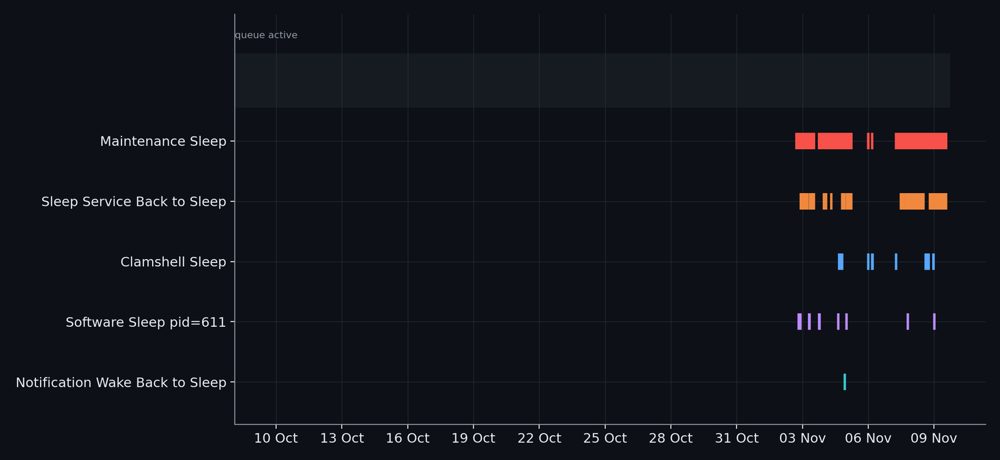

**Figure: What the machine did while the queue ran.** Every time the machine entered sleep between 02 Nov and 09 Nov, by the cause its own power log gives: 672 x Maintenance Sleep, 144 x Sleep Service Back to Sleep, 22 x Clamshell Sleep, 10 x Software Sleep pid=611, 1 x Notification Wake Back to Sleep. The power log itself begins on 2026-11-02, so nothing is known about earlier days. Read from `pmset -g log` when the figure is built, so it describes the machine that ran the queue; it records what happened, not why.

In [365]:
show_figure("eng_power_events")

## 12.4 The job queue, the runner and the guards; what the hardware taught

> **Field:** Software engineering

*Where this section sits:* every experiment in Parts VI to XI, and most of the figures, ran as a job of one queue on one laptop. This section says how that queue works, because the way it fails is a large part of what the project learned, and because a result is only as trustworthy as the run that produced it.

**Why a queue.** The experiments take hours, some of them days; the machine has 16 gigabytes of memory shared between its processor and its graphics unit (unified memory, 11.9) and room for one heavy job at a time; a run that goes on through the night must continue after an error and after a power cut, and nobody should have to remember what was done last. A **job queue** answers all three: the work is written down as a list of jobs, a program takes them one at a time, and what has been done is recorded in files that outlive the program.

**The jobs and the runner.** A job is a shell script, `queue/jobs/NNN_name.sh`; the number sets the order, and a job begins by sourcing `queue/lib.sh`, which gives it a few helpers. The runner (`scripts/queue_runner.sh`) goes through the jobs in the order of their names and runs the first one that is not finished; when it ends, the next starts at once. New job files are picked up while it runs, so the queue never has to be restarted. A job tells the runner what happened by its **exit status**, the number a program returns when it ends: 0 means done, and the runner records it by creating an empty file with the job's name in `queue/state/done`. The status 75 means "not ready": the code or the inputs that the job needs do not exist yet; the job is skipped, looked at again in the next round and never marked as failed. Any other status is a failure, which the runner tries once more before it records the job in `queue/state/failed` and goes on.

The distinction between not ready and failed is the most useful rule of the design. A long chain of experiments has many jobs that cannot start before another has finished; if each of them failed when its input was missing, the queue would be full of failures that mean nothing. The helpers make the difference easy to write: `need_file` ends the job with the status 75 until a file exists, `need_done` until named jobs have finished, `all_lower_done` until every job with a smaller number has finished, and `defer` for any other reason. The next cell runs the two that are easiest to see.

In [366]:
# The helpers that every job sources (queue/lib.sh), run for real in child processes. defer ends the job with the status 75, "not ready, try again later". chunk_status is the helper of the jobs that run in time-boxed chunks: it is given the name of the
# job and the number of tasks still to do, and answers 75 when this chunk made progress (come back for the next), 1 when it made none (a failed attempt) and 0 when nothing is left. It keeps the last number in a file, so the four calls below are
# four separate processes that remember each other, in a temporary folder so that the real state of the queue is not touched.
import subprocess
import tempfile

meaning = {75: "not ready, or progress made: try again later", 1: "no progress: a failed attempt", 0: "done"}
defer_run = subprocess.run(["bash", "-c", 'source queue/lib.sh >/dev/null 2>&1; defer "the file is missing"; echo never printed'], cwd=ROOT, capture_output=True, text=True)
helper_rows = [{"call": 'defer "the file is missing"', "prints": defer_run.stdout.strip(), "exit status": defer_run.returncode, "meaning": meaning[defer_run.returncode]}]
with tempfile.TemporaryDirectory() as scratch:
    for tasks_left in (100, 100, 40, 0):
        run = subprocess.run(["bash", "-c", f"source {ROOT}/queue/lib.sh >/dev/null 2>&1; chunk_status demo_job {tasks_left}"], cwd=scratch, capture_output=True, text=True)
        helper_rows.append({"call": f"chunk_status demo_job {tasks_left}", "prints": "", "exit status": run.returncode, "meaning": meaning[run.returncode]})
helper_table = pd.DataFrame(helper_rows)
show_table(helper_table, floatfmt=".0f")
assert list(helper_table["exit status"]) == [75, 75, 1, 75, 0]

| call | prints | exit status | meaning |
| --- | --- | --- | --- |
| defer "the file is missing" | not ready: the file is missing | 75 | not ready, or progress made: try again later |
| chunk_status demo_job 100 |  | 75 | not ready, or progress made: try again later |
| chunk_status demo_job 100 |  | 1 | no progress: a failed attempt |
| chunk_status demo_job 40 |  | 75 | not ready, or progress made: try again later |
| chunk_status demo_job 0 |  | 0 | done |

The first row is the whole of the "not ready" mechanism. The next four show the helper of the jobs that run in **time-boxed chunks**. A fit of a model for each task of a nested plan may take an hour and a half; a job that ran until it was finished would keep every shorter job behind it waiting. So such a job works for a fixed time, reports how many tasks remain and ends; the helper turns that number into a status: progress means come back later (75), the same number twice means nothing was done (1, which counts as a failure and eventually stops a job that is stuck), and zero means finished. The work is kept in a cache file per task, so the next chunk continues where the last stopped.

**Re-running and chains.** A job runs again when its flag is removed: the jobs named `requeue` (179, 188, 299) remove the flags of the jobs after a change so that they run once more, and the lint cleanup (job 295) removes the flag of the final TDI build for the same reason. This is deliberately simple: a dependency is a file that exists or does not, and a chain is a list of numbers.

**Guards.** The runner starts a second program beside it, `scripts/guards.sh`, whose comment says why each guard exists. The text printed by the next cell is that comment.

In [367]:
# What the runner recorded about itself, read from its own log (queue/logs/queue_stage.txt): one line for every start, every finish, every retry, every guard action. The word RUN is written before a job is tried, including a job that then answers
# "not ready", so most RUN lines are re-checks and the number to read is DONE.
import collections
import re

stage_lines = [line for line in (ROOT / "queue/logs/queue_stage.txt").read_text().splitlines() if line.strip()]
event_counter = collections.Counter(line.split()[2].rstrip(":") for line in stage_lines if len(line.split()) > 2)
first_entry = " ".join(stage_lines[0].split()[:2])
guard_swaps_gib = [float(m.group(1)) / 1024 for line in stage_lines if " GUARD" in line for m in [re.search(r"swap used ([\d.]+)M", line)] if m]
event_table = pd.DataFrame({"event": ["DONE", "RETRY", "FAILED", "GUARD", "BATTERY", "IDLE"], "meaning": ["a job finished", "a job failed once and was tried again", "a job failed twice and was recorded as failed", "the memory guard killed the running engine", "a notification about the battery", "nothing could run"],
                            "lines in the log": [event_counter.get(k, 0) for k in ("DONE", "RETRY", "FAILED", "GUARD", "BATTERY", "IDLE")]})
show_table(event_table, floatfmt=".0f")
n_done_events, n_guard, n_failed_events, n_retry = (int(event_table.set_index("event").loc[k, "lines in the log"]) for k in ("DONE", "GUARD", "FAILED", "RETRY"))
n_log_lines, max_swap_at_guard = len(stage_lines), max(guard_swaps_gib)
state_dir = ROOT / "queue/state"
n_done_now, n_failed_now = len(list((state_dir / "done").iterdir())), len(list((state_dir / "failed").iterdir()))
n_jobs_now = len(list((ROOT / "queue/jobs").glob("*.sh")))
guard_header = [line.lstrip("# ").rstrip() for line in (ROOT / "scripts/guards.sh").read_text().splitlines()[1:8] if line.startswith("#")]
print("\n".join(guard_header))

Shared safety functions for the long structure runs on this 16 GB Mac (source this file; set LOGS first).
Each guard exists because of a real incident:
* battery: a flat battery once stopped a night's run. Runs on battery are allowed; nothing waits or freezes for the
charger, the guard only raises a macOS notification at BATTERY_WARN_PCT and again at BATTERY_LOW_PCT while off AC;
* memory: five Boltz samples in parallel exhausted swap and the Mac took a watchdog kernel panic -- the MPS
allocator is trimmed early (a hard 0.9x cap made every forward pass fail, so the engines need the
headroom) and the running engine is killed if free memory stays under MIN_FREE_PCT.


| event | meaning | lines in the log |
| --- | --- | --- |
| DONE | a job finished | 486 |
| RETRY | a job failed once and was tried again | 39 |
| FAILED | a job failed twice and was recorded as failed | 24 |
| GUARD | the memory guard killed the running engine | 25 |
| BATTERY | a notification about the battery | 58 |
| IDLE | nothing could run | 86 |

Each guard is the answer to something that happened. The memory guard is the one that matters: five Boltz samples in parallel used up the memory and the swap file, and the machine took a **kernel panic**, which is the operating system stopping itself because it cannot continue. From then on one sample at a time, a ceiling on what the graphics unit may take, and a guard that kills the running structure engine when the free memory stays under a few percent. A hard ceiling of 0.9 times the memory, tried first, made every forward pass of the engines fail, so the allowance was loosened and the guard does the protecting. The battery guard asks nothing of the run: a flat battery once stopped a night's run, and the guard therefore sends a notification at two levels of charge and never waits or stops anything (the function that used to wait is kept as an empty one, so that older jobs still call it).

The runner is started under `caffeinate`, which keeps the machine awake while it runs; a run that looks hung may turn out to be a machine that went to sleep, and that mistake was made once in this project, so the first question about a quiet job is whether the machine slept.

The runner's own log shows what this meant in practice. It holds 16565 lines since 10-08 03:02:02. 486 DONE lines are jobs that finished, 39 are retries and 24 are failures that were recorded; the jobs that failed were repaired and queued again, and 0 of the 177 jobs are in the failed state as this notebook is built, while 176 are done. The memory guard acted 25 times, with the swap file as large as 9.2 gibibytes at the worst moment; each of these would otherwise have been a crash of the machine or of the run.

**What the hardware taught, in six rules.** A job that is not ready is not a failed job (the status 75). A long job works in chunks and remembers its place in files, so a restart costs a chunk and not a day. The state lives in the repository and not in a temporary folder, which the machine empties when it restarts. The memory of a laptop is shared between its parts, so a guard must watch the free memory and not only the load. Nothing is allowed to wait for a person (the battery), and everything that can hang is given a time limit (the tests, 12.3). And a quiet job is first suspected of sleeping, not of being broken.

*On what actually ran.* The first cell runs `defer` and `chunk_status` for real, in child processes and a temporary folder. The second reads the runner's log, the counters of `queue/state` and the header of `guards.sh`. The runner itself ran the jobs; the notebook only reads what it left.

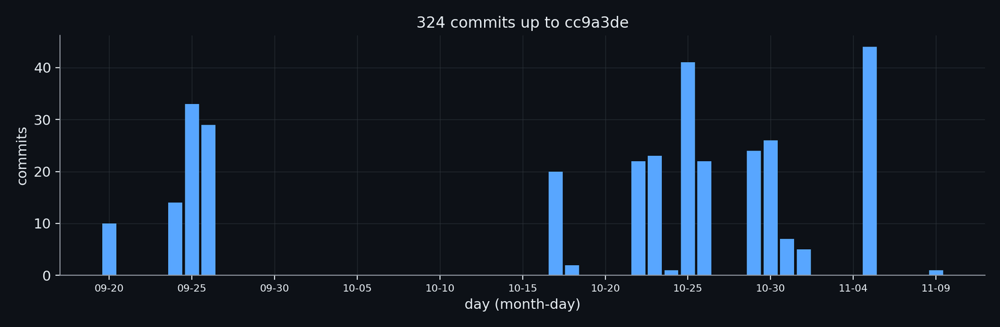

**Figure: The history of the repository.** The history of the repository as the number of commits of each day, from the first commit on 2026-09-20 to the last on 2026-11-09: 324 commits on 17 days up to commit cc9a3de, the busiest day with 44 (2026-11-05). The history is kept as it is, never squashed, so that the date of every declared gate stays checkable against the date of the result that it judged; the commit messages say what each commit declared or found.

In [368]:
show_figure("eng_commit_timeline")

## 12.5 The documents that are generated, and the checks on them

> **Field:** Software engineering · Data science

*Where this section sits:* 12.1 to 12.4 made the runs repeatable. A repeatable run is wasted if the documents that describe it are written by hand, because a number typed into a document begins to drift away from the log the moment it is typed. The answer of the project is to generate every number, and to check the generated files against the logs they came from.

**The method report and the ledger of negative results.** `METHOD_REPORT.md` and `NEGATIVE_RESULTS.md` are produced by `cypmode/audit/method_report.py` from the repository's own logs, tables and audit report. Every number in them is copied by code from one of those sources; the prose around the numbers is fixed text. A value whose source does not exist yet is written as `(pending: job)`, so the report cannot contain a number that nobody computed. The limitations are kept as data (`cypmode/audit/limitations.yaml`): the wording is written by hand, and each value in it is filled in from the audit through a named key, so that a limitation that quotes a figure quotes the figure the audit computed. The same idea reaches the other documents: the README and the architecture specification have blocks between markers (the final stack, the verdicts of the gates, the structure recipe) that the program `cypmode/audit/docs_state.py` rewrites, and the text around them is written by hand.

**Two sections of the report that show the whole.** The report holds, before its results, a section on the architecture of the two tracks, step by step, and a section on the exploration, and both are generated: the first reads the default candidates, the feature store, the blend, the call rates and the structure recipe from the code and the final manifests; the second counts the verdicts of the ledger by the kind of idea each tested (`cypmode/audit/ledger_kinds.py`, shared with the figure of the map of what was explored), gives the accounting of the number of attempts, the controls and the audit. `tests/test_method_report_sections.py` checks that the sections exist, come in order and that no family of the ledger is left without a kind.

**Provenance of what the code generates.** A generated file is only as useful as the knowledge of where it came from. `CITATION.cff` is the single source of the author, the repository, the identifiers and the licence; `cypmode/provenance.py` reads it, prints the citation when a script that generates data starts, and writes `PROVENANCE.json` beside the predictions, the feature table and the final outputs (once; an existing file is never rewritten, and the submitted files are never touched, because their SHA-256 is recorded). Audit section 20 compares the name, the repository and the DOI across the citation file, the README, `NOTICE` and the archive metadata, and `tests/test_provenance.py` checks that every script that generates data announces its origin. The programs never refuse to run: a licence, not a program, is what asks that the notice stays (`USE_AND_CITATION.md`).

**The check on them.** `python -m cypmode.audit.method_report --check` regenerates both reports in memory and fails when the files on disk differ. This is the claim-to-evidence check of the audit. A number edited by hand is a difference, and so is a report that was not regenerated after a log changed; the check does not know which, and does not need to. The cell below runs it.

In [369]:
# The two generated reports and the blocks of the other documents that are generated. A value whose source does not exist yet is written as (pending: job) in METHOD_REPORT.md, so that the report cannot contain a number nobody computed; the claim-to-evidence
# check regenerates both reports in memory and fails when the files on disk differ, so a number edited by hand is a difference. The check is run here as the audit runs it.
import re
import subprocess
import sys

method_report = (ROOT / "METHOD_REPORT.md").read_text()
negative_report = (ROOT / "NEGATIVE_RESULTS.md").read_text()
report_sections = re.findall(r"^## (\d+\. .+)$", method_report, re.M)
n_pending = len(re.findall(r"\(pending:", method_report))
n_limitations = len(re.findall(r"^- \*\*L\d+\*\*", method_report, re.M))
check_run = subprocess.run([sys.executable, "-m", "cypmode.audit.method_report", "--check"], cwd=ROOT, capture_output=True, text=True, timeout=600)
report_is_fresh = check_run.returncode == 0
check_line = (check_run.stdout.strip().splitlines() or ["(no output)"])[-1]
generated_blocks = {name: re.findall(r"<!-- generated:(\S+) begin", (ROOT / name).read_text()) for name in ("README.md", "CYPMode_Architecture_Specification.md")}
block_table = pd.DataFrame({"document": list(generated_blocks), "generated blocks": [", ".join(v) for v in generated_blocks.values()], "number": [len(v) for v in generated_blocks.values()]})
show_table(block_table, floatfmt=".0f")
section_table = pd.DataFrame({"section of METHOD_REPORT.md": report_sections})
show_table(section_table, floatfmt=".0f")
negative_gates = len(re.findall(r"\| NOT MET \|", negative_report))
print(check_line)
freshness_sentence = "At the time of this build the check passes: the two files are what the code generates from the logs." if report_is_fresh else "At the time of this build the check reports the files as stale, which is what it is for: the final chain regenerates them (job 910) before the notebook is built."

claim-to-evidence check: OK, both files equal a fresh generation


| document | generated blocks | number |
| --- | --- | --- |
| README.md | innovation, post-deadline, project-map, final-stack, gate-verdicts, structure-recipe | 6 |
| CYPMode_Architecture_Specification.md | innovation, final-stack, structure-recipe | 3 |

| section of METHOD_REPORT.md |
| --- |
| 1. Scope and what is not claimed |
| 2. Data and the label rule |
| 3. Architecture of the two tracks |
| 4. Exploration: what was tried and with what result |
| 5. Scoring-set-aware yardstick |
| 6. Final TDI stack (chosen by the pre-registered gate rule) |
| 7. Selection-aware CYP2D6 model |
| 8. Physics-, SAR-, committee-, embedding-, cross-isoform and weighting-based additions |
| 9. Calibration |
| 10. Test-like holdout |
| 11. Structure track |
| 12. Negative results |
| 13. Limitations |
| 14. Reproduction, credits and prior art |
| 15. After the deadline: the released labels and structures |

In [370]:
# The two checks that look at the repository from outside. The first is the consistency of the queue: every module and every script that a job calls must exist, and a job must not wait for code that does not exist.
# The second is the readiness scan: three of its detectors are run on a string made for the purpose (the private path, the key and the address are put together at run time, so that this notebook does not contain what the scan looks for).
from cypmode.audit import checklist as checklist_module
from cypmode.audit import public_readiness as readiness

queue_problems = checklist_module.job_problems()
n_checklist_problems, n_jobs = len(queue_problems), len(list(checklist_module.JOBS.glob("*.sh")))
sample = "see " + "/Use" + "rs/someone/project/file.csv, token " + "hf_" + "a" * 34 + ", write to " + "some.one" + "@" + "example.org"
found_by_scan = readiness.scan_text(sample)
scan_table = pd.DataFrame({"detector": list(found_by_scan), "matches in the sample": [len(v) for v in found_by_scan.values()]})
show_table(scan_table, floatfmt=".0f")
n_detectors_fired = len(found_by_scan)
held_back_lines = [line for line in (ROOT / ".gitignore").read_text().split("# >>> HELD BACK", 1)[-1].split("# <<< HELD BACK", 1)[0].splitlines() if line and not line.startswith("#")] if "# >>> HELD BACK" in (ROOT / ".gitignore").read_text() else []
n_held_back = len(held_back_lines)

| detector | matches in the sample |
| --- | --- |
| private path | 1 |
| credential | 1 |
| e-mail | 1 |

In [371]:
# The size of what the map of the project describes, counted by the module that writes the map.
from cypmode.audit import project_map

project_map_modules = project_map.module_paths()
project_map_jobs = len(project_map.job_facts())

At the time of this build the check passes: the two files are what the code generates from the logs. The method report has 15 numbered sections, 16 logged limitations and 1 value(s) still pending, and the ledger of negative results has 205 rows marked NOT MET. The README and the specification hold the generated blocks listed in the first table.

**The artifacts that present the results.** The same discipline covers the files that show the results to a reader: the README card, the poster, the film and the figures. `cypmode/audit/artifacts.py` keeps the record `audit/artifacts.json`, written by the builders of those four artifacts: for each one the SHA-256 of every file it wrote, a fingerprint of the numbers it was built from (everything that the film's facts module reads from the final outputs, the ledger, the audit and the repository), and the builder's own digests. Its `verify`, called by the pre-submission gate, asks three questions of every artifact: whether each recorded output is still the file the builder wrote, whether the numbers it shows are the final ones (the recorded fingerprint equals the current one), and whether the artifact's own source still produces the same content. The card's HTML and the DOM of every frame of the film and of the poster are recomputed and compared exactly; the PNG and the H.264 files are not compared pixel by pixel, because rendering the same frame twice differs in a few dozen pixels by less than one level of 255 and the encoder adds its own differences. The gate fails an artifact that was edited after its build, one built from numbers that have changed since, and one whose source no longer reproduces it. The interactive card, one self-contained page built by `docs/card/build_interactive_card.py` in the queue job `946_interactive_card`, is recorded and checked the same way (its HTML is recomputed and compared exactly, `tests/test_interactive_card.py` checks that the iron–nitrogen distance measured on the coordinates it embeds equals the deposited one and that the page makes no request). The notebook itself has two editions for the same reason as the card: results for the blinded compounds must not be public before the challenge closes, and the notebook must be. A cell can be marked `held_back`; the public edition (the queue job `947_notebook_public`, `python -m notebooks.build_notebook --public`) runs it all the same, so that the variables of the later cells exist, but shows a note instead of its outputs and fails when any cell still names an official structure ligand or five or more blinded compounds (`tests/test_notebook_public.py`). The complete edition replaces it when the challenge has closed.

**The queue is checked too.** Every job of the queue is a shell script that calls modules and scripts of the repository, and a job can promise something that does not exist. `cypmode/audit/checklist.py` makes the ways in which a job drifts from the repository checkable by a script: a job that calls a module that does not exist, a job that waits for a code file that does not exist (which would make it answer "not ready" for ever), and a script that does not exist. The workflow of 12.3 runs it on every change. In this build it finds 0 problems in 177 jobs.

**What must not be published.** The public-readiness scan (`cypmode/audit/public_readiness.py`) looks at the files that git tracks or would add. Its detectors find private paths on the author's machine, strings shaped like credentials, e-mail addresses other than the public contact lines, files near the size limit of the hosting service, long verbatim runs from the books used while writing, and, until the challenge closes, results for the blinded compounds: a file that names five or more of them, or a table with one row per blinded compound (750 for the TDI test set, 20 for the structure set), is a prediction and must not be pushed. The files that are held back are the 0 patterns of the HELD BACK block of `.gitignore`, and the scan can also read every blob of the git history, because a push carries the history. The table shows three detectors firing on a sample that was made for the purpose.

**The version.** Five files state the version of a release: `pyproject.toml`, `CITATION.cff`, `.zenodo.json` and the citation entries of the README and of `USE_AND_CITATION.md`. `scripts/bump_version.py` sets the version, the date and the DOI of the release in all five, and in none of them if one of its patterns does not match exactly once, so that the files cannot disagree; the DOI that stands for all versions is not touched. A release that is not deposited on Zenodo and so has no DOI of its own is set with `--no-doi`: the identifiers of the previous release leave the citation file, the two entries cite the DOI of all versions, and the two documents say which release is the last one that is deposited. `tests/test_bump_version.py` runs both modes on small copies of the five files, so that a change in the files of the repository cannot break the test, and checks on the real files only that the three version fields agree.

**A map of the project.** A reader who opens the repository meets 179 modules and 177 jobs and needs to know where things are and what depends on what. The folder `docs/map` answers it with four pages: the code (every package and module, what it does and what it imports), the queue (every job, what it waits for, and the chain that rebuilds and checks the project), the flow of the data (from the inputs through the jobs and the logs to the reports) and the evidence (the kinds of idea that were tried). Each page has a diagram and a table. The diagrams are written in Mermaid, a text format for diagrams that GitHub draws when it shows a Markdown file, so a page is plain text that a version control system can compare. No page is written by hand: `cypmode/audit/project_map.py` writes them from the first sentence of each docstring, the header comment of each job and counts of the files, and it reads only tracked sources, never a log or a result, so that a copy of the repository regenerates the same pages. Job `921_docs_state` writes them with the other generated blocks and then runs `python -m cypmode.audit.project_map --check`, which fails when a page differs from the code. The tests in `tests/test_project_map.py` check that every module and every job appears exactly once, that the counts on the arrows equal an independent recount of the imports that cross a package, that every diagram is closed, that the wording rules of 12.6 hold for the pages, and that the committed pages are what the code writes. The same data are also written as one page that can be explored, `docs/map/explorer.html`: a graph of every module coloured by package, a grid of every job, the flow of the data and the kinds of idea, with a search box, and for each module and job what it imports, what imports it, which job runs it, which test imports it and which section of this notebook names it. It is one file with its data inside, so it opens in a browser without a network, and the Pages site publishes it; the tests check that it lists every module and every job once and that it loads nothing from elsewhere.

3 of the detectors fired on the sample, as they must. What the scan cannot do is find what it was not taught to look for: it is a net with a mesh, and the mesh is the list of patterns. The final chain runs it (job 930) and its findings that code can fix are fixed; the others are for a person to decide, and the push is not made before they are.

*On what actually ran.* The first cell runs the claim-to-evidence check as a child process and reads the two reports and the generated blocks. The second calls the queue check and the scan's `scan_text` in the notebook's process.

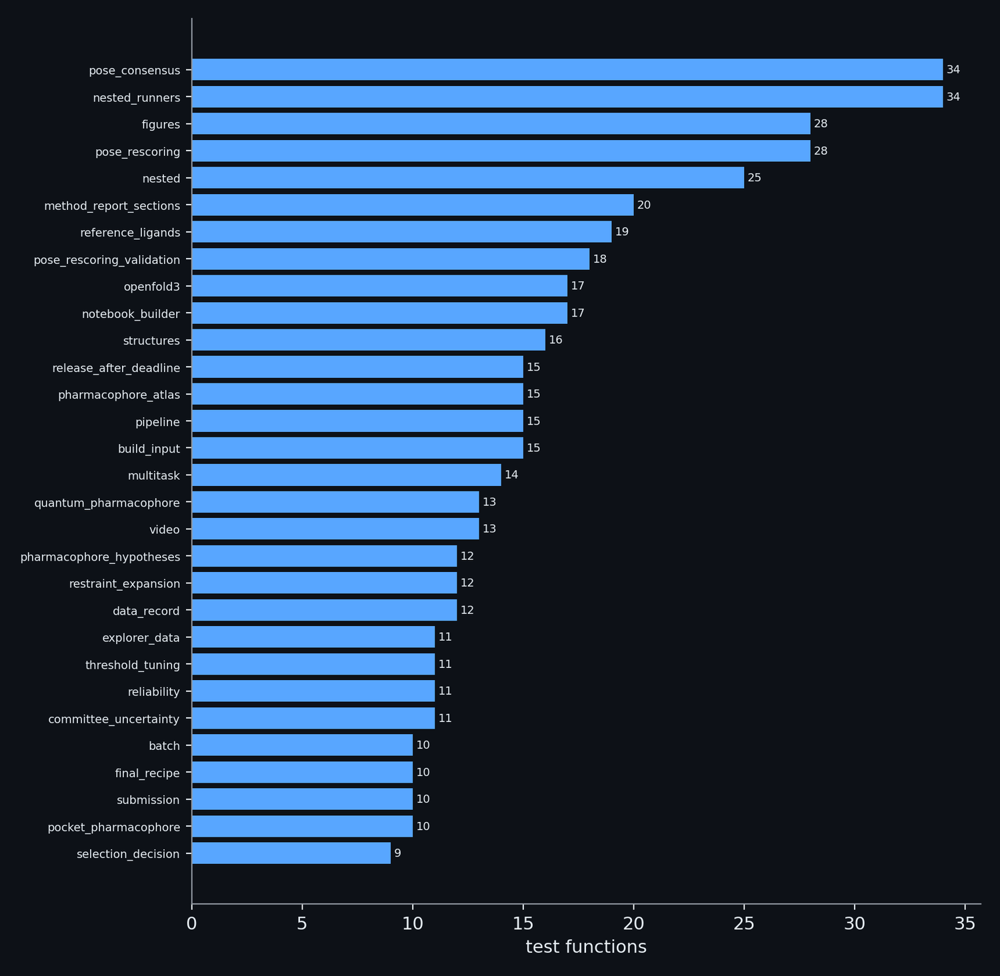

**Figure: The test suite by module.** Test functions per test module of the repository: 1085 test functions in 156 modules (parametrized cases count once). The audit runs the whole suite and the full report twice and requires the two reports to be byte-identical.

In [372]:
show_figure("eng_tests_by_module")

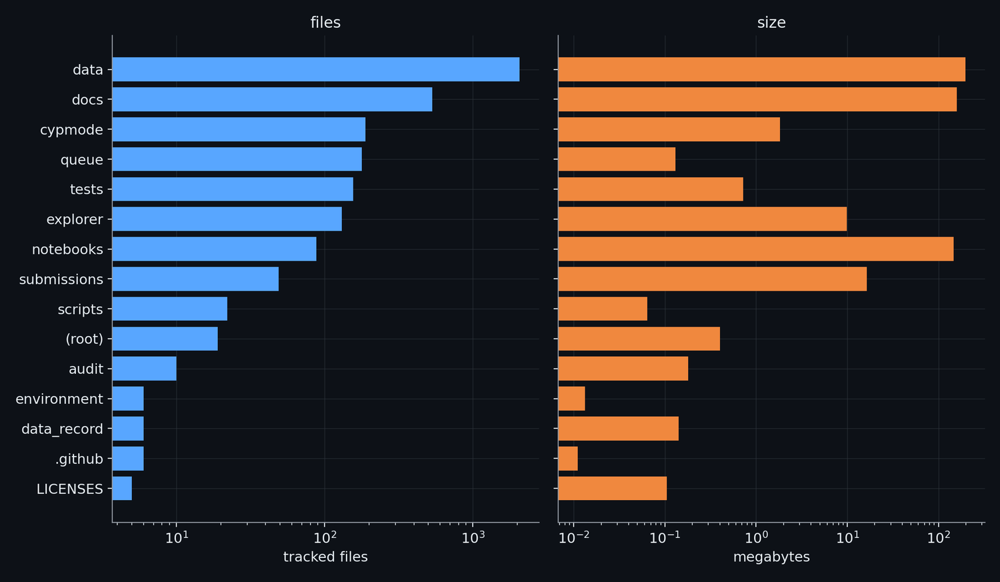

**Figure: The repository by folder.** The repository by top-level folder: the number of files that git tracks (3462 in all, 534 MB) and their size. The three folders with the most files are data (2066), docs (531), cypmode (189). The code is in `cypmode/` (the engines of the two tracks and the audit), the tests in `tests/`, the results and caches that are small enough for git in `data/`, the notebook in `notebooks/`, the figures, the card and the film in `docs/`, and the queue that runs the experiments in `queue/`; what is too large or must wait until the deadline is listed in `.gitignore`.

In [373]:
show_figure("eng_repository_map")

## 12.6 The rules that never change, and how each is enforced

> **Field:** Software engineering

*Where this section sits:* the last four sections described mechanisms. This one lists the rules those mechanisms exist for, which no result or deadline changes, and says for each how it is enforced. The answer is that some are enforced by a program and some only by a person, and the section says which.

A rule that is only a promise is weakest at the moment it matters most: late, tired and near a deadline, the temptation is to make an exception once. The project's habit is therefore to turn every rule that can be turned into a check into a check, and to say plainly which ones cannot be. The next cell pairs each rule with its mechanism; both are written by hand, and the cell fails if a file it names does not exist.

In [374]:
# The rules that never change, each with the mechanism that enforces it. The rules and the mapping from rule to mechanism are written here and every mechanism it names is checked to exist; a rule that nothing
# enforces by program is labelled as a rule of procedure, because that is what it is.
rules = [
    "No submission and no push without the explicit go-ahead of the author; local commits are made as the work goes",
    "No leaderboard probing (no flipping compounds to read labels); the live board scores half the test set, so it is a sanity check, never a tuning target",
    "Numbers are quoted from the corrected procedure only (nested cross-validation, the corrected resampled t, permutation nulls); no bootstrap of fixed predictions",
    "Credit another team's idea only if it is published with a link, under the publication's name, and never by leaderboard alias",
    "Code comments in English",
    "Machine safety: one heavy job at a time, a guard on memory and on free disk, results mirrored off the temporary folder",
    "Stop rule: any idea that fails its gate is written down as a negative result and dropped, not tuned until it passes",
]
enforcement = [
    ("No submission and no push", "procedure, with a program behind part of it", ["scripts/release_after_deadline.py", "cypmode/audit/pre_submission.py"]),
    ("No leaderboard probing", "procedure; no program of the repository submits anything", ["cypmode/challenge/submission.py"]),
    ("Numbers are quoted from the corrected procedure", "the generated report and its claim-to-evidence check", ["cypmode/audit/method_report.py", "cypmode/challenge/model_comparison.py"]),
    ("Credit another team's idea", "the credit-hygiene section of the audit and the credits section of the report", ["cypmode/audit/sections.py", "cypmode/audit/method_report.py"]),
    ("Code comments in English", "the audit (section 18 for the code, section 21 for the text files) and the readiness scan", ["cypmode/audit/sections_extra.py", "cypmode/audit/public_readiness.py"]),
    ("Machine safety", "the guards of the runner", ["scripts/guards.sh", "scripts/queue_runner.sh"]),
    ("Stop rule", "the ledger of negative results", ["cypmode/audit/method_report.py"]),
]
rule_rows = []
for rule in rules:
    match = next((e for e in enforcement if rule.startswith(e[0])), None)
    rule_rows.append({"rule (first words)": rule[:70], "enforced by": match[1] if match else "(none recorded)", "files exist": all((ROOT / f).exists() for f in match[2]) if match else False})
rule_table = pd.DataFrame(rule_rows)
show_table(rule_table, floatfmt=".0f")
n_rules = len(rule_table)
n_by_program = int(rule_table["enforced by"].str.contains("hook|audit|guard|check|ledger|report").sum())
assert rule_table["files exist"].all()
hooks_present = {"pre-commit": (ROOT / ".git/hooks/pre-commit").exists()}

| rule (first words) | enforced by | files exist |
| --- | --- | --- |
| No submission and no push without the explicit go-ahead of the author; | procedure, with a program behind part of it | True |
| No leaderboard probing (no flipping compounds to read labels); the liv | procedure; no program of the repository submits anything | True |
| Numbers are quoted from the corrected procedure only (nested cross-val | the generated report and its claim-to-evidence check | True |
| Credit another team's idea only if it is published with a link, under  | the credit-hygiene section of the audit and the credits section of the report | True |
| Code comments in English | the audit (section 18 for the code, section 21 for the text files) and the readiness scan | True |
| Machine safety: one heavy job at a time, a guard on memory and on free | the guards of the runner | True |
| Stop rule: any idea that fails its gate is written down as a negative  | the ledger of negative results | True |

There are 7 rules, and 5 of them have a program behind them. The two that are rules of procedure are the ones that concern an act of the author, not a property of a file: nothing is submitted or pushed without the author's explicit go-ahead, and the portal is never used to read the labels. For the first there is a program that helps (the release script refuses to publish anything before the deadline, and the pre-submission gate says whether everything is finished, consistent and fresh), but the decision itself is a person's, and the rule says so.

**A hook.** A **hook** is a small program that git runs at a fixed moment. The repository uses one, kept in the local copy and not among the files that git stores: it runs before each commit, applies the linter to the files that are staged and looks for merge-conflict markers left in them. The hook is deliberately fast, so that nobody is tempted to skip it, and skipping it is not allowed; when the new modules were first committed, it was the hook that showed how many findings they carried, and the cleanup was then made a job of the queue (job 295) with its own checks and a rollback. In this build the hook is present: pre-commit True.

**A rule that caught its author.** The rule that no result for a blinded compound is published until the challenge closes is enforced by three things together: the HELD BACK block of `.gitignore`, the readiness scan of 12.5, and a test (`tests/test_release_after_deadline.py`) that fails if any file that would be pushed names blinded compounds. The test earned its place late in the project. A log of the force-field relaxation, written by a job of the queue, named the twenty blinded ligands; nobody had listed it as held back, nobody had noticed, and the test failed on it during the lint cleanup. The log was added to the HELD BACK block the same day. The rule had not been broken, because nothing had been pushed, but the next push would have broken it, and only the check knew. The next cell runs that test file and the dry run of the release script.

In [375]:
# One of the programs that enforce a rule, run live: the test file of the hold-back, which asserts that nothing that names a blinded result would be pushed, and the release script in its dry-run form, which writes nothing and says what it finds.
# The script refuses to release anything before the end of the challenge; the dry run only looks.
import subprocess
import sys

test_run = subprocess.run([sys.executable, "-m", "pytest", "tests/test_release_after_deadline.py", "-q", "-p", "no:cacheprovider"], cwd=ROOT, capture_output=True, text=True, timeout=600)
test_summary = [line for line in test_run.stdout.splitlines() if " passed" in line or " failed" in line][-1]
dry_run = subprocess.run([sys.executable, "scripts/release_after_deadline.py", "--dry-run"], cwd=ROOT, capture_output=True, text=True, timeout=120)
dry_run_line = dry_run.stdout.strip().splitlines()[0]
print(test_summary)
print(dry_run_line)
assert test_run.returncode == 0 and dry_run.returncode == 0

15 passed in 0.32s
HELD BACK block not found; held-back sections not found


The test file has passed and the dry run reports what the release script would change, without writing anything. After the deadline the script, run without the dry-run option, removes the HELD BACK block and switches on the parts of the README that were held back; before the deadline it refuses.

**What the checks cannot do.** They catch what they were taught to look for: the patterns of the scan, the files of the HELD BACK block, the numbers that the report copies. They do not decide whether a method is right, whether a gate was chosen fairly, or whether a sentence in a document is true. Those are the work of Parts VI and IX, and of the person who reads the text word by word. Engineering for trust is the part that makes the other parts checkable; it is not a substitute for them.

*On what actually ran.* The first cell checks that the files that enforce each rule exist; the hook is looked for in the local copy of the repository. The second runs the test file of the hold-back and the release script with `--dry-run` as child processes.

In [376]:
# The explorer of 12.7: what its data bundle holds, the version of the notebook program that is pinned, how many cells the app has. Every number is read from the files.
import json
import re

explorer_manifest = json.loads((ROOT / "explorer/public/manifest.json").read_text())
explorer_tables = {name: entry["rows"] for name, entry in explorer_manifest.items() if "rows" in entry}
explorer_oof = {name: entry for name, entry in explorer_manifest.items() if "candidates" in entry}
explorer_lock = (ROOT / "environment/requirements-lock-marimo.txt").read_text().splitlines()
explorer_version = next(line.split("==")[1] for line in explorer_lock if line.startswith("marimo=="))
explorer_n_pins = len(explorer_lock)
explorer_cells = len(re.findall(r"^@app\.cell", (ROOT / "explorer/cypmode_explorer.py").read_text(), re.M))
explorer_sizes = {name: round((ROOT / "explorer/public" / name).stat().st_size / 1e6, 1) for name in explorer_manifest}
print(explorer_tables, {name: (entry["candidates"], entry["compounds"]) for name, entry in explorer_oof.items()}, explorer_version, explorer_n_pins, explorer_cells)

{'ledger.csv': 187, 'paired.csv': 188, 'selectors.csv': 150, 'poses.csv': 80, 'rules.csv': 80, 'excerpts.csv': 404, 'candidates.csv': 113, 'blocks.csv': 24} {'oof_CYP3A4.csv.gz': (113, 2334), 'oof_CYP2D6.csv.gz': (107, 1493)} 0.25.2 44 27


## 12.7 An explorer for the finished results

> **Field:** Software engineering · Data science

*Where this section sits:* the notebook that you are reading is built once, from the repository, and every number in it is fixed at build time. A reader who wants to ask a question that the notebook did not answer, such as what would have passed if a threshold had been different, or how one candidate does on one enzyme, has to run code. This section describes the small program that lets them do it without running anything expensive, and the rules that keep it from doing more than that.

**The problem with notebooks, and a reactive one.** In an ordinary notebook, the cells keep their results in a shared memory and can be run in any order. If a cell is changed and a later cell is not run again, or if a cell is deleted but the variable that it made is still in memory, the page shows numbers that no longer follow from the code on it: a stale state, which is a well-known source of wrong results. A **reactive notebook** removes the cause. The program reads every cell, builds the graph of which cell uses which variable, runs a cell again whenever a variable it uses changes, and refuses a notebook in which two cells define the same variable. The one used here is marimo (the marimo team, Apache licence 2.0, version 0.25.2 in the pinned environment `environment/requirements-lock-marimo.txt`, 44 pinned packages); the charts are Altair, a Python interface to the Vega-Lite grammar of graphics.

**What the explorer shows.** `explorer/cypmode_explorer.py` has 27 cells and five views, each driven by a few controls. The ledger of gates (every verdict registered before its result existed, 187 of them) can be filtered by the kind of idea and by the verdict, and one experiment can be opened to read its verdicts, every paired comparison that its log printed and the lines themselves. The second view moves the two thresholds of the registered rule, the smallest gain and the corrected p, over the 188 paired comparisons, and shows what a different rule would have let through; the registered values are the starting position and moving a slider never changes a verdict. The third shows the selection rules of the nested cross-validation, for all outer folds or for one, the fourth the poses of the crystal-anchored benchmark by engine and by rule, and the fifth the stored out-of-fold predictions: every complete candidate of each enzyme (113 for CYP3A4 and 107 for CYP2D6) on the 2334 and 1493 training compounds, ranked by AUC, with the ROC curve of the chosen candidate and the confusion matrix and the Matthews correlation coefficient at the chosen call rate. Two controls of the fifth view choose what is ranked: the outer fold (the AUC is then computed on the compounds that the fold scored, in each of the three repeats, and the table of the chosen candidate shows its AUC fold by fold) and the feature blocks that a candidate must use (a candidate is kept when it uses every selected block; the 24 blocks are defined in `cypmode/explorer/data.py`, and each candidate is listed with its family and its blocks). A last table gives, for each block, the mean AUC of the candidates that use it against those that do not; it is descriptive, since a block comes with a family of models and with other blocks, and the verdict on a block is the one of the gate ledger, which compares the same model with and without it.

**What it is not allowed to do.** The explorer holds no model and starts no run. It reads the bundle in `explorer/public` and nothing else: a nested cross-validation, a co-folding run or a queue job started by a reactive cell would be an enormous computation begun by a mistake, and caching does not remove that risk, so none of them is reachable from it. The bundle is built by `cypmode/explorer/data.py` (the queue job `906_explorer_bundle` rebuilds it after the last verdict, and `tests/test_explorer_data.py` tests it): it copies the verdicts and the paired comparisons out of the run logs, the nested tables, the benchmark of the public crystal ligands and the stored outer-fold predictions of the training compounds, and then checks itself. The check refuses a table that names a blinded compound, that mentions a path of the HELD BACK block of `.gitignore` or that has the number of rows of one of the two blinded sets, and the predictions are read only from the outer-validation tasks, so that no row of the blinded test set can enter. The tables add up to 2.8 MB, which is what the repository publishes of the results and what a browser has to fetch.

**The first start.** Nothing has to be installed or activated before the explorer is opened. The launcher (`scripts/explorer.sh`, and `run_cypmode.bat` on Windows) looks for the environment `.venv-marimo` and for the file of requirements that the notebook needs, a lock with every package pinned to one version; if the environment is missing, or if it was built from a different file, the launcher builds it, which takes a few minutes once, and the next start is immediate. It uses Python 3.11 or newer when the machine has one. When the machine has none, the launcher says so, announces that it can download `uv` (a small installer from Astral, written in Rust) into the folder `.tools` of the repository, and waits for a key, because it would run code that it fetched; `uv` then fetches Python and the packages without any right of an administrator. `bash scripts/explorer.sh plan` says which notebook and which requirements would be used and whether the environment is ready, and changes nothing.

**Forms.** `bash scripts/explorer.sh` runs the notebook as an application or in the editor, and exports it as a static HTML page, as a Jupyter notebook with its outputs, or as a **WebAssembly** page: the Python runs inside the reader's browser (Pyodide, loaded from a content-delivery network) with the data files bundled next to the page, so that no server is needed, at the price of the browser's memory limit of two gigabytes. The export places a markdown file of the program's own instructions beside the page, which the script removes so that the published folder holds only the page and its data. The page bundles the front end of marimo (the marimo team, Apache licence 2.0), as every export of the program does; that front end contains marimo's own code for optional features of the editor, which is marimo's, is not shown on the exported page and plays no part in what the explorer computes. `NOTICE` records it. The workflow `.github/workflows/pages.yml` exports the explorer on a push that changes it and publishes it, with the interactive card once that is in the repository, as pages of the repository; it does nothing until Pages is enabled with the source GitHub Actions, which is set in the settings of the repository. The exported pages contain the front-end files of marimo itself. The interface strings in them, among them those of the editor's assistant panels, which the run mode does not load, belong to the library and are not part of the project.

*On what actually ran.* The cell of this section read the manifest of the bundle and the pinned versions. The app was started as an application and as a WebAssembly page and its controls were moved in a browser; the bundle builder and its tests ran as described. The explorer is a reader of finished results, nothing in it computes a result that the repository does not already hold, and no statement of this notebook depends on it.

In [377]:
# The complete explorer of 12.7: its sections, its simulators and its tests, counted from its files.
complete_parts = json.loads((ROOT / "explorer/full/data/sections.json").read_text())["parts"]
complete_n_sections = sum(len(part["sections"]) for part in complete_parts)
complete_in_app = set(re.findall(r'"(\\d+\\.\\d+)": sim_', (ROOT / "explorer/full/app.py").read_text()))
complete_in_parts = {number for path in sorted((ROOT / "explorer/full/simulators").glob("part_*.py")) for number in re.findall(r'"(\\d+\\.\\d+)": ', path.read_text().split("SIMS = {")[-1])}
complete_n_live = len(complete_in_app | complete_in_parts)
complete_n_modules = len(list((ROOT / "explorer/full/simulators").glob("*.py"))) - 1
complete_n_tests = sum(len(re.findall(r"^def test_", path.read_text(), re.M)) for path in (ROOT / "explorer/full/tests").glob("test_*.py"))
complete_data_mb = round(sum(path.stat().st_size for path in (ROOT / "explorer/full/data").rglob("*") if path.is_file()) / 1e6, 1)
print(complete_n_sections, complete_n_live, complete_n_modules, complete_n_tests, complete_data_mb)

124 0 40 27 6.2


**The complete explorer.** The folder `explorer/full` holds the explorer as this notebook made interactive: one page for each of the 124 sections, in their order and under their parts, and a simulator on each of them (0 are registered, in 40 small modules of its folder `simulators`). A simulator runs the functions of the project itself (the label rule, the corrected resampled t, the patterns of the Type II motif, the blocks of the feature store, the function that builds the input of a prediction) on what the reader gives it, a molecule, a pair of potencies, a noise level or the strength of an inhibitor, and shows what the section shows for the real data. Where a section is told by experiments that took hours, such as the stacks of Part IX or the co-folding of Part XI, its page replays the stored verdicts and the paired differences of those experiments, with a control for the level of the gate, and says that it is a replay. The pages of Part XI hold viewers of the pockets of the predicted structures and of the twenty submitted ones. The tables that the pages read (6.2 MB in all) are built by `explorer/full/build_data.py` from the files of the repository, and for the sources and the rules the cells of this notebook are run again there, so that a table cannot disagree with the section it serves. A page is made only when its section is opened, so that a control of one section never recomputes another.

**What stands behind it.** The tests of the folder (27 of them) check that every section has exactly one simulator, that each simulator makes its page with its default controls, and that the numbers of the physics and of the statistics are the textbook values (the energies of the box and of the oscillator, the broken-symmetry energy of the two-site model, the exchange of the hydrogen density). A control audit sets each control to another value in turn and compares the page with the page before: a control that changes nothing does nothing, and the audit fails on it. The models that some pages fit are small ones, on a few hundred compounds, made to teach an idea; no model of the project is trained, no engine is run and no job is started from the explorer.

# Part XIII. Closing

Twelve parts have built a method, tested it, and shown how the tests were themselves tested. This part says what that adds up to. It is short on purpose: the evidence is in the parts that produced it, and the closing is sound only if it says no more than the evidence does. 13.1 separates what the project shows from what it does not. 13.2 lists the limitations the method report logs, with the ones the report does not. 13.3 names the questions that remain open and what would settle each. 13.4 gives the final results and the state of the submission files, read from the files themselves.

## 13.1 What the project shows and what it does not

> **Field:** Overview · Statistics

*Where this section sits:* while the challenge ran the project could not see the labels of the compounds it is scored on, and it said so from the first page. Everything it claims in 13.1 to 13.4 is therefore a claim about a procedure or about a measurement on the public data, and this section sorts those claims by how well they are supported; 13.5 to 13.8 then use the labels that the organisers released after the deadline, under a plan that was written before they were read.

The next cell reads the evidence for what follows from the files that hold it.

In [378]:
# The evidence behind the claims of this section, read from the files that hold it: the label rule's mismatches and the limitations from the method report, the nested AUC of the final stacks from the final report, the verdicts of the gates from their
# logs (the final build's own parser), the family of tests with its Holm adjustment (9.11), and the structure recipe with its record. Nothing is typed in.
import json
import re

from cypmode.challenge import final_tdi_build as final_build
from cypmode.challenge.multiplicity import collect as collect_family

log_dir = ROOT / "data/structure_track/outputs/cyp3a4/logs"
method_text = (ROOT / "METHOD_REPORT.md").read_text()
label_mismatch = dict(zip(("CYP3A4", "CYP2D6"), re.search(r"mismatches: CYP3A4 (\d+), CYP2D6 (\d+)", method_text).groups()))

final_text = (ROOT / "data/tdi_track/outputs/final/final_report.md").read_text()
def final_stack_row(isoform):
    block = re.search(rf"## {isoform}\n(.*?)(?=\n## |\Z)", final_text, re.S).group(1)
    stack = re.search(r"Final stack: \*\*(.+?)\*\* \((\d+) candidates\)", block)
    for line in block.splitlines():
        cells = [c.strip() for c in line.strip("|").split("|")]
        if cells and cells[0] == stack.group(1) and len(cells) >= 6:
            return {"isoform": isoform, "stack": stack.group(1), "candidates": int(stack.group(2)), "AUC at z0 = 1.0": float(cells[2]), "MCC at z0 = 1.0": float(cells[3]), "AUC at z0 = 1.96": float(cells[4]), "MCC at z0 = 1.96": float(cells[5])}
final_rows = pd.DataFrame([final_stack_row("CYP3A4"), final_stack_row("CYP2D6")])
show_table(final_rows, floatfmt=".4f")
auc_3a4, auc_2d6 = final_rows.loc[0, "AUC at z0 = 1.96"], final_rows.loc[1, "AUC at z0 = 1.96"]
auc_3a4_loose, auc_2d6_loose = final_rows.loc[0, "AUC at z0 = 1.0"], final_rows.loc[1, "AUC at z0 = 1.0"]

gate_verdicts = final_build.parse_gates(log_dir)
n_gate_pairs = len(gate_verdicts)
passed = sorted(f"{group} ({isoform})" for (group, isoform), v in gate_verdicts.items() if v.get("stacked"))
n_passed, passed_text = len(passed), ", ".join(passed) or "none"
family = collect_family(log_dir)
n_family, n_raw_below = len(family), int((family["p_both"] < 0.05).sum())
smallest_holm = float(family["holm_adjusted"].min())
raw_below_names = ", ".join(family.loc[family["p_both"] < 0.05, "log"]) or "none"
n_holm_survive = int((family["holm_adjusted"] < 0.05).sum())
holm_sentence = "after the Holm adjustment for the number of attempts none of them survives" if n_holm_survive == 0 else f"after the Holm adjustment for the number of attempts {n_holm_survive} of them survive"
neural_row = family[family["log"] == "aux_neural_CYP3A4.log"].iloc[0]
neural_p, neural_holm = float(neural_row["p_both"]), float(neural_row["holm_adjusted"])

recipe = json.loads((ROOT / "data/structure_track/outputs/cyp3a4/final/recipe.json").read_text())
structure_manifest = json.loads((ROOT / "data/structure_track/outputs/cyp3a4/final/manifest.json").read_text())
n_struct_gates, n_struct_met = len(recipe["gates"]), sum(recipe["gates"].values())
met_struct = ", ".join(g for g, v in recipe["gates"].items() if v)
n_ligands, n_valid_poses = len(structure_manifest["ligands"]), sum(bool(x["valid"]) for x in structure_manifest["ligands"])
n_relaxed, n_relaxable = structure_manifest["relaxation"]["adopted"], structure_manifest["relaxation"]["of"]
assert n_valid_poses == n_ligands and "neural (CYP3A4)" in passed  # the sentences below say so; if a build ever disagrees, the build fails and the text is rewritten
n_structure_failures = len(structure_manifest["posebusters_failures"])

| isoform | stack | candidates | AUC at z0 = 1.0 | MCC at z0 = 1.0 | AUC at z0 = 1.96 | MCC at z0 = 1.96 |
| --- | --- | --- | --- | --- | --- | --- |
| CYP3A4 | default+all_survivors | 28 | 0.8338 | 0.4760 | 0.8622 | 0.5388 |
| CYP2D6 | default | 23 | 0.7312 | 0.1672 | 0.7536 | 0.2036 |

**What can be said with confidence.** Five things, each with the place where it is shown.

*The label is a function of two measurements, exactly.* A compound is a time-dependent inhibitor when its potency after pre-incubation exceeds its direct potency (floored at 4) by more than a factor of two (2.3). The rule reproduces every label of both isoforms in the training file: the number of mismatches is 0 for CYP3A4 and 0 for CYP2D6. Nothing about the labels was guessed.

*A yardstick that resembles the test, with every choice inside the loop.* Part VI built an evaluation that reproduces the population the challenge scores (its similarity to the blinded set, its prevalence, only the confidently labelled compounds) and puts every selection step inside the cross-validation. Under it the final stacks reach a nested AUC of 0.8622 for CYP3A4 and 0.7536 for CYP2D6 at the stricter confidence cut-off, and 0.8338 and 0.7312 at the looser one. The design cannot tell a difference smaller than 0.009945750478380947 in AUC from noise (6.7), so these figures are estimates with that resolution, not exact values.

*A rule for admitting ideas that was written before the ideas were tested.* 70 pairs of an idea and an isoform carry a registered gate whose log was read by the final build; 2 passed on the stack: chemprop_foundation (CYP3A4), neural (CYP3A4). The ledger of Part IX lists the rest with their numbers, and 9.12 explains, group by group, why most of them added nothing.

*A structure recipe whose every lever was decided by a gate.* Of 15 gates, 2 are MET (restraint_bond, restraint_contact); the others, including every way of choosing among poses, are NOT MET. 20 of the 20 submitted poses pass every check of the scorer's own PoseBusters call, and the relaxation of 11.10 was applied to 20 of 20 under a rule written before the poses were relaxed.

*A procedure that can be checked.* Part XII: the numbers are reproducible, the audit regenerates them and compares, the documents are generated from the logs, the hold-back of results is enforced by a test.

**What it does not show, and does not claim.**

*It does not show how well the entries score.* The score that the portal gives an entry is a separate measurement on the hidden labels, and the limitations of 13.2 say that the offset between a cross-validated estimate and that score depends on the model. A cross-validated AUC on the training data is not the challenge score.

*It does not show whether the selection-aware idea works.* The cross-validation says that the selection-aware file gains when the scored CYP2D6 set holds many compounds that the screen would never have promoted and loses when it holds none, and nothing identifies which case the test set is in. The entry is the hits-only file, and the second file is kept to be scored on the labels if the organisers publish them (13.4).

*It does not show that the gains it kept are real.* The family of 52 tests of Part IX has 3 with a raw p-value below 0.05 (aux_chemprop_foundation_CYP3A4.log, aux_neural_CYP3A4.log, aux_neural_f10_CYP3A4.log), and after the Holm adjustment for the number of attempts none of them survives (the smallest adjusted p-value is 0.26). The neural pair passes its registered gate, with a raw p-value of 0.029 on CYP3A4 and a replicate on the 10-outer-fold plan, but its adjusted p-value is 1.00. The reading is that its gain is plausible and modest and has not been shown beyond what the number of attempts could produce.

*It does not show that a pose is right.* The poses are valid; nobody outside the organisers knows how close they are to the crystal. On the benchmark of ligands with deposited crystals the first pick of the model is far from the crystal on average, and the limitation on structure in 13.2 gives the figure.

*It does not claim novelty beyond a search.* The method report claims only that a component was not found in the sources it names on the date of the search; every component has published relatives.

*On what actually ran.* The cell reads the method report, the final report, the logs of the gates through `final_tdi_build.parse_gates`, the family of tests through `multiplicity.collect`, and the records of the structure recipe. It runs no experiment.

## 13.2 Limitations

> **Field:** Statistics

*Where this section sits:* 13.1 sorted the claims. This section is the list of reasons to hold them loosely, in two parts: the limitations the method report logs, which the audit fills with its own numbers, and the ones the report does not.

The next cell shows section 11 of the method report as it stands.

In [379]:
# The limitations of the method report (section 11), read from the report as the audit wrote it: an identifier, the area and the text with its numbers filled in from the audit's own values. The table is the report's, shown here so that the
# reader meets the limitations in the place where the claims end.
limit_pairs = re.findall(r"^- \*\*(L\d+)\*\* \((\w+)\): (.+)$", method_text, re.M)
limit_table = pd.DataFrame(limit_pairs, columns=["id", "area", "limitation"])
show_table(limit_table, floatfmt=".0f")
n_limits = len(limit_table)
limit_areas = ", ".join(sorted(set(limit_table["area"])))

| id | area | limitation |
| --- | --- | --- |
| L1 | evaluation | All performance figures of sections 1 to 14 are cross-validated estimates on the training data and none of them uses the test labels; the scores of the submitted files on the labels that the organisers released afterwards are in section 15 and were used to choose nothing. The stack AUC changes with the scored population: CYP3A4 0.7836 on all rows vs 0.8443 on confident rows, CYP2D6 0.6749 vs 0.7536. The leaderboard score of an entry is a separate measurement on the hidden labels, and the step from these estimates to it depends on the model (L2). |
| L2 | evaluation | The official baseline scores 0.3816 (CYP3A4) and 0.1761 (CYP2D6) on the live board, well above its cross-validated score on the same data, so cross-validation under-states leaderboard performance by an amount that depends on the model; the live board scores only part of the test set. |
| L3 | labels | The label rule was recovered from the data (mismatches: CYP3A4 0, CYP2D6 0). The released test labels showed that the organisers score nearly the whole test set (section 15, question 2b), so the confidence cut-off used for the cross-validated estimates scores fewer compounds than the official score does; every analysis was repeated at two cut-offs, and the estimates are those of a problem that is easier than the one that is scored. |
| L4 | uncertainty | Committee disagreement adds information beyond the decision margin for 1 components on CYP3A4 and 2 on CYP2D6 under the permutation test; where the count is zero the committee is reported as a measured negative result and does not alter predictions. |
| L5 | calibration | The probabilities the final build publishes (isotonic-calibrated) have calibration slopes of 0.9252 (CYP3A4) and 0.8249 (CYP2D6) on held-out folds. The sigmoid of the regularised blend as it comes out is a ranking score and not a probability (slopes 1.1813 and -0.0164); it is never published as one. Probabilities are calibrated to the weighted validation population, not to the unknown scored test population. |
| L6 | structure | On the diverse crystal benchmark the model's first-pick pose is 4.1929 A from the crystal pose on average; the structure score depends on a handful of compounds and is noisy. The benchmark ligands come from the PDB, which co-folding models may have seen, so absolute accuracy is optimistic. |
| L7 | reproducibility | The test suite has 1104 passing and 0 failing tests in this run. Multi-threaded LightGBM is not guaranteed bit-identical across thread counts (see the determinism section); the pipeline fixes seeds and thread counts, and cached predictions are checked against a fresh fit. |
| L8 | repository | The working tree has 0 modified and 0 untracked entries: results in this report come from uncommitted code until the work is committed. |
| L9 | population | The scored CYP2D6 set may contain many compounds the screen would never have promoted (scored as inactive). The selection-aware file gains AUC when they are numerous and loses both AUC and MCC when there are none, by more than it gains at the call rate of the final build (the table of job 016 in section 7), and neither the label-shift estimate nor the public metrics of the baseline identify their share (538 grid points are consistent with the metrics). The live board scores half of the test set and cannot separate the two files (job 016), so the entry is the hits-only file and the selection-aware file is kept, with its SHA-256, to be scored on the test labels if the organisers publish them: that comparison measures the share and tests the hypothesis on data that no choice of this project touched. |
| L10 | calibration | The CYP2D6 blend as it comes out is close to a constant (weighted expected calibration error 0.3592 against 0.0431 for CYP3A4): it ranks and transfers a call rate but is not a probability. The probabilities that are published pass through an isotonic step fitted on inner out-of-fold scores, which brings the error to 0.0054 (CYP2D6) and 0.0189 (CYP3A4); a monotone step restores calibration and adds no discrimination. |
| L11 | data | The CYP3A4 reaction-phenotyping and inhibition release of the laboratory that measured the challenge (Octant, same compound library) contains one compound that is also in the blinded test set (its identifier is withheld here, because the release rule forbids naming a blinded compound in a file that would be pushed). Its measurements are excluded from every use of that release and are never read by a model or a validation; the other rows of the release are used only for an independent check of the motif screen and never enter a prediction. |
| L12 | candidates | Two families of Chemprop candidates were run as a staged design under a rule written beforehand, for CYP3A4 only: CheMeleon was screened on 5 folds and not continued, because its gain (+0.0035 AUC) was below the bar of the stage rule, and the two OpenADMET pretraining weights (MiniMol targets and the Novartis ADMET surrogate) passed the screen and were run to the 15-fold gate, which they met. A candidate that was screened on 5 folds and not continued, or not run (CYP2D6), has no verdict: the report does not call it NOT MET, and the smallest gain that a 5-fold screen can certify is about one and a half times the smallest gain of the 15-fold design (see the design-floor figure). CYP2D6 was left out of the whole Chemprop design by a decision of 2026-10-16, taken before any CheMeleon measurement and confirmed on 2026-10-22: plain Chemprop is at chance on CYP2D6 (outer AUC 0.54 and 0.53) while the frozen CheMeleon block reaches 0.63, and the full design costs about 12 days of machine time (about 37 minutes per task, 80 tasks for each variant and enzyme) for a gain that was expected to be small: the first estimate of what the fine-tuned network could add, +0.004 to +0.008 AUC, was below the smallest difference of about 0.01 that the design can certify. The decision was taken before the result of the OpenADMET weights on CYP3A4 was known, so that whether they help on CYP2D6 is untested and not answered. The code and the weight files are in the repository. |
| L13 | data | The positive rate of the scored test set was recovered from the public leaderboards, which publish accuracy, precision and recall for every prediction file; the three numbers fix the rate (the implied rate agrees across all entries). It is aggregate information about the hidden labels that was available because the boards publish it: it weights the evaluation yardstick (the test prevalence) and sets the call rate (a multiple of the prevalence). No label of any compound and no per-compound information from a board was used, and no submission was made to probe a label. A model without this step would call the positive rate of the training data (about one fifth for both enzymes) instead of about one third (CYP3A4) and one in seventeen (CYP2D6), which costs MCC mostly on CYP2D6. A check that reads no board (a label-shift estimate from the training data and the blinded structures, `cypmode/challenge/label_shift.py`, with a rule fixed before its first run) is reported with its verdict in the innovation summary of the method report; the rate used by the final build rests on the boards. |
| L14 | candidates | The pocket block and the site model were tested with a conformer ensemble of 12 conformers within 5 kcal/mol of the lowest, which holds a member within 1.0 A of the crystal pose for only 12% of 131 crystal ligand copies; 300 conformers do so for 15%. Their negative verdicts are those of models that mostly did not see the bound conformation of the ligand. A wider ensemble was not tried. |
| L15 | structure | On the live board, which scores 10 of the 20 ligands, the submitted structure recipe scored an LDDT-PLI of 0.3623, below the organisers' Boltz-2 baseline (0.3950), with a lower BiSyRMSD (4.3220 A against 5.1870 A). The second candidate, the first eligible unguided pose, scored 0.3975 and did not pass the threshold registered before its upload. The gates of the structure track were measured on 30 crystal ligands that are chemically far from the 20 official ligands, so the evidence for the iron-nitrogen restraint may not transfer, and no rule for choosing a pose among the predicted ones passed its gate. The recipe is reported as submitted and makes no claim of a better LDDT-PLI than the baseline. |
| L16 | structure | The ligand dynamics in the frozen pocket ran 20 ps for each of 104 predicted poses of 10 benchmark ligands, with the protein and the heme held at their predicted positions and without water. It is not a dynophore of the literature, which follows the whole complex in water over nanoseconds, and it cannot show that a pose is wrong because the pocket would open, that a bridging water molecule is missing, or that a slow motion of the ligand changes the pose. The stability of a pose measures its agreement with the force field that also relaxed it. 0 of its three scores met the gate registered before the result (the highest mean rho was +0.042 against the bar of +0.30); 10 ligands cannot detect a modest effect, so the result is that this cheap dynamics did not rank the predicted poses of these ligands and says nothing about a dynamics of the whole complex or about the 20 official ligands, which are chemically far from the benchmark ligands. |

The table has 16 entries, over the areas calibration, candidates, data, evaluation, labels, population, repository, reproducibility, structure, uncertainty.

**Read by area.** The *evaluation* limitations say the same thing twice: the numbers are cross-validated estimates, they change with the population that is scored, and the baseline of the organisers scores differently on the board than in cross-validation, so the distance between the estimate and the score is not a constant. The *labels* limitation says that the rule that decides which compounds count as confidently labelled is not public, so the cut-off used here is a proxy, and every analysis was repeated at two cut-offs for that reason. The *uncertainty* and *calibration* limitations say what the committee and the calibration do not do: where the committee adds nothing beyond the margin it is reported as a negative result, and the CYP2D6 probabilities are close to a constant, so that the model ranks and transfers a call rate but does not give usable probabilities. The *structure* limitation says that the benchmark is small, noisy and made of ligands from the PDB, which the co-folding models may have seen, so that absolute accuracy is optimistic. The *reproducibility* and *repository* limitations are about the state of the work, and the audit refreshes them each time it runs. The *population* limitation is the central uncertainty of the CYP2D6 entry: the share of compounds in the scored set that the original screen would never have promoted is not identified by anything public, and only a submission can settle it.

**What the report does not list.**

*The multiplicity of the search.* The registered gates were passed by few ideas, and none of the passes survives the correction for the number of attempts (13.1). The gates control the risk of adding an idea that does not help, one idea at a time; they do not control the risk that among many ideas one passed by chance. The pre-registration is what limits the damage, because it fixed the rule before the data were seen, and the Holm column is what measures what is left.

*The environments of the structure engines are not pinned.* The pin files of Appendix A cover the main environment, the neural environment and the two conda environments; Boltz-2 and OpenFold3 run in virtual environments that are not among them. The versions that ran are in the manifests of the structure track, but a reader who wants to reinstall them has to follow the instructions of the engines.

*The cut-off proxy was checked once the labels were released.* The confidence cut-off is a proxy for a rule that the organisers did not publish. The released labels show that the organisers score nearly the whole test set (13.6), so the proxy scores fewer compounds than the official score does and the cross-validated estimates are those of an easier problem than the one that is scored.

*The held-back results were published with the release.* The files that name results for the blinded compounds came out with the release after the challenge closed, so a reader can now verify the files as well as the code, the reports and the hashes.

## 13.3 Open questions

> **Field:** Overview

*Where this section sits:* the limitations say what the project does not know. This section names the questions whose answers would change what it would do next, with what would settle each.

**Where do the entries land?** The step from the cross-validated estimates to the leaderboard is the largest unknown, and it is not the project's to settle: it is settled by the scores, which are the organisers'. The relationship between the baseline's cross-validated score and its board score (limitation on evaluation) is the only calibration available, and it is a single point.

**How many compounds in the scored CYP2D6 set were never promoted by the screen?** The selection-aware model gains much when they are many and loses a little when they are few, and the public metrics of the baseline are consistent with hundreds of different shares. Two entries that differ only in the CYP2D6 model, submitted on the same hidden compounds, identify the regime; the rule that decides between them was written before either was submitted (the difference in MCC must exceed twice the spread of the board). Which regime holds is a fact about the challenge's design that this project could measure only in this way.

**Is the near miss real?** The Atom-JEPA readout added a small gain to the CYP3A4 stack, in most folds, that did not reach the registered gate and lies below what the design can detect (9.10). An exploratory replicate on a different split of the folds was run with the rule that it could not change the model.

In [380]:
# The exploratory replicate of the Atom-JEPA readout (9.10), if the queue has run it: the comparison of the readout added to the default stack on the 10-outer-fold plan, CYP3A4 only, declared before any 10-fold number of the readout existed. It was
# written to a log that no gate parser reads, so it could not change the model; here it is read next to the registered 5-outer-fold result.
replicate_log = log_dir / "exploratory_atomjepa_head_f10_CYP3A4.log"
registered_log = log_dir / "aux_atomjepa_head_CYP3A4.log"
pattern = r"z0=(\S+)\s+stacked[^:\n]*:\s+AUC\s+([+-]\d+\.\d+)\s+\(p=(\d+\.\d+), better (\d+)/(\d+)\)"
registered = re.findall(pattern, registered_log.read_text())
replicated = re.findall(pattern, replicate_log.read_text()) if replicate_log.exists() else []
readout_rows = [{"plan": "registered, 5 outer folds, 3 repeats", "z0": z, "change in AUC": float(d), "p": float(p), "folds better": f"{b} of {n}"} for z, d, p, b, n in registered]
readout_rows += [{"plan": "exploratory, 10 outer folds, 3 repeats", "z0": z, "change in AUC": float(d), "p": float(p), "folds better": f"{b} of {n}"} for z, d, p, b, n in replicated]
readout_table = pd.DataFrame(readout_rows)
show_table(readout_table, floatfmt=".4f")
replicate_done = bool(replicated)
if replicate_done:
    same_sign = all(float(d) > 0 for _, d, *_ in replicated)
    replicate_sentence = (f"The exploratory replicate has been read: the change in AUC is {', '.join(f'{float(d):+.4f} (p = {p})' for _, d, p, *_ in replicated)} at the two cut-offs, " + ("in the same direction as the registered result, which is what a real effect would do and also what a chance result sometimes does" if same_sign else "not in the same direction at both cut-offs, which is what chance would do") + ". It is reported and it changes nothing: the group did not pass its registered gate.")
else:
    replicate_sentence = "The exploratory replicate had not finished when this notebook was built."

| plan | z0 | change in AUC | p | folds better |
| --- | --- | --- | --- | --- |
| registered, 5 outer folds, 3 repeats | 1.0 | 0.0107 | 0.0280 | 14 of 15 |
| registered, 5 outer folds, 3 repeats | 1.96 | 0.0081 | 0.0590 | 14 of 15 |
| exploratory, 10 outer folds, 3 repeats | 1.0 | 0.0108 | 0.0200 | 26 of 30 |
| exploratory, 10 outer folds, 3 repeats | 1.96 | 0.0086 | 0.1120 | 21 of 30 |

The exploratory replicate has been read: the change in AUC is +0.0108 (p = 0.020), +0.0086 (p = 0.112) at the two cut-offs, in the same direction as the registered result, which is what a real effect would do and also what a chance result sometimes does. It is reported and it changes nothing: the group did not pass its registered gate.

**Would a fine-tuned CheMeleon help?** The speed test of 9.10 could not run on the graphics unit, and the estimate on the processor was above the time that was available. The question is therefore open for cost, not for a verdict; the cheaper use of the same encoder, frozen embeddings read by TabICL and by TabPFN, was tested and did not pass.

**Does the iron-nitrogen restraint help on ligands that were not used to choose it?** On the benchmark it did (11.6). The two checks on new ligands, which would show whether the gain holds beyond the benchmark, did not reach their gates, so the direction is neither confirmed nor refuted. The organisers announced re-refined crystal structures of CYP3A4; they would allow the twenty submitted poses to be compared with something other than the scorer's checks, and the first question to ask of them is whether the poses that the restraint produced are closer to them.

**Is there a ceiling?** Most of the ideas that did not join the stack were largely redundant with it (9.12): their predictions correlated with the stack's at about 0.8. Whether the remaining error is the noise of the assay, which no model could remove, or information that no tested representation carries, is not known. The test would be a representation whose predictions are not redundant and that still adds nothing, or one that does add.

**What would a better yardstick change?** The design floor of the evaluation is about a hundredth of an AUC. A larger or differently built set of confidently labelled compounds would lower it; the effect would be to let smaller gains be seen, not to make the existing ones larger.

*On what actually ran.* The cell reads the registered log of the readout and, if the queue has produced it, the exploratory log.

## 13.4 Final results and the state of the submission files

> **Field:** Overview

*Where this section sits:* the end of the notebook. The numbers below are not written here; they are read, when the notebook is built, from the manifests that the final builds wrote, so that they are the numbers of the files as they are.

**TDI track.** The final build chooses the stack of each isoform by the pre-registered rule, forms the call rate from the prevalence of the scored population, and writes two candidate files that differ only in the CYP2D6 model: A, the hits-only model, and B, the selection-aware one. The tables give the files with their SHA-256 and the stack, the groups that joined and the share of calls of each isoform.

In [381]:
# The final results and the state of the files, read from the manifests that the builds wrote: for the TDI track the two candidate files with their SHA-256 and the call rates, the stack and the share of calls of each isoform, and for the structure
# track the archive with its SHA-256, the checks it passes, the relaxation and the smallest relative distance. The files of the portal are copies of these, made by job 950 and compared with them by job 960.
tdi_manifest = json.loads((ROOT / "data/tdi_track/outputs/final/manifest.json").read_text())
file_rows = [{"track": "TDI", "file": f["file"], "SHA-256 (first 16 digits)": f["sha256"][:16], "rows": f["rows"], "CYP3A4 called positive": f["CYP3A4_positive_rate"], "CYP2D6 called positive": f["CYP2D6_positive_rate"]} for f in tdi_manifest["files"]]
file_table = pd.DataFrame(file_rows)
show_table(file_table, floatfmt=".3f")
isoform_rows = [{"isoform": iso, "final stack": v["stack"], "candidates": v["n_candidates"], "groups that joined": ", ".join(v["surviving_groups"]) or "none", "target prevalence": v["target_prevalence"], "called rate": v["called_rate"]} for iso, v in tdi_manifest["isoforms"].items()]
isoform_table = pd.DataFrame(isoform_rows)
show_table(isoform_table, floatfmt=".3f")
relaxation = structure_manifest["relaxation"]
structure_rows = pd.DataFrame({"quantity": ["archive", "SHA-256 (first 16 digits)", "ligands", "poses that pass all checks of the scorer", "poses relaxed under the rule", "smallest relative distance to the receptor, before and after the relaxation"],
                               "value": [structure_manifest["zip"].split("/")[-1], structure_manifest["sha256"][:16], n_ligands, f"{n_valid_poses} of {n_ligands}", f"{n_relaxed} of {n_relaxable}", f"{relaxation['smallest_margin_before']:.3f} to {relaxation['smallest_margin_after']:.3f}"]})
show_table(structure_rows, floatfmt=".3f")
hours_of_runs = float(recipe["estimated_hours"])
n_tdi_files = len(file_table)

| track | file | SHA-256 (first 16 digits) | rows | CYP3A4 called positive | CYP2D6 called positive |
| --- | --- | --- | --- | --- | --- |
| TDI | candidate_A_hits_only.csv | 4776089ea44347c4 | 750 | 0.403 | 0.059 |
| TDI | candidate_B_selection_aware.csv | 2d51eea29ec529d4 | 750 | 0.403 | 0.059 |

| isoform | final stack | candidates | groups that joined | target prevalence | called rate |
| --- | --- | --- | --- | --- | --- |
| CYP3A4 | default+all_survivors | 28 | chemprop_foundation, neural | 0.310 | 0.403 |
| CYP2D6 | default | 23 | none | 0.059 | 0.059 |

| quantity | value |
| --- | --- |
| archive | structures_final.zip |
| SHA-256 (first 16 digits) | 966c034c25373772 |
| ligands | 20 |
| poses that pass all checks of the scorer | 20 of 20 |
| poses relaxed under the rule | 20 of 20 |
| smallest relative distance to the receptor, before and after the relaxation | 0.801 to 0.849 |

The two files have 2 entries in the manifest, and the figures of the second table are the stacks of 13.1. The hash of a file is what the method report quotes and what the pre-submission gate compares: a file of the portal is the right file if and only if its SHA-256 equals the one in the table.

**Structure track.** The candidate archive holds twenty complexes. The table gives its hash, how many poses pass the scorer's checks, how many were relaxed under the rule of 11.10, and the smallest relative distance to the receptor before and after the relaxation. The recipe that produced the poses was estimated at 20.6 hours of engine time before it was run.

**The state of the files.** The files in `submissions/` are copies of the ones above, made by job 950 of the queue after the notebook is built, and job 960 compares them with the manifests; the pre-submission gate reports READY only if the queue is empty, the audit has no failed check and is newer than the outputs, the submission files equal the final outputs and pass the scorer's own PoseBusters call, and the documents, the notebook and the film are newer than the last output. No file is submitted by any program of the repository: the portal is used by hand, and the entry that is final is chosen by the rule declared in advance.

What has been established and what has not is in 13.1. The rest of the story is in the parts before it; the way to run it again is in Appendix A.

*On what actually ran.* The cell reads `data/tdi_track/outputs/final/manifest.json`, `data/structure_track/outputs/cyp3a4/final/manifest.json` and the recipe record. It checks nothing about the portal: that is the work of jobs 950 and 960.

In [382]:
# The choice of the final CYP2D6 file of 13.4: the result of job 016 (cypmode/challenge/selection_decision.py), read from its record.
import json

decision = json.loads((ROOT / "data/tdi_track/outputs/comparisons/selection_decision.json").read_text())
decision_pac, decision_band, decision_regret = decision["evidence"]["pac"], decision["evidence"]["band"], decision["regret"]
decision_rate = decision["evidence"]["rate"]
decision_sentence = (
    f"The detector is usable, so the entry is decided by the two uploads: B if the CYP2D6 MCC of B exceeds that of A by at least {decision['threshold']:+.2f}, A otherwise."
    if decision["usable"]
    else f"The detector is not usable, so no upload of B is made to decide, and the entry is the file with the smaller largest regret over the whole grid, file {decision['fallback']} (largest regret {decision_regret['hits_only']:.3f} for the hits-only file against {decision_regret['selection_aware']:.3f} for the selection-aware file)."
)

**Which CYP2D6 file is the final entry.** The two files differ in 40 of the 750 CYP2D6 calls and nowhere else. Whether the selection-aware file B is better than the hits-only file A depends on a number that no label identifies: the weight $w$ of the compounds that the screen never promoted in the scored set, where 1 is their share in the all-isoform panel and 0 means that the scored set holds only compounds like those of the training file. Part IX shows that B wins when $w$ is large and loses when it is near zero. The label-shift estimate gives $w = 0.51$ (95 percent interval 0.39 to 0.69), under an assumption that analog expansion may violate, and the fit of the board scores of the official baseline does not identify it: the plausible region runs from $w = 0.00$ to $1.5$, because $w$ and the rate of time-dependent inhibitors among the hits trade off.

The choice is fixed by a procedure that was written before any file was uploaded (`cypmode/challenge/selection_decision.py`, job `016_selection_decision`). Each file calls the top 0.059 of the scored population, as the final build does, and the weighted MCC is compared under $w$ from 0 to 1. (The first version of the procedure scored the calls at the rate of the experiments of Part IX, about a third of the pool, which is not what is submitted; it was corrected before its output was used, and the log prints both values.) At the rate of the final build B gains 0.025 of MCC on average where it wins ($w \ge 0.25$) and loses 0.128 at $w = 0$. The live board scores half of the test set, and the difference of the two uploads on it has a spread of about 0.09 to 0.10 from the choice of compounds alone; the threshold that minimises the larger of the two risks is +0.03, with an error of 0.06 at $w = 0$ and 0.46 on average for $w \ge 0.25$, and the procedure requires both to be at most 0.25. The detector is not usable, so no upload of B is made to decide, and the entry is the file with the smaller largest regret over the whole grid, file A (largest regret 0.051 for the hits-only file against 0.128 for the selection-aware file).

The rank blend of the two files has no file and its gate in Part IX is not met; its largest regret against the best of the three is 0.048, against 0.051 for the hits-only file. The choice rests on cross-validation with a model of the scored population: it does not say which file scores higher on the hidden labels, and a difference of 0.02 of MCC where B wins is smaller than the interval of the bootstrap over the outer folds in most cells of the table in the log.

*On what actually ran.* The cell reads `data/tdi_track/outputs/comparisons/selection_decision.json`, which job 016 wrote from the cached predictions of the nested cross-validation; the notebook does not run the procedure.

**What the second file is for.** File B is not uploaded. It is kept, with its SHA-256 in the manifest and in the reports, as the alternative that was declared before any result existed (the selection-aware model of 9.1). The text of the challenge says that no ground-truth test data are unblinded until the challenge concludes. If the labels of the test set are published, both files are scored on them with the metric of the challenge: the MCC of file A, of file B and of the rank blend of the two on CYP2D6, and the share of never-promoted compounds in the scored set (the weight $w$ above), which is then measured and no longer estimated. The comparison is written here before it can be made. It tests the hypothesis of 9.1 on data that no choice of this project touched, whichever way it falls: if file B scores higher, the selection-aware model improved on the entry that the rule left out, which is a result of the exploration that the final entry did not collect; if it scores lower, it is a recorded negative result, with the regime in which it fails.

This is how exploration and exploitation are kept apart. The organisers reward exploration over mere exploitation in their award for innovation. This project explores in the open (every idea has its rule and its verdict, the ones that failed included) and exploits only what a rule written beforehand supports, which is file A. The idea that the rule left out is not dropped: it is kept as a file with a hash, to be tested. The result of that comparison is added to the method report and to the release.

In [383]:
# The numbers of 13.5 to 13.9, read from the tables, the logs and the plan of the analysis after the deadline (cypmode/post_deadline/): the gates, the TDI questions and the structure questions. Nothing is typed in; an assertion stands
# wherever the text below reads a direction or a verdict, so that a different result fails the build and the text is rewritten.
import json
import re

import pandas as pd

from cypmode.post_deadline.report import describe_extra_calls

post_dir = ROOT / "data/post_deadline/outputs"
plan_text = (ROOT / "docs/post_deadline/PLAN.md").read_text()
final_board = json.loads((ROOT / "data/post_deadline/final_board.json").read_text())["tracks"]  # the row of the entries on the final leaderboards of the organisers (cypmode/post_deadline/board.py)
board_tdi, board_structure = final_board["classification"], final_board["structure"]
n_questions = len(re.findall(r"^## Question \d+", plan_text, re.M))
deviations_text = plan_text.split("## Deviations from the plan")[1].split("## What follows")[0]
n_deviations = len([p for p in deviations_text.split("\n\n") if p.strip().startswith("Question")])

tdi_gate = json.loads((post_dir / "tdi_gate.json").read_text())
macro_a, macro_b, macro_board = tdi_gate["macro_mcc"]["A"], tdi_gate["macro_mcc"]["B"], tdi_gate["board"]
assert tdi_gate["submitted"] == "A" and not tdi_gate["registered"]["passed"] and tdi_gate["registered"]["within_tolerance"] == ["A", "B"], "the text of 13.5 tells how the registered rule failed and the exact match succeeded"
exact_difference = abs(macro_a - macro_board)
tdi_scores = pd.read_csv(post_dir / "tdi_board_scores_A.csv").set_index("Endpoint")
tdi_diff = pd.read_csv(post_dir / "tdi_question1_difference.csv").set_index("endpoint")
tdi_rates = pd.read_csv(post_dir / "tdi_question1_rates.csv").set_index("endpoint")
rule = pd.read_csv(post_dir / "tdi_question2a_agreement.csv").set_index("isoform")
scored_set = pd.read_csv(post_dir / "tdi_question2b_scored_set.csv")
ceiling = pd.read_csv(post_dir / "tdi_question3_ceiling.csv").set_index("endpoint")
n_agree, n_disagree = int(rule["agree"].sum()), int(rule["disagree"].sum())
n_not_computable = int(rule["not_computable"].sum())
n_labelled_3a4, n_labelled_2d6 = int(rule.loc["CYP3A4", "labelled"]), int(rule.loc["CYP2D6", "labelled"])
assert n_disagree == 0 and (scored_set["only_project"] == 0).all(), "the text says that the rule never disagrees and that the project keeps no compound that the organisers leave out"
kept = scored_set.assign(share=lambda t: t["both"] / (t["both"] + t["only_organisers"])).set_index(["isoform", "z0"])["share"]
macro_diff = tdi_diff.loc["macro"]
assert tdi_diff.loc["macro", "verdict"] == "no difference shown" and tdi_diff.loc["CYP3A4_is_TDI", "mean_difference"] == 0, "the text says that the two candidates are not told apart and that they are identical for CYP3A4"
mcc_submitted, mcc_ceiling = float(ceiling["mcc_submitted"].mean()), float(ceiling["mcc_ceiling"].mean())
gap_to_first = board_tdi["first"]["MA-MCC"] - macro_board  # the macro MCC of the entry that ranks first on the final board
assert 0 < mcc_ceiling - mcc_submitted < gap_to_first / 2, "the text says that the threshold explains less than half of the distance to the first entry"

structure_gate = json.loads((post_dir / "structure_gate.json").read_text())
versions = json.loads((post_dir / "structure_versions.json").read_text())
poses = pd.read_csv(post_dir / "structure_poses_scored.csv")
arm_mean = poses[poses["arm"].isin(["submitted", "baseline", "unguided_first"])].groupby("arm")[["LDDT-PLI", "BiSyRMSD"]].mean()
q5a = pd.read_csv(post_dir / "structure_question5a.csv")
assert (q5a["verdict"] == "no difference shown").all(), "the text says that no comparison with a plain Boltz-2 pose shows a difference"
q5a_lddt = q5a[q5a["metric"] == "LDDT-PLI"].set_index("comparison")
pool = pd.read_csv(post_dir / "structure_question5b.csv").set_index("ligand")
pool_best, pool_random, pool_submitted = float(pool["best"].mean()), float(pool["random"].mean()), float(pool["submitted"].mean())
recovered = 100 * (1 - (pool_best - pool_submitted) / (pool_best - pool_random))
n_pool_poses = int(pool["poses"].sum())
coordination = pd.read_csv(post_dir / "structure_question5c.csv")
n_compounds = len(coordination)
n_truth_coordinated, n_submitted_coordinated = int(coordination["truth_coordinated"].sum()), int(coordination["submitted_coordinated"].sum())
n_both, n_false_positive = int((coordination["truth_coordinated"] & coordination["submitted_coordinated"]).sum()), int((~coordination["truth_coordinated"] & coordination["submitted_coordinated"]).sum())
n_missed = int((coordination["truth_coordinated"] & ~coordination["submitted_coordinated"]).sum())
extra_calls = describe_extra_calls(post_dir)
assert n_missed == 0 and n_false_positive > n_both, "the text says that the restraint found every coordinated compound and called more compounds coordinated than the structures show"
resolution = json.loads((post_dir / "structure_resolution.json").read_text())
n_in_training = int(coordination["in_training"].sum())
gap_to_tier_one = board_structure["last_of_first_tier"]["LDDT-PLI"] - board_structure["values"]["LDDT-PLI"]["mean"]
assert 0 < gap_to_tier_one < 0.01 and board_structure["tier"] == 2 and board_tdi["tier"] == 2, "the text says that the structure entry lies just below the first tier and that both entries are in the second tier"
resolution_min, resolution_max = float(coordination["resolution"].min()), float(coordination["resolution"].max())
assert abs(tdi_rates.loc["CYP2D6_is_TDI", "called_A"] - tdi_rates.loc["CYP2D6_is_TDI", "true_positive_rate"]) < 5e-5, "the text says that the CYP2D6 call rate equals the true share to the fourth digit"

gate_table = pd.DataFrame(
    [
        {"track": "TDI, macro MCC", "scored here": macro_a, "board": macro_board, "difference": macro_a - macro_board},
        {"track": "structure, mean LDDT-PLI", "scored here": structure_gate["scored"]["LDDT-PLI"], "board": structure_gate["board"]["LDDT-PLI"], "difference": structure_gate["difference"]["LDDT-PLI"]},
        {"track": "structure, mean BiSyRMSD (angstroms)", "scored here": structure_gate["scored"]["BiSyRMSD"], "board": structure_gate["board"]["BiSyRMSD"], "difference": structure_gate["difference"]["BiSyRMSD"]},
    ]
)

external_gate = json.loads((post_dir / "structure_external_gate.json").read_text())
external_paired = pd.read_csv(post_dir / "structure_external_paired.csv")
external_ligands = pd.read_csv(post_dir / "structure_external_ligands.csv")
external_counts = pd.read_csv(post_dir / "structure_external_counts.csv")
vs_submitted = external_paired[external_paired["comparison"] == "external minus submitted"].set_index("metric")
vs_baseline = external_paired[external_paired["comparison"] == "external minus baseline"].set_index("metric")
assert external_gate["passed"] and not external_gate["posebusters_failures"], "the text says that the score of the published poses reproduces the board value of their entry and that no pose fails PoseBusters"
assert vs_submitted.loc["LDDT-PLI", "verdict"] == "first better" and vs_submitted.loc["BiSyRMSD", "verdict"] == "no difference shown" and vs_submitted.loc["LDDT-LP", "verdict"] == "no difference shown", "the text says that only the LDDT-PLI separates the published poses from the submitted ones"
assert vs_baseline.loc["LDDT-PLI", "verdict"] == "first better" and vs_baseline.loc["BiSyRMSD", "verdict"] == "first better", "the text says that the published poses are better than the plain Boltz-2 pose in LDDT-PLI and BiSyRMSD"
n_above_pool = int(external_ligands["external_above_pool_best"].sum())
pool_low, pool_high, pool_total = int(external_ligands["pool_poses"].min()), int(external_ligands["pool_poses"].max()), int(external_ligands["pool_poses"].sum())
top3_share = float(external_ligands["external_minus_submitted"].nlargest(3).sum() / external_ligands["external_minus_submitted"].sum())
n_external_called, n_external_true = int(external_counts["True"].sum()), int(external_counts.loc[external_counts["truth_coordinated"], "True"].sum())
n_differ_calls = int((external_ligands["external_coordinated"] != external_ligands["submitted_coordinated"]).sum())
assert 0 < vs_submitted.loc["LDDT-PLI", "low"] < 0.01 and n_above_pool > len(external_ligands) / 3, "the text says that the lower end of the interval lies just above zero and that the published pose lies above the best pose of the pool in more than a third of the ligands"
external_table = external_paired.rename(columns={"mean_difference": "mean difference", "low": "2.5%", "high": "97.5%", "first_higher": "ligands higher"})[["comparison", "metric", "mean difference", "2.5%", "97.5%", "verdict", "ligands higher"]]

## 13.5 After the deadline: a plan that was written before the labels were read

> **Field:** Statistics · Data science

*Where this section sits:* 13.1 to 13.4 end the project as it stood on the day of the deadline: everything it claims there is a claim about a procedure, because the labels of the test compounds were not visible. On 4 and 5 November 2026 the organisers published them, together with the 20 structures that the structure track is scored against and the final leaderboards, on which the TDI entry ranks 14 of 62 (the second of 5 tiers) and the structure entry 15 of 38 (the second of 4 tiers). For the first time the project can measure what it could only argue. This section says how that was done without letting the answer steer the question, and 13.6 and 13.7 give the results.

**Pre-registration.** A **pre-registration** is a plan that is written down, with its questions, its measures and its decision rules, and made public before the data are looked at. Its purpose is to remove one freedom: once a result is known, it is easy to find a reason why the measure should have been another one, or why a subset should have been left out, and every such reason moves the result a little towards what was hoped. The plan of this analysis is `docs/post_deadline/PLAN.md`; it holds 6 questions, and it was pushed to the public repository before a program of the project had read a label or a released structure. The code that answers the questions was written and tested on invented tables first, and committed before the first label was read.

**What the plan promises, and what it forbids.** The analysis only measures. It fits no model, chooses no threshold and selects no candidate, it changes no submitted file and no number of an earlier release, and a question is not changed after its first result is computed. There is a reason for the last rule that goes beyond tidiness: the labels are now public, so any model whose choices were influenced by them is no longer blind. A number from such a model would measure how well the model can be tuned to a known answer, which is a different thing from how well it predicts an unknown one.

**The gate: reproduce a number that is already public.** Before any question is answered, the scoring has to reproduce a value that the organisers have already published for the submitted entries; otherwise nothing that follows could be compared with the board. The scoring is the organisers' own, the functions of the evaluation code of their tutorial repository at a named commit, run without change. For the TDI track the leaderboard value is the mean over 1,000 **bootstrap** samples (resamplings of the compounds with replacement, 4.4) of the macro MCC; the organisers fix the seed of the resampling, so every entry is scored on the same samples. A fixed seed has a consequence that the plan did not foresee: a file that is scored as the board scored it must reproduce the board value to the last digit, and a file that differs in a few calls must not. The next table shows the gates of both tracks.

In [384]:
show_table(gate_table, floatfmt=".5f")

| track | scored here | board | difference |
| --- | --- | --- | --- |
| TDI, macro MCC | 0.37230 | 0.37230 | 0.00000 |
| structure, mean LDDT-PLI | 0.41278 | 0.41335 | -0.00057 |
| structure, mean BiSyRMSD (angstroms) | 3.97244 | 3.96957 | 0.00287 |

For the TDI track the file A gives a macro MCC of 0.3722973 and the board shows 0.3722973, a difference of 0e+00: the file that the board scored is the file A, which is the file that the manifest of the submissions names first. The registered rule did not see it. It asked that a candidate lie within 0.01 of the board value, and the file B, which differs from A in some CYP2D6 calls only, gives 0.3724781; both lie inside the tolerance, so the rule could not tell the files apart and the gate, as registered, was not met. The plan says that the analysis then stops and the difference is written down, and that is what happened: the identification of the file was changed to an exact match of the mean and of the standard deviation, which separates the two files, and nothing else was changed. The change was made after the result of the gate was seen, and the plan records it as such. It is one of 3 deviations written in the plan.

For the structure track the gate is met within the tolerances that were registered (0.005 for the LDDT-PLI and 0.1 angstrom for the BiSyRMSD), but it is not exact: the mean LDDT-PLI is 0.41278 against 0.41335 on the board. The organisers state, in a reply in their challenge channel on 5 November, that the board was scored with OpenStructure 2.11.1 and PoseBusters 0.6.5. The first run used OpenStructure 2.12.0; a second environment with 2.11.1 gave the same values to seven digits, so the difference does not come from the version of the program. It is reported and not explained; the poses of 13.7 were scored with 2.11.1, the version that the organisers name.

## 13.6 The TDI track on the released labels

> **Field:** Statistics · Pharmacology · Cheminformatics

*Where this section sits:* 13.5 fixed the questions and showed that the scoring reproduces the board. The released file for the TDI track holds, for each of the 750 test compounds, the label, the two measured potencies that the label is computed from (2.3) and their standard deviations. That is enough to ask five things of the submitted entry, each with its decision rule written in advance.

**The two candidates.** The final build left two files (13.4), A and B, that differ only in some CYP2D6 calls; the file A was submitted. On the released labels, the macro MCC of B minus that of A is -0.0018, with a 95% interval from -0.0488 to +0.0433 over a **paired bootstrap** (the two files are scored on the same resampled compounds, so that the difference is not blurred by which compounds were drawn). The interval contains zero: no difference is shown. For CYP3A4 the two files are identical, so the whole difference is in CYP2D6, where 748 compounds are scored. The alternative that was declared before any result existed cannot be shown to have done better or worse.

**The calls and the prevalence.** The share of true positives among the scored compounds is 0.0588 for CYP2D6 and 0.3093 for CYP3A4. The submitted file calls 0.0588 of the CYP2D6 compounds positive, the true share to the fourth digit, and 0.4027 of the CYP3A4 compounds, which is more than the true share by design: the final build chose the multiplier of the call rate that maximised the MCC of the nested validation (8.4), and a rate above the prevalence is what that rule gave. The prevalence itself had been recovered, before the labels existed, from the accuracy, precision and recall that the public leaderboards publish (2.10); for CYP2D6 the recovered value and the true one agree.

**The label rule.** The rule recovered from the training file (2.3) was applied to the two measured potencies in the released file, and its label was compared with the organisers' label, compound by compound. Of the compounds whose two values are present, 1488 agree and 0 disagree; another 10 compounds carry a label but lack one of the two values, so the rule cannot be applied to them. A rule that was found by looking at a training file and then reproduces every label of a file it has never seen is the strongest evidence that it is the rule.

**The scored set, and an assumption that did not hold.** The challenge FAQ says that only compounds whose label can be assigned with confidence contribute to the score. The project read this as a filter on the confidence of the label and built it into its yardstick (2.5, 6.4): a compound whose shift lies within the noise of the threshold is left out, at one of two cut-offs of the confidence $z$. The released file says what the organisers do: they score every compound that carries a label, which is 750 compounds for CYP3A4 and 748 for CYP2D6, nearly the whole test set. The confidence rule of the project keeps 87% and 72% of them for CYP3A4, and 91% and 74% for CYP2D6, at the two cut-offs, and it never keeps a compound that the organisers leave out. The consequence is for the cross-validated estimates of the earlier parts: they were computed on compounds that are easier to label than the compounds that are scored, so they describe an easier problem than the one the board measures. The limitation L3 of the method report says so.

**The threshold.** How much of the distance to the leading entries is a matter of where the line was drawn between a positive and a negative call? For each isoform the stored score of the submitted file can be cut at every possible threshold, and the best of them on the released labels is a **ceiling**: a value that uses the labels and cannot be reached in practice. The submitted calls give a mean MCC of the two isoforms of 0.3718 and the best threshold would have given 0.4054. The call rate alone accounts for at most 0.0336, while the entry that ranks first on the final board lies 0.126 above this one. The rest of the distance is not a matter of the threshold.

## 13.7 The structure track on the released structures

> **Field:** Structural biology · Computational chemistry · Statistics

*Where this section sits:* 11.4 explained how a pose is scored and 11.6 told why the final recipe forces a contact between a nitrogen of the ligand and the iron of the heme. The released structures, 20 models of the complexes that the organisers determined by cryo-electron microscopy, are the reference that the board scored against, so the recipe can finally be compared with what it was trying to reproduce. 15 of the 20 compounds are in the training file of the challenge. The models record the resolution of their maps, between 2.5 and 3.6 angstroms where it is recorded, and the organisers state that they are the models of the original deposits, not re-refined; at this resolution the position of a ligand carries an uncertainty that is not small.

**The recipe against plain Boltz-2.** The structure entry lies 0.0014 of LDDT-PLI below the last entry of the first tier, a distance far inside the error bar of a single entry, which is a reminder of how little 20 compounds separate. The organisers publish the Boltz-2 baseline that they ran for the 20 compounds, and the project's own runs hold the pose that unguided Boltz-2 ranks first. Their mean LDDT-PLI is 0.4197 and 0.4224, the submitted poses give 0.4128. The paired difference of the submitted pose minus the published baseline is -0.0069, with a 95% interval from -0.0686 to +0.0533, and the submitted pose is the higher of the two in 11 of 20 compounds; against the unguided pose the difference is -0.0097, from -0.0940 to +0.0828. The BiSyRMSD, the secondary measure, gives the same verdict. Neither interval excludes zero, so the verdict is that no difference is shown. With 20 compounds the interval of a single entry is about plus or minus 0.04, and the organisers' own post says the same; a difference smaller than that cannot be called either way. What the numbers do not show is that the recipe, with its restraint, its choice among poses and its relaxation, improved on Boltz-2 as it comes.

**Where the limit lay.** The pool of a compound is the set of poses that the final recipe chose from, 200 poses over the 20 compounds. Over the compounds, the best pose of the pool has a mean LDDT-PLI of 0.5257 and a pose drawn at random from the pool 0.3716; the submitted pose, 0.4128, sits between them and recovers 27% of the distance from a random pose to the best one. The pool held good poses; the choice among them was the limit. 11.8 is the section that spent its effort on the choice among poses, and the released structures show that this was where most of the room lay, with the reference that the selection did not have.

**The iron of the heme.** The restraint of 11.6 asks the model to place a nitrogen of the ligand next to the iron, because many inhibitors of CYP3A4 coordinate it. In the 20 released structures, 4 ligands have a nitrogen within the cut-off of the project of an iron; the submitted poses call 12 ligands coordinated. All 4 of the true ones are among them, and 8 more are called coordinated that the structures place beyond the cut-off: the nearest nitrogen of the ligand lies 2.75 to 4.93 angstroms from the iron, 6 of the 8 within 3.1 angstroms, in maps of 3.0 to 3.6 angstroms resolution. A distance within half an angstrom of the cut-off, in maps of this resolution, does not exclude a contact, so these compounds are not shown to make no contact. The restraint therefore found every contact that the structures show and called a contact on 8 more compounds, which is the cost of a restraint that applies to every ligand with a donor nitrogen. The rank correlation between the resolution of a map and the LDDT-PLI of the submitted pose is +0.285 over 17 compounds; the models of 3 compounds record no resolution.

## 13.8 What the analysis does and does not show

> **Field:** Statistics · Data science

*Where this section sits:* 13.5 to 13.7 reported what the released labels and structures say about the two submitted entries. This section sorts what they support.

**What the released labels support.** The scoring of the project is the organisers' scoring, and for the TDI track it reproduces the board to the last digit. The label rule is the organisers' rule. The call rate of CYP2D6 was right and the call rate of CYP3A4 was a deliberate overcall. The candidate that was kept in reserve cannot be shown to have done better or worse. The confidence filter of the yardstick, an assumption of the earlier parts, was wrong in a way that matters: the cross-validated estimates are those of an easier problem than the scored one.

**What they do not support.** They do not say that the project would have ranked higher with another threshold: the ceiling is computed with the labels and no threshold chosen without them reaches it, and in any case it explains little of the distance to the first entry. They do not rank the recipe of the structure track above Boltz-2 as it comes; 20 compounds do not resolve differences of this size. They say nothing about the live half of the test set, because the list of the compounds that the live board scored is not among what the organisers published; the question of whether the file was affected by the live board is dropped, as the plan says, and no substitute split was made.

**What follows.** Nothing in this analysis changed a submitted file or a number of an earlier release. If a result points to a cause that an experiment could address, the plan says how the experiment would be written: as a new section of the plan, with its rule, before it runs, judged by cross-validation on the training data like every other experiment of the project, with the test labels used at most once at the end and reported as obtained after the deadline and with knowledge of the labels. The restraint that forces a contact on compounds that do not make one, and the selection among the poses of a pool, are the two places where such an experiment would start.

*On what actually ran.* `cypmode/post_deadline/released.py` (`fetch`, `verify`) fetches the files that the organisers released and records their SHA-256 values; `cypmode/post_deadline/tdi.py` (`board_scores`, `gate`, `paired_difference`, `rule_agreement`, `scored_set_agreement`, `threshold_ceiling`) answers the questions of 13.6 with the organisers' scoring; `cypmode/post_deadline/structure.py` (`score_submission`, `pose_items`, `score_poses`, `paired_difference`, `pool_gaps`, `iron_nitrogen_distance`, `coordination_table`) and `cypmode/post_deadline/structure_worker.py`, which runs in the environment that holds OpenStructure and PoseBusters, answer the questions of 13.7; `cypmode/post_deadline/board.py` (`track_entry`, `build`) reads the row of the entries from the leaderboard files of the organisers into `data/post_deadline/final_board.json`; `cypmode/post_deadline/report.py` writes section 15 of the method report and the block of the README from the tables. The queue jobs `907_post_deadline_released`, `908_post_deadline_tdi` and `909_post_deadline_structure` run them before the method report, and the tests are in `tests/test_post_deadline_board.py`, `tests/test_post_deadline_released.py`, `tests/test_post_deadline_tdi.py`, `tests/test_post_deadline_structure.py`, `tests/test_post_deadline_report.py` and `tests/test_post_deadline_jobs.py`. The plan, with its deviations, is `docs/post_deadline/PLAN.md`.

## 13.9 The published poses of the first entry: an exploratory comparison

> **Field:** Structural biology · Statistics · Data science

*Where this section sits:* 13.7 compared the submitted poses with a plain Boltz-2 pose and found that the pool of poses held better ones than the choice among them. This section adds one comparison that the plan of 13.5 did not contain. The entry that ranks first on the structure board published the 20 poses of its submission with its report, and the function that reproduces the board for the submitted archive can be applied to them. The comparison is **exploratory**, which means that it is a measurement made after the answers were known. It can point at a cause but it cannot test one, because a question asked after the data were seen has had the data to shape it; for the same reason the plan records it in its section on deviations, and the six paired comparisons below are not corrected for their number.

**The gate.** The file is fetched by size and checksum and is not stored in the repository, because the repository of the entry carries no licence. Scored with the function that scored the submitted archive, it gives a mean LDDT-PLI of 0.48147 against 0.48142 on the board and a mean BiSyRMSD of 3.4375 against 3.4375, with no pose failing PoseBusters. The two sets of poses are therefore scored by one function, and that function is the one of the board. A **paired bootstrap** takes the 20 ligands, draws 20 of them with replacement 10,000 times, and records the mean difference of the two sets of poses each time; the 2.5th and the 97.5th percentiles of those means are the interval, and an interval that excludes zero says that the sign of the difference survives the resampling.

In [385]:
show_table(external_table, floatfmt="+.4f")

| comparison | metric | mean difference | 2.5% | 97.5% | verdict | ligands higher |
| --- | --- | --- | --- | --- | --- | --- |
| external minus submitted | LDDT-PLI | +0.0687 | +0.0052 | +0.1336 | first better | 13 |
| external minus submitted | BiSyRMSD | +0.5365 | -0.0090 | +1.1011 | no difference shown | 13 |
| external minus submitted | LDDT-LP | -0.0177 | -0.0628 | +0.0190 | no difference shown | 12 |
| external minus baseline | LDDT-PLI | +0.0618 | +0.0088 | +0.1170 | first better | 13 |
| external minus baseline | BiSyRMSD | +1.0712 | +0.0893 | +2.6334 | first better | 13 |
| external minus baseline | LDDT-LP | +0.0245 | -0.0455 | +0.1211 | no difference shown | 12 |

**The comparison.** Against the submitted poses the LDDT-PLI of the published poses is higher by 0.0687, with an interval of +0.0052 to +0.1336, and it is higher in 13 of the 20 ligands; the lower end lies only 0.0052 above zero, so the difference is thin. The BiSyRMSD and the LDDT-LP, the second a measure of the pocket and not of the ligand, show no difference. Against the plain Boltz-2 pose the published poses are better in the LDDT-PLI and in the BiSyRMSD, whereas 13.7 found that the submitted poses could not be told from that pose.

**Where the difference sits.** On 9 of the 20 ligands the published pose scores higher than the best pose of the pool of the project for that ligand (9 to 14 Boltz-2 poses per ligand, 200 in all), so that no choice among those poses could have given it: for those ligands the pool, and not the choice, was the limit. The three ligands with the largest difference give 73% of the mean difference. The iron contact does not separate the two sets of poses: the published poses call 11 ligands coordinated, 4 of them coordinated in the released structure, the submitted poses call 12, and the two sets of calls differ in 1 ligand. The count of ligands above the pool depends on the score of the published pose, so it describes a limit of the pool and does not divide the difference into the generation of poses and the choice among them; that division would need the pool from which the published poses were chosen and the score of each of its poses, which this analysis does not compute.

**What the report of the entry says.** The report (https://aetherark.com/articles/admet-cyp-structure/) describes a pool of poses from several co-folding methods that is filtered and clustered, and a choice of the cluster and of the pose of each ligand by its author, and it states no score for any step. The comparison above is a measurement by this project and not a result of that report.

*On what actually ran.* `python -m cypmode.post_deadline.structure --external`, the second command of the job `909_post_deadline_structure`, fetches the file, checks it, scores it with the function of question 0 and writes the tables that this section reads (`structure_external_*` in `data/post_deadline/outputs/`).

# Appendix A. Practical walkthrough

This appendix is the path through the repository for a reader who wants to run it, check it or extend it. It is not a second document next to the notebook: every table in it is produced from the repository when the notebook is built, so that it cannot describe a repository that is not the one beside it. A.1 says how the software is installed and pinned. A.2 is the map of the directories. A.3 gives every stage of the project as the command that runs it. A.4 lists every job of the queue. A.5 shows how the final build reads the verdict of a gate, on logs made for the purpose. A.6 and A.7 say how a model for the TDI track and a lever for the structure track are added, and what must be written before either is run.

## A.1 Environments and pins

> **Field:** Software engineering

Software changes: a package that is updated a year later can give a different number from the same code. The remedy is to **pin** the environment, which means to record the exact version of every package that was installed, in a **lock file** that anyone can install from. The repository holds four pin files in `environment/`: `requirements-lock.txt` for the main environment (the TDI track and the tests), `requirements-lock-ml.txt` for the neural models (Chemprop, TabICL, TabPFN, CheMeleon), `openmm-environment.yml` for the force-field relaxation of 11.10 and `ost-environment.yml` for the scoring with OpenStructure. The last two are conda environments, which can install programs that are not Python packages. Boltz-2 and OpenFold3 run in **virtual environments** of their own (a folder with its own copy of Python and its own packages, so that installing one tool cannot break another), `.venv-boltz` and `.venv-openfold3`, which are outside the pin files; that is a gap in the record, and the versions that ran are in the manifests of the structure track.

The next cell reads the files in `environment/`, counts the pinned entries of each and checks each file against the checksum recorded in `SHA256SUMS`. The optional groups of packages that `pip install -e ".[...]"` accepts are listed from `pyproject.toml`.

In [386]:
# The environments, read from the files that pin them (environment/). A pinned entry is a package with the exact version it was installed at (name==version in a pip file, name=version in a conda file). The file SHA256SUMS holds the SHA-256 of
# every pin file, so that a file that changed since the checksums were written is found, and pyproject.toml lists the optional groups of packages (extras) that pip install -e ".[...]" takes.
import hashlib
import tomllib

env_dir = ROOT / "environment"
recorded_sums = {line.split()[1]: line.split()[0] for line in (env_dir / "SHA256SUMS").read_text().splitlines() if line.strip()}
env_rows = []
for path in sorted(p for p in env_dir.iterdir() if p.name != "SHA256SUMS"):
    lines = [line for line in path.read_text().splitlines() if line.strip() and not line.lstrip().startswith("#")]
    if path.suffix == ".txt":
        pinned = sum(1 for line in lines if "==" in line)
    else:
        pinned = sum(1 for line in lines if line.lstrip().startswith("- ") and "=" in line)
    env_rows.append({"file": path.name, "pinned entries": pinned, "SHA-256 equals the recorded one": hashlib.sha256(path.read_bytes()).hexdigest() == recorded_sums.get(path.name)})
env_table = pd.DataFrame(env_rows)
show_table(env_table, floatfmt=".0f")
extras = tomllib.loads((ROOT / "pyproject.toml").read_text())["project"].get("optional-dependencies", {})
extras_text = ", ".join(f"{name} ({len(packages)} packages)" for name, packages in extras.items())
n_env_files, all_sums_match = len(env_table), bool(env_table["SHA-256 equals the recorded one"].all())
assert all_sums_match  # a changed pin file fails the build

| file | pinned entries | SHA-256 equals the recorded one |
| --- | --- | --- |
| openmm-environment.yml | 233 | True |
| ost-environment.yml | 142 | True |
| requirements-lock-marimo.txt | 44 | True |
| requirements-lock-ml.txt | 92 | True |
| requirements-lock.txt | 132 | True |

There are 5 pin files, and every one equals its recorded checksum (the cell requires it). The optional groups of the package are dev (2 packages), tdc (8 packages), validate (4 packages), challenge (9 packages), multitask (2 packages). The quick start of the README installs the main environment with `pip install -e ".[challenge,validate]"`; the other environments are created from their own files. A job whose environment is missing does not run: its first lines (`need_file`) make it wait, so that a missing tool is a visible delay and not a wrong result.

The reason for several environments is practical. A package such as LightGBM, which runs on every thread of the processor, and a package such as PyTorch, which also uses a library for parallel loops, can disturb each other when both are loaded in one process; the repository learned this when a test of the Atom-JEPA readout, run beside the LightGBM tests, hung for hours. 12.3 tells the story; the consequence here is that the tests that load PyTorch or the quantum-chemistry package run in processes of their own, and the Contributing section of the README says which.

## A.2 The map of the repository

> **Field:** Software engineering

The repository has the code of two tracks, the tools that check them, the queue that runs them, and the text. The next cell lists the places that hold code, says in a line what each holds, and counts the files, so that the map and the repository cannot drift apart.

In [387]:
# The map of the repository, with the number of source files in each place that holds code. The purpose of each place is written here; the count is made when the cell runs.
repo_places = [
    ("cypmode/challenge", "the TDI track: labels, features, the nested evaluation, every candidate model, the gates, the final build", "*.py"),
    ("cypmode/validation", "the structure track: Boltz-2 and OpenFold3 runs, scoring of poses, the gates, the final recipe", "*.py"),
    ("cypmode/metrics", "motif and amine detection used by the first version of the project", "*.py"),
    ("cypmode/data", "loaders of the public data sets of the first version", "*.py"),
    ("cypmode/audit", "the audit, the method report, the negative-results ledger, the queue check, the readiness scan", "*.py"),
    ("scripts", "the queue runner and its guards, the audit and reproduction scripts, the release script", "*"),
    ("queue/jobs", "one shell script per experiment or build step, run in the order of its number", "*.sh"),
    ("tests", "the test suite", "*.py"),
    ("notebooks/parts", "the text and the code cells of this notebook", "*.py"),
    ("docs", "figures, the card and the film, with the programs that draw them", "*.py"),
]
repo_rows = []
for place, purpose, pattern in repo_places:
    folder = ROOT / place
    files = [p for p in folder.rglob(pattern) if p.is_file() and "__pycache__" not in p.parts] if folder.exists() else []
    repo_rows.append({"place": place, "what it holds": purpose, "source files": len(files)})
repo_table = pd.DataFrame(repo_rows)
show_table(repo_table, floatfmt=".0f")
n_python_files = int(repo_table.loc[repo_table["place"].isin(["cypmode/challenge", "cypmode/validation", "cypmode/metrics", "cypmode/data", "cypmode/audit"]), "source files"].sum())
n_test_files = int(repo_table.loc[repo_table["place"] == "tests", "source files"].iloc[0])

| place | what it holds | source files |
| --- | --- | --- |
| cypmode/challenge | the TDI track: labels, features, the nested evaluation, every candidate model, the gates, the final build | 99 |
| cypmode/validation | the structure track: Boltz-2 and OpenFold3 runs, scoring of poses, the gates, the final recipe | 56 |
| cypmode/metrics | motif and amine detection used by the first version of the project | 3 |
| cypmode/data | loaders of the public data sets of the first version | 3 |
| cypmode/audit | the audit, the method report, the negative-results ledger, the queue check, the readiness scan | 14 |
| scripts | the queue runner and its guards, the audit and reproduction scripts, the release script | 23 |
| queue/jobs | one shell script per experiment or build step, run in the order of its number | 177 |
| tests | the test suite | 156 |
| notebooks/parts | the text and the code cells of this notebook | 53 |
| docs | figures, the card and the film, with the programs that draw them | 359 |

The code of the five packages is 175 Python files, and the test suite is 156 files. The data are not in this table because they are not code: `data/tdi_track/inputs` and `data/structure_track/inputs` hold the files of the challenge and the public data that were added to it, the `outputs` folders hold what the jobs wrote (the caches of the nested evaluation, the logs the gates read, the final candidate files), and `submissions/` holds the files in the form the portal takes. Appendix D, printed by the builder, maps every one of these files to the section of this notebook that explains it.

## A.3 Every stage as a runnable path

> **Field:** Software engineering

The project is run in the order that follows; each command is resumable, which means that it keeps what it has finished and a second run continues where the first stopped.

```bash
python3 -m venv .venv && source .venv/bin/activate        # 1. the main environment
pip install -e ".[challenge,validate]"
python -m pytest tests -q                                  # 2. the tests (the isolated files as the Contributing section of the README says)
bash scripts/reproduce_tdi.sh                              # 3. raw challenge files -> validated TDI candidate files
bash scripts/queue_start.sh                                # 4. the queue: every other experiment, in the order of its number
bash scripts/queue_status.sh                               #    what is done, running, waiting
python -m cypmode.audit.checklist                         # 5. every queue job names modules and scripts that exist
bash scripts/run_audit.sh                                  # 6. the audit, generated twice and compared byte for byte
python -m cypmode.audit.method_report                      # 7. the method report and the negative-results ledger
python -m cypmode.audit.public_readiness                   # 8. the scan for what must not be published
python -m notebooks.build_notebook                         # 9. this notebook
```

Step 3 is the TDI path alone, from the raw files to the candidate files: it builds the nested grid for both isoforms and then runs the jobs numbered below 100. The structure track is run by the jobs of the hundreds that the table in A.4 names (the Boltz-2 and OpenFold3 runs and their scoring), and it needs the environments of A.1 and, for the runs themselves, a machine with the memory that 11.9 describes. The queue runs everything in the order of the job number, one job at a time, and the final jobs (900 to 960) wait until the notebook is written, so that the audit, the method report and the film are made from the state that the text describes.

## A.4 The jobs of the queue

> **Field:** Software engineering

The table is generated from the jobs. A job is a shell script; it starts with `source queue/lib.sh`, which gives it the helpers described in 12.4, and its first comment line says what it does.

In [388]:
# The list of queue jobs, generated from the jobs themselves: the number, the name and the first comment line of every script in queue/jobs, which by the rules of the repository says what the job does and why. Nothing here is typed in; a job
# that is added to the directory is in the table the next time the notebook is built.
import re

job_rows = []
for path in sorted((ROOT / "queue/jobs").glob("*.sh")):
    comment = next((line.lstrip("# ").strip() for line in path.read_text().splitlines()[1:] if line.startswith("#")), "")
    number, _, name = path.stem.partition("_")
    comment = re.sub(r"OCNT-[0-9]+", "an official ligand", comment)  # the table says what a job does and names no compound of the blinded sets
    job_rows.append({"job": number, "name": name, "what it does": comment[:230] + (" ..." if len(comment) > 230 else "")})
job_table = pd.DataFrame(job_rows)
show_table(job_table, floatfmt=".0f")
job_numbers = job_table["job"].astype(int)
ranges = [("000 to 099", 0, 99), ("100 to 199", 100, 199), ("200 to 299", 200, 299), ("900 to 999", 900, 999)]
range_counts = {label: int(((job_numbers >= lo) & (job_numbers <= hi)).sum()) for label, lo, hi in ranges}
n_jobs = len(job_table)

| job | name | what it does |
| --- | --- | --- |
| 010 | pop_2d6_15fold | Selection-aware CYP2D6 (panel-block pool): 3 repeats x 5 folds, the gate for the pre-registered decision. |
| 012 | pop_2d6_sensitivity | Same caches: sensitivity to the share of non-hits in the scored set. |
| 013 | test_nonhit_share | Label-shift estimate of how hit-like the blinded test structures are (input to the CYP2D6 A/B decision). |
| 014 | hedged_blend | Rank blend of hits-only and selection-aware CYP2D6 stacks, judged by the worst case across regimes (cache-only, fast). |
| 015 | pop_3a4_control | CYP3A4 control: the test is analogs of 3A4 hits, so no selection-aware gain is expected here. |
| 016 | selection_decision | The decision procedure for the final CYP2D6 entry (cypmode/challenge/selection_decision.py, fixed on 2026-10-25 before any upload): the deployment table of the hits-only file, the selection-aware file and their blend with |
| 030 | calibration | Runs the calibration experiment (calibration_experiment.py); the log is calibration.log. |
| 040 | selection_aware_v2 | Stronger selection-aware model: cross-isoform hit-profile gate, Heckman-style correction term, gated vs the v1 sets. |
| 045 | block_holdout | Most test-like validation available: hold out the analog-expansion block of the training ids and score the stack on it. |
| 046 | pair_conditional_transfer | SAR-aware pair-conditional label transfer (descriptor deltas); the physics-delta variant runs in job 075. |
| 047 | mmp_transfer | SAR made explicit: matched-molecular-pair transformation features, gated against the base stack. |
| 050 | frozen_embeddings | Frozen CheMeleon embeddings: chemprop extraction in .venv-ml (no LightGBM), evaluation in .venv (no torch). |
| 060 | test_likeness_training | Importance-weighted training from the unlabeled test structures; gated alone and stacked. |
| 070 | physics_xtb_block | GFN2-xTB atom/site/pharmacophore physics block: tblite-only extraction first, then the LightGBM evaluation in |
| 071 | population_physics | Physics block inside the selection-aware CYP2D6 model (P(hit) and P(label \| hit)), panel-block pool. |
| 072 | physics_compact | Compact physics: the 20 most useful physics columns chosen inside every task. |
| 073 | physics_tierb_extract | Tier-B physics extraction (tblite only, own process): Boltzmann conformers and relaxed hydrogen abstraction. |
| 074 | physics_tierb_experiment | The tier-B physics block for both isoforms, alone and added to the stack (3 repeats); the gate lines are in physics_tierb_<isoform>.log. |
| 075 | pair_transfer_physics | Physics-aware SAR: the pair model whose deltas include the xTB block (needs job 070's cache). |
| 076 | xiso_arm_transfer | Arms of the other isoforms, predicted from structure (cross-fitted), as features of the target-isoform classifier; alone and stacked. |
| 078 | arm_variants | Floor-clipped two-arm regressors vs the raw-arm ones, alone and stacked. |
| 080 | committee_ei_model | Probabilistic label-process model: noise-aware committee of two-arm regressors -> P(label) and expected improvement. |
| 081 | replicate_grid_f10 | 10-outer-fold replicate: the default candidate grid on its own plan (outer 10, inner 4, 3 repeats), deployment fits included. |
| 082 | replicate_physics_f10 | The physics comparisons again on the 10-outer-fold plan (tier A, compact, tier B). |
| 083 | replicate_verdict | The verdict of the 10-outer-fold replicate for both isoforms (replicate_verdict.py), written to replicate_verdict_<isoform>.log. |
| 084 | tdi_stack_reevaluation | Every comparison that goes through the stack (StackedLogit) again, after its logistic meta-learner was made deterministic |
| 090 | final_tdi_build | Gate-driven TDI candidate files, once per design (5 outer folds, then the 10-fold replicate). Never submits. |
| 096 | applicability_domain | The applicability domain of the 750 blinded compounds, generated from the final build: the reliability of the final stack by nearest-training similarity (held-out outer folds of the nested validation) |
| 097 | why_no_gain | Diagnostics of why each idea that did not join the final stack added nothing: paired change with its corrected p value, redundancy with the final stack, the weight the stack gave it and the |
| 100 | boltz_unguided_resume | Boltz-2 on the ligands of the crystal-anchored benchmark without a restraint (5 diffusion samples each, one sample at a time), resuming after the failed entries are cleared. |
| 110 | boltz_restraint_bond | Boltz-2 on the benchmark ligands with the iron-nitrogen bond restraint (3 samples each); exits non-zero when a ligand failed, so that the runner tries again. |
| 120 | boltz_restraint_contact | Boltz-2 on the benchmark ligands with the iron-nitrogen contact restraint (3 samples each); exits non-zero when a ligand failed, so that the runner tries again. |
| 130 | boltz_diversity_pilot | Boltz-2 on the ligands of the diversity pilot, one sample at a time; exits non-zero when a ligand failed, so that the runner tries again. |
| 133 | series_benchmark_runs | Boltz-2 on three crystal-anchored analog pairs (6 ligands, 4 samples each): the benchmark of the series-consensus rule. |
| 135 | boltz_cryoem_pilot | S3: Boltz-2 with the cryo-EM CYP3A4 entries as protein templates, on the three pilot ligands (3 templates each, 1 sample each). |
| 140 | score_restraint_and_pilot | Scores the poses of the unrestrained, bond-restraint, contact-restraint and diversity-pilot runs on the crystal-anchored benchmark and writes the comparison of the restraints and the pilot report. |
| 142 | series_scoring | True ligand RMSD of every series pose against its crystal pose. |
| 144 | score_cryoem_pilot | S3: true ligand RMSD of the cryo-EM template runs, then the pool comparison against the unguided pools (same thresholds as the other pilot levers). |
| 149 | openfold3_memory_probe | OpenFold3 memory probe. The largest benchmark ligand (bench-YNV, 46 heavy atoms; its first run stopped with "Invalid buffer size: 9.27 GiB") |
| 150 | openfold3_benchmark | OpenFold3 on the 10 benchmark ligands, 3 samples each, in the memory mode the probe (job 149) found. Ligands that already have structures are |
| 160 | score_all_and_report | Scores every pose of the crystal-anchored benchmark and writes the table of selection outcomes. |
| 165 | structure_gate_verdicts | Machine-readable restraint and pilot verdicts (STRUCTURE GATE lines) from the scored pose tables of job 140. |
| 168 | pose_awareness | Physics, molecule and pharmacophore terms of the pose pools, judged on the pooled crystal-anchored benchmark. |
| 169 | series_consensus | SAR-aware selection: poses that agree with the poses of the ligand's analogs. |
| 170 | mbr_selection_validation | Validation of the minimum-Bayes-risk selection on the scored benchmark poses (selection_validation.py). |
| 172 | ei_sampling | Expected-improvement sampling: extra Boltz samples go to the ligands whose pose pool disagrees most (needs the pooled benchmark poses). |
| 173 | mbr_lddt_reevaluation | Minimum Bayes risk and the restraint re-scored with LDDT-PLI against the crystal (exploratory: the registered gate used RMSD). No compute beyond scoring. |
| 175 | heme_frame_prior | The heme-frame prior on the scored benchmark poses (heme_frame_prior.py). |
| 176 | restraint_expansion_prepare | The confirmation of the restraint on crystal ligands that were not used to decide it (plan registered in data/structure_track/inputs/restraint_expansion_plan.json). |
| 177 | boltz_restraint_expansion_primary | Boltz-2 on the primary stratum of the confirmation ligands, both conditions, two samples each (about 13 minutes per sample on this Mac). |
| 178 | score_restraint_expansion | Scores the confirmation runs (RMSD with the existing rescoring harness, LDDT-PLI with lddt_to_crystal) and writes the registered verdicts the final recipe reads. |
| 179 | requeue_final_recipe | Once the restraint confirmation is scored (178), the final recipe and its update (180, 185) must run again so that the structures follow the confirmed (or withdrawn) restraint: |
| 180 | structure_final_recipe_run | Run the frozen recipe on the 20 official ligands and validate every structure. Needs the recipe module. |
| 185 | structure_recipe_update | The final recipe once more after the engine-consensus and selection verdicts exist (jobs 149-170): it reads the verdicts again, adds what they call |
| 186 | boltz_restraint_expansion_secondary | The secondary stratum of the confirmation ligands (31 to 34 heavy atoms): reported next to the primary one, never used for the decision, so it runs after the final recipe. |
| 187 | score_restraint_expansion_secondary | The scoring again with the secondary stratum included (the verdicts of the primary stratum do not change). |
| 188 | requeue_final_chain | After the confirmation, the final recipe and the secondary stratum are finished (180 to 187): the chain that describes and packages the final state runs again, in order, on a quiet repository |
| 189 | nodirect_labels | The 1,249 CYP3A4 compounds without a direct curve, used through what their TDI-arm pIC50 implies (194 certain negatives; soft labels for the rest from a first-stage model on the pool rows of each task), alone and inside the stack. |
| 190 | official_extra_audit | The official files the first release did not read (single-concentration screen, Emax, direct inhibition, reaction phenotyping): identifiers, overlap with the |
| 191 | basic_centre_extract | Basic-centre block (Dimorphite-DL protonation states, centre classes, charge-to-ring geometry) for the training and blinded test compounds. |
| 192 | structure_margin_aware_zip | Margin-aware pose choice: every pool pose is checked with the organisers' own PoseBusters call, the final recipe keeps only valid poses whose relative |
| 193 | nonneg_stack | Non-negative stacking as an alternative selector, from the cached predictions of the default stack (same folds, same yardstick). |
| 194 | gate_shift | The two-part form of the label, P(t > 4.301) x P(t - d > log10 2): the gate reads every compound with a TDI-arm curve. Validated alone and inside the stack. |
| 195 | screen_block | The official single-concentration screen as a predicted block (cross-fitted inside every task); validated alone and inside the stack, both isoforms. |
| 196 | screen_selection_2d6 | The real screen inside the selection-aware CYP2D6 model (gate learned from the screen; predicted screen in the end-to-end classifier), on the panel-block pool. |
| 197 | emax_block | The official Emax readings of both arms as a predicted block, validated alone and inside the stack. |
| 198 | mlp_addition | The multitask network (cache complete) added to the default stack, both isoforms. |
| 199 | basic_centre_experiment | The basic-centre block added to feature sets A and A+fps, validated alone and inside the stack (it matters most for CYP2D6), both isoforms. |
| 200 | permutation_control | Negative control of the whole nested pipeline: the pool labels are permuted at random and the procedure is repeated; the outer AUC must be 0.5. |
| 201 | tabicl_CYP3A4 | TabICL candidate completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). |
| 202 | chemeleon_speed | The speed test and the decision on the fine-tuned CheMeleon (cypmode/challenge/chemeleon_speed.py, decided 2026-10-16 before any measurement): one task that is already in the cache from the processor is trained again |
| 202 | tabicl_CYP2D6 | TabICL candidate completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). |
| 203 | chemprop_CYP3A4 | CheMeleon, stage 1 of its staged design (cypmode/challenge/chemeleon_stage.py): the 25 cross-validation tasks of repeat 0 for CYP3A4, time-boxed chunks, resumable. The plain Chemprop cache is complete. Whether it runs, and on |
| 204 | chemprop_CYP2D6 | CheMeleon stage 1 for CYP2D6 is not run: the enzyme was dropped from the CheMeleon design on 2026-10-16 (plain Chemprop is at chance on CYP2D6, outer AUC 0.54 and 0.53; the frozen CheMeleon block reaches 0.63; see |
| 205 | tabicl_addition | TabICL added to the default stack once its cache is complete (jobs 201 and 202). |
| 206 | chemprop_addition | Plain Chemprop (cache complete on the nested plan) added to the default stack, both enzymes; CheMeleon has its own staged jobs (203, 204, 236 to 239). |
| 207 | ost_vs_ours | OpenStructure's own LDDT-PLI (the organisers' scorer, in the conda environment `ost`) against the local values, pose by pose, on the confirmation ligands. |
| 208 | mlp_aux_CYP3A4 | Multitask network with the official screen and Emax readings as auxiliary heads, completed for every task of the nested plan (time-boxed chunks, resumable). |
| 209 | mlp_aux_CYP2D6 | Multitask network with the official screen and Emax readings as auxiliary heads, completed for every task of the nested plan (time-boxed chunks, resumable). |
| 210 | mlp_aux_addition | The multitask network with auxiliary heads added to the default stack once its cache is complete (jobs 208 and 209). |
| 211 | monroe_extract | Frozen Monroe (GRIT) embeddings of the training and blinded test compounds, in the isolated environment .venv-monroe (weights read as plain tensors). |
| 212 | monroe_block_experiment | The Monroe embedding block added to feature sets A and A+fps (and alone), validated alone and inside the stack, both isoforms. |
| 213 | tabicl_monroe_CYP3A4 | TabICL on the frozen Monroe embedding, completed for every task of the nested plan (time-boxed chunks, resumable). |
| 214 | tabicl_monroe_CYP2D6 | TabICL on the frozen Monroe embedding, completed for every task of the nested plan (time-boxed chunks, resumable). |
| 215 | tabicl_monroe_addition | TabICL on Monroe embeddings added to the default stack once its cache is complete (jobs 213 and 214). |
| 217 | pxr_block | The PXR-induction readings of the same compound library (pEC50 and Emax; training set and the two unblinded test phases of the PXR challenge) as a predicted block, alone and inside the stack. |
| 218 | relaxation_gate | Force-field relaxation of predicted ligand poses in the frozen pocket (OpenMM, in the conda environment openmm), tested on the poses of the crystal-anchored ligands before any use on the official ones: |
| 219 | ext_cont_extract | The continuous responses and potencies of the NCATS qHTS panel (PubChem AID 1851) and of the Tox21 CYP screen as label-free blocks: models trained on external compounds only predict them for every challenge compound. |
| 220 | ext_cont_experiment | The continuous external block, and then the Tox21 block as a separate test, added to the feature sets that carry the binary external block, alone and inside the stack (pre-registered gate of addition_experiment), both isoforms. |
| 221 | tabpfn_CYP3A4 | TabPFN (Prior Labs) completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). The weights are under Prior Labs' non-commercial licence and are fetched by the |
| 222 | tabpfn_CYP2D6 | TabPFN (Prior Labs) completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). The weights are under Prior Labs' non-commercial licence and are fetched by the |
| 223 | tabpfn_addition | TabPFN added to the default stack once its cache is complete (jobs 221 and 222); the pre-registered gate of addition_experiment decides. |
| 227 | openadmet_surrogates | logD and mouse brain protein binding predicted for every challenge compound by OpenADMET's surrogate Chemprop models (two label-free columns), then the gated test of adding them to feature sets A and A+fps, both isoforms. |
| 228 | atomjepa_extract | Frozen Atom-JEPA embeddings (all 8 blocks, mean over atoms) of every challenge compound, in chunks that are saved as they finish (an interrupted run resumes), then the gated test of adding them to feature sets |
| 229 | atomjepa_head_CYP3A4 | A small attention readout trained on the cached per-atom features of the frozen Atom-JEPA encoder, completed for every task of the nested plan (time-boxed chunks, resumable). The encoder does not run again. |
| 230 | atomjepa_head_CYP2D6 | A small attention readout trained on the cached per-atom features of the frozen Atom-JEPA encoder, completed for every task of the nested plan (time-boxed chunks, resumable). The encoder does not run again. |
| 231 | atomjepa_head_addition | The Atom-JEPA attention readout added to the default stack once its cache is complete (jobs 229 and 230); the pre-registered gate decides. |
| 232 | neural_f10_fill_CYP3A4 | Confirmatory replicate of the neural pair on CYP3A4 (group neural): plain Chemprop and the multitask network on the 10-outer-fold plan (155 tasks each, deployment fits included), |
| 233 | neural_addition | The neural pair (multitask network and plain Chemprop, caches complete) added to the default stack on the nested plan, both enzymes; the ledger rows of the 15-fold design. |
| 234 | neural_addition_f10 | The neural pair on the 10-outer-fold plan (CYP3A4): the confirmatory comparison against the default stack, declared before any 10-fold result existed. |
| 235 | neural_replicate_verdict | The replicate verdicts again, now with the neural pair (CYP3A4 only; the physics lines are recomputed from the same logs). |
| 236 | chemeleon_stage1_screen | Stage 1 of CheMeleon: the stacked comparison on repeat 0 (5 outer folds) for CYP3A4. Written to a .txt file on purpose: a stage 1 screen is not a pre-registered gate and must not enter the ledger. |
| 237 | chemeleon_stage2_CYP3A4 | Stage 2 of CheMeleon (CYP3A4): repeats 1 and 2 and the deployment fits, only if the rule of cypmode/challenge/chemeleon_stage.py asks for it after stage 1; otherwise nothing is run. |
| 238 | chemeleon_stage2_CYP2D6 | Stage 2 of CheMeleon (CYP2D6; the enzyme was dropped from the design on 2026-10-16, so no stage 1 file exists and the rule below always says stop): repeats 1 and 2 and the deployment fits, only if the rule of cypmode/challenge/che ... |
| 239 | chemeleon_addition | CheMeleon added to the default stack (15 folds, the ordinary gate) for each enzyme whose stage 2 ran; the others stay "screened on 5 folds, not continued". |
| 240 | softmax_selector | The softmax-temperature selector (T small: the best model, T large: an equal-weight committee) against the logistic blend, from the cached predictions of the default stack; also the exploration-exploitation curve. |
| 241 | ost_regate | The registered consequence of job 207's verdict: the confirmatory restraint gates repeated with OpenStructure's LDDT-PLI (a few seconds, no model run). |
| 242 | data_checker | The organisers' data checker (OpenADMET/challenge-data-checker, Apache-2.0, in its own environment .venv-checker with Python 3.12): the official training, Emax and direct-inhibition files against the blinded test file. |
| 243 | structure_relaxation_final | The force-field relaxation (gate of job 218, MET) applied to the 20 poses of the final recipe under the rule registered in cypmode/validation/relax_final.py, and the final zip rebuilt from the poses that |
| 244 | ost_pools_score | OpenStructure's LDDT-PLI and BiSyRMSD for the 167 poses that the gates of the pools were judged on (about 4 s per pose, measured on three poses), in time-boxed chunks, resumable. The registered consequence of the verdict of job 20 ... |
| 245 | ost_pool_gates | The gates of the pools repeated on OpenStructure's yardstick (after a check that the same code reproduces every original verdict on unchanged tables); nothing the gates wrote before is touched. |
| 246 | tabicl_chemeleon_CYP3A4 | TabICL on the frozen CheMeleon embedding (128 label-free principal components next to the quantile-transformed descriptors), completed for every task of the nested plan (time-boxed chunks, resumable). |
| 247 | tabicl_chemeleon_CYP2D6 | TabICL on the frozen CheMeleon embedding (128 label-free principal components next to the quantile-transformed descriptors), completed for every task of the nested plan (time-boxed chunks, resumable). |
| 248 | tabicl_chemeleon_addition | TabICL on the frozen CheMeleon embedding added to the default stack once its cache is complete (jobs 246 and 247); the pre-registered gate of addition_experiment decides. |
| 249 | tabpfn_chemeleon_CYP3A4 | TabPFN on the same frozen CheMeleon representation as job 246/247, completed for every task of the nested plan (time-boxed chunks, resumable; the licence marker of job 221 is needed, see there). |
| 250 | tabpfn_chemeleon_CYP2D6 | TabPFN on the same frozen CheMeleon representation as job 246/247, completed for every task of the nested plan (time-boxed chunks, resumable; the licence marker of job 221 is needed, see there). |
| 251 | tabpfn_chemeleon_addition | TabPFN on the frozen CheMeleon embedding added to the default stack once its cache is complete (jobs 249 and 250); the pre-registered gate of addition_experiment decides. |
| 252 | atomjepa_head_f10_fill_CYP3A4 | Exploratory replicate of the Atom-JEPA readout on CYP3A4 (declared 2026-10-17, after the registered 5-fold gate was NOT MET): the cached readout completed for every task of the 10-outer-fold plan |
| 253 | atomjepa_head_f10_exploratory | The exploratory comparison of the Atom-JEPA readout with the default stack on the 10-outer-fold plan (CYP3A4 only), declared before any 10-fold number of the readout existed. It cannot bring the group into the stack: |
| 254 | all_in_one_comparison | The all-in-one comparison (cypmode/challenge/all_in_one.py, declared 2026-10-22 before any result): the final stack of each isoform against one stack of every cached candidate, on the experiments' plan, from the prediction caches |
| 255 | openadmet_weights_stage1_CYP3A4 | The two OpenADMET pretraining weights (MiniMol embeddings and the Novartis ADMET surrogate predictions as pretraining targets), stage 1 of the two-stage design of chemeleon_stage.py applied unchanged (declared 2026-10-22 before an ... |
| 256 | openadmet_weights_stage1_screen | Stage 1 of the OpenADMET pretraining weights: the stacked comparison on repeat 0 (5 outer folds) for CYP3A4, both starting points added to the default stack together. Written to a .txt file on purpose: a stage 1 screen is not a |
| 257 | openadmet_weights_stage2_CYP3A4 | Stage 2 of the OpenADMET pretraining weights (CYP3A4): repeats 1 and 2 and the deployment fits, only if the rule of cypmode/challenge/chemeleon_stage.py asks for it after stage 1 (and it can finish by 2026-10-29); otherwise nothin ... |
| 258 | openadmet_weights_addition | The OpenADMET pretraining weights added to the default stack (15 folds, the ordinary gate) for CYP3A4 when stage 2 ran; otherwise they stay "screened on 5 folds, not continued" (or "not run" when job 202 decided so). |
| 259 | bioemu2_probe | BioEmu2 timing probe in an exclusive window: one benchmark system (CYP3A4, ligand and heme, about 570 tokens), two samples, on the Apple GPU. |
| 260 | bioemu2_benchmark | BioEmu2 on the 10 benchmark ligands, 3 samples each (seeds 0 to 2, the first 256 rows of the alignment of Boltz-2, the Boltz-2 inputs, no contacts), registered on 2026-10-23 before any |
| 261 | bioemu2_gate | Scores the BioEmu2 poses of the benchmark against the crystal poses with the yardstick of the other engines and runs the engine-consensus gate registered on 2026-10-23, with BioEmu2 |
| 262 | pocket_pharmacophore_extract | The pocket-level pharmacophore block (declared on 2026-10-23 before any result): the density fields of the CYP3A4 and CYP2D6 pockets from their public crystal ligands in the frame of the heme, |
| 263 | pocket_pharmacophore_CYP3A4 | CYP3A4: the gated test of the compound relative to the CYP3A4 pocket (pocket_cyp3a4, the addition), and the control with the pocket of the other enzyme (pocket_cyp2d6 on CYP3A4 data), whose log is |
| 264 | pocket_pharmacophore_CYP2D6 | CYP2D6: the gated test of the compound relative to the CYP2D6 pocket (pocket_cyp2d6, the addition), and the control with the pocket of CYP3A4 (pocket_cyp3a4 on CYP2D6 data), whose log is not a gate. |
| 265 | pocket_pharmacophore_replicate | The replicate rule declared with the pocket block: when the stacked gate of an enzyme's own pocket is MET on 3 repeats of 5 outer folds, the same comparison is made on 10 outer folds and the replicate |
| 266 | hypothesis_extract | The ligand-based pharmacophore hypothesis model (checklist "Pharmacophore modelling", declared on 2026-10-23 before any result): the hypotheses (two- and three-feature pmapper signatures with binned |
| 267 | site_model_CYP3A4 | CYP3A4: the gated test of the structure-based site model of the CYP3A4 pocket (site_cyp3a4, the addition), and the control with the site model of the CYP2D6 pocket (site_cyp2d6 on CYP3A4 data), whose log is not a |
| 268 | site_model_CYP2D6 | CYP2D6: the gated test of the structure-based site model of the CYP2D6 pocket (site_cyp2d6, the addition), and the control with the site model of the CYP3A4 pocket (site_cyp3a4 on CYP2D6 data), whose log is not a gate. |
| 269 | hypothesis_model_CYP3A4 | CYP3A4: the gated test of the ligand-based hypothesis model (hypothesis, fitted inside every task on the training rows of the task, out of fold for those rows), and its control, the same model on labels permuted |
| 270 | hypothesis_model_CYP2D6 | CYP2D6: the same gated test of the ligand-based hypothesis model, and its permuted-label control (see job 269). |
| 271 | pharmacophore_models_replicate | The replicate rule declared with the two pharmacophore models: when the stacked gate of a group is MET on 3 repeats of 5 outer folds, the same comparison is made on 10 outer folds and the replicate verdicts are |
| 272 | pose_pharmacophore_gate | The pharmacophore model of a predicted pose (declared 2026-10-23 before any code), judged on the same pooled crystal-anchored benchmark as the pose terms of job 168_pose_awareness. Each pose is put in the frame of its |
| 273 | conformer_bias | The check of the conformational bias (declared 2026-10-23 before any code). For each of the 148 crystal ligand copies, 300 conformers, the nearest one to the crystal pose and the energy window that the bound state needs, and the c ... |
| 274 | site_representation | The check of the binding-site representation (declared 2026-10-23 before any code): the variability of the pocket among the crystal entries, the pockets of the predicted complexes of the pools of job 272 against it, and the suppor ... |
| 275 | stereo_official_rerun | Three official ligands (an official ligand, an official ligand, an official ligand) were first published as racemates and were predicted from the racemic SMILES; the organisers replaced them by the SMILES of the models used for |
| 276 | requeue_after_stereo | After the three official ligands have been predicted again from their corrected SMILES (job 275): the final chain of job 299 runs again from its start. The final TDI build reads the verdicts of the experiments |
| 277 | affinity_base_runs | The affinity step of the three base runs made again from the corrected SMILES (job 275) hit the memory cap of the guards (PYTORCH_MPS_HIGH_WATERMARK_RATIO=1.3: "ran out of memory, skipping batch"), so no |
| 278 | requeue_notebook_build | The first build of the notebook with the sections 9.13 to 9.15, 11.11 and 11.12 (job 942, 2026-10-25, two attempts) stopped at a Markdown cell that writes a number into the text before the cell that computes it |
| 279 | requeue_notebook_and_film | The second build of the notebook (job 942, 2026-10-25) stopped at the paragraph of section 12.1 that read a log which the speed test of 2026-10-22 had overwritten; the cell now reads the two records of |
| 280 | requeue_after_wording | The wording of the project was corrected (no text names a person by a role; cypmode/audit/prose_rules.py, audit section 18, tests/test_prose_rules.py), and two generated documents carried the old words: the method |
| 281 | requeue_film | The render of the film (job 945) lost its browser 31 to 33 seconds after every start of the browser and failed in all four attempts of 2026-10-25. The driver of the browser now starts a new one and opens the page again |
| 282 | requeue_film_again | The second render of the film (job 945, 2026-10-25) stopped after about 500 frames because another browser, started by a test, used the same debugging port while the render ran and the page of the new |
| 283 | requeue_final_sequence | The order of the final sequence (decided 2026-10-25): the audit twice in a row (job 900), then everything that the audit, the code or the counts of the repository change (the explorer bundle, the method report, the documents, the |
| 285 | label_shift | An estimate of the positive rate of the scored set that reads no leaderboard (label shift, cross-fitted soft adjusted classify-and-count), compared with the rate of the final build by a rule fixed before the first run. |
| 286 | ligand_dynamics | Ligand dynamics in the frozen pocket (the rule of docs/structure_track/structure_ligand_dynamics.md, committed before any number): the pools of the static pharmacophore gate, 20 ps of the ligand in its frozen pocket for every pose ... |
| 295 | lint_cleanup | Lint cleanup of the Python modules (decided 2026-10-17). It runs after every experiment job and before the final chain (job 299), so that the audit and the test suite of the chain run on the cleaned code. |
| 296 | release_unblock | The release after the deadline: the held-back block is removed, the full card is drawn, one local commit holds what becomes visible, and the final chain 900 to 975 is queued again; it waits for the end of the challenge and for the ... |
| 299 | requeue_final_chain | After the experiments of jobs 190 to 206: the final TDI build reads every gate verdict again (a group whose gate is MET joins the stack), then the chain that |
| 900 | tests_and_audit | The first audit of the final sequence: the full audit with the test suite, twice, byte-for-byte; only when every earlier job is finished (a frozen state), the notebook is written and the working tree is committed. |
| 905 | recompute_paired_summaries | Older significance tables re-analysed from their saved per-fold scores with the paired corrected t (no refits). |
| 906 | explorer_bundle | The data bundle of the interactive explorer (explorer/public): the ledger, the paired comparisons, the selection rules, the benchmark poses, the log excerpts and the out-of-fold predictions of the |
| 907 | post_deadline_released | The files that the organisers released after the deadline (the unblinded TDI test file, the 20 structures, the evaluation code and the Boltz-2 baseline of the tutorial repository at a fixed commit), fetched by name and checked aga ... |
| 908 | post_deadline_tdi | The questions of the plan of the analysis after the deadline (docs/post_deadline/PLAN.md) about the TDI track: the gate (the scoring of the organisers reproduces the board and names the submitted file), the two candidates, the lab ... |
| 909 | post_deadline_structure | The questions of the plan of the analysis after the deadline (docs/post_deadline/PLAN.md) about the structure track: the gate (the scoring of the organisers, run with OpenStructure 2.11.1, reproduces the board), the submitted pose ... |
| 910 | method_report | Method report and negative-results ledger regenerated from the final logs and audit (job 900 runs first). |
| 921 | docs_state | The generated blocks of README.md and CYPMode_Architecture_Specification.md (the final stack per isoform, the verdicts of the gates, the structure recipe): rewritten from the final build, the logs of the |
| 925 | official_pharmacophore | The expected pharmacophore of the 20 official ligands (declared 2026-10-23 before any code), from the final submitted poses and the pools of their valid poses. HELD BACK: the folder pharmacophore_official20 and its log are in .git ... |
| 930 | public_readiness | Scan for private paths, credentials, foreign e-mail addresses, oversized files; findings go to the log. |
| 940 | figures_build | The illustrations (docs/figures/PLAN.md): every generator, the catalog check, light and dark SVG and PNG, the animations. Runs after every |
| 941 | card_build | The README card, built after the figures from the final numbers and recorded in audit/artifacts.json (the pre-submission gate checks the record against the numbers). |
| 942 | build_notebook | The notebook (notebooks/PLAN.md): execute every cell against the final files, run the checks (cells, glossary, coverage), write the .ipynb, then the HTML and PDF exports (the build writes them itself when every check passes, so a  ... |
| 943 | blender_clips | The cinematic molecule clips of the film (docs/video/STORYBOARD.md): the CYP3A4 enzyme with its heme and a Type II ligand drawn by Blender with the Molecular Nodes add-on from the real |
| 944 | pymol_clips | The real-structure stills and turntables of the film (docs/video/STORYBOARD.md): the heme pocket of CYP3A4 and the pose pools of the official ligands, rendered with PyMOL from the coordinates. |
| 945 | video_render | The animation (docs/video/STORYBOARD.md): every frame drawn by code, encoded to mp4, plus a gif preview and a poster frame. |
| 946 | interactive_card | The interactive card (docs/card/interactive/index.html, one self-contained page with a rotatable structure, the six complexes, the iron-nitrogen distances measured on the loaded coordinates and the |
| 947 | notebook_public | The public edition of the notebook (notebooks/public/cypmode_notebook_public.ipynb, .html, .pdf): the same cells run the same way, the outputs and figures that show results for the blinded compounds replaced |
| 950 | submissions_final_sync | The very last job: submissions/ is rewritten from the final TDI candidates and the final structure zip, each checked with the portal's own rules (it never uploads anything). |
| 955 | final_audit | The second audit of the final sequence: the full audit with the test suite, twice, byte-for-byte, on the state that is submitted. Job 900 ran the same audit before the method report, the documents, the explorer bundle, the noteboo ... |
| 960 | pre_submission_gate | The last gate: whether the queue, the audit, the submission files, the documents, the notebook and the film are finished, consistent and fresh. |
| 970 | data_record_build | The data record: the files that git does not hold, packed into the archives of data_record/record.json next to the repository, with their manifest and lists of paths committed locally; it follows the final chain and the release. |
| 975 | clean_clone_check | One run from a clean clone: the repository is cloned at its last commit, the data record is restored from its archives, the audit is run there and its checks are compared with those of the committed report. |

The same list again, written into the text rather than generated when the page is built: one row per job, its number and name, and the first comment line of its script. By the rules of the repository that comment says what the job does and why, so the description is the job's own (a line cut short is marked with " ... "); the table is the same order as the one above, and it is written into the text so that every job of the queue is named in the notebook and the generated table can be checked against the scripts.

| job | the first comment line of its script |
| --- | --- |
| `010_pop_2d6_15fold` | Selection-aware CYP2D6 (panel-block pool): 3 repeats x 5 folds, the gate for the pre-registered decision. |
| `012_pop_2d6_sensitivity` | Same caches: sensitivity to the share of non-hits in the scored set. |
| `013_test_nonhit_share` | Label-shift estimate of how hit-like the blinded test structures are (input to the CYP2D6 A/B decision). |
| `014_hedged_blend` | Rank blend of hits-only and selection-aware CYP2D6 stacks, judged by the worst case across regimes (cache-only, fast). |
| `015_pop_3a4_control` | CYP3A4 control: the test is analogs of 3A4 hits, so no selection-aware gain is expected here. |
| `030_calibration` | Runs the calibration experiment (calibration_experiment.py); the log is calibration.log. |
| `040_selection_aware_v2` | Stronger selection-aware model: cross-isoform hit-profile gate, Heckman-style correction term, gated vs the v1 sets. |
| `045_block_holdout` | Most test-like validation available: hold out the analog-expansion block of the training ids and score the stack on it. |
| `046_pair_conditional_transfer` | SAR-aware pair-conditional label transfer (descriptor deltas); the physics-delta variant runs in job 075. |
| `047_mmp_transfer` | SAR made explicit: matched-molecular-pair transformation features, gated against the base stack. |
| `050_frozen_embeddings` | Frozen CheMeleon embeddings: chemprop extraction in .venv-ml (no LightGBM), evaluation in .venv (no torch). |
| `060_test_likeness_training` | Importance-weighted training from the unlabeled test structures; gated alone and stacked. |
| `070_physics_xtb_block` | GFN2-xTB atom/site/pharmacophore physics block: tblite-only extraction first, then the LightGBM evaluation in separate processes (tblite and LightGBM deadlock in one process). |
| `071_population_physics` | Physics block inside the selection-aware CYP2D6 model (P(hit) and P(label \| hit)), panel-block pool. |
| `072_physics_compact` | Compact physics: the 20 most useful physics columns chosen inside every task. |
| `073_physics_tierb_extract` | Tier-B physics extraction (tblite only, own process): Boltzmann conformers and relaxed hydrogen abstraction. |
| `074_physics_tierb_experiment` | The tier-B physics block for both isoforms, alone and added to the stack (3 repeats); the gate lines are in physics_tierb_&lt;isoform&gt;.log. |
| `075_pair_transfer_physics` | Physics-aware SAR: the pair model whose deltas include the xTB block (needs job 070's cache). |
| `076_xiso_arm_transfer` | Arms of the other isoforms, predicted from structure (cross-fitted), as features of the target-isoform classifier; alone and stacked. |
| `078_arm_variants` | Floor-clipped two-arm regressors vs the raw-arm ones, alone and stacked. |
| `080_committee_ei_model` | Probabilistic label-process model: noise-aware committee of two-arm regressors -> P(label) and expected improvement. |
| `081_replicate_grid_f10` | 10-outer-fold replicate: the default candidate grid on its own plan (outer 10, inner 4, 3 repeats), deployment fits included. |
| `082_replicate_physics_f10` | The physics comparisons again on the 10-outer-fold plan (tier A, compact, tier B). |
| `083_replicate_verdict` | The verdict of the 10-outer-fold replicate for both isoforms (replicate_verdict.py), written to replicate_verdict_&lt;isoform&gt;.log. |
| `084_tdi_stack_reevaluation` | Every comparison that goes through the stack (StackedLogit) again, after its logistic meta-learner was made deterministic (tight tolerance, fixed seed; before, liblinear's random coordinate order changed the stack from process to process). Nothing is refitted: the prediction caches are complete, `--run` only evaluates. The verdict lines the final build parses are rewritten, then the replicate verdicts and the final build are redone. |
| `090_final_tdi_build` | Gate-driven TDI candidate files, once per design (5 outer folds, then the 10-fold replicate). Never submits. |
| `096_applicability_domain` | The applicability domain of the 750 blinded compounds, generated from the final build: the reliability of the final stack by nearest-training similarity (held-out outer folds of the nested validation) |
| `097_why_no_gain` | Diagnostics of why each idea that did not join the final stack added nothing: paired change with its corrected p value, redundancy with the final stack, the weight the stack gave it and the smallest effect the nested design could detect. Generated by code; the notebook reads the table. |
| `100_boltz_unguided_resume` | Boltz-2 on the ligands of the crystal-anchored benchmark without a restraint (5 diffusion samples each, one sample at a time), resuming after the failed entries are cleared. |
| `110_boltz_restraint_bond` | Boltz-2 on the benchmark ligands with the iron-nitrogen bond restraint (3 samples each); exits non-zero when a ligand failed, so that the runner tries again. |
| `120_boltz_restraint_contact` | Boltz-2 on the benchmark ligands with the iron-nitrogen contact restraint (3 samples each); exits non-zero when a ligand failed, so that the runner tries again. |
| `130_boltz_diversity_pilot` | Boltz-2 on the ligands of the diversity pilot, one sample at a time; exits non-zero when a ligand failed, so that the runner tries again. |
| `133_series_benchmark_runs` | Boltz-2 on three crystal-anchored analog pairs (6 ligands, 4 samples each): the benchmark of the series-consensus rule. |
| `135_boltz_cryoem_pilot` | S3: Boltz-2 with the cryo-EM CYP3A4 entries as protein templates, on the three pilot ligands (3 templates each, 1 sample each). |
| `140_score_restraint_and_pilot` | Scores the poses of the unrestrained, bond-restraint, contact-restraint and diversity-pilot runs on the crystal-anchored benchmark and writes the comparison of the restraints and the pilot report. |
| `142_series_scoring` | True ligand RMSD of every series pose against its crystal pose. |
| `144_score_cryoem_pilot` | S3: true ligand RMSD of the cryo-EM template runs, then the pool comparison against the unguided pools (same thresholds as the other pilot levers). |
| `149_openfold3_memory_probe` | OpenFold3 memory probe. The largest benchmark ligand (bench-YNV, 46 heavy atoms; its first run stopped with "Invalid buffer size: 9.27 GiB") |
| `150_openfold3_benchmark` | OpenFold3 on the 10 benchmark ligands, 3 samples each, in the memory mode the probe (job 149) found. Ligands that already have structures are skipped, a ligand without one is retried, and the job fails unless every ligand ends with a structure. |
| `160_score_all_and_report` | Scores every pose of the crystal-anchored benchmark and writes the table of selection outcomes. |
| `165_structure_gate_verdicts` | Machine-readable restraint and pilot verdicts (STRUCTURE GATE lines) from the scored pose tables of job 140. |
| `168_pose_awareness` | Physics, molecule and pharmacophore terms of the pose pools, judged on the pooled crystal-anchored benchmark. |
| `169_series_consensus` | SAR-aware selection: poses that agree with the poses of the ligand's analogs. |
| `170_mbr_selection_validation` | Validation of the minimum-Bayes-risk selection on the scored benchmark poses (selection_validation.py). |
| `172_ei_sampling` | Expected-improvement sampling: extra Boltz samples go to the ligands whose pose pool disagrees most (needs the pooled benchmark poses). |
| `173_mbr_lddt_reevaluation` | Minimum Bayes risk and the restraint re-scored with LDDT-PLI against the crystal (exploratory: the registered gate used RMSD). No compute beyond scoring. |
| `175_heme_frame_prior` | The heme-frame prior on the scored benchmark poses (heme_frame_prior.py). |
| `176_restraint_expansion_prepare` | The confirmation of the restraint on crystal ligands that were not used to decide it (plan registered in data/structure_track/inputs/restraint_expansion_plan.json). |
| `177_boltz_restraint_expansion_primary` | Boltz-2 on the primary stratum of the confirmation ligands, both conditions, two samples each (about 13 minutes per sample on this Mac). |
| `178_score_restraint_expansion` | Scores the confirmation runs (RMSD with the existing rescoring harness, LDDT-PLI with lddt_to_crystal) and writes the registered verdicts the final recipe reads. |
| `179_requeue_final_recipe` | Once the restraint confirmation is scored (178), the final recipe and its update (180, 185) must run again so that the structures follow the confirmed (or withdrawn) restraint: their old "done" markers are cleared and the runner, which rescans the jobs after every job, runs them next. |
| `180_structure_final_recipe_run` | Run the frozen recipe on the 20 official ligands and validate every structure. Needs the recipe module. |
| `185_structure_recipe_update` | The final recipe once more after the engine-consensus and selection verdicts exist (jobs 149-170): it reads the verdicts again, adds what they call for to the Boltz runs of job 180 (OpenFold3 samples for the official ligands, MBR or rank-term selection) and rewrites the candidate zip. |
| `186_boltz_restraint_expansion_secondary` | The secondary stratum of the confirmation ligands (31 to 34 heavy atoms): reported next to the primary one, never used for the decision, so it runs after the final recipe. |
| `187_score_restraint_expansion_secondary` | The scoring again with the secondary stratum included (the verdicts of the primary stratum do not change). |
| `188_requeue_final_chain` | After the confirmation, the final recipe and the secondary stratum are finished (180 to 187): the chain that describes and packages the final state runs again, in order, on a quiet repository (audit and tests, paired summaries, method report, public-readiness scan, figures, notebook, the real-structure clips and the film, and the final sync of submissions/). |
| `189_nodirect_labels` | The 1,249 CYP3A4 compounds without a direct curve, used through what their TDI-arm pIC50 implies (194 certain negatives; soft labels for the rest from a first-stage model on the pool rows of each task), alone and inside the stack. |
| `190_official_extra_audit` | The official files the first release did not read (single-concentration screen, Emax, direct inhibition, reaction phenotyping): identifiers, overlap with the blinded test set, agreement with the TDI file. Fails when any check fails. |
| `191_basic_centre_extract` | Basic-centre block (Dimorphite-DL protonation states, centre classes, charge-to-ring geometry) for the training and blinded test compounds. |
| `192_structure_margin_aware_zip` | Margin-aware pose choice: every pool pose is checked with the organisers' own PoseBusters call, the final recipe keeps only valid poses whose relative distance to the receptor is at least 0.80 (the scorer's threshold is 0.75) and rewrites the candidate zip, and the zip is verified the way the scorer reads it. |
| `193_nonneg_stack` | Non-negative stacking as an alternative selector, from the cached predictions of the default stack (same folds, same yardstick). |
| `194_gate_shift` | The two-part form of the label, P(t > 4.301) x P(t - d > log10 2): the gate reads every compound with a TDI-arm curve. Validated alone and inside the stack. |
| `195_screen_block` | The official single-concentration screen as a predicted block (cross-fitted inside every task); validated alone and inside the stack, both isoforms. |
| `196_screen_selection_2d6` | The real screen inside the selection-aware CYP2D6 model (gate learned from the screen; predicted screen in the end-to-end classifier), on the panel-block pool. |
| `197_emax_block` | The official Emax readings of both arms as a predicted block, validated alone and inside the stack. |
| `198_mlp_addition` | The multitask network (cache complete) added to the default stack, both isoforms. |
| `199_basic_centre_experiment` | The basic-centre block added to feature sets A and A+fps, validated alone and inside the stack (it matters most for CYP2D6), both isoforms. |
| `200_permutation_control` | Negative control of the whole nested pipeline: the pool labels are permuted at random and the procedure is repeated; the outer AUC must be 0.5. |
| `201_tabicl_CYP3A4` | TabICL candidate completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). |
| `202_chemeleon_speed` | The speed test and the decision on the fine-tuned CheMeleon (cypmode/challenge/chemeleon_speed.py, decided 2026-10-16 before any measurement): one task that is already in the cache from the processor is trained again on the Apple GPU, in a scratch directory, and the rule of the module decides whether stage 1 for CYP3A4 runs on the GPU, on the processor, or is not run for cost. It starts once the cheap candidates have settled, so that nothing else is heavy while it is timed. CYP2D6 was dropped from the CheMeleon design on the same date. |
| `202_tabicl_CYP2D6` | TabICL candidate completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). |
| `203_chemprop_CYP3A4` | CheMeleon, stage 1 of its staged design (cypmode/challenge/chemeleon_stage.py): the 25 cross-validation tasks of repeat 0 for CYP3A4, time-boxed chunks, resumable. The plain Chemprop cache is complete. Whether it runs, and on which device, is decided by job 202 (cypmode/challenge/chemeleon_speed.py): "mps", "cpu" or "not run: cost" (then nothing is run here and the ledger says so). |
| `204_chemprop_CYP2D6` | CheMeleon stage 1 for CYP2D6 is not run: the enzyme was dropped from the CheMeleon design on 2026-10-16 (plain Chemprop is at chance on CYP2D6, outer AUC 0.54 and 0.53; the frozen CheMeleon block reaches 0.63; see cypmode/challenge/chemeleon_speed.py). The four tasks already in the cache stay there and are not used. |
| `205_tabicl_addition` | TabICL added to the default stack once its cache is complete (jobs 201 and 202). |
| `206_chemprop_addition` | Plain Chemprop (cache complete on the nested plan) added to the default stack, both enzymes; CheMeleon has its own staged jobs (203, 204, 236 to 239). |
| `207_ost_vs_ours` | OpenStructure's own LDDT-PLI (the organisers' scorer, in the conda environment `ost`) against the local values, pose by pose, on the confirmation ligands. |
| `208_mlp_aux_CYP3A4` | Multitask network with the official screen and Emax readings as auxiliary heads, completed for every task of the nested plan (time-boxed chunks, resumable). |
| `209_mlp_aux_CYP2D6` | Multitask network with the official screen and Emax readings as auxiliary heads, completed for every task of the nested plan (time-boxed chunks, resumable). |
| `210_mlp_aux_addition` | The multitask network with auxiliary heads added to the default stack once its cache is complete (jobs 208 and 209). |
| `211_monroe_extract` | Frozen Monroe (GRIT) embeddings of the training and blinded test compounds, in the isolated environment .venv-monroe (weights read as plain tensors). |
| `212_monroe_block_experiment` | The Monroe embedding block added to feature sets A and A+fps (and alone), validated alone and inside the stack, both isoforms. |
| `213_tabicl_monroe_CYP3A4` | TabICL on the frozen Monroe embedding, completed for every task of the nested plan (time-boxed chunks, resumable). |
| `214_tabicl_monroe_CYP2D6` | TabICL on the frozen Monroe embedding, completed for every task of the nested plan (time-boxed chunks, resumable). |
| `215_tabicl_monroe_addition` | TabICL on Monroe embeddings added to the default stack once its cache is complete (jobs 213 and 214). |
| `217_pxr_block` | The PXR-induction readings of the same compound library (pEC50 and Emax; training set and the two unblinded test phases of the PXR challenge) as a predicted block, alone and inside the stack. |
| `218_relaxation_gate` | Force-field relaxation of predicted ligand poses in the frozen pocket (OpenMM, in the conda environment openmm), tested on the poses of the crystal-anchored ligands before any use on the official ones: the scorer's PoseBusters verdict and OpenStructure's LDDT-PLI, before and after, with the registered gate of cypmode/validation/relax_gate.py. |
| `219_ext_cont_extract` | The continuous responses and potencies of the NCATS qHTS panel (PubChem AID 1851) and of the Tox21 CYP screen as label-free blocks: models trained on external compounds only predict them for every challenge compound. |
| `220_ext_cont_experiment` | The continuous external block, and then the Tox21 block as a separate test, added to the feature sets that carry the binary external block, alone and inside the stack (pre-registered gate of addition_experiment), both isoforms. |
| `221_tabpfn_CYP3A4` | TabPFN (Prior Labs) completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). The weights are under Prior Labs' non-commercial licence and are fetched by the package after the licence has been accepted at ux.priorlabs.ai; the job waits until the file data/tdi_track/inputs/tabpfn_licence_accepted.txt exists (it is created once the licence has been accepted). |
| `222_tabpfn_CYP2D6` | TabPFN (Prior Labs) completed for every task of the nested plan (time-boxed chunks, resumable; the memory guard stays on). The weights are under Prior Labs' non-commercial licence and are fetched by the package after the licence has been accepted at ux.priorlabs.ai; the job waits until the file data/tdi_track/inputs/tabpfn_licence_accepted.txt exists (it is created once the licence has been accepted). |
| `223_tabpfn_addition` | TabPFN added to the default stack once its cache is complete (jobs 221 and 222); the pre-registered gate of addition_experiment decides. |
| `227_openadmet_surrogates` | logD and mouse brain protein binding predicted for every challenge compound by OpenADMET's surrogate Chemprop models (two label-free columns), then the gated test of adding them to feature sets A and A+fps, both isoforms. |
| `228_atomjepa_extract` | Frozen Atom-JEPA embeddings (all 8 blocks, mean over atoms) of every challenge compound, in chunks that are saved as they finish (an interrupted run resumes), then the gated test of adding them to feature sets A and A+fps. About 0.5 s per molecule on the Apple GPU: under an hour. The full fine-tuning of the authors is not affordable here (7.4 s per molecule per step on the CPU; see the module docstring). |
| `229_atomjepa_head_CYP3A4` | A small attention readout trained on the cached per-atom features of the frozen Atom-JEPA encoder, completed for every task of the nested plan (time-boxed chunks, resumable). The encoder does not run again. |
| `230_atomjepa_head_CYP2D6` | A small attention readout trained on the cached per-atom features of the frozen Atom-JEPA encoder, completed for every task of the nested plan (time-boxed chunks, resumable). The encoder does not run again. |
| `231_atomjepa_head_addition` | The Atom-JEPA attention readout added to the default stack once its cache is complete (jobs 229 and 230); the pre-registered gate decides. |
| `232_neural_f10_fill_CYP3A4` | Confirmatory replicate of the neural pair on CYP3A4 (group neural): plain Chemprop and the multitask network on the 10-outer-fold plan (155 tasks each, deployment fits included), time-boxed chunks, resumable. |
| `233_neural_addition` | The neural pair (multitask network and plain Chemprop, caches complete) added to the default stack on the nested plan, both enzymes; the ledger rows of the 15-fold design. |
| `234_neural_addition_f10` | The neural pair on the 10-outer-fold plan (CYP3A4): the confirmatory comparison against the default stack, declared before any 10-fold result existed. |
| `235_neural_replicate_verdict` | The replicate verdicts again, now with the neural pair (CYP3A4 only; the physics lines are recomputed from the same logs). |
| `236_chemeleon_stage1_screen` | Stage 1 of CheMeleon: the stacked comparison on repeat 0 (5 outer folds) for CYP3A4. Written to a .txt file on purpose: a stage 1 screen is not a pre-registered gate and must not enter the ledger. |
| `237_chemeleon_stage2_CYP3A4` | Stage 2 of CheMeleon (CYP3A4): repeats 1 and 2 and the deployment fits, only if the rule of cypmode/challenge/chemeleon_stage.py asks for it after stage 1; otherwise nothing is run. |
| `238_chemeleon_stage2_CYP2D6` | Stage 2 of CheMeleon (CYP2D6; the enzyme was dropped from the design on 2026-10-16, so no stage 1 file exists and the rule below always says stop): repeats 1 and 2 and the deployment fits, only if the rule of cypmode/challenge/che ... |
| `239_chemeleon_addition` | CheMeleon added to the default stack (15 folds, the ordinary gate) for each enzyme whose stage 2 ran; the others stay "screened on 5 folds, not continued". |
| `240_softmax_selector` | The softmax-temperature selector (T small: the best model, T large: an equal-weight committee) against the logistic blend, from the cached predictions of the default stack; also the exploration-exploitation curve. |
| `241_ost_regate` | The registered consequence of job 207's verdict: the confirmatory restraint gates repeated with OpenStructure's LDDT-PLI (a few seconds, no model run). |
| `242_data_checker` | The organisers' data checker (OpenADMET/challenge-data-checker, Apache-2.0, in its own environment .venv-checker with Python 3.12): the official training, Emax and direct-inhibition files against the blinded test file. |
| `243_structure_relaxation_final` | The force-field relaxation (gate of job 218, MET) applied to the 20 poses of the final recipe under the rule registered in cypmode/validation/relax_final.py, and the final zip rebuilt from the poses that pass it; the candidate zip is checked with the portal's rules and the scorer's own PoseBusters call before it replaces anything, and the recipe's own zip is kept as structures_unrelaxed.zip. |
| `244_ost_pools_score` | OpenStructure's LDDT-PLI and BiSyRMSD for the 167 poses that the gates of the pools were judged on (about 4 s per pose, measured on three poses), in time-boxed chunks, resumable. The registered consequence of the verdict of job 20 ... |
| `245_ost_pool_gates` | The gates of the pools repeated on OpenStructure's yardstick (after a check that the same code reproduces every original verdict on unchanged tables); nothing the gates wrote before is touched. |
| `246_tabicl_chemeleon_CYP3A4` | TabICL on the frozen CheMeleon embedding (128 label-free principal components next to the quantile-transformed descriptors), completed for every task of the nested plan (time-boxed chunks, resumable). |
| `247_tabicl_chemeleon_CYP2D6` | TabICL on the frozen CheMeleon embedding (128 label-free principal components next to the quantile-transformed descriptors), completed for every task of the nested plan (time-boxed chunks, resumable). |
| `248_tabicl_chemeleon_addition` | TabICL on the frozen CheMeleon embedding added to the default stack once its cache is complete (jobs 246 and 247); the pre-registered gate of addition_experiment decides. |
| `249_tabpfn_chemeleon_CYP3A4` | TabPFN on the same frozen CheMeleon representation as job 246/247, completed for every task of the nested plan (time-boxed chunks, resumable; the licence marker of job 221 is needed, see there). |
| `250_tabpfn_chemeleon_CYP2D6` | TabPFN on the same frozen CheMeleon representation as job 246/247, completed for every task of the nested plan (time-boxed chunks, resumable; the licence marker of job 221 is needed, see there). |
| `251_tabpfn_chemeleon_addition` | TabPFN on the frozen CheMeleon embedding added to the default stack once its cache is complete (jobs 249 and 250); the pre-registered gate of addition_experiment decides. |
| `252_atomjepa_head_f10_fill_CYP3A4` | Exploratory replicate of the Atom-JEPA readout on CYP3A4 (declared 2026-10-17, after the registered 5-fold gate was NOT MET): the cached readout completed for every task of the 10-outer-fold plan (time-boxed chunks, resumable). The encoder does not run again. |
| `253_atomjepa_head_f10_exploratory` | The exploratory comparison of the Atom-JEPA readout with the default stack on the 10-outer-fold plan (CYP3A4 only), declared before any 10-fold number of the readout existed. It cannot bring the group into the stack: the registered 5-fold gate is NOT MET, and the log is named so that no gate parser reads it (exploratory_*); the ledger lists it under that name. |
| `285_label_shift` | An estimate of the positive rate of the scored set that reads no leaderboard (label shift, cross-fitted soft adjusted classify-and-count), compared with the rate of the final build by a rule fixed before the first run. |
| `286_ligand_dynamics` | Ligand dynamics in the frozen pocket (the rule of docs/structure_track/structure_ligand_dynamics.md, committed before any number): the pools of the static pharmacophore gate, 20 ps of the ligand in its frozen pocket for every pose, the dynamic scores and the gate. |
| `295_lint_cleanup` | Lint cleanup of the Python modules (decided 2026-10-17). It runs after every experiment job and before the final chain (job 299), so that the audit and the test suite of the chain run on the cleaned code. |
| `296_release_unblock` | The release after the deadline: the held-back block is removed, the full card is drawn, one local commit holds what becomes visible, and the final chain 900 to 975 is queued again; it waits for the end of the challenge and for the version of the release. |
| `299_requeue_final_chain` | After the experiments of jobs 190 to 206: the final TDI build reads every gate verdict again (a group whose gate is MET joins the stack), then the chain that describes and packages the final state runs again, in order, on a quiet repository, and the pre-submission gate closes it. |
| `900_tests_and_audit` | The full audit with the test suite, twice, byte-for-byte; only when every earlier job is finished (a frozen state) and the notebook is written. |
| `905_recompute_paired_summaries` | Older significance tables re-analysed from their saved per-fold scores with the paired corrected t (no refits). |
| `907_post_deadline_released` | The files that the organisers released after the deadline (the unblinded TDI test file, the 20 structures, the evaluation code and the Boltz-2 baseline of their tutorial repository at a fixed commit), fetched by name and checked against the SHA-256 values of `data/post_deadline/released_manifest.json`; the analysis of 13.5 to 13.8 reads them. |
| `908_post_deadline_tdi` | The TDI questions of the plan `docs/post_deadline/PLAN.md`: the gate (the scoring of the organisers reproduces the board and names the submitted file), the two candidates, the label rule and the scored set, and the threshold. |
| `909_post_deadline_structure` | The structure questions of the plan: the gate (the scoring of the organisers with OpenStructure 2.11.1), the submitted poses against the published Boltz-2 baseline and the unguided pose, the pool of each compound, and the heme iron. The scores of the poses are kept, so that a second run does not score them again. |
| `910_method_report` | Method report and negative-results ledger regenerated from the final logs and audit (job 900 runs first). |
| `921_docs_state` | The generated blocks of README.md and CYPMode_Architecture_Specification.md (the final stack per isoform, the verdicts of the gates, the structure recipe): rewritten from the final build, the logs of the gates and the recipe, then checked against their sources; the pages of docs/map are written and checked with them. Runs after the method report, which reads the same logs. |
| `930_public_readiness` | Scan for private paths, credentials, foreign e-mail addresses, oversized files; findings go to the log. |
| `940_figures_build` | The illustrations (docs/figures/PLAN.md): every generator, the catalog check, light and dark SVG and PNG, the animations. Runs after every result is final, so the figures show the final numbers. |
| `941_card_build` | The README card, built after the figures from the final numbers and recorded in audit/artifacts.json (the pre-submission gate checks the record against the numbers). |
| `942_build_notebook` | The notebook (notebooks/PLAN.md): execute every cell against the final files, run the checks (cells, glossary, coverage), write the .ipynb, then the HTML and PDF exports (the build writes them itself when every check passes, so a ... |
| `943_blender_clips` | The cinematic molecule clips of the film (docs/video/STORYBOARD.md): the CYP3A4 enzyme with its heme and a Type II ligand drawn by Blender with the Molecular Nodes add-on from the real coordinates; the film falls back to the PyMOL pictures of job 944 when a clip is missing. |
| `944_pymol_clips` | The real-structure stills and turntables of the film (docs/video/STORYBOARD.md): the heme pocket of CYP3A4 and the pose pools of the official ligands, rendered with PyMOL from the coordinates. |
| `945_video_render` | The animation (docs/video/STORYBOARD.md): every frame drawn by code, encoded to mp4, plus a gif preview and a poster frame. |
| `950_submissions_final_sync` | The very last job: submissions/ is rewritten from the final TDI candidates and the final structure zip, each checked with the portal's own rules (it never uploads anything). |
| `960_pre_submission_gate` | The last gate: whether the queue, the audit, the submission files, the documents, the notebook and the film are finished, consistent and fresh. |
| `970_data_record_build` | The data record: the files that git does not hold, packed into the archives of data_record/record.json next to the repository, with their manifest and lists of paths committed locally; it follows the final chain and the release. |
| `975_clean_clone_check` | One run from a clean clone: the repository is cloned at its last commit, the data record is restored from its archives, the audit is run there and its checks are compared with those of the committed report. |

The queue holds 177 jobs: 29 numbered below 100 (the TDI experiments and the final TDI build), 39 from 100 to 199 and 86 from 200 to 299 (the structure track, the additions of 9.9 and 9.10, the housekeeping jobs), and 23 from 900 (the final chain). A job that is finished leaves an empty file with its name in `queue/state/done`; a job that is not ready ends with the status 75 and is tried again in the next round; any other failure is tried once more and then recorded in `queue/state/failed`. 12.4 explains why the queue is built so.

## A.5 How a gate reaches the final build

> **Field:** Software engineering

A new idea becomes part of the final model only through the line that its log writes: "CYP3A4 GATE (stacked, corrected p < 0.05 at both z0): MET" or "NOT MET". The next cell shows how the final build (`cypmode/challenge/final_tdi_build.py`) reads those lines, on logs made for the purpose in a temporary folder, including the two rules that matter.

In [389]:
# How a gate reaches the final build, on logs made for the purpose in a temporary folder. The final build (final_tdi_build.parse_gates) reads the line "CYP3A4 GATE (stacked, ...): MET" or "NOT MET" from the log of each group, under the name
# the group's pattern gives. A group of CONFIRMED_GROUPS (the neural pair) counts as passed only if the log of its 10-outer-fold replicate says MET as well; a missing replicate is a failure. A log under any other name is read by nobody.
import tempfile
from pathlib import Path

from cypmode.challenge.final_tdi_build import CONFIRMED_GROUPS, GROUPS as BUILD_GROUPS, parse_gates

MET_LINE = "CYP3A4 GATE (stacked, corrected p < 0.05 at both z0): MET\n"
NOT_MET_LINE = "CYP3A4 GATE (stacked, corrected p < 0.05 at both z0): NOT MET\n"
REPLICATE_MET = "CYP3A4 GATE (replicate neural, stacked): MET\n"
gate_rows = []
with tempfile.TemporaryDirectory() as tmp:
    folder = Path(tmp)
    cases = [
        ("a group with a MET line", {"physics_experiment_CYP3A4.log": MET_LINE}),
        ("a group with a NOT MET line", {"mmp_transfer_CYP3A4.log": NOT_MET_LINE}),
        ("the neural pair, MET, no replicate log", {"aux_neural_CYP3A4.log": MET_LINE}),
        ("the neural pair, MET, replicate MET", {"aux_neural_CYP3A4.log": MET_LINE, "replicate_verdict_CYP3A4.log": REPLICATE_MET}),
        ("a MET line in a log with a name that no group reads", {"exploratory_physics_f10_CYP3A4.log": MET_LINE}),
    ]
    for label, logs in cases:
        for old in folder.iterdir():
            old.unlink()
        for name, text in logs.items():
            (folder / name).write_text(text)
        verdicts = parse_gates(folder)
        gate_rows.append({"case": label, "groups the build sees": len(verdicts), "groups that pass": ", ".join(f"{group} ({isoform})" for (group, isoform), v in verdicts.items() if v.get("stacked")) or "none"})
parse_table = pd.DataFrame(gate_rows)
show_table(parse_table, floatfmt=".0f")
n_build_groups = len(BUILD_GROUPS)
confirmed_text = ", ".join(CONFIRMED_GROUPS)
assert parse_table.loc[0, "groups that pass"].startswith("physics") and parse_table.loc[1, "groups that pass"] == "none"
assert parse_table.loc[2, "groups that pass"] == "none" and parse_table.loc[3, "groups that pass"].startswith("neural")
assert parse_table.loc[4, "groups the build sees"] == 0

| case | groups the build sees | groups that pass |
| --- | --- | --- |
| a group with a MET line | 1 | physics (CYP3A4) |
| a group with a NOT MET line | 1 | none |
| the neural pair, MET, no replicate log | 1 | none |
| the neural pair, MET, replicate MET | 1 | neural (CYP3A4) |
| a MET line in a log with a name that no group reads | 0 | none |

The final build knows 39 groups, each with the name of the log it reads; it forms the candidate sets of Part VIII, evaluates them by the same nested procedure as everything else and keeps the best eligible one. The groups in `CONFIRMED_GROUPS` (neural, pocket_cyp3a4, pocket_cyp2d6, site_cyp3a4, site_cyp2d6, hypothesis) pass only with a replicate that is also MET, and a log under a name that no group reads is not read at all.

The first two rows are the plain rule. The third and fourth are the rule for a group that was found after the 15-fold results had been looked at (9.9): the gate alone is not enough, the replicate on the 10-outer-fold plan has to say MET as well. The last row is the one that makes a second look at an idea safe: a log named `exploratory_...` is written, listed in the ledger and read by no parser, so that however it comes out it cannot change the model. The queue has one such pair of jobs, the replicate of the Atom-JEPA readout (9.10), and it is written exactly so.

## A.6 Adding a model to the TDI track through a gate

> **Field:** Software engineering

A model for the TDI track is added in four steps, and the order is the point.

1. **Declare.** Before any number of the new model exists, its declaration says what it is, where it comes from, the comparison that decides it (alone, and added to the stack, on both isoforms), and the rule it must pass. The declaration is written in the header of the module that runs the comparison and in the header of its queue job. The commit that holds the declaration is dated before the commit that holds its result, and the history is never squashed, so that the order can be checked.
2. **Register.** The model is written as a candidate (`Candidate` in `cypmode/challenge/nested_runners.py`; the torch-side ones in `nested_runners_torch.py`, the cached ones in `cached_candidates.py`), added to a group, and the group gets its log name in `final_tdi_build.GROUPS`. The test suite checks that every registered block computes on a small set of molecules and the tests of the final build check the registered groups and the names of their logs.
3. **Run.** Two queue jobs: one that fills the cache of predictions for every task of the nested plan (in time-boxed chunks, resumable), and one that runs `python -m cypmode.challenge.aux_experiments --experiment <name> --isoform <iso>`, which compares the model alone and added to the default stack and writes the gate line.
4. **Let the build decide.** Nothing is done by hand: the next run of the final build reads the line, and the model joins the stack or it does not. A model that fails stays in the ledger of negative results with its numbers.

## A.7 Adding a lever to the structure track

> **Field:** Software engineering

A lever for the structure track (a restraint, a way of sampling more poses, a rule for choosing among poses) follows the same logic with different files. The lever is a change to the input or to the selection (`build_input.py`, `pose_selection.py` and their neighbours in `cypmode/validation`); a job runs it on the crystal-anchored benchmark and scores it; the scoring job writes one line "STRUCTURE GATE <name>: MET|NOT MET" with the rule that was written before the run; and `final_recipe.decide` maps the verdicts to the choices of the final recipe. The next cell lists the gates that the recipe of this project reads.

In [390]:
# The gates the structure recipe reads, with their recorded verdicts (final/recipe.json). A new lever for the structure track becomes one more line "STRUCTURE GATE <name>: MET|NOT MET" in the log of its own job, and one more entry in the
# mapping of cypmode/validation/final_recipe.py, which is the only place that turns verdicts into choices.
import json

structure_gate_names = list(json.loads((ROOT / "data/structure_track/outputs/cyp3a4/final/recipe.json").read_text())["gates"])
n_structure_gates = len(structure_gate_names)
structure_gate_text = ", ".join(structure_gate_names)

The recipe reads 15 gates: mbr_selection, engine_consensus, heme_frame_prior, ei_sampling, restraint_bond, restraint_contact, pilot_conformers, pilot_cryoem, pilot_seeds, pose_physics, pose_pharmacophore, pose_combined, series_consensus, restraint_bond_expansion, restraint_bond_harm. A lever that is MET switches something on in the recipe; a lever that is NOT MET changes nothing, which is what the recipe of 11.10 shows. Every pose of every pool is audited under the scorer's own PoseBusters call (11.10), so that a lever cannot buy accuracy with a pose that the scorer would reject.

*On what actually ran.* The cells above read `environment/`, `pyproject.toml`, `queue/jobs/` and `final/recipe.json`, and call `final_tdi_build.parse_gates` on logs made in a temporary folder. The commands of A.3 are shown, not run, by the notebook; the audit (12.2) and the test suite (12.3) are what run them.

# Appendix B. Symbols, abbreviations and glossary

This appendix is made by code from the notebook and from the glossary file, so that it is always the appendix of the text beside it. B.1 is an index of the mathematical symbols: where each one is used. B.2 lists the abbreviations. B.3 is the glossary of every term that the notebook defines.

## B.1 Symbols

> **Field:** Mathematics · Software engineering

The notebook defines a symbol in the section where it uses it, and the builder checks that every symbol of an equation is named in the text of its section before the equation. It does not keep a single list of meanings, because a single list would be wrong: the same letter is used for different things in different parts of science, and the text follows each field's own convention. The letter $A$ is the adjacency matrix of a molecule in 2.1 and the accuracy of a submitted file in 2.10. What the reader needs from an appendix is therefore the place to look, and the next cell makes that: for every short piece of inline mathematics in the text, the sections in which it appears.

In [391]:
# The index of symbols, made from the text of the notebook itself. Every piece of inline mathematics in the running text (the maths between dollar signs, not the display equations) that is short enough to be a symbol or a small expression is
# collected, with the sections in which it appears. A symbol is named in the section where it is used, as the builder requires, so the index says where to look; it does not say what the symbol means, because the same letter can mean different things in different sections.
import re

from notebooks.notebook_builder import DISPLAY, FENCE, INLINE, section_of_cells
from notebooks.notebook_cells import ALL_CELLS

section_labels = section_of_cells(ALL_CELLS)
symbol_sections = {}
for label, cell in zip(section_labels, ALL_CELLS):
    if cell["cell_type"] != "markdown":
        continue
    for found in INLINE.finditer(DISPLAY.sub(" ", FENCE.sub("", cell["source"]))):
        expression = " ".join(found.group(1).split())
        if len(expression) <= 16 and re.search(r"[A-Za-z]", expression) and not re.search(r"[=|]| ", expression):
            symbol_sections.setdefault(expression, [])
            if label not in symbol_sections[expression]:
                symbol_sections[expression].append(label)
symbol_rows = [{"symbol": f"`{expression}`", "sections": ", ".join(places[:8]) + (f" and {len(places) - 8} more" if len(places) > 8 else "")} for expression, places in sorted(symbol_sections.items(), key=lambda kv: kv[0].lower().lstrip("\\"))]
symbol_table = pd.DataFrame(symbol_rows)
show_table(symbol_table, floatfmt=".0f")
n_symbols = len(symbol_table)
letter_sections = symbol_sections.get("A", [])

| symbol | sections |
| --- | --- |
| `(1-\pi)` | 7.5 |
| `(1-\rho)` | 6.5 |
| `(a+b)+c` | 12.1 |
| `(i,j)` | 11.2 |
| `(i,k)` | 11.2 |
| `(j,k)` | 11.2 |
| `(k,j)` | 11.2 |
| `(K-2)/(K-1)` | 6.5 |
| `-1/r` | 10.1 |
| `-\log_{10}` | 2.8 |
| `-\mathrm{CONH}-` | 9.15 |
| `-\mathrm{COOH}` | 9.15 |
| `-\tfrac12` | 10.1 |
| `-\varepsilon` | 11.10 |
| `-dE/dr` | 11.10 |
| `-g_i` | 4.3 |
| `1/2^n` | 11.6 |
| `1/[S]` | 1.2 |
| `1/\sqrt{a}` | 5.3 |
| `1/B` | 4.4 |
| `1/J` | 6.5 |
| `1/r` | 11.10 |
| `1/r^{6}` | 11.10 |
| `1/r_{ij}` | 10.1 |
| `1/v` | 1.2 |
| `1/V_{\max}` | 1.2 |
| `2\times10^{-3}` | 4.7 |
| `3N` | 10.1 |
| `4\,r\,H\,N^{2}` | 11.9 |
| `4E` | 11.9 |
| `4HN^2` | 11.9 |
| `4n` | 2.1 |
| `[\cdot,\cdot]` | 4.8 |
| `[\cdot]` | 2.5 |
| `[E]` | 1.2, 1.5 |
| `[ES]` | 1.2 |
| `[I]` | 1.4, 1.6, 1.8 |
| `A` | 2.1, 2.10, 3.2, 10.1, Appendix B |
| `a` | 2.5, 4.9, 5.2, 5.3, 11.4 |
| `a+(b+c)` | 12.1 |
| `a/b` | 5.3 |
| `a\,d` | 5.3 |
| `a_h` | 9.14 |
| `a_i` | 5.6, 9.5 |
| `A_i` | 5.6 |
| `a_t` | 3.3 |
| `A_{\text{bound}}` | 5.6 |
| `A_{\text{free}}` | 5.6 |
| `a_{ik}` | 11.2 |
| `\alpha` | 1.5, 2.7, 6.6 |
| `\alpha'` | 1.5 |
| `\alpha_i` | 4.5 |
| `\alpha_{ij}` | 11.2 |
| `b` | 2.5, 4.1, 4.4, 4.5, 4.7, 4.9, 5.3, 6.4 and 3 more |
| `B` | 3.2, 4.4, 5.6 |
| `B(B-1)` | 4.4 |
| `b\,c` | 5.3 |
| `B\sigma^2` | 4.4 |
| `b_h` | 9.14 |
| `b_i` | 9.5 |
| `b_{im}` | 11.2 |
| `b_{jk}` | 11.2 |
| `b_{uv}` | 4.8 |
| `\beta` | 4.10 |
| `\binom{m}{k}` | 5.3 |
| `C` | 1.1, 4.5, 4.9, 8.2, 10.1 |
| `c` | 5.3, 9.14 |
| `C'` | 1.1 |
| `C(t)` | 1.1, 1.4 |
| `c/d` | 5.3 |
| `C_0` | 1.1 |
| `C_{ab}` | 4.9 |
| `\cdot` | 11.12 |
| `\chi^2_h` | 9.14 |
| `\chi_\mu` | 10.2 |
| `\chi_\mu\chi_\nu` | 10.2 |
| `\chi_\nu` | 10.2 |
| `D` | 1.1, 5.6 |
| `d` | 1.8, 2.2, 2.3, 2.5, 4.6, 4.7, 5.3, 7.4 and 4 more |
| `d_j` | 6.5 |
| `d_k` | 4.8 |
| `d_{\min}` | 5.5 |
| `\Delta` | 4.2, 5.7 |
| `\delta` | 6.7 |
| `\delta\rho` | 10.4 |
| `\delta_T` | 9.2 |
| `dt` | 1.1 |
| `E` | 1.2, 10.1, 11.9 |
| `e` | 9.1, 11.10 |
| `E(N)` | 10.5 |
| `E[\psi]` | 10.1 |
| `E[\rho]` | 10.3 |
| `E\!-\!I^*` | 1.6 |
| `e^2` | 11.10 |
| `e^{-ar}` | 10.1 |
| `e^{-br^2}` | 10.1 |
| `e^{x}` | 1.1 |
| `E_i` | 10.5 |
| `E_{\text{AES}}` | 10.4 |
| `E_{\text{AXC}}` | 10.4 |
| `E_{\text{disp}}` | 10.4 |
| `E_{\text{EHT}}` | 10.4 |
| `E_{\text{HF}}` | 10.2 |
| `E_{\text{IES}}` | 10.4 |
| `E_{\text{IXC}}` | 10.4 |
| `E_{\text{rep}}` | 10.4 |
| `E_{xc}` | 10.3 |
| `E_{xc}[\rho]` | 10.3 |
| `EI` | 1.5 |
| `\ell\,W` | 4.7 |
| `\epsilon_r` | 11.10 |
| `ES` | 1.2, 1.5 |
| `ESI` | 1.5 |
| `\eta` | 4.1, 4.3, 10.5, 11.2 |
| `f` | 1.1, 4.1, 4.3, 4.5, 9.10, 9.13 |
| `F` | 1.1 |
| `F\,D/\mathrm{CL}` | 1.4 |
| `f\,t_{1/2}` | 1.1 |
| `f^+` | 10.5 |
| `f^-` | 10.5 |
| `f^{-}` | 4.10 |
| `f_1` | 7.3 |
| `f_2` | 7.3 |
| `f_4` | 7.3 |
| `f_\theta` | 4.1 |
| `f_\theta(x)` | 4.1 |
| `f_i` | 11.2 |
| `F_j` | 8.2 |
| `f_m` | 4.3 |
| `F_{\max}` | 9.13 |
| `f_{ij}` | 11.2 |
| `F_{m-1}` | 4.3 |
| `F_{m-1}(x)` | 4.3 |
| `FN` | 2.10 |
| `FP` | 2.10 |
| `g` | 4.1, 4.3, 4.7 |
| `g(x)` | 4.1 |
| `G_{\text{Fermi}}` | 10.4 |
| `g_{ij}` | 11.2 |
| `\gamma` | 4.3, 11.2 |
| `\gg` | 9.2 |
| `h` | 1.7, 4.3, 4.7, 9.14 |
| `H` | 4.7, 11.9 |
| `h^{(t)}` | 4.8 |
| `h_{\mu\nu}` | 10.2 |
| `h_{ii}` | 10.2 |
| `\hbar` | 10.1 |
| `I` | 1.5, 1.6 |
| `i` | 2.1, 2.7, 3.3, 4.1, 4.7, 4.8, 5.4, 5.6 and 11 more |
| `I_j` | 4.3 |
| `j` | 2.1, 4.1, 4.2, 4.3, 4.8, 5.1, 5.4, 5.6 and 8 more |
| `J` | 6.5, 6.7 |
| `J-1` | 6.5 |
| `J_{ij}` | 10.2 |
| `k` | 1.1, 3.1, 4.5, 4.7, 4.8, 4.9, 5.3, 5.4 and 8 more |
| `K` | 1.7, 4.1, 4.5, 5.3, 6.3, 9.14 |
| `k_1` | 1.2 |
| `K_a` | 9.10 |
| `k_B` | 11.13 |
| `K_i` | 1.4, 1.5 |
| `K_I` | 1.6, 1.8 |
| `K_i'` | 1.5 |
| `K_M` | 1.2, 1.4, 1.5 |
| `k_m` | 11.2 |
| `K_M/V_{\max}` | 1.2 |
| `k_{-1}` | 1.2 |
| `k_{\mathrm{cat}}` | 1.2 |
| `k_{\mathrm{obs}}` | 1.4, 1.6, 1.8 |
| `k_{\mathrm{syn}}` | 1.4 |
| `K_{ij}` | 10.2 |
| `L` | 4.3, 5.2, 10.1 |
| `L(x)` | 2.7, 9.5 |
| `L_2` | 4.3 |
| `\lambda` | 4.3, 4.9 |
| `\lambda(z)` | 9.1 |
| `\lambda_h` | 9.14 |
| `\ln` | 1.1, 6.2 |
| `m` | 3.1, 4.3, 4.9, 5.3, 6.2, 6.5, 9.3, 11.2 and 1 more |
| `M` | 6.3 |
| `m(x)` | 5.1 |
| `m-1` | 6.5 |
| `m-k+1` | 6.5 |
| `m_0` | 2.11 |
| `m_1` | 2.11 |
| `M_A` | 10.1 |
| `\mathbb{E}` | 6.2 |
| `\mathbf{a}` | 11.12 |
| `\mathbf{b}` | 11.12 |
| `\mathbf{c}` | 11.12 |
| `\mathbf{p}` | 11.12 |
| `\mathrm{AUC}` | 1.1, 1.4 |
| `\mathrm{BH}^+` | 9.10 |
| `\mathrm{C_6H_6}` | 2.1 |
| `\mathrm{CL}` | 1.1 |
| `\mathrm{CL}\,C` | 1.1 |
| `\mathrm{CL}_E` | 1.4 |
| `\mathrm{EI}` | 9.3 |
| `\mathrm{FPR}` | 7.5 |
| `\mathrm{H^+}` | 1.3 |
| `\mathrm{LN}` | 11.2 |
| `\mathrm{RH}` | 1.3 |
| `\mathrm{sd}(s)` | 2.5 |
| `\mathrm{sd}_e` | 9.3 |
| `\mathrm{TPR}` | 7.5 |
| `\mu` | 6.2 |
| `n` | 1.7, 2.10, 4.1, 4.3, 4.4, 4.9, 4.10, 5.2 and 6 more |
| `N` | 5.2, 5.3, 10.1, 10.2, 10.3, 10.5, 11.9 |
| `N/2` | 10.2 |
| `n_0` | 9.14 |
| `n_1` | 6.2, 9.14 |
| `n_1(n_1+1)/2` | 5.4 |
| `n_2` | 6.2 |
| `N_k(i)` | 7.3 |
| `N_k(x)` | 4.5 |
| `n_L` | 4.2 |
| `n_R` | 4.2 |
| `N_T` | 9.2 |
| `n_{\text{test}}` | 2.7, 6.5 |
| `n_{\text{train}}` | 2.7, 6.5 |
| `\nabla^2` | 10.1 |
| `\odot` | 4.7, 11.2 |
| `\omega` | 10.5 |
| `\omega_b` | 8.5 |
| `\omega_i` | 8.2 |
| `\overline{P}` | 9.1 |
| `P` | 1.2, 2.5, 2.10, 4.10, 5.5, 9.3, 9.13, 10.2 and 1 more |
| `p` | 2.1, 2.10, 3.6, 4.1, 4.2, 4.9, 5.1, 5.2 |
| `p(1-p)` | 4.3, 5.2 |
| `P(a')` | 5.3 |
| `P(T)` | 5.2 |
| `P(x)` | 2.7 |
| `P(y)` | 2.7 |
| `p_b` | 6.4 |
| `p_{(k)}` | 6.5 |
| `\phi` | 4.5 |
| `\Phi` | 9.1, 9.3 |
| `\Phi(-z)` | 2.5 |
| `\phi_k` | 10.1 |
| `\pi` | 2.1, 2.11, 4.10, 6.4, 7.5, 10.4 |
| `\Pi(T_j)` | 6.3 |
| `\psi` | 10.1 |
| `q` | 4.8, 6.6, 9.2 |
| `Q` | 5.5 |
| `q_b` | 6.4 |
| `q_i` | 7.6, 11.2 |
| `q_k` | 10.5 |
| `R` | 2.10, 4.1, 4.3, 6.3, 11.4 |
| `r` | 3.1, 5.4, 10.1, 11.9, 11.10 |
| `R(w)` | 8.2 |
| `r-1` | 5.4 |
| `R^2` | 4.7 |
| `R_1` | 5.4 |
| `r_i` | 5.6 |
| `R_i` | 5.6 |
| `R_j` | 5.6 |
| `r_{\min}` | 11.10 |
| `R_{AB}` | 10.1 |
| `r_{ch}` | 9.14 |
| `r_{iA}` | 10.1 |
| `r_{ij}` | 10.1 |
| `\rho` | 4.4, 6.5 |
| `\rho\sigma^2` | 4.4 |
| `\rho_0` | 10.4 |
| `S` | 1.2, 11.9 |
| `s` | 2.3, 2.4, 2.5, 2.11, 8.5 |
| `S\,N` | 11.9 |
| `S\,N\,H\,N\,N` | 11.9 |
| `s^2` | 6.5 |
| `s^2/J` | 6.5 |
| `S^{+}` | 4.10 |
| `S^{-}` | 4.10 |
| `s_d` | 6.7 |
| `s_i` | 6.4, 11.2 |
| `s_k` | 9.10 |
| `s_m` | 11.2 |
| `S_{\text{in}}` | 6.2 |
| `S_{\text{new}}` | 6.1 |
| `S_{\text{out}}` | 6.2 |
| `s_{ij}` | 7.3, 7.5, 8.2 |
| `\sigma` | 6.2, 8.2, 9.13, 11.2, 11.10 |
| `\sigma(d)` | 8.5 |
| `\sigma^2` | 4.1, 4.4, 6.5 |
| `\sigma_g` | 10.2 |
| `\sigma_u` | 10.2 |
| `\sigma_{\max}` | 11.2 |
| `\sqrt{d_k}` | 4.8 |
| `t` | 1.1, 1.2, 1.6, 1.8, 2.2, 2.3, 4.2, 4.6 and 8 more |
| `T` | 4.3, 4.8, 5.2, 9.2, 9.10, 10.5, 11.13 |
| `t'` | 1.1 |
| `T_j` | 6.3 |
| `t_k` | 5.4 |
| `T_s` | 10.3 |
| `t_{1/2}` | 1.1 |
| `t_{\mathrm{pre}}` | 1.8 |
| `\tanh(a)` | 4.7 |
| `\tau` | 1.1, 4.10 |
| `\theta` | 4.1 |
| `\times` | 11.12 |
| `TN` | 2.10 |
| `TP` | 2.10 |
| `u` | 4.8, 9.1 |
| `U` | 5.4, 6.2 |
| `V` | 1.1, 11.12 |
| `v` | 1.2, 4.8 |
| `V\,C` | 1.1 |
| `v_0` | 1.5 |
| `V_j` | 6.3 |
| `V_{\max}` | 1.2, 1.5 |
| `V_{\max}/2` | 1.2 |
| `V_{\max}/\alpha'` | 1.5 |
| `V_{\max}/K_M` | 1.2, 1.4, 1.6 |
| `V_{nn}` | 10.2 |
| `v_{xc}` | 10.3 |
| `\varepsilon` | 4.1, 11.2, 11.10 |
| `\varepsilon_0` | 11.10 |
| `\varepsilon_i` | 10.2, 10.3 |
| `\varphi` | 4.7, 9.1, 9.3 |
| `\varphi(a)` | 4.7 |
| `\varphi_i` | 10.3 |
| `\varphi_k` | 5.6 |
| `w` | 2.10, 4.5, 4.9, 6.4, 10.1, 11.2, 13.4 |
| `W` | 4.7 |
| `w(x)` | 2.7 |
| `w^{\top}Cw` | 4.9 |
| `w_2` | 4.7 |
| `W_i` | 4.8 |
| `w_i` | 6.4, 9.13 |
| `w_j` | 4.1, 4.3, 8.2 |
| `W_o` | 11.2 |
| `X` | 2.5, 4.8, 4.9 |
| `x` | 2.7, 4.1, 4.5, 5.1, 5.4, 5.5, 9.1, 9.13 and 1 more |
| `x_0` | 11.2 |
| `X_b` | 4.4 |
| `x_i` | 3.2, 4.1, 4.5, 5.4, 9.13, 11.4 |
| `x_j` | 4.1 |
| `x_u` | 4.8 |
| `\xi` | 4.5 |
| `Xw` | 4.9 |
| `y` | 1.7, 4.1, 4.10, 5.4, 5.5 |
| `Y` | 2.5 |
| `y_a` | 9.2 |
| `y_b` | 9.2 |
| `y_i` | 3.2, 4.1, 11.4 |
| `y_j` | 5.4 |
| `z` | 2.5, 4.3, 4.7, 5.5, 9.1, 9.8, 9.13, 11.11 and 1 more |
| `z_0` | 2.5 |
| `Z_A` | 10.1 |
| `z_i` | 9.8 |
| `z_k` | 5.6 |
| `z_{0.975}` | 5.3 |
| `z_{ij}` | 11.2 |
| `z_{ik}` | 11.2 |
| `z_{jk}` | 11.2 |

The index has 353 entries. The letter $A$ appears in the sections 2.1, 2.10, 3.2, 10.1, Appendix B; to read what it means, go to the first of them and then to the others, as the example of this paragraph does.

## B.2 Abbreviations

> **Field:** Mathematics · Software engineering

An abbreviation is a term written in capital letters; its meaning is the glossary's, so that the two cannot differ.

In [392]:
# The abbreviations, read from the glossary: a term that is written mostly in capitals (at least two capital letters, at least 60 percent of its letters, no spaces) is an abbreviation, and its meaning is the glossary's.
import re

from notebooks.parts.glossary import GLOSSARY

abbreviations = sorted((t for t in GLOSSARY if re.fullmatch(r"[A-Za-z0-9+/-]+", t) and sum(ch.isupper() for ch in t) >= 2 and sum(ch.isupper() for ch in t) / sum(ch.isalpha() for ch in t) >= 0.6), key=str.lower)
abbreviation_table = pd.DataFrame({"abbreviation": abbreviations, "meaning": [GLOSSARY[t] for t in abbreviations]})
show_table(abbreviation_table, floatfmt=".0f")
n_abbreviations = len(abbreviation_table)

| abbreviation | meaning |
| --- | --- |
| ADME | absorption, distribution, metabolism and excretion: the four stages of a drug's life in the body |
| ALPB | the analytical linearised Poisson-Boltzmann model, a continuum description of a solvent |
| B3LYP | a hybrid density functional that mixes 20 percent of exact exchange with approximate exchange and correlation |
| HOMO | the highest occupied molecular orbital; its energy says how loosely the most loosely held electrons are bound |
| IC50 | the concentration of an inhibitor that halves the activity of an enzyme in a given assay |
| LDDT-PLI | a score from 0 to 1 for how well the distances between a ligand's atoms and the nearby protein atoms are reproduced |
| LUMO | the lowest unoccupied molecular orbital, the empty orbital just above the HOMO |
| MCC | the abbreviation of the Matthews correlation coefficient |
| mmCIF | the text format in which a structure is written as a table of atoms with their coordinates |
| pIC50 | the negative base-10 logarithm of the concentration (mol/L) that halves an enzyme's activity; larger means stronger |
| pLDDT | a model's own confidence in the position of an atom, from 0 to 100 |
| PXR | the pregnane X receptor, a protein that senses foreign chemicals and switches on the genes of detoxification enzymes |
| SASA | the solvent-accessible surface area |
| SHA-256 | a 64-digit fingerprint of the bytes of a file; any change to the file changes it |
| SMARTS | a text notation for chemical substructures, used to search molecules for a group of atoms |
| SMILES | a line of text that spells out the atoms and bonds of a molecule |
| STO-3G | the minimal basis in which each Slater-type orbital is replaced by three Gaussians |
| TDI | the abbreviation of time-dependent inhibition |

There are 18 abbreviations in the table.

## B.3 Glossary

> **Field:** Mathematics · Software engineering

Every term that the notebook defines is listed once, alphabetically, with the definition it was given where it first appeared. The definitions are the short form; the section that introduces a term explains it in full, with its reason and its use.

In [393]:
# The glossary: every term that the notebook defines in bold where it first uses it, in alphabetical order, with the definition of notebooks/parts/glossary.py. The builder fails when a term is used before its definition.
glossary_terms = sorted(GLOSSARY, key=str.lower)
glossary_table = pd.DataFrame({"term": glossary_terms, "meaning": [GLOSSARY[t] for t in glossary_terms]})
show_table(glossary_table, floatfmt=".0f")
n_terms = len(glossary_table)

| term | meaning |
| --- | --- |
| accuracy | the fraction of compounds called correctly |
| activation function | the non-linear function applied to the weighted sum of a neuron's inputs, such as tanh or the rectified linear unit |
| adjacency matrix | a square table with one row and column per atom, holding 1 where two atoms share a bond and 0 elsewhere |
| ADME | absorption, distribution, metabolism and excretion: the four stages of a drug's life in the body |
| alkyl | a carbon whose bonds are all single and that is not part of an aromatic ring |
| ALPB | the analytical linearised Poisson-Boltzmann model, a continuum description of a solvent |
| area under the concentration curve | the integral of the concentration over time, a measure of exposure to a drug |
| aromatic | of a ring: flat, with a p orbital on every atom and 4n + 2 pi electrons shared round it, which makes it unusually stable |
| average precision | the area under the precision-recall curve as a step sum; a random ranking gives the positive rate |
| axial cysteine | the cysteine of the protein whose sulfur binds the heme iron from below the ring |
| B3LYP | a hybrid density functional that mixes 20 percent of exact exchange with approximate exchange and correlation |
| backpropagation | the chain rule applied from the output of a network backwards, to find the gradient of the loss with respect to every weight |
| bias-variance trade-off | more flexible models have less systematic error (bias) and more sensitivity to the particular training set (variance) |
| blind | a test whose correct answers are kept by the organisers and not shown to the participants |
| bohr | the atomic unit of length, 0.529177 angstrom |
| Boltz-2 | a co-folding model that predicts the structure of a protein together with the molecules bound to it |
| Boltzmann weight | the share of molecules in a shape of energy E at temperature T, proportional to exp(-E / kT) |
| bootstrap sample | n compounds drawn with replacement from n, which holds about 63 % of the distinct compounds |
| Brier score | the mean squared difference between the predicted probability and the label |
| broadcasting | treating an array as if it were repeated along another axis, without storing the repeats |
| buried share | the share of a molecule's surface that is covered by its surroundings |
| calibration | the property that a model's probabilities match the observed frequencies: 80 % of the compounds given 0.8 are positive |
| canonical SMILES | the one SMILES string that a fixed rule picks among all the strings that describe a molecule |
| cavity | empty space inside a protein that solvent reaches only through a narrow opening or not at all |
| chi-square statistic | a number that measures how far a table of counts is from the table that would be expected if its rows and columns were unrelated; large when they are strongly related |
| chunking | cutting the work of a layer into pieces of a few rows, so that only one piece is held in memory at a time |
| clearance | the volume of blood completely cleared of a drug per unit time |
| co-folding | predicting the three-dimensional structure of a protein and the molecules bound to it together, from their sequences and structures |
| confidence interval | a range around an estimate that holds the true value with a stated probability; for a normal error the 95 % interval is the estimate plus and minus 1.96 standard deviations |
| configuration interaction | the wavefunction written as a mixture of arrangements of the electrons in the orbitals |
| contingency table | a table that counts items by two yes-or-no properties at once |
| coordinate bond | a bond in which both electrons come from one of the two atoms |
| coordinated | in a prediction, having a nitrogen of a motif within the coordination distance of the heme iron |
| correlation energy | the exact energy minus the Hartree-Fock energy, the lowering that comes from electrons avoiding each other |
| counter-screen | a second assay that finds the compounds which disturb the readout itself, so that they can be removed |
| coupled cluster | a correlated wavefunction method of high accuracy and a cost that grows steeply with size |
| covariate shift | a difference between two sets in the distribution of the structures, while the rule that links structure to label stays the same |
| cryo-EM | an experimental technique that determines structures by imaging frozen molecules with an electron microscope |
| cytochrome P450 | a family of liver enzymes (CYP) that does most of the chemical modification of drugs, with a heme at the centre of each |
| data leakage | information from the validation rows reaching the fit, which makes a score too high |
| decision tree | a flowchart of yes/no questions about the features that ends in a prediction |
| density field | a number at every point of a grid in space, here the sum of Gaussian bumps centred on the positions of the features of many ligands, large where many ligands have such a feature |
| density matrix | the matrix that holds the electron density in a basis, built from the occupied orbital coefficients |
| density ratio | p_test(x) / p_train(x), the factor by which a structure is more or less common in the test set than in the training set |
| differential equation | an equation that relates a quantity to its own rate of change |
| dipole moment | a measure of how unevenly the charge of a molecule is spread, large when one end is positive and the other negative |
| dose-response curve | the activity of an enzyme as a function of the concentration of an inhibitor |
| drug | a molecule that changes how something in the body works |
| drug-drug interaction | a change in the effect of one drug because another drug alters how it is removed from the body |
| effective sample size | the number of equally weighted compounds that carries the information of a weighted sample: (sum of the weights)^2 / sum of the squared weights |
| eigenfunction | a function that an operator turns into a multiple of itself; for the Hamiltonian, a state of definite energy |
| electron affinity | the energy gained by adding an electron, here the energy of the neutral molecule minus that of the anion |
| electronic temperature | the temperature at which the occupations of orbitals near the highest occupied one are smeared |
| electrophilicity | the energy lowering of a molecule that takes up electrons, the square of the chemical potential over twice the hardness |
| elimination rate constant | the constant k in dC/dt = -kC: the fraction of the drug removed per unit time |
| enantiomer | one of two mirror-image forms of a molecule that cannot be turned into each other without breaking bonds |
| enzyme | a protein that speeds up one particular chemical reaction and is not used up by it |
| equivariant | of a network, such that rotating the input rotates the vectors inside the network in the same way |
| Euclidean distance | the straight-line distance between two points |
| exchange-correlation energy | the part of the density functional energy that holds the exchange, the correlation and the correction to the kinetic energy |
| expected calibration error | the weighted average, over bins of predicted probability, of the gap between the mean prediction and the observed share of positives |
| extended Hückel | a simple model of bonding in which the coupling of two orbitals is proportional to their overlap and the average of their on-site energies |
| fingerprint | a list of yes/no answers to the question whether a molecule contains each of many small groups of atoms |
| Fisher's exact test | a test of association in a two-by-two table that sums hypergeometric probabilities |
| foundation model | a model pretrained once on a very large collection of data and a general task, whose internal representation is then reused for many specific tasks |
| Fukui function | the change of the electron density when an electron is added or removed, condensed to atoms by finite differences of their charges |
| Fukui index | the change of the electron density at an atom when an electron is added or removed; it marks the atoms that give up or accept electrons first |
| gate | a pass/fail rule for an experiment, written down before its result exists |
| geometry optimisation | moving the nuclei downhill along the forces until the energy is at a minimum |
| gibibyte | a unit of memory of 2 to the power 30 (1,073,741,824) bytes, 7 percent more than a gigabyte of a thousand million bytes |
| Gini impurity | 2p(1 - p) for a group with a fraction p of positives: zero for a pure group, largest at one half |
| gradient-boosted trees | a model made of many small decision trees fitted one after another, each correcting the mistakes of those before it |
| graph transformer | an attention network over the atoms of a molecule in which every atom can attend to every other, told where each sits in the graph |
| half-life | the time it takes a concentration to fall to half |
| Hamiltonian | the energy operator of a system: the kinetic energy plus the potential energy |
| hardness | half the difference between the ionisation potential and the electron affinity: the resistance to rearranging electrons |
| hartree | the atomic unit of energy, 27.2114 eV or 627.5 kcal/mol |
| Hartree-Fock | the approximation in which each electron moves in the average field of the others and the wavefunction is one Slater determinant |
| heme | a flat ring-shaped molecule that holds one iron atom, at the centre of every P450 enzyme |
| heme frame | a coordinate system fixed to the heme: the iron at the origin, one axis along the normal of the porphyrin plane, so that ligands of different crystal structures can be compared |
| Hill equation | y = 1 / (1 + ([I] / IC50)^h), the activity left at inhibitor concentration [I] |
| Hill slope | the exponent h of the Hill equation, which sets how steeply the activity falls |
| hit | a compound that shows activity in a first screen and is therefore promoted to a full dose-response measurement |
| Holm's adjustment | a correction for many tests: the smallest p-value is multiplied by the number of tests, the next by one fewer, and so on |
| HOMO | the highest occupied molecular orbital; its energy says how loosely the most loosely held electrons are bound |
| hypergeometric distribution | the distribution of the number of marked items when a fixed number are drawn at random, without replacement, from a collection |
| IC50 | the concentration of an inhibitor that halves the activity of an enzyme in a given assay |
| importance weighting | giving each training compound the weight p_test(x) / p_train(x), the ratio of the densities of the test and the training compounds, so that the average loss on the training set estimates the loss on the test set |
| indicator | the function that is 1 when a statement is true and 0 when it is false |
| induction | raising the amount of an enzyme in the cell, the opposite of inhibiting it |
| inferred positive | a compound labelled positive because it was inactive without pre-incubation (pIC50 below 4) and active with it (pIC50 above 4.301) |
| inhibit | to reduce the activity of an enzyme |
| intrinsic clearance | Vmax / KM, the clearance of an enzyme at substrate concentrations far below KM |
| ionisation potential | the energy needed to remove an electron, here the energy of the cation minus that of the neutral molecule |
| isotonic regression | calibrating a score by fitting the monotone non-decreasing step function nearest to the labels |
| joint-embedding predictive architecture | a network pretrained to predict the learned representation of one part of an input from another part, not to rebuild the input itself |
| kernel | a symmetric, positive semi-definite similarity function K(x, x') that equals a dot product in some feature space |
| Kohn-Sham | the scheme that replaces interacting electrons by fictitious non-interacting ones with the same density |
| label shift | a difference between two sets in the share of positives |
| label-free | of a feature block, computed from the structure alone by models that never saw a challenge label |
| LDDT-PLI | a score from 0 to 1 for how well the distances between a ligand's atoms and the nearby protein atoms are reproduced |
| lift | the share of positives among the flagged compounds divided by the share among all compounds |
| likelihood | the probability that a model assigns to all the observed labels together |
| log-likelihood ratio | the natural logarithm of how much more probable an observation is under one class than under another; positive when it favours the first class |
| log-loss | minus the logarithm of the probability the model gave to the observed label, also called cross-entropy |
| logD | the lipophilicity of a compound at a stated pH, here the pH of blood, which allows for ionisation |
| logit | the score z of a model before it becomes a probability, p = 1 / (1 + exp(-z)) |
| lone pair | a pair of electrons that an atom holds without sharing it in a bond |
| loss function | a number that says how bad a prediction is for a compound with a known label; training minimises its average |
| luciferase | the enzyme of fireflies that turns its substrate into light; a luminescent assay reads the light as the signal |
| LUMO | the lowest unoccupied molecular orbital, the empty orbital just above the HOMO |
| matched molecular pair | two compounds that differ by one small, well-defined structural change, so that the difference of their measured values is the effect of that change |
| Matthews correlation coefficient | a score for yes/no predictions: 0 for guessing, 1 for perfect, and informative when yes is rare |
| maximal effect | the plateau that the fitted concentration-response curve reaches: how much of the activity the compound can remove at most |
| MCC | the abbreviation of the Matthews correlation coefficient |
| mechanism-based inactivator | a molecule that the enzyme converts, in its normal cycle, into a species that reacts with the enzyme and disables it |
| message-passing neural network | a network on a molecular graph in which every atom repeatedly combines messages from its bonded neighbours into its own state |
| meta-learner | the second-level model of a stack, fitted to the predictions of the first-level models |
| Michaelis constant | K_M, the substrate concentration at which an enzyme works at half its maximum rate |
| Michaelis-Menten equation | the rate of an enzyme as a function of substrate concentration, v = Vmax [S] / (KM + [S]) |
| minimum detectable effect | the smallest true difference that a design finds with a stated probability |
| mmCIF | the text format in which a structure is written as a table of atoms with their coordinates |
| molecular graph | a molecule as a mathematical graph: the atoms are the vertices and the bonds are the edges |
| monooxygenase | an enzyme that inserts one oxygen atom of an oxygen molecule into its substrate |
| multitask | of a network: one shared trunk and one head per task, trained on all tasks at once with a loss that skips missing labels |
| N-dealkylation | removal of a carbon group from a nitrogen by oxidation, the first step of the amine route to time-dependent inhibition |
| negative control | a run on data for which the right answer is nothing (permuted labels), which must give chance |
| nested cross-validation | cross-validation with a second cross-validation inside each training part, so that every choice is made without seeing the rows that score it |
| null hypothesis | the assumption that nothing is going on (no difference, no association), against which a result is judged |
| observed inactivation rate | k_obs = k_inact [I] / (K_I + [I]), the rate at which activity is lost at a given inhibitor concentration |
| odds | the number of times an event happens divided by the number of times it does not |
| odds ratio | the odds in one group divided by the odds in another; 1 when the two groups are alike |
| optimism | the excess of the score on the fitted rows over the score on rows the model has not seen |
| outer folds | the parts held out in turn to score the finished procedure |
| overlap matrix | the matrix of the integrals of products of pairs of basis functions |
| p-value | the probability, if the null hypothesis were true, of a result at least as extreme as the one observed |
| partial charge | the share of electronic charge that an atom holds compared with the neutral atom |
| passes the gate | meets the pre-declared rule: a positive gain with p below 0.05 at both confidence cut-offs |
| Pauli principle | the rule that the wavefunction of electrons changes sign when two of them are exchanged, so that two electrons cannot share an orbital with the same spin |
| permutation test | a test that shuffles group labels many times to see how often chance gives a result as large as the observed one |
| pharmacophore hypothesis | a statement that a molecule must offer a given arrangement of chemical features (for example an acceptor, an aromatic ring and a hydrophobic group at stated distances) to bind |
| pIC50 | the negative base-10 logarithm of the concentration (mol/L) that halves an enzyme's activity; larger means stronger |
| Platt scaling | calibrating a score by fitting a logistic function to it |
| pLDDT | a model's own confidence in the position of an atom, from 0 to 100 |
| pool-adjacent-violators algorithm | the method that fits the monotone step function nearest to a set of ordered labels by merging neighbouring blocks that break the order |
| PoseBusters | a program that checks a predicted structure for physical and chemical sanity |
| potential energy surface | the energy of the electrons plus the repulsion of the nuclei as a function of where the nuclei are |
| power | the probability that a test finds a difference that is really there |
| precision | of the compounds called positive, the fraction that are positive |
| prediction cache | the stored predictions of every candidate on every task, named after the plan, from which every later analysis is read |
| prevalence | the proportion of positives in a set |
| principal component analysis | finding the directions along which a table varies most, as the eigenvectors of its covariance matrix |
| protein binding | the share of a compound that sticks to proteins instead of staying free in solution |
| proton affinity | the energy released when a base takes up a proton |
| protonation state | which ionisable groups of a molecule carry a hydrogen ion, and so a charge, at a given pH |
| PXR | the pregnane X receptor, a protein that senses foreign chemicals and switches on the genes of detoxification enzymes |
| quantitative high-throughput screen | a screen in which every compound is tested at several concentrations so that a dose-response curve is fitted for each |
| query by committee | taking the disagreement within a committee of different models as the uncertainty of a prediction |
| racemate | an equal mixture of the two enantiomers of a molecule; a SMILES without stereo marks describes it |
| rank test | a test that uses only the order of the values and not their size |
| reactive notebook | a notebook that knows which cell uses which variable and runs a cell again whenever something it uses changes, so that the page never shows a stale result |
| recall | of the positive compounds, the fraction that were called positive |
| recursive | in a SMARTS pattern, a description of an atom by a pattern that must match at that atom |
| replicated | confirmed by a second, pre-declared design with a smaller variance factor |
| reversible inhibition | inhibition that lasts only while the inhibitor is present |
| SASA | the solvent-accessible surface area |
| score on the fitted rows | the score of a model on the compounds it was fitted on, which rewards memorising |
| selection bias | the error that arises when the examples a model learns from were chosen by a process that is related to the label |
| self-attention | each token of a sequence takes a weighted average of the values of all tokens, with weights from the dot products of queries and keys |
| self-consistent field | the iteration in which the orbitals build the field that determines them, repeated until they stop changing |
| self-interaction error | the error of approximate functionals by which an electron partly repels itself |
| semi-empirical method | an approximate quantum calculation whose parameters are fitted to reference results, about a thousand times faster than an exact one |
| SHA-256 | a 64-digit fingerprint of the bytes of a file; any change to the file changes it |
| shift | s = t - d: the difference between the pIC50 after pre-incubation and the pIC50 without it |
| single-concentration screen | a test of every compound at one concentration, reported as the log2 fold change of the signal |
| size effect | the small gain in score from fitting on more compounds, which an inner model (three quarters of the rows) lacks compared with an outer one |
| Slater determinant | the antisymmetric product of one-electron orbitals, written as a determinant |
| Slater-type orbital | a basis function of the shape exp(-zeta r), the shape of a hydrogen orbital |
| SMARTS | a text notation for chemical substructures, used to search molecules for a group of atoms |
| SMILES | a line of text that spells out the atoms and bonds of a molecule |
| softmax | the function that turns scores into weights, exp(s_k / T) divided by the sum of exp(s_j / T), with a temperature T |
| solvent-accessible surface | the surface traced by the centre of a water-sized probe rolling over the atoms of a molecule |
| stacked generalisation | fitting a second model, the meta-learner, to the out-of-fold predictions of several first-level models |
| stacking | a final step that learns how much to trust each of several models and blends their scores |
| standard deviation | the typical size of the error of an estimate: the spread of the estimates if the experiment were repeated |
| standard error | the typical size of the error of one estimate, computed from the data of that estimate (for a fitted curve, from how closely it follows the measurements); it predicts the spread the estimate would show if the experiment were repeated |
| statistically significant | with a p-value below a chosen limit, conventionally 0.05; it says nothing about the size of the effect |
| steady state | the state in which the amount of drug (or enzyme) entering equals the amount leaving |
| STO-3G | the minimal basis in which each Slater-type orbital is replaced by three Gaussians |
| Streamlit | a Python library that turns a script into a web page by running it again at every interaction |
| structural alert | a substructure known to be connected with the formation of reactive metabolites |
| structure-activity relationship | how a change of a molecule's structure changes its activity; the pattern that medicinal chemists read from series of related compounds |
| substrate | the molecule an enzyme acts on |
| surrogate model | a model trained to reproduce the results of a slower calculation |
| Tanimoto similarity | the share of the fingerprint bits switched on in either of two molecules that are switched on in both |
| TDI | the abbreviation of time-dependent inhibition |
| time-dependent inhibition | inhibition that grows with the time enzyme and molecule spend together and outlasts the molecule |
| transformer | a network built from layers of self-attention and small per-token networks, that reads a sequence of tokens |
| Tukey's HSD | a method that compares the means of several groups at once and treats every score as independent |
| two-electron integral | the repulsion between the charge distribution of one pair of basis functions and that of another pair |
| Type I | binding of a molecule near the heme in which the iron keeps its water molecule |
| Type II | binding in which a nitrogen atom of the molecule takes the place of the water on the iron |
| unified memory | memory that the processor and the graphics processor of a computer share, so that both draw on the same total |
| valence | the number of bonds an atom of an element usually forms: 4 for carbon, 3 for nitrogen, 2 for oxygen, 1 for hydrogen |
| van der Waals radius | the radius of the sphere that represents an atom: the distance at which two non-bonded atoms begin to repel each other |
| wavefunction | the complex number attached to every configuration of the electrons whose squared size is the probability density of finding them there |
| z value | the distance of a statistic from its expected value, in standard deviations |
| ångström | a unit of length of 0.1 nanometre; a bond between two atoms is about 1 to 2 ångström long |

The glossary holds 208 terms.

# Appendix C. References

This appendix gives the origin of every method, formula and constant that the notebook did not invent, and the record of the software, the models and the data that it runs on. It is a list for attribution, not for understanding: the parts of the notebook teach each idea in full, and the reader who wants the source of a formula has it here.

Every entry of C.1 was resolved against a record before it was written down. For an article, a chapter, a proceedings paper or a book with a DOI, the record is the Crossref entry of that DOI, and its authors, title, venue, volume, pages and year are the record's. For a preprint (the Transformer paper, the message-passing paper, ChemBERTa, TabPFN, TabICL, Adam, AdamW, dropout as a Bayesian approximation and the two Boltz preprints) the record is the arXiv or bioRxiv abstract page, whose DOI is given. For the works that predate the DOI system the record is the journal, archive or catalogue page that holds the work: the digitised article for Kekulé (1865) and Jaccard (1901), the proceedings volume for Hill (1910), the library catalogue for Fisher (1935) and for the other three books (Johnson and Maggiora, 1990; Szabo and Ostlund, 1989; Leach, 2001), the report number for Tanimoto (1958), and the English translation for Michaelis and Menten (1913). The check was made on 17 October 2026, and the link at the end of an entry is the record that was read.

The entries are in alphabetical order of the first author's surname, and a work of two or more authors is under its first author. The number in front of an entry is only a count. The year is the year the text cites; where a conference paper or a book chapter was printed in a later year (Platt, 1999; Leach and co-workers, 2014) the entry says so and gives the record's year. Two names of the text are kept as the text writes them (`de Groot`, `Ortiz de Montellano`), and the preprint the text cites as `Walters and co-workers, 2026` is entered under its first author, `Orta`, with the reason in the entry.

## C.1 Works cited

> **Field:** Mathematics · Statistics · Biology · Chemistry · Cheminformatics · Machine learning · Structural biology · Software engineering

Below is every author-and-year citation of the text, and nothing else: a work the text does not cite is not in the list, and a work it does cite appears exactly once. An entry whose venue is a book chapter or a proceedings paper gives the book or the proceedings, its pages and its publisher; an entry whose work is a preprint says so; the link opens the record that was checked.

1. Abramson, J., Adler, J., Dunger, J., Evans, R., Green, T., Pritzel, A., et al. (2024). Accurate structure prediction of biomolecular interactions with AlphaFold 3. Nature, 630, 493-500. [doi:10.1038/s41586-024-07487-w](https://doi.org/10.1038/s41586-024-07487-w)
2. Ambroise, C., and McLachlan, G. J. (2002). Selection bias in gene extraction on the basis of microarray gene-expression data. Proceedings of the National Academy of Sciences, 99, 6562-6566. [doi:10.1073/pnas.102102699](https://doi.org/10.1073/pnas.102102699)
3. Bannwarth, C., Ehlert, S., and Grimme, S. (2019). GFN2-xTB─An Accurate and Broadly Parametrized Self-Consistent Tight-Binding Quantum Chemical Method with Multipole Electrostatics and Density-Dependent Dispersion Contributions. Journal of Chemical Theory and Computation, 15, 1652-1671. [doi:10.1021/acs.jctc.8b01176](https://doi.org/10.1021/acs.jctc.8b01176)
4. Becke, A. D. (1993). Density-functional thermochemistry. III. The role of exact exchange. The Journal of Chemical Physics, 98, 5648-5652. [doi:10.1063/1.464913](https://doi.org/10.1063/1.464913)
5. Bemis, G. W., and Murcko, M. A. (1996). The Properties of Known Drugs. 1. Molecular Frameworks. Journal of Medicinal Chemistry, 39, 2887-2893. [doi:10.1021/jm9602928](https://doi.org/10.1021/jm9602928)
6. Biasini, M., Schmidt, T., Bienert, S., Mariani, V., Studer, G., Haas, J., et al. (2013). OpenStructure: an integrated software framework for computational structural biology. Acta Crystallographica Section D Biological Crystallography, 69, 701-709. [doi:10.1107/s0907444913007051](https://doi.org/10.1107/s0907444913007051)
7. Blanksby, S. J., and Ellison, G. B. (2003). Bond Dissociation Energies of Organic Molecules. Accounts of Chemical Research, 36, 255-263. [doi:10.1021/ar020230d](https://doi.org/10.1021/ar020230d)
8. Bondi, A. (1964). van der Waals Volumes and Radii. The Journal of Physical Chemistry, 68, 441-451. [doi:10.1021/j100785a001](https://doi.org/10.1021/j100785a001)
9. Born, M., and Oppenheimer, R. (1927). Zur Quantentheorie der Molekeln. Annalen der Physik, 389, 457-484. [doi:10.1002/andp.19273892002](https://doi.org/10.1002/andp.19273892002)
10. Breiman, L. (1996). Bagging Predictors. Machine Learning, 24, 123-140. [doi:10.1023/a:1018054314350](https://doi.org/10.1023/a:1018054314350)
11. Breiman, L. (2001). Random Forests. Machine Learning, 45, 5-32. [doi:10.1023/a:1010933404324](https://doi.org/10.1023/a:1010933404324)
12. Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. Monthly Weather Review, 78, 1–3. [`10.1175/1520-0493(1950)078<0001:vofeit>2.0.co;2`](https://doi.org/10.1175/1520-0493%281950%29078%3C0001%3Avofeit%3E2.0.co%3B2)
13. Briggs, G. E., and Haldane, J. B. S. (1925). A Note on the Kinetics of Enzyme Action. Biochemical Journal, 19, 338-339. [doi:10.1042/bj0190338](https://doi.org/10.1042/bj0190338)
14. Butina, D. (1999). Unsupervised Data Base Clustering Based on Daylight's Fingerprint and Tanimoto Similarity: A Fast and Automated Way To Cluster Small and Large Data Sets. Journal of Chemical Information and Computer Sciences, 39, 747-750. [doi:10.1021/ci9803381](https://doi.org/10.1021/ci9803381)
15. Buttenschoen, M., Morris, G. M., and Deane, C. M. (2024). PoseBusters: AI-based docking methods fail to generate physically valid poses or generalise to novel sequences. Chemical Science, 15, 3130-3139. [doi:10.1039/d3sc04185a](https://doi.org/10.1039/d3sc04185a)
16. Carhart, R. E., Smith, D. H., and Venkataraghavan, R. (1985). Atom pairs as molecular features in structure-activity studies: definition and applications. Journal of Chemical Information and Computer Sciences, 25, 64-73. [doi:10.1021/ci00046a002](https://doi.org/10.1021/ci00046a002)
17. Chen, T., and Guestrin, C. (2016). XGBoost: a scalable tree boosting system. In Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, pp. 785–794. [doi:10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785)
18. Cheng, Y.-C., and Prusoff, W. H. (1973). Relationship between the inhibition constant (K_I) and the concentration of inhibitor which causes 50 per cent inhibition (I_50) of an enzymatic reaction. Biochemical Pharmacology, 22, 3099–3108. [doi:10.1016/0006-2952(73)90196-2](https://doi.org/10.1016/0006-2952(73)90196-2)
19. Chithrananda, S., Grand, G., and Ramsundar, B. (2020). ChemBERTa: large-scale self-supervised pretraining for molecular property prediction. arXiv preprint arXiv:2010.09885. [arXiv:2010.09885](https://doi.org/10.48550/arXiv.2010.09885)
20. Clayden, J., Greeves, N., and Warren, S. (2012). Organic Chemistry (2nd ed.). Oxford University Press, Oxford. [doi:10.1093/hesc/9780199270293.001.0001](https://doi.org/10.1093/hesc/9780199270293.001.0001)
21. Correia, M. A., and Ortiz de Montellano, P. R. (2005). Inhibition of cytochrome P450 enzymes. In P. R. Ortiz de Montellano (Ed.), Cytochrome P450: structure, mechanism, and biochemistry (3rd ed., pp. 247–322). Springer. [doi:10.1007/0-387-27447-2_7](https://doi.org/10.1007/0-387-27447-2_7)
22. Cybenko, G. (1989). Approximation by superpositions of a sigmoidal function. Mathematics of Control, Signals, and Systems, 2, 303-314. [doi:10.1007/bf02551274](https://doi.org/10.1007/bf02551274)
23. de Groot, M. J. (2006). Designing better drugs: predicting cytochrome P450 metabolism. Drug Discovery Today, 11, 601-606. [doi:10.1016/j.drudis.2006.05.001](https://doi.org/10.1016/j.drudis.2006.05.001)
24. Durant, J. L., Leland, B. A., Henry, D. R., and Nourse, J. G. (2002). Reoptimization of MDL Keys for Use in Drug Discovery. Journal of Chemical Information and Computer Sciences, 42, 1273-1280. [doi:10.1021/ci010132r](https://doi.org/10.1021/ci010132r)
25. Ehlert, S., Stahn, M., Spicher, S., and Grimme, S. (2021). Robust and Efficient Implicit Solvation Model for Fast Semiempirical Methods. Journal of Chemical Theory and Computation, 17, 4250-4261. [doi:10.1021/acs.jctc.1c00471](https://doi.org/10.1021/acs.jctc.1c00471)
26. Ertl, P., Rohde, B., and Selzer, P. (2000). Fast Calculation of Molecular Polar Surface Area as a Sum of Fragment-Based Contributions and Its Application to the Prediction of Drug Transport Properties. Journal of Medicinal Chemistry, 43, 3714-3717. [doi:10.1021/jm000942e](https://doi.org/10.1021/jm000942e)
27. Fisher, R. A. (1935). The design of experiments. Oliver and Boyd. [OpenLibrary OL1153859W](https://openlibrary.org/works/OL1153859W)
28. Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. The Annals of Statistics, 29, 1189-1232. [doi:10.1214/aos/1013203451](https://doi.org/10.1214/aos/1013203451)
29. Gal, Y., and Ghahramani, Z. (2016). Dropout as a Bayesian approximation: representing model uncertainty in deep learning. arXiv preprint arXiv:1506.02142 (ICML 2016). [arXiv:1506.02142](https://doi.org/10.48550/arXiv.1506.02142)
30. Gedeck, P., Rohde, B., and Bartels, C. (2006). QSAR − How Good Is It in Practice? Comparison of Descriptor Sets on an Unbiased Cross Section of Corporate Data Sets. Journal of Chemical Information and Modeling, 46, 1924-1936. [doi:10.1021/ci050413p](https://doi.org/10.1021/ci050413p)
31. Geurts, P., Ernst, D., and Wehenkel, L. (2006). Extremely randomized trees. Machine Learning, 63, 3-42. [doi:10.1007/s10994-006-6226-1](https://doi.org/10.1007/s10994-006-6226-1)
32. Gilmer, J., Schoenholz, S. S., Riley, P. F., Vinyals, O., and Dahl, G. E. (2017). Neural message passing for quantum chemistry. arXiv preprint arXiv:1704.01212 (ICML 2017). [arXiv:1704.01212](https://doi.org/10.48550/arXiv.1704.01212)
33. Guerra, J. V. d. S., Ribeiro-Filho, H. V., Jara, G. E., Bortot, L. O., Pereira, J. G. d. C., and Lopes-de-Oliveira, P. S. (2021). pyKVFinder: an efficient and integrable Python package for biomolecular cavity detection and characterization in data science. BMC Bioinformatics, 22, 607. [doi:10.1186/s12859-021-04519-4](https://doi.org/10.1186/s12859-021-04519-4)
34. Halgren, T. A. (1996). Merck molecular force field. I. Basis, form, scope, parameterization, and performance of MMFF94. Journal of Computational Chemistry, 17, 490–519. [`10.1002/(sici)1096-987x(199604)17:5/6<490::aid-jcc1>3.0.co;2-p`](https://doi.org/10.1002/%28sici%291096-987x%28199604%2917%3A5/6%3C490%3A%3Aaid-jcc1%3E3.0.co%3B2-p)
35. Hall, G. G. (1951). The molecular orbital theory of chemical valency VIII. A method of calculating ionization potentials. Proceedings of the Royal Society of London. Series A. Mathematical and Physical Sciences, 205, 541-552. [doi:10.1098/rspa.1951.0048](https://doi.org/10.1098/rspa.1951.0048)
36. Hanley, J. A., and McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. Radiology, 143, 29-36. [doi:10.1148/radiology.143.1.7063747](https://doi.org/10.1148/radiology.143.1.7063747)
37. Heckman, J. J. (1979). Sample Selection Bias as a Specification Error. Econometrica, 47, 153. [doi:10.2307/1912352](https://doi.org/10.2307/1912352)
38. Hill, A. V. (1910). The possible effects of the aggregation of the molecules of haemoglobin on its dissociation curves. The Journal of Physiology, 40 (Suppl.), iv–vii. [doi:10.1113/jphysiol.1910.sp001386](https://doi.org/10.1113/jphysiol.1910.sp001386)
39. Hoerl, A. E., and Kennard, R. W. (1970). Ridge Regression: Biased Estimation for Nonorthogonal Problems. Technometrics, 12, 55-67. [doi:10.1080/00401706.1970.10488634](https://doi.org/10.1080/00401706.1970.10488634)
40. Hohenberg, P., and Kohn, W. (1964). Inhomogeneous Electron Gas. Physical Review, 136, B864-B871. [doi:10.1103/physrev.136.b864](https://doi.org/10.1103/physrev.136.b864)
41. Hollmann, N., Müller, S., Eggensperger, K., and Hutter, F. (2022). TabPFN: a transformer that solves small tabular classification problems in a second. arXiv preprint arXiv:2207.01848. [arXiv:2207.01848](https://doi.org/10.48550/arXiv.2207.01848)
42. Holm, S. (1979). A simple sequentially rejective multiple test procedure. Scandinavian Journal of Statistics, 6, 65–70. [jstor.org/stable/4615733](https://www.jstor.org/stable/4615733)
43. Hornik, K. (1991). Approximation capabilities of multilayer feedforward networks. Neural Networks, 4, 251-257. [doi:10.1016/0893-6080(91)90009-t](https://doi.org/10.1016/0893-6080(91)90009-t)
44. Hotelling, H. (1933). Analysis of a complex of statistical variables into principal components. Journal of Educational Psychology, 24, 417–441 and 498–520 (in two parts). [doi:10.1037/h0071325](https://doi.org/10.1037/h0071325), [doi:10.1037/h0070888](https://doi.org/10.1037/h0070888)
45. Hückel, E. (1931). Quantentheoretische Beiträge zum Benzolproblem. Zeitschrift für Physik, 70, 204–286. [doi:10.1007/bf01339530](https://doi.org/10.1007/bf01339530)
46. Hussain, J., and Rea, C. (2010). Computationally Efficient Algorithm to Identify Matched Molecular Pairs (MMPs) in Large Data Sets. Journal of Chemical Information and Modeling, 50, 339-348. [doi:10.1021/ci900450m](https://doi.org/10.1021/ci900450m)
47. Jaccard, P. (1901). Distribution de la flore alpine dans le bassin des Dranses et dans quelques régions voisines. Bulletin de la Société Vaudoise des Sciences Naturelles, 37, 241–272. [doi:10.5169/seals-266440](https://doi.org/10.5169/seals-266440)
48. Janežič, M., Valjavec, K., Bergant Loboda, K., Herlah, B., Ogris, I., Kozorog, M., et al. (2021). Dynophore-Based Approach in Virtual Screening: A Case of Human DNA Topoisomerase IIα. International Journal of Molecular Sciences, 22, 13474. [doi:10.3390/ijms222413474](https://doi.org/10.3390/ijms222413474)
49. Johnson, M. A., and Maggiora, G. M. (Eds.) (1990). Concepts and applications of molecular similarity. Wiley. [OpenLibrary OL19334471W](https://openlibrary.org/works/OL19334471W)
50. Jones, D. R., Schonlau, M., and Welch, W. J. (1998). Efficient Global Optimization of Expensive Black-Box Functions. Journal of Global Optimization, 13, 455-492. [doi:10.1023/a:1008306431147](https://doi.org/10.1023/a:1008306431147)
51. Jumper, J., Evans, R., Pritzel, A., Green, T., Figurnov, M., Ronneberger, O., et al. (2021). Highly accurate protein structure prediction with AlphaFold. Nature, 596, 583-589. [doi:10.1038/s41586-021-03819-2](https://doi.org/10.1038/s41586-021-03819-2)
52. Kalgutkar, A. S., Obach, R. S., and Maurer, T. S. (2007). Mechanism-based inactivation of cytochrome P450 enzymes: chemical mechanisms, structure–activity relationships and relationship to clinical drug–drug interactions and idiosyncratic adverse drug reactions. Current Drug Metabolism, 8, 407–447. [doi:10.2174/138920007780866807](https://doi.org/10.2174/138920007780866807)
53. Karras, T., Aittala, M., Aila, T., and Laine, S. (2022). Elucidating the Design Space of Diffusion-Based Generative Models. In Advances in Neural Information Processing Systems 35, pp. 26565-26577. [doi:10.52202/068431-1926](https://doi.org/10.52202/068431-1926)
54. Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. In Advances in Neural Information Processing Systems 30 (NIPS 2017), pp. 3146–3154. [proceedings.neurips.cc](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)
55. Kekulé, A. (1865). Sur la constitution des substances aromatiques. Bulletin de la Société Chimique de Paris, 3, 98–110. [Gallica, BnF](http://gallica.bnf.fr/ark:/12148/bpt6k281952v/f102.image)
56. Kenny, P. W., and Sadowski, J. (2005). Structure modification in chemical databases. In Chemoinformatics in drug discovery (Methods and Principles in Medicinal Chemistry, pp. 271–285). Wiley-VCH. [doi:10.1002/3527603743.ch11](https://doi.org/10.1002/3527603743.ch11)
57. Kim, S., Chen, J., Cheng, T., Gindulyte, A., He, J., He, S., et al. (2025). PubChem 2025 update. Nucleic Acids Research, 53, D1516-D1525. [doi:10.1093/nar/gkae1059](https://doi.org/10.1093/nar/gkae1059)
58. Kingma, D. P., and Ba, J. (2015). Adam: a method for stochastic optimization. arXiv preprint arXiv:1412.6980 (ICLR 2015). [arXiv:1412.6980](https://doi.org/10.48550/arXiv.1412.6980)
59. Kohn, W., and Sham, L. J. (1965). Self-Consistent Equations Including Exchange and Correlation Effects. Physical Review, 140, A1133-A1138. [doi:10.1103/physrev.140.a1133](https://doi.org/10.1103/physrev.140.a1133)
60. Leach, A. R. (2001). Molecular modelling: principles and applications (2nd ed.). Prentice Hall. [OpenLibrary OL8402650W](https://openlibrary.org/works/OL8402650W)
61. Leach, A. G. (2014). Tactics to avoid inhibition of cytochrome P450s. In N. A. Meanwell (Ed.), Tactics in contemporary drug design (Topics in Medicinal Chemistry, pp. 107–158). Springer. [doi:10.1007/7355_2013_25](https://doi.org/10.1007/7355_2013_25)
62. Lee, C., Yang, W., and Parr, R. G. (1988). Development of the Colle-Salvetti correlation-energy formula into a functional of the electron density. Physical Review B, 37, 785-789. [doi:10.1103/physrevb.37.785](https://doi.org/10.1103/physrevb.37.785)
63. Lim, H.-K., Duczak, N., Brougham, L., Elliot, M., Patel, K., and Chan, K. (2005). Automated screening with confirmation of mechanism-based inactivation of CYP3A4, CYP2C9, CYP2C19, CYP2D6, and CYP1A2 in pooled human liver microsomes. Drug Metabolism and Disposition, 33, 1211–1219. [doi:10.1124/dmd.104.003475](https://doi.org/10.1124/dmd.104.003475)
64. Lipinski, C. A., Lombardo, F., Dominy, B. W., and Feeney, P. J. (1997). Experimental and computational approaches to estimate solubility and permeability in drug discovery and development settings. Advanced Drug Delivery Reviews, 23, 3-25. [doi:10.1016/s0169-409x(96)00423-1](https://doi.org/10.1016/s0169-409x(96)00423-1)
65. Lipkus, A. H. (1999). A proof of the triangle inequality for the Tanimoto distance. Journal of Mathematical Chemistry, 26, 263-265. [doi:10.1023/a:1019154432472](https://doi.org/10.1023/a:1019154432472)
66. Loshchilov, I., and Hutter, F. (2019). Decoupled weight decay regularization. arXiv preprint arXiv:1711.05101 (ICLR 2019). [arXiv:1711.05101](https://doi.org/10.48550/arXiv.1711.05101)
67. Mann, H. B., and Whitney, D. R. (1947). On a Test of Whether one of Two Random Variables is Stochastically Larger than the Other. The Annals of Mathematical Statistics, 18, 50-60. [doi:10.1214/aoms/1177730491](https://doi.org/10.1214/aoms/1177730491)
68. Mariani, V., Biasini, M., Barbato, A., and Schwede, T. (2013). lDDT: a local superposition-free score for comparing protein structures and models using distance difference tests. Bioinformatics, 29, 2722-2728. [doi:10.1093/bioinformatics/btt473](https://doi.org/10.1093/bioinformatics/btt473)
69. Matthews, B. (1975). Comparison of the predicted and observed secondary structure of T4 phage lysozyme. Biochimica et Biophysica Acta (BBA) - Protein Structure, 405, 442-451. [doi:10.1016/0005-2795(75)90109-9](https://doi.org/10.1016/0005-2795(75)90109-9)
70. Michaelis, L., and Menten, M. L. (1913). Die Kinetik der Invertinwirkung. Biochemische Zeitschrift, 49, 333–369; English translation in Biochemistry, 50, 8264–8269 (2011). [doi:10.1021/bi201284u](https://doi.org/10.1021/bi201284u)
71. Mirdita, M., Schütze, K., Moriwaki, Y., Heo, L., Ovchinnikov, S., and Steinegger, M. (2022). ColabFold: making protein folding accessible to all. Nature Methods, 19, 679-682. [doi:10.1038/s41592-022-01488-1](https://doi.org/10.1038/s41592-022-01488-1)
72. Mobley, D. L., and Guthrie, J. P. (2014). FreeSolv: a database of experimental and calculated hydration free energies, with input files. Journal of Computer-Aided Molecular Design, 28, 711-720. [doi:10.1007/s10822-014-9747-x](https://doi.org/10.1007/s10822-014-9747-x)
73. Morgan, H. L. (1965). The Generation of a Unique Machine Description for Chemical Structures-A Technique Developed at Chemical Abstracts Service. Journal of Chemical Documentation, 5, 107-113. [doi:10.1021/c160017a018](https://doi.org/10.1021/c160017a018)
74. Nadeau, C., and Bengio, Y. (2003). Inference for the Generalization Error. Machine Learning, 52, 239-281. [doi:10.1023/a:1024068626366](https://doi.org/10.1023/a:1024068626366)
75. Nilakantan, R., Bauman, N., Dixon, J. S., and Venkataraghavan, R. (1987). Topological torsion: a new molecular descriptor for SAR applications. Comparison with other descriptors. Journal of Chemical Information and Computer Sciences, 27, 82-85. [doi:10.1021/ci00054a008](https://doi.org/10.1021/ci00054a008)
76. Oliveira, S. H., Ferraz, F. A., Honorato, R. V., Xavier-Neto, J., Sobreira, T. J., and de Oliveira, P. S. (2014). KVFinder: steered identification of protein cavities as a PyMOL plugin. BMC Bioinformatics, 15, 197. [doi:10.1186/1471-2105-15-197](https://doi.org/10.1186/1471-2105-15-197)
77. Omura, T., and Sato, R. (1962). A New Cytochrome in Liver Microsomes. Journal of Biological Chemistry, 237, PC1375-PC1376. [doi:10.1016/s0021-9258(18)60338-2](https://doi.org/10.1016/s0021-9258(18)60338-2)
78. Omura, T., and Sato, R. (1964). The Carbon Monoxide-binding Pigment of Liver Microsomes. Journal of Biological Chemistry, 239, 2370-2378. [doi:10.1016/s0021-9258(20)82244-3](https://doi.org/10.1016/s0021-9258(20)82244-3)
79. Orr, S. T. M., Ripp, S. L., Ballard, T. E., Henderson, J. L., Scott, D. O., Obach, R. S., et al. (2012). Mechanism-Based Inactivation (MBI) of Cytochrome P450 Enzymes: Structure–Activity Relationships and Discovery Strategies To Mitigate Drug–Drug Interaction Risks. Journal of Medicinal Chemistry, 55, 4896-4933. [doi:10.1021/jm300065h](https://doi.org/10.1021/jm300065h)
80. Orta, A. K., Schäfer, J.-H., Correy, G. J., Norman, J. O., Pampel, J., Huddleston, K. K., et al. (2026). Structural plasticity and ligand promiscuity of CYP3A4 revealed by cryo-EM. bioRxiv preprint (W. P. Walters is a co-author; the text cites this preprint as Walters and co-workers). [doi:10.64898/2026.09.01.748687](https://doi.org/10.64898/2026.09.01.748687)
81. Parr, R. G., and Yang, W. (1984). Density functional approach to the frontier-electron theory of chemical reactivity. Journal of the American Chemical Society, 106, 4049-4050. [doi:10.1021/ja00326a036](https://doi.org/10.1021/ja00326a036)
82. Passaro, S., Corso, G., Wohlwend, J., Reveiz, M., Thaler, S., Somnath, V. R., et al. (2025). Boltz-2: Towards Accurate and Efficient Binding Affinity Prediction. bioRxiv preprint. [doi:10.1101/2025.06.14.659707](https://doi.org/10.1101/2025.06.14.659707)
83. Pearson, K. (1901). LIII. On lines and planes of closest fit to systems of points in space. The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science, 2, 559-572. [doi:10.1080/14786440109462720](https://doi.org/10.1080/14786440109462720)
84. Perdew, J. P., Burke, K., and Ernzerhof, M. (1996). Generalized Gradient Approximation Made Simple. Physical Review Letters, 77, 3865-3868. [doi:10.1103/physrevlett.77.3865](https://doi.org/10.1103/physrevlett.77.3865)
85. Platt, J. C. (1999). Probabilities for SV machines. In Advances in Large-Margin Classifiers, pp. 61–74. MIT Press (printed 2000). [doi:10.7551/mitpress/1113.003.0008](https://doi.org/10.7551/mitpress/1113.003.0008)
86. Poulos, T. L., and Johnson, E. F. (2005). Structures of cytochrome P450 enzymes. In P. R. Ortiz de Montellano (Ed.), Cytochrome P450: structure, mechanism, and biochemistry (3rd ed., pp. 87–114). Springer. [doi:10.1007/0-387-27447-2_3](https://doi.org/10.1007/0-387-27447-2_3)
87. Qu, J., Holzmüller, D., Varoquaux, G., and Le Morvan, M. (2025). TabICL: a tabular foundation model for in-context learning on large data. arXiv preprint arXiv:2502.05564 (ICML 2025). [arXiv:2502.05564](https://doi.org/10.48550/arXiv.2502.05564)
88. Ralaivola, L., Swamidass, S. J., Saigo, H., and Baldi, P. (2005). Graph kernels for chemical informatics. Neural Networks, 18, 1093-1110. [doi:10.1016/j.neunet.2005.07.009](https://doi.org/10.1016/j.neunet.2005.07.009)
89. Riniker, S., and Landrum, G. A. (2015). Better Informed Distance Geometry: Using What We Know To Improve Conformation Generation. Journal of Chemical Information and Modeling, 55, 2562-2574. [doi:10.1021/acs.jcim.5b00654](https://doi.org/10.1021/acs.jcim.5b00654)
90. Rogers, D., and Hahn, M. (2010). Extended-Connectivity Fingerprints. Journal of Chemical Information and Modeling, 50, 742-754. [doi:10.1021/ci100050t](https://doi.org/10.1021/ci100050t)
91. Roothaan, C. C. J. (1951). New Developments in Molecular Orbital Theory. Reviews of Modern Physics, 23, 69-89. [doi:10.1103/revmodphys.23.69](https://doi.org/10.1103/revmodphys.23.69)
92. Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. Psychological Review, 65, 386-408. [doi:10.1037/h0042519](https://doi.org/10.1037/h0042519)
93. Rowland, P., Blaney, F. E., Smyth, M. G., Jones, J. J., Leydon, V. R., Oxbrow, A. K., et al. (2006). Crystal Structure of Human Cytochrome P450 2D6. Journal of Biological Chemistry, 281, 7614-7622. [doi:10.1074/jbc.M511232200](https://doi.org/10.1074/jbc.M511232200)
94. Rumelhart, D. E., Hinton, G. E., and Williams, R. J. (1986). Learning representations by back-propagating errors. Nature, 323, 533-536. [doi:10.1038/323533a0](https://doi.org/10.1038/323533a0)
95. Schenkman, J. B., Remmer, H., and Estabrook, R. W. (1967). Spectral studies of drug interaction with hepatic microsomal cytochrome. Molecular Pharmacology, 3, 113–123. [doi:10.1016/s0026-895x(25)14748-2](https://doi.org/10.1016/s0026-895x(25)14748-2)
96. Seung, H. S., Opper, M., and Sompolinsky, H. (1992). Query by committee. In Proceedings of the fifth annual workshop on Computational learning theory, pp. 287-294. [doi:10.1145/130385.130417](https://doi.org/10.1145/130385.130417)
97. Sevrioukova, I. F. (2019). Structural Insights into the Interaction of Cytochrome P450 3A4 with Suicide Substrates: Mibefradil, Azamulin and 6′,7′-Dihydroxybergamottin. International Journal of Molecular Sciences, 20, 4245. [doi:10.3390/ijms20174245](https://doi.org/10.3390/ijms20174245)
98. Shrake, A., and Rupley, J. (1973). Environment and exposure to solvent of protein atoms. Lysozyme and insulin. Journal of Molecular Biology, 79, 351-371. [doi:10.1016/0022-2836(73)90011-9](https://doi.org/10.1016/0022-2836(73)90011-9)
99. Silverman, R. B. (1995). Mechanism-based enzyme inactivators. In Methods in Enzymology, pp. 240–283. Elsevier. [doi:10.1016/0076-6879(95)49038-8](https://doi.org/10.1016/0076-6879(95)49038-8)
100. Stewart, J. J. P. (2007). Optimization of parameters for semiempirical methods V: Modification of NDDO approximations and application to 70 elements. Journal of Molecular Modeling, 13, 1173-1213. [doi:10.1007/s00894-007-0233-4](https://doi.org/10.1007/s00894-007-0233-4)
101. Stiefl, N., Watson, I. A., Baumann, K., and Zaliani, A. (2006). ErG: 2D pharmacophore descriptions for scaffold hopping. Journal of Chemical Information and Modeling, 46, 208–220. [doi:10.1021/ci050457y](https://doi.org/10.1021/ci050457y)
102. Swamidass, S. J., Chen, J., Bruand, J., Phung, P., Ralaivola, L., and Baldi, P. (2005). Kernels for small molecules and the prediction of mutagenicity, toxicity and anti-cancer activity. Bioinformatics, 21, i359-i368. [doi:10.1093/bioinformatics/bti1055](https://doi.org/10.1093/bioinformatics/bti1055)
103. Szabo, A., and Ostlund, N. S. (1989). Modern quantum chemistry: introduction to advanced electronic structure theory. McGraw-Hill (1989 edition; Dover reprint). [OpenLibrary OL3254911W](https://openlibrary.org/works/OL3254911W)
104. Tanimoto, T. T. (1958). An elementary mathematical theory of classification and prediction. IBM technical report; NTIS PB167360, 12 pp. [ntrl.ntis.gov](https://ntrl.ntis.gov/NTRL/dashboard/searchResults/titleDetail/PB167360.xhtml)
105. Tibshirani, R. (1996). Regression Shrinkage and Selection Via the Lasso. Journal of the Royal Statistical Society Series B: Statistical Methodology, 58, 267-288. [doi:10.1111/j.2517-6161.1996.tb02080.x](https://doi.org/10.1111/j.2517-6161.1996.tb02080.x)
106. Tukey, J. W. (1949). Comparing Individual Means in the Analysis of Variance. Biometrics, 5, 99. [doi:10.2307/3001913](https://doi.org/10.2307/3001913)
107. Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., et al. (2017). Attention is all you need. arXiv preprint arXiv:1706.03762 (NeurIPS 2017). [arXiv:1706.03762](https://doi.org/10.48550/arXiv.1706.03762)
108. Veith, H., Southall, N., Huang, R., James, T., Fayne, D., Artemenko, N., et al. (2009). Comprehensive characterization of cytochrome P450 isozyme selectivity across chemical libraries. Nature Biotechnology, 27, 1050-1055. [doi:10.1038/nbt.1581](https://doi.org/10.1038/nbt.1581)
109. Weininger, D. (1988). SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. Journal of Chemical Information and Computer Sciences, 28, 31-36. [doi:10.1021/ci00057a005](https://doi.org/10.1021/ci00057a005)
110. Weininger, D., Weininger, A., and Weininger, J. L. (1989). SMILES. 2. Algorithm for generation of unique SMILES notation. Journal of Chemical Information and Computer Sciences, 29, 97-101. [doi:10.1021/ci00062a008](https://doi.org/10.1021/ci00062a008)
111. Williams, P. A., Cosme, J., Vinković, D. M., Ward, A., Angove, H. C., Day, P. J., et al. (2004). Crystal Structures of Human Cytochrome P450 3A4 Bound to Metyrapone and Progesterone. Science, 305, 683-686. [doi:10.1126/science.1099736](https://doi.org/10.1126/science.1099736)
112. Wohlwend, J., Corso, G., Passaro, S., Getz, N., Reveiz, M., Leidal, K., et al. (2024). Boltz-1 Democratizing Biomolecular Interaction Modeling. bioRxiv preprint. [doi:10.1101/2024.11.19.624167](https://doi.org/10.1101/2024.11.19.624167)
113. Wolpert, D. H. (1992). Stacked generalization. Neural Networks, 5, 241-259. [doi:10.1016/s0893-6080(05)80023-1](https://doi.org/10.1016/s0893-6080(05)80023-1)
114. Woolf, B. (1955). On estimating the relation between blood group and disease. Annals of Human Genetics, 19, 251–253. [doi:10.1111/j.1469-1809.1955.tb01348.x](https://doi.org/10.1111/j.1469-1809.1955.tb01348.x)
115. Yang, K., Swanson, K., Jin, W., Coley, C., Eiden, P., Gao, H., et al. (2019). Analyzing Learned Molecular Representations for Property Prediction. Journal of Chemical Information and Modeling, 59, 3370-3388. [doi:10.1021/acs.jcim.9b00237](https://doi.org/10.1021/acs.jcim.9b00237)
116. Zadrozny, B., and Elkan, C. (2002). Transforming classifier scores into accurate multiclass probability estimates. In Proceedings of the eighth ACM SIGKDD international conference on Knowledge discovery and data mining, pp. 694-699. [doi:10.1145/775047.775151](https://doi.org/10.1145/775047.775151)

In [394]:
# The number of entries of C.1, counted from the list itself so that a sentence of the text cannot disagree with the list it describes.
import re

from notebooks.parts.appendix_c import WORKS

n_works = len([line for line in WORKS.splitlines() if re.match(r"^\d+\. ", line)])

There are 116 entries. Each one is a work the text cites by author and year; the few works the text names without a year (Kenny and Sadowski; Hollmann and co-workers) are here as well, because the text asks the reader to consult them.

## C.2 Software, models and data

> **Field:** Software engineering · Data science

The notebook runs on programs and data that others wrote and measured, and those have a source too. This section lists them from the place where the repository itself records the source: `METHOD_REPORT.md` section 12 (the credits and the prior art), the References section of `README.md` (the links), the pin files in `environment/` (the versions), the docstring of `docs/video/voices.py` (the voice of the film) and the modules of `cypmode/` that load a data set. A version is never typed into this appendix: the next cell reads each one from the file that pins it, and a pin that changes changes the table.

In [395]:
# The programs named above, with the version each one is pinned at and the pin file it was read from. A version is never typed into the text: it is read from the file in
# environment/ that pins it (name==version in the pip files, name=version in the conda files), so that a table of versions cannot describe an environment other than the one beside it.
import re


def pinned_versions():
    found = {}
    for file_name in ("requirements-lock.txt", "requirements-lock-ml.txt", "openmm-environment.yml", "ost-environment.yml"):
        for line in (ROOT / "environment" / file_name).read_text().splitlines():
            line = line.strip()
            match = re.match(r"^([A-Za-z0-9_.+-]+)==([^;#\s]+)", line) or re.match(r"^-\s+([A-Za-z0-9_.+-]+)=([^\s=#]+)$", line)
            if match:
                found[(file_name, match.group(1).lower())] = match.group(2)
    return found

pins = pinned_versions()
named_programs = [
    ("RDKit", "rdkit", "requirements-lock.txt"), ("LightGBM", "lightgbm", "requirements-lock.txt"),
    ("scikit-learn", "scikit-learn", "requirements-lock.txt"), ("Chemprop", "chemprop", "requirements-lock-ml.txt"),
    ("PyTorch", "torch", "requirements-lock-ml.txt"), ("tblite", "tblite", "requirements-lock.txt"),
    ("OpenMM", "openmm", "openmm-environment.yml"), ("OpenStructure", "openstructure", "ost-environment.yml"),
    ("PoseBusters", "posebusters", "requirements-lock.txt"), ("TabICL", "tabicl", "requirements-lock.txt"),
    ("pandas", "pandas", "requirements-lock.txt"), ("NumPy", "numpy", "requirements-lock.txt"),
]
program_table = pd.DataFrame([{"program": name, "version": pins.get((file_name, package), "not in this pin file"), "pinned in": "environment/" + file_name} for name, package, file_name in named_programs])
show_table(program_table, floatfmt=".0f")
n_programs = len(program_table)
n_lock_entries = len([line for line in (ROOT / "environment" / "requirements-lock.txt").read_text().splitlines() if "==" in line])

| program | version | pinned in |
| --- | --- | --- |
| RDKit | 2026.3.6 | environment/requirements-lock.txt |
| LightGBM | 4.7.0 | environment/requirements-lock.txt |
| scikit-learn | 1.9.1 | environment/requirements-lock.txt |
| Chemprop | 2.3.1 | environment/requirements-lock-ml.txt |
| PyTorch | 2.14.1 | environment/requirements-lock-ml.txt |
| tblite | 0.7.0 | environment/requirements-lock.txt |
| OpenMM | 8.6.1 | environment/openmm-environment.yml |
| OpenStructure | 2.12.0 | environment/ost-environment.yml |
| PoseBusters | 0.6.5 | environment/requirements-lock.txt |
| TabICL | not in this pin file | environment/requirements-lock.txt |
| pandas | 3.0.5 | environment/requirements-lock.txt |
| NumPy | 2.5.3 | environment/requirements-lock.txt |

The table holds 12 programs, each with the pin file whose version it shows; the main lock file alone pins 132 entries.

**Programs.** **RDKit** supplies the descriptors, the fingerprints and the SMARTS matching, and `README.md` records its home as https://www.rdkit.org. **LightGBM** is the gradient-boosted model of most of the notebook: `README.md` credits it and the work of Ke and co-workers (2017). **scikit-learn** supplies the calibration, the isotonic regression and the metrics. **Chemprop** is the message-passing network of the neural models, credited in `README.md` to Yang and co-workers (2019). **PyTorch** runs the neural models. **tblite** implements the GFN2-xTB method of the physics block. **OpenMM** and `openmmforcefields` run the force-field relaxation of a pose, and **OpenStructure** the structural scoring; these two live in conda environments of their own, `environment/openmm-environment.yml` and `environment/ost-environment.yml`. **PoseBusters** is the set of pose checks of the structure track, and **TabICL** the in-context tabular model, each from its pin file; **pandas** and **NumPy** are the tabular and numerical base of every cell.

**Models and weights.** **Boltz-2** is the co-folding model of the structure track; `README.md` records it at https://github.com/jwohlwend/boltz under the MIT licence, and its paper is Passaro and co-workers (2025). **OpenFold3** is the OpenFold consortium's reimplementation of AlphaFold 3; `METHOD_REPORT.md` section 12 names it and the package is installed in `.venv-openfold3`. **BioEmu2** is the all-atom diffusion model that was examined as a third structure engine; the docstring of `cypmode/validation/bioemu2.py` records it as the model of Microsoft Research under the MIT licence, at https://github.com/microsoft/bioemu2, with its public checkpoint at https://huggingface.co/microsoft/bioemu2. **CheMeleon** supplies the frozen embeddings, and `METHOD_REPORT.md` section 12 records the weights at Zenodo, [doi:10.5281/zenodo.15426600](https://doi.org/10.5281/zenodo.15426600). **ChemBERTa** is the checkpoint `seyonec/ChemBERTa-zinc-base-v1` on Hugging Face, from Chithrananda and co-workers (2020), and **TabPFN** is the in-context tabular model of Hollmann and co-workers (2022). **Kokoro-82M** speaks the film: the docstring of `docs/video/voices.py` records it as hexgrad's model under the Apache-2.0 licence, at https://huggingface.co/hexgrad/Kokoro-82M, 24 kHz, trained on permissively licensed and synthetic audio, and the film reads it through the `kokoro` and `huggingface_hub` packages.

**Data.** The **OpenADMET CYP blind challenge** is the source of the training data, the blinded test set and the definition of the TDI task; `README.md` records the space at https://huggingface.co/spaces/openadmet/cyp-challenge and the changelog of the data at https://huggingface.co/datasets/openadmet/cyp-challenge-train-test. The **Octant CYP inhibition blog release** is the quantitative panel that the structure track cross-checks against, recorded in `README.md` at https://huggingface.co/datasets/openadmet/Octant_CYP_inhibition_reactivity_blog_release and https://github.com/OpenADMET/Octant_CYP_blog_post under CC BY 4.0, and loaded by `cypmode/data/octant_benchmark.py`. The **Therapeutics Data Commons** is the source of the five-isoform CYP panel, recorded in `README.md` at https://tdc.hub.biolib.com and loaded by `cypmode/data/panel.py`; its NCATS qHTS measurements are the panel of Veith and co-workers (2009), and its Tox21 readings are the counter-screen of 9.10. The auxiliary measurements are the **ChEMBL**, **BindingDB** and **PubChem** readings loaded by `cypmode/challenge/chembl_auxiliary.py`, `bindingdb_auxiliary.py` and `pubchem_auxiliary.py`, the NCATS continuous measurements of `cypmode/challenge/external_continuous.py`, and the PXR-induction readings of the OpenADMET PXR challenge, published as `openadmet/pxr-challenge-train-test` under CC BY 4.0. The hydration free energies quoted in 10.5 are from the **FreeSolv** database of Mobley and Guthrie (2014). The reference complexes of the structure track are the **Protein Data Bank** entries that its benchmark lists.

The entries of this section are the record of what ran, not a second bibliography: the papers behind the models and the data are in C.1, and a version is the pin file's.

In [396]:
# The terms of the sources and models behind the data record, read from the policy of the record (data_record/record.json), where each licence is written as it was read.
import json

record_policy = json.loads((ROOT / "data_record/record.json").read_text())
terms_table = pd.DataFrame(record_policy["terms_read"])
show_table(terms_table, floatfmt=".0f")
n_terms = len(terms_table)
n_terms_left_out = int((terms_table["in the record"] == "not in the record").sum())

| source | kind | terms | read | in the record |
| --- | --- | --- | --- | --- |
| OpenADMET CYP challenge files | data | Apache-2.0 (the card of the dataset openadmet/cyp-challenge-train-test) | recorded in the method report front matter | features, predictions and structures of its compounds |
| TDC / Veith CYP panel | data | CC BY 4.0 (the TDC page) | recorded in the method report front matter | features of challenge compounds from a block trained on it |
| Octant CYP inhibition blog release | data | CC BY 4.0 | recorded in README.md | aggregate statistics only |
| OpenADMET PXR challenge data | data | CC BY 4.0 | recorded in Appendix C | aggregate statistics only |
| ChEMBL | data | CC BY-SA 3.0: use and adaptation with attribution, adaptations under the same licence; nothing is said about features or predictions | 2026-11-05, https://chembl.gitbook.io/chembl-interface-documentation/about and the FAQ of the same site | aggregate ablation tables only; no ChEMBL record |
| BindingDB | data | CC BY 3.0 for the data that it curates, CC BY-SA 3.0 for the data drawn from ChEMBL, none stated for the other subsets | 2026-11-05, https://www.bindingdb.org/rwd/bind/info.jsp | aggregate ablation tables only; no BindingDB record |
| PubChem | data | the NCBI policy places no restriction on the use or distribution of its molecular data, and a depositor may still claim rights; the Data Submission Policy of PubChem states that the information it holds, contributed and generated, is made available to the public without cost and without restriction, that some contributed information may be copyrighted and that compliance with such restrictions is the duty of the user; the Citation Guidelines recommend citing PubChem (Kim et al., Nucleic Acids Res. 2025, 53, D1516) and the original source of the data | 2026-11-05, https://www.ncbi.nlm.nih.gov/home/about/policies/ and https://pubchem.ncbi.nlm.nih.gov/docs/data-submission-policy and https://pubchem.ncbi.nlm.nih.gov/docs/citation-guidelines | predictions for the challenge compounds of regressors trained on the readings of PubChem AID 1851 and of the Tox21 assays (the caches ext_continuous and ext_tox21); no PubChem record and no reading of it; aggregate ablation tables |
| CheMeleon | model | MIT for the code and for the weights (the rights field of the Zenodo record 10.5281/zenodo.15426600) | 2026-11-05, https://github.com/JacksonBurns/chemeleon | embeddings of challenge compounds |
| Monroe | model | MIT | recorded in cypmode/challenge/monroe_embeddings.py | embeddings of challenge compounds |
| Atom-JEPA | model | MIT for the code, CC BY 4.0 for the weights (credit required) | recorded in cypmode/challenge/atomjepa_embeddings.py | embeddings of challenge compounds |
| OpenADMET foundation models (chemprop-foundation-pretraining-weights, logd-chemprop_foundation_surrogate-v1, mpbp-chemprop_foundation_surrogate-v1) | model | Apache-2.0 (the license field of the Hugging Face card of each of the three) | 2026-11-05, https://huggingface.co/openadmet/chemprop-foundation-pretraining-weights, https://huggingface.co/openadmet/logd-chemprop_foundation_surrogate-v1 and https://huggingface.co/openadmet/mpbp-chemprop_foundation_surrogate-v1 | embeddings and surrogate predictions for the challenge compounds |
| Boltz-2 | model | MIT for the code and the weights | 2026-11-05, https://github.com/jwohlwend/boltz | predicted structures |
| OpenFold3 | model | Apache-2.0 for the code and for the weights of the preview; the parameter file that the package uses by default (of3-ob-2025-06-30-174k.pt, OpenBind-0) is described by its authors as fully open source under the Apache 2.0 licence, with its training data, code, weights and recipes; the statement is that of the announcement, and no licence file of the parameter file was read | 2026-11-05, https://github.com/aqlaboratory/openfold-3, https://huggingface.co/OpenFold/OpenFold3 and https://openbind.uk/news/blog-openbind-0-advancing-open-molecular-structure-prediction/ | predicted structures |
| TabPFN | model | Apache-2.0 for the code; non-commercial licences of Prior Labs for the weights of the versions 2.5 to 3.5, which limit the outputs to non-commercial use (the version 2 weights are under the permissive Prior Labs License 1.1) | 2026-11-05, https://github.com/PriorLabs/TabPFN and the LICENSE files of its models on huggingface.co/Prior-Labs | not in the record |
| TabICL | model | BSD 3-Clause for the code (the LICENSE file) and for the weights (the card of jingang/TabICL, which the package downloads, states license: bsd-3-clause) | 2026-11-05, https://github.com/soda-inria/tabicl/blob/main/LICENSE and https://huggingface.co/jingang/TabICL | predictions for the challenge compounds |
| ChemBERTa (seyonec/ChemBERTa-zinc-base-v1) | model | none stated on the card or among its files; the repository that the card points to (seyonechithrananda/bert-loves-chemistry) carries the MIT licence, which is that of its code and is not stated for the weights | 2026-11-05, https://huggingface.co/seyonec/ChemBERTa-zinc-base-v1 and https://github.com/seyonechithrananda/bert-loves-chemistry | not in the record |

**Terms behind the data record.** The files that the repository does not hold are packed into archives (12.1), and the policy of the record names, for each source and model behind them, what its licence says and where that was read. The table below is that policy: 16 entries, of which 2 are left out of the record, because the terms of what produced the files do not allow them to be redistributed under the licence of the record, which is CC BY 4.0, or because no terms are stated for them. One statement rests on the word of its authors and not on a licence file, and is named here so that nothing is left to be found: the parameter file that OpenFold3 uses by default is described as Apache 2.0 in the announcement of OpenBind-0, and no licence file for it was read.

*On what actually ran.* The works of C.1 were resolved against the records named in the introduction on 17 October 2026, one record per work, and the link at the end of an entry is that record; the few works whose record is a catalogue or an archive have no DOI, and the entry says where the record is. The table of C.2 reads `environment/` when the appendix is built, so it describes the environment beside it and not an older one, and the section names no program, model or data set that the notebook does not use. The appendix adds nothing to the text that the text does not cite or name.

# Appendix D. Coverage map

Every module, script, queue job and test file of the repository and the sections of this notebook that explain it. The notebook builder fails when a file is not named in the text, so the map is complete by construction.

### Modules

| file | sections |
| --- | --- |
| `cypmode/audit/artifacts.py` | 12.5 |
| `cypmode/audit/checklist.py` | 12.5, Appendix A |
| `cypmode/audit/core.py` | 5.5, 7.8, 10.2, 10.4, 11.8, 11.11, 11.12, 12.3 |
| `cypmode/audit/docs_state.py` | 0.5, 12.5 |
| `cypmode/audit/ledger_kinds.py` | 0.5, 12.5 |
| `cypmode/audit/method_report.py` | 0.7, 2.11, 11.5, 12.5, 12.6, Appendix A |
| `cypmode/audit/pre_submission.py` | 11.12, 12.6 |
| `cypmode/audit/project_map.py` | 12.5 |
| `cypmode/audit/prose_rules.py` | 12.3 |
| `cypmode/audit/public_readiness.py` | 12.5, 12.6, Appendix A |
| `cypmode/audit/report.py` | 12.2 |
| `cypmode/audit/sections.py` | Front matter, 0.2, 0.5, 0.6, 0.7, 2.1, 2.4, 2.5, 3.2, 3.5, 3.7, 5.1, 5.2, 5.3, 5.7, 5.8, 6.3, Part VII, 7.1, 7.4, 7.9, 7.10, Part VIII, Part IX, 10.3, 11.3, 11.5, 11.9, 11.12, 12.2, 12.3, 12.5, 12.6, 12.7, Appendix B |
| `cypmode/audit/sections_extra.py` | 9.11, 12.6 |
| `cypmode/challenge/addition_experiment.py` | 6.7, 9.1, 9.2, 9.3, 9.4, 9.9, 10.6, Appendix A |
| `cypmode/challenge/all_in_one.py` | 9.11 |
| `cypmode/challenge/applicability_domain.py` | 8.7 |
| `cypmode/challenge/architecture_significance.py` | 7.11 |
| `cypmode/challenge/arms_experiment.py` | 0.5, 9.6 |
| `cypmode/challenge/atomjepa_embeddings.py` | 9.10 |
| `cypmode/challenge/aux_blocks.py` | 9.10 |
| `cypmode/challenge/aux_experiments.py` | 9.9, Appendix A |
| `cypmode/challenge/basic_centre.py` | 3.4, 9.10 |
| `cypmode/challenge/bindingdb_auxiliary.py` | 2.8, 7.7, Appendix C |
| `cypmode/challenge/block_holdout.py` | 6.8 |
| `cypmode/challenge/cached_candidates.py` | 6.7, 9.9, Appendix A |
| `cypmode/challenge/calibration_experiment.py` | 4.10, 8.5, 9.3, Appendix A |
| `cypmode/challenge/chemberta_features.py` | 4.8, 7.9 |
| `cypmode/challenge/chemberta_significance.py` | 7.9 |
| `cypmode/challenge/chembl_auxiliary.py` | 2.8, 7.7, Appendix C |
| `cypmode/challenge/chemeleon_speed.py` | 9.10, Appendix A |
| `cypmode/challenge/chemeleon_stage.py` | 9.10, Appendix A |
| `cypmode/challenge/combined_features.py` | 7.7 |
| `cypmode/challenge/committee_label_model.py` | 0.5, 9.3 |
| `cypmode/challenge/committee_uncertainty.py` | 7.6 |
| `cypmode/challenge/confidence_experiment.py` | 9.8 |
| `cypmode/challenge/cyp2d6_tuning_significance.py` | 7.11 |
| `cypmode/challenge/external_activity.py` | 2.8, 2.10, 7.7 |
| `cypmode/challenge/external_auxiliary_significance.py` | 7.7 |
| `cypmode/challenge/external_continuous.py` | 9.10, Appendix C |
| `cypmode/challenge/feature_store.py` | 1.10, 3.4, 3.7, 6.1, 6.4, 6.8 |
| `cypmode/challenge/final_assembly.py` | 7.11 |
| `cypmode/challenge/final_assembly_cyp2d6.py` | 7.11 |
| `cypmode/challenge/final_tdi_build.py` | Part VIII, 8.1, 8.4, 8.5, 8.6, 9.9, 13.1, Appendix A |
| `cypmode/challenge/foundation_weights.py` | 9.10 |
| `cypmode/challenge/frozen_embeddings.py` | 4.9, 9.4 |
| `cypmode/challenge/functional_groups.py` | 9.14, 9.15 |
| `cypmode/challenge/grouping.py` | 3.1, 3.6, 4.5, 12.3 |
| `cypmode/challenge/hedged_blend.py` | 0.5, 9.1 |
| `cypmode/challenge/knn_features.py` | 7.3 |
| `cypmode/challenge/label_confidence.py` | 2.5, 6.4, 6.7, 8.1, 9.8 |
| `cypmode/challenge/label_shift.py` | 2.11 |
| `cypmode/challenge/leaderboard_prior.py` | 2.10, 6.4, 8.1, 9.1 |
| `cypmode/challenge/library_blocks.py` | 2.6, 6.8, 9.1 |
| `cypmode/challenge/mmp_transfer.py` | 0.5, 9.2, 9.14, 9.15 |
| `cypmode/challenge/model_comparison.py` | 6.5, 6.6, 6.7, 7.2, 7.3, 7.7, 7.9, 7.10, 8.7, 12.6 |
| `cypmode/challenge/monroe_embeddings.py` | 0.5, 9.10 |
| `cypmode/challenge/multiplicity.py` | 9.11, 13.1, 13.2 |
| `cypmode/challenge/multitask.py` | 4.7, 6.7, 7.9, 9.9, 9.10, 9.12, Appendix A |
| `cypmode/challenge/nested.py` | Front matter, 0.6, 2.8, 3.6, 4.1, 4.7, 4.9, Part VI, 6.2, 6.3, 6.4, 6.6, 6.7, 6.8, Part VII, 7.3, 7.4, 7.6, 7.8, 7.11, 8.1, 8.2, 8.3, 8.4, 8.5, 8.6, 8.7, 9.1, 9.2, 9.3, 9.4, 9.5, 9.7, 9.8, 9.9, 9.10, 9.14, 12.1, 12.2, 12.3, 12.4, 12.6, 12.7, 13.1, 13.4, 13.6, Appendix A |
| `cypmode/challenge/nested_deploy.py` | 6.3 |
| `cypmode/challenge/nested_report.py` | 6.3 |
| `cypmode/challenge/nested_runners.py` | 2.7, 4.3, 4.6, 4.10, 6.1, 6.2, 6.3, 7.6, 8.1, 9.1, 9.3, 9.5, 9.6, 9.7, 9.14, Appendix A |
| `cypmode/challenge/nested_runners_chemprop.py` | 4.8, 8.1, 9.9, 9.10 |
| `cypmode/challenge/nested_runners_torch.py` | 4.7, 4.9, 8.1, 9.9, Appendix A |
| `cypmode/challenge/nonneg_stack.py` | 0.5, 9.10 |
| `cypmode/challenge/official_extra.py` | 5.4, 6.8, 9.10 |
| `cypmode/challenge/oof_bridge.py` | 7.4 |
| `cypmode/challenge/openadmet_surrogates.py` | 9.10 |
| `cypmode/challenge/pair_transfer.py` | 0.5, 9.2, 10.6 |
| `cypmode/challenge/permutation_control.py` | 0.5, 6.8, 9.10 |
| `cypmode/challenge/pharmacophore_fingerprint.py` | 3.5, 6.6, 7.3, 7.8 |
| `cypmode/challenge/pharmacophore_hypotheses.py` | 9.14 |
| `cypmode/challenge/physics_block.py` | 10.1, 10.4, 10.5, 10.6 |
| `cypmode/challenge/physics_compact_experiment.py` | 10.6 |
| `cypmode/challenge/physics_experiment.py` | 0.5, 10.6 |
| `cypmode/challenge/physics_tierb.py` | 0.5, 10.5, 10.6 |
| `cypmode/challenge/physics_tierb_experiment.py` | 10.6 |
| `cypmode/challenge/pocket_pharmacophore.py` | 9.13, 11.11 |
| `cypmode/challenge/population_experiment.py` | 9.1 |
| `cypmode/challenge/population_physics.py` | 0.5, 9.1, 10.6 |
| `cypmode/challenge/population_share.py` | 2.10, 9.1 |
| `cypmode/challenge/pubchem_auxiliary.py` | 2.8, 7.7, Appendix C |
| `cypmode/challenge/qm_reactivity_features.py` | 7.8, 10.6 |
| `cypmode/challenge/qm_reactivity_significance.py` | 7.8 |
| `cypmode/challenge/quantum_pharmacophore.py` | 6.6, 7.3, 7.8, 10.6 |
| `cypmode/challenge/quantum_pharmacophore_significance.py` | 7.8, 10.6 |
| `cypmode/challenge/recompute_paired_summaries.py` | 6.6 |
| `cypmode/challenge/reliability.py` | 0.7, 6.8, 7.5, 7.6, 8.5, 12.3, Appendix A |
| `cypmode/challenge/replicate_verdict.py` | 0.5, 6.7, 9.9, Appendix A |
| `cypmode/challenge/screen_selection.py` | 9.10 |
| `cypmode/challenge/selection_aware_v2.py` | 0.5, 9.1 |
| `cypmode/challenge/selection_decision.py` | 13.4 |
| `cypmode/challenge/softmax_selector.py` | 0.5, 9.10 |
| `cypmode/challenge/split_validity.py` | 6.8, 7.7 |
| `cypmode/challenge/stacking_significance.py` | 6.5, 6.6, 7.7, 7.8, 7.9, 7.11 |
| `cypmode/challenge/structure_standardization.py` | 2.9, 2.10, 7.7 |
| `cypmode/challenge/structure_submission.py` | 11.10 |
| `cypmode/challenge/submission.py` | 0.3, 0.6, 6.4, 7.11, Part VIII, 8.4, 8.5, 8.6, 11.1, 11.4, 11.10, 11.12, 12.2, 12.3, 12.5, 12.6, Part XIII, 13.2, 13.4, 13.9, Appendix A |
| `cypmode/challenge/submissions_sync.py` | 8.6 |
| `cypmode/challenge/tdi_ablation.py` | 7.2, 7.3 |
| `cypmode/challenge/tdi_baseline.py` | 7.1, 7.5, 8.4 |
| `cypmode/challenge/tdi_targets.py` | 1.7, 1.10, 2.3, 4.6, 5.2, 6.1, 7.1, 7.11, 9.3, 9.6, 9.7, 9.14 |
| `cypmode/challenge/test_likeness_training.py` | 9.5 |
| `cypmode/challenge/test_nonhit_share.py` | 9.1 |
| `cypmode/challenge/threshold_tuning.py` | 7.5, 7.9 |
| `cypmode/challenge/tier3_features.py` | 7.10 |
| `cypmode/challenge/tier3_knn_significance.py` | 7.10 |
| `cypmode/challenge/tier3_selection.py` | 7.10 |
| `cypmode/challenge/validation_matching.py` | 4.5, 6.4, 8.1, 8.4 |
| `cypmode/challenge/why_no_gain.py` | 9.12 |
| `cypmode/challenge/xiso_transfer.py` | 0.5, 9.7 |
| `cypmode/data/octant_benchmark.py` | 2.8, 5.4, Appendix C |
| `cypmode/data/panel.py` | Front matter, 0.2, 1.1, 2.6, 2.7, 2.8, 2.9, 2.10, 2.11, 3.4, 5.1, 5.2, 5.3, 5.7, 7.5, 7.7, 7.11, 8.1, 8.6, 9.1, 9.10, 11.5, 11.10, 11.13, 12.3, 13.4, Appendix A, Appendix C |
| `cypmode/data_record.py` | 12.1, Appendix A, Appendix C |
| `cypmode/explorer/data.py` | Front matter, 0.2, 0.3, 0.6, 1.2, 1.7, 1.8, 1.9, 2.1, 2.2, 2.3, 2.4, 2.7, 2.8, 2.10, 3.1, 3.3, 3.4, 3.5, 3.6, 3.7, 4.1, 4.2, 4.3, 4.4, 4.5, 4.7, 4.9, Part V, 5.1, 5.2, 5.3, 5.4, 5.5, 5.7, 5.8, Part VI, 6.1, 6.2, 6.3, 6.4, 6.5, 6.6, 6.7, 6.8, Part VII, 7.1, 7.2, 7.4, 7.6, 7.7, 7.8, 7.9, 7.10, 7.11, 8.1, 8.2, 8.3, 8.4, 8.5, 8.6, 8.7, Part IX, 9.1, 9.2, 9.4, 9.6, 9.9, 9.10, 9.11, 9.12, 9.13, 9.14, 9.15, 10.5, Part XI, 11.1, 11.2, 11.4, 11.5, 11.6, 11.7, 11.8, 11.9, 11.10, 11.11, 11.12, 11.13, 12.1, 12.2, 12.3, 12.5, 12.6, 12.7, 13.1, 13.2, 13.4, 13.5, 13.8, 13.9, Appendix A, Appendix C |
| `cypmode/metrics/amines.py` | 0.6, 1.10, Part V, 5.2, 5.7, 7.2 |
| `cypmode/metrics/motifs.py` | 0.2, 3.4, 5.1, 5.3, 5.4, 5.5, 5.7, 7.2 |
| `cypmode/post_deadline/board.py` | 2.11, 4.10, 7.1, 7.11, 8.7, 11.13, 12.3, 12.6, 13.2, 13.3, 13.4, 13.5, 13.6, 13.7, 13.8, 13.9, Appendix A |
| `cypmode/post_deadline/released.py` | 2.8, 5.4, 11.1, 11.2, 11.7, 11.9, 12.3, 13.1, 13.2, 13.5, 13.6, 13.7, 13.8, 13.9, Appendix A |
| `cypmode/post_deadline/report.py` | 13.4, 13.8 |
| `cypmode/post_deadline/structure.py` | Front matter, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 1.3, 1.4, 2.1, 2.2, 2.6, 2.7, 2.10, 3.1, 3.2, 3.3, 3.4, 3.5, 3.7, Part V, 5.1, 5.3, 5.5, 5.6, 5.7, 5.8, 6.1, 6.3, 6.7, 7.3, 7.4, 7.6, 7.7, 7.8, 7.10, 7.11, Part IX, 9.1, 9.2, 9.7, 9.10, 9.14, 9.15, 10.1, 10.4, 10.6, Part XI, 11.1, 11.2, 11.3, 11.4, 11.5, 11.6, 11.7, 11.9, 11.10, 11.12, 11.13, 12.2, 12.3, 12.4, 12.5, 13.1, 13.2, 13.4, 13.5, 13.7, 13.8, 13.9, Appendix A, Appendix C |
| `cypmode/post_deadline/structure_worker.py` | 13.8 |
| `cypmode/post_deadline/tdi.py` | 2.3, 2.4, 4.6, 13.8 |
| `cypmode/provenance.py` | 12.3, 12.5 |
| `cypmode/validation/affinity_retry.py` | 11.12 |
| `cypmode/validation/batch.py` | 3.5, 4.7, 5.5, 9.9, 9.10, 9.11, 11.2, 11.3, 11.5, 11.7, 11.9, 11.10, 11.12, 12.3 |
| `cypmode/validation/bioemu2.py` | 11.9, Appendix C |
| `cypmode/validation/bisy_rmsd.py` | 11.4 |
| `cypmode/validation/boltz_cpu_fp32.py` | 11.12 |
| `cypmode/validation/build_input.py` | 1.3, 5.5, Part XI, 11.1, 11.3, 11.5, 11.6, Appendix A |
| `cypmode/validation/build_summary.py` | 5.5, 11.3 |
| `cypmode/validation/conformer_benchmark.py` | 11.7 |
| `cypmode/validation/conformer_bias.py` | 9.12, 11.11 |
| `cypmode/validation/conformers.py` | 0.5, 3.5, 9.10, 9.13, 9.14, 9.15, 10.5, 10.6, 11.7, 11.8, 11.10, 11.11, 12.3, Appendix A |
| `cypmode/validation/constants.py` | 0.6, 1.3, 1.5, 1.6, 1.8, 2.5, 4.3, 5.5, 6.7, 10.1, 11.9, 11.10, 12.3 |
| `cypmode/validation/cryoem_templates.py` | 11.7 |
| `cypmode/validation/diversity_pilot.py` | 11.7 |
| `cypmode/validation/ei_sampling.py` | 0.5, 11.8 |
| `cypmode/validation/final_recipe.py` | 11.5, 11.9, 11.10, 11.12, Appendix A |
| `cypmode/validation/heme_frame_prior.py` | 0.5, 11.8, Appendix A |
| `cypmode/validation/lddt_to_crystal.py` | 11.4, 11.8, Appendix A |
| `cypmode/validation/ligand_dynamics.py` | 0.5, 11.13 |
| `cypmode/validation/mbr_lddt_reevaluation.py` | 0.5, 11.6, 11.8 |
| `cypmode/validation/official_pharmacophore.py` | 11.11, 11.12 |
| `cypmode/validation/official_posebusters.py` | 11.4, 11.10 |
| `cypmode/validation/openfold3.py` | 5.5, 11.2, 11.9, Appendix A, Appendix C |
| `cypmode/validation/ost_official.py` | 11.4 |
| `cypmode/validation/ost_pool_gates.py` | 0.5, 11.8, 11.9 |
| `cypmode/validation/ost_pools.py` | 11.8 |
| `cypmode/validation/ost_regate.py` | 0.5, 11.6 |
| `cypmode/validation/ost_worker.py` | 11.4 |
| `cypmode/validation/pipeline.py` | 0.4, 0.5, 2.10, 5.5, 6.3, 6.8, 7.7, 7.10, 9.10, Part XI, 11.3, 11.4, 11.12, 12.3, Appendix A |
| `cypmode/validation/pocket_geometry.py` | 5.6 |
| `cypmode/validation/pose_awareness.py` | 0.5, 11.8, 11.13 |
| `cypmode/validation/pose_comparison.py` | 11.4 |
| `cypmode/validation/pose_consensus.py` | 11.9 |
| `cypmode/validation/pose_margins.py` | 11.4, 11.10, 11.12 |
| `cypmode/validation/pose_pharmacophore.py` | 11.8, 11.11, 11.13 |
| `cypmode/validation/pose_pools.py` | 11.4, 11.8 |
| `cypmode/validation/pose_rescoring.py` | 11.8 |
| `cypmode/validation/pose_rescoring_validation.py` | 11.8 |
| `cypmode/validation/pose_selection.py` | 11.4, 11.8, Appendix A |
| `cypmode/validation/pose_stereo.py` | 11.12 |
| `cypmode/validation/pose_validity.py` | 11.4 |
| `cypmode/validation/reference_ligands.py` | 9.13, 11.1, 11.5, 11.8 |
| `cypmode/validation/relax.py` | 10.3, 11.10, 11.13, 12.3 |
| `cypmode/validation/relax_final.py` | 11.10, 11.12, Appendix A |
| `cypmode/validation/relax_gate.py` | 11.10, Appendix A |
| `cypmode/validation/restraint_expansion.py` | 0.5, 11.6 |
| `cypmode/validation/selection_validation.py` | 0.5, 11.8, 11.9, Appendix A |
| `cypmode/validation/series.py` | 0.7, 1.7, 2.7, 2.8, 2.11, 3.1, 3.2, 3.6, 4.3, 8.7, 9.2, 9.5, 9.14, 9.15, 11.8, 11.10, 12.3, Appendix A |
| `cypmode/validation/series_consensus.py` | 0.5, 11.8 |
| `cypmode/validation/site_representation.py` | 11.11 |
| `cypmode/validation/stereo_rerun.py` | 11.12 |
| `cypmode/validation/structure_benchmark.py` | 11.5 |
| `cypmode/validation/structure_benchmark_report.py` | 11.5, 11.6, 11.8 |
| `cypmode/validation/structure_gates.py` | 0.5, 11.6, 11.7 |
| `cypmode/validation/structures.py` | Front matter, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 1.3, 1.9, 2.7, 2.8, 2.9, 2.10, 2.11, 3.5, 3.7, 4.9, Part V, 5.1, 5.5, 5.7, 5.8, 6.8, Part VII, 7.3, 7.7, 7.10, 9.1, 9.3, 9.4, 9.5, 9.10, 9.13, 9.14, 9.15, 10.4, Part XI, 11.1, 11.2, 11.5, 11.6, 11.7, 11.10, 11.12, 12.3, 12.7, 13.3, 13.4, 13.5, 13.7, 13.8, Appendix A, Appendix C |
| `cypmode/validation/tdi_reference.py` | 5.2, 5.7 |

### Scripts

| file | sections |
| --- | --- |
| `scripts/audit.py` | 0.4, 0.6, 0.7, 2.10, 7.4, 7.8, 7.9, 8.3, 8.5, 8.6, 9.10, 9.11, 11.10, 11.12, Part XII, 12.1, 12.2, 12.3, 12.5, 12.6, 12.7, 13.1, 13.2, 13.4, Appendix A |
| `scripts/bump_version.py` | 12.5 |
| `scripts/chemprop_mps.sh` | 9.10, 12.1 |
| `scripts/chemprop_warn_only.py` | 9.10 |
| `scripts/clean_clone_check.sh` | 12.1 |
| `scripts/clear_batch_errors.py` | 11.5 |
| `scripts/explorer.sh` | 12.7 |
| `scripts/fetch_data.py` | 12.1 |
| `scripts/guards.sh` | 12.4, 12.6 |
| `scripts/mirror_check.sh` | 12.1 |
| `scripts/queue_runner.sh` | 12.4, 12.6 |
| `scripts/queue_start.sh` | Appendix A |
| `scripts/queue_status.sh` | Appendix A |
| `scripts/release_after_deadline.py` | 12.6 |
| `scripts/reproduce_tdi.sh` | Appendix A |
| `scripts/run_audit.sh` | 8.3, 12.2, Appendix A |
| `scripts/run_diversity_pilot.sh` | 11.7 |
| `scripts/run_openfold_lowmem.py` | 11.9 |
| `scripts/run_structure_benchmark.sh` | 11.5 |
| `scripts/run_tdi_context_then_structure.sh` | 9.8 |
| `scripts/run_tdi_power_then_structure.sh` | 9.8 |
| `scripts/run_tdi_then_structure.sh` | 9.8 |

### Queue jobs

| file | sections |
| --- | --- |
| `queue/jobs/010_pop_2d6_15fold.sh` | Appendix A |
| `queue/jobs/012_pop_2d6_sensitivity.sh` | Appendix A |
| `queue/jobs/013_test_nonhit_share.sh` | Appendix A |
| `queue/jobs/014_hedged_blend.sh` | Appendix A |
| `queue/jobs/015_pop_3a4_control.sh` | Appendix A |
| `queue/jobs/016_selection_decision.sh` | 13.4 |
| `queue/jobs/030_calibration.sh` | Appendix A |
| `queue/jobs/040_selection_aware_v2.sh` | Appendix A |
| `queue/jobs/045_block_holdout.sh` | Appendix A |
| `queue/jobs/046_pair_conditional_transfer.sh` | Appendix A |
| `queue/jobs/047_mmp_transfer.sh` | Appendix A |
| `queue/jobs/050_frozen_embeddings.sh` | 9.4, Appendix A |
| `queue/jobs/060_test_likeness_training.sh` | 9.5, Appendix A |
| `queue/jobs/070_physics_xtb_block.sh` | 10.5, 10.6, Appendix A |
| `queue/jobs/071_population_physics.sh` | 10.6, Appendix A |
| `queue/jobs/072_physics_compact.sh` | 10.6, Appendix A |
| `queue/jobs/073_physics_tierb_extract.sh` | 10.5, 10.6, Appendix A |
| `queue/jobs/074_physics_tierb_experiment.sh` | 10.6, Appendix A |
| `queue/jobs/075_pair_transfer_physics.sh` | 10.6, Appendix A |
| `queue/jobs/076_xiso_arm_transfer.sh` | 9.7, Appendix A |
| `queue/jobs/078_arm_variants.sh` | 9.6, Appendix A |
| `queue/jobs/080_committee_ei_model.sh` | Appendix A |
| `queue/jobs/081_replicate_grid_f10.sh` | 10.6, Appendix A |
| `queue/jobs/082_replicate_physics_f10.sh` | 10.6, Appendix A |
| `queue/jobs/083_replicate_verdict.sh` | 10.6, Appendix A |
| `queue/jobs/084_tdi_stack_reevaluation.sh` | 9.4, 12.1, Appendix A |
| `queue/jobs/090_final_tdi_build.sh` | Appendix A |
| `queue/jobs/096_applicability_domain.sh` | Appendix A |
| `queue/jobs/097_why_no_gain.sh` | Appendix A |
| `queue/jobs/100_boltz_unguided_resume.sh` | 11.5, Appendix A |
| `queue/jobs/110_boltz_restraint_bond.sh` | 11.6, Appendix A |
| `queue/jobs/120_boltz_restraint_contact.sh` | 11.6, Appendix A |
| `queue/jobs/130_boltz_diversity_pilot.sh` | 11.7, Appendix A |
| `queue/jobs/133_series_benchmark_runs.sh` | 11.8, Appendix A |
| `queue/jobs/135_boltz_cryoem_pilot.sh` | 11.7, Appendix A |
| `queue/jobs/140_score_restraint_and_pilot.sh` | 11.6, 11.7, Appendix A |
| `queue/jobs/142_series_scoring.sh` | 11.8, Appendix A |
| `queue/jobs/144_score_cryoem_pilot.sh` | 11.7, Appendix A |
| `queue/jobs/149_openfold3_memory_probe.sh` | 11.9, Appendix A |
| `queue/jobs/150_openfold3_benchmark.sh` | 11.9, Appendix A |
| `queue/jobs/160_score_all_and_report.sh` | 11.8, Appendix A |
| `queue/jobs/165_structure_gate_verdicts.sh` | 11.6, 11.7, 11.8, Appendix A |
| `queue/jobs/168_pose_awareness.sh` | 11.8, Appendix A |
| `queue/jobs/169_series_consensus.sh` | 11.8, Appendix A |
| `queue/jobs/170_mbr_selection_validation.sh` | 11.8, 11.9, Appendix A |
| `queue/jobs/172_ei_sampling.sh` | 11.8, Appendix A |
| `queue/jobs/173_mbr_lddt_reevaluation.sh` | 11.6, 11.8, Appendix A |
| `queue/jobs/175_heme_frame_prior.sh` | 11.8, Appendix A |
| `queue/jobs/176_restraint_expansion_prepare.sh` | 11.6, Appendix A |
| `queue/jobs/177_boltz_restraint_expansion_primary.sh` | 11.6, Appendix A |
| `queue/jobs/178_score_restraint_expansion.sh` | 11.6, Appendix A |
| `queue/jobs/179_requeue_final_recipe.sh` | 11.10, Appendix A |
| `queue/jobs/180_structure_final_recipe_run.sh` | 11.9, 11.10, Appendix A |
| `queue/jobs/185_structure_recipe_update.sh` | 11.10, Appendix A |
| `queue/jobs/186_boltz_restraint_expansion_secondary.sh` | 11.6, Appendix A |
| `queue/jobs/187_score_restraint_expansion_secondary.sh` | 11.6, Appendix A |
| `queue/jobs/188_requeue_final_chain.sh` | Appendix A |
| `queue/jobs/189_nodirect_labels.sh` | Appendix A |
| `queue/jobs/190_official_extra_audit.sh` | 9.10, Appendix A |
| `queue/jobs/191_basic_centre_extract.sh` | 9.10, Appendix A |
| `queue/jobs/192_structure_margin_aware_zip.sh` | 11.10, Appendix A |
| `queue/jobs/193_nonneg_stack.sh` | Appendix A |
| `queue/jobs/194_gate_shift.sh` | Appendix A |
| `queue/jobs/195_screen_block.sh` | Appendix A |
| `queue/jobs/196_screen_selection_2d6.sh` | Appendix A |
| `queue/jobs/197_emax_block.sh` | Appendix A |
| `queue/jobs/198_mlp_addition.sh` | 9.9, Appendix A |
| `queue/jobs/199_basic_centre_experiment.sh` | 9.10, Appendix A |
| `queue/jobs/200_permutation_control.sh` | 9.10, Appendix A |
| `queue/jobs/201_tabicl_CYP3A4.sh` | Appendix A |
| `queue/jobs/202_chemeleon_speed.sh` | 9.10, Appendix A |
| `queue/jobs/202_tabicl_CYP2D6.sh` | Appendix A |
| `queue/jobs/203_chemprop_CYP3A4.sh` | Appendix A |
| `queue/jobs/204_chemprop_CYP2D6.sh` | Appendix A |
| `queue/jobs/205_tabicl_addition.sh` | Appendix A |
| `queue/jobs/206_chemprop_addition.sh` | 9.9, Appendix A |
| `queue/jobs/207_ost_vs_ours.sh` | 11.4, Appendix A |
| `queue/jobs/208_mlp_aux_CYP3A4.sh` | Appendix A |
| `queue/jobs/209_mlp_aux_CYP2D6.sh` | Appendix A |
| `queue/jobs/210_mlp_aux_addition.sh` | Appendix A |
| `queue/jobs/211_monroe_extract.sh` | Appendix A |
| `queue/jobs/212_monroe_block_experiment.sh` | Appendix A |
| `queue/jobs/213_tabicl_monroe_CYP3A4.sh` | Appendix A |
| `queue/jobs/214_tabicl_monroe_CYP2D6.sh` | Appendix A |
| `queue/jobs/215_tabicl_monroe_addition.sh` | Appendix A |
| `queue/jobs/217_pxr_block.sh` | Appendix A |
| `queue/jobs/218_relaxation_gate.sh` | 11.10, Appendix A |
| `queue/jobs/219_ext_cont_extract.sh` | Appendix A |
| `queue/jobs/220_ext_cont_experiment.sh` | Appendix A |
| `queue/jobs/221_tabpfn_CYP3A4.sh` | Appendix A |
| `queue/jobs/222_tabpfn_CYP2D6.sh` | Appendix A |
| `queue/jobs/223_tabpfn_addition.sh` | Appendix A |
| `queue/jobs/227_openadmet_surrogates.sh` | Appendix A |
| `queue/jobs/228_atomjepa_extract.sh` | Appendix A |
| `queue/jobs/229_atomjepa_head_CYP3A4.sh` | Appendix A |
| `queue/jobs/230_atomjepa_head_CYP2D6.sh` | Appendix A |
| `queue/jobs/231_atomjepa_head_addition.sh` | Appendix A |
| `queue/jobs/232_neural_f10_fill_CYP3A4.sh` | 9.9, Appendix A |
| `queue/jobs/233_neural_addition.sh` | 9.9, Appendix A |
| `queue/jobs/234_neural_addition_f10.sh` | 9.9, Appendix A |
| `queue/jobs/235_neural_replicate_verdict.sh` | 9.9, Appendix A |
| `queue/jobs/236_chemeleon_stage1_screen.sh` | Appendix A |
| `queue/jobs/237_chemeleon_stage2_CYP3A4.sh` | Appendix A |
| `queue/jobs/238_chemeleon_stage2_CYP2D6.sh` | Appendix A |
| `queue/jobs/239_chemeleon_addition.sh` | Appendix A |
| `queue/jobs/240_softmax_selector.sh` | Appendix A |
| `queue/jobs/241_ost_regate.sh` | 11.4, 11.6, Appendix A |
| `queue/jobs/242_data_checker.sh` | Appendix A |
| `queue/jobs/243_structure_relaxation_final.sh` | 11.10, Appendix A |
| `queue/jobs/244_ost_pools_score.sh` | 11.4, 11.8, Appendix A |
| `queue/jobs/245_ost_pool_gates.sh` | 11.4, 11.8, 11.9, Appendix A |
| `queue/jobs/246_tabicl_chemeleon_CYP3A4.sh` | Appendix A |
| `queue/jobs/247_tabicl_chemeleon_CYP2D6.sh` | Appendix A |
| `queue/jobs/248_tabicl_chemeleon_addition.sh` | Appendix A |
| `queue/jobs/249_tabpfn_chemeleon_CYP3A4.sh` | Appendix A |
| `queue/jobs/250_tabpfn_chemeleon_CYP2D6.sh` | Appendix A |
| `queue/jobs/251_tabpfn_chemeleon_addition.sh` | Appendix A |
| `queue/jobs/252_atomjepa_head_f10_fill_CYP3A4.sh` | 9.10, Appendix A |
| `queue/jobs/253_atomjepa_head_f10_exploratory.sh` | 9.10, Appendix A |
| `queue/jobs/254_all_in_one_comparison.sh` | 9.11 |
| `queue/jobs/255_openadmet_weights_stage1_CYP3A4.sh` | 9.10 |
| `queue/jobs/256_openadmet_weights_stage1_screen.sh` | 9.10 |
| `queue/jobs/257_openadmet_weights_stage2_CYP3A4.sh` | 9.10 |
| `queue/jobs/258_openadmet_weights_addition.sh` | 9.10 |
| `queue/jobs/259_bioemu2_probe.sh` | 11.9 |
| `queue/jobs/260_bioemu2_benchmark.sh` | 11.9 |
| `queue/jobs/261_bioemu2_gate.sh` | 11.9 |
| `queue/jobs/262_pocket_pharmacophore_extract.sh` | 9.13 |
| `queue/jobs/263_pocket_pharmacophore_CYP3A4.sh` | 9.13 |
| `queue/jobs/264_pocket_pharmacophore_CYP2D6.sh` | 9.13 |
| `queue/jobs/265_pocket_pharmacophore_replicate.sh` | 9.13 |
| `queue/jobs/266_hypothesis_extract.sh` | 9.14 |
| `queue/jobs/267_site_model_CYP3A4.sh` | 9.14 |
| `queue/jobs/268_site_model_CYP2D6.sh` | 9.14 |
| `queue/jobs/269_hypothesis_model_CYP3A4.sh` | 9.14 |
| `queue/jobs/270_hypothesis_model_CYP2D6.sh` | 9.14 |
| `queue/jobs/271_pharmacophore_models_replicate.sh` | 9.14 |
| `queue/jobs/272_pose_pharmacophore_gate.sh` | 11.11 |
| `queue/jobs/273_conformer_bias.sh` | 11.11 |
| `queue/jobs/274_site_representation.sh` | 11.11 |
| `queue/jobs/275_stereo_official_rerun.sh` | 11.12 |
| `queue/jobs/276_requeue_after_stereo.sh` | 11.12 |
| `queue/jobs/277_affinity_base_runs.sh` | 11.12 |
| `queue/jobs/278_requeue_notebook_build.sh` | 12.3 |
| `queue/jobs/279_requeue_notebook_and_film.sh` | 12.3 |
| `queue/jobs/280_requeue_after_wording.sh` | 12.3 |
| `queue/jobs/281_requeue_film.sh` | 12.3 |
| `queue/jobs/282_requeue_film_again.sh` | 12.3 |
| `queue/jobs/283_requeue_final_sequence.sh` | 12.3 |
| `queue/jobs/285_label_shift.sh` | Appendix A |
| `queue/jobs/286_ligand_dynamics.sh` | 11.13, Appendix A |
| `queue/jobs/295_lint_cleanup.sh` | Appendix A |
| `queue/jobs/296_release_unblock.sh` | 12.1, Appendix A |
| `queue/jobs/299_requeue_final_chain.sh` | Appendix A |
| `queue/jobs/900_tests_and_audit.sh` | 12.3, Appendix A |
| `queue/jobs/905_recompute_paired_summaries.sh` | Appendix A |
| `queue/jobs/906_explorer_bundle.sh` | 12.7 |
| `queue/jobs/907_post_deadline_released.sh` | 13.8, Appendix A |
| `queue/jobs/908_post_deadline_tdi.sh` | 13.8, Appendix A |
| `queue/jobs/909_post_deadline_structure.sh` | 13.8, 13.9, Appendix A |
| `queue/jobs/910_method_report.sh` | Appendix A |
| `queue/jobs/921_docs_state.sh` | 12.5, Appendix A |
| `queue/jobs/925_official_pharmacophore.sh` | 11.11 |
| `queue/jobs/930_public_readiness.sh` | Appendix A |
| `queue/jobs/940_figures_build.sh` | Appendix A |
| `queue/jobs/941_card_build.sh` | Appendix A |
| `queue/jobs/942_build_notebook.sh` | Appendix A |
| `queue/jobs/943_blender_clips.sh` | Appendix A |
| `queue/jobs/944_pymol_clips.sh` | Appendix A |
| `queue/jobs/945_video_render.sh` | Appendix A |
| `queue/jobs/946_interactive_card.sh` | 12.5 |
| `queue/jobs/947_notebook_public.sh` | 12.5 |
| `queue/jobs/950_submissions_final_sync.sh` | Appendix A |
| `queue/jobs/955_final_audit.sh` | 12.3 |
| `queue/jobs/960_pre_submission_gate.sh` | Appendix A |
| `queue/jobs/970_data_record_build.sh` | 12.1, Appendix A |
| `queue/jobs/975_clean_clone_check.sh` | 12.1, Appendix A |
| `queue/lib.sh` | 0.6, 12.4, Appendix A |

### Tests

| file | sections |
| --- | --- |
| `tests/test_addition_experiment.py` | 12.3 |
| `tests/test_affinity_retry.py` | 11.12 |
| `tests/test_alert_context.py` | 12.3 |
| `tests/test_all_in_one.py` | 9.11 |
| `tests/test_amines.py` | 12.3 |
| `tests/test_app.py` | 5.8, 12.3 |
| `tests/test_applicability_domain.py` | 12.3 |
| `tests/test_artifacts.py` | 12.3 |
| `tests/test_atomjepa_embeddings.py` | 12.3 |
| `tests/test_atomjepa_head.py` | 12.3 |
| `tests/test_audit_tree_state.py` | 12.2 |
| `tests/test_aux_blocks.py` | 12.3 |
| `tests/test_basic_centre.py` | 12.3 |
| `tests/test_batch.py` | 12.3 |
| `tests/test_bindingdb_auxiliary.py` | 12.3 |
| `tests/test_bioemu2.py` | 11.9, 12.3 |
| `tests/test_bisy_rmsd.py` | 12.3 |
| `tests/test_boltz_cpu_fp32.py` | 11.12 |
| `tests/test_build_input.py` | 12.3 |
| `tests/test_build_summary.py` | 12.3 |
| `tests/test_bump_version.py` | 12.5 |
| `tests/test_card.py` | 12.3 |
| `tests/test_chemberta_features.py` | 12.3 |
| `tests/test_chemberta_significance.py` | 12.3 |
| `tests/test_chemeleon_embedding_tabular.py` | 12.3 |
| `tests/test_chemeleon_stage.py` | 12.3 |
| `tests/test_chemprop_variants.py` | 12.3 |
| `tests/test_combined_features.py` | 12.3 |
| `tests/test_committee_uncertainty.py` | 12.3 |
| `tests/test_conformer_bias.py` | 11.11 |
| `tests/test_conformers.py` | 12.3 |
| `tests/test_constants.py` | 12.3 |
| `tests/test_cryoem_templates.py` | 12.3 |
| `tests/test_data_record.py` | 12.1 |
| `tests/test_diversity_pilot.py` | 12.3 |
| `tests/test_docs_state.py` | 12.3 |
| `tests/test_ei_sampling.py` | 12.3 |
| `tests/test_explorer_data.py` | 12.3, 12.7 |
| `tests/test_explorer_launcher.py` | 12.3 |
| `tests/test_external_continuous.py` | 12.3 |
| `tests/test_figures.py` | 12.3 |
| `tests/test_film_chrome.py` | 12.3 |
| `tests/test_final_assembly.py` | 12.3 |
| `tests/test_final_assembly_cyp2d6.py` | 12.3 |
| `tests/test_final_recipe.py` | 12.3 |
| `tests/test_final_tdi_build.py` | 12.3 |
| `tests/test_frozen_embeddings.py` | 12.3 |
| `tests/test_functional_groups.py` | 9.15 |
| `tests/test_grouping.py` | 12.3 |
| `tests/test_hedged_blend.py` | 12.3 |
| `tests/test_heme_frame_prior.py` | 12.3 |
| `tests/test_interactive_card.py` | 12.3, 12.5 |
| `tests/test_knn_features.py` | 12.3 |
| `tests/test_label_confidence.py` | 12.3 |
| `tests/test_label_shift.py` | 12.3 |
| `tests/test_lddt_to_crystal.py` | 12.3 |
| `tests/test_ledger_titles.py` | 12.3 |
| `tests/test_library_blocks.py` | 12.3 |
| `tests/test_licensing.py` | 12.3 |
| `tests/test_ligand_dynamics.py` | 11.13, 12.3 |
| `tests/test_method_report_sections.py` | 12.5 |
| `tests/test_mmp_transfer.py` | 12.3 |
| `tests/test_model_comparison.py` | 12.3 |
| `tests/test_motifs.py` | 12.3 |
| `tests/test_multiplicity.py` | 12.3 |
| `tests/test_multitask.py` | 12.3 |
| `tests/test_multitask_no_standardization_leak.py` | 7.9, 12.3 |
| `tests/test_nested.py` | 8.2, 8.3, 12.3 |
| `tests/test_nested_runners.py` | 12.3 |
| `tests/test_nested_runners_torch.py` | 12.3 |
| `tests/test_nonneg_stack.py` | 12.3 |
| `tests/test_notebook_builder.py` | 12.3 |
| `tests/test_notebook_public.py` | 12.3, 12.5 |
| `tests/test_notebook_template_order.py` | 12.3 |
| `tests/test_octant_benchmark.py` | 12.3 |
| `tests/test_official_extra.py` | 12.3 |
| `tests/test_official_pharmacophore.py` | 11.11 |
| `tests/test_official_posebusters.py` | 12.3 |
| `tests/test_oof_bridge.py` | 12.3 |
| `tests/test_openfold3.py` | 11.9, 12.3 |
| `tests/test_openfold3_lowmem.py` | 11.9, 12.3 |
| `tests/test_ost_official.py` | 12.3 |
| `tests/test_ost_pool_gates.py` | 12.3 |
| `tests/test_pair_transfer.py` | 12.3 |
| `tests/test_panel.py` | 12.3 |
| `tests/test_pharmacophore_atlas.py` | 9.15 |
| `tests/test_pharmacophore_fingerprint.py` | 12.3 |
| `tests/test_pharmacophore_hypotheses.py` | 9.14 |
| `tests/test_physics_block.py` | 12.3 |
| `tests/test_physics_sites.py` | 12.3 |
| `tests/test_physics_tierb.py` | 12.3 |
| `tests/test_physics_tierb_pure.py` | 12.3 |
| `tests/test_pipeline.py` | 12.3 |
| `tests/test_pocket_geometry.py` | 12.3 |
| `tests/test_pocket_pharmacophore.py` | 9.13, 9.14 |
| `tests/test_pose_awareness.py` | 12.3 |
| `tests/test_pose_comparison.py` | 12.3 |
| `tests/test_pose_consensus.py` | 12.3 |
| `tests/test_pose_pharmacophore.py` | 11.11 |
| `tests/test_pose_pools_cross_engine.py` | 12.3 |
| `tests/test_pose_rescoring.py` | 12.3 |
| `tests/test_pose_rescoring_validation.py` | 12.3 |
| `tests/test_pose_selection.py` | 12.3 |
| `tests/test_pose_stereo.py` | 11.12 |
| `tests/test_pose_validity.py` | 12.3 |
| `tests/test_post_deadline_board.py` | 12.3, 13.8 |
| `tests/test_post_deadline_jobs.py` | 12.3, 13.8 |
| `tests/test_post_deadline_released.py` | 12.3, 13.8 |
| `tests/test_post_deadline_report.py` | 12.3, 13.8 |
| `tests/test_post_deadline_structure.py` | 12.3, 13.8 |
| `tests/test_post_deadline_tdi.py` | 12.3, 13.8 |
| `tests/test_project_map.py` | 12.3, 12.5 |
| `tests/test_prose_rules.py` | 12.3 |
| `tests/test_provenance.py` | 12.5 |
| `tests/test_pubchem_auxiliary.py` | 12.3 |
| `tests/test_public_readiness.py` | 12.3 |
| `tests/test_quantum_pharmacophore.py` | 12.3 |
| `tests/test_queue_lib.py` | 12.3 |
| `tests/test_recompute_paired_summaries.py` | 12.3 |
| `tests/test_reference_ligands.py` | 12.3 |
| `tests/test_relax.py` | 12.3 |
| `tests/test_relax_final.py` | 11.10, 12.3 |
| `tests/test_release_after_deadline.py` | 12.3, 12.6 |
| `tests/test_release_jobs.py` | 12.1 |
| `tests/test_reliability.py` | 12.3 |
| `tests/test_replicate_verdict.py` | 12.3 |
| `tests/test_restraint_expansion.py` | 12.3 |
| `tests/test_selection_decision.py` | 12.3 |
| `tests/test_selection_validation.py` | 12.3 |
| `tests/test_series.py` | 12.3 |
| `tests/test_site_representation.py` | 11.11 |
| `tests/test_softmax_selector.py` | 12.3 |
| `tests/test_split_validity.py` | 12.3 |
| `tests/test_stacking_significance.py` | 12.3 |
| `tests/test_stereo_rerun.py` | 11.12 |
| `tests/test_structure_benchmark.py` | 11.5, 12.3 |
| `tests/test_structure_benchmark_report.py` | 12.3 |
| `tests/test_structure_gates.py` | 12.3 |
| `tests/test_structure_pharmacophore_figures.py` | 11.11 |
| `tests/test_structure_standardization.py` | 12.3 |
| `tests/test_structure_submission.py` | 12.3 |
| `tests/test_structures.py` | 12.3 |
| `tests/test_submission.py` | 12.3 |
| `tests/test_submissions_sync.py` | 12.3 |
| `tests/test_tabpfn_registration.py` | 12.3 |
| `tests/test_tdi_ablation.py` | 12.3 |
| `tests/test_tdi_baseline.py` | 12.3 |
| `tests/test_tdi_reference.py` | 12.3 |
| `tests/test_tdi_targets.py` | 12.3 |
| `tests/test_threshold_tuning.py` | 12.3 |
| `tests/test_tier3_features.py` | 12.3 |
| `tests/test_tier3_selection.py` | 12.3 |
| `tests/test_validation_matching.py` | 12.3 |
| `tests/test_video.py` | 12.3 |
| `tests/test_video_facts.py` | 12.3 |
| `tests/test_xiso_transfer.py` | 12.3 |

### Others

| file | sections |
| --- | --- |
| `.github/workflows/pages.yml` | 12.7 |
| `.github/workflows/tests.yml` | 12.3 |
| `app.py` | 5.8, 12.3, 12.6, 12.7 |
| `audit/AUDIT_REPORT.md` | 2.10, 12.1, 12.2 |
| `environment/SHA256SUMS` | Appendix A |
| `environment/openmm-environment.yml` | 11.10, Appendix A, Appendix C |
| `environment/ost-environment.yml` | Appendix A, Appendix C |
| `environment/requirements-lock-marimo.txt` | 12.6, 12.7 |
| `environment/requirements-lock-ml.txt` | Appendix A, Appendix C |
| `environment/requirements-lock.txt` | Appendix A, Appendix C |
| `notebooks/build_exports.py` | 0.6 |
| `notebooks/build_notebook.py` | 0.6, 12.5, Appendix A |
| `notebooks/facts.py` | Front matter, 0.3, 0.6, 3.4, 7.4, 7.9, 7.11, 9.4, 10.1, 12.3, 12.5 |
| `notebooks/notebook_builder.py` | Front matter, 0.6, 0.7, Appendix B |
| `notebooks/notebook_cells.py` | 0.6, 0.7, Appendix B |